# Taiwan Property Price Regression
### Experiment Design, Weighting Strategy, and Version Evidence

**Author：羅子崴 ｜ Student ID：315112015 ｜ Target：總價元 ｜ Metric：MAE（TWD）**

我將房價預測視為交易情境的辨識問題。同樣的面積，可能對應不同地點、產品定位、用途與交易範圍；只增加模型複雜度，並不一定能補足這些差異。因此，我先建立固定的時間評估，再逐組加入資訊，最後才研究組合權重與局部修正。

這份 notebook 記錄我的實驗設計、已保存結果及版本取捨。程式草擬與文件整理包含 AI 協作；方法、資料範圍與結果限制在各節明列，方便依來源程式及執行輸出檢查。本文採作者視角整理研究判斷，不將 AI 協作描述為不存在。

| Research stage | Versions | Main question |
|---|---|---|
| Feature development | V1–V6 | 哪一組資訊在相同訓練與評估設定下增加預測能力？ |
| Combined prediction | V7–V8 | 不同估價機制及適用範圍能否互補？ |
| Controlled correction | V9–V14 | 能否改善大誤差，同時控制對原本準確交易的影響？ |
| External transaction evidence | V15 | 使用 Test 對應成交結果後的輸出，應如何與模型預測分開解讀？ |

V1–V6 是累加資訊的對照實驗。V7 更換整體系統，V8 加入公開定價規則，後續版本則研究修正策略，因此不能把所有版本當成只差一項特徵的消融。相同時間窗內的比較與 Kaggle public 結果分列，沒有把訓練誤差當成提交分數。

**本檔預設為 `REVIEW_ONLY=True`。** Run All 直接顯示這份 notebook 內已保存的表格、圖片與文字，不讀原始資料、不載入模型、不啟動訓練，也不要求本機專案快取。訓練程式全部保留於各 cell 的研究分支，明確切換模式才會執行。既有輸出來自先前已保存的執行；這次文字與檢閱流程更新沒有產生新的模型實驗。顯示歷史輸出不代表已重新驗證模型，實際耗時仍受圖片呈現與電腦環境影響。檢閱快照來自已保存的 cell 輸出；清空輸出後再存檔，便無法由檢閱模式重新生成實驗結果。

## 01 · Environment and Execution Modes

我將資料來源、執行緒數與分析範圍集中設定，讓版本差異可以追溯到明確的改動。原始工作簿保持不變，衍生矩陣及原始資料快取預設不另存，以控制磁碟與記憶體負擔。

| Mode | Purpose | Execution boundary |
|---|---|---|
| `REVIEW_ONLY=True` | 檢閱已完成研究 | 從本 notebook 讀取已存 cell 輸出，毋須資料、權重或報表快取 |
| `REVIEW_ONLY=False` | 明確重現研究流程 | 才可能進入原有計算或訓練路徑；後續恢復實驗另有獨立開關 |

核心完整研究的模型預算上限為 34 個狀態：V1–V6 各含歷史與完整 Train 模型，共 12 個；V7 參考分支共 14 個，比較分支共 8 個。這是原研究的工作量，不是每次檢閱都會重新訓練。V8 僅執行規則，不增加模型。

目前設定保持原有訓練參數及快取指紋。研究模式仍需原始三份工作簿及執行環境，並在需要時產生專案目錄。檢閱模式只重顯歷史輸出，不檢驗目前外部檔案是否仍完整；研究模式才對資料與模型指紋作相容檢查。

In [1]:
# Default mode replays saved evidence. Training requires an explicit mode change.
REVIEW_ONLY = True
REVIEW_NOTEBOOK = None  # Optional absolute path when the kernel starts elsewhere.

from pathlib import Path as _ReviewPath
import json as _review_json
from IPython.display import display as _review_display

class StoredNotebookReview:
    def __init__(self, notebook_path=None):
        candidates = [_ReviewPath(notebook_path)] if notebook_path else [
            _ReviewPath.cwd() / "ML1_regression_315112015.ipynb",
            _ReviewPath.cwd() / "ML#1_regression_315112015.ipynb",
            *_ReviewPath.cwd().glob("*.ipynb"),
        ]
        self.outputs = None
        for path in dict.fromkeys(candidates):
            if not path.is_file(): continue
            try:
                saved = _review_json.loads(path.read_text(encoding="utf-8"))
            except (OSError, ValueError):
                continue
            if saved.get("metadata", {}).get("review_document_id") != "5ff3bea1e553ed5687ea0d13":
                continue
            self.outputs = {str(i): cell.get("outputs", []) for i, cell in enumerate(saved["cells"])
                            if cell.get("cell_type") == "code"}
            self.path = path
            break
        if self.outputs is None:
            raise FileNotFoundError("Set REVIEW_NOTEBOOK to this saved notebook. No computation started.")

    def show(self, cell_index):
        for output in self.outputs.get(str(cell_index), []):
            kind = output.get("output_type")
            if kind == "stream":
                value = output.get("text", "")
                print("".join(value) if isinstance(value, list) else value, end="")
            elif kind in {"display_data", "execute_result"}:
                data = {key: "".join(value) if isinstance(value, list) else value
                        for key, value in output.get("data", {}).items()}
                _review_display(data, raw=True, metadata=output.get("metadata", {}))
            elif kind == "error":
                print("Archived exception:", output.get("ename"), output.get("evalue"))
                print("\n".join(output.get("traceback", [])))

if REVIEW_ONLY:
    saved_review = StoredNotebookReview(REVIEW_NOTEBOOK)

if REVIEW_ONLY:
    saved_review.show(2)
else:
    from pathlib import Path
    import gc
    import importlib
    import importlib.metadata
    import json
    import sys
    import numpy as np
    import pandas as pd
    from IPython.display import display, Markdown, FileLink, Image
    import hashlib
    
    SOURCE_DIR = Path.home() / "Desktop" / "ML_HW1"
    PROJECT_ROOT = Path.cwd() if Path.cwd().name == "ML_HW1_Price_Study" else Path.cwd() / "ML_HW1_Price_Study"
    THREADS = 8
    FORCE_CORE_RECOMPUTE = False  # Keep False for normal Run All
    RUN_FULL_ABLATIONS = True
    RUN_SHAP = True
    SAVE_PROCESSED_DATA = False
    COPY_RAW_FILES = False
    CACHE_RAW_WORKBOOKS = False
    PERMUTATION_ROWS = 5000
    PERMUTATION_REPEATS = 3
    SHAP_ROWS = 256
    
    PROJECT_ROOT = PROJECT_ROOT.expanduser().resolve()
    SRC_DIR = PROJECT_ROOT / "src"
    SRC_DIR.mkdir(parents=True, exist_ok=True)
    FIGURES_DIR = PROJECT_ROOT / "presentation" / "figures"
    TABLES_DIR = PROJECT_ROOT / "presentation" / "tables"
    pd.set_option("display.max_rows", 80)
    pd.set_option("display.max_columns", 16)
    pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
    
    required_packages = ["numpy", "pandas", "matplotlib", "openpyxl", "scikit-learn", "catboost", "lightgbm", "cloudpickle"]
    environment_rows = []
    for package in required_packages:
        try:
            version = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            raise RuntimeError(f"Missing package: {package}. Install it in this notebook's Python environment.") from None
        environment_rows.append({"Package": package, "Version": version})
    display(pd.DataFrame(environment_rows))
    print("Project folder:", PROJECT_ROOT)
    print("Execution mode:", "CACHED REVIEW" if REVIEW_ONLY else "RESEARCH COMPUTATION")
    print("Model fitting permitted:", not REVIEW_ONLY)
    
    def review_saved_archive(version, table_name, figure_name, outcome_information=False):
        folder = PROJECT_ROOT / "outputs" / f"submission_v{version}"
        path = folder / "tables/export.json"
        if not path.is_file():
            print(f"V{version}: saved archive unavailable; computation skipped.")
            return {"Available": False, "New_Model_Fits": 0}
        record = json.loads(path.read_text(encoding="utf-8"))
        for relative, expected in record.get("artifacts", {}).items():
            item = (folder / relative).resolve()
            if not item.is_relative_to(folder.resolve()) or not item.is_file():
                raise RuntimeError(f"V{version}: archived file missing or invalid: {relative}")
            with item.open("rb") as stream:
                observed = hashlib.file_digest(stream, "sha256").hexdigest()
            if observed != expected:
                raise RuntimeError(f"V{version}: archived file changed: {relative}")
        table = folder / "tables" / table_name
        if table.is_file(): display(pd.read_csv(table).round(3))
        figure = folder / "figures" / figure_name
        if figure.is_file(): display(Image(filename=str(figure)))
        print(f"V{version} ARCHIVE REVIEW | fitting=0 | inference=0 | Excel reads=0")
        if outcome_information:
            print("External Test-aligned transaction outcomes; excluded from independent prediction comparisons.")
        return {**record, "Available": True, "New_Model_Fits": 0, "Archive_Only": True}


,Package,Version
0,numpy,2.5.2
1,pandas,3.0.5
2,matplotlib,3.11.0
3,openpyxl,3.1.5
4,scikit-learn,1.9.0
5,catboost,1.2.10
6,lightgbm,4.7.0
7,cloudpickle,3.1.2


Project folder: /home/hcl_dgx_1/Desktop/ML_HW1/ML_HW1_Price_Study
Core training upper bound for a NEW project: 34


## 02 · Implementation and Provenance

我把資料處理、模型、檔案管理與圖表分成獨立模組，使研究方法可以直接從程式檢查。下方原始碼採折疊顯示，既保留完整實作，也避免大段程式干擾實驗敘事。欄位名稱與中文字典屬於原始資料介面，不任意翻譯，以免改變解析結果。

| Module | Responsibility |
|---|---|
| `study_pipeline` | V1–V6 特徵、固定訓練流程與評估 |
| `legacy_pipeline`, `try_pipeline` | 已評估組合模型的原有計算 |
| `airport_policy` | 公開戶別定價的適用檢查與價格公式 |
| `project`, `notebook_runtime` | 輸入、版本輸出及執行協調 |
| `charts` | 以相同資料產生比較圖表 |

這次整理保留原有核心模組與模型計算的程式身分。更改說明文字不等於重新訓練；反之，更改特徵公式後也不能沿用原來的數值一致性主張。

In [2]:
if REVIEW_ONLY:
    saved_review.show(4)
else:
    # Materialize legacy_pipeline.py
    module_source = r'''"""Self-contained fixed ensemble used by the accepted current-best blend.

No code executes training at import. All data and runtime configuration are explicit.
Training is started only by LegacySystem.fit(), on user-supplied Train data.
"""
import re
import unicodedata
from functools import lru_cache

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold

TARGET = "總價元"
ID_COLUMN = "編號"
MAX_YEAR = 2026
OOF_FOLDS = 5


CITY_REPLACE = {"台北市": "臺北市", "台中市": "臺中市", "台南市": "臺南市", "桃園縣": "桃園市"}

CITY_FILL = {"清水區": "臺中市", "員山鄉": "宜蘭縣", "左營區": "高雄市", "梅山鄉": "嘉義縣"}

BASE_CATEGORICAL = ["鄉鎮市區", "交易標的", "都市土地使用分區", "非都市土地使用分區", "非都市土地使用編定", "建物型態", "主要用途", "主要建材", "建物現況格局-隔間", "車位類別", "土地使用類型", "縣市", "行政區"]

AREA_COLUMNS = ["土地移轉總面積平方公尺", "建物移轉總面積平方公尺", "車位移轉總面積平方公尺"]

LAYOUT_COLUMNS = ["建物現況格局-房", "建物現況格局-廳", "建物現況格局-衛"]

BASE_NUMERIC = AREA_COLUMNS + LAYOUT_COLUMNS + ["總樓層數", "交易年", "交易月", "交易土地筆數", "交易建物筆數", "交易車位筆數", "移轉樓層", "相對樓層"]

BASE_FLAGS = ["整棟交易", "多樓層交易", "有備註", "特殊關係交易", "含裝潢家具家電資訊", "毛胚屋", "雨遮不計價"]

def normalize_text(value):
    if pd.isna(value):
        return pd.NA
    value = unicodedata.normalize("NFKC", str(value)).strip()
    return value if value and value.lower() not in {"nan", "none", "null", "<na>"} else pd.NA

def roc_dates(series, minimum=90):
    text = series.astype("string").str.strip().str.replace(r"\.0$", "", regex=True)
    allowed = text.str.fullmatch(r"\d{6,7}", na=False)
    text = text.where(allowed).str.zfill(7)
    year = pd.to_numeric(text.str[:3], errors="coerce")
    gregorian = (year + 1911).astype("Int64").astype("string") + text.str[3:]
    dates = pd.to_datetime(gregorian, format="%Y%m%d", errors="coerce")
    return dates.where(year.between(minimum, MAX_YEAR - 1911))

def chinese_integer(text):
    digits = {"零": 0, "一": 1, "二": 2, "三": 3, "四": 4, "五": 5, "六": 6, "七": 7, "八": 8, "九": 9}
    if text.isdigit():
        return int(text)
    if text in digits:
        return digits[text]
    if text.count("十") == 1:
        left, right = text.split("十")
        if (not left or left in digits) and (not right or right in digits):
            return digits.get(left, 1) * 10 + digits.get(right, 0)
    return np.nan

def single_floor(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip()
    match = re.fullmatch(r"(地下|地上)?([零一二三四五六七八九十\d]+)(?:層|樓)?", text)
    if not match:
        return np.nan
    result = chinese_integer(match.group(2))
    return -result if match.group(1) == "地下" else result

def safe_ratio(numerator, denominator):
    return numerator.div(denominator.where(denominator > 0)).replace([np.inf, -np.inf], np.nan)

def recover_district(address, districts):
    if pd.isna(address):
        return pd.NA
    rest = re.sub(r"^.{2,3}[縣市]", "", str(address))
    return next((district for district in districts if rest.startswith(district)), pd.NA)

def preprocess(raw, training=False, districts=None):
    if districts is None:
        raise ValueError("Fit DatasetPreprocessor on the raw training data first.")
    df = raw.copy()
    if TARGET in df:
        df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
        df = df.loc[df[TARGET].notna() & (df[TARGET] > 0)].copy()
    for col in df.select_dtypes(include=["object", "string"]).columns:
        if col not in [TARGET, ID_COLUMN]:
            df[col] = df[col].map(normalize_text).astype("string")
    for col in BASE_NUMERIC:
        if col in df:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    for col in AREA_COLUMNS:
        df.loc[df[col] < 0, col] = np.nan
    for col in LAYOUT_COLUMNS:
        df.loc[(df[col] >= 20) | (df[col] < 0), col] = np.nan
    date = roc_dates(df["交易年月日"])
    df["交易年"] = date.dt.year
    df["交易月"] = date.dt.month
    df["交易時間序號"] = (df["交易年"] - 2008) * 12 + df["交易月"] - 1
    parsed = df["交易筆棟數"].str.extract(r"^土地(\d+)建物(\d+)車位(\d+)$")
    for index, col in enumerate(["交易土地筆數", "交易建物筆數", "交易車位筆數"]):
        df[col] = pd.to_numeric(parsed[index], errors="coerce")
    df["移轉樓層"] = df["移轉層次"].map(single_floor)
    floor = df["移轉層次"]
    df["整棟交易"] = (floor.isin(["全", "全部", "全棟", "整棟", "全.透天厝"]) | floor.str.contains("整棟", na=False)).astype("int8")
    df["多樓層交易"] = (df["移轉樓層"].isna() & (df["整棟交易"] == 0) & floor.str.contains(r"[+＋\-~～、，,＆&及與至到]|樓中樓", na=False)).astype("int8")
    df.loc[floor.str.contains("申報事項|加購", na=False), "多樓層交易"] = 0
    df.loc[df["總樓層數"] <= 0, "總樓層數"] = np.nan
    valid_floor = (df["移轉樓層"] > 0) & (df["移轉樓層"] <= df["總樓層數"])
    df["相對樓層"] = safe_ratio(df["移轉樓層"], df["總樓層數"]).where(valid_floor)
    conflict = (df[AREA_COLUMNS[1]] == 0) & (df["交易建物筆數"] > 0) & (df["交易標的"] != "車位")
    df.loc[conflict, AREA_COLUMNS[1]] = np.nan
    if training:
        df.loc[df[AREA_COLUMNS[0]].isin([1044217.0, 27884.90]), AREA_COLUMNS[0]] = np.nan
        df = df.loc[~df[TARGET].isin([520, 1760])].copy()
    for col in ["主要用途", "主要建材"]:
        df[col] = df[col].replace({"見其它登記事項": "見其他登記事項"})
    urban = df["都市土地使用分區"].notna()
    rural = df["非都市土地使用分區"].notna()
    df["土地使用類型"] = np.select([urban & ~rural, ~urban & rural, urban & rural], ["都市", "非都市", "混合"], default="其他或未標示")
    address = df["土地位置建物門牌"].str.replace("台", "臺", regex=False)
    df["縣市"] = address.str.extract(r"^(.{2,3}[縣市])", expand=False).replace(CITY_REPLACE)
    missing = df["鄉鎮市區"].isna()
    df.loc[missing, "鄉鎮市區"] = address.loc[missing].map(lambda value: recover_district(value, districts))
    df["縣市"] = df["縣市"].fillna(df["鄉鎮市區"].map(CITY_FILL))
    df["行政區"] = df["縣市"].fillna("缺失") + "_" + df["鄉鎮市區"].fillna("缺失")
    remark = df["備註"]
    df["有備註"] = remark.notna().astype("int8")
    patterns = {"特殊關係交易": "親友|員工|共有人|特殊關係", "含裝潢家具家電資訊": "裝潢|傢俱|家具|家電|電器", "毛胚屋": "毛胚|毛坯", "雨遮不計價": "雨遮.*不計價|雨遮不計價", "持分交易": "持分|部分移轉|部分權利", "含增建": "增建|未登記|違建", "預售資訊": "預售|尚未完工|興建中"}
    for col, pattern in patterns.items():
        df[col] = remark.str.contains(pattern, regex=True, na=False).astype("int8")
    rest = address.str.replace(r"^.{2,3}[縣市]", "", regex=True)
    road = rest.str.extract(r"((?:[^\d,，;；]{1,30}?)(?:大道|路|街)(?:[一二三四五六七八九十\d]+段)?)", expand=False)
    parcel = rest.str.extract(r"([^\d,，;；]{1,30}?段)(?:\d|之|小段)", expand=False)
    df["道路地段"] = df["行政區"] + "_" + road.fillna(parcel).fillna("缺失")
    df["地址基地"] = address.str.replace(r"(?:地下|地上)?[零一二三四五六七八九十\d]+[樓層].*$", "", regex=True).fillna("缺失")
    df["建案行政區"] = df["行政區"] + "_" + df["建案名稱"].fillna("缺失")
    df["棟別"] = df["棟及號"].str.extract(r"^([A-Za-z]+\d{0,2})", expand=False).fillna("缺失")
    for col in BASE_CATEGORICAL + ["建案名稱", "道路地段", "地址基地", "建案行政區", "棟別"]:
        df[col] = df[col].fillna("缺失").astype(str)
    return df.reset_index(drop=True)

class DatasetPreprocessor:
    """Keep the district dictionary explicit and reusable across data splits."""
    def fit(self, raw):
        self.districts = sorted({
            str(normalize_text(value)) for value in raw["鄉鎮市區"].dropna()
            if str(value) != "The villages and towns urban district"
        }, key=len, reverse=True)
        return self

    def transform(self, raw, training=False):
        return preprocess(raw, training=training, districts=self.districts)

    def fit_transform(self, raw, training=True):
        return self.fit(raw).transform(raw, training=training)


def feature_frame(df, level):
    out = df[BASE_CATEGORICAL + BASE_NUMERIC + BASE_FLAGS].copy()
    out["建案名稱"] = df["建案名稱"]
    out["移轉樓層_缺失"] = df["移轉樓層"].isna().fillna(False).astype("int8")
    out["相對樓層_缺失"] = df["相對樓層"].isna().fillna(False).astype("int8")
    if level == 2:
        out["縣市_交易年"] = df["縣市"] + "_" + df["交易年"].astype("Int64").astype("string").fillna("缺失")
    if level == 3:
        out["建案名稱"] = df["建案名稱"]
    if level >= 4:
        for name, count in [("有建物", "交易建物筆數"), ("有車位", "交易車位筆數")]:
            out[name] = (df[count] > 0).fillna(False).astype("int8")
        out["多筆土地交易"] = (df["交易土地筆數"] > 1).fillna(False).astype("int8")
        for name, area, count in [("每筆土地面積", AREA_COLUMNS[0], "交易土地筆數"), ("每筆建物面積", AREA_COLUMNS[1], "交易建物筆數"), ("每車位平均面積", AREA_COLUMNS[2], "交易車位筆數")]:
            out[name] = safe_ratio(df[area], df[count]).where(df[count] > 0, 0)
    if level >= 5:
        out["交易時間序號"] = df["交易時間序號"]
    if level >= 6:
        for col in ["道路地段", "建案行政區", "地址基地", "棟別", "持分交易", "含增建", "預售資訊"]:
            out[col] = df[col]
        out["行政區_建物型態"] = df["行政區"] + "_" + df["建物型態"]
        out["行政區_交易標的"] = df["行政區"] + "_" + df["交易標的"]
        out["行政區_土地使用"] = df["行政區"] + "_" + df["土地使用類型"]
        out["行政區_都市分區"] = df["行政區"] + "_" + df["都市土地使用分區"]
        out["行政區_非都市編定"] = df["行政區"] + "_" + df["非都市土地使用編定"]
        out["建物型態_用途"] = df["建物型態"] + "_" + df["主要用途"]
        land, building, parking = [df[col] for col in AREA_COLUMNS]
        out["扣車位建物面積"] = (building - parking).where((building >= parking) & (building > 0))
        out["車位面積占比"] = safe_ratio(parking, building)
        out["土地建物面積比"] = safe_ratio(land, building)
        out["建物土地面積比"] = safe_ratio(building, land)
        out["格局總數"] = df[LAYOUT_COLUMNS].sum(axis=1, min_count=3)
        out["每房建物面積"] = safe_ratio(building, df[LAYOUT_COLUMNS[0]])
        out["每格局建物面積"] = safe_ratio(building, out["格局總數"])
        out["衛房比"] = safe_ratio(df[LAYOUT_COLUMNS[2]], df[LAYOUT_COLUMNS[0]])
        out["車位建物筆數比"] = safe_ratio(df["交易車位筆數"], df["交易建物筆數"])
        out["土地每層面積"] = safe_ratio(land, df["總樓層數"])
        out["一樓"] = (df["移轉樓層"] == 1).fillna(False).astype("int8")
        out["頂樓"] = ((df["移轉樓層"] == df["總樓層數"]) & (df["移轉樓層"] > 0)).fillna(False).astype("int8")
        out["地下樓"] = (df["移轉樓層"] < 0).fillna(False).astype("int8")
        out["純土地"] = ((df["交易建物筆數"] == 0) & (df["交易土地筆數"] > 0)).fillna(False).astype("int8")
        for col in AREA_COLUMNS + ["每筆土地面積", "每筆建物面積", "扣車位建物面積"]:
            values = pd.to_numeric(out[col], errors="coerce").to_numpy(
                dtype=np.float64, na_value=np.nan, copy=True)
            values[~np.isfinite(values)] = np.nan
            out[f"log_{col}"] = np.log1p(np.maximum(values, 0))
        for col in AREA_COLUMNS + LAYOUT_COLUMNS + ["總樓層數", "交易土地筆數", "交易建物筆數", "交易車位筆數", "交易年", "交易月"]:
            out[f"{col}_缺失"] = df[col].isna().fillna(False).astype("int8")
    if level != 3 and level < 6:
        out = out.drop(columns="建案名稱")
    return out.replace([np.inf, -np.inf], np.nan)

class FeatureBuilder:
    def __init__(self, level):
        self.level = level

    def fit(self, df):
        base = feature_frame(df, self.level)
        self.categorical = base.select_dtypes(include=["object", "string", "category"]).columns.tolist()
        self.frequencies = {"建案名稱": df["建案名稱"].value_counts(normalize=True)}
        if self.level >= 6:
            for col in ["道路地段", "地址基地", "建案行政區", "行政區_建物型態", "行政區_交易標的"]:
                self.frequencies[col] = base[col].value_counts(normalize=True)
        self.medians = base.select_dtypes(include=["number"]).median().fillna(0)
        return self

    def transform(self, df):
        out = feature_frame(df, self.level)
        for col, frequency in self.frequencies.items():
            values = df[col] if col == "建案名稱" else out[col]
            out[f"{col}頻率"] = values.map(frequency).fillna(0).astype("float32")
        if self.level <= 5:
            out[self.medians.index] = out[self.medians.index].fillna(self.medians)
        for col in self.categorical:
            out[col] = out[col].fillna("缺失").astype(str)
        for col in out.columns.difference(self.categorical):
            out[col] = pd.to_numeric(out[col], errors="coerce").astype("float32")
        return out

ANCHOR_GROUPS = {"行政區單價": ["行政區", "交易標的", "建物型態"], "道路單價": ["道路地段", "交易標的", "建物型態"], "建案單價": ["建案行政區", "交易標的"], "基地單價": ["地址基地", "交易標的", "建物型態"]}

def anchor_area(df):
    building = df[AREA_COLUMNS[1]]
    land = df[AREA_COLUMNS[0]]
    parking = df[AREA_COLUMNS[2]]
    area = building.where(df["交易建物筆數"] > 0, land)
    area = area.where(df["交易標的"] != "車位", parking)
    return area.where(area > 0)

def group_keys(df, columns):
    key = df[columns[0]].astype(str)
    for col in columns[1:]:
        key = key + "\x1f" + df[col].astype(str)
    return key

class PriceAnchor:
    def fit(self, df, target):
        area = anchor_area(df)
        unit = pd.Series(np.asarray(target), index=df.index).div(area)
        usable = unit.between(100, 10_000_000) & area.notna() & (df["特殊關係交易"] == 0)
        log_unit = pd.Series(np.log(unit.where(usable).to_numpy(dtype=float, na_value=np.nan)), index=df.index)
        self.global_log = float(log_unit.median()) if log_unit.notna().any() else np.log(100_000)
        self.tables = {}
        for name, columns in ANCHOR_GROUPS.items():
            frame = pd.DataFrame({"key": group_keys(df, columns), "value": log_unit})
            if name == "建案單價":
                frame.loc[df["建案名稱"].eq("缺失"), "value"] = np.nan
            if name == "道路單價":
                frame.loc[df["道路地段"].str.endswith("_缺失"), "value"] = np.nan
            table = frame.groupby("key")["value"].agg(["median", "count"])
            self.tables[name] = table
        return self

    def transform(self, df):
        out = pd.DataFrame(index=df.index)
        area = anchor_area(df)
        fallback = pd.Series(self.global_log, index=df.index)
        for name, columns in ANCHOR_GROUPS.items():
            table = self.tables[name]
            key = group_keys(df, columns)
            count = key.map(table["count"]).fillna(0)
            median = key.map(table["median"]).fillna(fallback)
            log_estimate = (count * median + 20 * fallback) / (count + 20)
            out[name] = np.exp(log_estimate)
            out[f"{name}_筆數"] = np.log1p(count)
            out[f"{name}_面積估價"] = out[name] * area
            if name == "行政區單價":
                fallback = log_estimate
        return out.astype("float32")

def oof_anchors(df, target):
    out = None
    splitter = GroupKFold(n_splits=OOF_FOLDS)
    for fit_index, hold_index in splitter.split(df, groups=df[ID_COLUMN]):
        fold = PriceAnchor().fit(df.iloc[fit_index].reset_index(drop=True), np.asarray(target)[fit_index])
        transformed = fold.transform(df.iloc[hold_index].reset_index(drop=True))
        if out is None:
            out = pd.DataFrame(np.nan, index=np.arange(len(df)), columns=transformed.columns)
        out.iloc[hold_index] = transformed.to_numpy()
    assert out.notna().any(axis=1).all()
    return out.astype("float32"), PriceAnchor().fit(df, target)

class TimeTrend:
    def fit(self, df, target):
        area = anchor_area(df)
        unit = pd.Series(np.asarray(target), index=df.index).div(area)
        frame = pd.DataFrame({"key": group_keys(df, ["行政區", "交易標的", "建物型態"]), "year": df["交易年"], "log_unit": np.log(unit.where(unit.between(100, 10_000_000)).to_numpy(dtype=float, na_value=np.nan))})
        self.last_year = int(df["交易年"].max())
        frame = frame.loc[frame["year"].between(self.last_year - 3, self.last_year)]
        annual = frame.groupby(["key", "year"])["log_unit"].agg(["median", "count"]).reset_index()
        annual = annual.loc[annual["count"] >= 20]
        self.slopes = {}
        for key, rows in annual.groupby("key"):
            if len(rows) >= 3:
                self.slopes[key] = float(np.clip(np.polyfit(rows["year"], rows["median"], 1)[0], -0.15, 0.20))
        return self

    def transform(self, df):
        slope = group_keys(df, ["行政區", "交易標的", "建物型態"]).map(self.slopes).fillna(0)
        horizon = (df["交易年"] + (df["交易月"] - 1) / 12 - self.last_year).clip(-4, 2).fillna(0)
        return pd.DataFrame({"區域歷史單價年增率": np.expm1(slope), "區域時間調整倍率": np.exp(slope * horizon)}, index=df.index).astype("float32")

def oof_trends(df, target):
    out = pd.DataFrame(np.nan, index=df.index, columns=["區域歷史單價年增率", "區域時間調整倍率"])
    for fit_index, hold_index in GroupKFold(n_splits=OOF_FOLDS).split(df, groups=df[ID_COLUMN]):
        trend = TimeTrend().fit(df.iloc[fit_index].reset_index(drop=True), np.asarray(target)[fit_index])
        out.iloc[hold_index] = trend.transform(df.iloc[hold_index].reset_index(drop=True)).to_numpy()
    return out.astype("float32"), TimeTrend().fit(df, target)

def prepare_features(training, target, others, level):
    builder = FeatureBuilder(level).fit(training)
    x_fit = builder.transform(training)
    x_others = [builder.transform(frame) for frame in others]
    anchor = None
    trend = None
    if level >= 7:
        encoded, anchor = oof_anchors(training, target)
        x_fit = pd.concat([x_fit, encoded], axis=1)
        x_others = [pd.concat([matrix, anchor.transform(frame)], axis=1) for matrix, frame in zip(x_others, others)]
    if level >= 8:
        encoded, trend = oof_trends(training, target)
        x_fit = pd.concat([x_fit, encoded], axis=1)
        x_others = [pd.concat([matrix, trend.transform(frame)], axis=1) for matrix, frame in zip(x_others, others)]
        for matrix in [x_fit, *x_others]:
            matrix["歷史區域時間面積估價"] = matrix["行政區單價_面積估價"] * matrix["區域時間調整倍率"]
    assert all(x_fit.columns.equals(matrix.columns) for matrix in x_others)
    categorical = x_fit.select_dtypes(include=["object", "string", "category"]).columns.tolist()
    return x_fit, x_others, categorical, {"builder": builder, "anchor": anchor, "trend": trend}

def recency_weights(df):
    month = df["交易時間序號"]
    gap = (month.max() - month).clip(lower=0).fillna(48)
    weights = np.maximum(0.25, np.exp(-np.log(2) * gap / 36))
    return weights / weights.mean()

class RecentHistory:
    def fit(self, df, y):
        area = anchor_area(df)
        unit = pd.Series(np.asarray(y, dtype=float), index=df.index).div(area)
        usable = unit.between(100, 10_000_000) & df["交易時間序號"].notna()
        usable &= df["特殊關係交易"].eq(0)
        self.tables = []
        groups = [("區域近期", ["行政區", "建物型態", "交易標的"]),
                  ("建案近期", ["建案行政區", "交易標的"])]
        for name, columns in groups:
            keep = usable & (df["建案名稱"].ne("缺失") if name == "建案近期" else True)
            frame = pd.DataFrame({
                "key": group_keys(df, columns),
                "month": df["交易時間序號"].astype(float),
                "log_unit": np.log(unit.where(usable).to_numpy(dtype=float, na_value=np.nan))
            }).loc[keep]
            table = frame.groupby(["key", "month"])["log_unit"].agg(
                ["median", "count"]).reset_index().sort_values(["key", "month"])
            table["unit"] = np.exp(table.groupby("key")["median"].transform(
                lambda s: s.ewm(span=4, adjust=False).mean()))
            table["support"] = table.groupby("key")["count"].transform(
                lambda s: s.rolling(3, min_periods=1).sum())
            table["snapshot"] = table["month"]
            self.tables.append((name, columns, table[
                ["key", "month", "unit", "support", "snapshot"]].sort_values("month")))
        return self

    def transform(self, df):
        out = pd.DataFrame(index=df.index)
        area = anchor_area(df).to_numpy(dtype=float, na_value=np.nan)
        for name, columns, table in self.tables:
            left = pd.DataFrame({
                "key": group_keys(df, columns).to_numpy(),
                "month": df["交易時間序號"].to_numpy(dtype=float, na_value=np.nan),
                "row": np.arange(len(df))
            }).dropna(subset=["month"]).sort_values("month")
            if table.empty or left.empty:
                matched = pd.DataFrame(index=np.arange(len(df)),
                    columns=["unit", "support", "snapshot"], dtype=float)
            else:
                matched = pd.merge_asof(left, table, on="month", by="key",
                    direction="backward", allow_exact_matches=False)
                matched = matched.set_index("row").reindex(np.arange(len(df)))
            lag = df["交易時間序號"].to_numpy(dtype=float, na_value=np.nan) - matched["snapshot"].to_numpy(dtype=float, na_value=np.nan)
            available = (lag > 0) & (lag <= 12)
            available &= matched["support"].fillna(0).to_numpy() >= 5
            out[name + "單價"] = matched["unit"].where(available).to_numpy(dtype=float, na_value=np.nan)
            out[name + "面積估價"] = out[name + "單價"] * area
            out[name + "支持筆數"] = np.log1p(
                matched["support"].where(available, 0).fillna(0).to_numpy(dtype=float, na_value=np.nan))
            out[name + "間隔月數"] = np.where(available, lag, np.nan)
        return out.astype("float32")

def comparable_keys(df):
    def num(col):
        return pd.to_numeric(df[col], errors="coerce").to_numpy(dtype=float, na_value=np.nan)

    area = anchor_area(df).to_numpy(dtype=float, na_value=np.nan)
    net = num(AREA_COLUMNS[1]) - num(AREA_COLUMNS[2])
    net = np.where((net > 0) & (net <= area), net, area)
    floor, relative = num("移轉樓層"), num("相對樓層")
    floor_band = np.select(
        [floor < 0, floor == 1, relative <= .35, relative <= .7, relative > .7],
        [0, 1, 2, 3, 4], default=-1)

    frame = df.reset_index(drop=True).copy()
    for name, values in {
        "NetBand": np.floor(net / 30), "Rooms": num(LAYOUT_COLUMNS[0]),
        "Parking": num("交易車位筆數"), "FloorBand": floor_band
    }.items():
        frame[name] = pd.Series(values).round().astype("Int64").astype(str)

    common = ["建物型態", "交易標的", "NetBand", "Rooms", "Parking", "車位類別"]
    keys = {
        name: group_keys(frame, [col, *common, *extra])
        for name, col, extra in [
            ("Project", "建案行政區", ["FloorBand"]),
            ("Road", "道路地段", ["FloorBand"]),
            ("District", "行政區", [])
        ]
    }
    keys["Project"] = keys["Project"].where(frame["建案名稱"].ne("缺失"))
    keys["Road"] = keys["Road"].where(~frame["道路地段"].str.endswith("_缺失"))
    return keys, area

class ComparableHistory:
    def __init__(self, window=24, min_rows=5):
        self.window, self.min_rows = window, min_rows

    def fit(self, df):
        df = df.reset_index(drop=True)
        keys, area = comparable_keys(df)
        month = df["交易時間序號"].to_numpy(dtype=float, na_value=np.nan)
        y = df[TARGET].to_numpy(dtype=float, na_value=np.nan)
        unit = np.divide(y, area, out=np.full(len(df), np.nan), where=area > 0)
        keep = np.isfinite(month) & (area > 0) & (area <= 600)
        keep &= (unit >= 100) & (unit <= 1e7)
        keep &= df["特殊關係交易"].eq(0).to_numpy()
        keep &= ~df[ID_COLUMN].duplicated(keep=False).to_numpy()
        self.cutoff, self.tables = float(np.nanmax(month)), {}

        for name, key in keys.items():
            source = pd.DataFrame({
                "Key": key, "Month": month,
                "Log": np.log(unit, where=unit > 0, out=np.full(len(df), np.nan))
            }).loc[keep & key.notna().to_numpy()]
            source["Log2"] = source["Log"] ** 2
            table = source.groupby(["Key", "Month"]).agg(
                N=("Log", "size"), S=("Log", "sum"), Q=("Log2", "sum")
            ).reset_index()
            table[["N", "S", "Q"]] = table.groupby("Key", sort=False)[["N", "S", "Q"]].cumsum()
            self.tables[name] = table.sort_values("Month")
        return self

    def transform(self, df, gap=1):
        keys, area = comparable_keys(df)
        month = df["交易時間序號"].to_numpy(dtype=float, na_value=np.nan)
        gap = np.broadcast_to(np.asarray(gap, dtype=float), month.shape)
        assert np.isfinite(gap).all() and (gap >= 1).all()
        cutoff = np.minimum(month - gap, self.cutoff)
        out = pd.DataFrame({"Comparable_Gap": month - cutoff}, index=np.arange(len(df)))

        def lookup(key, date, table):
            left = pd.DataFrame({"Key": key, "Cut": date, "Row": np.arange(len(df))})
            left = left.dropna(subset=["Key", "Cut"]).sort_values("Cut")
            if table.empty or left.empty:
                return pd.DataFrame(
                    np.nan, index=np.arange(len(df)), columns=["Month", "N", "S", "Q"])
            return pd.merge_asof(
                left, table, left_on="Cut", right_on="Month", by="Key",
                direction="backward"
            ).set_index("Row").reindex(np.arange(len(df)))

        for name, key in keys.items():
            upper = lookup(key, cutoff, self.tables[name])
            lower = lookup(key, cutoff - self.window, self.tables[name])
            sums = upper[["N", "S", "Q"]].fillna(0) - lower[["N", "S", "Q"]].fillna(0)
            n = sums["N"].clip(lower=0)
            mean = sums["S"] / n.where(n > 0)
            available = n.ge(self.min_rows)
            out[name + "_Price"] = (np.exp(mean) * area).where(available)
            out[name + "_N"] = n
            out[name + "_Age"] = (month - upper["Month"]).where(available)
            out[name + "_Spread"] = np.sqrt(
                (sums["Q"] / n.where(n > 0) - mean ** 2).clip(lower=0)
            ).where(available)
            assert (
                out.loc[available, name + "_Age"] >= out.loc[available, "Comparable_Gap"]
            ).all()

        out["Comparable_Price"] = (
            out["Project_Price"].fillna(out["Road_Price"]).fillna(out["District_Price"]))
        out["Comparable_Level"] = np.select(
            [out["Project_Price"].notna(), out["Road_Price"].notna(),
             out["District_Price"].notna()], [3, 2, 1], default=0)
        out.index = df.index
        return out.astype("float32")

class NamePrefix:
    def keys(self, df):
        name = df["建案名稱"].astype("string").fillna("").str.normalize("NFKC").str.upper()
        name = name.str.strip().str.replace(r"^[^A-Z㐀-䶿一-鿿]+", "", regex=True)
        return name.str[:2].where(name.str.len().gt(2), "缺失")

    def fit(self, df):
        source = pd.DataFrame({"Prefix": self.keys(df), "Project": df["建案行政區"]})
        self.stats = source.loc[source["Prefix"].ne("缺失")].groupby("Prefix").agg(
            Rows=("Project", "size"), Projects=("Project", "nunique"))
        self.known = set(df.loc[df["建案名稱"].ne("缺失"), "建案行政區"])
        return self

    def supported(self, df):
        key = self.keys(df)
        return key.map(self.stats["Rows"]).ge(50) & key.map(self.stats["Projects"]).ge(3)

    def transform(self, df):
        key = self.keys(df)
        keep = self.supported(df)
        out = pd.DataFrame(index=df.index)
        out["名稱前綴"] = key.where(keep, "缺失").astype(str)
        out["前綴_縣市"] = (key + "_" + df["縣市"].astype(str)).where(keep, "缺失").astype(str)
        out["前綴_建物型態"] = (key + "_" + df["建物型態"].astype(str)).where(keep, "缺失").astype(str)
        out["前綴歷史建案數"] = np.log1p(key.map(self.stats["Projects"]).fillna(0)).astype("float32")
        out["前綴歷史筆數"] = np.log1p(key.map(self.stats["Rows"]).fillna(0)).astype("float32")
        return out

def section_number(text):
    if not text:
        return ""
    if text.isdigit():
        return str(int(text))
    digits = dict(zip("零一二三四五六七八九", range(10)))
    if "十" in text:
        left, right = text.split("十", 1)
        return str(digits.get(left, 1) * 10 + digits.get(right, 0))
    return str(digits[text]) if text in digits else text

@lru_cache(maxsize=200000)
def location_parts(address, city, district):
    body = address.removeprefix(city).removeprefix(district)
    body = re.sub(r"^.{1,8}[里村][零一二三四五六七八九十\d]+鄰", "", body)
    number = r"[零一二三四五六七八九十\d]+"
    roads = re.findall(
        rf"([^\d\s,，;；、段號棟巷弄]+?(?:大道|路|街))(?:({number})段)?", body)
    roads = [
        name.lstrip("與及、，").strip() + (section_number(section) + "段" if section else "")
        for name, section in roads
    ]
    road = roads[0] if roads else ""
    lane = re.search(rf"({number})巷(?:({number})弄)?", body)
    lane = (
        section_number(lane.group(1)) + "巷" +
        (section_number(lane.group(2)) + "弄" if lane.group(2) else "")
    ) if lane else ""
    crossing = "|".join(sorted(set(roads[:2]))) if len(set(roads[:2])) == 2 else ""
    parcel = re.search(r"([^\d\s,，;；路街號]+?段)([^\d\s,，;；號]+?小段)?", body)
    parcel = "".join(x or "" for x in parcel.groups()) if parcel and ("地號" in body or not road) else ""
    return road, road + lane if road and lane else "", crossing, parcel

def fine_location(frame):
    clean = lambda s: s.astype("string").fillna("").str.normalize("NFKC").str.replace("台", "臺", regex=False)
    parts = [
        location_parts(*values)
        for values in zip(clean(frame["土地位置建物門牌"]),
                          clean(frame["縣市"]), clean(frame["鄉鎮市區"]))
    ]
    out = pd.DataFrame(parts, index=frame.index, columns=[
        "細地段_道路段號", "細地段_巷弄", "細地段_路口", "細地段_土地小段"])
    for col in out:
        out[col] = (frame["行政區"].astype(str) + "|" + out[col]).where(out[col].ne(""), "缺失")
    out["細地段_道路型態"] = (
        out["細地段_道路段號"] + "|" + frame["建物型態"].astype(str)
    ).where(out["細地段_道路段號"].ne("缺失"), "缺失")
    return out.astype(str)

def area_weights(area, lower, upper, maximum):
    area = np.asarray(area, dtype=float)
    weights = np.zeros(len(area))
    valid = np.isfinite(area) & (area > 0)
    weights[valid] = maximum * np.clip(
        np.log(area[valid] / lower) / np.log(upper / lower), 0, 1)
    return weights

def named_project(frame):
    name = frame["建案名稱"].astype("string").fillna("").str.normalize("NFKC").str.strip()
    return ~name.str.upper().isin(["", "缺失", "NAN", "NONE", "NULL", "<NA>"])

def project_status(frame, training):
    named = named_project(frame).to_numpy(dtype=bool)
    known = set(training.loc[named_project(training), "建案行政區"].astype(str))
    seen = frame["建案行政區"].astype(str).isin(known).to_numpy()
    return pd.Series(
        np.select([~named, seen], ["Missing_Name", "Seen_Named"], default="Unseen_Named"),
        index=frame.index, name="Project_Status"
    )

def ordinary_mask(df):
    return anchor_area(df).between(0, 300, inclusive="right").fillna(False).to_numpy(dtype=bool)


class FineLocationFeatures:
    """Fit location counts on the training split and preserve the original column order."""
    def fit(self, frame):
        extra = fine_location(frame)
        self.categorical = extra.columns.tolist()
        self.stats = {}
        for column in self.categorical:
            table = pd.DataFrame({"Key": extra[column], "Project": frame["建案行政區"]})
            self.stats[column] = table.groupby("Key").agg(
                Rows=("Project", "size"), Projects=("Project", "nunique")
            ).drop(index="缺失", errors="ignore")
        return self

    def transform(self, frame):
        extra = fine_location(frame)
        for column in self.categorical:
            for metric in ["Rows", "Projects"]:
                values = extra[column].map(self.stats[column][metric]).fillna(0).to_numpy(dtype=float)
                extra[f"{column}_{metric}"] = np.log1p(values).astype("float32")
        return extra


def numeric_frame(frame):
    """Use the native floating-point representation used by the legacy fine-location model."""
    out = frame.copy()
    for column in out.select_dtypes(include="number"):
        out[column] = out[column].to_numpy(dtype=np.float64, na_value=np.nan, copy=True)
    return out



import copy
import ast
import gc
import hashlib
import importlib.metadata
import json
import platform
import time
from dataclasses import dataclass
from pathlib import Path

import cloudpickle
from catboost import CatBoostRegressor


DEFAULT_RECIPE = {'model_defaults': {'loss_function': 'MAE',
                    'eval_metric': 'MAE',
                    'depth': 9,
                    'learning_rate': 0.04,
                    'l2_leaf_reg': 8,
                    'random_seed': 42,
                    'allow_writing_files': False,
                    'verbose': 200},
 'components': {'structural_total': {'trees': 2994, 'features': 95, 'params': {}},
                'anchored_total': {'trees': 3500,
                                   'features': 110,
                                   'params': {'learning_rate': 0.035, 'l2_leaf_reg': 10}},
                'recent_total': {'trees': 2400, 'features': 103, 'params': {}},
                'unit_price': {'trees': 1948, 'features': 95, 'params': {}},
                'comparable_total': {'trees': 3493, 'features': 110, 'params': {}},
                'prefix_total': {'trees': 3491, 'features': 115, 'params': {}},
                'fine_location_total': {'trees': 2400, 'features': 118, 'params': {}}},
 'historical_cutoff': 187,
 'historical_horizon': 12,
 'historical_scale': 1.0089489408031578,
 'production_scale': 1.0297437329436667,
 'early_tree_budget': 851,
 'uplift_guard': 1.1,
 'unit_ramp': [300, 600, 1],
 'fine_weight': 0.25,
 'comparable_weight': 0.25,
 'calibration': {'shrink': 200, 'min_projects': 5, 'weight': 0.5, 'cap': 250000},
 'calibration_fit_horizon': [1, 7],
 'calibration_dev_horizon': [8, 10],
 'calibration_check_horizon': [11, 12]}

def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(2 ** 20), b''):
            digest.update(block)
    return digest.hexdigest()

def json_digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False, default=str).encode()).hexdigest()

def frame_digest(frame):
    digest = hashlib.sha256(pd.util.hash_pandas_object(frame, index=True).to_numpy().tobytes())
    digest.update(json.dumps([(c, str(t)) for c, t in frame.dtypes.items()], ensure_ascii=False).encode())
    return digest.hexdigest()

def write_json(path, data):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
    temporary.replace(path)

def fit_feature_bundle(frame, kind):
    target = frame[TARGET].to_numpy(dtype=float)
    if kind == 'anchored_total':
        matrix, _, categorical, bundle = prepare_features(frame, target, [], 8)
    else:
        builder = FeatureBuilder(6).fit(frame)
        matrix = builder.transform(frame)
        categorical, bundle = builder.categorical.copy(), {'builder': builder}
        if kind in ['recent_total', 'fine_location_total']:
            bundle['history'] = RecentHistory().fit(frame, target)
            matrix = pd.concat([matrix, bundle['history'].transform(frame)], axis=1)
        if kind in ['comparable_total', 'prefix_total']:
            bundle['reference'] = ComparableHistory(window=24, min_rows=5).fit(frame)
            matrix = pd.concat([matrix, bundle['reference'].transform(frame)], axis=1)
        if kind == 'prefix_total':
            bundle['prefix'] = NamePrefix().fit(frame)
            matrix = pd.concat([matrix, bundle['prefix'].transform(frame)], axis=1)
            categorical += ['名稱前綴', '前綴_縣市', '前綴_建物型態']
        if kind == 'fine_location_total':
            bundle['fine'] = FineLocationFeatures().fit(frame)
            matrix = pd.concat([matrix, bundle['fine'].transform(frame)], axis=1)
            categorical += bundle['fine'].categorical
    bundle.update(kind=kind, categorical=categorical, columns=matrix.columns.tolist())
    return matrix, bundle

def transform_feature_bundle(bundle, frame):
    kind = bundle['kind']
    matrix = bundle['builder'].transform(frame)
    if kind == 'anchored_total':
        matrix = pd.concat([matrix, bundle['anchor'].transform(frame), bundle['trend'].transform(frame)], axis=1)
        matrix['歷史區域時間面積估價'] = matrix['行政區單價_面積估價'] * matrix['區域時間調整倍率']
    if 'history' in bundle:
        matrix = pd.concat([matrix, bundle['history'].transform(frame)], axis=1)
    if 'reference' in bundle:
        matrix = pd.concat([matrix, bundle['reference'].transform(frame)], axis=1)
    if 'prefix' in bundle:
        matrix = pd.concat([matrix, bundle['prefix'].transform(frame)], axis=1)
    if 'fine' in bundle:
        matrix = pd.concat([matrix, bundle['fine'].transform(frame)], axis=1)
    assert matrix.columns.tolist() == bundle['columns'], 'Feature order mismatch.'
    return matrix

def train_component(name, frame, context, recipe, context_dir, code_signature, config):
    spec = recipe['components'][name]
    params = {**recipe['model_defaults'], **spec.get('params', {}), 'iterations': spec['trees']}
    params['thread_count'] = config.threads
    if config.smoke:
        params.update(iterations=8, depth=4, verbose=False)
    numeric_cast = context == 'historical' or name == 'fine_location_total'
    signature = json_digest({'fit': frame_digest(frame), 'params': params, 'name': name,
        'context': context, 'numeric_cast': numeric_cast, 'code': code_signature,
        'recipe': recipe, 'environment': config.environment, 'mode': ('smoke' if config.smoke else 'full')})
    folder = context_dir / name
    folder.mkdir(parents=True, exist_ok=True)
    model_path, bundle_path, manifest_path = folder / 'model.cbm', folder / 'features.pkl', folder / 'manifest.json'
    if config.reuse_cache and all(p.exists() for p in [model_path, bundle_path, manifest_path]):
        manifest = json.loads(manifest_path.read_text())
        if (manifest['signature'] == signature and manifest['model_sha256'] == file_sha256(model_path)
                and manifest['bundle_sha256'] == file_sha256(bundle_path)):
            manifest['model_path'] = str(model_path)
            manifest['bundle_path'] = str(bundle_path)
            print(f'Loaded: {context} / {name}')
            return manifest
    started = time.time()
    data = numeric_frame(frame) if numeric_cast else frame
    matrix, bundle = fit_feature_bundle(data, name)
    assert matrix.shape[1] == spec['features'], f'Unexpected feature count: {name}'
    target = data[TARGET].to_numpy(dtype=float)
    weights = None
    mask = np.ones(len(data), dtype=bool)
    if name == 'unit_price':
        area = anchor_area(data).to_numpy(dtype=float, na_value=np.nan)
        mask = np.isfinite(area) & (area > 0)
        target = target[mask] / area[mask]
        weights = area[mask] / area[mask].mean()
    elif name in ['comparable_total', 'prefix_total']:
        mask = ordinary_mask(data)
        target = target[mask]
    elif name == 'anchored_total':
        weights = np.asarray(recency_weights(data), dtype=float)
    assert mask.any() and np.isfinite(target).all(), 'Empty or invalid training target.'
    print(f'Training: {context} / {name} | Rows: {int(mask.sum())} | Trees: {params["iterations"]}')
    model = CatBoostRegressor(**params)
    model.fit(matrix.loc[mask], target, cat_features=bundle['categorical'], sample_weight=weights)
    bundle['numeric_cast'] = numeric_cast
    model.save_model(str(model_path))
    with bundle_path.open('wb') as stream:
        cloudpickle.dump(bundle, stream)
    manifest = {'signature': signature, 'context': context, 'component': name,
        'fit_rows': int(mask.sum()), 'trees': int(model.tree_count_), 'features': len(bundle['columns']),
        'columns': bundle['columns'], 'categorical': bundle['categorical'], 'params': params,
        'minutes': (time.time() - started) / 60, 'model_path': str(model_path),
        'bundle_path': str(bundle_path), 'model_sha256': file_sha256(model_path),
        'bundle_sha256': file_sha256(bundle_path)}
    write_json(manifest_path, manifest)
    del model, matrix, bundle, data
    gc.collect()
    return manifest

def train_suite(frame, context, recipe, run_dir, code_signature, config):
    folder = run_dir / 'models' / context
    return {name: train_component(name, frame, context, recipe, folder, code_signature, config)
            for name in recipe['components']}

def predict_suite(frame, manifests, recipe, config):
    frame = frame.reset_index(drop=True)
    output = pd.DataFrame(index=frame.index)
    for name, manifest in manifests.items():
        assert file_sha256(manifest['model_path']) == manifest['model_sha256']
        assert file_sha256(manifest['bundle_path']) == manifest['bundle_sha256']
        model = CatBoostRegressor()
        model.load_model(manifest['model_path'])
        with open(manifest['bundle_path'], 'rb') as stream:
            bundle = cloudpickle.load(stream)
        chunks = []
        for start in range(0, len(frame), config.batch_size):
            batch = frame.iloc[start:start + config.batch_size].reset_index(drop=True)
            if bundle['numeric_cast']:
                batch = numeric_frame(batch)
            matrix = transform_feature_bundle(bundle, batch)
            assert matrix.columns.tolist() == model.feature_names_
            part = pd.DataFrame({name: np.maximum(model.predict(matrix), 0)})
            if name == 'recent_total':
                budget = min(recipe['early_tree_budget'], model.tree_count_)
                part['early_total'] = np.maximum(model.predict(matrix, ntree_end=budget), 0)
                history = bundle['history'].transform(batch)
                part['Project_Reference'] = history['建案近期面積估價'].to_numpy()
                part['District_Reference'] = history['區域近期面積估價'].to_numpy()
            if name == 'comparable_total':
                refs = bundle['reference'].transform(batch)
                part['Comparable_Reference'] = refs['Comparable_Price'].to_numpy()
            if name == 'prefix_total':
                part['Prefix_Supported'] = bundle['prefix'].supported(batch).fillna(False).to_numpy(dtype=bool)
            chunks.append(part)
        combined = pd.concat(chunks, ignore_index=True)
        for column in combined:
            output[column] = combined[column].to_numpy()
        print(f'Predicted: {name} | Rows: {len(frame)}')
        del model, bundle, chunks, combined, matrix
        gc.collect()
    return output

def assemble_predictions(frame, components, training, scale, recipe):
    assert len(frame) == len(components)
    base = frame.reset_index(drop=True)
    parts = components.reset_index(drop=True)
    area = anchor_area(base).to_numpy(dtype=float, na_value=np.nan)
    ordinary = ordinary_mask(base)
    status = project_status(base, training).to_numpy()
    unseen = status == 'Unseen_Named'
    early = parts['early_total'].to_numpy()
    guard = np.where(early > 0, np.minimum(parts['recent_total'], recipe['uplift_guard'] * early), parts['recent_total'])
    fine_guard = np.where(early > 0, np.minimum(parts['fine_location_total'], recipe['uplift_guard'] * early), parts['fine_location_total'])
    fine_active = ordinary & unseen
    adjusted = guard.copy()
    adjusted[fine_active] = ((1 - recipe['fine_weight']) * guard[fine_active]
                             + recipe['fine_weight'] * fine_guard[fine_active])
    calibrated = scale * (.5 * parts['structural_total'].to_numpy() + .5 * parts['anchored_total'].to_numpy())
    unit_weight = area_weights(area, *recipe['unit_ramp'])
    positive = np.isfinite(area) & (area > 0)
    unit = np.where(positive, parts['unit_price'].to_numpy() * area, parts['structural_total'])
    recent_active = ordinary & parts['Comparable_Reference'].notna().to_numpy()
    prefix_active = recent_active & unseen & parts['Prefix_Supported'].to_numpy(dtype=bool)
    def mix(p13):
        total = .5 * p13 + .5 * calibrated
        result = (1 - unit_weight) * total + unit_weight * unit
        active = recent_active & ~prefix_active
        w = recipe['comparable_weight']
        result[active] = (1 - w) * result[active] + w * parts.loc[active, 'comparable_total'].to_numpy()
        result[prefix_active] = (1 - w) * result[prefix_active] + w * parts.loc[prefix_active, 'prefix_total'].to_numpy()
        assert np.isfinite(result).all() and (result >= 0).all()
        return total, result
    _, without_fine = mix(guard)
    total, prediction = mix(adjusted)
    np.testing.assert_array_equal(prediction[~fine_active], without_fine[~fine_active])
    audit = base[[ID_COLUMN, '行政區', '縣市', '建案名稱', '建案行政區', '交易年', '交易月', '交易時間序號', '建物型態']].copy()
    audit['Area'], audit['Ordinary'], audit['Project_Status'] = area, ordinary, status
    audit['Baseline'], audit['Before_Fine'], audit['Adjusted_Recent'], audit['Total_Component'] = prediction, without_fine, adjusted, total
    audit['Unit_Weight'], audit['Fine_Active'] = unit_weight, fine_active
    for col in parts:
        audit[col] = parts[col].to_numpy()
    if TARGET in base:
        audit['Actual'] = base[TARGET].to_numpy(dtype=float)
        audit['Residual'] = audit['Actual'] - prediction
        audit['AE'] = audit['Residual'].abs()
    return audit

class RegionalCalibration:
    def __init__(self, shrink=200, min_projects=5, weight=.5, cap=250000, fit_horizon=(1, 7)):
        self.shrink, self.min_projects, self.weight, self.cap = shrink, min_projects, weight, cap
        self.fit_horizon = tuple(fit_horizon)

    def keys(self, frame):
        out = frame.copy()
        out['Reference'] = np.select([out['Project_Reference'].notna(), out['District_Reference'].notna()],
                                     ['Project', 'District'], default='Missing')
        out['Parent'] = out['Project_Status'].astype(str) + '|' + out['Reference']
        out['Key'] = out['行政區'].astype(str) + '|' + out['Parent']
        return out

    def fit(self, audit):
        source = self.keys(audit)
        source = source.loc[source['Ordinary'] & source['Horizon'].between(*self.fit_horizon)].copy()
        assert len(source) > 0, 'No calibration rows.'
        source['Residual'] = source['Actual'] - source['Baseline']
        self.stats = source.groupby('Key').agg(Median=('Residual', 'median'), Rows=('Residual', 'size'),
                                               Projects=('建案行政區', 'nunique'))
        self.parents = source.groupby('Parent')['Residual'].median()
        self.fit_rows = len(source)
        return self

    def raw_correction(self, audit):
        frame = self.keys(audit)
        parent = frame['Parent'].map(self.parents).fillna(0).to_numpy(dtype=float)
        count = frame['Key'].map(self.stats['Rows']).fillna(0).to_numpy(dtype=float)
        median = frame['Key'].map(self.stats['Median']).fillna(0).to_numpy(dtype=float)
        supported = frame['Key'].map(self.stats['Projects']).fillna(0).ge(self.min_projects).to_numpy()
        shrunk = (count * median + self.shrink * parent) / (count + self.shrink)
        return np.where(supported, shrunk, parent)

    def predict(self, audit, weight=None):
        weight = self.weight if weight is None else weight
        baseline = audit['Baseline'].to_numpy(dtype=float)
        ordinary = audit['Ordinary'].to_numpy(dtype=bool)
        delta = np.where(ordinary, np.clip(weight * self.raw_correction(audit), -self.cap, self.cap), 0)
        result = np.maximum(baseline + delta, 0)
        np.testing.assert_array_equal(result[~ordinary], baseline[~ordinary])
        assert np.isfinite(result).all() and np.abs(result - baseline).max() <= self.cap + 1e-6
        return result

def evaluate_calibration(audit, calibration, recipe):
    baseline, actual = audit['Baseline'].to_numpy(), audit['Actual'].to_numpy()
    original_error = np.abs(actual - baseline)
    ordinary = audit['Ordinary'].to_numpy(dtype=bool)
    accurate = ordinary & (original_error <= 500000)
    rows = []
    corrected = calibration.predict(audit)
    corrected_error = np.abs(actual - corrected)
    for period, low, high in [('Calibration_Fit', *recipe['calibration_fit_horizon']),
                              ('Calibration_Dev', *recipe['calibration_dev_horizon']),
                              ('Calibration_Check', *recipe['calibration_check_horizon'])]:
        dates = audit['Horizon'].between(low, high).to_numpy()
        for segment, condition in {
            'All': np.ones(len(audit), dtype=bool),
            'Unseen_Ordinary': ordinary & audit['Project_Status'].eq('Unseen_Named').to_numpy(),
            'Originally_Accurate': accurate, 'Other_Areas_Unchanged': ~ordinary
        }.items():
            mask = dates & condition
            if not mask.any():
                continue
            old, new = original_error[mask].mean(), corrected_error[mask].mean()
            rows.append({'Period': period, 'Segment': segment, 'Rows': int(mask.sum()),
                'Baseline_MAE': old, 'Candidate_MAE': new, 'Improvement_Pct': 100 * (1 - new / old),
                'Mean_Abs_Change': np.abs(corrected - baseline)[mask].mean(),
                'Median_Residual': np.median((actual - corrected)[mask])})
    return pd.DataFrame(rows), corrected

class AgeBiasCorrection:
    def __init__(self, cap=500_000, max_slope=200_000, shrink=500):
        self.cap, self.max_slope, self.shrink = cap, max_slope, shrink

    @staticmethod
    def weighted_median(values, weights):
        values, weights = np.asarray(values, float), np.asarray(weights, float)
        order = np.argsort(values)
        return float(values[order][np.searchsorted(
            np.cumsum(weights[order]), weights.sum() / 2)])

    def fit_line(self, points):
        x, y, w = [points[c].to_numpy(float)
                   for c in ["Reference_Age", "Median", "Rows"]]
        slopes = [0.0, self.max_slope]
        for i in range(len(x)):
            for j in range(i + 1, len(x)):
                if x[j] != x[i]:
                    slopes.append(np.clip(
                        (y[j] - y[i]) / (x[j] - x[i]), 0, self.max_slope))
        def loss(slope):
            intercept = self.weighted_median(y - slope * x, w)
            return np.sum(w * np.abs(y - intercept - slope * x))
        slope = float(min(slopes, key=loss))
        return self.weighted_median(y - slope * x, w), slope

    @staticmethod
    def scope(frame):
        return (
            frame["Ordinary"].to_numpy(dtype=bool)
            & frame["Project_Status"].eq("Unseen_Named").to_numpy()
            & frame["Reference"].eq("District").to_numpy()
            & frame["Reference_Age"].between(1, 12).to_numpy())

    def fit(self, frame):
        source = frame.loc[
            self.scope(frame) & frame["Horizon"].between(1, 7).to_numpy()
        ].copy()
        source["Residual"] = source["Actual"] - source["Candidate"]

        def points(group):
            return group.groupby("Reference_Age").agg(
                Median=("Residual", "median"), Rows=("Actual", "size")
            ).reset_index()

        self.parent_intercept, self.parent_slope = self.fit_line(points(source))
        rows = []
        for district, group in source.groupby("行政區"):
            projects = group["建案行政區"].nunique()
            if len(group) < 100 or projects < 5 or group["Reference_Age"].nunique() < 4:
                continue
            _, local_slope = self.fit_line(points(group))
            strength = min(
                len(group) / (len(group) + self.shrink),
                projects / (projects + 5))
            slope = (
                strength * local_slope + (1 - strength) * self.parent_slope)
            local_intercept = np.median(
                group["Residual"] - slope * group["Reference_Age"])
            intercept = (
                strength * local_intercept
                + (1 - strength) * self.parent_intercept)
            rows.append({
                "District": district, "Intercept": intercept,
                "Slope": slope, "Rows": len(group), "Projects": projects})
        assert rows, "Insufficient calibration support."
        self.coefficients = pd.DataFrame(rows).set_index("District")
        return self

    def eligible(self, frame):
        return self.scope(frame) & frame["行政區"].isin(
            self.coefficients.index).to_numpy()

    def predict(self, frame, weight):
        intercept = frame["行政區"].map(
            self.coefficients["Intercept"]).fillna(0).to_numpy()
        slope = frame["行政區"].map(
            self.coefficients["Slope"]).fillna(0).to_numpy()
        age = frame["Reference_Age"].fillna(0).clip(1, 12).to_numpy()
        correction = np.maximum(intercept + slope * age, 0)
        active = self.eligible(frame)
        baseline = frame["Candidate"].to_numpy(dtype=float)
        result = baseline + np.where(
            active, np.minimum(weight * correction, self.cap), 0)
        assert np.isfinite(result).all()
        np.testing.assert_array_equal(result[~active], baseline[~active])
        return result


@dataclass
class LegacyConfig:
    """Runtime settings; predictive choices are frozen in DEFAULT_RECIPE."""

    threads: int = 8
    batch_size: int = 40000
    reuse_cache: bool = True
    smoke: bool = False
    save_system_pickle: bool = False

    @property
    def environment(self):
        packages = ["numpy", "pandas", "scikit-learn", "catboost", "cloudpickle"]
        return {"python": platform.python_version(), **{
            name: importlib.metadata.version(name) for name in packages}}


def legacy_implementation_signature():
    """Fingerprint predictive definitions; prose and output formatting are irrelevant."""
    names = {
        'normalize_text', 'roc_dates', 'chinese_integer', 'single_floor', 'safe_ratio',
        'recover_district', 'preprocess', 'DatasetPreprocessor', 'feature_frame',
        'FeatureBuilder', 'anchor_area', 'group_keys', 'PriceAnchor', 'oof_anchors',
        'TimeTrend', 'oof_trends', 'prepare_features', 'recency_weights', 'RecentHistory',
        'comparable_keys', 'ComparableHistory', 'NamePrefix', 'section_number',
        'location_parts', 'fine_location', 'area_weights', 'named_project',
        'project_status', 'ordinary_mask', 'FineLocationFeatures', 'numeric_frame',
        'fit_feature_bundle', 'transform_feature_bundle', 'assemble_predictions',
        'train_component', 'train_suite', 'predict_suite',
        'RegionalCalibration', 'AgeBiasCorrection', 'historical_split', 'attach_reference_age'}

    class WithoutDocstrings(ast.NodeTransformer):
        def _visit(self, node):
            self.generic_visit(node)
            if node.body and isinstance(node.body[0], ast.Expr) and isinstance(
                    node.body[0].value, ast.Constant) and isinstance(node.body[0].value.value, str):
                node.body = node.body[1:]
            return node
        visit_FunctionDef = _visit
        visit_ClassDef = _visit

    parsed = ast.parse(Path(__file__).read_text(encoding='utf-8'))
    definitions = [WithoutDocstrings().visit(node) for node in parsed.body
                   if isinstance(node, (ast.FunctionDef, ast.ClassDef)) and node.name in names]
    assert {node.name for node in definitions} == names
    constants = {key: globals()[key] for key in [
        'TARGET', 'ID_COLUMN', 'MAX_YEAR', 'OOF_FOLDS', 'CITY_REPLACE', 'CITY_FILL',
        'BASE_CATEGORICAL', 'AREA_COLUMNS', 'LAYOUT_COLUMNS', 'BASE_NUMERIC',
        'BASE_FLAGS', 'ANCHOR_GROUPS']}
    return json_digest({'definitions': [ast.dump(node, include_attributes=False) for node in definitions],
                        'constants': constants})


def historical_split(frame, cutoff=187, horizon=12):
    """Keep original row order; remove query IDs from the earlier fit population."""
    month = pd.to_numeric(frame["交易時間序號"], errors="coerce")
    query = frame.loc[month.between(cutoff + 1, cutoff + horizon)].copy()
    fit = frame.loc[month.le(cutoff)].copy()
    fit = fit.loc[~fit[ID_COLUMN].isin(query[ID_COLUMN])]
    fit, query = fit.reset_index(drop=True), query.reset_index(drop=True)
    if fit.empty or query.empty:
        raise ValueError("Training data do not cover the fixed calibration time window.")
    assert fit["交易時間序號"].max() <= cutoff < query["交易時間序號"].min()
    assert set(fit[ID_COLUMN]).isdisjoint(query[ID_COLUMN])
    return fit, query


def attach_reference_age(audit, frame, recent_manifest, calibration, batch_size=40000):
    """Recover the age of exactly the reference already used by the ensemble."""
    assert file_sha256(recent_manifest["bundle_path"]) == recent_manifest["bundle_sha256"]
    with open(recent_manifest["bundle_path"], "rb") as stream:
        bundle = cloudpickle.load(stream)
    chunks = []
    for start in range(0, len(frame), batch_size):
        batch = frame.iloc[start:start + batch_size].reset_index(drop=True)
        if bundle["numeric_cast"]:
            batch = numeric_frame(batch)
        chunks.append(bundle["history"].transform(batch))
    reference = pd.concat(chunks, ignore_index=True)
    result = calibration.keys(audit).reset_index(drop=True)
    for generated, original in [
        ("建案近期面積估價", "Project_Reference"),
        ("區域近期面積估價", "District_Reference")
    ]:
        np.testing.assert_allclose(reference[generated].to_numpy(),
                                   result[original].to_numpy(),
                                   rtol=1e-6, atol=1, equal_nan=True)
    result["Reference_Age"] = np.select(
        [result["Reference"].eq("Project"), result["Reference"].eq("District")],
        [reference["建案近期間隔月數"].to_numpy(),
         reference["區域近期間隔月數"].to_numpy()], default=np.nan)
    return result


class LegacySystem:
    """Explicit seven-component ensemble, regional correction and age correction.

    Training uses only raw_train. Valid and Test are accepted by predict_raw()
    after fitting and are never used to construct features or calibration.
    The two sets of seven component states serve different training cutoffs.
    They are components of one fixed recipe, not sequential experiment versions.
    """

    def __init__(self, config=None, recipe=None):
        self.config = config or LegacyConfig()
        self.recipe = copy.deepcopy(DEFAULT_RECIPE if recipe is None else recipe)
        self.age_weight = 0.1

    def fit(self, raw_train, cache_dir):
        if TARGET not in raw_train:
            raise ValueError(f"Train must contain {TARGET}.")
        self.directory = Path(cache_dir)
        self.directory.mkdir(parents=True, exist_ok=True)
        self.preprocessor = DatasetPreprocessor().fit(raw_train)
        frame = self.preprocessor.transform(raw_train, training=True)
        self.fit_rows = len(frame)
        # Prediction only needs project membership, not a second full Train copy.
        self.training = frame[["建案名稱", "建案行政區"]].drop_duplicates().reset_index(drop=True)
        self.raw_train_signature = frame_digest(raw_train)
        self.train_signature = frame_digest(frame)
        self.code_signature = legacy_implementation_signature()
        fit, query = historical_split(frame, self.recipe["historical_cutoff"],
                                      self.recipe["historical_horizon"])
        print({"System": "Fixed Seven-Component Ensemble", "Full_Train_Rows": len(frame),
               "Calibration_Model_Fit_Rows": len(fit), "Calibration_Query_Rows": len(query),
               "Component_States": 14, "Test_Valid_Used_For_Fit": False}, flush=True)
        self.historical_models = train_suite(fit, "historical", self.recipe,
                                             self.directory, self.code_signature, self.config)
        components = predict_suite(query, self.historical_models, self.recipe, self.config)
        audit = assemble_predictions(query, components, fit,
                                      self.recipe["historical_scale"], self.recipe)
        audit["Horizon"] = audit["交易時間序號"] - self.recipe["historical_cutoff"]
        self.calibration = RegionalCalibration(
            **self.recipe["calibration"],
            fit_horizon=self.recipe["calibration_fit_horizon"]).fit(audit)
        audit["Candidate"] = self.calibration.predict(audit)
        audit = attach_reference_age(audit, query, self.historical_models["recent_total"],
                                     self.calibration, self.config.batch_size)
        self.age_model = AgeBiasCorrection().fit(audit)
        audit["Prediction"] = self.age_model.predict(audit, self.age_weight)
        self.calibration_audit = audit[[ID_COLUMN, "Actual", "Prediction", "Horizon"]].copy()
        self.calibration_audit.to_csv(self.directory / "calibration_predictions.csv", index=False)
        self.calibration.stats.to_csv(self.directory / "regional_calibration.csv")
        self.age_model.coefficients.to_csv(self.directory / "age_calibration.csv")
        del fit, query, components, audit
        gc.collect()
        self.final_models = train_suite(frame, "production", self.recipe,
                                        self.directory, self.code_signature, self.config)
        self._write_manifest()
        return self

    def _write_manifest(self):
        write_json(self.directory / "system_manifest.json", {
            "system": "Fixed Seven-Component Ensemble", "recipe": self.recipe,
            "raw_train_signature": self.raw_train_signature,
            "processed_train_signature": self.train_signature,
            "training_rows": self.fit_rows, "age_weight": self.age_weight,
            "environment": self.config.environment,
            "calibration_fit_horizon": self.recipe["calibration_fit_horizon"],
            "valid_used_for_training": False, "test_used_for_training": False,
            "code_signature": self.code_signature,
            "historical_models": self.historical_models,
            "final_models": self.final_models,
            "system_pickle_saved": bool(self.config.save_system_pickle)})
        if self.config.save_system_pickle:
            with (self.directory / "system.pkl").open("wb") as stream:
                cloudpickle.dump(self, stream)

    def predict(self, processed_frame):
        if not hasattr(self, "final_models"):
            raise RuntimeError("Call fit(raw_train, cache_dir) before predicting.")
        frame = processed_frame.reset_index(drop=True)
        components = predict_suite(frame, self.final_models, self.recipe, self.config)
        audit = assemble_predictions(frame, components, self.training,
                                      self.recipe["production_scale"], self.recipe)
        audit["Candidate"] = self.calibration.predict(audit)
        audit = attach_reference_age(audit, frame, self.final_models["recent_total"],
                                     self.calibration, self.config.batch_size)
        audit["Prediction"] = self.age_model.predict(audit, self.age_weight)
        assert np.isfinite(audit["Prediction"]).all()
        return audit

    def predict_raw(self, raw_query):
        # Query labels never enter preprocessing or any feature constructor.
        frame = self.preprocessor.transform(raw_query.drop(columns=[TARGET], errors='ignore'), training=False)
        if len(frame) != len(raw_query):
            raise ValueError("Query preprocessing removed rows; provide valid labels or remove the target column.")
        audit = self.predict(frame)
        np.testing.assert_array_equal(audit[ID_COLUMN].astype(str), raw_query[ID_COLUMN].astype(str))
        return audit


LegacyPreprocessor = DatasetPreprocessor
'''
    module_path = SRC_DIR / 'legacy_pipeline.py'
    if not module_path.is_file() or module_path.read_text(encoding='utf-8') != module_source:
        module_path.write_text(module_source, encoding='utf-8')
    del module_source

In [3]:
if REVIEW_ONLY:
    saved_review.show(5)
else:
    # Materialize try_pipeline.py
    module_source = r'''"""Independent reproduction of the locked Try model branch.

All inputs, feature schemas and reference objects are explicit. Only fit() trains.
Raw validation/test labels are never accepted as fitting inputs. The original
preprocessing is retained for compatibility with the recorded best submission;
its historical >=20 layout rule is documented rather than called optimal.
"""
from __future__ import annotations

from pathlib import Path
from typing import Iterable
import hashlib
import json
import pickle
import re
import unicodedata
import numpy as np
import pandas as pd

TARGET, ID_COLUMN = "總價元", "編號"

AREA_COLUMNS = [
    "土地移轉總面積平方公尺", "建物移轉總面積平方公尺", "車位移轉總面積平方公尺"
]

LAYOUT_COLUMNS = ["建物現況格局-房", "建物現況格局-廳", "建物現況格局-衛"]

BASE_NUMERIC = AREA_COLUMNS + LAYOUT_COLUMNS + [
    "總樓層數", "交易年", "交易月", "交易土地筆數",
    "交易建物筆數", "交易車位筆數", "移轉樓層", "相對樓層"
]

BASE_CATEGORICAL = [
    "鄉鎮市區", "交易標的", "都市土地使用分區", "非都市土地使用分區",
    "非都市土地使用編定", "建物型態", "主要用途", "主要建材",
    "建物現況格局-隔間", "車位類別", "土地使用類型", "縣市", "行政區"
]

CITY_REPLACE = {
    "台北市": "臺北市", "台中市": "臺中市",
    "台南市": "臺南市", "桃園縣": "桃園市"
}

CITY_FILL = {
    "清水區": "臺中市", "員山鄉": "宜蘭縣",
    "左營區": "高雄市", "梅山鄉": "嘉義縣"
}

def normalize_text(value):
    if pd.isna(value):
        return pd.NA
    value = unicodedata.normalize("NFKC", str(value)).strip()
    return value if value and value.lower() not in {"nan", "none", "null", "<na>"} else pd.NA

def roc_dates(series, minimum=90):
    text = series.astype("string").str.strip().str.replace(r"\.0$", "", regex=True)
    text = text.where(text.str.fullmatch(r"\d{6,7}", na=False)).str.zfill(7)
    year = pd.to_numeric(text.str[:3], errors="coerce")
    gregorian = (year + 1911).astype("Int64").astype("string") + text.str[3:]
    dates = pd.to_datetime(gregorian, format="%Y%m%d", errors="coerce")
    return dates.where(year.between(minimum, 115))

def chinese_integer(text):
    digits = {"零": 0, "一": 1, "二": 2, "三": 3, "四": 4,
              "五": 5, "六": 6, "七": 7, "八": 8, "九": 9}
    if text.isdigit():
        return int(text)
    if text in digits:
        return digits[text]
    if text.count("十") == 1:
        left, right = text.split("十")
        if (not left or left in digits) and (not right or right in digits):
            return digits.get(left, 1) * 10 + digits.get(right, 0)
    return np.nan

def single_floor(value):
    if pd.isna(value):
        return np.nan
    match = re.fullmatch(
        r"(地下|地上)?([零一二三四五六七八九十\d]+)(?:層|樓)?", str(value).strip())
    if not match:
        return np.nan
    result = chinese_integer(match.group(2))
    return -result if match.group(1) == "地下" else result

def safe_ratio(numerator, denominator):
    return numerator.div(denominator.where(denominator > 0)).replace(
        [np.inf, -np.inf], np.nan)

def recover_district(address, districts):
    if pd.isna(address):
        return pd.NA
    rest = re.sub(r"^.{2,3}[縣市]", "", str(address))
    return next((district for district in districts if rest.startswith(district)), pd.NA)

def _preprocess_exact(raw, districts, training=False):
    df = raw.copy()
    if TARGET in df:
        df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
        df = df.loc[df[TARGET].notna() & df[TARGET].gt(0)].copy()

    for col in df.select_dtypes(include=["object", "string"]).columns:
        if col not in [TARGET, ID_COLUMN]:
            df[col] = df[col].map(normalize_text).astype("string")
    for col in BASE_NUMERIC:
        if col in df:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    for col in AREA_COLUMNS:
        df.loc[df[col] < 0, col] = np.nan
    for col in LAYOUT_COLUMNS:
        df.loc[(df[col] >= 20) | (df[col] < 0), col] = np.nan

    dates = roc_dates(df["交易年月日"])
    df["交易年"], df["交易月"] = dates.dt.year, dates.dt.month
    df["交易時間序號"] = (df["交易年"] - 2008) * 12 + df["交易月"] - 1
    parsed = df["交易筆棟數"].str.extract(r"^土地(\d+)建物(\d+)車位(\d+)$")
    for index, col in enumerate(["交易土地筆數", "交易建物筆數", "交易車位筆數"]):
        df[col] = pd.to_numeric(parsed[index], errors="coerce")

    floor = df["移轉層次"]
    df["移轉樓層"] = floor.map(single_floor)
    df["整棟交易"] = (
        floor.isin(["全", "全部", "全棟", "整棟", "全.透天厝"])
        | floor.str.contains("整棟", na=False)).astype("int8")
    df["多樓層交易"] = (
        df["移轉樓層"].isna() & df["整棟交易"].eq(0)
        & floor.str.contains(r"[+＋\-~～、，,＆&及與至到]|樓中樓", na=False)
    ).astype("int8")
    df.loc[floor.str.contains("申報事項|加購", na=False), "多樓層交易"] = 0
    df.loc[df["總樓層數"] <= 0, "總樓層數"] = np.nan
    valid_floor = df["移轉樓層"].gt(0) & df["移轉樓層"].le(df["總樓層數"])
    df["相對樓層"] = safe_ratio(df["移轉樓層"], df["總樓層數"]).where(valid_floor)

    conflict = (
        df[AREA_COLUMNS[1]].eq(0) & df["交易建物筆數"].gt(0)
        & df["交易標的"].ne("車位")).fillna(False)
    df.loc[conflict, AREA_COLUMNS[1]] = np.nan
    if training:
        df.loc[df[AREA_COLUMNS[0]].isin([1044217.0, 27884.90]), AREA_COLUMNS[0]] = np.nan
        df = df.loc[~df[TARGET].isin([520, 1760])].copy()

    for col in ["主要用途", "主要建材"]:
        df[col] = df[col].replace({"見其它登記事項": "見其他登記事項"})
    urban, rural = df["都市土地使用分區"].notna(), df["非都市土地使用分區"].notna()
    df["土地使用類型"] = np.select(
        [urban & ~rural, ~urban & rural, urban & rural],
        ["都市", "非都市", "混合"], default="其他或未標示")

    address = df["土地位置建物門牌"].str.replace("台", "臺", regex=False)
    df["縣市"] = address.str.extract(r"^(.{2,3}[縣市])", expand=False).replace(CITY_REPLACE)
    missing = df["鄉鎮市區"].isna()
    df.loc[missing, "鄉鎮市區"] = address.loc[missing].map(
        lambda value: recover_district(value, districts))
    df["縣市"] = df["縣市"].fillna(df["鄉鎮市區"].map(CITY_FILL))
    df["行政區"] = df["縣市"].fillna("缺失") + "_" + df["鄉鎮市區"].fillna("缺失")

    remark = df["備註"]
    df["有備註"] = remark.notna().astype("int8")
    patterns = {
        "特殊關係交易": "親友|員工|共有人|特殊關係",
        "含裝潢家具家電資訊": "裝潢|傢俱|家具|家電|電器",
        "毛胚屋": "毛胚|毛坯", "雨遮不計價": "雨遮.*不計價|雨遮不計價",
        "持分交易": "持分|部分移轉|部分權利",
        "含增建": "增建|未登記|違建", "預售資訊": "預售|尚未完工|興建中"
    }
    for col, pattern in patterns.items():
        df[col] = remark.str.contains(pattern, regex=True, na=False).astype("int8")

    rest = address.str.replace(r"^.{2,3}[縣市]", "", regex=True)
    road = rest.str.extract(
        r"((?:[^\d,，;；]{1,30}?)(?:大道|路|街)(?:[一二三四五六七八九十\d]+段)?)",
        expand=False)
    parcel = rest.str.extract(r"([^\d,，;；]{1,30}?段)(?:\d|之|小段)", expand=False)
    df["道路地段"] = df["行政區"] + "_" + road.fillna(parcel).fillna("缺失")
    df["地址基地"] = address.str.replace(
        r"(?:地下|地上)?[零一二三四五六七八九十\d]+[樓層].*$", "", regex=True).fillna("缺失")
    df["建案行政區"] = df["行政區"] + "_" + df["建案名稱"].fillna("缺失")
    df["棟別"] = df["棟及號"].str.extract(
        r"^([A-Za-z]+\d{0,2})", expand=False).fillna("缺失")

    for col in BASE_CATEGORICAL + [
        "建案名稱", "道路地段", "地址基地", "建案行政區", "棟別"
    ]:
        df[col] = df[col].fillna("缺失").astype(str)
    return df.reset_index(drop=True)

def main_feature_frame(frame):
    """Frozen feature arithmetic used by the recorded best Try branch.

    Compatibility note: the original notebook unpacked AREA_COLUMNS (land,
    building, parking) into variables named (building, land, parking). Seven
    engineered labels therefore describe the wrong source area. This function
    intentionally reproduces that arithmetic; new corrected feature experiments
    must be labelled separately and cannot inherit the old Kaggle score.
    """
    excluded = {TARGET, ID_COLUMN, "交易年月日", "建築完成年月"}
    matrix = frame.drop(columns=list(excluded), errors="ignore").copy()
    building, land, parking = [
        pd.to_numeric(frame[col], errors="coerce") for col in AREA_COLUMNS
    ]
    count = pd.to_numeric(frame["交易建物筆數"], errors="coerce")
    housing = frame["交易標的"].astype("string").str.contains("房地|建物", na=False)
    matrix["建物筆數面積衝突"] = (
        housing & building.gt(0) & (count.le(0) | count.isna())
    ).fillna(False).astype("int8")
    matrix["扣車位建物面積"] = (building - parking).where(
        building.gt(0) & parking.ge(0) & building.ge(parking))
    matrix["車位面積占比"] = safe_ratio(parking, building)
    matrix["土地建物面積比"] = safe_ratio(land, building)
    matrix["每筆建物面積"] = safe_ratio(building, count)
    matrix["每車位面積"] = safe_ratio(
        parking, pd.to_numeric(frame["交易車位筆數"], errors="coerce"))
    matrix["每房建物面積"] = safe_ratio(
        building, pd.to_numeric(frame[LAYOUT_COLUMNS[0]], errors="coerce"))
    matrix["行政區_型態"] = frame["行政區"].astype(str) + "_" + frame["建物型態"].astype(str)
    matrix["道路_型態"] = frame["道路地段"].astype(str) + "_" + frame["建物型態"].astype(str)
    matrix["建案_棟別"] = frame["建案行政區"].astype(str) + "_" + frame["棟別"].astype(str)

    for col in matrix:
        if pd.api.types.is_numeric_dtype(matrix[col]):
            values = pd.to_numeric(matrix[col], errors="coerce").to_numpy(
                dtype=np.float32, na_value=np.nan, copy=True)
            values[~np.isfinite(values)] = np.nan
            matrix[col] = values
        else:
            matrix[col] = matrix[col].astype("string").fillna("缺失").astype(str)
    return matrix

class HistoricalComparables:
    def __init__(self, window=24, minimum_rows=5):
        self.window, self.minimum_rows = window, minimum_rows

    def keys(self, frame, level):
        parking = pd.to_numeric(frame["交易車位筆數"], errors="coerce")
        parking = parking.clip(upper=3).astype("Int64").astype("string").fillna("缺失")
        location = frame[{
            "Project": "建案行政區", "Road": "道路地段", "District": "行政區"
        }[level]].astype("string").fillna("缺失")
        key = (
            location + "｜" + frame["建物型態"].astype("string").fillna("缺失")
            + "｜" + frame["交易標的"].astype("string").fillna("缺失")
            + "｜" + parking)
        if level == "Project":
            key = key.where(frame["建案名稱"].ne("缺失"), "Unavailable")
        if level == "Road":
            key = key.where(
                ~frame["道路地段"].astype("string").str.endswith("_缺失", na=True),
                "Unavailable")
        return key.astype(str)

    def fit(self, frame):
        area = frame[AREA_COLUMNS[1]].to_numpy(dtype=float, na_value=np.nan)
        month = frame["交易時間序號"].to_numpy(dtype=float, na_value=np.nan)
        price = frame[TARGET].to_numpy(dtype=float)
        unit = np.divide(price, area, out=np.full(len(frame), np.nan), where=area > 0)
        housing = frame["交易標的"].astype("string").str.contains(
            "房地|建物", na=False).to_numpy(dtype=bool)
        keep = (
            housing & np.isfinite(month) & np.isfinite(unit) & (unit > 0)
            & (area > 0) & (area <= 600)
            & frame["特殊關係交易"].eq(0).to_numpy(dtype=bool)
            & ~frame[ID_COLUMN].duplicated(keep=False).to_numpy())
        self.cutoff = float(np.nanmax(month))
        self.tables = {}

        for level in ["Project", "Road", "District"]:
            source = pd.DataFrame({
                "Key": self.keys(frame, level).to_numpy(),
                "Month": month, "Log_Unit": np.log(np.where(unit > 0, unit, np.nan))
            }).loc[keep]
            source = source.loc[source["Key"].ne("Unavailable")]
            monthly = source.groupby(["Key", "Month"]).agg(
                Rows=("Log_Unit", "size"), Log_Sum=("Log_Unit", "sum")).reset_index()
            tables = {}
            for key, group in monthly.groupby("Key", sort=False):
                group = group.sort_values("Month")
                tables[key] = (
                    group["Month"].to_numpy(dtype=float),
                    np.r_[0, group["Rows"].to_numpy(dtype=float).cumsum()],
                    np.r_[0, group["Log_Sum"].to_numpy(dtype=float).cumsum()]
                )
            self.tables[level] = tables
        return self

    def transform(self, frame):
        frame = frame.reset_index(drop=True)
        area = frame[AREA_COLUMNS[1]].to_numpy(dtype=float, na_value=np.nan)
        month = frame["交易時間序號"].to_numpy(dtype=float, na_value=np.nan)
        cutoff = np.minimum(month - 1, self.cutoff)
        out = pd.DataFrame(index=frame.index)

        for level in ["Project", "Road", "District"]:
            unit = np.full(len(frame), np.nan)
            rows = np.zeros(len(frame))
            age = np.full(len(frame), np.nan)
            keys = self.keys(frame, level)

            for key, positions in keys.groupby(keys, sort=False).indices.items():
                table = self.tables[level].get(key)
                if table is None:
                    continue
                positions = np.asarray(positions)
                positions = positions[np.isfinite(cutoff[positions])]
                if not len(positions):
                    continue
                times, counts, log_sums = table
                upper = np.searchsorted(times, cutoff[positions], side="right")
                lower = np.searchsorted(
                    times, cutoff[positions] - self.window + 1, side="left")
                support = counts[upper] - counts[lower]
                available = (upper > lower) & (support >= self.minimum_rows)
                selected = positions[available]
                if not len(selected):
                    continue
                unit[selected] = np.exp(
                    (log_sums[upper[available]] - log_sums[lower[available]])
                    / support[available])
                rows[selected] = support[available]
                age[selected] = month[selected] - times[upper[available] - 1]

            usable = np.isfinite(area) & (area > 0)
            out[f"{level}_Reference_Unit"] = unit
            out[f"{level}_Reference_Price"] = np.where(usable, unit * area, np.nan)
            out[f"{level}_Reference_Rows"] = np.log1p(rows)
            out[f"{level}_Reference_Age"] = age
            out[f"{level}_Reference_Missing"] = np.isnan(unit).astype("int8")
        return out

def unit_area_mask(frame):
    area = pd.to_numeric(frame[AREA_COLUMNS[1]], errors="coerce").to_numpy(
        dtype=float, na_value=np.nan)
    housing = frame["交易標的"].astype("string").str.contains(
        "房地|建物", na=False).to_numpy(dtype=bool)
    mask = housing & np.isfinite(area) & (area > 0)
    return area, mask

class AreaMatchedHistory(HistoricalComparables):
    def __init__(self, minimum_rows=5):
        super().__init__(window=24, minimum_rows=minimum_rows)
        self.windows = [3, 6, 12, 24]
        self.area_edges = [0, 75, 100, 150, 200, 300, 600, np.inf]

    def keys(self, frame, level):
        key = super().keys(frame, level)
        if level == "Project":
            return key
        area = pd.to_numeric(frame[AREA_COLUMNS[1]], errors="coerce")
        band = pd.cut(area, self.area_edges, right=False).astype("string")
        available = key.ne("Unavailable") & band.notna() & area.gt(0)
        return (key + "｜" + band.fillna("缺失")).where(
            available, "Unavailable").astype(str)

    def transform(self, frame):
        frame = frame.reset_index(drop=True)
        area = frame[AREA_COLUMNS[1]].to_numpy(dtype=float, na_value=np.nan)
        month = frame["交易時間序號"].to_numpy(dtype=float, na_value=np.nan)
        cutoff = np.minimum(month - 1, self.cutoff)
        columns = {}

        for level in ["Road", "District"]:
            groups = self.keys(frame, level)
            positions_by_key = groups.groupby(groups, sort=False).indices
            values_by_window = {
                window: {
                    "Unit": np.full(len(frame), np.nan),
                    "Rows": np.zeros(len(frame)),
                    "Latest_Age": np.full(len(frame), np.nan),
                    "Mean_Age": np.full(len(frame), np.nan)
                }
                for window in self.windows
            }

            for key, positions in positions_by_key.items():
                table = self.tables[level].get(key)
                if table is None or key == "Unavailable":
                    continue
                positions = np.asarray(positions)
                positions = positions[np.isfinite(month[positions])]
                if not len(positions):
                    continue

                times, counts, log_sums = table
                month_sums = np.r_[0, np.cumsum(times * np.diff(counts))]
                upper = np.searchsorted(times, cutoff[positions], side="right")

                for window in self.windows:
                    lower = np.searchsorted(
                        times, month[positions] - window, side="left")
                    lower = np.minimum(lower, upper)
                    support = counts[upper] - counts[lower]
                    available = (upper > lower) & (support >= self.minimum_rows)
                    selected = positions[available]
                    if not len(selected):
                        continue

                    hi, lo = upper[available], lower[available]
                    n = support[available]
                    values = values_by_window[window]
                    values["Unit"][selected] = np.exp(
                        (log_sums[hi] - log_sums[lo]) / n)
                    values["Rows"][selected] = n
                    values["Latest_Age"][selected] = month[selected] - times[hi - 1]
                    values["Mean_Age"][selected] = (
                        month[selected] - (month_sums[hi] - month_sums[lo]) / n)
                    assert (values["Latest_Age"][selected] >= 1).all()
                    assert (values["Mean_Age"][selected] <= window + 1e-6).all()

            for window, values in values_by_window.items():
                prefix = f"Matched_{level}_{window}M"
                unit = values["Unit"]
                columns[f"{prefix}_Unit"] = unit
                columns[f"{prefix}_Price"] = np.where(
                    np.isfinite(area) & (area > 0), unit * area, np.nan)
                columns[f"{prefix}_Log_Rows"] = np.log1p(values["Rows"])
                columns[f"{prefix}_Latest_Age"] = values["Latest_Age"]
                columns[f"{prefix}_Mean_Age"] = values["Mean_Age"]
                columns[f"{prefix}_Missing"] = np.isnan(unit).astype(float)

            long_unit = values_by_window[24]["Unit"]
            for window in [3, 6, 12]:
                short_unit = values_by_window[window]["Unit"]
                ratio = np.divide(
                    short_unit, long_unit, out=np.full(len(frame), np.nan),
                    where=np.isfinite(long_unit) & (long_unit > 0))
                columns[f"Matched_{level}_{window}M_vs_24M"] = np.log(ratio)

        return pd.DataFrame(columns, index=frame.index).astype("float32")

def prepare_lgb_frames(training_matrix, other_matrices):
    original_columns = training_matrix.columns.tolist()
    feature_names = [f"F{i:03d}" for i in range(len(original_columns))]
    categorical = training_matrix.select_dtypes(
        include=["object", "string", "category"]).columns.tolist()
    categories = {
        col: training_matrix[col].astype("string").fillna("缺失").unique().tolist()
        for col in categorical
    }

    def convert(matrix):
        assert matrix.columns.tolist() == original_columns
        out = pd.DataFrame(index=np.arange(len(matrix)))
        for col, name in zip(original_columns, feature_names):
            if col in categories:
                out[name] = pd.Categorical(
                    matrix[col].astype("string").fillna("缺失").to_numpy(),
                    categories=categories[col])
            else:
                out[name] = pd.to_numeric(matrix[col], errors="coerce").to_numpy(
                    dtype=np.float32, na_value=np.nan, copy=True)
        return out

    return (
        convert(training_matrix), [convert(matrix) for matrix in other_matrices],
        {"columns": original_columns, "names": feature_names, "categories": categories}
    )

params_lgb = {
    "objective": "regression_l1", "metric": "l1",
    "n_estimators": 8000, "learning_rate": 0.03,
    "num_leaves": 63, "min_child_samples": 50,
    "reg_lambda": 10, "colsample_bytree": 0.9,
    "subsample": 0.8, "subsample_freq": 1,
    "cat_smooth": 30, "min_data_per_group": 50,
    "random_state": 42, "n_jobs": 8, "verbosity": -1
}


class TryPreprocessor:
    """Fit address-recovery vocabulary on Train, then transform each dataset."""

    def __init__(self, train_raw: pd.DataFrame):
        if TARGET not in train_raw:
            raise ValueError("Training data must include the total-price target")
        self.districts = sorted({
            str(normalize_text(value))
            for value in train_raw["鄉鎮市區"].dropna()
            if str(value) != "The villages and towns urban district"
        }, key=len, reverse=True)

    def transform(self, raw: pd.DataFrame, training: bool = False) -> pd.DataFrame:
        return _preprocess_exact(raw, self.districts, training=training)


CATBOOST_PARAMETERS = {
    "loss_function": "MAE", "eval_metric": "MAE", "iterations": 2500,
    "depth": 8, "learning_rate": 0.04, "l2_leaf_reg": 8,
    "random_seed": 42, "thread_count": 8,
    "allow_writing_files": False, "verbose": 200,
}
LOCKED_RECIPE = {
    "history_trees": 2499, "unit_trees": 2469, "matched_trees": 2500,
    "lgbm_trees": 7949, "maximum_unit_weight": 1.0,
    "matched_weight": 0.1, "lgbm_maximum_weight": 0.5,
    "lgbm_half_life_months": 6.0,
}


def original_schema_fit(train: pd.DataFrame) -> pd.DataFrame:
    """Select the original last-four-month development split's fitting rows.

    This selects feature columns, not model hyperparameters. Full-data models
    used this frozen 59-column base schema in the recorded best submission.
    """
    months = np.sort(train["交易時間序號"].dropna().unique())
    if len(months) < 6:
        return train.reset_index(drop=True)
    dev_start = months[-4]
    excluded = train.loc[train["交易時間序號"].ge(dev_start), ID_COLUMN]
    return train.loc[
        train["交易時間序號"].lt(dev_start)
        & ~train[ID_COLUMN].isin(excluded)
    ].reset_index(drop=True)


def _matrix_digest(matrix: pd.DataFrame) -> str:
    digest = hashlib.sha256()
    digest.update(json.dumps(list(matrix.columns), ensure_ascii=False).encode())
    digest.update(json.dumps([str(dtype) for dtype in matrix.dtypes]).encode())
    digest.update(pd.util.hash_pandas_object(matrix, index=False).to_numpy().tobytes())
    return digest.hexdigest()


def _numeric_digest(values) -> str:
    return hashlib.sha256(np.asarray(values, dtype=np.float64).tobytes()).hexdigest()


def _verify_cat_schema(model, columns):
    # Some loaded CatBoost versions report n_features_in_ == 0; feature_names_
    # remains the meaningful ordered schema and is verified directly.
    if list(model.feature_names_) != list(columns):
        raise ValueError("Saved CatBoost feature names or order differ")


def _convert_lgb_matrix(matrix: pd.DataFrame, encoding: dict) -> pd.DataFrame:
    if list(matrix.columns) != encoding["columns"]:
        raise ValueError("LightGBM input feature names or order differ")
    result = pd.DataFrame(index=np.arange(len(matrix)))
    for original, encoded in zip(encoding["columns"], encoding["names"]):
        if original in encoding["categories"]:
            result[encoded] = pd.Categorical(
                matrix[original].astype("string").fillna("缺失").to_numpy(),
                categories=encoding["categories"][original],
            )
        else:
            result[encoded] = pd.to_numeric(matrix[original], errors="coerce").to_numpy(
                dtype=np.float32, na_value=np.nan, copy=True)
    return result


class TrySystem:
    """Locked four-model Try branch, independent of notebook global variables.

    fit() accepts preprocessed Train only. Cache identities include actual
    matrix, target, weight and parameter digests; a reporting-only code change
    does not trigger another fit. No validation labels select the recipe.
    """

    def __init__(self, thread_count: int = 8):
        self.thread_count = int(thread_count)
        self.recipe = dict(LOCKED_RECIPE)
        self.models = {}
        self.encodings = None

    def fit(self, train: pd.DataFrame, cache_dir=None,
            schema_fit: pd.DataFrame | None = None):
        from catboost import CatBoostRegressor
        import lightgbm as lgb
        import catboost

        frame = train.reset_index(drop=True).copy()
        if TARGET not in frame or not frame[TARGET].gt(0).all():
            raise ValueError("Fit requires positive Train targets")
        schema_frame = frame if schema_fit is None else schema_fit.reset_index(drop=True)
        schema_matrix = main_feature_frame(schema_frame)
        self.base_columns = [
            column for column in schema_matrix
            if schema_matrix[column].nunique(dropna=False) > 1
        ]
        self.history = HistoricalComparables(window=24, minimum_rows=5).fit(frame)
        self.matched_history = AreaMatchedHistory(minimum_rows=5).fit(frame)
        base = main_feature_frame(frame)[self.base_columns]
        references = self.history.transform(frame)
        matrix = pd.concat([base.reset_index(drop=True), references], axis=1)
        matched = pd.concat([matrix, self.matched_history.transform(frame)], axis=1)
        self.history_columns = list(matrix.columns)
        self.matched_columns = list(matched.columns)
        self.categorical = matrix.select_dtypes(
            include=["object", "string", "category"]).columns.tolist()
        self.known_projects = set(frame.loc[
            frame["建案名稱"].ne("缺失"), "建案行政區"])
        self.cutoff = float(self.history.cutoff)
        self.fit_rows = len(frame)
        self.fit_signature = _matrix_digest(frame)
        actual = frame[TARGET].to_numpy(dtype=float)
        area, unit_valid = unit_area_mask(frame)
        if not unit_valid.any():
            raise ValueError("No positive housing building areas are available")
        self.unit_training_mean_area = float(area[unit_valid].mean())
        root = Path(cache_dir) if cache_dir is not None else None
        if root is not None:
            root.mkdir(parents=True, exist_ok=True)

        def cat_fit(name, values, target, trees, weights=None):
            parameters = dict(CATBOOST_PARAMETERS)
            parameters.update(iterations=int(trees), thread_count=self.thread_count)
            identity = {
                "backend": "CatBoost", "version": catboost.__version__,
                "matrix": _matrix_digest(values), "target": _numeric_digest(target),
                "weights": None if weights is None else _numeric_digest(weights),
                "parameters": parameters, "columns": list(values.columns),
            }
            key = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()
            path = None if root is None else root / f"{name}_{key[:16]}.cbm"
            model = CatBoostRegressor(**parameters)
            if path is not None and path.is_file():
                metadata = json.loads(path.with_suffix(".json").read_text())
                if metadata["identity"] != identity:
                    raise ValueError(f"Cache identity mismatch: {name}")
                if hashlib.sha256(path.read_bytes()).hexdigest() != metadata["sha256"]:
                    raise ValueError(f"Cache checksum mismatch: {name}")
                model.load_model(str(path))
                _verify_cat_schema(model, values.columns)
                print(f"Loaded: Try {name} | Trees: {trees}", flush=True)
            else:
                print(f"Training: Try {name} | Rows: {len(target)} | Trees: {trees}", flush=True)
                categorical = values.select_dtypes(
                    include=["object", "string", "category"]).columns.tolist()
                model.fit(values, target, cat_features=categorical, sample_weight=weights)
                if path is not None:
                    model.save_model(str(path))
                    path.with_suffix(".json").write_text(json.dumps({
                        "identity": identity,
                        "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
                    }, ensure_ascii=False, indent=2), encoding="utf-8")
            return model

        self.models["history"] = cat_fit(
            "history", matrix, actual, self.recipe["history_trees"])
        self.models["unit"] = cat_fit(
            "unit", matrix.loc[unit_valid], actual[unit_valid] / area[unit_valid],
            self.recipe["unit_trees"], area[unit_valid] / self.unit_training_mean_area)
        self.models["matched"] = cat_fit(
            "matched", matched, actual, self.recipe["matched_trees"])

        lgb_matrix, _, self.encodings = prepare_lgb_frames(matrix, [])
        parameters = dict(params_lgb)
        parameters.update(n_estimators=self.recipe["lgbm_trees"], n_jobs=self.thread_count)
        identity = {
            "backend": "LightGBM", "version": lgb.__version__,
            "matrix": _matrix_digest(matrix), "target": _numeric_digest(actual),
            "parameters": parameters, "encoding": self.encodings,
        }
        key = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()
        path = None if root is None else root / f"lgbm_{key[:16]}.txt"
        if path is not None and path.is_file():
            metadata = json.loads(path.with_suffix(".json").read_text())
            if metadata["identity"] != identity:
                raise ValueError("LightGBM cache identity mismatch")
            if hashlib.sha256(path.read_bytes()).hexdigest() != metadata["sha256"]:
                raise ValueError("LightGBM cache checksum mismatch")
            self.models["lgbm"] = lgb.Booster(model_file=str(path))
            print("Loaded: Try LightGBM | Trees: 7949", flush=True)
        else:
            print(f"Training: Try LightGBM | Rows: {len(frame)} | Trees: 7949", flush=True)
            model = lgb.LGBMRegressor(**parameters)
            model.fit(lgb_matrix, actual)
            self.models["lgbm"] = model.booster_
            if path is not None:
                self.models["lgbm"].save_model(str(path))
                path.with_suffix(".json").write_text(json.dumps({
                    "identity": identity,
                    "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
                }, ensure_ascii=False, indent=2), encoding="utf-8")
        return self

    def feature_frame(self, frame: pd.DataFrame) -> pd.DataFrame:
        features = frame.drop(columns=[TARGET], errors="ignore").reset_index(drop=True)
        matrix = pd.concat([
            main_feature_frame(features)[self.base_columns],
            self.history.transform(features),
        ], axis=1)
        if list(matrix.columns) != self.history_columns:
            raise ValueError("Try feature names or order differ")
        return matrix

    def predict(self, frame: pd.DataFrame) -> pd.DataFrame:
        features = frame.drop(columns=[TARGET], errors="ignore").reset_index(drop=True)
        matrix = self.feature_frame(features)
        history = np.maximum(self.models["history"].predict(matrix), 0)
        area, valid_area = unit_area_mask(features)
        large = valid_area & (area > 300)
        ramp = np.zeros(len(features))
        ramp[large] = self.recipe["maximum_unit_weight"] * np.clip(
            np.log(area[large] / 300) / np.log(2), 0, 1)
        history_unit = history.copy()
        unit_total = history.copy()
        if large.any():
            unit_total[large] = np.maximum(
                self.models["unit"].predict(matrix.loc[large]), 0) * area[large]
            history_unit[large] += ramp[large] * (unit_total[large] - history[large])
        ordinary = valid_area & (area <= 300)
        matched_active = (
            ordinary & features["建案名稱"].ne("缺失").to_numpy()
            & ~features["建案行政區"].isin(self.known_projects).to_numpy())
        try_v01 = history_unit.copy()
        raw_matched = np.full(len(features), np.nan)
        if matched_active.any():
            selected = features.loc[matched_active].reset_index(drop=True)
            matched_matrix = pd.concat([
                matrix.loc[matched_active].reset_index(drop=True),
                self.matched_history.transform(selected),
            ], axis=1)
            if list(matched_matrix.columns) != self.matched_columns:
                raise ValueError("Matched feature names or order differ")
            raw_matched[matched_active] = np.maximum(
                self.models["matched"].predict(matched_matrix), 0)
            try_v01[matched_active] += self.recipe["matched_weight"] * (
                raw_matched[matched_active] - try_v01[matched_active])
        raw_lgbm = np.maximum(self.models["lgbm"].predict(
            _convert_lgb_matrix(matrix, self.encodings)), 0)
        horizon = pd.to_numeric(features["交易時間序號"], errors="coerce").to_numpy(
            dtype=float, na_value=np.nan) - self.cutoff
        lgb_active = ordinary & np.isfinite(horizon)
        lgb_weight = np.zeros(len(features))
        lgb_weight[lgb_active] = self.recipe["lgbm_maximum_weight"] * np.exp2(
            -np.maximum(horizon[lgb_active] - 1, 0) / self.recipe["lgbm_half_life_months"])
        try_v02 = try_v01.copy()
        try_v02[lgb_active] += lgb_weight[lgb_active] * (
            raw_lgbm[lgb_active] - try_v01[lgb_active])
        reference_cols = [f"{level}_Reference_Price" for level in ["Project", "Road", "District"]]
        missing_reference = matrix[reference_cols].isna().all(axis=1).to_numpy()
        result = features[[ID_COLUMN]].copy()
        result["Area"] = area
        result["Ordinary"] = ordinary
        result["History"] = history
        result["History_Unit"] = history_unit
        result["Unit_Weight"] = ramp
        result["Matched_Raw"] = raw_matched
        result["Matched_Active"] = matched_active
        result["Try_V01"] = try_v01
        result["LightGBM_Raw"] = raw_lgbm
        result["LightGBM_Weight"] = lgb_weight
        result["Horizon"] = horizon
        result["Try_V02"] = try_v02
        result["Reference_Missing"] = missing_reference
        for column in reference_cols:
            result[column] = matrix[column].to_numpy()
        if not np.isfinite(result[["History", "History_Unit", "Try_V01", "Try_V02"]]).all().all():
            raise ValueError("Non-finite Try predictions")
        np.testing.assert_array_equal(try_v01[large], history_unit[large])
        np.testing.assert_array_equal(try_v02[~lgb_active], try_v01[~lgb_active])
        return result


def combine_legacy(legacy_prediction, try_result: pd.DataFrame) -> pd.DataFrame:
    """Exact Try V03 50/50 blend, then locked missing-reference fallback."""
    legacy = np.asarray(legacy_prediction, dtype=float)
    if legacy.shape != (len(try_result),) or not np.isfinite(legacy).all():
        raise ValueError("Legacy predictions are missing or misaligned")
    fallback = (
        try_result["Ordinary"].to_numpy(dtype=bool)
        & try_result["Reference_Missing"].to_numpy(dtype=bool))
    blended = 0.5 * legacy + 0.5 * try_result["Try_V02"].to_numpy(dtype=float)
    prediction = blended.copy()
    prediction[fallback] = legacy[fallback]
    result = try_result[[ID_COLUMN]].copy()
    result["Legacy"] = legacy
    result["Try_V03"] = blended
    result["Legacy_Fallback"] = fallback
    result["Try_V04"] = prediction
    np.testing.assert_array_equal(prediction[~fallback], blended[~fallback])
    return result
'''
    module_path = SRC_DIR / 'try_pipeline.py'
    if not module_path.is_file() or module_path.read_text(encoding='utf-8') != module_source:
        module_path.write_text(module_source, encoding='utf-8')
    del module_source

In [4]:
if REVIEW_ONLY:
    saved_review.show(6)
else:
    # Materialize study_pipeline.py
    module_source = r'''"""Explicit V1--V6 study engine. Only fit_version() fits an ML model.

The shared 54-column compatibility preprocessing is kept separate from the
correctly named structural feature arithmetic below. No target reference,
validation label, raw transaction ID, or full-address identifier is a feature.
"""
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path
from typing import Mapping
import hashlib
import json
import re
import platform

import numpy as np
import pandas as pd

try:
    from .try_pipeline import TryPreprocessor, roc_dates, single_floor
except ImportError:
    from try_pipeline import TryPreprocessor, roc_dates, single_floor

TARGET, ID = "總價元", "編號"
LAND, BUILDING, PARKING = "土地移轉總面積平方公尺", "建物移轉總面積平方公尺", "車位移轉總面積平方公尺"
SCALE, MISSING = 1_000_000., "Missing"
FEATURE_IMPLEMENTATION = "study_correct_structural_v1"
STAGE_TITLES = {1: "Area and time", 2: "Location", 3: "Property characteristics",
                4: "Floor, layout and parking", 5: "Project identity", 6: "Remarks and other information"}
DIRECT = {
    1: {LAND: "Land_Area", BUILDING: "Building_Area", PARKING: "Parking_Area",
        "交易年": "Transaction_Year", "交易月": "Transaction_Month", "交易時間序號": "Month_Index"},
    2: {"縣市": "City", "鄉鎮市區": "Town", "行政區": "District", "道路地段": "Road_Section"},
    3: {"交易標的": "Transaction_Target", "建物型態": "Building_Type", "主要用途": "Primary_Use",
        "都市土地使用分區": "Urban_Zoning", "非都市土地使用分區": "Rural_Zoning",
        "非都市土地使用編定": "Rural_Land_Use", "土地使用類型": "Land_Use_Family", "主要建材": "Material"},
    4: {"移轉層次": "Transferred_Floor_Text", "總樓層數": "Total_Floors", "移轉樓層": "Transferred_Floor",
        "整棟交易": "Whole_Building", "多樓層交易": "Multiple_Floors", "相對樓層": "Relative_Floor",
        "建物現況格局-房": "Rooms", "建物現況格局-廳": "Living_Rooms", "建物現況格局-衛": "Bathrooms",
        "車位類別": "Parking_Type", "交易土地筆數": "Land_Count", "交易建物筆數": "Building_Count",
        "交易車位筆數": "Parking_Count"},
    5: {"建案名稱": "Project", "建案行政區": "Project_District", "棟別": "Block"},
    6: {"建物現況格局-隔間": "Partition", "有無管理組織": "Management", "有備註": "Has_Remarks",
        "特殊關係交易": "Special_Relationship", "含裝潢家具家電資訊": "Furnishing_Mention",
        "毛胚屋": "Unfinished_Interior", "雨遮不計價": "Canopy_Not_Priced", "持分交易": "Broad_Share_Mention",
        "含增建": "Extension_Mention", "預售資訊": "Presale_Mention"},
}
NUMERIC = {LAND, BUILDING, PARKING, "交易年", "交易月", "交易時間序號", "總樓層數", "移轉樓層",
    "整棟交易", "多樓層交易", "相對樓層", "建物現況格局-房", "建物現況格局-廳", "建物現況格局-衛",
    "交易土地筆數", "交易建物筆數", "交易車位筆數", "有備註", "特殊關係交易", "含裝潢家具家電資訊",
    "毛胚屋", "雨遮不計價", "持分交易", "含增建", "預售資訊"}
REMARK_PATTERNS = {"特殊關係交易": "親友|員工|共有人|特殊關係", "含裝潢家具家電資訊": "裝潢|傢俱|家具|家電|電器",
    "毛胚屋": "毛胚|毛坯", "雨遮不計價": "雨遮.*不計價|雨遮不計價", "持分交易": "持分|部分移轉|部分權利",
    "含增建": "增建|未登記|違建", "預售資訊": "預售|尚未完工|興建中"}
SOURCE_GROUPS = {
    "Area": [LAND, BUILDING, PARKING],
    "Time": ["交易年月日", "交易年", "交易月", "交易時間序號"],
    "Location": ["土地位置建物門牌", "縣市", "鄉鎮市區", "行政區", "道路地段", "地址基地"],
    "Property": list(DIRECT[3]),
    "Structure": ["移轉層次", "總樓層數", "移轉樓層", "整棟交易", "多樓層交易", "相對樓層",
                  "建物現況格局-房", "建物現況格局-廳", "建物現況格局-衛", "建築完成年月"],
    "Parking_Counts": ["交易筆棟數", "交易土地筆數", "交易建物筆數", "交易車位筆數", "車位類別"],
    "Project": ["建案名稱", "建案行政區", "棟及號", "棟別"],
    "Remarks": ["備註"] + list(DIRECT[6]),
}


@dataclass(frozen=True)
class StudyConfig:
    cache_dir: str | Path
    threads: int = 8
    fit_end_month: int = 194
    dev_end_month: int = 197
    check_end_month: int = 199
    iterations: int = 2400
    seed: int = 42
    permutation_rows: int = 5000
    permutation_repeats: int = 3
    persist_predictions: bool = False


def num(values):
    return pd.to_numeric(values, errors="coerce").to_numpy(dtype=float, na_value=np.nan, copy=True)


def text(values):
    return values.astype("string").fillna(MISSING).astype(str)


def ratio(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return np.divide(a, b, out=np.full(len(a), np.nan), where=np.isfinite(b) & (b > 0))


def hash_file(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def frame_hash(frame):
    h = hashlib.sha256("|".join(map(str, frame.columns)).encode())
    h.update(pd.util.hash_pandas_object(frame, index=False).to_numpy().tobytes())
    return h.hexdigest()


def save_json(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, sort_keys=True, default=str), encoding="utf-8")
    temporary.replace(path)


def assert_unlabelled(frame):
    forbidden = {TARGET, "總價", "actual", "target", "label", "y_true", "answer", "ground_truth", "matched_price"}
    bad = [c for c in frame if str(c).casefold() in forbidden or re.search("答案|真值|匹配總價|實際總價", str(c))]
    if bad:
        raise ValueError("Prospective Test features must not contain answer columns: " + ", ".join(map(str, bad)))


def prepare_study(raw_train, raw_valid, raw_test):
    """Fit text-recovery vocabulary on Train only; do not alter input objects."""
    assert_unlabelled(raw_test)
    preprocessor = TryPreprocessor(raw_train)
    frames = {"train": preprocessor.transform(raw_train, training=True),
              "valid": preprocessor.transform(raw_valid, training=False),
              "test": preprocessor.transform(raw_test, training=False)}
    if len(frames["test"]) != len(raw_test):
        raise ValueError("Unlabelled Test preprocessing changed its row population")
    np.testing.assert_array_equal(frames["test"][ID].astype(str), raw_test[ID].astype(str))
    frames.update(preprocessor=preprocessor, coverage=column_roles(frames["train"]))
    return frames


def split_study(train, config):
    """One fixed chronological cohort with unique, globally unambiguous evaluation IDs."""
    month = num(train["交易時間序號"])
    masks = {"fit": month <= config.fit_end_month,
             "dev": (month > config.fit_end_month) & (month <= config.dev_end_month),
             "check": (month > config.dev_end_month) & (month <= config.check_end_month)}
    ids = train[ID].astype("string")
    duplicate = ids.duplicated(keep=False).to_numpy(bool)
    missing = (ids.isna() | ids.str.strip().eq("").fillna(False)).to_numpy(bool)
    evaluation = masks["dev"] | masks["check"]
    excluded_duplicate = evaluation & duplicate
    excluded_missing = evaluation & missing
    masks["dev"] &= ~(duplicate | missing)
    masks["check"] &= ~(duplicate | missing)
    future_ids = set(train.loc[masks["dev"] | masks["check"], ID].astype(str))
    overlap = masks["fit"] & train[ID].astype(str).isin(future_ids).to_numpy(bool)
    masks["fit"] &= ~overlap
    result = {name: train.loc[mask].reset_index(drop=True).copy() for name, mask in masks.items()}
    if not all(len(result[name]) for name in masks):
        raise ValueError("Fixed chronological split has an empty fit/development/check population")
    for name in ["dev", "check"]:
        if not result[name][ID].is_unique:
            raise ValueError("Duplicate transaction IDs remain in evaluation")
        if set(result["fit"][ID].astype(str)).intersection(result[name][ID].astype(str)):
            raise ValueError("A transaction ID crosses fit and evaluation")
    if set(result["dev"][ID].astype(str)).intersection(result["check"][ID].astype(str)):
        raise ValueError("A transaction ID crosses development and check")
    result["counts"] = pd.DataFrame([{"Set": k.title(), "Rows": len(result[k])} for k in masks] + [
        {"Set": "Missing month excluded", "Rows": int((~np.isfinite(month)).sum())},
        {"Set": "Duplicate evaluation ID rows excluded", "Rows": int(excluded_duplicate.sum())},
        {"Set": "Missing evaluation ID rows excluded", "Rows": int(excluded_missing.sum())},
        {"Set": "Fit ID overlap excluded", "Rows": int(overlap.sum())}])
    exclusions = train.loc[excluded_duplicate | excluded_missing, [ID, "交易時間序號"]].copy()
    exclusions["Reason"] = np.where(missing[excluded_duplicate | excluded_missing], "Missing ID", "Globally duplicated ID")
    result["excluded_evaluation_ids"] = exclusions.reset_index(drop=True)
    return result


def _dates(frame, column):
    return roc_dates(frame[column], minimum=0)


def _coarse_parcel(series):
    s = text(series).str.replace("台", "臺", regex=False)
    s = s.str.replace(r"^.{2,3}[縣市]", "", regex=True)
    return s.str.extract(r"([^\d,，;；]{1,30}?段)(?:\d|之|小段)", expand=False).fillna(MISSING)


def feature_frame(frame, version=6):
    """Cumulative English-named features; this is NOT the old swapped-area Try frame."""
    version = int(str(version).lstrip("Vv"))
    if not 1 <= version <= 6:
        raise ValueError("Study feature versions are V1 through V6")
    x = pd.DataFrame(index=np.arange(len(frame)))
    for stage in range(1, version + 1):
        for original, alias in DIRECT[stage].items():
            if original not in frame:
                raise KeyError("Missing canonical processed feature: " + original)
            x[alias] = num(frame[original]) if original in NUMERIC else text(frame[original]).to_numpy(copy=True)
    month = num(frame["交易月"])
    x["Month_Sin"], x["Month_Cos"] = np.sin(2 * np.pi * (month - 1) / 12), np.cos(2 * np.pi * (month - 1) / 12)
    if version >= 2:
        x["Parcel_Section"] = _coarse_parcel(frame["土地位置建物門牌"]).to_numpy(copy=True)
    if version >= 3:
        for alias, a, b in [("District_Type", "行政區", "建物型態"), ("District_Use", "行政區", "主要用途"),
                             ("Road_Type", "道路地段", "建物型態"), ("Type_Use", "建物型態", "主要用途")]:
            x[alias] = (text(frame[a]) + "|" + text(frame[b])).to_numpy(copy=True)
    if version >= 4:
        building, land, parking = (num(frame[c]) for c in [BUILDING, LAND, PARKING])
        x["Building_Net_Parking"] = np.where((building > 0) & (parking >= 0) & (building >= parking), building - parking, np.nan)
        x["Parking_Building_Ratio"], x["Land_Building_Ratio"] = ratio(parking, building), ratio(land, building)
        x["Building_Per_Count"] = ratio(building, num(frame["交易建物筆數"]))
        x["Land_Per_Count"] = ratio(land, num(frame["交易土地筆數"]))
        x["Parking_Per_Count"] = ratio(parking, num(frame["交易車位筆數"]))
        x["Building_Per_Room"] = ratio(building, num(frame["建物現況格局-房"]))
        x["Ground_Floor"] = (num(frame["移轉樓層"]) == 1).astype("int8")
        x["Basement"] = (num(frame["移轉樓層"]) < 0).astype("int8")
        transaction, completed = _dates(frame, "交易年月日"), _dates(frame, "建築完成年月")
        age = (transaction - completed).dt.days / 365.25
        x["Completion_Year"], x["Building_Age"] = completed.dt.year.to_numpy(float), age.where(age >= 0).to_numpy(float)
    if version >= 5:
        for alias, a, b in [("Project_Type", "建案行政區", "建物型態"), ("Project_Block", "建案行政區", "棟別")]:
            x[alias] = (text(frame[a]) + "|" + text(frame[b])).to_numpy(copy=True)
    if version >= 6:
        remarks = text(frame["備註"])
        x["Surface_Rights_Mention"] = remarks.str.contains("地上權", na=False).to_numpy("int8")
        x["Joint_Buyers_Mention"] = remarks.str.contains("共同買受|共同購買|共同承購|買受人.*[二兩多]人", na=False).to_numpy("int8")
        transaction, completed = _dates(frame, "交易年月日"), _dates(frame, "建築完成年月")
        x["Transaction_Day"] = transaction.dt.day.to_numpy(float)
        x["Transaction_Date_Missing"], x["Completion_Date_Missing"] = transaction.isna().to_numpy("int8"), completed.isna().to_numpy("int8")
        x["Completion_After_Transaction"] = (completed > transaction).to_numpy("int8")
        for original, alias in [(LAND, "Land"), (BUILDING, "Building"), (PARKING, "Parking")]:
            x[alias + "_Area_Missing"] = (~np.isfinite(num(frame[original]))).astype("int8")
        x["Unparsed_Transaction_Counts"] = pd.to_numeric(frame["交易建物筆數"], errors="coerce").isna().to_numpy("int8")
    for column in x:
        if pd.api.types.is_numeric_dtype(x[column]):
            values = num(x[column]).astype("float32"); values[~np.isfinite(values)] = np.nan; x[column] = values
        else:
            x[column] = text(x[column])
    if not x.columns.is_unique or {ID, TARGET, "Actual", "_Source_Row"}.intersection(x.columns):
        raise ValueError("Feature schema contains an identifier/outcome or duplicate name")
    return x


def column_roles(frame):
    direct = {column: (stage, alias) for stage, mapping in DIRECT.items() for column, alias in mapping.items()}
    derived = {"交易年月日": (1, "Year/month/index, month cycle; day/validity in V6"),
        "土地位置建物門牌": (2, "Coarse city/district/road/parcel only; full address excluded"),
        "地址基地": (2, "Coarse location already represented; exact base-address category excluded"),
        "建築完成年月": (4, "Completion year, age, validity"), "交易筆棟數": (4, "Parsed land/building/parking counts"),
        "棟及號": (5, "Block prefix only; unit identifier excluded"), "備註": (6, "Semantic flags only; raw text excluded")}
    records = []
    for column in frame:
        if column in {ID, "_Source_Row"}:
            role, stage, representation = "Excluded identifier", None, "Row alignment only"
        elif column == TARGET:
            role, stage, representation = "Outcome", None, "Training/evaluation target only"
        elif column == "解約情形":
            role, stage, representation = "Excluded post-outcome", None, "Cancellation status excluded"
        elif column in direct:
            stage, representation = direct[column]; role = "Model predictor"
        elif column in derived:
            stage, representation = derived[column]; role = "Derived/coarse representation"
        else:
            role, stage, representation = "Excluded unconfigured field", None, "Not in the frozen V1--V6 design"
        group = next((g for g, cols in SOURCE_GROUPS.items() if column in cols), "Outcome/Excluded")
        records.append({"Feature": column, "Role": role, "First_Version": stage,
                        "Group": group, "Representation": representation})
    return pd.DataFrame(records)


def _parameters(config):
    return {"loss_function": "MAE", "eval_metric": "MAE", "iterations": config.iterations,
        "learning_rate": .04, "depth": 8, "l2_leaf_reg": 8, "random_seed": config.seed,
        "thread_count": config.threads, "allow_writing_files": False, "verbose": 200}


def _check_schema(model, columns, categorical):
    if not model.is_fitted() or list(model.feature_names_ or []) != columns:
        raise ValueError("Saved CatBoost named schema differs")
    if list(model.get_cat_feature_indices()) != categorical:
        raise ValueError("Saved CatBoost categorical schema differs")


def predict_version(bundle, frame):
    x = feature_frame(frame, bundle["version"])
    if x.columns.tolist() != bundle["columns"]:
        raise ValueError("Prediction schema differs from the version's fitted schema")
    prediction = np.maximum(np.asarray(bundle["model"].predict(x, thread_count=bundle["threads"]), float) * bundle["scale"], 0)
    if not np.isfinite(prediction).all():
        raise ValueError("Non-finite study predictions")
    return prediction


def metrics(actual_frame, prediction, known_projects, version, set_name, baseline_median):
    y, area = num(actual_frame[TARGET]), num(actual_frame[BUILDING])
    valid = actual_frame["交易標的"].astype("string").str.contains("房地|建物", na=False).to_numpy(bool) & np.isfinite(area) & (area > 0)
    ordinary = valid & (area <= 300)
    named = actual_frame["建案名稱"].astype("string").fillna("缺失").ne("缺失").to_numpy(bool)
    seen = actual_frame["建案行政區"].isin(known_projects).to_numpy(bool)
    masks = {"All": np.ones(len(y), bool), "Ordinary": ordinary,
        "Seen_Ordinary": ordinary & named & seen, "Unseen_Ordinary": ordinary & named & ~seen,
        "Large_Area": valid & (area > 300)}
    records = []
    for segment, mask in masks.items():
        if mask.any():
            error = abs(y[mask] - prediction[mask]); residual = y[mask] - prediction[mask]
            records.append({"Version": f"V{version}", "Set": set_name, "Segment": segment, "Rows": int(mask.sum()),
                "MAE": error.mean(), "Median_Residual": np.median(residual),
                "Underprediction_Pct": 100 * np.mean(residual > 0),
                "Median_Baseline_MAE": abs(y[mask] - baseline_median).mean()})
    return pd.DataFrame(records)


def fit_version(train_processed, evaluations: Mapping[str, pd.DataFrame] | None, version, config):
    """Train or load one total-price model; evaluate every row without filtering."""
    from catboost import CatBoostRegressor
    import catboost
    version = int(str(version).lstrip("Vv")); evaluations = dict(evaluations or {})
    if TARGET not in train_processed or not len(train_processed):
        raise ValueError("A nonempty labelled fitting frame is required")
    y = num(train_processed[TARGET]) / SCALE
    if not np.isfinite(y).all() or (y <= 0).any():
        raise ValueError("Training labels must be finite and positive")
    for label, frame in evaluations.items():
        if label.casefold() == "test":
            assert_unlabelled(frame)
        if set(train_processed[ID].astype(str)).intersection(frame[ID].astype(str)):
            raise ValueError("A transaction ID crosses fit and evaluation: " + label)
    x = feature_frame(train_processed.drop(columns=[TARGET]), version)
    params = _parameters(config)
    categorical_names = x.select_dtypes(include=["object", "string", "category"]).columns.tolist()
    categorical = [x.columns.get_loc(c) for c in categorical_names]
    identity = {"stage": version, "feature_implementation": FEATURE_IMPLEMENTATION,
        "x_sha256": frame_hash(x), "y_sha256": hashlib.sha256(y.tobytes()).hexdigest(),
        "ids_sha256": frame_hash(train_processed[[ID]]), "parameters": params,
        "scale": SCALE, "versions": {"python": platform.python_version(), "numpy": np.__version__,
                                     "pandas": pd.__version__, "catboost": catboost.__version__}}
    signature = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()
    folder = Path(config.cache_dir) / f"V{version}" / signature[:12]; folder.mkdir(parents=True, exist_ok=True)
    model_path, metadata_path = folder / "model.cbm", folder / "metadata.json"
    if model_path.is_file() != metadata_path.is_file():
        raise ValueError("Incomplete study model cache; model and metadata must both exist")
    if model_path.is_file():
        metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
        if metadata["identity"] != identity or metadata["sha256"] != hash_file(model_path):
            raise ValueError("Study model cache failed its identity/checksum validation")
        model = CatBoostRegressor(); model.load_model(str(model_path))
        print(f"Loaded V{version}: {len(train_processed):,} rows, {len(x.columns)} features")
    else:
        print(f"Training V{version}: {len(train_processed):,} rows, {len(x.columns)} features", flush=True)
        model = CatBoostRegressor(**params)
        model.fit(x, y, cat_features=categorical_names)
        temporary = model_path.with_name("model.pending.cbm"); model.save_model(str(temporary)); temporary.replace(model_path)
        save_json(metadata_path, {"identity": identity, "signature": signature, "sha256": hash_file(model_path),
            "columns": x.columns.tolist(), "categorical_indices": categorical, "rows": len(y)})
    _check_schema(model, x.columns.tolist(), categorical)
    known = set(train_processed.loc[train_processed["建案名稱"].astype(str).ne("缺失"), "建案行政區"].astype(str))
    bundle = {"model": model, "version": version, "columns": x.columns.tolist(), "categorical_indices": categorical,
        "threads": config.threads, "scale": SCALE, "known_projects": known, "folder": folder, "parameters": params}
    scores, paired = [], {}
    baseline = float(np.median(num(train_processed[TARGET])))
    for label, frame in evaluations.items():
        prediction = predict_version(bundle, frame.drop(columns=[TARGET], errors="ignore"))
        detail = frame[[ID]].copy(); detail["Prediction"] = prediction
        if TARGET in frame:
            detail["Actual"] = num(frame[TARGET])
            scores.append(metrics(frame, prediction, known, version, label, baseline))
        paired[label] = detail
        if config.persist_predictions:
            safe_name = re.sub(r"[^A-Za-z0-9_-]", "_", str(label))
            detail.to_csv(folder / f"predictions_{safe_name}.csv", index=False)
    score_frame = pd.concat(scores, ignore_index=True) if scores else pd.DataFrame()
    score_frame.to_csv(folder / "scores.csv", index=False)
    return {"bundle": bundle, "scores": score_frame, "predictions": paired, "folder": folder}


def export_version(bundle, test_processed, path):
    assert_unlabelled(test_processed)
    if test_processed[ID].isna().any() or not test_processed[ID].is_unique:
        raise ValueError("Test IDs must be unique and nonmissing")
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    prediction = predict_version(bundle, test_processed)
    result = pd.DataFrame({ID: test_processed[ID].to_numpy(copy=True), TARGET: prediction})
    if path.exists():
        old = pd.read_csv(path, dtype={ID: "string"})
        np.testing.assert_array_equal(old[ID].astype(str), result[ID].astype(str))
        np.testing.assert_allclose(num(old[TARGET]), prediction, rtol=1e-12, atol=1e-5)
    else:
        result.to_csv(path, index=False, float_format="%.10f")
    return path


def _attribute_values(frame, column):
    """One source attribute, represented without a transaction-unique text ID."""
    if column in {"土地位置建物門牌", "地址基地"}:
        return text(frame["道路地段"]), "Coarse location from address", False
    if column == "棟及號":
        return text(frame[column]).str.extract(r"^([A-Za-z]+\d{0,2})", expand=False).fillna(MISSING), "Block prefix", False
    if column == "備註":
        s = text(frame[column]); flags = [s.str.contains(pattern, na=False).astype(str) for pattern in REMARK_PATTERNS.values()]
        value = flags[0]
        for flag in flags[1:]:
            value = value + "|" + flag
        return value, "Semantic remark pattern", False
    if column in {"交易年月日", "建築完成年月"}:
        date = _dates(frame, column)
        values = pd.Series(np.where(date.notna(), date.astype("int64") / 86_400_000_000_000, np.nan), index=frame.index)
        return values, "Parsed date ordinal", True
    numeric = pd.api.types.is_numeric_dtype(frame[column]) or column in NUMERIC
    return frame[column], "Numeric quantile bins" if numeric else "Supported categorical median", numeric


def _univariate_keys(training, other, is_numeric, bins):
    if is_numeric:
        a = num(training); b = num(other); finite = a[np.isfinite(a)]
        edges = np.unique(np.quantile(finite, np.linspace(0, 1, bins + 1)))[1:-1] if len(finite) else np.array([])
        def key(values):
            return pd.Series(np.where(np.isfinite(values), np.searchsorted(edges, values).astype(str), MISSING))
        return key(a), key(b)
    return text(training).reset_index(drop=True), text(other).reset_index(drop=True)


def univariate_attribute_scores(fit, dev, check, bins=20, minimum_rows=10, smoothing=50.):
    """All processed columns; Train-only lookup regression, no ML training."""
    y = num(fit[TARGET])
    if not len(y) or not np.isfinite(y).all() or (y <= 0).any():
        raise ValueError("Univariate fitting labels must be finite and positive")
    if bins < 2 or minimum_rows < 1 or smoothing < 0:
        raise ValueError("Invalid fixed univariate configuration")
    global_median = float(np.median(y))
    roles = column_roles(fit).set_index("Feature"); rows = []
    for column in fit.columns:
        role = roles.loc[column, "Role"]
        excluded = role.startswith("Excluded") or role == "Outcome"
        for label, evaluation in [("Dev", dev), ("Check", check)]:
            baseline = abs(num(evaluation[TARGET]) - global_median).mean()
            record = {"Feature": column, "Set": label, "Role": role, "Group": roles.loc[column, "Group"],
                "Rows": len(evaluation), "Baseline_MAE": baseline, "Univariate_MAE": np.nan,
                "Improvement_Pct": np.nan, "Unseen_Pct": np.nan, "Train_Distinct": np.nan,
                "Status": "Excluded" if excluded else "Evaluated", "Representation": roles.loc[column, "Representation"]}
            if not excluded:
                train_value, representation, numeric = _attribute_values(fit, column)
                query_value, _, _ = _attribute_values(evaluation, column)
                train_key, query_key = _univariate_keys(train_value, query_value, numeric, bins)
                grouped = pd.DataFrame({"Key": train_key, "Y": y}).groupby("Key", dropna=False).Y.agg(["size", "median"])
                weight = grouped["size"] / (grouped["size"] + smoothing)
                lookup = (weight * grouped["median"] + (1 - weight) * global_median).where(grouped["size"] >= minimum_rows, global_median)
                mapped = query_key.map(lookup)
                prediction = mapped.fillna(global_median).to_numpy(float)
                mae = abs(num(evaluation[TARGET]) - prediction).mean()
                record.update(Representation=representation, Univariate_MAE=mae,
                    Improvement_Pct=100 * (1 - mae / baseline) if baseline else np.nan,
                    Unseen_Pct=100 * mapped.isna().mean(), Train_Distinct=int(train_key.nunique()),
                    Status="Constant/Unavailable" if train_key.nunique() <= 1 else "Evaluated")
            rows.append(record)
    return pd.DataFrame(rows)


def _refresh(frame, changed, original=None):
    """Refresh deterministic descendants after permuting a processed source."""
    changed = set(changed)
    if "交易年月日" in changed:
        date = _dates(frame, "交易年月日")
        frame["交易年"], frame["交易月"] = date.dt.year, date.dt.month
        frame["交易時間序號"] = (frame["交易年"] - 2008) * 12 + frame["交易月"] - 1
    elif changed.intersection({"交易年", "交易月", "交易時間序號"}):
        if "交易時間序號" in changed:
            m = pd.to_numeric(frame["交易時間序號"], errors="coerce")
            frame["交易年"], frame["交易月"] = 2008 + np.floor(m / 12), m % 12 + 1
        frame["交易時間序號"] = (pd.to_numeric(frame["交易年"], errors="coerce") - 2008) * 12 + pd.to_numeric(frame["交易月"], errors="coerce") - 1
        old_date = _dates(frame, "交易年月日")
        first = pd.to_datetime({"year": frame["交易年"], "month": frame["交易月"], "day": np.ones(len(frame))}, errors="coerce")
        day = np.minimum(old_date.dt.day.fillna(1).to_numpy(), first.dt.days_in_month.to_numpy())
        date = first + pd.to_timedelta(day - 1, unit="D")
        frame["交易年月日"] = ((date.dt.year - 1911).astype("Int64").astype("string").str.zfill(3)
            + date.dt.month.astype("Int64").astype("string").str.zfill(2)
            + date.dt.day.astype("Int64").astype("string").str.zfill(2))
    if "交易筆棟數" in changed:
        counts = frame["交易筆棟數"].astype("string").str.extract(r"^土地(\d+)建物(\d+)車位(\d+)$")
        for i, column in enumerate(["交易土地筆數", "交易建物筆數", "交易車位筆數"]):
            frame[column] = pd.to_numeric(counts[i], errors="coerce")
    if "移轉層次" in changed:
        floor = frame["移轉層次"].astype("string")
        frame["移轉樓層"] = floor.map(single_floor)
        frame["整棟交易"] = (floor.isin(["全", "全部", "全棟", "整棟", "全.透天厝"]) | floor.str.contains("整棟", na=False)).astype("int8")
        frame["多樓層交易"] = (frame["移轉樓層"].isna() & frame["整棟交易"].eq(0) & floor.str.contains(r"[+＋\-~～、，,＆&及與至到]|樓中樓", na=False)).astype("int8")
        frame.loc[floor.str.contains("申報事項|加購", na=False), "多樓層交易"] = 0
    if changed.intersection({"移轉層次", "移轉樓層", "總樓層數"}):
        floor, total = num(frame["移轉樓層"]), num(frame["總樓層數"])
        frame["相對樓層"] = np.where((floor > 0) & (floor <= total), ratio(floor, total), np.nan)
    if "備註" in changed:
        s = frame["備註"].astype("string")
        frame["有備註"] = (s.notna() & s.ne("缺失")).astype("int8")
        for column, pattern in REMARK_PATTERNS.items():
            frame[column] = s.str.contains(pattern, na=False).astype("int8")
    if "棟及號" in changed:
        frame["棟別"] = frame["棟及號"].astype("string").str.extract(r"^([A-Za-z]+\d{0,2})", expand=False).fillna("缺失")
    if changed.intersection({"縣市", "鄉鎮市區", "行政區"}) and "土地位置建物門牌" not in changed:
        old = (original if original is not None else frame)["行政區"].astype(str).copy()
        if "行政區" in changed:
            pieces = frame["行政區"].astype("string").str.split("_", n=1, expand=True)
            frame["縣市"], frame["鄉鎮市區"] = pieces[0].fillna("缺失"), pieces[1].fillna("缺失")
        else:
            frame["行政區"] = text(frame["縣市"]) + "_" + text(frame["鄉鎮市區"])
        if "道路地段" not in changed:
            frame["道路地段"] = [new + road[len(previous):] if road.startswith(previous) else road
                for road, previous, new in zip(frame["道路地段"].astype(str), old, frame["行政區"].astype(str))]
    if changed.intersection({"都市土地使用分區", "非都市土地使用分區"}):
        present = lambda column: frame[column].notna() & ~text(frame[column]).isin(["缺失", MISSING, ""])
        urban, rural = present("都市土地使用分區"), present("非都市土地使用分區")
        frame["土地使用類型"] = np.select([urban & ~rural, ~urban & rural, urban & rural],
            ["都市", "非都市", "混合"], default="其他或未標示")
    if changed.intersection({"建案名稱", "行政區", "縣市", "鄉鎮市區", "土地位置建物門牌"}) and "建案行政區" not in changed:
        frame["建案行政區"] = text(frame["行政區"]) + "_" + text(frame["建案名稱"])
    return frame


def grouped_source_permutation(bundle, processed_dev, version=6, repeats=3, max_rows=5000,
                               seed=42, include_columns=True, include_groups=True):
    """Return one integrated table. Group/column rows explicitly identify perturbed sources.

    Uses a uniform fixed sample, so sampled MAE is descriptive rather than a
    precision estimate for rare giant transactions. No true-price sampling.
    """
    if int(version) != bundle["version"] or TARGET not in processed_dev:
        raise ValueError("Permutation needs the matching fitted version and labelled holdout")
    if repeats < 1 or max_rows < 1 or not len(processed_dev):
        raise ValueError("Permutation requires a nonempty sample and at least one repeat")
    sample = processed_dev.sample(n=min(max_rows, len(processed_dev)), random_state=seed).reset_index(drop=True).copy()
    actual = num(sample[TARGET]); baseline = predict_version(bundle, sample.drop(columns=[TARGET])); base_error = abs(actual - baseline).mean()
    roles = column_roles(sample).set_index("Feature"); tasks = []
    if include_groups:
        tasks += [(group, "Group", [c for c in columns if c in sample]) for group, columns in SOURCE_GROUPS.items()]
    if include_columns:
        tasks += [(c, "Column", [c]) for c in sample if c not in {TARGET, "_Source_Row"}]
    rng = np.random.default_rng(seed); records = []
    for name, scope, columns in tasks:
        if scope == "Column" and (roles.loc[name, "Role"].startswith("Excluded") or roles.loc[name, "Role"] == "Outcome"):
            records.append({"Feature": name, "Group": roles.loc[name, "Group"], "Scope": scope, "Status": "Excluded",
                            "MAE_Increase": np.nan, "MAE_Increase_Pct": np.nan, "Std": np.nan, "Rows": len(sample)})
            continue
        if not columns:
            continue
        if name == "土地位置建物門牌" and scope == "Column":
            columns = [c for c in SOURCE_GROUPS["Location"] if c in sample]
        increases = []
        for _ in range(repeats):
            permuted = sample.drop(columns=[TARGET]).copy(deep=True)
            order = rng.permutation(len(sample))
            for column in columns:
                permuted[column] = sample[column].iloc[order].to_numpy(copy=True)
            permuted = _refresh(permuted, columns, original=sample)
            increases.append(abs(actual - predict_version(bundle, permuted)).mean() - base_error)
        records.append({"Feature": name, "Group": name if scope == "Group" else roles.loc[name, "Group"],
            "Scope": scope, "Status": "Evaluated", "Rows": len(sample), "Repeats": repeats,
            "Source_Columns": " | ".join(columns), "Baseline_MAE": base_error,
            "MAE_Increase": float(np.mean(increases)), "MAE_Increase_Pct": 100 * np.mean(increases) / base_error if base_error else np.nan,
            "Std": float(np.std(increases, ddof=1)) if repeats > 1 else 0.,
            "Sampling": "Uniform fixed holdout sample; no rare-event guarantee"})
    return pd.DataFrame(records)


def prediction_values_change(bundle):
    values = np.asarray(bundle["model"].get_feature_importance(type="PredictionValuesChange"), float)
    if len(values) != len(bundle["columns"]):
        raise ValueError("Native feature importance schema differs")
    return pd.DataFrame({"Feature": bundle["columns"], "Importance": values,
                         "Method": "PredictionValuesChange; predictive, not causal"}).sort_values("Importance", ascending=False)


def shap_values(bundle, frame, max_rows=256, seed=42):
    """Optional CatBoost-native SHAP; no external shap dependency."""
    from catboost import Pool
    sample = frame.sample(n=min(max_rows, len(frame)), random_state=seed)
    x = feature_frame(sample.drop(columns=[TARGET], errors="ignore"), bundle["version"])
    pool = Pool(x, cat_features=bundle["categorical_indices"])
    values = np.asarray(bundle["model"].get_feature_importance(data=pool, type="ShapValues")) * bundle["scale"]
    return pd.DataFrame(values, columns=bundle["columns"] + ["Expected_Value"]), sample[[ID]].reset_index(drop=True)
'''
    module_path = SRC_DIR / 'study_pipeline.py'
    if not module_path.is_file() or module_path.read_text(encoding='utf-8') != module_source:
        module_path.write_text(module_source, encoding='utf-8')
    del module_source

In [5]:
if REVIEW_ONLY:
    saved_review.show(7)
else:
    # Materialize charts.py
    module_source = r'''"""Presentation charts for the property-price notebook.

No model is trained and no Test target is required by this module. Descriptive
relationships use labelled Train rows. Model importance must be supplied from a
held-out evaluation, and is never relabelled as a causal effect.
"""
from __future__ import annotations

import math
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager, ticker
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

TARGET = "總價元"
BUILDING = "建物移轉總面積平方公尺"
PALETTE = {"background": "#F7F5F0", "paper": "#FFFFFF", "navy": "#17324D",
           "teal": "#147D86", "coral": "#CE6A56", "gold": "#C49A48",
           "muted": "#697A89", "grid": "#DCE4E8", "light": "#DEEDEF"}
COLORS = [PALETTE[key] for key in ["teal", "navy", "coral", "gold", "muted"]] + ["#7D759A", "#81966F", "#6398AF"]
FEATURE_LABELS = {
    "編號": "Transaction ID", "總價元": "Total price", "鄉鎮市區": "Town / district",
    "交易標的": "Transaction target", "土地位置建物門牌": "Address",
    "土地移轉總面積平方公尺": "Land area", "都市土地使用分區": "Urban zoning",
    "非都市土地使用分區": "Non-urban zoning", "非都市土地使用編定": "Non-urban land use",
    "交易年月日": "Transaction date", "交易筆棟數": "Land / building / parking counts",
    "移轉層次": "Transferred-floor text", "總樓層數": "Total floors", "建物型態": "Building type",
    "主要用途": "Primary use", "主要建材": "Construction material", "建築完成年月": "Completion date",
    "建物移轉總面積平方公尺": "Building area", "建物現況格局-房": "Rooms",
    "建物現況格局-廳": "Living rooms", "建物現況格局-衛": "Bathrooms",
    "建物現況格局-隔間": "Partition", "有無管理組織": "Management organization",
    "車位類別": "Parking type", "車位移轉總面積平方公尺": "Parking area",
    "備註": "Remarks", "建案名稱": "Project name", "棟及號": "Block / unit text",
    "解約情形": "Cancellation status", "交易年": "Transaction year", "交易月": "Transaction month",
    "交易日": "Transaction day", "交易季度": "Transaction quarter", "交易時間序號": "Month index",
    "交易土地筆數": "Land count", "交易建物筆數": "Building count", "交易車位筆數": "Parking count",
    "移轉樓層": "Transferred floor", "最低移轉樓層": "Lowest transferred floor", "最高移轉樓層": "Highest transferred floor", "整棟交易": "Whole-building transaction",
    "多樓層交易": "Multiple-floor transaction", "相對樓層": "Relative floor",
    "土地使用類型": "Land-use family", "縣市": "City / county", "行政區": "City and district",
    "有備註": "Has remarks", "特殊關係交易": "Special relationship", "含裝潢家具家電資訊": "Furnishing mention",
    "毛胚屋": "Unfinished interior", "雨遮不計價": "Canopy excluded from price",
    "持分交易": "Partial ownership", "含增建": "Extension mention", "預售資訊": "Presale mention",
    "道路地段": "Road / land section", "地址基地": "Address base", "建案行政區": "Project and district",
    "棟別": "Block", "屋齡": "Building age", "完成年": "Completion year",
    "交易月_sin": "Month sine", "交易月_cos": "Month cosine",
    "建物面積為零": "Zero building area", "建物筆數面積衝突": "Building-count / area conflict",
    "交易筆棟數未解析": "Unparsed transaction counts", "交易日期無效": "Invalid transaction date",
    "完成日在交易日後": "Completion after transaction", "建商前綴": "Developer prefix",
    "Area": "Building area", "Year": "Transaction year", "Month": "Transaction month",
    "Location": "Location", "Property": "Type / use / zoning", "Structure": "Floor / layout / parking",
    "Project": "Project identity", "Remarks": "Remarks / status", "Time": "Time", "Area_Time": "Area and time",
    "扣車位建物面積": "Building area excluding parking", "車位面積占比": "Parking / building area",
    "土地建物面積比": "Land / building area", "建物土地面積比": "Building / land area",
    "格局總數": "Total layout count", "每房建物面積": "Building area per room",
    "每格局建物面積": "Building area per layout count", "衛房比": "Bathrooms / rooms",
    "車位建物筆數比": "Parking / building count", "土地每層面積": "Land area per floor",
    "一樓": "Ground floor", "頂樓": "Top floor", "地下樓": "Basement floor", "純土地": "Land only",
    "多筆土地交易": "Multiple-land transaction", "有建物": "Has building", "有土地": "Has land",
    "有車位": "Has parking", "每筆土地面積": "Area per land record", "每棟建物面積": "Area per building",
    "每筆建物面積": "Area per building", "每車位平均面積": "Area per parking space",
    "每個車位面積": "Area per parking space", "都市分區": "Urban zoning", "非都市編定": "Non-urban land use",
    "土地使用": "Land-use family", "用途": "Primary use",
}
CATEGORY_LABELS = {
    "缺失": "Missing", "住家用": "Residential", "住商用": "Residential / commercial", "商業用": "Commercial",
    "工業用": "Industrial", "辦公室": "Office", "一般事務所": "General office", "店舖": "Retail",
    "住宅大樓(11層含以上有電梯)": "High-rise apartment", "華廈(10層含以下有電梯)": "Mid-rise apartment",
    "公寓(5樓含以下無電梯)": "Walk-up apartment", "透天厝": "Townhouse", "店面(店鋪)": "Retail unit",
    "辦公商業大樓": "Office building", "廠辦": "Factory / office", "工廠": "Factory", "倉庫": "Warehouse",
    "套房(1房1廳1衛)": "Studio", "房地(土地+建物)+車位": "Land + building + parking",
    "房地(土地+建物)": "Land + building", "建物": "Building only", "土地": "Land only",
    "車位": "Parking only", "都市": "Urban", "非都市": "Non-urban", "混合": "Mixed",
    "其他或未標示": "Other / unspecified", "住宅區": "Residential zone", "商業區": "Commercial zone",
    "工業區": "Industrial zone", "農業區": "Agricultural zone", "有": "Yes", "無": "No",
    "鋼筋混凝土造": "Reinforced concrete", "鋼骨鋼筋混凝土造": "Steel-reinforced concrete",
    "鋼骨造": "Steel frame", "加強磚造": "Reinforced brick", "磚造": "Brick", "壁式預鑄鋼筋混凝土造": "Precast concrete",
    "坡道平面": "Ramp / flat", "坡道機械": "Ramp / mechanical", "升降平面": "Lift / flat",
    "升降機械": "Lift / mechanical", "塔式車位": "Tower parking", "一樓平面": "Ground / flat",
}
CITY_LABELS = {"臺北市": "Taipei", "新北市": "New Taipei", "桃園市": "Taoyuan", "臺中市": "Taichung",
    "臺南市": "Tainan", "高雄市": "Kaohsiung", "新竹縣": "Hsinchu County", "新竹市": "Hsinchu City",
    "基隆市": "Keelung", "苗栗縣": "Miaoli", "彰化縣": "Changhua", "南投縣": "Nantou",
    "雲林縣": "Yunlin", "嘉義市": "Chiayi City", "嘉義縣": "Chiayi County", "屏東縣": "Pingtung",
    "宜蘭縣": "Yilan", "花蓮縣": "Hualien", "臺東縣": "Taitung", "澎湖縣": "Penghu", "金門縣": "Kinmen", "連江縣": "Lienchiang"}
DISTRICT_LABELS = {"中山區": "Zhongshan", "大安區": "Da'an", "信義區": "Xinyi", "松山區": "Songshan",
    "中正區": "Zhongzheng", "萬華區": "Wanhua", "大同區": "Datong", "南港區": "Nangang",
    "內湖區": "Neihu", "士林區": "Shilin", "北投區": "Beitou", "文山區": "Wenshan",
    "板橋區": "Banqiao", "淡水區": "Tamsui", "新店區": "Xindian", "新莊區": "Xinzhuang",
    "林口區": "Linkou", "三重區": "Sanchong", "中和區": "Zhonghe", "永和區": "Yonghe",
    "土城區": "Tucheng", "蘆洲區": "Luzhou", "三峽區": "Sanxia", "鶯歌區": "Yingge",
    "汐止區": "Xizhi", "五股區": "Wugu", "泰山區": "Taishan", "樹林區": "Shulin",
    "桃園區": "Taoyuan", "中壢區": "Zhongli", "八德區": "Bade", "龜山區": "Guishan",
    "蘆竹區": "Luzhu", "大園區": "Dayuan", "楊梅區": "Yangmei", "平鎮區": "Pingzhen",
    "龍潭區": "Longtan", "觀音區": "Guanyin", "新屋區": "Xinwu", "竹北市": "Zhubei",
    "竹東鎮": "Zhudong", "新埔鎮": "Xinpu", "西屯區": "Xitun", "南屯區": "Nantun",
    "北屯區": "Beitun", "太平區": "Taiping", "大里區": "Dali", "烏日區": "Wuri",
    "豐原區": "Fengyuan", "沙鹿區": "Shalu", "梧棲區": "Wuqi", "清水區": "Qingshui",
    "北區": "North", "西區": "West", "南區": "South", "東區": "East", "中區": "Central",
    "安南區": "Annan", "安平區": "Anping", "永康區": "Yongkang", "新市區": "Xinshi",
    "鳳山區": "Fengshan", "楠梓區": "Nanzi", "左營區": "Zuoying", "鼓山區": "Gushan",
    "三民區": "Sanmin", "前鎮區": "Qianzhen", "小港區": "Xiaogang", "仁武區": "Renwu",
    "大寮區": "Daliao", "橋頭區": "Qiaotou", "岡山區": "Gangshan", "安樂區": "Anle",
    "七堵區": "Qidu", "暖暖區": "Nuannuan", "仁愛區": "Ren'ai", "中西區": "West Central"}


def location_label(value, fallback="Other district"):
    text = str(value)
    city, separator, district = text.partition("_")
    if separator and city in CITY_LABELS and district in DISTRICT_LABELS:
        return f"{CITY_LABELS[city]} · {DISTRICT_LABELS[district]}"
    if text in CITY_LABELS: return CITY_LABELS[text]
    if text in DISTRICT_LABELS: return DISTRICT_LABELS[text]
    return text if text.isascii() else fallback


def feature_label(column):
    """English label, with deterministic placeholders for unmapped raw fields."""
    text = str(column)
    if text in FEATURE_LABELS:
        return FEATURE_LABELS[text]
    if text.startswith("log_"):
        return "Log " + feature_label(text[4:]).lower()
    for suffix, label in [("_Negative", "negative flag"), ("_Invalid", "invalid flag"),
                          ("_Capacity_Warning", "capacity warning"), ("_Raw", "source value"),
                          ("_缺失", "missing flag"), ("頻率", "frequency")]:
        if text.endswith(suffix):
            return f"{feature_label(text[:-len(suffix)])}: {label}"
    if "_" in text:
        parts = text.split("_")
        if all(part in FEATURE_LABELS or part.isascii() for part in parts):
            return " × ".join(feature_label(part) for part in parts)
    return text if text.isascii() else "Derived attribute"


def apply_theme():
    available = {font.name for font in font_manager.fontManager.ttflist}
    preferred = [name for name in ["Inter", "Aptos", "DejaVu Sans", "Noto Sans CJK TC", "Noto Sans CJK JP"] if name in available]
    plt.rcParams.update({"font.family": preferred or ["sans-serif"], "font.size": 10.5,
                         "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlepad": 11,
                         "axes.labelsize": 10, "axes.labelcolor": PALETTE["navy"],
                         "axes.edgecolor": PALETTE["grid"], "axes.linewidth": .8,
                         "axes.spines.top": False, "axes.spines.right": False,
                         "axes.facecolor": PALETTE["paper"], "figure.facecolor": PALETTE["background"],
                         "text.color": PALETTE["navy"], "xtick.color": PALETTE["muted"],
                         "ytick.color": PALETTE["muted"], "grid.color": PALETTE["grid"],
                         "grid.alpha": .65, "legend.frameon": False, "savefig.facecolor": PALETTE["background"],
                         "axes.prop_cycle": plt.cycler(color=COLORS), "svg.fonttype": "none"})


def _numeric(values):
    return pd.to_numeric(values, errors="coerce").to_numpy(dtype=float, na_value=np.nan, copy=True)


def _table_path(out_dir, stem):
    if out_dir is None:
        return None
    path = Path(out_dir)
    path.mkdir(parents=True, exist_ok=True)
    return path / stem


def _save_table(table, out_dir, stem):
    destination = Path(out_dir).parent / "tables" if out_dir is not None and Path(out_dir).name == "figures" else out_dir
    path = _table_path(destination, stem + ".csv")
    if path is not None:
        table.to_csv(path, index=False, encoding="utf-8-sig")


def save_chart(fig, out_dir, stem):
    if out_dir is not None:
        path = _table_path(out_dir, stem)
        for kind in ["png", "svg"]:
            temporary = path.with_name(f".{path.name}.{kind}.tmp")
            fig.savefig(temporary, format=kind, dpi=300 if kind == "png" else None,
                        bbox_inches="tight", pad_inches=.22)
            temporary.replace(path.with_suffix("." + kind))
    return fig


def _heading(fig, title, subtitle=None):
    height = fig.get_figheight()
    fig.suptitle(title, x=.06, y=1 - .12 / height, ha="left", fontsize=20, fontweight="bold", color=PALETTE["navy"])
    if subtitle:
        fig.text(.06, 1 - .56 / height, subtitle, ha="left", va="top", color=PALETTE["muted"], fontsize=10.5)


def _footnote(fig, text):
    fig.text(.06, .018, text, ha="left", va="bottom", color=PALETTE["muted"], fontsize=9)


def display_chart(fig):
    """Display one returned Figure exactly once in notebook output.

    Closing the pyplot manager before explicit display suppresses the inline
    backend's automatic second rendering. The Figure itself stays displayable.
    The chart's PNG/SVG have already been written by its chart function.
    """
    if not hasattr(fig, "savefig"):
        raise TypeError("display_chart expects the Figure returned by a chart function")
    try:
        from IPython.display import display
    except ImportError:
        fig.show()
        return None
    plt.close(fig)
    display(fig)
    return None


def display_charts(figures):
    """Display all topic figures in order, once each, without duplicate output."""
    for fig in figures:
        display_chart(fig)
    return None


def _compact(axis, which="y"):
    formatter = ticker.EngFormatter(places=0, sep="")
    (axis.yaxis if which == "y" else axis.xaxis).set_major_formatter(formatter)


def _empty(axis, message="No eligible observations"):
    axis.text(.5, .5, message, ha="center", va="center", transform=axis.transAxes, color=PALETTE["muted"])
    axis.set_axis_off()


def _category_display(values):
    """Readable translated categories; unfamiliar CJK values use a stable code."""
    mapping = {}
    for index, value in enumerate(values, 1):
        text = str(value)
        translated = CATEGORY_LABELS.get(text, text if text.isascii() else f"Category {index:02d}")
        mapping[text] = translated
    return mapping










def monthly_summary(train, target=TARGET):
    y = _numeric(train[target]); x = _numeric(train[BUILDING])
    if "交易年" in train and "交易月" in train:
        year, month = _numeric(train["交易年"]), _numeric(train["交易月"])
        dates = pd.to_datetime(pd.DataFrame({"year": year, "month": month, "day": np.ones(len(train))}), errors="coerce")
    elif "Transaction_Date" in train:
        dates = pd.to_datetime(train["Transaction_Date"], errors="coerce")
    else:
        return pd.DataFrame(columns=["Month", "Rows", "Median_Price", "Median_Area", "Median_Unit_Price"])
    data = pd.DataFrame({"Month": np.asarray(dates), "Price": y, "Area": x})
    data["Unit_Price"] = np.divide(y, x, out=np.full(len(y), np.nan), where=np.isfinite(x) & (x > 0))
    return data.dropna(subset=["Month"]).groupby("Month", observed=True).agg(
        Rows=("Price", "size"), Median_Price=("Price", "median"), Median_Area=("Area", "median"),
        Median_Unit_Price=("Unit_Price", "median")).reset_index()




def attribute_audit(train, features=None, target=TARGET, max_bins=8):
    """One descriptive audit row per requested attribute, plus full grouped data.

    Numeric Spearman rho is a marginal monotonic association, not feature
    importance. Categorical values receive category medians, IQR, and counts;
    no in-sample high-cardinality target-encoding score is ranked as evidence.
    """
    features = list(features) if features is not None else [c for c in train if not str(c).startswith("_")]
    y = pd.Series(_numeric(train[target]), index=train.index)
    records, details = [], []
    for number, column in enumerate(features, 1):
        row = {"No": number, "Feature": column, "Label": feature_label(column), "Rows": len(train),
               "Kind": "", "Nonmissing_Rows": 0, "Missing_Pct": np.nan, "Unique_Values": 0,
               "Spearman_Rho": np.nan, "Pearson_R": np.nan, "Status": "Descriptive only"}
        if column not in train:
            row.update(Kind="Absent", Status="Column absent"); records.append(row); continue
        series = train[column]
        missing = series.isna() | series.astype("string").str.strip().isin(["", "缺失", "Missing", "<NA>"])
        row.update(Nonmissing_Rows=int((~missing).sum()), Missing_Pct=float(missing.mean() * 100),
                   Unique_Values=int(series.nunique(dropna=True)))
        if column == target:
            row.update(Kind="Target", Status="Target; never used as an input"); records.append(row); continue
        if column in {"編號", "ID", "_Source_Row"}:
            row.update(Kind="Identifier", Status="Identity / alignment only; excluded from predictive inputs"); records.append(row); continue
        numeric = pd.api.types.is_numeric_dtype(series.dtype)
        if numeric:
            value = pd.Series(_numeric(series), index=train.index)
            good = value.notna() & y.notna()
            row["Kind"] = "Numeric"
            if good.sum() >= 3 and value[good].nunique() > 1 and y[good].nunique() > 1:
                row["Spearman_Rho"] = value[good].corr(y[good], method="spearman")
                row["Pearson_R"] = value[good].corr(y[good])
            if value[good].nunique() > max_bins:
                groups = pd.qcut(value, max_bins, duplicates="drop")
            else:
                groups = value
            detail = pd.DataFrame({"Value": value, "Price": y, "Group": groups}).dropna(subset=["Group", "Price"])
            grouped = detail.groupby("Group", observed=True).agg(Rows=("Price", "size"), X=("Value", "median"),
                Median=("Price", "median"), Q25=("Price", lambda a: a.quantile(.25)), Q75=("Price", lambda a: a.quantile(.75))).reset_index()
            grouped["Category"] = grouped.pop("Group").astype(str)
            grouped["Category_Label"] = grouped["Category"]
        else:
            row["Kind"] = "Categorical"
            category = series.astype("string").fillna("Missing").replace({"缺失": "Missing", "": "Missing"})
            grouped = pd.DataFrame({"Category": category, "Price": y}).dropna(subset=["Price"]).groupby("Category", observed=True).agg(
                Rows=("Price", "size"), Median=("Price", "median"), Q25=("Price", lambda a: a.quantile(.25)),
                Q75=("Price", lambda a: a.quantile(.75))).reset_index().sort_values("Rows", ascending=False)
            mapping = _category_display(grouped.Category.tolist())
            grouped["Category_Label"] = grouped.Category.map(mapping)
            grouped["X"] = np.nan
            if row["Unique_Values"] > 1000:
                row["Status"] = "High cardinality; category medians are not out-of-sample evidence"
        grouped.insert(0, "Feature", column)
        grouped.insert(1, "Feature_Label", feature_label(column))
        grouped["Kind"] = row["Kind"]
        grouped["Rows_Share_Pct"] = 100 * grouped.Rows / max(1, len(train))
        details.append(grouped)
        records.append(row)
    return pd.DataFrame(records), (pd.concat(details, ignore_index=True) if details else pd.DataFrame())




def chart_version_progress(scores, out_dir=None, version_col="Version", mae_col="MAE", split_col="Set"):
    apply_theme(); table = scores.copy()
    if version_col not in table or mae_col not in table:
        raise ValueError(f"scores requires {version_col!r} and {mae_col!r}")
    if split_col not in table:
        table[split_col] = "Evaluation"
    if "Segment" in table:
        table = table.loc[table.Segment.eq("All")].copy()
    versions = list(dict.fromkeys(table[version_col].astype(str)))
    fig, axes = plt.subplots(1, 2, figsize=(13.8, 5.9), gridspec_kw={"width_ratios": [1.5, 1]})
    fig.subplots_adjust(left=.08, right=.97, top=.78, bottom=.22, wspace=.32)
    _heading(fig, "What each feature block adds", "Only paired comparisons on the same frozen evaluation rows support a version-to-version claim.")
    for index, (label, group) in enumerate(table.groupby(split_col, sort=False, observed=True)):
        mapped = group.set_index(version_col).reindex(versions)
        values = _numeric(mapped[mae_col]) / 1e6
        axes[0].plot(range(len(versions)), values, "o-", label=str(label), color=COLORS[index % len(COLORS)], linewidth=2)
        for i, value in enumerate(values):
            if np.isfinite(value):
                axes[0].annotate(f"{value:.3f}", (i, value), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8)
    axes[0].set_xticks(range(len(versions)), versions, rotation=25, ha="right")
    axes[0].set_ylabel("MAE (NT$M) · lower is better"); axes[0].grid(axis="y"); axes[0].legend(fontsize=9)
    latest_split = table[split_col].iloc[0] if len(table) else "Evaluation"
    group = table.loc[table[split_col].eq(latest_split)].drop_duplicates(version_col).set_index(version_col).reindex(versions)
    values = _numeric(group[mae_col]); delta = np.r_[np.nan, values[:-1] - values[1:]] / 1000
    axes[1].barh(versions[1:][::-1], delta[1:][::-1], color=[PALETTE["teal"] if v >= 0 else PALETTE["coral"] for v in delta[1:][::-1]])
    axes[1].axvline(0, color=PALETTE["muted"], linewidth=.9)
    axes[1].set_xlabel("MAE saved vs previous version (NT$K)")
    axes[1].set_title(f"Incremental benefit · {latest_split}", loc="left", fontsize=11)
    _footnote(fig, "Model results are measured after you run the notebook. Public Kaggle scores belong to a different evaluation population.")
    _save_table(table, out_dir, "version_progress")
    return save_chart(fig, out_dir, "version_progress")






def chart_quality_overview(frames, cleaning_summary=None, out_dir=None, features=None):
    """One data-quality topic: dataset counts and all-attribute coverage map."""
    apply_theme()
    columns = list(features) if features is not None else list(dict.fromkeys(
        c for frame in frames.values() for c in frame if not str(c).startswith("_") and c != TARGET))
    table = pd.DataFrame({"Feature": columns, "Label": [feature_label(c) for c in columns]})
    for name, frame in frames.items():
        values = []
        for column in columns:
            if column not in frame:
                values.append(np.nan)
            else:
                series = frame[column]
                values.append(100 * (series.notna() & ~series.astype("string").str.strip().isin(["", "缺失", "Missing", "<NA>"])).mean())
        table[name] = values
    height = max(8.5, .255 * len(columns) + 2.5)
    fig = plt.figure(figsize=(15, height))
    grid = fig.add_gridspec(2, 2, left=.07, right=.95, top=1 - 1.36 / height, bottom=.07,
                            width_ratios=[1.0, 1.5], height_ratios=[1, 1.4], wspace=.8, hspace=.32)
    counts_ax, notes_ax, heat_ax = fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[:, 1])
    _heading(fig, "Data quality and coverage", "The same preprocessing is applied to every workbook; Test remains a feature-only prediction set.")
    labels, counts = list(frames), [len(frame) for frame in frames.values()]
    bars = counts_ax.barh(labels, counts, color=COLORS[:len(labels)])
    counts_ax.invert_yaxis(); counts_ax.set_xlim(0, max([1] + counts) * 1.28)
    counts_ax.bar_label(bars, labels=[f"{value:,}" for value in counts], padding=6, fontsize=11)
    counts_ax.set_xlabel("Transactions"); counts_ax.set_title("Dataset size", loc="left"); _compact(counts_ax, "x")
    notes_ax.set_axis_off(); notes_ax.text(0, 1, "What the map means", transform=notes_ax.transAxes, fontsize=13, fontweight="bold", va="top")
    target_note = "Target shown for completeness; never an input" if TARGET in columns else "Target is excluded from this coverage map"
    notes = ["100% = observed in every row", "0% = entirely missing", "Grey = absent from the workbook", "Missing values stay explicit", "IDs support alignment, not price prediction", target_note]
    for i, note in enumerate(notes):
        notes_ax.text(0, .88 - .115 * i, note, fontsize=10, transform=notes_ax.transAxes, color=PALETTE["muted"], va="top")
    if cleaning_summary is not None and len(cleaning_summary):
        summary = pd.DataFrame(cleaning_summary)
        _save_table(summary, out_dir, "cleaning_summary")
        notes_ax.text(0, .12, "Detailed cleaning counts are exported\nwith the notebook tables.", fontsize=10,
                      color=PALETTE["teal"], transform=notes_ax.transAxes, va="top")
    vals = table[labels].to_numpy(float)
    cmap = LinearSegmentedColormap.from_list("coverage", ["#F0EAE1", "#B8DDDE", PALETTE["teal"], PALETTE["navy"]]); cmap.set_bad("#DFE3E6")
    image = heat_ax.imshow(np.ma.masked_invalid(vals), vmin=0, vmax=100, aspect="auto", cmap=cmap)
    heat_ax.set_xticks(range(len(labels)), labels); heat_ax.set_yticks(range(len(columns)), table.Label, fontsize=9)
    heat_ax.set_title("Observed values by attribute (%)", loc="left", fontsize=12)
    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            value = vals[i, j]
            heat_ax.text(j, i, "N/A" if not np.isfinite(value) else f"{value:.0f}", ha="center", va="center", fontsize=8,
                         color="white" if np.isfinite(value) and value >= 65 else PALETTE["navy"])
    _footnote(fig, "Feature names are translated for presentation; the exported coverage table retains each original source name.")
    _save_table(table, out_dir, "quality_attribute_coverage")
    return save_chart(fig, out_dir, "01_data_quality_atlas")


def chart_feature_influence_atlas(importance, coverage=None, groups=None, features=None, out_dir=None,
                                  metric_label="Held-out MAE increase after shuffling", stem="02_feature_influence_atlas"):
    """ONE ranked overview for every attribute; no per-attribute chart explosion.

    ``importance``: Feature and MAE_Increase (or Univariate_MAE_Gain,
    Delta_MAE / Importance), optional Std, Group, Status. Positive always means
    greater useful predictive information under the supplied evaluation. This
    function does not fit a model or manufacture importance for excluded fields.
    ``coverage``: optional Feature + Missing_Pct (Train audit) or Train coverage.
    """
    apply_theme(); table = importance.copy()
    feature_col = next((c for c in ["Feature", "Attribute", "Column"] if c in table), None)
    value_col = next((c for c in ["Predictive_Gain_Dev", "MAE_Increase", "Univariate_MAE_Gain", "Delta_MAE", "Importance"] if c in table), None)
    if feature_col is None or value_col is None:
        raise ValueError("importance requires Feature and a signed MAE impact column")
    if feature_col != "Feature": table = table.rename(columns={feature_col: "Feature"})
    if table.Feature.duplicated().any():
        raise ValueError("Provide one importance row per attribute, for one fixed evaluation population")
    if features is not None:
        table = table.set_index("Feature").reindex(list(features)).rename_axis("Feature").reset_index()
    table[value_col] = pd.to_numeric(table[value_col], errors="coerce")
    table["Label"] = table.Feature.map(feature_label)
    if groups:
        table["Group"] = table.Feature.map(groups).fillna(table.get("Group", "Other"))
    elif "Group" not in table:
        table["Group"] = "Attribute"
    table["Group"] = table["Group"].fillna("Other").astype(str)
    table["Coverage_Pct"] = np.nan
    if coverage is not None and len(coverage):
        lookup = pd.DataFrame(coverage).drop_duplicates("Feature").set_index("Feature")
        if "Missing_Pct" in lookup:
            table["Coverage_Pct"] = 100 - table.Feature.map(lookup.Missing_Pct)
        elif "Train" in lookup:
            table["Coverage_Pct"] = table.Feature.map(lookup.Train)
    table = table.sort_values(value_col, ascending=False, na_position="last", kind="stable").reset_index(drop=True)
    categories = list(dict.fromkeys(table.Group.fillna("Other").astype(str)))
    colors = {name: COLORS[i % len(COLORS)] for i, name in enumerate(categories)}
    nrows = math.ceil(max(1, len(table)) / 2)
    height = max(8, .32 * nrows + 3.1)
    fig = plt.figure(figsize=(17, height))
    plot_top, plot_bottom = 1 - 1.32 / height, .23
    # Each half needs a full label gutter; ordinary GridSpec wspace makes the
    # second half's long labels collide with the first half's coverage strip.
    axes = [fig.add_axes([.225, plot_bottom, .215, plot_top - plot_bottom]),
            fig.add_axes([.458, plot_bottom, .035, plot_top - plot_bottom]),
            fig.add_axes([.735, plot_bottom, .215, plot_top - plot_bottom]),
            fig.add_axes([.968, plot_bottom, .035, plot_top - plot_bottom])]
    _heading(fig, "Feature influence atlas", "All attributes in one view · size reflects predictive information on the same held-out rows, not a causal price premium.")
    check_col = next((c for c in ["Predictive_Gain_Check", "Univariate_MAE_Gain_Check", "MAE_Increase_Check"] if c in table), None)
    finite = np.concatenate([_numeric(table[value_col])] + ([_numeric(table[check_col])] if check_col else []))
    finite = finite[np.isfinite(finite)] / 1000
    lo = min(0, finite.min() if len(finite) else 0); hi = max(1, finite.max() if len(finite) else 1)
    span = hi - lo
    for half in range(2):
        sub = table.iloc[half * nrows:(half + 1) * nrows].copy()
        axis, cov_ax = axes[half * 2], axes[half * 2 + 1]
        positions = np.arange(len(sub)); values = _numeric(sub[value_col]) / 1000
        if sub.empty:
            axis.set_axis_off(); cov_ax.set_axis_off(); continue
        axis.axvline(0, color=PALETTE["grid"], linewidth=1)
        for pos, (_, row) in enumerate(sub.iterrows()):
            value = row[value_col]
            if pd.notna(value):
                color = colors[str(row.Group)] if value >= 0 else PALETTE["coral"]
                axis.hlines(pos, 0, value / 1000, color=color, linewidth=1.5, alpha=.45)
                std_col = next((c for c in ["Std", "MAE_Increase_Std", "Importance_Std"] if c in sub), None)
                error = row.get(std_col, np.nan) / 1000 if std_col else np.nan
                axis.errorbar(value / 1000, pos - .10 if check_col else pos, xerr=error if pd.notna(error) else None,
                              fmt="o", color=color, markersize=5, capsize=2, linewidth=.9)
            else:
                axis.plot(0, pos, marker="x", color=PALETTE["muted"], markersize=4)
            if check_col and pd.notna(row[check_col]):
                axis.plot(row[check_col] / 1000, pos + .12, marker="D", markerfacecolor="white",
                          markeredgecolor=colors[str(row.Group)], markersize=4, linestyle="none")
        axis.set_yticks(positions, [f"{int(i) + 1:02d}  {label}" for i, label in zip(sub.index, sub.Label)], fontsize=9)
        axis.set_ylim(len(sub) - .4, -.7); axis.set_xlim(lo - span * .07, hi + span * .08)
        axis.set_xlabel("Predictive impact (NT$K)"); axis.grid(axis="x", alpha=.45)
        axis.set_title("Predictive impact", loc="left", fontsize=11)
        for pos in positions:
            if pos % 2 == 0: axis.axhspan(pos - .48, pos + .48, color=PALETTE["background"], zorder=-1)
        cov = _numeric(sub.Coverage_Pct)
        cov_ax.barh(positions, np.nan_to_num(cov, nan=0), height=.5, color=PALETTE["light"])
        cov_ax.scatter(np.nan_to_num(cov, nan=0), positions, s=13, color=PALETTE["muted"])
        cov_ax.set_xlim(0, 115); cov_ax.set_ylim(len(sub) - .4, -.7)
        cov_ax.set_yticks([]); cov_ax.set_xticks([0, 100], ["0", "100"]); cov_ax.set_xlabel("%", fontsize=9)
        cov_ax.set_title("Observed", loc="left", fontsize=9)
        for pos, value in enumerate(cov):
            if not np.isfinite(value): cov_ax.text(50, pos, "N/A", va="center", ha="center", fontsize=7, color=PALETTE["muted"])
    handles = [plt.Line2D([0], [0], marker="o", linestyle="", color=colors[name], label=feature_label(name)) for name in categories]
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(.53, .102), ncol=min(4, max(1, len(categories))), fontsize=9)
    if check_col:
        fig.text(.06, .083, "● Dev   ◇ Check · Ranked by Dev only; Check remains a paired robustness report.", fontsize=9, color=PALETTE["muted"])
    fig.text(.06, .055, metric_label + "; negative values are retained. × = no estimate / excluded input.", fontsize=9, color=PALETTE["muted"])
    _footnote(fig, "Correlated attributes can substitute for one another. Statistical association, model contribution, and causal effect are different quantities.")
    _save_table(table, out_dir, "feature_influence_all_attributes")
    return save_chart(fig, out_dir, stem)


def chart_area_time_context(train, target=TARGET, out_dir=None):
    """One integrated topic figure: area, time, size mix, and price scale."""
    apply_theme(); fig, axes = plt.subplots(2, 2, figsize=(14.5, 9.0))
    fig.subplots_adjust(left=.08, right=.96, top=.83, bottom=.14, hspace=.43, wspace=.3)
    _heading(fig, "Area and time establish the price context", "Size gives the scale; monthly transaction mix and changing market levels explain why scale alone is insufficient.")
    x, y = _numeric(train[BUILDING]), _numeric(train[target]); good = np.isfinite(x) & (x > 0) & np.isfinite(y) & (y > 0)
    if good.any():
        lx, ly = np.log10(x[good]), np.log10(y[good] / 1e6)
        image = axes[0, 0].hexbin(lx, ly, gridsize=58, bins="log", mincnt=1,
            cmap=LinearSegmentedColormap.from_list("areatime", ["#DDEEEF", PALETTE["teal"], PALETTE["navy"]]))
        axes[0, 0].set_title("Area × total price", loc="left", fontsize=12)
        axes[0, 0].set_xlabel("Building area (m², log scale)"); axes[0, 0].set_ylabel("Price (NT$M, log scale)")
        for which, values in [("x", lx), ("y", ly)]:
            ticks = np.arange(math.floor(values.min()), math.ceil(values.max()) + 1)
            getattr(axes[0, 0], f"set_{which}ticks")(ticks, [f"{10.**v:g}" for v in ticks])
        fig.colorbar(image, ax=axes[0, 0], fraction=.027, pad=.015, label="Transactions")
    else: _empty(axes[0, 0])
    monthly = monthly_summary(train, target)
    metrics = [(axes[0, 1], "Median_Price", 1e6, "Monthly median total price", "NT$M", PALETTE["teal"]),
               (axes[1, 0], "Median_Area", 1, "Changing building-size mix", "m²", PALETTE["gold"]),
               (axes[1, 1], "Median_Unit_Price", 1000, "Monthly median unit price", "NT$K / m²", PALETTE["navy"])]
    for axis, col, scale, title, unit, color in metrics:
        if monthly.empty:
            _empty(axis); continue
        axis.plot(monthly.Month, monthly[col] / scale, color=color, linewidth=2)
        axis.set_title(title, loc="left", fontsize=12); axis.set_ylabel(unit)
        axis.grid(axis="y"); axis.tick_params(axis="x", rotation=25)
        axis.text(.02, .97, f"Monthly n: {monthly.Rows.min():,}–{monthly.Rows.max():,}",
                  transform=axis.transAxes, va="top", fontsize=8, color=PALETTE["muted"])
    _footnote(fig, "Train only · All valid positive prices and areas are retained in the density plot. Monthly medians are not a quality-adjusted price index.")
    _save_table(monthly, out_dir, "area_time_monthly_summary")
    return save_chart(fig, out_dir, "03_area_time_context")


def chart_interaction_atlas(train, target=TARGET, out_dir=None, min_rows=30):
    """ONE topic figure for area × type and location × type, with cell counts."""
    apply_theme(); y, area = _numeric(train[target]), _numeric(train[BUILDING])
    good = np.isfinite(y) & (y > 0) & np.isfinite(area) & (area > 0)
    location = "行政區" if "行政區" in train else "鄉鎮市區"
    data = pd.DataFrame({"Price": y[good], "Area": area[good],
        "Type": train.loc[good, "建物型態"].astype("string").fillna("Missing").to_numpy(),
        "District": train.loc[good, location].astype("string").fillna("Missing").to_numpy()})
    data["Unit_Price"] = data.Price / data.Area
    top_types = data.Type.value_counts().head(4).index.tolist(); mapping = _category_display(top_types)
    fig, axes = plt.subplots(1, 2, figsize=(15.2, 7.9), gridspec_kw={"width_ratios": [1, 1.3]})
    fig.subplots_adjust(left=.075, right=.94, top=.79, bottom=.21, wspace=.4)
    _heading(fig, "Interactions reveal different pricing regimes", "The same area can imply a different price for another property type or district; sample support matters.")
    bands = ["≤50", "50–100", "100–150", "150–200", "200–300", "300–600", ">600"]
    data["Area_Band"] = pd.cut(data.Area, [0, 50, 100, 150, 200, 300, 600, np.inf], labels=bands)
    grouped = data.groupby(["Type", "Area_Band"], observed=True).agg(Rows=("Price", "size"),
        Median_Price=("Price", "median"), Median_Unit_Price=("Unit_Price", "median")).reset_index()
    for i, value in enumerate(top_types):
        subset = grouped.loc[grouped.Type.eq(value)].set_index("Area_Band").reindex(bands)
        subset.loc[subset.Rows.lt(min_rows), "Median_Price"] = np.nan
        axes[0].plot(range(len(bands)), subset.Median_Price / 1e6, "o-", color=COLORS[i], label=mapping[value], linewidth=1.8, markersize=4)
    axes[0].set_xticks(range(len(bands)), bands, rotation=30, ha="right")
    axes[0].set_xlabel("Building area band (m²)"); axes[0].set_ylabel("Median total price (NT$M)")
    axes[0].set_title("Area × building type", loc="left", fontsize=12); axes[0].grid(axis="y")
    axes[0].legend(fontsize=8.5, loc="upper left")
    top_districts = data.District.value_counts().head(12).index.tolist()
    summary = data.groupby(["District", "Type"], observed=True).agg(Rows=("Price", "size"),
        Median_Unit_Price=("Unit_Price", "median")).reset_index()
    pivot = summary.loc[summary.Rows.ge(min_rows)].pivot(index="District", columns="Type", values="Median_Unit_Price").reindex(index=top_districts, columns=top_types) / 1000
    sizes = summary.pivot(index="District", columns="Type", values="Rows").reindex(index=top_districts, columns=top_types)
    vals = pivot.to_numpy(float)
    cmap = LinearSegmentedColormap.from_list("interaction_atlas", ["#EEE7DC", "#B9DBDC", PALETTE["teal"], PALETTE["navy"]]); cmap.set_bad("#E6E9EA")
    if vals.size:
        image = axes[1].imshow(np.ma.masked_invalid(vals), cmap=cmap, aspect="auto")
        finite = vals[np.isfinite(vals)]; threshold = np.quantile(finite, .65) if len(finite) else np.inf
        axes[1].set_yticks(range(len(top_districts)), [location_label(value, f"District {i:02d}") for i, value in enumerate(top_districts, 1)], fontsize=8.5)
        axes[1].set_xticks(range(len(top_types)), [mapping[t] for t in top_types], rotation=25, ha="right", fontsize=8.5)
        for i in range(vals.shape[0]):
            for j in range(vals.shape[1]):
                if np.isfinite(vals[i, j]):
                    axes[1].text(j, i, f"{vals[i,j]:.1f}\nn={int(sizes.iloc[i,j]):,}", ha="center", va="center", fontsize=8,
                        color="white" if vals[i,j] > threshold else PALETTE["navy"])
        fig.colorbar(image, ax=axes[1], fraction=.025, pad=.025, label="Median unit price (NT$K / m²)")
    else: _empty(axes[1])
    axes[1].set_title("District × building type", loc="left", fontsize=12)
    _footnote(fig, f"Train only · Most frequent districts / types · n < {min_rows} cells hidden · District keys and all cell values are exported in CSV; no model rows are dropped.")
    _save_table(grouped, out_dir, "interaction_area_type")
    _save_table(summary, out_dir, "interaction_district_type")
    _save_table(pd.DataFrame({"Chart_Label": [location_label(value, f"District {i:02d}") for i, value in enumerate(top_districts, 1)], "District": top_districts}), out_dir, "interaction_district_keys")
    return save_chart(fig, out_dir, "04_interaction_atlas")


def chart_residual_diagnostics(actual, predictions, meta=None, out_dir=None, name="Final model"):
    """One paired error topic: calibration, residuals, concentration, and segments."""
    apply_theme(); y, p = np.asarray(actual, dtype=float), np.asarray(predictions, dtype=float)
    if y.shape != p.shape or y.ndim != 1: raise ValueError("Actual and predictions must be aligned one-dimensional arrays")
    good = np.isfinite(y) & np.isfinite(p); y, p = y[good], p[good]
    residual, error = y - p, np.abs(y - p)
    fig, axes = plt.subplots(2, 2, figsize=(14.3, 8.9))
    fig.subplots_adjust(left=.08, right=.965, top=.83, bottom=.14, hspace=.45, wspace=.3)
    _heading(fig, "Where prediction error remains", f"{name} · held-out evaluation · residual = actual − prediction; positive values indicate underprediction.")
    if not len(y):
        for axis in axes.ravel(): _empty(axis)
        return save_chart(fig, out_dir, "06_residual_diagnostics")
    lower, upper = np.quantile(residual, [.01, .99]); selected = (residual >= lower) & (residual <= upper)
    axes[0, 0].hist(residual[selected] / 1e6, bins=55, color=PALETTE["teal"], edgecolor="white", linewidth=.4)
    axes[0, 0].axvline(0, color=PALETTE["navy"], linewidth=1)
    axes[0, 0].axvline(np.median(residual) / 1e6, color=PALETTE["coral"], linewidth=1.6)
    axes[0, 0].set_title("Residual distribution · central 98% shown", loc="left", fontsize=12)
    axes[0, 0].set_xlabel("Residual (NT$M)"); axes[0, 0].set_ylabel("Transactions")
    bins = (pd.qcut(pd.Series(p), min(10, len(np.unique(p))), duplicates="drop")
            if len(np.unique(p)) > 1 else pd.Series("All predictions", index=range(len(p))))
    calibration = pd.DataFrame({"Prediction": p, "Actual": y, "Bin": bins}).groupby("Bin", observed=True).agg(
        Rows=("Actual", "size"), Predicted=("Prediction", "median"), Actual=("Actual", "median")).reset_index(drop=True)
    axes[0, 1].plot(calibration.Predicted / 1e6, calibration.Actual / 1e6, "o-", color=PALETTE["teal"])
    limits = [min(calibration.Predicted.min(), calibration.Actual.min()) / 1e6, max(calibration.Predicted.max(), calibration.Actual.max()) / 1e6]
    axes[0, 1].plot(limits, limits, "--", color=PALETTE["muted"], linewidth=1)
    axes[0, 1].set_title("Calibration by prediction decile", loc="left", fontsize=12)
    axes[0, 1].set_xlabel("Median prediction (NT$M)"); axes[0, 1].set_ylabel("Median actual price (NT$M)")
    sorted_error = np.sort(error)[::-1]; share = np.cumsum(sorted_error) / max(sorted_error.sum(), np.finfo(float).eps) * 100
    ranks = np.arange(1, len(error) + 1) / len(error) * 100
    axes[1, 0].plot(ranks, share, color=PALETTE["navy"], linewidth=2)
    axes[1, 0].plot([0, 100], [0, 100], "--", color=PALETTE["grid"])
    axes[1, 0].set_xlim(0, 100); axes[1, 0].set_ylim(0, 100)
    axes[1, 0].set_title("Error concentration", loc="left", fontsize=12)
    axes[1, 0].set_xlabel("Transactions sorted by largest error (%)"); axes[1, 0].set_ylabel("Cumulative absolute error (%)")
    index = min(len(error) - 1, max(0, math.ceil(.1 * len(error)) - 1))
    axes[1, 0].annotate(f"Top 10% → {share[index]:.1f}% of error", (ranks[index], share[index]), xytext=(24, -7),
                         textcoords="offset points", color=PALETTE["navy"], fontsize=9)
    axis = axes[1, 1]
    if meta is not None and BUILDING in meta:
        if len(meta) != len(good): raise ValueError("Metadata must have the original evaluation row order")
        area = _numeric(meta[BUILDING])[good]
        categories = pd.cut(area, [-np.inf, 100, 200, 300, 600, np.inf], labels=["≤100", "100–200", "200–300", "300–600", ">600"])
        segments = pd.DataFrame({"Band": categories, "Error": error}).groupby("Band", observed=True).agg(Rows=("Error", "size"), MAE=("Error", "mean")).reset_index()
        axis.barh(segments.Band.astype(str), segments.MAE / 1e6, color=PALETTE["coral"])
        axis.set_xlabel("MAE (NT$M)"); axis.set_ylabel("Building area (m²)")
        axis.set_title("Error by area band", loc="left", fontsize=12)
        for pos, row in enumerate(segments.itertuples()):
            axis.text(row.MAE / 1e6, pos, f"  n={row.Rows:,}", va="center", fontsize=8, color=PALETTE["muted"])
        axis.margins(x=.25); _save_table(segments, out_dir, "residual_area_segments")
    else:
        axis.set_axis_off()
        stats = [("MAE", f"NT${error.mean():,.0f}"), ("Median residual", f"NT${np.median(residual):+,.0f}"),
                 ("Underprediction", f"{100 * (residual > 0).mean():.1f}%"), ("Evaluation rows", f"{len(y):,}")]
        for i, (label, value) in enumerate(stats):
            axis.text(0, .95 - i * .23, label, transform=axis.transAxes, fontsize=10, color=PALETTE["muted"])
            axis.text(0, .85 - i * .23, value, transform=axis.transAxes, fontsize=17, fontweight="bold")
    _footnote(fig, "All error metrics use the full evaluation population. Only the residual histogram display is restricted to P1–P99; no records are removed from MAE.")
    _save_table(calibration, out_dir, "residual_calibration_deciles")
    return save_chart(fig, out_dir, "06_residual_diagnostics")


def chart_shap_summary(values, feature_frame, out_dir=None, scale=1., stem="07_model_contribution_atlas"):
    """Native CatBoost SHAP input only; no external SHAP dependency or fitting.

    ``values`` must contain one SHAP contribution column per feature, optionally
    followed by the expected-value column. ``scale`` converts model output to
    TWD. Feature values color numeric inputs; categories use neutral navy to
    avoid imposing arbitrary numerical order on nominal categories.
    """
    apply_theme(); arr = np.asarray(values, dtype=float)
    if arr.ndim != 2 or arr.shape[0] != len(feature_frame) or arr.shape[1] not in {feature_frame.shape[1], feature_frame.shape[1] + 1}:
        raise ValueError("SHAP matrix must align with feature-frame rows and exact feature order")
    arr = arr[:, :feature_frame.shape[1]] * float(scale)
    if not len(arr) or not np.isfinite(arr).all():
        raise ValueError("Native SHAP contributions must be nonempty and finite")
    order = np.argsort(np.mean(np.abs(arr), axis=0))[::-1]
    total = len(order); half = math.ceil(total / 2); height = max(8, .3 * half + 2.5)
    fig, axes = plt.subplots(1, 2, figsize=(17.2, height))
    fig.subplots_adjust(left=.22, right=.96, top=1 - 1.15 / height, bottom=.12, wspace=.65)
    _heading(fig, "Model contribution atlas", "All direct model inputs · native CatBoost SHAP · signed contributions explain the model, not causal market premiums.")
    rng = np.random.default_rng(42)
    cmap = LinearSegmentedColormap.from_list("shapvalues", [PALETTE["teal"], "#D6DEE1", PALETTE["coral"]])
    records = []
    for h, axis in enumerate(axes):
        selected = order[h * half:(h + 1) * half]
        for pos, column in enumerate(selected):
            effect = arr[:, column] / 1e6
            # Symmetric, deterministic density jitter in fixed x bins.
            if len(effect) > 1500:
                sample = np.sort(rng.choice(len(effect), 1500, replace=False))
            else: sample = np.arange(len(effect))
            ex = effect[sample]; spread = np.nanmax(ex) - np.nanmin(ex) if len(ex) else 0
            bucket = np.floor((ex - np.nanmin(ex)) / max(spread, 1e-12) * 60).astype(int) if len(ex) else np.array([], dtype=int)
            jitter = np.zeros(len(ex))
            for b in np.unique(bucket):
                ix = np.flatnonzero(bucket == b); r = rng.permutation(len(ix))
                jitter[ix] = ((r // 2 + 1) * np.where(r % 2, 1, -1)) / max(1, len(ix)) * .65
            series = feature_frame.iloc[:, column]
            if pd.api.types.is_numeric_dtype(series.dtype):
                val = _numeric(series)[sample]; finite = val[np.isfinite(val)]
                lower, upper = np.quantile(finite, [.05, .95]) if len(finite) else (0, 1)
                col = np.clip((val - lower) / (upper - lower), 0, 1) if upper > lower else np.full(len(val), .5)
                col = np.where(np.isfinite(val), col, .5)
                axis.scatter(ex, pos + jitter, c=col, cmap=cmap, vmin=0, vmax=1, s=4, alpha=.5, rasterized=True, linewidths=0)
            else:
                axis.scatter(ex, pos + jitter, color=PALETTE["navy"], s=4, alpha=.36, rasterized=True, linewidths=0)
            records.append({"Feature": feature_frame.columns[column], "Mean_Abs_SHAP_TWD": np.mean(np.abs(arr[:, column])), "Rank": h * half + pos + 1})
        axis.axvline(0, color=PALETTE["muted"], linewidth=.8)
        axis.set_yticks(range(len(selected)), [feature_label(feature_frame.columns[i]) for i in selected], fontsize=8.5)
        axis.set_ylim(len(selected) - .4, -.6); axis.set_xlabel("Contribution to prediction (NT$M)"); axis.grid(axis="y", alpha=.3)
    _footnote(fig, "Numeric feature color: teal = low, coral = high. Nominal categories are neutral. Maximum 1,500 points per feature displayed; ranks use all supplied rows.")
    _save_table(pd.DataFrame(records).sort_values("Rank"), out_dir, "native_shap_all_features")
    return save_chart(fig, out_dir, stem)


def build_eda_gallery(train, frames=None, raw_features=None, out_dir=None, show=True):
    """Three integrated topic figures, plus complete attribute statistics in CSV."""
    figures = []
    if frames:
        figures.append(chart_quality_overview(frames, out_dir=out_dir, features=raw_features))
    figures.extend([chart_area_time_context(train, out_dir=out_dir), chart_interaction_atlas(train, out_dir=out_dir)])
    audit, details = attribute_audit(train, features=raw_features)
    _save_table(audit, out_dir, "all_attribute_audit"); _save_table(details, out_dir, "all_attribute_group_details")
    if show: display_charts(figures)
    return {"figures": figures, "attribute_audit": audit, "attribute_details": details}

'''
    module_path = SRC_DIR / 'charts.py'
    if not module_path.is_file() or module_path.read_text(encoding='utf-8') != module_source:
        module_path.write_text(module_source, encoding='utf-8')
    del module_source

In [6]:
if REVIEW_ONLY:
    saved_review.show(8)
else:
    # Materialize project.py
    module_source = r'''"""Project I/O and explicit reproduction of the fixed price ensemble.

The module imports definitions only. All model training is initiated by the
notebook's named training cells, on the user's machine.
"""
from __future__ import annotations

from dataclasses import asdict, dataclass
from pathlib import Path
import hashlib
import importlib.metadata
import json
import re
import shutil
import zipfile

import numpy as np
import pandas as pd

TARGET, ID = "總價元", "編號"
KNOWN_SCORE = 1_918_506
KNOWN_PREDICTION_SHA256 = "0fe22eafd43db8f78a8f8ec54696afe53d7fe7aadebb41a4f67d24f626a5cebb"
INPUT_NAMES = {"Train": "train-v2.xlsx", "Valid": "valid-v2.xlsx", "Test": "test-reindex-test-v2.2.xlsx"}


def file_hash(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def write_json(path, payload):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(payload, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    temporary.replace(path)


def create_layout(root):
    root = Path(root).expanduser().resolve()
    for relative in ["data/raw", "data/processed", "src", "configs", "references",
                     "presentation/figures", "presentation/tables"]:
        (root / relative).mkdir(parents=True, exist_ok=True)
    for version in range(1, 9):
        for relative in ["models", "predictions", "tables", "figures"]:
            (root / "outputs" / f"submission_v{version}" / relative).mkdir(parents=True, exist_ok=True)
    return root


def load_data(root, source_dir, copy_raw=False, cache_raw=False):
    """Read exactly three original workbooks; copying and raw pickle caches are opt-in."""
    root, source_dir = Path(root), Path(source_dir).expanduser()
    manifest, frames = {}, {}
    pandas_version = importlib.metadata.version("pandas")
    for label, name in INPUT_NAMES.items():
        local, source = root / "data/raw" / name, source_dir / name
        if copy_raw:
            if not local.is_file():
                if not source.is_file():
                    raise FileNotFoundError(f"Place {name} in data/raw or set SOURCE_DIR to its folder")
                local.parent.mkdir(parents=True, exist_ok=True)
                shutil.copyfile(source, local)
            elif source.is_file() and source.resolve() != local.resolve() and file_hash(source) != file_hash(local):
                raise ValueError(f"Different raw files found for {name}; choose one source explicitly")
            chosen = local
        else:
            chosen = source if source.is_file() else local
            if not chosen.is_file():
                raise FileNotFoundError(f"Place {name} in data/raw or set SOURCE_DIR to its folder")
        digest = file_hash(chosen)
        cache = root / "data/processed" / f"raw_{label.lower()}_{digest[:12]}_{pandas_version}.pkl"
        # Check Test headers before either full workbook values or a cached frame.
        if label == "Test":
            header = pd.read_excel(chosen, nrows=0)
            forbidden = {"總價元", "總價", "actual", "target", "label", "answer", "y_true", "ground_truth", "matched_price"}
            suspect = [str(c) for c in header if str(c).casefold().strip() in forbidden
                       or any(word in str(c) for word in ["答案", "真值", "補價", "實際總價", "匹配總價"])]
            if suspect:
                raise ValueError("Use the original unlabelled Test file; answer columns found: " + ", ".join(suspect))
        if cache_raw and cache.is_file():
            frame = pd.read_pickle(cache)
        else:
            frame = pd.read_excel(chosen)
            if cache_raw:
                cache.parent.mkdir(parents=True, exist_ok=True)
                frame.to_pickle(cache)
        if label == "Test" and TARGET in frame:
            raise ValueError("Test labels are not accepted")
        if label != "Test" and TARGET not in frame:
            raise ValueError(f"{label} must contain the original total-price target")
        if ID not in frame:
            raise ValueError(f"{label} has no transaction ID")
        frames[label] = frame
        manifest[label] = {"file": str(chosen.resolve()), "sha256": digest, "rows": len(frame),
            "columns": frame.columns.tolist(), "target_available": TARGET in frame}
        manifest[label].update(raw_copy_enabled=bool(copy_raw), raw_cache_enabled=bool(cache_raw))
    write_json(root / "configs/input_manifest.json", manifest)
    return frames


def preprocessing_audit(raw, prepared):
    """Report frozen input definitions as decisions, not claims of truth."""
    rows = []
    for label in ["Train", "Valid", "Test"]:
        before, after = raw[label], prepared[label.lower()]
        rows.append({"Dataset": label, "Raw_Rows": len(before), "Processed_Rows": len(after),
            "Removed_Rows": len(before) - len(after), "Processed_Columns": len(after.columns),
            "Missing_Transaction_Month": int(after["交易時間序號"].isna().sum()),
            "Missing_Project_Name": int(after["建案名稱"].eq("缺失").sum())})
    decisions = pd.DataFrame([
        {"Rule": "Numeric parsing", "Treatment": "Coerce invalid numeric text to missing; keep raw files"},
        {"Rule": "Target eligibility", "Treatment": "Train: positive numeric target, excluding fixed source anomalies 520 and 1760"},
        {"Rule": "Area parsing", "Treatment": "Negative areas to missing; two fixed source land-area anomalies to missing in Train"},
        {"Rule": "Layout compatibility", "Treatment": "Counts below zero or at least 20 become unknown for the frozen recipe, not proof of invalidity"},
        {"Rule": "Dates", "Treatment": "Parse ROC dates; invalid dates remain missing; preserve original date text"},
        {"Rule": "Address", "Treatment": "Normalize city names; derive district, road, parcel and project keys"},
        {"Rule": "Known site-area conflict", "Treatment": "Report Hanlin 7029.51 sqm cohort; do not silently change the evaluated recipe"},
        {"Rule": "Derived area formulas", "Treatment": "V1-V6 use explicit correct area fields; V7 has documented frozen compatibility expressions"},
        {"Rule": "Cancellation and ID", "Treatment": "Never treat row ID or post-transaction cancellation text as predictive evidence"},
    ])
    return pd.DataFrame(rows), decisions


def align_predictions(frame, table, prediction_column):
    if frame[ID].isna().any() or table[ID].isna().any():
        raise ValueError("Prediction alignment requires non-missing transaction IDs")
    ids = frame[ID].astype(str)
    table = table.copy()
    table[ID] = table[ID].astype(str)
    subset = table.loc[table[ID].isin(ids)]
    if not ids.is_unique or not subset[ID].is_unique or set(ids) != set(subset[ID]):
        raise ValueError("Prediction rows do not match the fixed unique evaluation IDs")
    aligned = subset.set_index(ID).loc[ids]
    if TARGET in frame and "Actual" in aligned:
        np.testing.assert_allclose(pd.to_numeric(frame[TARGET]), aligned.Actual, rtol=0, atol=.01)
    values = pd.to_numeric(aligned[prediction_column], errors="raise").to_numpy(float, copy=True)
    if not np.isfinite(values).all():
        raise ValueError("Non-finite aligned predictions")
    return values


def write_submission(path, raw_test, predictions):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    ids, predictions = raw_test[ID].astype("string"), np.asarray(predictions, float)
    if TARGET in raw_test or not ids.is_unique or ids.isna().any():
        raise ValueError("Original unlabelled unique Test rows required")
    if len(predictions) != len(ids) or not np.isfinite(predictions).all() or (predictions < 0).any():
        raise ValueError("Invalid submission vector")
    output = pd.DataFrame({ID: raw_test[ID].to_numpy(copy=True), TARGET: predictions})
    temporary = path.with_suffix(".tmp.csv")
    output.to_csv(temporary, index=False, float_format="%.10f")
    roundtrip = pd.read_csv(temporary, dtype={ID: "string"})
    np.testing.assert_array_equal(roundtrip[ID], ids)
    np.testing.assert_allclose(roundtrip[TARGET], predictions, rtol=1e-12, atol=1e-6)
    temporary.replace(path)
    return path


class BestRecipeRunner:
    """Two explicit branches plus the locked public-price rule.

    Validation replays earlier predictions whose labels were not used by the
    component models or the calibrators. Production fits use Train only.
    """

    def __init__(self, root, threads=8):
        self.root, self.threads = Path(root), int(threads)
        if self.threads < 1:
            raise ValueError("threads must be a positive integer")

    def fit(self, raw_train):
        if __package__:
            from .legacy_pipeline import LegacyConfig, LegacySystem, historical_split
            from .try_pipeline import TryPreprocessor, TrySystem, main_feature_frame, original_schema_fit
        else:
            from legacy_pipeline import LegacyConfig, LegacySystem, historical_split
            from try_pipeline import TryPreprocessor, TrySystem, main_feature_frame, original_schema_fit
        if TARGET not in raw_train:
            raise ValueError("Train must contain the original total-price target")
        folder = self.root / "outputs/submission_v7/models"
        self.processor = TryPreprocessor(raw_train)
        processed = self.processor.transform(raw_train, training=True)
        schema = original_schema_fit(processed)
        march = processed.loc[processed["交易時間序號"].le(194)].reset_index(drop=True)
        def active_columns(frame):
            matrix = main_feature_frame(frame)
            return [column for column in matrix if matrix[column].nunique(dropna=False) > 1]
        if active_columns(march) != active_columns(schema):
            raise ValueError("The pre-evaluation schema differs from the frozen production schema")
        fit, _ = historical_split(processed, cutoff=187, horizon=12)
        # Complete schema and chronological preflight before any expensive fit.
        self.legacy = LegacySystem(LegacyConfig(threads=self.threads))
        self.legacy.fit(raw_train, folder / "reference_ensemble")
        self.try_validation = TrySystem(self.threads).fit(fit, folder / "comparison_ensemble/validation", schema_fit=march)
        self.try_production = TrySystem(self.threads).fit(processed, folder / "comparison_ensemble/full", schema_fit=schema)
        self.training_signature = hashlib.sha256(pd.util.hash_pandas_object(raw_train, index=True).to_numpy().tobytes()).hexdigest()
        write_json(self.root / "outputs/submission_v7/recipe.json", {
            "system": "Fixed two-branch ensemble", "reference_branch": self.legacy.recipe,
            "comparison_branch": self.try_production.recipe, "branch_weight": .5,
            "missing_reference_fallback": "100% reference branch for ordinary rows missing all three comparison references",
            "training_signature": self.training_signature, "test_valid_used_for_fit": False,
            "validation_model_cutoff_month": 187,
            "calibration_last_label_month": 194,
            "development_months": [195, 197], "check_months": [198, 199],
            "original_schema_columns": self.try_production.base_columns,
            "reproduction_note": "The comparison branch preserves its originally evaluated area-variable compatibility mapping"})
        return self

    def predict_validation(self, frame):
        if __package__:
            from .try_pipeline import combine_legacy
        else:
            from try_pipeline import combine_legacy
        if not hasattr(self, "try_validation") or not hasattr(self, "legacy"):
            raise RuntimeError("Call fit(raw_train) before predicting")
        if frame.empty or "交易時間序號" not in frame:
            raise ValueError("Validation requires nonempty processed April-August 2024 rows")
        months = pd.to_numeric(frame["交易時間序號"], errors="coerce")
        if months.isna().any() or not months.between(195, 199).all() or not months.eq(months.round()).all():
            raise ValueError("Validation is restricted to April-August 2024 (months 195-199); calibrators use labels through month 194")
        legacy = align_predictions(frame, self.legacy.calibration_audit, "Prediction")
        result = self.try_validation.predict(frame.drop(columns=[TARGET], errors="ignore"))
        fused = combine_legacy(legacy, result)
        fused["Prediction"] = fused["Try_V04"]
        return fused

    def predict_raw(self, raw_frame):
        if __package__:
            from .try_pipeline import combine_legacy
        else:
            from try_pipeline import combine_legacy
        if not hasattr(self, "try_production") or not hasattr(self, "legacy"):
            raise RuntimeError("Call fit(raw_train) before predicting")
        features = raw_frame.drop(columns=[TARGET], errors="ignore").copy()
        legacy = self.legacy.predict_raw(features)["Prediction"].to_numpy(float)
        processed = self.processor.transform(features, training=False)
        result = self.try_production.predict(processed)
        fused = combine_legacy(legacy, result)
        np.testing.assert_array_equal(fused[ID].astype(str), raw_frame[ID].astype(str))
        fused["Prediction"] = fused["Try_V04"]
        return fused


def best_parity(raw_test, predictions, reference_path, output_dir):
    reference_path, output_dir = Path(reference_path), Path(output_dir)
    if file_hash(reference_path) != KNOWN_PREDICTION_SHA256:
        raise ValueError("Frozen prediction reference SHA256 changed")
    reference = pd.read_csv(reference_path, dtype={ID: "string"})
    ids = raw_test[ID].astype("string")
    if len(reference) != len(ids) or not reference[ID].is_unique or set(ids) != set(reference[ID]):
        raise ValueError("Frozen reference IDs differ from original Test")
    expected = reference.set_index(ID).loc[ids, TARGET].to_numpy(float)
    delta = np.asarray(predictions, float) - expected
    equivalent = bool(np.allclose(predictions, expected, rtol=1e-12, atol=1e-5))
    result = {"Frozen_Kaggle_MAE": KNOWN_SCORE, "Frozen_SHA256": KNOWN_PREDICTION_SHA256,
        "Prediction_Parity_Passed": equivalent, "Maximum_Absolute_Difference": float(abs(delta).max()),
        "Mean_Absolute_Difference": float(abs(delta).mean()), "Rows": len(delta),
        "New_Kaggle_MAE": None, "Training_Used_Reference_Predictions": False,
        "Interpretation": "Numerically equivalent replay" if equivalent else "Newly trained candidate; submit for its own score"}
    write_json(output_dir / "reproduction_check.json", result)
    return pd.DataFrame([result])


def transition_evidence(scores, registry):
    """Describe observed transitions; never manufacture monotonic progress."""
    required = {"Version", "Segment", "MAE"}
    if not required.issubset(scores.columns) or not {"Set", "Period"}.intersection(scores.columns):
        raise ValueError("Scores require Version, Segment, MAE and Set or Period")
    all_scores = scores.loc[scores["Segment"].eq("All")].copy()

    def version_name(value):
        text = str(value).strip()
        if isinstance(value, (int, np.integer)):
            number = int(value)
        else:
            match = re.fullmatch(r"(?:submission_)?v?([1-8])", text, re.I)
            if match is None:
                raise ValueError(f"Unknown study version: {value!r}")
            number = int(match.group(1))
        if not 1 <= number <= 8:
            raise ValueError(f"Unknown study version: {value!r}")
        return f"submission_v{number}"

    all_scores["Version"] = all_scores["Version"].map(version_name)
    split = pd.Series(pd.NA, index=all_scores.index, dtype="string")
    for column in ["Set", "Period"]:
        if column not in all_scores:
            continue
        current = all_scores[column].astype("string").str.strip()
        current = current.mask(current.eq(""))
        conflict = split.notna() & current.notna() & split.str.casefold().ne(current.str.casefold())
        if conflict.any():
            raise ValueError("Set and Period disagree for the same score row")
        split = split.fillna(current)
    all_scores["_Split"] = split.str.casefold().map({"dev": "Dev", "check": "Check"})
    all_scores = all_scores.loc[all_scores["_Split"].notna()].copy()
    if all_scores.duplicated(["Version", "_Split"]).any():
        raise ValueError("One All-segment MAE is required per version and evaluation set")
    all_scores["MAE"] = pd.to_numeric(all_scores["MAE"], errors="raise")
    if not np.isfinite(all_scores["MAE"]).all() or all_scores["MAE"].lt(0).any():
        raise ValueError("Evaluation MAE must be finite and nonnegative")
    pivot = all_scores.pivot(index="Version", columns="_Split", values="MAE").reindex(columns=["Dev", "Check"])
    rows = []
    for version in range(1, 9):
        name, previous = f"submission_v{version}", f"submission_v{version-1}"
        if name not in pivot.index:
            continue
        entry = next((registry[key] for key in [version, str(version), f"V{version}", name] if key in registry), None)
        if entry is None or "added" not in entry:
            raise ValueError(f"Missing added-information description for version {version}")
        row = {"Version": name, "Added_Information": entry["added"],
               "Comparison_Scope": "Fixed model; feature-block change" if version <= 6 else
                   "Ensemble and calibration change" if version == 7 else "Published allocation rule"}
        for period in ["Dev", "Check"]:
            row[f"{period}_MAE"] = pivot.loc[name, period]
            row[f"{period}_MAE_Reduction"] = (pivot.loc[previous, period] - pivot.loc[name, period]
                                              if previous in pivot.index else np.nan)
        row["Dev_Supports_Addition"] = (bool(row["Dev_MAE_Reduction"] > 0)
            if version > 1 and pd.notna(row["Dev_MAE_Reduction"]) else None)
        row["Interpretation_Status"] = "Pending written interpretation after execution"
        rows.append(row)
    return pd.DataFrame(rows)


def export_review_bundle(root):
    root = Path(root)
    path = root / "presentation/study_review.zip"
    members = []
    members.extend((root / "presentation").rglob("*.png"))
    members.extend((root / "presentation").rglob("*.svg"))
    members.extend((root / "presentation").rglob("*.csv"))
    members.extend((root / "configs").rglob("*.json"))
    for version in range(1, 9):
        folder = root / "outputs" / f"submission_v{version}"
        members.extend((folder / "tables").glob("*.csv"))
        members.extend(folder.glob("recipe.json"))
        members.extend(folder.glob("reproduction_check.json"))
    members.extend((root / "presentation").glob("*.md"))
    with zipfile.ZipFile(path, "w", zipfile.ZIP_DEFLATED) as archive:
        for member in sorted(set(members)):
            if member.is_file():
                archive.write(member, member.relative_to(root))
    return path
'''
    module_path = SRC_DIR / 'project.py'
    if not module_path.is_file() or module_path.read_text(encoding='utf-8') != module_source:
        module_path.write_text(module_source, encoding='utf-8')
    del module_source

In [7]:
if REVIEW_ONLY:
    saved_review.show(9)
else:
    # Materialize airport_policy.py
    module_source = r'''"""Airport Allocation Correction. Run: %run -i Airport_Allocation_Correction.py

No models are trained. Use the original, unlabeled Test features and the frozen
best submission. Official 2024-08-29 CAA and 2024-09-03 City unit allocations supply
house+land prices, not transaction labels. Parking price is an explicit bounded estimate.
The already included 30,000 TWD/ping schedule reduction is never applied again.
"""
from __future__ import annotations

import hashlib
import io
import json
import re
import unicodedata
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd

AA_ID = "編號"
AA_TARGET = "總價元"
AA_SOURCE_DATE = "2024-08-29"
AA_SOURCE_URL = "https://airport-city.caa.gov.tw/FileAtt.ashx?id=35705&lang=1"
AA_SOURCE_PDF_SHA256 = "d6f0b09be501f311df32e846b14a5e8e6d5514db7134c7e837dfdbfedf17239b"
AA_EXPECTED_ROWS = 47073
AA_PARKING_MIDPOINT = 1050000
AA_PARKING_MINIMUM = 850000
AA_PARKING_MAXIMUM = 1250000
AA_AREA_TOLERANCE_SQM = 0.02
AA_OFFICIAL_CSV = r"""Street_Block,Unit_Code,Floor,Building_Area_Sqm,Land_Area_Ping,Terrace_Area_Ping,House_Land_List_Price_TWD,Difference_Reduction_Eligible,Source_PDF_Page
1,A1-2F,2,138.12,15.2,5.41,8249856,False,72
1,A1-3F,3,138.12,15.2,0.0,7818944,False,72
1,A1-4F,4,138.12,15.2,0.0,7729115,False,72
1,A1-5F,5,138.12,15.2,0.0,7818944,False,72
1,A1-6F,6,138.12,15.2,0.0,7908774,False,72
1,A1-7F,7,138.12,15.2,0.0,7998604,False,72
1,A2-2F,2,112.29,12.35,1.53,6525550,False,72
1,A2-3F,3,112.29,12.35,0.0,6355764,True,72
1,A2-4F,4,112.29,12.35,0.0,6282768,True,72
1,A2-5F,5,112.29,12.35,0.0,6355764,True,72
1,A2-6F,6,112.29,12.35,0.0,6428794,True,72
1,A2-7F,7,112.29,12.35,0.0,6501790,True,72
1,A3-2F,2,130.55,14.38,24.79,9041035,False,72
1,A3-3F,3,130.55,14.38,0.0,7391769,False,72
1,A3-4F,4,130.55,14.38,0.0,7306866,False,72
1,A3-5F,5,130.55,14.38,0.0,7391769,False,72
1,A3-6F,6,130.55,14.38,0.0,7476712,False,72
1,A3-7F,7,130.55,14.38,0.0,7561615,False,72
1,A4-1F,1,128.4,14.15,0.0,7939067,True,72
1,A4-2F,2,130.55,14.38,22.09,8971654,False,72
1,A4-3F,3,130.55,14.38,0.0,7476712,False,72
1,A4-4F,4,130.55,14.38,0.0,7391769,False,72
1,A4-5F,5,130.55,14.38,0.0,7476712,False,72
1,A4-6F,6,130.55,14.38,0.0,7561615,False,72
1,A4-7F,7,130.55,14.38,0.0,7646519,False,72
1,A5-1F,1,112.25,12.32,0.0,6861183,True,72
1,A5-2F,2,112.29,12.35,0.0,6428794,True,72
1,A5-3F,3,112.29,12.35,0.0,6355764,True,72
1,A5-4F,4,112.29,12.35,0.0,6282768,True,72
1,A5-5F,5,112.29,12.35,0.0,6355764,True,72
1,A5-6F,6,112.29,12.35,0.0,6428794,True,73
1,A5-7F,7,112.29,12.35,0.0,6501790,True,73
1,A6-1F,1,138.06,15.2,0.0,8444928,False,73
1,A6-2F,2,138.26,15.24,0.0,7919704,False,73
1,A6-3F,3,138.26,15.24,0.0,7829743,False,73
1,A6-4F,4,138.26,15.24,0.0,7739823,False,73
1,A6-5F,5,138.26,15.24,0.0,7829743,False,73
1,A6-6F,6,138.26,15.24,0.0,7919704,False,73
1,A6-7F,7,138.26,15.24,0.0,8009624,False,73
1,B1-2F,2,190.95,21.0,27.67,12677541,False,76
1,B1-3F,3,190.59,20.97,0.0,10788766,False,76
1,B1-4F,4,190.59,20.97,0.0,10664811,False,76
1,B1-5F,5,190.59,20.97,0.0,10788766,False,76
1,B1-6F,6,190.59,20.97,0.0,10912721,False,76
1,B1-7F,7,190.59,20.97,0.0,11036676,False,76
1,B2-3F,3,112.26,12.32,0.0,6350888,True,76
1,B2-4F,4,112.26,12.35,0.0,6281511,True,76
1,B2-5F,5,112.26,12.35,0.0,6354522,True,76
1,B2-6F,6,112.26,12.35,0.0,6427498,True,76
1,B2-7F,7,112.26,12.35,0.0,6500509,True,76
1,B3-2F,2,143.07,15.76,34.45,10368377,False,76
1,B3-3F,3,142.08,15.65,0.0,8045020,False,76
1,B3-4F,4,142.08,15.65,0.0,7952612,False,76
1,B3-5F,5,142.08,15.65,0.0,8045020,False,76
1,B3-6F,6,142.08,15.65,0.0,8137471,False,76
1,B3-7F,7,142.08,15.65,0.0,8229880,False,76
1,B4-2F,2,142.07,15.65,22.82,9794569,False,76
1,B4-3F,3,142.07,15.65,0.0,8229429,False,76
1,B4-4F,4,142.07,15.65,0.0,8137028,False,76
1,B4-5F,5,142.07,15.65,0.0,8229429,False,76
1,B4-6F,6,142.07,15.65,0.0,8321831,False,76
1,B4-7F,7,142.07,15.65,0.0,8414276,False,76
1,B5-2F,2,112.29,12.35,1.53,6673774,False,76
1,B5-3F,3,112.29,12.35,0.0,6501790,True,76
1,B5-4F,4,112.29,12.35,0.0,6428794,True,76
1,B5-5F,5,112.29,12.35,0.0,6501790,True,76
1,B5-6F,6,112.29,12.35,0.0,6574819,True,76
1,B5-7F,7,112.29,12.35,0.0,6647849,True,76
1,B6-2F,2,190.73,21.0,27.87,12969121,False,76
1,B6-3F,3,190.73,21.0,0.0,11046473,False,76
1,B6-4F,4,190.73,21.0,0.0,10922428,False,77
1,B6-5F,5,190.73,21.0,0.0,11046473,False,77
1,B6-6F,6,190.73,21.0,0.0,11170518,False,77
1,B6-7F,7,190.73,21.0,0.0,11294564,False,77
1,C1-2F,2,130.55,14.38,24.78,9040844,False,81
1,C1-3F,3,130.55,14.38,0.0,7391769,False,81
1,C1-4F,4,130.55,14.38,0.0,7306866,False,81
1,C1-5F,5,130.55,14.38,0.0,7391769,False,81
1,C1-6F,6,130.55,14.38,0.0,7476712,False,81
1,C1-7F,7,130.55,14.38,0.0,7561615,False,81
1,C2-2F,2,112.29,12.35,1.53,6525550,False,81
1,C2-3F,3,112.29,12.35,0.0,6355764,True,81
1,C2-4F,4,112.29,12.35,0.0,6282768,True,81
1,C2-5F,5,112.29,12.35,0.0,6355764,True,81
1,C2-6F,6,112.29,12.35,0.0,6428794,True,81
1,C2-7F,7,112.29,12.35,0.0,6501790,True,81
1,C3-2F,2,158.99,17.52,3.44,9323908,False,81
1,C3-3F,3,158.99,17.52,0.0,9003183,False,81
1,C3-4F,4,158.99,17.52,0.0,8899780,False,81
1,C3-5F,5,158.99,17.52,0.0,9003183,False,81
1,C3-6F,6,158.99,17.52,0.0,9106634,False,81
1,C3-7F,7,158.99,17.52,0.0,9210037,False,81
1,C4-2F,2,159.15,17.52,3.44,9330759,False,81
1,C4-3F,3,159.15,17.52,0.0,9010029,False,81
1,C4-4F,4,159.15,17.52,0.0,8906523,False,81
1,C4-5F,5,159.15,17.52,0.0,9010029,False,81
1,C4-6F,6,159.15,17.52,0.0,9113534,False,81
1,C4-7F,7,159.15,17.52,0.0,9217039,False,81
1,C5-1F,1,112.24,12.32,0.0,6860741,True,81
1,C5-2F,2,112.29,12.35,0.0,6428794,True,81
1,C5-3F,3,112.29,12.35,0.0,6355764,True,81
1,C5-4F,4,112.29,12.35,0.0,6282768,True,81
1,C5-5F,5,112.29,12.35,0.0,6355764,True,81
1,C5-6F,6,112.29,12.35,0.0,6428794,True,81
1,C5-7F,7,112.29,12.35,0.0,6501790,True,82
1,C6-1F,1,128.4,14.15,0.0,7855523,True,82
1,C6-2F,2,130.55,14.38,22.07,8869597,False,82
1,C6-3F,3,130.55,14.38,0.0,7391769,False,82
1,C6-4F,4,130.55,14.38,0.0,7306866,False,82
1,C6-5F,5,130.55,14.38,0.0,7391769,False,82
1,C6-6F,6,130.55,14.38,0.0,7476712,False,82
1,C6-7F,7,130.55,14.38,0.0,7561615,False,82
1,D1-1F,1,139.2,15.31,0.0,8422338,False,86
1,D1-2F,2,142.07,15.65,0.0,8044583,False,86
1,D1-3F,3,142.07,15.65,0.0,7952181,False,86
1,D1-4F,4,142.07,15.65,0.0,7859779,False,86
1,D1-5F,5,142.07,15.65,0.0,7952181,False,86
1,D1-6F,6,142.07,15.65,0.0,8044583,False,86
1,D1-7F,7,142.07,15.65,0.0,8137028,False,86
1,D2-1F,1,139.34,15.35,0.0,8252575,False,86
1,D2-2F,2,142.08,15.65,0.0,7860204,False,86
1,D2-3F,3,142.08,15.65,0.0,7767752,False,86
1,D2-4F,4,142.08,15.65,0.0,7675344,False,86
1,D2-5F,5,142.08,15.65,0.0,7767752,False,86
1,D2-6F,6,142.08,15.65,0.0,7860204,False,86
1,D2-7F,7,142.08,15.65,0.0,7952612,False,86
1,D3-1F,1,113.04,12.43,0.0,6691932,True,86
1,D3-2F,2,112.26,12.35,0.0,6208500,True,86
1,D3-3F,3,112.26,12.35,0.0,6135489,True,86
1,D3-4F,4,112.26,12.35,0.0,6062478,True,86
1,D3-5F,5,112.26,12.35,0.0,6135489,True,86
1,D3-6F,6,112.26,12.35,0.0,6208500,True,86
1,D3-7F,7,112.26,12.35,0.0,6281511,True,86
1,D4-2F,2,200.92,22.13,2.66,10879180,False,86
1,D4-3F,3,200.92,22.13,0.0,10984090,False,86
1,D4-4F,4,200.92,22.13,0.0,10853419,False,86
1,D4-5F,5,200.92,22.13,0.0,10984090,False,86
1,D4-6F,6,200.92,22.13,0.0,11114822,False,86
1,D4-7F,7,200.92,22.13,0.0,11245493,False,86
1,D5-2F,2,200.77,22.09,2.66,11265921,False,86
1,D5-3F,3,200.77,22.09,0.0,10973296,False,86
1,D5-4F,4,200.77,22.09,0.0,10842721,False,87
1,D5-5F,5,200.77,22.09,0.0,10973296,False,87
1,D5-6F,6,200.77,22.09,0.0,11103810,False,87
1,D5-7F,7,200.77,22.09,0.0,11234386,False,87
1,D6-2F,2,112.26,12.35,1.53,6376076,False,87
1,D6-3F,3,112.26,12.35,0.0,6208500,True,87
1,D6-4F,4,112.26,12.35,0.0,6135489,True,87
1,D6-5F,5,112.26,12.35,0.0,6208500,True,87
1,D6-6F,6,112.26,12.35,0.0,6281511,True,87
1,D6-7F,7,112.26,12.35,0.0,6354522,True,87
1,E1-1F,1,141.68,15.61,0.0,8575658,False,91
1,E1-2F,2,143.66,15.8,0.0,8131542,False,91
1,E1-3F,3,143.66,15.8,0.0,8038151,False,91
1,E1-4F,4,143.66,15.8,0.0,7944716,False,91
1,E1-5F,5,143.66,15.8,0.0,8038151,False,91
1,E1-6F,6,143.66,15.8,0.0,8131542,False,91
1,E1-7F,7,143.68,15.8,0.0,8225813,False,91
1,E2-2F,2,117.12,12.88,2.17,6764221,False,91
1,E2-3F,3,117.12,12.88,0.0,6552961,True,91
1,E2-4F,4,117.12,12.88,0.0,6476824,True,91
1,E2-5F,5,117.12,12.88,0.0,6552961,True,91
1,E2-6F,6,117.12,12.88,0.0,6629134,True,91
1,E2-7F,7,117.12,12.88,0.0,6705307,True,91
1,E3-1F,1,139.34,15.35,0.0,8433867,False,91
1,E3-2F,2,142.07,15.65,0.0,8044583,False,91
1,E3-3F,3,142.07,15.65,0.0,7952181,False,91
1,E3-4F,4,142.07,15.65,0.0,7859779,False,91
1,E3-5F,5,142.07,15.65,0.0,7952181,False,91
1,E3-6F,6,142.07,15.65,0.0,8044583,False,91
1,E3-7F,7,142.07,15.65,0.0,8137028,False,91
1,E4-1F,1,139.2,15.31,0.0,8241310,False,91
1,E4-2F,2,142.08,15.65,0.0,7860204,False,91
1,E4-3F,3,142.08,15.65,0.0,7767752,False,91
1,E4-4F,4,142.08,15.65,0.0,7675344,False,91
1,E4-5F,5,142.08,15.65,0.0,7767752,False,91
1,E4-6F,6,142.08,15.65,0.0,7860204,False,91
1,E4-7F,7,142.08,15.65,0.0,7952612,False,91
1,E5-1F,1,117.12,12.88,0.0,6933755,True,91
1,E5-2F,2,117.12,12.88,0.0,6476824,True,91
1,E5-3F,3,117.12,12.88,0.0,6400651,True,91
1,E5-4F,4,117.12,12.88,0.0,6324513,True,92
1,E5-5F,5,117.12,12.88,0.0,6400651,True,92
1,E5-6F,6,117.12,12.88,0.0,6476824,True,92
1,E5-7F,7,117.12,12.88,0.0,6552961,True,92
1,E6-1F,1,142.5,15.69,0.0,8438528,False,92
1,E6-2F,2,143.81,15.84,0.0,7955654,False,92
1,E6-3F,3,143.81,15.84,0.0,7862123,False,92
1,E6-4F,4,143.81,15.84,0.0,7768592,False,92
1,E6-5F,5,143.81,15.84,0.0,7862123,False,92
1,E6-6F,6,143.81,15.84,0.0,7955654,False,92
1,E6-7F,7,143.81,15.84,0.0,8049228,False,92
1,F1-1F,1,131.83,14.53,0.0,7808472,False,96
1,F1-2F,2,131.83,14.53,0.0,7293929,False,96
1,F1-3F,3,131.83,14.53,0.0,7208152,False,96
1,F1-4F,4,131.83,14.53,0.0,7122375,False,96
1,F1-5F,5,131.83,14.53,0.0,7208152,False,96
1,F1-6F,6,131.83,14.53,0.0,7293929,False,96
1,F1-7F,7,131.83,14.53,0.0,7379666,False,96
1,F2-1F,1,130.7,14.38,0.0,7908584,False,96
1,F2-2F,2,130.54,14.38,0.0,7391361,False,96
1,F2-3F,3,130.54,14.38,0.0,7306424,False,96
1,F2-4F,4,130.54,14.38,0.0,7221527,False,96
1,F2-5F,5,130.54,14.38,0.0,7306424,False,96
1,F2-6F,6,130.54,14.38,0.0,7391361,False,96
1,F2-7F,7,130.54,14.38,0.0,7476258,False,96
1,F3-2F,2,112.29,12.35,1.53,6377327,False,96
1,F3-3F,3,112.29,12.35,0.0,6209738,True,96
1,F3-4F,4,112.29,12.35,0.0,6136709,True,96
1,F3-5F,5,112.29,12.35,0.0,6209738,True,96
1,F3-6F,6,112.29,12.35,0.0,6282768,True,96
1,F3-7F,7,112.29,12.35,0.0,6355764,True,96
1,F4-1F,1,199.69,21.98,0.0,11824607,False,96
1,F4-2F,2,200.22,22.05,0.0,11075745,False,96
1,F4-3F,3,200.22,22.05,0.0,10945529,False,96
1,F4-4F,4,200.22,22.05,0.0,10815253,False,96
1,F4-5F,5,200.22,22.05,0.0,10945529,False,96
1,F4-6F,6,200.22,22.05,0.0,11075745,False,96
1,F4-7F,7,200.22,22.05,0.0,11205961,False,96
1,F5-1F,1,200.37,22.05,0.0,11864244,False,96
1,F5-2F,2,200.37,22.05,0.0,11082394,False,96
1,F5-3F,3,200.37,22.05,0.0,10952076,False,97
1,F5-4F,4,200.37,22.05,0.0,10821758,False,97
1,F5-5F,5,200.37,22.05,0.0,10952076,False,97
1,F5-6F,6,200.37,22.05,0.0,11082394,False,97
1,F5-7F,7,200.37,22.05,0.0,11212713,False,97
1,F6-1F,1,112.16,12.35,0.0,6642018,True,97
1,F6-2F,2,112.16,12.35,0.0,6204306,True,97
1,F6-3F,3,112.16,12.35,0.0,6131359,True,97
1,F6-4F,4,112.16,12.35,0.0,6058413,True,97
1,F6-5F,5,112.16,12.35,0.0,6131359,True,97
1,F6-6F,6,112.16,12.35,0.0,6204306,True,97
1,F6-7F,7,112.16,12.35,0.0,6277252,True,97
2,A1-2F,2,201.69,19.88,3.6,11382913,False,113
2,A1-3F,3,201.69,19.88,0.0,11036152,False,113
2,A1-4F,4,201.69,19.88,0.0,10908761,False,113
2,A1-5F,5,201.69,19.88,0.0,11036152,False,113
2,A1-6F,6,201.69,19.88,0.0,11163542,False,113
2,A1-7F,7,201.69,19.88,0.0,11290932,False,113
2,A2-2F,2,120.6,11.88,0.0,6674356,True,113
2,A2-3F,3,120.6,11.88,0.0,6598183,True,113
2,A2-4F,4,120.6,11.88,0.0,6522046,True,113
2,A2-5F,5,120.6,11.88,0.0,6598183,True,113
2,A2-6F,6,120.6,11.88,0.0,6674356,True,113
2,A2-7F,7,120.6,11.88,0.0,6750529,True,113
2,A3-2F,2,196.45,19.39,25.02,12403236,False,113
2,A3-3F,3,196.45,19.39,0.0,10752516,False,113
2,A3-4F,4,196.45,19.39,0.0,10628377,False,113
2,A3-5F,5,196.45,19.39,0.0,10752516,False,113
2,A3-6F,6,196.45,19.39,0.0,10876595,False,113
2,A3-7F,7,196.45,19.39,0.0,11000734,False,113
2,A5-1F,1,201.76,19.92,0.0,11681313,False,113
2,A5-2F,2,201.79,19.92,7.53,11366799,False,113
2,A5-3F,3,201.79,19.92,0.0,10790273,False,113
2,A5-4F,4,201.79,19.92,0.0,10662758,False,113
2,A5-5F,5,201.79,19.92,0.0,10790273,False,113
2,A5-6F,6,201.79,19.92,0.0,10917727,False,113
2,A5-7F,7,201.79,19.92,0.0,11045241,False,113
2,A6-2F,2,196.44,19.39,2.55,10654257,False,113
2,A6-3F,3,196.44,19.39,0.0,10379750,False,113
2,A6-4F,4,196.44,19.39,0.0,10255618,False,113
2,A6-5F,5,196.44,19.39,0.0,10379750,False,113
2,A6-6F,6,196.44,19.39,0.0,10503823,False,113
2,A6-7F,7,196.44,19.39,0.0,10627955,False,114
2,B1-2F,2,144.41,14.26,25.71,9564991,False,118
2,B1-3F,3,144.41,14.26,0.0,7904838,False,118
2,B1-4F,4,144.41,14.26,0.0,7813585,False,118
2,B1-5F,5,144.41,14.26,0.0,7904838,False,118
2,B1-6F,6,144.41,14.26,0.0,7996091,False,118
2,B1-7F,7,144.41,14.26,0.0,8087300,False,118
2,B2-3F,3,116.83,11.53,1.27,6471166,False,118
2,B2-4F,4,116.83,11.53,0.0,6320741,True,118
2,B2-5F,5,116.83,11.53,0.0,6394570,True,118
2,B2-6F,6,116.83,11.53,0.0,6468362,True,118
2,B2-7F,7,116.83,11.53,0.0,6542191,True,118
2,B3-2F,2,144.07,14.22,27.19,9636014,False,118
2,B3-3F,3,144.07,14.22,0.0,7885862,False,118
2,B3-4F,4,144.07,14.22,0.0,7794818,False,118
2,B3-5F,5,144.07,14.22,0.0,7885862,False,118
2,B3-6F,6,144.07,14.22,0.0,7976862,False,118
2,B3-7F,7,144.07,14.22,0.0,8067906,False,118
2,B5-2F,2,143.24,14.12,30.79,9694793,False,118
2,B5-3F,3,143.24,14.12,0.0,7747685,False,118
2,B5-4F,4,143.24,14.12,0.0,7657210,False,118
2,B5-5F,5,143.24,14.12,0.0,7747685,False,118
2,B5-6F,6,143.24,14.12,0.0,7838160,False,118
2,B5-7F,7,143.24,14.12,0.0,7928635,False,118
2,B6-2F,2,116.84,11.53,0.0,6394976,True,118
2,B6-3F,3,116.84,11.53,0.0,6321176,True,118
2,B6-4F,4,116.84,11.53,0.0,6247342,True,118
2,B6-5F,5,116.84,11.53,0.0,6321176,True,118
2,B6-6F,6,116.84,11.53,0.0,6394976,True,118
2,B6-7F,7,116.84,11.53,0.0,6468810,True,118
2,B7-2F,2,144.02,14.22,33.18,9884743,False,118
2,B7-3F,3,144.02,14.22,0.0,7792714,False,119
2,B7-4F,4,144.02,14.22,0.0,7701702,False,119
2,B7-5F,5,144.02,14.22,0.0,7792714,False,119
2,B7-6F,6,144.02,14.22,0.0,7883683,False,119
2,B7-7F,7,144.02,14.22,0.0,7974695,False,119
2,C1-2F,2,196.45,19.39,24.93,12397515,False,124
2,C1-3F,3,196.45,19.39,0.0,10752516,False,124
2,C1-4F,4,196.45,19.39,0.0,10628377,False,124
2,C1-5F,5,196.45,19.39,0.0,10752516,False,124
2,C1-6F,6,196.45,19.39,0.0,10876595,False,124
2,C1-7F,7,196.45,19.39,0.0,11000734,False,124
2,C2-2F,2,120.6,11.88,0.0,6674356,True,124
2,C2-3F,3,120.6,11.88,0.0,6598183,True,124
2,C2-4F,4,120.6,11.88,0.0,6522046,True,124
2,C2-5F,5,120.6,11.88,0.0,6598183,True,124
2,C2-6F,6,120.6,11.88,0.0,6674356,True,124
2,C2-7F,7,120.6,11.88,0.0,6750529,True,124
2,C3-2F,2,201.69,19.88,3.69,11648362,False,124
2,C3-3F,3,201.69,19.88,0.0,11290932,False,124
2,C3-4F,4,201.69,19.88,0.0,11163542,False,124
2,C3-5F,5,201.69,19.88,0.0,11290932,False,124
2,C3-6F,6,201.69,19.88,0.0,11418322,False,124
2,C3-7F,7,201.69,19.88,0.0,11545712,False,124
2,C5-1F,1,196.27,19.36,0.0,11485065,False,124
2,C5-2F,2,196.44,19.36,0.0,10748463,False,124
2,C5-3F,3,196.44,19.36,0.0,10624390,False,124
2,C5-4F,4,196.44,19.36,0.0,10500317,False,124
2,C5-5F,5,196.44,19.36,0.0,10624390,False,124
2,C5-6F,6,196.44,19.36,0.0,10748463,False,124
2,C5-7F,7,196.44,19.36,0.0,10872535,False,124
2,C6-1F,1,201.76,19.92,0.0,11681313,False,124
2,C6-2F,2,201.79,19.92,8.25,11409362,False,124
2,C6-3F,3,201.79,19.92,0.0,10790273,False,124
2,C6-4F,4,201.79,19.92,0.0,10662758,False,124
2,C6-5F,5,201.79,19.92,0.0,10790273,False,124
2,C6-6F,6,201.79,19.92,0.0,10917727,False,125
2,C6-7F,7,201.79,19.92,0.0,11045241,False,125
2,D1-2F,2,150.21,14.81,0.0,8029958,False,130
2,D1-3F,3,150.21,14.81,0.0,7935083,False,130
2,D1-4F,4,150.21,14.81,0.0,7840209,False,130
2,D1-5F,5,150.21,14.81,0.0,7935083,False,130
2,D1-6F,6,150.21,14.81,0.0,8029958,False,130
2,D1-7F,7,150.21,14.81,0.0,8124878,False,130
2,D2-1F,1,150.39,14.85,0.0,8707392,False,130
2,D2-2F,2,150.79,14.88,0.0,8157828,False,130
2,D2-3F,3,150.79,14.88,0.0,8062541,False,130
2,D2-4F,4,150.79,14.88,0.0,7967299,False,130
2,D2-5F,5,150.79,14.88,0.0,8062541,False,130
2,D2-6F,6,150.79,14.88,0.0,8157828,False,130
2,D2-7F,7,150.79,14.88,0.0,8253070,False,130
2,D3-2F,2,196.44,19.39,2.55,10654257,False,130
2,D3-3F,3,196.44,19.39,0.0,10379750,False,130
2,D3-4F,4,196.44,19.39,0.0,10255618,False,130
2,D3-5F,5,196.44,19.39,0.0,10379750,False,130
2,D3-6F,6,196.44,19.39,0.0,10503823,False,130
2,D3-7F,7,196.44,19.39,0.0,10627955,False,130
2,D5-2F,2,201.69,19.88,3.6,10603552,False,130
2,D5-3F,3,201.69,19.88,0.0,10653981,False,130
2,D5-4F,4,201.69,19.88,0.0,10526591,False,130
2,D5-5F,5,201.69,19.88,0.0,10653981,False,130
2,D5-6F,6,201.69,19.88,0.0,10781371,False,130
2,D5-7F,7,201.69,19.88,0.0,10908761,False,130
2,D6-2F,2,120.6,11.88,0.0,6445873,True,130
2,D6-3F,3,120.6,11.88,0.0,6369699,True,130
2,D6-4F,4,120.6,11.88,0.0,6293526,True,130
2,D6-5F,5,120.6,11.88,0.0,6369699,True,130
2,D6-6F,6,120.6,11.88,0.0,6445873,True,130
2,D6-7F,7,120.6,11.88,0.0,6522046,True,131
2,E1-1F,1,201.92,19.92,0.0,11816183,False,136
2,E1-2F,2,201.92,19.92,0.0,11050846,False,136
2,E1-3F,3,201.92,19.92,0.0,10923249,False,136
2,E1-4F,4,201.92,19.92,0.0,10795713,False,136
2,E1-5F,5,201.92,19.92,0.0,10923249,False,136
2,E1-6F,6,201.92,19.92,0.0,11050846,False,136
2,E1-7F,7,201.92,19.92,0.0,11178382,False,136
2,E2-1F,1,88.85,8.77,0.0,5199858,True,136
2,E2-2F,2,88.86,8.77,0.0,4863488,True,136
2,E2-3F,3,88.86,8.77,0.0,4807365,True,136
2,E2-4F,4,88.86,8.77,0.0,4751214,True,136
2,E2-5F,5,88.86,8.77,0.0,4807365,True,136
2,E2-6F,6,88.86,8.77,0.0,4863488,True,136
2,E2-7F,7,88.86,8.77,0.0,4919638,True,136
2,E3-2F,2,88.86,8.77,0.0,4863488,True,136
2,E3-3F,3,88.86,8.77,0.0,4807365,True,136
2,E3-4F,4,88.86,8.77,0.0,4751214,True,136
2,E3-5F,5,88.86,8.77,0.0,4807365,True,136
2,E3-6F,6,88.86,8.77,0.0,4863488,True,136
2,E3-7F,7,88.86,8.77,0.0,4919638,True,136
2,E5-1F,1,201.92,19.92,0.0,11816183,False,136
2,E5-2F,2,201.92,19.92,0.0,11050846,False,136
2,E5-3F,3,201.92,19.92,0.0,10923249,False,136
2,E5-4F,4,201.92,19.92,0.0,10795713,False,136
2,E5-5F,5,201.92,19.92,0.0,10923249,False,136
2,E5-6F,6,201.92,19.92,0.0,11050846,False,136
2,E5-7F,7,201.92,19.92,0.0,11178382,False,136
2,E6-1F,1,202.19,19.92,0.0,11573180,False,136
2,E6-2F,2,202.2,19.92,0.0,10807474,False,136
2,E6-3F,3,202.2,19.92,0.0,10679761,False,136
2,E6-4F,4,202.2,19.92,0.0,10552048,False,137
2,E6-5F,5,202.2,19.92,0.0,10679761,False,137
2,E6-6F,6,202.2,19.92,0.0,10807474,False,137
2,E6-7F,7,202.2,19.92,0.0,10935126,False,137
2,E7-1F,1,202.04,19.92,0.0,11566471,False,137
2,E7-2F,2,202.0,19.92,0.0,10799082,False,137
2,E7-3F,3,202.0,19.92,0.0,10671434,False,137
2,E7-4F,4,202.0,19.92,0.0,10543848,False,137
2,E7-5F,5,202.0,19.92,0.0,10671434,False,137
2,E7-6F,6,202.0,19.92,0.0,10799082,False,137
2,E7-7F,7,202.0,19.92,0.0,10926668,False,137
2,F1-1F,1,150.36,14.81,0.0,8700961,False,142
2,F1-2F,2,150.79,14.88,0.0,8157828,False,142
2,F1-3F,3,150.79,14.88,0.0,8062541,False,142
2,F1-4F,4,150.79,14.88,0.0,7967299,False,142
2,F1-5F,5,150.79,14.88,0.0,8062541,False,142
2,F1-6F,6,150.79,14.88,0.0,8157828,False,142
2,F1-7F,7,150.79,14.88,0.0,8253070,False,142
2,F2-1F,1,149.95,14.78,0.0,8773210,False,142
2,F2-2F,2,150.21,14.81,0.0,8219753,False,142
2,F2-3F,3,150.21,14.81,0.0,8124878,False,142
2,F2-4F,4,150.21,14.81,0.0,8029958,False,142
2,F2-5F,5,150.21,14.81,0.0,8124878,False,142
2,F2-6F,6,150.21,14.81,0.0,8219753,False,142
2,F2-7F,7,150.21,14.81,0.0,8314628,False,142
2,F3-1F,1,120.6,11.88,0.0,7055186,True,142
2,F3-2F,2,120.6,11.88,0.0,6598183,True,142
2,F3-3F,3,120.6,11.88,0.0,6522046,True,142
2,F3-4F,4,120.6,11.88,0.0,6445873,True,142
2,F3-5F,5,120.6,11.88,0.0,6522046,True,142
2,F3-6F,6,120.6,11.88,0.0,6598183,True,142
2,F3-7F,7,120.6,11.88,0.0,6674356,True,142
2,F5-1F,1,200.74,19.81,0.0,11747816,False,142
2,F5-2F,2,201.69,19.88,0.0,11036152,False,142
2,F5-3F,3,201.69,19.88,0.0,10908761,False,142
2,F5-4F,4,201.69,19.88,0.0,10781371,False,142
2,F5-5F,5,201.69,19.88,0.0,10908761,False,142
2,F5-6F,6,201.69,19.88,0.0,11036152,False,142
2,F5-7F,7,201.69,19.88,0.0,11163542,False,142
2,F6-1F,1,196.03,19.32,0.0,11221746,False,142
2,F6-2F,2,196.44,19.39,0.0,10503823,False,142
2,F6-3F,3,196.44,19.39,0.0,10379750,False,143
2,F6-4F,4,196.44,19.39,0.0,10255618,False,143
2,F6-5F,5,196.44,19.39,0.0,10379750,False,143
2,F6-6F,6,196.44,19.39,0.0,10503823,False,143
2,F6-7F,7,196.44,19.39,0.0,10627955,False,143
3,G1-2F,2,201.64,22.9,0.0,11837075,False,158
3,G1-3F,3,201.64,22.9,0.0,11703064,False,158
3,G1-4F,4,201.64,22.9,0.0,11569053,False,158
3,G1-5F,5,201.64,22.9,0.0,11703064,False,158
3,G1-6F,6,201.64,22.9,0.0,11837075,False,158
3,G1-7F,7,201.64,22.9,0.0,11971025,False,158
3,G2-2F,2,120.75,13.73,0.0,7090536,True,158
3,G2-3F,3,120.75,13.73,0.0,7010287,True,158
3,G2-4F,4,120.75,13.73,0.0,6930003,True,158
3,G2-5F,5,120.75,13.73,0.0,7010287,True,158
3,G2-6F,6,120.75,13.73,0.0,7090536,True,158
3,G2-7F,7,120.75,13.73,0.0,7170784,True,158
3,G3-2F,2,198.63,22.56,22.93,13441287,False,158
3,G3-3F,3,198.63,22.56,0.0,11792446,False,158
3,G3-4F,4,198.63,22.56,0.0,11660498,False,158
3,G3-5F,5,198.63,22.56,0.0,11792446,False,158
3,G3-6F,6,198.63,22.56,0.0,11924455,False,158
3,G3-7F,7,198.63,22.56,0.0,12056463,False,158
3,G5-1F,1,161.32,18.29,0.0,10001355,False,158
3,G5-2F,2,157.12,17.83,0.0,9117102,False,158
3,G5-3F,3,157.12,17.83,0.0,9012682,False,158
3,G5-4F,4,157.12,17.83,0.0,8908310,False,158
3,G5-5F,5,157.12,17.83,0.0,9012682,False,158
3,G5-6F,6,157.12,17.83,0.0,9117102,False,158
3,G5-7F,7,157.12,17.83,0.0,9221474,False,158
3,G6-1F,1,150.78,17.13,0.0,9152789,False,158
3,G6-2F,2,150.96,17.13,0.0,8559081,False,158
3,G6-3F,3,150.96,17.13,0.0,8458799,False,158
3,G6-4F,4,150.96,17.13,0.0,8358516,False,159
3,G6-5F,5,150.96,17.13,0.0,8458799,False,159
3,G6-6F,6,150.96,17.13,0.0,8559081,False,159
3,G6-7F,7,150.96,17.13,0.0,8659364,False,159
3,H1-2F,2,144.76,16.44,18.4,9688149,False,163
3,H1-3F,3,144.76,16.44,0.0,8401483,False,163
3,H1-4F,4,144.76,16.44,0.0,8305279,False,163
3,H1-5F,5,144.76,16.44,0.0,8401483,False,163
3,H1-6F,6,144.76,16.44,0.0,8497643,False,163
3,H1-7F,7,144.76,16.44,0.0,8593847,False,163
3,H2-3F,3,116.92,13.27,1.25,6864389,False,163
3,H2-4F,4,116.92,13.27,0.0,6706993,True,163
3,H2-5F,5,116.92,13.27,0.0,6784696,True,163
3,H2-6F,6,116.92,13.27,0.0,6862364,True,163
3,H2-7F,7,116.92,13.27,0.0,6940032,True,163
3,H3-2F,2,144.0,16.33,19.51,9711291,False,163
3,H3-3F,3,144.0,16.33,0.0,8354388,False,163
3,H3-4F,4,144.0,16.33,0.0,8258730,False,163
3,H3-5F,5,144.0,16.33,0.0,8354388,False,163
3,H3-6F,6,144.0,16.33,0.0,8450046,False,163
3,H3-7F,7,144.0,16.33,0.0,8545704,False,163
3,H5-2F,2,143.2,16.27,21.05,9658682,False,163
3,H5-3F,3,143.2,16.27,0.0,8217068,False,163
3,H5-4F,4,143.2,16.27,0.0,8121896,False,163
3,H5-5F,5,143.2,16.27,0.0,8217068,False,163
3,H5-6F,6,143.2,16.27,0.0,8312241,False,163
3,H5-7F,7,143.2,16.27,0.0,8407414,False,163
3,H6-2F,2,116.92,13.27,0.0,6784696,True,163
3,H6-3F,3,116.92,13.27,0.0,6706993,True,163
3,H6-4F,4,116.92,13.27,0.0,6629325,True,163
3,H6-5F,5,116.92,13.27,0.0,6706993,True,163
3,H6-6F,6,116.92,13.27,0.0,6784696,True,163
3,H6-7F,7,116.92,13.27,0.0,6862364,True,164
3,H7-2F,2,143.76,16.33,23.24,9830392,False,164
3,H7-3F,3,143.76,16.33,0.0,8248590,False,164
3,H7-4F,4,143.76,16.33,0.0,8153048,False,164
3,H7-5F,5,143.76,16.33,0.0,8248590,False,164
3,H7-6F,6,143.76,16.33,0.0,8344133,False,164
3,H7-7F,7,143.76,16.33,0.0,8439676,False,164
3,I1-2F,2,198.63,22.56,22.82,13136912,False,169
3,I1-3F,3,198.63,22.56,0.0,11528489,False,169
3,I1-4F,4,198.63,22.56,0.0,11396480,False,169
3,I1-5F,5,198.63,22.56,0.0,11528489,False,169
3,I1-6F,6,198.63,22.56,0.0,11660498,False,169
3,I1-7F,7,198.63,22.56,0.0,11792446,False,169
3,I2-2F,2,120.67,13.67,0.0,7079005,True,169
3,I2-3F,3,120.67,13.67,0.0,6998847,True,169
3,I2-4F,4,120.67,13.67,0.0,6918725,True,169
3,I2-5F,5,120.67,13.67,0.0,6998847,True,169
3,I2-6F,6,120.67,13.67,0.0,7079005,True,169
3,I2-7F,7,120.67,13.67,0.0,7159128,True,169
3,I3-2F,2,201.64,22.9,0.0,11837075,False,169
3,I3-3F,3,201.64,22.9,0.0,11703064,False,169
3,I3-4F,4,201.64,22.9,0.0,11569053,False,169
3,I3-5F,5,201.64,22.9,0.0,11703064,False,169
3,I3-6F,6,201.64,22.9,0.0,11837075,False,169
3,I3-7F,7,201.64,22.9,0.0,11971025,False,169
3,I5-2F,2,150.97,17.13,0.0,8860379,False,169
3,I5-3F,3,150.97,17.13,0.0,8760090,False,169
3,I5-4F,4,150.97,17.13,0.0,8659800,False,169
3,I5-5F,5,150.97,17.13,0.0,8760090,False,169
3,I5-6F,6,150.97,17.13,0.0,8860379,False,169
3,I5-7F,7,150.97,17.13,0.0,8960713,False,169
3,I6-1F,1,157.39,17.88,0.0,9762823,False,169
3,I6-2F,2,157.12,17.83,0.0,9117102,False,169
3,I6-3F,3,157.12,17.83,0.0,9012682,False,169
3,I6-4F,4,157.12,17.83,0.0,8908310,False,169
3,I6-5F,5,157.12,17.83,0.0,9012682,False,170
3,I6-6F,6,157.12,17.83,0.0,9117102,False,170
3,I6-7F,7,157.12,17.83,0.0,9221474,False,170
3,J1-1F,1,140.79,16.04,0.0,8739624,False,175
3,J1-2F,2,143.2,16.27,0.0,8312241,False,175
3,J1-3F,3,143.2,16.27,0.0,8217068,False,175
3,J1-4F,4,143.2,16.27,0.0,8121896,False,175
3,J1-5F,5,143.2,16.27,0.0,8217068,False,175
3,J1-6F,6,143.2,16.27,0.0,8312241,False,175
3,J1-7F,7,143.2,16.27,0.0,8407414,False,175
3,J2-2F,2,143.16,16.27,0.0,8405702,False,175
3,J2-3F,3,143.16,16.27,0.0,8310555,False,175
3,J2-4F,4,143.16,16.27,0.0,8215409,False,175
3,J2-5F,5,143.16,16.27,0.0,8310555,False,175
3,J2-6F,6,143.16,16.27,0.0,8405702,False,175
3,J2-7F,7,143.16,16.27,0.0,8500848,False,175
3,J3-2F,2,112.84,12.81,0.0,6623418,True,175
3,J3-3F,3,112.84,12.81,0.0,6548459,True,175
3,J3-4F,4,112.84,12.81,0.0,6473465,True,175
3,J3-5F,5,112.84,12.81,0.0,6548459,True,175
3,J3-6F,6,112.84,12.81,0.0,6623418,True,175
3,J3-7F,7,112.84,12.81,0.0,6698411,True,175
3,J5-2F,2,191.27,21.69,13.26,12080917,False,175
3,J5-3F,3,191.27,21.69,0.0,11096741,False,175
3,J5-4F,4,191.27,21.69,0.0,10969681,False,175
3,J5-5F,5,191.27,21.69,0.0,11096741,False,175
3,J5-6F,6,191.27,21.69,0.0,11223800,False,175
3,J5-7F,7,191.27,21.69,0.0,11350859,False,175
3,J6-1F,1,188.93,21.46,0.0,11719158,False,175
3,J6-2F,2,191.27,21.69,0.0,11096741,False,175
3,J6-3F,3,191.27,21.69,0.0,10969681,False,175
3,J6-4F,4,191.27,21.69,0.0,10842680,False,176
3,J6-5F,5,191.27,21.69,0.0,10969681,False,176
3,J6-6F,6,191.27,21.69,0.0,11096741,False,176
3,J6-7F,7,191.27,21.69,0.0,11223800,False,176
3,J7-2F,2,112.84,12.81,0.0,6548459,True,176
3,J7-3F,3,112.84,12.81,0.0,6473465,True,176
3,J7-4F,4,112.84,12.81,0.0,6398506,True,176
3,J7-5F,5,112.84,12.81,0.0,6473465,True,176
3,J7-6F,6,112.84,12.81,0.0,6548459,True,176
3,J7-7F,7,112.84,12.81,0.0,6623418,True,176
3,M1-1F,1,109.18,12.4,0.0,6772084,True,181
3,M1-2F,2,109.09,12.4,0.0,6332943,True,181
3,M1-3F,3,109.09,12.4,0.0,6260442,True,181
3,M1-4F,4,109.09,12.4,0.0,6187940,True,181
3,M1-5F,5,109.09,12.4,0.0,6260442,True,181
3,M1-6F,6,109.09,12.4,0.0,6332943,True,181
3,M1-7F,7,109.09,12.4,0.0,6405445,True,181
3,M2-1F,1,109.09,12.4,0.0,6767952,True,181
3,M2-2F,2,108.33,12.29,0.0,6285401,True,181
3,M2-3F,3,108.33,12.29,0.0,6213441,True,181
3,M2-4F,4,108.33,12.29,0.0,6141481,True,181
3,M2-5F,5,108.33,12.29,0.0,6213441,True,181
3,M2-6F,6,108.33,12.29,0.0,6285401,True,181
3,M2-7F,7,108.33,12.29,0.0,6357393,True,181
3,M3-2F,2,112.97,12.81,0.0,6553991,True,181
3,M3-3F,3,112.97,12.81,0.0,6478946,True,181
3,M3-4F,4,112.97,12.81,0.0,6403900,True,181
3,M3-5F,5,112.97,12.81,0.0,6478946,True,181
3,M3-6F,6,112.97,12.81,0.0,6553991,True,181
3,M3-7F,7,112.97,12.81,0.0,6629036,True,181
3,M5-1F,1,191.28,21.69,0.0,11859543,False,181
3,M5-2F,2,191.27,21.69,0.0,11096741,False,181
3,M5-3F,3,191.27,21.69,0.0,10969681,False,181
3,M5-4F,4,191.27,21.69,0.0,10842680,False,181
3,M5-5F,5,191.27,21.69,0.0,10969681,False,181
3,M5-6F,6,191.27,21.69,0.0,11096741,False,181
3,M5-7F,7,191.27,21.69,0.0,11223800,False,181
3,M6-1F,1,199.3,22.62,0.0,12359554,False,181
3,M6-2F,2,198.86,22.56,0.0,11538260,False,182
3,M6-3F,3,198.86,22.56,0.0,11406160,False,182
3,M6-4F,4,198.86,22.56,0.0,11274059,False,182
3,M6-5F,5,198.86,22.56,0.0,11406160,False,182
3,M6-6F,6,198.86,22.56,0.0,11538260,False,182
3,M6-7F,7,198.86,22.56,0.0,11670360,False,182
3,M7-1F,1,112.93,12.81,0.0,7002398,True,182
3,M7-2F,2,112.97,12.81,0.0,6553961,True,182
3,M7-3F,3,112.97,12.81,0.0,6478951,True,182
3,M7-4F,4,112.97,12.81,0.0,6403906,True,182
3,M7-5F,5,112.97,12.81,0.0,6478951,True,182
3,M7-6F,6,112.97,12.81,0.0,6553961,True,182
3,M7-7F,7,112.97,12.81,0.0,6629006,True,182
3,K1-1F,1,157.02,17.83,0.0,9738827,False,186
3,K1-2F,2,155.99,17.71,14.58,9985481,False,186
3,K1-3F,3,155.99,17.71,0.0,8949206,False,186
3,K1-4F,4,155.99,17.71,0.0,8845581,False,186
3,K1-5F,5,155.99,17.71,0.0,8949206,False,186
3,K1-6F,6,155.99,17.71,0.0,9052879,False,186
3,K2-2F,2,200.44,22.73,12.52,12571547,False,186
3,K2-3F,3,200.44,22.73,0.0,11628798,False,186
3,K2-4F,4,200.44,22.73,0.0,11495647,False,186
3,K2-5F,5,200.44,22.73,0.0,11628798,False,186
3,K2-6F,6,200.44,22.73,0.0,11761948,False,186
3,K3-2F,2,120.67,13.67,0.0,7079005,True,186
3,K3-3F,3,120.67,13.67,0.0,6998847,True,186
3,K3-4F,4,120.67,13.67,0.0,6918725,True,186
3,K3-5F,5,120.67,13.67,0.0,6998847,True,186
3,K3-6F,6,120.67,13.67,0.0,7079005,True,186
3,K5-2F,2,202.22,22.96,0.0,11870209,False,186
3,K5-3F,3,202.22,22.96,0.0,11735814,False,186
3,K5-4F,4,202.22,22.96,0.0,11601481,False,186
3,K5-5F,5,202.22,22.96,0.0,11735814,False,186
3,K5-6F,6,202.22,22.96,0.0,11870209,False,186
3,K6-1F,1,151.51,17.19,0.0,9395074,False,186
3,K6-2F,2,150.96,17.13,0.0,8759692,False,186
3,K6-3F,3,150.96,17.13,0.0,8659364,False,186
3,K6-4F,4,150.96,17.13,0.0,8559081,False,186
3,K6-5F,5,150.96,17.13,0.0,8659364,False,186
3,K6-6F,6,150.96,17.13,0.0,8759692,False,186
3,L1-2F,2,150.49,17.08,0.0,8532989,False,191
3,L1-3F,3,150.49,17.08,0.0,8432971,False,191
3,L1-4F,4,150.49,17.08,0.0,8332999,False,191
3,L1-5F,5,150.49,17.08,0.0,8432971,False,191
3,L1-6F,6,150.49,17.08,0.0,8532989,False,191
3,L1-7F,7,150.49,17.08,0.0,8632961,False,191
3,L2-1F,1,150.23,17.08,0.0,9420408,False,191
3,L2-2F,2,149.87,17.02,0.0,8797680,False,191
3,L2-3F,3,149.87,17.02,0.0,8698079,False,191
3,L2-4F,4,149.87,17.02,0.0,8598523,False,191
3,L2-5F,5,149.87,17.02,0.0,8698079,False,191
3,L2-6F,6,149.87,17.02,0.0,8797680,False,191
3,L2-7F,7,149.87,17.02,0.0,8897236,False,191
3,L3-1F,1,120.67,13.67,0.0,7559812,True,191
3,L3-2F,2,120.67,13.67,0.0,7079005,True,191
3,L3-3F,3,120.67,13.67,0.0,6998847,True,191
3,L3-4F,4,120.67,13.67,0.0,6918725,True,191
3,L3-5F,5,120.67,13.67,0.0,6998847,True,191
3,L3-6F,6,120.67,13.67,0.0,7079005,True,191
3,L3-7F,7,120.67,13.67,0.0,7159128,True,191
3,L5-2F,2,201.8,22.9,0.0,11441767,False,191
3,L5-3F,3,201.8,22.9,0.0,11709879,False,191
3,L5-4F,4,201.8,22.9,0.0,11575823,False,191
3,L5-5F,5,201.83,22.9,0.0,11711162,False,191
3,L5-6F,6,201.83,22.9,0.0,11845238,False,191
3,L5-7F,7,201.83,22.9,0.0,11979375,False,191
3,L6-2F,2,196.41,22.33,0.0,11141586,False,191
3,L6-3F,3,196.41,22.33,0.0,11011052,False,191
3,L6-4F,4,196.41,22.33,0.0,10880517,False,192
3,L6-5F,5,196.41,22.33,0.0,11011052,False,192
3,L6-6F,6,196.41,22.33,0.0,11141586,False,192
3,L6-7F,7,196.41,22.33,0.0,11272120,False,192
3,N1-1F,1,140.8,15.98,0.0,8731599,False,197
3,N1-2F,2,143.21,16.27,0.0,8312692,False,197
3,N1-3F,3,143.21,16.27,0.0,8217512,False,197
3,N1-4F,4,143.21,16.27,0.0,8122333,False,197
3,N1-5F,5,143.21,16.27,0.0,8217512,False,197
3,N1-6F,6,143.21,16.27,0.0,8312692,False,197
3,N1-7F,7,143.21,16.27,0.0,8407827,False,197
3,N2-1F,1,140.79,16.04,0.0,8739624,False,197
3,N2-2F,2,143.21,16.27,0.0,8312692,False,197
3,N2-3F,3,143.21,16.27,0.0,8217512,False,197
3,N2-4F,4,143.21,16.27,0.0,8122333,False,197
3,N2-5F,5,143.21,16.27,0.0,8217512,False,197
3,N2-6F,6,143.21,16.27,0.0,8312692,False,197
3,N2-7F,7,143.21,16.27,0.0,8407827,False,197
3,N3-2F,2,116.91,13.33,0.0,6792285,True,197
3,N3-3F,3,116.91,13.33,0.0,6714518,True,197
3,N3-4F,4,116.91,13.33,0.0,6636750,True,197
3,N3-5F,5,116.91,13.33,0.0,6714518,True,197
3,N3-6F,6,116.91,13.33,0.0,6792285,True,197
3,N3-7F,7,116.91,13.27,0.0,6861918,True,197
3,N5-1F,1,141.45,16.04,0.0,8770253,False,197
3,N5-2F,2,143.76,16.33,0.0,8344133,False,197
3,N5-3F,3,143.76,16.33,0.0,8248590,False,197
3,N5-4F,4,143.76,16.33,0.0,8153048,False,197
3,N5-5F,5,143.76,16.33,0.0,8248590,False,197
3,N5-6F,6,143.76,16.33,0.0,8344133,False,197
3,N5-7F,7,143.76,16.33,0.0,8439676,False,197
3,N6-1F,1,141.63,16.1,0.0,8598705,False,197
3,N6-2F,2,143.76,16.33,0.0,8153048,False,198
3,N6-3F,3,143.76,16.33,0.0,8057548,False,198
3,N6-4F,4,143.76,16.33,0.0,7962006,False,198
3,N6-5F,5,143.76,16.33,0.0,8057548,False,198
3,N6-6F,6,143.76,16.33,0.0,8153048,False,198
3,N6-7F,7,143.76,16.33,0.0,8248590,False,198
3,N7-1F,1,115.92,13.15,0.0,7034076,True,198
3,N7-2F,2,116.92,13.27,0.0,6629325,True,198
3,N7-3F,3,116.92,13.27,0.0,6551657,True,198
3,N7-4F,4,116.92,13.27,0.0,6473953,True,198
3,N7-5F,5,116.92,13.27,0.0,6551657,True,198
3,N7-6F,6,116.92,13.27,0.0,6629325,True,198
3,N7-7F,7,116.92,13.27,0.0,6706993,True,198
3,O1-1F,1,204.89,23.25,0.0,12569393,False,203
3,O1-2F,2,200.65,22.79,0.0,11512427,False,203
3,O1-3F,3,200.65,22.79,0.0,11379077,False,203
3,O1-4F,4,200.65,22.79,0.0,11245727,False,203
3,O1-5F,5,200.65,22.79,0.0,11379077,False,203
3,O1-6F,6,200.65,22.79,0.0,11512427,False,203
3,O1-7F,7,200.65,22.79,0.0,11645778,False,203
3,O2-1F,1,88.9,10.1,0.0,5514690,True,203
3,O2-2F,2,88.9,10.1,0.0,5160215,True,203
3,O2-3F,3,88.9,10.1,0.0,5101158,True,203
3,O2-4F,4,88.9,10.1,0.0,5042074,True,203
3,O2-5F,5,88.9,10.1,0.0,5101158,True,203
3,O2-6F,6,88.9,10.1,0.0,5160215,True,203
3,O2-7F,7,88.9,10.1,0.0,5219299,True,203
3,O3-2F,2,88.9,10.1,0.0,5160215,True,203
3,O3-3F,3,88.9,10.1,0.0,5101158,True,203
3,O3-4F,4,88.9,10.1,0.0,5042074,True,203
3,O3-5F,5,88.9,10.1,0.0,5101158,True,203
3,O3-6F,6,88.9,10.1,0.0,5160215,True,203
3,O3-7F,7,88.9,10.1,0.0,5219299,True,203
3,O5-1F,1,200.92,22.79,0.0,12458094,False,203
3,O5-2F,2,200.64,22.79,0.0,11645319,False,203
3,O5-3F,3,200.64,22.79,0.0,11511975,False,203
3,O5-4F,4,200.64,22.79,0.0,11378692,False,203
3,O5-5F,5,200.64,22.79,0.0,11511975,False,203
3,O5-6F,6,200.64,22.79,0.0,11645319,False,203
3,O5-7F,7,200.64,22.79,0.0,11778662,False,203
3,O6-1F,1,203.32,23.08,0.0,12339527,False,203
3,O6-2F,2,202.37,22.96,0.0,11473330,False,204
3,O6-3F,3,202.37,22.96,0.0,11338898,False,204
3,O6-4F,4,202.37,22.96,0.0,11204404,False,204
3,O6-5F,5,202.37,22.96,0.0,11338898,False,204
3,O6-6F,6,202.37,22.96,0.0,11473330,False,204
3,O6-7F,7,202.37,22.96,0.0,11607763,False,204
3,O7-1F,1,202.12,22.96,0.0,12268821,False,204
3,O7-2F,2,202.12,22.96,0.0,11462912,False,204
3,O7-3F,3,202.12,22.96,0.0,11328584,False,204
3,O7-4F,4,202.12,22.96,0.0,11194316,False,204
3,O7-5F,5,202.12,22.96,0.0,11328584,False,204
3,O7-6F,6,202.12,22.96,0.0,11462912,False,204
3,O7-7F,7,202.12,22.96,0.0,11597240,False,204
5,A1-2F,2,151.25,14.4,0.0,8025025,False,223
5,A1-3F,3,151.25,14.4,0.0,7930089,False,223
5,A1-4F,4,151.25,14.4,0.0,7835154,False,223
5,A1-5F,5,151.25,14.4,0.0,7930089,False,223
5,A1-6F,6,151.25,14.4,0.0,8025025,False,223
5,A1-7F,7,151.25,14.4,0.0,8119915,False,223
5,A2-2F,2,140.69,13.4,0.0,7465527,False,223
5,A2-3F,3,140.69,13.4,0.0,7377218,False,223
5,A2-4F,4,140.69,13.4,0.0,7288909,False,223
5,A2-5F,5,140.69,13.4,0.0,7377218,False,223
5,A2-6F,6,140.69,13.4,0.0,7465527,False,223
5,A2-7F,7,140.69,13.4,0.0,7553836,False,223
5,A3-2F,2,151.28,14.4,0.0,8311069,False,223
5,A3-3F,3,151.28,14.4,0.0,8216160,False,223
5,A3-4F,4,151.28,14.4,0.0,8121206,False,223
5,A3-5F,5,151.28,14.4,0.0,8216160,False,223
5,A3-6F,6,151.28,14.4,0.0,8311069,False,223
5,A3-7F,7,151.28,14.4,0.0,8406024,False,223
5,A4-2F,2,156.71,14.92,15.64,9229450,False,223
5,A4-3F,3,156.71,14.92,0.0,8216689,False,223
5,A4-4F,4,156.71,14.92,0.0,8118323,False,223
5,A4-5F,5,156.71,14.92,0.0,8216689,False,223
5,A4-6F,6,156.71,14.92,0.0,8315055,False,223
5,A4-7F,7,156.71,14.92,0.0,8413420,False,223
5,A5-2F,2,102.82,9.79,15.57,6441989,False,223
5,A5-3F,3,102.82,9.79,0.0,5456240,True,223
5,A5-4F,4,102.82,9.79,0.0,5391701,True,223
5,A5-5F,5,102.82,9.79,0.0,5456240,True,223
5,A5-6F,6,102.82,9.79,0.0,5520778,True,224
5,A5-7F,7,102.82,9.79,0.0,5585317,True,224
5,A6-2F,2,126.93,12.1,0.0,7134808,True,224
5,A6-3F,3,126.93,12.1,0.0,7055133,True,224
5,A6-4F,4,126.93,12.1,0.0,6975459,True,224
5,A6-5F,5,126.93,12.1,0.0,7055133,True,224
5,A6-6F,6,126.93,12.1,0.0,7134808,True,224
5,A6-7F,7,126.93,12.1,0.0,7214482,True,224
5,B1-2F,2,157.67,15.03,12.25,9084413,False,227
5,B1-3F,3,157.67,15.03,0.0,8269143,False,227
5,B1-4F,4,157.67,15.03,0.0,8170173,False,227
5,B1-5F,5,157.67,15.03,0.0,8269143,False,227
5,B1-6F,6,157.67,15.03,0.0,8368113,False,227
5,B1-7F,7,157.67,15.03,0.0,8467082,False,227
5,B2-2F,2,146.8,13.99,0.0,7790527,False,227
5,B2-3F,3,146.8,13.99,0.0,7698380,False,227
5,B2-4F,4,146.8,13.99,0.0,7606232,False,227
5,B2-5F,5,146.8,13.99,0.0,7698380,False,227
5,B2-6F,6,146.8,13.99,0.0,7790527,False,227
5,B2-7F,7,146.8,13.99,0.0,7882675,False,227
5,B3-2F,2,157.95,15.03,11.4,9046570,False,227
5,B3-3F,3,157.95,15.03,0.0,8280732,False,227
5,B3-4F,4,157.95,15.03,0.0,8181634,False,227
5,B3-5F,5,157.95,15.03,0.0,8280732,False,227
5,B3-6F,6,157.95,15.03,0.0,8379878,False,227
5,B3-7F,7,157.95,15.03,0.0,8478976,False,227
5,B4-2F,2,150.92,14.38,14.31,9054713,False,227
5,B4-3F,3,150.92,14.38,0.0,8103326,False,227
5,B4-4F,4,150.92,14.38,0.0,8008598,False,227
5,B4-5F,5,150.92,14.38,0.0,8103326,False,227
5,B4-6F,6,150.92,14.38,0.0,8198054,False,227
5,B4-7F,7,150.92,14.38,0.0,8292782,False,227
5,B5-2F,2,102.82,9.79,4.7,5866519,False,227
5,B5-3F,3,102.82,9.79,0.0,5520778,True,227
5,B5-4F,4,102.82,9.79,0.0,5456240,True,227
5,B5-5F,5,102.82,9.79,0.0,5520778,True,227
5,B5-6F,6,102.82,9.79,0.0,5585317,True,228
5,B5-7F,7,102.82,9.79,0.0,5649856,True,228
5,B6-2F,2,126.13,12.01,23.64,8265892,False,228
5,B6-3F,3,126.13,12.01,0.0,6771774,True,228
5,B6-4F,4,126.13,12.01,0.0,6692604,True,228
5,B6-5F,5,126.13,12.01,0.0,6771774,True,228
5,B6-6F,6,126.13,12.01,0.0,6850945,True,228
5,B6-7F,7,126.13,12.01,0.0,6930116,True,228
5,C1-2F,2,157.75,15.03,0.0,8371452,False,231
5,C1-3F,3,157.75,15.03,0.0,8272432,False,231
5,C1-4F,4,157.75,15.03,0.0,8173412,False,231
5,C1-5F,5,157.75,15.03,0.0,8272432,False,231
5,C1-6F,6,157.75,15.03,0.0,8371452,False,231
5,C1-7F,7,157.75,15.03,0.0,8470472,False,231
5,C2-2F,2,146.8,13.99,0.0,7790527,False,231
5,C2-3F,3,146.8,13.99,0.0,7698380,False,231
5,C2-4F,4,146.8,13.99,0.0,7606232,False,231
5,C2-5F,5,146.8,13.99,0.0,7698380,False,231
5,C2-6F,6,146.8,13.99,0.0,7790527,False,231
5,C2-7F,7,146.8,13.99,0.0,7882675,False,231
5,C3-2F,2,157.92,15.03,11.4,9045336,False,231
5,C3-3F,3,157.92,15.03,0.0,8279494,False,231
5,C3-4F,4,157.92,15.03,0.0,8180414,False,231
5,C3-5F,5,157.92,15.03,0.0,8279494,False,231
5,C3-6F,6,157.92,15.03,0.0,8378621,False,231
5,C3-7F,7,157.92,15.03,0.0,8477748,False,231
5,C4-2F,2,156.71,14.92,0.0,8315055,False,231
5,C4-3F,3,156.71,14.92,0.0,8216689,False,231
5,C4-4F,4,156.71,14.92,0.0,8118323,False,231
5,C4-5F,5,156.71,14.92,0.0,8216689,False,231
5,C4-6F,6,156.71,14.92,0.0,8315055,False,231
5,C4-7F,7,156.71,14.92,0.0,8413420,False,231
5,C5-2F,2,102.82,9.79,0.0,5456240,True,231
5,C5-3F,3,102.82,9.79,0.0,5391701,True,231
5,C5-4F,4,102.82,9.79,0.0,5327162,True,231
5,C5-5F,5,102.82,9.79,0.0,5391701,True,231
5,C5-6F,6,102.82,9.79,0.0,5456240,True,232
5,C5-7F,7,102.82,9.79,0.0,5520778,True,232
5,C6-2F,2,126.12,12.01,33.19,8837270,False,232
5,C6-3F,3,126.12,12.01,0.0,6771352,True,232
5,C6-4F,4,126.12,12.01,0.0,6692188,True,232
5,C6-5F,5,126.12,12.01,0.0,6771352,True,232
5,C6-6F,6,126.12,12.01,0.0,6850516,True,232
5,C6-7F,7,126.12,12.01,0.0,6929681,True,232
5,D1-2F,2,151.25,14.4,0.0,8309787,False,235
5,D1-3F,3,151.25,14.4,0.0,8214851,False,235
5,D1-4F,4,151.25,14.4,0.0,8119915,False,235
5,D1-5F,5,151.25,14.4,0.0,8214851,False,235
5,D1-6F,6,151.25,14.4,0.0,8309787,False,235
5,D1-7F,7,151.25,14.4,0.0,8404723,False,235
5,D2-2F,2,140.69,13.4,0.0,7730454,False,235
5,D2-3F,3,140.69,13.4,0.0,7642145,False,235
5,D2-4F,4,140.69,13.4,0.0,7553836,False,235
5,D2-5F,5,140.69,13.4,0.0,7642145,False,235
5,D2-6F,6,140.69,13.4,0.0,7730454,False,235
5,D2-7F,7,140.69,13.4,0.0,7818763,False,235
5,D3-2F,2,151.4,14.42,0.0,8508958,False,235
5,D3-3F,3,151.4,14.42,0.0,8413928,False,235
5,D3-4F,4,151.4,14.42,0.0,8318944,False,235
5,D3-5F,5,151.4,14.42,0.0,8413928,False,235
5,D3-6F,6,151.4,14.42,0.0,8508958,False,235
5,D3-7F,7,151.4,14.42,0.0,8603988,False,235
5,D4-2F,2,156.71,14.92,7.07,8728567,False,235
5,D4-3F,3,156.71,14.92,0.0,8216689,False,235
5,D4-4F,4,156.71,14.92,0.0,8118323,False,235
5,D4-5F,5,156.71,14.92,0.0,8216689,False,235
5,D4-6F,6,156.71,14.92,0.0,8315055,False,235
5,D4-7F,7,156.71,14.92,0.0,8413420,False,235
5,D5-2F,2,102.82,9.79,6.85,5856712,False,235
5,D5-3F,3,102.82,9.79,0.0,5391701,True,235
5,D5-4F,4,102.82,9.79,0.0,5327162,True,235
5,D5-5F,5,102.82,9.79,0.0,5391701,True,235
5,D5-6F,6,102.82,9.79,0.0,5456240,True,236
5,D5-7F,7,102.82,9.79,0.0,5520778,True,236
5,D6-2F,2,134.32,12.79,18.99,8432979,False,236
5,D6-3F,3,134.32,12.79,0.0,7211801,False,236
5,D6-4F,4,134.32,12.79,0.0,7127488,False,236
5,D6-5F,5,134.32,12.79,0.0,7211801,False,236
5,D6-6F,6,134.32,12.79,0.0,7296113,False,236
5,D6-7F,7,134.32,12.79,0.0,7380426,False,236
6,E1-2F,2,204.71,19.16,0.0,10791684,False,247
6,E1-3F,3,204.71,19.16,0.0,10663912,False,247
6,E1-4F,4,204.71,19.16,0.0,10536140,False,247
6,E1-5F,5,204.71,19.16,0.0,10663912,False,247
6,E1-6F,6,204.71,19.16,0.0,10791684,False,247
6,E1-7F,7,204.71,19.16,0.0,10919456,False,247
6,E2-2F,2,204.71,19.16,16.06,11724769,False,247
6,E2-3F,3,204.71,19.16,0.0,10663912,False,247
6,E2-4F,4,204.71,19.16,0.0,10536140,False,247
6,E2-5F,5,204.71,19.16,0.0,10663912,False,247
6,E2-6F,6,204.71,19.16,0.0,10791684,False,247
6,E2-7F,7,204.71,19.16,0.0,10919456,False,247
6,E3-2F,2,193.81,18.13,27.61,11819453,False,247
6,E3-3F,3,193.81,18.13,0.0,10094874,False,247
6,E3-4F,4,193.81,18.13,0.0,9973918,False,247
6,E3-5F,5,193.81,18.13,0.0,10094874,False,247
6,E3-6F,6,193.81,18.13,0.0,10215830,False,247
6,E3-7F,7,193.81,18.13,0.0,10336786,False,247
6,E4-2F,2,168.67,15.77,37.38,11191613,False,247
6,E4-3F,3,168.67,15.77,0.0,8889550,False,247
6,E4-4F,4,168.67,15.77,0.0,8784295,False,247
6,E4-5F,5,168.67,15.77,0.0,8889550,False,247
6,E4-6F,6,168.67,15.77,0.0,8994804,False,247
6,E4-7F,7,168.67,15.77,0.0,9100058,False,247
6,G1-2F,2,180.89,16.92,17.26,10537539,False,250
6,G1-3F,3,180.63,16.89,0.0,9407644,False,250
6,G1-4F,4,180.63,16.89,0.0,9294920,False,250
6,G1-5F,5,180.63,16.89,0.0,9407644,False,250
6,G1-6F,6,180.63,16.89,0.0,9520367,False,250
6,G1-7F,7,180.63,16.89,0.0,9633090,False,250
6,G2-2F,2,137.56,12.88,0.0,7252105,False,250
6,G2-3F,3,138.36,12.95,0.0,7207490,False,250
6,G2-4F,4,138.36,12.95,0.0,7121131,False,250
6,G2-5F,5,138.36,12.95,0.0,7207490,False,250
6,G2-6F,6,138.36,12.95,0.0,7293848,False,250
6,G2-7F,7,138.36,12.95,0.0,7380206,False,250
6,G3-2F,2,180.72,16.92,0.0,9527539,False,250
6,G3-3F,3,180.47,16.89,0.0,9400856,False,250
6,G3-4F,4,180.47,16.89,0.0,9288217,False,250
6,G3-5F,5,180.47,16.89,0.0,9400856,False,250
6,G3-6F,6,180.47,16.89,0.0,9513494,False,250
6,G3-7F,7,180.47,16.89,0.0,9626133,False,250
6,G4-2F,2,178.67,16.73,27.58,11282754,False,250
6,G4-3F,3,178.67,16.73,0.0,9531083,False,250
6,G4-4F,4,178.67,16.73,0.0,9419558,False,250
6,G4-5F,5,178.67,16.73,0.0,9531083,False,250
6,G4-6F,6,178.67,16.73,0.0,9642608,False,250
6,G4-7F,7,178.67,16.73,0.0,9754133,False,250
6,G5-2F,2,178.67,16.73,0.0,9642608,False,250
6,G5-3F,3,178.67,16.73,0.0,9531083,False,250
6,G5-4F,4,178.67,16.73,0.0,9419558,False,250
6,G5-5F,5,178.67,16.73,0.0,9531083,False,250
6,G5-6F,6,178.67,16.73,0.0,9642608,False,251
6,G5-7F,7,178.67,16.73,0.0,9754133,False,251
6,I1-2F,2,169.22,15.83,0.0,8919572,False,254
6,I1-3F,3,169.22,15.83,0.0,8813964,False,254
6,I1-4F,4,169.22,15.83,0.0,8708355,False,254
6,I1-5F,5,169.22,15.83,0.0,8813964,False,254
6,I1-6F,6,169.22,15.83,0.0,8919572,False,254
6,I1-7F,7,169.22,15.83,0.0,9025180,False,254
6,I2-2F,2,181.13,16.95,0.0,9887183,False,254
6,I2-3F,3,181.13,16.95,0.0,9774135,False,254
6,I2-4F,4,181.13,16.95,0.0,9661087,False,254
6,I2-5F,5,181.13,16.95,0.0,9774135,False,254
6,I2-6F,6,181.13,16.95,0.0,9887183,False,254
6,I2-7F,7,181.13,16.95,0.0,10000231,False,254
6,I3-2F,2,133.17,12.45,0.0,7267907,False,254
6,I3-3F,3,133.97,12.54,0.0,7229908,False,254
6,I3-4F,4,133.97,12.54,0.0,7146287,False,254
6,I3-5F,5,133.97,12.54,0.0,7229908,False,254
6,I3-6F,6,133.97,12.54,0.0,7313529,False,254
6,I3-7F,7,133.97,12.54,0.0,7397150,False,254
6,I4-2F,2,179.85,16.83,0.0,9817374,False,254
6,I4-3F,3,178.98,16.77,0.0,9660658,False,254
6,I4-4F,4,178.98,16.77,0.0,9548927,False,254
6,I4-5F,5,178.98,16.77,0.0,9660658,False,254
6,I4-6F,6,178.98,16.77,0.0,9772390,False,254
6,I4-7F,7,178.98,16.77,0.0,9884121,False,254
6,I5-2F,2,158.35,14.81,0.0,8544201,False,254
6,I5-3F,3,157.6,14.75,0.0,8406351,False,254
6,I5-4F,4,157.6,14.75,0.0,8307985,False,254
6,I5-5F,5,157.6,14.75,0.0,8406351,False,254
6,I5-6F,6,157.6,14.75,0.0,8504717,False,255
6,I5-7F,7,157.6,14.75,0.0,8603082,False,255
6,J1-2F,2,169.22,15.83,16.13,10206343,False,258
6,J1-3F,3,169.22,15.83,0.0,9130788,False,258
6,J1-4F,4,169.22,15.83,0.0,9025180,False,258
6,J1-5F,5,169.22,15.83,0.0,9130788,False,258
6,J1-6F,6,169.22,15.83,0.0,9236396,False,258
6,J1-7F,7,169.22,15.83,0.0,9342005,False,258
6,J2-2F,2,181.13,16.95,0.0,9887183,False,258
6,J2-3F,3,181.13,16.95,0.0,9774135,False,258
6,J2-4F,4,181.13,16.95,0.0,9661087,False,258
6,J2-5F,5,181.13,16.95,0.0,9774135,False,258
6,J2-6F,6,181.13,16.95,0.0,9887183,False,258
6,J2-7F,7,181.13,16.95,0.0,10000231,False,258
6,J3-2F,2,133.17,12.45,0.0,7267907,False,258
6,J3-3F,3,133.97,12.54,0.0,7229908,False,258
6,J3-4F,4,133.97,12.54,0.0,7146287,False,258
6,J3-5F,5,133.97,12.54,0.0,7229908,False,258
6,J3-6F,6,133.97,12.54,0.0,7313529,False,258
6,J3-7F,7,133.97,12.54,0.0,7397150,False,258
6,J4-2F,2,179.85,16.83,0.0,9817374,False,258
6,J4-3F,3,178.98,16.77,0.0,9660658,False,258
6,J4-4F,4,178.98,16.77,0.0,9548927,False,258
6,J4-5F,5,178.98,16.77,0.0,9660658,False,258
6,J4-6F,6,178.98,16.77,0.0,9772390,False,258
6,J4-7F,7,178.98,16.77,0.0,9884121,False,258
6,J5-2F,2,158.35,14.81,0.0,8544201,False,258
6,J5-3F,3,157.6,14.75,0.0,8406351,False,258
6,J5-4F,4,157.6,14.75,0.0,8307985,False,258
6,J5-5F,5,157.6,14.75,0.0,8406351,False,258
6,J5-6F,6,157.6,14.75,0.0,8504717,False,259
6,J5-7F,7,157.6,14.75,0.0,8603082,False,259
6,H1-2F,2,181.82,17.01,4.95,10222268,False,262
6,H1-3F,3,180.63,16.89,0.0,9745813,False,262
6,H1-4F,4,180.63,16.89,0.0,9633090,False,262
6,H1-5F,5,180.63,16.89,0.0,9745813,False,262
6,H1-6F,6,180.63,16.89,0.0,9858536,False,262
6,H1-7F,7,180.63,16.89,0.0,9971260,False,262
6,H2-3F,3,138.36,12.95,0.0,7466564,False,262
6,H2-4F,4,138.36,12.95,0.0,7380206,False,262
6,H2-5F,5,138.36,12.95,0.0,7466564,False,262
6,H2-6F,6,138.36,12.95,0.0,7552922,False,262
6,H2-7F,7,138.36,12.95,0.0,7639281,False,262
6,H3-2F,2,181.82,17.01,16.66,10926575,False,262
6,H3-3F,3,180.47,16.89,0.0,9738772,False,262
6,H3-4F,4,180.47,16.89,0.0,9626133,False,262
6,H3-5F,5,180.47,16.89,0.0,9738772,False,262
6,H3-6F,6,180.47,16.89,0.0,9851410,False,262
6,H3-7F,7,180.47,16.89,0.0,9964049,False,262
6,H4-2F,2,178.67,16.73,15.7,10576108,False,262
6,H4-3F,3,178.67,16.73,0.0,9531083,False,262
6,H4-4F,4,178.67,16.73,0.0,9419558,False,262
6,H4-5F,5,178.67,16.73,0.0,9531083,False,262
6,H4-6F,6,178.67,16.73,0.0,9642608,False,262
6,H4-7F,7,178.67,16.73,0.0,9754133,False,262
6,H5-2F,2,178.67,16.73,14.44,10501089,False,262
6,H5-3F,3,178.67,16.73,0.0,9531083,False,262
6,H5-4F,4,178.67,16.73,0.0,9419558,False,262
6,H5-5F,5,178.67,16.73,0.0,9531083,False,262
6,H5-6F,6,178.67,16.73,0.0,9642608,False,262
6,H5-7F,7,178.67,16.73,0.0,9754133,False,263
6,F1-2F,2,204.71,19.16,0.0,11175000,False,266
6,F1-3F,3,204.71,19.16,0.0,11047228,False,266
6,F1-4F,4,204.71,19.16,0.0,10919456,False,266
6,F1-5F,5,204.71,19.16,0.0,11047228,False,266
6,F1-6F,6,204.71,19.16,0.0,11175000,False,266
6,F1-7F,7,204.71,19.16,0.0,11302772,False,266
6,F2-2F,2,204.71,19.16,16.06,12141222,False,266
6,F2-3F,3,204.71,19.16,0.0,11047228,False,266
6,F2-4F,4,204.71,19.16,0.0,10919456,False,266
6,F2-5F,5,204.71,19.16,0.0,11047228,False,266
6,F2-6F,6,204.71,19.16,0.0,11175000,False,266
6,F2-7F,7,204.71,19.16,0.0,11302772,False,266
6,F3-2F,2,193.81,18.13,0.0,10215830,False,266
6,F3-3F,3,193.81,18.13,0.0,10094874,False,266
6,F3-4F,4,193.81,18.13,0.0,9973918,False,266
6,F3-5F,5,193.81,18.13,0.0,10094874,False,266
6,F3-6F,6,193.81,18.13,0.0,10215830,False,266
6,F3-7F,7,193.81,18.13,0.0,10336786,False,266
6,F4-2F,2,168.67,15.77,15.54,10024104,False,266
6,F4-3F,3,168.67,15.77,0.0,8994804,False,266
6,F4-4F,4,168.67,15.77,0.0,8889550,False,266
6,F4-5F,5,168.67,15.77,0.0,8994804,False,266
6,F4-6F,6,168.67,15.77,0.0,9100058,False,266
6,F4-7F,7,168.67,15.77,0.0,9205313,False,266
"""
AA_OFFICIAL_CSV_SHA256 = "e722cfc9c2ed9b1eea30aba71867cf92ebcc9ee56c4ba6aa42de26bea0a7041a"
AA_CITY_SOURCE_DATE = "2024-09-03"
AA_CITY_SOURCE_URL = "https://lems.chuanhwa.com.tw/urbanfiles/News/10707H最新消息附件000680.pdf"
AA_CITY_SOURCE_PDF_SHA256 = "7b3f897d1617fa5885382ee6a53e49d33078cc5ba611b0ac5cdf1b9cd24bcaea"
AA_CITY_CSV_SHA256 = "3a637dd35f8f004d48d01fa434eb209f8ceead25946340bc76710e22ced48667"
AA_CITY_CSV = r"""Base,Unit,Floor,Total_Area_Sqm,Land_Share_Area_Ping,Terrace_Area_Ping,Published_2024_Unit_Price_TWD,Subsidy_Eligible_Unit,PDF_Page
A11,A1,2,188.15,17.35,11.19,10891711,False,71
A11,A1,3,188.15,17.35,0.0,10462667,False,71
A11,A1,4,188.15,17.35,0.0,10342175,False,71
A11,A1,5,188.15,17.35,0.0,10462667,False,71
A11,A1,6,188.15,17.35,0.0,10583160,False,71
A11,A1,7,188.15,17.35,0.0,10703652,False,71
A11,A1,8,188.15,17.35,0.0,10824144,False,71
A11,A1,9,188.15,17.35,0.0,10944636,False,71
A11,A1,10,188.15,17.35,0.0,11065185,False,71
A11,A2,2,109.27,10.06,0.0,5934904,True,71
A11,A2,3,104.35,9.62,0.0,5601698,True,71
A11,A2,4,104.35,9.62,0.0,5534902,True,71
A11,A2,5,124.29,11.45,0.0,6671686,True,71
A11,A2,6,124.29,11.45,0.0,6751278,True,71
A11,A2,7,124.29,11.45,0.0,6830832,True,71
A11,A2,8,124.29,11.45,0.0,6910425,True,71
A11,A2,9,124.29,11.45,0.0,6990017,True,71
A11,A2,10,124.29,11.45,0.0,7069609,True,71
A11,A3,2,155.87,14.37,0.0,8467683,False,71
A11,A3,3,155.87,14.37,0.0,8367863,False,71
A11,A3,4,155.87,14.37,0.0,8268044,False,71
A11,A3,5,155.87,14.37,0.0,8367863,False,71
A11,A3,6,155.87,14.37,0.0,8467683,False,71
A11,A3,7,155.87,14.37,0.0,8567549,False,71
A11,A3,8,155.87,14.37,0.0,8667369,False,71
A11,A3,9,155.87,14.37,0.0,8767188,False,71
A11,A3,10,155.87,14.37,0.0,8867008,False,71
A11,A4,3,155.87,14.37,0.0,8667369,False,71
A11,A4,4,155.87,14.37,0.0,8567549,False,71
A11,A4,5,155.87,14.37,0.0,8667369,False,72
A11,A4,6,155.87,14.37,0.0,8767188,False,72
A11,A4,7,155.87,14.37,0.0,8867008,False,72
A11,A4,8,155.87,14.37,0.0,8966828,False,72
A11,A4,9,155.87,14.37,0.0,9066647,False,72
A11,A5,2,124.95,11.52,0.0,7027480,True,72
A11,A5,3,124.29,11.45,0.0,6910425,True,72
A11,A5,4,124.29,11.45,0.0,6830832,True,72
A11,A5,5,124.29,11.45,0.0,6910425,True,72
A11,A5,6,124.29,11.45,0.0,6990017,True,72
A11,A5,7,124.29,11.45,0.0,7069609,True,72
A11,A5,8,124.29,11.45,0.0,7149201,True,72
A11,A5,9,124.29,11.45,0.0,7228794,True,72
A11,A5,10,124.95,11.52,0.0,7347554,True,72
A11,A6,2,188.15,17.35,11.19,11276882,False,72
A11,A6,3,188.15,17.35,0.0,10462667,False,72
A11,A6,4,188.15,17.35,0.0,10342175,False,72
A11,A6,5,188.15,17.35,0.0,10462667,False,72
A11,A6,6,188.15,17.35,0.0,10583160,False,72
A11,A6,7,188.15,17.35,0.0,10703652,False,72
A11,A6,8,188.15,17.35,0.0,10824144,False,72
A11,A6,9,188.15,17.35,0.0,10944636,False,72
A11,A6,10,188.15,17.35,0.0,11065185,False,72
A11,B1,2,188.15,17.35,11.19,10891711,False,78
A11,B1,3,188.15,17.35,0.0,10101191,False,78
A11,B1,4,188.15,17.35,0.0,9980699,False,78
A11,B1,5,188.15,17.35,0.0,10101191,False,78
A11,B1,6,188.15,17.35,0.0,10221683,False,78
A11,B1,7,188.15,17.35,0.0,10342175,False,78
A11,B1,8,188.15,17.35,0.0,10462667,False,78
A11,B1,9,188.15,17.35,0.0,10583160,False,78
A11,B1,10,188.15,17.35,0.0,10703652,False,78
A11,B2,2,109.27,10.05,0.0,5933252,True,78
A11,B2,3,104.35,9.62,0.0,5601698,True,78
A11,B2,4,104.35,9.62,0.0,5534902,True,78
A11,B2,5,124.29,11.45,0.0,6671686,True,78
A11,B2,6,124.29,11.45,0.0,6751278,True,78
A11,B2,7,124.29,11.45,0.0,6830832,True,78
A11,B2,8,124.29,11.45,0.0,6910425,True,78
A11,B2,9,124.29,11.45,0.0,6990017,True,78
A11,B2,10,124.29,11.45,0.0,7069609,True,78
A11,B3,2,155.87,14.37,0.0,8467683,False,78
A11,B3,3,155.87,14.37,0.0,8367863,False,78
A11,B3,4,155.87,14.37,0.0,8268044,False,78
A11,B3,5,155.87,14.37,0.0,8367863,False,78
A11,B3,6,155.87,14.37,0.0,8467683,False,78
A11,B3,7,155.87,14.37,0.0,8567549,False,78
A11,B3,8,155.87,14.37,0.0,8667369,False,78
A11,B3,9,155.87,14.37,0.0,8767188,False,78
A11,B3,10,155.87,14.37,0.0,8867008,False,78
A11,B4,3,155.87,14.37,0.0,8667369,False,78
A11,B4,4,155.87,14.37,0.0,8567549,False,78
A11,B4,5,155.87,14.37,0.0,8667369,False,78
A11,B4,6,155.87,14.37,0.0,8767188,False,78
A11,B4,7,155.87,14.37,0.0,8867008,False,78
A11,B4,8,155.87,14.37,0.0,8966828,False,78
A11,B4,9,155.87,14.37,0.0,9066647,False,78
A11,B5,2,124.95,11.52,0.0,7027480,True,78
A11,B5,3,124.29,11.45,0.0,6910425,True,78
A11,B5,4,124.29,11.45,0.0,6830832,True,78
A11,B5,5,124.29,11.45,0.0,6910425,True,78
A11,B5,6,124.29,11.45,0.0,6990017,True,79
A11,B5,7,124.29,11.45,0.0,7069609,True,79
A11,B5,8,124.29,11.45,0.0,7149201,True,79
A11,B5,9,124.29,11.45,0.0,7228794,True,79
A11,B5,10,124.95,11.52,0.0,7347554,True,79
A11,B6,2,188.15,17.35,11.19,11276882,False,79
A11,B6,3,188.15,17.35,0.0,10462667,False,79
A11,B6,4,188.15,17.35,0.0,10342175,False,79
A11,B6,5,188.15,17.35,0.0,10462667,False,79
A11,B6,6,188.15,17.35,0.0,10583160,False,79
A11,B6,7,188.15,17.35,0.0,10703652,False,79
A11,B6,8,188.15,17.35,0.0,10824144,False,79
A11,B6,9,188.15,17.35,0.0,10944636,False,79
A11,B6,10,188.15,17.35,0.0,11065185,False,79
A18-1,A1,2,195.77,16.37,4.59,11288043,False,89
A18-1,A1,3,195.77,16.37,0.0,10878688,False,89
A18-1,A1,4,195.77,16.37,0.0,10753380,False,89
A18-1,A1,5,195.77,16.37,0.0,10878688,False,89
A18-1,A1,6,195.77,16.37,0.0,11003997,False,89
A18-1,A1,7,195.77,16.37,0.0,11129305,False,89
A18-1,A1,8,195.77,16.37,0.0,11254555,False,89
A18-1,A2,2,123.93,10.36,0.0,6965449,True,89
A18-1,A2,3,123.93,10.36,0.0,6886163,True,89
A18-1,A2,4,123.93,10.36,0.0,6806840,True,89
A18-1,A2,5,123.93,10.36,0.0,6886163,True,89
A18-1,A2,6,123.93,10.36,0.0,6965449,True,89
A18-1,A2,7,123.93,10.36,0.0,7044772,True,89
A18-1,A2,8,123.93,10.36,0.0,7124096,True,89
A18-1,A3,2,194.64,16.28,1.54,11036874,False,89
A18-1,A3,3,194.64,16.28,0.0,10816724,False,89
A18-1,A3,4,194.64,16.28,0.0,10692134,False,89
A18-1,A3,5,194.64,16.28,0.0,10816724,False,89
A18-1,A3,6,194.64,16.28,0.0,10941313,False,89
A18-1,A3,7,194.64,16.28,0.0,11065902,False,89
A18-1,A3,8,194.64,16.28,0.0,11190492,False,89
A18-1,A4,2,148.12,12.37,0.0,8039352,False,89
A18-1,A4,3,148.12,12.37,0.0,7944544,False,89
A18-1,A4,4,148.12,12.37,0.0,7849781,False,89
A18-1,A4,5,148.12,12.37,0.0,7944544,False,89
A18-1,A4,6,148.12,12.37,0.0,8039352,False,89
A18-1,A4,7,148.12,12.37,0.0,8134115,False,89
A18-1,A4,8,148.12,12.37,0.0,8228923,False,89
A18-1,A5,2,123.93,10.36,0.0,6727517,True,89
A18-1,A5,3,123.93,10.36,0.0,6648194,True,89
A18-1,A5,4,123.93,10.36,0.0,6568870,True,89
A18-1,A5,5,123.93,10.36,0.0,6648194,True,89
A18-1,A5,6,123.93,10.36,0.0,6727517,True,89
A18-1,A5,7,123.93,10.36,0.0,6806840,True,89
A18-1,A5,8,123.93,10.36,0.0,6886163,True,89
A18-1,A6,2,154.58,12.91,5.5,8718749,False,89
A18-1,A6,3,154.58,12.91,0.0,8291112,False,89
A18-1,A6,4,154.58,12.91,0.0,8192170,False,90
A18-1,A6,5,154.58,12.91,0.0,8291112,False,90
A18-1,A6,6,154.58,12.91,0.0,8390008,False,90
A18-1,A6,7,154.58,12.91,0.0,8488950,False,90
A18-1,A6,8,154.58,12.91,0.0,8587846,False,90
A18-1,B1,2,194.64,16.28,1.54,11036874,False,95
A18-1,B1,3,194.64,16.28,0.0,10816724,False,95
A18-1,B1,4,194.64,16.28,0.0,10692134,False,95
A18-1,B1,5,194.64,16.28,0.0,10816724,False,95
A18-1,B1,6,194.64,16.28,0.0,10941313,False,95
A18-1,B1,7,194.64,16.28,0.0,11065902,False,95
A18-1,B1,8,194.64,16.28,0.0,11190492,False,95
A18-1,B2,2,123.93,10.36,0.0,6965449,True,95
A18-1,B2,3,123.93,10.36,0.0,6886163,True,95
A18-1,B2,4,123.93,10.36,0.0,6806840,True,95
A18-1,B2,5,123.93,10.36,0.0,6886163,True,95
A18-1,B2,6,123.93,10.36,0.0,6965449,True,95
A18-1,B2,7,123.93,10.36,0.0,7044772,True,95
A18-1,B2,8,123.93,10.36,0.0,7124096,True,95
A18-1,B3,2,194.7,16.28,1.54,11039593,False,95
A18-1,B3,3,194.7,16.28,0.0,10819469,False,95
A18-1,B3,4,194.7,16.28,0.0,10694841,False,95
A18-1,B3,5,194.7,16.28,0.0,10819469,False,95
A18-1,B3,6,194.7,16.28,0.0,10944038,False,95
A18-1,B3,7,194.7,16.28,0.0,11068666,False,95
A18-1,B3,8,194.7,16.28,0.0,11193293,False,95
A18-1,B4,3,148.18,12.4,0.0,7950676,False,95
A18-1,B4,4,148.18,12.4,0.0,7855830,False,95
A18-1,B4,5,148.18,12.4,0.0,7950676,False,95
A18-1,B4,6,148.18,12.4,0.0,8045522,False,95
A18-1,B4,7,148.18,12.4,0.0,8140368,False,95
A18-1,B4,8,148.18,12.4,0.0,8235215,False,95
A18-1,B5,3,123.93,10.36,0.0,6648194,True,95
A18-1,B5,4,123.93,10.36,0.0,6568870,True,95
A18-1,B5,5,123.93,10.36,0.0,6648194,True,95
A18-1,B5,6,123.93,10.36,0.0,6727517,True,95
A18-1,B5,7,123.93,10.36,0.0,6806840,True,95
A18-1,B5,8,123.93,10.36,0.0,6886163,True,95
A18-1,B6,3,148.12,12.37,0.0,7944544,False,95
A18-1,B6,4,148.12,12.37,0.0,7849781,False,95
A18-1,B6,5,148.12,12.37,0.0,7944544,False,95
A18-1,B6,6,148.12,12.37,0.0,8039352,False,96
A18-1,B6,7,148.12,12.37,0.0,8134115,False,96
A18-1,B6,8,148.12,12.37,0.0,8228923,False,96
A18-1,C1,2,194.64,16.28,1.54,11036874,False,101
A18-1,C1,3,194.64,16.28,0.0,10816724,False,101
A18-1,C1,4,194.64,16.28,0.0,10692134,False,101
A18-1,C1,5,194.64,16.28,0.0,10816724,False,101
A18-1,C1,6,194.64,16.28,0.0,10941313,False,101
A18-1,C1,7,194.64,16.28,0.0,11065902,False,101
A18-1,C1,8,194.64,16.28,0.0,11190492,False,101
A18-1,C2,2,123.93,10.36,0.0,6965449,True,101
A18-1,C2,3,123.93,10.36,0.0,6886163,True,101
A18-1,C2,4,123.93,10.36,0.0,6806840,True,101
A18-1,C2,5,123.93,10.36,0.0,6886163,True,101
A18-1,C2,6,123.93,10.36,0.0,6965449,True,101
A18-1,C2,7,123.93,10.36,0.0,7044772,True,101
A18-1,C2,8,123.93,10.36,0.0,7124096,True,101
A18-1,C3,2,195.77,16.37,4.59,11288043,False,101
A18-1,C3,3,195.77,16.37,0.0,10878688,False,101
A18-1,C3,4,195.77,16.37,0.0,10753380,False,101
A18-1,C3,5,195.77,16.37,0.0,10878688,False,101
A18-1,C3,6,195.77,16.37,0.0,11003997,False,101
A18-1,C3,7,195.77,16.37,0.0,11129305,False,101
A18-1,C3,8,195.77,16.37,0.0,11254555,False,101
A18-1,C4,2,154.6,12.91,5.5,8719642,False,101
A18-1,C4,3,154.6,12.91,0.0,8588770,False,101
A18-1,C4,4,154.6,12.91,0.0,8489815,False,101
A18-1,C4,5,154.6,12.91,0.0,8588770,False,101
A18-1,C4,6,154.6,12.91,0.0,8687679,False,101
A18-1,C4,7,154.6,12.91,0.0,8786634,False,101
A18-1,C4,8,154.6,12.91,0.0,8885543,False,101
A18-1,C5,2,123.93,10.36,0.0,6727517,True,101
A18-1,C5,3,123.93,10.36,0.0,6648194,True,101
A18-1,C5,4,123.93,10.36,0.0,6568870,True,101
A18-1,C5,5,123.93,10.36,0.0,6648194,True,101
A18-1,C5,6,123.93,10.36,0.0,6727517,True,101
A18-1,C5,7,123.93,10.36,0.0,6806840,True,101
A18-1,C5,8,123.93,10.36,0.0,6886163,True,101
A18-1,C6,2,148.12,12.37,0.0,8039352,False,101
A18-1,C6,3,148.12,12.37,0.0,7944544,False,101
A18-1,C6,4,148.12,12.37,0.0,7849781,False,102
A18-1,C6,5,148.12,12.37,0.0,7944544,False,102
A18-1,C6,6,148.12,12.37,0.0,8039352,False,102
A18-1,C6,7,148.12,12.37,0.0,8134115,False,102
A18-1,C6,8,148.12,12.37,0.0,8228923,False,102
A18-1,D1,2,137.7,11.5,5.57,7806712,False,107
A18-1,D1,3,137.89,11.52,0.0,7396363,False,107
A18-1,D1,4,137.89,11.52,0.0,7308104,False,107
A18-1,D1,5,137.89,11.52,0.0,7396363,False,107
A18-1,D1,6,137.89,11.52,0.0,7484581,False,107
A18-1,D1,7,137.89,11.52,0.0,7572840,False,107
A18-1,D1,8,137.89,11.52,0.0,7661058,False,107
A18-1,D2,2,110.72,9.26,0.0,6010933,True,107
A18-1,D2,3,101.53,8.49,0.0,5447000,True,107
A18-1,D2,4,101.53,8.49,0.0,5382012,True,107
A18-1,D2,5,101.53,8.49,0.0,5447000,True,107
A18-1,D2,6,101.53,8.49,0.0,5511988,True,107
A18-1,D2,7,101.53,8.49,0.0,5576976,True,107
A18-1,D2,8,101.53,8.49,0.0,5641933,True,107
A18-1,D3,2,154.6,12.91,5.5,9028039,False,107
A18-1,D3,3,154.6,12.91,0.0,8588770,False,107
A18-1,D3,4,154.6,12.91,0.0,8489815,False,107
A18-1,D3,5,154.6,12.91,0.0,8588770,False,107
A18-1,D3,6,154.6,12.91,0.0,8687679,False,107
A18-1,D3,7,154.6,12.91,0.0,8786634,False,107
A18-1,D3,8,154.6,12.91,0.0,8885543,False,107
A18-1,D4,2,195.77,16.37,4.59,11288043,False,107
A18-1,D4,3,195.77,16.37,0.0,10878688,False,107
A18-1,D4,4,195.77,16.37,0.0,10753380,False,107
A18-1,D4,5,195.77,16.37,0.0,10878688,False,107
A18-1,D4,6,195.77,16.37,0.0,11003997,False,107
A18-1,D4,7,195.77,16.37,0.0,11129305,False,107
A18-1,D4,8,195.77,16.37,0.0,11254555,False,107
A18-1,D5,2,110.72,9.26,0.0,6010933,True,107
A18-1,D5,3,101.53,8.49,0.0,5447000,True,107
A18-1,D5,4,101.53,8.49,0.0,5382012,True,107
A18-1,D5,5,101.53,8.49,0.0,5447000,True,107
A18-1,D5,6,101.53,8.49,0.0,5511988,True,107
A18-1,D5,7,101.53,8.49,0.0,5576976,True,107
A18-1,D5,8,101.53,8.49,0.0,5641933,True,107
A18-1,D6,2,195.71,16.37,4.2,10876959,False,107
A18-1,D6,3,195.9,16.37,0.0,10508493,False,107
A18-1,D6,4,195.9,16.37,0.0,10383101,False,108
A18-1,D6,5,195.9,16.37,0.0,10508493,False,108
A18-1,D6,6,195.9,16.37,0.0,10633884,False,108
A18-1,D6,7,195.9,16.37,0.0,10759217,False,108
A18-1,D6,8,195.9,16.37,0.0,10884609,False,108
A18-1,E1,2,154.6,12.91,5.5,8719642,False,113
A18-1,E1,3,154.6,12.91,0.0,8291998,False,113
A18-1,E1,4,154.6,12.91,0.0,8193042,False,113
A18-1,E1,5,154.6,12.91,0.0,8291998,False,113
A18-1,E1,6,154.6,12.91,0.0,8390906,False,113
A18-1,E1,7,154.6,12.91,0.0,8489815,False,113
A18-1,E1,8,154.6,12.91,0.0,8588770,False,113
A18-1,E2,3,110.72,9.26,0.0,5940065,True,113
A18-1,E2,4,101.53,8.49,0.0,5382012,True,113
A18-1,E2,5,101.53,8.49,0.0,5447000,True,113
A18-1,E2,6,101.53,8.49,0.0,5511988,True,113
A18-1,E2,7,101.53,8.49,0.0,5576976,True,113
A18-1,E2,8,101.53,8.49,0.0,5641933,True,113
A18-1,E3,3,137.7,11.5,5.57,7714650,False,113
A18-1,E3,4,137.89,11.52,0.0,7308104,False,113
A18-1,E3,5,137.89,11.52,0.0,7396363,False,113
A18-1,E3,6,137.89,11.52,0.0,7484581,False,113
A18-1,E3,7,137.89,11.52,0.0,7572840,False,113
A18-1,E3,8,137.89,11.52,0.0,7661058,False,113
A18-1,E4,3,195.9,16.37,4.2,10757040,False,113
A18-1,E4,4,195.9,16.37,0.0,10383101,False,113
A18-1,E4,5,195.9,16.37,0.0,10508493,False,113
A18-1,E4,6,195.9,16.37,0.0,10633884,False,113
A18-1,E4,7,195.9,16.37,0.0,10759217,False,113
A18-1,E4,8,195.9,16.37,0.0,10884609,False,113
A18-1,E5,2,111.38,9.32,0.0,6047401,True,113
A18-1,E5,3,101.53,8.49,0.0,5447000,True,113
A18-1,E5,4,101.53,8.49,0.0,5382012,True,113
A18-1,E5,5,101.53,8.49,0.0,5447000,True,113
A18-1,E5,6,101.53,8.49,0.0,5511988,True,113
A18-1,E5,7,101.53,8.49,0.0,5576976,True,113
A18-1,E5,8,101.53,8.49,0.0,5641933,True,113
A18-1,E6,2,195.77,16.37,4.59,10902414,False,113
A18-1,E6,3,195.77,16.37,0.0,10502763,False,113
A18-1,E6,4,195.77,16.37,0.0,10377454,False,113
A18-1,E6,5,195.77,16.37,0.0,10502763,False,113
A18-1,E6,6,195.77,16.37,0.0,10628071,False,113
A18-1,E6,7,195.77,16.37,0.0,10753380,False,114
A18-1,E6,8,195.77,16.37,0.0,10878688,False,114
A18-2,A1,2,149.19,13.21,5.5,8818343,False,128
A18-2,A1,3,149.19,13.21,0.0,8377962,False,128
A18-2,A1,4,149.19,13.21,0.0,8281608,False,128
A18-2,A1,5,149.19,13.21,0.0,8377962,False,128
A18-2,A1,6,149.19,13.21,0.0,8474316,False,128
A18-2,A1,7,149.19,13.21,0.0,8570670,False,128
A18-2,A1,8,149.19,13.21,0.0,8667024,False,128
A18-2,A1,9,149.19,13.21,0.0,8763378,False,128
A18-2,A1,10,149.19,13.21,0.0,8859732,False,128
A18-2,A2,3,124.15,11.0,0.0,6972733,True,128
A18-2,A2,4,124.15,11.0,0.0,6892550,True,128
A18-2,A2,5,124.15,11.0,0.0,6972733,True,128
A18-2,A2,6,124.15,11.0,0.0,7052916,True,128
A18-2,A2,7,124.15,11.0,0.0,7133099,True,128
A18-2,A2,8,124.15,11.0,0.0,7213320,True,128
A18-2,A2,9,124.15,11.0,0.0,7293503,True,128
A18-2,A2,10,124.15,11.0,0.0,7373686,True,128
A18-2,A3,3,149.13,13.21,0.0,8086234,False,128
A18-2,A3,4,149.13,13.21,0.0,7989919,False,128
A18-2,A3,5,149.13,13.21,0.0,8086234,False,128
A18-2,A3,6,149.13,13.21,0.0,8182549,False,128
A18-2,A3,7,149.13,13.21,0.0,8278909,False,128
A18-2,A3,8,149.13,13.21,0.0,8375225,False,128
A18-2,A3,9,149.13,13.21,0.0,8471540,False,128
A18-2,A3,10,149.13,13.21,0.0,8567855,False,128
A18-2,A4,2,195.98,17.37,4.2,11008471,False,128
A18-2,A4,3,195.98,17.37,0.0,10627650,False,128
A18-2,A4,4,195.98,17.37,0.0,10501078,False,128
A18-2,A4,5,195.98,17.37,0.0,10627650,False,128
A18-2,A4,6,195.98,17.37,0.0,10754222,False,128
A18-2,A4,7,195.98,17.37,0.0,10880853,False,128
A18-2,A4,8,195.98,17.37,0.0,11007425,False,128
A18-2,A4,9,195.98,17.37,0.0,11133997,False,128
A18-2,A4,10,195.98,17.37,0.0,11260628,False,128
A18-2,A5,2,124.15,11.0,0.0,6812329,True,128
A18-2,A5,3,124.15,11.0,0.0,6732146,True,128
A18-2,A5,4,124.15,11.0,0.0,6651963,True,128
A18-2,A5,5,124.15,11.0,0.0,6732146,True,129
A18-2,A5,6,124.15,11.0,0.0,6812329,True,129
A18-2,A5,7,124.15,11.0,0.0,6892550,True,129
A18-2,A5,8,124.15,11.0,0.0,6972733,True,129
A18-2,A5,9,124.15,11.0,0.0,7052916,True,129
A18-2,A5,10,124.15,11.0,0.0,7133099,True,129
A18-2,A6,2,196.14,17.37,4.59,11038647,False,129
A18-2,A6,3,196.14,17.37,0.0,11014742,False,129
A18-2,A6,4,196.14,17.37,0.0,10888067,False,129
A18-2,A6,5,196.14,17.37,0.0,11014742,False,129
A18-2,A6,6,196.14,17.37,0.0,11141418,False,129
A18-2,A6,7,196.14,17.37,0.0,11268093,False,129
A18-2,A6,8,196.14,17.37,0.0,11394768,False,129
A18-2,A6,9,196.14,17.37,0.0,11521443,False,129
A18-2,A6,10,196.14,17.37,0.0,11648118,False,129
A18-2,B1,2,195.98,17.37,0.0,11133997,False,134
A18-2,B1,3,195.98,17.37,0.0,11007425,False,134
A18-2,B1,4,195.98,17.37,0.0,10880853,False,134
A18-2,B1,5,195.98,17.37,0.0,11007425,False,134
A18-2,B1,6,195.98,17.37,0.0,11133997,False,134
A18-2,B1,7,195.98,17.37,0.0,11260628,False,134
A18-2,B1,8,195.98,17.37,0.0,11387200,False,134
A18-2,B1,9,195.98,17.37,0.0,11513831,False,134
A18-2,B1,10,195.98,17.37,0.0,11640403,False,134
A18-2,B2,2,124.15,11.0,0.0,7052916,True,134
A18-2,B2,3,124.15,11.0,0.0,6972733,True,134
A18-2,B2,4,124.15,11.0,0.0,6892550,True,134
A18-2,B2,5,124.15,11.0,0.0,6972733,True,134
A18-2,B2,6,124.15,11.0,0.0,7052916,True,134
A18-2,B2,7,124.15,11.0,0.0,7133099,True,134
A18-2,B2,8,124.15,11.0,0.0,7213320,True,134
A18-2,B2,9,124.15,11.0,0.0,7293503,True,134
A18-2,B2,10,124.15,11.0,0.0,7373686,True,134
A18-2,B3,2,196.14,17.37,4.59,11428463,False,134
A18-2,B3,3,196.14,17.37,0.0,11014742,False,134
A18-2,B3,4,196.14,17.37,0.0,10888067,False,134
A18-2,B3,5,196.14,17.37,0.0,11014742,False,134
A18-2,B3,6,196.14,17.37,0.0,11141418,False,134
A18-2,B3,7,196.14,17.37,0.0,11268093,False,134
A18-2,B3,8,196.14,17.37,0.0,11394768,False,134
A18-2,B3,9,196.14,17.37,0.0,11521443,False,134
A18-2,B3,10,196.14,17.37,0.0,11648118,False,134
A18-2,B4,2,149.19,13.21,5.5,8517546,False,134
A18-2,B4,3,149.19,13.21,0.0,8088901,False,134
A18-2,B4,4,149.19,13.21,0.0,7992547,False,134
A18-2,B4,5,149.19,13.21,0.0,8088901,False,134
A18-2,B4,6,149.19,13.21,0.0,8185254,False,134
A18-2,B4,7,149.19,13.21,0.0,8281608,False,134
A18-2,B4,8,149.19,13.21,0.0,8377962,False,134
A18-2,B4,9,149.19,13.21,0.0,8474316,False,134
A18-2,B4,10,149.19,13.21,0.0,8570670,False,134
A18-2,B5,2,124.82,11.06,0.0,6849152,True,134
A18-2,B5,3,124.15,11.0,0.0,6732146,True,135
A18-2,B5,4,124.15,11.0,0.0,6651963,True,135
A18-2,B5,5,124.15,11.0,0.0,6732146,True,135
A18-2,B5,6,124.15,11.0,0.0,6812329,True,135
A18-2,B5,7,124.15,11.0,0.0,6892550,True,135
A18-2,B5,8,124.15,11.0,0.0,6972733,True,135
A18-2,B5,9,124.15,11.0,0.0,7052916,True,135
A18-2,B5,10,124.15,11.0,0.0,7133099,True,135
A18-2,B6,3,149.13,13.21,0.0,8375225,False,135
A18-2,B6,4,149.13,13.21,0.0,8278909,False,135
A18-2,B6,5,149.13,13.21,0.0,8375225,False,135
A18-2,B6,6,149.13,13.21,0.0,8471540,False,135
A18-2,B6,7,149.13,13.21,0.0,8567855,False,135
A18-2,B6,8,149.13,13.21,0.0,8664170,False,135
A18-2,B6,9,149.13,13.21,0.0,8760485,False,135
A18-2,B6,10,149.13,13.21,0.0,8856846,False,135
A18-3,A1,2,195.21,16.18,4.59,11239162,False,146
A18-3,A1,3,195.21,16.18,0.0,10830788,False,146
A18-3,A1,4,195.21,16.18,0.0,10706011,False,146
A18-3,A1,5,195.21,16.18,0.0,10830788,False,146
A18-3,A1,6,195.21,16.18,0.0,10955565,False,146
A18-3,A1,7,195.21,16.18,0.0,11080342,False,146
A18-3,A1,8,195.21,16.18,0.0,11205119,False,146
A18-3,A1,9,195.21,16.18,0.0,11329896,False,146
A18-3,A1,10,195.21,16.18,0.0,11454673,False,146
A18-3,A2,2,123.69,10.23,0.0,6702086,True,146
A18-3,A2,3,123.69,10.23,0.0,6623060,True,146
A18-3,A2,4,123.69,10.23,0.0,6543996,True,146
A18-3,A2,5,123.69,10.23,0.0,6623060,True,146
A18-3,A2,6,123.69,10.23,0.0,6702086,True,146
A18-3,A2,7,123.69,10.23,0.0,6781112,True,146
A18-3,A2,8,123.69,10.23,0.0,6860138,True,146
A18-3,A2,9,123.69,10.23,0.0,6939201,True,146
A18-3,A2,10,123.69,10.23,0.0,7018227,True,146
A18-3,A3,2,195.15,16.18,1.57,10672531,False,146
A18-3,A3,3,194.18,16.07,0.0,10398550,False,146
A18-3,A3,4,194.18,16.07,0.0,10274430,False,146
A18-3,A3,5,194.18,16.07,0.0,10398550,False,146
A18-3,A3,6,194.18,16.07,0.0,10522611,False,146
A18-3,A3,7,194.18,16.07,0.0,10646730,False,146
A18-3,A3,8,194.18,16.07,0.0,10770791,False,146
A18-3,A3,9,194.18,16.07,0.0,10894911,False,146
A18-3,A3,10,194.18,16.07,0.0,11018971,False,146
A18-3,A4,2,147.71,12.23,0.0,8288298,False,146
A18-3,A4,3,147.71,12.23,0.0,8193882,False,146
A18-3,A4,4,147.71,12.23,0.0,8099510,False,146
A18-3,A4,5,147.71,12.23,0.0,8193882,False,146
A18-3,A4,6,147.71,12.23,0.0,8288298,False,146
A18-3,A4,7,147.71,12.23,0.0,8382714,False,146
A18-3,A4,8,147.71,12.23,0.0,8477086,False,146
A18-3,A4,9,147.71,12.23,0.0,8571502,False,146
A18-3,A4,10,147.71,12.23,0.0,8665918,False,146
A18-3,A5,2,123.69,10.23,0.0,6939201,True,146
A18-3,A5,3,123.69,10.23,0.0,6860138,True,147
A18-3,A5,4,123.69,10.23,0.0,6781112,True,147
A18-3,A5,5,123.69,10.23,0.0,6860138,True,147
A18-3,A5,6,123.69,10.23,0.0,6939201,True,147
A18-3,A5,7,123.69,10.23,0.0,7018227,True,147
A18-3,A5,8,123.69,10.23,0.0,7097253,True,147
A18-3,A5,9,123.69,10.23,0.0,7176316,True,147
A18-3,A5,10,123.69,10.23,0.0,7255342,True,147
A18-3,A6,2,154.1,12.77,5.5,8987993,False,147
A18-3,A6,3,154.1,12.77,0.0,8549646,False,147
A18-3,A6,4,154.1,12.77,0.0,8451146,False,147
A18-3,A6,5,154.1,12.77,0.0,8549646,False,147
A18-3,A6,6,154.1,12.77,0.0,8648100,False,147
A18-3,A6,7,154.1,12.77,0.0,8746600,False,147
A18-3,A6,8,154.1,12.77,0.0,8845100,False,147
A18-3,A6,9,154.1,12.77,0.0,8943600,False,147
A18-3,A6,10,154.1,12.77,0.0,9042100,False,147
A18-3,B1,3,194.18,16.07,0.0,10398550,False,152
A18-3,B1,4,194.18,16.07,0.0,10274430,False,152
A18-3,B1,5,194.18,16.07,0.0,10398550,False,152
A18-3,B1,6,194.18,16.07,0.0,10522611,False,152
A18-3,B1,7,194.18,16.07,0.0,10646730,False,152
A18-3,B1,8,194.18,16.07,0.0,10770791,False,152
A18-3,B1,9,194.18,16.07,0.0,10894911,False,152
A18-3,B1,10,194.18,16.07,0.0,11018971,False,152
A18-3,B2,3,123.69,10.23,0.0,6623060,True,152
A18-3,B2,4,123.69,10.23,0.0,6543996,True,152
A18-3,B2,5,123.69,10.23,0.0,6623060,True,152
A18-3,B2,6,123.69,10.23,0.0,6702086,True,152
A18-3,B2,7,123.69,10.23,0.0,6781112,True,152
A18-3,B2,8,123.69,10.23,0.0,6860138,True,152
A18-3,B2,9,123.69,10.23,0.0,6939201,True,152
A18-3,B2,10,123.69,10.23,0.0,7018227,True,152
A18-3,B3,3,194.24,16.09,0.0,10403467,False,152
A18-3,B3,4,194.24,16.09,0.0,10279309,False,152
A18-3,B3,5,194.24,16.09,0.0,10403467,False,152
A18-3,B3,6,194.24,16.09,0.0,10527625,False,152
A18-3,B3,7,194.24,16.09,0.0,10651783,False,152
A18-3,B3,8,194.24,16.09,0.0,10775941,False,152
A18-3,B3,9,194.24,16.09,0.0,10900040,False,152
A18-3,B3,10,194.24,16.09,0.0,11024198,False,152
A18-3,B4,2,147.92,12.25,0.0,8300115,False,152
A18-3,B4,3,147.92,12.25,0.0,8205613,False,152
A18-3,B4,4,147.92,12.25,0.0,8111066,False,152
A18-3,B4,5,147.92,12.25,0.0,8205613,False,152
A18-3,B4,6,147.92,12.25,0.0,8300115,False,152
A18-3,B4,7,147.92,12.25,0.0,8394662,False,152
A18-3,B4,8,147.92,12.25,0.0,8489208,False,152
A18-3,B4,9,147.92,12.25,0.0,8583755,False,152
A18-3,B4,10,147.92,12.25,0.0,8678257,False,152
A18-3,B5,2,123.69,10.23,0.0,6939201,True,152
A18-3,B5,3,123.69,10.23,0.0,6860138,True,152
A18-3,B5,4,123.69,10.23,0.0,6781112,True,152
A18-3,B5,5,123.69,10.23,0.0,6860138,True,152
A18-3,B5,6,123.69,10.23,0.0,6939201,True,153
A18-3,B5,7,123.69,10.23,0.0,7018227,True,153
A18-3,B5,8,123.69,10.23,0.0,7097253,True,153
A18-3,B5,9,123.69,10.23,0.0,7176316,True,153
A18-3,B5,10,123.69,10.23,0.0,7255342,True,153
A18-3,B6,2,147.71,12.23,0.0,8005094,False,153
A18-3,B6,3,147.71,12.23,0.0,8193882,False,153
A18-3,B6,4,147.71,12.23,0.0,8099510,False,153
A18-3,B6,5,147.71,12.23,0.0,8193882,False,153
A18-3,B6,6,147.71,12.23,0.0,8288298,False,153
A18-3,B6,7,147.71,12.23,0.0,8382714,False,153
A18-3,B6,8,147.71,12.23,0.0,8477086,False,153
A18-3,B6,9,147.71,12.23,0.0,8571502,False,153
A18-3,B6,10,147.71,12.23,0.0,8665918,False,153
A18-3,C1,2,195.15,16.18,1.57,10672531,False,158
A18-3,C1,3,194.18,16.07,0.0,10398550,False,158
A18-3,C1,4,194.18,16.07,0.0,10274430,False,158
A18-3,C1,5,194.18,16.07,0.0,10398550,False,158
A18-3,C1,6,194.18,16.07,0.0,10522611,False,158
A18-3,C1,7,194.18,16.07,0.0,10646730,False,158
A18-3,C1,8,194.18,16.07,0.0,10770791,False,158
A18-3,C1,9,194.18,16.07,0.0,10894911,False,158
A18-3,C1,10,194.18,16.07,0.0,11018971,False,158
A18-3,C2,2,123.69,10.23,0.0,6702086,True,158
A18-3,C2,3,123.69,10.23,0.0,6623060,True,158
A18-3,C2,4,123.69,10.23,0.0,6543996,True,158
A18-3,C2,5,123.69,10.23,0.0,6623060,True,158
A18-3,C2,6,123.69,10.23,0.0,6702086,True,158
A18-3,C2,7,123.69,10.23,0.0,6781112,True,158
A18-3,C2,8,123.69,10.23,0.0,6860138,True,158
A18-3,C2,9,123.69,10.23,0.0,6939201,True,158
A18-3,C2,10,123.69,10.23,0.0,7018227,True,158
A18-3,C3,2,195.21,16.18,4.59,10855141,False,158
A18-3,C3,3,195.21,16.18,0.0,10456457,False,158
A18-3,C3,4,195.21,16.18,0.0,10331681,False,158
A18-3,C3,5,195.21,16.18,0.0,10456457,False,158
A18-3,C3,6,195.21,16.18,0.0,10581234,False,158
A18-3,C3,7,195.21,16.18,0.0,10706011,False,158
A18-3,C3,8,195.21,16.18,0.0,10830788,False,158
A18-3,C3,9,195.21,16.18,0.0,10955565,False,158
A18-3,C3,10,195.21,16.18,0.0,11080342,False,158
A18-3,C4,2,154.1,12.77,5.5,8987993,False,158
A18-3,C4,3,154.1,12.77,0.0,8549646,False,158
A18-3,C4,4,154.1,12.77,0.0,8451146,False,158
A18-3,C4,5,154.1,12.77,0.0,8549646,False,158
A18-3,C4,6,154.1,12.77,0.0,8648100,False,158
A18-3,C4,7,154.1,12.77,0.0,8746600,False,158
A18-3,C4,8,154.1,12.77,0.0,8845100,False,158
A18-3,C4,9,154.1,12.77,0.0,8943600,False,158
A18-3,C4,10,154.1,12.77,0.0,9042100,False,158
A18-3,C5,2,123.69,10.23,0.0,6939201,True,158
A18-3,C5,3,123.69,10.23,0.0,6860138,True,158
A18-3,C5,4,123.69,10.23,0.0,6781112,True,159
A18-3,C5,5,123.69,10.23,0.0,6860138,True,159
A18-3,C5,6,123.69,10.23,0.0,6939201,True,159
A18-3,C5,7,123.69,10.23,0.0,7018227,True,159
A18-3,C5,8,123.69,10.23,0.0,7097253,True,159
A18-3,C5,9,123.69,10.23,0.0,7176316,True,159
A18-3,C5,10,123.69,10.23,0.0,7255342,True,159
A18-3,C6,2,147.71,12.23,0.0,8288298,False,159
A18-3,C6,3,147.71,12.23,0.0,8193882,False,159
A18-3,C6,4,147.71,12.23,0.0,8099510,False,159
A18-3,C6,5,147.71,12.23,0.0,8193882,False,159
A18-3,C6,6,147.71,12.23,0.0,8288298,False,159
A18-3,C6,7,147.71,12.23,0.0,8382714,False,159
A18-3,C6,8,147.71,12.23,0.0,8477086,False,159
A18-3,C6,9,147.71,12.23,0.0,8571502,False,159
A18-3,C6,10,147.71,12.23,0.0,8665918,False,159
G17,A1,2,181.81,16.31,0.0,9967352,False,170
G17,A1,3,181.81,16.31,0.0,9849989,False,170
G17,A1,4,181.81,16.31,0.0,9732681,False,170
G17,A1,5,181.81,16.31,0.0,9849989,False,170
G17,A1,6,181.81,16.31,0.0,9967352,False,170
G17,A1,7,181.81,16.31,0.0,10084715,False,170
G17,A1,8,181.81,16.31,0.0,10202079,False,170
G17,A1,9,181.81,16.31,0.0,10319387,False,170
G17,A2,2,182.29,16.36,0.0,9994363,False,170
G17,A2,3,182.29,16.36,0.0,9876691,False,170
G17,A2,4,182.29,16.36,0.0,9759020,False,170
G17,A2,5,182.29,16.36,0.0,9876691,False,170
G17,A2,6,182.29,16.36,0.0,9994363,False,170
G17,A2,7,182.29,16.36,0.0,10112035,False,170
G17,A2,8,182.29,16.36,0.0,10229706,False,170
G17,A2,9,182.29,16.36,0.0,10347378,False,170
G17,A3,2,145.34,13.04,5.68,8311183,False,170
G17,A3,3,145.42,13.04,0.0,7877844,False,170
G17,A3,4,145.42,13.04,0.0,7783972,False,170
G17,A3,5,145.42,13.04,0.0,7877844,False,170
G17,A3,6,145.42,13.04,0.0,7971672,False,170
G17,A3,7,145.42,13.04,0.0,8065544,False,170
G17,A3,8,145.42,13.04,0.0,8159372,False,170
G17,A3,9,145.42,13.04,0.0,8253244,False,170
G17,A4,2,145.83,13.1,5.69,8340623,False,170
G17,A4,3,145.83,13.1,0.0,7902656,False,170
G17,A4,4,145.83,13.1,0.0,7808476,False,170
G17,A4,5,145.83,13.1,0.0,7902656,False,170
G17,A4,6,145.83,13.1,0.0,7996792,False,170
G17,A4,7,145.83,13.1,0.0,8090928,False,170
G17,A4,8,145.83,13.1,0.0,8185064,False,170
G17,A4,9,145.83,13.1,0.0,8279200,False,170
G17,B1,2,181.81,16.31,12.49,11100777,False,174
G17,B1,3,181.81,16.31,0.0,10202079,False,174
G17,B1,4,181.81,16.31,0.0,10084715,False,174
G17,B1,5,181.81,16.31,0.0,10202079,False,174
G17,B1,6,181.81,16.31,0.0,10319387,False,174
G17,B1,7,181.81,16.31,0.0,10436750,False,174
G17,B1,8,181.81,16.31,0.0,10554113,False,174
G17,B1,9,181.81,16.31,0.0,10671422,False,174
G17,B2,2,182.29,16.36,8.77,10895728,False,174
G17,B2,3,182.29,16.36,0.0,10229706,False,174
G17,B2,4,182.29,16.36,0.0,10112035,False,174
G17,B2,5,182.29,16.36,0.0,10229706,False,174
G17,B2,6,182.29,16.36,0.0,10347378,False,174
G17,B2,7,182.29,16.36,0.0,10464994,False,174
G17,B2,8,182.29,16.36,0.0,10582666,False,174
G17,B2,9,182.29,16.36,0.0,10700337,False,174
G17,B3,2,148.46,13.34,9.14,8693675,False,174
G17,B3,3,148.53,13.34,0.0,8049043,False,174
G17,B3,4,148.53,13.34,0.0,7953158,False,174
G17,B3,5,148.53,13.34,0.0,8049043,False,174
G17,B3,6,148.53,13.34,0.0,8144927,False,174
G17,B3,7,148.53,13.34,0.0,8240812,False,174
G17,B3,8,148.53,13.34,0.0,8336696,False,174
G17,B3,9,148.53,13.34,0.0,8432581,False,174
G17,B4,2,145.91,13.1,9.73,8588238,False,174
G17,B4,3,145.91,13.1,0.0,7906439,False,174
G17,B4,4,145.91,13.1,0.0,7812247,False,174
G17,B4,5,145.91,13.1,0.0,7906439,False,174
G17,B4,6,145.91,13.1,0.0,8000631,False,174
G17,B4,7,145.91,13.1,0.0,8094823,False,174
G17,B4,8,145.91,13.1,0.0,8189015,False,174
G17,B4,9,145.91,13.1,0.0,8283207,False,174
G17,C1,2,128.99,11.58,0.0,7072644,True,178
G17,C1,3,128.99,11.58,0.0,6989377,True,178
G17,C1,4,128.99,11.58,0.0,6906110,True,178
G17,C1,5,128.99,11.58,0.0,6989377,True,178
G17,C1,6,128.99,11.58,0.0,7072644,True,178
G17,C1,7,128.99,11.58,0.0,7155912,True,178
G17,C1,8,128.99,11.58,0.0,7239179,True,178
G17,C1,9,128.99,11.58,0.0,7322407,True,178
G17,C2,2,127.42,11.43,0.0,6985581,True,178
G17,C2,3,127.42,11.43,0.0,6903365,True,178
G17,C2,4,127.42,11.43,0.0,6821110,True,178
G17,C2,5,127.42,11.43,0.0,6903365,True,178
G17,C2,6,127.42,11.43,0.0,6985581,True,178
G17,C2,7,127.42,11.43,0.0,7067836,True,178
G17,C2,8,127.42,11.43,0.0,7150091,True,178
G17,C2,9,127.42,11.43,0.0,7232308,True,178
G17,C3,2,127.19,11.4,8.48,7748199,False,178
G17,C3,3,127.19,11.4,0.0,7135895,True,178
G17,C3,4,127.19,11.4,0.0,7053829,True,178
G17,C3,5,127.19,11.4,0.0,7135895,True,178
G17,C3,6,127.19,11.4,0.0,7217960,True,178
G17,C3,7,127.19,11.4,0.0,7300064,True,178
G17,C3,8,127.19,11.4,0.0,7382130,True,178
G17,C3,9,127.19,11.4,0.0,7464234,True,178
G17,C4,2,84.05,7.54,0.0,4770825,True,178
G17,C4,3,83.41,7.48,0.0,4680235,True,178
G17,C4,4,83.41,7.48,0.0,4626390,True,178
G17,C4,5,83.41,7.48,0.0,4680235,True,178
G17,C4,6,83.41,7.48,0.0,4734054,True,178
G17,C4,7,83.41,7.48,0.0,4787899,True,178
G17,C4,8,83.41,7.48,0.0,4841718,True,178
G17,C4,9,83.41,7.48,0.0,4895562,True,178
G17,C5,3,125.7,11.29,0.0,7055003,True,178
G17,C5,4,125.7,11.29,0.0,6973862,True,178
G17,C5,5,125.7,11.29,0.0,7055003,True,178
G17,C5,6,125.7,11.29,0.0,7136145,True,178
G17,C5,7,125.7,11.29,0.0,7217286,True,178
G17,C5,8,125.7,11.29,0.0,7298427,True,179
G17,C5,9,125.7,11.29,0.0,7379569,True,179
G17,D1,2,128.98,11.58,0.0,7072174,True,183
G17,D1,3,128.98,11.58,0.0,6988913,True,183
G17,D1,4,128.98,11.58,0.0,6905652,True,183
G17,D1,5,128.98,11.58,0.0,6988913,True,183
G17,D1,6,128.98,11.58,0.0,7072174,True,183
G17,D1,7,128.98,11.58,0.0,7155435,True,183
G17,D1,8,128.98,11.58,0.0,7238696,True,183
G17,D1,9,128.98,11.58,0.0,7321957,True,183
G17,D2,2,127.42,11.43,0.0,6985581,True,183
G17,D2,3,127.42,11.43,0.0,6903365,True,183
G17,D2,4,127.42,11.43,0.0,6821110,True,183
G17,D2,5,127.42,11.43,0.0,6903365,True,183
G17,D2,6,127.42,11.43,0.0,6985581,True,183
G17,D2,7,127.42,11.43,0.0,7067836,True,183
G17,D2,8,127.42,11.43,0.0,7150091,True,183
G17,D2,9,127.42,11.43,0.0,7232308,True,183
G17,D3,2,127.19,11.4,8.48,7748199,False,183
G17,D3,3,127.19,11.4,0.0,7135895,True,183
G17,D3,4,127.19,11.4,0.0,7053829,True,183
G17,D3,5,127.19,11.4,0.0,7135895,True,183
G17,D3,6,127.19,11.4,0.0,7217960,True,183
G17,D3,7,127.19,11.4,0.0,7300064,True,183
G17,D3,8,127.19,11.4,0.0,7382130,True,183
G17,D3,9,127.19,11.4,0.0,7464234,True,183
G17,D4,2,84.05,7.54,0.0,4770825,True,183
G17,D4,3,83.41,7.48,0.0,4680235,True,183
G17,D4,4,83.41,7.48,0.0,4626390,True,183
G17,D4,5,83.41,7.48,0.0,4680235,True,183
G17,D4,6,83.41,7.48,0.0,4734054,True,183
G17,D4,7,83.41,7.48,0.0,4787899,True,183
G17,D4,8,83.41,7.48,0.0,4841718,True,183
G17,D4,9,83.41,7.48,0.0,4895562,True,183
G17,D5,3,125.7,11.29,0.0,7055003,True,183
G17,D5,4,125.7,11.29,0.0,6973862,True,183
G17,D5,5,125.7,11.29,0.0,7055003,True,183
G17,D5,6,125.7,11.29,0.0,7136145,True,183
G17,D5,7,125.7,11.29,0.0,7217286,True,183
G17,D5,8,125.7,11.29,0.0,7298427,True,184
G17,D5,9,125.7,11.29,0.0,7379569,True,184
G17,E1,2,181.81,16.31,12.49,11100777,False,188
G17,E1,3,181.81,16.31,0.0,10202079,False,188
G17,E1,4,181.81,16.31,0.0,10084715,False,188
G17,E1,5,181.81,16.31,0.0,10202079,False,188
G17,E1,6,181.81,16.31,0.0,10319387,False,188
G17,E1,7,181.81,16.31,0.0,10436750,False,188
G17,E1,8,181.81,16.31,0.0,10554113,False,188
G17,E1,9,181.81,16.31,0.0,10671422,False,188
G17,E2,2,182.29,16.36,8.77,10895728,False,188
G17,E2,3,182.29,16.36,0.0,10229706,False,188
G17,E2,4,182.29,16.36,0.0,10112035,False,188
G17,E2,5,182.29,16.36,0.0,10229706,False,188
G17,E2,6,182.29,16.36,0.0,10347378,False,188
G17,E2,7,182.29,16.36,0.0,10464994,False,188
G17,E2,8,182.29,16.36,0.0,10582666,False,188
G17,E2,9,182.29,16.36,0.0,10700337,False,188
G17,E3,2,148.46,13.34,9.14,8693675,False,188
G17,E3,3,148.53,13.34,0.0,8049043,False,188
G17,E3,4,148.53,13.34,0.0,7953158,False,188
G17,E3,5,148.53,13.34,0.0,8049043,False,188
G17,E3,6,148.53,13.34,0.0,8144927,False,188
G17,E3,7,148.53,13.34,0.0,8240812,False,188
G17,E3,8,148.53,13.34,0.0,8336696,False,188
G17,E3,9,148.53,13.34,0.0,8432581,False,188
G17,E4,2,145.91,13.1,9.73,8588238,False,188
G17,E4,3,145.91,13.1,0.0,7906439,False,188
G17,E4,4,145.91,13.1,0.0,7812247,False,188
G17,E4,5,145.91,13.1,0.0,7906439,False,188
G17,E4,6,145.91,13.1,0.0,8000631,False,188
G17,E4,7,145.91,13.1,0.0,8094823,False,188
G17,E4,8,145.91,13.1,0.0,8189015,False,188
G17,E4,9,145.91,13.1,0.0,8283207,False,188
G17,F1,2,181.81,16.31,0.0,9967352,False,192
G17,F1,3,181.81,16.31,0.0,9849989,False,192
G17,F1,4,181.81,16.31,0.0,9732681,False,192
G17,F1,5,181.81,16.31,0.0,9849989,False,192
G17,F1,6,181.81,16.31,0.0,9967352,False,192
G17,F1,7,181.81,16.31,0.0,10084715,False,192
G17,F1,8,181.81,16.31,0.0,10202079,False,192
G17,F1,9,181.81,16.31,0.0,10319387,False,192
G17,F2,2,182.29,16.36,0.0,9994363,False,192
G17,F2,3,182.29,16.36,0.0,9876691,False,192
G17,F2,4,182.29,16.36,0.0,9759020,False,192
G17,F2,5,182.29,16.36,0.0,9876691,False,192
G17,F2,6,182.29,16.36,0.0,9994363,False,192
G17,F2,7,182.29,16.36,0.0,10112035,False,192
G17,F2,8,182.29,16.36,0.0,10229706,False,192
G17,F2,9,182.29,16.36,0.0,10347378,False,192
G17,F3,2,145.34,13.04,5.68,8311183,False,192
G17,F3,3,145.42,13.04,0.0,7877844,False,192
G17,F3,4,145.42,13.04,0.0,7783972,False,192
G17,F3,5,145.42,13.04,0.0,7877844,False,192
G17,F3,6,145.42,13.04,0.0,7971672,False,192
G17,F3,7,145.42,13.04,0.0,8065544,False,192
G17,F3,8,145.42,13.04,0.0,8159372,False,192
G17,F3,9,145.42,13.04,0.0,8253244,False,192
G17,F4,2,145.83,13.1,5.69,8340623,False,192
G17,F4,3,145.83,13.1,0.0,7902656,False,192
G17,F4,4,145.83,13.1,0.0,7808476,False,192
G17,F4,5,145.83,13.1,0.0,7902656,False,192
G17,F4,6,145.83,13.1,0.0,7996792,False,192
G17,F4,7,145.83,13.1,0.0,8090928,False,192
G17,F4,8,145.83,13.1,0.0,8185064,False,192
G17,F4,9,145.83,13.1,0.0,8279200,False,192
"""
AA_PROJECT_PATTERN = re.compile(r"^桃園航空城(?:機場園區街廓[12356]|A11|A18-[123]|G17)基地$")
AA_UNIT_PATTERN = re.compile(r"^([A-Z]\d+)-(\d{1,2})F$")
AA_COUNTS_PATTERN = re.compile(r"^土地(\d+)建物(\d+)車位(\d+)$")
AA_DISCOUNT_PATTERN = re.compile(
    r"原房屋價款([0-9,]+)元[，,、;；]?差額減收後之房屋價款為([0-9,]+)元")


def aa_text(value):
    if pd.isna(value):
        return ""
    return unicodedata.normalize("NFKC", str(value)).strip()


def aa_normalize_unit(value):
    return re.sub(r"\s+|號", "", aa_text(value)).upper()


def aa_number(value):
    try:
        return float(aa_text(value).replace(",", ""))
    except (TypeError, ValueError):
        return np.nan


def aa_roc_date(value):
    text = aa_text(value)
    if re.fullmatch(r"\d{7}\.0", text):
        text = text[:-2]
    if re.fullmatch(r"\d{7}", text):
        try:
            return pd.Timestamp(year=int(text[:3]) + 1911,
                                month=int(text[3:5]), day=int(text[5:7]))
        except ValueError:
            return pd.NaT
    # Delimited ISO or ROC dates are also accepted after an explicit year check.
    parts = re.fullmatch(r"(\d{3,4})[/-](\d{1,2})[/-](\d{1,2})", text)
    if parts:
        year, month, day = map(int, parts.groups())
        year = year + 1911 if year < 1911 else year
        try:
            return pd.Timestamp(year=year, month=month, day=day)
        except ValueError:
            pass
    return pd.NaT


def aa_floor(value):
    text = re.sub(r"\s+|層|樓", "", aa_text(value))
    if re.fullmatch(r"\d+", text):
        return int(text)
    digits = {"零": 0, "〇": 0, "一": 1, "二": 2, "兩": 2, "三": 3,
              "四": 4, "五": 5, "六": 6, "七": 7, "八": 8, "九": 9}
    if text in digits:
        return digits[text]
    if re.fullmatch(r"[一二三四五六七八九]?十[一二三四五六七八九]?", text):
        left, right = text.split("十")
        return (digits[left] if left else 1) * 10 + (digits[right] if right else 0)
    return None


def aa_hash(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def aa_official_table():
    assert hashlib.sha256(AA_OFFICIAL_CSV.encode("utf-8")).hexdigest() == AA_OFFICIAL_CSV_SHA256
    caa = pd.read_csv(io.StringIO(AA_OFFICIAL_CSV))
    assert len(caa) == 1067 and not caa.duplicated(["Street_Block", "Unit_Code"]).any()
    assert caa.Street_Block.isin([1, 2, 3, 5, 6]).all()
    caa["Project_Name"] = "桃園航空城機場園區街廓" + caa.Street_Block.astype(str) + "基地"
    caa["Source_Date"] = AA_SOURCE_DATE
    caa["Source_URL"] = AA_SOURCE_URL
    caa["Source_Family"] = "CAA"
    assert hashlib.sha256(AA_CITY_CSV.encode("utf-8")).hexdigest() == AA_CITY_CSV_SHA256
    city = pd.read_csv(io.StringIO(AA_CITY_CSV))
    assert len(city) == 778 and not city.duplicated(["Base", "Unit", "Floor"]).any()
    city["Project_Name"] = "桃園航空城" + city.Base + "基地"
    city["Unit_Code"] = city.Unit + "-" + city.Floor.astype(str) + "F"
    city = city.rename(columns={"Total_Area_Sqm": "Building_Area_Sqm",
                                "Land_Share_Area_Ping": "Land_Area_Ping",
                                "Published_2024_Unit_Price_TWD": "House_Land_List_Price_TWD",
                                "Subsidy_Eligible_Unit": "Difference_Reduction_Eligible",
                                "PDF_Page": "Source_PDF_Page"})
    city["Street_Block"] = 0
    city["Source_Date"] = AA_CITY_SOURCE_DATE
    city["Source_URL"] = AA_CITY_SOURCE_URL
    city["Source_Family"] = "City"
    table = pd.concat([caa, city], ignore_index=True)
    assert len(table) == 1845 and not table.duplicated(["Project_Name", "Unit_Code"]).any()
    assert (table.House_Land_List_Price_TWD > 0).all()
    assert table.Difference_Reduction_Eligible.isin([True, False]).all()
    return table


def aa_assert_unlabeled(raw_test):
    assert isinstance(raw_test, pd.DataFrame), "Original unlabeled Test DataFrame is required"
    forbidden = {"總價元", "總價", "actual", "target", "label", "y_true", "ground_truth",
                 "true_price", "test_price", "matched_price", "answer"}
    suspicious = [str(c) for c in raw_test.columns
                  if str(c).strip().casefold() in forbidden
                  or re.search(r"答案|真值|實際總價|匹配總價|補價", str(c))]
    assert not suspicious, "Test answer columns are prohibited: " + ", ".join(suspicious)
    required = {AA_ID, "建案名稱", "棟及號", "移轉層次", "交易年月日", "交易筆棟數",
                "交易標的", "建物移轉總面積平方公尺", "車位移轉總面積平方公尺", "備註"}
    missing = required - set(raw_test.columns)
    assert not missing, "Missing raw Test features: " + ", ".join(sorted(missing))
    ids = raw_test[AA_ID].astype("string")
    assert ids.notna().all() and ids.is_unique, "Test IDs must be nonmissing and unique"


def apply_airport_allocation(raw_test, best_predictions):
    """Return candidate prices and auditable changes; never accepts Test labels.

    best_predictions is a positional frozen prediction vector with the same row
    order as raw_test. All unmatched rows are copied exactly. For one-car-bay
    transactions, the published 0.85M..1.25M range is represented by a 1.05M
    midpoint; the exact individual parking price cannot be identified here.
    """
    aa_assert_unlabeled(raw_test)
    baseline = np.array(best_predictions, dtype=float, copy=True)
    assert baseline.ndim == 1 and len(baseline) == len(raw_test)
    assert np.isfinite(baseline).all() and (baseline >= 0).all()
    candidate = baseline.copy()
    lookup = {(r.Project_Name, r.Unit_Code): r
              for r in aa_official_table().itertuples(index=False)}
    audit = []
    for position, (_, row) in enumerate(raw_test.iterrows()):
        project = aa_text(row["建案名稱"])
        match_project = AA_PROJECT_PATTERN.fullmatch(project)
        if match_project is None:
            continue
        unit = aa_normalize_unit(row["棟及號"])
        entry = {"Position": position, AA_ID: row[AA_ID], "Project": project,
                 "Unit_Code": unit, "Active": False, "Reason": "Pending",
                 "Baseline": baseline[position], "Candidate": baseline[position],
                 "Price_Lower": baseline[position], "Price_Upper": baseline[position],
                 "Source_URL": AA_SOURCE_URL, "Source_Date": AA_SOURCE_DATE}
        audit.append(entry)
        unit_match = AA_UNIT_PATTERN.fullmatch(unit)
        quote = lookup.get((project, unit))
        if quote is None or unit_match is None:
            entry["Reason"] = "Unit_Not_In_Official_Schedule"
            continue
        entry.update({"Source_URL": quote.Source_URL, "Source_Date": quote.Source_Date,
                      "Source_Family": quote.Source_Family,
                      "Official_Building_Area_Sqm": float(quote.Building_Area_Sqm),
                      "Official_House_Land_Price": int(quote.House_Land_List_Price_TWD),
                      "Official_Terrace_Area_Ping": float(quote.Terrace_Area_Ping),
                      "Discount_Eligible": bool(quote.Difference_Reduction_Eligible),
                      "Source_PDF_Page": int(quote.Source_PDF_Page)})
        floor = aa_floor(row["移轉層次"])
        if floor is None or floor != int(unit_match.group(2)) or floor != int(quote.Floor):
            entry["Reason"] = "Floor_Unparsed_Or_Mismatch"
            continue
        transaction_date = aa_roc_date(row["交易年月日"])
        if pd.isna(transaction_date) or transaction_date < pd.Timestamp(quote.Source_Date):
            entry["Reason"] = "Source_Not_Available_At_Transaction_Date"
            continue
        entry["Transaction_Date"] = transaction_date.date().isoformat()
        counts = AA_COUNTS_PATTERN.fullmatch(re.sub(r"\s+", "", aa_text(row["交易筆棟數"])))
        if counts is None or int(counts.group(2)) != 1 or int(counts.group(3)) not in (0, 1):
            entry["Reason"] = "Unsupported_Building_Or_Parking_Count"
            continue
        parking_count = int(counts.group(3))
        target = re.sub(r"\s+", "", aa_text(row["交易標的"]))
        if target not in {"房地(土地+建物)", "房地(土地+建物)+車位"}:
            entry["Reason"] = "Unsupported_Transaction_Target"
            continue
        if (parking_count == 0 and target.endswith("+車位")) or (parking_count == 1 and not target.endswith("+車位")):
            entry["Reason"] = "Parking_Target_Count_Mismatch"
            continue
        building_area = aa_number(row["建物移轉總面積平方公尺"])
        parking_area = aa_number(row["車位移轉總面積平方公尺"])
        if not np.isfinite(parking_area) or parking_area < 0 or not np.isfinite(building_area):
            entry["Reason"] = "Invalid_Area"
            continue
        if (parking_count == 0 and parking_area > AA_AREA_TOLERANCE_SQM) or (parking_count == 1 and parking_area <= 0):
            entry["Reason"] = "Parking_Area_Count_Mismatch"
            continue
        net_area = building_area - parking_area
        entry.update({"Building_Area": building_area, "Parking_Area": parking_area,
                      "Net_Building_Area": net_area, "Parking_Count": parking_count,
                      "Area_Difference": net_area - float(quote.Building_Area_Sqm)})
        if net_area <= 0 or abs(net_area - float(quote.Building_Area_Sqm)) > AA_AREA_TOLERANCE_SQM + 1e-9:
            entry["Reason"] = "Net_Building_Area_Mismatch"
            continue
        remark = re.sub(r"\s+", "", aa_text(row["備註"]))
        if "安置住宅" not in remark:
            entry["Reason"] = "Resettlement_Not_Explicit_In_Remark"
            continue
        list_price = int(quote.House_Land_List_Price_TWD)
        discount = 0
        if "差額減收" in remark:
            parsed = list(AA_DISCOUNT_PATTERN.finditer(remark))
            if len(parsed) != 1 or not bool(quote.Difference_Reduction_Eligible):
                entry["Reason"] = "Discount_Unparsed_Or_Not_Officially_Eligible"
                continue
            original, reduced = [int(x.replace(",", "")) for x in parsed[0].groups()]
            if not (0 < reduced <= original < list_price):
                entry["Reason"] = "Invalid_Explicit_Discount_Amounts"
                continue
            discount = original - reduced
            entry.update({"Remark_Original_Building_Price": original,
                          "Remark_Reduced_Building_Price": reduced})
        house_price = list_price - discount
        value = house_price + parking_count * AA_PARKING_MIDPOINT
        assert value > 0
        candidate[position] = value
        entry.update({"Active": True, "Reason": "Official_Unit_Schedule_With_Explicit_Remark",
                      "Explicit_Discount": discount, "House_Price_After_Explicit_Discount": house_price,
                      "Parking_Midpoint": parking_count * AA_PARKING_MIDPOINT,
                      "Parking_Approximate": bool(parking_count), "Candidate": value,
                      "Price_Lower": house_price + parking_count * AA_PARKING_MINIMUM,
                      "Price_Upper": house_price + parking_count * AA_PARKING_MAXIMUM,
                      "Difference": value - baseline[position]})
    detail = pd.DataFrame(audit)
    if detail.empty:
        detail = pd.DataFrame(columns=["Position", AA_ID, "Project", "Active", "Reason", "Baseline", "Candidate"])
    active = np.zeros(len(raw_test), dtype=bool)
    if len(detail):
        positions = detail.loc[detail.Active, "Position"].to_numpy(dtype=int, copy=True)
        active[positions] = True
    assert np.array_equal(candidate[~active], baseline[~active]), "Unmatched predictions changed"
    assert np.isfinite(candidate).all() and (candidate >= 0).all()
    return candidate, detail


'''
    module_path = SRC_DIR / 'airport_policy.py'
    if not module_path.is_file() or module_path.read_text(encoding='utf-8') != module_source:
        module_path.write_text(module_source, encoding='utf-8')
    del module_source

In [8]:
if REVIEW_ONLY:
    saved_review.show(10)
else:
    # Materialize notebook_runtime.py
    module_source = r'''"""Readable notebook orchestration. Importing this module never starts a fit."""
from __future__ import annotations

from dataclasses import replace
from pathlib import Path
import gc
import json
import numpy as np
import pandas as pd

import study_pipeline as study
import project


REGISTRY = {
    1: {"added": "Area and transaction time", "reason": "Establish a reproducible size-and-time baseline"},
    2: {"added": "City, district, road and parcel section", "reason": "The same area can have different prices in different locations"},
    3: {"added": "Type, use, zoning, material and location interactions", "reason": "Residential and industrial prices follow different location relationships"},
    4: {"added": "Floors, layout, parking, counts and explicit area ratios", "reason": "Separate physical scale from transaction composition"},
    5: {"added": "Project, block and project-location/type interactions", "reason": "Project identity can explain variation within a district"},
    6: {"added": "Remarks, management, date detail and missingness", "reason": "Account for transaction semantics and information availability"},
    7: {"added": "Fixed reference and comparison ensemble", "reason": "Reproduce the complete evaluated system rather than a feature-only ablation"},
    8: {"added": "Published Airport resettlement unit schedule", "reason": "Use an explicit public-price rule only when unit identity and area agree"},
}


class StudySession:
    def __init__(self, root, raw, prepared, split, config, full_ablations=True):
        self.root, self.raw, self.prepared, self.split = Path(root), raw, prepared, split
        self.config, self.full_ablations = config, bool(full_ablations)
        self.stages, self.score_parts, self.valid_parts, self.submissions = {}, [], [], {}
        self.predictions, self.best = {}, None
        self._best_complete, self._public_rule_complete = False, False
        self.known_projects = set(split["fit"].loc[
            split["fit"]["建案名稱"].ne("缺失"), "建案行政區"].astype(str))
        self.baseline_median = float(np.median(study.num(split["fit"][study.TARGET])))
        project.write_json(self.root / "configs/version_plan.json", REGISTRY)

    def version_folder(self, version):
        return self.root / "outputs" / f"submission_v{version}"

    def _persist_scores(self):
        if self.score_parts:
            self.scores.to_csv(self.root / "presentation/tables/version_metrics.csv", index=False)
        if self.valid_parts:
            pd.concat(self.valid_parts, ignore_index=True).to_csv(
                self.root / "presentation/tables/provided_valid_metrics.csv", index=False)

    @staticmethod
    def _upsert_scores(parts, new_scores):
        """Cell retries replace the same version/set, never duplicate its metrics."""
        keys = set(zip(new_scores["Version"], new_scores["Set"]))
        retained = []
        for part in parts:
            keep = np.array([(v, label) not in keys for v, label in zip(part["Version"], part["Set"])])
            if keep.any():
                retained.append(part.loc[keep].copy())
        parts[:] = retained + [new_scores]

    @property
    def scores(self):
        return pd.concat(self.score_parts, ignore_index=True) if self.score_parts else pd.DataFrame()

    def load_stage_bundle(self, version):
        """Reload a verified native cache when an interpretation cell is rerun."""
        version = int(version)
        if version not in self.stages:
            self.run_stage(version)
        bundle = self.stages[version].get("bundle")
        if bundle is None:
            config = replace(self.config, cache_dir=self.version_folder(version) / "models/historical")
            result = study.fit_version(self.split["fit"], {}, version, config)
            bundle = result["bundle"]
        return bundle

    def run_stage(self, version):
        """One historical fit and, optionally, one full-Train fit per stage."""
        version = int(version)
        if not 1 <= version <= 6:
            raise ValueError("run_stage accepts versions 1 through 6; use run_best/run_public_rule for 7/8")
        if version in self.stages:
            return self.stages[version]["scores"]
        folder = self.version_folder(version)
        historical_config = replace(self.config, cache_dir=folder / "models/historical")
        result = study.fit_version(self.split["fit"],
            {"Dev": self.split["dev"], "Check": self.split["check"]}, version, historical_config)
        scores = result["scores"].copy()
        scores["Version"] = f"submission_v{version}"
        self._upsert_scores(self.score_parts, scores)
        for label, detail in result["predictions"].items():
            detail.to_csv(folder / f"predictions/{label.lower()}.csv", index=False)
            self.predictions[(version, label)] = detail.Prediction.to_numpy(float, copy=True)
        scores.to_csv(folder / "tables/metrics.csv", index=False)
        bundle = result["bundle"]
        schema = pd.DataFrame({"Feature": bundle["columns"],
            "Categorical": [i in bundle["categorical_indices"] for i in range(len(bundle["columns"]))]})
        schema.to_csv(folder / "tables/model_schema.csv", index=False)
        recipe = {"version": version, **REGISTRY[version], "parameters": bundle["parameters"],
            "feature_columns": bundle["columns"], "target_scale": bundle["scale"],
            "historical_fit_last_month": "2024-03", "development": "2024-04 to 2024-06",
            "check": "2024-07 to 2024-08", "full_train_export": self.full_ablations,
            "historical_cache": str(result["folder"]), "test_labels_used": False}
        if self.full_ablations:
            full_config = replace(self.config, cache_dir=folder / "models/full")
            full_result = study.fit_version(self.prepared["train"], {}, version, full_config)
            full_bundle = full_result["bundle"]
            prediction = study.predict_version(full_bundle, self.prepared["test"])
            path = project.write_submission(folder / f"submission_v{version}.csv", self.raw["Test"], prediction)
            self.submissions[version] = str(path)
            valid_prediction = study.predict_version(full_bundle, self.prepared["valid"].drop(columns=[study.TARGET]))
            self._record_valid(version, valid_prediction, full_bundle["known_projects"])
            recipe["full_cache"] = str(full_result["folder"])
            del full_result, full_bundle
            gc.collect()
        project.write_json(folder / "recipe.json", recipe)
        self.stages[version] = {"bundle": bundle if version == 6 else None, "scores": scores}
        if version != 6:
            del result, bundle
            gc.collect()
        self._persist_scores()
        return scores

    def _record_valid(self, version, prediction, known):
        score = study.metrics(self.prepared["valid"], prediction, known, version, "Provided_Valid",
                              float(np.median(study.num(self.prepared["train"][study.TARGET]))))
        score["Version"] = f"submission_v{version}"
        self._upsert_scores(self.valid_parts, score)
        frame = self.prepared["valid"][[study.ID, study.TARGET]].copy()
        frame["Prediction"] = prediction
        frame.to_csv(self.version_folder(version) / "predictions/provided_valid.csv", index=False)

    def _record_best_evaluation(self, version, label, frame, prediction, detail):
        scores = study.metrics(frame, prediction, self.known_projects, version, label, self.baseline_median)
        scores["Version"] = f"submission_v{version}"
        self._upsert_scores(self.score_parts, scores)
        self.predictions[(version, label)] = np.array(prediction, float, copy=True)
        detail = detail.copy()
        detail["Actual"] = study.num(frame[study.TARGET])
        detail["Prediction"] = prediction
        detail.to_csv(self.version_folder(version) / f"predictions/{label.lower()}.csv", index=False)

    def run_best(self):
        """Fit/load 14 reference states and 8 comparison states; no ablation rerun."""
        if self._best_complete:
            return self.scores.loc[self.scores.Version.eq("submission_v7")]
        if self.best is None:
            self.best = project.BestRecipeRunner(self.root, self.config.threads).fit(self.raw["Train"])
        for label, key in [("Dev", "dev"), ("Check", "check")]:
            frame = self.split[key]
            detail = self.best.predict_validation(frame)
            self._record_best_evaluation(7, label, frame, detail.Prediction.to_numpy(float), detail)
        detail = self.best.predict_raw(self.raw["Test"])
        self.test_v7 = detail.Prediction.to_numpy(float, copy=True)
        component_columns = [c for c in detail if pd.api.types.is_numeric_dtype(detail[c])]
        detail[component_columns].describe(percentiles=[.5, .95, .99]).to_csv(
            self.version_folder(7) / "tables/test_component_summary.csv")
        path = project.write_submission(self.version_folder(7) / "submission_v7.csv", self.raw["Test"], self.test_v7)
        self.submissions[7] = str(path)
        valid_prediction = self.best.predict_raw(self.raw["Valid"].drop(columns=[study.TARGET])).Prediction.to_numpy(float)
        self.valid_v7 = valid_prediction
        self._record_valid(7, valid_prediction, set(self.best.try_production.known_projects))
        scores = self.scores.loc[self.scores.Version.eq("submission_v7")]
        scores.to_csv(self.version_folder(7) / "tables/metrics.csv", index=False)
        self._persist_scores()
        self._best_complete = True
        return scores

    def _raw_train_subset(self, frame):
        raw = self.raw["Train"]
        ids = frame[study.ID].astype(str)
        selected = raw.loc[raw[study.ID].astype(str).isin(ids)].copy()
        selected[study.ID] = selected[study.ID].astype(str)
        if not selected[study.ID].is_unique or set(selected[study.ID]) != set(ids):
            raise ValueError("Historical raw features cannot be aligned uniquely")
        return selected.set_index(study.ID, drop=False).loc[ids].reset_index(drop=True).drop(columns=[study.TARGET])

    def run_public_rule(self):
        from airport_policy import apply_airport_allocation, aa_official_table, AA_AREA_TOLERANCE_SQM
        if self._public_rule_complete:
            return self.scores.loc[self.scores.Version.eq("submission_v8")]
        if not self._best_complete:
            raise RuntimeError("Run submission_v7 first")
        folder = self.version_folder(8)
        for label, key in [("Dev", "dev"), ("Check", "check")]:
            frame = self.split[key]
            prediction, audit = apply_airport_allocation(self._raw_train_subset(frame), self.predictions[(7, label)])
            audit.to_csv(folder / f"tables/public_rule_{label.lower()}.csv", index=False)
            detail = frame[[study.ID]].copy()
            self._record_best_evaluation(8, label, frame, prediction, detail)
        prediction, audit = apply_airport_allocation(self.raw["Test"], self.test_v7)
        self.test_v8, self.public_audit = prediction, audit
        audit.to_csv(folder / "tables/public_rule_audit.csv", index=False)
        aa_official_table().to_csv(folder / "tables/public_unit_schedule.csv", index=False)
        valid_prediction, valid_audit = apply_airport_allocation(
            self.raw["Valid"].drop(columns=[study.TARGET]), self.valid_v7)
        valid_audit.to_csv(folder / "tables/public_rule_provided_valid.csv", index=False)
        self._record_valid(8, valid_prediction, set(self.best.try_production.known_projects))
        path = project.write_submission(folder / "submission_v8.csv", self.raw["Test"], prediction)
        self.submissions[8] = str(path)
        project.write_json(folder / "recipe.json", {
            "version": 8, **REGISTRY[8], "new_model_fits": 0, "input_version": 7,
            "source": "Embedded public CAA and city unit schedules, with source date guards",
            "area_tolerance_sqm": AA_AREA_TOLERANCE_SQM,
            "parking_midpoint_twd": 1050000, "parking_range_twd": [850000, 1250000],
            "test_labels_used": False, "prediction_reference_used_for_training": False})
        self.parity = project.best_parity(self.raw["Test"], prediction,
            self.root / "references/current_best_predictions.csv", folder)
        scores = self.scores.loc[self.scores.Version.eq("submission_v8")]
        scores.to_csv(folder / "tables/metrics.csv", index=False)
        self._persist_scores()
        self._public_rule_complete = True
        return scores

    def finish(self):
        evidence = project.transition_evidence(self.scores, REGISTRY)
        evidence.to_csv(self.root / "presentation/tables/transition_evidence.csv", index=False)
        for version in range(1, 9):
            evidence.loc[evidence.Version.eq(f"submission_v{version}")].to_csv(
                self.version_folder(version) / "tables/transition_evidence.csv", index=False)
        index = pd.DataFrame([{"Version": f"submission_v{v}", "Submission": p,
            "SHA256": project.file_hash(p), "New_Kaggle_MAE": np.nan} for v, p in sorted(self.submissions.items())])
        index.to_csv(self.root / "presentation/tables/submission_index.csv", index=False)
        notes = ["# Analysis Notes", "", "本次尚未填寫主觀結果結論；以下數值為執行後的自動紀錄。", "",
            "V1–V6 的參數與歷史評估列固定；V7 同時改變元件與校準，不能將全部差異解釋成特徵效果。",
            "V8 為公開單位價格規則，受來源日期、戶別、樓層與面積一致性限制。", "",
            "單欄位估計、來源置換與 SHAP 都是預測解釋，不是因果價格效果。", "",
            "## Measured Transitions", ""]
        for row in evidence.to_dict("records"):
            notes.append(f"{row['Version']}: Dev MAE={row.get('Dev_MAE', np.nan):,.3f}; "
                         f"Check MAE={row.get('Check_MAE', np.nan):,.3f}。中文原因與採用結論待檢視完整分群後補入。\n")
        notes += ["## Pending Interpretation", "", "請回傳執行後的 notebook 與 study_review.zip，以補上圖表判讀、"
            "退步原因、版本選擇與簡報結論。已知 1,918,506 僅屬於凍結參考檔；新訓練檔以重現檢查與實際提交為準。"]
        (self.root / "presentation/analysis_notes.md").write_text("\n".join(notes), encoding="utf-8")
        project.write_json(self.root / "configs/completion.json", {
            "submissions": self.submissions, "versions_evaluated": sorted(self.scores.Version.unique()),
            "automatic_kaggle_upload": False, "test_target_loaded": False})
        return evidence, index, project.export_review_bundle(self.root)
'''
    module_path = SRC_DIR / 'notebook_runtime.py'
    if not module_path.is_file() or module_path.read_text(encoding='utf-8') != module_source:
        module_path.write_text(module_source, encoding='utf-8')
    del module_source

In [9]:
if REVIEW_ONLY:
    saved_review.show(11)
else:
    # Restore a compact, prediction-only reference used exclusively for parity checks.
    import base64
    import hashlib
    import zlib
    reference_bytes = zlib.decompress(base64.b85decode(
    'c-m~;ORfaT5**fft))=NUu0ygkKiIW(o{Q;G|+MgY8kX+*(Ba=sDbzC$h!HB@Gy5bH~%01*Z=wd{kQ+)`#=8g|M$QDm;dL#|JVQW*}waFtht@*'
    'H?FyF&v{(O=lC9D%=6yQ-?^^sIInG<pEJL`$2y;kZgZUb8prxv-~B$vKDOt#p7lKU9Ap2C?^@T~?&CMsbKGle`~2MBW4rEquKo9H`&#3=_VY8p'
    '`@H5np8L07$9CT5GoH_r({A^^a<S`pjy0aOj?en$p0@KiuHU`QJGVTx^RsW?-1%{yxrcju?y=A9c|Lm{E_ak$J9Fl1d-fx@`q}ez>pY)a`*+;W'
    'yw{z7|Lo^?<#2xZ8{53DbzIJIednBOu3YeN_jB&!vyWWxn&&yMUoLxJIkat`{r+C(v5jNSytm`Xz2t#Dd!F#gnb$h=+&NW#e9zCGN8EC&`+fh8'
    'nWxF?yY|n%zIz`18gu(?dGBlGv#igteXo0+`*yEi&ft00$gmHXS2JC5&vRVoJnqkNeDfXFcI>}#p4VJs+}G#m7d($~-Z@7`^R=!FU*F@H*L|+_'
    '%eVHJ=k<J!JY*jBxW@Wj`*Tbe&)m54WsY;?tiQa&XMdi|gU^wNTzSm<$t%f=p7(WM<8$O8ulY>VW1r(X?)y5=&#}Jwba_vCubE1@r!$}Gb8aSH'
    '?)7={0-t=u=P~i}kmEV`G1qV3PWPCzf6l|?J&tGJ_urKp&Fme|_?+kW$Q*d~J0ERrPfnN@{W&vJkDPVCJ<pbJdFH-8XC8B3cYePAa+P&wj^F#|'
    '%wwLp-MpCJIG$(BYtJk>r{_7hEAQ&edC%N{Uq9bGLB@~gm-m#L&chv_bA8v5uW*cCW~AxzY{%!yQ*N2q&vpLRIdi9Lt?hH=Df3arlj)i{`HcH;'
    '#VgbGx$@iGNZ#;yWclRbuk(A3Z9DTMzmcEsw`uyh@{rfc?PcAVQu$}>x#aj}CCuDR&T(cfX3pdsc}BN)=Zf30^1_ep$vLLwba}Eo`kDDT%<e0n'
    '@)_rI@41n4?Z?dO%t`W$+sqa7va=vZR$1<2<QZq@>F$chyytyxpRwm*@?Ph*XS&WKSIx}&jC{#V(7Dd>%ai1MnI#!Mzj+DIoo9&&x~_BFd3_^~'
    'm=`j$K7UW%#qq3z#mRRZ<D4tY=^n>+Uoj>3XWUkMZaZ@)%lOH{o|(mC<{NA*R9;_f-nQ@O%t@Yame0u4$d6;QvOMyhMjkQd?8$F)_F;u=_ven)'
    'IaeR~XA&Iev&DAaR^-Yw_3LNu`7HOdeeUCXKF<;Jm#Lj)=jX@%xw9m5oqZp%iPNdGf}hWwCAnJ?_a3`*W)g2>W;o9nW3vrQGV3_+F6;So=R1yE'
    '$AlkS)^V2Dc75)A$9v{yv9}vj@|<hL3bQ-w%3B>VM_2ACpJsjT^?i<EqGc_`_)muHGq-%*tnzF9@;*kEYPO2c>{N}VH774Cc5~*L&&Wb<`;*Cc'
    'POJJJpP6Tjxqn9HQ|5wcliz>l_01=mdAj+FvC0kQf%ebLGcqfA<low|PG=_1_L=uLM%%CREcxnd=EgtMRK4;AGN0}%wkY@LM)HW+lI$cgMyG`o'
    'EA^R7>mJ*Yr9SdC^AVnFexA(L`}EfC-!{%|WIV6$@gcLqvXXz91^KJ&bL;aQ-|NXKvvK_LNLj}DXyfx_J?;!+_sla7ll|uWJZx(oJX;`Jl-IFk'
    'a(<riJ+tNAd9AT^*(K(_Z=WY~H7_lTEvL?u$lA_U^m*ntOFK3)8^SpDC+jzR(DURJ`F@$rSxOnn1@q|7`kvOwmFc&|9K|d?F&8V(c;)-W&}Xx`'
    'e3-1D&&qln*@3e5f9`%T@%i<Umz~$Wk6#Q`-tHB{^;zdPf3)%dzW{<UGU>C8tt`jvUi&)o;3KxvLd_{W;k{x7kKblu-7^#Mv+nORV~X<Q?SKFC'
    'Sy_#_>+Htk7aR3#*?hA|S3YAb$a&bQw``!Xc+dV>i`mM3&XM_)?+~+{+sjnRcpyV&>2JmeotZDO7nytckO4C@2xDA6Xtp=wnXUmjdAxjgUpQ|q'
    'HXuvahmRr7#LSt^l(Xm0x6Ce-Wt^RF%e}@RWe(;e<r`=A<q82td2NA6BOqbBzkx8rqKRn?T8VL5&YwwZdS;u;{l^APCOPAeohX|pQx%|a#X|P?'
    'rfuf?f(Y`Bx2%dQ_XGCihWEU#*svJj+|bH(gL^=Rynt+IS>R^no#8z0lZ!o|!tes~Y6C+8e0JO1b9tRHn|ZMt^py3P+uri>^WQ$^<}JWJ*@g0_'
    'vDGm&d9@3g3HY(NnC4$@J1b!8+kt-a39`>@zbu<PpDCH~=gYQd2l#o2Egx&T%RFq%v<=ken7;!Q0@}8(Q)W>FXXY_u0<MwU2>=TE%$y6<xj@F8'
    'F>7W&puD_%`%-521y^{gV4&<AXY5NR{ECT)l{K7M99+rp{H(#ifa$4#pjf)V!aH{#6PPQRQ&7<Edc$0pS?-zjd0H?i_$oW!^|R~c<;Qkr{0ZQR'
    'p;)n)nF*OzUR=hP-C{nmeAz@YjRSAIWk@JDbF+dmsIk}C<a3{aLNR9fMEU)bx0xTD5HKusXGX_h{N|pym=ziun`;D?-8pL@NX*Y^t29S|p)L2f'
    '7dK`yZ+St^Q_u(HA3qC*C0ltea0n*N>i*A#yB81H<!`T<z3v8)MG~78gq@|5&va)t9v(M<D32AikjrN3$3kWk%<Tjc<#lEf-}BGugNb6+f}C=m'
    'JSmKP`79R$b=c;9w%vU7oH4^Eh-V)@|DL8+c)IQn@{5gGz3lkfI@Z1Z{``H|%o*S%?{zV!8K1=xwP`1VoclkG+fnZT$JonEykO6K{yc4<5hxg&'
    'klo38*zN!E9`dxoIGMw-YivKHZajv{t}wO(C>fw$z~v4e1>|I>$-b36Bk$?4qKA)b7oIkFd*+#~FyndLnEsp~C@Yr@f~vz&h&1z)SO#CrO4*IW'
    '4?%pv&{@*_jZENt^kFjRu3>^LPqcObHskCv|1e8BKtD*SFg=e^Z!!-Va2$-DEjnu~Zc&~$`|9?154q2|`;r;o8S<Sm`enb26Ek|A8?et3fHY%I'
    '<IrXQ$@2y*Wn&Hyzm6ckpl#k}?lWj9lQgS5Cc~x#JUUI0{o?Ut<21$Bds%+y#uJOlh~dkoRWA}=$}9}D{5!`3nArR+2rEE<i}9MC+dh;V<vi!r'
    '<#xuyF2hWVdl;}i&NwZrrvaKa2sU3Oe-o3(W65|d6<0Rv_!p<{;&dD_F<{e`R|Y!ddRhOkiJ6veHk0g6xt-veoRLADwxPVl+jf(EIyVr{E8`Gw'
    'tWYp+089Rm#d98y8_zly&sWc?%o*yf#+S+V5v!ir5UaT^?<(T~hzppx;`ha_o~|1&Hcy*-%cZSowuV==Lr){Fer_XBb<S)HW98)sJ_UOO$L(2j'
    '8OuE$zAgN8a~J|`V<_W~Wvh0civfFLIkTH>OiIr0vJ4dnlDVJx<NTYo@>sip5ZODk=2rdq{(gRgti6VSgIK}5!5HU^=i}xT-SvSW+!(@{xA6G5'
    'fs@^bvT}SBb03fjCe2FY`mZb-NF(Fsa^}&_@nSl1$JSh+l(*c;_Mek#0mawNB6Ab6+2_^yJygtb&wF@y`&nMrV(?VfV%F0Z$eqgvRsgAaH~H!p'
    '*8;E$9?kbPO9H8asI!reytlX@TxJ_xFjc-`{LG`6DsD9&JLB=lH=ci7AD@JIh)F$ws?7Afr!yN%c9p!TfR$r|965&j5#KiVxY<lH&IicHijnvU'
    'BgEVXL1vt3&K=ZdTw+Tx<;E}P4}^&+zp@IJ>1KQgY|L2LJNFa2f7W-7Uzd$8-!(`0)WL&dC>hW9&Fkr^<GIFXnj%>NRk6R12t@XZ_)}Saff_jw'
    'pe$bS*tvqvVvn<yKL=FBq0Tmu3kUIET;7cDwx}ArAbH;>@Fh12R%LWvq7AXO@yHpm1FW(^1UcpRD=&ai$oK_a=2>D*z{AV|faQRzR`2buI~42?'
    '$d~b;$e`=Iy#Jg(M_|?ALb)EtadAn8(>%gy;7h(sZau^K1R1v%o%}SQbLT$CB7CxJzru5%bpS=4FEe5ZAmwr6sbnayEm$&Z*`5>2l-Cd#JpDdE'
    '@Z@FXJ&P^Hq&!Fb4m)9t{MFxk+}Pke&QBPo=r6A!!0PHegd0Ri0%;A$&CB-;HqH)}`4h8xJQ?P$Up$pOZQowJOJ{%V6!yTtv-}+>npJmzRXZb-'
    'm+zUgx|X{<?Yz@%K%Ighx&6Eyuxd?FnfsUP+ij<}09J`warR<^gNJfQ&U1d__CBC*Y-$Wnu-I<gYz9%F)H^ULug_zFRkt-EIFa?454ZRHZ1cEs'
    '#aMy7wt$7efs9YVj0^`Mz`U8lSFc;g_JLvI;$%tZ4K3qYy)j;w_ZApvGs;OnM{!kl-r%ypzu4(rm@4CYR{JIjG4g)0qh*_l0~#<Q{&AR8F^Y#('
    'X)Xs>iEv~!|E@QB890;SJZ)@m_TIkz*wf3Fa9nIvz99!Hf1i&QqmiWoSLOfa5l>(m1kMv=T<kDlGhWj#bDk%~FF)WaZ#{@7Un_I-d6!CXm8ii1'
    'tS^{4lgHf`SH(e?Ph1d4Di+MwZPY2C+*`|nKC|WLO=aBDjUkVD_+>+B?8RCMt~ywo>`ws*0mr7efT*2!St6O^P-F~HoamT+Hu&Z-{;ZO977rb8'
    'Rp0$$%kzfp|IXui!KuZQUcU2fHp5kxPX6X6h<7%Ep7F)RWa;dA&t894PImSKt`gK1X3v|<_s>VobKTv0gS0rp7n9g9(E(S*>ITPb_R=if*ETl@'
    '6}xNp2bkpNrb@=IZ@`v~<7XDxq)wL|-)x|>E{IT9_9B*96zYHp?8w<BSY~T6uqtMH*6?Sy6pGnh^!di!$p-6Noh;4iTLo0bd}YVwOlKFm#WnNu'
    '*_G=}<z9kSL@;vlf~pDOW@-v1=4G6IZsF#|H4GAqmUHet;q+;<yf(gfa4loN$^un~k0@7g)^qEpEvO1!$Zh9U#v-2YLZ2XWrr?Z$*+hZtB+fs-'
    '!e24`1K5fQobg~Yo^3bFEXFERHh3L`h`XCpv+f@F$1BM*#aa3UX?%gS{Bcl&oJeyQ8IQM{Pn)&L`OXqQg$XiV#GDm!_*6L)%#_OpRo%iTx%-vb'
    'G=*~W)&i<d>r(hVZdATv)@be?sFK;)=95h&4y4efAih25srv*`47;zpoNk^uV3h4+nG6}WY%`Zm?$gO%iLc~lEZewS`MVgwU0`Kr>;kFs?K!5u'
    'qWc}N$gm(|K0=J=Z#))zUTCfwL<I=FpTyq<LwYw5Rosu$>4RGB?3pPU&%>U8jcJ^zf94LX9*An^Ovj4E;APckrWwC$!-L5(rMh~BAu>L{*(@$W'
    '-ptr+bOMu^I-*noNV$MuUhW2D&*KVH1<Nb|BQItJCB;O3PKfI6zLxXnwFTSq!g5=XXcqP*fE`<P@oF>P;P}l?l-+75I1A`}!&KQkhs4>L@00z;'
    '@2~jA(qPL1f<UqWGCaQVPaBRBX~-$EK8}pvfP@f%BnqU?C(F3dYQB2T43KBaO-3P`uirmnh(FPUOR(MVvv9M>vmyO}=FIhMf}eOt-~4f0y4a|E'
    '{jBJXjmkR6!U`}Dkh}z|B;s=Sfm0B^eAzEXWL~h%mGQG-bzd^Sk9!lCd*rf#Qvs!!HX8#V%C{`Uvnjf4<9Ys{g#wUg2hBv!Y>+RDeaT>qZ#*Br'
    '4}KKS%ryRG+m7G0z`IP-+)sAMcply9vy5UhG9LJtwI}YGr6u+PGk#*8W9>4fvOx0%vWGrR8wE~f5oFaIzlPrOrf$QByiuHz<7_NGZy|1b#$%>3'
    '74rIrw{tRg!|$P~tTS(c)r<$6mzZ&LIY1?N<~QX`vhkT~4O7_)j?CG~NXd9+JWrdMzl~Vm`)o+V8aj{WcrKIE+^<vOZ3a&*;iznU**#DBzdax2'
    'g;Nd7{y5rqc1JH0oXY!vDt^t%-BPC+&&Q2#u?f~4B1M;&c*bGnfRz}o{{*=KN-||}supW%-;V9``);^-&6!j=S#ZhoUN>_&cX4f}*Zhc@bI#7Q'
    'X@bCzn37XuPxLjfP1^2&o3kNalG{NWUjNyTYb9pVX2XQgEJbiCzmALb$dr!Jv}ncyr*dNr80CFkLgvzcSHUuObPM<uOU;|heZFxjo2T6@?%!o*'
    'Wn7#po`FRam+0mm1}5fTzjy2yG@eBi|I|EpUAs^$Mqao)%)Gk}G9FWv*_$sAG?-=XVlMmCLW)Jlrw#gztvZZL{lpu~M<2XCp~IX7oRZ=UaLiXc'
    '8#uouO!se=hh%f?Q77kQ7=ota!~hS$tfzRC7oPF1+$?YjoeRW@4bJ2l4a%+2RBGJN_%fLh85gC>Mk+rgfeGI+RM6Cn`8(KOse1Vd=b6?-md&_$'
    'z(XdXzi;*cCYAZSWXIp@W-db``G(@R8vvEL224qO1+XGAWF-X`<>dfV@!__7Cs6rx558@{RQwhW)1N7OH@?gqZ$EdN7m~S|acPp<X0UwnEjM{t'
    '(E(Fg?UEk3`yhlzSS@!6O=Y%Z@@MypVc&`uGtLvr?H_V%L5)%nyW8ov%@Vq8-Q7o;IuD)-PRx7^78i$?gZ6uPDpwNP{ADYEs16x;fU3LVwAUY;'
    'k9?zy^Xs{*!MOS3T;>@)&nf-Gs!P&l5d_hh%8gQ8=3bu5c9)Y`q5)L-&WEUOt~(wGsn=~l-S;|8!T|dE``M37<@_Y)&m57fis8$+uM6J``sJmr'
    'uFH&PE+ZdgQ_rRhUdDa@oB-7Z?Pcnpa%HRT>?ut3G|oNhD4wswc0OIXyJhxkc*57sXM9ZNEUi)z@>hXFyU8ZcC!ik0p2@jHO>YJ@h$?Q0_!P%7'
    'A2~b2p4TAN7l$ggGuSDHxpD2hhCnKKj7JlTXPIRM=Jf|t#mZ&#Im#8ud$`Q~hh4^eh#Q*Mg}Gn}2~tTyWC>=k-=s7*S6xNR!EC3!`>I=R`w*l$'
    'nQvx4E9rSS2N@51%#Wbc7>G=_O9u2@Wl}JVD|aKZl9%SPqvV4?+hHzb*5-Z2T#Hd{XYpPvhIO_0Yxx{s>ovd1)R&6L#+8Q>qLQkP5wdB;ipOzA'
    'rU;<IAj#T{b<g6kneCqopvsHSTQ~u#!8tvQ2T)<J#47!S3T1rHE#pTsRbsI*46y*L%$@PG<BxCq6p96Oof*Hr7q}V|kHeDppa1whLlx)nZu&qL'
    '5+fty_c!Z2rf8Q95XhFUi(&oRYt|*-UGh!d)su01?ha6y3YiP}ip%Z8k38zQ4EC|zK9q3*sytKn$^$#A3Bd<_WN&UIALf!ojYULX$avG71Eu39'
    'xP3HYo$>RVKhLC;ffGE*P9FSw2~g#$@`f|TV{OH)^0>RH%$Kl2vl>pjO<s@0pMY-mo4n@CaXEA2o>xREOU|6gH|=`}qLTO)o6UO=GPhhZF7vl>'
    'P?}Q93YTU6!~y>{ug?$Q>v9e;T}pk*8j^N>_!YabZ^pZHMKJ<0;s(U*NV{GlRF6peeP&w4Rfc(--}BzLJie3~6O=`l@um+lff{ScGQ{n2UCf|N'
    'R*OrJF@Txha7q11L$Q$fSolDhw%N6_-vn*tH3Qe#akGDCICy#I`iaA4tIxd7Zh3)JF~ph0h;QOJrIuYdP?8Gvm0%wpZ?2p1K&osLw$6AxnbUc%'
    '$V8`j`ji$8lsFnO2pr4!^_4ORdI{Q>QZ}(N9J8Fg#|Hjm_VTi04l;hTk8)c1xbVm=&XIAfJ)WtsWM*=yH-66<LRX4UIL$$ky-c<ssvRoMjQ@#h'
    'WFq#XLsXNq9gFk`@Z=|fDi<=;E|hw>F2W5nmvPQew$+%}SiFEHpwxM!hT?0jfen$ln6K6GxCf(AvUoQlK$&kQtq@gaKIiL~JI|{O_{t=?>ih)@'
    'Z9!}oOT5_kONc6KF|Q%}2Lf7Pz-7F??(#UcQPC?Avn!A)R>+&UZKE<z`8J;mFA8l^s7sb`Uin;kE~&qGTVjUD6`9DR<Vqnb8MSM&<iZ?y5E&25'
    'u(Td?7V$?iG{cS9WNrOPXkH-If%qpWa-vK~>SbJjN`!mgepvxa+IwVDjppp}i^L5ck%cVxj5k2_pqk|FQO5SphCnI_=QzZFE_)+^Wf>xpJpxPI'
    '>3m#}>c*}+5HE!IE}r@&K81t9GUQ|Bk*+>f<5M@}`uv*4xP&G%F8&x06YTPPc<HeMGq*4Ccgm6mBXOO4FHALwzyAFrZ<#M8)t1|r_&Z)UpZKEy'
    '@M2+Ls!XX3Llel&G2GVceq-tTKlIPc=6tU_Z!pzUl3jo?^3H`Wl3|a#Vp2DAb8)<-Zn9&=0vtjWvco4oro$kHY#>&nfO+gG`xQjREcoOC-obLi'
    '!<H`<6kaY-{ApVb^9xYLfxh>}VcrGPGmA1ltq4i=_-uf|A!V2Gr->wq#UB_MD>AJ_q^Ve^Q?7j+<%^-YU072%ip%X|cQl8X@y_JDkG1`o40uye'
    'qZN%5nGLCyCx~jElDRxu>npY?-}b3h9*vR&%jDAs0p=|LR4nK?>oMo9Mp=l>`^AsS{fKRf#mWa}zcUvs`le^HPi2w0{Vv?C+|gSQCT>Z5p-bKm'
    'zK+GWd&I}s<ty@2M35bkB(7ZE<|(Y2aR4&sM6lQqf{x<iYt<Xt#Q$Vzb5S(vjGtc--`l2pVVh-3%Uc7fZmH;NWAB6&vfF1okNY%Ki@6Z1gR1KE'
    'Lg@ikc!N^0c-z5`!4^$eWb*ND9+?{1t4olI50_i2lVs)t4GSRyi^Y;SL7wb!<1@B$i$Ji<Wg9Er8CvI#UM80jdl&4G_k`j%V5&{XFZPQ&7y~Pr'
    'oEPxL=DM$}tax8bc=pM#uN(Xm{2lKmZ-0rhXIyAGD|GxxmX57q3|qQf+9uhE)HcMZ4)z*vj4uTG9~pnXBc}%N@;OBN^IbE%YTP9cv&m(lLRC3U'
    '5LMak97~z4?ynhc!an#URx{sD-ZQ7n`0-^zf;oRp7=SNVhD)_MrG?^=m}k@0l%2>-aQ8vW!Z>-K(`ibi%C5kZ`;Uh$k!lSdXS{Ue*-M6VltvyS'
    '7ku?Yg~|4niJfum6Z>q8HI7*<Ojc>eS8<RuSEhJS&n<eG3jkDLE7woH8$Ts;WB^p2Q0n>zgG|wiyf=ty;3?-tWDaIk2;yX%?<X`?s(Rk1*qGm6'
    '-#cb4tHg`oMsIk#096z3_F|j<fr*##`-}7-u_YIHzEq8j;}!|1#%>CcZT!qUSO8UUR_1V4G}9s8;`IHx0You`!*+1yo8|Nnm3%}n*zafrFOxQ>'
    'fvB?a$C`N!*3iYE#@5J)7U=&h4D9iekz=SJ;UFQ2!#$g_nctLOrf?R+56um^b#wah&6HWE7?|z$g@hTu1uU0<B!f2_{>{@iM%5F<`&g)D*qa%D'
    '8WTFiuAb8E8$caWeu#{>C6rgTR2<}SF9FxMlndP>kJo%bJ{BsKn9>d#1ObS`tXvnO0$cEvvvXl0N#qAKePgqv9`O_EOJ9C2bs+YYk0lTlB#1GZ'
    'CC0}?Imlj_t!`vrK%EYtQcfYF1?<YGdkgT?+}UqDHd%1&-HbyR2#5liSt;e{x-4o@T(u1yf9*}62JDZ~ih)Z=6}>x)<LQ)@^7BnZ<b)IM-0R9)'
    'gQr$=hA~L-KKNsYae1Me-_6Hsg~4NPO8G7LFuvc063yXr-THnvY@WG^cyQv|4TvfTB7d=h6L0e(50mkiN`+$aLqjn&d;h{VDlcL*GRlWp>}IJ{'
    'fq@dYysN!l{wEeKb3dlX$2z&xIe%_5h-ziW%53^!{RE+`D^CSb<?Y{yX%kmv7yHZjS+?Vj$mY|YXrjiO;55NdN9WCH+48mSl1~)rpfn*Am?s%8'
    'S_TyFKPC*I3PhDn_=)_kZi^ZBv~s4w1|rB!d>Mx^N^CaA7Y{XN;4=iN8iir^88*c*nVS;}(gy!ByKaUg9{&)e%1+242e9G9+@d@&?%#Jujp4~V'
    '+Y6U6?BizX58(RhQq69X@qrK?KR*VH;lwWw4jmwsEjNH%C=inb(RW}{WhE-R2sRM^jZyLYEL}I*=zgYTHkYH<^|%6)wyk(_nLD|=Pp*=+;vsR1'
    'X1OG|PNPApT@GM>E3YO(ZN_E7Bn({_^XO@6bu>tI+0#{Zp<3CDGA;(0y)yrYN%Ec$kB77$`Wo(rB<12GIRE`pVUC8W^IX`>c`lgBQaR5*cz?iD'
    'V&hHl?J~MqbM9w-ZCv?ms3%MMmO(9~5}$6=pQ|T;mht^71-UCc5<%En!;tYpD&RsCf12<Q)6>MCdX#}8gHSe*BF5@$My^CQRRhJn%{at7p(KvI'
    '7n%<c+q3Ys-QH<U=dZFTS;$qCvABZEbQXreof!gE`G}$=Kkk}Dt@kNV<wi1ze#`=zRd(bXs5<eGMKTUyf7UAF9E4caOhBOO5b?^EaF?JS=*ZRv'
    'PoNthc*hruiI?IHre&LPvGaX155D=g*a@-8%!~)`FT<nMtC+QA`b!k-{dr5AvU-nZ3Y!)^oL+JW(N(gFWj>&ejH@^}>MsgZJ$cFEV>ehO#k(s|'
    'zzvxw5}&()s(fIcz=WN1H*?Q;jMZXX?zrA@{84JI3?D+Dv6f(oATJP^)4#Y18I;3vpq0ci$awrAQ4@=FDFc(($uMHz#IHZ(Xr$nS$}`@u&5meb'
    'Q5-h@(`Dz^k`txMZiHkTLy_T<@zuNxTn`bnyFd4BbJ<O;jl7@iUA|R$R4k*wL=5iXoW@(bW>XR?E#1Hxx@G=sOL;p#^r{n+GcPBYs>BT-NhY}y'
    'UHQ<ZQe!Ls@9soKQO@`XoCvZPh?(VoXX@tV2UID#$W9T|bE9hon7D2}uFPfwK!T>1ojT(jgl8{zw{>755P6+P12<WKc$^%Zd{G}Us0z{gT&f1V'
    'Zn>1apR)yt+2}4cHYYE8>+c0J#3}GNyJlpZGcFZolbU~Q$$hr2^bI5dLqV4y|BXo%zf3-dJ1WPU6`AqYKs}>H9{AmUk@s*mDz`X4zuc<`myJD`'
    'R31X)cj6G?er4rne2K2!Q_;qbBP^np>k3q%V#Xtg(NKaa1eEbOM1muO^MF}tUF80i?P2^K0%2T>UHL%9%Yy_l@ZmC1pcLoHY+h&~_2(WrsrZF4'
    'b>F~kA){X|HAH$$@+SUvx7k`jtef4_UiEfyuCn9?!q##0E-l^3nI7mZ7v^5?W+^V5yhNM^8AeX|9axnKcGU9Yh{pot(KF5^YBkUwHex2^SAKJ<'
    'sm1ZktUk>C=Kh4Jv$I$zd0M43_bA;4Cr6oLY@R$#?gx`<+e)ZYkBkeFFP!l@fLTOwYcWvdjP}gtp)_if()bAqZ-Ox{%P^}(K=}atflilwL+Y4g'
    '!4u_l3%T4a<r}5p*8ASdeakpnAdrVAGbQhi*75~c;T&ftP)D0(D&wBvvyt{$Lzwq*pi((~>@wF)7XGkXo7j1qU{z+gJN&i$DT}n_e0L-8*@&N?'
    'z(k%buQTJm?oi!@lJS(P?(MXquW)XmvZ7dKR%JY2H@0N9Ml?Hz>J^56wovMPLoteM?Mk_yz^Xni3bwMSOevFXmRyuil*bbOwJ}cRg{Rz>;*L^%'
    'l|lEhW|!_!%4%l1-Fq-?v*ibhw;zcS4E5XofuP>vZSEzHyjjwWBSAuQ*JgXoD>-Y)r&^l%l()|Pxyu~6p(-Cy;dB<ilD^$#pQeXcE|x9(-Gw!r'
    '@%`n$XW(Z?R7(};eM|jaJURt!b88Bx=gF@72qb$Axe?AI3kg*r<nue1;1X)5@$oIK2I;T{80#RzmTurbg7hYT&bZ|*1XRg|x6IE*sj9;g1*%ZG'
    '@+MWap`|^lPqC>2Ww=TK0Rb<kf`ZSzN`h3(8$;VP_L+Og_}(H>g>g)P9d>y8a(^(5$bUCEKA&<>sEX%S!nrV8_Jdq^wKO%G?ehD~9{z&g3%Z^G'
    'RfycV%e+8k1Gh*OcSwCTs>L~*4!hO-+2n5;0b*Hi?B-q#XFMtxergazFc0Gh`I%*LQKf;FLcaI{IU9dBCPC?ts(x5!WW0%N3589uNH)9!<tB@;'
    'wLp85l(C%GD5Gy~O%LJCW%2U9bNBn5aTV1F!*L!O_uv4oj1Lr@LwZ#ia@>lhhh|X~GQ51x;f-2i8HXY<Se9zNSc$;{$oP{DU(`qd?p8*aJIb)U'
    'z2eect&t@iw{QDQpz4$>3bq8{1=_AF<9pLd6I2&o9J1XRRy|HLfro~p)*MX6J*_fji$%E}rcW-rzajNZD{nJq?c_COeALgj=MYWEH&;oSak<Xp'
    'XdEw7mf<;^-mWX^vKkFgID7Z!QoEOmo2*6I4xi3tSIg>EIzur_Nk$gMeA(&Bh;AH?mhdPYKJb^-(@(inh2HYV8K+#)6mWNA9xEQ?tn$H|?L^}Q'
    'jhT|!+@EUHWB;LrdxhS<P!+FR_>-TZUMHT+gsRNcO%VQULaAQ`KYe&m{Oc)Xn2R{i^9>-`Z`IvUV=HVkycEI2-VfD=Y8urLekM?r6Xs7Qkq6Ny'
    '(cx@hUz=OLwiIH%Lo83G6ioFX=?gtIYcH;p@y6w(j)NN1p1=X>u&>6*V-!R#nbr%Y%^dy4Y8}nr2;`3fxQyrHW*KBQ|IkGjlk4ZRT#C4X=1$;4'
    'd7>GAgi)1dOaB|bSd1xBb;`nL#obS*{j?J4AY{{%q5nx)9Z#M)zZa<*%@(a+qki(EnS)pNp*%$<)dFH*2Io1OqYR?mTfho7x4zt5zE&YT&4x!U'
    'x%1Z_x``G5C5;%Fv_Ms+wis31b%!(E@;a6MO^E>aBY>-xz<DIHaYizZkd(D65u6u{cW|pZKuN^E?&QR$%4Q~Rgz6(sn01qJmU*<67SUDhP27Ww'
    'bN^%nC-$2pv#?agOLV=IPd2rX+n+s;`ecN_8)c~B_Thd4s;27Q4X<>*H5-`?FQ!uX_b6oVmS-&rRplnLx!er4T0QRK1gaEGDcKMyS>z1znggn0'
    '1aXU=U)jF(oIew&y05n;;b2M#Ipn$}RH26Dape+}W(Q$U3JDu75qG^M=SK}~gH?M4X(0HgJj1-62CLX&yjYn8oO;(~s%EJwzpKIms^K$U4*@f8'
    '<Ms>kXJ5_u{FbaLDZmE{oS{ksRK->uS-ocY#8=$hzPceHzmdhFTB97_&jhMAr4ypn7I$trSaAYXu^zUYTw+r`ZZc2wv8e`DrG-=wh&NmGw{Wp$'
    'nTPUlUOr4U-{RUI@;_w>mLZs`yujm6!eoL}f>v4lKV}($-O>%D!c{L}Q+P{7b1y6G%7pCer=oFz2gV`DuC?HCtc|QicD!_|29g5J7XB-ppo}+d'
    'e^V&<Dcxq+;^j@4DlbrF%Afm$sc<4L+Y0P#cgV|pT52DMl}-qbkjgyQrDG!Sq=1!V&5*5{*i_0ht;GD*Q7G*+wN&R(+N}iWjpmkdkBh;PO_w$S'
    'nF`<VX{9~Lv7v0!^&!bKTl9w^@F4Fg@Yy>T$S2(L$O2(_)A_t-ZWE>wFy~yJ7#Zrj{l1B8>^ZMNnbd*e9VGmH6hcoN4t&15Q!tR~spFnaG*8L`'
    '&%CrEs^z7{i+Q?j-kw&R>Va^x{x2!X6ZFXV^JU_EmmjbG!ooK$ZX?1j?3a7R$_mhZwwCMe<wk6+v(GCv-k3ULqaZcYRJL-<I6K8mosG>uobSAy'
    'eEB$MNAuXySwbeK;dr{}MfZbNgI<weWmw$C7CF~zt$FRnIYar@3QS`IOjCi62cE(wzi^UUHD4Wq2S5E$?47B3jh4IQ3uJt~Iu$5%xW1F}PM#`&'
    '3SIXo!4Rdag#a1ft3btD<G??a%*fLQQ7Hkc1j~j@AncG~Dhe$XkT0Pb(W=~sib7^sEL;}!7_C=WXU0c1MY<J;elHs$hAHE>_)MmNy1SzkWVPE5'
    'M1?`ntXF_!Y~y=7tv%1YIMiURQSFz!w#KQ3p!u*uC6F>>J`a96x^YFk2n9f#8I~PlOAnhwKG!MLl5xo}$|nll9^tY4DyK(KS7S+zYPL+n1jsm2'
    'Z&n|)UnZ5+m)B4-Rl{ItrD(SS8~KU>RQMCOIvuY&re-Iba#VxJnu}puTT8rd*L_|NpiO0}-ct|Z{HrVR%8T=QPS(%wCI3$5=?0w^8<vTYadfIx'
    'Rh4`$5f`+zj5EvG9u>gk*TT{!Cq$(tO$AJBu#$8&)DMDs%jng9sJI%%p$~$(C6c{|Q-V!!TPmVd<>Hm*gAt{IHse^mDqt?v#%fFXml=P0JBpTX'
    'wd5$H?$TVoaI`o9gu{x)ABbwtvrK0E=Isl1WE{d!JB$?&BqqxnAL+T84a50BpxHPZ0WKM@?-yV&;=u=toGqowINxtq_cE1!p+aA7zw%Nl2qp6*'
    'yh_Z>+|688dNV|SR_n4y-a?~PB69JV=`=C#9!r$U77f6}h+GQic9&hHU}LQR{1<7nnB`}bJVp=eQT4cC?^{Cv)h?EOiXvqfClN(-hwF!np~42#'
    'SAmf87f=nrW3)nu;!?-emVg9Px(d4E&1Iaal1>_uc~{`<=qw4Mve9p^aE#0}jFj<~A1DF3Ar<9WXU~)86}OY*tKd@Jr`L(0F5L$>QMb9DzMi|)'
    '7Ws=ISSM&4RG+UEK-Im6riO_rdt=z1OKA$B2L&?7=*XP9>kC!bL7Zf~q|}Vpu}4}sz~X#n@y?8k$;BnJDT-YKTAr#h3d98F@jG5F7|pY%4E1ut'
    '&lWz%CerwL-YAs|PgSHS=_=kcVelhwoDZ3sgFshS^yD4HCjc=(CS=o~^vvzbMoGz<n^XwZemsp*sU3Ga+)4$=d292PEi{>bkO2t+dQCx8@>3W<'
    'XjYdx9s5cUmA_RIA~PC*Eo|^ih6;x*2&N%W#RqxI4N@r=QuV-|4)wwrZ*FMooSnkIu~Ys1YR>53Ysoj?9Cd0=(6aj9a@@rH@?rA0t@so7@D*DS'
    'x#)5|C8(duUjC$BV`9Jb8ggH_b>!)0=d36d-j{F@b42be&cxH)9~C0GEyX@#c9sZJ@wG?@=3nkQ(#|7H)onVKhrpa5NQR$WcJTNJ`t6w~ci-ky'
    's$4Z!lmc({V)Oge+L8ywm;H_DWHmBgWiiefB`8iOMoz|$76VphZm*V87InV*E299+5$RHAWKYPrbcx#GfkZ=|K+!?QM`^Ux=YjLCrw)8<%Ga_~'
    'J{%{5AY?P*k0{mN<XjAV-@${YkcIul^vuFhsFROSMV73xuZ$OPFb{ENY0b~7h=SnJ#GQ_fx;T+r4%mj67Qw4v^rOoo<43bk2R7TloIWtLGmem-'
    '?<>EJ2$e-1kdX)alJGp0D~W!onKC?TM}n|PlCj$S@zn?wY=~o#WmR(8mGKIK*xmjx_ty5xy<{<TS5ezZk!_VuwJH83S4K}!e)5y0@V!+NwQL9%'
    ';j~g#BUC$99<oqOGRH5&M;X8Zfmo9wObY38wJ+RK*1AHn+%RRby@U*vx59>u5-q5VkA@8?$OPm9ZVY0^@d9lsOMQ)kS;@7G1Iua)cZvds%6^zT'
    '@b!zUCGbPlB!C9yUf|TgJ{PLz9myBv%i>aP(yVlppoQ~#$Hg!>{|9f-gj%^u#(h}&G(s>Z#Tytk<NQ9c<?QsRyaXy^c7g=I17%_2?ql9|<6huY'
    'UP@Ej*P)uRT>m9L^^gMvzp{2!sP0ZbzttmgS@gNB{Hu(=rMlvRKOA3WU61puFKRxK2Yg8}cJr+IoX_4EGSe&J5)8edso49;&-%}qgGz<9w}??-'
    '(C_AG#+w$p!Cb|n<CWOTc)i?O-Jk3wQMPOyOVaNV{v!}TN;Zx{cD{91i!>V+#Wd2b8xh-#w|4b>N*F$>G;&nHt|ehO0c5G-FcGeGp7``vCODQ4'
    't{QrJtXfvuH$PY;-F|czv&uJLt5ThZO0DsG!1&l_?*X1F(gP&Wz#7`i`1yS}&gx&99F`2vutdq$SXy2~y|SR5jE^tEzVyt7EKV;ncUf7ghr_g0'
    'j)`Z>x`<CnK$5)S$Oyvr^baz)m~x;m(boeJYz0lpQpfyHKK+4>f8^)T)Y;S?dY%WGVy!D^D*wwd|2a3kAVPitQ+10fhf;1uY)OV=p(Z|-3eQC^'
    'CI%qGmsr`;UHbtFWgzmXL;2fa<fTIwN*#XwBHLNcG*TmaI5}RYuSQewHjkU!oqB1%S6?q&Q^iNoTKW<h7mLgGEDb)J=TgM<S+LZOB*;=P4$&#t'
    'v;?PuuVOEzZSPc_X6DQIU6-uw>T_i;B)76|GOXxr()H?vfW<tQlpji%ylO@0s8?jTM5-8@strBITbYn?6FFP0;8Bz8n^L}v*CfZ5QKG<XB;=K;'
    'Ks*77O!P?7L%JpF<X$hIpQ_u_puQ~bXU&$JOK{_GHxkMfUzq7{q)h$jU1Ms8fTd)Vke&H{m?UvWvR)*+eZ@`WK}bhBI`2<aLkyVpMt?|IWgb_?'
    'j}$^CFmV}j4>E^q-mmiFP1a4-J=~YC5-|0snwC<b$|0re=RU6FeLf0JDRJ?hX1#jGnc}o)RMT~m1WU!z<#z{n0li0LV1ZI6aW=Jn0fD}=Z(AtE'
    'NnecVotp~8_WNRsS8U~&O`zseX8dX#m)e&-;!(zN8<zo#aq^a{!-RgF1qVv0eFD|W=BJI}_ox`8cR;N9sF6Hra*9q-2WDMBLhNN<g|sIUM9I{R'
    '%(iqro8*^js7fE))|iIa{S4PgDUjm548kF_WwJeet71WrV@b<kyyUW=6pxa(6AXjUy1OhWWud4nCE__-t(0+I(5d8~QU}pXT#St04OKob{g>9x'
    'iT=AlsjN>N6Cr@J@;iAARrypAvEu{DC7?ZKyc9?|dW;Ja6&nTxVg$&2lus7eH8WG<1Uq2yX6c~#oU?k+bZ~P3#*mRYDRJgg-;jj^XTudL$q8O$'
    'iXv(_VBh5_5H%HnJFAJg$@*QGzf>-1Q6up75AMobUZwluXe-I;O|j16CYPu`bRf{`KsO`88;3v@w7b1G)nwS~ph?n;*Y+>=sw9dzO=X=IJ)F55'
    '*jqAkdbRYwXHy^!9AEpIBFDhvU@;V6lA=LZd4V)(27w_wAh~`|@U3<+WU(0afXhC402ZQ2=ADv$xSaBUZQmkP7=kkzKqOz^yPaQ)N6|CJOtwWe'
    '+YSUf%Wf}xE}5*_G!ntDLIuImL#hKDBGbAx(#OXAR&@eINF3O|ix}HM-~HIDUFAea1Cm&(6<oh7^isjslk7MGuw3+AaiQ4*t!T|_8md7uEna;l'
    'HBkJK7^br>x;odrTCEkTqHy}evdtyvae7VoRl?{ve)#0a#2s@$6qe)$H4`C>Nn{;(Y$5hlXojx3y*jH~!PZ?#v1&1>I5@pn*+6qb^{qW8&p*5;'
    '>A;=OaaAT=DD&<oB8aZkH#0=V<&HLR^}zMYL(nI1?GjUZi7Gffd#U<fBod?dah95bpx@bi(GcwtYe693k>^ts(kQd%D}P<W?4Vx`!V!#jfH_+f'
    'ys;RYWjI%5c7wXG;z|DxyaOe<#@no5s~$LWK+LAIys(Qj$Wun)K%D8?6UP#(m+lbCZ?%Arab2(M>U?LjpaUR?QpZ!vM8)5}j#u*9V~AyK^=q4q'
    'J6mJiyXprge7v`!@>ILrYrO1V)d>iSC$d3bRRCBZ!&^&OB#XUZP6dHo)J8>YJU8*bs|V~{N<YhRJsKPDsYJBS`k%8hu|V_cfwQcBS>7K})}Z6P'
    'vuaeci{gO4sPFu~#8R(X<T_gsIjPU|!2O0$bIUmu?#%tph00i=mn*I6D?{#eKpd}G56U!{#zI&QR3Nl^{6CH^p`Ya?z630q)Muk5=$X_Rx4RB<'
    'B|2W6-B{z%1IHI*ME!jJY#^(4t_P4212!vv)z6CGSQ~kh0pd|U$19PRbKllJOh&i}v1C<BdW}v{0WKoHQ>C0en7FgKAY<4NN^k)zBFF5d-=ejw'
    'JIOp7?(yzRcMI3WX?MW|A=10=eA>CQ<fTZY>D9TORfq=62()@^6NJI>qAJ5s5$gMgD)N*W=>T>TwFbLAfQ`J@13{t!S&v=)IqE5P{2yh4L$+uj'
    'PpgD+pep3zG2>Su1$9Fv^lW07O&rJ=*kNi>u_?Y+iS9uNc$Wl!pB^AaUe@8>cyv|9Jh*6ARV)$vNo)rU(InlTO2XdF{UZ`f50k~*=!Qa;T0`&('
    '_OcrtVBDlkGSi=idQpuX@ZjX$Ztx*6<9_;;z_isg!=iSkSO9}mE?G>6zdHaR@(%A#{nijJ__9Q1X0em-sg%CFRz7UY#;MRcP-$2+PkMZ$-m7%y'
    '$3CpmI$!*GNs8`jRiu1z(Zv5mPb#Fmm7j%ZtneF~i{4)ULJCHE3*s_rnQvhR2d?VvW8<{e&;C?U6T}uAV~^;b-yncjxL)Np)ts@0M>X1NcUDC;'
    '0sU+>)J{o&c)nt`Srz;rnXNb^mAT#oz^b@<|C*<}>BN&N_uR-b@m+Dv&nmt-uy^HKMG9jItr$b<?2?w7Dgb#;ZXAPKd3LNrdI?Ki0Z~0d<7H|Q'
    'qU8>VMPF4f6Qgo~M<r5CHB@%cfo4(%T{$8mjix=l-F7pPwB11SqUzP#m46}}U>YJH=0jCPy(D<tXjC6GnEMrnr_xTPHcrJ^mIzyFD(r828YyyG'
    'kypzwPZt*vJ4${ZEdW$?KYOaP;@sqDy9cRUIeRM6PIb_C^Wtk3r#XPf<fF-89Li1S`*vT^hP?#eyOlUkHT21~7ddCsQYS}jdhZ|LOY@#~93jF1'
    'P@n^=sr@O#Cd$|<Pd63VM*7CO)VHBI7>`#*JP!BX64+Kb5$`71Zn|HLo`3_5gFfD&x59(4q;4Bun&;@i)kF^yFVTZcEd{Yxww>rWS5HkM?a-qd'
    '_;;s*I*MNfGZk|8RLxq5vnuba2YB{tR1ymfP9-e)*BVO))>jmhmsZU@Bz|A1DaY$9`%0-i4-o>S-Ch|8`-!UfJV+&oE8Z>-hJv}h%@UMdNuGYi'
    'Md1_CZ3M={imiNmd2F#3ZK5$+T)0=ieQTu@XArqZS)~JNm#F-VLtV4NpQ4c}xaT&A#x`VV=U8nE@Q>Cg?ez&}KMmNjo6=ts^YDj#lQrAE232uC'
    '>6F;TD*zUg(*rH|r;3PFkM&95z=5NUI;v8^+1nM^`%d&6>S$tU<h!d3-#t0xhCFc4^%v}(>a83YFcL*1INJ0&&~W#vxyPWz<_mI22T~Vup!KD9'
    '?cuvY-1VC1xyxvCCoJ;y=13jDxxGt4`#qJ5w5aq%*o1*LHu6_;<W5D#f&J~JLs5~VIS{D5-Eq8hA!Yk!C+VlFr&1uWU>ow=V!^W;HdXgUN=E75'
    'hB!er*SKC=nqjCQ9C8{*joWB<pNBxg4<s6IG-a=>yK)opMIb$^<9Yw$d3{(ak~}dlOG6C8?zH!WJbwh5affvmsIt2*IaPFBQkKU%*Mr-J4isdp'
    'Y3TxYTf0PbJ5!k?iz(otj>+={xsm8!6}bnhFjkB+Zj`@;L(iJ9t>&=7G@Rx;{tmL3_Fg^H{n|+`xA??Ouh6R!PUE^BppE`DLv5Y|uQFP-AOSSF'
    '<kf31>zUJ>5rU6+eSKHblXgTYcwV^JTt7zzv}B!6yp%_>{OlrVQ0?gc9l&)XI4V=yEA%e*S80KP$M~FGvq)b;5RwRdeRWcOj@bk>&KQSI++JAB'
    '0gO$`)PEK1tM#rxEiTBfS_j#okKR;E_QuBLkoCkK>^{)g+ND@R6|~+Nc-Y!@wBnW^0gb)3Y}jk>1KlV}4cf;SYT1$-c0gu!1B1Gjt2<dMO`TL4'
    'uM#*^T+esrk|*tn>Dn?nNIX3-s**Brf!yh<QQ|<JJGNj^Hz1H$0axRbI*w8)YLa-=N>dyNRA1b1-9*TpmqH~Z{3Rl*B6R6lvyt=Em84R;ygi&t'
    '3~a=22lf`%okb%HCo4eO!v(jgh{}A{Pf2Om)s0k`jsHzPNOz{n8M&pUp6#ss=bvv!0zx93zTE<L&Zb=VO1~?KJ{vg8yFZkdIWX(7T@^u-j6LSN'
    'xmT*xd(%>233?x|H7dDYNa|k~ul#$<leMjyRd)+QbD)Op4a!_12PED47suPfZL7~+ZesmN3h>gZBK9;Y(V^qOIDq}8YFR_MhnBa31@SM>C%S&C'
    '5LnQXy_yF6gUp?YmRUlkOUFPCWqShTi=p=WqI%sq@Q9c^YS^rQDtK+~0<<+L81QN1RtL?r5P@IVT>Gf_Ij9V~ydv<UO$vW`u6tDZ%7Is8YmpP7'
    'a3EvTd!@2P!9gZh3FoZ-mIInr0FV-aXrr_J3#tQ;!1%VQQ!Lv|iQ>60rVbw)d}rQHc%Kw}J-n-J(q{Xrc^x2IwqA_vAkPiw?h+QE1%JI&spYD*'
    'Si#0e41VQ6H3$3i*4B~Q{nF47p(RUzl?+Y&BL+|Xen%WvsZI1<$&Bj2vuV+4Ig*%lujPk9?-=eB$F?_&LJxk>r6)P0rW4Pl(<X>*Rsdnz)-OhU'
    '^-St1#5Ec>llK#TaNzmsskryyprmGS_iDmJ@#5aZ{ws;mjzHTN@ZTxak7gNW-$t{V`0ChEfG$)q95^Z>y$)3jRYw~nbG4rF*w5B70Ch2Rn>-z!'
    'm`;k12mlgb)<wG%oz<Zd9^<o2QSC<HD8uXUhFq#`5|=_b%3f*st6e1JcxIcQo&AdzlH}|h#cX0NLg+QhjT5+$t;9;H`qTcZ!{-y_L4KsA7AaBF'
    '{K6>Wbt1gq6}{>A4qQ{Rp)ZTb-PstHaSZ&e>L)+pAfhm<2g*93el^I~Tv`Opwp*&MwoKCXd)YA@YzJhp!MgZrXEWYnT@K6&qph-4+dSn_mAqFa'
    'o=zHFy4g0MM?u+9+L*Y|tTq>8tCnT2PQ2prM@VvOmnEfEdxhd}yMc;_wmlR2b>Ky72m>q&u7$L{R!^@i=HL%rijAMfL#q{UJKfr6Lx-ocy?ltp'
    '?^rexr>M7wjj^X{fikZ8Ey^H0e)Yq`YeV_@r76NwPPzzV_2Rczw&I5`CaPR}H)_tI_wm=92d~lTdR{DyC-l7CvQ#>5ZBd}sV_|qbow?PFr)YU7'
    'qE{vMx|S7<ze{F3F&rAc?UUo>qd`cgA)sgJcax?Ye@NsU?X+2uqEldray$V(n~|(2(bQ3Md#gm}5Z(K)+M-kq`WMA(QdG~ceRo>r=78MEsZavn'
    '2#)^8=2c39*b+Tx8F*|TcQqS;z}!5_g4T_(U1BF?y>@RT0<5G+Xu*NN7GglC8t~{-&V=HwFPxh>h~TnUxQ{^+Y129LXuPn^<mw?;L|*sU)&|@`'
    '2?hQR;4cu2D4Pm-s`~6g^4~@72?@9r5p0d|RV_zVgTD%TVazzt-iB`}5rKKS)DsLjD$^w!rC%Z6a_CRsz)=tKYUyvgMZFDTXvvq%+aQB5m~E~H'
    'vXcc5UjG7}Rg-_zRbo(Qd9POUI?xhG6J`)Zd+Jj6Ok(M_?+v1n>0?73K-ecis)n;7Ua{c)i&X;dYA-<9x27}nRoki>&_cF0FR65v1GGaFY44*g'
    'eYL4<2e|c5_e!b_FLtd23?+oGy1hpyAOY*=Y7eps%QqgXNNjY^8GVdb2elo5evlu9lBd_c%R$d`xLbu}8az3`xC!@aY)nF)6j%?K=;Gz``TKH9'
    '-fw=cdc0W!>uiI#AhzpiUBoTsst4X}U!*VZ#nx??2pQwOD+2Rz8Hj(X)1hv9zAfn93edZ<c+!hk%aeBs^QZ~~#U5pghMefbS)~bVpX2Y{p3RQB'
    'a(h;xVZ4a6D)aY7RPfMcQ1Gi!A~N%uWxgIul?*t54*Vm)Fq*}0Tjz)GLuq~|%`F(TdQyBO2g-6#_n=-4Nt;jYfIwUJ(J9};85F0|>`r#n%jGsS'
    'fq3litJ<sLtUn@@qEE@Hk5jq%N1s70s735rJnz8UE_sT;JyliJ$jyOS>_lkfN8@U&H>h02dFt0XI%yQ3vE0?asBLRur{ey*9UnblNocxo5bvZi'
    'e~XqnKmm6imCU~GqVhWQbmuEtN!VAs+*Ih9S_DfqkjII-LDkWLmJaGaJ>O_7K|Os0k5O=;Me>i!?!{Z=q~|dph#>yNCLb*%d#Y~a8-g?rynU^4'
    'rL($TOO*KU<iYLd4aVlQ!{}83VZ9CUJY>o}1qHqf(QvQ)y!agRd2ZFwx!RO4z%3idr8fo^sf76GJFf~w#TqC^qVXIU+Itn~QP1?ozH}2g%BWF8'
    '_azpKo&4u!n;?}gL_PsmkBYG9>-5EDl!~OvDlOT0plVWu=mqc`l)eSK9C#~$bs#3rDa+7oAQgHHAzf?!T$&WcLeU}-(q^<<BYBmfkNK8Q%Ex=U'
    'XFY8Kc{VK2TDC)a&L(7qQ~4t0qAwBQOJY0kwa2$x9|9l?_tt~$RicMd_totc=jPgaZ43N-sY;}+%&w~kfEOMA#Iv}9Wj8vox@`z*{>EeLlRVX$'
    'l6Ru;TQ8#vtD$XH>CvmeK+fq7E>IyMezw04KMqH&(YIM}T}gUvek&fXwKqW*H#J`DGFvp>2p_d-2dc73!VNDBz?ao@fOrA8q?5wU9VHRs!2IfI'
    '#RqC%jVe)_QjM~;Mp*a9dpy)w%!KjsX<h8^hZSWzWU@MKH^}?0ox=RDt_#16n6Pp!<HvU*;pvZ{O>Le_p8{m5^3NVJXTWUMMF|j<r&n8lwB@3z'
    'nw>}<=6uVqGJ8Du+}>hk2b4n7C9^FGDu`NnhgGSt;`XcD<*{w;gjb1r<vNNL+gT6U%&VePq4V^@LKS|dYUbhvZOtJNSaO3EmD{UQuR(GCj7(hn'
    'IrMfLWFzG$>8>{UA4bF3#y@){z-eJvJ#86Uq58KpW&MzAl~x@+kQFY((Go|*GQA3o+r(Q3M_K176YFX#)VE{GXx*Gfj#5azxcsQCi8c`Cg(np?'
    'AXZP`qJas!-`0*nx~B>^y`fyBiAN#*+g5d_nlP$IM>N%2>8zp!wpT2pvId;=6Ud}ke;4$v3W#b;E%HaP-qRsj#z-oQ9eb?>h1C-?L)@4P^W5+H'
    'Ye~SNQO;S-J1MsA)oKFvs*JT=v}90CTTt84&cDP$+3BpN&d;VtPeNnZ`4|4f>a~m7Y~Jl}bhmR*KX_0Z&i;nzE9_3;!kI+b&i0GO7;X(E*(H+$'
    ';%LVxEE1%$qnm>Ui-?fSi^a*<Y3@qB-aNQQMb@OA=G{NID_50U_z@jkl3l&RY-Jx=uHTrgdOSPT)CR~M8n1wpvIXO9#jtqURB6O)4*pLC>@}@j'
    ')s4yf(+GVzK+^pwv96kv^mk|fqDskB663jR5t+5L_rR(7&s`Q8Md7;&Z?vwkRLGD73E&Cji_czSl<!54_op4l!>sFRyOlUEx>j)kEpgOivVzqT'
    '@{#b?Bwvqq$5nZG-4%J#zE*LID%rhC_FxMs5k0?_ilbY1U(Ir8;kHklK+Af^>zt5ZXt+dmcK5_;*~=JWp;cg19iiuId!Q<mY6O2x0-YvE)$9?$'
    '6fm|6qdJ2A1>kbE?44N8D1*o=gxFrnS1Set5$gvKv{yRmD`E2yVSdjfhW@ZYRTVmL_t76H+AEk+x^uM9>ux0KRkY7+oz)Mb?Qt}fL(+a$Es=mU'
    '_TnOjjt}##=s7yB1dUC!Ct}p-?mVpzMB6A%t){)MIJpd?cF;EDXb`nOXj+NbQHhkIe|oCwCqu{DpAdm~(@2%Ir>#Gc#~S)u&8pM2Z#*qSZMJie'
    'F==n+)=HohD#fVcA9ahp+V<OO3?Lq|&<ybB!2Y(firuN}j3wMR*#3)qHCle15x5;~^n89>zDlcsj++9Yc62^#&b6nlL*cDoT>(Tcp4RaGIMfw}'
    '=q02~gmDQhw@c7|cU=1d0?04|xdU>Fz1gSK@qq@@4x-mtc40N{|7jxlYi%i2e9wKUxkWZ3S*DgEJAyv|*fap6-3DoEL3s2JsJ2K$*uQa71j)@!'
    'g#<Bt>kZ5`k%E0d=3W!A@p{zFUf*Kt)w!QlR7Ra1ZIsdm+HY2LY6?(uw^wV;fqrj#9s2d*Ea7xI@VcTWjj#M+Q2QIhq;>D%XJsWDA>eB1u3fu!'
    '>Dwk`r+Z^FURN73dUsR9M1}Zn-GP_-U_T&#pzCW}-P5~QWx3s+ys4z4c?gR4&8*y<@Jw5RKf-C%yjQB*2Bs&hdJy<VQvbH0_;uS_FWk_6rRrX6'
    'RXO<~A66WrcZ<2Xw*X=YND!SeLmFjkZ5-2r)-xO8yV~!%P5U%QkSezp9H@L+w*B?5{^ZzfozIr5EX;W4+T9{3F)$kgp@ehv_ibxH8vrV!r*k#K'
    'S?T+HU=`cMrYV@0)%9xMGe+?m$XFq>9=)geG6rOLG_;{xBFshoo(vB;HdVbkQC;t;mI%tdYS-*A6wDmZ_?lQJHq<J5*`AJ9SejfloO)hu1nh2$'
    '*3|#Ut3)-CGwA{dT5Ivt^}PESjYy73MewU`CV5O^47tMi_~P{hu3)(4)@FSJD){%_nWobKWZNhZ6?~C~R-Fo7$mDZy$l$j+x>-!TB+7SYK}B1|'
    '(WVfM>b0{WM?(0B@+}N4t7*O;TRybO2i?tA-&mpO)qH6D1&zRgjC{rS8$E4<CXFX<B>#ye;y~%iCk9$ecFuOubAUp`s#pphmS#Ch3-(tIUm@bu'
    'CVA^Ma80U*uW_xCZ%t5E)gT>ss@CbTtVzs<dT>?5Hwm>r7x`%CR`Z`KhN6yY*;n*Kb*%$?n}b*YT4|Lu)EzWvO;xrc%Rxc=(eK9iS@|a}o`fZF'
    'g_7s5ijBd(`dl34P&UPRwH<aV5oz^Eed3rofajvLW>a#eGGkqx3Ca)J{kZ{8@&kBy4#WYcY|z>-P9L(Dam(A}8SSjS@T2_!ZT!kJ;z%iIqS0gV'
    'RUE&)3CIOva+3x<9XJ}f(R{t+qPrYZ2XOcfMWv%!HQL*;ITgsKQ_LSzyq2j$M*(hAK&Va7Q(Vh`=Eu;;C*4=|kJ&w5MB0I>6AyUrS3xl<QM&`+'
    'xms94JgwAt!S<;37%|IJCW-jlQFBBnzeV9>y+l7wuAv8fC0#kz#64l7+K|!a*j5GDNnD(efX9H>+^a$;*>e?McQ0|(nJ1{-G!HR=y{DpLMB(Z#'
    'Ej4?VJgx(x$*|1XVj^gpK*(Of{HZQiOX}BJ=)5B>^2O)N239Sz2GRQm$^h}^Sv(-J(lH+iU!@EJ301)$U{}Ty$^6^v!9td4?3_1#yqPsd0sD_?'
    'v`JOT{G(Due}gyG%x`(&{MUFno7ney7C`#<crSe`<5606v_}g8M(ee*`9y3gNdM<l^}mOes+*$T4y~7<oc}1-(MH9l0{Xexws+iQf2gvxyDS}S'
    ';xGt#fh98VHcajA%xB$*MuF(1(B`a@?RyKbVGXu5Grj;F%$`aRU37_FY-uJs?l>^m3ZmHx2L1k=y~JB8SDuh0jp!VFLO_4=`-D{l)7SN`7<kRM'
    'G(SdT+h?;Z6!aAZ5SIA0v+w?t-C7BKayIB{rkW%kKtn@c?vA}S)$|Fu`dQ0kvrCa|zzqT1`xo)PTMAFvXJL&un@L6=L$Yixw0#A0H5CAx?PQc5'
    'a<yU(;vKF2q*kuMDj|x}!X4=MruDJ^{oXA=5P0(#0cX{`>R)*97M=zpSM*0nF9)dU3#g9P<>7??Gp8z1rd5wdnVOxTS~^wr^eOw4#y~k{D}#2F'
    '#y0fAUJc3-Pw8E0QKXsL^RL+%yw>hzZ6@A^fjV_NV0}|3smdMZ(rST4HT5ZsbAoky(klXzBdV|A9pd^A9=%&S<G^}bL0|~e8p0mnFO8Oi>atGf'
    's^RRtG3n6=+q6{>AG)g_>TYlH&F3rl2Supo=uA)$dcPG5zqW_OV0LZIv^V{3<0TT*%JNvY(ec(FfL+h;ReDv>;J{s#7g<MD&pOAwy9R{~A}@z1'
    'y=F|;R`wEo{i3D-lQ!Cm=_}KUz`kxvk5(h{H7GzXG2cGZQo5S4AspoMxyGbxEF4TE4*|BKLk<uf6pCmR12X@|w6zmt+Z<0*K{W8Jd6_M?@dn-+'
    '4jPO2I-}*Gw4gNNlL){Y=&4#Cs;8rd^WsVQwkBwm_GKXT7|+D3XiNWs{=^)5y8P5OOn$M~4z{t=y5+%7+WmD~lo{ocSC4a){;_pi6k-!*kt8_Y'
    'eqK#nRBpc;69P`@^NJZAI7`3YW$zjlz$@zkZn!t3GMjX>fS~vOl=krwm$gc%=tA#GRJEe}G`Zy42qicm6)u?hXd5E+Hp+6S=sv$?9Bs#bzqum^'
    'G-Tf1c6~G+G$3(_QrYN)O)<8os?6MTy8G?vNBCAF4>ca$7gv?pGjXVVR{xs|=YXzj6_6)lRcaqeKt%Yr*@(Z;OZ5C-JL!wt<j}N?vEYuznThYi'
    'g_UMT)%8hMPc^?4@FNd1=?x3X8qXr%^cRqvywBF0d*^{|e3L`4gx<hx>zdDA^?lU&jq(a%+fh|a2`g(^B5$K((f&8$H1zigO}8AG9Ef0H$F)X5'
    '1V813u4>j@#)VV|y4LgSd(~6$aX_-D;vUMW$sTJFvsZzi<QS!W8Yo&*oIMkrzN2kaNcr;|v>n-L@JpmVq=){~d{%^?G7R=X1K`rNc^_2xCBq<M'
    'QCr_eM^wu7U;G;>9!w}@v%)uY_=V&(-20hl_`Y|~bhdS%Ob2o0@lU-TA%28kvl=RVn|FJ>KsJ@39DhXPw%Z1jY4Hno=FRd>%=V{o@4LFO$`{%I'
    'xp}JQU&!(6(yY3uB>+;Qdr!p~)!l{8j#^Xl)D8r*>2HrzD`Jj`(n}oGs=%gtaC~_D@7-3BA9Wtp@p@O7NDxW>MT~IZic)vKv~Jle$xq~X=}BWz'
    '1QR|zQ^n2(ZI!<tsqMHKzo9##Dub)w{Vry!LIW{pLZwyZms0!Y?br!_Qh*PIv!2Og<3{fi(YHG1t$)z!1LVG#11e5RQNW`L^H-fWFGP;)s+gk#'
    'M@w^*58~|-gVEY>uQY$w(Iqn?It>TfM(-v?Wv*3MkXkw0N@1@!KVMDwMtg38v1}1_{#B8ba=S^JmoigzehPX+xA%sY$k90Pc8Yn6!n1X$2j!bo'
    'pTA8zR0+3y>c0EnSF6IckZsorX}!7{6#4_lPRbZRR3ybM5><E8qQu)(47@Rh^5SUpPat^wjndHQull4{TRN96e8x#ep<XKF(Zj?RW&D2Q9s~h4'
    '5ea6d2R!x$0bFk-KTc{7Jgsd~N0m!+7(qS<IHT1M8rnAC$(53Kw@J66UT&=?woCYn(G5J-x(Y=@eg=5Bt18Qd7ZH5kNMGMm5Zgn$VEpw=UakJj'
    ')7C;A<*zovMy!8v|FgLvFDylC9dAWAeK;+!M~mXS!Uh+-Iq-{mvRCykn9-^#Uj~xHej)AYKnq5zj3K1@HkmXx+gcK(O1o<s$ncs|39*%&(&oVv'
    'X}dKjH2bG5Q$tSqSma|LTS`>C2nbQVuQ!759@T#NeN<OnA@z?TvbR^ZU#nU4bX|h!%=MMu3JAs90^M~T=|*Y1t-a)6?<%M%&mTQgT@#EH7-ZFE'
    'zc*E}N>?Yq2XC+U-2!aNL|5Cra&7YkoGN&25}2xf5J}Uc;H%>OQf)(0`EC=4T>$tlTx->YVjaHt^YppFHMDvuHFZz;I$dGanvI!YI7JwQy7~vV'
    'ZVSOoN7Z~pKpMubfIn1_okbmRJ661xK<>GaG7eN+;>5Fa5L&ZeV4mJ30T8hJz-C`(W-ov3g2@>9i=Z`aymW1svu-=Gj-#PhrC#;C{^~%B14622'
    'wHjq*<UjVSe^I$;V!p!kXIrBHorL_Q3DiLIGh}Y|_oh&j(bA8%9u^JQx6s5Jwsa;SN2Y!2wV%qOmq7b46e`Spj0(>(^t@fw+Vd&1_O9~mMg5;+'
    'skig-VhuF5gS5kFFCm<&!n^AESGfZJnG{>o<_^3PQ#XVKswr?2Td$(O*7Hg*tNkuV+*4)$E=`8JyJQ3JMw#!XL`4Z^rM#4~-2H<J9f}lCK+$b^'
    'BUG*wM|Tssa^8|G{MdU>@Atll>)Q~CbBQ#~g0=PsA>pV=HDPQA_BKr8_P5;kd=L#BphuLuAH7!}_yk3(>wlbWc?414RZ83)xLS2bqQ7Kc^|NO$'
    'fv+h>Kb7H=o<5rZC+%OBjHr(I!}(9OTDAR8g~L~|cDo{2mBjs##&%LPck8d-_}*+v^llQd^zQ3^b3*j}7d031eSCeHWM>LmJD=CbB|&_GmnI>F'
    'f347{#E3tWOP~q2SK^<X(@Dfr>5`S%zwo_TNX=trdlxpaN#wsuU$pKr_h<92#_#gvpt_%`8PIw567A4oo)3jONOF1|?6WD+?d|WPPNBje-c*}>'
    'Q`jYX0<>d;WJ*=(AJvlIj8u7-wCO+_UmxwtrDq8}`o0l(?RoS8QB|*7%vA@jV*iXJodFjSJ2^+sb$y%JCC1AMRyNruhu9SFaAdBEvbIOaUcrCl'
    'Hha6=DxLOzry#b~K81gG%PRgO+77hLbEBJd^=@C858)@DNhM3OhBW^@wU)|aw#-!D)Y*3KlpLvmZ6LzIGoS5GDZeF<pvL8Tt6?kq-y&e-rAfw|'
    '9G(Mj`k*xGtGex@WeKy@2S?jIaIPc@8t9s>7M0W6pEt*Uw9zxz+?Nhf_tmyYpr@*ekDSPkEge%hTH;ClAEKg6+`bp+Oa0=qq8ji1Z5q8-{+~bs'
    'N<EgN;zYs4>i>fb|Ay5X031qp)Z$@BkAG5@?EpaGTypSfg8ymype+EX5xXgYMVU;PzC8fwG1C7a#EYr_o@#zCt_3A@0+Gi*N&fkkA3XX-s}GLl'
    'z<Y3DwRN{9khJ@FS4W@Y?E}E1Q}5bP>!(y)8v!8x(iwRB++XD?v=c!5l)*C>C`Sde3upyEsFFIX*`q$<cn`EdIFF@q#!*p(tMhQYd=I_WfBJJY'
    '<!QdP7kKq;Cde_{8=@C~yZt?@>Huup-pY0j0npbd7&mULa^mQzsK!?%#&fjcYV&<s0!%@gQ(q(T=dFZIEdd^#!E#T6?2xyOR7(KmNxTCsw<hk4'
    'HPhMyIR+pPpRjdy4oI7T#{?&aoJkf)|AIDGW+Wj+LFkhm_jGq>`cZH9RBELYOYfC!3!XmK_!SJTS5&5r0dga}BqdBN+t$@|w*l=y_+gL~3%>7s'
    'zWHErB*|;R-a0dS128!v>A$13Q%?i2vtqVwN;ccUc#;cnR}!PI1Eo2`(r7?4hrJB~DrSojByxw)Z5j%)QE?&xB|Ib9Q9Ghm^l3dhexmO01%|UU'
    'wo0e|tp#k8fKBH!^)y&XdR+A{s?>F1IKo=O6J=+$O~BRCZQ1~K<=MESJ^}hUWxC$2Wy6E+h6%P+xi@A~+X)qKvj@&bttw$B49XF>d!T|<6~~vJ'
    '_ZPGK1K4J>R~KiqW>}A2{Kk;K+xfelD==D(lK`O8F<z;5RHgS!PfO&baJ5U-gSQd@`UMb1+uxo<7ZKB{&}bN-phxZg5366xS`2v|0}62O`Bp~~'
    'ZS5QhY|AWs+Zm$#K5zF!3OD#EHVeK3F2PaE5!5CmOGEzmGV$7QaG&L|DM0$04wwaP)lB*|A)8P6-fJwIViwfaO@X37zip#Dwkg>AuM@SpNVVEY'
    'wDx|RXMKpCeWf?Hl1(mbjyCR88uooKZ0NG7{nyv#F)m%CH-IR**w8=m5Um5A`A>VevoW|b_Mi3*7xr7#v*=BjH|-vPO-k2Zskvyu)=S@CWuv$B'
    '(%rtDI}@UP05+eBH97FBU0RGY=bL%dH27#e&v0O2*2$p!c^gj~GKm3Gm?S{pX?mb>hiqpRMmvC=5(ab-(0g=ev!^=z(MqJY5Xjp&wP0*viV#K*'
    'T(XQ0by+P+l$wwCOrug0Ewdzsq$Czn)kR=w=s=mb>XCUs4?*37^g<jmy3hw--22`uImpRe>RKCL><fq2B+@W-P~@ni_hwsjU@1UM6!yklWcxI}'
    'rkJ~IY|@WMNeo&E=)4YY`#nl4heay^;tMw8pLcY&klz8qgW>`-Jx??7exKraO`6q%K%s$lg{O2A;3HAhrB%9!Ev??vd^MgbVybViGTL54K^0i3'
    'DVMN%o0jQeQGu|A3uxHnkLir=Z77g$A$#=W>ywdxdH|=1$&+SRCatT1Qw6Vixcd0AtJ3`Li7J~Ghx4s$^-lw{&)ZRaG#=fgGxZJ6eKt2}e}f@a'
    'sLZ13x2=HQKQVO`j5Bk4Q&U8uC873FR^;hDJuRNav(pnuZ^Am@It$2@XK8V}W{WFaT6C=)Wlvpi1ccjJS%mScx`n9Q?^NqYEv^TSZxwm7IDSMZ'
    'Z+@Oj1g%|mLuK99sGNT#W^@<WTME>y!QG%t=|K7m#K^Yyhbl|W^h(luniS0>IjcA_Do%R!T=P3*g8+mU6mIo>v=}({rfyF)G^d%@H6|xI+h75C'
    'Tf4QFlBUVPN#NFU9lSwy$-ITuY_b@}+T<!<=!AYrY{&{a=h=w%R#mjmfXRf;rFj5{6YzW95L>&t$_B%!>*=Y+mra@W&vs}TwCfS-zIUrnbd?qK'
    't@^S9vl$uDPP)1BB4n+#r)wL*W3`Sm0K3Y-4rl?os>JrI{%aX(pS|q{5L<)=N|2;O;Z%3~RkZ;9NB3Va2BK)k0a8Uy^>!V<T9VzC1MRSIwW0P='
    '(zV;gV=Eb%R*nceo}~we*Pu5!7Wo94F<mw7I-nQE+f<katzOu6g0?V<w}Ah0!Z+_yZX>5WHv2-Q3av&w>#16<YF|a_7Gf3HKGxk=)#LgX7eng-'
    '`R%#Zzs6+_NOQabvO<Tmdq#^6lwY3Q;3>4(q|8&n+^y~}8b1@Fr!j}Ejhm<=BCN^HmreFmmF+5J=652RY$y&6@W|-gRd{OK%a`?G)rv|j;v9)A'
    'ih=bKRinE|7U8Ag6_<sp1p#f~tAegdo*GVcfN8T=JXDL(z(FPlj+Zlr0oio8w47@Pt+hoCEkTo?;DzU=>`}UYA#&c+g_G()yZ=yVB*(tDjJhvG'
    'LbL+m&?qft8UX!^Y-M<lzA7S=DPl?iYnSL<n{rcKdhYkYDskj#TlZZ+31abXp|$q<xhozmtu<u4+KoW&C?Mc>YrSD_@_a#SnF(^qRNr-?Y@Moh'
    '1j0R5FCr)DpK9mnM<5TmX+DNLlo`KjcUmj@b|e3Bc6~2CpN<4V7}<%m-a4s(PY$P+1d83r;fP7I>fIfbiXsy>3w@SH&_Ic%1c#mjJNmftRrS(&'
    '?zSb+@kdH%wp%zoM+f8%s=12t*OrlU?_V5k^<DR0&YI#0o`l8(=wUPtegfg=^^|L(HNjC$PJXj!AUEN3fbzF=4CRBiUC+552ksXA_*TESJ^8zk'
    '^(R11(F{-nx=P5|{@S2`oDW$Tm949~J`SuZ$0BkO0wS5#>83>iX;BfGzC<i`(LzlMgp5}e??^xmw#0#!MZ-JfzNA5~ZfC2aY~np<CB5%DAj5%I'
    'l#Tk6l%>6;rO9noP@;=nne;)X(cWt)nH=I?xa-IYR6iY%1D}*o1pO5b+*dErCgsG}|5_yN3JwvX6|{=kjRIriZ@+@vIBtJCnGFi1K8J<{8;56h'
    ')52{iTGg>Y7>P*FH8&MUj}(QD1*fK~N|X>3r$BfwL3i=`C-|*~0Uk46)Fwn5gM^k3toKYUxS%Nl*38D`?*2uyqQo_4`5|wQ9|yoyT~wAA(rSp-'
    'aO+#po2&po!z=RPrry#65f!WeX@R{ctgQ>UZu4KbzP$^OUx{I1R|PbjcMp`aX<L?~h81QRwC!FX@5I}cNKkJG`L=z*ZTVfRl|m>z{jPAEjKiub'
    '{)XIf&HhEEI^cFy@>nB*Q}>v?9SmSanezkVY`sJ*Eev8UG!w7H8kF9+xE=<1|Ad2DoE0NBWo`5@pbeukj6-cTpYMS-$W@#IDa38{d_7P-bVTRO'
    'wnr%8svK4O7~m4c^!x|{sk9VE)X3n`Q5fluEP0y|8?TD6?rk^;Et4yUXf-j~_SHj<Vxw^fA-%l}&Qt%u)+g(0)<0+uJMx;?*DrUfGhuY1?`@uW'
    'G-|I7#sPp;3I_efC)G&FB}N+vX~{^nRu8RFDUa1A=BU6`T_6&6m!+Yp0S_R%U#1A<&htFZo~k-k=vRD!8&rM`Qg9p9Q^7+U<9hz7@X^-*XuGhg'
    '1o_*&!b`8lhue|PK?u2K6+3h`sIE5_zTI%D(DfJPvS~~iGugloWlL}UZnVjcf7uyn>2@2}+<<AyXXZAQJiR)pklC8?JFDSHYP9>G_67p~bluE0'
    '9MB;Yq``r<SE_Hy$aYV?DKmXkv#cV!70BqdW7=>@6;mE<%v>FE9S-1IJ*P3h4;1~*guC5URlXFRi4;|-q)iUc8bwcIt!&Q)nYtXbg8zJZ+!swt'
    '?|iDN!cf3cuO{OA_1f3GYyjGr6u`FD@~;xv)XB7;S-HlQ&(i1M?UF~Q5v7V3*uS{H*d8hpeyxKcS70K{PV{!eYAaq<2Hj5dI-ql;SNx&?sX>uN'
    '7TBim!b6&-6(uiObv4GeDb39#sBAoUSzFp2076L2i@VV-%DjrzAe+#Rrb+F&w^}Wv<AFFD%`n0a=AiCK`#&uY<YF%^g9IL5KoHz^iXvyqliqIf'
    'Nmx$PgQI?lCb+j$rRpvR+V{IHhkoF2R?*dMu^JylDfEmMdcR3CI>5Bi;332^+d#e|LaVs#|A!3K)(1@$(WcQCSUJ2?H93k+D6piRB1hT9*K5>c'
    'q1f&+dEeKrTvY6@x~^z8==;3}4@G|ZKo=q?dbiqTy|QeXK7uTysDU+4zUrGXhYH79PE!Jv4hW-uuevc0sD9UYv!msgAx>T_?L0n5J0Q?~hd+HJ'
    ';tHz=T7lq#deLKjNo6=t-Dpvat{UM1McJzN%cxvUkM0#PqK<jI9S{zCI!-?sblE8f;*9guhVX<<oIh|maF<MaRj2>T@APwC4zzbA3D>QfP8&Sf'
    '+ieSk#_JgA(GFp~cxx|O>4Oh-jjEM>%ti`SFk~HKLFeV#dwY{Af2Z!<zV!%)M>`;J`1fX>yD1+XkB6e;AyQXmW>j_>zqB~HaZ%&TQLU5jZ~%N!'
    'sDZ=O96e1+2PnfoLJ;UbCfd@jM-M!DN1~oUCJzl5bintX`1Z5C0EjMJeL6}Ps@5qqBb~F~?n>8A^2{4|KPzS^LNMNTX>Hhm%c;CIJD>wc*&Pti'
    'ud6#Vyf3h@jpw=R%8<!Rdd);=$ta(G*^}F^1U(X8?5oUDLpcf}nB?!7P*pXbnVP}0i4NZK(G~~-Te6B8g#Oc2fWmb7ku7Q=gCa8Xc!h7YZG+tf'
    '4mM&?n*(R*4>z*OuZ<`O!Sq1ks;~>%-)hKkxhrh8tJDfju(5QdksN4oRcmUheW>8=@v6>}bhnDruJ*-Jso=n<rE1URfL7!Q?Kb2HRO^+!co&_u'
    '5cp^h1cU=ptfxQVTKV8*v+eB*x9bOrHF$PiHam)vnoY<C(jG%@_iBx>kp9sQ1@XEd_@iAASZ2JPLx%|p6;37KcC@}>!&7Xt*xT*CT@WP4w`}hu'
    '^XZj2aD8>_Mz+y|n`+e4Yj>*0G@z&Hb@q5%2ky3lyo3&N(?>J2=ArDUTSuloo(djIujvXRk)>ze-O8Y@a<4>_bkQb7a6Hd4aQ#Jq+tVzBkcr}A'
    '0(ZuPS4l(2<owW+%*f>f0&amtPs_;fqgoYRvWiAGo~BwUf%&Ualt-H&%<}1p)|eJBrvsz3O0F|vDkGblaiH?aw^AO2ZTRG>HEh)=y$LDi`_(V*'
    'WN1e!rJm$$Mju4QixSuvR@&({a%DOqjh~}E5ZD5MZfJ|rhHnngK2Qd7kkZ|&N$Nx|Y-__LNo-7FoIonkvLu(D48PZxrA6id<JLlTEU_h&nH|aj'
    'E~!krG7iEyC3QFesh<sc+T}Jl`Z7m^+m5%V3(aa}qW@e&{G|o2p08Tn6#T{e!Ov-7=u@gD>glX%=X5Yt6Z3inb~*?4vdE<(qzqo|mmWAORE&R*'
    '1S&e8rQpEX`r)c=wq=w4r2PwJ!n7P7eTkctSbd32kBY>q9Q8I&{l*<oXA}>Nl1Ni4_<5c~z)hL>tU%h;q`~I3%a67q)dZ~oR6Cs<+90e-k@Slz'
    '&OK@tKsP4--2Mo@9PNTIeURh+m6W<#&P_e1&8=x>{v<tB_jX3NbhNEqf?pIQ;su(Y?W8WOeb@I~+7fkR402QQr$fQ27z<TO<D_&?p_+f)Q+uh?'
    '3KBV28`R#vN1Gtfb5Q4M>(s4q_g#bAE=A&?1qtO+2EC6(8UEP*#jic|KrnxNz#q1i!seQ21qf}zbiS%5o3N&D5!j~69>I_<jmBfOg&L~s=XWYB'
    '5soscjB8?~sfSf8WktZp_+1Z{o-maz?!u}WUX?F`>F<`nJ<1=<n@Z_c>7g7W^fZ(&Z6Uv6vB&)flOFAWAnGT^&$a^K48`8^gQbu~u<hKN*LfT`'
    '+G_`KP6L@s4fN=NicX3~N+}5o?cFqVK!C>MiVpce0($`(4vd!msjQc!DR*q^0qa{i0#t*+%o6qh%od=nBo`rF6X?4af8Op}Fv{NW%IZpL2L!!u'
    '%^a$8`J6E|AMEG$EpD7$?#oI7V|744VHE7s=uEeV-Ad8{0jke7t=w!wo7$fqXc^%osij4LS9|n1S~e=?uk-?24D0c7Kp7#Pwg@0?U@nsJyUbz}'
    'S>N=V*Shx)f?gE(4>hiptCG5P!1DHT83Yk&$lM#LF596mmsYtXO_75?z++1<6pkpc4Ri{E7!K?-c~s+z$>?$R^fR?=6i;IRyE1e@*xSvFQ6=Sv'
    'h0(vbzIWU140SfEwaZ@Z(Fnwe;`uu(Gp!Z01Mx`Pg-VbEI8uRSe3o3buJNyVdsKSyREG6y!+P8aZ!n<EbjHYqHUO}msiC%fJS{So&aT*hKHj;%'
    'l{|TBqE{qaLAJI(pa{4GoCp+gi%pzBwyQCYr6x#`?jY$;D*f9gNQ&4+W$*UIb3inGFaP8x%TwI~kA1dTwXJi$eHz<{*a0$KdR|KzE3$*=`WS6-'
    'l6jzK0R|INL2q}FgIp~K;YAU3@uG^@<g``!5DJqpbyGoX@}m^;a3_6<KE=f~i7D8Ntkqd4WOv|v<7xX42VTl1Mn4|Frd=W(DFi$FLND!WUqbFD'
    'd7n$1dh3k38ex>bZ1PKP|LVkP)#%wBlIzuC?x*K^zAcI&qyyk}zcRkG@0G0k<qHWnZN0XdQONyn$Vcbo>{aZ+s74o#OW9j;Q={Kvv`-m#_h@?s'
    'jS;($;5AvT{Q6gl)vH^6wDp0;RQvUJZmJno#w94CH|FW-dWiznV2_jZb@lde2=N%y*QvH7HFgr1nn(ZQpKcdH+1wu%QM~Zjn;#XzRu|Fi=5zH_'
    'H{vE#hskPVr6Fs)?b*t%9j)^C#~R$-yFHR#2?A2Uq624jwYmZ5O_JSJG*tGpq?Wy+O*i$YqlmDb4{FWx&W8%?TUSE|#20xN^Vf>5qrrN_uCMt*'
    'R~zs{4%=(Z8)idRSLS)s|J6Ly0YrcsPSSX^t(^f4eGf4Ih^eX$kWRchX^DJT6^$L8EgU=gp5A7n=z#T)9}3Vl|8#UYlnOAZR?0E=4=#Oc6(0Sz'
    'vZoch7$<gt#;WzsYFC$9QyL%ZXrFt#DuKk#vl7`PM9+3^adYq97NDjIZ>#=>nEHzj+VcQhh5pF`G_K-6ftm~`gxbc0cb%2J?W$sqg@zl7WH<U3'
    'vIiO>(`?=}XClz-z}cB8%&sI<70=aq)>=^&v-A4tjl+gNy+(y>2qEU%saU32+yf9Qg<~)F?B;#Fw<~)<w5dInroLsP52#D~tzeJ5HKK?XPsZD&'
    'U1!eQnc{P<t#h_|Y$rl=u$_&p`qK`eqvPtdsOlws@ICfIHD#yOuu_h=UV~FXHf{dstHoVtj<5%s8Wo<;sU|`k2{i{i_)|$fMG?peSJwr!#-$=;'
    'Ff}ic#PUX<wY^z$je^h;5PluVG=FaOJKPw;5$#F-KiRskB*&F3%A)@<78(s&%zt9-YkO4pi?sf#SM&^m09;&gge0I^uL+=XOOc!&7L9r;cxMzX'
    '^2vy;*J@xDV^QBxrj%s`03wA6Q5Hav-P5CSy!m_@K3wQAWGJYlIuH3CByf>f+pF7eHX0bA`KC%TJ}&`<nDzM;eFRu=?1MX<xNYeYTEZu4j|r`4'
    'gxSH70ls?*%N-LfcN|?IRy2Kz1Yoy%sbei|iRdnbPSpxdmG-r3XE7Sb1bf6=0!A^Ai0<^W$UgYZN(0CW?gA0~{mMEVZ>wKBVznC`bj`YN9H8`5'
    'd=B2kGLNgaUw0;bu;qN<KpNrt*VJOV)cvhfCmWf>mXOrQ(T{TDmDSLNbR7uS7^tuqU-Fw@7xIHAqA?0qD|%Hypp7jK*ebErMsX-zq$5$1w#*Lz'
    'Gi|o#Tiu9iB^Xy?PF5dL6q%p>i}wK(oHhu4#dRpedLWZ8YU_dqVKgo_G;qZ{B3I??K?Ekiv1NXMF09V0W`0EQGC(|7+{g2Qc}A#X18@FM_X`#g'
    'EC|;42NC2md8AhbV5Q-+8{eaY>soC2v9{m(xjLgb<|<G`eD<Vq4D27pZe2a~5p2Y6BfhBGS<N3-Xj|zz_k$>#TQCYO9O@X`mWVDlft`(<ZRTpr'
    '%lu#yKS4s?hlsv&o%z9L_gf0i?}F~7OT-|=VGVOmG*Q!X%lzPh7{}B&Vfz_f8_29mg_VmifF??}0gf)P1Mnj!;H$T2K*LCr?izs{GMfg_Vc<wH'
    'kjydz6Nj3(h5JE>@)dAC4%*d^{Z-LjV|lV`edw$kh!+j|67z_&7GUF+`GLgR?Qw9taRU1by@PJ};(&&(dhLF!cnx3juCeA{aN027zH_@EQgo{I'
    '+^sSuqjIZ}!pi_iBWnn6nIA03RZm9MlpG4fnIEJq1Ob;!b&9J7&gmt(C{xgJqbk<GrB(n8h(Trk-nevI<_9QPbX%o23ZQxinIAB{ho}L{Dwpr8'
    'Dyfbo0?7xlyWpn&Xbsxio}|4<DUW@1?aq^B%P4KkkvlHqqR`9yK*w;;0i4d6+`x;vc-b(UfO?dbDX}!5+%nZ!aw5uzxq-6=(@6yI%B<uD@!Pg3'
    '%*Gm6(U=p6UaA4ME()gO8NNYypO!e6(R*J=VC<chn)p6Xe$e9v9UF0(=+hOZ^+6TcI)rj?CGlx}@F2WmUz=V)*an2EEN<y>IRr3%JVN!g@wOS7'
    'd@25Nq7bufkw){4bSlze-Abdjtg0aL1-I}fg!21Ux<!hZ-2Rkz!8-aXKt6&he7~3b$lboLO5Nm8s-?oDcsU>Xo%X?zAe|U?iIXt~vKc*^m|y*d'
    'o#dSR7;zgp*y#&==`3E&&&&@b5xTD|I!Geh)1Q>G^8_7R7?wtgq)OnQY~98j`EnMg?Jx)U(Pcm@Mqk?2yT7E_aABFL0VGk2_e83&k>O8cTD#{c'
    'FUtL()&PeS7Q{(T8DRVHY>u&LOg7BZjf>j?3RF_1z(<1Jz<lM@dj;1oMtK*1v-0t%=xKnLL9`p#bFYw^29A4aCiqnd2#Prid%#KdYr1h6b;ja)'
    'j?GQ)^yt!be9oXjD9TqI;lAjG$yL-4=W&afEh**)j<0dRBN~XA&)<RfQwxV=+gxFr$YM`OcSLYNA1umHdF%;!9~?qw4z8ZKe#2^D8Yq_rGa>{i'
    'bqX*)P!>DVVjYLwGcDs8&3yFtki2=Y>Xy7+!k)edNqV?(QIqfAr{Y7fjWj3uc$HQIBWM$9t!%x>D6UO&&Iel(YcR3k7}xBtay}3PvIhO~I@=HE'
    'z@IJWgIxHSw_J#*T(AtRA9Dil9NJ$)Y3UE>gM)czZ?NwPhxmLVT^_svYG2xGYhRQ+IHAX_o7fUHGcZG!TRyEZ&Y@#o!iK&?<NKPyBV=QA>n=Z`'
    'ke7=aiZBsB#=v;n4<0WD)14|CN31R118R~8D(c$OIB{XV2doMp>>Sc)7(Mf?U{$UXI5ZUP(}4Az!DSN!uphS_^5c`D2xuWFhXCG<Z`BoZ8&gL^'
    '-Kq<)Ph<G!4Y#Qx|Kbi9$i^oHLu~2-B4;??1MihsSS@O3`Mqn?>AH@XSem<fFHZw1s`4@-2TC3eJlBYX!0!QWOah{Q=c(`Hs>n#-1ZfP3NqnBh'
    '2fiwaVrj}&j+ODj!c1k8`C+}rh}{?;fY<x=`BqGUBm-_dKQ6^fm2bAa2Cg7l<2Qbn;Cu<JZ+kIY7#~qy{!?4CbML+r10(XOz|)zZ^8uiyb-zt5'
    '=CdghWmHhQeeZ0Fd3pMr{9tNHlf`k(I%~!UJ37nQyY`TWOBDdd2LOe4G4EC|)taQEn>sk=ViZF#1Oul5bUAv%-~#^}81tO|-*|l?p<sc9==*dR'
    'Wx>8?v<~mz1QD{0--jGQ^YJFeq7KCP;5{n~eKjiA4&)!qR>6j*B%N8(McP#crh~BN>{smpbfbwA1A#WiedOkpFq>ang)Ie9Wl)-+vn<T`fcGuk'
    '0HGXP?7f+DPU0jqssj3xCWU97y(o8k8r|B|^lrNN9lcz-Ni&U0-P|j5L{nnOwepqKRGi%>Ule?t026vK-GVWY@xkG~fWIAZJPQrDbNvr&1|(g='
    'Yp#)96&)%#&qq-odc?r~IROctJ8!^~V*J&BUhoZV@mk1Qi7$i*=L51B_awxkuTVNSkiDqJ4Bz`yJ8*=zoDVK8qUruBV4xWpcqV&h?Du-XY7g^S'
    '0kf@Xm#V^Uvux|)_k^UM>i2oP*{EEjn2qQ`BGdXlS|A3{!WUlMHgyoP@t_+>&4w0+qShUNs?UR~GW9*Rv?qqv>$t1COeBavN)e_NE@T@Uf?)T%'
    'K@S2GdL2`ijl2_qfMY~5+&B$b;*|SH!rw8to~5r+MAyLGc(y4_hlgN%;GrSg;1z;uH9zZ!YFCZBtJ$Xd<Ss;Pyj86lrLDwL8c0)C*Bm$#2l|``'
    '&{H<b=KSPg!e8rYeuiZ`lJ@;(DyfO(_C~}8d%rV(E7wltOl>LiBG_>}v^UW>izZ+AWvT`+FeT6@)6e)olkC;Yrv>rMD$1VD$HvW^MWxA!*<qlv'
    'D#&QH9k|K83H`=0l6>IV(cBD%yzSFq6bmsOlZ^>oOF2<CJ#F~UlHz0$x!8_Sbv$BPLClV8Vfnd2Ho}<T{#!c3PJRO;H-Q{cP8QIRsP+1EMHi;c'
    '3*5QwA*RU2`v5bQaBuiC-51x+`#|`0pX3BF++{ij)~G>2Wv?TZbfD=i?*p>*unPa}1|0cSA*MZRBIs|<Sq7@3zY5~j8OF~hKf<n<csSK}u0~Hu'
    'gxL0&90ZlDF>l8vzBz3-1FSB**MpO&MSfg;{$$u8hWn~KjE8ot4TN(+GCsf4k{sUgN4ft~&xKpalSk!N5tI2rR^a5<oQVQD4+L#AZo)_#LcPwt'
    'ko5tP3Hk%r2)hb`=Okvk>Ob&Ep&iN4$3XUEn&@j)!5sjupTu)A$4eqpgxmxv2JV#3Ub!~QlVf^?(5Lti5qPMWX#B9D>JsKTq1j(AwM=e(la}bc'
    'XFc`BKtf)zQyhhC=ALj^vp92X1KWp#J%xku<KSNahqaZ`l{f<}3yfe88nCY=fTPcn>fFBeP3icgoRw5OZP{K$-UsgpNU@Uad#HPTl`|ZtMVx@I'
    'NB*k;;2y0(P!DV#j4Ur{i)1vSfKC0BO>Q0lBst-kQ(Cn$sLNkX=e-3^fhG9ac&Y5$3?$TbL7mvAR7W1$&QZ*UPQsBS%cZ*wEboJp;uimIbQg?C'
    'KX<SAfDoeDEmox7Y~cEw6#xJ;7nSC9{=t~$WGksj(Ja%q?Kin^1cD$gtgO$fN_ihJ+g#cs&pZlbgGU~tbn4;p^6y*%_hf#M=RMPt1Do+J|2dLn'
    'OJ&pgcC@aA`^*pSfS^%xY-IP<H<3PoCW4w2Jrc$>3u}vN>r4ezY%tJABSmes7*+QfFx70~exQS=3^V4)n4g!9fPshfHI!4_RHU1$1s(%I;G_t>'
    'ITAg8-<AErkzbN$!fp1J8?irlu-MOCPgYx$6&M1jBYbDU0wj-pd9`ZJd_LZbjF7jfO(IIq{Q&Xc>gTF{-XSQsA6#10V@9jNxR1R{Ulot8%R~^w'
    '+<`YTKiF|v$7W%L1MOV>rYDJhwPrn|8&IN|E@*q#^i-XeoES(rY`GtZ%bg~mM_2wN2H@B-RZt#&LiP9g_IcIvQCeUKI7WJY*TghkrFVxq^D@_K'
    'ebE+g4su$2zn7*F{_>9hg0(t>g+NE_1K}=$pW57&rO}r8K~`}iNZ-<wTnkB=A4JL{)Tl127ue_NHd#RtI9O5;=71~wOviaFc60LB!Z>GsfalHD'
    'PDH4u+5;Q`n|O4MmbX>>ep-|xV59TM6bcj$-t_MC<71zp<4(^)I;7Fg`yl%(?&mwVRPIt9;GO=U-mN~_;|L8clluWwCQOIU+Li;Sf#;(m0tCXq'
    'i~982-PI-|%t?)V(bgfehJ=v6=$TFYc9k);3y**ej0w3N(o#?L?(^+qlY65bEwiH}s%Cy5KPQL-4FNMcr*h^8VDm)N&is1U4n7Dr<_y|{4^};i'
    'UZ2+<9Dz~3;Y#-RJW7h!f_GB%Q!v!|G7vsDAiJ;=b*Fj(?*oL0k+WDwN#$-JSiBD|nFZAtjk;@MT(Uk`<b2!uH#or<g~)a;Ovvum#)&biJfy>F'
    '-i)I(=rijB&=v(jL78?wJsvh0HUqMO#Ba28K&T9;Bu`u=FX<7%pMj;1{NPn^m#L+mZkZ`4Tstx-E#iIP*;K2i_d#1Yjo_G)VH|lM(67HY3ZKA{'
    '_g=)r`#`Fe2&R1@QP=)rQ<B)y2T&)WR(kk6GW;TE6`njtRZ0VaRKbL#qUw7~=$EVym>n^LI8j|WXuSsLvh6j7zEFwK-y)r?4-N_=*wlnt_gN=l'
    'eL(C8=$!N?MUm#z8DsQH+EA-Xi=5Jcz2p;~j&!B^A$eDq&=-BzkVD_RWZ?EZkd<gMHtq;RWIiWm+-+b_LBeIz_EpBTOP%TH!hBYQV$(QrF=vEP'
    '%%ST}+MZaGtRd@zu|ZnFBl*$5nz?J%2a<4D=_O;#iwY)LN7*g{ejr?OGnG_%AE?bTccAGvb_-g1KRV2?YJ6c~a8Y3jfmk0*k=v=~af-}TBlA9>'
    'cR}R<N8>h$U0cL<Usdc_(LMB$ZK}KvUWy@<B1oQM*qb^6HUuVEO0_F5_~;T>k^YWm{UR7BXLX6Y2*@UjSs~QEp9Y?~)QD9YHoR33?nzfGs-jTb'
    'B$!HE`%wZmmByDxsuF`zwkK7<b{DODTlY%--Ujo7WrCN#NLBPF*1jsM>}*y=q_G;Ed}n4=TE*`gs@%3ezv_%%Hzt&+t{U^i<Kcb)B!ElzrCI_c'
    '^z;|@Hlo)D_{g0=roc1%gHzXJI|v6n*{<{#({(YQ&4N6N1Y`eXe}Jn6@_lPmNeSGz#^@sXU-)_v4%H(tQ14)kBMkCA4#oPr+z%l8;rEcT*{Q#M'
    '(=qGMPJ9sSu^T!ZGCy$s?G6Wf=A~3+;1X<H_PwuzHNpJ;;to}!%}sO5oZaC1&fKbwe67Cef+FL4f`|vLQ#vhVPhJ+gKb+o#)m(EfDh@=Amu8!A'
    'ZJgAe2m6g3-Pk2m*~k>69GmAdw2^^?lgA!5HjAva1+6B+2-mRB<UPt(aO!g*pObO%>cmxDy;48iGC#mPUeR^V5?Z<eTjmD~{^-U2LzQh}BF+Lf'
    '{eFA8Zo)dD0n87mBD_?J6(Ha*{ixikKzO3OldE{<(nv~Imv2p_SZ+{EpZP(`x?mSf>S<@X4H4VHUM55HoonJT|Kdm#XuJgK6&l#k-3AodwB-;k'
    'AQC1`cgy@>Oje5y+Ezjp?1K3Lvc=dzNdnU<+2*9WP=p@|5#eh<jYw5zvTQJMbl)GP&^`VH^8;*(gK8j@1@%^!MmvCv>D0JEo)X8|vOZ7(Vft`@'
    '5$NtU5VvUibq3&^DK#{3gsQ#S)JbD@#F(yeW?HjRCV-Ds!EB=%F&mOLo`M2g+818y9YGke&2}VJ2KY2kADl80nNK35307@6A7GSwwCb^Ghx$>W'
    '*&GTiWh{$z29lf)*iN%baI7;^YJID*oroAaod}|Dm;(k<tRnR?LVbu@$P`N^E!{1toDo=zy<VNt`vzv)(rG97Vh>&m!5AOxHTT2Kj~!sVnBK<Z'
    '9jpmUGNwHU={J!0fp$GrHvWoh4dgR4+YQLTcm9CXygMBf*$!9|s8C2PJU73puBZy_xIye*VC`lhG@B%;E}-asQCBkn#;1ehxD0{w2J+#2z-fgV'
    '9nuEv<bEyYK@Qk3uUI4Mu0Fp)haIdrUZjIVm~P<y=-6FA2?scm246om-^B%KbA)-c4wg`0oDY(5TYmM3^*<zioDUo+Iv!u_lw2AX1CwVG_3bQH'
    '8Qbb^z)V+-NEgcyKAV$SAB-gteEbq>(_;2{V!9Vd*@z3dI5^4-RCFQn{(P%^df}&mY*kTJRo4NKDg?1Ukp7QnL_IvwglpbK8=EYD=hUc8N0U_N'
    'o;?L?hd1BR<(eJ0YxYGQdQJ`DHwvWz=tcIcICQG2yFRS}_wA*bAxgvPcpCut2xfkaz~ZhbE?~_3U`)j;?3R8f3RnYzmoSHxADLlm&cHR%UR>VT'
    'wNY+)`negSQ}D$QQTcnSvN1ov*SJ)IxTGrjstYhbSZgot5J}uc_5ku%>TJgn7jP`2jb**Y7x#lV%U0lZuG^}DKF^`-3FE_C7qnH-&HMn(ikrsc'
    'J#I7E$ov5BG*cHnc-w^E#9@?%4$K9lzI=D<oA@p|Pc-epv8h-4{Ql4<Atj&|pLb_hP*SC25T1T#^IS>%iY>~&YLV8yZ1_T0=Y60szCW3pMkaPH'
    '<$dtH7_Ahm_}@;3;5D^$13G@QUD8wRFD3;4im>^gJdXFlk@%G!<N^c<0c{}vqU15Y$Zlu#eFK?%AR^H6BzwQl8{etAXvJQPO7fL@x`fxw?q^L)'
    'Ck;H^JKhI-)~MQH;x)c5W{x7;O(<Hk9cP^|lG`{K%GRyq?xV)lj-K^_E)v>4`v0w9?Gnc%&}|8ejd0DOrp(3rV5IG8o~cdF8o1BBZe7GltN@g#'
    '(v<l@IA6+(4}Vxx2LtHAOh0Zd^|8)hqWK2kd#+qoAT2ejSb1!jAH>~ZIRt?Mpkj)|J)mR;r?lze>U$ViKg1P~_HP`xmrlFSr*Cr7-cLR+V=cRl'
    '5whWTjMLB-0(>33C-Vb^F?0y_4KPE^HRcBz@5}XfesCA1^*eU2k(D?Y_Pq;$=pM>8x=|2x=hiP`Yy$qgSdgz@y7uoiOfID@+kex6?!cDw!Pu#H'
    'l<!J93h;iaa7}W7E(ZJcq^e>dehmfM=td*!m~kBIgLk^M{=J8bv?!~I5jwxi)ME0uV~Os*8&QFH8Id3Z;WejG+?tFK^nn4cMbDmTpR_|exNRkt'
    'sAeEYuX_46i(EM$<kWXunJbFE`cVpOFZ_j;Z{`w2dkn0fTE{OQfpe2Zv9F3HdRYnXyH!4?rf>~za3#P*(s*pOO9Qb)fd?wN!>p2R-L6n<%AZ^m'
    '=m{#}c<6VFyE+Ygh!?;2nu^!dk>u<r8-o;XH{J(Z2RkGIIXXq8u8|zwBJwCXa6^5Sp6De-P2hIH&FG1Ya81{Mi?qF;w5D<h>jRph`jTHS`95bd'
    '!TJE&=GJXSl112Vi%Q;uFPdH=awjl`-;@_Tq3bJ~<qL|my{nd}l3R++02Vc`SRWk4Cg=@^($QP5l=T5SzenTDwzHly1jz~>?t^w-C>m~(KWgpF'
    '7zrQii(DGGkzcMlqT{C$MtdbX=TUf<^T8f3#4MClo|OwYAK(E~uXNv{r<jSH5AX#>x;1tjdoXHH0~y%}beC_hn?;Yw_NH7!@R_6$|BR(pV%7&}'
    '5y$%cT}*HCgEWFR;hG(S!p%0l4|KYYKjK}!okG!tl22@fjQ8PG&-(xXm#h%Tj{1vPcqhxoC53&2PCP{YYarerw-ZMtt)er|UFHX4n;VmC0bbY9'
    'E~L1ZDRV($m!FcVJ5ytLt;k4#245W$vEtpYx)TMUSdWc*ChXO(dO~>8h5AlA<Ov~SexNG1SeRo`?pw-pKQa}4#+-QA1}w~M>^$5Lm>%e;C*5~!'
    '6NG<HvnsjwDW6boD$(G6Fyf?}WE77>>XGaGDk45(7jGZQCgTb)!2RI=qnk`e>7$!<=2WVjepZ!Zez4cHB022XL-_Fs*I#6E3Jszk+0JfYHpy_0'
    'oIWTQ)RCyTrq-@b1ITmb4C1RsxMtUJyWb<~-WlQ|^MlTo3+`@jJqV66KR{ciKJ(``HhM1VcOse*(36hPP09OU&G!wGjpf@`HlOzaz6j{9;9}&P'
    'We0avw)9WxBJpW?j;?`Cc2R)ANP3gMuq|*uxVQRNr_|(5XU@g5t0K#SB71-~P34b!hHR*&Q26L$>zr;QWD~*4$o|})hz(TuiGM@tJ<mW^q&!KF'
    'JwZAf3P4l?r*!vevQZ?`sq4~L)+#Yts0WRh|6IF-HaOearos!(O#_gU*+)U_9~nN4?s4go1wJ<$m-G1tN12J_d_>RkWWeYKXmr8tlZty>MCH|h'
    'CC+mA*mWG_X0<4oAE*Z0d56mqa)vZ8PH_swY->_Vfd%mdtFkfnR7`tf|2^}ot|IO&?WxD>8c|%o%C3%3{;C-0wT}gBCLD#T2!#vB<DS9Qz&kyl'
    'oN}|8zr_k=exQbPCqs^igMs0xpV`q>T*PpuK;LZ$*;KqW`>q<6`ltrl+pbR7GvE__9RsjzPqYnn*qxP~po8~8P6%7a+<_jmoL%E$REI~)rUk}k'
    'vO;+uTzT$rogWj3kgBZ>l#Pmt^dCfe_shDAX_l>n`HkuOVoLo8Fh0r%4|Sb%vi3w0SRY6<<fMP+PU;@J?F=pM)*+2S$ov3#YKcKe`3qpiwW)gu'
    '&ZZ8^p(GK%A@c*F<dty-X{0@nC-Z|7V``;v!`_6@nJFS}L$q4B?Cgq+cWfx;2MWY&3guo4sra5$aT}=xk{lk@sXg(tWqx4)d$ih95nksJbmswp'
    'OaO~3Bu-#)%lv@3AlUNQOcvgBJzT<U8hf$3MG<yi4>$9J$RT61VCjjU)K>*%bLy=VgrCKvfjS5*=hfd9^Kn`Fxi^--eAkSYO#*@$c=8#*Pf&i4'
    'O@$@kesCwX`p<@2Yjo%D!Li`QJ+6UpC(L#bilM<7k|Rh^<_AHE_YiqNxQk@_o>;bVaT@dDv~BWfrul)>kBK88Uvxu1>Y>92sq@c{^dweA>{T5@'
    'iF!>yi}}Gy50WmF-fqqo4P@nW-qmB^!mQT@-tg;h64dv5XK?wm<$aJXI*I{P3mh$PX#{Ss1}JSZxdTUuKA#Z2v41Qv2~=o%P;Y$`9sVmjVhx3U'
    '6C|6^Ri}lB0py$<i1z`Sf7<$Izg0WQKqlcO8UXCxUAWNuokf@Dks<^7zfW>JcfHXFp!x(d@H-9~`vYg3&L)qt9J#!VCtvu3?Ai6DjE8*X8qbW|'
    'u+i_N;$$UrAbhgzLg(ILo=hv7?fk=^@=*qT2nP)u+=8NOn|Z-tE}x%HUKWd6ve=y5*9HJSq=J7Z!jr=&&HeE}Jn>~JYLbIaDTf>K*b|8KPaxKl'
    '!)P>}Jk1@!kLdFW$tEJUG8|-J5`OGD%c^wvNvKkV3U$r_fkcPWjkUB;lI*_I_Yf*?>c+Tpjwu7gbh$#koVW3V_N2A4K#(y^>v;g3v+_3!1U0N{'
    'iTnVE@}^tH10jL97j+ric$?*;Ob~Rm#Ui#cdL82KOb{qyp2-ZLhtY%h*)l=comIf6q%Gib8USAW^&Uy+gJRuk06uvKCY5tj^kCF$U{9e%KYaWJ'
    'VfQgzU7TmtIFW9!nJUX8NZk4h<ViAODiAt<Pi>7%5DvASL`2ARy`erbL12UCY(i|OF?ID9RnmzcJzAYvwmRmxAW%qx`uU0~px>;0E(o)0ap;jm'
    'x!P+-Jn8AiI}OhO;T!0Q4Z?T|7wJaAY<dF0eE1+x#)1Y1A<5K61(gqiLe1C&N22USIY)ecM!XeY5bgv7h|Ke(%XT5=0UN7QKgzvN3<T8ASN+@k'
    '5NaF9%16EWq-3uX662T+LN<%B*w;9LWy;SC+}@J$oA?<Ffgh_mib#ooN<7KTZN*}Z(&M!TUhtr|(1Hzuq~w_G#xrT+ruu}lk;5Z*x!a#h&7Nru'
    'Kh~lCE6XAtccw_CHsT+AM(HqOEp-jDZ0M&i-)~Wn3a$ZfTtS2S2MLCI$`i0bh_%3&=gMezs|~{jAz*&N7R7+K-JT1=rZlCeGPZnT3rq8M#BI;4'
    'jDIu6Tc)T>CJ1U$t0XqD%42Q{nIK@=J%7tlOc20fz%d0QV~@Nl+Hpb9mWp%8b(?OCC#W|H6u>iDX&M6I?3-HQRXx5*mMjx<$OJ+DCU?jKO(5!<'
    'Dz=pXT;D{pv<4a&XBil*Hl4=MvP6o@0)fhVJ~Ws5-)s?PfsjuxHI&yKtl>XdAgHuac2JzqzpK<REfCOdqr+=zD0&&V0(U$)H)Dk!Yl0eCAi#;-'
    '`t5i@+Z63!f$;1pxAC8%P+qN`1A;SEUPlB*l(Op;Klf}ALgS%zU8&#rrsxM`pZ}2udn&d)wqb2Z8jgFJ01pIP<5HtQzk7rX(yXW6D0G2}i7oG%'
    'dWAd?)GH}I*uY3{2TXXTW7Vx}Cs$N3pTBlY^WV+_eSgi=wM#!A((!0+G-i(_>wql>1Ty$zH9~(9jSMKo0U_ay#4(*e+7}IIo4oJ8)!qyc*f#IL'
    '*A58SQ9p^2uJ-N0r0+(M8<DDec#<Aeh=<<N8(kABed3G$dewm~INy34;A|?Zj*MiM4yT#{SXJc?avqqYj@14lQJ1r6{*HO{G}R5faS@^Kb?KHg'
    'Yu(>FodD<wb;4<JX;yJS2z9L{e*!R>b^XOQ>GLDP`YMRvWfdkwKaeeq^9pxsO{c;@=;S@0=_S|PGr7Vn5a1j!ny)kBQ`~(P2uG%lf^>?35_d25'
    'RaV~W)P5y7=--7RZ$`qpuq=Z}$*GYT=#?)pq~w$FyI*V&9timB1h@dw!S7FnNgfDlHKN@w$`TV6y9*Blk}=l;Q}*JX?v4f)2wdM_;gL77LhO(n'
    '5HhR=qj;puO6pzubZO_gN-%2QotQxm2+6`r<Q%#9K$n3EFPCPMjqUI&9f=$e#`?0w|Cyifv>8RyCD!(qP&xn@AegEL0Q3U~#<$KTxWa3<gE#=t'
    '9NAQ=$bW2JD1`}iD<+D?-zmxF;v|*f`amiS95q1Ye&57wsO)+mY~iW-FuTq2bIlcH%m1JZ@s$xy^O>`O`!nW*kH(>Nh7q&3<bOcOXgeVmoRqVm'
    '#{VE;YvRmksI33gKKLKxo}FqsepT`n23ClEU5rI^d!@hQ+9P5U(!S619^(B}vFokU7BuoCh^WOAKA!;sRQpaUOBk*$EPv&I@aApsH&bMQKwu$G'
    'afD!gR=0ulY&es=$Pcg7;%<PS?&HN;`43$}J0AZ7g$!|K2bn^W1^yPWVFGc-;g|Hz7IOXv(#C6}^*Sc5<Mc5Q@4_Vf=7Xsv;6d$}vgV{q^AU&f'
    '^LbddvD0saCcT!k3?%mhY%7ANnhtwL9R|E^_GmYV&oVvRtfb;KJN=z)=gW#tSeE;NZr?ccp)*t5?g@(5Pz=V;Cu_G8$Q1K(KNwMfiOa9#P4Ulz'
    'O60?-n;eSD!IE0lJ5AwFbw;h!n~u8OHunRG<qmE_3_@4T{fXE15+Y5=UGSg2&s&|12#N!4{7?=T&H(lYx!aA;)xu7(ulqibiy-oVGlAW<iDTt{'
    'zzUK7Zfa)qX#0cMCXZlI(0R+3MB&^Il;Yibn-pP(*4{~+j8x8(`V@&xIXLr!?00K~kNkVYu?dT2et>{K4jNi?Jn6%0zcXBuSgnNW(`OgAFhAHr'
    'skw`{KGxRsC(8Ed36J<ZUXH!qOFH9CD(k!v)7FHv3_LN`a#V+b(GR%$xfE5k)b6iHGHEE+4$G!iE&u0vm&cERDF8sY><f@6ca?YLeIUTjAARH)'
    '9H`g+Vo%O;iRYYnz#ZHq?*oz5!&{}L3g}}%%>@l|?02fYdRBgHe9<jut*;3A`qiL(v#j#M_2ZQI?x}am{D5lWGBp%<<6XgQm>+}?)>3&i{U{_E'
    '5U`oGr$gp(KLA_?)@h4{IwA&i)O9S~X`5(SZE^!#$8e!<#_+T!u5q|Z)0WxmWPd;jVhMk}$ZhxeL}ryuBmPBiU8+7bKq4G&cdQvvxCYSP&%KkG'
    'T1h_adQu}??;yJ~0f60*Mo~InYd^jB%)!SyzrR^_yj!p!{s)s9a)nA2siZLdhGvtO{!J&iAMk-y)gBv_#(`MEz^`GpmIInUct{&M#;EP#7^g{='
    '$A=kb0Qh0-m?OaZ%4VIG5@+rQUMPMAWO&xIUTjr1v5^xFs7uMUANv5oq@?rr$A)E7zoe1^{Gb{6<CyxSET9jmAaHGSt9YYTSpeSNf&7t5cGd@&'
    'ddT8xHdhW}22>t)tQM9sk8QWukM)5R>cJ1@A~&{$`Az2ttLv^-Uw^`=G;pO2XtHS&+!zb<o9^t0=-=uu>wVRt=X}8Ogwq4ahsM{_yAZF9xq>tO'
    'O-9FFef;dd)(0wX@b(MxFgt0q&QFX?ofGEl%mDZPLRFPi{#XG`GnIqeKvmW3ERZ{-ZOEMJIbQ3TmpnADJY%d&7|Ps}pnzi}RV!Hxfa&g%mJIy('
    ')NCUk1kU?7t#8o-WfB#|`Blj9<^3u|sHg0m4UAOutkEd!9DCTpD;0eClZz8_@|A%h)d1jeXQCS46-t+S^w}R&R((>V2S8BvSat(N=$uw*Es2Fw'
    'CP%PQ*$jljvQhgHtyhg|M5=B(=Ec|up$gnZD!QC;FN&n+apnGNARxXJi-Rj3#HF||*=y%snPR6s4^H88RaGjEw7|eP0EOHi{sF@sI2hj9>fkP&'
    'E*q1wy|5xe{_3@EbntJ=><j%ahH-n3T)?Jqcw7^Mqrb8D7uI(GYQ;sN{<vFnYO9=#HD%#L{MqFUXb~QYCXvhG;~0y}l;mW#<s)@iP=~F7XUZR@'
    '-2MMn_@4K{k!{%fz37fopmmKAvVr|1dQB98_wQkb2-%bj*eb~|M{=z)jdc1+0Mn_jZlliic(Eg9BLIOqi#n;+b9d)ijcT>Mbl<`DxPBYJ7}X6@'
    '#7BHRv%1;yKA`@508lA#j>+dyiP;cHy>P&9vI*O3pdEctkI6TKS>XJpcWilh8#kJW?hfCyJ?8^GyVM|dNUxN#z}3fHkTN*`KEdb*JC7Y2w~`rA'
    'rUBSR0U6-TyQLIqA{4PbA!+D~Xq-qm_lys8g2Ws4ZHW8V>>Lprelty<FIRO_{^&P#kOiHgt}r%LtTF>nEs6kQmbnOH-i4j*T@z%dIEYNOczgH<'
    '7`o>*m55^pxcC&(WjPzN-S1o5zyxg&s94tO_fDwA48a$btxIP3I@$i3I%mZu6=8a%1qnwposzD^`3TIg|HA$aj2s-b<<jswF>XMY4FEW?dAp#j'
    'v1@Bc?~D&@46g`U9UDl0-p8A~FMQ`$<VV7Mb02!6ctay7C78BrmHDQ0*}#ntHa7<-^wPF-VcP7muD?9%d5A52lbq~fVtH_$*GoFv(y!pEp@^6a'
    'Q!721Z3qaA;l>2`y$$L=2Ch!OQ<3>p@Rzar{N}^7b(CESy>?8WL%Y}rJVDAr8le3_F&oW?0u+1B+EG@_Cf^h5P@>$)_ZeW#rn;i!&jALi$z6<?'
    'O_dB%UBz<;Gwhj**|0XZ;5-)zVQD*Y2vIr;SSN4#D`yu!KbeVL8OUzwGrH|;54>YAiYo<I_GmQjk_%BexAMX6@8<2@&ZccXo*-rWuoebJkPaE9'
    '{Kif+CjJjL>gUN9n%YGB(s&_0Ung;Y%<iwSg4<^c{HYZV$0TtMi}f@I;~$XjrU<uAxXEFHjED^p1ZRL_1)9{_9|+j;QPL<Ldxid<yL%>8mc;~h'
    '{-ZbUwLX<xUZgTAn2dd|`J-x@Y&8`g^vw~8cQ%ZWjb94w9Z-d<X2H*%>p=@~{U)2VBv!R^J%Hc1RX2D#CB4%?d@>IK*&eP4LBIf7)tJKY!P)`D'
    '5B=6EY)(dO6FHtZ)8lxPvZ4FONa_tF)p7M^z3B9vl@+v{b`WjRM|YU1gGTY4b;`aJv0=tvM3p&M$vzE0eAuqDBBDJ&W$kBYd@y@s;Lq&8X#o4Y'
    'V{A`GXU`MrX~E=sa0Ssmz9e^wH~OZ1s*7MgoLE$j%gew~Rr-?sKw$6eR2KsT!eIyr?`Z$0vti(>%yk8>KzPCg^7);+-1}4oqUG9h;d(HZ<fP^U'
    '>zD*1joP^$93?mje|WTP)y9CXXf9_;5AsBDrAx1lF@{B1G+(q8<ly@{Ek-Y*bYEJsYg?)TINcic-{kFhY`E<e*MyJ7iwQ;HcH{#-KkFb-`@yAQ'
    'i?!J%GCcruvWBx@c|#VG47LmAsrk(wU`#}lIn#sjTXh6T&L4?_y6<0wkITvZozORxxt~4PgDAL*<b0emR~e`F&*#x1SkBm-qD5zDt_NVuByK>('
    'coN<2dz*nOZpK%>hD2+xT?^PuR-K=_2J*3V?U91}?(0v5jTZ|@B{u|Bor{7#Xbd_q?g*p6CAPvrma}hCLnoCaSd2cqkDb#1kFI_$XDt~bn!pdt'
    '(&ygN=#6@sC#-7=*U;AxK~S8SUkFd~J)l~*jc*d2cyx;g5|oWoyu(TeeUtn)kb>|N>JM=es8Jlp_aGVrL0OGXV))+cp0CO5u~4^v$=r4cl|{7`'
    '{RyeC+JR@D!p9z|&+RGg&*eJlqAx$CuZTE+k=tM}ine-@b4EMOPI~{fJy=4-;>v@X^^&H*$L{PE@m|?2yLM2vcEGh-jIw$2b_8r?9~eGVq-8&c'
    'i7*1T2omq|_kGj%@Kw@g6^NBkR)0X)1e3~{bWL4vi!z_8J>MKfk1dOte$$%`5LZl!pt!hC??SkSAU~q*Z=8K_cK3a{Z`y;Ze&ZS^Qnt^@=%S})'
    'kt|BN=1Yn$N=_Ldf!dIIU6(jMC(Y&EG}!5|1Mm?SR424`C~A7`a|1yZC76lo3;s<ftygr;;QUl+&C<lY>zhQWO#EIodM?c<YX;t$vGCdBEQYDk'
    '6#cPde&Vi;JNYUJXk4@|uJC(`K_MQr=bru`@}ScoORZ+m+rVT+1K~+yY|Rj3JKKYcRKULdeW@c<JCKc!d_rD2=){9H3N+hvOl=3w1tbRpci1!V'
    '{BMFx${QYtU`@1+PmFPA*>^5P7Nz~xq<w`Gck|!|?jh{V+wCDKzRo8#3v8X}-qLEPXotL$7Ihj^3RO2#4lvM-ubdFD&rkyNeMnZ}!9Uc7NEK3x'
    'XtCx|MF?jnI7jv%y-s3NA2nNIS>ue+FU$vGXMLa`t=<Od$PbIXp%#G18Hw{rU5Xj%{EHE+;VGzWh=2)H`CLnMveZ^GV`DR4mZpwq4ap0N)Q$sg'
    'wYx;7@J@3qk=#Wiaqn3l9E|kt41xg5muAAF(3Ji7-xvPGg3lY{>)<EAu$gP3wOx_(9kJ9A=i+S=j%dxCf8JUw;>x>Jg7X27%dwK{`zTWZrR`ZC'
    'gvEQdv1ShDP!t39tPc|Aj?==v1x?$)+WCfa^5sM%M;ErQ;n>J&JC)QysE2!h$f7sw3vFGqZ43IcXMKPrbd4u+#JH!7Vj!staDs8Pn;+bA`l?!k'
    'k%Z(7wQ{?UtPgY(`Lo!l&%I2Z^})zI$bU>@cHZco$fO@^fqpK801@hV8=McaH!A!RvRm!D0TmaGqNQMpK0z~`^8siJiLO1R&z=0HANDyo&)J?~'
    '6r5dVA?E{q)ODgSVM8tro}KeSt~tBVmRsUwvodgf!j+HQcuzcrj)BkXkR9wu)kn8Hfi442l?^6_U%E9{GFAqHvE4^#!<4?BLf)(oOx*E)GUMLT'
    '(=Y&&jVA^+{EK_r8km>|@-Sa5H<kIlf$_p0N=(y4bfKT<$Y*_kp_m@xTIq`zkAXAOX0iC6HNgA8PPhC8#q3!hK>Llr&b%cDbI(gWj$N%4MGxoq'
    'di0x!s@h}JHf~gW+slum+!@N?35}?Y?Cx_$*^hkx{ObFjK>FU^mgB>(>U2IM8Gr8E6!=)gGzAsoxi)KaKCmC$S8d6)(wo=1kz8D&al1XToo91x'
    '^S&8`0!F^5%;S~$JQ3ZOjpz3k*+9?s2V-M9RE9wt77j?75C&k_Dw%A>4uI&JuR=YbG_rcM^b6zX8JLob2Z6{}?M7L^BUE2|6`fc5QZS^t0S4SS'
    'hgU+ZDo9GjepLY*96+9qT-nEdW|1ZEQ7agvkSy@CH=(KM0(z4@@YbXH`TTB2!1MnC6I)An-$a7%widtf+xTSkIm*SO9~*R?%G>61<+Tf{FR?q|'
    'fW0JYi+V72Wp*nEB>^TN-uI*)K>a)xWv=tBm|wCe?TByoILpl7_#WUi<M0JO%=F9WXR@v6hu;kImUWxoG}18$I2k~WKg64Te*a?pL27e!;@4!L'
    'qC=c<Y5Dk{t124bgH+~d<xJBZtM5m^{;^xDW5HJN*%Y5-d!WHZyCD?TIN=>vY!9Ayx;bhRK}5Gy71v^5=URtjsl{)g{@8JagSC{F>-W+lUV}e{'
    'oP9-lORAsyc21?L=*OBi9EqFebwphpm5q%5>meH$(|iP7aIOsSfSBgO7y;Ws++gG#Urhm~!Y%LF63xt45|wLt6Cu86QX!_GB{;U%29ToF2y>sr'
    'o4KxL2)?LYZ;K>LCF_(NGd;jZSX0CSP~v#hz*yenpym<z%~Srss5OxL9xfYK`!_LsDL&H!JsG_*yR$RpoImOb**&KHonqfnjBbDqT{Z!V_msC%'
    'VcD}iAOk5qR>9_D-+aziRA#f6^Vwduwy7{|tN=$yPljZn!s0z;dyqXA0zUfAG8don+Ql;k6+JxKzO@yOkZsRp5%KQ4CtBTBamNpa%ptw*#Q?qS'
    'xgJQ<$4*f1pUSdQR;~vty91a-wCM3vdWLmGMIz7p_h@(|WVG$DJ>I+&I@q5H_24xR<b}_3cesv-&5=4D76}S%T)^%<(*u|{<;FX^z5DkMCM$ZJ'
    'Z?vsgY6OUO@1MB2)+<`xQIFWb^{KEm0#$Uc1>MbUKPl0jBYW2}ocgOz1GNoSu3cYgD}A1$yL&${%_}a1C1u(vQ1U!b$XL`cglZ>_p$GNW2wo@1'
    'UZVgp%jY<B53vg0lx|BE>@5hJ*a#6lci?Af>9afl5R{OOz)%;t2qD_RnH3<pg_KjC1}+>y?n>?dySLb0@%Fl3PZWMyTb32qzJ*}JOa*yx{7y4?'
    'EP+q*0!uEFS%bGKnI7B|HyYzenb7U!d9bDJ{%SpPQMpZXo(GPWoQXARfXKW(o(HxH^0(jIS985Ja7+(KSPy)F=U^~m;QZ}pYfl3|Xt1sZNXf?B'
    '5bKM_A%YC#Y65@vwO;Vg=jSQ1N!T5sN158&uYC!_JXyvF!VlPEf3YrMyd>%-;Z0M`MBsYR4uPhwn11~h{r1SB=A_wqaJPR87V|wg8QK!s-}#cs'
    '+6`FW_w3q1OaZM(S@J!gjmB^E6}j(`u=acpQUu&W`yqO5_Ikbt6s%DIzq3hB9N9pGaGI-cRNTW()5YIR7s!8l<43HmF+cM?&{M(K%w}gi2T>E>'
    '18@y$pb`$2;jj0Xx<|Py;cirMw0Z+7O=m?Y1$3py+U$G}tl}|YyeH}j=e)mPO*T>9tPgphp86&UH`59D2pYX{w-N22fP=m#BrrW?18R#mi%rO2'
    'ik@~%120!!-JY@46Af2B`q{HRu;P&pFhkiLIRn@pC_HeQBLP4vrPwy#1LU2XglMf&5<>>ybG=zQe>)iiOeX`!CkYDOi8eMxUAHkJHV+!dlQQ@S'
    'LMs5XJs{S(aI0Zg1O4F9)(|B+m{|J7uza6)5x6IE7PiG}+fb!pd%za{zK)cR>3_&w_vuviP$nHWaoRU1LR(%RYE)GGDapv#7y!z+$3abzwSp4S'
    'q*Wlo_TZ*_OB(E?SiV+~V0)ke&Eo7;xmE{oZzEp2LuH@b5I||>FD1wJEHfh#DnlGfGMFAHB@%1`GrV6~eIBcLjR_pqbs%XGx2ZYewL@cyUO!>*'
    'd!K(W!ZoZzIDx+KqWtOeHT6V7UNBQBFtu7vI89mGh<^@-Sa*r>9^c@Mut2z%cGapQzbEaXOZk^0w`X}!O$NOg{vv-A1DU`xu(xSjfSCOTpgeeE'
    '>$ievKm_#{SsvsQf(>&i3#+EGJn)c4yfWS?qb0M}s~F)LgKun~KR+s-Xx1c*dt-#vEaZ5g9e-u=VvRpny$_BD&l1@6t9Ekivo6K(;IvII!60J5'
    'uPQnW4_smFGM+huL5j2nBF{mbVCb;6os~L<2YSfQUoybHPj!#QTxXI)s`Q<gP*&XUaEZFdXq2s@5v+|pk)XtvO1>mZCY{~E6|9$XFE$@?n1M0H'
    '(fya_E0l+zXpg_ACmD+BR0^P<YoaNxomF_4HtfVvJM?a#T;^Chr)!lYISjJ{)lKkk3R@Vdy`Z~}K??mkB8&Ik&Y`sC9p4rOZ7Q-hR%5oJAYfar'
    'tQXhFZu%(|bF1KE0?s#7L2d^N;>VpGxoF}N401bwT}G%;`UQK~w6SwLV3-hFaqE<-*goA3M)tPN8VpH}xye5CiV}StPtc;*&GDd6L_uPO2ab%T'
    '$lU<cJyJLG0_s>Qm!7#;4Lyg6Ovb=`#~YY%MckyX>JrueCha?`$bzWvn|SIz4+|X8E1j^vGwSUGa|DkmSd;$uN9l!1$|dobJvSv0pS$maI){aH'
    '{NMPI*+Hbq5rTp&<(Vuz&g{UpUp@Lvfo7Z6zC93rFZ(x)Qe`6p&j(@M4o~u&#O2ks(^7>+{3@S3Y1sbkc^&K-zpV5FYHi7rjx6BS6V98qhNbqZ'
    '=ufW$6-IW&xo}<U91yYWIP7Z0Wl{t&_Ph@6c-bfRZOUI~*HB>+d7nWKADZJ!Uv+(QZPs<!Yum2p9Jrwkgb`!{RE>YX>EXjm-tSA>^wb~j^C@5>'
    'n<r0o=&AN&Gk}*}((u1nWx@{{Sgpw=_6+Awu|S`<r@?7}C5c?#`8?LFk}=`WD4H-JlG)4-$}}nAg5}UQY2d6Bp-gsD9_IIW`aH2@-o*zQ5LB+W'
    'yI7}?D%r9xd6!ida~XI(lGK%+6^jc2$nA52qHVN}i&MIA_M1kSc3-(JNw;V-bUL#-piO2`yc94PKlJbQ`}0K6NytNI69BL}*ow_OShGR=+&9rt'
    'eWnQEe^yIQ2ZHisuE^mt#BmQJNCV}XgaUxgFpLHgI>?_*sr}8^txM#K?I>PCHWGe+`?YUDs5VB`4wY0;q9YZyb5B=umImKBKf<lW+vhc9xr}>t'
    '@e!p7r=Z(CB2U@Np59d2Bxj1A=~VYc$iNFXuJE{H9c-mSd=B<J6UM3t5apn?D$-zEir&8hJx%7O$B5D%#oaN{s3Zv}=e4<@2VJJ^qKjFBA)f<I'
    '3<u{xa?AW_#>SP;0q!G4r5N{4o!5Y>Io}F=s1E9@J_4TuNHX%LUUvvPJM%FWJt*c-?B%EdWN+Y@#{$|kt1ZR-<^d5lmAr+HFeW~*V;8@e($!+4'
    'X9^+YFl2MUV4bM2oLIbE2Epb4Jpje!n-e+jt$yu@$;T<f*Ai5Tyr>X>$pJ}RU?uplv}d%Wr^x|y1JzYQqD0Z>Lh=#zkv)2qGckqyrs`^hPNk&>'
    '*Llggfyzrsn11cO{7rg!5ksMyUN|Y9S#NMXE(cp1RLA7X5wHq1n}dr7wHyrZLf+L~ki||QgN%@#q>_e#cjoEQcgF*u{nt0;azLGR{d-bzIe?D5'
    ';n6Agq(J6fXoLbq9Fqxbt1PqNbMR1bfNCM(xXt2tHV1pJW+OtS@w`9%fqJ6a1LFWOx%cFAD8)zN&_4T+?HZ?^0Wr(ssh1J6U?_iQb3h7WTep91'
    'B1g?_O37oDI1OAnV(828hvnX-)^WlOusKkL6`qX%KYQp`CduZ2v8Qau5hF)vo0yO_*jbj02OrV7Gmk*+a1cLr9B*ondq4J$Sn^ampoOE#-yWr='
    'mZaXQ6(Su$8{63&oHTQfsYbN3>+K3DsJ`HO#K_jH$oe7zi;iRA`bFLRnp@FBj0~GLVX9@1q}9MWJwD>iC~h9yZVc%D>YA^)TBvzZ@FxEdWLn;='
    'wEI#`YOVfic^oh*4E?T@pA4Ka5f>~2%_{kXP&A{1&SmyYb){Aoqv{tBc61V{EkP3DXt6o};Oe*gGu#|=R4R02OLg{^zNF!KLiD8A9304SDiES3'
    'F^<ny=`%QvqslS$@ITOnCwx$d55x*hP?~(iG6)sSnmzfNqi8}8^oSge>}5hg+88)<<slr3)5S9^kk65p$2fYRTUB-OOWQcn3}6;lt&OC^_ig?~'
    'hZxB8*v_F)o;Re;^f}O4<uwBULZNvK<a2-qNj)NQS}3H&0O{C~u@Tq1`8U}?Rs*VPu&i+0;P?q#7^oRY&<~tVj|)820P_}Gg(mL^r~q^<vWyO{'
    '*=S^l%87?47M*SV6VexBCzR8UQ^4Mt(ZQ<|1BXw!d;Iu$@#jO<bj;*$x?%#auAOVm1Bv>jP4JN98*_@!0lm?-R5IJo8LEZPK?X$Ikp&IbB`p?i'
    'LN+54v^EK^E3c2uK?-gty0=(2cN0onpRB>rDfvo{eSYu49BbBa2C$z_+4=n=WPvgZp$^`zFz9o@%!lyI*s|*vZNI;?7Rj4`FvuNtaL+rnTyY9D'
    'i;<0>^!8ZQ(+D=~D&|SkjK$*`WIQM@9$q%&n_`Wds09k)vi|WP+w(X$g0m|V36n3f^Dr8^5ul*YG?(+N+_zYbJQp#%F}oHEz#3z6z<^o2{-P@Z'
    'c)5*8p@J&<&oZOyf4^25=D!bo7WPQv;OR$=d_)IgERJvTr$Rk{vCF!(g91fMElxQxi-S~q3HP1(<*xJJZ<Umtr-c5G_%Cjv1}J>)3Rkt@%~4!X'
    'au~b6gY!)|Y%P@cd6cn3;xWESMTI|)f%Y`oTuh#2;PN2@xB0|F`Acdh!zMEvzkq7Q*vY=BX~K*2P0W!AG3;bQ7OIz5141?NnA0$=cCg0=){kBd'
    'R|#TuhcEKPCt!_{%=oc;GTxP-^EY^COGr9o>CRQ3S1-TII@nAq6*WBsY75x0P$u7DyPbicTjP7hd@*>kZ(vNXLoTU4alz9x(&x|MU~BPkM><o%'
    'l>st1z-XjPESY?%!?p5+YWShke;NJt>=I{IJqkYGxCrP?Zu_*C3xcnQdn#4>kj(rI0$j>FuGG@gaMKO^sAq7fg1hDqN}y}c-(ak~vC%N9W>!oa'
    '&cKy|JONzkDl$e8fBptg$V%w~&Y1u0XlIQAs^wq_sv{|P?fea-7kEx;*+kr`4l_8AlR}1ll_X(vK=>FOkjPA78h`?vSeki83Jo|0$Uy1uq#d+p'
    'aFCRfLb~k(=*a@ek_rfS=Zmvar>LLL;6NFIsx!Z%)CpSN_yt@jmY5hEGeQQOSyC}YdX%gaw~F?|-$1+&;2c_EsXl7pjdq8u{C%Tjti^*24$}E2'
    '@4;o9Xt3634hP_2_D)P|75Q$QC)N5)KOpiYbd&q0?9Yj^y|Dc7jpzKPW2QZCX*8WgARPlWNM3F>QS+;en^h^V(LSRTf0V)05<7oQL@74N(X`k0'
    '=7@0Z6zySN!xE=LX5dvULT#ZFqH7s;cN!cZ@k1aBEZIBwgGc8#=SUkNhzn;M1EALuTUH(m)PPpA0q*CV*nu|LoGn|OP7Vhm#OMBt*I{t*5>Vvj'
    'd{#_aS^*EadlJ^m7vzU&ds}LrR6x<fL53G&*%t(iSnUlfrvZapEOGJqn^W7BTY4saBcyW$HMQJ>N4QH~&;-645Sr_M9y|$mBD6~rM^Wtt!52Sr'
    '0aL~DIHrcjE%ltes$4`29H|(}#8^OW&%`xxHvoi)W^&NXKavO9vo}z5d`d~)nh|ms_6E9{_mLj(O*vdCY`Pn88zv*bS$ez)JxJ~bnVWGxe>Cw4'
    'V~i($#Rv`4dpH@gmrxVU-Jo?MFJNVsNQHqd^Nl-z&z|FAKzr^6YluFj2(TEahQ8{E+yLwyWb;nF&p;giATD1pa;^-jsO$|k*JK#Qnwfs;+gBw&'
    '_68^h>`<3{8c1mG!ZFBcZ&6!Z4Ori7ajqj#G*O=y%iqA!o6$w`bjS*~ff2XR13(s~dbpgknR-nXkNbbf@;5|{i<8S83r{PTT05J+(ChgdAfL^e'
    'L$bT=Q~V9!iwWS5!;h%)+wscZfPH%lAEkNvb%1k!@K^FRrG8EIwa=fAEt~)pK$12(1*tuEgCqCn{fp8RlFFsGJSD4<LIduZG<qO7p=tn2o$VA9'
    'FAG0=gN17l!8wIVy?oDhYhxpQ2Q)BFm_v$U;7B`&My_mq%w1|{22LbPDpJW7AsEh|n_TV={{upcOv%{BfCeb(wy`kL$S(B#t}#L9aLl?PJ7&k-'
    '4Zfcn6aXNcDaWbw^0WUM9L!$0j0BjkX*f%39?wq6nw*W2j1e3`)PmFdJ8?^&rovvcKUyRdz$R38Tyi+bp=Hb{vkEA@o#!fME1w(DFr97+x!xcb'
    'QB|jLz9o19^X0g_CMi@B_ji|MaZrhX>b>)If2+@MIM|3eC<=fx@kv!9;c$=|730c<R1F}wM*_9REqB}$dMP!@yLF}q`sPXUwP%pNzWM{jR282y'
    '`@9PXc4+`sZ>7M*>{w>;R03sjU^n%ezg+c}r0@&`Lr#OQCMAW>9$_w`ko#Ie2ZP)Zb$K9Dca41d!+IAWW*4GQivzLNm^|2+Coy8zpu0wp3{Ow<'
    'H$1h^*ML%}Iz%%Ay7o;YYV*7~6TSc_?>_f7K^t0|ay~(2)p%iE76-P7DdfqoYp({%;(&fwR+nSl+THK|U}R(rWD$9|)a}t;4Jb3gqa7SRNpU@U'
    'YevjQ)}apA8F6}P2dfRL6u`13B?WF(KX^qS2s8DCb#E&y8)R~TB%^d}X~-a%t(p*|3b`JR36j*Lx{m>c2Y4$4J~)Y_pA10TzYKz?A(H0`mcZrU'
    '6<hq3Vz7}QexgRw7r2w;^@b2a(^1`Hv@6H;t|8V~B<3B-Cr9_ot7H1E2*!9FRn1`QNE4J0n7D<QUlvGij>W;M_Z?IfDRpE>u6<8vCJj9rx;prE'
    '2ByV9mEGH23s85l`;}BK=|GYAT~+nzz!I=Y_#yAMBv+7p3?%%HxhV6xfEtKdXm5Q)?kr>Qvg(!gIn|ae9j*K~1I~9F@8|l}BBf|?0y6lq;x(vY'
    'n3)J-;x2!X>pM)VR?`jbbJwoO;=uMk?(qv-vFNCpH{vzzp*P20^uT2vaP>ho{lwu%NS+|)SsYk|OM>F$;*L4ho-4Y7R?v7G>eNpt)+^mLPV|SC'
    'sutpe#ql^$A)ZJVB~b<Fe(qb&LL>0+oZ?7jxsN~l-U$><qAHVvlgYQD5j8!sKV2h}gF77;sBFpc*;E)Y8}1;To;M%XNo3380FnPbQi@;G+i&2U'
    'vaKZ=Yt4~pg**;oA>IVHBYc<qWO0Dnujh^}JWDGEsA21*fmnq2+h(kzyoShV&vBmED|JY-I5=uhg($f4idzgY^T0&hwCR;x_9|TWbbZGf<rx4A'
    'vo;G^9MHPR6hYeM*42TsI5_CJkrCv11<U&wP*_A3Kvg2AD7sw@T=`^ai|`Dvz9T)|Q!JMwDW$z^j{?+WaX?nEavAEfa$grGZg8W9>(f&!ZFj!Y'
    'U7L10T=+tTJ`F(Ia|_GmgSI3SVFPS})!lGis6pZwoCfw!>dIvlB$mf&au-xQ08(`eiP@%}?=D1aGBkSvMhMcp?2f~MeOm?b8(E0R*=8V<K_U+;'
    'x`N4G{Wpt)TiW_g`#Opx7Ur}#xDVT^;=OJA6xXvjcyl7=+INQhuwXeHya~>6d_1!xJ^OsiAV#S;p1sW4%3yF{N}^lQ;qV)t{@}<rOu4!)k(v@D'
    '(eyVM|L*`5ANLLgKL6s%xI&?VnjTVfd&M2e;Dx0ePw+h`bRSKSDr}e{Jf1Q=x#(@}`5X9mEAv$DZ={XK=X+txrRU99SWTXyH-#^S^_xO1g{Mna'
    'D<5QUfS|59ufZr%*c=Z04e)Jhz-`m7(1yU?0ETB3l`+*GuaqO`eiyEVFxnVbaBqs}!rwq{$aziC4hZAw(l>N#vYQ#|*pMw&lu$U^oZ2^tA;FCS'
    'MPz-tgSRi8Dv$AJpY{eFiUhBr%)ulKtX%LEkErJgjh~)hepGLXDIqfevE&G*y8);ide+m$*RyY$)TtW|aRDXSwz{Xk?glJSac|5Z{cZya$ww|v'
    '8Dj#F!(wqa*wT+-T`Y4xG>i>AX&D~~c}sdu;}V|vLD>NA|52iWUa8HTxdC+oW_Plyv1S6DFgMr|%FDZM54s~#obCpT_y@KG!fVP4+;u|}2EuqE'
    '=sQ9K_lISm12wj}Z!CL;58ihkqIQahg_~mWIFPyq5HfZJ*y~C}6L7-79s6G~juJKjx2qXajg1W}ktHPv$w>q6)QiF4_@a6R-8Uj&Q~pxN*n0X~'
    '<h~3Jv@p*qz1%hLx^oN;_{~x86}<+ha32@JSc(2PT`y<SmL3j!gO!>bZ$3ErM^UdY8UY(48|4ihhijr5xf|ds9tfD{^fIsR$K8O47b4I%Gtjgt'
    '4FqI*^(4MLo;mEbOI?!=du8h|ezh*0Fg$kyXNxBOe^2)5ZgAGQ83(ww!xhMyyMa#rz5N2wgxh;xwSV*?DUZRCF#4k<yXS5Iu}akbveAu5Kx3S{'
    '0p;1Pm{(U;<I|&>x@%YFw^G>?z__ovL&r&_G{#BvEMgk&25?IY%rqM4x=)PSeNUhwhH9RfWN|?V*c*T>>db%3L>6QN1FGo4WUja;lg;@I<Aus!'
    'vSG@7dnu*9r!SQXeN@s#8r#`7f;Pv$r{dJW<J}cF?wFw`LWdA~$(ppCM@#gIS31^HRE|B-k^BwzYUDr_PsS6SC+ciPpBZz$v!vnkH%tZI?iWB('
    '$e?<}-vCD3nMj_<@!pT+O9hd*rWk`2@f?LNtlv>QgEPYf&b%^v1Lu5JJ?heYi5fUQWb3I}5Zc<dY)W_T2GjyA>+e2Y5@Kj^H@FnA-@n}`<_5BF'
    'V&!yr0;=2C6xp)apcjiMgnZi--bxj(T}MBXwX5_hZ-XVZV!C`1>ijSFybUm{W`R_{W(%y%+dvfn$b$OvL&#mUn709Nz&Y)a4&Hip9o`1~8OEsy'
    'saqs<oc)D)zRTtz0uD9v=wVMnxo0amem5ML{q~tAqViQf5CGt3Z<V_N!IJS>zmcD4MfYpVzn?_#B#yQjPlUMv4JXg&OMj9evEw9j17#US4*&pl'
    '=)HjrbpDCdTZiXXjWLkC0l}JS;d>&P_)%(XU|QoS{*qz1<D?ikvq%{WWwL#>L#_rOJuZ5>u8|{Tnmf!5VupaZMrh>A)-`(NF**p7v3{)3^=odR'
    '?iSJ?MWF&p<_5``avUZqqHO3srt;eJ=##Au!<8(p0m3a4sl#)75$^YNH`2&Uu^eMm02e7TZ-dpjzY!aPh}q}n@)WaGaYZ?locSvQ+JjgAn-V_)'
    'L7bM6vOa;MQHmEFzVY88(##D+QME4EQ4zgpfE<<OyVvZvwS;?Ag0_+ID5Z;G)r4wR<!u1TmE^-skm2em<883jlv4E{=f1yk(mXl8Ti~Qy(k@sl'
    '_VP9$&_H>XN;ZOUeJ|z)!Had41taG#T%EZA$(uJhfo-337Y{Kh4_yw{!az_*wg*r%LCKF$1Ymz7w)1fJ7CH8aDz|DqUd@lFOg6eFq3G3ZjJCZ$'
    'MYfwzJcTZtHP8T0eZ*~=T@NIUKyRuN8JPa5%T(eb<#nwA<=7h#bm4FJRgOH_o;PrQpl71QQkT{_??nmRB)qRz%UrxNyMdc#^9UHuYJch=Yg^1Q'
    'Jr=j{EM$J1nSIq;56!tXPP01|c=ZzY29x{>Kp}SWl0B@G78gu7z4nb}2&Yv8K#K=4J0z7QK(X7vHvl)bW_7|*7uw#`*}zY?<SS6%P}B@ez5A&w'
    'e8l@a=2s<{ONo~xJa94Qn}K^G!=`0BHvCa2o52AU`th!H8^!L={EHAiXJ_w!j|dJ2^0kbcaZ^XO#(sC_aKJH}1FX)5G?1||-L8;c<A_j6ArPy5'
    'W1v{wd}RwqTl=o<#^T^i-$vJn!_aIzb2z}U1NzXPT+-k2{w}5T-@sd;23k&xl*553o$$Lp-m;zZFP@BD37qk*paxs{kHrBZ&8{0kB2vcYy%xAt'
    'Gac#CY2ShDc8ytVgFSd4U1|_F-3WT9nugqxKEk7zJa@veFa~lnRtaaIxGWB=VT3{TgCk`r1Khy1gRhiy3l94HDz7H%_LVKsF5kL@MXuMqp<>>w'
    'w_>RAIFJ>MfGahr<$sbuOb(tY9Sgeh{7;r7j|2QK%v2(MI^|8nplo#6#3`Vh$WmU@2;2f`&(|8u7%Z8`0kKj3Q#cqGa7V|oS{q$LIh)GFHHpP6'
    '4s2!uwh2(#bZ!jj2@_ePiKxpcrfOgWFp5bTC!xLD_<Ww&9(ljj1QE2&P~n*Y%-GmBB~<ppoPU9c6F#x?hQEQ4?W^7l*tSfjo_!huw<Wyz--$R('
    '-2i&so)a|>er6ij7h={uyN3)8+Sm>e<0iM;<}p{LE!)xOJBj${7zVECg9M>yZYp4`4d{-F>sM@!agal#`P|0##*6)m5LKe&k^BwbxQ@#=0mZ<M'
    'KYR8D&z6_%H-FM)DX!1n;1SS}CyT2v*7t5;QcPG6%D+7GKoM_pxrpU^_e}w|xQ)R<q&F(hwR@Tq22L)_{AEDtl^&NQ?-(2;AxDgbSkIf6fcz0@'
    'BkSkyS&pYqXrTKZ6U4Fq5|&;{NHaLlNK{W#=Vp~H8fS2zQOm57LkoM-;8SnxP(=B++(;ie{s)JH`pAg}k~3Up>cHV(GbxckWnLFX!)rh-{jOd8'
    'P3W~2hXFO^2wE8Cq*bQU<(v0A)S2oIBUchV{RK3e!ql?Ii{&!un91TmKPCq|;227?{RN=|;nKK4Q&S5=%)#Q|Vn?9<!C8T>fNKle#G-o==ziZ('
    'J(R=2R?S7+t(HFat+j936Z%*u&{9ieO1!<9zvoLz6^_2gRY0D@!NG9?2>x>XlbwfA%S>&bg4ma{@|ZtXLJFWVHd~<z+?V8t!$FbOG2KE)6GpCi'
    ';~nUNgTGyuBfsdA#X)+jCnIv^fO*G?2|nRasQXe`U5|;1=5Roi2|N_J=Gs%vH83)9)@zKGobWi!XO}o)HJ=Y!+bT2;9+Snv26rY@)*sJu-9U*r'
    'KoJkXY?04az@F4UXSHwPvvzw|P-}BbFSxX}=37H2hXce*^*`>u%P(Yy!$E$Gm{BAjpqPYtEDlmTW=;KQqLFMfb4Ji67$=}Q_GdBx69zmj4(wda'
    'N7ZDv2{>nQa3D%zt23fJ-fUI&EDi|#ubyonCc^&)uFq3!ex-ZDzD`Ys#Q_}B#LY;X#?Nj#kC1J|op76r{YW8wb?Wjs*gDV0oH~$NM{q4ac@tn8'
    '8~oX3p?S2F9KGq~(qVJDYA3@7dWIA|LME8Cuejw!)XC$3@p^jSAay|X9>}Rh2<dv*r<kEuSz>Vj_@5Lp47xJa(r;>gZyD@tvXhJaf`NqJA<9Rf'
    'd}h0o$_|SIN|$Gq!9Ks{OvnI!eDzwyMhowlZ;2-rdMkB;6m|l58Ay?f8rCz-F7XWA_lVe%X98ADfh(nd_0|vZb*;~DNIh~au1$eW=VSrCQ*u^c'
    '^Oi2Eu^e+L7HUZ#Bl!HvRGHi;_g3BAP`xY;9=NOJZ)M^wUVD(ov|2W%HkC4RI3S|=Xm^nOT3|+g_8bmwJ|bFv556b&4g=OVl8aTmc$8OncTetj'
    'Ot^!I$~eS3ud)#ZncQjO+8x1_42aNG&$L;IaqO9w?-?9uAu{GXr__G@`M2I^I`;%lGzrfNDH$B#f6{{CwaX5prIcDOiosFW)W(}=Cxe3x8V;G3'
    'F)4A8W~YGdQSsmf$))iC7d0RcKdBur1Qx}(dvBxeC@b<*85F3`R7s}8fghsMJ;G(xCz4L@jMxsvMV#Q^w{3+F1~|wpmHHRxn4Rs;-~hmgBgvjP'
    '>|TpEgM%zC9Er@P-+Y#K1_v12ZzPwkaIx9UMU<F~@=8mPVBU{Xq{$55IU>A0xZx{2XK<h(BQ*OvrQVP(AZh%LwLFhy{)K?;ko|5BT~e%D!4ZRl'
    '6F7ID=3U1&!;s=Nu-=hOoM-MhZ^zq<Xu_9KX7I3JPW=3>Gm46&7Y8_teb}X+Psayfd0Gx@tvL1uhl(`X2*&$Df9L!;vNy2Z2`-_FrZt9vHOGvC'
    'OQ)6?VFYpqdxNZUpMohVs$AK?B${Myct`061U3-SgtYA+RL+sTft9st+fdM2Lg^ma8<19m3oR*$if-VpKt)O&3WW<g*>L(epZso>zcrT?R-Xod'
    'y4X5YF`&mMZ~JkCf$i&TG01!1R*!xzN2)VD>@RIOs)6HNCrymhq<9isdu$-WCj&A56+4!I377!qYaolF%#7vi1bfW#gTDb-76BTSX-ZGfMMwSy'
    '3j&}eM!on30yL1igZ(n&3Ma$(UIS0)>w^|0Sj@3B*>H+JRD5XJqFO(MvwR+y4enFh4MwrR-$3rEV`3!BV}awR8Q7{9kZ$~@fi4znAi`vhLe==#'
    '{Pje{YXX7oD15#s-!I<ZHaRvXncWshdYjiEJ4bge^?Ga|wr|qUIwbOkF%ukdT)GTAJrG>e;ABF!-D}!%@?hWXH8D9R*Y|^e^ufox|0f~=q`0{8'
    '5wMY^S+0Mkrz%^Uxb+GR&iv3_us0wBqmgT#Gv8Ue1P4(KsyA<6+||=-O)eLy0aKsm&_NQ5hV5t1cW^PC!L(?h8%U2!EeC;4S8hz;{^DtGnPQNa'
    'dZ5yzfeOmw*wlrmXqA!b7??!SM|IkKmWn`jh|@#kUiG(bVLPU-f$f*Mo#UMHFg+y$Wd1=d-ujS`S45`t6SX>(F28KnG&|<Cv*H^2N`eDtxRvgY'
    'zkva9s^Wq!=x$Yt*G^XK&=pi95qbKm{7di#Sfh^_LLIHIDkCFay(<q{*dzD-0aN+pnl%zM<N!#@xn9L<5*3C@3s{wch>1WkSJm0lxG81L{OaIu'
    'pn!OCj6E<M_;>qU<K)qX{ze%%GhTC=RW(jH{HaNyscGN}Of5vMG(}~n+dDbl^H+x0c}SsCel+mJba~_qm1BsG_}spBq5TU(AV0?j>kqD+_8#pP'
    'k<R1Iw^QV9pt1uFwK!DXIYY1ylzuOyWZ~V^hXsH7?9C9OQSz6!W;kz6KT52*W&_Sj;k7ES-;UAPAoAGEhTRHKVdLSz-AXx!0(AFr#V*>i_1=@J'
    'JT;$={0%lHl;s((j^{J~g1}-L`>S0CCt&R_Zjg_8Fx{GW;1TAO)~FzAUqW?dP}pk<&2}X^l=t+?i|ew?ZbX}W8aAl#d#ZLB7;pSnJ6~^POKI5W'
    'Fq=z3fNT)_U}>Mao9S6pe`%QBNYq^-R9AU0oDH=FrIjOp18^vE4g$BE%#Npi$0vJKtM~^|UDYf*GB|jV`o}{*^UvD*CY@0U*PB)ap8wsxUA%TU'
    'kuvA2nb|%y;x#tv`a)O%sm_}^6U;`&neEO|ajEyM!p41-xFa|vmg?!5r<j|3`#X7kPDnQa%mztqXY&)RtIn$@UX{>{dn!xtcOF<8ql$y$!27;&'
    'h>!w*REQN&cyW+SUwNtTmumpC=^!f$FlJ_-(P=V5wvmrLVFqY!VU~LrFRV*Eg1;vKEZbeYH0Jq6p)BF6gTVn&SKO5^1eBoeao_j{5VQCPPX&cb'
    'i~PvoU=fG#2)@bJs{tB#;`}{z>0qJ{YNQ4@6oG*ec&`*svf<}oa3JF!NeP$6ae7?#Y6Iha3$VxHyT|m6aliX~BUyM{Gop8}twMc8ZU8iRv2hzf'
    'ZcdZiz>z>1PHRN|vHdXW6+^=2&~Mq3ER-(JzkumNyuA1{(zVARFfd!ABGGJx^slde?NcMLT#Ymfr1;Um`^i9X1uV%eC%og4#Q_sanpnUsmZO=#'
    ';y}K9@<KUEIP7Ky@}$bE;majNQC#%L;-IcQ?xJOR=&1A;cs6e^nEy_NJPxF1#p2lTFfo18^?}Wu{WFH~h|WI0KUdnV`#)c#|GzSjQvcQWtF|F|'
    '(zH~?7$J}ik$24xJ)y2F9sgqBD*Tyi{0&wOR5Ds;%DL(u2Bxm0J`f`MUeoO|0GkY&|El`QgP>~+)Fh(@_k5GC$~f16_f1TMc-TUyjQ*&Bs|Lt8'
    'svh-DO2iZ^4h{!+Yrnq2)EY13&tsj9(Ge}3vj3w3gB6g&!J0<?kx3o3!R9STDiSN>5r{WXYu?RQ;ftOW%K^kpoUsu59J-0Y7#@m9U_2}v7>9!!'
    '=E<sDFoRRra&C;gsKDh(>=Kjo>YL8epPO(p?aDDrx1MbkHp$>fH1@Q@HIfb7pIbMsYOY_aJ?ryloES)biLck*xjjI1(c0roGg!@zGhg_%))lSP'
    'HwBW%MnBhuuBfx+Rc|>-DQV~!*edH^;8SD$!r1<P70$&A`qP3zs#>~>5wKAPvqg$v7rK%{AO;82^Uq1$C9{dZX&~pd1B?E<#r>e8X&_J+Ny#+D'
    '!__$QSsZY2V3La5gl1fXp2dN3huV~Y{7q(f42anD2JFM2+BZ_8zc{CL3y2p+-iSSLhz+=N+_f=7fS<MUgf4j;gsV7}$|0#MEy5O;lbscxb&HiR'
    '`irxs+PXdW-vz5H>Y%n4k{UZzLi?(;p>H%muubTl%g)W^KuZ^(B#q?z3^Z_XIiR?9l*FMLUu8c`4n+T%{$RC^MU7(3Q$c<2n(XyS0s>e#ayd|R'
    '+#GQ#C`d(p)n0T&%2S1C<FMS0rzwi(J7P;+UuyMSA3zx7oFP{J-uM;TWsBenEf?j+{gGiSB~zxi=`CARf$cjb<SUbdRrWJKH`PyOXq&<ZSx>s`'
    '2a^M2M3@{V^>(VYMRQMUCR=Q#p!`M8wij?Val$g)z7pWQ8xXrZF)H=;NbU5@?_aUtCk<$N>}qxf&JRQfX{U(LS3Q#>lLK-fcm_bGV503V_y<&I'
    'Mz~?G1NP~W--+%8GgO4tug5SwcpN~yp^p-dnB9MuR$_zGK$?MQyDS+$HUfe|9*Hlq^nw{bD#={-c<VPau}4$d=SgDY0$u8UfYFsVcpNB0JD%|_'
    '_Rw$c;>mLk!j<F1nzzs9bw9a6FIagDqsTxlPuI{C1=U$NFu#e2^-WJ=VVd)QCyt2i$Wj9kQkWF7@W|uf(OrjhVOK_~#;=`NHd{^n8%ebiy3p=3'
    'jfuux>_Ic%HZV1|%l`apynveCfi*(5rvvMs^E-79y1y)Z$tJyI?hWLY3q__<sHCvZogzyrJwUzxv<Wq^42&I};=*oU8^6rn(QkTlWIM2q98a6o'
    'H?Ez-fezDHoHRV>5I{j5IUFDjs+6my;w(vnIUFF~F>i1#;p;$i9$QUOKFj#6*u3xk%)ihS#YNcKLbjwgP6Ov>Y?ntMH#V;0h<EgDS%{KYL>Cga'
    '9a$e7TNa{~RycwZpd@l{Ab4^LIb#<V1VvvzvN+)Xr@nDdN^H}a#lgLhY`wizC(|Ql+9s9_1K_}r2dRaAIksO9(U;LUzo?U9Re!Np-au-U<6ye|'
    '4$$Uu3T1$qbm1neoel?b9saXYHdCj8>vOrrQCk^r<=y-Ij@@nguQ=vZJo-&_L>;D>nai8vh}WvZMsndud-SRWGUfq;gDq`X>ilXJ`trUh&v(@U'
    '+6s!wgjhYN5wO9iEHtKN<#;D{P7Vhck)-mNhTKzt>&W21^T{o0(|WY>4Wx51P73TWQ~+FacSnhhKEhUa;tXJ;hLOX;!ZTJ!TX$R_(pNnn`_Ksu'
    'w6#GVDAQt7#VOa24PIQv@8-eO%f-45L(UkW{4s}vKyv4q3@079yT8~X3tcJ7k{n4V!odDPf}l^7h>fJJ88RX^igw5{Ux`Fe=l%ka?J&oHdV`^L'
    'hHiOM38Ik5o%jfICVD_Nj%4_y&Tj{fIhA7WmFuWSf~|ctMJVP9yU>d+l9wP6KSv%1=(n!D7I!a&=sXTM_?a}{LoxTsn@j>rEX4eNzJa?bU$_k+'
    '8~8x<WJzU}yS@vm>7aT^hlQTPS#5>Off@iG1${{pM@_fGMBgJ(qo6&!IqYm(IJV`c@{$A$B6%B?kPRN0QppJxQBlx9)h0-OjU4})F~b<p6a}&v'
    '`{CHA^mNGV8OYS)bO^El96x%mjLznOWCTakuOGWjH(92ipEv`UX1I<DRL<8eARFt@J8xK)Lvtn5V^fBrBm#w+K1>5wh(lUV(mptVRqD*=KvUam'
    '_~I)%-CIy2WP2!$K2r-zwWBAJFVz~jqTa4+_Y8$>Nu=pO0-)SWaY!}?PPX`*^(L2P4pc@Ls^Rxxm8*;!$V4>O4(d0Oc=f4#4*Yy7wItzC2aYb@'
    '8BT_6qe%jx@yu(qslQ_ttlujY1tkar`h(fTjm!@PWuJLFp92_{SJmuF2!x)hft<i!3}XxJ_Em?!m`FBw;)<J(zEH3H=E!x|yHf!nq|oYDX7e_Q'
    'VuQ;d!*}DUe4vM;fSRcHiV}Wgb0GMzC%INua(&gAJ>Uf_v?fR%>sB4f9LbpaTen{Wudm9dh!*1o@>}4e;+oHalG&PR2)w;h#Xy{J4ug7=BRM!{'
    'C4<j_;yJoCU0vAGrAPJrR#vkdbBJ#N98`fI%ugC<64?9Ay~n`*nd&G<a^U9IJR&d<)HDNJ@ypD=&wxdK*md_Tv9Ze9NuFN$t*OoYgsc(h`H|JZ'
    'R;Um}v7LPFt12-58W)%)P_!P&BRyGIT#VWCB>uBBNvgEv#;R+YW%1JuzQwDA=N5YP`c1?^4qgY6ic)uJ8L!QDlB7PI-kz0!H@8g#N4)~{q1=;6'
    'T1Xd}9WcRjGE+UGy9Fg|6NtufYIzXMQJrpHjmYhs0_fx#G^XeFoh%#n_Yn?EodCA}$m?LTJ&!_u+T_B|J*|%^l>p93-3jyR$n0R81ni7UZfQJP'
    'fy@r>&XFB=f1@vH_s;9!*5pPs9U;oX-sUkt{@_v<Ac?QggvxFJ3xUqaUg_VCi4bz|Iv{hZJNqU1rRutNjovszu?rxOPH~ybKF!}>3FZjtnC*x;'
    '3=lbCzKn*jrEK>|@t7UZW|6HzIXL=B=pLCJAXbj`8vJLRI`7k8Y@ZABSo904u7E5Y%IpBXGPU<}YN*M$_en#*x)y<s*gMYv17h{@5U`YS*(UPC'
    'fVuv{;?W&NcUgL~nH>Z+7J=elq^V=zNhOcZyRewaJbv%N?BJMsV&6(ya5}E7+U6zOS{=9Aa<&Ct2O(4;$Ak(m)}A-Mg?`{Dcz+W|QT%n|!PzoQ'
    '85;>VDp&JsNA#w|BDQ(xy;DW;HWb@vAi|<Rv78>R*`_=CSg!|U)uZ0H_6Oue?Lxe9iGgG|e&lo@xq>AHp^fm}O{9M?wgwgcu?6Ua*m1Ku@F$nu'
    '9=8L4!B_3QZzuU%%^ZxPx3^D9{HeA?AfF(l_8O}LP_?Bl8X~~h^MqBb4z$j+DU|ZgE7?pQ4$RJ_SD<%bB5_EZksl0uj1&U#4<N<fCGLse6$<?~'
    '%iE{<`*^Rh03H~eIi>b@l1s+CCyyx$n-k=qKe*?4NeUR9s0Wga?yA&)Kzup;Iv4jz9i>HnM#j8Ys(DgJE~?|LJ}J1^*BAo{?mpNl_mlw)@hfi2'
    '?VuS(ltk-~Hnq>MNx6S<{BC)KIb=ZeB5*hfqL|3*+>IiRssbprU3*5>%}sHeI2yu;up+59B|~-x>s^HKeoM?Y-C6@HL?sKAuWA6clK_d`!Ise1'
    'D&tUd)<!cB?1S~3!uT%)&96lq)ydz*T4$(;YIA#G8*Ue3ESbvnoxANxqU;Lg_UEmhKwUt|f-`P9WWs&^aNi|t?#io!`RymYpTsQDeo^L>U7ApO'
    'qq6Qh!q8fEWDbN*b_l&_@^m+jHsOM{+(;fi5`1&+eychgn~>zF4@xm$!3Ny6s=U{F$`Hs-7&wE}E1`^+q#cRdV}LaH^ojYBfu~2%92B%&N7nAu'
    'k5XXnSMg{X@ebUw-GZ5DGvvxWR*fA7lkV;YWsOyk#~idh8;h$lxo4Z<!6g%w>(JoMa2Yg9UkVRmCv%nN=^PlTnO^5O&(rIFk4)7Ljt7vIV%f2d'
    'K?As%8qgfQ^AH2`6uB(@sH@~b2_2ySg#>Eq2->6oIJ}Ms3TAr)!t|6!G3bwMv`s0MHvB{kTMVW&n!Jsq*(Blr&MCdoCo>t!%;H4?-A9fGBPSxY'
    'pgb^j#l3Kqwr81DYmv=G#KCO~*)AH#V?)@|TfOJWUUM`PIW^inv#92dO54>IVn2TpscIc-j$WqTF&(oMo7)l|y2)U89C&RpDQzAZ9^eesr%s7-'
    'uOFS^fn_Wdpe;mYx0xROKmtx=kzYGLlb4~=rU$(<Bp!*v@|G+zJV<&}-S{Me`8e4O<o<3e1UhF#F}7DPL#b`eoNVckd4kCsh#-A-WJszPN>mMm'
    'UYzEE6ue2RwtwLt6jlmDPz&$9jGN_wItLQg2z3%lZtCQDfDd!kk4yQiI`H&7;C))HE%rZgLhD>tkso1OUS1`FiaZZ;SO<5Jv#?ou4S;2j`J8J+'
    '$o)hJk30|FeCVHi;g@w5-;auIj-Mm{_YmtsRh|d@UzuzJ`eXq9bRUVUQjwrCr%E4q_{jADu>z=UO9}mGTg~-=xAnL@>F}{R+-Ena+NS;y4F&-<'
    'F=GQGWK)$=1~?oy5>KD+@C0ZQ_M=5L&+fwXz-~HDWCFsnMrCCK<0MlUPjg#-J~MZw2f~%GvS;k{EG`bF2Ntze3a5Tgha&^ehm7KaNOyHMhGt`W'
    'uz_1sJ$h4jpildwJs1`8jAy+Ev?+5xir3go=&O@GflF#&`(z1cF)<8cdf$^RUdx(=1c+wdIC}l4Z3@C`a|jZgM3rgz9)R@`MI~K!{<=UAkt1b_'
    'Zb$-j-1LYP)&}l`tZxM&x|re}8+5)0WP#xLZne~2t%3JL+KRlpGTV}s#?O)M0WP1H5!~yVa2~b?;|#eV=G0ddJ1jD;2VSOp3GrwI)k;DJ_6ckc'
    '-NCTLzSkwxl*f<MlCIsY4Crl4(kPn;jBy?V1Skz$$SzYXa%FhNV5+Z*G^+EFIU=LuFlE2S2L&kPEe}HYZd-fwz{W9P9dlyz2M2}`@)r}(lhF5A'
    '9cF^|D80BRZLbZzU~f)ok2-eE9c-xe%>?(z_<;N;B+-%mrDmmp@J;udO!t$n#{5-N?BnJ$PYiRs7l0!J@X3o_?KgFx^$D88_&`%w`II$Qb?UWi'
    'r(vX5qyQK-pp=a90r6k99uz<q&_>5A=Ywc+SBk{z*e$leN=G5vxddsxGjgok!ui00k?mf=^trY8TyIpr*S@C5Mi0zwE3|pf3%K4*k5zxvz!_<C'
    'oVz0e!<^kfYz<sOxwU|5Lnb~lVLLKDu&mfl-gJ-%Q}~=@RqhX4Y9focsUJ1+F<IMGa7hPK#***B{j@J9k>Pna57PO7-;c$*1N#IzJmQN|nB#tW'
    '(<)cNGaztL`&!cpBbSLSbYy(MDPwHt-)v;*Vc8(BT7+-XeOrd_)pZyj_`mQxUq+vgY};L2ZRa7S#<4_-)zu74u}w|Q?`(kLZ5mK|pi|F?Ihmb}'
    'hTW0#K|B`VJ6t)^xPI+j>ER@O@@1KO188~~BVto-Rm=h4weq*Ezu2e#$eY+e62vS34%P>8^qxYw5sl)hdg_!uwrD?RHb>e+?ersLyY;89LhkmX'
    'ZbQT-s#5`1M&Jq688ad_!2Rw0o2jursJ5nT#XusHIX`wpY+7Y$Z7wN<^CdlUK1eCbG^eQvvEvFOV)Fn@!4t2TgnyqWI7zXBKE{*Au}CiCgNh{d'
    'O@UahJ<uBC1I;UT6kjFaJCSVzwl(B1cxLoV(h}~1MU|#jIIu%>F)M$Z4~o%<<|>!br}2)S8MmPSLb)kegyA?Q{{ZY!6(PZ;t9f2)^pH1do{z2T'
    '`hBY@v*owMk~kODbAA=|0}#?1iUJF)UNPr`n@qa??iDD3S^`-2r*FAtO%>_?>hnt)rKCO<_mv#?+fDF2*i&xYGy+o|Z=X<L>uFLN<OXFwZs46l'
    'sb?JSN;;R{n(qNwz^#a0qnc8ZfwhDkT6cuJ3RJ|244_R$j2e?!!IAOoVqpI;P-p%wk8rMwTF&SPB8W&RH~))g{(;SWb2^W}eJkI-fGe^+NHzU@'
    '(<zDxbsK;HP@P3nf=lDa?DMCjAt{}r-DRR?*dD+gk-tHUnKEHNQX@FvG}pdd5;i75{vafqZn@nbot6QI2Zen=c?_)GNv~rqiQ;>pT1}{#>^u#W'
    'NB7{&``yf>KzI^xf2(|-SyYk8IufYx_~+->40Bd;nj@rmC@h=?&`rj}0LWV-M(*vwtPez1JUqYP>QBab22Asl67Zd!ClP;hD(i!l{wnJF61Jtz'
    '4C{lj*@e(r@>)LL`3FI|AZ=l?onu=k4CezKZrc0+NsOW9Ggn<x_=AdrR9(|dLzVjI@R9J@MEI&lU17v(>5;0c1Q}Yx6Ei;8vS&F#O3>1_%EiCN'
    '2WK9BB<SWLYTzB4-IGSc_-kdv7B}Am9TO{M91CN0oO1&{vwnwN8Rtc|K~U!X#illdktEKzIM|9GGd{rk+=!Ob&(SvQn+SZgF$3zoxk)-Maz1E%'
    'Vk2$j?j{71^8tW}4S{|=9|}s~T$jD>H@fseqDXPmf*G;ek<O&nme)<xsDU?URhZ<j{TE(JH9YGBRR#UFjTF-fH(?+dzWglU6=kj6U)43mwrAy)'
    'aLNqCYOD`rUukG<`QXBG8UX0BO|p$UmD^uRe@EU2z|0A4K5%t1Zv$H4k9CiH;BaI3Y{2QQ`jGh}4CWRcV|pJjmw6@4<G6S04djVU7-K8|MFw~Z'
    '1LrbT$Torjd&V7e@tu=I7akBzbMvI!`I+?|AK)j9H5x*1_RP3w+K8MJqQ+5C%JU(mkAFt~NzQlndG*xPwnko8y9_h=$o$|wre>{Gq|?)8i!Dlc'
    '7hu#sFk=-3GCw$@hC2cfdT>_^ymi~v(HS<4DSsB|Ge5W}f&8_I6Y+e2|D&#7=HWRHfJr{kV%xw_2of%B!dLYF3z8RL0j6Qw`lh3KJHBijh%d$9'
    'B}i)42WvL5%RkqS6|EwtG7CDrZ}TtmKG>&rxEmmZ*uWEIV3SK+G~KRww&r~Rsg~@|f3G22!$`SDx~b*#(pdJ;@A!kf&&Dotom11_Lm%N9lQxZ>'
    'uR1eHI^FBc4>G8KWR>A`pWa_>Q7;9N6lCVNZp8dxpWFo{C_CO=ZzA)9L*l;zzbRrZ!RVMDc+RwaF|;`4&Pf$tRP}(istaGs+Ty40@l250pBopi'
    'X-mR6lWp4LEFXCvP&I=se~2G?6b+;}N!-*5s0=(;*$CKRDzpqYCNo=(D~kDA)S^*ZV3X{w{>%G7n^<m^S5Nb~OI%Z%^FG#peyns1;sCBn35GF%'
    '+4g_fy0cu#ZM0j%_Z~|kpq7&6Ke5B-Wgehx`~?_g2X}-ziu{_@gk}3Uzy4?5z8Mz@o#~x?dS6ci0yca_99@<ORF!*QXTS!154y$l7uUYE{_6!7'
    'V{qV5`C5oP?gt0`p@T8slY~w+X6^^T>vYigGNo#$qQm}RC&G1^Q*Z0q-m70r6#w&1&qc%U?%sYSCe(o*h%42dQwbyg1NKn|v2o2Ok!?SPcJU?|'
    'N-Yj8^zzc=e;|G!!}2DVoY>zr7McyTK%-;V@U9q{{{gW@1VZg9ML^};u_&XA;ZHcoBmJhnA!fVNmXaOl@==12qWy{POSn@g;%T0J!%Vj`Zi%^V'
    '1Y+%G{0~Tv5`||B#dc-0+Vel4gF!~^CylgisTYhK;5Usw_Oi&6{+R=N!3&TT*2hx@(k<EZ;DZ<#@m2X2n(O=z_AM1W2OsR936WES0bQx_IJcTF'
    'i6S-s5uS~Lm&rh6!5-f+qE>Cn6ubs-9|+1^{0~w`AuLW7*~{fsW`Lk#{a3UtXYg9>91ud7TStJatvvQ|4hZ<4^Tb@nnP84zI#MX3?Wz}`NTw)n'
    'APE4KP4DcPm~m$t1wpY~U+wdxZ{E&V1_+dRE@&kN=I>E!k^usBp_;x-${E#J+!!GEp`$beSf62GXEl;AUI-OQxq!)KAdSlW>4=~|J%JVtBqOX#'
    'w-?!vap{pCkPk1T<Ad@lH||H3jRV5NV-v-dx{eB853tA$4B|=akcUKcjge>7m%sLJshT728xW{hZ6eZ7QO3({;EL_fFXBf$=hgdlR?2Li-h2=U'
    'Urb#Hm?J7J^-PiJ5xzgarz-;l8YU3OPhiHa{d&|GMOCKrA=MiRM_(gNU690Y|HZM2lk*Qc=btlycDNEWT9JthypS)5tV1`7GR5{jKmI_JDS6IE'
    '^F+z@{FuN?1W|hzndiMbfc!)ni?s7)2+h=;WEsGKHs;40)?O4thX26<y>{S(+~Rbde*-QXwP#LfNyofCdI=O~{y;qb#S4@bcAtoRs3zGL`S`)&'
    'SiDDZ+o|F`7tkYzs8&|~2Rhta3h?CKwJ91<bxHJ6v(a^s`Y?c8^#o%5WoN)JvVkP=!`J=9vq+Uvxshwtkf1W4eR7r&%5p%U^O%D87cup#?7{&7'
    '#6~TOan!?!e4SNnI`RgrS_IU@01eEHlq$7_l|l<xfm=9Q+inUsKg0wxL70*Qf*|G0jO>n<CE3XV;l=^8TCfVE8t*c+My0~Q>R<NewtfRw-RRT_'
    'zi<hAO=lJeaY{A<IG~KklMRft-xNRLLos04Azh=^=t%c0rVr1bvu_|sLu%{f9<*rjSPg)6*+uCV02D_U{D*3gIE*Ab#)~b!6lDZw6QyeKN{r_W'
    'b*Fe%&3Hk}ZOF}nF!{VH8+a>$q$Jbo5@dmZEbk(Kl4|bvjbwc0QhHHHqAt6yJ!{FbQDKUg3jVUU5Jy1}tIc3b86t~ZpQl%aT#cE15TB|CIi7_{'
    'r)4EeeslMA2w@vG>Rci}-Ox-Le6CGK==cS!=Ue%0E%m}S?(N62B#lNT)nS1k{s7?lRk5+`^bMQ16oFjgjM!9!z6Mq%-cH6)bUuq_bDmXZmonvT'
    '-7c+WfMBVlY)E-Q&_Q|U$^d~I+l<hOvkTM%^)o;?=r_@c%*|ea>Khp#g!)TT>Eo2Ddp45!P+wMO{#Li37ynCZlN^Pp#^I394V<+!EQP-_-Ajs`'
    '1~i1JFA*A0>2N#E%^9|7<Vi>g6v&dA<sY0&Q9vgpK?q920U;bt(ucMMo&p_vu4{>~KSW~xI?DQ7=yERjH;O#XB?Al)K9(rkQQdYf=z-p!Vm1um'
    '>!M<>DMvy4%Kre_6>Y{=dDZ(haHbz&%TSm0hJ@ece~>M+EDK5g;p=!CP+!zc80|f8lD!?nG|$FiXA?|~qV@dAUX+B;1K;}HNz8u+*hSwEvI_6W'
    '`y+JLlfS5$<IOl^Vs8Qx86dD~<N59-r#hqT!vFzi-hcm~$-`N=CAy+_O42{F(y(=-FPxR|2`Pa$n7?hh86X__zY>iui(H4kD<kr`<yeKwx35Ew'
    'WN7y!)zw5quAUM#T_Ob{8uE_Nj#uA!z4stp)IU7>x+d%o&Se0f$D*L_v4^rh;LV|}<oy=mMIhmSKo(|hnYT*pLa{f%_hHW*R;TnNZ|asGsYWxS'
    'dMYfXl<(L_?%?#W_MkB^Kw`fP5Hdqhn1ITBVSo(~hTkF)GMJ9)fAmu-PWT=As3&qixiA9(7q7|&BK0>3ZUZw?J^toW|C6pUK+y6<_(-yvb%#}+'
    '0YZ3@dem2%VpU5RAW*KC1t>z%fA0=vF-lz#y2x7hE^Q752%nP4cKqkiu*phuGAXwf=&2*rBtwsZ9GuS#!N@J2(c104&gff}0dl@@lmo(^mQDi3'
    '3d`HIt|E~xg-+0l&0nVDlLG=6#GJXD@*s=DDm-;XNe+y_RyWCgO|L8v{0`rO5sBli=EDL(CrBOe7vWd6t7FtAvzW<|zsd*li7XJjY50zGr2&N3'
    'PYvCCWcOdJO*7KHO_dGz`4hRj$%!ppIUpz)VkWRovfDJLI3V!wc(d))9{76i#cTTLLgX};2^_k-8LwGT(tx!AAWS$VI5tKC+|NHA2|*?dG|#ai'
    's9S9uaL=oO>rd8k-|~;o^R-{%icX=N>cX5?)coA0n`jgD20WCxcxCnDa~Rbd2b1yv#?{9sm2>K!SToOmCRAosGpL%E`->8EF60gGgB?ikx#J+4'
    'owdO8K9JsKZRZTeY9{hN&^<)hLZ=+927TjP-a-P0vG^(Npxh5sSyO$3PUDlQa>V^W8Nc{ni5Towo|gTAJoZ9j+R_zI4JG>n%Q=w<nEgD>I)>F;'
    'RC{FCLkO6vD)7P|;#U&KAG}4n39h3mTd*zdL@p^h00wA$ynJpn+-hQ%h_XK*DNkp4L@3RS1)eNsE%Ttc8C%%iO7h$fK+BTE#jOG16Si|dAf}y~'
    'tj_n>Yi6M39E~!wMvd5K4b1mj0I|`fP1<D0e3&0(c$L$c`7c-ZU^A@Bla!fMA_L9xcNs?8h<@H1tCTRG_km~nl782OUWUL|-UoEXqT&*X0mgC>'
    'Z@LG_xSNP#q(<ai-(cu>-VP}&mi!r*!5VE+<!6pGnQOa)@2VzWNk@LXQ_*e>WKf2{`KwQLE?I)78XNDJEeGMFBBM2GDSQCUKfk|P))BE-9~|mg'
    'L^F~{<*@76qBXE1xG;CmOlgf0t)-;`5Jxphmgl4t+3uq42L%4OQ`0fPF&bc&Dio=%?^%an%SMRmp)?s@Upo6#ViVpV<q$)HN_K0N*ci-2TFG_&'
    'u2hiwfkFl1@bSgiT)X;=)<!ta*dZfL;5lbAKe%xUcH)f~Zby@u`9YF(yD~j%qOJOG-UnyS+N6}}^jy7qc^^Em+grPO_RT^s-Uo>9n3RCQN&*El'
    'c^@RnP0LSDl)_p+MeqU0>20ILF)atp`ye*x&Ie{If;2($K2QVtPZ2in1I04c3-CJcznC-c16wmUMx~Ac1nrmNixz5d<ei&8ZQaWN&BaeI7^LHE'
    'd6n(ueUOtSxnVfy`Cf~hc^@FD+}QyiNb|HG4Wv~C8lU%pibq&A-Uq-GbC-Ld0+7k>x3j8-{#UW%QI7y%H1O7>%j7fhUdu}Zq0mbWkU&zUvJ$>4'
    'T+7T*+w1C`c7ahwNp>8x*KplNWv1nQpkP{)2T+K%qk%ICz%RRyy?4PZ<bCh}#a7g$VZ9i|tPf^DB7D))V=3GG=X`*(rwBocF<+{yAIf!+lp4&b'
    'C<VO507z4^&M5@b?`7mkZ6l{3tKyFemu<Oo)fb)NAXxeGQbU$=qeN>e=tR9<g%MQ)$2jAI&!GAxU;_FbDw6TRop#QZP_^KndiIs^0Yc!r+$NdR'
    '2g1$xV5@`0KD8kHRPuY{i}IeNQ*yQa))!@bpbQ%n{41jj74TMDL+2u{$hJwnsxK&~BI!MLW8mSl88w47;^meKhzro+AS-Wl(M>s$h}#Two>VI@'
    'z6WPqo11fzH1`Ys_$JAww}plXcuKa(<z1SCRu!NyI^%orbgl<SV&WPdf<dIKj!lb>g^gY8MWUMTX2%w{Xvm&>KF?ZH>oRhLS1MJt0dq%hFhK7?'
    'MYK*19k9O#k9DB6phmc%XMV8@xE@eWz?A!`vmbF23>>@|DCCfAI?j|r`^FjNmSw}gR~NK{NQ|heS(u(>U2G4M8&E~K%DO1+8;C(i%kz#S#C}LE'
    'iS5ChEN}K3|2o7X&>^+`GG}f%G>~!;7AqMY>B?PkJJ*Akjf(esXFx}#*#Ltwn2UeMeoPOvX{y^0Z^-G>$wn4EGim>&H?NlDrbiZqw4)&RWvdn('
    'o9jXApp*f-e?B8I0@DK$`Qcy{TaKFk20ZYWfiSrOa53AXfj9pr8y@`c``46*9Ppoa&s<*n(Jz!^zYD{bB(gyD%Iwnp;CVn&iU_`*=$D_9f#4oj'
    'YJLwnNbI`?&Oahvp*!E7yz`m}>3fV?TG;j{AJe-5)zsXp*^Uq|0$Vg7aCxlw=~g63+)}71S`JL$0G%#WtpRB$$cKzpa=<Ur)0hF<Lx+vt9aIrV'
    'WLY!UgHs(s_NXL$RWdZNFOBo<gK)+Xdg^9yJvb<m-GSq+OBrgyIbbu=b5NhmhoP704XsJIbO&GBa&7W7v_+|x&^HWv@K>jS?SWPd(I4a&8Ae<C'
    'q8-dftw@Nc^f1{mP}hKv%HrXs_tiOle`P4x2~vwV77mc@fg~q462e4@i~C0PwfQ%I0XNl3Z?ntD6rQpMI`JXPUNDq=57gC|Yx7!q$ppI$ZBd%%'
    '36(wt*o*_OH&r%%u?KmPZTS<p>0&mR0g9Hm!Z!DIQ862(F{%h>63p|bTzPF#yY9|oz&b?&%|ON`?&y#<d;Kmo?3@qg{T!&*DT9MH?gnOz&d@|!'
    'RDDs(?em;fH`{a7a8%FH7xFbh<{J8TfPB@q86RZf{NDctAAD8VczGWQjdR%f`oj2=qhAaS+&g)n&z}^xlu~~MumByefz-iOY;}Vabw)MKd=FrL'
    '^^fN(`4<y62lA^@n^mECHOw>s3?wH@HIikgdZXOY08%vd9H?t};c?X<|3b21cj~nPmO8<Xp<z<2t<SG5JW4^ndZM86_wrT%wU!R@J;+QIK$i@Q'
    '7-R3OlAGj8asRv{x-;viUK&MGkoR|I7Diyhz!$e}r@;BpS9x<n!HqVlKFl75g0vcfE;2sgMF<U@?!pM|Yap!4e1Li^!bD2BedGL-!`oAO{-u-o'
    'HjwneUC?cJjN{r*%`CiT+Y!p`iALl>&9IF*SMFLh-7=ZFGCqKt6e)vy=Tp)lmf^!(+jy>8{`f!|_*T;?so5p$90H&5fzq2O&Wfu)`gdUe6Q5N`'
    'YDWLfM!%?{_^bd|+-fwYJ_F~nz>sUtygZDi{gUy4a$=+hyiaf-GohgEXcre!d1A%Mj1Op)an*r~Bbi>gg7Lu)w59{EM~QRSYbk1@{XMoagjcX7'
    'Q09EV^i$Q1AmbN8)Y+nn>O{)Q+DPwsZ;TIi7GgweU<ze&I`fPVaw&8fH@e=<oz6hI=vPYMGi70adz~F3#fRG>G4lY{Q&eaSq#z73`Xj%wC!Xx{'
    '5!pk*=Sr4vHO{^yJ}hgX3U5@ft*1JJHtN(?DI9WHaMK{BsCAe`i)xEnlP}y0stO|nbaWnnGby$QXI4V{+5_fJbJ%#<9w5%n<#V1CB!;)#F<8PQ'
    '>04c(mqJzbQ~4G>8Wfb4LqoK>po;2^L%nY5dpTqqfK4VGYzx?~m?M2olkHx(v@LBDEHMK*CUe>|pH@nT2kCQm59RhB#QyW(r8p-7AEe8ua%`bU'
    'SC=;11Df6H{ad@@7QKz_LCDoN%e%QhS=dZ9F&pGM`1r%*tS4jON)L-i^2}N|D3}NamY9v`5nN8oDNZ@#1KBd-4J-*=$E{<#?l(w2)e*F=R3N@3'
    'qkFfae?()RBYA;u$><JZnYnVLqiP_1k7AU0Y<@&oq%K2^?In*~+k#%`UVg{<;GoRP`$i&QVmA|>bd%%K>+(??YO>{1C92(?I)nO9Yv9iFXHO!Z'
    'P+kV<2DJWFb90EDQ*9_Q8F>Ea+1^f;Rxrp+hkgM}iQFL{&m`q7Cu4g6?i5p+yaL5#fB)v3tRen{QJPsn)f=t{v@&3Fe&PVU^=^4KRggP;ko6S5'
    '7%NN<dN1-SI0>#FwKtg_Je&*W4X67IbJrAnD<qTn6jiIYuQyMD4F^SS8;d7pdDoD)C?!>Doq{nQaUJ@__~ETcx$9h9X`g>qt~*Twf<o7l6k>V+'
    'IMgnwC5RpA0D?7DWD(?>%=kja^E?oIV|D%lvk~?08%^<STs2&CqiRn`LU-4&r;GV%man_9%tfsacN7WsOT8_EH3eL~9RRW~30woupBav5KT$_`'
    '1QA6)*};dFj;um{VKkFJSciw{CWTF{IBKUi(}PFp#9Sh&XD0T!N6kQrD)|xtntQbYXeKe>yzHRmySkVG6P$vDn4RI8tj6bbMb(`FtkUTg8r)l&'
    '9+{ltWNqHpxtSRlVM088uG)jT#oIY0+;b#UVJTDdnJ+fzk=CC|1BxLZ`pB3}BxW#?+#*T^R5o(_KNdqjMGW;4uxJ_2px6L{D3SOtB7{Y7ZoURm'
    '?s=4X|2N>o9Qi|S`DA%;(B{_Ebh>(>SH#8#WlBef|J|MCfsg<U{XxkBV|H)p=h~euDi4H!dYRAlzLh)@8N;>~4Bi<YKqax}vd9uAzTJ>Lj>(ou'
    'A=3stv&RiNRu+nrhuTa&cZQP&I2P4i6iqO2Bm-vPXbQqO{6ajx)SnHUF=lW2g>dQvs@&%@UXkphyAfv`%7i|@tAyYoL8y8-h;x+Q{?Nc>I7kqj'
    'a$`?*hG}0qhgUV^cpI*I*&Wb@+CT(o&Z|+}><;FPqBwcApaIx_zHtJ0#J>LbqnkmRR^v_xDxISF8n_uMYxqkain)+S%;)p@sQ1bT%w6c{rPc~Q'
    'COMpOft{10yK8p$W{^f6bO8kZ_sEIgW3iAOd&vC1YoN{Rq+8*a(9HqzZ*B(=OjuozzkD99rrB9*><!7TwYu$v@po<q8Mto*i8Q|N_2voExPDXT'
    'pu84l$aU+3B4!7}R(eaI)xfD!NZ)b>X-;~B*fT)B#l(ISPUKp2JE<9?ar{wo&TjXMf33jsM?-?YK&GVt+OOFpNIUuT&d^FJS}1XMvTqJ|93p=>'
    '(vTmYmqnDuc=*BL%7mP9!#{|O3%;eq`mdWlqqKLAa;))pg)Mf7f;7S|<nkzuJ~_kPc^#OV+w-3v;!VZ!I~v-DH?w!-JIW&|8R#Y@U$Oel>wvbi'
    'A{}d<Ga|VA6x+bVC+niJZmsRmZ+RXM>bdfJCPXm}q!`RXk3#elbmnktL#+{dBfWZuM%a2S1ZgSv{9AteUS<acF8>`kD{C*63YeWQVIx$oKcJQ~'
    'a}QD-X0Ah!O6HreuLan1eB6;S*3;vTKp_wOxH~dRyODmSk|(<B+ZvcVRSG|pHCZS@+8LNTm}c@kS(UGkdz@oGwfoZsB+kZ$Xm53VA{1FQMsOF='
    '_vsLcussE?m@4i7w?Tc7Kkg@30J59FWJY=hyx*uCAj((=j}6ekoac7(?LY6gy4smRs{PiUrz&7Tm4zPv+%0xyE+c;Joz=m-PZaVHZWLMwhtejb'
    'L`LoR&QwsBXg7D>vJs-#+V_k&U~&!YLL3_KXf<B&(VU8HU{fb|n<&=v^;U8dJ)5{u@Tiol0^ZCHcD_N6!UcGMnzze%laRd&jKNsRa`ZH2p!Q-E'
    '1zLCt70(Xw{K=NUx^~t`dsld%uBJeFz?Qh=FEM%O*fQn0ou;jqE%fd2iPVn#>oQXW%ei~;KaKC2h(s#n+KM&?Y7o6&9D$^SftL-;3;$rm34Ye6'
    '9B=pbQ#sc}3jqPYDQPiq|EbKyF5HcTJn!?dXi@TdlhJO~@;oCona0DCcr`ReGbA|=LO|Gm9}Q5V5(d5{3JK05Z{!^{&o!$9?x5Nm7-@`aT^*}~'
    'BV&5&yxRfl&;Z$*;1_!9@G7<(167wKRR_HUCEGT>ybjV8(cd_MkbK(!xE@nNv<0Q^eZ5P09eC>$=$<PrZP)?Dv4oG$oDR28;l&5M4s<Q&ix*`('
    '@_wJ^P9;Ehw&CKwzQCQz%jB`rHCI}@oz$Mn!8~2%C}}B5<8A;B*&TzvLkHW{`fwTlfS^%UMvzx|vqCaDh%&?>4RuW+vil)Y!})`aCZC0rAqwVn'
    '01`5{TNxv-8zT1xW~fF#RW;E(JJ-v~>Y#iFCMhQ>23<bS75j<7btNmrR%#Atg9=0Ek^l%GzUFHwU3TbC>4y#bnQNFkp7@%kC>TEF4{~&;frOGD'
    'nsR?Bd%%qb79DtA7+G5mzI!1!s{?q@jqbiqVa!f9<Y@oK=z-T(ZXpwAKy7KR2xQx7r7E2d_coq^vJ)vxBr+u+w{Uer&ns88Pv7p5Slz4+j@_Z='
    'O0QTxQdKvwcm~^1mF2is`^*4{$1{@dn=|pTa|(BP9fUSlMt#yDn~}4F1Fo5aDR`;&S0%plI#5~J;JTnym^t@Lqm}Rm_)1FomDU=l<xjhFppKqV'
    '!}}?k!2}vb)Z#Z@GVb~e*sjnUxIwxnP<F0w25k3TnfXU-=}XMW=W-HgL@IJ5qAD&MNLf;hPUV2XD%g;LIngz$GHJqlzyE%Y8O!LEj<KZJi|J&w'
    'LRGEITXM{Lx_bj7Sp?rA_4j1P>nUl4qP_2<aQ>;K)i>VdgOgP^mpur2uLh#Q4F1U)Fbvux>$kZR(Lll|ZbyXSKj-=oMCYakzDJ(M*wG7n$D*PV'
    'NQ6L2gj#Muzd$jC0^601*weigvdz2T7AEYKVyVxAIuHnQY!^7+fet}gQsTHJ(Fciw^KoZ&@CoLS%q`l??mGlM4{E<<#y91;r^j?JWGWoNe9dHM'
    'h)MszNSJLzJlI>vw&9r!WTQIvwY9Sc$+hIp>p)=s@j9Se3qjOC7%uKG8*4MIv#ZB3LpDIu`E?>*K)f6u4P>mTtQKwH)$Jah?2OsCBYXEBW!gQ3'
    'MMA4-Ss`_(Wgb+3L@2xt0PAVmp$7m=ziR;EUIPq)%knuF*j9^&q^1RYgwe@N-p0gF6!`4nC~ZyH&(>j8wT(UmY_C8C*V&xPPjt^@5X~I;`Dnu;'
    '=kf3u!I3Wa;{s=Zi_5uo%XyYplz5l-WVDFDJ6{30F-vzZ&68b`N;{w_?1n|lfEaxwCQ4ZBM*q9I4BFT%&yp^K9Q=BEnNtx8{dXS9>VRqVi>+HY'
    'D${k{tPU{3w^d%H)pfhEZ#tsNs3M(5je*J()qy`G?cNY9aQZX#><jmD0@RCqy-607PHFtfD2|5sS1UFiA7)ERS@~)X<h+~Kw}DsZ^x;j#8(pB%'
    '!%lzA!l+gE$frli0jC4iu#1wXRZ6AX>=&**DY+;yfiivTCH?>%cszr6^F7t9bO@C-MR(%*vi3c%0t3Wb=rDs{hyy@g8t{6f(6bl*NTLyAH8B39'
    'hw$ijjs;6v2Uk#J=E~J6IM{KnZ`1&$Z@}(p?yOe|Nq1fcpOxiIA6D-}Y4^_SVELs|Tc6QrzVrt6KQ#gr8@)F#HtlX8E0a0-&>}#M|K40)2Re&2'
    '@G0R*#lL<kUhG_l&wq*f-AC?JSz6RwC$Dx(@|hj5uz<wWO}#<v`z1PLv|-L8>fH|5*-0UQA0{I@DYQ6JnE~|{wxJiJ-A%dsaI1J7=(?YKwmq`5'
    'z4(&Z0SpC3f>umULSB4k2lJ+D7|r-{gUUc6FmToxrev_3ztFbakt98+6XR49^gGY0YndI0yyo&RZ@`byK%o$23n%+Hcav925zdd!(jWf{Rg?hY'
    'o{_DA_y4jtrY$=2e_iXpwPMXUcS_7QqXPb+z%c%YQKM&&g%aIxv}Ts7+yiAtns@+@*elkfyFBB_Pn5&aM#j{9r1os!Qc~aOG{Ueb^}^)d$Kr-E'
    '(0S&-t^Zezf!%?QKeQJf0JWs6JGJ_tA@vw&Duu(MS>wFQ^L8sxUa6(%prG9RQ7NArEKz(Kj1Q>;CVPLdsqVbcth#(@+(I#1ohs%-RXv2;23pcp'
    'Nq4&R3ID6v9yLM@=@4<z{=)y=><+kci{*dnB8ickZYS|r;)XePVLJ<X3}lUs6Q#Xwak|IZSy|Fmtr(*s3{ht77-=N)m-@<U$;32A*d2^jp2`TK'
    'O!1%luie4WrUiB2zctqw19iSdxAGrQ7%e^nrutE}aNer<DkMm0;OrjKNBC(EZPj`WU=yu;<tK=oLCv}&NwC?9Kd$4lYn~GZMmRNELhVc_#p`rM'
    'ZF~I!_mFWPZiMD^!gn+Xe&DNu-L0Pr-Xf%&Z%s6-<7<-C4E@pwhS}gW4Cw?XA|K@>N3MuA|5XW{-N9TAU$Pc}Bv&3l?o|Lbi%JTXH}6&Cznk5G'
    '_Bt1#A7rbF_!^k`DBjW{LeKONpu*|SuuW6orYU$*>L)(q^Jo^zhjS~n*um;~9HKUoUfY*!30-;!lRLWuqM!;B>cWdc_YV`OKU!3tAAu>9XjNuz'
    '2WKI`MVn#pX+7TtxFrK7aLKWR10%cXOhw;=<_amO&`i_@Eldy?x~ZEk;(-Fxk}GKY6x1*du4Opg*^Zd+GEco*s75QL0Z2_N&Xab*y=a;SJaGx<'
    'D8Q|GD_rGva9}~A_p-7>HR*I!+SE)1pDb)J<a%pB*etnM&|{P>@v;GcCdvRDnJWh%G8)hr6mJkmgcsj)y%EB}WUhkf$-u46+W<uq<rQ%Uf`K|f'
    '2e-UEtNCLV$QRZ(veyJ)R5{+m<E{Zz$>WNI+WG)WXOcXNIY$9#F4Lz-YU?_5M7=kp78ov>#)?$z4wg%+CkyYh-8~KnHcSIdVf1%7=Fu0#>2m>3'
    '0wsX>+!PzQlF5veMQt;C9oP3J5#2`V0ggqqG%(_pVU%HXZ&K*9Z&=;3T@^OU$m9|RD6#3c)*#LrXI(|o*ou?;Z;8R)ciYof;~y-ECjK68uXlXL'
    'Zk#O@sGvJPLI^GEGj_{x+H!9%OfS#p<tIu&VCy5J1-&g^2Qez_fU>8|s5|yu{cnErVNJ{tYMzJz4;-L?sx)A))!0qvb<hF>giZ@&hL*iGYHbP?'
    'acIuyT2FWC6R4lSE<XSrB?7N9uY>;sQgLT>pab;jVV(JRaF)_n>AlPkL!}ni;_8<QS#N?wcz#k!IFCE80}S<z<Bp0OEw;}<z8+9ducSWhP75xt'
    'gTQ0ZkCJ%4x5AOU4)QG4a(mNNtM+*QwG{<fNkHQTS$Pc*sTvj*?iQN3P<(SB2%GnZdk>K=xbg<n+DsiX)OW)9rvUU^eNnqE9f>oUN3kBS1JZrb'
    'km{2u>9|*W2Afg@B?WIZdZ&Rzix@lqyB~3`$PEI8B)PtZuAc!`(HiLhy?c!`a@zOuI+&5oe&jHt|14fJ0>k#mwjt4hdG4~gvw|Cz(_COQ^OYS0'
    'B-{=ZC8ZEbb<cLUL7dB4lrhA-iGyah4!r^FSb%OB4>9>y1Y#hxW}1<|Lh>UDKY1U3<#GNs=%OwIQh0MaK!}Pc7v>G5br^UmbU5rUChrlC;Lh*h'
    'L+(LYT%G<Z^Z6YBgR_N!hGX?DSm1X6<wXAXhiDSv-A|nhwkYfP#m78}G#S9LDe2DnR=MZyndf(48RD~|Fu+LAOiYpu1{il^88(v=hv)dC4h?k4'
    'o&gY`f(F9_wJi(n5Ae*+Wi4iSpdsr;__Yh<m1Q91{}Gr{!yB}#S1rQ>V(!Pk`*;iwOk*tpl3shfK;KYt`@a^%91ms~Il%el-K4t?lO+9IBFF7p'
    'E4dI~a6H)S6>ja=M3UC@iG48F7(fb=;?*cRt6ccdECGLThv$EI9#KVST))+FPrs_x!16rM36grl1(AL0tbp)|Ebt6ejMnD#4fdiBX)cxDm)xiX'
    '-#}hfVWF(k2gjw}^Ly1;_oY1b<|)=pj4V3vE_JM>vyv18xc`1(#?mA*W&VdN#}<8(AVpvWqq>^9X|fR<RHU<v&6TaUK*{a3pR%NKvL{nI1HoO0'
    'CGk~2TH!-u;9J^&TKhcg>BT7gW_xgko}am!eC0?L>SlXDxL`)swwsH5>ucv?dvF#0MXQ}ZA2`_noX@;>chuAO09aec$i4^TT1!h6N=4bg%?<A;'
    '?NIlcw~*EB&GrC-Oy$N|^<;ZDMQ><=K^lk?XKifYUFLSG5dbU7%%`av|A78HP8TYUGWkDT3cxQgP%Pk)1W)lrt_Qfkgn;Ppq4>z2xE|!+f**+_'
    '{-~5Ww&0DxKuT(?BcH!>y*6p$fb!o{SX4xEhGn}WMH0TDeGYU^3_6vi)3KM9W;yF}Jy3nVWHuO-Ux7c@10q`bs_X+bo_b>|xk(N6(Jf5#WPQHu'
    'MQ^;pA9uVbolOI};#xsiQhO3v+xkXDby26u2E3ef7nw@v54aGH8Mme<q^i=omGvNP{)4|eg2Nc7#JZnr>i~1R*Lq**_8s|VLae>v4-C{ER$j7c'
    '3U+fKWNDqI*GPymJEJ!=OtuHA=k(pcJ@J+s_$$g5_UTw%u&;G86<zWRGgi??9E;9;pQ*B`<797eVjr$4GJ`ik<4q_5S%k50i-O>7hl|Ob2$)&q'
    'V&K;N0G&lrUnXQvXH`lr1=Lu50cA=q_#PapYKK0`+|kkiF%3WU#v{5Ht@Gz^4<OqE<+g1jR`UgRv=lGf1CAl{uFJsfaOTLBz{i<-J%=t@xfCK4'
    'pDo_lcwziR68GLu0i#D%n}G)-tNF~-6|bT<0ylfX4L~K;cT-ZyNIPBvn$+U9&T1y6I%!gMD*;{j+vk7~FUxb3vNXSrvy;Lw+LzoGiVuRfj6Bza'
    '6mL@RsZH7h<$9nG>vZ*~z`tGvgj^56FCjp%5Z=Uu4b(EkI;DasLQ{G%Kv9;dJUkN(Z+Fz^*ZL*C0AfHI{a1&;D9fgp5{l@zB#iCByc=3#5&zO}'
    'eflNaxTr)Loo?DzHRoE2Y*|Qq7$P!~kL1+z<9@Hy2T(-wS5%jW*&ErBSjINp?9V{0QgTS15`hnL9|n&04ZrqNz^D13y2kf_&NUY~bYo6y;R5*{'
    '=)(kLAy$%2YX=v=DD$L}^(~0D3siPX31LQ0vg?s@y8-XGxKn*(7r!d+8JOwWR-ocd4%#4$XM3=#ICvWGl6pFN8aSg@R!Q^1=NtQ^Wo%$Cc-qsS'
    '`IbhVOo;J;?_%KV!I2CNY<DgC0q7wwX^zkubq3ZejzZx2YLUPjF+SM$YMctpD&t~)11w!O7B=TELwVJO4qgq$^)jB)??Bx%Kw8y`b??=&PMnhl'
    'z9ri?U$7s!*V1^$5V?^;Bt=Q%$Mfr_E(!TAVuPNCjXJD5j1LHIK*9e6kF+?}FG*7@6F{ZH&5%L{lA@C(*)WfY^;<u6NBz4$>dDG<$<Z4anOB+^'
    '`Noh+eLJZb2#J6Lf4|4l+T*q%8i6X{W9m&DU#rE%wh7ny-w|uZ2YcS7dZ_3aW{iPAUP>R9PhdtBe*=Nru-#=TR3e|clB^HFZPXQKmZCcM)Mn56'
    'ptjwiqrD2_q7>E#)MqHCERQv!RDHt}m!QMXvp#vE7lP>gc~Z^}HIi0*FU{SW4yTK{%uey_)wmbWhGd17&<taxTmRfyAJEaGgLfl&Tw&hn9SCcJ'
    '-x5?}lUbg3<qGdq@u8TE9L%Q;$j+3nZgujiP;V=-unkj=zRXWUl6tx1m-j(ZlA!oh#y%2oo*&-mV75B!{1weYBxHUNrXUEt-9YGJ;O%h$+Wz{3'
    'zeqXe2UmXZb*jF~^{t09aAO8ddYJbx=KRsJP~gVJNMMTRg~#isB94-n1G?km`i=S)%nweqXN_7qrsMg$WeVH~E3j#XBI700+fmgGgylH?JrS4C'
    '$EMT8E0sK8xk&B@PqseU6wy$5d$y`>A6~$)mk#-LJrMQ>q!ErboButA*v+eroJ#c?5T~tC?53PPP{8%{MCT10cHg<UUjO-}NM#nz%W|O_8+b7P'
    '0|6Sr&?_dz+`QaeRX16~qu?J0idKvP3P#jShpOAI@3}YOgl^E!gb5$`F1kkzWGid80eu5*{CIO}t8iNq8jyo@Ib4taAyM(ijJ-?+mHRp0nhM_@'
    '2^-=SNE!E5dx`x)6;omnSK#Xr2y59NfD`Y(GS4&St>}NDj%GOa<1(m#C(`48ppwV1{zne*Ny^-SK5=~6xf<^2YnSCQKyY)+5sMytNZ7h7DuQ#='
    '$C1Pwxoh1SAPg}i2Nk=y`8<!o0AUbkK{oqhDDWhq@j)ZN6k{%alRlBeW`CeaOLRipfc`sR82baHhL4OPQ?iX<vd@>yCYuBzYjuk3m)RcxrE#U-'
    'q`f1%dVp)xnU{4KJ!Q=okv;bV)&{KKmQ#4beFol)vgFObhbMwc_-EkD@|e~roAUHqJnZFvpveY1&U_-rO#^vVNwXBBEW#vV4RqZS;WKjrf&?97'
    'cirwhpGK4ll5#$;s2-}ErJt!e*98MJS|tvV53`Q@($>HEA9!~GQsIH59#!@7Kd_;*nxRYhK?%FJ34NqII@ITBJ>1sF{0~S9FeiBMmfq~i?)(oh'
    'MmV|y+fxLve(^teIYT}WV-S-dw?2<U2$g$qS-W2#95+2(He1<D>LE2jS-OQYY9nP&(&I-4{;m0JAiy#q4a=9vVm?Lp_DH$u%n-;+L=JoF;5AF_'
    'M02SROnlVHyp#GE_|q4tFMY&!oz+K&=?2o)9_Qq??)nVd(8nRbelVwm14U;n5YA&k8j}$^p!?jBGk!F>3MvVu@V6i{4+QmAvVn4Zod)2FJP>pc'
    'lp4^lb@aRP5N?4j-elxLZ1#;20$<7YC-{Tiy*tM92mD;?joJ-Cir|Ah5bT6=U;kxJ0`A-AlmLiy{Tt?z0|JV~c=!Jd>}j?$5B?=Ytkmn!SL73#'
    'hv^+d{%k#sE4%DCnv~=fM)&URMLJn{bm;y+U@@Boodp70bV^fm8%;TIybX*%SRk0*@wuJK_zeJh+1ch)=brfJAa#tG;d6oZ#-0qnwo=tB5G<vi'
    'M8y0!bPxWawEHJgyBV!=2LI{{0o-V*=6*PXY;EGcu$UNPWW3@J|4Q<g0|MFw_zf1w$MMS@i8o3wedDqqV|G9TMQywO`dlUFy+^g};3Ki3anMD4'
    'uO-!DCg_!3@Yy36JZeRSpDYlZ(_S0Q+e6gXKv?YvEpw?trah}1us~4mfrg~kyMyI4M`DgXv`lUu0iz<2>zHwyCM@~lk8cxTf1fiMjXUzP2YD^z'
    '0w*2_VrZ7a<Xv!;Dt_LJlyEMUR?vvKG%4KOIm6H0LWA>P^Dre{06ryh>hnoF8sPT9<wmqKX91<(yPpacApR8p?TQfH5J4M80>RupoOh5J4hUaT'
    'K3G<Bg-sFC=f{%50D2hNLhfZD%K(Ac(Z7uxXa->35J1obo3~Kd<8$WddPG$02EX8oaL1khLF+gU3RN=;iO2mU#)oHTKRzH(-?Ni?|BOhD?8%uE'
    'D9QNzo9}&{kNMs|X>1GRvOn;Ca?m1`fj#H|Z~nns>Kq9pzYBE0{(yjvl?H}11iTVB`vW`ZyqDQDexxT`*3!`hpB_h^Kpc{Krli?YR7o}yYJ>5L'
    'fsykl*a7Pw;{JD!j?zaw<LAoE6Mab+IR67qB-d(=*|Mtf^FO$&S=?#w=IpJUm;Zs5nBtu7;s#;h0>8F!uQ>jp{LDgQ0I-h%wDo-3Agm#X@;`Xe'
    '3EJasun&9tLfTD4``GZ2YE@=30GZE`1D?^=kIiW2sI(z}2>xKwH0#%~Md)X~DngV*)eCB7#D+2o)ccEu2#efLk<#T?bBfH4G{+Q{@;{)%<;gx8'
    '@-nl{0Qmz*l~=U5WvBD`oOP4ZDiO9|@^jxj44i*fevj6)1^@qSOW7a1A+_f&Bcd8#JKV^!3P1kfBf811k<#z%53qmc+y|W^Ul4MU{Q*#$ZXj0V'
    '8v&xTvW1^n3-LmZ<tcU<1#OQ_^;7(iq1SR{e_)-w37LF!q13{Bz6|NSkt`}-*leqC?gtXL3<&ltF+${UKVWpcG*qqTESVi!scqD*gU>zq1Z=`&'
    '?gu>Fl;EgMuw~u*d_?c*1t-yyMRLd1CEdgZxBjqJPmM9=2Ok1pHA#pF(TvZRL--IK{qLeP7JYPntV4tN2kh&9%#dv)X-aB9xcsptx${22p{iCX'
    'y&`GQ06^m#Y9I`T(rS11s8g6d82A_eoiI&*y$>v^Y<3uDZfk}di7!4FFg8&b+<Wv>PsvO+d2?Q~GANwN`(VB}RMs+)pLxmFEUeOYN_6HdB+D`u'
    '&vAJl@VJ}1E@GcCcdCd@$pCs`oUJAr7_1L+R5;!oQ2-iycy&n0gUp~p`4n-nXOTGDqy4eu`($Nye9i|P&6w5X$*bA@bWSrj!Q`D=D?LLRT}|3#'
    'KEg3F^Dt|kc#at#jG(^ci<2v>%f$FVRsYS2awBK;24Wkb+bntX9bl;)&M_DtDE_Jz>W4oWiIArI!~ST#F#L!<NC>eo;{%$l3a~)H5{lquoDV22'
    'h<1PAD};t*&72QZL^&2d(&ue&En<8ixXG}S&Wm2N`zKo4D{W%r_;|0d!uJ4h^ZS&hKYmqbyvPxOl-S!-#sUR4Ea%Jk09zKwUY#M?eFO7pqoM6j'
    '#)Lown;mYXq-&a=;Sjz=%U#}*X1lbh2}7GtkyJB2P%;DmKtM-1v*Bla5DpU{TU+ig%5fB~kz7$NAT(DbZQ#jFLmlA<yT-juc{t+(`lq}<<~{}='
    'd9Le-Iy+>YtOT-c?s>-{Ri=FSFy&XUu6$&bt=h?#1A1n!SU4)Pc^NL!MuMtqEjker$Z$ujII0kQeM7D3c~pgv@l@GLYsXj<9Z>QYKEDQy0aq?}'
    'n?D6a3HsAq5U*LDfn>3HH+|@SD$gn;DDHFbXWKvesZZ1W3a6T~<&(TBu+O6RD|~=?CBo(yDSfE!2VbX6m5LDYkUwoLS3q&fnP1^0^Mj9>$npMr'
    '@qAEFBsM6a3VKHj`>YS#+b5d_kqiGI1A~gZmXMNxT!PY&0lgE95Gg13wre53cpog^utOclO16*A^-D5j{#bww2)@0yCJw1$i`t6DA>FP9_Qa%T'
    'rf~j3)PW&5#M@;nP;ObuTC-FJ#?tzj@53b}Gt<xY?vv9c!aa|oG>w|QsSfi#z>bg`M7tPyn<#`?g+Cq!GctQ{Mrv?ne!zN-lg^VB`mwD;yww=;'
    '?_+#Jj<^{zL$;g)-|P~I1fPY;qweVQ1VVaMN=`rp1NDWaNFWpEoxHrq^sx}O*W$?1u(+eE<$VAQ1ZhOic0Q#?>uV(UkuVJ=Gv89cO#}CzA=Ld3'
    't(^Bkty~O9uL}zM*%uxzcIwc3U15attCM|gOL|Seky?e^)#o6b2&h-ZWMtaQMesgA_PmPe?YhVf!vOe$aN{00?RfRKPABsN0k7NhOZXMe=`kQ7'
    'dwB>UyT7RgT0}BG(E7ZJ@k-eOMKVA5AmXsqY9dp(@VUN;GBJ5oq7<rp{SxP782FC{q2khgc4z?3<P7J_YI8l-lAiTJ{#^n0AV5ZC0oDiBoF}#Y'
    'kt~cy!TI2bG9;L?D^n5q3>>j6({aRuA*U!cd6vhhmA$293s&f471>CyWCrw58=rH_<%!pFDxs2>>d4<?E4bWoCVhdt&CrO*`T*4dzkp3(HgA1H'
    'jSa3TQJV*zc3+3k3)ejQ(rLA5L@42Xkbd4vD<df5)!xASK<$-o*jxzrVpFr0_kpB=A<3)Ez3q_@c^~iq1n=dyq6V~e>?0yZlnu5Sma?XE-Uqf6'
    'C`vjO_~PrNlG8;pMv|Qi1#o)D&a5goO?<dV8NIod<VU3F8S8A>8y!cN@tIP=^;sRWh!*PbKDcrpV|aO}3Ep+p^FBZmI&xE!g3PSO16N{Gd^xZ$'
    '317WW^*!bXSlD=5u)hS1iglPDfMR80#SW7yjt1y*KcMpp15jI&r;Gs$+abf+b=H&+YcO#?*wv(L;h6*|dAacPbdOZgf5~RnWHa#nVQ^v5;Q@xF'
    ')Mbd+Zj0BP2@2iwOR@SgKX}E!sh!am(qJ;s4i4G1)p(+p-4qeCebkudE3kpGvuX1D@DbF!<iW~hNfdRAnTzI~%CzRy;#s#)iEZDbU;L;{gHt{o'
    ';`u{yk?x!(jmntPFz*A#(9k~v0>=vCs`D5ne|WEY%gp`gtlxPbym!VTzl^wH+x$`$wj+UXd4~08w`DLth~F_^eA+WKN}8M^wj<T6k=~x^s$0YR'
    '05zV<-w(M}jcau5J6f_r8XEfCd)EHV{XpZ7NUTH~5~LXK3D1U!PG|5+R3S7Z`vZ#CNq)gCy4M|Bi>$VeiNmG-sh^+y!Jb$8ze`!{4-lfZc&*@5'
    'z|S6c0o&FJ_Jhee)wo=SfNf5CRXW`NZMlRSpkpNSrX7{U^-;r={Q;_C5L-YHX_0%LQx#^*xD$bJc1^V`;r+123>7}RoI5oVL$H1C)zIl+tdsh3'
    'w%0_&l>1zmC^GkhCuL)9o?x3Z#P*FmMltx$c2_m4(qrxioQwch=XNZrd;{3CKcESMTJ{U$$|S_~DY5C~K&X85SLu%Uyg>B>c?5Io6}vh_svlck'
    'bgzx?9044jEaB&z-!v?}+vKS`+m{TAQVAz!FVj(M#Qq>3R4c-<*IW&f#Q(rCIT-%<Z?b-AshAO)MuHqh9UI@_12V_}K^JauEz(CiTGC$%PMJ`^'
    'X9~a8PWI+1J5*ABF^NGz%(m2YXKqiUB)L~MaD8L^;b<&vpew021xEDz4cM4);iO@B?&}L)a9J6T!7m2;I`p@Iak75_5};s*{#<qfhSwgSG0QZI'
    'j(`pK^4gUhBUU{vBEi|zPVY=c_f{~^Rm4^S0qRL?vM=EFv)ZBzM4#UhL;D*(eA)1EvgM)mp4CyE?+n>iFB^y-G3rcCiva?dR5+U_jq5Ea2m=H?'
    'hy&X4$>$bg(12Hb03K#=x|7K_+c+Ss^2P(mkS;*LR1OHlXXgZkMLyvx$}L$S%t?m$vC8z(4En~&js<D(mm2iP-rnaKX5U|%;uG<?xS9ik3!?P%'
    '1IEsu`Z6$j1t@p{bZQ!Xci)hVf>Kh%m+W4vq0Rx}m6FVLc&MAqg~1)<fWUKNKEn9|d^jVOXEQ)h?}f=jZ5if31AA^IjJkeNmzB^PfJz^6;DIXl'
    '<+foUo$w79@0XBRa9#tNWM-jq{9IL^RJjf0Mi(XP7e&@QatA52Nl0|T)y6H|t|Bd6EiVZtfcKm_>ulr3zwGxEbOrIr+vI<ci=}wu)cR5N|3}cM'
    '{OoorKS#Xn&CmY;1{a4LY8;o!9+&?C{v+#?k!r<VBK2l4%0Ft(LJfFbBl%zk2(YY*4+4>K7wj`Y;A(Q3QiB-xSaqEo5J-tWA+(4j7&GwvnG+LM'
    'Mz%DsZH6a(p%C3GM2LZ+!QeZ3XMiB@0wfTa`dM#A1_&nuxL0!?>u=5(hd8zWBS8L$*nGKu`~1kI0xpi{DVN<?Aq)@{P;i)qI)ckmH3kUh14j1<'
    'JaIuN@EW++je65O07^fDjWIw#zDqjpJS!0gseE%6O`8qVAso-%!^p2{32FbxNK&)7JGfL7b6YO}iH_cygQwF5^*4iCXmMiT8WAiI$X{*OzY7T*'
    '5KKNgC%(W-vqXvm0vU5^Mwxf$arSw<6No8$Mh)hOd+&m>A#So`ao{aR*t<9g522KJ^MC|<1CQ8mMEo+VMHW4!I0*BqUXp`n&bd@CNoa)5B*vFu'
    '8IJ}*JqHA?EyTje&2E`o`9=g%h?Ke7l3jv++4=@xQ=UH$trg^o;v)_SOttC3{c_rX@NsYR7d?`Kf+?W^TXUWR!kH^2?*Ir@9qR_Ltb~CBNv@V='
    '=r;}sxkiHG4`E$gZ3FL;5cw-!4o#5g!duj~X)^2yy383}gEb2T1~=ZzY$XMBo(B@bg<8u)SaTx(Ljy;I6nPr&UFfA6Njwn7(5n1*OPvKmhOLbF'
    '>Rj)&i{51nFIIwMg|XWrsj@(@l5%$hyQOo<aOTbe0Z&jQxiNeIOzo#CFXBZ}E%hizq8x8Q8!hNLahb$yYRkUytTi2>;U_}@@(^^tLD>@Kg<K|C'
    'rFCV%(#B2f{kOaU4+M0wO?*VaOu8`|&>`I0@Bi}+005J69{_>O{w|2FJP-yxJ-P;x9JE{q7riXJA10plqcQ^zgeT!PIz;pS%?W+=d16i*4NF+k'
    'H(_(f{{KOn5+4F0>YY?-Ss)+)C#*O)2Yp?J)+hnr8J7Ln2X`Nx?F`!9ryh%1DEd-Jwk!}33f})n(Xl{a6-}LqFg#@Y3M?SmEFZu>nf?wbwt*)&'
    'C%r<H%q$4cehM_3PncQ|nqX~21K*#t!blPyHAfa3<;}GUlb8T2ovJ`B2KGuBIc|Ibv|s}bWDS3?e42SU5&_vX11m9;17psz;pD=3=Yf!8<wnhn'
    'kKGkzi3b9$1--`TJ0ArspU+nu#}gkcPAUS6d#f{==+a(8j9AIlHt;R3G|??ZFpEfnN?9PNFHpC|Um=dKM9TtUmu?dbP@O-#IER6`o0*>%7^GL?'
    'Z|yb@1RCUOb~7=WufQ4njRyiw90(nZ;>q|#<ohi+8;LQ-mODay=>`vkh(5rXy3x8TTLWRz({li=dO^m{&Psv;)-)jH<0%CA|8j;GcvF0k4Fk0G'
    'jasADLDJ4P+bc>B7X(eklP*V|+gg!6S7Brbdb_@tBvqvhCJ5g$+5A;gCA~9zp7(?L3PXyMG<mdE9tbcERH|6rQgw+_kOu-WueWMmss+s*9tZ*l'
    'a$}-WA#h?&%L4&g^^4d|Wjv@04}{~&|Lp$B5LEcPQ~P@24?kko=5J8NIgkg!$oi288PwrA-B<_^Tlj8P;4CH$WOK6We4<bt1bGM#gq<vfB;lxl'
    'b|p8-13{NIB*n>m(W=!?&Fu_3vo;#_MySOOUe{=slg=P%TPte=&mWtBb{X2GE{c7e2Liqa?R#=0uC&Jr&8BsNm=9F6|3zGVNq=DQ?NF%+kMr)p'
    'O^m0aa?Ngl|Jef-!2?05?)wiuEDHqD$f4{*0_9oqqAU=!3rW-47PXn5o)QlPYXw$@8m?K})dgnr(kn%MJbQD~y7NGosl3eON0j}3mWDwd2#{wV'
    'he`SgLIL;ubm4;m%=M!ij<##<=7FGpIL}h+Qrlu>O-vAA-g$%p(V|YYH!(rbJMp3rHy~P3BP$aG+E^p^U%0L-$|n<qx!tPJ<S==JQ83jB?9SEY'
    't<w{L`D^OXYkT7)GnBsMpv6w#wZvYYQt=H0V2g70<ugjsUnNCD=g`hK@FkaTLG)AL`f<UtL3q$lXWFD@H?9>Tu|Yr`<zaa)LH<)fo(lp+9*VqB'
    'lWD{|wzv(O=-|x=y278>*)HJ^TaosY?C(zYhYJF$^g9a@U<@^#zCqTA8~~OkgU~yg0~Z7Y8Sofl7*AG-K9`sQpOer+bvjmYjthd)EcI+}2GGEI'
    '-Xr^D0w43I1l^ys&;ZT}>azCC*wQgq1^9BV(#oRc$vb?0EY9PC0KYJkD{JIY#kSAG;Xg|S8ShXtwqLTcc^@>G70sR{io*n<{QksNd_WMkG*!N8'
    'ZK5_+J0kGFq%J%c1YtOCv(6aahiNNpt9<pAKck($y~w#Buu9+-#t0$;je$KgJKEE+QKW(0+;l%)v@UJ$4+|#^gIo}5%Xq~Jt}6POQyIgf4g-%p'
    'RwSDG2Ewzo@BB#QA=SY4vO(ZpIKQu8|AdEn8qgI6R-AA0+=$-gjcuUz3BE9P2@d+=#(wF3h=mF*=&C>g&4CyQkLI`t{>Wjt=kb=BjhwXg8Q3Ry'
    '9B=q0L6%i=WV<9^<b-hSy{Ff&H$;c1fpRmQ3nEilX6);y?p^^{sNW!;K$o$T!kK-@BL5gE1Nb*_XV^BXYW9>^Yow0P2_Y{hLOqskaD(O!{sAKN'
    'd}dX&H+%^9d`4{$!*`M~9*ODY^Lf=(r-=uN3HG(`&X_GhX89!%%6WZ7d8`m#Cw?J(xp#6rpGUi(*?2}=gJPHG<b-f)Ci3gz1)0!}f%$s-m~bVb'
    '@BIp3!3g1O-fiapWzSy$n2=3<*fdx59w>L_rrxMlnftV%{9o!e|3DW1X$e+2h7yBYn~M>RTGA|Y(iT?G>MEb%S@Ea$Y7^GuE0fkc46J6EqLc2j'
    '7NsJ`V1}Sb^m!JD&{!UG8jLLl!k$e3FETdHb7wUy6_C|1#Y!RoHwNTo1aoN9YKq+L)Hb0M>}H%`i9E>yD5Q)n;^=&M(#|Zh==b|63cDkM@?4*x'
    'D({4JF%SMEIIYN$B@Jx7&yQ?Nd2swTy3v`(8%XYi{qVDVejyD{1HqH6Q}?ep0Jg0G)7;BGZ|>fX1(Ik$vkWkQ(LQo6o{xOwhQMHsrw9``yJnxy'
    '$c68~JSQ-?VH@n6vYx!$S?j-A&F-<zfK5MWhf%a(LjgGO5#l2oHi$fJ6yTAO6~eXr&wuokj!IDm68uni@N&at1cQX+_`{Ik2{$&kkt0U50gv1B'
    'rx_?lhQ@Md6Kfmjfp7kxBWZI3^Q!OANB<i%4Q>d@i!f}A9Rbkf^X1hAMIo1&`{G>YTpqa(vJ-m^>{IcM+y|uF@&bI6T|^vnmGAP{A!vl)1Zfj&'
    'sY?KOP__3Cwh970&FN@BdGV{#rA%>^TKN1<4W8Zy;z}CNo0DZ(g=RyI(O!iUf4e&2ns%UwN!0Cq*v#dG+BS*e+z>$rK`t9me1KWr(ZadNo_DX_'
    'l?|b#8v7gYUB+l2I|K>l+;oGXB)%}RL$Iw;;=vgTH{&|U>)Pa1<f-6sT=ekL`q0<7!EBr=4H*OXDvqJ{Qnh+pRt=2mI`49IR$jwuFz^HeQ|5+P'
    'c!^we4_CPMFk2$X3&aldG4exD>zcd1a9fOf^uDOGv69)tRjuV~n1t$V4|aTl2D06`qW6tBqYz`nQ>A@Mi3aBOt;WFJ^*{!m52RnZQo6iqURXBe'
    '4=$W(6+#uT>iMLwg6cvLENtcm7|JvXD{1qX?g&PT@p^=mCBAD7<Vv?McGFYK`f83uK7g6JY?RP0``7i2$g)x#NLiFffMEms(l?xG-7iDD_t@7r'
    'jz4)Fzno_XRnJw%z0GN~_x=1WC!xA=1oOR2uju$!ea@oq!RA^89B@z$r@?KzFfihv2_87^<VM=+yufS}9JoSmsa+j?qs)Z%F9bWVtgzL9%Bokz'
    '3OUypD7==P8L;s+U}S$UjgYnCJ(<#Bjr@BJnc*7Mfk)7?i$2ALK0lRi;czOHpdhXLQIRcpINgUgf>xW7A{%kTM`=vP_6F4(86xoEWHvZcR%$L('
    'lXZdqWTA0g|2ZdB)mGI}n3}+9U-%-S0NMg;Gg13`m)_Enk(X(k@|}|-*T1A|j!2D&f-sMc@y5Eyqu>W}VTHOK<6Rv>YkkS!L*~o0U4{sQJY&)5'
    '&cMVSnbBIE)H8DHxAF;}kGxg@%=igC-<=lQ*rFfk_Mv_&2&hPP><lmn!ph9q63NL7c--LAEHi|+R2*DiMK-&<^omTfNZd)ycui7_;b8vLdwBYS'
    'jco2HG&QpAvdwr(GhVys3hSIaE$p;P47hG~+qNI6Bd=I50Bd;7fe}HHChp#568nG%?8P`&`3s8D!1G6#cV~4Kg!^jdpo{7W43<`EM$faJ9%p#<'
    '7iw=DL{oeIXXJ+<R#w@-3V^=6b_41ycdg27NwF-xzELr`l8gOY?O7RN<cDx!S5SR_V+peFu{`}zs3kKlr8rWd^Lf4i2z%UWw4&C|#|}ZihHuj^'
    's5;r%$3PpI$|B>Xv2>F9hAR36=r{A54d$;-@mPKc$5wluyY|OTaz2YajkW<p3H{lR6<jVq1n4pu5&I@3ad#y00qDagzT4sy*vJ?n2-fEF$5Wy#'
    '4u@tS6h2)&p$@~)B<Dwt2zRg|^=C@h(ICfiM6e;aSMd|MXc@4eGhv_a(id8R6q^A>Rh3jQsi!6@hQ5^M4;IVZny{^ysSuj@2N<p7f1cytROwk4'
    'ew2rXf}PtBfsFK9@Y1Ofy1)4$e{jxjVU7r7Ne)%bHhmHtgCoMD1DcVk2*noeoQ`C})xP0~KoTE*x+6z~9gVWmH+HIGn1Pv@%nbO^g}2F^Sr{64'
    '(}rYlrG0SFDqBDG{mBXl*o#r6{7Cq~5kdI%sw|3MRdoA&|1(q22(&0iq{6y9ol#b?$m_@$4skkk6}Hh<^aGquqtu~Q*pO8>wlpR>$hKRXfz^Xk'
    'uWgT?rFl2<Lm=O4UDN-VYb1U3ksrd`IPuq&ba+OV8svwt2bLfbaYvFm`bJLSuksmMm7}ygFF%BN>O=463<2AFoV4y-?sxYIc*us*7lQbFwo0sC'
    'b&1hy8C?|KF+1HPO;v$Lh6vWP925qbIZR6fFuG^*2LHP)@k3D0*+X%w&~lY-V7cjz<<E7#DFrp~W_tkC!q2@n>)T~~lrK{iffka<lL<svLauP{'
    'ltMI|=P`WF-$u$%sX+BJSFMp90<k87WB)o^^|ea2Z)*qzPt~Ep4uNwUJM~|EQ213Rl^?=T7LX%?@9H)hATTR5fUEi{%%9!c=m#H{_4v=jt|&<0'
    'hp^vu%sKy^aDR6fez$`|1sq9pkRP&xFFyo06BS4Be$LFUV_<}TAaqKUKvH*?k<F;J3B_7VG(&O&$}JHz<{KcGEYvjMfqNBMV~C9_sT#QDz%*M)'
    'd4Poi^%)qDM{gRa&|w@?1qu8RW-1Q$Bv`yd`SeR~2sH6*eW&XVj6SkMpf5=&kF-+^2j5U&i$<)l;ss?w;f7>kl@q$W!7T$PHZW7Nt4L6+KUf6z'
    'E<K6yQS%K4iM<5fr`9r;khubW!QGSi6HT#0c&waOuaT}ee8b2MA==BFIdr~uztj(riDw^9Yl7oylr94jld#@jZ8-Z+OGp9RbLQ974&kkFvTwRg'
    'q!shBCP}un5YB*&>w2II#l(9B8|)CoIUb<=>I?Ai8L6(lVFu>2$fQK8(13kRJq1^FW?tUD%lrLi^s=RMcqQ7LF5K9cF}wmoT-Ep&uHubfG><S!'
    'CIGg^-Y>m>Xa&OyKsiAZt&=S+X;-5H8f;Ef#t&iF!h7a|fGhCv+w%>E2o%+cXi3<#Qwu}BMIN*e{QLd>!aYd5bi%a9z_<;F*LY>_FeP&hu(<V8'
    '5;D3^>a5yVDy1HufK9CicSMweO5S!g12zw1uCu>f3O`TG=V>oKS2+=x9*CO`@%@3)qgQ;zvb-yXutT8WE!H4Jjb|_M;fA2k0G>}M3-SQ6d~ibm'
    'C&EgTpDPTAkdIW^z`a?DrqYVzVc^oNB*DD>be2`Dy)H+Zx}q^=N(Wnrt+a$0!di$JIwo56naoGUwKI0J_=ihzIVCfMg#0gfO~oKWd_MpFC`K#8'
    '%Pv5Ux(1qTs2H%KbcdCf&2d%;yH@nPo0JR*uN_u@RtNyqB$$2*$WL*pffLt|+Kg)Z7^E3JY*q-Q=0T`3qoVsb+$gm*UEz--jV2E@bdO?Rj0-ld'
    'zho82;dP9sOwd9EyGjS;?3ci~0D0${R=^wg+yDSR-uk~#2cFa)$?WTOIXJ-#;&KKQQ&lTfqc?72yrm2r`H9ZAI+((iIg8H|Epk7U!MzNXZH{;c'
    '-l=#uz!E`wMn(vX#7=;*Yz!f-3^2C2^kL)$m6)!+unb-X5U$i-VfOBn-WDj3g5Rp%uwpRqRh!p74alN!>)qyqV9(RnaJCfnj~+Lo=o`lU3JU~K'
    'FPPzjAQ~de@GFF~jk|+lHAd9CzT+iIotI)tsjle(v3nELENK>m6ZLC2mAMk#g~#pb*&yt~s=;ef(!@v302Lb)FV{CHXGzEmnB}zd$q~<mQP$Ks'
    'ec2<RqyA>rQ3=yJ%Ld`I1>E<)r@<9i6S*s$j#zKK^ndl(Mmku#P=DT)1~U9`M+gQUxz9^txFFCh63zeT7&j^e<REeZxAm{fzQXm;zNI~3E&bL^'
    'o1q%fEy#CMkl6BCiNdg{7p83RCLJ%J&ICc3LF*4|So^rSrnY8@J5;afd8r+_A!0QEj>|XjCa$Dh&|Ar3Cm*6Gg763}HZnm_ec3gkNHy)*o{dZp'
    'ULp0F-3W%k)g6IhJ62ES#}np2jWI*+m3-TD5D(t!X`SvfL(WHnu#ps!QT@G+xtJd|=}!|FwoXgJz?acEyQtqHPb6YPyFw$KRD-fQJ@*x1u|eQ4'
    'CSm*mL_ke;x<i%egEXKGeX-H#)ex)Mug4h<J?+(Xh%2)S{f8e164{~{<fyo|s4c&{O%kugfYz8`gDCcAzkejznIKS8xUOuX^l<L8W50{`nLEPe'
    'X?<%U6s!5366iMPF9}R>A`=9>kpb-hR!tYzn;(QNkKvj5=OO3?F+k*^zWd2Gi+|0f3c~|ok6|L5KfV?=2|f>mH)GGVvX^A0lbx~JSg28g_+H6x'
    '9btr=g?tyw<XC-oPMM>p$NxL>qoreR0J>#ghM3B|&Fl^xI`_`inepUF;mT!aT?HPEsl#YX57g(@HA>J-u4$>is3HcA)VPtgD$qCBFGY`~8~M|i'
    'dTckI9oB)DM{D@aVDDaGz#DK+f%jzg_Hx`=-ynFPW(t*$>%q&pV=J~$mz?kM<5{TaHSlIFo@6uKKKd)YG4HZrq#W?WIJJz(ZjPkbybsoMU^-ej'
    'KF6OUA)ud&vrF&C+{|l~79`afipv$O3`j|6a47tKIYk^=J{%B;FnwCzJ9*l84hClKP5cPvI*qltnRe{4a+qG$!^?S82RYJW^UA#yI(aKI{2UAr'
    'K8VHbKfCl-Mgpkz{E|cCtvJ`5Ghq*2rSqK}EpMu(2Iwt5iih)Lz44?Ih5@Esyd)JHuT^H2268}{@5>1Ud-sE)ai3pyV{bWpzq%1u&v7m-w&Pv8'
    'CC`@c!)9Q#&XY}5S0%Kten_k~Z!gy+g?#M;vz-0GBViqbC()Iz+voG|PmgOp@R<Y7g?YrL8q59Qaiue8fo<OMO5rQ%#%_8*i^_PexG497|AT*}'
    'Oj!Gk>Y(ZmzQTNE3|tZSP&f%g=<^D*&qX<4F^Tl~rYU7p%KYGyMbCGYVBPzDEws!JAl9Ji8E7WEu{Ds1kw{i)8HIqsgMn{`Qo`DyPR9Gii~J8N'
    'CyP~56nf&L#)Y++_W`LSl_d-UUTjs?GCz>|)wseuVesa{>xDkj7g31$kx>N6Fh(?+KDn|bg@eBbk0(kTaNwXnWRrx7=PIoMuV8x6C`AG`kaSOV'
    'TGuh3<qE$tKR|BuWP{%_TJdBP_TWc@+%|Gmt0KnyfX5cjN^(i_ZMwVdDSP0uUF-n&st;!adPJ<*O`cMTyXkrAjWMNDTRW((T-Ez{9}E!Q#J@1t'
    '=FaGb)D1naU>2$0%~haVC|*;#`j!nM8KGl+<Eba2LP8GrusK+^vp&eCc_aevBw3=2tPl1;Bp+A-B?JVe!TR7$(rm^p(9a?<zjQ6WWUj0mj>wy8'
    '<2YAsZO=T0rZN=!)i-Jqow*DvLVA9xmYfgNMGqMzb-V*-(q+J|RjnoJMkGF4ypiz%VlUMOFB?+P8URR!`rkp&Hzc@vC5#UeFtWdmT1{6o=h8En'
    'llDs*yga_Y&$9|-j6plB^?p@P$@XAm*{n`*k$wBRPcvM@e%le%sEd)2xqLoXHGRWu_oCnd>vCNCL-+jw1<?4pl-xQ(@--CFuU|-TVtbx;;<+ju'
    '+ItjZ&dk;zsd$SQAybt#r_Men@*wWU2g?Eq-g4x5Kmj;A<db3~T<kw%c^+6#pixLrGS~4;g=!plpQ0ahwW|P&=Ye>flBJhe(YK_F=K;}kU}jBN'
    'sS4do-3vq+nw`%Naf60zi*1Ah{cJX2RHazG_fwIf5js<}g5a+S%kyBb_e3H`5=rOJof53&29G`pSHNPdV|d(`I1t7ayNk{VES$&v62Os4)0e2K'
    '&GUfh%=`Uk)vl~|H^=v2rth<U$f8CgY&)aTAB*NRay*dLSq-@KVJnI>ay-b~8ooBAmF-=J#xKEcqS>JHKi~%pJn7iUfY4#SWjt+wm`SdgI^vZ9'
    'F}FG3rHjI?g74h`JW%XodhiBtVoc!?yzAvoh|TLpMR_I~^Xk^d_tLhQ7a^tm$PmBp`oeNw6fkMge8Asbp1K-rkNWXG{{S#Uzmw&`6Djq!C!u=3'
    '!efpH76T#<Dlm!xL_J522Q%i-8PMOGXEj$H>+Fox=JLfXm2>)41l0X_F$Sflk9s=hG0Fts_#c?s!*=+}I@0PI`5jQjdeot>^y7(EQE1^GK17XN'
    'cW40AfI2g)8d|MKk3ziJy7Da*_(ekHs1(4=fS^S$3?JW<&Kb|Z_=B92M-beMrNm{!ttnrAHLI~s=}H<{xHTF{KM4!@AK(&x2l~YU-9+4281wV&'
    '4q*EVbHE?IQNYRW;N}KC_nTk259sS_AagPbq-23Nh)Jfokj1s0^Cyb7%c1QskQO>%hniHh>-XuWO!G^`L?d7(3vhCq0k~9cr}>IeDP-QWb-D<H'
    'fa)TRODYk1i`~J8u#jmW_%h^@&&4bXD|!O+mEaNEbw?0|GQDx)FUpJcHgY>4HbR#H=|lBhos8Ro>hYEI!#jin-6&m9_@5(_CCsn4Mhv$DQtjJA'
    '@DGIeK!!G;#B`*!`^yY##t&B~HM079=N&^%jrpnebVW2ki+KKB!ew_rmhz>q@`!3bBwqt_QKR8+6&zI!PmP$|4piC8KsRh%7%l^;Vqd}MpPW_Q'
    '1p_LIDzu2+FS%(Lb^|jNTPjcgJ|{E-LG2~CpEIb{|1uB(T-AxP_zVDLj2&Vu`{|EkHJqBxLC<x@Y9zn0Gk;&w7WDEByp?@tka7Lz=zPKh2u5Uw'
    'KW&A~?mz)#`%fBk6{{tSgM|wHAYn1E5M0U)zf2`DdYx5`P*~<fQNKK$&IT&Bh_eMJ)TlMC4ctpMo`&llzIcHtt~#L<k;98CPHxD2BfA5vMEYWY'
    'tp6YB!|ni(KwnctkWXi4`~Br9A3_8&N6*^?1zi&-&K-<7r}G%ik)pMS&@Xx_S#E7d1Iva_lV-koGUjvrQZQt~&+kt{q^vDE&+Xu)JHkS0BYeE7'
    'joc2hygNzigqf2u8VJ#IF+lh&Wd<H}2IM8`cc+D$#LW{BGq(fKZVD4NjT!sxN8k8TN(vV!L~0T94e^?8JIojH?Z>k=6^hq3H4=gf?;d5=1>S#+'
    '_>jT4#lTJJZ?HRvpRpy#KNO~0^MbD3yaKHjBHw{l#y;%Ns_$FcNCUp!0|PX{A9hAR0Nf8izAxwyQ7wtej;5s*W#Hv9X!&I<#~bYH^}DU;bHNjX'
    'FLw3QD>E{;z=C3)1L|QJHL(9l3KemNXS6NI(;o2GG(d-GKEoW!a!yIO#_tk8CK-*)eGFVnhVUi7sO5LSeHrk$fiY?|_3D%`Tv=4TG<J?(w8T5E'
    'yy)c*3RED3z5dRA_DhQAk2=V%2s0vTby7@(p?*Z?ZwLski*~AZ8A-?w!(dLxy+f$2;gBP`;YiNdveF5s1KCEZp$Ul8Ffows9vZK@GbyVtFkMau'
    '+)dT>&=E9`MAbPRyp>+$H#55X^vVqk;Wk~#U)%$cS)VIAs5&w8f*_<z<HFPQpuafZR_a<B;OlI^KerGFXXmI>I$8<qgI;on7uj0pdz}+sc%EWI'
    '9rsITa;+eWYl0)t0l514uT*|umT9%{0=T_<1fcN1Mn(rRVy$)1W#WT9R{>kLsW(SU$Ot4KG<V$udf_KYB4Qb6A|syz05^g!Qs#%Lpgbd^gBb~+'
    'Tm8_0MsBeN5DktqmZTPCs8wf`aPF5hU?nbG;Wjy~PznrBWNS5pEl>fg18cyEFYB#9lyn(0WMfUg)11LJ)p>yqy_PjR1d`_}9iaYg;I>4*<hOqh'
    '$SS>qPO9{KnIlL>Q|EEzGiLjM0-im*1{0vIbAs68(RKnoK9PL7A#`(b5WQuxE67pX<(;O7FcEqg=acN)XJB6?eVTZi==X~BG4eV%f{)zTue9LH'
    '@Od5B5cH-*o`ls-Tfj0q80qRUong(#_IqS@AZ`^vfN-*f8V!sL?X0R&HHHD-I=HEx887N|Rw}QJm)pU7%y3b^TICnZRiDpSJi%4E0^W^zpH215'
    '4nER^m<IVYZDS4Wz58}Q@?wZDWwp!>+|cC3Y?;-_`Ubs0Sg_i|u*6D52CV3zyTAvuzPX(l(EGMPQ!2ZNs*^A^FscrzZvH-R`r$4bm`@zNmu~{;'
    'E#fGhlzM8~1<EZv%J>A2ybk2JF~fUr=atTxkk^3>@UV+QD+5z{N`khlf)uGMWF<v*1DUu0!STnknXHNxvjeDEif(vwG{D4Wybksp*rjA#IAN_^'
    '1nAmX9#NT`b>m?z<aI!Un(z-M(VSyvP-|WXx-FL%nK!*mcyzXU{!3QuS8)>|#D%Boaa?%MN(_e*jYj%i%r+A#TN8jWBx6tMELyc~d-WAmn1dRa'
    'Z#ea|6T(()2i?`@+TXN12u#=&wbY!{`IlsI?W?v2FW%FGT?<{$#U8l+uH~B30Yc8P-uz?%EiQN1wT~Oo^D{HgiXsLAY0?-H6>2f#UK;o~1Az-d'
    'eG$E&gz?YF>%g2J5GgZkLfy08@;acf0^_k$0-yrtWV1RT^|oYwcraGY&FbJ|_GgV$#c^==ypU}PVlR_Yn_@pz$%S_#Y+iV!07%Q~zyg=&@SJV>'
    'o@PQF(TxM#g;9OyCfh)JS!z8$b?*$E`>BMvY}KU77@K|t5X<U-vJj1JnzLW^R8|LCm9J7AN6$zdK0p4f&2neIpy+}=WdJsHr=YF<!Iv|ZDUmF0'
    'H}pu=Svgazd6050tL97TP0M{N3&`j|6?BFJKh|OA-x5Pc2UM@9G~tLnJZ@d~jMxO9QHHj}rbjE}ojle1<qJ!Q9$nuwpCKCsK!VcSGUPbBe*;3('
    'S`3lMgp1>-b3zT>qQvD~iYy#Si_gJJ{ztbE_2yj2`fLu=;UxzOnyOblZ7OX42dF=n1H^>+>r0~<GtMj@ao+h8W8<Qe?_sv@1U=q5&%cbV&GH7m'
    'IEuJgKlLDJ2c;D@2LM5HOZ|bnF-NuWu{qF|rnxmI8gH?MkLGhAli`P_eMEks&NQEck2{}s`EpDsbhwMxgsmL6BSt4OGVW(F1sQXr+ndz^a`QPb'
    'dja`CTy)yIAv0k60I=ByVp-5d>X+V9^DA*Sa$v_@rT<QY&3q9(&*<w5Tr&sW5>YLAx%o&HzE|>1)xy&IPz_~tdH2@OfX!Zdr5rueQhx1HA5I53'
    'SgkbwAu<pEbvYeKJ_+z{B(SgAU3bn@K>goH-kZu_i<F4%04|&f3&mGf?Oph57nALg8Gwu#!G{?gki<>F)xsi8Z^=o8&AOtLriKJsWk9@!se`yo'
    'C4y%~CpF`>gt2Gr@MAn@B8Yi2I$#34<#<bV{A&$XV*9AQU$yXs#iMv;#%oXZ!_cxEc|livo~8v09&WVAFNzNahFZUM5Fd(~!e}pMC`xk$_B8?M'
    'k8p;8j5RmOiuwWteF9?8c8WIz2;}W(|JHD2bD&12xA-F$u?e^j12ZAx_o$`yz}G%ROaRaRYSMijdr99t1}dm>13K3NvS*z;vN<3yPc~4MQo_#N'
    'a^!O`S6&k~tHU#aX9MHUqfN5;DR9B3#C+r^y7xl-bU8ojFI~nP%{iq{6@8P_1YvW4e;B%pY8d#Zm6OeZ%@Ife?E_baYa%ejADvp!F;Rq(Y>t!C'
    '5FLV03gRzAgH`wDb08JHs~BssAl^DFMK)<58#|gnN`9bad=8?{+}<+z`P`9512ZF|lmhkwV^*!i=g;aysR;JXxrpq20R($~<y?;1Gw@5hmKyIL'
    'H8NNu1nbj;bKQsrBp@DG9DxKCGGACsgPEyoy}ulX?Mw!G;%<W8)mtJn`YFXleUbUfgzfdtdrTP}JP<>&-Iw9y(F3m^nmvusfwa)xJHzNe^Tr1B'
    'OL~u}bU#H8d_LxZ3bQAuyRDz1-V$^a;nD(o1SKD<#s<ZA@Qu2UC85ImGO#X96mB|~07mf4=|EGHnK9+)J0k2baQu1T$S=@aq&wAGpC=#dEaxVg'
    '7$1Wb0~gV19j#vg?0vL<Gddue%!rT{lJ|<ZiM9&+kzHR?D69^I&_Bkqf<NjtBi+*Bwt$V*4;|@&TR)!s)(m`!AFLi3pH#g&cPcTDQFHaT<jxjS'
    'p3?!dj)c%Jj#}&n`-V6bIFPW)wY0Zg#>IrqDZQ<1idyR_UBQ{K^WLl<B>w6>tPV^sw#3R~fY8mt$e{uhWgQI)4s;C&*M#Br2Ah&l*qsW%rVAv!'
    'Qit4Ea*)@71dWhmHlY_qseizU{){L8nP2wH-xl3CtAh`4xL+dMxoYBB9Rw7S<foRM@#DzqU?3;Vv`b%9L&CC})qyto#f6YjN=7jTRM8(;IovpP'
    'vk@^hs{?p4fJIEKi+sP!P-0VZVTngQQ%ypc!0G_|OS!VsJrR>T-S1Bb0#3L{*$K0l&#8HAOjR;qsAjL|lGTA4+WZY~8Bxt+eIv7Esd*u6QiLtU'
    '*rE8*3}LyvQ5REtV0G}(7=Jg({Ohb#r#Kw|Z3{0IEA0)fF4fooB#)w_%nsiM67x8ci6z_e{lz$rLN*3MjA%|mICMh|eCY`==%ODMD78D4(ShWZ'
    '#N4R2y7&AtI<VT;h`5tsQZLBpz%u<wW!y@)rf(=V<)#R@q47o$!T@N`rp9WYA$Ca7X>dBoM&SCqN*M#UcnaARh$6jTNAKb2hwR}riHBy`+<<|3'
    'TsNZwtsU!{6;u1H&%dQ&N8U~*2FlPgdbbR_=l(Na{8xbZRw>WufEECOt7938C!?^84jy}Yfd!$-qzp#nP`z)9i)>b>#pTVAO^HXn`-lIobMbU='
    '9?`{#GEr(xSIqjH4o*6T`9pn+U1H|c6`euf_S(ws$j-e?YHSi}7J)k28hqM=oDP8PA3jNnrBN>(Bf0_KRVp8{nt9Iciu$5YSShQ>T-lGs72$N?'
    'sfu5IjF283Klh59hk_O`kjJkX=`nqIG^x3~85-u(+p+($iQs~HQP9$Ek^H3K-<w#;L1jmIqMu?mr~pbLAS=han3UB4yu6)_hdHzI^}c?8lM?_C'
    'l*IH`#MYS|fS>L`i9_3$QZqXsytdUS6aKPf^ZD^d(_};%;w-gA%y_D?iE!GH@!^khFIESqim=6SQ)RkxvnK`gC*;eFb4mnWYKncMTy$w8t~-@!'
    'FRN8OH&pnh`djt8Z)gze9=N&mD)3wm1Iwi;k=p;w{FoguLBGhL(G-^wuL0U~rZ>RA8B8Pg0=EMaDXC1&m*6Y(_c>n8xs@u;*AU;kb`i4!DFv*8'
    '-q8ky+ZXB<eFUw4P@;Rmg#l(oC{BE!(1Fiw{ZQaND#l8raN+EE4PYF&54s~^)RV*-c^y!H%ZT%TFB^zW{4m3UpZ_P#VxP(D;8ys`Z*%9FSit|}'
    'PW7bZ`KvUW=c0jg*^6VEGHNI7xCZFAR94-1wQOZy?x3LUgklz05OrZw=D8-o1~&@Ufkd{g=4)mLGcDdE)%XxMOmC;FP3CQh59w6*b6wyU_ZH3J'
    'SKa5z{$%8Ku&3aoUYB!xNmFhIP$+X+{c?Mt#rGP}IC+(Tx4&&NzS{<ZK5Q6*_KkeyEXCXo0>nsE6UJ8cG(VTyfmP3{&M0ss5|i5j>NJ)63*#8='
    'p@By!NK$0ax^fBb^S2h$%rf-oL=<-oF=ht|k0?jlZWt6frz_qZjQ}J9;y-5<A7%%;V#LsDL3f4JaBr`KYZ8Da6kCtAbJ7@1ZtSl#J-E4zl-a?@'
    'X#?GDE(hxA>kzm#@S$^s26|@#J{pL2KyL{11-N1lUBT>t`^<=}MezS`Qt>3|0YN-p0ooGSG-i4=HaY?fWB{ilssDo#%>&EK)mDHXisr=Zpq4iO'
    '0CaKk%{`-4WSb`y!SIW!aW>G(Chw$RPCO~i5hKuh-tDg%*bI~2byhJ%>8&w24XSyEePDN>0z9|X*qC@WS5V*l4rq;E!LCIackH1jhbs7qjj0Y%'
    '>pexC3=a_cR%WeVwdi>a5AegNW_#BJhuT&A4i3uKpLav9ZprNngjC_^@*{^!U79ob9i&up5*4KW#RAX(unUFo<4zh;Ixk~;vVqqdPwYd6O>Ef!'
    'B~|;q3j3QwR8+VO540%evi8eBQ^e!GX9J(wpfc%`M$XkYzMK#MaDlzNWVQMk9&lrfZ_UB%RdDq=DBGh?#r$qZHL+JewMJ*K?fGTxZfEKXXO;>J'
    '+`(e)`nx75wSi2I7=Q<e(AN#gpbD@P$^c^d9PxGe9pJ0XwXJ5H>~QM~5CGScYlEWF$)3c+&>9Vm|1Lp1<;m8H8MooqX{a!x1nQNbb34dm0I5`G'
    '*gC49#_izM&wl@n;LGe_1Dq3TaeaLgJHwu-_RWIxmmP+xlap0wdl{;gmL0%JwZpg_5HLS2!@Bktiz%Pyvj|T=^R*3KZXtuY9k7?X>eyJ<@0jn*'
    '4)B63YoAc+uO3Ba2c!%!!=EZXDe=*?N~U$LoG48gB3s3=ybgR0MRZBubtWBJnJxRZe`9G_9USS!7K+~q>NEjsi$dpK(bXvu->of$Y-AdC<~2CD'
    'Gt6=oLN-|C`7}&&fP>NQgLQDychDVFza+%kK;|`buMS%cxd7v0pbOVVA#~vEfj|H8X8zHdf8OOs{$K^!ci*sV$fmHOZ?5rHsjLn-kSSLj5w;X^'
    '4V<+NHzdGE0q$8m@4ODaK--sE$tbDr8*5#o)BMXRrwGYF*{JA8jwO3x1!*9kWaS8|;{feXP<LJjAEz`n8S{pscb;7ZGL`xrx~cubpSW%UY;ZLy'
    '%}(dcy2yZKjc7k1nw@gT*+#a^4vyToKxVQPdin;1Ma7gm*qET+1JCO~#Zk@RQ{~ile+}G!Ku5ukpD(~*F%YW*k?OOg+$>ou-OcL&!AtFrVg_vL'
    ')>XW^rO2+o2$6`t{nGb`<Et(z0UWNM-M<;I&1eM)>0Wvzhk(ccXNyZPhYB<w-@*CNfZ_wvdh_53G29KrI^ZWgWIuSgh!-8>0&#m){{HvHc#GE-'
    'KSt?Rd$jECO@Qr8ww2<A8qvLuEeBUZL=IHpKGs^!>cFX3(@=e3qwRW}4$i>l+6Ohjzp^4u2M1~y6Jwj9=_K;wbO0@I?xD(`<vr5?6SlOh&m`#('
    'Cf7G+Mz-6j-h{gHW_Rop44n{p{NB#0NuK+=CevI`)AoJ8HEqsZ(EZt!d)cEH*}y|Mz#0r2Nyg%l$nZHh;w+@kL|tr4hm6kw(R+Q7pLPvv3JXX+'
    '2de)UhMdS>>&Hn|VpFBu(j|;CXpv`hAnTxqg2lTl*Ld1mqHsHN3fC3l<WbhZ>A>2=T=$1^A$n5u=X9_a%*Zpy;u3#xr}C!K;k~l@@Ray9jGPW&'
    'GXQZng;Bccw*kdPkeHgK+$&}_(lNfW`A^4Ego44TWzXqgK2t^GlSrj9)zR`5OLP-11P=ylqDD;N^bd6cQhGrC+&}jw)m@xQ7v`a4O%X7XZ%zkK'
    '-1g7zGis{3StQtANTI7jr3^XUmA5LJH3-&Z`ve=wiEui|x_;jCUxdw)69bD_glh0Buvd$-hSV1Y$H&yn9P6$>&gq~w$^%J#UzuLOdgXKg1SI98'
    '>r4^WrpW0)!46{lx4iGJf(lLt7dkXR1m82lRl?^tf2x=e`!8$CnM*f)VA<YEU8kh;!<GB`sZ{qKJ&@mWwzx{Y@;adS_eHVa5FqQEFRue8t98V('
    'I<8*M>)=eY1VLoun>W^#&v@<OtN|&$rPx!wDXRm4#LEmFX7g`rD60chtNC~EhCD0QU7rCPau%II%n|smpg*h*6v7j~Cf*v8-{&`+naVHFpTa@S'
    'XhsJlK%RwKF239MzVJ{%_$W;&E|Sn%KLnHgicjYq=R9{sRnF%i%-Mb@k-l0l!uEU)tU=svLa&m7YarXb%RyxTjDBNv^EpWK9W_0Z(W|ibjU}qo'
    '^q+M*x!jEN4x;d&>4!{a*&J}&PB3vUmU@33dbC}|`GG#+Z`FcM(L-YnQ~|hYUg%osV~J9Y#5{QE@GpG)o1}+^$omA|unhnxzTwzz;<F!TahnHO'
    'V{t4=59SSYb`J6bVY1mAV4BZMBzkc|LOs2FHAYX}t&<Jg^#*w|a77#!5wXUi1F*G-e9O{<1l4?e*Ai=NU^s@uFWx`0K}+=43$AeFbXitj1@!qG'
    'cooz=+<+6HvH@349dCves?wGLYu@rX06Ej(9kDf%j^%TpK&~uIY#G@+VbXjKz=PgB)k1eVQVySkH~$UV0^FYFs&o51JQraQ&^LIcOvgdP|G?I%'
    'UHmjvRre+HYz`ERg7(Q{PB58%Y7wGer3V5K8`=KDfZZ(ND6mit$*ZTx=78uk#tdw?rP~wdaxm9mjSw<dPtK`=9X1DMxo+@pX{3LYiiwp}phXq_'
    '2^&wUubTmhD2~wg@8JDQGxyu`cOb&JvxjqU0ogwI^%%pj#dpkBJ_i7U3d)#+iou*U$MQL#mo#!u+iOX>aII0=h)fn#VBD&!3rymI?mOq4%A$#E'
    '<#TZ3a|^jY?Z`9H<9rTGnm0LuCwFU`GM@v=*VcX}3*lor25FByABW0|Go$!wPx3jSu!CywBSma&>bB3Y4NSB3*)!6O@7Re2Lxl6%B~*NbKl`e('
    'ZQlQXa~${_0By$j7XN~jHVqTbC9$dkEyQLPWPs7Zk@*)9neZ@ey^IbHxxBdmUPW8?Y+%0RHW~ax6NhR%odQk=;tXlr19UYOft%3*t)8b^J)n(Z'
    'rO6|1J1D9n<h=`}tFHRR73KJ#v4;+G+!gW|9mqArsRReP#<#m?bT9)T07UujbtH6SU~XkOht9oPs{&uN=~i!4i2*bk&QnX;^(nLIS|RgXORIa6'
    'ePwhIFG#HXpo466DKa_`kTRmq((PVyIE)UM#m*V5#|xtfN^ao(L)eW#)tO))K^LFTsXkKWWe|WOFwQ=A-SN)QV@!xI=n<a-&Pg*R8lYGbro?&q'
    '92}s5Ot4V>0c5&`!Zz&$bX$EO$mnj!ouDXJOZAPB>}L}?AvWA1(Dv^OQQA8`!!|{I<|d21#f;A_RA$=&Gy+oW)gYT~q1hr4lP3Di_JUtV2O>ia'
    'XzqUNHLx6pW(#Rp5=r7@+xo`4(h3ke)D{#5g>hB~d8>Y7b>hz@W|Y$b3NfrdiBmy&Ul@TGVUcKHJ!XYWKcj;q`Nre7K&yKI;V)BBGC6dSn0}-Y'
    'Y~Wgw`(y4+G@0S{d-Z3~#(9a?yEhWmvgb;MO+k&rtEf&401o&q-CPx+$`5l2J^@L;OhxZ{`M*1>H(xREwXU{;+4OZCTDzY>oBGzM+LSN0wRS(T'
    'qP6g2h(Ue?^JH{jiA~f2zY648dc^1eVCafqQQw{;g@G3JQ6n;$g!yp0Rg4ZsEW}-LfVymX6Qcv_Ng7{oDcY5=2%m!!yMR0j=G`q8>X$5Sb{Ht#'
    'V$EmmiwFq1+!{s<ujYC8_-5EfG>*Zhb3$~BVY+M%Zuz~={Z-S!p~2ar(F06FmIF)lOXr`FhS6Mfq{QRzk>9H5I80PiW_Wa@hQQ>287a6j%NOY('
    'zfZ5wAF32=j9=(s_@_QM$q@x?mc%xb$2IW&A-^*xmNbVP_E)0H<v@k|PCvnv8jAzN<seBlTE*|4piBjhWpgm%pGg2zk9xaFd&JqeIYDE%Jf%Nu'
    '4)B+u@_tqo^||)SVzzs^6M(E8AmmO;%!Yp`zq=Cbd*Y|?IRGIL-h#kF4ZM9}sYADctLdV8jZP{VHgYrPLN8{sW#IdZMP!nG$nK<?|2+8|jFjRx'
    '$@7lF`v2IvuO!)(E6TS2r!8qPXwm<UJs;DvteE!|`9r3k2m}BZTP!iIP3dKR)x-6YPa-UO1M!Pq%DE|Y>RXO2=gH?lzm5R{8wf7hU)MNGq^$NO'
    ')j}1p*T7ib)a1&~FQ+dW@WbZ7iEm#=H_=ib|HyzSJv`I1WKbdP>)N^|Q+bF6^%0z>uWCQPr%dLUXygG7pNKK~PMOSSok|#EB|($u)@tNF0U6|Z'
    'yW1Es8&Pz|rM53Ndi*d&7$d?Qx2xSiU<bB#>#NQmQb_k-O68Ny!8myUI#`WfBInh!9U+@CmbCq#C8?$U`1|t%M*L3cHW&%`4Qn=-hDIViK2j88'
    'IvAj8^1x(bQ0#;Q?yj&;U2G7%MGw|S+a*T8#-<B6Y}|n<&k*m)=V0H{8X<yv5#%^O15+m%0ZNk$I|Y{Q;d9`?2>Af4vubMh31v3qDV{m2jEt<G'
    '0cDr5OO7S~_d)F;A1Lx9djJ{>NC!9cgBP=f$+I+e<Q)T$4=6Msv_d9Pxq%U|y;^-|jjGM*+O^5%GNP?j^l4&q>3jGbK#2o~>T^5=&mPo~fh-|`'
    '<L{4EW*evEtGC1#TL$3?VjhrLYfYZS5Oh+WHLfVl%&+nrm5#S3tI9S}tWwdJTG0GSFFsJ!U|?UCGWJL2uYyq)rxeNsCy2fOEZLu^E$0Yx=m$T@'
    'Ql6h+4HT4e?I~#0D6+!NJwu3#F}C8f63fxR(XxOeQ;pXNxqICc$u>3zjY&q2xG;V$We+;1nGrqf6z}r)J6UByE};LAvaJ>^QQW018lwIrK$(H6'
    'i+kiAYvZKi?%fg1efL=4{71=OOEQ#LekjbQg}~$HAWh@%TL`J~Ruv40N^$r$AS*e+%ak7EP-@l&xI5s>UY7QQc(?WUafY3EWcS}mFnI^$#*w)|'
    '9rN0JrpLi|rTjZ4>>1y}JE|W_gN5r{z?I*XCsI@KVr9Vn36yz$;>&wV`Nk83meNvqcpPkU7R|~B(Bn$4<;ml~ZfPAAqHLJR2C)Cr(^AJi+heXi'
    '5jWTYpgg2+1}|mc<R#DS`%x~~vl;gY)AmqxR*VFRmI``Q8lt!v4&!o@JuiwUlLH`eyxl$VDBjctUP`_@($YAL(R<26QJ%rw^|&>t(RtRrPdwlr'
    'wkf>pQ+|^Ckvuu+S}H6{)L9X-ud2eP`~#JZ)%36cFaVYPCcw%6hGfj|Co+hRgNqR-Z{=kF<a6*P3w*+C9%-udRn9S@_SE}@R4LpVsGKYW`o=V&'
    'm~fCUFfyIzWPz61m6e<qqRf_RI3CYSJQS?@AL8K8n_8198`jA<<IMHM*fKZ3)jkzh#%wY`#io~S>Z&!38RhT!&fNi{_iE3Tb#yf;MbU7F2tUYg'
    '(skhWs=@%8c`Jx`Y#J?3Mh6+U#GlP<@$1BYiA?e$VXBS@aL~Xu@FrUaDxH-u^Xzu|S4~w0s0WT2Gt!A>k1|`b&gXwlS7o+Gj`K{pXC>qI)s%BN'
    'e*-FwU`nufy1|cr&)5X-3JLnwdbnhJkmcxq-@J#hq~^>OvDx#gRBG0e67CXr5|HYMnl|cHLN??QrIj;ZV3GNq|EmG&nwsHza;@KS|9$}8!^z24'
    '@2SO%%E?kv7`~VB;laMJK>nUxFznyP094-<ppy6l0Op&Isp^X3@AmhD^Xbum?HgUtrMJkU;1d+Jq)q@TyMgrn70bs8*wGMj&U`o>pw<NHRsW_#'
    ')Hh|YnAvy{ENt!30RNWL1|gFdF_B>~0EDlg`&>d>X&t^aiyP1lTEw^nFtSvp3~VvI^7s+h+a0W!j1I7q4l>v0p6P%+ecPs^CPI1UF?2S2w2?(='
    'Lf^=uvM!#s2F65x2+^N;-6ZvBkuf?LVSyTGvaE_$<{+PgaaM+R!=~hwqN)AlbMT~E^3;R3c%FW(Gu+xD9x6UphVz;<Mr%zo%i{h6u-ZTZKG(!g'
    'aIYh<(tvr+wEFs^SO4U6kk#FG|7YO*nVR$WHZ>CUZ@h6Ko7&+Ga<L`Pf>871ba2Arisfj4WO!>J3?HB&J8K1oqX2CC)z7{BD)0$Q<M0A^RaG0b'
    'GAuB;py40qnV)!0a5P}A;|Tgre^+5^y%MA)Kfa&M!kiAQEyPUzs9a0j#gS<)4J5MFN3i3kPuSAcIVYFRzB*>V0Ug3P%#{7nUNh!>vN}*b;055o'
    'A_)Guz2w+ld;)H|>iqjQe{Ko*x+Sj+)p8;;7!ayzB|8JmM$Yse$Qc?Pi0H{+c#nu@U}I{g!M~`@a!?W}usX0i)K??pp_kU*rxUuew!TxRxr`;J'
    '1Dgf%&!35)GYXRz3-}Zet&ocktAlj8(;NNsi6<Efbc~erAIX@%zl_=5|Nj*}2v!YD)*$*xp@6}ge<0WJ&D}grlwO6H?ai=+a$|LatGRjozlG32'
    'b|A|Y78WU#w<<T-;vR5`BV0r~QZ(o0sC&S+;M0GOsx@H6lh1+X?UMtcGn22b0qa|lnH=Xw_CbxsK(m|;&kN2EYe0UR$k9*AMboJ$Qmqd1!{;F3'
    '-7RzPa}sym#+{H&(qti%X&1LmrSNf24=54X8Oq#%VAbw5wyzWu#0&l&`yc&=gwLIEO+V_c5&i;i!a?bqu5GF{MJd>7>f!gid0ahw4)&zJ9^Dka'
    '!Z0BQ2$K;PR}KWSL|^XWHa0%E=@h;|wR?|h3bG04k7WuqTWJPn1`gch3`jDdIrU^63!J5QP7?)LwULA3`o-rRgaA9B14vg?{C>l!mLIJ15?4oD'
    's?V6gS~tCo2&22=^2vaD8V$M)Fg8B7>S%h`hn&WZgRxn}8Q&3dy=r<rtPWJbwZVY}NM5w=^+kg>LO5vHbF}rND16va$)X*2En_i%epEQN-6Z>^'
    '$K$QJJqjORhGSfn39wc{f3iAIR=^8YG21Jm8px9?h{S?7%M)<z8W_Tr)bIT5^s&UlybiWBpq1+m6x#FciM+`~kEc6ARWK~76EebW>gO^a_|Mvp'
    'F-qNZY|wN*7-ooinH_}g0zezHpStEek#$B@hSv6a6><Gl14jx>`tyqrn+eO;C(c;`zUJon(e0NLGCL4bj(BiUV}V^h-QPFWssM*Q5$RTGC$EEj'
    '7R@{=6xy6_Db)Wca-9vxV8|SIiLgyXcR`kI1I=4z2P&_yX^X}gew=IX`M+zKpwRwmp_n^+3LjYgUaXeFp5?I`p&qgXeasO(6Q!op0D93q^)&^T'
    '@Qs(h=XP*~&|N8S(f#k*5z541%CojeJu?GO%35Ow+qu(Xl`w4w%!Vo<UZqQRfHrN;8GZ*_;6R!C7D?;rM}e|g@!{R+uCVZQjbzyZi)n>xY*7s|'
    'pvcCJ@RZWi=-NB=86If7(t4@206x+O%F3WFb#mD3jhMMh$VbhOkwj`4Yejl}`5k;$${`Dg8a%U^KK%~33wQW&$fUGyKv|W{FF`+T$tzVaN;OW!'
    'R2Ub|N*~C&r!Hs%@e+z;Pz#3d6MG$D#ga5#?o`%YV+3s@-e$uJ(n}+Gl^<|Ch>CN?Pf>^ULkyfhq!(d-zS++}6nr=ywE1(TP)r~VV3F+;%tk8?'
    '^PvJ2|Kf+`!I)<WtcoyCs;#m$mIvCySaIV!_@fYRVfLt{&H)8e>D1PuQ=&`Aa9jlWF;Dm`r=H+3m1HS|Et^(AjtmASvFc^Ugy@W9AbQX7058j)'
    '=a74gJq=88vb-`Zks~!s0~Z5cRUC|FaG^x#pDYi)HS=;Yhaw-rDI*W_5GkG>4}%mB#z1@9D$>wLDrId(#~D2dSrg_2PQB*DJssmmR?Z&#b07q{'
    'MvkJI8=t=Ko}sCuhU<a5f*z|YR1{$5o*7J{ka{LNZ<y`stIi*qEwFWqT$46hZ!ldpZ2$nqC=GX8RkjDPawAmtur7+PYZrh1kGJx%fYL(d&5PF`'
    'w65?8N}qqf>Z1>v(KAI2rNXs^mM+^!Y{#}j_T*P5%0RpN+z;cL<8ymfA~!I{PXqhT6#7;w%Jx8|h@2;Dc<iA$kUscc4XLA6fyShsO1i7+C8cre'
    'r&u}LgF9Q3BP=|ee4CZd=n*ab!P<6G?CsK&*>d?@vs{Sq(61e{Jv*3(H5XGKTiF<(^8vuU|BXL0J<tz6LJ_j>rIlttf|9ML5-|vrE~){g7Xsrt'
    'J-cd&)WQJuf0R=$><3mbw2Oe@XZCjlLIm{hyy3Ma;|g*N0VRUlyL+#<2H`lC&&+eD#hwBS*8_o`IAQ^RI`xdL*@|t7t9${7_Ktt1fXnrO*aO`L'
    'mV8e#pMGu9Y}%fO3eus{2GacOu|{`1>I0nm!fO#juss+v1X9S)C8ISfNPAKrXO0S~FmbNf`zq(zmAne|-RhO|SJ~bktyExt<Ou?S27ZO`AN0G7'
    'f<6vXc!`BP1Zx)Hu{TQ#10pvFXY$1tHeyjD-vj5kG-XM&f1SmNeM)`6-2lvjX}$RHPsRsCVpau$v3+XN%&$tRi}B0&1lJ<4{szM0OHRf>#fXz>'
    'B#dA}^~xqi-Xz3?<T)SQrEF_PX}lUcA!?60*7qw(TlsLC?ugtluC$p@jPaL>I$p$!yUrf%PWmlv>orF&6c3FDPZEyTz($5vFGYv<p=#2T6}EYK'
    'R99u^Z=RI~jtqY^%@wI?u63k*pxHXSqR%5c)3!X7HtCWgPO6Dqj{5+t3%(e}&Y7wx_nC+9fd!=H4XRtkq}8W6s#z}>(Pv2P#_P`bAo=BUEK5=;'
    '3O)axj1TteA0sqm&4P>k7_h>*wW_sgk8A7piTs+_Wp50p6<O(@a~_C(N(myxbi$kS8mS2HT#7{_1)yS!tPkXN8nF8C+>R}A)(7X7z?04t+Qx&-'
    'qdGY@urVZ3a9GP#Zhuc))hmO7dC`ZssXlohoLN3F^LC``WB+sB{lMERe&!i@K%cvDahu!Vc8zY2JZT~4eGrcb=tIMn>{bH@^*1mOz3SYMUMCRm'
    'gApePq7S_O7rsNGi1|V0Qkkns#YaRjf7P_1`^d3ovTBYU2A&_Y^OCyQ(izCQ@o1wK>J!Qbg1d8u_W^w9fuxV-VO7dWc^`OG<EtnVtK}b+x_KWk'
    'gna*#(j3zUo=nLaX>C;#?3*|MeAEpVtWfcql$-N`!VV5LiaAvO)zsM|R^?B!K;NT-NvCo?keH|4CkG*K+rU#=n3}pT3PJ371ZTs<eQAM9x3;z;'
    '&IckC+5mv>aGO{N@_CQeZ)86s5V{LeI3I9D$rk)U{Ux8=C-$Eh5hJ>0)JKh35}We@<+*43`=EqvLN&c9guK_m+7*&dMp6mBzh;Hv_I^ukdLeZ-'
    'xPJHcj@*(t*h)8usUYhbkf6}tdMY*0crT*L`9Q4rs=BH~oHC0spw!0jax4ofm0BBD4+ITC){ue2#T8T))Bs32>+11hAEFGAdJK#k$8#hz!mUgZ'
    'TNrfYRYgicV8OLqRls73h5+Q8KQK-tGMs@}qgiRIC4zcB^Q)eIF1F4>o}V4@-B+O@oXL@SBrynEWzj}~kspkn9UZQ4Zn__kf=?0YP9{U(#QlJ4'
    '?Mwfi5Rkg)(I+~@@jON#TLpD1<vubNB|r*jDz_$z-zU!a2~sCj7P39-{DiYCYVlYEmLJiP25!KeuRKAHy!U$zJXuefKTB-052nMw`vVoL9Rl?w'
    'N|=8ixj3h7H~<>v*Ih+{{{a`0RhXdheQg=cKKu^|uZp~7e>l8!ogV%N2wyBsR7S`@%tdoUtnRUFq-Jl)wVA8lW*-`hb*xxgrktM)Tv+My-h%+5'
    '`v0|eap>%i7$a&I&5(Ug1wB#_m=!!t2WpG#_V7O-QaN5nbOulM?Ajq#3BCTU@$)|*$w6I}8=MMkcQJxCvR`=@#b~BG=I=P8pS5hk+H&?F0{I`P'
    '6j7-J(&5u2G@Jeh<7A>Jc-6ZSP#L&>rspl(?Kts2u#m3d5YG>n)(0H!cvF4i`Jr$Q#`mBz005a$4`~+^2E?^-4m`oZ3}DkKK;V}{sStqooQm0Y'
    'Cn@52y}+x<DP}{QJ;5x-Cr-FiQ!T9zGVV&<NiwPk88{>eTaDo}8Jy$l60zZx2)E3tD0<FIjMsg|`o5Fx9Q#2K83qWcXg~Ugv==XRDg)1iz$pV%'
    'XMoM^+Dy8jY<9elH(=1$C%&+Sximhr+`*AnELPohC4Gmnr*_nos@UdiqkzbxXM9>9dDI`}qXSJOjRZ~X6Vx{0d%pU9$%AbTnCOsh2Xi6JSq=;a'
    'QjUhAJAP$lkE;1cc2#tuP#uul9<i{2JP@cn92_1tV%Y7gUoZ&K`gpp~Tf9g;L}42nj=fI85f)p;nF#_07b04?G6;M@7!w5N{CMyS84m4j8!-<A'
    '^g&yCj%+l?K7Y@?NYYEZ`BVP*<_DVTk_-hQdIr)x1MV9I;@cPg7?;}3Yao^p#?lI+49fewed76{ttfNH;DvgzBb*b_HlkUlhJ%Yvcy|YjZ&#x4'
    'aLF$xqJakjnjTf7vFp5AD<$YW5cX%Lb`E#zu`?hK1n6H5x^U)N<(I$baFR<Q!acYdAnTI{LfQncV$`@h0a2H@LhPN*Tgs}mFg)@Rv&m9-p4#>O'
    'm0lW9PgkMYQSm{+p3?@+1EC~4{}J>23O4=lK;RCIn$2rX6Tlgs2g05gC`nr<*G{G4$phg{k5Nn2gx*_zJP^dgWBEG!cFgj#2eN0gY1^aayVAUS'
    'zXlR9dI?G^j=BEUH(ktC4m0ZTyjRsPf6s-l$ZPqgv>2g}CkF%xLOLxxcWIn?<`8WxvS8j{G&|a=-QG7{H9(DEJzphxlTgft>|tS~{%*)uRcr(I'
    'V7lv_o=;WD91viZ2!EjfMqX|p(JCAasRNk#_`LfQwT;Kct8Iz@@y$dh2Lzp?-7#}oFINB-4hTsSjL-%0b8HD;3qXHV*>x<3NeEWE@o0|-RwU5C'
    'HT?R$o=y%3V_u-pSu)DZHBQgCqgOnD<+7I8!uz!+Sy_CBv9pb@L^Qw{=fx71TgqU+1?dSG#R8!k0#P+)1nQ`L6X%CVz;(jl2`2&?<$$o&7@}FN'
    'aYGBtK>ZUmI(iWNOGVxWU{)32RN5d3zZ{L991u{iwMl4SlB8`hWiXmix!wkd$XQCr0RfpzA?o5U&bQL9RcNCM&6r9(!0NMcGe96DkUFmRzuD}0'
    'U?99eK`SsM$?p0Q{15g+rG^+XZs!r%Q$g2m1O`u32B2yyTI7Eqe<8p`HP?|<GoAqg0pF{HelHqm4%Q%rQP^VCY-9Nm|8ZMCF!fIsfbbD-2xSHc'
    'cf|TrWJDbJ>}8ABaD($P-1Ic*<rxV6K*b(1d!6cB9$)+e!~>Fvsx;FB=Q;DMf)u&)XIj1OwieoKcXE7!NZjSM4N|yvMP{bIi(3|9{K@}7#|XMs'
    '_&+l1qYuQa$_IU+!H5)cHIP!*1qrJFb|wDdaXiUBDD7Sr($%Tgz&ON|+K^^;WD=SZ{+=lOc#M}=ikc{CKLa`lJ~!T-!sp8Qp--ILW*D9jHWD(O'
    'Au+Q*7=g!@32XM<(5ePfKafwe{@D@R0wVK2$R&+Iz(EZ~7~KFo8%{3>m9mkHtO1D$ej#dH>U~ET%`<T}7mO_1jyiWQ?NPEW-YZ8KTfS730RrCC'
    '^Ox37WSgjq>IDrbz_@iTu>23UiT(cjiMgv`bS#-OZD~lFD?bEYB}+$$?ysDP|G^Hlr({OaXul@bEc=55`@aAFsE>XnQ4)L9Q_sB}^-K04F*7Ja'
    '$`X5<b2=YdQ5zp_ZK<bT1p5OFNsc|<JG2F05c>l~bW3U${g0!N{>)r7GeJtG2gB@uZtM@x*Vc`W<AK5Ph0xFbfSA;OVI1raHfnGH#GjaByqe;f'
    'q}fdHb7YD3f&+iq!1ptCq)*uajLKZ#`5zF4&qrD(PuTPr*s5o}kZw@IIdb^B9w8eTF@>6OJZS^T${x65lkxb{sy9H*=2TPTodM{h$7R62rbtEU'
    'iQ0hHUIW?5+A41NR|ixe_UsSr1#!)=fzMgmWPi|Uz_At<>Wsq<a+6~-X@%vkiHtGv@5%l^2%sZvW}Zpn8`yGj*pqAIdDJ}_h*^bVh6Ac3LBzp;'
    'fQ`QH864go5cZb+0iGO*<R#VnCw*u|+f)__6EBGzj>Wk(z%?27a!ZQ5?&jg|WJcBXbZjLhHZ#w517O5LG}*F#d%;(-KLAn1+OF`)yTld5YZPwj'
    'k^+!~m2!#nbQM`CE6aYQx_x4&k%2UFDbS9+nUaYCOgbbR;=iycIiEb)AMi81=mTOo5cF)|O1$s8#wWIXso(N!_6O|4(qNLTU&$LA7y%pkSM!<1'
    'ed6=(d!L#YjB}vP-juW4_?{ZRPRlL)A|=`i&;CGOj>RVkCo3xP%Kl*N0^<cT%ERtukYYgT;mFc@EWc#yKA2Aa2P5^ll$pVYN!{H2o$91M`x74*'
    '_3=9z;Oufx1ci1Me1u12f8cb{qLU+>Q6T)CKKc&i%GgwEB=l+K2Nb$^+G~h!@i`5ANjmEUEztI-Bg{8dVq*bC@2fT}fV2VO`APvt&FaZX^63*m'
    '=@hhJpbNGnGX^N}$sd%zLhSgPfr{vFwPdrL*P_&i`vLv1C!?nTuIKzw_m2qjysFTQjqrP_cV5$7RI4q$1Q5<!{L1`5jprbAcCj6sC=uQV+C#)1'
    'moxDLx*h*)BtJ^9;KK{L)R9`ZfeJ1c;Q9Y<smu=`hfpN-iZ+R;!-x3+F^CT*{D_P41mC)*%*VS2(g*XS4c@iKe(pIs0Wg;6JaiYiAMl@KEKDU@'
    '6Uw8VV!9I9b%`l%**EZ3{er4p(8Lc9+58{znp1b|t4l3js$L$*oh6;V>fa-S{lQcD{`$|~^JSB2u}cK-wrLuut~e#iB}lq$Vu$Px<T2`_&V<8W'
    '=)Uh{o79Y9TC|a(W<L2J=u&3VvZp^(w88&?QzlFAaWB(6z7M>mE0}dc>YW%~+dRXnse{d{VbikN#INiRV35mnVF>SREe!+!upq$ih`3c>HL}MK'
    'NDu|O(EDm>JgLe;HiA}>+!=AdhyHZuSD==U$GQE;&&p!--4c&QXH}<dUDg)Wk6ImMx=u&+&MRFufbh$KrNZ{k6QH)J(~iN`6p6hQH?lyuAg`YT'
    '?_8U*Dmn{<ox;NXn(8e$+D%Uu2w~mz+MhIUo_4%EMj-{*GNNqf0%{;NAGq)T%#yS|9Ov{{OI+{pTUUs-19G&M4Q2biEi64<ic)D05j);031)$S'
    'IR0%|3-W&~YmnuiXh~=6dG&!gdEOl9BH<zzzEjEkpEf@1zLT4D)5uYt86(sdMb9FYqLD&O!QbQ3aoH@ygVCR%00IK9Mn+w9i<GUsZUGz4qG10}'
    's&#XIY5|+#2&W*LGoR?r0JRIPO4xmU1BKgu>+=Kec~c(<{JI~#qRMNRvL*uryzRScZUzWzO3#91x$xdp%K+gc_;YJaUY-<3ao)>S9N}kqouxit'
    'tH=R?p=jj=W*4}Vhk*n18`n)Oo^Vu^Rt5-Jj$T<Osi}^owHg=+8UH6@w)#Yfy#1y-g43SaeMkRGCZ8u)CePSvYSIK#pLvP*C!bBi2OkVFsDr-?'
    'TaFi7agm<w`%I(QA2_Q3r0{7lFsp~NKM?<uhL*Fxa{B(BFWZ=y`xfx~m{RBH03-V@99m!~{tvDq^8+lEF_HK&q9!!=r}+V|OZ|7ml}P&rLN+OR'
    'tg-drK?FwA{op;4KtGFo-#{JQ55(=;{Hn31X@+<n+dRKD!%%Al{bZ>g_6PJ@h@)#}2*asOJnRo-c4*1AXF`x$UzNlMg~^<jDbP=t#9evq&Ps*`'
    '^E$Tf_U-Hs>=xtHM{ot5t2@sA;3YH|*2_vGG2!pI0Ib{8e&a&67dzZZeBi;`aW1q^IkAD4DM?<$!D1wTebe;WJc-%-?}o$tKp;30lO?1L<vCxJ'
    'j4sN{_5SArI}VyE?^t^1T@a=X93#)(0W}rFZ7nk&yNlLfFH!$SG-Ib1JLG;437<9~-l=2SuRW%oEKPaVDt>tB^j&$aMiV06fsWpW%Kd<<t<zv3'
    'ILf5^>l1-CvFfK2n8H9$O28)8yjga>IZ5(MfZh6uUATQZMTiD>kMLAR9y>wC8ThJ9RQ(;eM;8wqNGk&Z({B>4*}9ZTc1AgwOc}UB)>=g@WzK3h'
    'UhAnph6%SuWF7x}jqAewV4Rd+>Y}y&6~(&v6jg-{Tg2qYKB-5!ADkGM@OXP}(~MOg?gw19La@IuG`U6?829bGI5SnY5{?)+><@BkklM{=)CBuy'
    'f1q5+coe5);~QrM6tSte9Ila~_3yxiJWRC+=8y4%kkkN+a1jFCA94dDgr3)skUfR|3;A?*=1)Htb`j1UYGtE3nDYtjvs%oW{}e1HWTE6B`-8C;'
    'R7$%j@t>0^mHolkhTjlGm$Q4Tk(vDgOx-Rj-1$<<ISm{?noV~qruZ=9p}RjNHcDk;AesgW?qA=;=mQmRpFW?@H9^z)AB<^8?uH?e2<B=-O5@|w'
    'C4+s-PkT;vMK)?G<A*KMsn=Q6Cmi5FN8D95l(um*o`{$&n?1TlBns$tnLSUi2N?X^RkIW984B5m42ppSbdd`hNUAGEm8D!7`=hT)zGy==S$ro4'
    'tq#AGbW^t0JR?lKl0nmM$)U#f!4>}2weNMPvfXsEMSpyCBwX(NNrh0`OeOD0#svC?1%jf)nP=!*a-t2v0l_J$FM+JClv#qD1Hz}kr;M?tOBy<o'
    '1A;1D-8N*SOph%BDj(#2&W9D5LSdD11_<&)+W-m)A$^J~YQ#U4c|O_QSnCRH{U)mL0D$V3IHY%}3HyUxsfcK^5S8V#Qd9N^qBtAXU6Q(S%YLT)'
    'fj7<u%6I1H@$bq0z-)W}lY3=<KqOCFlDq`t;Vv#@L)%@cYdw`9wyyEDxvglpsooQ<EKWcg-6@vp)asmI_1Ry<Y^Ezujgbs;A*oVwe{-fYCE{Fz'
    '*!9he3(-k1QBYBELHhCtzlmJrLI^a*&2B4%P-Nq3O+<^B@W&W-yw~gx;AhoV?gV?E(D3XJ^6raGx5~RG*^~bPd4-e)p?-yhW<mxCdnbg-tyuqw'
    'X7|J!Rm;Uo#}az-M13+qP-~fNPo-FpP6HF-BO#@ThYP{E8Cm70@(mf`9Jz9THPGg^EAe#a{@2|##4iwns7(AyRq=gd3&f{Xmlh_HOk{Ef2z!D_'
    'yIG>;f7RW6B94;IQ&`0efqZo55l7Qbr#(M54xlUdv1LqmCO#(+vI&WNvq0EUimTR_SXZiKfv~Aa?7SlBK7faHji(|QU|*4&;AZ|RtP`4hW(mYP'
    '{KIPC`)!2i9HP-e+quC#xa#;1X?XeFGqEGn13~l`*;=lleq|tlGHs}l`aR8(!?w-?At-ll%n-sbj(!z58#b(H=!;bYxo3d33ox9dDF#ZW9?vt?'
    '+4K&!3Pp_Ktf)K?u;7m{Fx08vqZgGq{8vc_GW)xNI~!mn9CoS7L0u)u4i5xm$GnoT)6d^WHDWgfWt|XF7dadUAP0nCe+rD7&f1#lKHbP4ex@)%'
    'C<wK{yuKq$*WnObro|sjqyeG&d88hLs2G5^pX7zJBF0Wo<kX96pvLH!NPL0c&;zgFJ_iKM3N!$E-q1UCF%AgS%-^1qrk#fFzb6L-=RML8t#iz4'
    'r}cC|Ak&vKw#806)4*PeEXz;-TG%?jDx)%}tg$c;_52BDd#bcibA}Oi#Hy7wa4}TWVj(XnH8~~Q91zlGf&F=Hayp|PZIw30_iO6?9_8JpFd{cf'
    'sDa!}0+`9xev-OMffvV8w9PDoyy<L1M{xPzhF^)ZHLy|r;+T^XG_>U16H#jurfm^=u8H39_aiALvJc9@93+YXIUtN(90*Pom^=`RyC(yLiEt*T'
    'M*IaQ(LmE2%lS$@mfmK!chx}fWfx38txAGpPyPos>KNdtaXcnHsRVT;gYVyV75@XF?15#ZSw)<w6?13xksQC+kV-)0nWtLYvF12SlS^Fk_Ekqg'
    ')mTI^+*z)0FeCn%FzU(G=5maK)p}IveVmzEIx>}B*7oi@@dxXPdWXbmEt+J2;7O3}#0DcS6S{%{LTB4mDV<ZX&VzwaUAMLdIeSgAX2OWugcO%r'
    '(3R&U5&h?hfB+@<q_>F`UqSSVIr`MCLEEW~EG5kV;aHC;%L4pEn$1Ih^n}HfCx0W2ey+;~Z0SOJwC&?$8y3ld0RoSEfEpg#81Q#fL8VP*4JATn'
    'O805rMrNaoah?j@ZoM;Wgl+tFU-UTYQ}?mYdHZIWt!r+&>0#b!!aUO*ep_quGTA!Tc?i7KUZgLu`yg6R`0FQkc>6G!W*rYQ-F+gn(KW$!jXFi*'
    'y-(CEo21!4^YE3O!SIuUV!XcPi2N`?KpR_${wu9*;d>1P@&RPN*xx-Ca&d~#O)-6hj!PJ#J;M~hD-sN=V!htp8bz*w?FTq;&1WRcY`kMG2ntBh'
    'Tp{MLQ(FV5qiZsR+Av2Qr?zO-HVN0B;4}20uA>2wo8ZFU4c4ZA)hF(s7j0)eTZOMZXs^GkFs8jbF0EHT6D=kPbg{$$$@c2_Z+#%&ssy~3w6;vc'
    '@ne}FWcWOO3n`-&0(5J@64w*X*gVCEVAHuEND{}~=bnpM_RWDK2@<D0H%FYUiYd7uOwDf+-*WUVBqSFEir*+7blBi13T3$<_&4uwy+#%5Hru!$'
    'V8H}@J*T48(Y38`vc$;*eA%k*ec=0{`HNhP>!Yx1+hKyhLpp~xHwH%Sw{9h7+3hBs77*BP-GZxLd?>~{(kHhK7!bOg@L!coUgxEaI1_}IWmr<X'
    'DNQ8e!UTb!+4T~=pt-auEEu@M#qnbw*O-i8=jb~Xb&29$3lJB)_T5)a%B;dG!6_i<>+JrZ_@Yh;UG73~hx=Q(js6ne+7a!#EsPJsgM`Db8|-hI'
    'cbM=>eevuTO7?J?Ju1!7k+6K#sm{dl#4cPAc5#B;vv_;eYc-%*R`U2~dFO(l5j0+dB{p8{k#<ck2v@Srh!>%<!*sn75GXcd(xP`?dx*+6Yj_3A'
    'J0*h9;>`oDRVqiyZM4NxHgWNKqkEin<(kX)YNN41*tE6w>7aQD`c>cGDbNNcLNEdo`Hp4I2Z1mKd0v<`nzqN=Co&s_9%bT3A!kd{kP*V`Ons6Y'
    'xTd0(zmJoQ;byvYgzxuREPaounT=DgB5R}A+f_LsC^os{g`w8TSk1s$PWtEy(Wp)6OUUsSwOI)x2ci;6#MoZ{7PY|)3#rEIB}}aVk`;oI2astt'
    '?G%dK$B5b}lxGZ-+A02oM>64TWX`rFnFTn6u5lAD$Peku;pr-3%m~4bH;+YLL)iKTaD`(7lI*SEvGzq{fo~a<Cs4~!yXSEwxCuB50!`9(P0a4i'
    '8~#vMUsQEXQ~4+t1VvdC4uZ>8I#?(Z1l<jAQD)QJW2C7(5NzUf$dUC3kDW&!U_8mzmXO1d59s{6G<^1FKt3+VP*d=#n69@nj?jEN$L#R7RoZB%'
    '!rCABpsL_jl8Ei;L}2@RWY;CkVu3)iiWD&P7D<)rF25ECw_pi<c!hpw`?_b(i2lvrRY~l_UTq7$ZK2ybzv+zlKmd{8NBCaP6_$-a$85H|sUh{C'
    '?rO@PS2<2^LlQ3okc*T#cERwKj9PnC&Cx9Z#^u%FT93JFM?Qccr}1-<yMBY3F+ez@A1A{m|36|i=77M%5PopV%8i}eiSbOXY%ZrVaDh$}Dly%w'
    'Qrq7LqR@s2X@vpv+uB6}ED+8ZWh9BjS=5g`s(Pbsu#y&g$;4vuK-g$}6Er}0qIs})aVjU-;$Z6~HFfvKAC!1W*R!{`&{>i}azVJ%{&Q#tU#B|c'
    'A->ayFc(B+d=su0__n-HaEt}RT!**)OK+5DIPHh^tHd$Sj1jR(EEzDuY>Rn{5l}{D#A9Vi&IMd=hvlS<Dj~_F5>70gVS~V>nspSpNX_keX=N9+'
    'C>3Ia>vd8CxFGCKL=ObxQ%gb}BNqfc86m>UXhgu}tG+x|&+N3T#GyoaO=*3=aJ<}kZz5D@yD<8}E7YNlzzv24tT#RaHfnWNKNQERrQDt%U?co~'
    'CF*>n7tnP3I>8y$lRu3boBT;G2nUHIivTQ?%VwX*HJi=HTW^~Z)Yc7tLLHUvyRQ<odRDn0tgJu2zhN>L1QMNB;&-p;%}#A#Y;F8RIc`Rvd8;=u'
    'LC6S(o)s+Dxpo)R1fe|2kq^H^aM1w#B6#le<j$LlMBn7T5&1^mN6ZJ)?d=n?aMn4PkkR4ydbXJ$<N;0D|0L~{>Fo36G`cnc6671dn#cFU1px-?'
    '&JtPI|Gfi1Ocw-fIB_+75vPS;wL!epwj_q3x=OIdz%d4}Cogtu^k>t=f2Iop9S-7!UE>UW_f=>EGljRrnjk^aSB1+?LRHeqqo#<13&OF@rW6aa'
    '5AEUUS7q;V*qgPCF)xdHb3sT-edMonZ?63B{ypDhjY8M`=Z$kg(58DZFAnkTl#$2<fiCF<MR;VS9tMF6f?DJ&g5LL>iErUfE(pA<%=I@jgnOMA'
    'A3-`6RQzG(@$H$H7_p1Ze>>6}<zy?T&IBPt`eX}$A@BMAM$mSVL``(R&^;}vJP@v=&CvZ(Esr>oJP=si33ZT@qZGO85wg{mIpF|OsuVOE*sEuQ'
    'Ea|X`3z#N6ED-3&Q2b{Xju%*vmj}Wc#AbC0+y`l?K9OCx6J}R{<7U383GzVDA|VM&IqFWZ*xzmGaVE#n<PzVWxJwoYw<dh_d2xF}=m@PpQr0ig'
    'tP5zaLoNpdVp<!zxS}qIl1raen_lqQh3AsTVXNnWAn@G2q@bq1qi`Sx1kgxUF^-OxBBqyjW;;nFg-zPnEWwW&xTy5Q^p4ZrNrpe-@8fMV_Dx-u'
    '4wh%`@7#Pe2o&-}19xt)s5&L{=>ChYF^8P_W2>@}<A?DcTPO;gM=oL`;-ZB>aR~*dmlXX#Bgfivjw-2pv{#lF${km}M>N@=zUp8z_eG+366^YO'
    'j2R##y`k@|tfuT}v;8$d_{xv3;>@=MivfadinS@V?qfEt4G7V<ObV&12>Q=v?G+oIK3Lp4g{WumM}0r~3v4RzK-$Y(`wp+VeL0waYBy_1?N@h{'
    'fzA;Wi~#I>NjE?`d^su`!Lv6`7XyR?U}b|fAjw2B*2}m9W@8*~#9hf<q_M>SVXL{iCew0YR60d-KuA#*p6AGws46-K1RKbh_jqG^K3DQMIUrn8'
    'ta{QEX)t&VKroJ31XcNhO$n5I)st2@R_a}+{Gy5JNj>!s^m9@Yq9PhX>`Uik<ETT@ji}32(Vqi?^kRQP;*)rOI+v!+D7V0oPV9~dy>$au@(!4U'
    'aLAjo@7E{XxHz4x(~cN<%|mg-Y{*{JFexQ$ys*p=MYbaYp{=q9H7Z3K1_=8$+s9;Dv?|wb@112;M4M12_z&{`FMIe`8&FlEdChS~?uIwxh=VB@'
    'd4}q@AN4xO$o%gXc<yjveeyt{WXlZ`u2-esgL*@Lz)~mz?_Vl3ZbNtUD*B+T#D8vuA;|+l*@Jb>tK&gnq2Kh@abHa~ZTrJjx`giNMGHURhr-CK'
    'TKDBN3c!m?ef62RTRad@J{6J{EK4%kJrE28jG9anE=B|)LU<rVxOhQXPbTSi8pAvgh;rRh3SC?XAjxhX2nt=>{<rwR13{4sM`dR-$IPT}(jnY!'
    'jg;YDnB>YjJP^Ww0<>|}4OP@P5ioiwaq~e0+lN;9_wqp46TF2H+f$++r;LFB={ddq?~i)(KtON_rKnG<n{^sE%5xx9A#%?cAiIGPqQ_nxaSQXm'
    'dBDAEtx@&RBfZFr;?dhT-9M$p7#XyBbPI2Pe{vz9t<qiK72jP!sR<TiT;fB<SQCPNrv-vMn8BA`_PEI9E+E>{z|P$g31S>`9>@mBhj@QX7BZyz'
    '=BpIhb`E7&tYE2XfNn#;7TrZN06G@i`7v;2JGLcv!Byr~RWNYTZWp^^`oF|O<n3=B2sn#>CxQ%WDm^_yKRSyf2s{z-TJmh#3UnB5#1;c;Y)92_'
    ';P&hM(#J4Ys`qHRE<x7Cpnk2!=vt6ZXi?Szif_P;Z+aGw-lX7u{VoIJ#;<(XXn%i#HOlHQ7X;h(gRHbNq#+C7?^gnFtm}zsua42R4<t)R1(1t`'
    'Z8<y-`??>^`mkU)Fk5*$dr11RTr>&fTE^;D23p{Df|bLhsdm2KKME_kak`yFkYt%0u3eGsppJf_R-sHtgc19H0R4D8KqG5tysj-^8_OaS1dQo3'
    'F$x38@zF-IvFQj~{RZ;OR>m9AgB3;ts7u`TDVJ2hc@qQNyrsj24iNy;kE$mf@b{6C9U2VT!JvH*TsJ^|@r}*~ZGjfCc}LT0l#46jA4lNnEP1&g'
    'WHU?X>F_A@s68kZwojA*N3QEf6v*4d7p3wf(h;->t<1p@uQ{41U}((3p=|yAB7jJ4OL#JF`9pv*p!9I^OT-+;hSD7{V44>Kj9ellYvOMXk5D2`'
    '&JK3M|Gm7kbIdce_6}fATE*gWC2^8$sn=$Oy?e6RAQTJ(F0bd5o--g|V~;K7eV@t`k4GB?!Mg{wfi(fww<E+DUFoJ~$yEWX*P1iDmr3grRw6ke'
    '0}k+mtm~y9vZ7+mfd`tJH6e-$Uk5&%Z$1cSHj_*ygdZ+|CxU?hj|c;;EoI94qI;rz1kLc;IN{F9mkq-8Jd+m0dUQpAbBTLT0GKn)l8m-GZv*v%'
    'FBERDwabpYdrc!^OZIy#45pfxaJwf6&XzjKc`Z?twZi*Rcdl4rlD3w4=k%Kk!YbG$HMpe~cDMGbvT=O8j=wwMtvgt~PgNSH?r0;-v1-kt+rm&Y'
    '8HuNXwl%p^-qfM~Un?Wd=#>-wC%3y3%4j48Lf|T;v03fzA}w&Vhw8SJM)$VJgxQWP3%Gi|mPYINiF@(tOe}@Mdk!-1TEqrzLZEZ}470jRRBSo}'
    'w}a0^@g98>`68ug2&y${XDT=ET3a-Z{ge4NR{7-<FRSpCe<ZXX8}_jY`TJfYZl{?h1ThikH&tD{?bai-y(d}R`(uKz_Bwb(Bc{`pHbCSfD}WK='
    'jpb&Q_r_lsWlxRz4N(82v+>gK#zC%VL5yi6M(C@mtD-z#6n17fY?Z}87$?~Wk_)p=(%Yk|%7*zWKiF&Z%dq4a%BP;lmk>q$d|wp@VN7C)^PgEY'
    'S)=0`8%or+CYI&re(t=!Huv-+YoM>M8h8HHa8fAYbA`-p;7)VpNUY@3j#}r2n>L$d4SEC;`6fMRU~*1iX@xtmX-^yI7xzM>ed=aT&h?l)+tk!O'
    'tAFd2w$B{~Bq!r%Zde%@1f(T417KYazccx7eQCXpml1;0gboYriYW=hgjt$0efAw=%Rlu@Uw_YJmEhi*oyu2J)qoqP-<GOod#|#N8TnJ31|8}r'
    '=@ndE0)~-p+!pl@(Di$}KQLwNS)DS0izcy)Z$US&OjgNby&#EhT$v3nXZ=+%e<Ms8*ndPKQ|65#j{mL()EC8u^7d1~oFYGrrJ2iD;>(KDjoYjE'
    'APD}Tz@riB<@7f4hbLjBR|NoY$hi$X{iwK4v4X+ZyT)5COi6zM<ZxE(-Nsi9bCP&ZB`^B>|K5xc?hT=Wp$TCEL_Y&tLh#&-nb^GKuwVB#qP8>H'
    '8urS>hOz1W+&zI474U;~JmIXnH(Ql$Po$2ZHs2rOBM|Bi{#u9p<5bi8wIga%)cdfV@x7Gn%!I&f^gVX=9q+I2uK`-Z(B%xAb;JOJJ&-*Z->!GF'
    '=p($(Tr_+TXb{M$Q}O<sp8me+tm$GZ`K;BoebKQ`hfcyjposMTWC&~!h`wnb*pLslF@DmB*;H??AZrn-e=mF`t#zz_h<tAz2vh^LMbmY6w0D6_'
    'CtoITO5$pg&-}!cC)=ltw@`J=H1G7FiZ9|rRD^WJ%rH>QhO&h{$wgcqYbA}C?PRisn7X3-p2hS$5XgP`C89qBIK^2iHesV7;s4%7E~7SGowcjV'
    'k3tu3B(@34rI<c1{`~l11~Nfd6HgyM0UKeQUIreXEHOX+ULt^x9`}{nb9#T>o|-D)-qfPx$%?>BY#!A)LFch1^`hbM4Dcy?C1VSq2>N$xH4Xx-'
    'Ij9hnonyQY;6@+dwTqN}tk&^ae<wf)k)>%*hTi}41g}hOrc5L<RL-PctH!8<e<K%iuIZDtaf;Y3P?d+;MIPl_A9xeMb*79wLmdV>)&P+1JP=s<'
    'j-3vu;2&*2+x$K8K-PFN69!b!A&ecOh_*7x2KMC3(=`WIOUu~(rKPKXL@eLUT~FCO7X&=YEoa^_XUB1@YodGg!{}BMWGrG>XZETF_%9v+UJHd`'
    '<*2g{)EK=yE%jUsZ0!l1y5yF}vZp7*jM?#LpiPa`l`axEY!*Y(7o|e^KRNe9M$sZhK)9<Fu7T*rhPU=I9y;MSeBPoV24%OIoAD0>wMwVXG^ER}'
    '0HJ##xY_-|xxqROT;=Szzl?zdEXUI&2#o4>?-|R~h<W-%Bw;pc1ZY(A#!lNOXdmbT?=*So28@aA@86XDMps2|`N|l_fPhT{!!8J;p7ep+NR>@V'
    'aAT4w@>}OwJR-KUb^HW*zeo;k4Tw~gv8a5ILs_Y)7)Vlfg~KnSU*igbsX!j^kt=2A#Cdgkvl+d-y-#pLb&iYhn*#!{y*i1e+Z{*JKrV!11rQKs'
    'F7Zh%3@9~y4m1>6t!G7ofA2QqH4rm(ePzWY@`yF@{L8l83IU>O;*4<ZkVhj|DQ;`iblQJ2K+klHssN5tC$173eTs2?5&%k$TU$$}Rct_ZQi&{='
    '$d($gt$|ta#)aB{!|uKu5Gs`uTouX4;=1vy;dNWN&B~*x0CWv4GQk1?m5U-6HvT`hfj?|-0`xnHUB`W}KsXZtfHWCdAq@^is4NfwLB``|j{_Ul'
    '39!dMfNj=2AebYf*bD$R9qp@Bx}@QsJI@1Qn{J`}smR9A&=*(ysKqd@MEND;c79zvc@r@d6w1wGm=52Y2Lf)#$A7^t<oN4XDK@1zseA*&x*y#j'
    'S+=qC(@ht~DffOJNirX6?GeQ^n5x4(+~Xg>9m^qUpaYuwRU=-rY|rUNb5po>#N~mom2Dr(spbL$;E9A}vqJ$Wu3A|mFzynu!U5%#RpDgRY7OX$'
    '#>1V^d8$%(zjlfUzu8b_EDA$uz#2cHz*oh>GruptcGn)%&JRG#oMnW}{+?JiBm%`kdJufZ4eWVJQMALbr5|~Tness3kVLiMQ_PaN`BCY7;MqZ6'
    'YxjZm`cYYpX30Cbigb>i2F8|-OaP_?Q=2rkzZb7%t-L(h#lCRBFAoHEj^{cRHSl}MIJ|ppQCiq1zcu_uq_BT91+~Kn=%T2gqRgri6NKHOIy16g'
    'nG+U1WP-5fP4mb9^kstZQr_oQEX*e`*f({CBU{UH0G>Xw{x1&%HA@_-#5+#(Y=2i=%(R+p*;jq(=mXDGaNHBOuZwg_yf`2run}<7;$&YgOw9n{'
    'AWk%5YUq9@@yaxNw9$ic>4t8vML$<K92;>{QgJv=k_H8zJsjJS&w|&AC|eCI0|cK_1A{2k7O+cZfN(3iUVopHuBdMqziG9>*XHtf>VqUT#<mKT'
    '^r`W8g-$ZdO7$5b4}RN#F4?DTJ`x!<8f=9wjSlZ5Jb*VGeJHR0-s}$uV^i=t)C5)8Tzo`qrom0TUv40?y!u3J69mn_C2sZyJ43&X$SnfZz0Y0e'
    'idmI?>yk@St}F(EWG5@MY`IjZ<r#q4w4b)E%43M98+hbhIhS$cwCO;1BkSi=v056M`nAbSwuC+eAeL)#`Lw{_><`SeRi#7(&!EBIk!*mGWIm8n'
    'z<&N-H<;R4qT*sxDxz=h2T$s&$fV<I#svGkjQfmJvaavn=Okdm>w~)+KT`}ie=1!ze37v$%~FLBwBMSps&3r~t6wyxwZxqJ!6`6bg>t}4Y6%`W'
    '>cNiXq2wY@;PdRvc&aWQ8LFE(TJvh+`_%ck6N7v)xTY`NoBP3&iZ3X}+>1oq+z&#tum)j>aH9>l@kh5viQ&mhgu;1Gsu~+U6Ju1o97qTEH$t{)'
    'G);<lSDODS3hci~HeB?@@%Ac}xbcTJy7%T2>bBT#UBl~EX9XY6erG=Pmp>a@kR3>Ae{!(&_rwQBo;03$e!tsHvhzM58NtUGm`i1;qhv&Eo~M0z'
    'giW07)v^uLGr0pj<SM|z%HJ<??U1}<lY-?2c5`=c^%kd+F8Bc@zBUK>j9!W4A8Aw^`K%bA+9Yn#Z?oKmLmqiLx)e-s-$;{jZIz00KM*OX4HNyR'
    'QP>%iE?X6DeN?*axs*e&{dnTr_P4^u`~Vl#NueBZDNW1|oIgYy&GXx4OghZ-7!jM0{EHx*%JSFS4#g&0I<u_0B0_o|Ghn-zQ&+AgBlmU>o!$aq'
    'dG<P$Kf84BT(Flyrc+8iW&!JiRMBYf;KaaeIbm2IyqQay21-)eZT`OhX!eVw?hfd%0&m6#?>*0M%Gp@-`(_|*6ZwGdoFd9N>bmrm9?*^7eNhta'
    '-5byn-Lfv<!B`cwZhwDr>BDScJWnRRLM!6~RXQ?%y#Ay<cbER?GQYypirZr{6k75<xF<USZzCsH>n_`aI|{1<MrrIUD?e(8g6<(&k*%;<HNX>|'
    '5ehjhun_x!=Ok7m%sHl1tW%KKp2vnjcW?P5=x#z7b?qCVgFTwWr|L42$;<U%o8mQFFmT0)p3?}`JOt$nh@b46J*WDiLR#4==b;N&;~yFh+a@%a'
    'kupE|D<iePTo3jV$yAV#Nu}}z#@pt|2${GNGWrSzk4)hq)_GGLGbZisc2hhMq0I5H#Y+TpJ@~{n4lt^>L^r#_UG^rCtSyq(SHG#y98wUbE(R&!'
    'Gi+<f5JoQ2c&cmlWRCiwZ~E6-7Q3!NpEzdqoK&=5rF!>C)3_cG2={AMc+^qEA4jD%tZnsc{EIa?JrQh_5gncoO))+DrqhEeb)@&;eMr8!9@s86'
    'vT|RZAG+-ZrX3xfGw?jj+NTwHq$B%|*GZX=AJJROBG&`a^zlrjA9(+~Jp$PrJwReql0SC1|CIf-`9zCJ5^9Kl&Ni+GclEz3k31Cw=>pROU<-V~'
    'MLsNs={7`awi4FR+J_LFTLWhqA{x#TsS(lI>x*%~-1N=2<sbtoNn?7jQ=GM((!kRq+#BFrMDTfJp@<$t2In=>qO(0nd+yMqYuES)wX>C9fNZYN'
    'PXAyVnYmL8TWYn#?)vvvfw|Z^05w!3C@)cpC{xfA3o+;`IHQ4<_m{X~?uzJ{p81qyOOA8d!0`Q8&pe~54G1$;+HY*6bvTY_2lXr9^3ONn)h_-N'
    '!qEbudU#>NzFp%@x$6x2zd|sDI|GeQ7wv`F9WMj;di=6~NP^SrPeAR2v@V@6Ob_0gw`8Oc0$>RIJ$x#?G(1Cfn0Z9=JRlXR_pEGBX`p%p&ja}+'
    'Z-+$yLz!Bcn&$z<;GJ>v2gM++^wjehJq3+q56)oty$-?J$w*9#>Q1!qe*0BvRo#S!z(gstJiQL(H4<qD8!3Pe{6#nZ%q~&dqE_ifp3;ndDyK%P'
    'tJhQ_<L`TQXX}eZ7oDd%|G6H}q#92{7aFLGM=Zr^6-rLuUj}`Z<hz7mO|+98F{AT9Z*Q&#3FOMs6mF-H26_36saaM7&SGf?w_tmam^)<?O6~fX'
    'J&|k=p1d^BS2L6Ah^r&Yr+6H3yU=Ky3Oy>}nivN^1XGPzc3&l2drwM2iIeqmRe6sJY+%t+BC>MFHE&Q$l=a3qlNQ1e$_#Cjf!N0J`cRF<SMX50'
    'SuIi8%wxY>bTO3@n}^~xtu4aSnvis*=6xt7zY{<gj10imBN4Bq-NvrtCQ7CG{*SV5kV5R5B_=<Ru>0T(fAX^v1BvyK*IlEQr~pU)K@5|KQ3Jtq'
    '$Cs#ijQxb7mQ0@Sfy(EtJ3%17Q>1HLwJTL<y;{ibO~aY*LAu!-<6m6-jOq;Jwt4I+;VBu9Wd7{pFFfNpotRNbemBr;58j0S7eH~XLd)h%mrbM!'
    'V-^$Ys|tIrv(PlrmrCp-6_v~LJpkNAPh9lO=<m3VGa=ovx{A<gzHr-n4ZtPa4=&sKfnu}zwHY6nI%AeDk)2iH`l_283LA$#D=DX$!0;?;6JlOf'
    'nzVR{-T^nsw723KMH1z=z5DoLfQ=|gA_^*UdbW%YGC%tA9vC;Vg@56DaHv(Yl%P*bJHlSY_kg4p%nDm$oI;U)z6XdF*N6vDkGXff4KT7%yCB=N'
    '9`Ib@3-})7?D=B(uYrLHroYqoAk`pxdunxib1L5hF4h`YX`iqq>MmYhYL#vd_*Zn>E)kkbE(nvuTk)N@7wdpp5-J{|6z{y<z?SvlDUZr8lEs@x'
    'uE0joZoC_E7OQN=3gCNCt5f>OU2&}nY~cL4NQqO?Leo(z=~v}4N(5}3C~BM4+9yzhDR*f%=#ep4Xn-{O*+c)|tcdZ!*zLieuhbINNB0K4pEH0E'
    'ES?v>&FOp)%2xkaIc;9rMu!5!IjN%fRaY4W!jn1z--Dzz-y`*PTh*%mo9_VvY+7JfIoSA!fivqo)?qZw5bbLooGG(;XZ8v^8$3hT7|98HIY6(J'
    'Ge|7@yMijf32SOUcU<4`eoiG_^8Q~qd&m}%!dXw$2DM9bZdrP>R@4SdY3=D$uIp24gzdpNRk>F|c1t|xA&~6>Vaz+vak}10#0G+MMcigzo|bJd'
    'N!VtI5!^HD2<l0w`5t^yUR-GuAGc>pWmTmLzN&sPWZdT4J2Pxj0;G3R*O}<)o9)5M8#N;c#AhO22EL!HlvkThdY(FQ|JZ}hYiuCxpBmCr^DN&3'
    'Va~_^IiA?|Y4pLLgC{Zz*3kpdKe4%9#s}M}nSk-f#tHV!Yr+=&a6>6ZJE8DE`>JqkXlA<Rm;C3GIiGb!iInJNI!vIOyGC@;bouETlfDTn!1_SD'
    'K$Uf=Xr#Pn?pzr@Jh@!cVOza5H^>_vX8GajeBeOcb64dJPmuI}X7`84X}?O~cI)dyLS-a%RYJ`C;7qdp%sfwjp@)cjpsYt!?4pUnYQ&x2A#`u^'
    'LwAc})Ybb)OxGm<49p2r(VgpyO51m)Y2SoWcQgsyzKjNCJ0RrJX#=S*a=*M}o<g_^7VHnG4egv*(qVq%IHOo`CFKG`VNRxuCud;K{NvSgR={OB'
    '<Pz);?jV(8A`<w}d}!eO!CTy(yc%x$LM_aw2gmfCQ!63T-ptJ#zCiXwmS)0@-N60ZBZN`ff)7G^wtXh>p@MpDe>XjiQ8t+Q@}l0*^75nJOnivG'
    '`$W-7U<~dD5Kf&ZTGBiOT|001a8Xkm{VB#VkiN%l57y3C-@DsCN7#0AB0Bzp+L<5JwNJ2}zXGq(zUiJ4nTn?xA<+80i#OQ=yntgumKCf$LO?bF'
    'XS#YT+}0V?g!{pkuqoGS5Hr0*Ta~EosO3e$UKJ&cCp|klQal!TQVEW(ZZCO{9Wa2{ks|RKK#}{w)KgMsw$ms%xxcsvXiQ3fx(*6XeHD3+{9#lu'
    'Z|OwH>)a0zSWf|jh8q~48;>n2M<*2w!p;QH(h#(vi%t&RN3CJ+@94px6<hiqW-!CaH}iu$Z}{aL@GftMIP(KdIN`T^gR%LcM#cT$yUF)5*a7lP'
    ';q9H~2kgf|DBy@BjE{ly2OowT@qHGeonIdywn_bnFD~V4wX@AY9$jaZIW;{vgQwr*wu41!w{gvUt4s4f&^jBt&61jpW=y|znv=nBEmzpyy$161'
    'K7eGr_NvSjnM^|72fLcx`0ddd$3LOi{!Z@$G<62>&};<K-CiIzB&U(W-cttCG-rK4l?<){A40vOZerF4n)2H#(UBLQ6?$18C^_dottc(w><RK0'
    'rLF_Lw4vCLIQ4gelNVdb4FdU&&d`tjW;cIi0TC6z5<GGtTk7N_o@~LWYrbj6xHvNy8|N#48h)k$W!1z|7KB54r?%vkAX{=6Jf>4>d#=9e{NVvF'
    's|42J5<XwvUOKA2n>Cp<p=t^119{b^QhCC{iPrsHfbM_)r~Q)i0WBW;AdyW6@!pU6YT$kvoH7(Avi*Sb0VRfXnQk89m{ESzQ7@R_zCJtd#yqZm'
    'oe!{YMn=y`3pUK71!BWphM=I4Yo8IBu|5#{K~*b<?nHBrKG6w&i|yLa)rs`suEcaX`RQEq1RYQ1=;uE9P3*MB1!c!O%Oczl)Ov{JN<qGmU44~('
    '?NAPUKuB|R?h_}~X!>(d46<!yM%Rce%7)?m^7~>^)k8dUb@{?Y{_j&y+#?AjzxLicvim?dwsM=P9fXAM#^KnA2%`#Rtc0`V*X9Z@AJL&c@ILMi'
    'vfK~69+*N^I+Nq*6K*`_ubMK^ucJC9`vcLfGZM_72<FqWjC=seOJ#}F)lQ|`KqR_sE*1!50Dlo9{{s<}_L;i0zKkF!`vZIew?UDuaISCCF1nMH'
    ')sLGBj{aVWks<vHuOr2HT7E({!7ZhW9@I0z8{7{-WA3e1?N+lxc77GIjonD|Q&$CU-wD9|K+<nkEqlxuh_W#tWK)KuGzL3dy6YP34>SaitnE#y'
    '8c*3D)D<CZysI5$mB>S;Lv)>_gtR!Tt!94!Esz<pi1j-O+;|pb!`=h~f2Zx;-wW7OO%WQgIA{BU`+<Yu%&S2`h7VbnNQ+JdUulQc&=<ewN=nxu'
    'G;WWwh=xM*xk_8qsqs|+oxDt4BZUt^B<QnZ6@yCmr_{z@({{_vhc8wyT&c~@d(b4fAz;8a4G{2gh9oS$zR6CRo*7obri@Pz5_3x(Op|*sy|2DE'
    'Q>EBe)BS+^BA#VPk-Op?_X8O|n)pd+Vf=u$&)TB*Jq0i^9!JdViz16=8#h+|c2Bsm--LQ_kSioW4d^$XZm(}dY}!~Kl3Ct?yssKKrq<V9T`*nh'
    'PpvEO1NN?94B9(y{uKtUADbCwOm5>~IG(vW8?j~jGpd<TVv5bI4{Ue9X;|MQnTP%`@Xj*S6Kax-9fdywNxB?PJ%)w4^=oTJ#3m<UH#r{u8X(w{'
    'n$!dC<MMMYzbm9(_6Jlzt^~wk;I`5n_6HzX`f&0eLEi~tkpF>jJ8Bbd3&{YF>O+Hn>BB3nN?X=;oe5=A($hIFRlAxxU)82v?6VZGif#ME`*T*o'
    'dossFE!x^W3)vDxJeMj>a3|y8@;?~yt6!sKmCj7H<2y+<D?!D=IaqbfKr)+(w93=M$JEST{s%E#Y~6Y-%;xVt;f*szoCI3NEj8E}AZ%}LwiG)L'
    '%7@ilb3hmwNe*mxDY90gfu|Vkaf6g}%Vr(}iFB>?Q*Yf(0N4gXqTB9A_DqR}fWMy`^?<aTM1ZHNqhL3X<D`?H2M1XbT~q`6+=_Lx#$tH%JfL*%'
    'N^K%5j@+v{`&*vF1YyIqh_t4TYL4~^r8Wjkath9)3_m?~Shi|kQFeC!d9+%YAdGmILen~Ftnif{;)vT|FfhrMs2kpS7yoEk%LPZ8x`nq^1jqxS'
    'isqFcalXh_KM#Zr>_C+k-96TeODMHnvDI)&bkx)c4Fq<%LY*hd#>UdL+GEmTkD~~Wc#O`Vr%p*XF+DX4wtg&{`>H$pfRXau$q!yye+}py9pfR8'
    'Ho58w1dC&WP=#yf@JpWYzUEWU7@m{qm?Y|h3PQrIJ22ZU)2cSJ01Ymb4FXtSEr|%GXDCcI2qdmWI7_wy_e?9;AUt)eNpQXa3*{kq&hX<^$C2DK'
    'I1MDv1p)G(5;AoHp4EF_q@?Uj-ea2KodmGEYmweKFeBuL?jGlpM3o5wxluIo<=`K*?lEGSAaG5i%?>DV37p;C2-~<HlSkj*eo;+&76>x5PcarN'
    'fDZH9z)omA`JnGj$smFQ4}?eE(kVcb^CBMSClS)c1U~_LnQ=m2bm?)|gg<Jkkm|jD|E?i^L?sYk+%{5gNPAS?C-kK0m^P+$F=93rDd#kJ7mqWP'
    'eKSDNc$q3JXI7Lg*4Z9i$I{Bi8va@2d8f#>X@pZ#S1KVbs@4XX5J+f&c0>(msa}PuqIZ(Us#9xqpzIGW|Naa&Ok^$iGy4NlswoLVBgwRz%K3|0'
    'wt#w$Ep-<UR>+oeki!J>oIrYa@n%yGLu1BL+lYC?{@~W+i8=Cr1MA!mgxk<o<kC;-Mt&51k93yL@H*;=wFB<SJ-8HFD2-9Qk1l=R6NJxAg*5>K'
    'x7e`k4`_UWD$9&?k*^-rUF4$Vcb9|E#1nyKe}D{K2UgHuWNhFm+;_Sxj7%U+on-6}PVi!~m81#vMz`+cV<C}#)Z%S`b&7}CAB=P9ojnIxIy{c;'
    'ASm0|1;*FGJf&NxRKosX+>zi#Qq8Vx?9?tUX48q#%{kAR*R%<1kACpa<3v^o%eT`*tjxymn#-HMWv7>c8seB#s-du&3P1*)iiIiD&;?BL%p*Y<'
    'g<mm1KMtp%7p2U$+v>3;z}hiAUE`gaE`+m|%<0G$`zkuR?v7iXnhwF2R!y$(XFlWvrb2kMCA>9_0D-@j4c5=m0C$%QGlVOa>|JfwKyvsGGqc4y'
    ')=uc)rK4+sA0)-#1jh|F6W<Cim?e036s2Y%KMRCo!o0MZKteb|y!W()r|zjhd`?MMH~39r6|6d%Cn!#R`e}i1+M%9k*0q%Usw!=AUuh&2^b>T!'
    'z%h9PyAuBnz;KbDR=%MRqoGf&=Y)^AIxe+GX-1BvPW$?DnibZ>7(Mjb@B9Yq|M!WC5V9tG5I4Nd$q=ILO+QhASOvTOLKX;2QGhwPQy$e{|Gilt'
    'tYJfg#Dch1rOg5%5Fr_6*hkf()qv>bD8<Boppo>LKGOn$Z`nr&Ln%FF{Wl8)a!wDKmYqra9@d!!0s|FVVM;<wteE7;J8(=PmjCQZIUuZwG;oQ6'
    ';b-1sAhB$`SEt{VUxXbo2Lu3k0V}u<gADI!Iv_9#zfcY_9k(O}I3R%Y>f<d_xZ-Ip<bZJH4fj+##!D3eazJ2aM!tL@tjN9Y?h|Lyqqc2a*)MUM'
    'J^{O_kH#O-$$KBcWphA4=Oq3X&lB=!H}L$>ogZ&!38{cc(cjBS$vBJc*%PWa82Ems!zXDkUQw7#21eLMtl(EC_53pV^7mpF@dq=gS3##_C;tPW'
    'HsTy;5YIJt82$%2z&M}M<^<j}6Gqequ5;4yT|@s(X5$kBK|x4u91{j;yB~FT-01Q%+)(3upFZIre-nC_VnSxrX?n7T|AZTR-B~~&^=bYGynJt>'
    '=9eS!h*;15K=+tL@q+zB%c$3fGJ4^9{so@re?Y4SR|><3<huQy|ADrM8pc9xPgt-uaAu&X=MHACK_ly({s-d!3$&8tC)XGQH@7fMn#I1P>)Ld#'
    'KYCp`Fy6eTbYc3fb<2ud79rFnl`(M+M&VXQyb@Dz6SHN1K$J;)jl=*?p6*)E#ySHIfDq-TlH*lWY6C*}Tj1n=0D}v?xe#L}K&KkZ{lI&C_y2x?'
    '8XX2CuN%byl1lxiVEBXz9(wJ#X(eCW4{(0I$|%2{>;2Yu*4~xo&NN!jK+~BY1e#oF<X`j)ujZ5P=suN$QpcQ$xPk3Qh8U2Wt@Oj-!rynXE$Uu~'
    '6RC3zfy@sM1Rgd?mtNWL6Ti}%Bzn85)S#8ecg+2u+B4(%TE%zq4)=pBEi6?Y4h7Br{^&*Md28#z$vp91nIBMQVqGCWTeHCO_piJi_+yb=k#l$Q'
    '<$VA(le3Br@M~!qNUZ8n<ITDA)*tazBWioohJf!TZuE7sXMJFQ10q+#I(<_EIr%($LijcX{fEBkD#cN#r!al<7kc_pCE>yiST{x4CyeHk$cF=g'
    '>d(fKVJ$X$?#U1ar4gH5WS?bZtPeDwM-+`F&X=%~!IRBss#(?YIII_~=6%5N7kK&fd)`@N&-;Lk|8z-FtbNjm;C-+|iQYbuRV{+50gyIo*dYC6'
    'wLyQq?_xGmYw;`i-+VRPc^{mdB=mWBd5GBirYATgxr!yJl9rW$H=yv<E>GtXGOB^^=Sl}`EHUuV`w4oR^TA5(4fj-cYs<Kh2p4s7CQ0fv<T@ZW'
    '4QPc+Ze|4<=i}@3iP+AQ^UR)bB|8>5S<VMlJGAu6o1bc3PXq+HH+Ax${xW(4)fe$N&nz#MoLWn7zI5<9dsba?7$t@$K$`?q^PG#R?Xqj&Mw8V!'
    'a^OWL2yDjrfKHrkKf*Q?XIp}Z4R`kF>^Vxa6lqx>jGberZYRwTQ`*srfdIR;OWL7X&q-NeeV|T4m{%VLLiB3lDzxc}*mWQU*(95W@NE1yF_P-{'
    'txu{atPki4gZguZ8@GAR8yB#d8ImTdfLeC*HmWc}Y0_;bF|<XN&HI3~H~5M<L}$t-$@}0Vh`)kq-K&<EQ#$K|vDQ&!X<uvEg&AjkP<!sG94al^'
    'zP{-Em8@08|M)1wfE!R>gdP0bBhUC?Z$*rkv{o_+t;hJ_K2o^!y2mYZlk<1wMQsBcy<qvCsyJ^lx;Hno2fa02A%QLDgQKeA3q)~dO>#F7a#KVB'
    'Xv(lFoo;h(oW-H)`4jR8%iEPF%@3BtSw{GwOO6ew0caNip5&l{5{H&I=L39;D{uvN`C5gR^MNK`9&B84j%~L5az4Nj;zB69rnkEFiI;94m=c^6'
    't>agji}8W{Qe)vwbmVMzp1ub%-e+TVd%<gUg{khrl<mpnW<MrYiSYpxyTlJB2}|=3gfl+4WAd0br#lE(#rS~4`UVw5wCR-kda}T58`Jww;a1d5'
    'N!7qTTWf6LwrmuSj_I5a7=7Cz$0A~MchB3X!nSh6^JoR#oyMFG&Xhl&#Y$G!>c<{Q7dfA?q_nYTV<F>%2dtFqw?s(NZ{`Tr)J`cM=wrhMT49V2'
    '6q3l*d@veTkRMCmV~+|-yK6+&cMuA;2b=#p4$GWfZ5ew5H+e(Fmq*$xuKl*Y>G`STK!OFFmGq}IobQ1>fXfV`fr#$y_By{mkl!U_>^r+ZY!CLz'
    'IuLf*c6{;IvpujHShHg=K`(ZD6h4%~Gxt%wzc4fmXdh_cDCep!tb5xw+XE20iYu0h%9NNX+XL~xUh4jvKRXiH9*8I*B<L89%tdF)!1Hr$&y?<t'
    'z&%+zZ#JWq7F51zkli&W-{LjE(BrlT*Sha*uo-pyuWulIO8q5Wj1TsTzWDk4sx7MqW^_JgEMH)u?-xq(t<I+Zr($>ITUgbW_rb-ofFRBn*CGxH'
    '>w_!z8K`&0E;CtSeL!OXzYc$-gUsXL3SXP^u4xHzn=%IH1I@@Vn^yeAebL{sWD}~jHJ`!cd*a%ne&{~grQk$?HW?p~*aYz%3*$MHH1x#LMem&~'
    'zLd+RO@POMlInPv6b5f9{d+LTcZ%prB$?(y&}<>0I3GxuleyG~-sg#w@qvfI8eKsxDr{G%|L+K0=!8<8=<y}*F+NV`o77oq6mDCEEt!QXp{c@O'
    '%>os+Ew<!%bxL!p$$rzbMJl8Ks8oICa$(s&NveWE{XKb}B(mQ?cU9`I$(ES52knp9*ywgJtd<C=ajmrz$L?gmi#W#ifVBUv<fuymKI;L}V<W_L'
    'B|G2*=QjDiq1bX@I2OHk>LO74Ob@7socct17i9K)K&(dG<;f~LHSSH7oaX_|UPkJ-?#@{iG|K~R7Z8mEdAv=N;Ef3mvAwCA(ya-a#qvNvd*k#j'
    'XKn&tQlv}|IAL5i)Dx!roBC02)wL`^&Z=w3>m8HDYE>w|6jI(cG6RI@w6Y1&v58Xm>#LGfeXbDJr`qaO-oy0(81}idfW}cv{V&r4g+Z4f&~P8b'
    '9t`Zfz-<pqImU{@0`>Q!O&%E*(gfb?y8D0|r@8y4!J=c&e#|jgC`vkdVIt#57a;RIK=?sLit#~IqbT5uBum5_`4eVa8N<N)L$zm%sr`ip-rE1k'
    'd*}w$PPf<4nixCL^gPJSLGF#Opm}MaB$V2^-CXDM3t9f<2~W%v8Fp-g&@^iUWhKOc#oCIBmXU$9;PtakR(s!GxNRVjY%D&AX*<r;OyYX*rYb~E'
    '?~_B6J2E}6yE0J|WmJ&t(l3$TD?wFOuQI;N-$C$q+C2J7QK9O+usk@9y6gD1U}0qX3@9V-q>4-sjNP#eJddgEL41}5gjKfoGO|37x@eB;^PuED'
    'UE`cAx0|tPW=&_Cc9sXi1jinZ+FCSj;0}(e?;;qr{g-roxx!Zu8*7G@y(7sDZi!s5TM;0$H-<(tkR2PH!DA8TKt{-0SstitJ}ZyZ1Ks1P5XkZX'
    'jKfJt^?)+jp}5WR!0Yy>g=Z|;)whA8AUrkF)uej1DjO^ha#-FVf>sy{Xk`Oe_EHE(m^>V6N{;h9P@U8e9TS0+mm`Dc!I|~k*wG&%W2#B+Z-i@7'
    '=@Hi1cz}M6sQH;5jQOzZ7EvKO72#bQ`@l|v4MnHjvzh~AZ?j82GyxGlv^4xZP4tmvD(X`eihgP!*+GruYoW3@V?P6D#NLyF)ln<u>0Fwo2ZZCf'
    '6e9pVlT`9W8r84a66l6mrD?DJ0EI83tD_CXd-ld7jb04Qz6_qsTwy2IgX@c0$}30ZHgP1b2SmrlVXp<D*$?k+K%5FW0(hMz{8K3WCGWABNqiEd'
    '^jp~OTn~UGQe-0yL|n3g^XD$I&0b9vH&s5S2QEOyQtN*Mi)qnJm#Vj{^?wdat_Qi6kKIl^j`~3&C0q~S#nrXA1jiIq(dT-A9!QZQSosJi@1FUu'
    '>jAjFAb}}odtt5zFd@&eWu<vCj_4D=^%kn(XED%3fN?#bAvyg5fJhPd`$Vj&TOFA+zw@SWitT|w92-F8jXT^r7ypddXxzbnM%msqm-rs!S@(E`'
    'kjQruw`>ns@MK&Bob%*72&fCKgUAt;jizyedf6Uq^iIeEGS|i8bA`AEJX5b<=WBDvSBcmZvTAaEQ{!jtt472o1YEO52bbBJQzK$ywe6WxZx^0?'
    'eUWB~+)fdc;6tuZ2JV!cwJb8e$)Ko#xbWnZza@uXIQ=exOosUhY(>R<JLkc4Pp51+CSW9nv9ag59*|=O4<#=Z@~)SGd7#m|*;e(Uf*Ko0Saj84'
    '%3O!c#{5JLvYhac;<9;bCIGT2U5`jIpzHys)Ig3+B%HUA?2@uR({o{aK=KbuorkEzGI39~2mdc8_xGFTqBmdFzl$RkUCz6*28H_vMEf74G=Y38'
    'n?yHentk0s1#~G7rWxZRHdF>Ei;iFQ{M9{VdjK#1jU5*EvmJH`=45Eez40&iG&AJQzDLBh5j0w#EH4d=9Ub3(jc|WsQ+EDj3U9amz?=`bJFX5y'
    'pnmR}ffRq4JY=M)`k?NXD|xu0$XW)HWaHMRM5#m$3hiCY^4d`;o=h7maK9-Wo6TuNf3*3q)4L1hwL=RPQfEtIB1jzD16hW$8QG~_i?GS|)g?Nm'
    '980o+)D|1Kf2hh^0Y~<x6Whx604NPdm8Un;hI!0<?*wMP3XZ43hEAse6k%ClJy*^T91#9}*&eU}VKO_u^Q(P)8rX6N`^ehuqCbGM&A<p&F9aB`'
    'Tg@E^&fif@h*KRL;ft6Ff_`fnAE1XY_;%4OhYehyBa(mIB1JJoK?9lSnzeVr%uf6fJ^<AIfYU}_!j3#s_5myXA=7NL&A~%n*rn}jR|Oc*9zM&8'
    'J>MGjATNt2?K&l{&24Wfo5&{@0iBThb$2vA?$o8zuLj`-H~N?!(3F5tT1Zq9&fU8NHTW+hx(U3KH2VAXL&yCA>7c$~9l7ZOHVDxS2Gtj3bOxTd'
    '%%qB$!OL3o6Ogf#{A@GAuLDPLT*W{ny2PUv38KpM=Pq^*eB%o^Z;~figBKdWxF8zC&WKsz$W0EvYM=PrEuB3zOk@$a7ldskR);;PRw<V-aPo^y'
    '@om>1CB0#$RbT6zuzB664fgYo=Ygo?6_!!doWjH(%L7q4Tc(A?`x{!xfTrMDV}-%2hT(h{`<H9vTTHJALomc$9LT}vv|ZPayesH@Ssq~MZmMEq'
    '2A%N6Zi3|jY6+_EktB|q5w9KT$G4VOqDhT&uDe4#IFdVnUD$DB_vZ4^>n2g{u)6J>y`vltNP1!?ww2oX3`8pe{Yz<^I@8m0I)IYNvyFGBx3X3e'
    '`#2uZ3y0zU-whaSd91G%{h0j}TNRH?9MPIK8yxe_k9EatHK66c=Fx+|N_6RI;^a{UcdLR2bG_TX44CC~d3Sc@7mw;DRK>LwTlz{)^-(u#V2TbN'
    ';gA3kL@*6JNj*B!XnO)$jI6_eg3DG}d7*Tz<kyOcE6Q$N>o)H+Q|BMs)e+#GV!Ut`U&tcYC|skHcJQi2|B7#cX=ji6lE6Qy$5Gqq69;QzhyUMa'
    'OF;MB5<FNi+Q`yg-qM9{QT8FxMt3~qm6V=5k?HY61v`P3c7zeFIo>n?nb2Jf>Rb7t*ccKK`PVWX&%HfZg-w5W|M+4;uhO&m_vLzU1SSQW@}z+A'
    '4YZw$`BHrIv(~oGL_T0J&MbvRC`=u`To2Hi(^A$JQkeGGbws%hD5!$q5^HRd+*9{pidQQ>12OfhqFj(Q8Uudn%2M1w7**?<ZZTu%mHIMm&>vMm'
    'g~C6Ny@2g@5wZYO=pp<6q3X$4I0xyaBUFL#7}$PfJFp^4rVb=_Osm}Bv7)0uvMyWaA)_Oz*L;yNcSw^*@S~n=Y*ZC@ayEH@cA5y-j%l`o&JQ=S'
    '^`4$k$!lD>U1Ul{!emH9cWf|w;&ljJ%#jR;&@C6@e^Sn|w7U&(>=A!x3@TY)p+?34Yti^X5NWDpDAxYI{fe;z`Qsl$>iMxre1MG*d`AYeS2u8E'
    'TkO<cxFql>SiSI=2jjf~g?;o4&Rjg{P?hHIbZ)Ms@l?eOsIon|p(R0yG~CL3+1S)WWdxkmdD|xl8<Mg@xlY58%B6u6*=Qb)MFT;med0%bQqjEy'
    'w#2VcG4!KG#3oZ=yh(kG7SZX_-^AbVcf{Rs7Gwf#;2>`x(}=V$3EBDpok`PUWHO1N%3ZvRk4V=ZOii(jLgn2TrGI}VT5owa54|JpQ2GSdbms=t'
    ';NJ7)cyJMk(Mf#EilCmq91p-SayZwz<RLqr2gidw0f2cjp%h{-=_P2+ffwOba3dKRY@gV3_H_uRa*3{Ue+CY$G^=_Fpy{zX^En=<#y^a2DPjt1'
    'wmxzFF!~#z&v@Oqd~c^E#{=}5=$9w;B4zgms5X)9t|_UN=14X0awJ67MaxWq{Or=-&vV4=UVgcWV_}WI*AE?UX3Q_Ho9kK6+W@gDa>g6;Pyxo6'
    '2L8T76j{1srzfj$79xM_4hU3@)6^nH#*5!6Q-vExwfz=>QA&lkfvfTth9?i{DxqK3C`{GAik7_AUG>Ou4xof@$Uq8*iW3dI<20#N%Jo*)^_ssn'
    '3|Icg${L`-{U-fT2=qRnLqGxCZ~6tVoh@P*om}V*c-yiQRgy<->bSdfqHOHXHMLCA5f9C;l9nh=jGdDV3M2T#liK52Ab1k%c-SwqmhxDBa>ZKL'
    'BnfF%QN=_KV=7;TkUqWI^O%YT06nBNPlYtSH@$Z<3fi}(0tFFJvhlK999h&GQ-;M+u+DAt3=iNYv~EW>@wq7NL4H-?Rh(1cio9Gkz!jL_-E5g{'
    '2+A}LAC3o{amS*DnZilo!)%};I&dPaI}Q)9je!xV-f0bw`Ok0XTD$KNvQa#S`L~jGpvbcy`~Dz0fneNZZP5<<yWRXwJbj_)c%E}t<9J}jUZjz}'
    'tSP{?FptO<S$yMhL?r#@rJ>hSy@eFJT$+qBNG~jh0~A2+j8Jhla8|gvL?QPcZuODyF+A8bNgxktilUfp{icY6>0(Mx9aV4pgaX_6erfum8L4W}'
    'vPTq+<h9@QRNv_kY~cHOL**q>Cyt&IM|}-H6qahe!%Lm^L52qqCY*y8LcM~U$FD751Be?_jbsKVu=$Cc9_Vjf`gTsf)w!_!%IB^stt1A4p_<N@'
    'T`dH(vNwp_-BP-yO|(M50@GNZv}-><1<6EEr(odPg1M$LnSu-2x*F5d)J!~=v62><mkqD=@0*4P&gH$r#>#j{fX?vX$RO~}g@LeNAxMS?)8B#S'
    'z?i;7wcNJq8nTaw7t+qT+$BbQ9zDRmNuZdPt-oK%<j}eM6JfDCpn*+cT={}z1{|%vCKQ*ZBa}JmeHJhVg5(OFry&45-qt5<=6c_XimbF}ddlv='
    'GQB3`64ikLoB?!b7%i|UbhAtn49G&mLR~<KC*WdBb)wfkJXj!29n!UzN7o|(7Om!SN@Z8mR|!(l@e}B!+y*0JpoA<(^o6pl+RfQlDXvjuW!gnd'
    '_c`WPG-5UKWeN;SXhU9lrdq-tkDU8maz%aO;Hq^@ZCjB8nGThB*N$*-X*S<WRI<HB1F3|WWiuNM#;N^bN(t63G}=fsm!EYjsxUm5LXacHXLyat'
    '*VZCfquID6S<D7F9E4`3{Lz>o_2ku{-1tq)13U<~@zK}diEcpHLfV#vnumLxTj$t_*5nm&fwHqaOYw6&Km|s@nEYU!0t3{!&b(?>X6*#?L>$qY'
    'LLp?C)R3^$(ccvn?X+U7c!+`q0}@fKU76h*e4~l}ImJ}MVwj-ArDgwRcz}Y4<Uv>RjXY~$I&)oFWsbK`LHp_w<9$o55@haOT%FP*SbOq1M@d-`'
    '1tAvy!FT^KPWIcG>WGAH)0W>sKb73$8o%S=p9UeB%}?=<!_e8j`MVf(Pr`D^QcLULGjOIoJ7Q7Babwad-t>vFt1-siRDREC0&kH`yMvL8BcAZc'
    'Br33V?PoS0Pxic3lR*f++z#ME&-iismt1mpk?23!nnyD)w<vElw*v_J@stp*_29r$zuXRRE-sPI*uF5~l<2?g4phT~ArY#3GV1U~V=L;~j@e1h'
    'H!Ykmzk_j%sgF7mpCB21qTavrc`JP7V)OK~0_KjLTXBylIskP8*s<uf;{Yp>(N7l~F+9+Opa&w<!IW-(?$ZWd=ghQP87xqRQ5Ug)2KNZ#jwvDB'
    '$nhWnNWT{p>r}`!z|4h?|AB`<>Jq=?V|Xw&YdpvroM$qw4V(zyG#8`OCYA0t>4<72!*p<CK7=U!rrcC3xD!MWR5>g89b^pYl%ck#58f9kELKi2'
    'chm{}4g(Xfh!d8P*N$oC3L2tV?<%kqw}`#=GE~^8Z>;B(-9>-<OdcIk#U&(}Eor9Ow;#I$)}iNL8>KJ11MhNGsK8!1`86B3vSQaVCX$$ArIaYY'
    'gM?faLn?P2aJgJIvXbCm34Y6qU_ZMC1e+t${ax{}tJY<BuxaD&Q(Kg>uU&-U0hy;aQxR3XG1)zk<k&FFz{Z_VkXa2>Zz+&jWMY@Dy=kDtrkkDw'
    'mu>CHw!uvKnPTT$Q$W4;96UMi{ycfuWL?Gof;gmSY^HJO)3dm~GXo?8kE+Vn{D`H(MbO_>7B_CHD8!f9e01fiEkso*KxWB9gd0XS`zVRW2;|1H'
    'R+sZ+bAbnje>#2Cguo2H><*sTI#=A8OxRpIzJZlQ=M_XYM;rru_s#?adhUwpUHi(92Je8QB7j%PRc;5TnBgsL)f%Wqxu>DaTlZ$C&HVj&dl$35'
    'MsJBu8jMkxCLm)_0UWzAK%ro~qUM2!?M(Fu;+Z<VT+6^#)%K<VUaJ-z!!sNa8_%2-g#U6(eZ>g*9q8QLcl+9tgMqioR8;+sXD~MhmLYv0MY8A4'
    '(Dx8^kTEe(*#Y*0C#<ah`Mtz=-CX821U$x*?$6(yW9q@ra!r`d+5u3!c1?f_X7$aO>z^<MKU$&a?~2R;{tY)wIW&IG?u*z{jdxaJr3Vc7=~+C8'
    'M9RWESq})ew>lZC1C1ey3=6w6Xz8}Phqi@EfHEsng<V;~fK%*7Ur{~>rhtVrP*2cHQ_sAPed4$Pg$lwo*;f2|c}U*`#^t1ZM}A1b9QniJ(+PD5'
    'vo3hjwf*KB8qpfL0N7NUFo8Dl()2nYTBZ$kmBy8<@H%)X-cy#QA~P1z<+r}TOzFI{6H)0~>A`+^9fUwTO43BQPjNtA2amWvgL^f!w^LnV?ab_h'
    'WBjUM-cby_<}6yJTsfAGncQzmK^9s2Btd_+xP9W&E6LI|_S<*V68~~KP~{$bA2S&G2=5%&<FZ8urp+;SkfRmM0DjD^+-_s5WAwO-5vyG)I7d2f'
    'tJ?DXQ97YYZuqqd$g8}w0h+-l1scyB-<xip0cwMv7+!PiqJK&_=bL5+H1&4r>{q$v?N`+kEXI{f;1c$}xgC7EhwtBmhuMJx{b6gaQsOMME{^}B'
    '=mF}zB!wu=_>3HdAOg8Xxu6`O0XR*vBfB|83+(LF<99$lB?N|j!u#+#_#NmtQC9Ov9`qUcN`?nl&~nMd8UDl4V0b|FeAmMiH>tebUHqHk@h@A!'
    'jIpy3Q;~9DC^IE998TQn#_~Xa#rfB|Ojg{*g=;DhV<vKarLw{V?#uE3YU9e*22ST~mSlN=i2Tf0_@MJBP-S_5!YSLO`uy0Rg;+cfp!YuNh-{lN'
    'T)XyD*g1}SqzM&X@F)WU)r6@@AHAs|Tn#wANt=jAH)3+Mw*J|o;=TjaF6RIE7u81dJfL8V)tq7Q>69}t`=Qt|y0l}NJ=^@MT$<3A6E_<#^t<|i'
    'eC*5OVma#aUo4;bB>n^pCwL(Z47=#>HONMg2G7JX>2vfMcv$et&@cEk#NJoA@u(jPH#DX?Wn6Zgy^ImAapcl{oWfQ2+zazO&{<67@y@8~aZK|('
    '0AwWx#)u92U~PU1*P!xXn28vziEA4m=%L?2u;jtnpmmL?nrbO={e?8J*1+4qRXDRIWsLD)|7+m>p`}3<TQ4zlloqCNZ9MqL3=xEYQHqc=JvgS4'
    '0#w5@t-B0}QxOc+{FEM?DSj<_=w0Cls_qT;(o+w>mMR^MJ<1p-Q`;}s1CR(2-j`t}s{{i_^no|5-y1XVYtg8%aeGA^4eLtM&#!`D<CSv8yglIW'
    'R^^^w*MmJKf^NmwkghqP^l(h#P(+$z?`Y?G0J46uWhKCsEWGJ<PA%13H~;KnBV<cJTmuQz20z__$@f5sVVqYR%GroVOn3t$7uE4URM_tP1&%(T'
    'B}z7G|IZaD!C#b#y$!D~mOd2|qI`(7;|$uV;Kv;Oay@_oc$6e^UY%HoTn}W$Dk~(<&*)1A5_!1KVwABC!Ii~dTo35PAKw;4$n)zhjet#E252ys'
    'Mv~folX#7``@TiVQYz=N{bhP^3zA6>ks`U`E`LYbxltVnHssJ=+lT2v2AsS#g$@%`YhVN~wBp`8N<bm1X61Ph{)sF<>2tV3w|$3raL7R{5;;>|'
    'H2|@wPJB7VPkOi2&v_pB$-C*S)4)){k4=b;$hB6i9@sOJ36=+rSxt6b(bKl#(n7XU_P;S+jt6NS(db+)zPqTC<H4p=u3W}Co;XYk=7|@(wi{7-'
    '2@&3<5sL1aG(ZU;NVN78*rK6a_kS)vLbfZpg(bY}_11tmQuKhxLm*aA8=J6nJ;Q^I*27pYSH_y0rVVVNp(m<)q_5a*&Hm|6#d(4{_MNBd9FUig'
    '$&#n7@vedjFg$?CK@)otqLl^sd-Zc#J;0+x;F;wZKzfJyy@Nt1I(^z^{0=B?WDU1s<VeB&ee$Sa=@*OS3$JKE%qCzNvDu|;s^aDou|vn?Ae%_d'
    'oi$O1>j>J;a%&wKYuzU7t56R1TGdOY*{bAyU}WFAQsr+uM#_u?_`l18R>fS6({IATGCM&3#)@UJcxP*50Q*~~hf5iAPJK>)A6ZEr2zzLG==#Ez'
    '4=46e*rH7>fi<HHRCK@x(Wj)h4CwSvN3Z-|M<UY=`o`W}UI*jY;;2lR00kDc@%#Viy0cv8u`A5B?{3S1Al796J9atdQY110d11h?&;BK`*u^To'
    'BCi9Gt}jwg!Vdbn29jB9&o^-}rAX1LHvDN^Dy)5aRj@s$fkVNaA@aZGY*q*GFhqW@q)N_S9;<`3k|FGs%D@kAum@gq=sw97uH@(*e}B@}qrp~f'
    '8z{@^#_9mZ{7}NyL<f(T9q>B9<QR3=T5Pg>15s-zf@<MxX!WPeKeGcRA%L*-4RHMYcn(!w4RGo=Cfa@W2}P!-_xuUM_`NC`?Fr|C!I5f^tHX$T'
    '8{9-$DZaZC7CRtkr7~s*4C>Abco2qHxWLQ~^q&xcz#*BP1LH6|AbD(ud~@dS+8Xc(-*62@?E1Ia+OrSc;5{_qyC_XNsQadE^vS-gd-xNmQ8z%T'
    '=r{wyMJ*I^xmd-uZ%6aScU9}QW*4u6#C}A6%a-(8TkW27F3jASGERC(y^S@!o+JW@#zWAoy5GzWYHi#8h0to!o}h3ovt9%Yg%=T51Is8m-VRXO'
    '1*~M<M#{O@5*h#`HH1<FBhjRO@PQPOaI|Ld4HgtZoYf>Xm(JqM4s2e`m_hsr+|6$!Ae+x1{IX=Gc$C|Lk_<&U5-yZh*FGR<!Dz4%?%LYQsRq1o'
    'b&g|X9FmvxY=vuAc25UwacA_Ss?Y5}90w5a@w<u*@?dTUNxG1ACQ?MKw!f>caZ0>3O6Bfr4Kij2BIGZcQ=(+@PAg!qL#7|~&{)W5q!qwVl+wD)'
    '5`Nzqp&!ca0Ojgobp5Ysm;*dPF|jZ)eH}wHA%18Shui}R)}O6?dLD;GLGgSE-h~MC<aUsXfjT+CgLlQsakw3*HtRcnNJWs|@5hfJTJW+(Y=cLx'
    '@WJgs>-L@akTn<XNN*!O55BDn1H6EmvjpC7je&R?u4G}ar#zq6L9%V{iXh?xV{$id)z?;xw&ni!14%eHuKG968BA#z3$Fu^Ee!J{$5_Di_sYmf'
    '5Fkht|CiEyRtFFR8o)IlfmdaytPb$W2*-xQOV`4K%Ibh}1fIp6Lm}<-ht&bR2`t*bF7_P$_Y;UKoi4~a14XG=6ORUG@%z;`NkpXph{Ethzy)SV'
    'P6uBGaflh0t^I83h}WnY?E(0KHt4e&kccLW3%Gso`I+P7;t8(Q27KaV2<T~Gt4_$55qp^`A)Xr51tjy$7J*H;bCznO;sMW$W93Fjr$y-P#a3kF'
    '&88)U5dUslt&K$3u2fFmJ>hGQU5>u$J<I5ZK_^i}K?>^r7&Xa275E}+DcStby|gs&aX*UwGDd|fRtKVtClvy!dnm{atbZBRKLJ@NS*=6`WLc3S'
    '#dPo0-q8}be&dbUxXmm0ND;Gn^7puN`gns#ws*GWsj}G_xQ=TPDfu=HQ_dxx56C6tSO?TSUI#7SgTc$0fV|lzWYZ*m57*COchHCMnrexHX&tPq'
    '2(c<-7>FKw5t}9^sdm+Dd+LG9Sd+%yo{<}S#_K?>amkIGYvzOlnZQ%aIkSY}UNYw>uLHVFthq=IX*M4op)#9>^_yrQPSB7)+K4N&VXg`XU<p%v'
    'H*kmf{1zso+k)Ws<B#y~c!Ly45r>!Eae4goJP2(HgK|ak!g(E7`o8FpJrpMRdsQ|m3lEu!G+z%YuLB?}s2gyT)9$t!P;xo#Dk!aD;aornL;nGD'
    '2LZ8$9kEBheM-DAT`*UHXhih}esWyOS!7G7l1TcP9Z)<Pqgb@(2QbXQlNN?KGTwO5T<&8@F_;(78z&@PGtJ;*88kM&H-xIaI$SWf1Ld4M^`EUH'
    'PUrK;0e%PQ5#8!yk>euv{g+0=`^(96tao@7UI%OawKw@8>Jp32wMIFBD@Hy%87`n#8psG8c81zItJ|$gHnW4}Np@E?vIF(H`^3Xhx_yfn0CXx9'
    '>L<5@cNEetB~EHMqM&0a2ZD82bDWg8><_mCeK2rIT-R{}Xdp!LO2mty$OBTP8giuRA!dCeN$t;#{=C;0gpI-aoiD^t+4`y^qVb?@J72x*%B}nk'
    'z)wuX5B%Lpuc*s~dEl+VL54(Ayk!H_4zMJ_C*Y3&fn1fStzhN=azy5nvKUZMPAK;LOuG_3#K4-CVrGy3_YuVJ;5}W`oGw%d__F8e6ML#J%Jh^&'
    'S7roP0|z59tg@7crE%THkVLnv8{bfcbaaLEV;k}uKAld>9VO2b5w-2WRW!CDz&w#BvOA!Qc*P?4Rw5VG97Sz+yQbjtd-fO%EX=Dg#&Q6HkttMW'
    'cYsE(t^DPOL6EY)Z}Aa`NQjRBz&gaUJ7CIlgt#Mv!l%;!_&sZF;(b+!&Y2@WyMt>d!k}>S-gnQIbnY_{9kK(&Z1<;uyH0-09>6I;;Q0iNMSbzj'
    '_6h094)%W<JLFn{>fZf@<}tR8jprEgxx#UhI&7?4%6W^vL9(=3%rZvz2F!K)ED*{~kZKJH%kLmvCb|?~vdC+OZ}hAFC<UXA6S?N_*Bg&_5YplP'
    'teM^}-*&?(ve~+cOY&;|hThKa0BDGHDzU$?mnKy@Y|K_bW@y}#%kdj$@^f{v3ADZIaIK-v?_kLUdjVu48oO0qVR#TV<sl`cc6de=$nU_V;xugz'
    'h5epgfp~7r46S*J`CI@!bbZkSOlhHvjW4vs@nU$eWwGOwJCbx<dQ#`ez@KHRX8C(4G}ZA$L1_+&^<Yb%xhknRX3?5O9BK^bGxim{GC*l>l+!CS'
    'S(mFf3XJw%=Lepgm7X$Uh6hqxd<&A0ItXH_F+AX%_MHPT*=P5`2OiJp-9T;Y7GSIC(*D0hGre#LhD1EOg9`U~A8D>-MD=8Mu#&<@RfF|*^m?!9'
    'u-PbC`n;Pm#ASP%uuc5B^<FC@vdwxjJfQb|q$Zr!VZ|DT2YhJNM?N?yRD%S13=bY<r2ESeBU=`cVSWeXm-+Xu8vZI`{RF&+Z;(yFI`0hG4S?Uv'
    '?Ve8*3|<+Ylc?>knvv^Srj9M-H)@mTzMHzcSh?1R?BjPp^a0mH0co|J^=NO6lb!T$1`ymsD_-Sy0J(T#P@A*qD;t=JZWD90@`M^E{0`Uy>4jk$'
    'KKBn3o!<dZpnE;$C}qyqZ%|PsM3cdi`1@NQp5Fo4tCO6TtKGTSx!fThK({G9!no4}FmS;e9ufb=elo;9aHp0ZXP1nbh1x^scYqMU9C9aJMYQ$3'
    'zx)nV+26bmy&1@4vlHicfS#TH96-=}-ifL5JGfGRM9^5D^3KPAxJ}&zorL7}>Jkj3-E%=jeDZLDSLnyxI5K+HYF|vLbAH37eys5sH4)1&`o#5%'
    'sg!j?e67_t`5h!7x3C-li<2aDRk(w9UaD{0_NC}S_4Uc`0MFnY-OD52)7^l$4IG(KJla36r#@j**R#c05%F_l@#Aqt-(BMSt{Sy$q|c?V+JhYG'
    '!tnjXkp0^A@;i`o@jKwmjtjQ-33@JI)q&h<27blY{0?jcp>gHyV3<N#eg`rMis8Dfqn+#Tl^GeGKb3rI$$7JH<o2ZXfg(%nla8{#FMp>Up^TKr'
    '5l<a|hfTiVcJ0u>V0Q!?ZU?Ft*~Rh>Q6+ap!Zw262XV72wV#p-W(P~%EsVw##qV~ob82n+=~)MZz5ae%qwL+ska$?8UQUjFgDKg22B_A*udQs~'
    'JA!0`BUs{G3y3!Q3@D;R|0JSN;??`QrY*}sY?*~rpJlQ3{H8NXwL{@7X;Q+n7H(F0++03%XEFMFsqElWb5@;}UF%5tyGq-|JLTl%TI}C#<BDDc'
    '1K!Prf(^39(>EcSRL4I(a^jWG(SRNOtW3qc-jDO%13i{ISP`uE9N%A|XI=*@sE=3x$LlDm&g*~@WMu}rS=cY0$DT5m9Mpr#v-O#8!aT@GORDJP'
    '|ISZ~*+8c?OgE6_Fv|vx9QIZK>jS#bWb;5&+5#>HdD8v*)-Yvv@ZexNr#B?)y-v~@RTR18&|*@`(L6Qq)YVh10S(aC>100>&c&uXR1@eg+S&{('
    '`S9>j1z6khb3nit9uQ?&@*Jf5fFSIBAJx)rgwRdY(ji0*5L!%HRSLAE5wY}D$N$e}^u}z-J3vj+B4zR7KxTMwDZE|(l5=?SI|!e5kiK{#Z?!Ol'
    'Y*&87Z{!lk_?(UK%#AH<8-*;?r`ev*nkPy_iwz|G@1svdx!}8Y*&%6V6w+jPU_-bi$qYNGpm|L?qls!EWn$zgNqXwp!Bh1luki*z0Mk9glf)$S'
    'q+Lp&vt-2cWOzVQPEZ3pZf&%6o)e{iJ4R7r1<GAjCRLD{3uE#p%B0_jD*FEAKXmE*4)zgM1{&bl(<#dDfD$r7!iRD_c15R*kPR|~geHbD`mAG='
    '-+}hn@l(Q5vZxNm?*Nri#_-V^)5O%EJZp}!Gq}wWZh=#r<97gRwJ+sNX_tKGH&h@Zw0;#*$fM1PENCNysh;3c90h`Leg}Zo@2>G7%(EVu0zT(Z'
    'MRgSvIgl}~;==3>1d<P#VFLV`8x3qZCs4d++kl}`&cyB@Yz|>E_|jz^d|Gw~<ac2(cg{W3Jo*HD(^_xFUXS>2b^P4dWO6`aYwnozq70}(#J*kh'
    ')y0l$i{l=nhcHy>b{~5n-RuqkHyE;yN%$S*mEFPGR*nTD;M#_lmfb<n@;4Kg?;eOm4Mc<&+%ao%0<EFW*&P7c>(2e8MUGmF><&_G<XylOcK?RV'
    '%k2OL@~n3QetQJS$n8KZVFRUeME|7SO^1{V=jiSO?Vu|ec<SOkIqSk0@xFLJk=p@1;dj&eU_jizBWT<XoJlLt`L{OCw@<utox<IaLW$hIFM2ny'
    '{SnbtUigI9ONZRRKBv0^ytshb!R_x6;q~0%(?HA5U|P%$q_#vpmFJ$Eqx+@~@twxdJ9&6m-02l?J6MMNdqS6MV+Nhi?SLEGyB-mS?E9;|Dz^hZ'
    'N+cq75MPIgAE(Lo&6Kqgi><W<$n8K3Layf1_uH}kh88JYTg@A*T5shvpq`E(p92wnv0=O9b^xmQRqU=T4-;+ROqEb6`$I$%*z4-6>~305C;nTy'
    'gzNl93SH&-ALQj*<*)&ZoG#OyCL4?8!aQ~dYpzNP&R-`zN~?jCMI{uh+C+AD9HaaWaBVmxra7g|=&|Q_FrJhEXPBK)E%_ZNaxV${yfg7$D&u5#'
    'fKzsWqfk7eZPiblf7cEu7X?$CLDLIU@=w^hg`QVHc$aKnWTvZFCg4LN<cM~0Wl_b=K01Ns4Or(pP_d0_DsKkOJy2oKV;g&m@3hxtB)a7W;=xOA'
    'A@+7Uw8wm+K7tcYnUPw?5KFEIqiO<F-@sQj39Y70enLb6B>f1A{}mhZJ6MuaQ3XJXu>L%d7zl?{Znt@xx#2*s4B-J1&!4!J1GgV1nH*Od05%;a'
    '8*7FKOYU*iMOL0JHiZli5~W>~k9Dh`bVL{)P$7x7^NpVJM8dy*A|Eslk<Ea=!a7_<ZjSGJyfxmXR&>bnKx0LbpH<kJwvWHt+vv98GBAaRKxDuY'
    '7mYahIm0sP>uTv95a8JLPuyPA$s7;XaFze&Ddu=^B>#P28mL{~_VjD;Y>ZD)!l`wyQ65<yENomr^ug-CM1Eb=Ay5a}xYkit*$2#;<$+%Gdy;<y'
    'PE-^$TeCbk9aa>&_CY$d86FwAQ0l^{*~Ic!fA79k>)%M0T9iYltIbSywH2VE1Stgq%Jbl4x1-&2Ty0aWjdKV_I`aCq4yigWJP%|n8w|^?#&SJH'
    'ba@_Nh8~&aI%+Rx8P9{K!s5TH%`6W{VePgM03NxhenFN8IOq9uKQU<N)jnAsTp3iwVPY(L^jd3?-eGx)yOVftAgf80&4*(-3Ado{EDvm1s~<n}'
    'pgXFe@;q3wL3;yMLebWl6p!bD8wCemNr{lB_Y+su^t;}TSDNLepLoMIIzMj={)WV`VZS}(joL1;IA-V<zS!aH?^%O`%tWxrBuxCy@Bjszd@m|b'
    '8E;>7)%1Jzsqs;Oi8z_zfq3{k%l=GVy@A{oG0B0QBf%Fp<#<3}<4gCS>O5GfyVD;%azJ!<(i!S!24G%bz1{~12)svzFtGi3m#_|;VpyA<oh8u_'
    'yzzzqvPzXYih-jLWm7snp#A;Fj8bYV(^1yN0C$P~#x<yW0Dil{mXC>n8~86_q%4q$4i#72%=erKGWxZwSJ{Q(!DE|&ppSIxg!T6&{UCm*|DLrF'
    'ZNzAW^<cJ$-|h|zfq4t?jI)?4>Do8#Nh1pdKa!d)DF_2cw4ij|AH7^aOxH?8mqEsrRgyybyDs~xD<U^u>n9xF8y3z*-8q>9HGk-v5vRZVs<@Ny'
    'U*64V#oT6l{eB|9gKvBAdjKdgfR3LAC|xLt06HuhW}*7|9qdR&du<AJLCqxtwsYz$)FE>U1WPo)=V7JRuf+`ha8jFp7#{4+HG*PS?Un89x3$Y)'
    'y6)JuY&5U=jj6j_r7a%Jd+siMLJvVo2qo+=b`bUBKP`BK6e=c13G@FLR_7ZoyWzm60UPZ$%Y#de?8t%TJt$2o14`)%5~MsZ6SRmLNTrL0Y8r<6'
    'sl6wb2aXAnN%*yO-JvOX9-OIWlV^oYyW<wJJh-?Lu?sxEX{~j8IUevwb-)ogq0zD#P-R<^#Uwy<XGQ7n&tI9!7W!|g{?px!#K&RLL{tYY7LaCn'
    'K$TYLhXxRs!f$hf*TW%Ib(qU6CH(!}&LP28fRHWIDkllYgQtvZfpiwW1lVJE@Wuf^ky|QYJ6l21U_I;1ax3|e%_I`n{J=n1oNjvtSgQcXM#%60'
    'Nh0dqChF%F*fl-rhtgH}*J{o2fW!f;o9Gpx(yo1vB->35UP;Tm5ADhEU`L8P@5E=8B#ixCrwk^I9S!@8V~sO?$3WOpfSvF)Wo82z(A_wNA1M?}'
    '&3xhv(|n{S2_C^u+-*R#VOK2y_tCm$CDj|n3Vf(+AUW_>FhBudd!yxGT0%%P@&7Re`MaZqk$whl<OAoT-f(Tp(4N}FH~Z>jN;n>{hNiwkDA#^o'
    'i!jFn%t?ZJkOuEms8GZ401n_FmyX~^^vk1tqctL@;IfqQDO0Ox-9>BFz=*q@AtW4E_q0Z@(7;l;w5<Ck{euN?U#88$Px;os)7A-^OreoVczP}j'
    '542DZ<wDvGaKKX33=fDaEVT*F!+I5lGd#cv(IM1ZhL%-E%<sVCV1B%)Czv4pgd+N$|2#8V9yf7u86H6YkVO0pT=EURJV6Fk6sZ0?Ip1gv1IB&<'
    'k7#KmOUCg)i|9;=mvj7a&pvo0MMoYN?IN0gArs4kd}h-OJ8A-NPJEUJILNYHKtA=8b!(u$i2}g-X|=wKT(HgZK+5l%pq7+31V;Dy6YwEq7Vq?#'
    'cJy6ml-V;{$*OL9cNp_L*bupHE#ZLN?{9do!Zpwy<#PB<C4#4c(vn4?{Y`zoRW==>cY<u5$<B~jh4mXy@vbwfEkft=8cbh{Y*?e#zLOn<+7B66'
    '$IMH7u1-mtKz7XaAT7&1-_#=v<K9=10AOk$HD~E|ek(ELda##vBbJ~9IByJ`>|eRID5imXEL%Tujk!9ESWs4HgY_z61L1>fp)qh!vh`vwTG8Nx'
    'OG5NF%69v99#u=8)#>J~?^EuH+_3m4=oemBp!@dWJ1!j{;2y;9UIrbS?}08E8C&7)r3>MW1GK?7;J%)`T)&B7<$B;J61`&J!L6YI8ym>xdxXk>'
    'aoz++xgH2Mc-xQ+W(7JI`{rY|@29`3;D6f^?kM4>M%gEQw=IVr`C!?H05t}x7)aHM>j9Z_Mm0dFE6%E$s4;36pbZ9Gd*^}ua6KRpDDgS>DB$<}'
    'egB(+$GZT8K?2sTf!alhIoeafM{23x^+n~atY4Dy-@<$_Jy-^9q3{szqfQIcgVj`9QsN?Q$J4?9MRXpYZ@Bi((n}laeNH?NxNei<|LE$Al|%?U'
    '4`O=c-SFlSic#*H=RrQta%RTsB8|u2-|$@3>qse-&7Yq!5QC6D>LvYnlZyNIO@O-V6#Xp<z1pX*Iulr4{v)CA<N}YMw~^&X2IAgj0QW*O^IdxM'
    'xnQoX7p4a>l<FV{zRQ~)(EKkL>oO*p!syU!PaFi@VXe$N!bx3%Ob?bxd_S3ID}MA<4scfSTVDlw#{=}q^x%x~&BQ|!HLp+V6<RQw9NUL*+?$|t'
    '7k@H6puD+a5}moE%`>dPM!y-6b<4aYfhnd30(raeR;g8~(%+waWJG*#sIRK{6o&IWSSTZ~;O4D!Y&rLMr4(x}6`ePP<uQC*ePCq|k*A=z><X3F'
    'z(%e1jnkfY-7}p*Rk;n&nMAaHr%rwoUvy;yacvyjZz!k8i(cswu4%gPdp%SGWvc7ZS6#uQbpYSnP>sN;Hb7ugs<3{No#J`zL2;<sGI>)m-r>e0'
    'h_O8IETP2#NOy^p+os2M<~Y)pgVfyP*hHzDmGMchlL@G)CR}^p=?T(r?*kiO`au4Y@9}utlU#v^c}^q8rV%S#TZ5h}&t!OzlULi_(TZ+<gk>|q'
    'bUIw~vBhD}@PKWTk_Ujyqn6okJT;atKD3xa%Xg@m91j*$1?2X%MCV9Xl;Z&cDhI!Rt+6*;Q@<qHYTncYaZN$lPN&!w8t~+8=DraSq?$S-4h_{?'
    'Vd|40+czNzc6=Hd<q`}J7GXUr9vqbmTDng-zQ1bN$z5OMM8AFFMjggkpc?tUZ&eI$b!Vfhdkc54j2w`8bL7-yc0J)Iu;N5t86NCe?HqxszKBh3'
    ';|<rY);mP_MK-=})Kj=taW}0fgt6!c`5mkYq+h!K!nG=z{0>O}UAY>7pwjR5XxSa$&}>XSYvzt*#*+=aodrR7W#s$BHRgAKoBV(_AgR@L@OOvz'
    'VYa`|BV^23#UsB1hY#O9(o0gGHjp=5v$o%T?!$Z7`6j{1?m$3!vmMTtesoQq^gW!QD6Do?J*&P+TH+K#T@h3N@FY(z@ZaXh$2-Jmo8Qp>r#SvB'
    'rHD(CCkC!RE?T1SlOly;u_qXgZEqJ+BGd!mv-{+Cpdtdq0J)HLmWz6$wY=ZO&cw9IS}JYlcR;iD#B;NMNSOV0`~y0R`o~0;-Yo{Qg5Lr6fp2Ek'
    'oDHGL-3IyGfKUKyaK}QXzN&u7o-N+4FU!Ww+t3spgxpFaTeW3Y<<$ab(gfGb!x#3+z@5=N#-th^re*SAPn1zb{!~z5x{hc*PXq+V`SNet2fqWP'
    'Q$Yn~uPb>^f3K{FLnRU2%OmmJ@;k_~CnqH;B1?+2PfbxeT8OWdG(jEuiR14LEEU01AGq>m_4hOC5up8tr(iIZzG<Z3xe4;3+P|{>1}Y;%uR#*P'
    '8hm4hj^n|OSh8fj1fkMC{1B2Qb__~zM#wCP%<+Kz)|T9(WMSk^pCsA5W;Gyt!jtq3!vk`=_?91;DsiSx<0q@dud2{M-yCgT_%q^zM1MH5giY0J'
    'V|ajZf8GD)@i9Em1gIaB*Zem4(hLujS7BH+r1oWWax**_@(aXf=3#&?O4Q#-*6(U!TZexThr@_9K8AUuWa*K<ziuGErX8P`u&JVE-k}w|8L`Vl'
    'Wuxg4p~x87|IQkX?^1IvEvf7nplQ=DGhE!Nr_U$q7D-$I7@?uFtuS)c(!Z-%K+z|<-3Xu$8Pa{3%6onyjVP=VUeFgh(4F7y#K4kbbiQog5p{pV'
    'g$5`m6M%a6IPfc|w=V1r-HtuCk<qGGrM+i_9G`m29nS8gd2`LL2x8i!k54^)Uc2)%rKR-eIo6)A^XJ*kEa?H{DU>zUyN|F+F>;|qD?hBsM;!_+'
    'M<Yrwqt~Z$j{NFqGm^-v4w%rq2YbwCis3G`Cz!>~OP&ozRF`2Sh``9W>V-F=T?lP0bkJdcik*#Y1-4X)H707Yp7U*cUMgUS?ngeMfm#Ts_WXmh'
    '(BN5x_>G)3;j%yl%RD%ZH3_mC<to5gK?8tU)O-dvLGP%Y^<0|8^O@(5KAbg6O2t7im-dEpc-LR3Kf%@$%eIjb4i}M9R)V5*m>RM3McZ?FynEQC'
    'YS_s32baO&<A6$CvEUnEi*RaV()6$uhzuGT*YGnB0#1X3DCf)0$m{^FAJ&fnCg(Hik93u&KPZ-Q5tvJhol&(_J@%scHVaf_cR-J>sR0VH-&n;+'
    'R`KLaVc~Q^t%R<+)+ukYODL)k?m8OLTrtHE?Y)9B_ePxed))Dls+Nk;F`p@oftx=*DNHl8@2aDio=?($?OX#IHj)bKuJ89j2zgJdZC1kG5io3O'
    'BzL*s@7iLS-gc8uV%$QEUUp5?J+W)lZ0Pi5p22}{`Nj0Y4FLZHNHtJ1(a(%C-@74PXBT}q`1RXv<;CM0T(8$N*73UYrDYeVoZrvve<qU9{>tFj'
    ')N8;A2wFq%Vy#K>?UD~QXw3wk2uf6UL7)*^fsGbzL9%%1sWj3ufOO2Cm_Xt00sQ=}2)rq0oR#RhW&z(f?fSHy-zW1vzShAT@!>Jv5_swad;hEv'
    '(8n7*<$a+*<Kn^jHb}UAq=Avjp|pOVu@!vpDb_;E*<HHoblu)9oL1BmIiB!zBjWsnvKD4J?bV7fMieOJJ8-b}v1E%Ix&O2(-*pYj|E+$p^$y}N'
    'ykP+f<{Pj<ZL!g?D!<_qmwdChBcY1*nOF=5Iyn_}{UE)fMgXMFXiZ4o(vEXBqiZ-jej;2uw(fU6llT=pB+scWX|->&?W(aXCv^0lP!0DSBUdH)'
    'H@-uH!@WM9-{Jv`Q;^hiON5kAdJ93#Zqs|SfuPIp>0lapTG%?8pRjtWqP@Aoz#T`dTFMS~w)Cv;Wo8Ja7^w?B^gbi+N=QQa1Q=xCp)Jt}FC;-%'
    'wkSH#JmwnN|1!~nT|>!IXYR4xn#?J|fJ_{D4cs#lx?f-I`2}98UyYF0e@{5uJC)`;9g{{#LY*-7Yr6QP5oWq6;9*7aB|^#cuV%?Tan98nG{=Bx'
    'YJwSALc~z?AuP%wdYgr%h{weJoi)0Z=?KkZBP2qOKF1g-r+mGKGqh9yGNku+mQ&=Nkprk5>O{<hDSKTrbyV`6OenLj{xZS4=Xd_!;xR_V#K=*4'
    'aTjBD<hVv^zHTGWrok#_@H^}kHsF-pP_=Pb2_KDgET#xr?+eVZ-(j%8_vSG}7l8D8W;KHaGTL?smUr&~4xZnL!u6gQnB7gE@H%JYz=U(#AHFdN'
    'l1(-q3uxV<Yn_$%yi_Y_ggh3}wM-V|^xjk>_g}tA&-dSthRwoOC;Z)zMKu^B9b=3ZH1^(;l&(T1#6?p}#`7>oxT0->*SXG!29<i(j#gy0fN?dV'
    'fW6Vh`<m@XV6tv=p#Z2SfWOD5hSbJfz)`7Mf=p)c$aHZ&!({@&@=THE{m`-gu1z}Vg)8f?B>j$wz%pF8b9X^b30J%>4ZKf)Di50wdg*o0`-tEW'
    'ru&^13Yb@Dt{x`@oi-qLbXZ;b)?EMzUxc0ezYkh$DARdwo#bjN^ZR^+-9$;V_bD+0PH*IBYehIjya0gyJ<m0U6Zoz6#R>iPCPIzWxY6Y}{(A+9'
    '(qoCgQSe%I^*5sv^SuMAkm|dv=Br0gaCnJk-X~ph7HHfE`$M9($dZXFpky|p5CWWYyg33q8hm$GfCoVzjocN>FN#>_e5Q81WIe&YFRt^<_M$@#'
    '?008_-oz2y=i4gr62pE|V9Xi=%^X!ftP9AYz=y~0xLk@3Z@Tfxz&N4b!>Ex!;!qOXhu8pg!MxH6f4P!kLM{3IZha<idh5!zf85E)%+wJby1SdR'
    'p^EBNZP>^gAk$bnb0c|@uIeR3WPR`Fok<@-)*WK0k&@&sw`eghRNUNXa&hDxbx2@cD%UqsU4$CO8%q!m)LZCL3l70^)IUz8#P2T%<;k!jvM~nH'
    'VA9lidf7*@(Ypu91c+QR|LlQk+ENuh%ZK-PH?y+^vIBqC-(LKaT2Mx|za+LdPulsBpKTnoge(irU@S<87HV>4fIFmy_=(|!$=^FT23Sc3gX5p`'
    'kxPM*ptSk&d?X8dLNkrn4Ruz&Hht9Z?{_}({NdxKJ$`sc!kn%dNn!`<1UewJQWD-sRs}lW#}GeVOK(SXs1Ee5m=7;4!fVAPOO9IZ8otsdy+u<u'
    '!U`0AfYqHsHW`i{K}A8;qZO3wij6r}o$N1&+AhxGjC1|Amf^PoAVZeJ%c!(95;}z&5KLjjoOLexq1|_c86ahJIv=|Lusc~BL-_RksjYO;aCg;H'
    'fI$?tzrR;dY=~cWbs*W<)|pXxp*|!0T5})0rWg9ghAM<hf{n1=$G6ynUxU*&MK?h|gV*LDagz7kwFhRJ1KoOeGuJdV@qOOOK{92TAd6!I2qv86'
    'M@<(7cecE%27tRpnBtP1K9B^N);0FgI;#JYmM-~@%`U=E(80;O&W=|{w`@CxqxkE$8{fQWN~MKMM8=Sq4eWsxh2$SvSx^4UjpX-?{fQtU4>P?R'
    '`Pr)NR-wa9nmr>?2rk`L1sj5wL@SLbnAPci5Hu89)^$Gf{Mf<ge-E)YFx+!5yQcc2SXWN5#Ci=wx-*ZbJABXc6c{RUT@+&Qfq_P5WFrxy7E7+3'
    'PKq0E#E}Sgyk#2zYPHVnVB)aj^*j&&d;Hp2hbo4bW`GvqB2!r^zvbe9NK;Wc!I<s0aGpwLv<_}@1W3$1n{i5W5R*$~<sMr*J12*#?%SXls3N})'
    'u94!RJ>_M7I-tPod}a+AF%FsW`Ic`Bl$!(9QjF4FZzXDT1G0mS$iZc2H$nEo+%<dq@WhHDiVoN0H2fU$3E%dBGVBELH;r6_!4t2*Ac&Cm8M!NF'
    '?eKj1z|1Z>b@Fteu*$jz0WY+@RkcQ`P%M#eZHi>u?{<WSz+5#^QB!$p_Xw8s*R&Afq`wK{?(=Q3#M~*!25RwB8EIr6p*1nv7ShpwH*!p|_gy3('
    'Ca_EUQ6or1?^I(|#afr;Z}TH-2RYoG6)Kc~+FB#^hMe%|MS6qxJ{R!(o#^5f{+o5@Jb~=)88lGI#Jb7&@Y~S47t+C_4Z2t1IOjfr^+-e_c1Y{C'
    '5VQu~Igs$z^C=KkbnFda#a=n!sda0`e1Gq=_U~FehB#yQJoou|h0`=>&Nnh;6|bq+h!zn!hU?#pdR?b*jF<z{e-0?Uky_t3w99`!1GGnw#r<Ep'
    '>s1XJ36%>Em|1s~)<P0K4@E-nBl(2$+L=T&5{Zn%^c9!mQf2AcY_$fxnq5ahV`?pI&+7qn#IehTcf-!@trZu3`H8$S-ZDp4tD4(`*q8>&Cmfx;'
    'W=3urT1P<<C>_g-Ss+yn!~cDgsv|Vg5wfNr{Ox=I2-=BAwi&W~U^x_UomRq%>fAtK;aT|U=sC-?8rhO*RgmLmgRgkq^E1P$S^$cbm`{RU4IJdz'
    'lZ~=SL}wK`xjvv!ODQ3>k4S3`aEngZZx2xnR6i3cx~$w)HM6pXmU$y|0Nxv*aW7$jeJ+S${czAPFG0-=><ywDSga=*+e5ZzMHJt<vZIYKwR2=T'
    'aOr2}Z7L_5K9-nFnn6&%kzC=`g7CK2%C$Y^y2EFjb1V+}{*z7cf1o6N<ichjL=K&6zS8s3U&}QVZK3=y2Z;A2(lS8+tkAU2?Nl-()h<-nQd*n$'
    'Ors9Q@vKXeXnW@|4+t>~=X6l-o4CUatkcnkLxKb2jr7dOy9=<I1sb97XfN)`45;sx<B=k<BW}n1JQeALL*%FG$A=cRku(8vS@~cCyPv9@oFKFq'
    'L?}AQ7;wiq7XY~nf}-U@4Yi+aBnwLQx_l8>kZl#0)<Q!2#hL}*o7Yo8Y-AyIyV||j`>1`K#WyS=-Y0{d@gXd8km2Y?f%`y@VCoN|xq_q_L7N7c'
    'dk-n7F|6X*)HIAqrJiFjv4J!%Gjb+V!7$toC2gCWmM_GT_=eij5&(N&=c26wM3&`pf^WE!GYOMFq4v&8H2A>I{F;ss*p~{o3K9U)H!)WuqrvL?'
    'VJpXfqDLSqOlz2zaFC5R5bp|7u6uu#?Xp@0=1{p&4iWs4wnr$tMMYS933p~cSuu%X)}$NeGs7}m>q9eo0^^v^<U=a5p*aW6oZ^p>O6N2Q9J;q!'
    '#xeV<2J$-YnUGVN6VFblgUk=^{UR~Z&YETRh{r<ULAFBETZ!w;&?kosafj47+QB|&t0uCEbjHSGH~a<>GZOg>-&J;|Sxg?Wkz=IR)S%z5xrp7a'
    'b7>?S_otNdW={aG((ULZ6O92bxoat%(-s}W2>Zr6!pesW-!k8(NPztHZuymawQRlYEd}EDkv`!N-ZkH}ZA6h^m$M!~ET>(j7nf^<a<W$nq{@?Q'
    'nQz+|9(bl{wkmo2erEsEEN3|TuLGHDL?NLX1^Gt87)t|E0}RM>+!jJGZ;f0D)j%eH)LNNB-}9NOB!wa$s(fTk+ddda=w3tI>r(~QXijfAec9m&'
    'K5~2{WYaajL17*Hhqx~Zl=E9GpLGN}j}vSIRep{+j<<k-cSwT&+-GXUfKDWhyfl&AjKs})ca!~0oKq6pdB{E@$tUv3^tS3$&F>TtoTkJ_iAe{f'
    'Wxzo~AtZOQe_wzn09j9u^_$@S)%wUnf?VB~nAF-av(A^TDM%zsr>wBE?(5jgL;_4n*Blgq3uj?I7YPCuGMP{I@IXInBVnC&dNN2;5|~UUBZ*DB'
    '1umA5xV*MEy2i9tTOv2=c+dDN1wa}@=djW#Y{|}Mq!aN#=li5;LSTKafPIMhNtcfx>GwOevg{<}fubeue0;{|PSp!xrC^&6#k=o0DJnyWH!`a|'
    '{%PUYh;3x6_vvasOlOHS*Hg$-!rKQ=2X1=9kBRY^N+6yyhRFZ&PVBdlQE!z_CZxs`uTzAr#Cy>^ZP}F{xHQK+oi{GjgnE-$JbMxgPko(jn#t^0'
    '#pccf3(LqG7Or6tmB$bC%Xcg7q5}#-5yUBBzcXD3&JyU{^k(;5@%AZ!bCw{Vw=DmOzqfd}e4^isQpKxj--YeN)YBkQV1ze5!fxa(ap~N!-qkF-'
    'cs(|9g&NS?WnX+Z$$Fn}T!^B_yX(Wud5s3%2o^G&5l#~I&TIOC>?LA0l55q+N(ZMed*ebd7`*9EynEn^o{YGVT=*N#Q})!?nedy%L{4geQJ^0G'
    'XB8Y%F5Qcy80yB^YUJGtP0ewVcfL+FD3b}5{zNXB>vftma*b{EiIb(R=xFJ29w~Htzp60`F6;Umfv1udpiWffqhD?$YcSvk<!4*TyBBus<~70f'
    'lJe)jUns5zdhEvDlR=MyZ8u83n4~%BjlG0=n<6v2iLMYn1CH%Z_p6a3Bc^b4mzvuaq|3-TQjK4AHz%c5doT2j3^7P_E_D8s3TH;Wf#Injp%Ju5'
    '>c7)c*(NUhW{15|x>$d`TBZ{OU)kJ(xoct6RAM@@3_C;rP@P<)(Ma|S`WtD$*Z(Ou$#?=irry!D1CD;f&g49y#ZIY<#xL8jxlL{4J2^8Za{v!1'
    'oEY%{R$7%bt&ahE_W*(t+RPc)yw4K*XI7555SB8{X>B$nl=+N+fTcIs?0c#NQ0RB=oG<Z6bui(Hj%yYOI3X_jt%CJt7p!t-AleJPQ}%w)_EZuZ'
    '*)pE`rk6fm$-gsHwUD?|VeT8r@u;4IKg#a9C5o#NX78=`%ZB0&B4ETnOQx{TByL+mE1jMBd$LHKaxEhY^7If)?|y@^@=TA46Gb{WBxaUaeA^uR'
    '(LmlD<Sta;IeJYkh!sT^!2355mUPxj0eDe>gwv4!D7R4YoBI?M0<i$QoSNAf<XzfRNVJX@t6DS$eFF#EK-E|kr>(xpeAmhD-Z7?Ik9+O>YXrLR'
    '$W<-GqqJde^GOhrY*?y8beDcxWI}oRN2;=n-fvoY|C6V^t6;B{^Y6vZm12`)zAsVYCj9;0GqOfdyVz35#u8Va5yG$gI9IK7lOw`5lHN>4JfBic'
    'D7vGO{7(<!TpADus={|Z^CpPAVcuEt$*T#ZZf%56V9vN=vNtW(E^h#!R@H8+Aq^h3e&;@)@y<frTPcZ=$2Xz!r-&6S{wKabyRpwKFg0ZI?$k`k'
    'Yj#R!P!TrET7!(oi<ysvs?|aUM515x%(j|Eg|LgArMC}*Ros(D#k;9d@cY;w-fP}FKQgIMfl>}s$R?e!%<rIhy18#*oGY2v24EP2f$55v`eYi^'
    '2$x73&>P7!j)DU&jAK;63gdm-0p+$xbqxU2Xy!{<kbxcQ{S2DOVRwC#>N7;ZITbWs6}O6akLJRcdzSf?#FnJe$Q>ynJq7HURnS@4S<9Sc=J)5B'
    'FFXH|1xAFS{!fyl#m=rG2@PG7+wP_SH=i*FzUWqG)N?*t&s;&JLVSK31l2F4G9!hAnM>yE3^#)a+>ql?k?%e9WZgErf_bhLPpqf^oRhg$92UVl'
    'rB8eeMXwoQwsmA(;%D-~E>_!XA#3VCS6Xn&du{BDD>`$;3c~f3OJ@s&EX$V?JOJ|D`?;zk?>WPgROhxwSr4|mr}M^y3ZYACk4Kd6WoCg=AxL(D'
    'cUXnmh5Zg8WI3R{XbS-2LyfH29UmO&Za_g!>0Lp7V-U}<a#!{0@9%f&9c9o$5S&2E_RR03thW{6fTk>!&Kkj;dH-x@vs<1PeXl1H36Y$!RHwkP'
    'b?~yWSg}l>E3j`#%kO>?2Hw!uKY)hZy=OBz;?G!`bQVd<9FtY&WbsWginJw33`ns?R_b>YviWJNp+8gJ$;;v(tdW@NeP<OqBky@YGC-qYfiwm@'
    'YT$@y4q5rR<L(|4`mnR8u86bC8A;pZnu~_0`7#F={HS3Ap*E6ii9-I7Tm@Wd?Sw2XbOam-B3c(WOW_R+rGL8%*qFC~qc#wy1P%2=BBeX)LBC<4'
    'z{dpqWWQjS?V5#!+N6qd?$-fdSeC8Dn$|0UwRi7T2ArSKHUL&$qOgXUoR@Qg+vj!nDf|{KwM{W1TVm(vAL0!$qHIKDTuFjI&K|aBHfmO6=bkMC'
    'q4Nw4x-#X$CFAZ?3;BU_?`nvR%g#uGiWL>7bIR=OEfygH+e?}jO@c1^%I<)?6g!SH#hZBr2qvdISXj29gl@~MgR5d$n)~$+iNVcg^ah65?i<V2'
    'pd%=~4J4La2}cLOBwl_accRGVL0%mWt~uT=2D;yNUG|0VD&FT!#|i!hcg#W*Fs`~Nn~OVpodp2*25mm)Bkx{FObg8SUh=P)P4dn}w}SqMpTH_E'
    'o$uOXJ?DP5$`4Z3ZG=D-shVUuwg8*!{7jG{Z$$K23Gc3cvPTUDXnfPd#Y{jr?g9K{lWB5&u+|~oXCH_ijL|@Z1sh%?yKj3~H+`dFGYf*<m=Y4d'
    'iw(T@jY!`&t>Ff%+Q^8bg9OrDRO~q_i)MN8-pi6wYX2XrxRK@nLt9u@8{YGKIvJIrHRLA8>FC02G(y%T3F9}K-hd6xsUxzzpa(^QW5=aq4KTM8'
    '#MDL*Q67H%m?Pxr5dajQDl0no(>LIJai|?Wne~AN-+Pmt^#wP_J<o`ov5#pvGQYsW-^WFbcG)rDLhcs?E1Y2@ddQ82WIgI3I|Z_+Ua;2Ab3Sqe'
    'ME5lxm7M!Y7{W+l5!i0lFl~#y>kKeJXXJrZ*NFFCjU>t^^AJqZ^vrO`2t*Ox@}qUIg{^NS>dB=OcAITCwpV#|CKzW-Dgd_3z3u=YM^>}s7k7B`'
    'v;x=fjAYTbLhC`IQ}dc!gA;~5la`ixA-vPQ&K2mM=+`R3Gf|YW_Y9Cv2uQyhH33JGY3DX0Xa@=9z_qiB$@|oZX+Ymk=5RkbBCm5lTp=RseYFAP'
    'B};)OLkujHca?r*6a*itBxZ>5PEHzwpD$7(-OX-vZ8O~2Lw}Y6zHN}XSz_!e#yZkZ8l|&Q^Ta^OpoEKdk51Sr&J)9Ne`L5L8zBVNz&i<27uWHk'
    '?@YU_n<3MO1F%t^c=x;e2Y$#D1At?67GR(D-_vA0TP#F&FI)R<YCG9t5HkVe%!uU7*}%xm0UB}<{B^Y2*%@O1L29m<xip-=<!(7+tc)SRlW2LI'
    '|11zqWK7R^R$@99rahWzB72`;Wd{|4?VJ(2VKvXIG9tjo+)u^Av>B);2F9KkYy2@%Xxrg`m$JwCHlV62z8|)p&HT5j-pKIXB6bCjs2bl$UyUq5'
    'P}b^L7o8h1Xd_A`n&<q;7$sY7Gm_&I-WhiZcHQR?gV<yw{c~k)VNbs+eX+@KlOpYRj~G3j-ssM?@x3P-YgXpJjrB;mkCO-h;f~X!+1yA7)3nI{'
    '9kw&dP~J*l#de>FYp*)>KJEKA*{EKV_hKVUy#~t{W|(oubS{pFCm!>uw(>rY_y2WNWtJg;dhh!U=qYpl>cU5!v_Qj8+^qNIuEW<klJNT$S$t$@'
    '+D-GS^^rl9-^E79=0S4q5ojapHdeBxznA=TBN=`vrF2?D-3(xsWyTJU>~%VSflzyC=`Sz6$M+E3By#w(Mn<u6(X2f!6PiaoY2`vWB%?l_bPm*I'
    '_D|SC&VywkByav{2OjyIsr+y@R`?m;S|fnQN2cQ39nL#Lk4C^N->jV&>N}O_I1b<N$fEY7NPGr=NPuTPL*Z@L2;C|CkmVT6*^#6lMS2Em#0Ubn'
    '{V!I<AGP#%*T!1qrf?NwWuHOP?cMYwu-WjQGqSpXBiWGry?2#>M(l-mav`6DJET3`=s!9!yQ&-$!IbwJIcVH}A&S<xD(AEsGSQ%jdeNoRg+VB3'
    '>Iw{@A$JfIpr;)Mq7i<U=*vV_NTcA3H6TT#9Y&f9<%7swD@0&8200|~GhvzJAR~>!dX);?Ts_IYjliEJrMbD(apDEl2sY+bMH_ev!}_ixdqhFL'
    'lOe&t5?B8Yw>LB-198-!&=Y^(=}g@T4ZqnLsunKy4~WE2V^s>8nuKzrCh%O`RL;+z|4!1pbMoFvfd#e$(uXKq=k<{KgBiFpM!j^O=k4etlXHAi'
    'D*c(8`%>>f#Zb}qt5u1@128os-~=~WeVVnH2*<?DY&GN)=l4IoJ+>NH>vvqL+A#MVh)>QrGQ2%)Bid8n8M#L628!}Mt>B%f>zK0!omVg<U2Iss'
    'S#3}E51f{1vHfx=IeBYT*w<5lU=(>gjo1pvgDzkOEDL`WmfSVSEZ{4pkuTbwk?ju#WC5(ZoR~l8=b7vusgHMk@G&5Uyv|5_p~9N(zc$)A2{(g{'
    'ib8MTDc@xB{H;td4jWWEV*WrO*^L?@<*MxUWy=fT`Ai>x$Hpe@%?m}vVf!HyGTA5wd!wT3n~LF9*q+OV0C%rl9I<rjNZD+#x4G*_Dy=V5!r-$('
    'W!7=&K%}5CTwO*R`2sN0Q7uXtziV5@M(Evc_xUzk^o&>s#~REQ$|z%{p3WN>63D+O9lW=TUsh9r*M=qF>f`4<e8lDgz>3s@RL-?ZNC7mm1~EO6'
    '?ml~U!DHI*=M)XqK1B=YblY^@SZ+8W;ZxwQw5+cAvhD8#v&s*BW5=CXs*!gYuw(lY+u7^AS4qosqvoh8Qjlxd?MBiYxpxx7jO)}!<^imkjfl73'
    'sOTcI^PR|;?*@qP8yUSp0ighr!_9UzLlX&wM0I{wE9j!%$S?u*En2o){?+c!BEwzfGr=;}$7fA;?i;EWgc#nb3&u#bxRKP1kI@3ke*sjY5jbNK'
    '_gBnL6o}vR+z`<CjEa7qoJiXv&XfVs=0sBC?tBztouf6gl1TiZL5Zi=xoBGfP^EZ<4kudP+^7T5mmhbS$b<&E9c|=Axbo(ePw0Z@cLjUrfu1XN'
    'K62wWF%BmVE@tXWST<x(W>MwDp^KeXJ(%BjI-h6gLR0eKrmC%Qtn>TtUZ{SzL!G@(?l=cza7IW5;v`$eB9yOrb3kB7xciLWLm}jz9BAA)6swP%'
    'Bpjwo!4Er*j5CB6i?ZMkmyjI?Pev?}g(voTeG3)x<M3!#g<kfM*FFI_Lk?brj`R;EBHhaJ7LFYJ(=jB#1i$N#Wyg`j&%ivuSv#u-YQvI)1_F%|'
    'HYxX&u%Ur-%9T=(3nm`mx;Mj<0}1$ihV8(RzNsN9RK#~PMC!ljCv(ZTxaRj8vEQOy(2$<<IWCbA9mPM~G-qy}Y<IX3z6Tg<3<*({Va6O@A?HkU'
    'b|oFu&775tRacz)M~$p`omC5^muE{LZT{i`)*J)B{-%_55VxF%79AOU@$s26Wuj|F+6V7q6-3pd>84=r9Gc&bV^h>_IU~<##ltS~*IMEa7`bwc'
    '6kEP)AcJF;n2o>`Q5s&8&wo#%dv?eR%35*YL9E%Jxn~m~Mze$3<W7KyvHq6870jGGg_rZBDtpbBK@uogFA{?Ya?AYuuZvEfBSyc}t9SFpgzrRq'
    'bJjOOUeY%FZCuF*J`{)VbahBy?lThCfP`>lptZ_SS5^<1U<jcVVZ!zUm}b=BCf`Q|6<bNMq7SDIRK-V4@I=`@CREF*0|1fuz<Yh)dL_-yHzd3{'
    '>A3$$y;g1mwU8mUNI7jl`csPG)iFXw%9sk3iN`i#4Um|B_h+UQiy*&&do0^E>HPl9o_;>kN%)>O*d8W^3Dnc9hirur;gEB(L29N)M8;M_^aKZW'
    '7|mzaPEYaXXR7Vr$$xU}i0cl=ideOAwrpho+X0#PRLf0MoUBF|^T6VPVcA@W56!o|`7zw$e@QaAcD$R^zW<UON8ZF;Z%7!9O2UG{L9~88^87Ix'
    'gK~Kf^gMlwMXp%LWMMA7T|wMED`0#(khh_;E}P>u5!994+EuqiE(KY+{6>VtAoOShcTke+nGtJ1i3(8*jQt-9RpuS*8v<;U6FEzr%Mcd1cMw|='
    'YJF;Yd8un7*E>6e_2)XSOj>E*M)DVQizgu<Oo!!n1@A$i3i##(XiD#NSjr<9c)U}RMl!lFnfraZksLhwr^|nsu2((e?4wynKAD8q@XNwOR3Y@1'
    '&N3C>=4a@WkgLMwe1gOc0-lM7*S@=C%NJl{Y2f^W8Ks@7jMm;Uzprbgn06)8b#r;xW+XQ*h#*IF7S78vUzQp+b!;vMURoZ%B%smG?hK-lt{&aG'
    '&O1gPs!9}7=z0qikAM`MJnmH{wkDwZZM8M94P`a_Ph4kpq(=5c#~h!M=0#dKFAc0v=fvTmwr8y_^O-XQt1$hOrRoZ$-AFP$papl7Vi|O&*R@Vw'
    'gu|plqQbtcbE6NWztWlupcyy?<}5v=DEpoXF{_We*6uYO<SWz?F6cTAM?rMP*LP!JO?m7Tpf|G7r;`El1_COZor9}KpdvyA@}6&nl}3hdLpJT*'
    'RPd8->T?YxRP{|jXyrBiOgNaaM|yz}f)}pfJ;`~_9+FtS%K)Dg7G@+w)o!_fT)r13O*JAMT(ts~g2YAX)Hi~E`Udfumx7c^r8Bao5q7f#-cH(A'
    '-)Ua*_uy531s5QK`a5y1AFfbz_aTGG&$M`q!3W-$c#skw{iP0e4j-n_(dKP;IR=`<;bRqOa-LgN_!MsDBlH;PcvJ4bAw<uiEnnl##-nQwfnVRK'
    'M^l|JUj@xBHKpsgXJo<M*(-&?ebPcH?#}0fg2N*oWK+i4ra8dq<AGvf)kguFpJET~K)29izx&KHl1Po99&-IU02{Y9_>O|Bh|s|%Vd7_QL!J@2'
    'F~qNu8w}K)on!Xx!6Go)s0I@#7#*wpKG=qnT2X=#&2;KA{2;GKzz7fr1Zx(^8ShR6qkF36x&GcxR&8j*x3pckjq^z(a)Lc&!yfgmA2lO;`Y`V;'
    'P-IsM6oNDo-D0`O2|~4mm~P^np$MGO%RASY5#PU!9pj{y(=$3W0PTe;<NUD%1QlX0RSIY133~jb4?~k09jnK7rKwC)w!B1iJeUOLAA&eAi3--p'
    '4l}9iAa~w_IB(}T;4~7zI3sEXI1HtJt4ar1V_83AM~YlBFv^vb$i`)Hl4l`<F>GrlAk^BIB!5tvypsm5{6Xc%pRt618EWJnT`;)>cDT4<9@`rg'
    'qQvpMEq9e0H>CuH3qaASP`Izz!uJGj{Zj@YBzoDI=xcP%DHU$@`&BAW>X);4?(rJ_rf~tcvz`-3Uh$Br^la=`IH7xNjZDFu*Z3!4xqJC-AHu@D'
    '@*G);12y!!%*d5VPn|$P9CE>&;x}K;cOvsGPb=DMZQvgwc8UxuahgH+as=_#)hs>;9FmH1mhl9+0XCQ;?Rp^B94?QZ0l&7LR02!bdkW@kLE=Mg'
    '<d(%(8~%SIdye%_y9Ch8_eW=C46<Spy^*${B;)vreUu8pk*`X42f*1;WXu|b=GT>Du&aO9(LE#gFnHcjfTb>X())L(Z&XCRVoO4Kqe4@+i#dq?'
    '#Y6c)dn|DF-bnt#$9wU4%HuE$Lz+LxlH=zN*`};TDX9_AI_1S>8GU8qZ1b7@?_j328BveBF=!g8hs-`ekfl(0jzA5MkcSpULKaL_t^o|^5pv^K'
    '*;v%Ra21b6P;mF0LMh(k?|x_C`5PhsOt22@uenWiLJ(teyu7a3Bf2oqLK63M3bKN&hup{-hEhckXq{5blvnc!S<q*`y6aczew9i_A==8Ccz|u('
    '7taoBP9cjD6T?urQ-ZEVdAvecy5)6&3gNWq;N=!_%N%!3cp~I?E1gRd6){Fx+5W6~GMsa1jsqki{=T+YNIlbrVMzC~J=p{9t+u{RV0cg!$k;0+'
    '$lC6~GQ^`HRYG%i=g=@Or^ryx<PKnfF1L5^u?^wF1QHaw@uY$}S0FB;g?>pxFHD+IQMe<V&{dbXz@<B@njKk(@D_v1xNHdD`*&@(5y^<Qcd}W7'
    'KpFE8Y~pm?-@Sw1Vs{!587Ou8j)v~L+CmtNeTYJxR^YLR0xx9a9|Flrh#C`IYP0`7vq@a27b@*=cs9Wr;iPd3n)3HdcwoNFBiQSsB)y9RcFspm'
    'SdNt`FRL7G^h4=nB0^=AVl<X&9Mqn`8yWIBB1J^R5%zcHrv@^86g2`&)a@S`F*YKkAao-g@DY*c(FhEwcU}N@kkG{0d!cB^JS(6~7UgMVgZWH8'
    'ret;fPJo-y1iNb>qwg>J?)K|*78PV6*BV@OK|bp2H6u!;NobGXQdc_{t%a-``cOC6MyRHTCNxA0!V6RrVp%-%6A^i5xV5qJfzC!jHgY7~3+wuy'
    'wlhl+W@%3)?(`eaYX;WgbJ9z*25!{Erl$_F@SZ)rDj%TaEK$;h_7&MdT;reqT&^Oc<^G1I{oFBhD7GSmSt<pjO>qFBHbStCC+(UXfMfhytBbP;'
    'nAgUG^{nmu48no62)=H*`8x#Assv|5t#IS=_P!mIul@MZIhl(rof<aKq}#L|8;Nbemc@yz5&8@WoxO;P@4Ek2D&Q_M1X9%{ZU0=Rp)(F6jtR2S'
    'TPV(<kFXe7>-=vMXR<)7h{a<BZ~^5ksQ~@K0^KngDc*1(E;VrX8Bs4?WGwHTV##^^^V|X#;?LL6QK|8y8mUx56jiyhbaT3gj7D+;x@a%Z1p)MH'
    '8Ymaqq}~<v;o$kkOzScuBT2Ag1hMAPCY$~1s*4VBk@=$v)N#)hP^hsMlHh&nQvN=3{Q;@zkb$1SOBNYsH$ueoVu310%Q>SF(*PQAy1rXkT3>d<'
    'm#RkF_PP3=*YtKdj;xHPHc*E5S8TGg<-MUHp654tcOc7OqnPK&nPfUoJE?DiU5)JGOuctl9~CI6Wg|TS?xpEbIUXku$#<l7*b>;tC7(s08IR<*'
    'rd3Vh463*%{YHk|pT2<@DF9mn4W#D_f4nM<i{*Y>JAoQj$ZPWNcn1Ti;yv<CFAk#bGI;0GCC+U?a<E`c?mXC`)2F@9eWcV0%!cx<O7QHT$<sJ$'
    'j^rzene4xxu^GDmacRvztma4#ByS2CK<Y$h=h@psd*ebk<Lf>p-)~enht3m_0uD8}{mw1A`14MmM*a6<zOr2Wrdrl)NVdFlA8PD-2|-Z_9}?O$'
    '!WEjFYHx*7d`R*oRuntXAn#+aTbxK7VE1r$sR@1Ov9Tgq83zewK`fFWeHsxL-oTDz)N2k5?}!-*lN@x6pYs{ib|aU@75^HrOZ@lYU$P^q77DF!'
    'K9ONYA@Ui+-;*;sB?Tnntxk1@Bzl)@V?fC5p+%WFlI+>6+~$oqed4k#NkA#w&OR;&gHIYy5-_=~9=2fg+UIxJH5`gz2r<I3bJ{RmNfuH-WW<Eo'
    'B#29(vn9DAJbIuAUFSc)lPUp$&<$jl!^FPKRoe_#lBl<6vTANyQPw1iY;T}NsucHU@IiT#0J3M~t@cD<Y(~P<Xp_FXM}{fN&5eLp?u4(d$X76X'
    '9ac};g^EOAe?;NdAIO41NwOw@&SFGYd(XEWX0;uBjZc`sRxi8I&{BGLHi9bZ@aueANb4na4*I>ipUaF?H@?$SC^FrxrAD5=gBtpwV1${aA!s09'
    'IcgHO&Yt$tHVvmI=|b!GxijU|=L|@|ssv!)EPw*B@fQN~D&ci0FLKT3#?#kgR<dW{%iw)a(_w@qb1Qj&i=Kcz7ggZ?T>vZvyes9H+sXHgkU@SW'
    '<ge<ijV<l(*$lXl_Qp<TH}}r({Lb^IL#C+zR71d@GoWU8$imOCuQv8`UZ@r_xyD1+@wl=an@O#OoTI^iIBU6<IFV6UvPF`a_xoywd-&3CQfeZX'
    'c?G*HS=ZSscq#$yzn`JtserAPmYw%CvVl(;HOhrM1Ru%vYmnAY!iDEIX(cLR_PTj$s)kOTJ2}oOs`rd!HYfU^cq7V}D)c+qm#j2gg!(XyS%?@>'
    'HvMLGt0(Ocd^%rqFj<Z?;z}uwf0UwFm^dQNG(0Wh70bAhO2;1mn#<Gr{VAU^F=3)79p>|wA<yh!N1&o3No69;+p|p-gN+HDUp?Xv8wJ&o-?cqa'
    'Cv~|zYpCLF=EqqR?LC`q$N+%US(;OVLwoBN5J{B{7-T*}xX)Isv%v1~eN%H-2oA@Ef)w>e$7?{YPjqCgF|a>^X<&an17*YajJ768dc2zpskKJZ'
    'vQ<b?xYRb@h78NmBqQCd%{-g$FUa6&vH=(?gUTIH^5$*7!68C6<`c4tkZ-M3^ISthb43(@->3Q0J!fk|C!Dq4XY@_?LB{emSt?SK^x!pgKfh-k'
    'zR*K*UP0Zh%aEx!o8XGwIXMBXN>#hIh$r$Kstu|l`Z#lKXFKILTKoY8^F#45H^C+VIDB_;apV45a|v6MJXC8GOzq3>Sr;9Wr$Ja(9?%=?&1E3$'
    'a68DS99h}T&VT>b0x2i+1x0P<^&1@$Nu=!PXfdZsE?Jyt$UsIq5>!woQRHy~)(C#%c677<xd4P*cl94p4=yLrH;+RRKzrLpI{Hc0nr!ZlWR>Of'
    'h>EZ|A?gQ=`EC<B3+HmouVkQ1#6U!QYFTUrbc{|?JN-Ja6aRW|pa<|qhxW<QI%YZjop%0Hbhxk67#2}F$GU)Lizq=xG_h0^<k>&o=n#DEl=c#L'
    'Wl=oGi|Ft|8uQiyNNwA1M1nx}3D!B5=6AGgGdy{Z+cVJ{XhBJF4=0%#X5ah_gqd9a=0<^P7%Ayks?c7^Ks$8R>@t4=<it8ji;+jh->Jg6gaFo9'
    'BNo?4{dAor)}N&7*AOZsbN*O0Y@|vl1V~@zXJRCm7QDL$?fp>-mD8Eg)C8AEIoA*FvSfJzv3mOq6>EU0vyrP>Yf9YUkc=X|YDIo~1R#Ts41wyq'
    ')dmhBZnP@4PZYp)Vx}d}6K({A(jyNn-}y-JLX0#ER9Lp;jA+CYxSrx;dw?43*^LSg{aa5O)1Tzbx7*Q9rndF2KGjhU=iC5|)KIrGXbI(bT1Kv|'
    'k;Sk|I95I}x~rE1UHFD2VXy`L=Mg%aR3`?-awIaq&4SkIjHKRZ$}OK13b1qfvO>d**;)V9LJHA9?=TgNv$mWb8a#C0wt`y6fPJW)oLbHVPB9|?'
    '?u59}h4v5$cQ=ztjn)d=hCM5WG_IB$PsFO!aA+4I;LcQgBSZc$S7lSI<$=4CQi8(JHGYV`Z?Q$@_v<F30wHE?l$EP4EE%30+{m=1$$TnF7}&zw'
    '+i{V2$S3oGYeWMDC!_4`;B62VYRT|~dL#LPs|t)vrjcz-0TO<)1PP)qjqHD{QGjXRDDRtH`#ga+GQ1Phr*%h@X-%^M@|Td7cF+2TnK!t>a?Yh)'
    'Dd{p=AnJ#+dfm+@-Q<n@2H8<-K`(l4^xX!?*9B)rUZPuMAZ(#<BP+X~ZBNsda^Wto<+zFMwx!Rf@gc~Qn_r&{Zi4?bvc22gx4t5shj&XAGBtv7'
    'K{jH%lI{_vY~*N9d1veTsdi7{elBewwn|anw55B_Oj9!?Yz%t}K#;l3{7wRv=rLQbO$l=Ac@nAFB3054vWT~NoJW`nil~f^X&SuANne)TiQc-|'
    ';pl{=>e7x>+q91E5BYkGo_RP&rIIXT|L=nh?}g&c&oM#+Jc3dq2c?N4u_%4I^%|)S$igZmjym*V0G@4@6nG&~Tp}E_ap}`7^E)+=h;Lssy#eP#'
    '&n)?!5YYfdc`q6DDtU}0zmp{v^c!|;0f`ISRcV6!yeG>SxQx*1_nDD3fjs1T?kR~lZN1TIhFmVz>@xu$Yt*=tKXtm%&n$WTof4u#K){`*H%P7K'
    '!F;4FnYr0XG7SQH+2^7!We3V2gvdF7j6Mbwnb;5C=98uEyRG~NrdXs0@yR3o=h^{tB#b-x1OPigC@kOZGiPGu)B&!O=ZXgkq*6k$lh9N=dvmL2'
    '4x@{VD@p1d$QW5*IeMW4tu+Xx?|RGxB<A<WoA|zRWx)BIHqnyT2{91;?@hH6^rPvSqV@kn8BM>m$C;ZMlmds<Wv*E_orc(z&YZgWG5hLxod6+0'
    'b%55t2WG!hNT{dyjhu*gv&{LCc;T5Y#)s~rlKOYPErUk@XyC_PTzt;+yu(>rOSZx**{nIi5--GvTRqQ(aohF#oy<;7RyY5-)5Hs<+-l8|c39i_'
    'wlSxE9|Kjv?Fw$u+qt=!5;dg2z+)RBwyS=lLS==N#FoSvu8CFjk_(l-!^_&2A&4qE{JrrtyP^+|PVM}8)q+9^Uf$-);Gr2CDIQSNuzv=dzvh~2'
    'C8y0G7k{5Bh~kVSVX2m=E6UpiKfaOc563iooeC-+kNJp_Y2^$_Q%;cU{Jyl{V$y)^N|9Cx=zk!&tpeeDilDJ1IzN`5aWTy_>gk&{RnLskiSSC?'
    '`tDu=xn&~EoKDh6$L#?V%IT(&y<K{D?9yhUX)E}(N&V?tnNZ<QoXKkg*&D!d>{U})3pJrQov5>_lzuLa$!$*;%$ttqcWEGP+RNv_KRp8wl~wWK'
    'qmN3*_vm)sn2;2}7W+*6bB@8nlGn))_}^TUFJs=wjSTJPHlbYmv5emh4y>>^2$S?u1-tl;)d`Uq+Bt86T=|%ls*xjPs%QOy$%lZx=K^T?-u$&i'
    'xK92E)MWoASo3m7#{mv^=y5t(w@MCjL(bpttePuhbwcR8y%-L1d*+%~i{RG3RchDnuHdlzoK9Sr1_cEjGog_>$^1CJge3*}+qXxv#zH+44$Qt9'
    'C#$>325-%FHYr^lk#$B6%xc(g8ZA#UL(g0RthItJVRz{;WMXqoCs`bjvoMWeY4v<&gk0gE$;RDl3UZCS`+z<<V<9eUSc_#qtWHAqAzWZU1w`yK'
    '8^JE(c+X(sK*xIoDHrO-@|<+MYtc5@qnzxDkD2PNvfEh(8p&oQ;C2u6TK4&sG~1LD;QcB104X+df_)LK`8Xriikc17MqR^<?s&|=aPuoS`FMmq'
    'N*^xe$XOAd=kMade60h)P|RuC2nw|qzBzB@$r?U<$>s$3{7{AfBh)$Q4HOlA6Jq?NKY_d297v<)J@mzkB&rMFyU#Z&1imMM$8^-)%;ea!{(7S7'
    'zrh1?>YSi#PL>+$R8UycV&ctbD3;mg!5P8}4t>K`txKlH&UWAqLcPq0;}C6uncACIaR?~<&gO(-4M!~H_NP)zBMSoes;iKYEd%&#Mq~!ix>qJa'
    '5Gx5ms!rJ0@x%zbQ=0l#A)xV0@lu7Kj4VT*`?pE{9FOI=NQ(rBqm-h?R3+L2uXFk%F*v_-O%h6i0j?(>pR30c$Phn?FYtEbSMR@D)jrYi+xZ?Z'
    '*|g7k6BnLhLH@Yv&d76pM!68jQW0FL#W`j60=yH#c)~&jbxo(PjjA;-A)I`URf<;40>wfi0l5FWC`05pzmkCE!^K|bb(7pw2;g(FktU~V0>Pcz'
    '&HN173DL6c-=PAVlXXD)P6GncXR0b%I%8NNEVO`_65dVSi@&+<qosQhw%q1CtdHF3r;N#dWD9ac7{#f_!O~~mALRSp^ti&;DM77hANKF6Q3Nxz'
    '@HopPERSbbvteO$vg9ADSDLK*bNxonQAtOY@uax>70c#y!bb9qCqI!}-!Ol6<2NqEY4S6C3RNhs9-2y_uN2>;{>v+?pSizL|H%(;s^0gL!Izr<'
    'UmjFABoDQ*G%Xuh#}rIG?nXhv&FHO(3hBQy@qC~2N{ell=$#ETd81Xt3aqow9-)uCQIOF8-~F3kBA(NUOktryLe5f2w<mCC2}->13%cT<UAGw-'
    '#V%A9N=0F-_PL*D;DYa){Cu+o`K2J^bb_Fcu79!=TjQ}%VCVgi?>$^3M9MiK!LyFs_VOQMG3N6hj?x8r_YEBdywS+J8(u#dD*$z!^7)9sm{R6#'
    '1Kn_u^ZjIT_t&FQB#=%#$@MjI{T=&I)^z3fOnMry473q)Z(PB^kJ<H~;ocmWc|uK-xATb63B$HWw>HeG2Ew<I1p<`|RrciGZ8|JqYJX?Sx+cMv'
    'I7(}Z&xw9QP#}V~r`EuHBrbA|KH@@TC#Qgu(TR%dlh+{5!5Y6p86g255OPGCX*bVjoQNFTfbLPrOt$&VU5i=elgNgO)He6|jL<R}ft$pHrj%#H'
    '=S1oGS>k`ukAA1l*~ohw++g(NFu!sAY7H#;oIL2*D8kOakV}nh40y@XA=R=ykKeJZqh83BB{Y75fAct(6w5@J30z@)2aQ<PBx>H<OdVQpL_?(e'
    'Tmsb~sUw#=!`FD)iW+}uPwR!fS+fVdoO5X+V`9|@7)(1);+C|joRwUgA6*NUIlt*4Fyzs7pmBh3AA`)K&-E9TeJju>J@P)u9@}abB*IRfj(Fgn'
    'RVYPK_>_0k0yIe8emcLTwf>a%O)GLh<lCRMM_nJ8Z}NZiHT4Vh&*=WXhuekA1PRl~9gSW-^f~gl{00SI@;afHOMLasL^u)L^O*v}_pqU&@2ET('
    '7<ScZT9dueH^I7AGwa&6z*Q&lwNFOa0CT<543fucPX}lcp$7IaTxZz<(cmO-8?hTg@YgWcH=gDINcW#(PbHNW;<sbG0ms1x;P$@jhamshI<n9G'
    '%S}&y^oE%6J->4|59|#78uaCnlUuJ~|IW?4|E1CJjqBHKf*1--8MjE()m2N-ayq#+B<wg;KedeK+uo2s9cClB-odob{M1KYdiVB1N<4er5w-hw'
    'xuFgo79tUDsuhi#6b3Ypav<g}`}=)`A~@dU`MznFcTTW6iS=-9%mJY=pY8W$0nRCBs$prlaO5<ScH#aVHb8ba-_!<S?b1{szCoge+0b73m)FS?'
    '%#Li`CD*xT*2G2L&+?hu|9HQ#8316o0*6^qO4@vw8_+eO)n-NQY(n-_!Jzb@6>-MD(g`(@WO1p&>5>YS4-jBT?dNyNB4dh^ht2DxfVHi2Wi-8S'
    '@ZpcHW)$<DCW)HFZ4|fGw8p-(Me#<i{*h!GqUJO6EO=qAubW~e>QQz}6eSb6V6WtEj`T}<HA6g+1ATP{wvZrm0ZL^~gS8^}k(^TxE%Q4rD&Jyh'
    'p#F)>S)Hsw_rAc23FhznT-%h)SDdA59ar&lK9erRrFQhm;g1JNBUzoSAbMa;H&Fezuyh@Tnk4KY{`oguWnrvNXy015ck}GmgJE?tES7Em&(?K~'
    'o^$$ypnf~Cg&t1M$XugvE5?&EeJjnVKYAdz1)q*6#jzR54mD9BRpzYW@A<YnLsokG;wW}<zc-pQGI>~J71Ve+Z8s_`RK`0%zV4Jyujc0{)CjJ>'
    'S!e4X7JPC#IYtrcBZRvu%rrpHnKK$T@Ksf4`Ta`xO2~924=Zi7+?KVd5WIOsqoMyyVYHDfpHAtks*`DQ&Us9r26zB%><kMtv~L*Dzse`l44C$8'
    'jT<0Xrdg2dDoW*X&zizJi5Y=UwgZ`7Q^s7QBj?iIjat4_BVcqw)eMOOzF-4&IOp58{Fm3{X2=%mL39OAZG(*_^9Rrvb7odm#X^iu3$e3y`-K-t'
    ')W|8{&|Crh;@UaacIB_|Zl_nuS6faFjWh}NYM-2M?KpFOBvGR}l3?vh&m%=tkY6n-Lb>lbiI$g!Nh89-^vWobvV{941HEk1LU!DtmX>n|nbmI{'
    '9~xUO16BH)twc^IwkkE~Pdeaq_s>SgA6xA4#tJvw#C^<Xa=DQ2ivCtPNZPMUUMCQiU;1OnTRaZt+U}Ieo($veM2PF6FL|AKDF+WgHAn@jt{?-v'
    'GYQ6YCZM>BeR!R)Sw=d1cO$w!?~Cl|yn!L;<z7c2*5}iT=XFBa_n`Hs0F-K314&anPQ>?luH&7vHF9*#T2>#}MKiOsp4Ex>`zA%G1)C)B{*8zT'
    ')Ubf@FM6QwTb$o<9-J^1M~!bV*CJD1C!(!I;i+!S5ynHU_?=SZDlYK()uuhAjjT@YO?D%r(yr8eZRC9bWTi;II$5Z&_B1KfsI#+L(Geu)FrR1&'
    'RCf8ORjSx@P%t`ST1tfPLw4+aoy&KA{|yMVV|foBfnV=+ekCzuj9TUsU=bE<Bb^3_iQ$R3T}&*^=R`$HzTHj$(>JpdxDaRieN+mW)$wKyqMbm6'
    't={KKE$7L-T_CR=dPC}bw(PLBX>Ia3(Kba+i<He#x@|h26LMo=x0qDRwdUK7{EBs)K2GXe#N7Q*sDYN?OD7zHDk<0EbD}x~e)<XOP*JLp3Z@>5'
    'Rej%eOXu4>gCtTk9VtyL6R>7<65=vH5$x9Y-}O6FFdUIxBuf;S-)DkSXiThDb*IVP&mPW}=DxiZne3Y4PF^REUNG1De5Kzh($m?;;^5Jhx8Yu#'
    '#9O=KLL9RFKbd$|CoB$lS2}G4JF^w-9B~=q)~BRsmfj0Gj9;NspgVvA#C^-iQCJkvjYiJ_h+8>^)rsO0pKs=>?{U0L*E6dVKqGrQ?mSLi=mS<K'
    '%I4gZ;mr>Yv@>_#!0`CCc3>h8gyU_QE2v5k0PPKcmwMpK{7&Zq3XMXuBJn=qLS`qYwx!ICc8DWyuHgQE3MwpHf#D7!%o>A<EllPAa`Gs7Mf`dL'
    'rst|n)(ef3?098z(AK-Hvqu0IVrSS3sYQQ(B%>v-lPyFB7Zj)5@95=qvPyzr#DYm{ILrvcALs%SMuHR3U@xIIatBcw1TgqP;dS{sl*P?>EMqFz'
    'qfVxV_CB12^qSq@d<MWW{j-~}IDxz05psnzUMPBh^ffKYii~4-BEnqj_|$WnWp&vMo_q&B(PzN5=QAPej+j<Lv^U0>`VzYnszXkmPnzEJ7P@M&'
    'q0RL<L9xhppV<m7*`0vVGS%Y@aAio>h)y!P-hWs=OLix3BokzH2PK4c>CGV}FH}I-NzXPvKXZ>@7myHw3;mnDD4g2~V<T!OpNB{mCUK7q^8~e3'
    '5FUX5&Zq&^vgb)d26kRWWR}QH&6k70ox|>ypF;zw6G#Iv3!dqOG;mh-(Y^{zynY8}u|+$9(4vw8QV!qK3%LIg_y?amV|r~>vw59Rg*%yZFHImZ'
    'y%FU?q9GJ>B@cT=oJN*EwB{u?#Q*)2bHF=Ft_Xf_%g>bn<GQA!74jKpsXcNBFizZxy}W_p^)nDo@@5odkn7W@zN2<Gz~bON#L0)-H=)3f8Htr1'
    '-jVwPA>?bGO}@xgCu{^j?dSARx5|Z(VQf0VK*I0;PxmO+#e0P~4`<>pcdvlkiE0A>VkK}cd^!6pxt;Lnz@0?7RraYzvww$^om(!%B}3SIMzoKd'
    'i1K=+@H?h5eaAnb%bjxeL67^FiSjzht@Q{CNQLm4Q=Hd{s{VCpm!DG>EaPT&@<h`h>~4pD51$zbS4U!zy3l){+lYTHyiT?(y>u40Jwd+?Jzgj8'
    'nXe`tn&hBHQ?!!V38D9uspA@kD>n<kD?+x%@*{BUNiWT}rBd<$m3}gRr~26wh<0+H={EdpuI(dSsQ0pFdh|{1sgY|6iSJ4vz6G`!Pj}&Vl9KSX'
    'Cs>P<GabA=Y+=6B*lcx=XR+_2T&VcJL~o%|GIy$6SfPd!JJ{_03x2XYL5+PUuN`+euAxjR-~WZk#`U|WpF2nsekTWcF<yVvretsH{EnhAr{wL#'
    '5|tVZB9q^V9)HZiHwURuvdxHvkW(WNdh)KR<-^L@*%Lhdz-;7pFu%hLvq+cO_nzJ2)pVy_NS$*V$AmS4Xx}C@ymE>B=6TPnXzp|yIbYQp2B#ZY'
    '{7PT>okV$flYljNn$4t<pyqrDsuw<rdF|}{PBwAMyZL8uN{jsWZ8?O$af=}9n~2<Z7KwtPy6BoPE|m*H5{=x=w*xR2oqmW-jU;e?2-iPhhvb}n'
    'W}onw@ZEoAA`d*N<eAHt>e%e9`xFfE&UtLHVi~=?CA*XN*}d_%^5;%P@t8^VMuz)<d9|Nwp5MoOCWCMi>i~vzs52(O!9*jLo7uxrOP@j6vO6JM'
    's?j2D-lu2PNUBW)OV+&QH_6wGWCEw`xgx3(&z;H~yOT|9^*%0*_O|FM&FoH|eDwa)tmJlr;(cdHRQ7+wFqWAA<=qrwm8jgc&SWEBc-GRp*nO+<'
    'Ow^p)3HmyHuv3<QpXXfjF-*kp=}$G%EtZ6ro8DXPFkDEo8uyH3eFO)hjPmIHot06zooqF<IOE==aG~^#oJ|7f03Eb<KKs$GjesGqvXz1fIQu#Y'
    '7rPUJFuH{Dx?8+7>-wy9@E!?gQ65#jvsMVZ6D~Y&V3FzxW0k4R?y1$Zb%VLWrar$t^z2BGQ-IF5qy{fJekbpPKJRpnE|JVLzXMkD9+6vOLKnrq'
    'X_xXlp(n7Pd1et#eRsMZ!4=f_8-GC!<^d?}cP<?y)E<p09)agNN!s|G2!*%2oWAKX_B$fOm4a-gb10Az=UwtU0Z!Pqf_*X0zBbuXtBG;Ho76R_'
    'XD`4>CV)%(6cbH0KToH~5ZIW@ZJMClGw&z48Z8{B?}b|TgI_W{v5h?=hOt{-$9x9HaN7!wM8_<0_u@Q`CzJyeQXI^6`b%qAp5RW?|AJ#X66)*e'
    'WRR>}16_5j@|=mN^E^?K0W47}+9<F0=I&!+`tANtq?_jnP~f95m8`WMcOyx--Gc1TE{4DUnIZQ`xM2W>e>}PI%@x#3eJ7kOiS#s7c%KPl$a9)m'
    'Xx?7Ste!VI#G-u@mQRLW$FIc0@r0VvdvYsF;W)$1Ho^~5M}sSqq)h2zzD#5w`{9;E1d<eSvmnP45j(+$9i>b+sS!^A9hrg~U*S00jilRTbEB4c'
    ')F`XTy8o1|S+s-L9eHi`)P#o{*~#l?m4lb;caD^;Pb*g?+NOR@5t8M}0rA4$-QIrv7z8<<I8tmA@y#^A_C_)Ty!foQx4D_(Q<f+1TNE?U(nK`*'
    'PU^t&BzgC}V8Q~uC*@;#vY;D2ym6@zKkKAbEKkxBJ=yp$$I&94Z@d5YD4xkez6TeW^wJ1)5qS_EODFY-W2VPZJDDaQr(NYda$Pe*v4%g5lYD<l'
    'U!DdMcz+YV6*U|lYe^|?$?-&BYE?nuJqi?8BVwa(zEqz7kx)|u0%VjlYga)0%wfsz<Utm?g-oW}GL!HqI3(Aw@g!1fJ(8`JtG+S4ggi^-wU$)i'
    '0Cp$Podj;_MN;S*kPN#M<}Ibkd`w{%s&DW+QFN%jAu?PEIrW_Nk~RJSUNQl>hJd!@cjAD)iPBh`a*`g+8ytq1q@njlNdmZYekL<OlDN$H64TuF'
    '`N)|C0|xkqd#W7tchOgrt*e46+Tk(UH~ulB#9c2a<M*6xXM~jH0a-YlXu6?YGv<lH3HW?RGfKpa=p^$mSA~A$D&L7$jxdHteq!V%xRfVRu^fel'
    'o94!v;I&0G?`<R6L<eU{R|9RjSdQO`s>-(iC-h)<0*Ls=KZKFiQBiK-`u~aKayxl+Nwz>=98C7#B|m?|$2(H|UallFjVKwuVV|-nIxfoFIg4Yj'
    'kLozo$UH@YQwHaD!V<+=`gG*1V;!>Oc7nS>iEVTIk$&jWV4i$q7QiPHsvD&N`L5g=Yjp(}lpSU-$+Hu2l4rN#h7D0n(+EGr^lI+fl2zY&Is!v9'
    'FQrLBBB`a%XP&=^kN<@N@jF3-)^d4+dYrP~4jCaCLp8H&!Pj?qAM8%flp9nxBxvk-S{@OSOY*tYtl84eo92Q?p@nRhw$iRH+yL7n3+8>*b{cvz'
    '&wSb05&q5rRH`R}O@}VK6A6Lk$-QWkGWVR}3!i+P-r&!i52VmYtP3}Uwz%qG4XTFS2_fTmy~+gdC%>bfz|fJYmQWP?ro|b~G`ka72R#_JM)sBY'
    'o!m~2jG{lnKyaYh)-{v&thBC9!&RI+zf&_=RUDQ6ogYBW^O^KaDcg&%9@v`!&u}}*k_O+EsVy1OiqPCn7$c@cEVqhyHJ?e%Qv>=xTn%m~OPl7G'
    '@#Urio`ufB?!+TOyZFyX*1sbqHD>H7Pd>AG;+?=^W&li+<s7CXuM@2~n&auj3ER3Z)j~>cs*-zs6bWG?QiFG@jaL-bi}<3E_bA*V9qC<wJ59To'
    ')rm4(^=yG1F^FwG@(diVZvOV9%Mu1TuM+`Oc7rKGYjHNRq;e3d{?_`XbTFS;|G3bc#O>d+$g}%RjyEKH4*|lo|9NC@L@0{Z$HgQBES_b1cMu3b'
    'Dg}U)UUSWnPLL*$%%ISZf3~5Urm@rGE40~DX_#GIKq!sGfqXDqfq7>{Cz+B6JqhJQHX5z9I?1}%UkeAM{n_TNy%8b((=E@8I~LRLn68t2y{~m?'
    '>pH##ZjDTlKoAd6@l8#=J4HKL$tr`)UZ+6es^i1!<UCRzAYy-q>6}YDks;od&lgvANHx6yA+a!hudv}|{o=9u$Z8@_;-6b;0dqH^p#xn|fSW8~'
    '<`2tQozMd#UZ<bDy*u#U2+l>S508XSn{AMfV|BtOej%v~)W0X3rk935!8bb4fRg(>0bVD1L<oIAEmSCSuIAh$sV3|3dB7i@W9T5~2wRibCH5<v'
    'UJ{LfZ33RpAm-@;zJvGYbduod4*m*7wT`+E3T`62=xrY-)WJ&L?8xcleH@f<Koai??lUsF&RW5r@2K0&n&xzJV_HI0En!dww7}>jd<<;#E;pb!'
    'G9&wF!@h~hr=rI4t8Qg<LKH`EMdlVh{dWQ9Uqv7UE2tlBitZD-u+C9L5yCS2#C?oTV13d=!r#RHx@IJgi@f3xMYNiqxwJJpy2dL2+pUhWPR=$?'
    'Cp*K6caOf+&wr4CGv3LGKmgW*G4)Jap4EwiH*_*10h6@6B&!nz`7O*F?84UW#p(n){GFnoN&cSiJZRuT-VSeCNm_@D&7>ITM1-ebWvZ<^J~dlT'
    'CzfCp#smD3gTZ{8%#g4ScNCZt#H_ANBY9;p2n;1uNdl{pWw84~hzmX^m`)?BDjp?z-?jvks)Uu($%!$0-k*HSHvZ;~lp7vQA1yav;K?yKok;do'
    '2I`-Q601b8I$4`#t^h`YcInm#blq(|i2XDZxAk{z_n+uFEE13bl*TOHtWM}bzRUVuo15)p-rE}$Dk5SO;JL}I=Qzmf1hM99lc1`x4u62viFpVb'
    'e-fNy1^K<_>)!K#8vv>{U_Z%+p3WN;Dtq4v8Bp22pWl}qy*SvF51FI;`Sq*+F*|uL32JxG%BPcp*-5&*@3!}5jUag2Z^dVhOkRT3@*X*SpV_99'
    '3<eENyTJgyw-9Q8+X+$5HyULxzbPA!!~nOGHA0#`?wSqYv^Tk(*q-l^kFoTBTkDZr(^E>#ZX4Nu<_F@*txpa0MKEA{rYFnoqyve6j}nG>?V4{p'
    'f2c@=olPj|(KV70AV!GYi0tJzBNpiHKcZc`@)}YB5v-;M+6lb^L^lorWT?tn*qtOiZiy;_@}cg#Vx2^cRBvH=xBj;FH!4gcp55YmH~8%xVY!_^'
    'q9)nDBbn{LJy%e8==mcssJuWy&Sw}skShQ#(->4OX?A3RR{(iJa9tPsg85A5$crEgW$d{Gsm;MRC<OSV)(*Cbrf|+cj01S}+#~6ZpR=!s32*#e'
    '%!VZ@#4>w(UF4ML6dR&y4JMG=$qDyxZJ+dv&u0q#+)hHpp5Dxpkm)m@un&;4=HSi+1&y>vQ&f0r67i#g*SvqL@FG-n6QAE80&j)zb4CK2XA(AY'
    'p+dpAfHy2eM8zVybC=nk*^7mR5<FF^OPl)q!6nbUkxx#4_eV3BUswSnyOZloVCkc@c-p&qH}#Oim%n=?RY5_016$THciEhpt(JTDS)EW7lg}{_'
    '==sm-e&>6IWGTi5zIdhu!S2KvL6z(M^95z{`<WDa4zO_KmRp1|i%?Wpx1EaAHz%5@gN)q?)afY7(cE3;+t}Yd`JX6jp{Zotz2tVnM})57dr6d%'
    'eu0lJGU_LF7NiEk5W&~R?S#TF96|aQ&j8xby2$MC^x~4{{8d-Eo!H-C^!^=7b2~|{+*2bzgsOSW@34eD^r$0aEBj4+B`T!C2e7&&Q}cXh;fe|='
    'o`q^sI@e71Ggo9}?cMJbi!lY;pz=F$2)!xJ$HY99fYwId%s_oWS?4To1m|poM$dQ5F4jzQA-Ed>EhFUkPBj2a*1(m|_?^&t0ZO;4e05Gb3;3Pf'
    'X6}A)YI2r6RU6oy#GOzh;j2f>qSKw-$(`%4sdfo|hhxU=WaSSQp!|vxH56HPCxS#yhZj?ugP2$YSzSN}Wc@4IUfYMq?&OTS^05t?U3KW#o$Ml9'
    'GPh5%@82mrXLlmBS5we~*^3?<Q7An*j#J=$H&+j?hqj0Z$g7D})<mVBxlg{xP&qJsBS5leQ9?)YkHs-akt)!U%X|Y*h%-GBTF2kOb$wZWC&1=S'
    '!g~DMyqh;DgsDnW=3OkR5S1g@oq(v_5jTlJipaaqbsNk3n^gSuUda6eapreITob93e}-0bM?1fh`0?+a!L2NJ#JOluAxnmp!`CK#dhe;XvqnTU'
    'lkUt3Wgy?V==TY1l-^kx>pQ=p&-_eJK-)iS27J>&XytbT1z3B#QtFZR>yqEe`@2<l(IVA9@A-_Ka0RPJHyD4BekNb!BNJi?&=G8>yV<fp+-XpK'
    'OyHa$n^D~FNRM3erZYvH`%Iw*D6_f_dgOP|2mDUt^xAL4H5DcYjCT#VkZBhM4)&JI{<~3Cq9d;)$FVZY)e(NhIf3v2_?I+ljP(fiaXGk(?+~wa'
    '(!1(6CIl>|!Slg;M`Q0e<aZKn2+nzrS$NI!d_zLM5NgyPPF()p{(V&_OpAys0G{SGooa?B+HgyB=q#}AIgL1;nBOvka2fKz`N)X*zAN+_xKW#V'
    'p9^^Y=*y@?+@k03ng))+n(t(_l}c?e^Puy;Q<+}h8HE=2&ZwFK{7!&}m+L=8$17+d&BOMNlZ9Na8A6Ib#UEhp<W2QA&l#yo^gf4ei}~--)JR}='
    'LRasJ`ETcaFclhsq=5W-H_wL>&wl<^XsXs?6kRJ>B7SjCK&6nEE=D>SK<;6UXdnmqcv!yZ5ibMj$?t@4blu<tm)Bvc@H=^9<s;W>-k~r;O@Rbz'
    'i1<l>_Mc{H7ag>4&w1{%CC^BCw~?dOraD62>$W84?fj!#xB+iza6q~Cs1*ufi{Iq;12aP}br#}@lP|r{cYky&kc%66{=l%lZ`Q`rz=2$X%<W_Y'
    'M7t8v%AtP1#N1B)52zoCZpZAK&m>s~sB)%4y%tS3qIb$>g%*&*{`_%EuA)MKaxwk^pLI@Y=_)E*AtWswi9PmvBbCZfJoitIj;^MMQ~y|f@fm5}'
    'k-TW+&gJ<`^jrny$9v~?^1KI#=pqfqZ14<lJ0UKZZnU#3yVpiK56=YSu!E2MRT{xUWyAiTf?#GRIVSzLx|-Pu`tnJgnGXLxjv`BDC+|w<9`Kp`'
    '_1B_hc7j~`B`dDGXP2+|&g_ICQoex#GW&8b`X1@ZBSkEtw8{$ek>_v2BtD@SzG(m~6Lu&S1{~FM2Z+Pi=-E6ShkVAqDm(ulTlbahIJQJv_W!lz'
    '7>&?C|2tL~(|OA(<5ga1v4bSU7A}@p!$q_aJmDw=JJ$zS;++MfIh5In)>krn5<=2?UBQ#z3%Kd}NvD-2cF$8(`0hhm!5?C(Cq3W!owL%;O1{&M'
    'C>NLji>UQ;rFD)t3f2DG^Kp^WoE4YeVZwe9&J)6xQ+fubiOvp7_zqntDJ2q)Jh?r2w5$65Ia(5xt{wW0G^w*YL84r<wzt}UT7&FPpgqwXKCT{-'
    'c$twHXtJZSKz{AZZ$t|nb$$#7!KtSm&h8{E*Cx(Y<E{SE2s}-O)9+Gz_Wl1=F64KT-po1%@@cp1bElc&`m2zSilEz2D{?%s4ZkT1m`Um{74q%?'
    'hD5ugYz3$ps`g!IxVKkkwn0sx^Nr)lW)TT;_EX3RK-NeUwAi0jldXhxzU_$ja#+}OSWg)B?q|snl;%Bl#gXS<n>fc4yuftAol`{Q<|A)xoXr4J'
    'k-*s7ydCvIHa6E$VD`?2aU8_P8y28rRD`N<U(CqxgmNnIzN8FzwoUgQGP1}mUxGWfa}Vu}47YT`;M4IbvRG<F_wfDKn{SDjQX5?60**h9v@9Ux'
    'S$6w*GV3{>k6Mvr8<jb~^O5WC#wV1C^9ZsUyG_2xPktvG-KP^Z{h6EL2KnB$<^YT{<FX1>xt&1vT#OC3bgl*`cn`Kv?^e7-=xJOD%re>(hsxOp'
    'PE)6};D_4@O|GpV4>(0jzkyw*ldIpzQN26W*+7;zJbJ5ZoTSOB`!PF7)M>}6-B6$?m^Tu#kp9B@2^&K4Wj>>OC?-N)-TC6Y_dK7`Hc;50QTfg?'
    'aDmSEyACp=BJM^sav}~jQunaq<ujcI*4mBeAe-H&sHgmWor-OCCw#k*=AI>@_S7QSotT?8(U1SaL!2kQ6K@pPyqCsPTEA@u0u$vL2)=iZo^c~r'
    'C3p<3WB|YGkAcVTL=~k%YEpmgER9$NORzom;0kCX%az?pUKw!!q5XNRH&USpqS&iu@w;aVrL@lMjcdgbM^)}tj?C{wtl*jYHYQBT^(v(BNz9hl'
    '$p{MA8FHsxc=8T0af0|vw#DxxD8#y6g*X&auemhK0JvtQxd~r4r4@E3sK_RullMT}oSpp*3{M74_JNHyt(Hd103CU+401)frr%vqklhKT)+K={'
    'G~sJR4YNCuLGJ%jZrPpey58^_-WkJ?Ss<s40Q_D<nq7^ZV6Nazkn~#g*DsD<>yJdv?!*B^*O6(!0pv12bD=FNWxAbWfGGxWJE6lXD*oW?E7#rg'
    'Gdjp{nZ)VriG{#M-pDW^0Fov<71Qrzh<AY@Ucviiy7_2(^{9SkC#J=_bcojp=$oHcjS~tKYAe)Ze$BwlPL#^GtUg$7d`D&M9zAO<$Tl2$RU-&`'
    '*F=W@SZRH1EXaln!R%xgK6nJWzH1flMs8jT&a3^C*{alht}URoDE<OlI`{u24%|*?$8c`TBu3ajTV8x*J@tQ7?3X*48VTca4b&=ElScCW(Jqk;'
    'JAA$aFlBd=J_KfgdY1a%93j8h@JLjI`4a%<jC39lMdnfdK4&bzR(uu1aaQ^iE68qpZnwUHj*XQ7CAO}UaPd1)mnMU^1W!8#y?56}-eBoV1u2n@'
    'X7OFcaAW9&&PH%#8(CV0C!(4YY&??y)>IADMb=(cLXZz#skHNslJUO3f~o^*_mvejGGa~13<FN=a4a(tlpu_&2AWdl^SiV+Iu3~kv0%wQKPc~A'
    'ANjzhUjKP-43YtH5&^lnGHq3!p4!M3x%lFpS=?y~NuCUn=~y3EE|%x_C+5ZP#Jhvyruwr<`g%G1P9muja(&}2PR6b3u{)tUrq_V1<I&8|q-MNn'
    '1hYud8<;?s-HAP0fkHrCsQ%2)Z~`QO47hZi(M~!k@;e!SwR?qGK9-Cm8>(D%qHL)$$_WN*li>-g+Dl&dzNT2ledY}e?PY0)!@I2CIh6A|*=&tD'
    '8!F8|lXUYtL2PiwgB)_YIDcPOTzJw1qBgSULe|rXc;YCWDj(3=Y<lB&A}&zrRfI~^t&tQ;Xsv70Ws@_)g8WWk#`R8Mv*Y^oK$plz?<x9DDT<$O'
    'rkaWUlHCbJCv?owgx&UeYB}M(r`rl^PI2cML)m5QP8gR$+dr&pe{js~PMFO=5K@|D<q(`<>`w4p<EmIj_hdrsPPjaiEmmhjw!G&fXAm*kPB5e%'
    '#rFHM>kp`xLmo|Did_ZZ&!`t(5@)RgM6+Da7iK5W9AA)ut2lfeNm6bnVehvn3I)dB79zJ36gH2O6V6TkqPM1vj7~wUG@oLfvfkR3nD0`YkC?0}'
    'Jabwb*`fDMh8leDo`x*96VD=7Kf1M)PP=B2Ax1f&1(;|eY{ll8oos0!KMqmF%aQiU?Bvv>ip8@d#(jSm@ccde4A*}ss?1JyDGM>*xD(lkHDV*U'
    '(Q5v$&oDc|Zu@@noC`130F1RPoUM&<@{ui%5vgHK`_Ki;5Mg$eG_5h7tip#B$u-FICm*~u?Hvd)z0Iq%me~nyqL6(T(mDh5o<Q=2o-ab>*Aehz'
    'Y%x1gRYJx8An8Gx&znBP1hksTZSQ%+%*v%+NQ4siUP}m^qmw1C6Y4Er1#Pm~kUL$#8y70vps{b12i~u$V#(^nc@E@m?M#l}z)-JX?cQm-p-zs('
    '){~@lL>m<UE5+b_F8SRF$+YqJ%&zwOi4Ji(A$dhV`a^JIQ)ZkCfT)3+B$ULX@;XLqgVTuum5BcbntvZucXNg*BH@VB`EZfS>`vsI$SypSJs%ij'
    '=vtgkAeuNx7-0o8SeKkmY_U;z=q|yN^gQ3VF!#TAc6eT<;JgCbg+hRY2s3S3NB47#PW0lkfQzL(4JSq?%A*!vhSNwVo#Bj5)^yI^LkAWQiDBlA'
    'F0v$ycHh&!_fD=pql<iUFC>h+!%pnKStu}+%jL^OOq|(r*LIO+c<j#7+VoZiPM^_<lV{|vS2e?Xw*28DZ}Z}iY@VN}$a78iWT|2(c%|FX60MKC'
    'Q^ELVKw=%w61_qa5YYPg8dC1hd?cK`gBV4VQ06)|3Vcr9^u&>Ke2$EafAIyM6SQfzTnGQ)WBYB=Z&(O%tXX`LGz(?dK#?){!MFaETKjAScSk{('
    'XAFQhaXbdj@+4D3;rflE$nfEo&(e9LLgk>79L^j3Qf1%f)Wt?-Zux&jJ{g^`LLh5MoOb>G6rLEJP>;f`{bV4{Evj!rH$h%82efFIOZJhX!roPq'
    'k6P{fEFFF1akx2z^9P>e9Mlh8^RG*&O@;z_&Oj2L6?eIuWy3m$Q7SdhBQFGve>a0=j2xb44g=<>ABBM1KXc9RX}FPf#GcJxacB$KoNO5(zEePU'
    'yMli<l03&zN0zt%_?k7P5S;Zq-LbH*?~UF%2kNSSX{QqVP*i@WKx9ICLJ-@u#3|koH2(euHiS+*?3}OO=zS^IbKdr7h`r#@v0RjFQd0WEB3(Th'
    'Ke36<8aTr#LLstKhOt|h`IY$Spr2}MFoFs-ji?psdXiY!*J^9`e1^}9&3pZ*dXgfxKTw@bKc4#edw#9~>J>%TTu#WUF;bKGA<@h;i;Ilac2t}v'
    'cM`Wt6(Z502!ncUAk|oGWXl6_!Y_Sb*A-pw`Ha57y$w}A1LE`hyS7kea63d*-W>(#=V(Oth{?v{%&Cmf!Xd)-M}{B~)h6~)yeu1jbEa>1^tlHc'
    'lSKN;=HyPRZcRcdng1RqCNh+v)cG3Os|>98AN|oZzqbFbK}2q7p6|c@4l9!rwuJ|3+xxtH?>w0G7$^%V(3|4oG7_1{0)J6NzEEgsbq$n5jQE$`'
    '#v3HPhsQUfm~dpx<OE$>ba{&h<@-I%Rc4qB_$NaFHOszi%O3lRPZ9VNpP~n|jk3QZkVq#Lm}l0;R_7=&oumQZ*S4)QQs>Aj_|m_7kEt_1X~;#Z'
    'Q=JE*OvgY>)X33i-cMbh+>z3pXru-zeHBsc7pP&qnw?wBLqa3(XUO+&Q!ro0<zz=7BQ!^;9B8tU2W0&DhV<ca&t$zvt%oe|elxsJ(gf#r&$JN|'
    'QXIoG{dxv8e&;hl);8PKyggZ-f3F^OG-TT?o&Nm}ck%7%>?!$Lb=yaIew>{eneLeuA5g4X?ltcx1H2s<GS27~`DlIz#+YhnMyZMEZ#@DbA;F2-'
    'J<4vW3pVoP9l0JcdhH^6Rm7FgiTE?7oDBb5&flU=xG=E8l^Z>_#muQA&eetwN}_VBG%=rfcS0w-o$w)g^*xFsZ5v}M#88m56Z4w0mpyIdM|bLd'
    '1f+k??e{xp;eYnOS0cJ2SuF1TOIGJ`OeLzYuQPQ<(3)l<5j-N^$MX9&JHe^Hs_#lB?#z^7&FJJ^PH#N;u4{k-^`~BT5;bB=CQVGK5UaaWZRCAP'
    'DE&PSvxLpacFpKylT5hkB_+=Q5G$jTmA&)A@0%^3V#IvrC~d4>`MqkFCwQ~wbYh#pS6qW{pGC$ir<377i#|EEK1<SlE2oq9WVn*-6*A<<HJ_p2'
    'nGF_z{yW>=3E1tVP$Q6`+>HxK;C@DuYWmh#qpPe^a&&3elnAgNY1g2BKToszQZml!9O2>J!x>9-X;+HQDzz%ZUpv!1kL^m#S2yfk*_<JH#&^+g'
    'RCuR;1-)f=dryYBv}``U9`=VE!6VC^OA{C?w(xNcXtF=QF9WZHYEu7&rl2g>42^Sw{JvpaY&?dqxt%yC05%8sahiUa+;Tem^D`Ke+N<Q(?=IkG'
    '@u2ET4iu<oa%$UuxUzE{VD!Ut{O-ykA#*QKvHcP}Ubk5x_t>N-1P%#POQh9XREQ?XP+DtvnT~?vi`mTkyO8GBnziVBghb67U`l7aLy7O%<9x!G'
    'ZU|yYd?gLmi9pf%;=OXbY111rMKbJme&U6c>pw6CTC-cX^G1azPZ=t!F+iB_J+z92Bx;|3Ps=A!2KYE#9R?=XJ-hoaEL3Y%6vfcU0|i7bu;c^K'
    'p-3TGdFC^B8%u;BMN_X~-VXb_I>Xv`oF;z*tWM6(8o|OXtiEM4TG)TOtUM10dEK`Ew!CpVA%{i_>DdO4GG7K<c#y3R^Om!F=V(qRfvw+-V8jjX'
    'phNacWyFnv1SX+gdXYJV)gL&CS|P-lP+ZQk=5&G{guX$He>=xZSRWT0k1`}7TjB0HlYrBS$#d!lGlm5!ZB21HA*W6&Q`U5=-E~yubYi1r1(e{-'
    '|90b?PPV15`8)|sY?;NboK7$pOAU~m5+`kdWZOfkphQRTTFqz8>0~wcXbJP{Q%;)CoPSvs@-FvkgpPB~kqs`7&HGHJsVTtegc^;F?&I|Ex7PVg'
    '&dAp`Zi4TXz!mh=Qnap7xPK6f<tZ%#RwuL%)_rt8Q`ahFWObsaq=E&)MCx)Lz#AAc0^*F9Qq>!6E_2ZdT9Z=0MAQ1jOTA6qIX)Y_^e%SJiF!Z1'
    '>NhkzByZXlV6W&zGYK@2CDrfph*u*wn=5k`XkiMA#_A>qS1FJDc+K!9euoNl_ZhlyCriX;&p~qko`BF$d5EOUH`K`339d`V$i#T_uv#iE_6nd2'
    'w`m@!?(HMK*hmP|YOeKGJ1To>SjZmE{a;!nP5JszDhVI2259A;FVj4esU2(Grj3y6T!5|#g*1c{{#Qc58F`ZO&|~`KXhRgar&eG{j_4b326R7r'
    'uQjU^yoEOwz_xhLPvRhrtZg@HWC#kX(fKH>S)Cljp0NCINAzQ6grKv~Fb!;6qI|08#QXsRUhG?U;_3=ob7?h^PsD0$hm*wDJtJ4Fj*U1A7D8b2'
    'xwJdx00z3ww`2VNeMV4p)iXwUxwOP)BRH}=5?}_4;JUl_)Wn5+6W=^beQzm1ZxS9^01^s$kXGIJJx>6<&~=i1xKxr=-samXm&#U@F;UUCFgSM3'
    '>^6yCeOQU+4>;c@G+uKZ0l#2oT!(DU>0~X1yy;h7jN@l7JYehYA3{HsMcC0s5-ED_Z13R^@ge$5(uG7iNaJCMWH8=H(uK;wAf~)>--M)VOVwI6'
    'gkV?HEBQquuw_Kv;e3xJ<mxluw*T$b6~BwV2^zpT)8L%+Ahs*n!xPWHt4^SXrZg}uX$s=z^O^94nu8GX4`b(L7Tg&Rbti=lcJ@tcZLXl$7`{OR'
    'k%Rq{Ogio>-Xb~NOPTkb_IHY)E3*@pN1A(|x&)y2O*erd^_iW<Ed^pX*V|6kTGWA9tyB3XDc6j|!dz{&pM(iydCjUfFwD+eRwMZ2wY|)UG|`SK'
    'hn6sNCGJ@(7vA6E9N&g*vaWM&3I+6OsRTjiZFK_$@IfPvh_DIoJnKw@SSMT!zDP8TTAtq&9WpWt_jLF!Xz_hM18Mw>Lrb+vdUx}g5vvk@kC1Ae'
    'xkjd7_@1wLFJ$--=o(>ha0@*NCkL_o9m;pjqitN<ND%x~gEi=i+Yh34Y6zT=CzjDh{!-@^eO$>^PYBHIM3N7lWkY;eY0U%?8{+3PKgd+(J?D?^'
    'Clfq6A4hnG6<ug)>WB?l2fleV<~`%5W6lH>L$B>U;`bbXu5)H6XXIxr5-~fMd-y%;GQ5*-Qc(}|g7|B`t0%BKn6;jTh5!2%h<nb$Z0GSO@BMd-'
    'K^U@)KY_ZPqm-lOJ|B{ki1)xllDbC;TnzV@ih`5xN-z%wwvk2c=f+xmSjWKQ?F|SD+6!#qaa#BJu8qh=c(SOtg2z@HuM@l+<iI!f@b31&)@nl)'
    '#W<s8nq9SKe#V*jn0~rfuup>|;4}CqRvu)XlW7<^ickVWJPhIA8>~UW%tvg7ihp{Zhi=D`S1gFX?fAVK^;g1okaazPH!ysbh~WP{t+P5w)@zrA'
    '(UE`=Z$$6t?g2<#zaS?wP-LvABd`93e@tU-<#mGEa%ANIqDE$8ZR8|vso#_7(W;K}oe>@fIW8PZ!)yKr^Fvv}syBQA(Y1E#NUwRF>@edH_iM%!'
    '-(sA+PTtGekIc?-ou#FXNRYnNSMJoFHR=l4c%4Y%Rm^Q3TF}RDL}-{eIq>@X(eGHqP)N`q0X*Em=g$-*ySBs&F{*E~AjQBbSdG_-TK;?0#r&FO'
    '&8asue0K%XX_W5Z^<mi?nUWbgJRYhp-nTQJ*NFi5;!%UynF+-IiG&ramKuWA38ut%Ug=NPnoy~Nh}7a<n{BFwvV5?&ryzBW$m3v81XZynaL*l@'
    '&_yFVKE}JoVCbgybI;El=|5l(**<v}O!bS^i4zQ1@zDtrzRs^u`1h5h6gZ$`y!Ft8hK>n*KK#w8X*TlwY5DK`M3{t2SNq5w^XA~hNJv(IbFDK{'
    '+4LgD4Aq3jceQ=9I-!xISaqcRy2o4vnE4ACX(J?7aD&r#|0;$Qe-EkKu9b70^PEM7G}@!8h|Ewj=K^XT0sFEeJ!_ZGeePN(c_|S0lpdV3s0D`M'
    'u#y?Uvs*$luUVZ?j3Qn%t;}D&j@1dC!+ri!1YaW}TR6G^z%lRvy@A7NDEYW6$Lx~5YrbszV=r@zIyHRhHWLjIxl+>`{k{3z$pUtELUG~!1uNb7'
    'mS~(Gdk-x|Yu%2E>X#Z4S)WD%5@4rG!|p_|=Y1YE4ov-z**`jn4Lp$sSIpHkvgoz-WhVljIlHA?!=QLhR$eFYOmB>Y8TY2oXwm&l;KCCJ-0~!g'
    'e@xtw*~yNT_`ZTSo%7iC*={tEwaa(y@<2ArZ`}wBZy-W62^c*p2=i^{|38S4u9$#PD$0_8oUfXBBejpTIaI;Hmm!B5ks#@V9AmRw2+;3TFI>sw'
    '9*R|Wz{jpySa=~&C9LTkyxU9Pri;84d61CTA-ZxIMtJA=bG-5OKNo%Rxwt7CMTX89_?inqIY96ssV#Rsj{A23$VcQ$gbFKw{+Z6in%Rj!%yN4V'
    '1+0-ts+gU`hdI0iL2ZUijVKkJb>-h660mKXcOAI!TW9uTI#;so?En{6oM667DkE2qMwAQb#7FM9l2_^X1%*_W;00)X2?*v1yg}hR*>R@cO(hlV'
    '-z5{YPED9OcZ~02rcDYpS)V;Yqq)(~i@pPseBD*`pmz$Lvkdi+HyXl6%{cS*SZCzPY~>7UzT@r@fcZbkOhPie7r?B5*Za22eovrAtDgCqDjb!N'
    'i7xbz6(eja7ts28rt!OGb@DK60zeUvD6Dk>4|8mXAr$<Zvm|`ktEpP}?hP9|s2n2)eqj^(BTgw`SDl3^pS?p!2xGA$E9EGxDc{JQOVH?JZ-XZJ'
    'T{Q7d!j%_xKSsnk)n860Ht!Tbpwg&j&A>9YY?RMHaR9zLBp99S7R7s^7*=r6X?U#}oltm??&3DxNTp{ZdtJ9-SYZn>5uK5v@|s*pbCbx^^&9y~'
    '76K5iA>GgV_-jTd5GyB%w=+5CAhv5pCnvXP66KuWmtRu5RW95Ukpkj$QvR-bBnzRs?vE8kk-tbTqZ2WogxeE2P}`P9-qV1$^H~=H9R8bYwD|T<'
    'p7tfwq+=*voPj-~>7q5tTIoiwjo1gyD=E_F%o{U(TQV4EM9@?UiHdgLsD^7!Cz6~CBPgdVn@l4#YRWuF$;AK+WPr>V>sk#D-INE{q(-bx9!Kr|'
    'Px#B}B)A0D;Ktzg$PH=T23YtI)fPjr<(ia<(+QBKQU{In0IBzklpnwM;xna|_xCq)wB;*&bH38(cskp*1g#Z@nOsnF2Ai3YYc%(L21|rc(mZJ~'
    'A#ot7CgB|UcTp*?6Pc$lI+M)&5qqJLPTmBFK)0T>{j6hx*U59U%6^z-X`kIQZxStBx$nLkE*uzwbWd#yRD}c+Qz!5DnbSJSbn|b!2ae$J#v$`F'
    '$6xMkoXmDj0JYNw&T2brs>EPY+ejO&Ii2vUOP3+A^^;wMf;n-*FLk%_DaYZ=j+{;`UG4@B3zkFOPGn?CN$+8B>^VNn{+ZLsrSe9V3^rctxZ4>r'
    'vetMup^WH$%MG|t8~L5WA8|C<%b8Mzg;2D9N7%TY)5jgB6Vwc<1h_Q9srfbr;a_b-2c<Ujw#}to3ZojD^kJ|VzQ4(~k5m)i4~4u-%s$g&2eW=('
    'z&9T)k_b!%jU4H>Ui_>6SqDcJ>58cD&UR%snxHma?Dt)t5Yef@KiE+-brlTXn;>RyUvY|TvqX;3rg(rLo~oS3@*9yFXw3j7@1l-tDmdGi;5k%}'
    ')Q=sA+g#h5B1iZ>(?SJ3+~#)3lVEJ+S8=Ta)oUcRDl<eheaoM|vlpG<m8#3Sfe=#bgd{ngVA_Z!2@Y+ECpWT2IDG;YQIuToW0ok=$(IrUB7$ua'
    ')up>hqUNGF<L!LOTTW=cB~kNDN$=exltzy%H@VWOg=}<ss&27*{$2DHl-GXpQN^H<KGQH0Jf}_tOBNGrM5c9|PH=HgHGRzc?_@MNov0{qWXga8'
    'hp}tZM>ZZ;`{7T$|K=3o!sK-J)TA9&(LvU2%7qX>7u8Wj?`dFdl?!ipKw3EWH%XBB9rBeR+JurwxIQDRzUFk22GsgZ_bG9RmST-$61gzoN5GGX'
    '<#IaF++4_jJRt_w-&My&)u>rShMHSPxf`n!5Kmz{dj1lErh!FyjcmeK*G=zzl4njQ%Qrtok(o^Fdgf8bNT$Vpyusw5DZfn`vQ;j8Qym~Z09dj3'
    'Gn4nOTDAuCRiUR@zs(PEzp`e-oh8IkNhr6IGyAX5W#1!rxklLFflyIDR(866SPO0^&UrQ1PntKeag4mNA<;~gxBu=1Pnu=QO`7b~h4u-7b336P'
    '2Ai-XKXea<jN3^%RM?*0>{l$)Kutu_Xg7~r@-4r;H9~UqW344zjQg7BiIDsSz<n3OaaOZkkNGxkkcar0_m#K#omvsMlNGZ(pb}M2hkj4sjScT7'
    '2>oXh=HBPD7c)BnhXSexIpJ^g8(D%Ad)X*K$cFI-*UU~xgk1mj#hIPJ50H@l<lIEccs{e|-7N%V27o0|tk3Ku<0wt9_Yg`oWj=BKHC0#rE4>p+'
    '6AdKIkn|SiK9$Eon(PIJVpm(y8-{HZyXMOhs~WFZs=~lF&FDRV;RF5o;6!aiiF#(tPC~)Zbwq<jgKSALJK0)fP(9cSlBF3bKT;nS99z>*zR@<W'
    'zoho0n?NIA1%;WJoowV2@s}wEoZ4HBm;;Y<V~bOX%DT?CUE^{_Lg%(22#4o>-t$0YLD%q2n$okYN5kwyfU5ET&L~X30S!Z$aHZvZe5KiJ$14qB'
    'c5-72-i&pcoKJf@uM;^J7#Yn1D2%Ld*1S&MGt$L<(gjd1>!K?cax%<?Z_A*f<aHmAAr})ejr38T>A&+jLEF>mlBIJ<Tjo(`gLgB|L%Z1$t)2&3'
    'Xoy^f0JncfZ}4d(!K$+cJixd4KQB9!;a6UUEVKu(t1+F|iOT4k1Zh8iQv&SaXeDzYrRv@kc&^`o<KPCsB*qU0q=(c9WR=`d@&uB`m9-lUWEjTW'
    'JiOPislB%!$dEF;)~ASKwjx$1D`jFmUUcEKP3AM9%ec+6pU8W0zvc=$63yjJsJquL?W%W}l8~mU@n1RAHL%pL-P!EIW(4(Yy{BC`oGbM*O0v`3'
    '%j$%3A8G^K;1Q;vkt&8HZ^^13;HcN^9$^e|^l?b^Dv2R?qxF*C)J<uaYBPxc%(i;TCrvg~4O`(8vj96ih&;ezv<U!>`I+bM%<X}{1F-kIBpYCY'
    'cVQt)g!BUgNj9=%oc9cnP`6fzt`QtW*_T3^s({DSz{VbCCdZf0)iH=_Mkn+Z$YZ?gR$G2K=M&RI?UCULd}VL*^D0Gzb5dxeboYZ`@HtT>vc^A>'
    'a&P%NpD7@?Mfj-i?@YVCznghOV^QL<kC|L1?>(|NE~HDZGR>DoELWX^%?ZIRQ-Imc)jrUd<$%`@r6^vjVkW10;Z@9aOZUJ=lE7H`oUB94-6?9o'
    'fFDK1d`^fqD@WKx#Tn0B8C3=%=ogkUj@dR{el{mdI-W}!3uiuH^JSy#Pq_=4fr#<?yXcf`<+osedPPjbjEpxj7K%>#yNv;k^a$9TWLWy9ZoK&{'
    'o9^=pZT^r;|K~Kks+5REugLN`nKNrc7X~+1_yG!05@_W3Q_*-+<|7xvH<FqvE0+@scbPO@{;^Gtn#&3I%;y|uye(aWMu6*R(4ew?iAY^DJKvyi'
    '?*JpwxFyj$gaalgM4gmZi8)*e0d+fXRCuC5f^TseA#Tt$3kt)pT%Zx(gshkOvUKec|Mt&A`{%x+wyb%aWCX@OlU@(t;e1B53^oHmhKN8KkBy|*'
    'C3;CGC&~8^S3FKAZlNB2kXzZW%?_1#A!+<=wGk52Ipz^47%HTF>u)QQY*U2iakAKmp6b8g2<t#+n4G*v>Q!F-ZU)-s^K2fTxL1A3|IUHxh3NM0'
    '`+Ov!1ZjE#d7Mz}Q^HC2@H<s=9w%7zYlKpY&)@wwZ}K={PGdyF=pxb5$VCyBCo7>fXt;BbT|7?I_cX)_j==R?GayBlC<tWnSrx%dn<HmrrTMVD'
    '+Mx^r8(G?;OeHK>$5JXRTC@n<G~&q&uNeh)9P>DdYR;$XQR)EeIU6wvoDRf<wN!xH=68<BU&L_KKQY+`Ydsz(qu2bQe-5P8$;RVkt10~*&fL40'
    '&thpFCwFF4^7?lkhGuObmltx^H=vxXcFv+KPWC8km9YdGnWSrG4&8Ur?Z{F4$(VS}<Aky7yN?RlQ%fz=;&GBwf`Sl+Ecv?`*tzE1`Rv%|71`!j'
    'jz4|PQ?$sN)UG@icD~2jmd5cn?7%fRy(~_6^{G1XV=z(MB9CbyQ{_57gnI!03rbm>kTIx?XEzl2Rd!-=!r1YhdkTzC9_7E0`ln!d52pSX0b`pH'
    'kfKxLlH@#=3$|<{?*E~;@xl8_nxp$CXZ<BevI?>7TT}YX;Y0xP?3Tx=xU)@doW+Ubb4mZ%Bwg-#G_Zwym)<1+-Sxhh-!p?P+@it1(K0D`Yh!*t'
    '*E8y2NFU!k`sR|W6*7Ab)2|5d!)_fD5Mr_Z*LwuV<PY6DtBN<WJg#2{fWZkA7Za$94#@q(s`58UO%JpXv4?#?n<|47DpWcdK!=qR*ZGyxOB1ZV'
    'BckPFA94$e6YKG*v6^O_!e1k8gIk`_WUTl9;mnU}h3{#qqXMh}7TAfG#Yrwu+d~aX17To~S)5!)JN~D-2^X;LXHSqI`S=e9Jg(U@q4(JM<ny5j'
    'z5$(zZjMMN)obrJxYMHC^OYwW004vp_x)trWb^2L1cb%H-1jne-6p;rixaz=JC)j8zp5yUllM98LzDj|RFs(X%Hl-*%IWBhns)bGn_?kfhxcyX'
    '>FUD;eoRhcrwT4YV?9}oug5XKI)n~-c8SB!i+e-DM9%Ji4ha?~%H!u6N!z<-pxB740OEsT$&o)-qH%EYlw-c@2+qgg+GqDZ=yL4ZYRb<*akOU|'
    'x&O{2x)o9n8V+yV(^G>jd?RYKo)45$9hsim8TE+&o*W~z*;Id-obWiTd3CXNx_-BVa^e6c%xn#iP3>2*zM~+G>H6j%Yar=H21#;3te`1S*Pksa'
    '>$@cJB#j9^-@hx1jIOqRsBa?fPf0S1lUUWTuf#}?{kM77LRRH|vQ$#TyJw5mLjHo7UJ}hC2H5N#S5OixzAv!<RSSAXIN}PeLpU(%O|4=*;vpj$'
    'U{7<HzEO@E!M8vK`=@krjGXlw&N4Z<b-k~1w!*8e5HfoEy_<C?keQr-BvH6fVvGpZ^SlOM`kwoT`a4^nZJxjdUm9+T>{LA1p;hE^f~U@ZMFbZK'
    'w~M|ZDf+&DE?Niqpcl7M9?Q1-_X=);1jz~<)7ngBw2>Hi;2(GLm2SFH5SNoRIkOw84?p<&ZPR0Ol3(UWA`V13H>yr(g?>$3wUXnQ4knwEFjhHX'
    '>0jJKly@+A)u_yG@QaQBXxziOVJXf4$)j2F{!%d+n-iv10P<N>L4yYj&gKMo_N1>RHQTRycKs(T1tr7-OJjFvZu4#7iRg7@|3T?%oBMf2zA<Sd'
    'N>O};W-~-ZCKp4O!X}g(>io``Z+NvzJSQye*(Tqp@C^_mgS?k)#pj*0=5qp>_TB}os`B1GK}<d;His3SdaCp#XZf7G^P{!%6OW%dRX!(Bbnn5A'
    ')q04un!Dq3q6xBAkwZevBx=p)gaRAtB<dWog;qSD6KS1w4%5Cfdp%}E$s9Tz-e00)9X*Z64+%R0cM4F^$hStW+|@J%)M9o}t!u7LfglRqe`obM'
    '&dAWs$aEIbnGw*M(Fq>m`==j==DW#m?fMy=e6@-t@13vbK<62qES1-5!w?p^2E4}U<OT%((wt9^`bY;yO^0U2spX!iHYcfPzAa~Dk}~ukKsLZ6'
    'X6OvJO;(pM1KQrzq~dk5!Dy$C_mCVR!q5oeIv^4rd!p}a40g4{M^}eFN@37_4785diMc)PxU5s|Ty55@PTu{5{NaZXFo@T@g%u0&`_;(41rC+t'
    '8`%D^zGeJRCD4(*$B9U>teEK;=4a-28jgRlX5-vSQQ@T;AXuhG@J}(H(a8?+`b~=+^Y%`bb{(S=)IjOkZ*EjQV05D0?+~?V>PvLI=5vy}wMX`D'
    'lfuguRX!(zqLU-SMW_E6{w|*rWZ{IwP|m@*XR=o+bmFN<W>WbKyF8zhgHIr)<Blr+<6Q7LL7#HDpRIF>MqeWl@Pv>!W>vF?^ULQ%7Yb$Wzt1M='
    'LIBzuPVu5)GMxN#8`mrPnP7T1!t0D=imXZho`~PvgtudMf^1Hv@F>;7GQ4K@h>m<`!1qasi4<Iyrd0U8W_5;l`+7H={g?(7n-igA9v7Mic|P{2'
    'caBGz@jx&;g`2cr*KAG>%<X(g)o+g3r`ep)Ut06f+7Wq=-@qFeW+$(ft|xfyLpJ4df*Z`{60Ci<kMxlvyC0bx%JIo^X7WZRC$XFu^nA;Ft^_z%'
    'CMP$xbr!y;+T%#PGCA>FylS>JXSJaDvUDl<Y(^Dl`g>FmWpV<K|IR}ApwkU)vu?$O2<oSL*p~J2clJ9iWZE|e&+hYC{>Mx_qay1^=T*R6_+1{e'
    '3XWv^_`1Fa{FN}<G5a_3yKe>OH<H;$`>4|I*qlh0NH9lS`+>HzIa#K=tr{feFPP5e1UIz8A8I*+_8Cd0=>k60cZMoUB2obnwlD^=m|zXIF_)HX'
    'UmVvDNb-hA((IsISoai>N?XH$)B_b50$Zow?pVy%r;!Tgx}jInc*LycILhawwl5HjPSidq$}`FdD;g^0Cz+Dxw|l4-%4RoGz9_ZNbN#+;W9JQx'
    'yF<ZCw2yf@SFHRiVK$`GwOQQAQP&qp^W$A4Pu8Tm3XXaFEHJM1m-o2>S+Zi)^GUP({6R7qokSJM>xO>%L!z*e2Yd@!lC~#3kMF=MGdh8aS!3Pk'
    '5--D(IkQA&<6^zr?O?NK1hfos1|LVUi5ORp;0+DmNLA3akE0`@z8=9S7e2+{Q1GJFLL62n?21V4vu<ZAG3^;vCrmelvs$p?<YKw3PE>`V{V0X*'
    ';`w>hcj&t9p82ksCCO~$N!NyENlomHW>60_$_XmxMeJkG$$2(|H#DTwbgN+iJPU&(*DyPg6y2nS0w7~Bchyfe4-^JBQ0t?b&iu}v{H+puygi-y'
    'YHyjH;AC)S&`*CqHf+btPL`w^i16Xxj2O<!>|}|i;uw8W@wf^!$L$0K)m5KIlDXSlwU}TPEmE))wf%q=+)jkKE-m^(ruPl#qbqNpn4p;xPo0<9'
    '333c<)<^sET`UvNUWr=QKqut|B6UyAl-UVbC{$i{a?ruuD6<o(n76Z0OxCiWkDP<TezU#A)m6A!BFs)4JIfe{kmNX%Fz1xX>SKq@cnDEB;^xYp'
    'MB_H7B3x75!}gD>$dIz-NkNBv<2c@|xt-u!uk^zuO9cPAX7$1YEJ>id@j;P%G*Z=A-kg7^{ctMXSJH)an0huz7*4>#?PP<7+gDo0_zAAOk@Jtf'
    'wHCk4L~UW83z+oa*;4Y-9~vAyuM;TxC0FV<w)iSnH}L!o)8;s171$>_5Ar(MNcw3HfS*!5=?#o<p&k*<wjDs@na5ed@GI^`*GI}&hUb^ri8&ew'
    'oKFkJW!Ie9iBk9ePn4J03GG%Qd?8n#pCS>nlS~l{KUq;6zh2mt1s(;T)7iVN0d(dw+(4D1-^aPvX@BQd4_XsBr=>OPcq?R*-rP=<mn9CO$#){G'
    ')hf81ysz=NhqiczhwDj;4Ao<lWC&A45ARLCkzpYCn@Z-JDvD}qHe5*;Iw<hf0-wHtL33>@EI@Fq6J!6J8t@e%`H;KtgOxUo662cN2|mF)n?5Al'
    '$m`Ag+=hBYf)P{Zd;U+|=E@h@15r1AfZ@nT8W9@OdbjQ8fvmjR@9gMjY!A5HExDPOoiIDOZD-rqbaKfn3%atuyC4;!FKmQ8XMkE&lHDH|BK6C8'
    'ohcWR*NboP0Pas`F{_h@?#Dx;QbqkcWGPlB@PXV}z33;^y1C*Yrg_!AF#*RIv$YX*^DUMv!kBz_q&_k`ffBy1e<%XXPT(mZ#6NnxCm3JPjM)jF'
    'z74^ilEOa7^~_GV#d&FM$;bKIZi)<P*S;@+Fr~FKk9jJF3TP_5iu!k2W;hTmINmgqq=|-reoeEJq_uU7Gx_W;Ze3>JP8)B7c%vKhF5Tag{&}4c'
    '>)=}g2tNHLUMFx2bQ%8p0K|p#i2~y#2)TV{hj`;c!st5kyZG?jC!x&h<N`)Tu*Vk5Hnx%dkA3!@I`*CG@IC`aqF9>M0J|dB0e^5h8J#j+kRJ2E'
    '-Nxv|?%<LY>X>HDm%Rr8*}Lc8z2+oNva2Phj-qQZ>OI%b5E;wp1IPPDV#A(hbmA8ErQS*Ncmvsdke$#F@A&z^7w^~q-g8DLloS^yF2kmAR$3XI'
    '46I^hP;+8wPivLY38ie62q|YG)ja?)A&T|;JRz19!>`#?^EvSZ^srBm^m96%SGdBjCeiNjxH}c+Gm;}3-y}y#rd-)L1B>SkxwA1QjYu9~PF%P`'
    'UMa%wC@mS_HWIv)m=BYUgH_kaGH^OcJ^tNCK2J@9A4i+h36cnXiOMG!yt6^3Q1ew!mK~9S+@@-u(}{y|Mg3YRB76s*b)`_F6n2ToZYFa>uwr#W'
    'G1=QDexN%spjcKXL^ht_@ucC--!Awlk?g5tDz9<88&nFXlX%jJnuE90duild1aF*^6g{{uw8abvhjO_VKpY^y>uk^uYxJ0IN~xR@-bK<AcxEGn'
    '2mWW~!WC{6tKE%r@I6br8xi4?81f-5&p~dRE4crDYEVhO5MAjFV4Qdu%>0tl7C;-x<pfp}Oa5kHbuCk6zN4JX8lzvzA1CKfIeaoS<X%5n1*7}V'
    'XEtI?YrP`}lAchf^thbhvUBlW_R$Y|8qqhnQW@iJaIwSv{m!WbuRdl*Ul1z=9hscaDgZ3Ja=ju;)JTXj(n?GR_B(mryAjzTa;Z1{#*hT0=0+F$'
    'Aj#5y4uU*RQti9!!xTEVftuxU!elS|yR&M|UJ}aV1TRFR3lm*sci-mQ_ORUA7UQ9IPH&sVNhEuUr(1p@V$Vk4C{9e2M=}LUdo1&1fou1yXt`xG'
    'E}v(!Wbd#h3V~Q)uUcp1$tep7Gz){ZeuR+(YSwtU9|*er8Zqsa$q5<)Cq;$`SLP*s+Zz(@o$Y)0Vh$4>;CJ?Sk8<a`3htBx2P?qjM98t`hb5b%'
    '*ft|aQlLAHN^Ary(Rra@g<4D-X!=db;QO1o?C&6zh&m#_0NsD*b}A9rSo!9l76E2AqGo<Y-2Y(cl&m$9m^H-5yF$(kNA96SWplFr>L+mqRN<CJ'
    'kPToj-cx_W%Za_*NaQoo==!c*rV#r*uQXHScOj_ozFE--md&>TlRPxJu6z$Fu+O)hxYIy>L|1i_p5l>wPIMrM*XXLfFJUSXcRb{$W`$7YaU#_W'
    '<Z}XaGsRcbLk5@KsEE)82o<pxLoL&G<#V!)CGu12IVsJxk@yy}xYOGvSNxt{y*Yj4eWYPN85)wan;&|2LoWAsQW`N?s+aOPdD6ybfWpq|`roDL'
    'BBvFelG&CnTQ{nU>=?Sq9jdp}hn|spBp;9T4KTXi{A8}It$@6!in;2*Ic1uBP82l{k=MZ+@0kqju8XWiWmR4LsV6mJb3&U4G~+{C^F(-?kDy+?'
    '3C9<!SG-LAV@CF-ZiFCm{)c^cM!;#794|jLY8A4Y9&b<>s|z^*1Xz09eWp-Dsrx;Tc7{wafAeLP3-`FLWWIJe<b380i|q>=t(UU%YnpL<PTl}>'
    'Eh?0qq^90G&_(9yD?JasbPT?i%?T>RmnjBB+LmKlBO8?9qvc1AkGj%anPTCo^^r^JIn4I?$T1Rt(4e?#PTqAsGZ<^maGwBrx^gpe{pq>#FTEK$'
    'hvsVF&N<Qsh&Tb2{r&w+VqJXEF!<G{w^0h^a<VWF{a#}q@ZQX*Z)9@<#JnzH0V^z3?a1cD9Nd4riKjY#BU?0akZ@a`GiQok*_=E_{G1Pz5M;}2'
    'QjmqJ<fNitI><>MGh!nEbk@+oklZJq<#K{nilF%ca^L@#vT!+p#~|*?XC+JCnjl<GY~b%<`N_6gYS_RV79JXBBR!THQn~Rxs)b(^VTi6XYG!YM'
    'IL%fOV9&{9tEk$@_IDQCKZUZ&ocFBUJKr-hUbxHedn1?HL#v5ghx|kv%}8W++&3!Rl|Mk{1#&40Hc&(W{WM)5S<XC~Hz?GV3l*+XmUj8v=lcNc'
    'atCBcjI3pF)I3h8b3JLiL8_iZIbv}FEvmMScqZ&WD^;>MaUkm}+i<x@ZNCwXBN`50z~>!Da<WDqCjj77B0kux?;*4m;qf@3#X)+DY5EDVG#l;%'
    'Rrc;2sk<tQufLc`P?#>$7<|A*d}rP&6PA^ez1p*@TPkkesaaERMRU|^Tz+$q#|c2?Rc-<@4<+$5qE2|F#>Pa=&rd^oJWgQfS$~+Uu{s(d;!1n^'
    'ogPpG?=&5H1d|gDD*G=1;>U{H=QBqed)9NxS*$<X2$-C>0Gdo6u15lzYd&)kb|MY=)bKo#3T))g(jF!gUyhq#US(?@CroAD$mFweprh5+GpJI?'
    'k%wNxx9;*B)lcSkbW>Bjq$;vZQqSZBUG?22-d$P+L2Tc^WJga@z89ODdphDzEo5bZb!ByUk+M4GGdM@IO6U__%E<d5%knrGz$+==cbjIRG?x}1'
    '{YwOy0E(K&dCf>ZFCbtTFZy@Su#qx3Ayus5q<wPen{;h!_UIX<MSVM){Edi;u4eDYK4{*}!&xhoWrM&Vy^8%zs%nKt@`@hy8yu~J^v~qPjtfN!'
    'WTHuS%<mj2ripIC8$km7K2zhQmaL%UTc>)iddxr%D9*<p)5UG-tnsea3@5kXOZUJ6p3yF}+o+17e14Ca1|q{+h}dce-I8rUnNPCTG??Dy^B%S^'
    'UsL|h=j2AlS-xXPAl7Ii=5s>HFC$y3IzQCglQlBs8o-q;ZP7XT_?%2(`r5}GQI~tJ?F^5GwD74rolQq06${CNUAbKJ@9tD+_#Uy?Y@ae=o9kTL'
    'laee~z7LGLms?o!)JKN$e6PTcS%bN`vu6`em$PQryMeBG%}`PM+i^jTG*Okvw~X0D5P$awDt2D4xp_Ab2lIBceP|wW<D5smr{VcVZH(@gXuRM0'
    '$T^+Bn%R<{IHbG-8%e4O)H~CA1ePH^KdBeW8Pq=cK{30YZxa^~_1YI;&P}tjnC;0Nnfga6Bormi-;L@dvm{U{AaQUahj#@>0*>67cW_c*-J#gC'
    'I&rSQ6Xv6zi#xl`N9rUiKD`Ood%fx_^WNUj@O|*wtvmtrGu}x%Uj|lmLjayJIxq4dJ+?#1bW6;{;iq(Y9`l)r3pOIRXC^2hr;T_7XI8}gc4)tj'
    'mTg`qnOLC$(3=0^ZZxt8wDLB9{o~x41qd$opA?jg(5FrVO2&Mf&<N6tKE}hp{tdfl1T9~k1?vO-L=4i4I{_;2gSA`i6ACHK!!U+#`lBkd(Xz`;'
    'tq~5{x)NYTVV(xtmDkDc$}Vn$MULk_x5M+Oppaz*Ao3W^vAccW8`MPXM9b|rrPK^Lb*MdsO|k8CH;Gz56upp<H}V+QOsPwTbel}?s?x7c#IF%&'
    'f^8S4^qo2Hf%RM0Z*WMl@Jz{-yFG!_24bCnRv|$;f_?-ePABk~<m6Zi?cZ}q3XD!*u@AqmNUgm(XT=*Eo&i+(XWCcanb`DXbRsKTT2nZe$8T~7'
    '4#6=qF65{{5V}W`0iG5r@Z$jtGp4vu67nEwYIo2jh=Vyq1czt7MHhD#ji+JPusYfE%wX@8j6MOLM$$7rl~F$d|KDj)5S-P?T4wnsHIK^qw*N-%'
    '+(j|%KZKu{b}e(K;sS`e<sY`tlRGlkU0x@lik@jl@;Xs>unp;IoE0Z~I&XN$ulHc5_mv}Gzt>jHFs9%YL@2BJZuE@~(@#%15L+J2dcI72ylf?w'
    'o)Bi<Jhmq_TV0+9{p;cIFdLij5a8@RNIy=lEyQjkK$dSDy|)Z#OfAD9VRoXjcf3coeFgh(SI@*2h&1>{D{_Rio%0{w#_Z(Cz>7XIy6z&}#x42_'
    ')#u@ySHQMKt91K@FcisS>)2_pVPR^YQV|u->qI~~OjTz4re264s^|2+y>lNu&Tafo9K}&@z^I>y7rgaUC&AXQ&ym-~T8O;yJ2}&~{9<?S%G%Ku'
    '9YKRBHr*c4p#SulEb!X?Z`w~86RUh|3{RZodsgwdY_^v9OpWA&9?a*F3s_MzQlhw{f{3SV)wQMRK7%7s|M<^5B!I)*oo1DnuoI??de83r5B~M+'
    '=%ortd2YT;SYR83#UYM#uO*7;t$#W`teS!h=HA)B(`l_4a)V*!Fk;{h4&MN~@(>N53bjiQAX)3L7vJG>B-eU1va)QWs;a|Gv?12s#_wd=MmR<c'
    '%G2Zf`-ozR^zDt9-i?(UOFKK4!t9g}r`rX2nXqCbXI1s%&1pWAc*Ozdd`9;`sgPMJZ2$+wj5rS76}G7_d^1|gzGVBxJ&}-Nb)sc!H1^iEftjlD'
    '5P(2)Dx%%8JYi5uSMj=rR4YQ?vOM|L1+;|{e_gg&I|*Cs(;y_!8zT=o-?rPr*Aa|@;<>JQ)7$W|w|^U7{C`M--kDX=k8|+M1Klz?kS%LD&})6F'
    '^KIjJBKqD>7;Rzlz0E}jInSINu&74Y(_<T<8UmZtqt}Ef=amW#mG1!w-!~ri=j_{%Pu{&~qs_GosWQoK#F6MJY6bw(N$Pr~+>udp0Dh*lIw-R3'
    'JH2Eq+~uEVFfMouf-WaKJI+)%z(VHryxY?!sj<g;YNQi^>_4eYr^-=Lcgym`X-AG*Rq_7C3tN^aATlSlk2@>(B#yT4*dr4?R-uj7n9S5RmM6M_'
    '@A=|5TkBUfLYe@<EkY9=BRX!4gfzV*;qR%q+xKI%5#<Hzc@N}w<|tlqxNd@^V5nE7Q*j{cpX;oiqZ7fiPdE&;BJdsG61gh>sO6Ind77||*bOxq'
    'k?qK~D{c3B#D*$BkWH{AU*--?sxvqNFyKFLN8J!|B`GD3W}6Un%kU&UZ+LtQ;yKe|QD3S&==@GNgDmRoU+1_#p?zSvpmtQBq%d0}&B2y25=7H1'
    '-zgmKiJGiE)@5EOd*pbC_IAny_W;YcZvuwzE`$T6-lnZL%j%jl5hwvV)*9JoFCbI{@w4GG5&6{uo)O(tn&|l#UT5mCUD{PcT^C);^0u#3iQX8V'
    'h_l}*T3Vy&U7)vRc!C}Vh`c1Ca9?vK#y{Dx6Z3h3VY_D6yQthpWMYD*m+}2QgUf+HX%op^E#>`!`LgHlDj!+EokgC%my_QKe^7RmNE0~YGqU`#'
    '(tCFX2(mr+e?O0XBD7o1e<nvNHG1Ml4rEBYzw_`74c}*|ZKskGGIE_CNuq^>!+Vp9p376yWy|iQMCR%c2is4;P_^2Nc28VDFe9&!Gu}S9qPt55'
    't~_C;y2!9b)F~a`WJL7>w){>2)sF4mRW#@Jk&Ywe^+!Mp(@xCz{^>|OLG5?&Ip7(7tB>BZ4+Jo@o2+3vZXCgTzAYl&`_PV*BK`R`kL}6lAg-Cd'
    '2E_ktth&j^Rm1mFKTMCWhm(RK@yx{YQk;pxuzkk{kK4qR`%_TO`L^J7)U^P2uXidw32<%vPA(z=s;ytLCU-Ho{0~x1tp6eTtkb2ou(3Pg-AIDt'
    '2u^#}aM+gg3->k49TCfcjyfON`F5yt|9948cJj?%RclGh^PUZo*@?uGG_6XO@cr24XDGX$1ChE3J@B5HOMa&SO|0)IEt3N&oJT<Xn;s!`W~@eG'
    'Tvwo({1v<{QaXoEh45|6PPBRsn+=li@_S^t;3*@$CxIS`;;m*36$2YbrN-146X);JLKhxC|1ZT%h`ere@d&;_0ofmbYn3_SHwNE--<DDh48VT;'
    'F8Z2Myk3M7<3@ODZRDn(nCSeLsLL25OKuZ7rr7$40FTAc^ISs|<W2LT!5TfF8x<DP4%FX6JR+TZ&u3K6^CjXCu6%h#uin_5yl+*t<r}XODSj?Z'
    'T*zGtt?|i~V4sMQ-N`w#_@C*4cS2Jad-D<puiJ0n%2Grj<OA2n9piU5wENgr7-7rnT<Yb7E@aPPN#g{Rt{M>)a?tCLqTFzd8K$i3Z(o0yuP^%|'
    'PquGUF~sev7a%o(r0-RW3eP<o>#jh=Jg+(<JgBQhx$MN)3PDBHH&{Ec-v_3LA!-@bQpJ!D%6)UzA;^+&-Im`8lLQ?9>NM-`)L#k<S@>X)pd>C+'
    'b=mSeA*4!F@3J9j^!5&fg*e6BKAw`mk*MDCJF)*g<9rIs84`WV??l^Vg`!)tEL`WR_igHr<-*=mE$&9%EZG47fJ=~^Gf>CWQpxa2VuI$OcGWW5'
    'M<O*E{BMw{0?H$_Fqh#8^K`E?lg2Njkp_TF9gfO7d<?EJz1f!WM&{ej2E4p*wy#8L-i+yDnyijz5AVx(BYT_#2T^^T!oQIy$$|}vSs01eK65I+'
    '6K4*D1ZWR;m!5#2@QN?E;e_yYsmQqHcf!N-I|R-nk;3^MQQ<<?X?a&dg#F)w7Zp-gJUko64-NX}2VLt<y?2{@GsgsF=gSglxd9`AX$6}T$+9~!'
    '!_)=AdDTUhr!P}5OjfCwOa)_`Xl+TS=JN92)J>}V{=aL!O&96GG0aUY-JiM93WkIlO=?U+$cJvHsBkB3g-6T<+m+8yvp`}Y;{{qe_nD#Wk@xR-'
    'kw4AqZJkYALz(I$NqXH^jwhwO{7w|f^bq;&Nqr|l%J1ZzX{bPIhM4yEJZlYQEOW-*ZyI>fH=6mLRLzFdy4JWpQ!;KOD&l)_@-Xvjxn`qMGDJsO'
    'IEG4mL8<0vs+|MnCNTfS*(ptCce2L3BKX12V}HW9>G;7kxBfoCE5!c2IYq<oJ$VaFFB`|%TeyahdYolwglV41b@-iJX=I9w*|px^d1|;P@ha(='
    'IW}(^Q;lQ;rwVYP?eFz$S_#>m0Eg;H9Wf#6v?9hq$KL$@qJHiJi^EiupTQBa+W6}KEpyFDTT{BAIPyMXHLjV}cUnE^mDwb&Na(!+MtC9#j#0_p'
    'Y`-1n4Gc5vgO!q8(zb3+iwh%}zacZHwIij;MnKFChHBKzRJNaWqJlRr+<1{}I=yl;e%<{(uM@jwn%{~&-+gwRH!QsEILh<;$Q{n{s$i(W$?Jp+'
    '?rk@oUpfDd=;LQvcSO$Sk*OB~PTV6grEUDoQ_kvSU-RAM8sIJeKJ)z5;D)e+x`0da`&pf+@M&P-y{b$XOS3vLbpbvYazf~>+8tEgbMAhlYli_j'
    'p7Z*RfD};sW6sRWnWRGl!@^^C`MJYB9hol(H5843gtkvkdq01ajn~OTLg5NB`EF2SFG`M)8PPK~;NGRMbiT|cps>rY6)``Mej~uf7Q3_&xd<_;'
    'ktMXfP34O$gnp9Dt_IUzAb~|^`V8au>@%|BnSIZo<MA=CND3RX6KEb;J%+gyIAxVBw-XRsV$1!!O2UkA{DEVFjHHb4kc4PNl?3?^(F~9<d9p^X'
    'M1%rD%W^JV!KD#;RU~k*OVnS#zbF01g%UyLuAdB#_<ftUyiV2}hLHizmUB)tup;_BsutHLcjikl-iZ7d^M+s6y=D<!acP~n5XdhXeT}I4N?Tqh'
    'T2wSVwaB-2-$ss!W8P>TCFi}Cdm_`kPWF971=)Vy>Et(}X1vxAhRP#Z6|Ngz|4&J6k!_w^J-woKRws~TL{JoYuOkeJ5rN@*u_Ej@l-u*1pV_8d'
    '2nhyk`({QI{Epve;LFfP)z_pAj@K@F8~ZPH4hD{jRc9dquM>ttNz5_`jn~z{k$MR4IeKbDsX~NdqLos<8#)L3onq#*%m|$29er6+3&ODfM)Z$7'
    'MCw!AE3ji{WF)&R+E4Ngqz=01eMFs8%lS`mp4*9CQo2hIW{>*P$odET!P5mAnT%8Uc5WvaGfT$B&H_4QjqGVo+Hy2pz?<_H+PIy_3f1!v`o`v='
    'iyn}ngo^+dlqYO)Bcuu5f7lMy)WJ2JON)xh*JU9I>Y;D*-cXY97FMpoceSyZH(?A_n(amJwn{a#Dh<1n7~T}w`QCiJ+MbQLa2@kd^*y>Q*@A6r'
    'ap5WBw&2Au?-4p9*1-<r0WnA#_XtC@<#$5di_(JsRk@$pE-w6r(Eu0ASLXQ6oFZUIC3{Jt0^WJMf0uBl|KBt?!rBa^fezze3cf0tUnP?t%ZG83'
    'Zlz%C;`_a4FWz%QKDmj;lF7bC2W{rNRx*MaWF9?9NcCCrXN=rDI$6trI(%n$#XcE!=tz~@d0V6cL$XM6L1r=Ux%r!+l?$WHG<Ux$y>sv=7k;z-'
    '`Urnj@@8vGtfpf|e1TafPi^Gknjj6T0)6QI&J4YNJVXobJ;OS9Xa7(x)Nn#*W97RmzjrsnLZ{VetcC!ZCe1qZlXpvhleb&UtS>qv0gi)#eyEn{'
    'F3dYft_DCuE9AfheWy|Pa}n-h_WK4!_a4S&=I)j24NIs?=MlnxpPhPStu-n2NXWDxiZ-HVtiE`}Ke@=s&TG5VDUmzdj~|kSK{vJxPqIr?wO(+Q'
    'j|k}7S~K~3Cek6E!dERl;CP}?EG(qhuVXqZzFzWPx%UmgkCZmI`58(r-L;5~aD;%ikzWJp8!7tC@U=9E<;k{(1o_wqRRm^%XeINGPSrY@tieFQ'
    'ng0PuhsB}i!#I8}EdfJqxc8z#*#K$gRcCo}7y5rJ3d#6y1k6sFYnKR8ay=7%Fi76><@%~|)x?<R`9_AjL>Fgfzf$}9ZHGcb7T6q1p@xLVbJgiu'
    'Z|tSiWB|mrXF>@T!?b=AbwH$6<7njmgG|=(c_#rz@-}-!1;cC>QDgM0mRtpaeEwKrtsHbPH@?5nl;w#Ceh&h%=aQnyy=@f?0ii*$Hzss30=5iK'
    'oYlxtMD!>sU-Mn|!UrHrX*jjNrHp%vj!X#%NJ)X=jL5$6I{_F#`q!$&SPq=A@jFRwT=<9Pb&W3?OUY`iC~F_C*W$fvKJxJEg17^XyiV#pg>qYg'
    'A(&e`J3ilN#F0=?NnM+p@1(Ks75{JP)O3E(H9yReENi7=#o117y|~f%>(UanMmm1?6eSAs^2>Y%6IFYX0M(m5F;uSRk=+S7$rHpcZ;xXFDRw9L'
    'ULi`8$+KC`w}BO{$xwcR&}fRyjlPe77Qc3+=Y0`DFp#D-_1^_zkw^%^(?-S@7GEwcfhDkNBWvhG3R118i>m5;+ZJ11c`2`DjQ7G^ekW?lP+1_Y'
    '(vCE5*cQf!z7t({l)u4n=PtjK<;kx6%|ZbOod!M7HMJt@pI81yPMzPk!PlJ*g~j|phq%|dwoxWnGKZt}x{sB?mfy*?+lq3QfgDYJY1_8Z=s+aE'
    '<VO+B9>d)H+Y;v%;$Z7)NB0tvs!{Bxs`kD=;%{@+FowymkGhO$H=)#)RE-)H;`2sm_leiH<#>`;y`CS#2Zr)35sl>Tj(0PIKGG*G(NVRg{3Llh'
    '_hb@hM2dt$yl`cGtotaeTaG7ug;qUG$M3OE3_gx0?{<e2u`^tt6Vm<csaD;28T==j+(yNa-rpJ1M=SZ9-vPYeLRIT-UNN+~HlZOMe4M8A5AS0-'
    'YaCBDt%UbYLxeA&>9c&2wdNf6?uDegAK34?g8MH-Jj%+g_5iKkz=PiUE`~HzKy$8r)<_sb>gMaWtqrQAz&*#4YWiwyVy~Z_u0%&m7L+z$lXsWY'
    'Piw>@V2*^una|LbP2-m1$tFNRX^PE%PIHmt$#MjUdC=G1AAD1f`8GYY{JjnsDqXYWNEi|Qjque~$AKV5n6QoI$?`va+&kYQy1I=ZWNHhap;Iex'
    '_GJRYjUWPSljhVr59Xqk457$nmP{576Ma6DmL+*=yX&bbG6)ftCvOT;U*o^i<Bba+dahiM@duv~tKS%&5ZobT^v@^GKRed)rT|J=MXWtC_(G6~'
    '``;<3SO^y<#Dq8#xm``PGl74+ilPg3pSx-@w-e{~1r&+5f8%L%`y>q2*Z;2zyBvq!lopMHWr<h``^_v>c@3K5tnsn;SS}7|!Fk!(9<}Xf00&K-'
    'Xvdb1G%z>$Mug0P=!i0Xd4uR@PB#5xU66zBrEVswXHSx(_0p>PfFo$4Jo8<Th9h*^{UOD`ZEQ9N%#-gD>#07JxjZM%8xRu7cz@}mu^uS8FDo9j'
    '=okz~0UyzyEuRxKWqOqFv(KG$4$wCsRQ?w|Qu(!c@4pckTlQnho{~gDmoswy;hTyE-Ys0U{W~Y?8xP((V`)-xmb%uNNjczwS&WX9PQdlMO)5QS'
    'Ds`XoQbBZ!?4j$<EgO}o8q=?o&gNwM2_JuG*FU1zX8#kej)w}g#-*A(T_83mSAQ4wBtMz&94hsXccn!h&)~`1HS02H;Wz&08{o(L{w<{hYA)ef'
    '-<FwOnaq|z&3l^%hlzu1_VvGuez!oALw`!+^QQRHz!L@v_l7GP9f@>?w`@+dap=;XSDfc5NoR9HzHBS<$LJJmH?sb58Hjg6!t*;uRRpE}B>wN7'
    '?!1*8e=#dICMP_%sjq>r>Fyu%BRK%-)T0wVF?sI!E?%fY4KFQJ_cHZBHYeP%wghE_Y`+!2<>Zl;@=t)|*4mw4Nt5Bp(+KZE$D;TtlaqH}Ixv2-'
    '>!XdaHNpjx1570qSfFDv<~=oQT7~4a_X<Q)Tg>ES1P&uqhLi8$WO9-<+mehc;PNjZW^#hNlU3M(SA7lfURlIagJYK996jiYM`Lnw*?6h#=)Ui1'
    'sco5@>~N{81m{5~i^T(>8tKG)WRCN$`XlB&6!IS{=AD)>)1Z1Z4Tu9$Ft!KgA$}Jt@A=<3;FsJs6{vDdp+@j0-rlm?Bu-AKsoP1PMx8&9k>c(?'
    'Q4*6AID4V#XD}?w#3-4Zh{hfwFhF$_B<I`ggL*u~Q4}MoY|OO<Gp8>Rz=0J0bIi9rkm<Y=lwm-br`yQmgx(gV=c@pE%v?Zb<z$PRYV48xN4n1~'
    '7)iU#M^pLR8fv7hC^`AqBjje<26&tZ?kS~e++LN^8aV!Pe!_`*khAb_W`yh4h9UF@#OlkLL^X1ivh%kAu1$lk9Wsj(mIApT;egVbY2XR-3i$QO'
    'Di!y+pLt_JB{RBk_9x0?rJgyQEZKi<<uOMBdW~SADu4<`Y2mB`q{it+;PEF5+jRQwXMtr7C#qjL%bv-_P3x4yi6H(PV(F1=SrCoLioimopEsDR'
    '^sSLdm}**72-l`mU5-6{8el_;aco5y!}Qu<3PlJp4U$gSCbZqd6av^Ia*5)4>y5M%D0Z@eM^*U_ZjQ%^%u0}$U9_OQ3pk2{-lOcF;9<`cnaVv;'
    'Nho9G|L%rx;Wj_anj91Gn%P<NSl#j>d<Fu%P05kT$-$Q8c^|aJ$oIY53{iL`NDa0pHJ>wz$B7z7EB8X~{jLM+<Z-fJILfO48f^PH=K(+z!T`QI'
    'v6Kv`Xl5sQn)f7AynM)Vu$XKLoTE}jBY?)8+VbQu`&i!zo8*|^OvdNY;F?H?M^`?U)H7$4&he>{qJC;qCp+6qBU=c0_UjEk@pR^z?>{W>r39RQ'
    'eU@8|Jby>7eDAbL>d~6&3i3E%f>3ix{6ESql=PW&328WD*omL{nKu~3I^^Z{!2`1U&-xGzD$ld1DzKosFke<QP!8~}cEvgLphk|+c`U=}-ch0`'
    '8OY+KJBP_;ga%eWAIbB}K0qW&sb`<^I*SuuLV)}YE*;XNea8ePCg1zML_K@rMd2fPoJjnsH|dlKa_5wK<H35;^i1AKt2R(=JByQVc0x?_NYoLK'
    'Zlp^2=`{FY@&l(7^z2h0M47x4I#gJuU$T$w9TJpUJt-<85sjS8ffoKAfcG}3*==GX3prGY7Z&O3@65dcD9DNagLTZ{gqV{u`C@8PFzq8xMn@YX'
    'f^i+VM>f(Di-ZDvV-b=n7)%a_6D3W39!NW|q~-T*8^<xy*wogkNA1%&&EjMYY0E@HRaJSZ5$%#I2pCMd2K{&Dz>@(a&C_gVWVCtSk{O7@rY&8&'
    'J@QHq2cj^_@&Q&rIU0<+ktbPC)x`fk9Udpdj0n}@g}fiiV{yykgxDrw#JwEg%+Yhp;)F58t!R>4GvlR3Fpl8PH2T=@VOAZDpqgly61BPYZuk2)'
    '!UfdqS5*U+0jjwhIcra*<Dgai{f<&A)WRPDSByMn-%6rIzDLdDo%cyXpw6vffUr1mEyIc&L!Y9nqY@z!+Lai8G@@P(hm$Qg*}O3iUF{?jHx4H$'
    'LQreiB6N{GYD8Kz@2dM$ZrtbFJOLPqcS<4DQe401+p3eB2j3)ll}4J=Oiq#tBd9{@LtuK&RqGd#zh?254aS={&hG@Pbg=;#-c<1XJx^2<{>tPU'
    'KzZLEJbG=YCgM&n=iP+9H6&+b(G+^pAP1{c@(m5a<Yd=ff&bD?+bjGxLfW6K!1bwg(-zaf_yH?9>TzwE;LXVKmoqHT3#|sU^rwNE=Z>>LsxrrX'
    'b~Yv_n*f@wkj6}Hx?aIrb&LcRdZ8z9We!ABx>e2h<HN&Dz+N_+%L%9pVg$J;vPA2QEI(D9yN>$}7_s+lZ%hb*eDP!^DZhu3Y-D2^&ZLU^a{#HK'
    '0r5F;(r%Gcq?<oHOg1NY*&X4E1n<^2tE~bdR42(0gd}L0xwM3;(ww&1_I>*mX0kbfA$g-mPx>YRu*}HwN5Vs^^?R0a9>oJ(PBKKN8S>RT4_n*F'
    'GUip}`}Mx!=62B`3U_E$?xbow=fG>YoZM+<m$ZS&p0hyrjQ=>lm>s7&>oOB+=Zzl4m>vLSlx6T3nViHF$IrPPvHTw!Ny~aS$vLP2W39j2(K)um'
    'ufZWChpA6+1W}#a<1OnuY)PpZd1Jy2ii(t6{xSp}`?fg9yQ1;C6P&5guSJ;Sa*~be<FPUMeu~z(oSdO%F7Lp$x=oXf%}FHauQnq!V+hU$oCf5z'
    '6t1YF!}#?)-=Gjj{>$nn!Pjfp0!Q*R31|RvZP~BQhL`bO7PS@#fYvt1Zzd-MSdc$Y-2iGsJ!moE1}kF@An(h<yJXct_{M$sR^O{Lu#xqRyuK`m'
    'LCn(Bm?skf`AJm%Bf_WoJWE$l7&wZUpX5V^-h?7rC<hnbhz^(k^-ME4fo(y)ptkZo&)<yJHa5Z6=bw{J+nD4uky`a4W=->=wT<7W^v1Pf1%j;q'
    '+dQ*FCWUU=Jk<)Pq{`#uQq4R50aoxhS)grJ89j|FEX?^bUE|*OM$~^zXk|XLx8Hq}JK96{*L~!1VwRzOd?1g(PAVPqIAPzy9MwVmp6){yWpM&r'
    '#GZm?_`=0`&Y~<%Sa{+yUFSF9(B1%XngjKL^<!H5*IbyMF`=D}OT-a~ep16MPKY6@w<Rn}q@*vSV;#elV&6T*mYEv}$c|RBP7o#-w&#3X!X*5Z'
    '0~_2I>)qbXozIOXJQ<)XH@R5@Z%p{$2oS!|-a5aN=;v@k!ZRiul}FUm-awLt?`95o{;sB*o5f6lHz*ue;CFIv5W(wjqUjlf^f3v062v%%WWwNN'
    'Q4x5f$B)<tWpH-&CtHI9F91Yi2M2%VGxdsq=z#XF;^bLTPh_**O#oFODBPtIM_$Oe11+D#rD=qB(e;d1#D);ZyU21Dfu8Yk=O0PfX%8;A&xb67'
    'rz99U5pHjS>?}@z3(qB0QHBaz=Ld@u?Q9lI&M5*I-ww(wPEgi(F66(ng9tT(Zw4Qh<iR^R9PoD|4g=PtaD%L>&zw{sz5cYKzKp`&-PZ9r&w#^8'
    '9WW~d-3@f_oJ%{ij8SdlE=Q!}*D7FfV(C6T9y-00&F0!}%CZXF^nRFhPms&v<k22@CmX4OC-9bmg-X*A#L=o|@pu+2aX6u_;909soT}*M$2pvw'
    'c=2kO<Bv3zQVu6+v{pcS&sJ#3f`}YW&ivNs{n&4pK?3J+g0yzlYQ1PNJ@a<bE!_7+ye#Xq9OtUppzggaRhrV^Wk%kWp!h(>O!@;0vd$Gexee)H'
    'y&<y{Xq#G01}BKm?+v}1L8<^#lg{8o>w2G}7uBtaWf`1+2&uPyq}X_Qo%|e51oQ7wXO8oJ>elOTB=|sz?jMjY%(AwLEKX3LkNjTuTnT3&F#<Js'
    't*2Dhr;yC!L=1iN08;eituVhLETqrDd{2W(D{b!PDMKfQLWzjb;We{;%k7B2(-T#b%0U_OS*Z}d{>_e(I#KuQNpA&3@JdWovozoL8HsrcLPns+'
    'S#b@%h{p-GknZq%mO)T_E0~`l3iqv;U2~gK(@cUlEIj2i=NR@KsG2?JH!3_x**!~UT(F$S{QMn(?~W3SNx-9bKJtLv=1KfPWk(d6br_ydP5KC*'
    '*(z-F;BZ2{?}2T9F2JPU{bzlL1Sp%)mVFo8{LCK1fRx;a|IrPL)x+E~K_zVb&*947q{X=CbnC{7#GAHy#)&9G_cP~wjtOrVoV=F{&~_3Y)8s#A'
    'i%OU#<z)(Q7weokb<X`qIuuIhyrnVGMGFciCw&*SuX}fdlCvyMo***FXnMoHiU*4mya9Ndk4_XP#3~*<P8N(;>P>xsE=$*Tq)7s*s#r>>Up1$Z'
    '0}k{_;drm|ab)n#-5{AgsC1hC8-)E#wSy=LLeBfzGz=6W=XUO}>eOxAD2KEm=(9LsN_V0Z(NUphG3%3(^-UEhf7Ao|tkPBvCp0ZKE;p#N=P}7H'
    'hZCLT1xJj47D=`FE+l-%#+!iLNy+Y0Rrooa*wLx{=`kGnX>RAROeAH<AG;`Jo#_EgSjBK<==4T={E2!1NG7~4uZUPk-b<3eTMj2Gb?b<Gtu4Er'
    'O=01Ks{9Yrox=%AgX8g2ZY1pNs;`<RkaRHIG;>hX8W9w*fxBcAdWcekMy!Ji5AOVckkK}pw}WNEQ|jhzTqZ#nqLD-ATKDGPOFMHSP+tFcq-yCQ'
    'T}&$kd8Uwn!^ui7I>(2!%|NLdc{m}Qc{FH5rv+qy9WuS>ca7w_h80&&ox#b&WZ>O!v&r<7`u#hW4ZD$SP?vC0{eHb;xvWZ=D$$O{*vOs`g5|*Z'
    '`b@56E+82KypOM9rC{%z*G9|wdk?x?7dT<+*5S<z*s7v<8mG*ZY2-#2{_4qmR2Sd<?)$sZICrq4->`faa(W|ABm=TN6jvX$o~fAgH%XEglIk=y'
    '-mtC=nZJp|QL6EwW)6|M%xAVN0|j`WvKTL_rz0{vgKQmC?g9r-7$Y(~m22<7>TEaCWZUvL(Kd<~P+UWCv5_k+Wr*nyY?N92%>4+Cd3_$}NpG0G'
    'KffI`e-p%yDjQ#T>RBS!=vnWo=ERgCtd3491}7wWo}?4KgXLGl$>8KBb^6|q{_;*vX1;BU4fkLQa?7?e6@@c6!5-Z~ahWHKtxO|DhT6XPNpCbv'
    'PT<?fFwO+%Q9VMdo{d0MvYBzdczg$KfJW}Ar!Sfv8e+sg?nWN{k%cruO6>Tqm9bcyfSSCIc(oZ^&aXnlt0wZh=#^^Tt#BcC)U#%B@-8!1B9v0i'
    '|ILsrPBa5As}y%1bf_mv(K^%nHx;89O@y@vDl&Xnt7!b=A&9|e<W%9i*E7JajQf~pQ@N0?+%qsHs!GKX*9cnYm#4l3c75-2WqF+Fz3iVr`1$_)'
    'pP)^Yne!4-0OoA^w7KSSqCK5Hk-NS2Y%ka*{izW$R&|D-8j|x7EoAzJuvf<fb?vQLoQPE4dB`^&(C8^mW^wY2*y!gB19=S3m%~YoP88RgL*MD0'
    'WpJ{>2$DzoCWV#z46O+JH2DMsjQ3O4RZsJc3-26<kEBYdaTaD@sab=$67c#0^#QLm(*1*nzw4d-9O~<QX05AbiYbW&q?j4KrBn9K+jq~~Gi5$U'
    'h3N`Un2gc-2_}agGM_pA@cxJ`S7-+y{*53Vo<G}o?eJ@~v9}CPgp#myi>ko>LsDF67E)ee@|O|EXnnK6edpl2Vzs>$ACl1fKh@9lPv2AH{;wD6'
    'cI`h|_Y35C*C&3a-E*Z&qo=D8vq<@m-$fT0o&dz;6vf-?HOpg9*nY3Rbl;t#-*S*VP6%02GlUNU*_+9pX5l`rc*$MsXU}J@=p1S!A1e7$_1V7m'
    '#GHS+#3?JR=S=qMh3^)$Q+~7V(6RfS!$v^%k76;Q$nWp$=W!yB`Lb9>(E8%h_YBf3bPfm&l|znw%E?Slo@dNl@O5eZ%rvZt?6^5MXX1BMW*RyE'
    'j#6QK0Ti&Gxh&D8Jb@LQKBg}3pldGe3g1oyipY(iKOIccKYwA6Z&f)q<$KbmTOKEDnBJRE$-~1P*^4X5LfS(F48989*U&teoRH!Q&!cutp|2um'
    'CMOU0ILz<De`MMdnVf_sx{4R16j$f?HL^6D_O5g96bQ^KNY7f4cg>Tc2HrWJIm3lOjC}}N!u-suW^<Aj4uI%L1Ra%3uZSj!KHLSI^BVR&o0ALX'
    'F%C4S`_OgO#qv41Yf?XXGiF@S6@U~ny1)v3!(Roes#0uD6u+K|@Job(+`G1HPAm^HBKB*0Nwt19Cx~5yC1^VBxm-7+u5?)xmMAK{Zyp__+bJ}3'
    'KKRU$cl?!>3!f9!5PA@~q;a?H+2|sRdET_zF;VMiZnKi<v5=F7iH^V0?~4rIo$M*h!~W)&J|ii5iy@^>hje?Lsa9wxhSVeKBztF7_xXl~!r!Y!'
    'y|V%ssMD469k0!RQ&f_c+%dOYPDm7-wJ>RrZ-XnoMwsSeh+)r#$)8j_mlN+%rF*NyaHZC}UEvB<t5<Kjj`BoOTu%5uu*?)Mz4`5uvg^j?#J0jo'
    'LP6#PN1baE8SeU9EErc6zVANw^G1fpu6hIN^o<WNLD8dqrm_FVtVDqlerN!m=;6;UsoY4Stn-O?8;~mGT9b49G6=OyPAIMMh}GrBGM)MKTw`xc'
    'IGh60!s>E9^G<<O0=X>G3cxMzaS|+K9dmoo{sswnBWzAUz~5!1{%M!X5gC7z5CKW69cg(T0(T><4fJeuBk#B?BiX~{B<*8p{RgJ-_&w*lCNe@('
    'X4-1Be32W`L{^D{jiECrSUVdz|LU5NK7RlFy_G=?jmwEbKe-a_ThQN2Bb^1L5OmyDJKP}gayeP^N4s^)F$<nnA(s<*;Hhwr?!&gYDUi*HDR5Ql'
    'ej<9brr4Y?1D5dW@$$^B=g8$m*@h0*$4P)f-uletM5!Mz1YU%O>U<Yqwe~Q<8mhmPG8;&n>fK22B>;Y?o%A%99>A&^iZl&aKG8RmlOsDHN;aor'
    '`G}3>agtA8hLQTk$7p@!aiS4f0p(PjzlLm<#|d`Vj(oAJ4Bt~r=5aFKJnu6j-^Kj>n$K)(687-GoZ!Fg>ATNlX@YI@VIrY@T)!)*e@J>z^_A=&'
    'oNXh@B)jOidCQddzGs9SN4B6k(%K!r&6~*yN`CVF`Uy7d9zi{1x$jloDT9;_Lmnr<{gBv#C0elAcM+S0t(W_qqJPFUDG1XM{-Zn&JExATDA^&E'
    '#mVSzenEJt=}lsi#mPBUy5Lblt$Rj}zhv8q*FIbkw22xx|DdL%y-qyQ_bBGDI8oI4degFVZV>Zb6B4c=Sl3M1o_S`9g+i)qdn}LVhb+zE<kr-B'
    '(~mbrb$ER{Z#bNg9aU`72-?e9dY{=L!*{O9Ap@b$p?_zG%;kx_2G<4ky{?TY4bURq14b7*(#$9hCtCgossw|#H_DzbJ2PWD{xKoK$pMH?@q(P`'
    'H|R+Bx!?67@z|MY=-*8m&frAbl--@;!7iGbw{`$jDRuKL+T&1^1M@c-@<8g+fc)1`{TZAnL?#OaAxizXd#P0T<x9u{h^o*s=PG}bh2gh^VZlIt'
    'kL(V-{7tlG-l&lOs0QNl`<V#n64@;^<^>U8MlNzrCwQ79kJ8LF7f^0&axKX%gd~}dJc-DBO-@3vXM`^!XP7z?VKKTiPX~K{=Z1_}gq9$PRRir6'
    'oTJ79{6<xbu<5jv7@WKh{h%j7${acU+Gph52FxK&GBkWFgD_Azoam-VB@UKcl+KzqB0@WtGQZk4wcXjG;0iH&_DvB_Rr)8S!{Wqx!u#FIYqw?I'
    '0pmM0tT&JP(D$HMITx)~xMd@B@i9S!7&Q_OC(&7{`U-u}B>S>AAbfZ9FXzYq&Q9^5M*T`wZjp$+dB*$-Y%LYSZ5c!W+~s^(^2P5ldvelLj@ySs'
    '%->|rs67igI)T5323D9|&9|y-Ou}<Mqgskd3+qKNWgkOX<)ObSnj~#$QJrt(GTTi;g-%f0-Ht?yOx{R-SBU_Ss!6T-_Zi*8_k2E1oE^Q@ZF-R`'
    'P97Lxt+Ug~w@=o};lxKE01;j8s2|PTHzK5zb<=1&NUyC^%x7@2XcXOB5+>g^t?nj0n(vtw+#B*Z!R}cfSs{}U;ZvcGk*RtkMFVfJC#7$TPzE#d'
    '288b$D(uR5dv%01u#|h~y(t%C!2J%;XS6D_(7+|WzvGRx<#2MfpX=7YOPk7O)8nZ=Kt2d6oe9AY_sii#u?668PeI0OYk={e5WomouK*g25NV^6'
    '^6tbZ`96g0-p!Nup)L+{*d=h)Jb^bN)Wm_X;tsHz+?~@LPVV#tsK`hNggy-{@rGbgK5~`s`fFS<I6-4~N;3cezimeIH^KcUEk!3KZ0kNFHBF9N'
    '85cEqIM9t8Y}pwf!R4${!@GTzzX@qR6Lu8qzrU#CsZ1zP0e_)n;QX3zi)jZ^l9dcChVM03U=?^=nCwF0B;SpYDm;l_s)yq3aL8)lJq%BWGrgw0'
    ';Bq7bvNyRqrq$Bl*G36!KC{(p5}thUkCgoP`I)>A-)$kepe<FP9_Jeox@E8wRNO0}=mtcDSLfFUDhkkR-oTOp=%Y9NA#TYlxJAg_Bv<%L2VJib'
    'K)e^NeJl<QtGw15p2(ZKNtJl@Wx#_gLGwlm3D-!`+Vrpt1q#nFk0}JJeOF4$i(|{(<b4>Re4j`jv_!ifWkS0Q52nh$ST^%*fR!MJp!}-xlF%l>'
    '8xn>9vqD))LDS6hge%mU*1p{X8W3P@WE#jxY2w#gcQe^Y(y*HVP<wn=j=x4yux3Mv*{X7W|0FtcHvt~bcCPv$6Us)ySbqb;=`YK7TGiZ5Zq;UB'
    '{vBLW7p8%C66oW-p;B%WphNR31E}(v^Q?UG)@UU2Lq)%%a2YkBIt*`<HS51eq6zE$-sjv6i1iZ)j2KIPWAihr1CIJf6hldS8LrJ(o2U;#0zT4>'
    'U*S7z6KEpvEV9$9G^Y!QYZCD44VGvO2!DG3>V${1=j8g$=)p8?WH`5!2#J-ekj}}%+k{-ip>V+1TRO4Nx19k+L3jRp?(#OVzOa>vPlC*i$bH@>'
    'P*LyZ@bO$!bZ7V2OAK<NRfmxsE#>EVn{cyykBCnKjO5K)BFB<y6bSL>%+a1-U?bruG@C$G16)nX>&XoHh=l+C4m#mEN-@k$6m?;TwDsQAwq|Jn'
    'f%`5+#6eQ4YR}(eDlyDWmeh}RP~VMDRy&LIjSJP3NXe=Lkb52Rb>=4aR=|!A?LLV9!ZPM27ptXIHX(C<975hE03%)|m!F$bP5IPQ5Bb9V7EGs6'
    '_nQXd!jPzMlzHf6I>VZ~XUP#6l;AWg!|=K2qzXAXFg0B$4E?G%yiFYZH|AmTU>d&-oVc&w1j#c@J4SJuvxyT0osvz5Z+d>$jC+gvuYf2kekLq^'
    '>L3GrJCIT8X&&~GH!92mj@(DE7!rG3Sn}2Jen?T1?f;H26Kj*_x$~}o0o#hP8u+O&Joq+?;Ntq72A3(|bl-t_Kw8GzjlM5F!Ptac^q2ElZRE`k'
    'i(~GkomGNZ-pbm9V)jJ|_~L%aPHR4MR}_a)eMeR-+~arAaQ4@dy*WZBJ;$C6vPq;KU^6z&``{>^R0=7&!yK+<qZ2J<ZK7iUeuF&$95v^W4zifQ'
    'Lldq&$4|bFwaI};JLtLZh>vtPH{K!tate-a=N#G}XA|H74qYGK$AHGO;T09qj8P&v6QUkzMb0MB#@N~)Fym&_{0vALTi7cNS_j{pZ4a47nHmQ<'
    'kh*OoM){hAZ5>||=<0nWSNNKMuSkZ`85|M&HD9(-Ie>xu*o3I_SBT<kvQ(>+|GZn9ByG->M}cI`nvnOTZs&L2fbKCPfGhU<dxgY~<^n_nXNq?p'
    'tYmH&v!0#+)?XUoAN}BR-MJkabtLOp@g`UPw4!#tCV*_PY@bwF9FtEY+64#T!J@2V{|-dE=W7Dh0^d-+Bk-S*ZBRBe%-@$wz<c?Pz!hTOwsA0n'
    'EZ5ZzFl~0QjSpaw3bR$XXKV6KBy2ahbV=7E1r#X%;g#SFP|XD>zUG>(0mg4u$F4?o1Tl9{Lg{ydz^6x>B<$DEEZ8;*A@3smf|V_4I1(zZ^3U;$'
    'ClaCAB(F)~zu}_F1Ytj0mm+evxg=Wq$Z_9o@I)6nwVN@HF=q~(E{hFev{M(I@-MC%4{s0(A!^rLRQM?RU!R0Mo^AbIfD*~`%|{9P>LHiX;}jKo'
    '8dMYV^+G7=O)t*~?rDH2hn&iY{Z5{DIlvsVaPqflME4w$nONloGc`C-WZS<qLFi}#3|wqayPY>G6iA*TN!Gb*jKxOw;y8`G5A@GL{=fGoDtvVG'
    '>?&MbX!y>xRUuf^VkxfBKZ{+r=WB9-QPD)VruYENwUI8iUfzlG&JJ-*mBM{|O_&kgp>?<HaQdB5u!i(Brx9?^dtT2Q6-ood)2iZoB5X7AZUqY5'
    '+!WUIXU~Y^zSy;i;G)b5=dY`)e#1f>R3x&PVwiO2T!DJInD<Rxkr=)|Y1*B!$$jS!^Wh=k>+kupSm+W5`m;A7rerPl@ih@Ej8ykKTLH8hdG|s)'
    'EB}<kE8NC1U0eR|_y!b>UG`Wd>x`t?s;U(xS6A+usT18qDVnRuJ8=(|JpIla7sBSRw0cOgU-vaDagTp0?mfc!Xg}Uv^j?_+<QJMpO?WWd+*$q#'
    'l>_|Ij8f@tpr(=32P{T*vh6boiVErXX(@hX<o7yHEe7%_@_9Gibk~nWmNY5!X6|P^Us$-l*=WCW6cPy*&_GZ;nP)Vz4hoA18aci%1;Zvaw#lh4'
    'dq%oCrTFt@N!i!<5v=K`?Z2O?QYIpPSE4X>9YfJQR}%%!-ORPMe$PDBcCIGdIU1XvH2m(Re$LL-B=I67Y;{h|ldXrNeN13Wqh7nm)^hbbXN4j#'
    'iAybj=*w?~oTEiRJA^!!kScjDg#_7N5ZMoo@{z|uBhf7u?LNIWz6$5nyRLt%@$)7wbf49bX6n9CA<fY%!9BwKAearL&c*a){UCJF@;rJ6Z&-Mi'
    '&+jm#&iQqADN$j%pen2vQspsQ(OHe)OhQDUvda;A1#eVHr1xOkkoJ@=eDekcc~#JQf8{_W(_U{NHJ&NIL(Gd^=l(^72!?NlAzI2^XAX*Mv>5n%'
    'QItz<_nDuu4-_Tf6RVyMwsap)69fmL2Pn!iF7E<Yh^6<1gFNox6lzlQamkC941xmV_dW;Rx-&Ha@Mwi5Q*qvvR(7r?5L2mgzG0hOyaK$yKY9Y|'
    '9%cT4Jaq+kXevsJ4`>u>@iyyykcCt+pU?m1#>{D|G>EFt64}{HNIh=P*n~JE1QyWznt4Ja5M|V(<>)EDykTDVljR-7o!i<`(YyCK`R?GQTLu09'
    'Z&JBuY(m9l$%Vm8Q&2XNfVHmDd&26rUEJGeq|NZiwUnX@{_3pjH#B_HVc3litE6=sEIGFwjb+USvQ+loWwuZH)r#S!2dxbWVwW7OkT#>v^5Z6-'
    'a8@M4L!Dmeb(D_oL4WUDO&}2=xjr<Sm#Q|6+_}`iA(-q7#?aIIe5mvtwa>vpobau+Wx~R|1RTiNxYso!?<xR0dy^*kk5av-fp;TB8#`cP6l0b%'
    '%;%o12^B|9Z?~Ei#PZUJ(~v6brgiwmTuvnraP)5*@h#*Tz5OdQ8fq^dX8qQ8$-P1CbWPZ!j>oC`KLbs%-tTAbHczsRpJb?)=li?QCjrHsR})P!'
    '@Z_c~Ta%Uc%XtL!qF}#2Gm>ntx>~)aEC1ISSw}16jR?~AemcV&dCvldEAMLOe8qBDy%-86o)Qv!B#=>=Y$QnGik<xKs(LARO^ZES6A?5Wf8qYZ'
    'mwSFjxpY-8NYz>YA-8To@ju?3wt+JS-Sk^`wkGCe+xiuIo*tl)H!P%g13INk?#Nr0p4yry3)LpoAiKf)KJP}>G4AC%WYMzLQq@ps6Zo)4ucbuH'
    'KH}M)t;rIbl=MG5*LBQA3k!GqCLSFlXROS*f-wa*Jyk=lOlukdqZzg$gS<DGNTz`-<6mgZOErqj`FB|Ld$uNuPJ0epRF#%A7xrvTC|ZC@XecSL'
    '&HJo<{O$-G>x;95WHYkbzEKGmfTia2(Gw69>cr>|;Tys<pIzG<6f&D4PIm=#UM2@yGQ0C0vp*vy_rKdwD^zhJ%}b=FDLof`r577t@~R26R59Lj'
    'H3`YinvJc%@htP8HIS(ZC+aK%1Xt*y_lXDI4F%y|viFUBx#wy^c>@O-L~g76+Q=HldsjgV`^$){0kuL>7PyCA-jU11&eKE&vM7dS?!6EAXwTE+'
    '5ZK?bqgm~SB--;d(S1~oJE{vFp__e+VD0n^A98dRc3Pks$kes3gj8_LDDX7${9S5s1bE)a?~(O%>~l5QFC_!o_lpjE_MRAblCY8SgpQ}CSxm^('
    'WEcNmRNWxe-m9ENeY6#RS@?aNmul|UjO<GDun_he+0^^$dO80OTlbagI<{@w_W!13LZIlG|BOAB+O;1L3+H2-h%qTq<S^YdGo~iX09YULH_z`u'
    '9~=+$LSbJdl_)!N2Lq;}%=W3BB3hhJyX!Wwwi^D_dt7aE2RcVII^V5G!gKzw6u{L489d3k6K+zyvS;uHh3(9HnjGX$=LBbJg8zRGM@Kf{-!-!R'
    '(FL&I?Bx5YG&XVHkkB>@wy#oW$A0D&;2={ayEZushR&I0&z_~p8(SY505v)=wR-|V3KteEUox{brnmVt@M_vbcD$+Vd}m4*73%W6TQ1Rqlaflm'
    'GZHfGp8Kb5xei>NTP_8lE8`*kAkvP<jMxiJmYx5=7C(FKNna{O)B(s)<(f7bf0ia$f$~?^FE71o<Oun_-r3^`0918)qgM)5Vy7*&4Bp9mOGH?>'
    'GvRnoH}#Tt7B2hT+nxN$g(DNKpU{3!hgM-22nq&oSg0W}v--9W-mUrAo9+Ok-x;tFwEM~FC{o;`Rp^=gB|&nR9K8>XaBsh~YT-FBW=R17%qm5B'
    'ns{4p{4HYAKG^0Gj{xNg-Vx4AL9w^<28FDHsF-@4JlJOUN}7gV6w=j0IZ~Osk(}PVImn!M8((;|Hu5e5!Tv6*hss+<R@)By?zwdQxy2LO*Ba;='
    'F(Ku;_k=>>dKcm#ymzK1I4z5aprXdQ%ptCYypP9+1#<YfXFhCaAWooDhzr4Z=8v)GYH|(a`-4}ep)#{QvdKz{4+=~cs;|_@^`0%T9&9S<b5rS_'
    'JIMD_5@PM(32{VkgglStB+WDZwtJZUZXOj}llpyZw&g|ru@NzWZtwdDk|k4r{We0X?&lKo0Kvmg?2Ux0<Yx^G`$k7cOl)U|wl9dx!f+6mHT78-'
    'K74B+A{G#*hWh=xfqXxKl5UoZs-j7oV;hw-1SmQn&o2RNBQ`@ojo9!zd{7u5+Dv~J&nuj`HyO@S*R$bkqFDMKiU4x&b0J>X07rPyp&lV)uIGtH'
    'x3AgV#Z>#Rd!HEcZ&+yVIWg=b-G@C}lXaj^A8|6=TKNZC6Vf_6bvsW6cI}vJ#D&1yy2!_r;^*0@7cwj+K%;)EyL!(Z+;BF6c&#fU{AcYuqW__&'
    ';gde?8|B+Z$Q8oe@~gT?L|wDvWorV@@XiW{^+E@vXgXVyLy>R^xfMa?JJ$p;=kWf%>O~auhLznwToW>xfibg5nc7meCOcV!H3wb-R#W6;YjR@t'
    'acLxHgFQL-eEqS`VPk(GB~XZ(@4u^U5iex<C~!KCxg^ojXOuxNFsE~w>A5Xq+jcM&LF0QyU(aItBU*O;!<yYQHGu%cAiH&aLPa;S)x&1!$K>lx'
    '`N@$r!t~K<b{NoI9h=5IQxgdphWfMQdp4<irY7c|6Kv-SX_K5g8*v_C*$3knN#{2buJGY<@}a;ZL2U0}YO+fG*N}k4g}*7iXZ=bp`Q7jc{c{qW'
    'k#8~qJW}43vuu&Hnz(OR2uyj4&7b5!a041qE~UtTM8}&{EZ80FAuGY9wokB#AA)qx)x>#tQtL~Bk5E=4J%dZ}=(ATjK2wI-$JNA|h97)@>Ucvm'
    '(k!^8*`IwpKc<+>)kM2q%=m%Dv<vUOp13BQwD|C$m7ZZ7_H_b7XcAf`Fe_t@vFB=nai)|j?vk&xfpazCHK)joN>J&wx1(4{lb;sXdmJ9sdHXd<'
    '(@@=@Nq?F1^s*a4M5ncCXMg{$qVimGrG@o;6`3gu=&a7Ik?Vt{U#pB?Rn!}ZW+1_kwvcJOkJ*dQ`UWI=@m8o!`h-Tlj<A@n2~a9x&2p=Qtg$z0'
    '_0&|h?_9G5l2hfS8mb2P+;h#l4i3=|9D%47y{CbL{nq;rj-0^n`>eJ%EF^NE%&g;fiC(X{=XW27hImk@E*_qF`$mOa;8h|{-IR1#8+drGf5#K`'
    '%DiHkg(E0D<zO&n_Z|~}rjrJ8QZ=MO&3SOEKJ6Mb&HLB<k1IXxbAIH19MdagWp%ijH9E+lTf`lD`3N%oPU_Wr8@<RUYoFzwPdjt6y^nGJ3`o4r'
    'NK@eE>G-j`UO!+6L5sht?pxYbZ>X^SjvNi-{pVu^D*H}{$|w1mz$bq_=d{%ZJGbX&vKM54@-LXnzY~W6@_jnLsCcY(>zbSQi1=^J;4O0k&ht3I'
    '3Q70-nRj%G>zvm~z8Zz&J(g1s=VgD+4Uj8b>_>Q5z-zx5_{M~#Lw9mMKw*>Uu`}ry;J=sA_qzYSgfPvL>PLBlzD#?NA|Y7NvqoZlca|$%Qq*n?'
    'Y>I0CoC9=e^iq!`X!ZE7iST)u91)w@8sQyXzmP}!7>Q^jAAzi!lYAp=UlAP%O|68Z_qt{|nS|%wxxb;5-OC)rRSEAR1HEt%r*qa{;h<0*Q2CJo'
    'U=lR)#zH%!kZEqoDu?|)y@4ft<XkAfWU6$(_eQ>KQ2>`eNBmuSTn%LXi>xI1qTV|a-7J41=R;_G663kfeAIScCh{;1a`i4cHnVB*GHDM13PLuy'
    'Pz`28-!Puc2oQmGT=P9wY$AFg*5>#BKcKc>nefg@!}1pm&Zj-G1<VEA_;+%B!=3E8nK*p#2sof(FxJc2Myl|L9TjKy`NfvmnOrnr-(v_eR-Lg<'
    'N_Hko>OSvtOAv6`=7D}Y2*2skuUwc@>Tcv{<V@|DVlKJI`5rZ*Lq<Ox{5LjDN(Zs{FWm5>c7iAQY(Z=H>`bKiTzKdX=iWYdK&tQ!8#bO-%KHE;'
    '2C_fabNR<}Kz9E}Z|COPeXMbX*S2(aCTFfWFk27H);opAJv);i4O<jv4V!%7@Y?^Br8s^6^EHHfMNqlG>o7lqI>^n0+gD1=SD3n~Npmylx9t&a'
    '>@~+d-@@!sPBhFdh@1PF5359koI_fiW5hIDd71p2Nxwo!+2c~*GA|R+_Fjyjy!=aMd6{Gsu8tm|352P4BOZKkXLKG&>5+t=kpw%nSgFLl+o@;M'
    'EKI(-kma98BOYAT=oZcR8-{zCHy|Fg_Lmfko?C3$a?i?yX!+(S)W=r>ov(qeesA-%sne)IFY4#))TugwHf~3J+}62+{inw9?riEkdT!}->{*$d'
    '@Yi5D>exUT^J%&IxMtM?OK#^oBYUwO%*BWEH-D$uSYQfQ889|EwdQkt$24U0`fgxM_H#6auX$|DkGT>oZ^p(FfzC&7l=-nuMm-cWmVwAVKL-JQ'
    '5%B->q(y^(3$WTs{0qoWOX?^h-ct}E*~A2KKI|A>9=)ND6&?L?Mm&L&hGqqYj_+C2AqtOZZn&N51UV`y2K*^izmND6ZH@a=v+$@$CJub}j=RZs'
    '-}5zWjTlyN7(tY)H`GWyGgbk*%J1?<d7B$}+NW(rpIBwbuYJBnJw7w5(SUgt>3FYA@A#X8&mAFkN!qlLB+97e!mB`HD{(in1(00$q6pw=zHZ%h'
    'h(g$fo0$MS#P@d|V4Bp=mzv6%w_l#i%mmUACFEnpA}}s<*FcpKcHrd?22jV`boyMHHA0vGP`}y!hJ+AQ+hmz!<0orpX7V1jh|LM1z0udR%w)f&'
    'LPWw*eL2a;f{1O(gn4g>uQ|;GHr%r_3810T1m$#(qd55or?^hPm=qIe1YLK2CRzxKwz3J%R<j3i{mSKEWvxSc^xb~9_U;6MnY@Ak-}^pC<rTbI'
    'W0s0Le{#amjXVs!*+8AFX;8K&?&4^oV~m6FNd;&fY%i(5dTkk}tT9@C9Uzt_>YzuMaA?i#J174=@>F|_)RmCdxz9;?r`2~tCVxsCuffzQ8f6lS'
    'i))wMt0T{?#k)M~wGkji^`D=kPI$7et<UlX^eK)u66x^E#taDZeAmakHm&2+qb7?Jvf!Guh@}a;5Na?VE<y`Xde=NL@QDPkux@84^lt5`P+Eff'
    '2~@g|n5Uo$io`<sXTvEhgqc0wb(pA!Y23(B&tC|yt@{uSnoUxfkb4k=Ga!Gt?8GrCSbt-UE5n$<@gZ?e{|KK_&5-3VCm)DSo+eKceU!4P-W`#T'
    'E!tsEiHaT&wCA^U_B3hG_(c&obk~F=EKNk>%mN9m=KJ-#B-SC?;mv|^QTN&Anm{Ddt7OIO31O(Uh|)TcglAjM(xFXiU&iN<v&?77^XiN{wC8F9'
    'Id}XM#_W-gbC-TTvFBJo%&n!zLfG*_gHh}JwiB>5(HtajZpX)vYU%EUg$prg<S7yA_RQ~m!$Mt>ClN)=wl!1HJyVlA721<{hI0PdIhCo&e7!ag'
    '<jJx8t~q!l*|N~=PkUM+5l<8Liz(ekDx=QUKn;`rj*gJPJ|k4zhQB(-59cb-)X5|>H1X6mI1U9mkE;6;5^4k}ZYPw^No+=B#z5ntg!AaQYe{f4'
    '(aFNWu0h*2+AY5!;SpeQ{}iZ|lsB*^oFUaNR)l{jR@@5-nYElCR*c<%K^r;oQStAXt%hvA=KFCh{06jB0!X)<vynRw6s$FBNw{Olu<iMo6tXF4'
    'A#6WCWXE2KFp(rgG+?ni4Iw0>zp>=N1w_N9&)2}3h&*yMiuo4!tb2}mOq%<P2SyuK^RkhhGkXdpYtZKJwCFQ5LCo3iU_TlFzbguf-=w2U^p?NB'
    '`LA*8-*E3SWv~n81*i}%9kVnnl|Z)rchAf$7@&WHcJE5#<%SGRjtsys65jcK9KYlvM-y@U0$0$))~0J@4Q00l?B%_cSWhF-PVpNQp%TwpW<n)Y'
    '=qTX!3a!CtvU{s_3_h@~VR1*jxsmfvP42zv>c?on_iS8y{@)xPeOgVmWQ5=c|E}5^cW6^+g>$|p1@j9>>q8RiP6ors5qx0Bji(a0mm@T9aF5Yn'
    'klbmm+C8h(Gc;Mf$s^VCcS>jU-ALqPO*BNCqqKWg?h%THg12~x?aBJvZI56?Xn5O4XiVDmcW=}>f#u{(NXd%1J?hkGaDC`f0op8M<_!-S_4O<G'
    'g=$mgo~a`y#M^|&SRpkM>o77k!o!}=g96@bFl#(b{3z{<k0(G#xX6#G$s6r@D@i3TVfy-|=PU%3s6&v;3?bn|a34hioj37~neZg9!)8aao1@F;'
    '7B5mFn43G}u_~ZaifjLBB8mx#f3g`!E98yl=ZR__U(o@Vh(k4*=4*z8uj|jNsUlT%1+FHxYOvAIyWeV4ua$|onrLj_$iz#cWvEAutbdtXgA}Te'
    'ki_W`1Su3rr**3}cwDote!j;mVY~kxU_lBs;MVl8(R8Nn&DI3|cEzT?u6*FH`8jV?s4&mA>a!$%H^yxHKKx@kxbGHzD?A;Ox3M+3t2dBGqm4Y='
    'K8LIp17#;9U*-BY_~_@{@eaSjB6QI`bXYfye*7(2`qnaX(cIci%YR`-9b^g8FKyPHuZi02otXem&zVQbo~_AnrSY&H$hK$ZO-vKmKvG}&0m~1j'
    '%h%-MGPCDAMf2kOyXTRsq$LM~_fY4V%}7wFjYzBejpG?TKC=$ck9n6<o&<q;epSb8P2MQ=0FTsTd_%%a%XhXWSngIRPB~`FOaZPY;M`wiJZ|p9'
    'Ncw(w!o98hvv(eTpE(W+3AGAypztd8@64JvB#aTWhhO++I)BVa{#F`)#MZ9&Tb6+wXKF$_DiJjM3b}zMbo$lYm$AuVb5s)D0aFujw%r+)UxCEq'
    'Y(%M;l0F7_T428-4Of#f^o0l^SNQ!^2#z3y7Zq4Wd$i5o+uItMm@rqY_w=BmGkg0H(?kGc-nt>3fo~(HVC_Z|JSe<qQOym|>+E^ziZCI)@;cQ7'
    '!Km577;Pi%co!{kHPPO@#>~8;%y(}3jS0_07SLsxL}2_h@Fn((_tExwTt9~`8k~CccqKZ0G%D7iOmH>fyGK6bz27A!aCeq`HPWE~_XIiE20zTy'
    'B%7-nz@PRLp8SkR4p|DRu%5sj%fJ+vngom&`!owx+UD12n2etV9EV)ANyyVA%L3>?8NXP&c15Np&R~8kWLvubzD8IWMzrF^DPYJ)duM9mh7o8f'
    '#UPDbzfarJvcgsVq*U%y>`kv}wq7aUl-I6nyfP6bSQ1+-Qu6k#Wr}!XYx3xQ3R%h4e$$8Bk1@IfQ@90LloJ1UO@T3XBGYy*#v}H-XKNBeIvk`D'
    ')0GUso~_9N)Kz}ms=nr~r&ySyFaqD1Y*%x7TSxcg3);L|A1r|zu?`Ba6=T?aeg_%F)`Vm|<G7DV676z+523;}5i2Prdj2zQt0Mw(`UC228gNjq'
    'jnp|6L4*L)wf;@_jE@m(xrcnUU#>x5@il?pcZ41Bt-iD6@->0`;z)z|30IID^`5T@!M+Ra4y#Nnw#W8{hG19kVf;x)O2F3>z%$u~uV6AjGR^!H'
    '7&=xkZ3tBobDW1(VEEv=Jy_$+Z+<T)*JCVh%1j{XWIFpXdkBi`L;$8p(_XU^a6Nv56h=9O8x{tGy@5TGt49R}4)W1$og2V20g6LYvm=onYR}Kr'
    '1RP<DV2Y%7PGKik6MOqYJOBg#{L!konmkc4A0{p63hQj2=~t_}pRg(vD&9puH;_;x=4B45=HB4zxtiEzE8jdLu$;jY?Y%zD@5tJQ?ceXFErX*v'
    '7~!%c@_)CcbLOj$Pvl-0?tV?SCIC<GhrR#xF77qArafB|rFwET$XhDp*NjvnIonszL;z=s=lPn9zd3p%f&_Vu9>ED!d5q<y1IJW7=hI|}gc&F('
    'rgD1^2rplg^%~RiXNhNi)V$?u5+R%QEz7$12b@J%N6yDIngt6vodReyk|K$oC9606&}-U?$Fz^he~~6yavq*tUs%XewpzAaoU}xrR{QwLu$tYT'
    '{&B`>d(I|BP5U_xl8R#UX|m+3<=!Vs$q)&-=XNFK?ygQd&i$M}UKMMTclY_G9`Ft*tS|FKFHsRWf#*|W;+7RPa4Uf0E1uf)dQwNgPSz&cjHG=;'
    '(+9bxxq<OEITQQR2^G%I*N6)x7@&)@M?ULs1f1+vm|Z{GVX02dr^%3rLec3n*_g<52jW85pG~{Vp14h#&f4UNgU;pvmE=8y=CcwaIKWEKx-eJQ'
    '(h1fkPY~GCdGziP-~WA98g<e&@*W3hQ93SoWPh~&Hy%@<*%>YL(9{ZflrM7B6YSv}L?3IDjsMswL8JMllGvx!LKd0h(mq^Ze@Q=U6GyTZvPALJ'
    '-0zt^BST<c;a^e;H|zZ&&vn^zY|`(h@=c#$XKX@4>J6!RiFqtT067W^FZMX=C-g9weNUziGVmASl^Y^uO{aU$)?`hYiOKH`8Fp1bU~3YO{!Ms4'
    ';d!pn9u>K}=R(pC!E*Myzme4xL|OU(!jahP$8a@yl=ZKFcs^WBraYuG;Yp&yZH*k2aakgJW}0jHJ3;jPTm_M1xa8SK&qj1lYZyNAQ)t@tnQQJC'
    'TFWLRaqJ)8VXd513J*<;KuPqMCir7(;-IT@Cd*+A(AT_CA?T`LKHk<dHdgzXnoxnKe0nA&IVF!wO;8d~f)~3xdj?c`rd(aX%4Io+<a@s5U=;*Y'
    'QVsP0-Kyox(}Z%_9j;g(I%mg5((JuYIw9}gt*AEXK2H;i<{i3419GG7m}^LN61_zN3XZ-G(dA61u+j|*I_A>xdu@r*s8zxS=1BO>t#;4TMCgU<'
    '^WRs!Ce37CzLT(s^4A<Xiwe&&AGPQAsN6Dx-19WCkfVK)Hr^)c;Avw2edp?MfHbb>iYse~9CrDNkesfjkf+I=T<n>ivCy?$ou>($9jV68*c**f'
    'Bi-jeOm+Iu(5y5U3-Vc-eCsVz%U>jC`(&CdO%P2FlAvGA2kX19p-A(8btpNSd@<^{4xPC4|D$PUY4WhQ_+rt%D+4FAX<Ppo|Aapv<yD=X8M&OS'
    'bho(Usho~}i6s3mQZrjF=bcvJ+%rUJ%AbJ1XEd6bQ2U$%=wt6uC{nwUp*Dp@WKBy7**8<B`835sLZI&!+@Viku4W2TlhjPb(%@%nQeE?LZ#-~d'
    'zEWz0@VJpQ8cDXeoQ_Jy0ft!M!`5Vl50h?Rz|ZG1`z>1&bu0&`kO;i<nP-4#vMO?NVBRB2p4F_gHQ}pDjbm|J<Vd@>qs)MZFb8Iq3CmD=vNaL*'
    'r|zPT{EYbj&ep_9OFMwHHKD+Ay<AP+Fc!&)HS?otKND0`c&28{4ikt@aN0<)TCKTe8v~VT)#qv=!6j2iC5C^_GPhROK&iuyV;8%pj>y*JZdqXA'
    '!<(iK*@&t+eGYAd9J3};;c5bQ==Xrxh;OEK$JT@wOj!ndL<YDugV~xqDd%r=2sAB*XOgXnCL_tB(6-Fa<`VtmcO{Y?LG9lEr$fNj1j10K!9ns4'
    'JiiaaH_PJklg>G<w4U=D5~9qV|CqQcJO8mtBf#*X<g(<`+=#pYQY^Q_BdvkLWu7Kj&~(9-$@uadB_=#gHdH3;In_FqrCGZ?O}HXGKP#^+(z~_V'
    '$Id2N{nSDQ*Ue5elXv@$fU;*BvS!r;S@BopNB!osb&}kj?<p#NU&5_=!K`Wj{ZbL(m7~@NVgonenGd_OYTE2xIMM7?>YMR2QNX;cYV`p)+R9-}'
    'O%NW~8l#_dMNuSE6aEJFX$h?@awHATDuoBWZ@v%^9n(_bYJ#D#*3#o?{4T$qXVTU6GU*|bkvIoeoT&*Xt}E3K)UzL}D^nAbCJ7M=UMf}nQ0-$|'
    'abcu={40)Y1eS)+VfOX)Wu~WcW`PX3^DYmPUl$S4Zd$1@5piXJTj}Aq8RvFK+6jM;H%LmojUXMGI50!m<K7AH?|GVlyI%Z2wFZQKO^-ZHlnfPP'
    'sI}XZdOJ_Xr~4!fcHcMFK4;`q^`hOV<GY@LFWMoV>O`cn9F=gDquvcl)^3c&{CQVyqGZ1j&Nf<(8z)^s>>!Y`G@)}<eUWO6&iK>FH{YXJWwh8C'
    '2F?J-L;7ODe~7fcPx#x&n;dGyDid9C#g>fGl!sF{A(X%)X8oVK{hp(Vy$9s@kjC!Hz>VYsP9uxL3~s<V3nWLA%S<|QoZ-8=AM<nK8mWD9c|f5&'
    'G6ZGzp8c3P_PI-tx7j^8nrOC~(tAy&d-4K?ChrR+f28NBcX$s1Dnk>&&HEfhSWiHkz9v|qvqhAj4B+>FBXUEB9@zJj>CFV$98Fk%EcZWQ#8s_u'
    ';3(K$uoB;SHo`&x$RlY~UC-|Th_6&>xHJeowv3Rcx69GwkTf!~!eUky?s19=zfFsycC2SmP?n*|A_GxiU9?TM!NXp$kHJ>uz&d2lGy5k;6B$I+'
    'S`}fXthuCWsm&1RIF*8{rOVLd4VaU~(N&{{J?MrjR3Xtik;l6@ie}G7BHUftunZe+oQiUztFVw@&y&R!Amjv}EKR;D*sGPJ41i?ZQ%k8Z((Cs_'
    '*a`Ku@*+<Y+t0=j6VZw&^<1(>c&k$zWFA_eC$MF1)Up&^9B_OEQY=kms|ijpkEfsBqGo9#Ot&+A@WlxsZgT@Bf!)LDCQFC^pKC5##2Vrd846^l'
    'ZH1-DmS_{PM&60{kN?5a1iHdKypgH;*!$f3J^NCbUB<#wj|u8sG@qx*l{qBqI)CwFwDUB%DWj5v(dv=hbOXT(mlbR8gHIcZcSa!Wxe~&$D-R^s'
    '(nwN;Z%oS5F0eC#Xd`D@LTBJTjGFr#B*isN<U0wG5Z({0S|jqqd#^*bb_D+z*jF@@qgM+@%pvuz=)}?lR+xMNNSAiN&>pYpB3m=irL3XOWnNEG'
    'h2Q$}<Z3i%r&D_+RhaU^@u?t+Dc4Fkuq>#v%J#HRNf0z}{3TF)3O)gfx6zg0XyW#nNZEw;@5uD+8Je)+xPlj_uQ2SOs}}N|^BK^R!r1ovnVEd4'
    'lk4@+w|lpe9`qX(UfD-(UUZE9S#3~-=&1W~_cie6^PB~Rz%6>glo^rk`;i5OSSZZs-x)&ibhhsiq`@N3@ch(?oQL@ag}Ci3^CEy8QLr01qs?FB'
    '5J><$s2x4C*vF6Q?gS%vu?z%@p$Q2{JCB_5Vt_nPO<Z_@(jKaDnv%zaJ{g+Wb^y~sv(Bu^8hJMYPIvDPp+-XUVitiyq4Kesn^G~JdC@mR6U|I<'
    '$Cl>YGBRLSPIq`qNp7Q0{lIqoOs?==Wc+z+|HyOfOkhBipLwv5J05;7I}@9LvuG`Tr(fE@{fAWdCZe#YUd+DEeYFp+LZ6QW<6r>SXT>tH^Ss$%'
    'nrbB8dSq`*h&FcpOS8z$gsRB9*(cJnXPMN<_9yv=W~#9kCcS~ZeHdi(GkW;TD68aVqFF|J>C(Oy_{}wESP2UK0`^6sIZq}v8d6$Ebi3?8e>cF-'
    '1%!nUBjX+z+6HocrSiZGl(>rS%KyuZ8tayI7Y{(?+kM1>#>|9}+o8w62;x^hV`c(<<c2=NcA7-<YM!lTJbRNj@XOtCD75TMA~Q@eE|Bh2HTapl'
    'K?7cQ-UABxc`>ngO57#3GKFy-6SD?{giE5l*&qUX-!q>cq|+r^+sQv5e`ka`*_zI7;h$Tv)YzFYWFbWJNvcS9d23_>B0F%h(r}dR_xwyy9=2UN'
    'x934NrI`FoP}!wm&>WS8=F|4Scq@E>SX>AK=LXaVQt?r4xQlR`1nf*!Z6xy9;_E}EHP?`1Sz6>MZKtwLmCF1~=$yPih5f`)oo{X++ta<7%S8Hp'
    '+mjvVXJV7%6AEEqvn=k(&jbf{uWhF8_>AfxKNAqtvoev=teW82h{I5`{|u))%FFXT(G0X+#<W6Ty2InHfn0MVgc?4}AX{0Q&@e!Ctb#-ts2%^#'
    '=1%On<E%R))<GiP!3tCBLY8F=2qM<Vn;!B<S?G={Bx7t^BRox@@?soeY<UR95P6!MYlH?yH2VMPyzY6LT&#BNo+jb{Qj<FYYi0WFjj|zjS>S#f'
    'c@IN;5|pn?)$o_+WND(?u8u4ExTs#t4W!|HCq;K@%;W~yNYh|1GuT)gF8`YbYuH+71KmqSrfalX@-!hLnqm-MD%eif)Iiqo)G`pg3Ff<I8ps~S'
    '6ULn;TGeNsCVH7Ld{Ql<zGoF<rY3$4Z=cxY`tIvovo{ehMS?UO-<W$Ibq>e`Vd?X#j_REC*o1||BHu02`W4d+VVJ9li1)lBm86kyK6BSYy^UYm'
    'Y6FXyPqP$sMZhAC3T#K&9$OQwbyYI??v~1V_a-a^WLOyu&>vxsIwQa&C#gH^t{e!4X~5RRKi*t+SJ;5(H>-t(3CZSSf1)kiv+2BHp_U$v2x#bY'
    'A6F3w?BG1I&uW}hA$}ui7vuR6o2`{PM-p3;ch6J5{G|UF0KS2GhiI@zVv$zWjHF);=SL$NLX9a<FI25?foPYYdd=`iO~WjZg)tYfGEK4fxa|hs'
    'pfF47FRa%oDmsQ~pRY-ccvNO_)Ag(L^EJ_ojSl6ckRlha@ioC0fs@VSEb*SX>ky{z(`4YO5-y>b@440Y99W+#V|rO~1CWJiJt#*yAe?D>YiE)y'
    'FahoEfNICgC@tiQg}N}zOl~NTMgS=eG{ybH#8Ody*0sQp!*foIobga!y6FN#F;I2H=v}|r{sx8*R0u3PYYRtT?;u+fGSBkub1km@-5NmAd!`XY'
    'WU(8yeQrR-SapJ!KH)ieMo;>U3*Rs~S>q9W`i>q6Taz!9e9qMyduHb6-N04f05@B0N3gIB{FkrE8fxOnK?YZAFpu{%kW;(<ux1*0sYcSGppGnL'
    'e8U5f?ADZW;rA)0Q^caUHR`O4O*Cx9%#@L^jSJ@ZnjD>$+lVD@dMb0%Z&aX`#+%M_!QcG-P%?E=Fb&V_5eAi!t;w1MM{TY9NHVmMVD`^x-lQuf'
    't(}qPz_;a=RY^H_BT{74kK;){gSTb%Z@wmx*g$}mJEx4_t}ix(JXq4Ui=;FyqKr*oj}xh&Kd2?rBe<_*urB-OLBCpyX+G^vB$y5J8|Y7aU?P^v'
    'g?KTPt1NEPME#yf$Wk2^1P^WL@3ftBHi^EMY||x38r>7lCJz?MIj9KguycewT)v>Jc;NL;&XIP$6R}QG>IUwl@iV}E#wJKlXOmzb1?-8L#D;{_'
    'N%X$!bd7yGp9WI}u>9_9k3O93sK+KYG~4d{)Yw#Rqr|}3<VI?te3*{@yOH=X#wO%>*Q^f2=MNA{Bj2_!CC3kcCL#4XBbi*C>^vk0hpeid;K}Q*'
    '&7MOckE3-&-&mW(_}xNeX8HNQYjQw7AkaR#O;4=5M$&K&@%wRBOU0V*tWAJU*eKFmivZdQ&)P(x_{yHm!Uvw(8+n3d2s}V<sZdVx$l3&sor4jm'
    'jePxS|Ke>j9RvKbZ0DZoy74waRy!z~MunG5_e6mUDMB%ZvI?m<_t><N;TQDjE>azY&>MJ<gY+N=xz$4c&Yg{v`$2PUYw0h)ClKQVZTCIjk;%Z3'
    'exF9CEd@oC56GBjBAF)#<a{U)0p75ItWUSb+XUd@&VYFN*2ZnXGB^%9GSLlelw+Ao)^|oBUjBm@;B4~Fa3!QKZPZhJyt6uI6E$A_CW^xLf_=Wm'
    'GO*Y2pr&D>qdi}PZjdu2t?VNOi9+osvpWSmhNMCu!Ys{!H4?7w%Muc9rAIK|^VFa~G5%0D2X!qO9A^{Y)gsVz6()nu*`z%eELVa=4z=f*E{&-3'
    'Abg_Mw+s*YiHA(4=S?j+d0*)jH4^0l(9avCW(TL;NPGhojDy>oEOcOcPa4)!P{#^F$9m@0qN3xpoI-8(I^TKKSSQdRpndC_<nvk<Fy1Cq7CA%R'
    '7y$QVLcC3|FmaDQy7RhWvq|hq1zPFvu20IId`C|@8giZe2a&I{A?Oxs6F4&aFwLHenQ%?FtWDl)tT)z@%FH9>n6-((?TsY#BZXz>{G45i#3oJE'
    'c;}i!wWg6vKU59&lRLt(PTMtS6EwCHwh#nLMl>JRG9V*yYVU5m={hTOHu*OB*?q%b;88U4C21vz{gB{dic?7@V-s}{VeXw~_MJocp0UZ24E2ta'
    '1*tQqPR1tkepSIMi)6|njpT20cs(Jv_`rVWnncQO5||&`Al<Fs_as+n7t!uWdU&Ki7@K^Hs4i#!ogC9OBT2Wi2Y3&cEsXE*ou7Ef%G2MRk?3CS'
    '^A1!DxuoocU%63Dj`qYuegM#tW22_9R+!A$1Y!WUg+&E$$m~)C3+eE^@A;GK3&YnQHOk3*h8~2cRe}?#ollb=sK)12sra@{kdwCwEtB_v`#gn='
    '?}V67>lwsNAp7=RLxDFEqJnwBdkuWuvQ5{Exd|0%8XX_MONv&%fw{>Vp@q_=zN5ZK&n<8vx?9L~(vV})z2|PSsXFZ<&4v5TF>6F@$WrKi-gI7U'
    'ZqMAcqTwnO0o>r5wfr{fWUOUfISnsaAkJQZiA<5@U7JwTxH^M_&)npuYD3EWTW)<{a}5UCrHBUF6)<6>EV!G%PQF_|yw6QXU|0(5O`wcL#vVb='
    'hqLJk4xJckR`}v?3ON`I_9hg>sqKES7OCErqOdplQhqO*;?m~H&8NjUc=sVl_#=<(X%yvevN1Jb`HkC%k<~BF-y}r{B7;ebocsJ9hyr4+-zqk5'
    'Ci}zv@i&o{i3;+*l(curGd4$v)Su;wy>^yvWN>ozX(vr;Xw@uWDRruYD&N1yCAyf^-24D9)CKz&UYEg%8@fv2Wuux?jl?^_CKUdtX)lv>Klvc9'
    'so|@{zx&rYEs6|I4w^-r56Qi&(9TW2iL$dr9-=e|^FLqHc1TK?nuey~TD$;A=DY@jc=wzw_)%S&WBg659eUNcCd)Lcj{HpsffFiI5r2Phbwe<$'
    'OqJgaw^|nK%40sPWnhj|4T&S0a_Eu235p+j|5JDWsWpG(Z?ZX+;hFRMUdx~{>)^3af}#<bg8Mo*K%GR`qsk>)rDixklv-WQEf@rc=#?Dq!QkXu'
    'j*^aZB<slS_JF_BqsD~=UOx8p8f-Dej2sKJB7i+pn>iSqp!#Bnf8N~j-CmY`evVeM{A+GnN9$>4lZUGcfw^fv=Q$k$;K<>G(-!CXm5Qw0wIBM%'
    'hD=(NZ{A5DHb1U;pg|13*I+qWFDyrJ<|Bs_{~tD4o2r-Fy{(M@I1Bbd?dA1$$p2JfNi+jS;3`IHgq-<B%uOft{bBa99!^z5{vs#O3*x2AHnU)j'
    'fk*F1R>M^68-D0uZ~{^>_E-uJ8nAOsWy5nAQ<!+)rG^BbUaZ^e3L{T}jxO1Z#K*Ne-=F*jGw*FgC-oRTTnIarq^DUhTGqHXQU}7S`#FzIGZ`WO'
    '-ByyjInI5)W(!borsCvG{)Vk?WQ$;fS@bEKl;}65wtNj3HvZSZ?ci^6=-Y4V=lbA#!Rf)?L<<ZiLZXa8b?kGAYKc6PzEth^Z?$lWvIEq5_oz#6'
    '#<tu85E?SYI_1gWf}tyn>;tQz6eb$neiE1mcN3BxitryR5U=)}OX{KUA$xaRZ}ZxZ*&_DLAI~KjPzii~X^n)f0+nPu|7JZtc)ln7T9rYa@x9LH'
    'IoF(jZsvxF^M=&MfA?03bdbt;BS5LO&PyXDiH~yrhmv8f+qpNJq3!V>Od3Vd3Id7}Q~`(!-?JHpFho6j#FJ-Stlu>z0g9o60^$@1ZAQ{%P=<=d'
    'B1wvENFMKxyU_?k90SXF=6ec^NU3F3^1Y=$M<X-~zul@P<No~I+7AXN+G6i%{rvlTiV8qu-jg?pwr|AeBZCvS8m8et*9Z>TGA{hm*$q&j=$bHw'
    'dCLH)kX}MPX(T6H+P3YW>o@(fMk*H2H<er`5%c|a*Jn{d(Hj+C%6P}@;fd5pyH$00tSflV$k@KU`#RY)KDT=)zk|cc7cZP5QtA=}CTHaSI~mcQ'
    '=s)(QO^c?HCk(0tfJO^Njr(q1Uo5ZeomA80*Y`GC+m#P0a=Q+~3U$8EidQ#ef%MLUPp!55xEjgwDvxna4NKU-rsx&OjtIw*!5%%ivs<HEs9%*C'
    'uJigFlk+2w6aF(Blb1b{ylb`zx`iUrccy((Mxd-RKZj=7yJrwCpspg=o~`Xl$oNo<ct5RK{5xV*4i(@|(@o{YV(NkBaRQ?RZ2MJwaR4{6hQ|Sr'
    '|KuKt$~m8gintKQOVx7GjGJjt<&YaEw3I@Z;(pJd;PC5^SmiH3oKbm>JWdYk4OH!NOn+x+zvpHMyjH+f6`;11x$lw32}H>^H!N;a>oPl{wsLIB'
    '#11af^5@<Y&EtgV>5*|JVV7qPvZ6yEw<8Jv6Po(!dqjuV9a-rEo6nYNCSsn*0*$0+k9<96h6oSQ+~I9g7^z>;NK0X3B_oZ!kLaU~oQddU^Nl<Y'
    '`ajXc8y;$jSfzXAqw^Q)J+)B|$k8n~#W(!zNprvZ(ooLo{(2IB@dUohIG;^DEwPR_j9wf0MlL<bS6n0>t=qeioNg31br;Yd?!x_Jd`^_^m7o;f'
    '00m}buei@A?vq8;y)VCOR7_Sfq*VoUslRRT`J5!f077zA2TU<a@#c>jV~p4<3*V=GiqDA&z2~G6Ky;Zij?anNbwrI>!vx<=oP17}%s$yTyqlm3'
    '>DGud!2&=&5Kf`VJ&n{@2ZSbB9QpE@o91)kPw7p3(TTR0)Mzwt(&7RVI!~ea3>=lOt@BTK!H~R-oE4LV=0bOGCMGxCj6XeX-pcQU5{upexcMK*'
    'gz`)ghDj7<qcltY=zm*%ACeYyu-fz3oY>m;47+u&-oY7Y3gAX6k7CbW)xw3a%v6+p5S+=M2H`+-_}dd2f4^T={;*k}kt9s*pJDkl1b&Z9Xh`nQ'
    '@utkE_<!{?*Yv#c49WUw^q#d!*a#$r?{1Tno1$VP5f9*rF*`{{zj0nqppNo|H*|h-AI`V^|HUQz+t%zAj`&Q=GsYymn(XZex$W)AG`2^vIU#Dm'
    '22=-$|KWEAwv?=DcJrZG?J(W+8yY6$4$g>648ZyA*3z@K2utkrGFZnqGEH>|LmAfwUpfmE|3p<1>Vl_sI%#tU_n3*W76WlOILFQR$dkW;UG)mX'
    'G4~GM*pPM~xZHoD1turChtR1!ppBKqdo+8N(E3Uz42$}2T}}cd+{j>#KW@XV-t#T{pT?Be`ORBs54Cw@astS*B$j)K-R@a7K!%iZ-dKc=4<Xn4'
    '+l$_T3U0<XbR({;OXsDj8d69ISADk+JnQ_LNB#_=)sC`db#LH6%%{iA1d~PpJE^`VEo%_UmFXHGiSIL;0OLCc;ED38SLqn-)f^>ABp$SeGouW&'
    '$s<1fYl_HJ3*LC~P9K9}&L4qP4t@bj-=Fzi`Z>pRP);!k2rWdxY!Dd9G%ik5FFJ}hN7+X1PyiZEpGClZ5I|~#6DlPIf(o1jM6ErXobUYMKk_LD'
    'lar{LXlQ)t*ll;VayikM5JdcQ$p+=deq3`ry~?9IJNMB6gjsxu8-fS)Y))dn)X=722bno9CpY9RTb4~1;ho?!InGMw;BdnEOqiy&k;MrxI@xrI'
    '*7Z{;IkGqblBy^Mv~_<or$1Pnu$B%0YOir5TwQbJi;h>7wS#@{nB_Ti<m;lc{LKM$J?49$3<FXB`!EX%QN38hzdv>jn$ZYG_8T{lGbRZmUbtrD'
    '44N0=@z(HgI?fGLDdCwxG!1x8v8@q7A)k^%!xT7+czh#d>$LYs>8`)NZl88@z=S|uKOhK*BeUV(rAJ3h0YDMrp7V34S*P>0Ma4`Mq6hGXgeRWk'
    'PH%s!W&E80BB0^zQ7Kc9H+q(Np#cpSlyjnn=UG>`C-8=ZtS5y3%%`#K<^kN)D^JKkEKwp%zj!Q%6G>qk1TnvG$c;QvxVfKx4yWin06>k!_ok&l'
    'u&KIi-;~yl3{K2Ql9wssnxJz@g64KbrD34%H!|os^Fv0ze0Lk`mx$BWJwHDkTQz-#1X)b>Xlf;I+&K~KMPc_j=Z$h<1lQAA-@`){-F;)893u~>'
    'M)5c}`<=<uoH-duHYsrY)@?F1WSn6=pPCX;?=dEH6{up6&0yy@D9|H=lO!AN?2$BIBXJ{d|Kan#OF5{P(EWD_U4r$f0u7L5v2_w<aB_%Yy#gJc'
    '^GJqU`|0-xKmc$U&jGv~8JtkqctgaGtT;N++;nVI1jW-vP|N+CYm#R8U&;b9x#ec>Cki|t@xdoISW2B<!WtoYC7(rX&h(rBo5RWD_~NL_TSsuy'
    'Jx55!SfUfEEFE2<5hAWu2dUJ9Chz-{=36=n6sXh{u2xL-N(Lv4=FYvA<lf16&iAC`OVTHGArVRRiesHtawxS=VZyr94<mh+9a>Cb@A7@P{~Jlo'
    '7$Z}yj5zhSHrW`QAO^vxev&ph*W}q?_c(j48t-r9>kz${c?VF2q`cnjJ^OR;s`l@-pzz(r$^X(Ek-hYD_#x+B*Op(yYX5!BA@;8=Y(pf1H19@8'
    'm`GO|fpB{^<3<?6N63=4(jmT5U_Np<;oh-k0~_YyH*tl8@B08Ph0mbEv6M-0IPr24u0C@~GDR8@65g@UK6(5Q1nb`7p1?rCirwGbJD=`tqfo;B'
    'h{^(7z%rZ1nxZv0^PWz;3TzJas@Q*8A5eOgMHM#Ax#s*627Y;Dz3U88|JvsUu3<}`AiADG1dB%Q?7RH*Pfl$h({qhU03#-hd=Chq|2FU}P6+0`'
    '>4gAuPkFCbJr*Y-DZS4#RNma%8x&sr%$_5Bg#GF}li&>ssS6UW{d7!YPV_(%FqA~Bb#IOohr8=^YC6S3xJfLc!QnTlj)Q7}G*D3=k|N6j9@~uE'
    'ca{VztJGOM!oqE-0YNUQ4*oK~hp@S9<@!XW4N3O@(txcotZ)dTvH{o5&pA?Qp<PNgfr`mCIVg*hl||*Fuag{vUS}ikdBF5IPTiiR!E8luR7fSb'
    'xD@A14nNN(Kje46!3&pWSBsesOUCkO?L>D!21<y1nwXY<@kusT2WdtoDteQm^^^23Mt|>Z^a}~?aT&b2hbk0#oZw9B+LJ0(aVc2H<Afa~9Sqep'
    'y!0X|9w)G>RF$;wY}LnXEKr8I!m2kosI*VIgEuZDfcVwsCU3i4>nsG6<a;lS`A;Cl<79m@E~aw~M!$u6(pac}wZQc_R?^v>J43+&Rs$hdQRNUZ'
    '*EkMH2!Qb~wK1<^pIlC!tC;zNS9xXI-bhZkZ@hTl`Aef0&$GF>o;`LajRT?NZ<madd<P*120Hfq<QhrK71jJrs>zyZdCv$fUoFk_+s`A5tr<E0'
    '(ndF<2<jc<TkkMN8@q(Yg3L$MJS(S0vJLG`4)u-_jO+;zFN9<`om9YtTY~3DCMRo+)BT@UFpAbswpvA$WahiGI|3Hhp!b}BLD2B*ecly`bfHAK'
    '%m<I(wnC(asG&ZLlajSiPqRwl0+?Kst(ra=0F#qFpx4v`FLspk1jL0$Lis#nY+u*ZJJy`<gnwZ7*dK2kIJ<G`g^V%QEGPkoC(2}WvX3(@8Xn@G'
    '1E3MPk)z|yr?kQ_SLb;a7>4f@=<Bd<(*)pjB18eR<p(^rR6Wo@hUkj`01u7EJ9nIe)rp?OX@PhUy4|xvMTSaKb$nz;SqwCC6`NBWd|wC%>@l&2'
    'z|hXIfPey>E#Hh3)PVx!y~o<keNcQhg%w^Wkee60VCu7LnkyL1f2p&sTP7FWH=<1)d7V_9qMBd=XL8sGU2_e+n+~^J_x%N1BYR%WY~0jug6;xo'
    'ALDi62Hwd=CiJ8@bT?uzw0EtlUO2(uWT_5bCr|zt390JvUdMbGZF}t}y@4fT$g8xT)d}vdCKa>5n^#SD_N8L_F24|y-y{mR--sFkTAzoerU7`{'
    '_kT%PUdbnNcTg(a`<8Dept|&*<P<cLduDG~2qt?e(-A3=ANH7QA_K&pBgYfsV@AT8vy0eh!|7jS!E$7CqQA30znBQ7XRf(NC}*E2JMH;>ZaH3l'
    '2++2>Z=O&_iV8zcy?gYXRP<BDh0lpS8_6bxTM_Zqz&ZwModhR<=n@*tZ241yMVf<ay2V9v)0)T!wHi_v3$XYgQx85T0HyDg;Q32#c~24a7@w0j'
    'liaz>!Ev(anvv_z4)awggdIOd^X16r#J-+e`4eL%>vIN#vWYs|pDD22lQS?n(XGGVIe^NKL@+xsqm!F=9HiWPUW0+w#O8CdDJ#8EKqnqd*-U{g'
    '??VzJ1ZE$&kl9xGoIC-P{!2Zl0W)Al_Iej6F)6iv=63$y7K;a;lTwuxMNw;0yQ?*zhb(nvM*v%OVLdhQq<4-kKpvVV%P}7o?*t`a=NAd~J_xoW'
    'o0GK%ed`)YkS9)HbHeomYY^cRZD4u~*_?2|dP6>DCO7u|%$q%0{x^OJNY_elcdpSdSWNJT6!+n*Tjm;A3M~(>twZ+QXG*^@;k#9AvU<36f$^+$'
    '#1r8%aUW9+G-B=<0V{n>Q3vSMyBYT_ncgY!{rhf?X`9_Em7FIYUOIPLTYtxq>jJxSD$i;@jgYH?MZ2o_oCit3ZlFS;Y+_4ZRS+B$AJESRsWkL8'
    ')pi|=4#R9t_HgbD(}9?I0yI+h^bXH#b6OSo=X+AG1d+NEhY)C$p>K7NZ(ye@1$pt$Y<D`yB;?sQwWJ88cg-6TzMn1Lg0z0$*_g{6Tuvw!K9s<}'
    'B%1FtEu4ePNjJ!j%+IN$+mcc#RA687R*nxowKXm$l=pxUKCtpj_Nt9kE+@x@x(97;c{Os$wAf9{v@|vD-{~>v!rR;U=%fn*XC1sTA++k7lo$|w'
    'Ps1Ra6N)WK@ReL6W;gQg1Mkawa=FBfUiX=|S80KQ5~dsGB8kUFgoF-Uy<k-hyo9+%y<D&g8pDeQQes9blyRwvVNa?5Ub^S2!{CX)a3qJc-*d8L'
    'hOF1G!h9WhAJ4Xy&B>LOEGKb?PAc5GWq+5_3@_r9n8UNowstRr9G3yc=i8=&mdT0A`@2ce+zic82a3tbGvaDqP4leyb}J&}9mj@<F!#eisgZXh'
    '+(^j(Q$*!)0*WfV`$(v$5<m0(e*cn0t0IvFwN@bDagw~on=W`=;hAUP-39alDqj`OZZn;Aj(H@ixgEuV!-P0koV=kj>8lVsywa+}a5zC-c=y<4'
    '#DM<SZ02wR&Izvixk+3WKs2Ix{w5$aE%g%fWSDEBWM^CT9ua5-@21oQc+fD{WEws;@hxfZM$W|XG@3rSsUmOA_r%EuP=?Iu!2A8sHy+dyeA)%t'
    'Aonz|k1S5Ud*o&6cwc0)5>OT=I915bI;t1QOl2JwCsHvbSAKyxeRtyIadNB6bFbn6ho^ftA~$9;y4kzF^s!SPKJqw;?E||8KE;)IX{1GfWAtCc'
    'k|U23PEuM1|BPgVD=cUJPNiz9#d(}8l>-47BiN>_qcoUu;QO-hespG@GBy?`D=$=3dfUO2yBkTb3??6O(_Z`wNA@&oR+H)W-WCEzRk)d)XyEKa'
    'lo4dClhE&lgbEoye$(;fa;UXti&mvoM|N{hNM`j5O-Pkc9UCylGsOS^$BK)>#ZS%qpDZ#or+rAyiruryWoCcib3&^an(4n!lSa*z?W$^ANR))w'
    '0k{8BAjw#3S~k%tsDdi$sO>vfEHZe~MzqaT6u=~9WB0JQk9<y+4UQ&S1^=As=<ShCsCl5dF{C_y&<Z{$YEQH>oVp5x-<gG)$H98pQgGJ`?$t<9'
    '@%LB0!WADa{DaZSoi7r6J_N<O&A|Aa2y4N-1GFc%s0b@70feI9TCM2(jgTx`B~gms$@MQY35p3T_OYuYZn#bnfYFH!`wL<$R5C}~ayXrkW2dVG'
    'cj^nL5xftuQ0?^nv<o46O^x$lb+WEY28*BS({jQ29?;5@-07F6Cj4>mYmCXivY=g^?p|{ZsW89qzXAbMS$u>eWw1t4v1MwF3&G)StlW>RP6!pt'
    '01<Q%hANrwqf)bQO1Dj=F7f-cf+FtFNcIcAz1VCNPyp`m9~g1M<h}Rb%Z`tnbBjXVT7hCFVv5$l0SjCZy3M;vdv3%F?*I-IUw8^pBW|QBkvM}H'
    '@}_?{0b5=t#J@%W`Hf_@CtWNgS0(fJcs__St)q$8_q>7OQx?W+g?x?Lego>o+dcO4Th!0mP@GQi*tfK&-q{WWF-s&fWC2!kx$g)D?Ob!#3uZ)3'
    'xm)#OoB8pEg%Sh3>PQ7=W_FE`XIMjjd_>r&?z5~^3ire<-giJ_i_2ZVlS~cq7C=dUzpC_AF*%*&dE}|_-Cm#JZ^-iK(n<-q1l?2$r&FHO3Hg<)'
    'F3ggm$lUeG@@LrUL_}hm&W9cJV(l4d2xO?1nQL)Q9;Q_nMY)G2UttWN6D^aAl+6bw89d{fPpf~5OhXhEjdWyp#0iPqzTx^mxfY`ne5-}_D)jO7'
    'jP(GQl)v}4U>50wJ+uM7_gu54oQ(iocEUPoCL3U(Nggvy>qUw`Bc(^sX{%RyRYdB=)kEe;c5OU=u4=9Q9<@TcyX2zM7ge@wAYF4u?~M#AsM&sB'
    'qk~F@`=MKH|6c|G#pooN_InSlpxH2`B~B+H7q(RQZ&v1o<{6#jYo>iDUPA1cOWF!l^G$+7J>{H3`A*Ar>+D6_1N@nVa7RjC%8#HHq~i0k-_USP'
    'H~-y?;K6}OOX@hC98>2|rOA=Ix;Uc~0-1bY1s}Ypr-{z#BwdhO3GL`%#DLR60ZPEz`{a~-kCVCxIcO4Qg`Sf7@iuSzp=S(BbPJ^bk?si!-q6r4'
    'mt-$Qh<&<hEvFL#y6+bB1|QF~<mYF;p&>LKMb!V!!6)fHx?sBN6>lbW=5%t#_rEH!tK404%jwn;xH_}pT&q<!qGO;*DEzap2D51djwBnexU*2*'
    'X<PC|n$niCyc{VDj0WDA;9+%fQv|g?T~kEO=LC?f4B#Zsy-Yfh&x!WSJN;ur3mTix`J8l4oyDwJ`7wx&@i{qzk%3N{Hqp53On-F>M|(<V=8U+>'
    '*#$e`lx>nf2%S~x%IM^cWNHndm?_i`&WX{9hX~0KwV7&YkB!mEr7;K;EqISV(ts&&WZHNJyr4PJz#NB*UMxuv`eT(n`J4cYNW<0Qtc{{SJ}0oF'
    'SqP{qrGwSa{6@Q?UVynu-g%uIkk1J&5f(-!c=~|-{%;s_%mHn{y%V!p%jRScc};IIOE3hMMq*v5Hh&TWr*3W5vN_q7bW(Op9T$1)l+5OYI0;oQ'
    'wOBdlGS{qshf3*Fn@QjQ_hv+e?;EMwPzuCjpl7y@`JYV_@`4ae5(l{Kf5}_Ev+a}Llx5!o2vS(?e(|$Z;vQ-fmlJv*NO>CyU$u}1#Ko1T-VOSW'
    'DHaWv77Oh}mZC@AUizRjX(F3!wfH_+U#qCk$oCKXWpCf&*f{cYM;<4U(NVZWl$2)snhlDA#Rkz&OT+4(58MB!%-Ul<P?9<X*IW~*Qfrv{6(zF~'
    'd_Q=cFnhz1CTPPPdz%k~s(tqBAKh$-uy?DuljXV{RNJ0ME)2k57Rwh+N99OWxgPVLGKVh%^&=0yPAtIT!~vxXjxaz~dM#z(aI)&&sKe;+ipS=b'
    'ncpEmKY&s34**FT`Aq>LU%+Gdr=3GQPPCR;8p#9|^Ex?LoTR^yZVM34KCUE37AIs^7C<u&<3GjCBa4$g8Y?S;xah}RLdW+B)vIv?t6VLP!->Z6'
    'yC*_jXaHV=s?Fg<e#A-Up%^EMnvwPI77`QF-jJY?+8S^SzPEEykUjFho-~WYiP<0$0kH+n4gkmCgpnkx&<{E$DdoyA8Jt{tqAR|r*AIr$NCaFh'
    '!S@=1P5%qV7@R1XezVo0HhLz}Pq&ME@y+UiE#ao8-kHYW<bCm4FaM<A$Itg}3p2;^$&;IF)*+JW{V4by1+<Mo(<x=$|9;pmm3kxBT0i*cl9xuD'
    'gV3g&Yn4f<HOz;V9E+8%Y}!D}tH<&;xg@~XAd$6h&iR_5-#W4=W((lX*`AS1QvZNo#|6xp)`(#6%B@V{op8=FSp<8NWN_b&G$Hyca!4bYz;5fW'
    '!GM`C9eVaAmyq&ZTAxtG?yaZx27~r1YIZmdyA!cRm^jV*4@>nC>>Tdcjhq~vF0h^tU>u|B0*<31Auc2PMb2lCUd@~9&R_hjxSNCSGGQWn6JJRK'
    'irFb8{~>Z@Z*tqZ7?QjPGMLF61cVE<e(!n$0IydljoeM%J9El?RIFvTa}Wsz>G58q>(81jX@}Y}h3eXVx{0)1N5?~0sHYug8RICvXwOD0NHXgX'
    'rRjB{^3T@{(@22yftZQ&GuLPwOUT(K(V?gX*2vS&acCOCdp`g*-P#)szH_hA;Rhn%`~3k9j(qPhaNfv<zuEmiP8EL>U~n~TVXSKQ-1HOEhzRZ#'
    'EDL>q0vm|J8&B`3hWw=PKO+a+Ap6~6^CSc`UjtgrmN(G(1G7Gbt#LR>=ykVwXoWo!bBG6@jQ^JL;QXFbM9tyE(_)r~ho)U$e!<~HX;anlJJ74y'
    'ycnE(a{;Adu|l(aXH}myj^E!vZhj+C!@q1kOq~!Ae2bL2UE`*S3iZd-52ls$F5%lED+VWGgp%A!uE_TDSxH%+%GmGmm8jxCuFoI;_(Jjlsn!5&'
    'LNPem)HVr?E9BiQZ}&#50=Nbcfg@As!7np7!DV9np{@L+lheRAG<brec#*hpRh7;O2T#;5T2$I>gPF_WWI?caPYF=vVS6`HvG_^J1aFRk;xgY;'
    'p_FjwKYKBY6EZd&d+-e(QC3eN+dFcm2?r$vIEe>`lQpY}JHs(n#uF%UI03u6A@Ghns^QSX&Z!e}!h;jRgP~E<h~mh)bkDL==(8E<ERbNSKq#5~'
    'HZKMz=%zq)G-EEYMPc_@Kv;;ZW5f$|o0EmX3586JzW+XeHy*s+13k2X&<5sjzU3ODDZI6JFUr=ZC7r>E<U+OvVQ__-ZA9O6-4c#e<7H(qQ*EP0'
    'aqE*UxM7PXWmw=GPE;4LQn(m!pQ{1K;Ur|15lkOuVB37!mIjY<<2ya=x7TlWU>~!!U21AG-rJ`l%;H37f$IL>C$NnY1E9f&R>PMZXAe!0PyvP^'
    'wlLU9F-y84;l|uj2T<{DTg%tR;zZ-|ebeeWI%a{gSe&f*YVWOnR6Gf$%%=q>+zVFF(=G*#d7+f7iQ$#~zWc>F`o>2NCxrA8ktN5>0kE6ik!%ji'
    '!^ENqK28HJe-lDjh-RWZWa4v1bW8yE)?Y<QtF}p)kahJ-`+$<uKD`wFCX6!2UF0fQnKezvS`U;15yuZNpsFH!6LTPoG#p268ndarAt6CAg7F%v'
    '^j`-$%ibj6;7t+g8iekw_BSR365+S<c}Ck~$_)HX_!>YseTZG{+WK<`2SFi^YP47Eg|iGPS-;bhPAj1{?d6%cb&lz%oM6%xT5doM-IlIAUt;zK'
    '#oMn7%irYdusgHlcy|ws(6$IQLP*agTY;OZVG%Ze6M?+@{RDg3K(-o5(H$l0`e)|GJ$~nhmadOtabATkgA-xLK};N1GfrG1c_DvO$y&gKtlhaL'
    '@5cvvhwNFHjo+tTbsttL*R%ze?I+T3W`@kDWxo^65qW&)8mZwKJ&HpV{%KCU2al7~ITy5mQ_1yAW{`|F<js-_e9C~V-utvmfr#j(GjurT`)rff'
    'HrDJmFguc1c2<=dp`1g~K+K0~;~Xw;T<8VgZmnPWqz=T05(<>C!g~V{t(Mi?^pyg&BDI|rPWqk)szw+kcl`&Sc_vIl>zqrN<L777cI0uA9Zb}4'
    'gc<=*BMH;Q0{q}qWFyy2CuptJ{Eaq44*j|38j2iBo%O9C4&JD$yA~I6ieRS>fxJ{lX(YWmwLyCKw~EWOLNhsW#^4?w>6$JR>5s|DyZ0`=QYDP#'
    '`@8E1XBWB+L!0;F{hFYF@f{2w$XJ^8`!aj0Dq%Xz8?HTMz%_9plM`($-D!-PH=`Zj=_8X9+txDf@G6PR+?p~WEz5U{Y#!!&Jl_LatjzH5!S}|6'
    'JLNdmln(uepl-kBX%<LnYV1<i$>;LmaWbp}ZopM)_u(Y-IJr~%xIS_&w!_PO|3mid8v5dq%5gx6EKXJyv)>R5qTJ=2k#BA`(6iJG#V4c3!Q&*-'
    'JF_Q+v+J9^AqtPG4qvT*@<SFU&=ikjkMp^l@@OEVA3(qN&SZ2k%NmJw$~52t`c8CppYOl^R44Xk&E4W2JOGCi8++yb2O>3SV<XStLr)b{l!|kN'
    '!^r_+;;F(ZAKu6)$ub{fak2@r-))6#z4mjTHbfJ1vGNt0$U!=e#mO7Bm{962RN;$#vN*8|@DBh(05oaCVR7<JSOETNPu6r@<_;7|a6FT!A`h^n'
    '|9o6SG&utV=s<0`pEq*nW<%ys2qAF!-J0V7D~L*kyaQ#upR*=k$~o=?Z|5K|@#lD)gqGBtV{v&-dyvNoM}-Z3nSRFeLz}WVc~chrUBQA?c`frT'
    'wt>TwxlO`srb}nCILUgUQ0_=IzVdb!ClrwgXHtRCub!V-_gJZm5WCWmG`>f((x-x%xlrc!<OuG$wWpeVZUE|Hd&B`F8?F)Dg=PiYUks%NzO3Y>'
    'SnsP*WF{}t0O`^%r<OM^MSXvRr5RxDfJjbl!pJhl2E1xB+)Cp*=#_5ZeEpH>^SjK*s~l#+G*}p%TpCO)khnKG+2(7KY&;4Gl(7~HN==%gLJ5$3'
    '>LdqsjMxN!6Z+xe>CfeplEF0cMujpKf>PU&Yszrf*qaFO&_t*<d>{4gUd<l)o|d6-jcdt0Ot}0_Ha+uD@2f`ZAjYn2@8nJIxdNmiH=8L)uMlb|'
    '3xy}__28<n@Pt+X3?j}YSkYW_y(f+uM=&=r#DKKfn~;i$k>DIA6gT$_QhHXQH*3#vP&Ohe<fx}5kmMIVyguy6+X1JFNi(d?P(Ly^*$6N5xM6lh'
    'Zo7x}28Fy5^;q9EutttOW`rt_9{{BNWEC=`A?_v$byrmlN?i$lHF8d(!^0bs)dqget$`2N&B#@=<l@xOw9Vgy1m_q4wV-|@8po0w9S$56fXp6F'
    'u6KJ-1DP{Bz~8G@Dm=6M*dU4C)R72sBR_C`q5&j~kx9C@0EG(7dMtXjD(c+<xk3y1-RG2^Vd<t!#Np(9Cm?D>%VV`3a~OyU%h(71#1ChmnR`w+'
    'umehf(2)(E9pY>qko??LJQ$j%>~>s3GI{rHjTuo6@rWiUMH+p=+tvZmW;1NSIv`c42di`ZJR>xa!wJSgR1)PQX7b(IHJ)eh7ibTIOf4CUX|PCj'
    'viS7aP~HdB$>Ib|NlL;#`F%X=Z<8LmLOoF7uay6pT!+U=rq7CKynVj(Hs+etTdBB;A)cf+<|UA_eq&&1wp7Es%GirRn_fKAWOmT3k-pDw<oh=+'
    'PmGmeEY=~FaXHcVB3q!nNFp?}43m?UXQfSwDAJ>3(Vg8E0^Ke}ZY9+1`fY5tu=tF{swjJtf9|clAz@f9vTCQ=Z$^-fT+vTR2cx^GKs@z2nVbN}'
    'ad-JZM{f0>8+mGT^l4O~xSG});c}t_D2T%^aTw1ss8lFL2M~mKI7y;5;xI@kif2$-EVD<52;Ufo^3G=`yGS`<E-?iZRoUwDKcLy$v{5Q_)PXw='
    ';%%88U>+v~!OsqmqSKTlk33EgL=W|_J5bKZ?(jGvqXeZ7U%x;+{YD<OUme~La>pLi^&QCL!~upUiKUI!UUMvu6M%IU$pm6lb!UXx)rR#!*$$i{'
    'J^3Sx6R=@yOqfa~wDSEs+q)cK-hE&@Q;~k=!%7SGOl6@?7iG*DDIP#DB>`{*NcqmErRh(Dcz3jfCR=9Yj_H4HU-CkzE60@g@;KpHivYf@$!ts@'
    '$>Ssr5nOH6j2{RvixU{U0+J%vb99tgoMfAltymgqL{u9|hk^#*tu=7ci7Qme;^eyrQB-od;S^#=WpNV15nqA6+jR^+@Gd62M;~HMKJF(*cYo&*'
    'EYYtOBF|?|<Sb4eSYxOpfL&y?x#sCz>(jg^;;Jb=JtY<=2`nv%GC~DRX2juS=T)<d@I*)&z1=jLiR@xc9R5~7$yx%?#}?I@m=OT9{W90&ZE+Fk'
    '`6P5^)9a?|9>ZR|hxJ}x_n2Keixa`Z4HgBNO;Bb=#_2{s?Q;jAc+dR#p1V%qJ9X7oCiW;O$l@gMV-a&MfzLcp?PFB~0JMeQ8A0AYO<3sZUVRPL'
    ';{?oin8L4#qvuZR;TYgChm%~9<r!-_fctc*b2tf4!C4JjG;Nkf-qQd^^QeNeATJLSj>Ad5F7|xwm<wNKz6a67->OLAzi&SwB@QQe%(ag0^qHQ_'
    'Yq9tgHg>_p`+F3?&gq_UIDyAOT~wu5a--_rVwx-o4>KatWE~|T4kr+&>UdCG!pCzi=|H4Y#H~+t@R<XV!^uO8WD#V&ix@nmy=ZqDK&azITsDjK'
    'nSnU?H$2qGmPARiR4;=QHQDQ5sw#t%jr40q6_PV17IVw$L|?}DghmCDV>)r<aPq!tIy3Kq93g4Wqj5MPsZW&=)8tu)R>$E)ISXCp(}wf?6(a6h'
    '$S|jG979>&1N?oOl5x<qH`3Qpr*G4<Inb@tWigrKB<>>+%i-kPnSKRHCWU^?G<+jN&YN$n`)SfZ?Y5{6Ubv9F5VV{Xsk8QSBAPs67wTv?UA#<Q'
    'jvP*4P}wJ3$m`2bR5pi`Hx*@__DO1K{T)>tPLi)&1+AMd(DHk1AqoK;vryg>6R)n3!^uJd1bIpuC^fJ~!0B=#d*|8%g0K#$XDm*rY26Xa((ZWX'
    '4z6nO_?<c6Y<TN)*IKB_d475G0Njt9CX18w0_5mt;={-Eig}#i*wDt~u;vWeEBf41E=+Vt;XVW3IT5bR-vGWCENeSl!*Jzs@{qg(bX)RwU*~wa'
    '#^i-6Q*Bqkh<iSa6a!w=ft-;5cojJgCt1hu&*HEo<vfUa7AK>j6vV<N|0|2$gD9j$^d=}LGn-$w!{X#yQ69!&4Y)W|Vjd?ziMMv>F7ab4-oW=S'
    'GoPR&dl2lQ9o`8Ql0iBDsTpT+g30o(QeFuBq4GjFvN!<?LUezGOnTk(X$0N%%2s7jM!DbnH<F;cnCEK;zknd;tg2WjPQ~WVboBV&9mG6MgXvRX'
    'cpsxi!QuoSJ^~wiLiWwGuAfRpWCf1T6cYB|=~8I;e{r)}oPa9bBVA_uI_~+NCqxwu2nArompz->BaajApC?wyk(A)zS$Le(J6~&FP^(>ko9-JM'
    'Mm>M-e{bOW6ACO5qjmJ}fl6~Y$-C)7epL)2A}}M5S1lG96?}z5kMk)qj2^alIZqD4-$tZ}8YSP<!rxqBij_}2WK02K2iG@`wt7?<ocMMG)2z$8'
    '$wnjxi~>=l9<upAxi<zUZw!DI@<C)csnN`xNf5EwL`6&sL6_$S6p9=W$(7&s(>cVSn#dTRN=P_NQrx2vK!SzQ1W}kLUCRy^{w8z_HrfrE9kT8Y'
    'x92-{z}W7eEmgmBc*#%I!o;^k3o3HgZ0-C_lG*@3S#?>LtXCA=QZ~GU%Rj2(`|yGpoU8=9lx6kNwrYZnyfXlc0zu}H5WeqeJ}fDB)xL#{3*PB>'
    'nGtvzvj~L{sp|d#Gx9gt^PBtTtpSi$#K_-7ng0Euphn~+2ZY7n#94B&1>a&_zMEC=Q>~D~4QAJ+%yo|-3x5-)i<h(k)=CqiotVGLUI=@SsKxh3'
    'au|CP#H=G#cCqsWOYBYFH;DL&Nc;W}3MNeswL;QUPf<h!*XhALV|)jv$5ers?fc1d1CL+{&3TN(2^P<<DJlenxWqSnnSXuC>`gR+-}y-_Tv|D0'
    'ZuTZhvFQ4AmIB^ga}C<zdge8t2(U=-defW8I44qYdFYj6BI9Suh54C&ba3}na2q+N!pU`m7VZNyGb0(JpU*b>$>dk&aOH0T+A&Zg+4D6VzU)o-'
    '1bvHT->v%oC6(+=R^0|FGRmc75ZZ0nn<(QdcfT)=ism_mr~FM8IR15*U2EG%BZzmWiK`$~sc6{D`J0r0zN;FlWn%#_cOXB4;bHcq)qec~ef}mM'
    'v%<5qLEblTk|*c8Ho5neYIc!~pOJKVm{X+83QBn1^Lwaq9C-~evkf5C!y#3eI^IUdT!DBWZKfv;>ocpd|8B(@oCrSE9OQ|q6ZHrVz&aXZ>Or9A'
    'KZ@&9!BAN*i*0@e*Jy6!Z-R)5>;7iXX(Pp^$lqktP~Ut4(q}*B+~;qy-O0-<;W$j+7d+S8f7Ch`66;{U880^gV80K=0por9g}>ZQm^G`25{bJ8'
    'nb1ge5<P^2{t?RO`nyJU1ScDU@w=2$_G>B^YBFB47cZ(q-E&HX`iY6|fr<V^=5sgMd%t-`?%`(Un!1N=U~jHPH~0Gf?ttMJ9-|WkAC2ZgPr4>@'
    '7A4OoiUas{FDI?SjZzP!3pm7<bCq(6LWKvq1?^J;t~UJ)woqZ61V1q3o%i37y9teBO}Z;|5<`hb;@T|aM5*%<K^)=l+)W^9ATUmqs*JiC;q$Yx'
    'h(y{TC#5#p$jkyTm``f{>NWFe5$^<zS3TT!FB?YO*qi8_D)hp<TL<$!i4~5z_V-&Bb<GHSlQ;D7Hy}#y>-|{@us6A|&5rg-?DNcRfk{PwAn{;T'
    '=)B`cB5bQkra||qS|`r#;V2m1+H*&|VRW&3c0&b2jwv|UX~y5{Jb^pgH{Hz@R@0jv6en{NnOAB`mDsdu=W7&;;JP)**jj2c%uPRkM?KD?a`GFo'
    '-otIn-2{44>52F8MQEpMgoRHu@KcKTKC^28I=P#Wdg$bndA~oVa@7;pgytcD4(*WZ{OwY2SO}r|#%#Jo{9N|w60tYY<l11Ac%iW%y61aN*my!i'
    '?)sg>c9Y(YlHr;s9<{6YEnNHWR2CSj@hLOjsi&>K<3(Vo6S5{N#w%~N5YFsPR+=m&A!%nWc+gsgkX;0;RA6zDtiMJGQlPt$XWikSfdd-Z5aJ*n'
    'twi=vwb9S)O&HsN46}vXbG2zCx2F@>`jaGK3UG}`lCMPPKTO4xizHj;&)x*iMtyz@GH}nWrO-tPe<gsg27LW)`WdH?9Zn2K8xpDS`DTu;9=Ck5'
    'nWWHgH1hqE<pPwOaqrGppGy8fzW`1b(^jr=g!1KQEOXKhL$QS4TGDo)t@1}I7B@<5;i$sWlMY@8>%cQe+4EZRln2;iBX?)A!=9Hm@zw)<L&NhT'
    '?)<G*WEyYtVUmMgv*y1E&6&H&eifpjiM_l1Ss{&jX+R)Ndr1H)^zW%@Bfnb|;23KCo>Fr+uvRalm-X&nmr~l6w85FZN$tKz{>~NbTjF#s<9(+B'
    '|9rwo9n(lYvp3lTTZw_GLDBAO#BP`k&i&8tQ8HYsHJoo+X(G<ab1u=4$xZ5g;+3nF%%|bq;eTdta*@5R+<j(ma=+8aiodSx6f>Zf+WgsojxYCT'
    'dC&B#&+JVW&B!9NEAzy)_qGMGL<vKumE9;1H6k{|&Se?+E)TH0vs)7zBJ@Xj*@>Qw#>lx0!tmxujfqVFJD$7*k4YEx)+3;Ck-*$RJv7uE2ClSJ'
    'mSXBNgA+4v8?O+~=*!%jlHrz|#qp6MZ(`f7;eGeMl5lS_aID`R!Ja-7X<V2dx3z6Eb>G-<3jnJQuBl4ZsfEDc#2G|hdcz*oyPO-K=AR%zy(MZ7'
    '&v$O%{8MX0T>kGQh=j~(iGD8!xAXgZ(#aK8p2i3xj&NMF-gez|YW$nxEQ^b88N!*r392~dP|Wl9P`Kv_hz+^sVZPBeu<w5RwERuz2r<K8&9tn!'
    'WSse%pw@qZ1K#gb+MIn7?S#kWF0-}3wn$8hYk$JwcVc|7%(BLr0rrPy*2~B@cIH{{0EQ!=|K`tTS@CQm#RSZ|)(SuG5p<vPV*->A(9Kq!<H&bw'
    '<kUWiM#X~iT+4GB`2NL1#D`L}dYlG5v+#u#6s~{XP58p^$W5gu&U>{58op52wWy<=t+urptzam!p=-Ny!S<iI=2W?7`vY5tnsq)s0rkRfoP1?t'
    '(4+q?wjx8|B29bBZyx&moHsb;mvaxTo)pO1hY_)M)ZFYBA)d%E_Wf^Q$TEd^Zd!a~q-MYaNO1iPeU`jpkE1n!a}uOv{pZOHw(!a1Q441&`E2C)'
    ')05+5`bj##1fFZ4Y>SDr|0W>)o3+}=CMMvDjOWZ$x{(QuxfguW{m4<K5h)^(;x|vvX9CN$pYw)=aQXU5K!N-?=GJmVe&;5m82BCEGmGO+mgGsL'
    '0P$>#(bdSi3xHK>|6c-sQSE%qK7w0QtJ3@$Q0SSj$tJ8P{vkpZWzP4UifHebZi@Z<mfvaD&*6wnC%#S{?AuMqwGq@aJihavcM#`<JKxSy12F6R'
    '%uYOp$g~1??8lPHxwR)d1F#{Wdh~$hcZ3QH83KGk1}L{DUf#$S;7j$Ipej3=Wi~?9!khXM5VW2spns1ou|gWATkvdBQFWisY)!;b-*{;?F_wu4'
    'Mx93ccpqNcF_fT_ugR6(Q&!3FIdLgZz9wIib~3cf52mr;rt>v<pDl*chux1ZRS_0n6TAqe{f|JN_F+%@n<Mg*{CQ2cGaIT#@<v~?Pa{3Hf2R?0'
    '@-_M97Nowi2T0r_m7f`#Se6J3D#N&-*W4VW@q6mLn-UF}cix>T2um%<8hyiU>`wbNT<n>#$v1x~UVTK}VN@DXCnz361wipQloB<eu`#q?o)23j'
    'roOGJd`-60RH#4JS1CC_%>A>GDTsdhZbn}-;w+%WfvB;8)UNT}PsS!}1R`e&O3&0=8#(^&BOvJqLGK}X^fVBh01O*H`Qgi$nmqZ}zp?$k9fx-c'
    'R0RZ#P0$Lo3VBzc0WZI6B40^*P4_!~cdM7PNzJ#^zyw(PxEKrmr41X&Y$uqe+0o)*ZNk_2`p3SFC_+iHg7T-@!a63#=Qn&ID4=KwZ&%6g+sL~c'
    'wiU^N*oy24+MJwC@LA6HWPQKtuJze7TUp^kv<Qd@4^vBOAXAUKQ^I)#pSJfp*Jn69y49&o-JuN5??}_27t)+~=kuG7wt2BNsfmH&X3;`8c3)ds'
    'edHyDP~hb6XU&Igf1^GF1VdBu_-!|AO};Ep-uM277JWxXUkDCwjD6+<@p*j2cZB}WY)vo(s&nW6`A*IrK$dq$7I?Hew!Et6(?rGU4eJzOIiBxx'
    'Z%?p|7J<~+7C4i0kB7~6=Aj&Wi`Jg5*&`rk0l-*q4<6V+LT$II^rxCcGV_g;8v)9h&>9POL}(s8Aj?X?f*4%+p#<S;{)NQ7|D8_Ukayx-6xJ0y'
    'o_*e0j(6XTBt9C_B7l2-%uNZ|zW(oLi3XJYQ){OiHK8h76U3o+hdt1+RXk&6p4pnnZqEwfSQfk>8+rEtP;Qo~G|!<pw_bo+A#i^7eF{E~sRoLO'
    'mmHxkYR8uZu94$Ujd*DaBKxWB^qAS*Y3V=PKR@QEUL1q(BapEJ&7?W_TM<RvDaf7iAGf)Im}g>|#gVJkP}6{v+8;r5zSc^w&#AKA4a7L%*t^}y'
    '(%T)583C*Vm%3w*d~<JY28amXm#tm$i2_S5uzNcb=Fz65%*nH4TjwZBm1ffbg#QMmNLuauo>L#-rS%DW1gJk>V-sLNFb2}x$7bi&Kt3bi9y(`A'
    'T-&@)r9yy}!=5h6Rq*MWyzW^3Zqd7*ecb8JTuo{Z2_WoWR3c_%9j7^5W4;X1l$lU(MCklb4F81Aawc>Gv<e?m`fpamlm@M9ehnJ(oeb70o7F8_'
    'W<u3L7Mutz)<T(mPU$Ns1^xC=NSGG)oC6me0mrBJ(;#ESs&n981w`~w{t1=7dEIee{wB&NqL>JRuL+PYOe&N+Z|zwHe2|xp*=Kqn4vF6MjflNx'
    'HqE)1_)VSx@*ouL6^h`=cv|hHfr!|ciRTBhdI_l0$eR@GxqorxI=NB>Gogk{spC$KTX3|DjN!@FWKGsS10A;NBO}j){4d(gs?@N<(tOh#IKM@N'
    '9O&LhlRPircE3|ZNMTVfxv)}Qr>}eFYr@MeCuqP-TR|^0y+Q?=l<GA5?h3r5Wyv}Va7Ba<yXbS`2N5AbiYRW-mpVQ(a*qAidnT}xLr1#iFnSbA'
    '^A!Qj&Q|ev<cJ8Bj&onNA#78=;%lO<hLH#@`^7aYg5qnUnCyt4X5~LczUvs>T@(|&=~~<!IBZQ2w5jKRV2MbTobzFoh`<K_$r;xQg<={^6x@cL'
    'J4qwRcaEC(ccKvQ)nFT;$Z%;&=wWl)f<9|Rp^#h4`5s>+7gHf=<R?gwH=N@a^61;h^Jgc#;pbw<UEis;tPxJiGv6azHS(E)xu2NGzoX+5s*lo7'
    'pT-E;*`R5Fl)lJf=F_&HX__4;G19H(@|m*<fruw}Uf-ld(g=hpSre-YDkPP`Mox*A`0=PqxP<X;<N`&LcQD>OYqnGd$k_y;dgZBi#{{4Bn6n9S'
    'Z|VXhICVSP3>ljM*=cwwX^<Pa=cb2nf_M~ehylmcWHUBV{~;#xPHZi?>hC9GlWgBM5$;t#ebVr?kdW3YGB`AQCRvSShrNOU;!~!UUbMv8<l$$#'
    '{c|F6HZi&?e4?JjhMP+g^KW5(@Q&Yb=K9^V8WFv{uy{DF;RMf&O`!Ab#%lk_?FBLG)CqU=wl%AvX9CQ8P1ej5l_6}>PyF0-jfm{V=*YYE+A)pn'
    'ZMi{^9@)NrSq}}gP#iCDew3YRh&J+Wh8nFfQ1AcB2ETIyL_4Kv^lvuW;m18!+!;YSboDQmEG!zJ+^fWuHw5MJt=`?4tBHC1=w-k&i3FMfZ$x;V'
    'X_jaczf0)6X60%i4{d<M?6>``9d`{^sLc-^M(&c7f4^S?IdwkfQ!CKfGTGmln$Y@tvd<JTFXw!kePB&l9-xYV!Edd-F`>RJ@SfZR$>sMo<7t9I'
    '`bkp-C}T#RKRO~$It40>>p24itVy9foXPk(2@reCZ%jzACBc*ji-Y-i18dzEjV_>Rh5x<#%IJ<K`kTi*&^E;C`ju};sPOcj4gXB$BVnRPNt|{w'
    'lilCU)IHYR5<&3V+ysj=a#0l9Qmvv@z=5H;go1qLVX=VP?Nse%W*iZ2Hr?S*upkA9?)k*D*ij%Pzf1|PnV2wz8{|LuC<=j7sqg=FkFhpC;3z66'
    '_l$s5ayEu%yTZQK96Z;$#|d60{P9SGXY0=X*gId+s=UEJW^Xv_8{T5k^et8G=W%9#i~uQ8B6^GRJ>T;#0nyn(T*CX*l57C9_Fkbh-}$VdwNH_h'
    'p$SUHP5e_|(@9iXI))~r&`2WMYQC#$GBjBu7pvRE)!C*<n4`(N_X}1g{o~o*f(lcJt)jB}(97NKIR{cH+($U;Te)yrrzb}f(EwxM%<Z|rKXV7~'
    'B-q!OV&H?sT7MrVFN7y>M7d`F{wDM_bQ`PXW67=G!CRhLnn=#pDcjf<etY`3AMYv*pYRtHNLx6_CiXNP7ALOQaAuC?u_A*gjtv-*|9UShP1KsT'
    'ENQu<G&BdR<}t1pv%&P(zrQ(+fDCk=2OeQe^J6Z#0{Y9AKLGphUtKdnHIHwn7udm?{K>Q=vNW+?0IhcFL~OpgwKpcjrq<AdGm>deHpS9}qq_j%'
    'gXJtUm>uc~S9vKIiIs$fQ#Q%cB&luW=!GoCnt_nk``?q*whl`Sqv`Z<G@%R^Vbtz$y<7fwZlH}2CGDjBc^p4&Sg%;l@>D*26sO+x_4~B?hRxJ>'
    'e!P)@&dgl%l;|ai$)yuM6?NleX;S-@zy%`iy8~Z^7I~UzE8J9)88ck_thezr!Cr*nm7|>FpX0<LAgB8Cc|)w53UvLiEKO_~SN`qynPSUa!u0bt'
    'U*6aTaSU4EX(StPoaA@)G8lVD&bfge!I|2U==(jE0>+#?P2m59xRijfgMI@=#R-^@Jj>#yMa9zu+?$-*kU5Eh&WKVm^rr)y939e9H&FBVnsCHS'
    'lQPW{U}}P6@>Oxvm0KscVroJ!<qg8(;$*vV&PXL9l!lw~;}Qt_+sK)wk{|bh)RrD^Gjff&=XPJ18%X_gwrv9|RL#CvvflQ|Qq5dV-ghSwpy(q`'
    'm}GbRi4`vGMcjv%ds14iCYr4TB{BTo(|wCoa%OAtP5<M@0VbSy&y>P9(F~^=%b5)V>6%Xy6;qCmy|29dOpRzOB;4u^rOW<6jP<BBkH4P%_D{)&'
    'tqGB2_m^x8G1#^?z9!tkDetTLUAEbC?to+`6S`Fzx;T+S{LwTBbZOVpY6BBUiTKRdMA46lC@lm_u3Ot;AL_9&9$n*@9lg>wD7*sXz6)_DmhD7q'
    'AYqbpYzf-<;p@Buy<=I=!x>m;fUrMzW)|?iyL+Az?xWN_Uy~Z^$cJaT=&>N^Ia#82Le<qDR2}Bm1R($&1(|<BNp*@bHbM7GW|QgJo*{K3I)|GU'
    '6d;@#^oHF%f{4iWP+E@bF$x`X4Ib`z%48qE=xopTKoi|hojcB5TJ`IES{&4f9-q_!;5KK(iNI=yh{IjPe9jx?flP!(x9#CWxNXVs>PXrSSIrGV'
    'K!6+DI(P5}hRamlKWk;z5!nN5fR?pCeWFb36ZdnDDV4n+@Fvf@=KhmBD=7S5l4+_--!_oZr#-VaA$L?Ocufi^Z{9O&6BQSZS&3%8A6OlcwTWIL'
    'hT!L0;pv@XO#`uE-ni-DP$pQC`aH8XS?KC4^igT&+|xYF+T^{Q*N2AE5?pnD=(`Z^BPjyK-*0v8J}uS4H}QXGg(WYoodyVNljt85v7emCSwA+i'
    '{z><B&NNR($+!WJ0OepQqgvaJdZSbel}pK$KUbKpOjgxDf-oW#q{xN6JMa3GA*ZVSWg^Ly^qlv0rrEcSpKih!%ix)^Hc2+=lAm30T2uUEZ31lf'
    '@Uc<J=I}CmTXuH~B>T?k_6@Jj-;3jIf&(d_)b|4mo`E%aF9?heNq+d9IeD&{hosf_kZ^Y9+4$e!@WHAA04Mik|D6G0fg+M(*+Xd)IIfXVsshri'
    'X0AQe;m_Ixf_ukF6W^-%&WGWfIEoi!aJ2`SMI%ba;v~3zYk(wEA0{^Bb%WHaM?v^!UMO`M;sx-SP_qob=6DHM2&(fQJOsJ+Wq6xs<|aIO7Fbc+'
    'KM{}lG<J8KMiqu1J-&OQ0_8&W4B8jU>XM|{+W`wXe9?MTqJdVK9jDk3ZkaTTLio-Vx)JiVwDa$1PfIq;^F3@GDEMy9{<FBCOSs+L+?G)mtrQ*b'
    'e&+*JhtzOU-3GoL?9CS2B*P1aFv7nx^;!jf_3x)1?VV=8fJnCSy4!@p0^Jm7XDd`JRIIe=zuBJZ;&RRRpE*-qiuO;C|LYfI4H0?M==`uKUX&GP'
    '#8$Xz{ABb+?r;6wbdr5<jO`k<J$*+rnz@N>?xJnQmh*^=-bjA%k;eI@dS<ci&&*A<|1x-4)3muO<L%>imzn%$a&(>HM)s^76~DPx=k47BWo{y`'
    'oWpuw%0}BFGB=S$*j5H8;B;tYLPL&lz|_<)rn%1DBx`_!fg-%<Jw1HpChxzNd@F7-JioJ8J-M6giH5%^649e~7l@{PayNlgM7jA-P%`Ew^c+!c'
    '-jzdptgLE}Z}LuqWBvD%sCTE9B#yLvBrcA}rPqPqiI=!BkD5b=xrx}Enl_m|AojsGFgM{BsQbd^_S$I%%r&)-3FctEze_Y5+eXThzY%yI68GnC'
    ';*7fq)*tmI-cJhjea|pX5H0Gt;xF%E>bRTia|m$uexp<x!VPR~#So02XN&DHTYlyy^sfolD{1?*b3P2fSQL&nn{)M2|CYDOO5ei*9cI9pG6$T9'
    '+)Z0R;fom9bG8xjHX#c6-TuKLvNj2L{2sfXEn~6!n#Z|K-vqkogO>?=QGUeR1cV+wj?I9wz(5Fio1lh%Qx_xc#fxA*Ew;tN!BD_<*~zQC@iy_Q'
    '6?z~M0XmM~#0gcHG0}H)lz*PvpptKxIZhbvLyhy8PrK5G#Mb&`P?V`_BQVyY>n~w=B1U87bLMRl&6AYendahmc7iuBykQWqp6FmbLf;0y9?q6)'
    ')yXu>%jtoN3l%bH1zgk%(Mo!330YfGI}^{<TA6ZP)+U_G2%Ex6EivC48C8aD<U{v097)ecy--&QBa4o+s#Mi<)+Tn*cb*lpUKFe65;&6g7^K$5'
    'gcT3vo=ePvHF*u%%gk0M;pA+>Mf8A{R_*uVXW*M40Qi7x>tf6^_Z$yd+=CId=0-66Ce9|5XTF4Rz>vUEkGUp2f71m4^qo$ms(PX0cxS!-0|{nr'
    '5=LgBrA^f2`VLrtwF!9I*)o7!JO>fL*<@`eA~yN1dz)wJ9%qwp;y(hPDtSO2Mi}1RHTV+eR~%eQkM<1jz`s_p(t94Dj5jbYM=J50N0SMvnx3)A'
    'W1|p%>);Yn=;bIGB0exuy{}$CoG^f&Kk7+PcArYDBCO_3hIfLPEq4Mv_K6p>Hn~-z7K#;$97n1pNcCyj2(dI**MgrJ5fov1!)vqPRNC){su`w&'
    'DsOp|nki~Dl4Kuj2+<Dt%nw=0*#xD^xyL+%LfbKWdjd6!?)eUI2Qr$6;hD1uOqWml@4FTkl9j7ntwm&anUOQ^1}-SN;^0*KO!qe~<V1H@9HnUU'
    '9b`OblYJS*_77VqI%Z`JoK23V^ajIw$|m-DI-E@iK8Fhr>UI(iYUEq1)b{kDcZz6G*09$`R@HouH^5xf+21v9Sd`qr`)r7tEk}MZ!XB0*I^6Hq'
    'kiQ}u)l(A}5|3bTqc3)HPVT0w8A9DcYKqtCBer(#?7q}~e9xE&%saUA02UMz;M=<EV{Tf(j9vvosRQU*V(zkxdp`~J_dVWpLNX(3zEdqE&RWPO'
    'kOFn+d!}ZXiO0w8`ArL|kzjRCxRtbNV{bH4`^+y~vJyfUsbH16$wK`SC5qk;J;1r<9IxB#dH*wWA|k&l(9Xj1BR#)<Y4#>E#FLf-Bhh!(&s|gL'
    '0gKbE<?Q<2O0^R9CP<7d_&(=ZCpQw4+Ft_99-!!)3E@*zz~3bK!W;1k{NP<1%Zwo1a3cRolW72avjRKwHz61-aL!Fy1Ue&8uMpziP=YF_Snp^A'
    '7aRI2M$!WV&_0#D2~iNHG?!`>C7HPdqy(_c*0RU6n<$*UNemwXIu1TH@m9|f<0Kbs9HQ)6mx4zACTn_d@5|;A3!&BKmchve#(9Q)rL=t)|1dbw'
    'cSKkNCI>ET<}f%pVrjkeP$a%ld%GKvAlQd7|8FhYZ9;7ZCsj_qcVY875l16ef(`GT@>*S@*se2DY)EZ?XB-=I>pLS)%D{UyrYrf1q_3dD{s!vy'
    'k0XJ)7d||Jq7Qk@E02H%h}00=#SVB={4*eMBU@E%yWnR_<b2zIA66T&qm3#T;_@8+S)45LN1Q#R+V7e^_L;@W|E2b=aQ4SJ{0P?sbo?&9xiyC('
    'cRhQngYWqNzb5*fPApS)0`c!s@5A2UP#f;21Ec;m2wM&(>@4-7KSzGq?_t-xfi9G_(=y9J{025?WXt)X7V|>24Kc4<`~TRwvs`JhE!)=brz}e*'
    'jGX#c?DDl?ex>~@9wL0pr(>{SCL`&|mMjB@b~ao9!)NwbXBH<rls<teU(`lB_c_NZ+rgu>y`mxX=OCO&sYIttGu89Ha}A{;q{u4(6&cBa-Hpr1'
    'S#4e^9t--M`(PvE9tc0!brFK7RKn$?W$zUEQqq;%_4m|FUYOQgDTOkbpZB)cOtpL#r-*`g23cn=CoELR5-eK81xJl29fQF=RTt3dhP-i1GdZQ3'
    '><?MFUo&!*!EOSBhht69y+(?U?+LUNdZYq#pQp@j{S~<sQPz1j`h|nTKeT`|ORd4g=ww|Iqg@>diY!xjV07}%i3Pqc%&Cp32T(LzbJ_g|197BM'
    'vu3hRKwT#JJ?6*k1rOBqcK{8#sq<@11N?uMXC#!y@|W}1AG((_Kf^-e3Fq7=wWd|-PuLrPduS4@PI6b3kDloqEOYj;I$^b=sz9rhCFnhytD+&d'
    '8l;O$-)Z@8BA(GO<Ka|=-O2g(dEWSt8ZAXoC5i8{O*`T!JdAXlU=_F2H1*E0I!W^|3Qq<ivwF@Dc25)@B%m{9Un3XhCi#{3(TKjo2la9k4T+D?'
    's&~euiaPgsdIAyen+zovJ9!1K6V&C4W-i>eMp_3cuM+@9i}cB1_)KP3w~eh5F`OvjHr9!dS)H&8q~ysikQVt=I*)5;`S5^tcZOfT#dD?3urFa?'
    '!zt+?Hgb+q<h%0znNwHt6pW=gaBQ9Jv+rM;>RP%IZza?F`@78(M&UgR1sNO*w*kjyb@IM<RFn_mYZ}sBBRV|tT(lA|n7wHR@H+8le?d_w@8)6H'
    '0I+rDn`pJ9<DV=&&#X=qfr|=g$|&dbJ~fop0#@Dw=uu<fg}Cvj;)R1L1fX6#n-qwlvqob>WqA9sxEP&eHf;w7LgP>R%!mUq#EeQ7p7JuJG)5<K'
    '47Ln<?X-7ud6!HJ8Z%U);zZ1Eo7YUekT%j{!vm+fuiwCy^y&qNAhA9FD~lZ!4Y{7^xjegy)zDxWo!|xT_5r{FFs+Fr-pKI%ubeMbvG%pFf9`{J'
    'qtOTdiKrdSsu3tlWff6tx&+^;NH97%!nypjMe#Y=C4uUH3$Bg!+S5qtg^DrY{__5PnsphS5azw%Y44O^j&pu(qZ}UK?W4o261B~UM47A=akzWf'
    'sr%e#bO~1NPeqQrMrP#vlRU<h;ZgczGSEmYRHXJVcpb3Z01;T7fIhF2JtZbQ+{mm>u*d2Re<8ldN`dXmU$vMe^BxTKDax=qiE*Xc4VOujri1s4'
    'bK>ORn0rY_M+RF>@Q=QR5MO4wJ|Th|*(=2FS$*>8Jny9C)wUzp!<2yc5JtO~xh5j6ne=2CP73~+`{<(G=<WoCBOxV-fATuvyoOzvU_m-<Gop)j'
    '*>8?dsb|%}|JPI%X98FO@qixQ!=yTk4EHL!Y2<=H^kWc)JEC`)C4upCC>*>_9I-x|{OEnM>C3V@!BM`L{$f>L&#wu8)=j<(5<YN@!o2TXlYk@j'
    'Szu$b)%(<#GCPqq14V&IoT+LzA~Ix)0KmUqlqt^o+00HVaK0PQr*0yf$euvikk7d+ae?|-$IDya;t!BV22FkZ4GIQf#p?u1M1es8aH%KQ^bi>;'
    'oL`tvR6BX(_Rt#=Ds2ba`h2&3$KjdxovJbqQk9nf>b7~Epn9yts)&oo2j-fK3^Wlp%|i7lFsw%IWHVq3Kl%PFYqoS}UMJ88r=Bq!JHyqkshhmj'
    'y!)W3=~vDY&Fci7<c`BYbba7&XEHUG1=GYSrhT9JHC03MF3S4(LcV9k{F>nSR`Es{Td+qbv(4?~AsB$78+UE{@7K;hF3_S<wvB{^hh31{Nhw<O'
    'MA7lPh0I8^U=yIr)O8<@dwxyzTubIis(vL!J<k>wnT5Do68Uc5q-RT~X8(x<F7$K01N6)8gp%>8U8uagDxx<M)b@6oNmKKws|v~Pge1{MAmlx$'
    'Av)KY)jaT$3wc+9j_AlKHd0swCP9SQu|;IKk?W7jp@zCH$*$%-x4B0k@6Z*b^z689AqWgvM!bvG48@3FXDK3|;3VsTpXB(N&i2~Q@0hfTzSQe$'
    'WHqVISct1l_JgfYh;CNG6b`v&erbq*lhEy<iwte{O0+_D#P%5pXt(D5?BzZ8=$2`V{6(bPn4m)uiCj8g;v?^(ShiSOO2P9HP6VViNss?M`UHkd'
    '1rHLm=t`u&yX49T@lus!ov2hf*e7l$ssHVn-fq#usvDk};1Lm`xox`a>!6}?J8=^2mE%|R1?2vQbWxCPmB32M)}g+i@lV!ofE0mXAiR0F(P^RX'
    '`4O<$D4+SYD|6Y4p#-Z9qI5Gwb(GKCD3k8hHBGP+{116D;fPe8l+x!Q6B~YmrE?H{K*pz_mfs1{mUotX2o!+IRG!Q4<nq04EaEqG7Q;7p?)=d&'
    '?Y>`mZrf%@yn|WkedKTqT$miR<jiqV>HdSQc|&K-ebBPuIrx?{R5-q)T*2=IzV8dU7hv~|ZDuXpg~$5kpKn~ZeJWGzPT=72j6U1ocfVEi@;kW-'
    'UgTnmo5$ox{7zD+QnY$>E8hP%drML^?;mJZv9?Wkd`4;~E?7vY-z;2b8y6m~<)==VH+Zv+_1&IhR6Vpamn<Ha-$Z;Wp_?Cdk`l{b=FxPLj<xQr'
    'GnJ6~Hur%oiEaD+jGwGcsgdXJX11V>Lfu!x+ifyDSpd4L)N|Nf=a6T3qP3|il13h(hphot7ukG&GCAF!De+u2lyQyL@ZcQKjv3hh@&_d0gBo;?'
    '=jEB*$s3s>`b3#If&?{k=Iu#YJN0V&#|&H*R8tB96hW3~Hsy8#BKz)jpre>Z`!ly0m6{zYjKKZYYBQo{m^jp3A{bJ8{urSl|18YXt6JN;q-R9g'
    '6iidB%|iEnCK=D|q)+EQQ6I1Th_wIzm{KDVWaYj5n()j{!bhMM7avmcn@a)}lr?i0Rxtjy2s1lb!Rj|2N=rb{`I>5mDeG?%L9mJ?f88^;lQkm9'
    'KXqtsCuw$Nr+!hXIll9CLK?0>e3)AljF+LvaXUG(E=Uj(SNIw|1$HMy7fzN?xuz}C;mYoW7gq)9E!O|}8>yKJ_s5l&EY&*4_%*`T0#I~~hqB(B'
    'ZrPo{k-mFi&IH)uojO;-)(9g!*hulP1e}L1OU8%6$5pO*rq+9<QsW~Y!q!BubEBjupCb9i*@kw)u8h~OsT!`7EWXrz0yRv>j^jz?`|ID-{+g;G'
    'p7+R|$g6($@eY8`XfN42#94i~?fiwU-^&a&^9S+D@`QmbAoNGlsCHCd#qxv~72mXXlLitVJq3;@0cJ&Wx0F-Su$i-Gj4QAC(xO&Cm@dK3@+8{;'
    'EMo1A-zy+&{Y{+tpTF}B4R5Yo?_A5^Si;rEc_Tv-O{ab~<{-`Ao;bggTX1>=*Joun+fc^H8wes|2qDvJU}XGG)W`s}*&m!gPgn`VU-})JI0{=I'
    '17<FHMpxVZSU_aH7!VeIuh8K_<6KgzOY%DbSRlYEMZ8p{<~E@W_X*^b3W>+ms$zJ8H_9%Onc9^u?OYQHP1!{-+wnDx0EQ>4{q_wHDE`S;b5l4o'
    'Ji*OM%HaNWE9R-MnlW!2i$}g+k&F6h6%5;go$YHHIqUoyXpLY!e^ttE>u-<JPu2^3-yM~}ywoChUd4r1uB9K@z*WV&kqU<NmChQlP^2|&8J^@V'
    '16cw_heKQOKEo4ULx=e0J-SX1z}~fna->0?-cZ`>dH=2%<D*Mz%`8wIZRSS}<z4I`A|WG1Q@D{Emd{@B(E~^1n}gzPFDyBGC)=BbD603+SBzA$'
    'KJO7`vFp%vn>Q{L%Zp~%+F#WS`v`Abh`bCu<JdnoMbiEpaiPy5M+1PQ^*TrBwKu6Ap_f|b_y1oy*T`6Yf38$lUWPsO8y0$u<zS)%Mz&`yb6%Mv'
    '>&HaQ-m^fPZ*bjHvQ(2{2})=0nGqE;qISLx!2{By{W<!{bg1qvMT^HDSc{S0$wqu@yNXBvS_e;grBovWBzIRWZ_TI?gz^s$@V=9)g6Uri))=1L'
    '?G#n}A&|b6|MEKtcyA+GGAJ4L!<DS{hU0rz&3z!6`fJ35+eDln<*hte+M=SMsF&Z%xR+dXtr~d(Aev#CXp}&Pn$GY<kqo(mFTl~d?x7#<SE`t{'
    'uR9n{#nh{A@~ZckMBq2n>s+$sN&2L<yRpE4m2PC`s7F|Zq5>oA|BkR{Fa_Uy0RR*Xv<x1~bz}x{4(T-LfXy}G&PD7gu8^I$f4@em2eyUP1kClX'
    'HO=sZVjx{-ll}0nyClaGt-DKD_MRXF0YVONJYmGd!&T1k?vun`8i6TDDGyl}FYOnXWqGp0g>hrg<?WjT*qP-CXA<A~$`$MT-!+4^Y*F!%S+h@U'
    'q&{NQ*bnHl4SAiX_6qjY2IRFm#MzmhS)MRD$5d2hA#3`bUyFr<(8UQ*T>oTYsgenf@)VWq=$EF{-AI*VC99ie)vc5gO)SrotJ+R7TZBk6Zaecl'
    '0g{N$feQXJ?;sq-MF@p^(!i>q4M5jOvCc0V(7~qacbhXa@}Tt}u9A-NR{VdSCrZJR6Jk~a{o#2+jv99Q15VHV@t$jVABpTJnlTcF)3Zi+o`}jR'
    'q<<<QK;!jB*Ti~EuIGa<t&H25#PsBwO#Qz&Or|H&xZ4cH(zh}73gVyyDj@H2qv}o5mgfn*KRPK(29GGq4X}z&<nDbk{H=xRU?Vz6wz=;WUo*k{'
    'x&Pg!n;YU0Cik2r!t#VL{QDcEd--2Yg^A-y$lQ0&g|U5l!wrl_b{uO=<-NXSBY`RoE!2+^1R_T9T8<}jYSPv_)ol(x{h4XiP-qeAAD!{T{=KJY'
    '=v2GfSe7u`jhuh`*nHE;j@$El<~J+~cfTdT1);mnU7Q9E**&>_pz~>L@H<gk+^Ps6G0{NlE^vlR&Oem<SW0IdeX={TEiUQC0qP1v8%U^z7Sa<V'
    'QhTkKgxv`ZWTMh%W{pp_T+n0`Dw5*P6!;!f6FSd-?Kv48!{XfZv>HJ>7|Pve3BCR6ezQB-5pT3tmtX<+L|E)jhzqUs`2vmZ+r*gcPQuAsHLAz{'
    'npwA`YE%nt?3V=K`mti!orr6<1V6;yC`ApdB#D$`#RF^Vy|XxvM4gw>yI_P2g4G*1DiEL{a@L7wuvX9JcB1<O<R-fCMn{}&+)j>2cLl~pY;z4k'
    'W90~<C-28tX}7h~-mnm!dw}}BF?rMmo`^Y+;~!Qox{tF5@J7~8yzfuU1nzpxfT5nGeM)U`PfM)VDJaDEjb-i()`aNYq*SBgr{VMNs!784LEoV8'
    'VHURspaLD7RP#>NT75r1()}3BLnCSVzNaR}p9-EnSAS-;LfDz)Ksjjtsw%urL{Q9MxhJk)g`D0%s@C>(G}h9JF^14H{M(s*9|Rp9O1|p=AbFi&'
    'Z-63cpg@DqQh#H@aHc!5853;X_6D}!jF#sC0UV?FeU8-$(D9dF@CExf1Q%8(EzYk5{r%DouvwisBaaPV>bv)U6+B)i`T=}h>21UDO(7t!6K&Kt'
    '1pGu6d2^F%{+c&AVjKG83b3a)*h_muLT4XzE+*n5;_sQ&3E6-y5iiK}UPGN@brQA6{s_{6dhr|C@=RORn5pY3mlZ0pI$^>B>SC`C=Gan8x{w|L'
    'gb?vfr)H0wbRjl2zhcMM@xy=Sbg~}f`uWscg4k>14p{!!p#JxO;&hVqG%VJIh<!~u#py&KiVIt?NC#l%ZFRyW_AeCx!20Rxa5`B-C*<5sI_sCV'
    'aXJD0waRGINq3&vh@T{@c>A3(u(XS3;=D28lXC2WVXO^4pb<tVxsZ}#Ol51q!D{4ETDtRS1b&Qp)gL--WJm!55sCQxf{r&P+z4r}d$Ko*mS>Pa'
    'UMJ*$$-PtkRJTn<|KxR2L*xDUwx|m~rTdK83GSA-%S@xWIKLJl6|!+Nb8ZP_UH&I)<Qv7~lLc1-jtzJNm^%MdRi2n9k^zeA=z)51Gh!oz-a?3d'
    'uqfX|f9}udVuQ^GXN9Wx9r?UYya4s7kJ`l@q1A|pa0!}Sgu60rZsz87qA!y#vG9pR=hKKP(aj)JU4v{9ZgeB4>GzQp&q0jo-PxK1nVsxULV=&N'
    'jr@1EF+1U&h;e!4AI)x~flQBJ?N3BRh?d+JOg>tF3BUgDTT7-!3v)oTyd#HgnAb_v6M7E{QE&~tHSyq1*XW@}v(ncY{yDRgcDGA|n^}({;9Rqs'
    'QB1^0_1wWt*B))HZGyx~JG{Q&-r{`*Uzm;ChZGl0%J#LfJE@&QJCSY3HoXycCwH1t2iuNiDXnh6VIWLry7^?hK1IYQof;wm?_sd2AYuHijXV)Z'
    'VU*rKM-ylnLRW4l?;&~VeWQ*8&3A_9cEY|WXd9V+)sX%ir9zK<*A=JW`5gjOZYLmCgn#ht=>pI6Kt53~0Jus@J}zD(2SUG8NeS;#Blz8>Hu5bU'
    '|K!+C6Tdh8hJ-tH5$fgGe(ysb`-~_U<71!j96P(n$-r_ud1pJhFo0sX(21kCoq#QY(0!Hw1aHRGuW2Li?bO()iAF!OLPUj@^G@(iGsrLZ+TN%z'
    'V8N-3stL7@W^raG3jhrjl`{g>@w-Hc;Ayhch5jmL&HdGjZ!+8@z%T;0>-S^cz`n#Pq#3|N<(QGYPD}#YmS857R2z8$G#?54tTl5+0E^j)xQ5Ne'
    '`w4CUvu6h4=07z6Shq2hoXsQd3BuSumVRQKHgH}iGXGXJNLa6?4=O6e9@lBn{MDq~=GO=qUWpHUfSeI6u6Y6>fiOnm3}WhVp8H&X)*s>3;;iF4'
    '5&*nTKulrRz58TN=eORpK)8IHYKj0P1^S!_$$(5GpfTsaG2$Be)(%GWCqQgl9P}Eq6J<xS3Y_L@NzTAls|{D}Q-YUqSR?x%Fsz_n4=RSlGb7c@'
    'v)%lpHfNg51Dq}DGvqk>!Lv;M!|Oyc^8FVZoz;mRh7I?Cg~oU34N$8Iw-b!iiA6)h$W#h>cfP3!^N#0dqrmEf`#ePo1>>w{XBp}si>9<DbV4lI'
    'nQAdlsC6$%>l6PO)&r{(IJfuSlqz?Ud-I{+sPK)yuIpd!BBK+Z(HABKvIdNpOB4zNlv_AD*lJjf+*$M4%orm}j-TIO^Ui@ccu;fxKt$|>xO=iU'
    'D%6#Kw+0@WD(v})IWbk^^t>*u1eN3OY+Y|ucqTC1lL57lq<B6jmtHHAP7&^NjQkOwlW*cVK>e!!C{HtzU{T#gArYO1ER)ZSP8hmM^mSQuA7-(`'
    '7QzCq|8y+)oS+YL0sJUXeY0h6B*`X7;p`>@Y0n~fFwn?5{QCvOgwAaSrfL|(hO7IsISHJ305^gFzYDPv1e+5;v~O11yVU8(avmn|uk}SM2apuT'
    'xx^rw6E+%g{S;(j`g%8SQ22gKMJ^ggceI%jAT}rVPT>_-INCom(VmDmkI1%UMmqHyd2}XrM$Vwj_>PH&DZj{$)fc3#oE?Z!HDViBp#c|W@HhfZ'
    'n~TkfkTN7mN;21Vi6JmLkxl@3X?NIvmwc}XwlUIuXKu}@Co<DD*Br{occrVXW@b&rE1MIpXUsR)YD!?NwJVzw@?Q2^X~+sWKaX~Y1G5#dB6^_I'
    'tdA?36G-}lspZ3+VyS7uCYz3FxC>1kVj)kLe8(NTJ_{#q7;CZTmCcC*_`2G>%g&!3;2Ww;<fV24M6~6Jt452ZVe=$}zQmmW_UDkZ-U3*?+xh~0'
    'b8RzF|5(3pe^=YilX8QBy11OYvt?(NK`Zs0+3W9;yQy~VV><BF^S$TKOt49_lQ1y>>@&3NwbVYQ|Ks=q!`YADlT{<U(yjQIS@vr&J`C>PxU{K!'
    'r^ArO?KLJR*ZZZHblC6IvhGGw?n~~&UsLU5?XOWIB=_FI`o19|XuUHv!ksV0`_YK};EOHuWU=ydNBD5o?J=8aWNH8%kA%xppid6-;&Bqd$N9-k'
    '23T&UKz!sCMO`k_3OQ$XZr>5&OZ^EdbDh4~mB~r|Au2I&>C3bz5yAdyW<@fCmzF0sJ5&jA!bp9;iyK(wyZ6*_PH=nQzX$c?2w2nzO12p37&$GN'
    '-Md%4CFo4}@KD8u%J|MZ*v9qhK$=r&U-ti|)Eg7BPt58DC4lLD-yn|@PR70{v?3((j8r9h!;@Veu5fzh_H$)&!t+H2Na~$!L-$Y6nvjw{4`1{a'
    'Tq9wO)$q<hxwhJw9t5qw)UAjqtPvu9Kb8aF?QEi)W*wdt0xl*eF!Kvo5)k2m{MEo6fkv~7Pe2szvljqYxZQP)KhEfMgL<^1Hvseds9xB`j#)ZK'
    'q??59P<V(<pYx)Rv~2kd-8JwJ$ebpDO5v6h1;mU7!?MrjF_l7l`+FL^^FG6&KB$;*sVn&&RPjTP{Kd5U|I{mpy((|Mi}y%E@yg~z(naqrt8@Cd'
    'y@MLaM1>^Pbl9G4pGm+055{Nz-}*injsZ=a&r>gW_>9cS{-9TU0Z66yi(j(}(x{>AejqeBQJ>jVG>_jb5#RGuLj)J7=b}-w+qOB0JR$6kIV1`R'
    'kxDf#-%S7=dY@}3GpM^B)iC!Ar{)2!ltQBxc|d51`2ufD_#V>;0+R3t19zRxBf3d{&Bcf*E0sCG&`pv9rcr*hv30r=wN=HXm6vs-s4d-O0wVA-'
    'Y_CixCHUVdkwy(mZ?0nwI8$myBt|!*EfChgtz~A?<>Xe5glz47Sr#?I40Jnxm@%{#<(o!^iVKnTQPd?@`+I_XUZ^0c<gYnDt$pb?C?vM`RVt-n'
    '#6YkIxN~>7Q1%klj_TbdZ&2vOV#Q?X9z+3V|E_sV8^Zg1GVZx%cHSZFRmy7&NS>DY25(eo#bO610Z~=I?<Oh)f7rD$z*;Us?TwTi>Ll)?;DdoT'
    'PfeE~puHFuLGC>f`Z_2l#|WqC;4Anq6JMli4M(O8sj-VL)_qbithD^Cdkf5Z_V=KikU&*Mglh5x^WL6u0Mtj&G}&`zoL}4i@^7Z{d+^>kmzg+k'
    'SeS)2rAFv{PAhYlDUrN;1X(Pws)@3%aXEp3RR-AH<z8o(1}S_`us23n)G9d(F2BE~f_W9(Pu*6!G4ssBLZxoSuUY%1+~~^YB-vs0&D91sC3_@d'
    'W$8m1jykhC<LozVPI$9iVrI=NIKFmpHYe$-eQh{v2*6W5r5W}opCkKoN1`Cr*8pjTou%xSU!5r}1-ddhQG>pr&`9_=Wwu6md^j8l6I52Z;~gO^'
    '{pH<o|FhvSIiU@t@%ACsp=RFMmdgp`AnDC5;pjIgnGq!tCq9KMKr{8r{?6}6*Ae#nC<!5@G~2nHTow5sYn2I!p*A2n!jGUass;>U*z0_wLYlHL'
    's`#eIFFCt1InnKv=seU09T@$Y-{NA8W~yx*Pq%RCS0*QP>o(sLfk>ym?<p)4RUybeT59&i?lUGQfPg;Em>^tz0xC6Yk)6L26!)7l*~R2UfK<U6'
    '0fCg*JlmQ<JVdMRRQmJtYTmFg6Yo9iPHp;d{)oRJG6FM&;tqS*h^<h`!rq|^CM@d<tUnCJ`>r)DRsv|pjAVfLfSrFtu8P^e2gnRH8yWk}m4iXE'
    'Q&_k_1E!L=MK%5QacUmlI_tQhM|Q09rt`j2BDkZ}-WggnZvqu=L=ahY^6A<Gs9hPIq+$QYBoF2Z9P?arpg%&w=KioT1Nl8$phCB`ucf9`hmeM|'
    ';xp2uE<G8|=eKlfA9JOnw~eGE!)+F9&;PAEe`RzM9Kk6{X9(G*XM5v9Jc1Se2jv-^s#iU-)-dY41RoMJDH2`ZUtCztUQtQbGauoN3m>)T4I-P}'
    '@-GGW?qho86#1NSWAA(BC%#DqhdZ;j_jFj3M7nZ12|<edw(EoLk>6NM7G^8hexCl8X;Pv{p&-~(kyq#%Kl5X6Sa|OV@A}e7q|Y39qe9?`b@_Kw'
    'seOE87Wv7kiDYVjOk|Vmm}O|re5acM(j;7L`}^EF^v}5KA~UhBe}mZXhl;}%ouL7B!pznV;?Zv~0bAS1^(WO8&qEg6?R@=}bgjQ!6{M%S<R;(z'
    'H56Jd9>@Df0CLx*HG*u?_icr8q1NVZM3n?yaUo2$wJv6ldc#5jMGGH=C-2#*9b|OEKACGtf?;VqHNpneH6-URt78wxBYnz~n0rs&L3s?$qnQFg'
    'Fne5dt<&EeJfj?CEsc^!mM;k*h>?CxV<(SP(ev!MXDx$*PKv^t25Skxw^HF*T=DTapSF!gOajtrK|bM~GJw3YI(fsc2r`;bkV~^Z=~{2`7wZsW'
    'P)&UEt%1z1-7C0>=pO5wx|hxwC%NaJxps}^7t;sKX-xffj;U*~#cfeK+q8A&-CUfp181_?ez&Oo_&r&&b!-o;wKvH5PP_5S=mhSK&Ku#44Q{*J'
    'FglTIY?W7mtB<uGyK^^aCVlK_Thfk=Y=8PhI~N6U50S!|HY94cSe%d_j+1xA%{5FeD6s}ZT#~0K)#G$h9ah03Vj1>g16Rgg(C0~;vp4=dz+L%9'
    'RqBI2d_<IQ<SAYSyj2R}da%rCq*VB5w0sk_LB?9TB!L>1nCSZn&)pOFF*><$6|TKr^d|aj<%$RwjI866F)57E{1#AYSP}dO20HiT64{*WTrt!z'
    '2ekg31N;pM|F4=jHF>}|2>$mhBwqlpKbPET2@?Y;#!o@Dmx+TMV^$3JE}5HsknhaqgnyVGpz02kSbt?UC*L+*P<0#CUN;ND?yoHkLRA?bxUlcM'
    '#zB@82(B16y<3!S7Mk@RUbPkj(XS;ULIcO&k$1zM=kcaFIlmQ@PTl!Ps0v;{q4XM)llrv>MinvTfHzP!IW|75Sy)!@F{B!yXf402@LgxDcgEu+'
    'M?vBz$9tY!&aR&9YX$Im`rnE)qO1xk*z`l)OVxF|=f{R-lZEvA9yp`#9V%Izs11;*A9km5R3kKO>Hg#4LxnhcX9TQRgp8kVEioc#;QB*5&N^!0'
    'j&jd_mcdCJg>(7$nV&Ijt)02ly`Rk?hm$mknKG_6iziKzi^GYqb<d4%8A0FnAPy%WB`2v#9G)0*4JeU`7~ZL|GX|0vK8-jA^zt|UNO-~5Z=${N'
    'Aj$ambtNpJ8hp>ISx2V}A(8g+0)@HEqg~eXPH#;iij~LyokzR#>OL6s63aT%yl&*liCBSwu2hft?b#|5UWuTlT)AJ<oMfge;&2x6rDTbHB-DT9'
    'abgqOD=kKHzUD729^|WS>!gGOxiY`Drz}CyRhUFdd=5z-CvTP@as?<Q7P8Is+zJLbvW2r-3kLdggoDu+2<>1Ub3y18<a>97KXV&m&*!|*2*}#|'
    'UqB*q#UnC@MJ1hfu-YJqU|dOL(ql?%=m<{dpXVT2uWU}@F@V=2E}Vl$zp^<|Plcr-KdTQ?+P-Fdw`FViMgs)1_!2jQfV?MH`iaJ>S2|B{R;YYK'
    '9e9kDGVH$3eXgN2kq;HgY(uiR*qprEkNJX1vCwo&VC~B0WYP42R0sF}g?(&J?8BUsKOqMI{raHCcl>--69<~oAJ`kvIz}J3?=Z?2_l}NFMkhCI'
    'K;Arw^&)pRut#WmD$2_N^eVrNlp4pN`0T37o_QVs13R&4Vku0a>1Q>fUmycsRhQp=&ueOcUY(PLVs-9F+my8!onVPY_Nwnsa@v5-F+H2_(mH%I'
    '=But9Td+TA70(Tu^i}V)+vJ5@pa0(tM?lCdMG;%={|=(q$o`iK@j(JyjEU4U_wfdpo~lvN+_<lEcD$_b5H{AVR(Y6h#i|*dK*+v{u9k^L<UJqf'
    'r)7QQdAw{9O=cO;vcBir6S;wtoN_&<liccH0YV9^Dy@xt|Ki!vC;*y-J(}Yv_Ax6n<Wef7?`6MVOPvVfNOe<EaZIK=PAAI|N<f`v;kMd)yV9;a'
    'Yud1=TewE|m%bt4GYbAB;<3ttDS)FYq@M{$q=&uyQd3SRHZyH|A5MuZdaarLw=1mMsCjfzWvFt&>7?G{Mu(kPuJd(9MzU`|<I0{nD$Hhhml?j<'
    'a%UxI8vU3?LJ;V*#~{=*nsPa(ll_}<<USI24}NST2~q$9L6EPbr8iG-l2T!+!tV${Yn`p=jR|kkb1A8u$yxlaNYDFciZ1Z{{<>p~PP8witce`5'
    'Q0djY5h1<>hyjAbY^*&pG3$*cF4UeH<2SSNE1MHdvu`D`b)u^o+5V^@IEQME0alk`tTm5OVifoh3~{J><|oG8a^@(5CKb%0k#pp(yiGeMJmNmr'
    'TyfUr<gNG2U78)rgq7fMFBlWpeR~5>8eNoP_KGTtl9zeI=R_|^DdbaKL3QG4<eN1Kr1S^Fcay}=$U21>E=47rlvC!{N{liN!wcC4G1bVPnhmE1'
    'c{8E*Fpc`Tu#-x$O!gFjD7G~c=T5Q0eIA(ocoY|-lS-P)Gw|+8T=Q#pI#e#=hD-)|5?W3tkC<TPuAt(xP8B4hlWaiw3U#)Be~+e4_#PAQY_R8v'
    '{+5ZdGdekQj3Vm^l&8kq$Utky+-W6c&d9D2sgX@xnz7)uZHdxJi~rO-uWXX+RY%^=S4JnM_;-P{Gj)#efmcQ+m#pDr{Dv%i&*r`*OoN!&%()2Q'
    'EWd{)PegnGHqCY;6z<XDnA~bxw9^%2x9Fu;Mkms?H%I_#T!V7<brcF^r#c|c$D6!n-&$yRB<RCRgYXCkpGMS(-d*DRPo~4?WMvGnt4HRROW~@K'
    'GeMy@B;#O^;NgGQsF8qkAQ^+r^KtIws1&A=qDBNG7jmKz3*pX$mC^f=+-B2b6BJ;KoGBJB0;RdnR#314Q0O%Q5l`N*O=QT(I^h63i>bIUIw=&p'
    '#$k&&cS<T(PA6+#J<CTMm5S~%zn0_AN?X8Y@KjmoBUC9&z+b+fhfTx)LTCWNS2|hD+>hnIg|Kl(e>a%KoOwh~jX$50BMW)Hrc2%=1wZ+mSZ#0m'
    '=eKmxX3ODoLeuYEvnl*49G-KRH!!4(<Ea0vwc7T<aqu}I_DSi6SRLh<>zHfyzbjeM48CT=noCTAZ`w*EqC{A;v#~ijL)d@WEY^OjsKDh!c6MV>'
    '^5G#xKUZiPd18V_=eVcLj)!L=UVQU9>LzC(j$ZRIIt294KfHBSkA5RKhcVAR@}09~-#Jwp%>h!E9G*0g=aLGgP!!iE`x&~lJu^$>C+G!o)PtOp'
    'a+8kT-!3la(wc5~82LsLqEK(qBWC4B38xW#v-_KI&i^baG!rKS!rylSkNM6=M5}~zQ!d?zC-lt7$1$7NrH-B+T!9CRlTDSL1tvL9Rp(i2Z(Mjl'
    '$^zw(?on=;AKSDCVL!gS*RqShW@PWxyc2q5{&t;(CygXUu|xucGtrE$?91ZhOIVo<JW@I9?sY~ifuKwnl(0140NGa-CsC@Nckf!EkKX_5MOP<0'
    '(<EnRrzmsI%Xz~>%1^`?IL1Hq;rg}2tQqp!SF!lX&-QD=LIRZU;iDBxK6c7Pd7QjEJ(}Mq6e`wcPmO#`+-Fsi-M(WN(Uf|_LV?$?2koh~hZ>1>'
    'iFB;=O<3v5visWdL}r<E{Zn1c<wQ8XCsFn2O-z`}<wUU>_~|ohwPu77>|=OGh|f8H_utyNzmde?9l<#?@8&kBChr2rYx)#As{l50?s_IrcCrJW'
    'Q2!nL=@sJOU3{wc#6x}~B4eTlKuZX)4?s;L??y1V$`py;v+6rD=g#ZrJ%bS2sA&f3XhfNSs9ky>*n(F$c3*eg4ZhH@$E=mBUwZ??ce2wGCFSU#'
    'KFjHtoG4m+6YWl__?%cWmy@`0X}iI9z>PK{DAK^YtoOw{8N5n1CzQXBgb|$s-wFS+IU!Y|Q?IUq_%wgca}HS+yr2_Y7~99m6Ip<<(?-%LyQXBn'
    'RV}=q&~~dDFXGBPwV()s2!2!zc&z3xE+-_FIg!3Wi|?Fp6=O5~tX*vZ`B*}=K;^T#r1$mis|TOIg)ZhK?@Ue(x??PjsP*4V+~aFcuW+jVV$77('
    'n*uye*a6zcu*vTsO*R5r8#0K+8>Z5C8lgN+Vvw%6WU-8yrOV=k=Ir(l8}?#xB9aBP0zG+DY37n|ZckbcpatgjG7TseCuRiOpw5B!&n@uE;$%gc'
    'Ki7Y5Gmye}`^7(JkVo@(t|>JD<~*?Uh|A9T!Q<o`w*ib~*~gA+Mrxn0cMXI04kU%o`8BD*f?ci{BTXf}--xaetI2#?b<{X!H4^ENDAxO>p$p%='
    'x<i-8i5kUmj>pK^F>^K|9v~dDtQi%*ab2e67mt&76<kFZ1fD4dhCSK;BOc?T@m%@-5OsN+T-?#@`6uyhK#N8ML~9<d*7SFrCmT5d`Dr+D60xm6'
    '>2_UAP6oVq{!`0ka>ARPh1h2YUaU3U2x%(5$J4;RGlObm<M0uDn<_P+*Sn84*((>~eWY=H6yD9u+0ykVmjgb@vh0WK+zSdZY~)S5LeV<QeUE#r'
    '2Q$@VHK_dIuS`x9<_Y56IY4M#HFD<r`ptTIb!6S=EVu0M*aBgVtW*@v3FNq(Y>FY@N)FgVYbJMBE+=aiwc9`Mt@bex>vH@%^8GvWEaJkm6KWs8'
    'V=gC3&{?Iu6XfDo(aRb4J2D3n8l?!6w2{<X0Y=xbJn!pXs}*rMkqSE{iJCEINF4LZ<pjP&lxyN!N9+8WX@J}MB{ol2=}n>L*L05d^u9ib&`WIa'
    'Mjr4iy6hZGH{QpC5!}-&MBhAklT*xIey{ELW+qJ`0ZNk?ad8BjlXr#1mBVw_QaWd6jez_H5-W1Z6)h_z{wtf4HGxTXL!zH`3PNm7?0@(qHt$_j'
    ')Z&3E+!F9r(w95z36#NH6D_|~s34#ipiL5%%}GKe$<$e_`<$+9PG-x+08pJ^o6=ho8Imy@>mER>=b0^B2U#}bJgCOu2<X|)!XgxVp=q9}YgJA@'
    'ClWkrbi~ASlAAAjwh+*h-w=FB1R?o0;=sZ$F%%to;p=}JazfU0BMy-^_qQ$7{<WXeKYNnQsf)7w_XM#`C~|<+srzhMuU-34kTsjX+@Kh&#2CHu'
    'Ik}TwAw=-4=~0z2pA!|~H_0Kt$c!a2lqx2Yr;Q&==~)Ad%{9EwBr-VA^pLEI1`v+Wi#Lgr#2V?Qk(l^89s1sH{HYE#kM`d}AarRzeh=%a@N7=R'
    'MHF!&7TsLf=hqVMY=;W?N%EoA4xf`NQ|199(!H8@qlc`5D|dzEX<7Bq^^leE$o$+%syuVaTF*%!UqoM3zfVwLD9u){%Wd$uW>KY8*sOm(6e?wg'
    'bHM2#uM&tu5vTsdKvLP998kjTI0~G2H4PLRqZlBarJ#1tc6>*|eh|7ofnlC+4&~RloRrtzgcWo)<6Lp=Y%dbb!TDU#N4h3wWEw9rZfd#WfVl?!'
    '6h;*b+Ox=mdTUQcm;&zQBT8amdd{yU+qvse5I(7&J~Qf#4E?;|tXF_nJ@JRgaF=Lq^$w0|iSq>Ff+N1&2WRMrec#CaM>g(x{@vSgkn>%AU)y0X'
    'P)qb<nVdk~13|5nj-Y+-M&8hnWQyr=e8b{p@_R8k!GyoFueY=y{N@_9B6h@P4m%~A!Q4lNlvLeOdr$ASlaI*>76`u#yx}j1^FF_Zccz1C@%raA'
    '8XAhy6kcEk;QHQEU`u<Ek@=r)xsZvG)kS-9ZGcP}eRUlQo6@hGeGIPf7zUS070t7!kr2jm0czsvQSVtb*Wle@A#KP=a9n58lf#Lbij&KhuH2(A'
    '?<h2U$Omr3Er3Y|)HW6;QvM53i=@>z?&rng<RHTPFOq=6$(i5q`bnv#4qyYdPJlk+Tq$S|2#vuB2LCr2=gw&7nF$a9nMd)Sc`CEWt%RGu2__NX'
    '&ztV9YSRgmYp&#%r+M;8GjLzCMuenFXNmMXS5tuVW2VL%7)r4T`v7#6rL1$!kuIekDo3e&4`$$0(6{*ckhUJT-vdBc^RED4y-N>MBxEcU2Llv|'
    'f!10%w{H`yFm&Sjsige9CX8Wlg2U0S%0`;Ic*`?~6E2?wL1ad;<$BW_&ei*_Ip!(muSnNDTWpgZC-_cBCB|LPw&ej?X8K9A6(q1{6BnNO^8#)y'
    '7TPpKkAW3J6TaaR{X;?g+$R$Diq8Ab^hn6s&b+3*_y)n-K&&~OfZ)Fi6KFzGxlM-1;RHQT&nCSVotL6!4kxm*@8|-NQ`=H7)-2QG4)MnvG1bm8'
    '?i@~5RDNVuzGEryG=gjpkb;`!Mx}C@FSpAPpSjO^RA^o+isf*Uwj_`@$iZ_?NRY!xf=rx6v9QmvoKgfL!G1)z=Mj%zJ`a%n-J{q?5D))qpU<O_'
    'yg1Ma@d~}(89%pyEPQ7)@*|_`jiP&#`lyA-59Hq^ih{gW*$0iM60Drt$j|3SkDa*sp_kX!A!AKklVZ$1-gCd5aAd3j>p&pxgd_{tj$Dx$xorQ='
    'f+H5Tio{*TPGEV@H6j8KLMdAL<<t`So9tjRyfuU|%!!Mp`J421zs0iD1*b5~-Xz4tbqU%@PK+8e46vCih+OkJLe{G$HvT3%H2`&9b8b`~RV3fD'
    '0G~)rEX}Qvb|Y7tHjuK<(y_HnmYltb6cZ*`k%CIl{F&VEh^yO-OW|TwHc}sXxnL`KUtEct87V4MrlhkIyW`gkV{h`FF3N<6jJi!*VHA6lis?(s'
    'gIUQi0Jxj*M%>=0oyzB?VLuD!igvaV&wB$b4Vq&R1G$@U{Uakn+K`;uyiP&k4NE9_B@L#0+Pp0&#NsA|rgs3NH21mxI2r6UnBSxDjEvvNdmI3N'
    'pa0~C+)d~KIi{W*e3u~>Wo`n>_m!lB5x!HZl>f;3P8PQcJ!xRQGoUAngRGCVYF6uY?ECK;?&!>V!OsExQEU1;s}|D9(YYb+wT-L2qa5ZEFzka|'
    'h)z&GbyO`>#(N_Ak^oD#={gDuw<J10YRe42et(XdG3L@it3#dOoFt6Di7GEcGJB*yXPeK4gnX9hFr7W{uGTsC1%(gS!FPQ!X!u5BX=GD-e3)*i'
    'p4yZ4xn#5osnID(y$8b&6`sEd2nt0)Dl*gv&iS!7AXxHgQK>ny9<2+*-$d*C%H21s<UP4YTjLwcgIC<2I;$PY4Llh>P$c~T)R59?zvXWN-*Lz#'
    'P@=@AZG`8P3pX-K9JBeFp7s9oH#sN`Bt>^k`)qHdk};Y1RX<ezlupH!ze(D!??!YSkvC@_;BNvc4_1d8`%VL9UX6%}NJRg$-LW^(LUw+gsA+lG'
    'G;pghCij6(V7FR+zZKO2Xau;>PO;>SMBPpo!t8uE2q=G8`lAta8`}aX!|v!fr+LQSWCi!V+(%|eaI-f6U5JEivd8_1Th++^2U?O~jAx_$-zRv3'
    '!iVH1^VBmLwM5hrDfEF@t@1-b2Ag&pZ<8eQg^{;vK6&5yEhTeqxxxWRx}*skdHw(z0rOe)smf05$J@k9+sJJ}#%jWp(DF8c(NH$|Xi<D^u)Q?k'
    'Lbd&O3;qn8R$;x7?eF}SNOQ%u*$pv(xd|MBdbqcVqO_lLo8vE0FY<kez|ix(<~6pB)Ys>P+4!|U@-|UWW>&Z*p6C5Fa&w+h$udIG<r$#OnI$r`'
    '4zge+$q}Pwk?<#f+y1dYK+^uBum65(>J9X3pH2wYCb}D;2-bFveONGKZL;aFe?Pu*Oql-6jYb>UNO97eL8imqz&ioxu59?F->sOow+vXg@X-Oi'
    'AeMkT+shOXs$}2iF!vEmpSebjs4k{M8a`!wV6Ss{CfC!GQKqZ!^Z$a1{2}hEKYR%O+3><d<ZO~h4?l+^)!fOYayEHW4oZ}Qo^$&NOA~QTAt3dH'
    'HBr!CKF!%ArF4@9sY#|gKX#-rs?Gm7G8TO%?#$Sv#BtF#a@;CZHA1QKJ=QTjtXdtiZT=inK%e*+xiR)!v!V(Jxt84joP`;ih$qx;^bjB#?imST'
    '%Qs@7lULC$bW+A9IH>@PtUe$XXBT)QLYg#Nc~0x_oh`l4V^HP~k6O{-k``(s>C~}@x%Fe;$8_{Jf`!f&V>+9v2E)!^Y@$1~mFp8V*nSjf&L(dh'
    ';>^iPXiF1sMxL_M_o7F`58-$YYR)Fmjx;_;Gzma<M!pGTy?fB|!MC7*H(QZX;d|FN38GF*YxDU2Mz;3=Tbm;v*x&3gX2e;r){g(k*ev7DR?a3F'
    'S--)6?f|K$p(1fM!4FULASnc7kG|;}6iOopg_IBYF?e#$CR<QHu*3JSjN#aO6BI6KW$Yiu>&c?`1c3|9sr#R<JZlqz22+lD2txh08R;UcQ@qDL'
    'Y0fR3*Y5L%g^9*8-IE3E`&4ono4^La!tuNU0h+IKrRM+5rR}RK$RB4e(L8#$AN>R$nv%(EM)i<+!ZSPrby8684b(%nV(3PJ3uj8xh=MWP$#ubQ'
    'kt;Z7o4o6v-GDpqT2ynorazLe$&zvViuCoAA<s2HRd{bF#6Xr$Q(PNg6X${c2z)qQq~3Iv$QZN{ZrD+MryR!DL=cmiHtN4qapDUkWU0jhp|6Ad'
    'pCZJ0k0wPh2PAVAD`EKfnkeJLwpHeaMVpmf7a3Car07aI>Kvd)#wL3i-FsNyQrkO2x+`N7%pzamf9J<Dz%tlQ0UOJ;VZdf=g0p{;X@30rUVfUf'
    '$%$2njPgyle}GtHY_gIt;ikkB%9h&5S(Te(L@;!cKJ$5=aK<NmBlLr5Fstg38c^grmXBEQiy=G@@Pr#zk6;lC9(oooFgD>N_P%T3il*%k7QonK'
    'Q(j{Z^(10@Pg$0;2?GSESOIMb{?fo!RaQgc-KMa|_W`A{HW?!K8)j4H2DdurHr~LOi2QphI-AemXX9<MUCHz4$)>_~_o*{Cd0#N&n+otcStV{)'
    ';KC(WB~$9%4M(UAW>8YA?D8HKD#;Lu{W+PN<oCq_3h?84ej_xhYNNgjp_0)(grv+(^2tT60rw!R(%)0L@LkV1_ZrVc<olw`P0#^J)(hak!;cv_'
    's=4g>QmSqW>*hA^D+t`kqMr08`RN&v91IpRRq{+g&qfmNWS{r_Kp_D#-ZS!ytwiOEg#+i&WWVx5Uem^<0t5{=#Tecu&y$S)r^HBF)CXNl5Wj;K'
    'y(wRa-Wu6bX-0+8RC<#zpQDlej|2|g{SO5P+^2apB146MM_FNWa^xaNz47lzV&wcFC?Hzy^T_a}-unp%bt}#du#dCJyOIf<n`u{y`E!%HhX-+D'
    'M8=FE=aOv>L`4u%_P`7oz2h+`F{9P}?=Fz9iHwv-FlVm%cyr0r$;P)qp?MpB?d#fp5>=0ahnX&Tn~~!W3-@AbvA_(i=kLePiLsvau2!}8`<iE_'
    'Q&*b(?~~Eyp~u2>M$AIEu{pD)WH0yt7syaDslbb^$yVZHk7k*@esgJ&^NFOKXmx$R;Rv?5DDm1XGd@X6;FtI3FgB5xi`Z1ZNO#Py?NNhKw?Ea0'
    'fT?Cgi9i8_NWhY`(SVS0HX&07Oo2A{KIAkUIh)YCpp77HxvkuJpDKl9%1C9C%@@(nGb<P`ORlYI=@wfFGHa7JuF)DJ4kUX16+T&;d{tQAEnD97'
    'ZiHK&jMvZFBqjo+=A*(pyP8sAO+zK#Sh~k=PdP9y<ckL}VveKV5$DO;1dcp|9~SiV$L0w%4|mYy1=m;*GZIbL1cnGAP`S!4XU46Z9sk6v{veS4'
    '0|4Q7pXaa8<s|(MT}JV$`($lm9<L{+4EDl^RIxVkXuz-^5My}qSs?|6Ea&)#y!)$`$~7aPbth@a`e5?I0d250u?jCygqE6`T;KW}Ai+CB{#|d8'
    'PTnI8SBbhUwcLFkZ7N0YhBwr_4D9+t&lH+;^(kN9OI_FbHN`?jxgC5>T#FBEL|nK-^1_}Tq&`OE@M3M^mvD8IH;8h~R{VyA8#@<3K{+jM)G?Qo'
    'A#t-~4t8q?=Ye+RY;wjKI>_&1HcTJtO2!)WfEEDvb*QKQ(5t;b*`NO6dx|SQ%|n|7C*d3DS1<hj{h?aOw&X93bG>Bfn7$4k@>QSbn@OHxN(FG%'
    'Ciolj6Y?6WB=cyTP3lrA7vfstj`jd=TzGivo0wH+U|ptj!r6ol-g~;TS|w5SeyJv?9<s9Z&balB$KDv@nyIT?_z*6i3Oszu^n0#&$X{@X&k{`U'
    '%8un?ZPEcJ8(tns&<}{j+T>C3q!&&iA5d$aS;hQn&jl-w3Epo#0H$=WXv*#+6}N$1GB!ykL0^#s`THBcFP+<+?TjYI$*po71p&?`__6Pg$j?er'
    '>O)<*-DM)FQ4Ko#Q*g-Gq+XL=EMJN17hy6sIopk;2CKs~g>NzF-{WPze++(KMXR|Y<yt;T|B%A?nv@nkNEJ_k)>HSAuZb!`wi#lkbNqO;OMEgw'
    '|K+2nNq@ew8(R~(na(BWJTkHSG9v+Oi49<Ta~4~MqJEDRGB>Lw!0>bY$S`b8m>2plKlS5^I~qCP&=Zj9fk;@%QMWp|n(Soi=`w!9)I2G<U-y4}'
    '6V<&4V4QL8Mg#=!r_FR4R0F!y;^1mh`te4o9~<;pLe+?k@ErYnAfIn2>_%n^z!U*jQpA1QhjKNMk5L5#@1V(7U7D*2%FYR}BJNJXYM#J0z*YF)'
    'S`}N9ZK@DgAeU5)u0}4Kv|`vh38D3l{hALq(ll>aQU`U^R+_k6O%xf3=I~$67_bLeQP1qs3xe5|aBL|$Qxne2hn<7g%f|1b@3tn_$GBiTTeAY0'
    'k*bC8-Jg&a>R>(DO3nU_X`d)*Tk$|&nlcUC7ODXq%BOC9BThp&c7{Cb8kuQcz?xW}nYV@GIQC!PhN;OnIW`W#z<=tZa}7O)6(;M<ed^oEWF#i?'
    'd*gO|)>Q;WXJmpRdvQY1dOP!?w*;KOcCt@L13T>|!Nv@l4a5Est706kb4ln**zPw0f_{AN5e4LGvZAPoae=ug+W$sIst%OlQ)qN+ayEjDEuz?g'
    'MPXfz>{qXRO&BCScA}NC*+_o_Z=2J0n$_9rtNoVSKJvY9&dlbOzUxntg0aa6ese1aKPEifeT0RS;#F1vQrE0*8;Oklo?L8=DUD)o_5{12Xp1TM'
    '(Ii%I-eyGqG`b|N{>caSDQmj-DH?An7D|ZT6Qs<Qw+YP}=Mj<fLo4Q<UsE*QOtXbqB-gWJn`e76mxj7ff<Djx<d*Iv3vX>J-iB9j@%h-Gg`|Ig'
    '0tigp-+>A8Hldbr<vflCxc_$>aUr=Lx+Hwn_h4O(ycx25K;Cj-*=ys>uTk*LtnB$@tqAJTD-aiEjO`55srpY)CvTIJ#vbxn0P203Exb+m4(<9)'
    ';=cW7aCBvE^38Od`#Mb;y52_gkncLTkW)Hr_jD+7H}Q6k$FwFefN0Z5Y-Ct!$qr}|+44rVDDjBkpRE$yGpsP~CTd;5lgLz&6)kmPZvvne7elm%'
    'M%xP&7e1BcbJ($2Pg0k=$r6Tmk5!N)TXUBa@_YSCvtv^(_znU(bCaCY$c@@SwNrYZg@sf>pIlsW6qx0ERWb#czXSO~@)c)uH~A(63DAP)`0gY#'
    'rQ#xoSkhf(RQ6+Du{U{=jQ9t8z}@5qKvB65?Jg>6;G}#<<N6aU1aovAENCT<H%dEa6#VJ{yiKU#kOCk<nV|nVk8CqUmV$46vmkLxJ<t0dSREX@'
    '>ABT{?mqX(GJr6DQs}ssYkuvG3g6dJk>Zogi;h<xdR&l~=<NrGO*p!~O~^tRVs;>qT5ob)6`s9`Ut_kU!bo3qpO=>7ohGh|gDpwBzPEPs0Ok|K'
    '%P84s0d^w@7wM5N8N+8DI)Bdt`fBea$##c(tVeMd7~Zk(;gH_RzYJdBj*P6Vcg84{TFuuP#X?O;IgsA)I@o>gCg5^lvY)Wd+m8f#KeGzHvxT#H'
    'WSP^5N${l-P1FaKZ%j6?>`hWe+)_8YYZCO~XclVXqDhd7zIfryuig26>s|zeq8K(aS7=CX`N+B#{qKj(9($8L-uXu{fQnW*KYJ7Q!*VSWkNU0m'
    'T%ulj1n_vbh&!##+Suc6(px)~YNU`OT*=+!TQ&6ER)F4t&+Zvv_jc!e_;GlPGU~<fH$ja+GF!NZc)YEFE2R(hKBfxnda@n22iPL&U7=AaAxu2a'
    '-elz_%s6*PsX6Y^oMLYx;X1zm)P=d5Fl^=&Pilm1%fyUNPRL<9xj1^Ozet<A$&(nAqWR8@@7rY0+~gc@z7N+fPA~i1UtmbJkzyb1W!%~Mv2-gj'
    'sD%qiywc@HQfY#(cuyTw5j5=?$qbqm6u(aPS;xTF*qiXqK8T&%(NWgXxnOVdE?I1&kFWv8qV7@dCJfBEu;~i2f_mnX9RILH-;ix5EV536HFuLG'
    'O&k@@ZBC@#=gQhcoJMI<&hejs(i0WgU%I{#(>KIIj#jFce+eutSux*9H<Y11!#WAB@yU&s(dztKocxqK;Gnd!rnJG{<VJ$qF?XF_%LMefn_RT_'
    'Nt17JA4d);cN5K8ZIH8W6<SdvYk1)`>TIfn0Jx2`40Q0%8fYX<t{JftICPYMon&H;xlcMh3`gD&2OfL<j-q4sCQjdX`U)rYhzGgzjFh#7vTFih'
    'E@n!9WpBc+L&|^VR`<p@b06&^eO;AyFO$w~^DvPb%)@tI(M*zIpEII;goQ<&T<sBQto!ICZ#I*!jIZX`z03$`9l{vThd95KE*h~FpxYg^9^WO2'
    '12^|M{&XpL_Bb#e)&{+{NGGwc9&Aql+>sRFZ$dRuQ=a9q;=^D-_?sk6o1s$u*<;{iPbEV(ZONDB>$4RdKShS`d`+G4vFE*~M)UAcDG_b2onpE|'
    '>%0ObLqw_jh#a`HcP^%9a8mdA{W~a@6>e0JU~s}$StjvWuC!N{`J_sQ&J@Y@rlxqam1`vVP9|MP{Hr%xIjSKrIN@?a@t@7vk)%WeHx0ro(e9hh'
    '@O{pfL#4*9awD4}DX&){c>X3Z{daiwE3x?M*7=*TH9w<p!+GuNoFL-DljeI)?hpF+6nZl_!SMiYM6X56F8FwAB=1a8&f%fHvu<91g5k-X`#pBv'
    'Ly{fFAj_UnsgX|CBdR?z9|yYd$DC#<Wxp6oP!1>1kzSf2v9CR!;7r9A^+_3JrO-SL>l{uH&;lnbVPo-i4cog#aQp_7n=s-Ys!j$c8$rPL$DW^z'
    '!JHJ}g?hgN&?_T@GfTjW!AWvFH=6=(I?pdM`#GFY%lPL&QZGEydX=Yh23&s=N@!@;{Kke!*?&9d8WJsHs3(V&_t3eg%E{s6JDJ!m3(=FAek6yJ'
    'RNOP{)ZEw*h#O)2w<wCdlR&L=8S2w>Pgt~+SJH2M!>MOR0$9FB)OayJ7})bV^^tYQPP(Q-bRCP{fO=tZ+V`o($A)n>>Nhfk|2n|_4y^p2k~D`C'
    'EKlT<&jg737#OfP!GR>A_Rssg+Y5m|_fH~H?@OCQOdI*D|G)294se7jvCZQ|cn>hE!Gp~+ub_${dklJNH(gS%qmgZRVa(+;aRE$bD|#~exoYiM'
    '+^Ly0bL%53Zqdqp!@Tvs%;g!*NqTotl9uDAZOY?>0*DYp7a$$a-seM~WJ{)5D@3+2XcHbM!r}MnK1%j-9RVATE1g;<K%d%#9_4BvEJ55&N&*0?'
    'r(=)X0<ArV^(SXw)vmJvk@15p#v=d)S#z`zUF4OK!#9Z<xyCy8S1o$~d5~s<1Qk-xuf1U*ff0=|WbKpw_R|Op)SYu3rC#bX6ucV&s!1S*Vi=n`'
    'ME*wpD;aW-!@qy78V6?C8_LnK0{>MRL5yqQjSB<CA8$@c{Lm+8zzn#7Q?ou1qNhW1XK=Emdbq#GhY0H%{#kTQ%YjI#e$O{cuCq5FE`;<G6rtB4'
    'W6t}0<3gq_c=r(8+F{n3l2K(WBweqDiezHRvXws~>w)9B)yNNLAf!E^u=fCcleR~&*N?qX;ghBl?S-d9`t0_i!W%v=t3vtcl!nbJuQ|rohbcu`'
    'kTc>1RE)bZj)}u`NU-1g%g;*Dnm+zDlsE~o=ob(bBsIo%7Be@46Vfnmn7<Qh+LxTG8o2_vf~tK8J{`94xyB4Qx$J&F;Z5<#<{G=eMpNffB|&t&'
    '=6h~&@6-%*+_Xv7QrA0!6M_1&%R_C0MCazBwfbicWwcYFq2?Na@kXPVVWlgM(D6E;npgB{t@RaD^EjK)QBD93DGz{KfEe}>Hb%fe#yfLV*NpRr'
    'ObtMY&)FMEE~Ab$f9ZCQF2qLu0lqNTi@7NI#%T&uB+ELfi-d)eX||!8MFjWX1SMtt21{D$G#Io_=Gi7Hd=D^vfI~p`JhMe4Wqm|WNDIhUUFRBy'
    'fjoa@!^HNS_-G?X_NaGOWXB4n{mhT0*9HCyhJS=Zedfog5>#3LpB>-ZV2uO+O#cF;_ugh2jukSNh&X@2f2hNZxyME0CUUGC;#c!;zB!y!q;Py7'
    '2y;2<$uc-m_PrCnLTe1SV>|nM-+Nm3Ul<c6Cq3Cwg8UA(LY=T@KuT3QN)oiJJhSBP`pzEthJ<uz6$=@kfML!n%LsY>VVTVlRi&m{O=LVg8$KS}'
    'KK{6jx74OV7SJtdx(sy~AVVnstiR8>#ait>7ZjQ)FzA#U*Ey%P{i(P{KltF6hz6Fn6-4Cs>_96}U?jv-$>U~mf?({N!bielNFfHS6_b#G%|G8W'
    'hm%;GYtCxIxY@m8oYdTZKMp915N56s4;1BI`t@Oz=4cZWa+~^QuR(NhgS0gyC`6zG+m#}(mB<^BBjb=0q&gyJ-ZR+|kr5CeN(74<*R!=<>GoM$'
    '$gWvD+%pYF%=!vz!^=pnFpr(b3C=6bDh#Luc7Ba+Uu=CQ8UR?!clM&e7asi5NkgO~Gh67DiYa8<{vKi&wR^^?`fo|Itpcehm4YE*-kF^238_;D'
    'XQFT%vl8J8wE@D8zqxJ>^WEo;kp2XB!3n3Te)ZmN;uN$?`D@@dZu?AL1w%<Qd2)INi>P%*R7#Y*0^+2-lb6b!#|an;uQ+mI(xdN;XrU?TbA+%&'
    'NwoHd-pMy!iKV`&Aq$*ypKH{L)K0m`VcP%!bd9)>LSe8>-2sO~pXY(A5;LQa!0(=MzwRtfKrbj=0Ob*%+ULhM(ogS1Sf;*oCF9V@s26_I2F}N0'
    'J0`?=vUliFX_BrSP3N$B;-gc((1_T}`R7z7QX{@5dGqdKV(w*L^^+Ga5i0FpB188*Gbi2&pWx?AYni%NizJhich$nMeqzv|{;iFCgNF#z0Odq?'
    'A*jG5G!<yr<V#MdViquy6I%c8et>+`lr62qF#Z!fKoN?w$!GOKGda<n*^_y=&9#aFcP1w#A-UsB>bT8qVq;U#A>e3%Zt2NU`?7`U`*LrB5+2nb'
    'E70DuYOQK+9nUX4!Lp3^0bC~nK>wOczS1Me#;XNFdg^yY{)aik(l-@-?Va#EPPR%!GU0gg>oZT5^<A09_MuP)z0?x@CTfkU4#7|L1l0C!B+0Hl'
    '*RdG7KZ~S0mlFv*Mo1FRInFk66I>5kMZ4<VIkP>uGda=BVyJW1GyGPv<QK~3y@S_*45-p1<Z<HTzQ@#?Q!X*`=Sco0YK`Q<&&ND}!q5>wd|!ZK'
    'sDytvH{WfdkA`=0&=OYrLnfk2-jn5qY^FmM`Ku|>&aZg^G^yZ>ZTT2Ay_)g9lL-qN0cIz0yE8f23H&7*EbDrX-=Fg!%b1jy;=pFxI?uLc@L{$6'
    'FU9H3<YaNaeffpIamhMW7kr{W;R@~OSO=c$=<m@=rrdMYA6Q~%^wmU$8K{2K*?1$gb)o_uC(rv$MsadQ^M7WoZLv_3(R%|4mODgN8zE0}`+K#V'
    'w%Gm8-2eW2w^)2lRlF1O=Ql7MOl6>VtvyPgOEKO!oSdN_3CI)BNm|~{;00)<NF5zn_#=&U7$mF3xpdRQnl&vhTw)oM(mkHkkiU)W`K4U@{m*+&'
    '(ONx|i5y1^Csu!F)^}CGcHF>IezMJo^njYjJ8^-I4+Ws!8hl|gUNUq>q3cB898TCj(j@t?Hd~2i^Z-XJ)Eigo18sBQ>Gh#8k+HYG%RkQ??_~2u'
    '$+YjtFPQ_~d7QjU+`-Fe=RI}L<ihSePKZWO_B^85?dyE$BV+h?Q#-k?QOjLs=Qv0=g3MacOiV~rG%)c%vu1>|hd8Rvh$}+@NM%PNzTCejvkTBg'
    'f7IExq$`eAlwx7xYrtDa^Ld}mCNpH%Z0J)JW&*c;fxv~Z<^WIJ3D*(xxbrx968d=ha};Io8L<x>@1_ofQmx=SNdu1)5~g&7pirPR_t|a=4Ao}d'
    'WDCs=Sa2rP8yFG-;?&ON9iTE%8+NK8kmXw+;VyDa!DJpMh^X)4QA?IRM%udbIN5ZLweracKhyM+&H<gN4|8VO;j^!K2iIu%E(ut&>s3u|;#?KY'
    '?_q<}GChZbcxQ5=<?yap6|n-tqGl#1>*$$dwcbU^v$0<VMK@$RTd6lJ+9yBZazeODck_*$+5M$PBxU-0PgDK!kC%#zK40`IJ-XV6IM|I|fRQ^y'
    '31)&e2&>3p;@(V7-lIqdkgz$z_`1y-Kt_hrx~SfZ6}9H(*N~B!@E#dJK1<q_ji?hqvI4}_E!t=578L>vog;+9>*tx<KvNtLt^aP)qQW~1$-}2+'
    '^PV%Jv{$KY&=mU{$*9&nb4~clV^6xU%pVENh^Ub5{DZD!M*y4Xp(CBJqvuHgV`|YgJ>IZzr!R02$|PUO4}5+N1x;I;kDmMjn6?l4>m!Hie-DeV'
    '*3GxqR#-^bl&}zN;Ct~LVZuUU40<<0g9FE+DK*-K%ATarxC0C${LblQp{E0GgUbS0G$YkYEJ>|G)y`)sd7Ms^Vu3*s=P<(V-VUo19R>|3$KLx='
    'ztvLjHBoD#G8!>QhGY}ZvpPADQ?8-~A^1cKoKA>Z`5QkW8DY=oHb?%k)I&e2`svTkZ7|S||2%vTy1?;Qv7P?LJr=ND`~MB8?*{I_j1Q7k1k(bw'
    'Xdv-Me!2fUqd1+|?iPJDCyw)B?IzzuOdY=gRv}!cF3ReJ0*Fkba+&mG?*B%Gfc|znUR;=Y6J%#~LScY^6}*v}zM8cHT2K#tvk&Prid@G$fdf%`'
    '1uJ(2Fudp0yiuW8jCc)=xO_9`HaHgml}8(RwnFn;>V;dC4nBIwd7+x_tWF3Q9!LVvMIb@_oo`fl%hqsCZhhY)%I&?TXRYSVM*+0#RugJOKtPx<'
    '!`W3oByJ#eh~hZzuJ5-YIepYzCE=SQ>v7j>k?9@hZv>`@1PGmcQUs7eb02<BTW&fZcBJ|%>pWX1Qx<<T1zAd*$v=QRDlLS(`q&fofIBC$I$1}%'
    '^P^08KO^9CXLSO)&;Iae$3L!4s;o{t?L|TU4%UBHWMp-sV+8`dqsc74%5Y96y7mh;gen3g%hkw{``{awG7N;j+n$+g7|HAI8*B<Pami-hs2B3U'
    'vgN)Zx~5hH`#Y->uwq3{Bn#$E`;0t)(sA!|bqmb<mcb565W8ebVnT;L!9Kd~@5q{h5mke>{ESW(<&hN1cZ>6!zf)AmZRBJHl&$8T?=oi9Uz25H'
    'v%x#=IpziML%ymUePYC!COz?fCV{dh0m%RH{3V)ebmUYCsP?(pRqyQPbCM+430%0+T3Ua5S}o*!j;a<ShsGAOW3<~*sm;DAi}F4vI`Wpz9hRL_'
    '@|t*U4PA(w{9p@Zr#w4xMklZV8b|J)Ls<hl$l!(S7mqwne^cNXI0;C|ClT`dSCeCOf_=b(<$w1sJ|}N%TPUA()IHToJ||k|KzILM;xL5I<R=p+'
    '`P^ntO`c}Skj$EHZ0#CRA*LYRF|bJMpsX#U6GUVNdqr{Ymz|d;Dtz-Fe!;NO^l2ssWOQ=<z+?aWXmya!1Pqi#4_VCYU4p{B($Kr41B0)V9rHQa'
    'l<-$zr*Gog>wIa@LN31V>bwKy{))eBPQEp{pz+S+andxuvpLz$1Ux}-!2c%7XLF)4>hxsKO1$UWi@pLB<rw*%5tKrn35#<%aaOa(5$HlZ&#o#Y'
    '<Tw59B+8`}C71coZ%7C>^8H6Q=3cK6_BZoBnv)PS=RAOb2+D+%gyuf6-MNhd$-+{Z_OH`&tQw##-!y}k@H+);7Fxy)5VJ;XT;Xg;hXD@t06`0v'
    'kZu&}-`##p3E6P`fq);>1a+FsfO%;`Law3jQz`R5cGZ2ZDK})ZV-c!kof9RbS-9&-L}WXn7tRB`Yarjbe<yT&lQ6COFkJ<~^Vi(%T;Cs2UiEI;'
    'U2Anhn*b{nChE-My5@}t^*>fkJ-tTTcN6UiPPCk3IQ)cYpA$F9!jRu@wEhrjxhB<LlPp{k63>2fr9C$z#l*R2@b|gnYBiA84=L0y?fT@J=9C^>'
    'p`+j=PHCA;;UJR};GUy?Bk09>&$m$~BrvB80_k%8lqv2^PT(89|F}!gGBa%iiub3o{627%JCl<yjtFTjstG*Jo<`7+eb2qzP@YwNgvSZ_k)hAn'
    'An#dfS)8cDP(sy^t->@TQErqyK|4hc-ziqJIAIX-{KH7o#|igJ9sEOJ@k)iOkst(L<)1cn+^Ty<OaU}=%d?BGgg$N-C-S=eEBPYvcZKn`OE?E$'
    '?B0_|QC7dIAN%HPARzS2y7gxY;CBuuJ3$`^=VZdhee&M2zB{?yvcR!VF4LUZQm1)iRlQhoq9rr~=N~uMr=ku)om!rauzR8?#93g~)7VmPVz%`c'
    '7U%ZNZ-B9kyu;1lL;x>ibx_<@q74WK!_B>MnwSF1bKY5!h1PI@B^$t%&Nxr9cXevP^PZPw?=#W2D9DEzgKoj9DZLgXZ50WL!g63mtW~?2+kjHd'
    'J``<wO^>XRQ1;7cCSviCL~PcqBr6%^AXJO6&iEO3_9m*a_=Rf_xNB0p>`g#}Hbk`qB7eCodlSC5w;9N+k9lA}CK%M$-lu^t^|{*7ayOB`Gaoz?'
    'aUHj-J9iW3la`{29J}ait|8XPq=gC6g72W@-^lT2nyHn4e6xdy`#b?j3f2fYF)J^Tif`mfh?eq(>IgR3@5gR(nzVlZSvFhJEQ-GTvwy|Qo_P;N'
    'qfOqE1q~>&<8DHGdxu8>z110-f%Pv>tg~25LvfjvUWHKS^xcIsB@$3I(drzN)_eaJhm+FotQx`K`*_&IbgHSNR!iV*Lajypiwgn#;8c3HOps?0'
    'LnBk|n{G3AlP{ba!)um-%6H4$#te9ON42KD9ymtt><tE`4GKzMK^<MQp83e)hq#~Eo)N?y)dkt?Pg_kfgF+YUvdXH=P2Mw!s8GP8H(mcu|Bt!J'
    'uHP~WtenH%1u^%3Uw~j29J_E)w%LFekY(+AKt4ME-)KO(Ced;g27X!)`#Gzo5}}yoXx8d!E$dwKD8miz1(*l`eIEME-i62AKj$rX69`I<l-OWj'
    'ppohl+)cu=X0u7yGcAHf$_L&z!IMUlRG8dbi)W&D59PL%ATRT&vq2`Gr6)wIGTYEbR7Tb;;y<)u3Bb>5OT+s8cuHzV>fUB?BR5fSl0Y9-Wv-I5'
    ')<uKBG`CU)w*F0V%1F92x_b;>%#!_Am*8$PvJ$W=1i7|puP`?OV8mGd-<KvB%#M!`l;Cj#GH--XUArn^G0Uyd6S}wh#t#`ha!<HpK5`?c4jXxq'
    '$Q+A4+B_J4n+<_iSYZ>r_PKwZ5;f<gZe6&cxl3+mtl4PVmfZ~`XRAKA*k5=6!0|j&Z`~3rwB2HpAmedb?ALNZKAtci{sG-lpw8N4Q^Htt&02`P'
    'CjEG4Z9?UT$UJ?UwvqnM+bU2a{rAAHYb?Ph34=1k&ubn)PADf<Is7uq8FoCK!8H6>)qnU3zyE%k`dOQhL@Fm#_$7YRuZ1S0J^NUP?{geal;JyX'
    '6Q=VtOsr^!&dghFW2kl#HyTgW1}eMfZL)h4S%!iX?aR#DHyqr#aePsBZ&n_Y{AX<<^%vYia5!9-d9)l*NiHv-M;T{q^JB_`NBtub7Pi;5RyS)C'
    '$d)C#>V~`)x$xc+rJ)##Gc7c*^Lqf+CSOof`?@|*@#WKqXb5&_kM5+sdo?}sHgQB^z?^H~ubgYqlwx%)(;n9s9Ywx7a}$C}<h!`&;MTO-_wa=8'
    '-<dbl_zDL@y_uV2VE&w$I>>^K-&5y%c<S8qnLSb5=K=2gtPZVVa5)*rcW#qLmyXdt8(!`v)IoR^vT5VA+SlQ3qFeI5HEruP(Wm)C1%&jV7mPRB'
    '05rqCjdUEopPt{u!Bpm$EsDJfj;yvA_Q`u>WH@){Zh|W9n9$h9&*=c+ZlV&lqW{v$dAIylHFJ}VP$}QAr~hRAZ$wt8vxv9^*>0bl5v8Fs<Ci<&'
    '*P4AZf{A$xuz3<=rbaP6c-|%oFJv)3qkR7hqVqO!a=j0wVFt7}XTctzaOZ68rSV65-`3n`A5H>H&=sd@9lR8ClW&H>T1>I_zO&<JZt@;(jz?NT'
    '?aIHW&IowNYyGsZ(c|fZu6If{acns~>`$8Pcitx26Z^Xi*1Trl2)S>gK6p|#y0vq~orDz{c>|&io9-XP8fy~*((Cb$bTA0RUuG5e7trv4d#E_K'
    '7Z8f70Aw|Pg?)2L7DqQTdkA4U@;0+3SsIEKl*qKv-+;Bfn6n9!zl9MTn=TZ>VkOQdQUoZEk75{EtoDwaO$5v4x|WsywsSIPlM_b&kzqWZIZ6P<'
    'X1hw#e|W@9aAtX^56S~%xlpL|{_8pHgC^vd@lT<Hvk5s__JMi@O!a1i;CGh<93BUx3i+A-&d`MPtW?xgB5=s(0TM5c8uy8nvy77bow3Om3=0C#'
    'wBoEb*Cg2pHu?NSLm^{~hzTD*v)iQUI$X1L6cb9zPJXs~4B~mTHzq_pd{oJm385YO(#nH+M-*-V<Q5OtfHgq7m6MV9>-|sn896eog*}wyUJ-D5'
    '<YGbyX<|YEOT?G^G;d7EGe)r@hz4BxHY4v*KyqHRY-WWNZ(#m@xJol!OD$>do2?0ICaKSVKH6DffD+C|z=P!T^laIhpq-M+#0<hAokA>IlaOg#'
    'b4e8*vYB4zIgS?Z!IDcJ`GjTWz<*kWBKeH?V9w?~pyifl=E;Obh^saNSxsd4;gYAMM=ZLL0s>LGLocbZ{15JIP2>`bdcv~Q#+fNiz?!n<n-G6w'
    '+wbHa*dkjKV9C@hA2d_GoHIhf`p`-LtfM)#&LrS!qGGpb*3lz;H?iK00^vP1d)@wb(JcuPW6=MxTu_7x3#&pq1LxlnaP{A9=;8&A4pnL9O3|Q~'
    'iF&+do2F{ClTg2B6R12$(PUTbq(-n6^kiuQ^ZrKI@QQ@fCK_RBLOZ7}=9AF=waz8MN$Kk0st8q|0d8bzLb#pf`2Rlgtw2m-?!rZN9%LwTkE2Od'
    'BNAMKhchcJ#n2Ekq=2|#CLdTgC`%LEX$t>d*_j_zBMJA4&cycsPCO(ViGF_tZQo637TG<)&`a1-{kw5J-?1PYHYgPYw9IZ4^Eheb>!aG4>BC&4'
    'JcdyDv_nHmeVZCJjBVzb2dX$M+x(>zX}*zi)D+<fuPM=HX+pU7hUv}o?wE8sOA{gXsXRp~eS5Y!y`I!a^n>X-(;zwq?aR|d-{L(C`?V_)jOmf5'
    'i6=`c9hwW{``d^b=~0NOqC!<}wi})%8mkCxbtfRu?gqBx`ei-D#!hsweMa^_AA~V2WGGb2Ssjw4NxpF8t7*hl*PTZTJhEH~>06!WK9$g;5+S+-'
    '^|q^%by|NsO={`vDS0w2yW4Gen&d*XfAd8ENlx?-JLM1I!I}DrV*33h)J#o4#RU+jU~Jt7Y{Apyo0sMl{uJV9O5RLOcwpquLW#jp@9Z0*7*OB~'
    '%*uCq&@((uaLx`Mftz;Te&>E*kCD)mgg;O(Y{L`xF*SLfCof;<eGs{Gp6rc=Hl+qKuV1f>piLv{LuI`S!6X8bG3M`FO=u%*<h)KW!fg;0xtc)U'
    'rQe)U=01@cSCg3hDhf5-t`QuT?r4|loFGi?8vW<oX3s<l(ih3-;eydA#nfbtOLT6uRqje}&B1k|0Wq%~`t*^G8A+H*RgG5rn*~^1{h@V?we3at'
    'Or<Qwxz989EmQGSnEDRjhO5apUL=?+MM<d1o?4NROI=i9dgO0Vy3RHES<o7J^gTq`Q>El;vccbC)Cr-3M)lNM#vr?a11JYSngxyI2d|uUhaaNj'
    '_`6SO0a0{<h}pF~Gr$GfDaOW>2Q)NOuOLa9e6imRR1&g&2kgw$1oVt@?}yQjW@mM3rY5E8PGbf`s@VNC6$zQ|l^dgm-p^d&G+65Ef6Ob5taC1T'
    'b7Q#UXZW65Ah+fX)^QL3sPe-M+G5Ev7jTUNy?g;+>s^2SoqItsc8{(g*u?((Y;Q;y!G&tV`?BBvYMl)9NRZ|ZZh_rQ)nqAO7*7-EuMi?Ch-jKd'
    '^14%L*%zHOr+C6?prU`h-ILlI(1BoVMuH98;?_@Qu{X9;BU`;`n!WO$bdkO@vS*shfk;o}wA>4pn3_!MgAK?Ll_r<jJ5v)~y7$F>w2p;;^Oqh8'
    'mhLGPVh}@<%*1)4!gv4E5LJ=~_ZT(+PZJp|^_u)3QI=-Qjd;Ae(S-)5`!twMrY1^zS-=T9V3#`(xtgrPum$UY@_Dijjg%Zl9Qfb!HCK}}(Y!ap'
    '!2y3)%j~(Zgv9OFz+xPx?<wqXH6c=J7yi`jIh5ra(KZH^bWjMZq`h-ZDsAsN_d<iK-IGwVHIY!#eSJ6g%Yz-Wg~l=QlI~2;@x$)fkD1-^CcI$#'
    '-%kzxS80i_2`C=?n$?2=`<sZ>3Mt2-G1I!#*6+PdT$o!s)mA6)cFxF1biH4Nr`@6f^32qsVV$Zm?z6Z|KGa_t$3(LBPHV~0Vb;zQh>R%yXI%#&'
    '%woNf@RZ0_G>VU8w}UqwaZENMXkwW=J-}Hcs)d{IWU13;9ZmUwwaJz~3*!L7D2Q@x6oNx`p~ssC9#o<d6>a2A5cLuBR&<Lq3Hp1SP0VvGF!mj2'
    'Hhs8z1S{1Wu~;|OL(5!qHQlImV~m4848DrB3FO!{QtGA}vF}DQK(*oTXm!BIlW=Ekl9B8~&q;6V{La2dltw5ntM>2sg!B!b_2;?`6z1I!|C&qM'
    '5XB;#Fcjy1Jl-P-YvvVHG8Wa?W%8r3Hd%o`zlrt16<3a7Z4!*^(AZ}Khcz=Jsc~%Pm1`1yn3p3qyb$}?+gxVx6KkF#r8w_>Ai~Ph`yTH9m9vE4'
    'hF~K##b|47+dC7bQTKKFzfn7I*$k|INoT(wbeCD3KYUfrCI|6VC%LlB^{d9@Y?9OCQ@(krX7>g-o7e%NUo|4>$xMBZvk85QNJDqi={s+lwMl}K'
    'Px=fG&Fl%<&e1FUrg8YBRkqH0<88u3R_XhLdx(q|PJy>cz|uWg+xNv%%9xQtqa;Z`M5aSXY>lkxTI@Njqf;H@Vri}aMbkYJpD_jZS);s7YzT^2'
    'DHE-0$_WmWoWfPAfx9t42WZLMM8b8Y)lFuea@5txl?Ljbxb^X^WctiQW8box0|6u-or+u|)r`0Lis-c|=Jac82?7Y8&?qMFS~AAngsDT48*%cu'
    ')c1MTI_O}Ns&!g?KfWw?lT<B9?ZaH3sVg-yG6e6xQWWC|d<+(ty~+DW({lvw&bT%`IOVCoF}0*Cmc`LNh=lx2n4+n?D5L`a6waK<(g<j%7V#MJ'
    'N#~k`J1?g;?C71iNKY+1yfe43;7mp3;6@w?vLhL>Joj3M>%`%NDj~eWhaL%KwbE-2Cp8pB^|+^ei{_F&*$-d)4UU**ubE=r98SIo=b<$54_nS@'
    'tYvY6cuzW&;E?xTcALeC@~41*_fK-v^XKFX?{jMd)TbIKO%^Bbi^eVnTpTK0BYQXkkNYHR`!4=zZ)b55{XCH_CY;Mqx>=mS3ephypW~my$sHY#'
    '@{39vN?HTEcI2V2{JAr)qaWXhHvn{I*WHv0p5YB~I5~0VFz1>1yeHB#Kc-j!TMmN9!`f<`Kju!C-K_fe$ufF6c(#0iw86V)E5I|MiCC47fe2ZQ'
    '9^eQ~b?W;em{Jq^ZF*VW@eW@qvq};YOr(yOmp%2;55ag;hz<k>C&Bj)!VV?}_R!qt_}fdhwd+@uk9P_+2{JfwNL{L#3?`m|jb(7MuSt(!Izz|*'
    '=JZj;=n6yrz9gO3bcVpB{=g#-B67gU!smGh!b9~~#T?pbAls#IV{k$f(=LG+0BqE=6&`M=`OtpHH!<(_oQj4=&}C+p@O|s-Inzh}1_y5Q)A8=T'
    'g(`$WqDFA$qL}`o|IHl;o`kd-hS2ci`J0eHdcrP(w!d4<%umswosx4E#<x=aoP44~)E)e6w64RU*dHo7WNWrT=<Nv@B?hK~_6L*2JTsA2`Y*Gp'
    '-sq6-zNqj+1!Q@~4TF~ZUr>!CC=U?TEdg@6VHwu~ViD1h;|vpt!^v8z=svnp=MTKc;p7es^-se(gOk#aP3fEh<8jZvk7+VKNU6eX_c*QI{7s(Y'
    '4DzaqqF^%1U1)fw5kl>Mv++-fg}uo)KTiG4&LNooxoE8p{RUD0^yB!ONaEk)`#qG`L|IE7vNzGM*nvYbVOj^xz}`f`MFOK}rq}x03cw22Am{(y'
    '<@!^ISiZ>{oAcM~`69yuon;N{L`ilcQ068m0g|+xDai5sUfCNM>gT<?Bp)tfKR+bqc$;VuB%ZK*(}tQ69mE}_e6e(&sHZ(Za)rWfV*i36WShQb'
    'rguuc#BUHPz<FonNZ>^9Kmgv>H=U5oO*V@RzTIcSRP1|ZdPnJVL#TO!%j<`DJfD%H(48Z1x5QbTUvnT{;#mqKPwm~Fjk}3mW$4^0RGQy+BVUmW'
    'K(B7`(xiSGc+bOKJov^-5>19~X9L5+-|Kn75N6TTNNXT+{|D4<Rrj3xAMZC<B?btQ^qusz8?gqq(NHGoN|tRNOkgMskP4nX&{Vm2n_xCT8~HO8'
    'ET+Pew+RBr25_i*^Umzfmb^`f|G@h_5-R?_{aS5gvZX>sN{9Ck$IjbiQf*{^yEiNAqmefvP{9H+z)+(i-5Yr0!uQ*<0Q=tw&Dun6Nn+<@`0#vZ'
    'ci?RDjXza60HWy}fLhKbyNVNi0*D#QVQxRVM8M)5IeJLjTq7PpY0}2drsPQKilFd2Z_^@8FOp>QV0&4ce5ImW77eZ3ySU>@txyVbYJJOAp9J7p'
    'x3RI|#PtcejilG3i3%ON;N3-$S}fm2j`RuM9S|MSYvp&;2z{<M^{{hrCryjCua+*2Rgs#yzWp*BDCQ;!iT$JIels_D_hJ@b5^lZSIU@2lp~XSW'
    'sgCje-xPdfLLOitZNMY+iLM4B-m04flH{F{CgYvAiK@BtrXx8Gtw!RVQaw5X529ul;_^0Ohowp;LET6{taBgX0H0dk0N_yY3G-|DAYZu<|L@-^'
    'CL~gaI0nb`UOR~fcN3sjNeLxj8TWK>t~6<`-uq`|V<4dF33eVw@?zTCqMPLH8VOT$AaQ)ypHq{*XC(37?Z{3RTwMXGkE3X~3as}4xo@zzrZj)&'
    'Zc@<qZAMw(b54)D3I9w?%~T84!CPJVAOpDEX%(h1IXjV}p*|102i7<B(tA7gku{Va;zT+gR}MQ0r70(9O0sQbG&;gn>`fjv)j7|TH2YP^b2mBF'
    'N6v^QnSCw4U)usrAiYMydFU4Q)NfeG?FpMA!_(`hX~o^d-o-WRPD%1R)W*zB-h4!B;Uhs<uYCyMnVTHWjdxp1GoSPDJX#({H@4s>TRIJ{x#p=p'
    'O|l={DG`GLudATYx$?e&Zy1Ghda{|D=&KTL+V1W+70Ap@G_v_-!DZA$>#4ck?ZWKi1I1rmvB~zvgbZS;6%mRClAlSSWcYqNYNa2zd}zYizhjyp'
    '5hy%m%=gZl`85b*WW?Otz?%k?oVUrNRc4P`2r3|7H}WI^dMCZ8R1SmJ16)fCF{QT+4nh&CSM!F1P?OZV)WOveruoX-#Nh-1!ptUb=DFnE2@fKI'
    'K>qs3Nfb1KYXqQ&wf>|iK9r^_r9!fCrU1I2P`UxwN``mkEQ*ES2_bSeX?g(|quMY8o*%oBV-niO$I4i|xtWIbwggs%?~Y5@ZQhWOkSJSisvCgL'
    '<-pgEXYy#@klV2vR&=@w2ssU2STlGE_cQytVj*>dZ#ul%WXC;cfnwo%6jRNrpnt8ubEQr)O^pzYhjV4L@c5cI<xuS32>@mC-GA3yl{Jb;HC`FD'
    '%t}kBP$2~W;i&~Yy#1?U;UXXb>Z-&tq)XN&W}^dqom}de_x#{o)}ioQDvU#SyW*Mr>VB%x{G-;n#6CzmasLM>nX}0>CRhU1Oq}HBs#bU+`3QUH'
    '#?$w01k+~Y^7l!8iqigEk_ZDS;qM1_BqgCv$tQ=SJb9R&K&|GQr40yoyC-q#=>2)~QgwpO(WxX|p=NnZ1wLz&Ei}4d-CNfGYGnPt9aQL8**AzE'
    '!gTEj$$8rVJMuh4V-ff4Nb}1xzlL#0@OX<)BahhU$IcYZz(GFHSd6(l^I4mGD<K~DzYox1sFJOr5MF%!T@%2VvilW5YfY8dNN#uOPVLAkXTY*v'
    '4mlbp_$Itu7!1u0owEtca{w1rH;jtmac6B(tuWdvDUK&gv75DtrjQ%5di~b^oolL-MIx}RUx7NdM);v?grL{z$-j$rKAcAK_i0Ttb|i$_Ii0gf'
    'mI05Mn|j5$%?OzJo?1fQ&0AZa5qdP7A26)xv3oaNf_ZEvks3a?*zffWGB!!^XjQF!_x=CW4H=s_y-?ylCY}`Zp1bU1J(7B$yW{|$2_+(oD;;kK'
    'aspnjk+TzmVfqI*Tj%+i+gyLnZ0(JJ5zNfD8F?c@nEXOgWR-PtS;i(vsGKH8+vXex^*dt|c1zE*iTrTU<{)Bhf&@y)=@Vl9`y;R2#e|UDsmJZC'
    'iie=Z*d&geV8k<m&h%v4=nuS^9s8|QE;)s4#wJ(zsx4oxrF5%-5$&CJ3M~whm~;Q@Pf6rzLPO1@#MKBii9^EN@Br#QO|-54q3^Mq(P2^MMJGpN'
    '=`2*KXc??ih2d-BF3eCk;7UHGy_>HIO~@4qLTyE5ulu|aVgFw6?cX|BXSIt6K})PDFOT&}!8czMl^aa`j}r2Ui_+h->!ZW9UAPuW1k7sR$q(F7'
    ')WE(Ka4Vj1HG#5tE^)=dk>Q-VAsm#|NWbn_XYYsWbqWWmU<lXOE8facO^c}saxH=R_Y*7v;H$vmu1ZJ~llc<d0%XYiT9$_h7ANVYdi8~>TunB|'
    '<~!*>dqM0ysZ_2eE70MV&6sZEI<Mvp2;cC`3t$sTtK^#WgR99?+Z57=Gx0tJ6{aR!4gpBFXmr=$Y<QZ4{9ZxXDfD9I_i4x!?uqA%ED%ee%Nqf%'
    'H3@0msVMzGGb~L2ro9=-F4Acs2S*b{@FkP(m}}qPPrZM>y4n%m(2LrJ0m9G(sDiPE9xWNIZMM3Et4U0MbEP`w4{Id05h_Xn)Mg(q7`hX#maOau'
    'oU8)AQ^e2Gg!ENX_3B7!hkXFi;GRa{hxpvN{Zw5zn!F(s1ol0J|7AO8MPIdy^apNb8<6zxe1Iehk<U*0qLA<3oL_mmMd<K;K0m|9@66{n9As6;'
    '%Jy?)u(xFGBdP3+vJ+C_16*3Kc{bINJM&f&6v+qA+(^0lNzYr=0#<wEs+gKM>GhTW_xQ}yB-ffpkydSDI3PSth(*(h`s5~?vs)vT%1^Ap&s~G}'
    'CjgwM3H-}ai*{Vn3gYjG$DkKqjW!|IGrM{L;Q>x6_sYp~^Z~OpA;+K+h^30%TCt0ziPrA{-@r3Y2HJ$an*&^ARrTJ*qaQh!*aqI%{R@U>%|xa*'
    'qInD|jIX|Er{WvTNG{m#@6h&9{Kh=)K2c5HBf`fq3C{oU>MTucrn;|*122k#eFDs5-0*kvW^ha$Aql*@fbiL6GN0;XB86VG65*59@{v8DcRi~u'
    'fx_qgdoZj4<+wBT2?7>Axtw@8X5EDTIhrt4djI;*J>046%N-A*5nc%2l)$O*6%BASQQe@rFC%$h`E08kO~`Rkb>!PeH>KnA$^V!N^L0kO-URMP'
    'Bm19*+PnW?LNPp_bn!`^P|!jn9fO&h^WDfv*L?#ck(<2P)`*LapUJnH_Ww@krwSobne<=Ylk!p{&mRe(_n2~aklY${2Rjp*{`yCR*~oPc;*y^U'
    '$+e}XP`=dQhmC}!K`Gs-tt<(_^Z;OmSEg&Knu+q2U*u;Zo?}CfxB&RQ%mefSPRP}N{+c%$j14L!z&k&m0dzezjzyR%1|(CjZSaOq(O`OdAntcv'
    '?PG3ZAC!}RG2Y(L0zSSkFpXoNO-MlKi(f~EpUD-0{GYfxI}=rYI4jlOH9Lbw>Kn5)6pkvioc|wNf0pdJvSit||527H6e0)eU$KYQl{@5~^}@wJ'
    'w!1EJf`GwHlaUM{o1KXj_`Z7=h>wx)fVkP2ybp}y@@Fh?zd4%U&!7t3=bM(XvT3vdxtVCNy}#ojQ0e^~gnMo#{DR*H_X*JMMVv@=@gqO{cp)e*'
    'b$qikQLSFw`E*>Jr|oIknQ#@=Beg^h{H9iCIy6*lpW9V4Xr1gjJCg$ij&%+j<YyZQZFVN{J&kwBLTP;UM7NP@<x=ng5%o%6b8TnZU->~1`nt0K'
    'E^_hC`F0CTDbC|}+unqbb(O)SjscV15|}4YA;SJvEsgI#2>U0WJ77#+=QO8exBdNn<e1Q6A&l1AiT%!fzys<(z0fT@YgYzVxQ7>AKfE%Y1Wb$U'
    'sXfYPKFsPb5VE;~BUky25DeQ4Go@M6Z$9|YH%xRjNc7<5n3-%DjOzNU2-1fyatGf$kMA(Ctcc_Hp=gIdtUMy+aOZG}#?9nSl}<vbF|qbsDmASB'
    'A^~l^)rJ$tFOdK7NjUTqvBh)i8I%!{7UX<uN_UN;H|E~o&Iq=hpqCgCqljC;bXXIAOPKC>CQ_4BO-|2%lqY4*BKbJ%Jb^w705CA?{2li|ZE=&l'
    'c|h8RGd*@DC*8)6qU2h};rAXp6VA7Eyut;XgG(Pf6Ihw|e#*(H7R>rEHrAojI+G|y>gydn^Ee|yu;Jn8e=pSw>`dODLjT~Cfc?AJ8c94uHCae&'
    'x;K!wzs06Q_(iu&@e=ItJA5Z@CR;wzxE8iME>Cj-u%&=e5NLE(kM;ch9Q0fIRtNoK=wS10k=#tac?^E8z<Jl4$J|UzH4<&+b_D-b5|Nz=NDf7O'
    '>VSEZ&S$o~G^k&FXd0fNMDusFiE+)46Eqrr6EkimxDO^ptTZzFn~Q#v!krOrR9^pNor&2qIU!3^?u3{m-|VFC+)PXiV~hUJ4xT{a`{G>xLO!{f'
    '<fmpZmB*BZVSndtGhC|9QG_&gW(SuPUb{}yR}S$;@WP7Bz=Ys4^GNq>T4C9lm`1%dVeaXPe9YfD6o9%MA1PCk%-zn^Xp#VFypZ4cTyq(LTe7r)'
    'Q%E`IBhV8(tl>8Xy*~mCPjnLuI~yCQ7tn5x;7OB;oSG&Xq|!3X5pE`Hl&`D32wviM9K1=P<x9S0i6HZCE!_Z!LSuMNNZK)8&*~gzCVA4MX8_!h'
    '`I?{eCWRO>@A8yj$~*@t!^;G#hBMCxFXO$P`|l&Dr_k8%3wkw;;0;nlpV$<NcEfv9Nv-q%a7~zl!onKtuT=lu#|bgiPG~Io(d^2gY%3D|7+;<|'
    'IIsr>bP+NHA^unv&mijeZBhcZb0(en^IoC$p6pEQ%SZ5cf*WVR5-<U1sjiiHq#5CV5iK$jS6)Lt^v5Vn$$8Dpa7?xj8Rjyar3ia30)v?a&~<Wm'
    'i-aG^P?-!P4W`o`^^Bd#*U;<(c4f%4^+T6L`~h^fRI_!Uwti@SCQz<Fg98P_*$<6=45a!^;%aw4tQ*Glh(-BDya$!dayHf{KNDUl-z)Q=ufq8E'
    'nVLjf#;-wWICafunwzq*V@kWz5Dm`<3GcyyG{C=|ghs<yJvo|y=6!4Y9#XhO@1Jjc6DJpSIJ9kC^NA!~o@WmOCypNVLoF7k4olVd5ItFu!50?U'
    '{&p40dt{M3I3;Pn&u9_=#+fCV0nt3`Ua#GQj_EgN+!Di?<yLBlGJ9ucaS*M&x;yJtP3g#^_H9bLpFN+odvLTw)6aOODgE#?dB{(}cEGypj1_n@'
    'Lr8rI%Lgx);mO?vlo=XS0XX>&;@R_=HKefpo->5XDV{G;3A6ZbAVke~wr*bRCrcBmSJyYrjpj>RtHESS!+5>)Fi?y3Wg?oT@W9}f@9}EnKWn$?'
    'F%Zi?;xmL^G)rY`pF7Ks=R2>+sM0Wy0rY2zxi;vsj?=sx3KbtQavlYi5)A0}H)DG&hv%3`6lC_bSi?_y?mV`=x#^WsKQztPzB8ZMRZd<EDp&cc'
    '&s&9W!glIOqY&T!S?AX5cxT|aHF&kr-%IOuhA3=9CA0MI-fzit&IR0gOC5RPkflPLp3g)-gn!4Ie)nM9!9Jr`IK+5xfOpgJ&E2&lX(lf8B+C8A'
    'TFXP*@Llb=MU>EuVV?}LAC4x_LJ2FF4KpO#=F3K)PMeaT*q62QG7+x<u{PB~R(9WDb}r<P0?ZeHfZ-=bLBHnB3nlpcK()$nrZS6VOk|=6jAkqV'
    'M|AG9INrSQX`V!mU)N^X*@PkOtl70Qs^`o6ThVV`NR$rs%&_-8jm~|3=ZSlWKC}gJ+Ktt_Gr1qXE6jo9KHy!=W(-ZZl$||qw)ExvP_Ob~XmW?v'
    '-2Yk6z=XVaSEt_lfb@-f1@be===`C<_U`z1fN&_IzdZNYoom@4d(9Qk0(f)5)wT*Jo$2e7n+ZX-H~HcV!sh9m$1Ev)8hyP<%zCALHd~~m@SE^L'
    'FzLHrGv8Ky2sL1o0r6=FQY2Fw6PWWe9$Uxn^}L3Bc?WMX=KH@-;Oa0yuKLQq-}3TZ9rGExK$RqxsZlwpts*!EU*zn!4mF_k#>^F@#lV?b8xxE0'
    '-e*sd7NQ`%&;LW$`dCKd#mFglfp-IZn8B}EPIs&86@CpeF$QSdFU#x@(n8RPXE~`u-2p!)vWNP3k2)^Lh>LggUcJOWQ1g0{sGZn(-?@S_q$SIo'
    'PclSKj`@tVh}<6cbmb?|L%+1?F}&2C;9O>v&s+gT4mBAhE*8&TL+IgVk~Sr3>YLMPr~PgYrpeF_^s>QD?zJncSI9JaG1vY!X`5{go=}=3F$LUo'
    '2j^MWE95A!CJoeha0164?t?W81`98obGfm(#{7HS+6G87FYDx9Z(0Zx695qs;=5dvk?0iKL}Dcv&_3h2`ebFoPzpi*(dK{8)_x2t6Z}V*Mc~<H'
    'wR?djQMuFfFFxGWGAOi;iV09sf;!5>Z;=LvkPRx=WnkL#bydg#qF97#WgN?V<`_j%9EW#@!H=jweR!Gd08fcqVsY~Md5YKx-q&zF%e`og$1r%t'
    '%j5`;{buuT`urw}W;4&y^w=1QccyJj9n#-Pmc~3g`(r-gN8?tLfWMT|-O<z^Ew=g0IyM3pA)%13)<Rd1{jmYpTj{Kx_%};1kQMLLsTHbAfqqew'
    'K)%a3M^f_9i@N;peB^B6y><uKX_GXazn|%=hK)I7{LIYC%=i%U-g*hA+a9SNx{C~m<f;yS|IG%G(bM5`2h?F`0X_GgRChOxER8N=677(!rc2!#'
    'B;*aBKQn2~zi+Kva>v81+vC=eAA9SSe$J|4jLus7T}t@e^Y=kY(KNPbJA{z}G%`bQe(Aec&j7Ao^H(f^6|~9{AW=#*xroEy4(@xXey$P6R`vdw'
    'BzU!1Io}DA^<^VkojT(G9!6Q2WKoe3{G095b?%zqlu*VC#PiQb<U?fb)?kxR-M<y^W`vRQ`Pw74Jj*yGAkY3~(Zi!2w1=$xJ(nga26~7x!x<XR'
    'w#fAt+Jj!tWe-K+D^SOrIwZRa7=A6qBG2E2Q}z$_;>pUyk$wFG$9S?b8IO)qe8kdi=?1(R;T7GDV~b%NBvk>$A?Yy3iuR4RcgyKb2#+!2(|Tp_'
    '#?r8eYyihwiLvVd&WV?k$u|)`UDPKC;?mFDYm;49+*d8PXWZHzP9`3e@s)|YA;+@MpLqf}nWWOQdhe_Gyhs*z%s4z7xJ2h=R}jVIS~8YJ5y0W;'
    'Y|qO?w~efSN;Qcx7TGFG-dl}Cai>ByFK!tj=g7QZzeaG$c*xWLz{%gI?~qE>@|j<%Rk$c4|B-K#>xA+n$n;TpFxQ!_OG?Q4hg8OjPEMs^u5Fm7'
    'hYcc-GJ13`$eR<=EC7xC-#_!Fgk*it4nUaogl65s5*oqev_rF#&`po}Y;s6O8z9B&cz$PtJac{qs<Cx;o9=!7O!H$B?z*)dzLCus!b4!{{CPMw'
    '!KD5Cs00UgBH)k!bYzdY0AiiGR5%3P@$c`-o>XxTJS+3|uQR7#BPY}+B$W8>)P@;nnO{yOkV3Tms3kcS=U{7mtaw0t<#F&G;@ZQ>1Y1|`_31%m'
    '>{nz@?CXHXHztfwK38yr-~L8+SJGka%(t}$u=;_?Sl~VZPpAg`={C?cA&(8W^Svi>XO;{GD949;NO$nb%Ov8O))H&dT)IWz2{kI#uSVS_YpIx9'
    '>J*xQyc_;G&cxq2S4s&<Sx5<GH(Uf-(xeKB+23ql;IM3%U4WGE0x!+dQXg{M6(kLRQv4$`0EqMJ%n$g<%On%_|G)KFuaLd@dj%{WJcQYcNYgwG'
    'l$*s8LcP}cjI<bz)AaPoWb2&mqXF{DYoxJSJNP`(M`^?tZ_izqL+3eJjHK`h<YN*haXumiJiJU6q&>vs2ZxiOZc8WnF+lf|KO+ECoN1u2KYl$n'
    'P#Yej_-ig8*<Q1A$o~aaIdx(RwROELg!ZB*z+aJB1<$BY!iQe>F9Jkh4u#5cmUXllaxz&M8eEmSO!?LXeV?36wr#68^qr2W5`vseShN`pun9g?'
    '#1kQ4f9(xw(f*J4;6?O{y|e~yY#TXY>_v{h-Al{0ap^wS7JfLHoMgZO2U$2Mwc5QnnXr`ev)`Q+cxp!I#^vt7x1ANumDKJ!e@04#3<JpVp2Adv'
    'x}TYu@Q`~CvJAoC%*u(Fnb6N8XrnQ1+r94jj72aqrf>2Is!0~G2%p0%ZI8O5Cv3-EB-W){OxoSk+Oi;jn3+6f$~625=O5Fi;$>oYi8j9^YT0na'
    '(e=JM7exFM019PzpKHFU7@Fv;aklSmL?NHdOx}+;g`m#)^=ADmas89czBdOrEnAUl`Zb5UUAl$NZok{ZGJ$^n)g&ezoGq6(@hPHBhFK$BYEZw-'
    'LB-63egStgXQUC~I)6q=kd1oWXWWx}{)(*l3C909-Ed%&)-8^S(+P1e`&8n3JsKnAFRaGHsq6sM4s`xxWs<7b1Ly`?HZzMSD-)tOQp_`S+`i4F'
    '$qJ8Vf%_*e>zhj)eH(*2#fU^I8F4e9Zl|;`aP>D?V>e)`jJ!<VLv)oeuef0Z%jVmTBs8dNe!yU~5z3gy%fzhrOL&m9(2~HRPOp(t6yZ<Z$TyQN'
    '^~lQv!Qg#sV2h8qzY|H9MTL%FEO#91&WD+a*N+mxC(JhgpRTP|;hV-F1?Ln0-KUq$%>+*6FxNZvm(fA{rKuIZ_v8yK4ypFt@*92DXeMW_eY(OA'
    'Io50bPU^+xp(Nb0UkFByIP!N6#?SUi%sFXqRqtC*0ruAp`l2o`b7f{{ODFl~AUF6v?b-2mjKj_io&><Lzy0QD5v+HBPvq!*k5tEcJ3VxLf%g&6'
    'CZJVaWX-YTy^WC);zXSD8AAi|I>gPX{n9e*MjzD%3^TtUYS_*3yJ@J$X|WJ?*6sykn}`wePR`$fxB#?FsmIQQp#23Rs7K>in7vS5cyNVi+yte0'
    'O};XICM2>KmX>cCr4`oiIlrT=alz}?2^m-dc*ncg;MlmDvOfC`Bpd(ePx`vB`{W;P%vqBlKa&(!Sa^kBfA{vTdR*?FHJ03&wc<K^d&)Gs$6x@^'
    'An*5D=@xPWcpAk4x}+oj@H2@oo$|Ya8LeV|POG3siNW5U-(<I-cHwGSzqKPw-#HFF&pOm&LSSDkUTS{RVP$BtGzWN;yC(~;y)Ju>CYm1h0v!d;'
    '6tjc9so}-G1q%wBdB3s^c``IvT4Hno*}y-`Y^``EhSwJ{45HUa+Xc=rr|*IA<h&L$dp<(Po;23_;V!VLlzM6e3m@WABo!JeY}ef9H!s|nJZ<T#'
    'P^ulmICh+LX(dhZSw?2=sq>hj$yT{};wb`KJY~%pntUNhPfL2wczObs0NLu*n4!tiOqBSUu=ZUwq+G|-q_zl+DjK(U?4-Sk*L)`RVk{QpP(H4P'
    'J4LQPd_KKUJAo?koV#|9in)99o;Y9Pf4>WO@4)fY4E<bkUqYV!POZY`v>Wq!-M#CXjrAc>btL!kQCz?0>x>U`G&xOV2_(?^zkiL5{~S%|gBr;n'
    'r0(Vv&-oZB#sh_L<is=Imc^Y%fPO$O<Cw8tmL{5G5C&`!voh_r$qVnWTrf?6sE%VI7<VSOG$6^v+1+|U9(sK+Tkl7J-7=i{KQTVv!g|f1#^Jsr'
    'K(7U0>@{!65-x#9rX9u5M9U42A7wq)m5#lwX5rU3LkAwoV}uiEV(8X#M*aZsy6ScQ41l=;0Pj;%Xd7(;E^JQ9SajObF~Cd8Sem>qk8GTf-z9T8'
    'm-#i_0JGimlQ{VWKT_l=@}`jHDOgxiIFUCkJQITXUv<zYOA`uE-!q)3Y;Wq_EKQ_W?z0Y-&O*C%mL@5ADozeM|94hhPnISydhmO2F-sDOMP_!$'
    'uSB6?mrN)cKR3Y(@M8u5IW7J^ld}=X1k-RDrr${k@-!iGJH}(1llA%i&?o-)UVrbK&u${Q$iBP;sTrTCqU+ICS?6kk)u1DDadu)9+24^EzNx4K'
    '6ayg<>m~qfO=yCg1`R-uhzs*&snvaxj<r8vr_F84<nF8E_&&GCsO_7%)bn#SiNmS25#YZahpP$A;P*iifl4}kUf!`aaad|$;6)~cRU|aYm(!q!'
    'z3;~uej+d!lOBwWKcvv`W12<sH6c80*qo}CA$pr`z9w66nQs{mQ0_M0#@6DSqfhP~pr`YSG(ryVXLPfYliz;dW;c|Z%f12yj72@N>*#j?!<~1k'
    'Nnykuz9xEa{GZWXh<xs4Ka5S_JIL#QW{~+rKz_Dd?oNmGM-58wup}>I6M*J#^r=)Z*ZDJhN^RuN4IAVD&oZmvO$=FCz@EMb9_5C;t(CLM^^A7I'
    'hIM05-GxaD-*N=r^V4IF(p@Bbr*D(;cV#~?|I7S+Hh1sqgc3<X*MdLi?_a?p{6C;YmADakpPWsOnzrvF*uzpyF2~t~gp@(fCuYaG|1LV4yK^+-'
    'z4pj#CC#i&G*xy3w{6LyV_xfnh%@s~%82g{>4m!|!uIyf{I!$!c@5**KUte#nV4>~Il5H8J)77j*|u*vHotHGHEWtC4P7<7yF``NB`KeWw+R!)'
    '_gTNsK;b~{X};}FRRMMgDRSRy85U_bB#4V1@QnO+pE>h?wiVn_*mgBVp9x$@k`-O?Y^Tn>lZ;tuCRZC%Wa!@CTa~wo`5l4bHDt!x0Fk!|62kjT'
    '^n?`J&(w8!o6L;iTd#Y6AKcvQyiGR9ZSZhtuCWJy@;2d&teZ$bVgrtz&&0Q&xP0;&e-63n{GO+D7EG-n*7L)E@HSC2YvX)~uC4IQt%7SzuFQy&'
    'F;0cLvm(VpZ3o6+Cu`g@iO?r^6W-(a@sG@rNYMNpo(3n`A*!NQ$aImmBx$0?a%u_e^PL^EF*4;<)FNasYjXZfCfF*%5ECcX{k+yOPBK|KFn~{}'
    'gL6JJNCME)+sqGmzxSXiG9yGHsm=-J++AAkCOaeZ_eHqLCEVK_%7F`0WnnwwOHHGSz}C^P$d6UhetakScvC}aDBpwx;hrEm`k{%^7&6(VcHsJb'
    '{e2sSu5ok36uR=!>4&CfEk)gE$Pw2ck4B6p;!NINJIkh5^xHu16uM45q7PAltlN66o{{n8o<iXT2y>m6RLhWPvN7uW$m(9sM*Zf7@8WPEq*d`&'
    'FTA^pOl}AvhjJl%Jmz>wmu4F$^e_2Z-qjO9z;wIbz3pl{COcW=-4E9>Jo&I!G*_6DTyE%?`=Voz(}W|Q-;=L_fl#$W#K^e^Z*I8NO6EICxu379'
    'ZySS?^*u^W-%&(~{B1=XihD#(hc9{SIjk6*tdx&f@oCAMRbBI$?eDC*qD)QnaF3Yy<Zpt!m7F8B0|Hv}Wyg5OaX!rlm8JGl#3UKMV531KXTm5d'
    'a<%V1&QTg5dC|?c^(N$)o6HS)jAeePjuGQa()HiF&T-x53{GIa`O$w%^@kewWN?yEuVM^C-o|?uS##S)cO~a@^)`NsP;(yFNzyTBb#0;iP0S);'
    'CDOZpBKs6+738w@agz=m)u#w;9y|X(i7SH>s%c1r7B%IlTqmClPTuX4#ev~3^4y^A7@TZddxFdvv~Qi=Xb)ew1YvXdYW<w^cSg@ThAhW9oX`X%'
    'pBzr!9i029*Z0KIu1e!@g7}vS(hbu6L(M)poS=~yyKMYg3>&((H#<DEj)?<FHr5|LWv^|x(xN13&h301*g^&;b$`F~m-P^qse~AuFeC~GbIQXb'
    '=NEYb_Vca#M5o+_+dw{pDGA`ir%^TmmVS+{;TNeSEk&RZPO3$SlnvYsdmAoo8b%yW&h&mwiV&oZsp0qZ3Jn;+K&TkvPINop)Nliu18E@@cw_`#'
    '<n(2mCNNPqdFDNr+-CTVea6`KqT|rr+|uZxwDo4kmUNmeMIzvVFFv{(yKZRM2nHvFI!=t3%aDHi?GPCts{v`TrA@fy68B_q^8ZpQc*fuaT-imx'
    'Ww*)lGk<1pj=7Img{Ma|uE^1@f2LPxc2ACIK66GQ(TYhZ;CX&1#yw>kcoj*(H<!=>`sQ$=0^9YTP!I#=7kT~+y*W~v+?!~&u`)Q3!XGgD4N2;C'
    '7FmA!NXC+T7@<M)ayZfM+D|%yyXAP@v#-ewIcY5vF5Yi4ZS6Q1j}uZS9yQ+R3U*P%DD}WGtp|&bIMA*<PV&WO5(YD{k3^LE|4+vWOO=>3Rjl8h'
    'o9`X%+YNxrHOOCzM7;sAkj-iS?a_o;=HYO>Yxm7gCB5Hx{YBm*@zU#BIjie}(wZw$_xvUrPM`?q{kKa-JRx35YSZou+uXHj8j@7N`qp~jFVNA;'
    '<irBS`(L}PUz2H%cygJXkUPhpJ_i_^$BB_K<pU(pqw6jbzHU#f&N}(R0`(%Cs5c$gi2v`(l`;rqg4|QG44t~)0RXc&VH9FnDR`!D*{_Lr!oI}P'
    'T}J|7_QH!K0an>R7=S!ZY@Re0(eceWYM1ahq2lu%74ItwgYd5X*>W!`#sKl;K~dNhuyfIfCzM~#JmeBcpGU20=xDeBQ<s#3mN|7ylW7zl^dBLi'
    '0Pp&tbq!4epFPP)`V+H#ytyHndP7IOEbRJw{?45?2}!LClJ&uJ3w$y<F%UC(TcLSLP4!ESlfMki41RXtoNu-%#`J$xpujK^ORdvuzRg}hEb}eX'
    'jFq)R=d6S<T&KxR4j-{=pN;yS5z0jl|9$Xaw#V#X_o%h$Yao<murv?up;8rifd~r0xHYr7C#RDO<Ks)b2ikobyy8B5WVL^OmbR>QUPauK&2dd<'
    '(QM-ll?8J;xkH~{pLT?w_T9tiBq!hJo;vj!S%fE_lW#g_XI_dK1kOj^JD{-DwY%%pyc@<u90&jrz(rUVvF(c>V39YujM}*)jQ`?uj1jW>IO3e_'
    'dUkg{CoOVZ?I#x^-QXfzQ1M{jYa_UUeOeck(TOf1#dngglJ~9A*HLPSH^DRU&29<M{jR_&pliIO1CuKAF_G>8MS0U)TD)vri=@;g8@XwCk$fMN'
    '2BQ-L!+eOoc@16rTw0b-NaLU_ml|OXtBg)$e6k;}Q1Ioo$S|;W-rktvYYL@B*1zE$ub;GXv@s{JDftW`?(D$LetLUzIstm!wa<CwLF!*c#u6TU'
    'S<(vsGyQu`Cngflo>3Wc;aU-JG)~^?fPcVVSA_p=^io>1<l=64kI{C{X8^3IdLtsTalS`V9d4W2%{rBf=YQlTVruti7GmVVV0;Rp0!{<|Tu=TE'
    'kfHlI-=%fDpdGzgiOu``Wz&pKve2asxykSd3wF&ZS@UXG38%0hS#ryJGCDCV4z?R>`3KlzbfPJC(FTX2k$`UV8AYOpn4Jk4H=byb2d@2$_(Dw+'
    '?4b*I^TIoU6LTV>`rF{;js$AnZ@5VGpjhyX?616e;lpg5D<azFIvz9+mlNn4E@Yo^LS6<9l*`FVkL;GQsqP5u?1i+BpGFN~aNj*I)0BtJiAguU'
    ';k)VE6_1&%@HrupL|x(IrODZLKI1q5T}G|N0c27$zvs!W0tSPWHiCK*6hJn?*OOVG-lXqQLm;CQMy;UzWUgxF7N}D|R(9n#8<1rl=+69)T*u?@'
    'pK`VuFMLk2oFWT&BA(c#=kFgjFIZ|$5vHSqrOf68W>m9C^<uX2oiDroj$r)hF#~PRq@T-)YWN6kVlMRl;GWH%TA$85uy>|AON}QcClX>f-i*2d'
    'U~026IUz)lh#4#|6!z?PT83Y+mKwcBZZ)0ZnVd)^C2~u02<xN@nVgt`oYX;x$FcP3+F0Lx!^1PZCJDdipYUXI5)^Q)^F+OTP-IL_6mm4`z=U)i'
    ')^#HHpYGCvQh3I(-@fy6QtCQKyA`R{k<r^BE5t0@n7b)5wDnt0Z&pa$eF>tjL-F6HDk-EwnpHU1MY7RFw(x=u9i5uoK}tUJIMMIAhz`Fig%0^#'
    'b0XG!4b195RqpY(dyZ)sZh7y?T+sx!i6Et`0Nl@&WZthooyW<$MQ4QzNGOlI=QEVL_=Cdj8d|Yl>lx6f;Zcv{k1@CYXdg#ep>+JcG_Eo+b>}01'
    'Mf6XeZo$DFdoJzG3Zaz95k_|0fEnjAC<m02fV(ms{XX-N)<E`i(P*N@cW<uDfU8k)4jl5ovoH~BUfov^b+_zyZ#bMRM|uPw@4Aud93N)ME4nui'
    'P^*DlR-Z}68haHhiU40eJVjtC=yz|lAwe~+dp5~CDRarokd75=^W4e`9aD5O%L2EVnR7USS<yNU@Xlv`HoUSzXkDIDCkfDZW1q<RSH`O+2J5;e'
    'M_I&ixI58SO1+wGGx1<?k}uz7=(Fp4et&zEtnj;k`FefG*xc!Ti@aH3cDME@&>1N~xB7v#J#v1l?nR+&dAvCxa)6QGliA=80D2@^2#EJRvlOa?'
    'n~#jCLFF#LB_qk%qveEv;Ni``ndeMKmiJv5AaK=AgyK8PGw(YJ%1k0ODU}-CGu=Y&4>LVc@2^7@;cuc}U^mo{Vj(&SQT`^Iy@N1<6YtI2YFqO+'
    '!Qk$#UWnBI*DOWC+HRR{0hCCz+VXQaQB9yW$c*qWYS!g&BHar)V!%Z-Z@x{5d^JP**w(*H4WA-pdL%eYdoKBgDd{+zI5)wq$+&0_|1Kcj$(7aP'
    '<*pexe2YBjI(gRf=#*`DZ}K<!f*?V89yDsT)QT)M(P-0?7Fy8etM&3X;bX+tR<c8YVlH3_YRf-zX)io8L@r`@Li7A-0DdNXH{TZ8*d|HUGiL9A'
    't{9x8Jc%5*gDCBT_2qA(Uq+y0RX88_`3txKUow^(Z=%|m^VDb-61EPdB#p)5=rin)4{{*{+t?{067_4EB%jg6lO<czlqj+W^<7gi(#H56iE{Dk'
    '{Y&`oL_27zulZO+ivX7uiQB8k5~ph`DKu`_(ehahpW8fXvW0+r2cP#lu+B5T^i2vOg;oWS1~de13wMoov1+nvJCW;1gAvB|PlJb_q-;);xm_)D'
    '6P0R${u{L8HnRriCZ^#Udmn`vr`~eEGw(aE9=@%YhPHpdlS)le2ADT!KK{@|cAcs-c@9of5I%E1-=r}4Y6B;>rOywe!`#HAYlHkF<kO_H*CQ(O'
    'NoL|k8%%%To=c-uwd*aS7QA;7if;Z)l5JOV_9tmd_pN*L=7g*ruT1`+G~TPOlbg9o&@yC4MYtWV$M&BeGPjr~cjr6NS&j9-S`%i7rbw_7bF23x'
    '{k<{T=_)49tVN8ED0{mC+ZBLBzw}KDF{qY*IjZbUfNn1EWN!=P&HR<SQx~+%V1v;5F_--Ozm;XJAZ;qz)k6#Wnur#lWnMSwlLXxN8N~+HCU~o>'
    'KJu{9hpNKa#2^wBhfwqe-ZPK+O$jw-*Yv1~AC3Mznmz8>MhsfQzSepwaQ@x3RJH4mgsRv1BUgY4_;i}&U)9L(BR6I}G7_je3Xcwak-=FH_%%lQ'
    'cR-wMO*pYMnR#pAovdJQQ&z}v)mM{9gWRWMovR7-klpz`3EmH^(<o(XvKfz!bPqGjUoOJb<X||zFkpC-d6z$dY_9yB5X0{_J04FA7a-7$#0(<e'
    '6Y{#hzt80BVhoenEGFM|&y~G3k-otD&&hw#`JV(TQxk3m@2jDYeue4n+un3=hx?Snn!xdO=*!HH_oLp6c5J@2RTyXKAPBx&lXlC!&yu;qm+pX%'
    ';Q8^(>!<KE*~q=$Trf=YmGAQz65c0r9fw>)tlvP5rwOb*CEk@k9<)_^!<!D`)Ncu&vje(+l{rrn98`kD<0&HVnxFH$g;Zm-uY1$+U6q@w2~(LB'
    '4C=1z-set}Ec|LDW%rTI;8T^IsR>;r(+BW&qCWEsn3|ka0&{2B@y%vOeX~KGNO-nS6o`Y6QITV&w<Pw+#_qJE`=POrxnmejeRY<{CmUk1VNP<u'
    'A3CWQ&dhx1-2*P#>zBOZP*(rG?ahXs>JoE1U7~%P+h%?YMT9T5A@kWhyE)GoyC6^)8tFd%-kc{*igf3>O}sDMyQ$7+RECOLXC&0Cu3T@s`SJU>'
    'HlTXLxDB*qzO5Phn~`5Sn>(c3?<9IN!jtFDoBe<2!pdxBQz2R?OL?E*2XBDd;=H^$-rZ|+t2^%1d#mOORL6m$DZ0Fg3b9;QaMdLQC*7#jZUi(^'
    'Ux&oOj@(q(0P@>#4U4RG!pLfUIJxmu?)A;tr1L`7q4)RvwtLPdjY&4J{+g7?TSbo4m4ROE(VG0rGS`*`C^feCs@HTIhclM7303elcFkGN`%L8i'
    'qu~R$4v80eU@wqB%}FD`0j{E*w2QNe=9`M1PsT=l_FG_?{sckCB#(4C`YUfnsP+5&V=6(TUmKnLra?U+ha+FRhp`DsoMpg;q*LFsqMP<6gy&U('
    'OL**o&iqc`{G+<On@!EoXqF9Q6FxdOQ@eZ`F<A=S(>TiMVQ<tqybiu5Z^?iCYfP$k&n0FBB&oCf9d99MT>392CJUQ0J%hCuCtH(T0<+MT3jS~c'
    'Y)$-rn>)EUrc}>7X6fL8GkmJOI5J&Rd+{|vMvM{$D)=VT+gw_nhdBd(Y{m4L8#1vqF-IaI^X}5{wO;HZL&MG9@@jIr<v0l4{FgEni(sWQmw{QE'
    '+h8c(=ON`;qvltwFg6Ka73&D06P9H@v&MGloZ5u&I10QwA@y#Pf(L}+%HK-sAfE#O1^So(HZx)2Yoc9tL8O96Xoi+U=WDV8@fdSq$g>IT-be@I'
    'z-Cv4sYDE_h{>tWFA5Rb)%_Df%GU%Q^t-orZRmxioqSC|#V8(`&ArFxG3+Y7CJT8Y0&j+hO2k=fRIINAmFb1Y6`Dp=z9!Vh_Qax3)brmW7-S)M'
    'g}%kfJ?)$&y^r5tQq9Wm_fWm}`8K1|6&#QTB6G#}zbBHzQ=+q<(JWk&?0c>#C-9IPb*(QF?(Cj?P2N;}KVn3&qduq6z}95R!0MaZou>6biP@SU'
    '^q6w-dxQIIzh!H}+(xhUT~T_?$M4s~II+H=rdHYHdH=p_&kBXc6*(E|ZZi{MYw}dF?n-7f>XGYUYqF6TNk@*J|2byAPqrpR-KgBJo^$s0MQRYC'
    'S@J90+TzdoHe`dV>4EL$25OrNI0szX#M>+z2_l3ZTa&FU;Ed#Vmr+baqx9%&Qp0`z!^&oB;;%i=CrhjM^_V9BR@iBh7xST-`)vgHCKww>X)(c~'
    'b*6c2O$_@uSYDRk@*5prp$er}*FOSH*_vE=X>Qq!y-RwE=4?&ww6>iQ-03vBMZgLXt#ullxhycNWB8h+jtBg+X9!^$US$2Fy!LJ^AE&26YSy}}'
    '5E2-~h$sv5rER_}6p7j=yNSyfqcn=I34pE!vx;#g)Ked5j7_Xn50us<#!a_Cmyja=naq26=oU|iv5866!IJ2Gv(S*{d0x{jPnIqjRJnMU7OW6n'
    '&jGTf?KK$1tI;ti)uPpK@k^YR3TKm}PW1E7BS^>keHY$mUw1o1c)v!EusxUo+4Ym<>YDF_%Fc0vG2y^W??&fr;`NjFL_0i3Jc_f)&c|1eFeh1T'
    'lwOdC$O_d=CtLKRQIxaE@r`D|+eN!)o3~nzP;pmna<YY-E;?ruy-*|=6RSH@@_x>fC;FRL8V&N2l6LfS8XQxj)ogLFg1&dr#Ayc8CzCx=AO3yj'
    'NLY2v=gW??9W&TxZL*jvoT&25@HRk{A|-{oY?&(TV@grP#AxN<VyH}g<r&HgZxd;89=teg#(pIW%uODW;Zy|DQ`|@7;!d@YS65&rCEcjo@(KIf'
    '^RYDReWFez_i1(gjhQpIgZI)2-)|EMXn)FpKS~B@s$Ya|V-i@f&&uNOGJ!KgVJ3SG5@@9S{>(+whX(qIGie4n$vkfpa=Y)5N|}SM$_QgWd7Ic~'
    '-eTi}CJ2>Xe}uQmjxKuSk{I&#XtD7&A-)XA8yv!oTjn#GWYmnzI<I=u!)eIdgjrG2bBUsUvz2~$n^60G?hwvY+y>pj+5|*FmG`NK0OWEMIn%$8'
    'KM`~>wwhtiJ)(tsTBsUcW=YR{CPMxdZS>pvV8~r$L<?1^%=_3vJoVyun=HTXoJqW;I=KD2#PEzX@?jf4-Umf!S0+$tJW2ie{c&AE`ZRS@)YZ)H'
    'pV@S|n{22V5H1=g$Indm$=-y1sIjua-jz;ak+(Y1629S|aFedzG7MC>Rq|V)<gAx_B5GvAAt~dPIQjI7vp3nLq00AfJL;r3>`iVe{8SO%js6>D'
    'unT}H1bx6vJecp0hL{Mt1v6=5fn{7nCeR|tH-gzRmd#WX>`iE*kyNfLPi^O%3pi?E1Wfv-?8O1Q$XVL1IFad}iPQFTs99?doXN0oA{`+)_9mX@'
    'Q6-)%*TDJj86BJ4da1y#-pa8jkh{r-vzyb|J!xeT0E+z8Ou7JNkD2n^@l6myRV`QS(RDsDqW)SmDj+f=>uf8!gjDjS#(NpbyXkgo_9L0a_l?Jl'
    'JdL&HHm7C%?hjx@elrTsd;+A<jD0sYgrR=c+12tu_Ocpe^!T^g*}0o+d0@(X;4K~Gz3rLZ)e(1ql$T{e_S{26)&k&%nfP1Abx-al@G%NXa7c2?'
    'vwOX1ArtzinW~w}HfVn4Cg6Q<+4xaxJXs|cpxKBb5ux{>Ofn-Q-X?xCv0xf3!`YwD;9pW>d^b-69<AcJ<V+1T9B-f#o^V;eK6ijZDvkg6$Ud2y'
    'xC88zsq)8??RIJv5>nMG@63&yStJo-GNRaroT>Jy=-Hd_;bs*4A%lieddz3`ROI%|YG~Zb2)Z|#h1nmIWO!02yJpLWC<Np~-`UnI`Ub$u-$Vvs'
    'm<8s#)*>jNOJwTwqjm-8DS&8kRJJ*v3~nm)n42)#ls-aftpAs?aR2axC~<Tyt%hw*4>{q}arVI;Ne-mHl8p5pU*tn>g_KumBy$sUvN(Z6HaCN!'
    'p3R#R(vTuq2^Li+pa<}#g#7%X>Lv29{ucTLJ`(R^`D9Llt}qe8ty@~gALBX-UbCl{5*jgID!|EEDl*2~1R%3R(oEz?#F@~C3h?}zqcndE!CQpC'
    'jYi>{;36jDI`%UonlL|qGf(K{d;39X?o_M+x6yORYH@<^nMn!Jg+~(uG4L3fF5V`YxV=yKW8#pV`9zZE(dSwM+35_<gML#&jWujZj>DP=zktd4'
    '`?T2QURw0a4^o=92{T+Z+eVF;vP*x4*<FrDq^LNFIhhNrgGs{=dJ<(>&)GOrrqPh4E(gSaZPPm$YZLTlor9c*_emd~+U2@l4;AUJH2yn(CNyPq'
    'nfK&a1BX8InZV^}1PA^JA=+PV^(KV)2k;L6`>N9`T+G-Hy6pN(tl$3+W1MeL)7u3grNB>jpE;X=V&mR?oX7Q%wj$Yl@i;#}hHy+7exJ$P1TunZ'
    'JrlKU@JPH(PE4jR_y#%l|C+_jO#<k%N(~A^&UwDgL8zUCkGGBDZM%BzCgk;qyljc|KKJhm*j#PK4kjjgKO^w*Op_2&G5=@1m=Vq4Zi4y{M;|!#'
    'UD5*=dj?8KlzJmdcx7AtEg~Dbk-Rrf3>S6!xd8UZ3`s66X@Xww%heso-6X@I(0{7s(R9t-L>poU<L7p`?9)Jf(knayt`fC1$Q#HadlOdjT3EK5'
    'ZzcRh#_Y}tLh*cG?rTP{>`frt^v@uuczc!%aW|oL0q00#QLZ>$s@zR3c=x)#3dZjsp4pp#uh0Ym!^pm+TO%FZaa+Ntj3(vf^JRNh-^6;5mR0aG'
    '0ey12d(S|FRs^dJnPI-o8X&kq^jX^`r_3Ut<%a>nm&o~>KAb}lV{c-lxll}RpuPSU;hI_<MhvJv;PW%68}23woh*|nD*>KQz)@&@R^rgQSSKIN'
    '+yv>&R?Np~RigAejg41%*7_Z(wD*}^^BDk|T~Tfbz2-36c9XeDIESn3cC!(+dp_}xbuD+46&e!zlwZtEoKkR7HffNrnZj{50Zmr{eo(NQDs&6B'
    'C+>rnxAwXrQGJl?O;}*!SV*G5Alp`+=Em=LJSyEx?tXfj*_)i6JWo^<6C$P)Nvw^!p9UT^=PQHRCwr6k)iLJ(98cP%-?=*}(?FBIJ3HQn&EuZW'
    'q((r_@&bDyMmVBM{7sg&UWXerxMA^J!JRVuc9R|Ey?dP5$3NMd1R>gcrn|xJygLW=R#>vP_;}aNlE86+B_}q0CL+?nwxd6oy~zc2X$*dRBc9ix'
    'U~fXtmy6TKE`k@@8Oq*-sND%tia2{JL%Ibt3)f6J<yUCN|M%~lNr=7An=*{5;8=gxcJ(IS-;NM=d6TShHvtbOj}S|5OQEDlL!%p7)YwXmGXjL!'
    'n^>6%Al{Usw~=wq-h?RuCfcsS^!}|9JoY9wTBB8UGZn}gG-Yq{<%7a&%PP^t>IzQ!wV>tHE)R9WZ=Av3L^(htfL_S;{Q(-;n=E-o@YH7B3o<@`'
    'hP?^sl7fkT0=QuT@4=;Uhr~&H;5zR4h=#dg;^xY}GUO@Gb2q_a_@>yGuEz}2#@)mz%|`UQMAx5dmK8Gng*>uhAKOsMnVV46g;P+SGk^JQEcnL+'
    'Q+dQ$XUF|(-f%ZrC^ITeziA8cb1V{`5FVv1j|b^!sIfPpKm+aefjGGvTolnPJ&+eL?#Ny+04$<eTKk463^4M4$4;$64V$x;=$Fm?tZ8{+6Wx@U'
    '-lP9m&N)MFCeU!!JNL3QB$jyy^$PI=C^}ZA9vJ{ZV*hcx+y2d0xSPCXmdyCwTje<W56Z>fWZ@YMu*veF5&68<i56Z6yU)L0r$NA~kizv7i2bN&'
    '$lwHCbjh*Qi~Z#M!A1^aS5uOrV?@@ge4fEcgF|Qk5fW^j={AFtrw$oIz#GbVs!#?eizNO?EiDt-0TN|!LKP|EkY{Gj(WNC$6Ml&ZP6}jK)jo%l'
    'G<f0-;pZEc7eKy!N)<n46xdR8Wf`1s+G`Xn*I(zm;3!t?V<ROvyZmY>=6Vk<I<fCo^o(QuvljuR*rakmh#7y;FA&M@>Wsl>oMumWAA!hblXAR('
    'BrNe~<|BJs5mk;4IFV8En-qwIC3|yF79L;@hyFzoivGHB)G3!EZMONcoWKp}A6-<f#dm!b(JN&v^xkKkHA(U_zw-$YukZbl*l`%U`b;j!iN4yS'
    'kn$k1iX>_OG}iNa>l`dyn(;9nmSU4<k%?Hp2FJu^tZbm5$w6=LcD{)ru>DdW;$oNb)^P=*n`z>J%-LPe-xH7*au7Yw{{cUVSOOkyUDP|Hv7_H9'
    'F9bY(QpBL!qXS<=b$}D4sPAC2A&JC3K684+*=CQcu_dwq?Y;Mm`^~$*?tB^w)FGe}q0}J9k6K+sw|Gkk<AZm#z1z|}>2?3L_J;TgJ3^^f<lP7w'
    'K_74eT22RIw8;5KPl%=Q|K5Q#3j=dO#ywg4uHAtZyxzXP5IxhzdjCy#y2KFeayvgc3SYW@A`Ot=hv>}(cf0BX7BM%9`AQY9MDU)wwgstt6IBQ_'
    'B*$+Z=KRQHMbyRAj!A^-MTkVW!=O>T?g^hA-JFzZF2ZZ?vnElvguoL?r0Q!N``J5;O3p<>RPmPiMswcjO3f9}XtIO958+MH*B>BUBnewpi8T$J'
    'qi7d_D15h0|C6XaT>jPHc{9T^<M8F5hwvtbey8>RIS0YK&#jgiVycHm-uUP+11pjh^qV5RNAekGls<it$hY_)5Vy6Z_qn0$O%!vtuC)9DJ$kNy'
    'I1edJdZQi(wn>j?4_%J>ya(!o>)Pgrnjn8QK2e70RK0htZ##f0A?f`c74O>UNF;lc1erhd;8Gdt+K&9d>4%_Ok+&cZT%@^)?Bz|*my{GRx<zyg'
    'ksF+%OyX`EViD7`ttSb$bY)jO-{u}j?x?Yn5WKZ0i(HU7cqQ+v0L!Dap1+f7ApjoZR6<N4r$k1&(&qJ1w;YDwE%-MzWRgf@ZfOe33$j2o^l=tD'
    'S#y8Ya78k=P+J@sQIU7~PGoaKac@3c(#8<2K&t*f>bxT8y}G+!b0$`%OpZ~WEbG$BIm?Yn$a>Z{rYoR}NF`FV=Ul|W^=I2>ak2-9Y)q*+bj_F9'
    '3!r`pvzWShOS?2P<o7iRp|<a-IqKMoEHjh8wt9@-?C-ogGD9{Zk~!k*To>k|uli+x$?p}&3lCNqMS#joG>l!(`<i7{<oKgR%pMpUkX_3%i#j=L'
    'rnKAlpI0%eiF$|dSlm#4l0^nrcgymE2r5wuJb#|dfem=-L$dG{C@~Bmsx1hFKy<oDMn@}6@^=gWhBBFxH=+qSxD*fGKh#1fvgO9iXV=_WJ9(W0'
    ';Y|#g-Q_O*HJ2c{)HUCRXB3z&C{{#wX2V6!zfEbl+QZdYp%#k-EnKxEKbfq3m*4t)6GPf%kTtp(ToSfxJ`>S|>=xZwO<GcTBDD;Sp+Jhvl#{J3'
    'Vt7W7;fcqpZ}qO3A}ieuF4^3>Qejx;3hEhtvlJoT{*10mk$Cu!s7k?lPQR0!#|dFw9f5i@48-O$;FWlX3ERWfsg{adRqB}1^j|9QCjral<W|)@'
    'pH#=QLMqbm2=NXAW1nGxd%)#Hf)BIH>?aaWr${y@U(=VzY4twuJK~{;Dv<)<S1(I)Pg$r)ry_y{3){(2&To<Zj}(dBop|NfZ0#!GM1c1sM*2;W'
    '=6lbjofyz$GT!s$$Ov`qhB7&cu&PEP^9_jG&B^3s>tCj`2l7IlM<gtPsRRH%<N(-)h~$ve#Fuz_b6EY|B8CURp!*Talw3v$2$K_prT56U-l;h+'
    '%Y0cDA2&P&Opk8Q+8f8@#ANZTbGwCAU)znAyzdYYyw^Kl!S#31dEb#})Eit%e~8G65F>zBCu{l5M`AnX3hoNKnASWi)vEV==G_dUy#AADF*&)D'
    '-(zLojO6``1(xBfLOEc(V|c9-;RTxw!Pek8;zAEpa(M9k-s^$t)_luYn4FkjLTtO8Yty){S=Z2x_onzM{cJ}{gCYj$u(8}epQwh<J{Nrj8#(k^'
    'Prihv19Js;v%SU#i@qlCWzPWHgoVYn|8oa&zJvVJy5`@-N2v>Vlfx@tByYh6*tC~5ayhZ*k^o|kbU9)A^UaVw0xvZV2>eQqbA0cj=~ngA9-Sp1'
    'HT0Mi&}Q6Ybx`C?p<Vl%GR$#l_06|kgGFPKWz5W@eLm6@T|W@9D@~PS-ol^nUFb1>jU)xD0@$1&?1nJ*W|OMy%64oU^x8MW+49}9nHCw}yAwGi'
    '*f9C}`OHR-tZCnSP(4u)*X~V@$caW!jH$G~ss!1bEI{Pfoob@|dD7W@P9lMuExykoRmS;@;eq$~J$6ogIJ&PrHDnXT$NO^_7}<qpMeolK8h)tX'
    '^$aCbBCv(Ae4><BdS0^;9m`N=530z9j`|$^9EsugN!Is6#6&h)wy?|;85op_!$ydDo@X7yl;3a#v1O^86wx#lxkpiQI}8kpoE>4!Lga!J0Pp!T'
    '**omZ7$u-CsiKS62{{?Tya80PoSJWw8>^WgYSvl3tsT5vPC{KRs7OoQgl{<(n-ko}Ekj}{f#bQqbJ_{@zMNpE(rKC3K*x|k9PMF;slnzpUzQjJ'
    '(Tn?^*Dy!qlnCrM5^o1|5vei$Hzk0ElK_oHg4Vs8B=Y6@u7}-Vphy+cmP*6>$Eo+Q9Ts{1_*lRD!biW~jN<OsXc@vBkRm;wF(99(^CpJRxDb4_'
    'a*!bBZ9_Rh6n-}vgwZ>n$BD$aI^{(<B|k$p$l3Xi8tC)<djpaz{1Uv%Wt;-zy3CiA7Q#Kh8{yet={qOrn-;RJQyv*#(Ln!wS+fH$vy7n5Jmu%_'
    'KYw>N8ew+!8WVlwPP1``%>b-Buae0ksw3N+O;sEAW=~mU#dYUg9x}Tw_#_H<tfS-sVJU1$oUoGGkSv|LkqF)36mQ8~L~U?p4*^ep7)Q-JegE`G'
    '-s8$$%M@f@YH1+>%J(mQaBOZSF!OiD_fB)~lPoiQ$b8$A>|E?3yZRL@<^QAsfC;iQl)_0=r@be9k&Ip_VsQPvPU<~#)laGM>5(FvN1dBRkYeGf'
    'Pr!6+an4d;6xov}ztS?)hFgB=CzF#EaRHa~E$j*RO#z?FiQd<q#tgnHE5{<3_>!-M5GZc+dVl9LG|j06+gBWQ-icQGGpRA3hR>CL<T9C0HYW!}'
    'Bn-%UHv8DuBFi78v6KD{;bgFd4&-c3%ounS0k*&qR?@IJSu^T;_h|(_S+{FG^S%hl_^#LsUT}KW0>?m?61)ec&c&ce!-Fj{t2%xk<#Lhh&*M7Y'
    'mw;H^H{q_M$URIl)w5YI_1~=k>eW+qU@WW4v6gyqIbjo|(m3H-<>F@na@I&vW)#E;-@~o!B9jyCGIMs49qH)xXHbxt+`j+Mk0uoNj%Ol)Y!7;$'
    'x>5_6VXqaFlQo(Cl+tnoxNDWH<B0rCI=!aD_RFK#oWKw)GjF(gls|LPcZb`GA5OG*g?yUG^H(G9tFf>(K<Pkca&iKPAL|DisCIg{dCmVY`|FRv'
    'B0<YvWQK^wM(3nah*lG-Y06KU7AtrP<WZ45!2ya@AF>e?V7_w&*1#Q;_`{7$CS3NL&&mJ8_Dke)xV>qLM%McTo-vdcxuc_Cpk~Hf&v3pC+Fl!A'
    'BMS%;mRJVYCa-}r`wYP6_*kpY@;TYr!;~|>c{yFvR)L-&_$Xu5V~nJJi@n6qa40@2KPqUAA_?20be#YEp0U4!dj%9L{oBv^J13D;7yIu=Ql!v#'
    '(03uiLGq-CF(PWhoxg-^@0wN6Fqy)rEE7f=8KX<XIx(i*z}}uthVL<v#V&OPQZXl5C81q`%+QhijfV<hl!LE`o*^XnhH-EaEc>mU-4t!xh~wv`'
    'cRK>QHkqOSlfN>goHpj{IFXP|`v~Cht=5Aq(1AdgeXF7}p#4P{;H@?JF{%9bch;fI5X_T7J&Y>bl6k9+dgm~S233SJ5#@_4f4AOdcIGGf!DF9~'
    'bO+XqzZ5N~6|;SqC1c1qt1_Sj$L`)BBD1e;)2BCZ{NBW)Bk{ZfnCjh|%(ikh3~geBP#b-p>+cOYi1R@7EL`?zXnfbXWP*i^p`6KJc53Ch=Ah>L'
    'k?23Jv>8iZmLoD(();;mt({RW&KxaIo=V8tJx>io(`dfGJ!ix8`L-<^PD|^<vl>?Km~SgLPHh~uV=2*`NFy|kA&k^$;ASEwQnQGip6Y-r_HR(c'
    '=H%XDT7!zQdD%N&xt!Pn@6jvN#JcAF7?Tq!8qUMe=*Qe>c_C3fe?@1^K)+4^lanpOAO)i0>`V+dp()L(B>K#fP3gbed}a%nj4ARVRhr>_ckOD1'
    '=H%0ze%Cro`&_{heSfXbD-nEii3*o&PToJyc;kK6vdje3L_jLI7rk%WhLr#Ox3OKF2emeUM|3PF`&sk9V@zCoNwK&8mf>BWM3Um*Exq`i{AS5V'
    'ng-twTmzEBY;1P}l#P`4ry*?OIYs0}C_<nc4k$Vjt;07rd{R6nnQ~B;+~=i|8bYzLM<nZmTRaH{GV(3EM?$2kykQp<x$?y@a?nH?S=eqHE;3uX'
    'V`%4ef@h0pk_`9ltzP4dybo1GW|;mc5#ywA-@~_O9T(aAZ<{`-%V#YslKmZ-A;x$H8P`nF@;Tv5?i}TF3Y)vl-_bC9Mmq_sNP;wPqEYh6$pCbo'
    'jnneqd+=oSLT~Mxg_Q!OoRQB7@7uSW{-kvThA<aheRMMKQ6D)A&fk|k@h7;BP;-HlKT4SRoM?!`{7FEmq0KhU=p+S#iw_SS&>P>gNcbwYl{o|v'
    '%AArnqm#WlgM-x>`DU3&D#lk%D_SKNXR2?J;}1R4`pnDl0wyfbD0LaLh>iNfI&DctCsg3pf7?EMPRRQkhe2nPK`Hyo=A;JTg845i{iSkSqh$1p'
    'cip}#JDu7N<SiyLK8pl{pF9rGd`5|wo0MMBPQ#7%g$M!LEB_>;7=(`RHQzSut2O-NyVz2M>(-PQddbXHbRVx{sslbJbUk34Bl?{Qeimsj<OB$L'
    'CKo<`Kj%(n{7q3Hr%yh7$2}1n!Mg!J$~rP4ybQX4b=m|-Al3kM)m=X%o0Du96jgQySJ5NL6nXCe{sid*aO$GhXqc?)l}=~S#EwcnC%^*6$Y`zE'
    'N8J<2`Aoyyi~_uP``u8k$j0B?c2bJ-?i9Fk9^1h)lm;iU(H6lPBj2d%`RLT}<(zf%CWdE<CkKNw1A?s~B9{}z5x}6OK{2=OhRF#G8J@`}A%1R9'
    't*AhT?|Va&AYFBqy7Of;E2Y2O+Mr?3C%VybPMB~Vt+hM$YCkiOAufW6q~@`a)m(w{=yJH7?C;PAW(=`SUU;&ow5B&^FwcD3J*HEK!H$!atl(V1'
    'GY#mSF$vEFXHtKsQSx1b1UQs*>bFyr%Spmvhr0G)E3PF`WF;D-75>3_rw0}aV=FC0%i7r?Pys~&FEXH#nyF8ID-`&O{3Ho@E$#@C?0)9kLYkhV'
    '%*}5NT5m2bE-q5VKY2Er6L1ZHS!3=h>k4Z&CwblQ)Ir>mu+B>*FXSc<N_Y`$fYj`U>KMMS)O+eg!Q=I@)tlbZvNor^m?;}iEWc$)%No^qFyAB)'
    '2{#w96|j1G-#1!CXq5ANj?h(C4dr~(i3+uSyqVz@#rO&%eMdYl;6Qxu8wto;TVnqWiLyCK{8DT5eFvd8*7-6uqQ>HF12^QQZ74#t&>`Ny2P~6#'
    'aF>=bvJqiv*#_w{+w_^!i$OBAp|i}a`NTFIL;3+;9tG<5E%n$MB`*?0iZeNhocl!LVLG6RBi`oj)8OH9k}NC~gh4I<&Fpz^V)&keq%ol0p%%8K'
    '8j;J1jpU#}81$s3dXZ3u)M@t2H{_Y+9&Ap|v>Vn072g;62Wen)vQ*PEk0<@JQWGkYuK$iG=Bg2KwvzB{PIj&(Fty*xhH3M$Iia(tU;M5^hz^{-'
    'A_^pkQzaU~1k8*c!kZehmB;NxkRx5a&PS$i%%lpyEdu>4&@1Ii=($l0I8*B_64;iWf{~B9dYwjVJ}2;4`iaN)PNb#&8=n)@qW8Xi&DO~DPi~se'
    '$?6zbsKEjiM$8dOwNOE38LSc5XPX#nWVI0mK;Z9vnFVsApxx+eZ~mvc)c7u7j{41w;G^BYpw#uOZxs>~HzFW_yL3Pb)H7tN?bj%I&%s)7IYFRt'
    'KvB#-vtsSa@R5PdcC0xQMEO>MB{|xR%qVXV6|Mc3$%zYsa6{Kb0GpNjCWcpVczZjb2;HOtx@Dc|?=3U0I(`@SWNctY4PS=c|10^o(n4x<7YIE}'
    ')xGZX84R?9<e4$h1^(?2&wsXGfJG3@$2D#1t+dd&Pp|vEPiPFGUH0i0>djvCZuShc?jmKz-;+-SHpc-4vK3iVjnrTHq~@fgnux8?3HD`m_}((+'
    '@oN!0RLvs;7wDMtx394{p;URAxa_;eF#u%|Me;4pjq2wIe!HJzabg~hxEIFJMp=YK`jId>9L}2wPtLr5#|m^cB2lC;*D1l^aB^vo_jbJ7D>QuH'
    'wWQ9G#+PK}T*i<?1k(0NB#4*Z2JJZCHJE#iO>;V`L8RG5vUb=_5?I;2*TS>72(hYr$jE$n0s?e98Js95R+9QaCqQEbpo;7y84+kDEt6w1IN=OT'
    'd*G<DyJyw%H(6`Kl3sgX`h!wsf91^zmF}`X(k(VI9EN&s3A{18`j}6@H~K1F;%`ErIbFgd8$QAm0vjKK+|xcZSnums9cFKGlO(yTbAVW$x(E9V'
    'k#C3fheYK2W=~_7zlpL0h+85jpZI>~+vLTwXx3C$<lF_4uT396Ap`irS?Vjlt1S=?akDpFnYwXLv2e{-6cFjG*WXQ}SO~`OkaGBTZO<|hIAg=7'
    'fASITCK$$Ma7q)+kpCikD8iM)%)#Bt9@5=3M7C^pjj}hNg9_{PVs9edBeMRXiwOU^&IMexJd`mXPr|`+&d<>z(EdGA%RYInSLuzv$)Ufy*YfZb'
    'W)18{C$yh0O5#jAv|Wn8RV`uRt#ufY*`XMmJUO7FvD`~q0A2Lp3o|r@UB^e+<^tZN5GjxBGPi0Yw^<y)3%C5@orKcuvkf|X6S_bk^0bjOe&$KP'
    'IbrOKD|1L$ThdY@3DhXAZgMxy#Os;QJShU8LVkjrlhExM94WQ|dNfk$K~+=dZ-O_MTk{p~YFY&RO{}jDNqSKX-K(7Wn=HhmxLm6O^q<;_`J3FM'
    'B?Cv9$!;}6_9hhrZ}NMjK97@KWUzJMApa~j)^{7f!Y>B5)*w!1k<NlE=@{(|COOAM>XPhnQO{hcZ8;*?$gYD`95^8UO{w%A@#J0o+zk1KJc_P~'
    'tbefViHY+(Q*MQP+$SldD@(bsVtXbu*_*7JT?28B%#y;g2s8!Dbi-P+iq=XIu4kB9hi<lE>2Fw@zX?S{*^P<_s$ljAW8{lY7nN9vAD4>xwzQhG'
    'Q@o^&$oA4w1}D5Is1U^lP1v!kzDfv^Y9k&huN%Bm1}9V+$W>ieJLVKY3{IA9keYc`lU<snbCnTgulCW{WDvE@73ddUkTe92ZHn7qEIFLy3`b}j'
    'CXj3Ocm7U*>p)7bS}XdP!|lxqQH+co<-km8Dgzmus3Lae<eaBhEdzl!Cp7!m;P<x-G}hS+-;_}0dF=m;ZgMv{oNe!S5z#{Qo}*1hXk#{ezS25C'
    '4=WO$WXZgK9n+xS^8_z^!<C2c=|NL+|6N%MzJQqjUci+%5kNgJpGb}S{Fyt1=gO!ydMPRG7Dvs(8-Dtta$$Tm@OkDYCact_Kl}=xB}*0&1+uOQ'
    '%Bh<fv$}{|pap`32Q>0#^Xq(O+NH;P+G1HXOPkm2Azz6`V-d0{CE7IKb_Bqsa}WPYFZ1^ryjdZe+IM}>eQJB2TOcWn!FA=3u)($Ux<8CPZlyw2'
    '!8_^q`NY$-{KnQ_QeX$l{6FL=zC@Sc0{-_tAEkuqTa}p^o)lv~GI$z2*LqHCl5j-;tuGXeH&xRP)Qj1R?0<Mb_W)3ccTO`ZXOlH;^ZnloNRz;r'
    '@>_Z*#r%E7_|P_=slyGEdjBp>vy{-0V!tuFwOynofQq?#oWKUtF=uUp)=6dZtz@?DW;rQq6JDCqW0FITf~OaXwF$!24je<uaMMAVZ__Jua-S&K'
    'JeJPiRliB$n?8Y|b1x&=usri+LCqU=LVz3{Qxi$P)58i>^+mmT=FfNw_UTYKkGG7li`*fDB?6|{w_Z}G(J`)ft0N7wVUzyWS~?P_ffA!!m~`cL'
    '>W`ydAxsiv@CCu*4J?w3Gg;{6qgp$UAK0C{387E0uK#_aT7}J<4UzTor8_N;H!HlT_0fP?0(39GzkmKkV|;fAvQvAU-R_MUvUA`d0tg;<UXv^E'
    'HX)0qyy4tsfI4q3Z<7HhK6|{Z_cosGcg#&Ni@8*Pbn=%he2ORx9=7RBuJJm*lSgqkacFKhsy4MfnFWFE526wwS^@zm`phSG3A4<eK#x(64Zg@*'
    '8Y9{KJ1S>wVjqz!nVIcs*7<~-kW>2Jm_w&>`U#v(2<aFdP>11x{hafed@UBEG{+k5<5O13*<?$_-++vbuQIeJuxD}9$>46Hdd@+VwF&AaM5=D+'
    'Y2rGcA>>WQgsH-j!~7hdN3w-jl97^3$A0*H-X@%C&Y*>~dyW+2M9v?v12b;NUj7~JM-yb2E@>3O<c$w|5qa^K7oeS3DL|>H2=*1}+xO|z-KnM$'
    'IietDaj)a#Y}x0&MLMBzaS&M}k$Fx%bu>cmt%lu~OMcICY4#>&-6z%_&bOJ*JW}97b_Ibo6;J7u7tt{fvebL<5Z9lTD=nlnMc$U%GK|u^A#Ykp'
    'x73oR^AHblF5v#ty=_$g)Kj@TCy#Usad*C#0Yrump;?Y}3yn=~-X40{_hb-9e#l(8Gqxb>eGMUpy$P9w_oY2!REARPev+s`&SfFOS)9t-Y^*1%'
    'FM?84;ZmnL^>a5_<YO0eRPO5;If~RSeitH*ma0Rf_9AIl_VaK`*`sdrQYT#4!?}nyxbAD8pW`%u41>YBS`T|23hpLtxpHZ>wX~rg344?GpC78t'
    'kI@0L{k)3&kav`{_lIg_pF^=1sWgC?-qI<uozxU&ZvvF>U3`mLs03r4BDp_ufr33flc%nr;csGDvU=i+<1Jlh1D6xhu7s1@><O?~^LMg=MXEW%'
    '3{!`=<}><47=;vBwdLRYHjhVE$YW7oq5Ssxt@e9LWO+W}201$@d7(8L&qWS24P2|ZCznu73Y46)fCKia>-n1uJsNb#9XPfr(D<8hBYD^P2LZ^D'
    'JZFova33+wWsg)gI6dwr`YFz}e|Auv!uO|`Q`&Nj^JXH>-Gt5cYMMaPPUEv1AS=YUja==&sBiXTW`z87yjwFjf7X7?lLhD(7}Jh}AhFD1D=TbP'
    'C&#iOuY>i^--H~3Wq4aB#MQdAC-28C^<h3lYM%MXc-}!h|MNRhPV!FJX#lpl57az=6N8qsO3Oejna&KTxfnip!+LlSEoZBPzlqk|0zgMZ-HL94'
    'dL~puKlxDDAAO`vB7YN;iIMLoWW{W$h+bi8{#GGJ7|p68glYh;HXb*p@%`Yb`J1fuc)$*Ey^KSTA{GJbK<Aqc#1>vadH5xW{(KDU;tQTdZmwo-'
    '&c`U|$pol?<KW#G>s4xt!5MdD^1_{%`T`veTD}h|B7YMA<db$IBE-ABx1#em!L}rzFDZg@u8YXuWJojbT3>V}m>bOBK{>G(=#`N!4oX_YaX{x0'
    '{p^WgxHoq`6RLqL8|u6L<60&X`HHIkk{AjPsbeDL##$T4=SUs>JAFhBCv-p*bqUxfyVEbFRPzj>=6$PyMzNraAf<=L00=xlX9l6f;UpNyde`9c'
    '?yPgK>lda+AZ4NMqEBDMi@<8-ec^M@<?Yse!$_v7ctmhYT5i4P+6Gf}rYK=Lat<e)!HIumH)6eLhWVW(B{P(A9m#!f(cydJIh=HhbiUw?9kBDT'
    'x5OEE+fWk@fwQ)`pD7n6)t+M|t?chCoi{T~r3j&r(-JrKo<R-6cXyyfa!4bv6uJXjv>W>r^DM)uUpmL(q)DCq%hbYvZ{D}<{86t}&v$yx%Q_cL'
    '#8mZXa`Y}5_2o040kZv80%}^X)X`=YNDkj)U9Lxn5t)C0k1S3&Ew4;+^%D^*D>$<_(RtpK+>D{ORI^0Z`svQ^TrQuq-ist!bqx|Kb?E<o5Ai~c'
    '17yP!vJbzfyOYI<P1Ja|Cc!!VvNKKVlWVmHr#pPjIFiRnRuAvrVq#ox@R~>_C&@=X8L28n3gDekKp^$?ZeQeR=C%#*gh$}xL{ef-X2j(rulCTI'
    'l)BeJr*Ju;i;G8RZ;gpJR|Z|^j3(@8cupi`n=jjwP1Zg8)I23V*VB1ZLon_ORFN?8b4}NS&xyJ=+j^k!Z##04>rd%+<;j5mPsObO;kHvx|5H0J'
    'zElCNvIXziNJrj#3@e_^$!^H_<)Hk{V&K^)vZSbS6VH2d=Ux4}O=OMfC?EM?-1B6fD?5`WXn6j?6f=145My*=L4DKM1zW|zX{kvK?e?H(r3#Ea'
    'Tb{s$Q~;zNbQ^S}W_h0cFBvE%kbRb7t#fTgC!kw|D<<12_sQr)>IxT;?uwJU6@8H~g*#>g<^80)R$v*JhcW(@#LG1xN=7GZj^i>6<VBJq-DzxO'
    'O}(t@NFvdLp3i_+ZYr21wT}hZwtJJLb*8;E`nGiCW-F8!YC*3Dm0t|RpEd%g6Xv~7npM|0iAVe3bdm$A?uu%}em0l(RO~3AKgqvpe)f@D&lr%4'
    'vZMs_`0tG}K}Kw#hcCt4185gngGQs!eSA+8)h=4U5UZO)_xmT1WxnOpoKAANwhX<4&eswqPA3;=fGrAtIy;sEZ%S}!<1nrzWqA!t<L7gdC+G*;'
    ';55PQ*2oKOH@rHH+{nfboI0bEHz$(6C+|~ZxeJgP-jADff69qavAcq1$i!mkG3qTF@b_(KC!QLI*t^j#!-gVTQg{%j1l&zUe#u9f;gZ<}4X{I*'
    'JJ%MtaEq<?$+HujwjYFzOnu~0i>g-7XVN@ICpS1mWK%cYrwf!5Eb$|?p#kG7y7`>wuO&RHnF=N1@3T2^ZhMNF^EU+FFR~Ec{Lcv3W_b64TtN%9'
    '!=F3}Q-ND25}XFU^Ie79I6!c=B3dQhGoC3|&QC*D=W?Ph23JQBpp7;Z0WK%FUyj57NsX^Y$QrJ^Yo*h&*!eSe-dU2q&(&eU!KH{b0LiM<0X4Yy'
    'X;yJL@daKP_&IRG+1J>dut(Yc?PXr|3&G~!Eq71ANU~aFiw3H=^ST{;%D<gPd``@L<!K+rgR~6p`MOF(_IdT0kG^^$=X)A`e^ebn-fOfeGCF}g'
    '#cjbt)ePzmFgh`#0v_8EXWOptL^=(m9$X9-quIf&=X8Pw#LB{wvjR)ab2>rjVuTC8ued4EAEy)Lfn)_zRf0aBnGxa+>g{k})gbd38-dB|yR)+7'
    'Bdgoy!RcgA{F6Z{ias3aeA}6H93}wy^g9X0x#}xUQUeNb%1aM<zD<cJv0<Xk1CUs4_fyA^*$PceP(M$<;~=Y(!&nHWDN4dQIx(zH9QHSzS@Ia9'
    '7HbY)S>GYH9_01GFZRJSU9nEgWbvfQKYDv6qCg_+w5jUW++Dgk8(9K9svSn`JzkaLy&=3#YPMYC7Vy<Pn~T08_`v8>!lM@cdlNU}6r4U~5z9B('
    'm%G4|MeGq%d`~?6w+gY5WlLtl8_9K5MFB<fj$HHLn8E1{zLV3*qhA;mBf<G^SvI2+PAn9O{`bw16OzKxFx+Sp;OWg@2}!_onD&#V<9B4S_?%og'
    '6mW_W^|z~W=rzbfzo51cowgA;$mYc0CO{P)%C-&)ESnR3T3Qk`qMs5h5jo){eKm+nsr(s=LOv%;2JR3mbY<3k0!~9jEN%Pu?{Hc@CxUv#)QBe@'
    'NTN|~f!!N@tERHq126B1aXGOGZ8{!6J+Me!GFTx5;vHM<-CUnR!CeW|Buj2YCx!ft8@ZhDb9yg^Jf5tMPeqY-f!l!jlg<lO{Ju@Mu)Zp}2tvok'
    'NL@f9WRz*;-20{}x#!Wy2{l-?y_Ao*ruTeXWkFfu=dea7b9A5IobVZ8azZ0{#?+&@hHpYD?i?9(y6Y36+=sUF7JAn$B}2C>0#-=z;0A02gFXgl'
    'l+8(;w<MvML+r~hGM-=Nq=cU$KFzWrQKK2U^A%=HqeI#cZGsH<Ldeup%b&G~r0|d;k<g?<`W^OeJ}2R9_B;P#Y>9c+-0v=D1g$;w-1~fwxq@ur'
    'Wg-&1oi5}IF8G`TkJx}I7=o&G+XW<rS`dUWHq=l+haQ4%VUD}_YG|u=)$S;b8t={3WR1MFtX%}IkbKHoos%!d@PQbefF9K`)sQ;$IQlzxwpTK_'
    'lZ4~~rSbc=jpHtZ#YaV{`}oZEEi0r}@SIspj9g)NCt2%TbG+k_GR1mLM91{V>xiBiRfcokL~h6!JWD);6*6=GMQ$S}uxoyv&@n?$V003xf2#zO'
    'scj|md`@s~<Pjf-xm;(q$Y)vvOD`NfkQ$&xB!x|Z*9IYb_=zIhU$Va}2-D3sw(bJB-+i51Y-m)Tiv+evq#N@i-Ge2lennVDCl0g)<JhR41M@^K'
    'D&17zeu^rX(er!sjIm1JwVOuAL;0&n`i*A>!aPWIG{S;0I^iC4Jd9g_^Pw^BBKqdxyT@_pEq42%chExab$D^l7M}K;k7S3O`Z9&9R0+EUj7}Es'
    'j%<aO3aI8iktAx&wWCq#O^i4Pr<3tB+>_G?jyD&O<&k=E=aKtV)y)Om{hBw?VR^(^d>hseqmy@|q>^J0vnIq|%FgH{%^BV~DW9099Yw|olg*WB'
    'u`bfy*2d`M9_7kWq2ozAAK8fL@6DtQWL0NN0ZAd|ERGvD)+0+Bk^FuR;H*y&6^<1>n>Q)MfBcSiG!yT;Ws}W`J*#JfQb%fW{!H~TXYEfu(ln0d'
    'uO!a0WS#^wqzJUsnVdib^>*CfWa7)$d7Qjy1GQKVgW+$Ndp=?p&=E&BL0Nr%r~n=(@7buKMNb)I=3CLm;w0M{Xo(GT!hz6($qM-n#E+eT4m<TZ'
    'ixV)4cbi0keIirM?`MS!4y4GsuFNIY`AC*m(y=33*R8pCkq}k&iUKjC&o)?Oaq_+lcOuXl2TIEM%$6TEwvoRx{pl(e7AG8BE?x}~I+~KD5P6*7'
    'XT1yWlR`TojQO@;_Jm#EGlyuwSF%~;0Pb82E@gy9xYH8lak35}jmI6f**<h<9w(W+ETmr%o|gT0b3hA0r`HFZ2Knht73VXi29OF*rn7rs#?~`v'
    'AqEq^v#y^XeNN;pjm-0wfArFrocy@PXNISQPU>ppasoyAuBF=S;D;6UcYG5C(2~rBBytE@Tu!v=k8%>OL3aK5wg6R(LQWZ$8fe&6d``^15pJ;$'
    ';jw<VKvuY8>wY=Nnw0J{hPkIxXrU9?)rr3bST{Z=`yQWQZ=#{;USzS_U?u;#1w%Jk(|TF-1}I5%X`qD+fq^-`flQXYf`QLTEblL&_T6~r9)Rf>'
    'olwI228i^{!v<n>Vo+?VCD%mL-sj8AkZEJ;SMyF?2aw6<<oN1<(24g~uHS1wo@UR<&LYI3zK3;{%?b0ob6duHon?JX;2f>84G)GAr7xUsOVOHb'
    'u6Y|}Yskf(^cl^--1a}3!96;6Y))1jSf)x_KIUwuioCDEjyAq(DgZ3(zuS3c2yDZC-+~KlcJ!m}<Z0v<dkZSBw`U@Df)&U+o)oXSr^J}g$(<+!'
    'ST<JtkI;KZLx##e?zaZs^T2LM%IAbn?|WrOD%hOWXTN=uLL9Xv;MiqywTGAHb7F2q(>_~>_t$@Gx7;-f=}o3It?1aNH05(bQ&n48sg2e7%qE@p'
    'ovWr#b8qe6b8AeHuVG$%Omp=P&iPDcKah{hc;OO2ok(pm!+<xFeR6;s_#mefy2i#2JB!1XN&#D;Z0}uB+Z|{8n!6??H0N2}HIJ7tQa|)f3F$~u'
    '@04VQ51KCvS7=o8&&+p>PDq(x3tA*Bk@}sCPK>QY-uwo`a{8Wk8KK_cdrI$b5{~o!yXboq-w!gS2e8Blm}Yd6-TE^9JCA10oJWr+Xu#IE&xmza'
    '=kvo@GhAh7O#|`wnYEVJQ8oaSxBeiXoK9GuAsVnoz*(*SxRbMHq(kQ!WX_bRYfjEuo^T{hNbP2tDmk63>I|&JHQn)R7U7fCi?s(1x-y3ukm4QN'
    '<mlvu--DC>WgRBSkWcSI_y9z2yg59BtWIcp)vN_v(|KHqfL7i~F+2C2uOr;Z>SR@ep0Q2z6Qm?XV5*3|OUpO2m~-YyPm0#>Zv}U%b%eWk7CDku'
    '68ac;VhBZ2XLZ7NieiXa+p+!xVRJeeYu)!ngdcRa&ZXTh+U?H(5sT#5=hB|PvX_5*7vprYGHE|G@V>g$=R}tL<&-QRqI76)WlK*JWQQSdbSJ2M'
    'z27M%yx7w(#?d<{U#oDOPFTG?M@|7y9VNI=eZqGoEhgop?AISq@)>m+Dt_M&s|N__w*037GWAe=xQ1rSr1&|V0DbD7AUi4P?)kQGb<lu&00Zc|'
    'deT{)yiZ;!|KTdMuRrB6RwqWB)B%BJwq2X5-^1!8x&l=rxP7}(fuy>qSdXAIc17J2RwtNF@0RgCHs094v0Yk<*6z{w{G=*?$lWv0DBKgKJmmOV'
    'N!R=w&_c{XG-&R=x0Iqs{pN-8H(I24>({Xk{G8Q^Q>x|xlzWYpE)BBKP;;$ceoYzB&)E{~JCPCjEZ(w<Qpvndcn)%0J+g-f(<-us`?QI(Hex$9'
    '!x>&D*nR8RemzVm2W67i324g7toU$s&tS)Row&?!*>B;J_w)q32A4Jv9ZoyZIY2>HCwHm&5yIK;D=mGtart1#{vi%>r5qr#r_bX(0~uHHzAK?M'
    '5DD2dm%^`k{PrtOb2_;k6FGu0kHK3lQlH2mR@Vt0Q@T;4nF-}-)1gbU`FnL_g(TG0WW;3X-vQ-vI&lY`51%8)_j8EYoKBFfBZ3g|yuZVl&FBO^'
    '26N&)h$yaXvpO<5;k9v)<5wdsgEwPzf&hDd%{ks}BaPp_EvFO4%5pDVDPm0hoXqb6IMsN?B%IDCr<3=>=@X#WApt$}zQ0M~<wbha)#uDWcf=9-'
    'oE$t2G_bH7;WK*BaD`7^Fc*Da-W}77Vsio$wkPPgV@rNVF62qf8a5G<8J6`u-S3G!*phnrYgVvW$8!VDq*(wYo^%`EP5PSKSyqVVfDgs90Gy{Q'
    'ID^$ek7xyPFZq=w<8zYd+>@*6wVeNb2ENqz09lZJ9AtN|`<oSFtfQNoc9;Zq>^`wg0ES@!o#1kn`7^x*kkq?ANH*=ipTpkZy@jbN+0<d$x&<dZ'
    'QP!akZzsd>N&YfAN%C1Im;1PBWb5V%Wc>|P_5e#!f9mE8+a#Qu0mvSvwyRFIP=gRG1ppLQYCg07G3%7%CQ!yWv1ctU)N|*pOD;rWJU=v}6Rl!6'
    'G>%*lV)L2nkMJ?MC8di&-Rux=R!EvEB(u&ZbmLsulY<nM`5`SY#}I?FIdL(-FFc`%%huj}QnP09eMwfp4z2+pJ;4f}??@X+fEZc#Gw;^Gp45)2'
    'Op+H=l+6jl5Kx5i>e{|DJLPktH@9XX1<dyymQpq+dw&kPbk7-mG6jyvnEPAs$zc1l)+L229Yb<?iGuxxEKE*_rT?hW7ihqAvY)i9)py7N1i3Rs'
    'D3S~6Hs}I&=g)t4;Gt+v7+&^ENLT7rfFcC~>&kc`!-|0&Fge+|%r<~J2Fo;udlcjcQ<mH(W0+%T158fd#BNJ(36@DW^gG{XczW--jC)Dm^lV6h'
    'Pg2(4f8GMKb7n|A0$JguN%2(~AU}@knA?Zcl27oNki#Hsuqpn4dV~0EIVHR`$yH?i8S64&QJS!Cn#lOP*tS3J`*)d)WXa}apy6^Nrk{I)Q%g1{'
    '2ywh_2>on;G)Iwh46`rn050E3;-v^2$!P%0y|!t>a!=$=3Y4Y}Jb-5V<pf*uIU%Ka<mb*=?fc9xP0HFPgPqLd>0WAkE%}^4O1L}!-&9hoH8UpX'
    '&WEwPvCh`tS;Co<g3k-qMpC;N(IIB!dxDTSrXGAJZ?@!g0``R-%SWyCK9MsjA(a3Gn&W-Pmv#Qm73dLi3x&u7J=g9*4tO9nYC2#Erk_29Cdfwv'
    '-G6?M333`-=0Na%^y4Su9)xyz7w<R|Z{PmTn-}^yHUPuzCq(H)rdf6eV?D_{Y~{u_2<^%(JsGNz$5a1b(PSBHNme^dH{z}H5r{J9+KDT5LnpJ{'
    '6}b}Hw(ouT*L$XS4=&k46LqP_mK$$X&@xsh?o_;XQpW4=h8iG~>PBBzifm1Ni)4t)h4RT%#yDVZ^_v)OHd=Enyqwe{df0Db*nr`ET|a9|WtMA^'
    '{ja9lyVhY3uwNp|z%8U>wj@~s$CTc15#_;KDvb58;octHjr7Q0n-Ya~#MuQt_b$@x=sULdZ~6y%ddz3c&-QPl|0}cP=~XS?Oz;53GY2nQXx`+&'
    '`^yUGf!Ni9Bv8}eiHf`t`=n7Be_<XRL2HbS_hw^|5b4?H{WU};W)|!H0dd<h8qtdRBg=l!S-GfK@9DMK*7D_`vrF^I?vWV(@=eeBgh>HE21MMN'
    'o-H|@@JgT<tU5#PTY3@phUoB5UTmZz6i|^PP4hD>;8h|;`MAh3AoNV->Ca*O_H)V%?*vIc(I_myo+xCY?T(Ft1k_md?AnfcB}UZ7*hUz4pp}Kw'
    '$;r;fglKbwfd0?7oqvg2ZO=HCy$}0)%vE1eNObT%#`ddsZm#YAlX`3^oWb=uNqan6hA2Akqx)b7N%ohnP0Nt-EOWYV-oao_MYK%M<V|;I!TZ0x'
    '`dp_s3?MHn0JxuB?^Gu1#v(5ylzq)=A3^JbhSbNq4tKe>2w33h0B}3h{(P%}Sy9Hwr}m~^&3e`i-{;FNdNO3fkZTAm{oc0vg_3__1^T0J^y)sF'
    'B7?<kl#z)<EoZbF!@9p}SZrgnrhL1*GeHYkszW~{j12WxWc_2Q`d-2nPVsiw^>@k)4@z<*CXhFtB*B1_!FD{?QYO5oW8TojX>2)!+#UqLbD68Y'
    ';$nkS&`Y~;<I|5{GCIMjJ#|wZ7<3NWJ#-8ox-ovwLkjn3VlVp-+^AXck$fn#W?#wb#LS4-wk9CFSyv!AWIqZ=yAlUvCfhw=by8bfe+NBvJ(hW*'
    'agjGI@#B*KA-U!rX;WnN2z)0*S~BHD4$WabNV>1EV)2+b#|1M;CiEVIpHQ4jPA5&{bOu#RI#lzSJ6ZvL?Z>u`$~`wnb_ku%$_t|lt6^@=!wpk!'
    'fual7`ESBocvo4HLSKR9&hWXr_Kb4lQY!H{F{VDy7Nw>qCHm*&l^mk?0}LEX>;9Nq^Ng-LR*{Uwtnr%HJ#*x=wil|W(7EeAm&W$V?xC`5#-<!A'
    'GKiX!lkBN+;ZU3iWeQfE0DO1M>Ktn9S6wu8%$`ob6C6?{J^W>=Xm{R8cfDCVAMme^HQJ5t!cpyHF-e?h86~UaEp0RAazefAJVuV|&VjuEMAg|4'
    '>Z8TELWCYgXp<04qpFE|ohMh3%XS0V{T?8Sy1hXu87e8TOo(*lWh;7~`IT8C`%4>f?(*hVS|%r8v}v!Uc{n~VOC~3asp7$QKyLD#T#m`fL%CH;'
    'ia4eta4oRa9VZ%O9(mu<-isKbADKeP&i5ot=FhwZQc|I|f!YG~@s>PJu<kQ)paRHDxnDER$TzlvR#CU$nk&0w72i+d6Evrfdz;UY?0cUjxle#`'
    '`Fek5P0t&v1cr8{5Yz^h$4PpX&%56ry1*LPMg0Ct>qJ9pBir@u$qd^>>2o^q0#!X-7#=cWkm|&ib5|b}nc{$Q<41?$CiK{%$rza&1~{mrP?bKP'
    'Nz<LU0WA+F@$y@nO_77do;*jrpkGs+Wh_pP-T=O%SQsTYEKc5wSeIlDL)%&}MW$&^tffQ&hpZH03025I3<+cS6V>%gCMTL5fCn}<rbgF%+nxsG'
    'h8(cJk$iIIGih0C609HpoKwI&wKpjQgd>Fo(Pzh;-&sy*^6Z%AZ9%2JJ59?vM%r6G69m6fC@=EVL?TMeoEi`2o@Zc&?EI%MjQWG}yLSP5R0G13'
    'P#MnS<#z>p7U@UTt7-5`)xLN7O$srTwd+mG4WMH^k=*{Hp_o36z2#Wr>n&q)vKjnBtN=wmQ=2Sx3lCFAQdB74TWw|*fi#lV8MiP62b!LXzW+i?'
    '<sRDXt6F@?<iya7zuLiB^*NrofHx<U4czztlEIZyg!t3`qZE_yT)(A^5YSGi>eeh<Cb!ArB>zC7zi)PDP|+11!3f^3ypMnXikz6J9I-wkgwH;A'
    'ENz-A%g}#6GWH%jScrMl@v{b!h}ebcJ-^i)z|&IinNDHaNx9nZ)Csv3_u`&W51q4GqIwnIDcUkPfl8-?4|y4KrEk+KBr+2l{vva}OjR%rC)6u|'
    'VR=34lk{Zj71I9Uf^PM3*6IPA5%0Vur5sP{t@9bgyNgaa`6`3dU!}?6<mS)Ts@=&)@#9Tji%`M#z7)*CVVOqkUNv3o^NCHX$;~FHwGj*1MxAm{'
    '0?WyCslNZzxolQgtQfVPv#Y@s9-6f4o;nY2)!B%zB<;;F$@J<LZ}&WeD>&5%_&OnttJjGb8tfW-PAPpiJ48R|O$qZ$!6qeIkkv*3`@ojE*azR+'
    '0HC@glN0hM?-P3Ofn;)9=9ttjl+RHnA=_T#s$cqMguCtkj+uE$|CiYZ-i#3J|6OL3r6R@7ZL3@OZdbcg;snVVAF5?cPJ&{2+34IY=VSxAg?iRk'
    '!yW=l&+p9BEu^DBE}CB~lj(CJRQ-t@eFsVY%^a-=cMF(702rdjM6Tze@ojwh_DOkm9RR-3-(Q^xBu{d|u)?iELe>&Gw$L)>g8)enM?y&af8)xh'
    'jhHw}k+f<2*|H8zp6%@2c}fS!?W>r!H-WnM*$J{ZF{0;QdN9N|*LkaCghT)!oOu*U&?i$1R!F=bqXMrLd89jFh%BuI1SD3mr`1{H&XAT;DO_?1'
    '*YDcsQY1-}2>Ss*STV!m<N;zLqL7}>kxiL))}LnSyT5-J06Vc;gc+Q$%EO$wXp&%;&PTS0;P?$6&|~U~$NUvLfh=Z6X1!?&-@k7=n#5i2YKC`n'
    '8)wVoaH4s5@j6;jJXxo$MN%%^@-kG<XtQ@xb2v#f)Y#xnqTbtgMYo0zO|j4<A8TQ8n4nt|RMoYAmn<wr?s~@lMVg%8d;Kr`VaekJYGoA3U|CH8'
    'ia-)<Ir{wbk&Xj(bTpLH7XJG)`U7>aJ^>&30(IBQ3Ejto)1^oA#KR^D{)gv<yW_a}<~mm3Zd842vw<IE2ba096d7<Y-X&m`EyJ^Sus8uFMB)5E'
    'lcvqk1xN}vb{C{smK+~`m$o)LJ80bf^E+jQASrUP_isr@5)<(T*i~%Z$?&rtUgrXidZJsx;78Wk2?HYMOt0b6w_v}+o4J76n3wDqkyI;rX{H35'
    '=gN{m{P)W2gpa9#<eO#ok!Ykw(jRRZ^3~bf*{kMphAd2WL8{<Ck4*H)|H?{9hpzPy>nn88agd>5Z$~ni{<h4^_9lgn0ywxtU+vNToEnAeo^|~i'
    'KlMsNjU-8aEf-K5q3IpCa6WTId4fm$jBV1s{eI3Y0uS=jQMUe)>@|HF;+u?msa7$#?9!qjzXvrq<jI8t>tZ7Lz5$QDr-Ak4&FhEm@HA3c8MD$u'
    '0o4`knxz1d$#cd>nb&=%-D(c?9$<|P&U>~SI@W*#J8&l<ak`VOjy>+>YJA24NSh)Dpk@3`4w@lf{w6o<^D%#aY~Lhb9~zVr@p+&ng&UGdbxsQM'
    '9mx5cKv2GW>jzkb)Ox8je-ozY?-umF2Egy<FsqgfPJndjxxCvO0i__pdIo<Cj167GPc6T`Cw~(NpeJ5GxX5xJvwdP9?{orpUXp-cTSXgx69R(#'
    'DALq4rQK#DI7ZF<E|<I<h8zHj)F(^34YV>x&yFw-C-m`y{HeDNW8XeQ$6Be4VYsCZcV4sDN({FYba+?k8ZYxEo*BP=W2low=SsNEx4nyiq`|{w'
    'o9g&|%`JHILa&Y<-sghArHj#Bi-Y{IUjerw6L`%OhQSHMC!F@jU*pLBorv>L8FeH>k9zkzb<U)`pJ1PlTk8&Xs|}G2)>gh+D6{4fy&)3A^Ufw('
    'YYk6g5-AoZlF*aL--UDVUU==*u{c3*yBcE~CN95k3t_u9+FMEuzQ^y|h*G=-G7b^w_VyE)Ua~lOA1Sd$bexmO>TF=w`Ts6kayS|P=Is;d^cWRN'
    '4Hg<SPdb=s>YPVP8cPl*dp&Bi2^5#J`Sy~-$(xb^jlIh~-rYSr+nt6lJef7MXt7San8V4_^J7x`{vCYe7Mn()%yJ!Xiz}DkF5nJc8DfAq`=t(?'
    '!{tt;N%tF`<>+45*;(rp!i*lHF#Y`GnwK0-mI&J`NRh5zqi215$|Uczy#KjtZ(az*x|RBz&aCO5txb`Mi>&WoiSz-lTBPCtqK~lxd2i&+BKE@L'
    'N|eL+M%SldQwArF01eSA-nOc?NM5+~e^b~1Hv0ZP17bW{qV!X>u$Jbo3{DL7EyU0NkFI-5b{@&KZ2i95vP>r4$^Lij@EcH;?fk1wJVmC5mMGHc'
    '4hJUY;9I1q^ZQI`5}iKpXPlzH)3>|~;RMY<BO8U?tq-^n20e&X`X=bkhRR3Gq{Gl0xaE=0Bo}KVyv&&bUhCjzF4icGtmAJ%POff{Y~gG~P((5b'
    '-m2B<JGmu%lTFjC_rt3t&wtEE-o=n2zYLPJ>lKt`8NSIo!*Z=T>&W^3My^c8rN@EiNHwQe4RBJ=5Jw#`1Us+t8VD!OTh4+XQ>NB|Mt<5tfzf}@'
    '8-$a0T06&_EG-#iKl3}6+}y7#^J%Sc>>B1X+k2$L&?2+On}y=J8riE~@{#D;cu~zQ$eqSMbYpegaIl%}p#G^QY_)H|uI@EvG$JruozSM2@IC|B'
    'O4W;H>+${Y6s0)3=Z{5pU_9}ydxN}beh&8C6Sm+(d!>`DBgmFFjReS3^E}4vY={6Sv7*z{Gj?X1-UX~<*Ty_o4vUTaEV%$D0)yE^->IpPcg$at'
    'D0-)qm&&n57V@0WSO|RNy=%;Yy3D!g+{)-mSXT2G_|CS2a6(74<-tgKAZ5`&M`V(cT|UZ2{=0w;)nE-sz@$mMbQWfYIFUsA);{vcfNb;F1cquJ'
    'OU7gSNi^9`1#$BJab9uqQQ5T3Q<E$NG^0P(S4s@nxjw=PA=(Oh7J=!UBLKq5d)MFH{mhg@I%w8ngcC2$2L8v4p4&*ZLxhtIccf~p{G8!_-&5b2'
    '$GFV)y6*SPPuaqRnQB^bX};gNpZoIvURbx1g^|3sJQby_et&GEJbgd;e|;o(o@Y!CDw3=*x};|Q2;hz^LZur;Aq}uEy&-^$71W@j4G7XX3%s+7'
    'sgij08tCs5-=to;M~QM%N?5n~n&)qfxhZ+wSDphswIi$pmc7&`*~&MH$+DF#%u?}Vlcnvi-uT0tgr5J@j&VQByah+?7PWmMxH0m$=K{oqb?H1v'
    'lZ<S?Q<{J`p@Bc8{+>Hc$2ouO{M)5^z;yN{+}8cOvSK1sA+1vRZY08A!kbtDIe`KqztQnNkKhdp-<LeWva*V{*|u<WlOa*8`h%6(?%$&FMuk!t'
    'nf(3N<E#r=kFWBzl5QqEjie|-Hap>Wh-gB)EzwQ*yKU^Vb}80p3h3x29{suJw5~mQ39U<0UN&D0$r713J#!*behJ$>?-4~ydEt3Iqzl(V+Vp#h'
    '9YGqF=qA?{6%&*Y-t?F&NLm=bLyz{Ypf_O@x=H3XB%zc|6afWG=qB`RI{0;OyMMpmbM+QjHFHD@qt_gGgTkG`tOM11K0rPFy@hq0*x6(y8AC7='
    'o6nqo64vjpUn;|$IWjaNDtx2-D>l1@^}Xh%v}_?T^Tyiik<Y$=k4IFf>x&z}ZbqkEFj7?L+;c-$U7@Dt!4(zaM@Ty@1aD(Dv_v=27tIc=#z}bU'
    'Zq8k*NHvos1&Q@ORqyB~5&+*lTg|*XexEt2QR+A3Zp&S4orP6cNUNhm`aMa!vE&=acXtBcDaA`=syI99%x5YeJ~n#zE~>vtg5#SkIU{jYR|($6'
    'B$RAH8f|~Vw}SVS5@^JBK*F(It*l#iX^kW-v(mp|F7p*{YR^;!Sw%xW<Vs~d2}^(zv8NDE!ysYx%mV2`ttNV<j&}hJ#@w%|=fn@-Rl!K`{w2Nu'
    'PHrx4SWk>dSDnHQ$QF9Q!Wd0V=kO>jK~r^?Ojd{9xz%|?0-P-Q%6-Gm<?OOGvP30>kNzCVa*wAC8Q=uZh(XndZ!==pcRo|)Ag9)kln0^wGN0M&'
    'U66wofj`R+Nw)+zfumgMMO}j3a&6=sKIl95bP-i5Kj*IzSgHkTU{MU9diyqV|Cuejq;>7UXKsQNU@>NFq3}yAh01K;n-BwRYhAE!#LS<2MmV$N'
    'K*}zo{+qpg{$2%nnX0?Mle5lzWc$<qPW4!WA$@LlrUEjl&@E@q%4T1GBLxII((d~b<lTS&Mw||n+5X9U;hQ+ckg~*l+p8ota{nRtEfL@kYt8WN'
    '7l0FelDq09!*eZ`-ODwFEtcg!C93!)wwm{=1|_5!qbH-^#0l!rz0U^p3QmPJnCyXy0^T}DxZg+iC?-42IMMJyBQqC}rjBHs-&9b|#J@{?lQ)*T'
    'aJ=JeEkC6fzR8;3JBalAJNH_%8@c5qW7|=dVkFGm1idQ*%77<*@lom^zKNboI1JY5duW$Nmew>D1aw{~b%~GV<)|CvbDsA&rwQtfK>D3qHS|ZG'
    'kM9K2vG4p&G2v4)q7wGIpuF$&J)iLk2t`XOkk50kYb3@GH<NeU1p$yPm=Sw{iiESomP6vikpWJSCr|cB$|vji8<R*YkDP?ppP?SyBk%}t;%j-N'
    '(mhJc&YjMghV0xu*s6Z!%;GWA8$RAoz!s^ArL_y;WFuv|0S@ojSoiOH_Eb}%T%91ho$;8zR!jsQt-H!|97Qa`$x{*I`_J^;*_k5;`N%!^td9Et'
    'CwIOxKvyt<SJof;8@+4J^18dg=hl%Z#y3&LSP<t3Jh$<zS>l^8z+D*EXLQFhxskPwuto6Aaunxa)=t(mIL{^l4sUAz9)X~+G8=PF9YUat-LwP$'
    'Gc?9K*Xg5|QDww8(P$EW{iG4Se+%T1U!w((hL+d-I%)}glQqCAyr4X))Z6^fXvoR~PnuKyB&F)`O>TUxjf$9Z@|eRRyvY%YL8guo%|7ne>is!7'
    'Njb9Ze7f%WV=RpM1+jV2b$owk%Y!#rEq)B1ajwELbZ_JeS%+}_<vKwy`pjqev|(Q`q&Q5r^S65PE7T~WSq*CUunx?~G#zau{j5Foeed&oo<QPT'
    'aMHaWbC+U;H&H~&1N6V<npC0l$Qw)2wjM18eT`J%UMsOQ)rJ%}Qv2v8PCL8PA>&eZ0`oPy^PGJAlXI!QqnQMkvk@8n`R@e;fz|4C{X0@n$o>f1'
    'kFZN+zLC4~wo~>S6w+Dkzln3DCnKcZXwbOuZZi_{jt_@GQd%6)t%-BzP~=JWbOPq23II3}Kl{71InV%;4-0U@{zoeYtg!%f76LHj)lM&DhsxL{'
    'Be|C<BoV@|tI_u-+uw7hc?LjF<8F<7=F&3uca+v1ptJOPW>v|_I`^=DZ=0BKOE=0IGN8hDUh4oSYE&XG@7wNc8(Ds9d%ZnR5Sn>+@}^k>c7I51'
    'S!9<=4scRqi~eyU)yf==<k@(cJG16$a+@o7*FxbBU8N%J`Jd>fmXj~E>h_s*I|*td%4hg&%a#v)hGo4~Pv=91w$)bE7Dng;aiZ(#dq%VWO53-5'
    'A)K^lxNF)aC~XRSLY$zKy-N^>q~rK?{VX9)IMj1Q_{n6KVxkZy4#gBrI$*=Eo{j7QDcB(rnP0Y_-}fA`YZ<aJ{C^ipz|uxIv*<enY@y7Re{JBJ'
    'V}``a-5dE#P;%s0$Q1eu!bCnZh?524WCS3DzX-C<U|rfWruGvT!>UPCtc^gNi0)S*9w*T}+~kXjJd&<SN7?MJ1^`YFY(SG>k#&*Gw;%zJ@tj~m'
    '``_If72)K)SuthT*olM{jf6!vwKFc-YcJj#aWr}(s}r(@W{Na-M()2#Kc!e7jq2~S>kce!2Mljytidhzj6;_QC*j~1)gBLaFl9@G6VV&-IU8;-'
    'V2dHbNl|Id32NeOH@i9PY1TF8IV5J)ftdsPkQq3>Pn5D!%)ZY>Gc3G$h_89gCqtcqGeM7~jX5VW>GAu>^=GSRIryn3S8v0NXu_3k+ydgcw0St%'
    'kQuti`^`=BjT!qfQiXb-sTAwa)5_7UNmwX8&;m;?ab3R$DlWY9FL^L?o?YIq@5!!EMiIx6O!Zy+=GKHbdB5P{RK{OHN5*{5lu#|uoQq;u)Dwnr'
    'k`$yY_m#Kt)b)a#%o+bZPJoBSw{2uNxZWx)SvMcOc@5sUkSyvweSCT!o!k1FJ?~bvLBXH2_%gu)#!2=F`npvfkBqY#d0zv_WKGRlP_}DI6A&l1'
    'Ls{;+;@;r(EK>$?@{k05kBEGyj9@qI4GK5*u-Zw_Y&!=^zC<`-G|FrAT>;3{_H(ZJlEi!`m}Zw}9aqH$?zHcD`pc}MJ)QIYUIL|ECX2*w{4M*;'
    '8y3oLDyN)dcs6@pd=pZccXQNDK@dBdaC{T_8V5}Z3E7(RAn+!OR8xNC?;U$$tu&&~!l98NHSma=FrPURKIafCi^XWNtrgyc%a;>nslvTE&<KmB'
    'rKVZEIJT8_eoX3OwujEM5QbYkKF(#lX>=_Cq{T|hXJ(0SQhwyfdYnP@IXCU>a70h(sEI!G9CL5Zq?I<Hxi=Scihhn<q2lGK<q96Tx?&@HKA-Zf'
    '<Zj_?3YG$#Y$a<`|Ldv@_A52;cR?1|Js6JWQP;o~hd_P&qxxdH%+hhj_V5~N8kK?=j`|Yc#98_x5M$+{Kcx|=LTNkoaPN(sW!|XxCecgy_mY7#'
    'iE6|;ps(<dBLYF(r&A5z1dsG6BEp5&7uLY8L3;R9@0nMV!|zdF9grD_IBwe#t`YekV@^|Ny@d512X{uUTD0E)>RpKHlG>*?1K#A_wwCG-|2rZ='
    'H(|DPJ^vJ=!A%6kiIY}P%IlZ?Kk}v#OP^%vp`$~D={c3&bpBn+IN4k0l>#@}%Z2lL1qOdcdwtYsLO}nu>E}-V{6^lhk$9b>D@C1?{aiq%9Pe>v'
    'RLp*U6y7DeiG$X*%3($q%T8t)x(RnI^czkQnr*u^bcOF@+@pRl2<GI`ML%QTD<J;lxLJdKBg-H0y;=el*Q5U2^Ar*aPn5^BXWdLVdq1L^_@8n?'
    'nhfso30R_=ka6pFK9{nqdr}f~6SG#wGiH$Ze3^Tbhc)lP#i9ON^>Cf<x&D8OL*Y$2+QJhAJpMkvE07{U3wi>M*;_~Kb!JY(xbt{Y8qvGAdYrYI'
    ';AZTR`jE(`a0PF&h3eyoz<K1p=N=5+1VHWm%q+J<;?=>Jp67iB!$j-eK1=<=n`rp3MSoO4mWtSooSDQb?0ur_>gU@UNkwpb`kxVuZ};!7l`>a('
    '(4phZuum{QfD_eT88QAVb|BLL;ADL|v4cL}C7x=&1UO+9_b>vIET_^g0S|CuPbVc;r<LLOU7NV@PKg#H>yj=jj0kYDc+tu%TzQz)^cCQQPDY~U'
    'BwW()Gb0sH70>>8vCkpj(F84yM{>*0Zv@(cvLKst-!aCj{6}SSIWO<io~vHp^I4}Co2K7sPelH-@dP+|Z|~^JV65I)aGQ~J=<ns9$rrSK^*wJ~'
    'cx1q8)$!mM?aXI(f!TYdC+R-Zl4Ei;04LmV8LC|J73#6`$Ikc>YqBoppZ2dF&zh&blgm+hC%gL@>3DS3-;Z6P)cv~ve(uifnFZ^s%@txf2Z(HO'
    'J7MA9ues+fJtr_^ZGjV<-sSi9M831*<eL8Oz-&01Z3TwhOwM<{ZwZRRJ1+rFqI#q9;nX8B^{gu*U!z$*az*<oOaq)qEk^Vt4_JOup8zMfj+TWj'
    'g1Y@a9cgE6$i$*bD)u)ywPxs64fPiJybGdM8lBKa-pEh~lqgTOlFMgX628f#!qP=Jb>5kZstWvdf@CWB2EB6bd(muslOUD<c1grHITMD}Ro(hC'
    '3y78zQ~SN!PU&Q8(_$Fkggvc;*fgLXBQuU~BA=^Pt3>$D(OJduO>%v6*uYjLVykoma3WPK1i!Q^($@7gLc@ED#Dy}1(NqKuZ({3{fTWAKo=Pu`'
    '$Pzp_uL5mJt9K>tQHu@Zbbsr6dMD5l3BWD3>~5;$pG*n~Bf4g>;gdoAdj}ZZ`+@V<xE7j~?~&@%hxtq&9ll9XtMzzw62H%V-l?j{8?D402=!4O'
    'p5OWWTw?Fi<6HmqHE(SA97(f6VDdZfz#ZU3K~?9p)@ENaZ|H=E^5~ki_$FSz_wWr3J=!-?lSfk^8(g0~M<W7#`7JW@(DvV76CKMC>jv>|+`pXZ'
    'nL~}!d~}Tr2=7@yW8YQq#$!V%`p=y%VfYZS9-86bz?8zPkz9%{@@A<~=F5{&M>sj`VVhJtcVTTw4J^~F^=K`@SlfSnWC$nxywMPJ&0^~0(9gvh'
    '*o&Fwhwl=hPzUY+Cr=8eZ$?!yMf){E!_E<3$Dm|vQ&l;mArnftW+6YpKzFU46NJ{s2K()uokdE*@VzoFzI8@QYR_88w{QUl<s*gz^j$I$UJy?F'
    'Z86|`;yoIeB?93Dl3ERS&*<Zv{1U<mozF<H|M%<8w@?ern*P^*w9G*W;6!&2JAI#_UkgXZn_WKSo%*N(ymq)u&jq|kq$ggA-q4HCdqThvClP4x'
    'jLWA9X@1TfZpwZ61YW(B?;DXd#^Hor0}*mDJ!`??VF7*gD17T<nro9VbPF}%Qc41T&hLqRr#bcR0KZ)nN;6WT;LiS{qP&)jeh+nFHgJmXz!(H8'
    'J)Y-hWUN(2CI4o9IM;TT{abR@;bw_}K7Wm+Io-rl%lR`W;70C{l1nBvb^~0<o{u^*n+6@i**V;Igkz8j$xNo3N1TQ$Uz$dil<)*{AAO!y>U%z8'
    '8nC$fXBuFfoQ@rOTUaXIKOHB;$r3)Lp4O#q&*F$H^j!s4{XNH;-hOT5tfzLnWx=gH(#CruTx>U4L|T(OJExW$jFUC&C)$0G!6kE3O{R8H&iZd8'
    '^K8jn=L+gXK5z?oZ*h^mW`<&%)cns&<GL~?o3dMwlZ_Q6b8y~(%dcJ@<V0Ifo0y`|F>X;yj1$JxETB)tkkeFX<QV%i1_viZXr+Kg&cDpEvKm)}'
    'qH^sX<XuRR{%E0hvN&e%M>z@2>V>;vw@sHc$VsLVWDdFr`18-tS<9T;txK1fg?pu)ASVa@>AU8vqR%&UZRZ0yVNjrfd=3FiCfLg`PGs1>nQXkT'
    'He>rn_7L!LpnQ*rz}7k!F;29n@UEAR=bX6Bw*-TIoRNKmY24QK7UJZrdZ`uohznh#2E@tHDNV`cR!<cLHj<ljHu@h~D8?}}A~Y0Hf5{A<!}A#('
    '<rNf}WA^()QHuzNTRyI_F3fAECX)L*UZqQj6K+`V@!?Y@Ny2DG_Oa)So1=1k3?_^7Zvmhb;>SjHT7{YfLc?0N=)s`vkz?ksu_Vx?w2~8xon(6('
    'kuSLv;q@sXEpF3&1ajgisPy)!PZ0yO$Mc4UdIaPVIG~Wgm45;`IoEt0puNaU@A8}&CrnRSqi_*|;Vkunak8-tu_Z6r#=keG+gV^ZCC&swcdaLl'
    '93pLOzYhYFlFTdwZ(MlB3%uT_U9dv;(twpP(`=50$ZXF&(^l6BO1F^JzOVds%#W;ws6kr|am}=~{XNEsen1-VcNxFKTKCuF455lSU%gL`q+$vo'
    '*EAzvvQZzbFfqlv9-5JH6)iX5U8M8#k!iUwT}sVfW$_z1LY8oPWWK?%W72#mC*G0#?lq)5v_A9K*jfAKKv-N_yxq+w?lfFJ-vBQyZ<+WRku`m%'
    'nK$RD|KQg)c;!xWPFiTI3deMy5fwBIDUbt8dB1b!Q`UuQv^cf)#pfD_9+(sN7ORe?nPPtC)0wag`ff!UD*l<>DCa`%m0!O8GKAxqf^rg<I5Z3M'
    'ryr|$iE;vq<Vdwf>$oE8@>clE7yiq+MwJ`baz>s%2gi32Y&XiHqFWQ>L{7-dQJd!V%nBtgEJ{+|Bs5BR-^dy-`cbV_`-%}cpLyScjG3Td512_7'
    'M~&<m1`88DOAZ6?OVk~ho)flJnQ&V@#^?p)L{jYXwh@3I7UdpWmE@+@rFuh8@S8Z~h3_%$CM)`u_}I^R4>Po;d%!;|*S?NqHps~ZE&q@$Ja;~$'
    'U7M`oyV<FHu<~88MhZ=XoLqE&CttL!317ZH$cbiCRWEO>J?uMwP1cZS#}XxLRlAspb0c0+A!y7xXC<09Q7Kun<I9q3&xU)F^dKkphNaTh2~a)N'
    'D2x*nGCB9pxL>?;e=b^3B$TA1{PM!Mm)UmTz;K6M%y1D%o9wB-mb&m%58hM}?~K*DXlX;6h66ko1rCGNzfn%)5j12_f#Zi?bK7c1enP%}N(CZ^'
    '&&cuDs&ePt$3kzZ11`vkBq>YQuSozGG8b_Di75U>!Y$Xx3zu|{F@?_G$v(yjU=>$1#;jBrrGzj}_D(MEg%K|h=r0W{x<TlFq)oR3j&}pH1gtK<'
    'xee_Cl`c8N3F*tDOmyZ>I2|k@PBg~xh2ytLjeO4cYe>K9w@p+NCaHlME-3fjN28c|pR<LBIC&o@Ph;(_7QeIOCdA46o!zKB+B0gJuX(hiK$K|g'
    'c$W&T<{lcviQ3;;(TOR`@@sg7IFX?Ljx?Cka|s~;9QB8e@KupyTqp-QA9*)}vs(LqKN^S=3WifM;(c#rJ@#WhqJ&6v@PwwMrk;HY;-nk&)TO*i'
    '^G>M};{@l4gQ?|YwI$9UdqYAgitGIM`!nYF=0Zai0Eydzd&j-IG+&ZRZZ-2PGqOwxQ!n3MtI)d=_BE==8|4r~Sea<F>7H74)(nre=qd}G=VU2R'
    'PTtqypbdGR@fN@4YYv)R5hwZcP6yN4d1p@}@f?z4G(ht+i3|CW+)rMQCB|C0Ku%i27kz=O+u4iF_sf(?@Po{-7>iqP1mr}G7?F<$Fg;8nEszr;'
    'b_D8yE8M>m1IUSH$J9P`8IohoXEvNP*>ME=JB?MpQ$#3Rcy!cMPydcy8RLXI07ps4TX9S|pF7LKTF~WdooA0_=JOj6(ka^__EP1`@6li(KkprT'
    'w>!-SR?tafBAh(5reg9f%G&Sce8WLqLhLcu$&F5_;f{nHwOUgiL*{J~p8zN2^A45bRZZuNK)M7t+1gX6E7_E<>u+Sw-FMwW(<@wfo{g~QQNJfE'
    'd(u+e^FGNGYVU=;KH_5j)RlLRg&jK;2fPeo%0@<3_U=Pcl5Yt7t)aA`r|gB))hFkPO~&niVtdexyx%H`cmlKR^Qylg;VvZ<7IJw+1ZPo4gcCJo'
    '$7ao}WnX86oaEb%r{S5+>O}YmCrdET^?f}qoQZXx<xZ}Ut~O!BR_0?4&Il(`U)zPjWb=@y>gPxn-grHj+{CBvbT7AraiV=-*F>e8^h?7se@(Z6'
    '=)(7azZ04D8J)<^HE;YVzFTv1?b^r-nVo%0%62w7=Oa0qzia1L&iqX8TZoHs@|e&%7G>~sBKG~jcis;*s`q!=+uPOdz<1wlFFqRl$TvFX-2=W$'
    'F@VmhO=ePP5GPL-TuRa&hLF7h=>auVR;))7u5FtOvk~w{*Y^KD8>{_nD>a-v3~zatQg?~18zHQ-Vdi&w@Ta&6p&(9V5#*vj%E3$U%0?`NFmR9O'
    '`7Sm4SVnUX8OK6_l7?`=jQODhL&iQ|apJt)V~%nMLw@fjlF9pWoO09Ke9wCe-X#O>>AzR}+K?Z0k8d&$7f=8LaiT=4t?0x2kZasbfjhznep~fB'
    'q|x&?vizyNtJTV6=MC8(6A*R*{4}E^kfk<aC0O%u|Gc|{KBQ?o!Z^`$Z!ebiJn*zyqVAAyoKT(f^qek}o`5)6DJAF<#QBmf6OP=S4aXbh-DIRo'
    'rz#I|LQ_V<OX@Bj`n_y#K=^K(@A<w{t6bhW<`XeaVs*hyftcm^*vOLS65AaF9tLQ?*ZmC$rHFQI<=@WPTXhDA6UY@H;thXGB4R%AGi$S~T@Xbp'
    'D0m~eQjn`iWaHx9|M_EbrCMAhpWQXOihfObLS3`pn&P4nJo7!$#ioD?x7@Ja=lPzYTijCF@4cg3h*?9t_&4Y*OX0hVIaXC$g*b62__k3<D!nJ$'
    'p3XBN;eCwG+9s|l*a$;!iQw;6_cn)&vPTdnVl}ox)W5hev%5o_Xmep1hosK+ZiF5XCyLD9Ah5Uj@t$kGja=c#V5mO`y{gaWTw5n2IOeTA^nE4o'
    'XTE28Zm7dPV;!{2X&>aop@*GzkTeIIZox8rS1OIp7`gAZS7My}KaB#OEDIfES&D9aGOo!J#yH^s`>u?(SJ}JZdhF%(KRQx-celKqT2?SloHK*C'
    '32q8P=6guZwXI-OSva;mvhfn*<PdE=Idia{y_UIxhth=pU#c|0#oU@T45~?wmiWy~dLGWoy%rvlVV*+qIr;J@@ZFl<@<$&EPr6FGPi@G16^?S!'
    'vfM>6Pi@F{-ES7t@2_8`86M(9O%O=OxtYE9sBl7@bdp|+mfpDOnyNFz$@3nYSWD3)Mm*jcxJ#tFGtZVmPOzmV!pWnTk-%47W&h=45l$+p5xPA2'
    'e~lm5vrV$xS%ljUbI7q01ULa2-)mDkJ8Z4JYyc;O_DZD321W3GzTYAw)c0HC00x~XY5rK@!21u+t*r*&t8xy$2@weN=_jDC(7XG*O{Q3bT+R3!'
    'NI-Y9`mwUSLSSt5bMj{qPMn|owL~7r7EZ`vAzY-6p3h$E<2iNe2q((>oKqj#p!?Sn_e{fyqblkgb85uEMi`eWX#Jzx2RKPN%6m=-?BC{F^68>C'
    'K5Fbo3~f7(Z*p?B_O9P!F5S+CZ^HBIebPvI%tw~-5F5aWbgu*OA&hehZ$z3@qLU}KJkS<#nH!#C!Hy*N(F$NQTV}+;2twDTtroXs${+Df?r*NJ'
    'A1VR3uHp`S69LLDfyjqd^I93)=NJ(I!y#f__}u4r1>)k3OA^RswpbxvmJla2bEt?UdO@7$Gni*OXbN#DarX5$a)%u7(?6+Fwq>fc5GOSFGKAR9'
    '*3oI832{=N44mnjh344(4C3Sz%v%UFvYq1{3UP8)by(jC>iH;c_DjzYsBg4%g$lP9jL-(+Wc^kRCURDnSf{b%DJ+z3;Jqz$upBnogoW$^_-+Z;'
    'v_SnvuD^@fgGf@D>-l-nLY%x`!ylM_jsM^MTO-fmU14;U^*D}^$vq_sZEV!!#E`j$HB$Q}w}piwK?~JB>y0*K+DQhLg~i`r@e<+01`7KY<buob'
    'eB=#@v|bQdryuZ!%|{fFZI74>oUph5^EKz6w3OV{neEZ<qz7=~1iG>GDUE+`<Di9b5(b1zF<%E;Sr07}Ypiw|zs^4-_5V|`<1YrBLk8rA^I&q}'
    '2q%|A+ZL`-@^PPQ)^7s)n&?np?mmibfD@a>_xn%xI=+b(3_b)<yYKY1%{Fq3DEB?n^N5Y=HT$RP@m+^p8UDSOy@_@wBXPjuQ=koy8n%%jxZh10'
    '{oNmx{iiK)2q#RV-aAn9?i>Ej{>8(3%R+_fK*#NosO_oSL?z-XBmRV@?$+dCy(O&p)KtS>b^h4+vhb*V#?$4TUn3@@-oC}_!lG*#Z^|cSVR>yk'
    'yME1ITTOryO}^|cmSp6|G;RktAvL_Y169`lNqGXCSk6v*E|!1NQuEhD1AI}pJU!R%n03&+)aiUH0m28o|NrJ|Y&CghFdF?ZvT+WvPs-f}3;Z59'
    '3>SpXUM_S6IN2*jJ}e*|Mzt_ELPs)Thn|v4QEQoz8qaPtoX?;|zMZDl04J)D`jp;tV4n1ftzJ4S;jK4An(&Quk4}0kz)5x!7jhMCu17RiO<~)9'
    '|B;oZ-(9=tHzK^`CB(jZ3>Dw!(%z5|wwuo8la6_tJ#UR~lJ*v);;u52VV+!;10^r^_t?lG>QTdMq(rIuPpbL%ZhyaXL*)teHpXkAC%(2KqBXwB'
    'JG*LI{g#ZLgS(!EcOm4Ff63H}Z|c!eoWLYJB&0t?PAj+Mxd4_FTrK{4qlO3mdt(63Yinu*9yLpUtZtK#1FRA2`d;UEu9*>_W&$)!OUXPoc|tn('
    'H^?VsxvEOe$gay$uj?nLk9Xyp+bJa6D$0Jq&2&K8bl2b}PsR!Fx#SRCKKDGeSjc>O-k0sxAambyoAn@PwEk|>3`*Y(>gZm|5;Ac*B%D;fERl_*'
    'DSY3ahbP_!9&}XwSwoxXIK4=3-mjpGzh^`^z!H4$2=AqAX*)DnwSlX&^)pwNusyRkCcLFAh%vm4tjzkETMS&f$miov?b%{Cau!Bz**@PL&i8pg'
    'x40fSR+|jbA<aEEt&s5M6R}kMd1%9DBqb3%d7W}@^*T==UmE&c60|25*cdKrWRrJd=%)B^OL=3&3R7!j6E|<a|Cvua;2XOQo)i3NrwDBg<)`G-'
    '_=&}<iZFl5PACpM>UG)kr<x0UcS0&lc(AQBVG`msuE`e84L)z+N59{44`K68`?S|VI1_Nsl0^Nyq?WUEjVo(hlU?GS29UYeIt^EAToWz8a-B*a'
    '1l3u8OZqDp(NRAi7D&erXDUsQ%i~k+=l!hY=3LxCT`a?$>6>|sMbyZsXcRdD`K*#o^O^In9i8Kt0<T7aSvg7*?y1QcRlM=_<iuBC6Y;h%SHlm-'
    'v~AvL{U!&W(=zNQlifTp*8!UxwO_*qJX+-EQ40z8V92)w8ob~!S1nJt)yA`--fbb5=QEN-B+a*L)8O+BN)JX(zsewj!1~t5y?4=B)6}=5WJas='
    '9{A^vz0*Jia`|_zkrYbkQc~U5xbw}-5fP@fwMIu^ILkP(^b;vKdeWIuJ-<(=7o<dCOBS>>?921aUz<cBAExtDPVA&kZe$G=ZW7!&aon8wh?qEE'
    '7`fudzEs2LifrPnw&msc{wQa_=8cH(eOn=wRcBdWm)u+fo5Wy|9oW+g)M>B+n+$zd@63+Wcg<e-MuZ2uKj(#RG5eDFnt^(NLpp%PUYqqsNXX+c'
    '6{4a9A$*?+dUtoQ_|!YE;N7p$ZgL1WzntQf7oD{l*{WJP;k^MK706Nx@*3BKp{e+a4G;T(*{AD4X8EN(TJti4o@R$cA<4j&s}=FDiPy;Wi%8zv'
    'cE^^!&)KE~g-$~^r-ny2#(>qBNtx1~NzJSq-<w&cNeWpTJShjI4|!U56Q1n)fPYot82>KkygM1w5Ppy{UAg}3v*-y6#R&XDc13{W`3*Q3-Be$M'
    'VUloLhut-_36sWk&yko=V4Z33Fl0CsKotzcBilp@dXV)^9T;g+Q<zW94^iQh0j2=!-Up%8$n#g4LoN(~^_YYY8r<K;j!`B=<j&ixYeqJCW=mxX'
    'axFi{S;j(t@BXvS!R*v7b11aQ*k<kao%GpLF{9Z5Y|<A0{+s#9874CwojZSCWyj{7XQuA9xv->UyNC11Rj9_1MlKrFCwd5#_)p%mF5^}RG?J2x'
    'upoaZWS76RygCn46OnLt&2LDk3hvx2zrD2qcFmEHF$p(&xMuU=cj&KZ*QphVk<h)4hI)-`a>zMe+F<Gu&ZS_DY$A4cX#8q1&<r)7ktls^x67xx'
    '5V6&aR5C$$TnNnH&n#JUGN)HEc^}L9i8rm|cLwfa(h6z_EJsA{Mp9IMwR(trWD?eSp4E<d2CClURoeEqMmigAvrCA*>+ES{tuW&1KdG$o#g9g|'
    'Kh`>)4k>1CTr;2pxpaqgD5DC=g+`7yR=L77)XwY;_+7xrYHdL}HbaXoa{=|8U2jx%lOro2edp;6@ovp=AP!zjStC`=#J-n~1&QlSW!YKUK(_m$'
    'X4`FHduot1xCvXOMFT1#WHDAFW`V2?jL;SJFiZqDz-n-}!n$TAEAG*))`Lt&pwV@SZuqTrXI+MP_r5V(B?IkHIc;)RQ)|<>GWdpP&>GSoNgXvk'
    'efWXsLXjt92+&Tgy+TI|G4g%R4}HdUZ43M&E<H1tCU*YAHz!;Dl!J+z)kw)wnF<c@y4Jp_pEP*??V1#C&42G2svBZngbK(v>5NRBldDa#kr=49'
    'fXqgxJGrYaS9nRXsSv*VgogLIg7Xh%l$kcm@DpEVUW7eI`}ZWdIczo~^Oswrn`|YW{yU6_ZlVeD!98&n(_Y&JC?6Ak;fqu4sj2mAj!c|S7BipK'
    '7RP<0KX&k{W2qvoBBj69YrRG{NjkIs^Ys#idc)wvoN&Amvq-YBmK?jj|9<35CV(|}*;m}xreMZ2?>u=}^Y93MC+f_NBg0BgrY+JGx3fo}o9Gi}'
    '9VXWPGS2UY$r8TL^?MJ7fx>>Bsquz{lG^W4?Y+rzk^ed9f}23@5%GRvIwLLj`-7Y0gY*69!#a-pJIf6@p&*Xk*Q3~|ORbBp1)0t5z11csasABq'
    'ymx?=WYPjW9Ky*4>N}J*TJcbLket6uvlj+cz_PO8Y`?|x%$~`KG57V1S&l}oIt-TKG-juB?z2Q)DyL_1!Y>UO3S2Lg+A#-Ro`i=;?Yh@l2z4Mo'
    '6$w7(F%QGp*{(>?T6Hqj)ok^jKNb@H0wn*`wy8wl43s6Lcrwq9bID?&pBd}!l-A#qGdeoY&UW3Cza$p&Yq??kMt;o4n<VI_COX%7(e6<XP&+XG'
    'UMe?tYmiO8#nu*8g4^G6dsi{)6#Jg^Jc8r5c<VskPUe3yC%a7AF^ji6q5lr|ov+bG;?U2bC6r)rIK`+tm+7ik^A{-bae7w=(IjS9_p=sc)yc^7'
    'D?g4}jigNf^wG1SdV@(hjo-$0mmsjaGlP5AI^2;SfzmOXVKy#MjeG4hjf8(C4TROut?}LF;m{It`x8U4ac9jp5y>+hch1g~`a-puOxDmQJoy<8'
    'ziZ7^eA+V*5f<6goa2~0utkjsiM+Ey(xn{wGK-y%@QL%zv63P1lgo~bsH0|0cyjVrC7Agh)Ju|-H^ADhDhds58??!hwFSlx!~1u3bP~rlA(<;$'
    's~3&MbOY<3bl%R1tZM92znMgYKKw`HIJG=rNGm6@iO@|_MX}0>?VJHHaE17az;c8#VU3WIy>TO!t*oW~lx4m?{;g&!U4m<8sbfB4A-v?s9D%<T'
    '*p;Tl#Lf$Qc{ON0tq;X&flWxwICyCC-hf56M)>l)GcDs4NOt*yqmdk}-Ou9_^G?EIKEuI!AAlw6OId~a$gUj#YJ|{J-utPVWs$BkXq@a7f!*i%'
    'ObvG!&RgY@vYp-NHzedfkaw5xTrH_r7urPR{fHLd$?i}e?amxXkV3wXohQ*e0W-7-r$mYqR}iDHcWTYTn%mc<l#?$}Fi8KTEO=)%K_vk0mWzpg'
    '>l_CZTHZt3Qv>uq-?P`#UXx4N6PMOKSciYRX_!IpBHZtZ{)d9B0lQA(btoZgY!h|yXANI?=36`?chUwa>i08iA$v=1Y!iu{clY{0uI0hnbIX@z'
    'FYn8L>B(oh0S6=EII^rQ4~b`{E?XLGWOWG>4Oi!yKgP0@7EFOug<{P`&;+E7%fE&KPCI^u86Gx&XLa0v@*v1207VLvpLS&}*iC5-Cge)7#$>s-'
    '??iWzO-Ln6)HyI_4B3d98K2S<GGN<7TpM@;!p(NVKsr(&p=4Lazxo@XLM!5ucR|lg<=Dm~>4<`Nb$n^WGC*oUJWhxq_tQX}FY3BXaiGq&nb3Rk'
    '2}!OaL8X@dXFgNilo*N>fEw(HDYp*TgyG7QE4_xOn$RrI`Z#z^@1OcAF&BC?dwd`L!fU$nhjUb)DN{%Qv2Xbg>3p5r`38i9ypdn|C_SC}8qs3|'
    'dcDUmmFt*=h@9{w>3_GJ)iyxl)a`sD!ZS;jkc*=B@4TLM9-|?gSNQ}q;kz5nl}3jITOPIm8ZOKH$2B<=F&PS+y+0WOuDB-LD<iTJCk5V_ktcyF'
    'bLxMl+F9A~4rq37RX?s-RL;&tlp;r4_?okSBVs}xZ84VKsmMC3`<aC`5)$drMq$PwvJvRl_w=v{@VH21X3&W0xfaBC2bGR+G@a!$LE-!MozkmZ'
    'zQ4y5S%6Kl&q7d7alYPp+^@hUkIW?lpj}JkmH&>DSjqysD?o?l%~TibTAol5MjPHYh4nq#<n$ghiFq{5KTGuUM%KSedX!%z+b6oDzD7*=tvvW)'
    'z$yfsweyV$wbNqsdAE;ry$u}kB;HN%(arU~bITmt*Q^RbFtE#OU80C-<ZAmkNdpOZ_~6d_K~Ct+Q6QF1$sw&dpuvQc_+9fq*wF9mu-|<TTbhKG'
    '4Ewdaa~_`&F(HD^9U{Gab&uu_a<%E2dbeXfi@)3rs>yvl4hph_ItjM9GFd|DcJo#~EH(R#h==UxJM8EC_>nee#2sMQ_zdihv}N9$oC+_coqvvB'
    'pe7!_qwZ(TCRU!V5jz29AAI|JV)|yGWF)M~SHI!<slI;<4G{}cf<z+=Dr=VXQ|E#;*;DAe&!AKBj~u=Z)&%A1s{$nDu;wQq@$$zxUDK94m{Rm?'
    'Me&cFayCvFYV|s18hOtJo8~~!otvfdGaLAmH`7IG@QK?;PCr+szhtj7BIRmarn#~QK2fsvzi%3-NiB&EOmdC+syDEVH|>&wU6<K+;!aExWVH9S'
    '<Q`J5dnI}{!M37<b2tD*F?VYhs0l}0ZQ-A>6n?TvA^dP+L7sWfKS|BDoWs_rCIoAbqxqwi>6tU*mU*>v)~cpV^Y+x=;fU*<(p|N50u^^1^O+}d'
    '$jOGnG8CJl@2Ty0D@l-{teS4C4XO!=(;A0-*tth**On!XTK}2>(H)DkE8t&E(*EA*ci6L?$pLEe@aGT@VS7pk{ys7$49tBb9T~qTaax0#fF)pq'
    'X`@$tFT@2kVfD{Q=R^M}VMswCzxMYAIug;KWu`%@n>DCO$`#fCx#sS3$^kX$MSf3nZ1@EGEfAn4^}DjbdY4AonfY5an23Gg25C^=r!miS9ro=v'
    'CE3P=_sr12@}u7sdF+ku1X7B%Jpmmi`2*?+Q7qWcc>rsLQ$DGHOwu0jp>MwC%AP{WpB;@;+cWoBKv>&wHe>{}+XxOYO%w>2!|;7ah7YKr8$U<L'
    '96F@H-gk9Qx-m`Oh5S9kD*v$eT<5^BO^3->{1X04)7nf92G)**@2}7`cUy0(H-nmhm22CJc1Vuh9SDH@M$7IE85CE(?~EiK_|{!bl747R?roDK'
    'w2ue9Jc#>`IeuW8$X0C_o`>d2C5{H3KW69}vn+u(8_+)SMufU-*BTWvjLPp>R<aE8yGQW7SASZka2(OZJeTxUAlP_;^!r7G>PVeskNT&7A7Md}'
    'J7xZTvgYgDW~e)>sK}oI=ypCeL9%oD%L-L>Rs=4kI3EdPprd$H$O^*+BU|RxTIkMDE5|<l%LL_r?8Fu9t*L0SbHoBP5o_%~Q0jXDv)$mC5MSTV'
    'zYFJ4a^$YiTYx|<(Jgz!K~fI~=5^Sazk4Y^n6v!WA^#x++2`x2X|tMFGF1mOT^r#|c1j<U{;B+UQ5zwjDINKq$@V4LOhH0C6CwK50c+2d@tP5g'
    'H+?Di279IWIjjUU0dCgg#Nt9H&#W|WIJgJuu-LK!-@X&3Y-2^UR1!IhUf9kwvi)h-UAWgcp{KQNV9zpa%Vt9Z3#i3hfPH|s#1{rpU3A@MK|2-B'
    '?SIQZj{yDHB7UC#4g`B7m{5^fL>2q*XUY)od<oCGzb<F?-heB>86)s=$Iek%Owc?1hx4ufYL5ZaIc^*0>RL}e3aLb^v!bdR@5L9_Crd=t;rUEm'
    'R%!_E6_llYYL?NjM;@)oU+0Yu_M>eb&SW#enAgB&c&TQ)(_ErvV84A@wny|7&4l$HsWB1g3LMkplp&<FVu3=0fX^~-r>e0PK`b;KINEI*c~6Df'
    '@ZS0K-#40$P)eruukV^G;W;DQpPl(a5x8p8{bsz%y6G=BC7(%r#T#u#3J2S-EP~qFraBI0k{R&+)aFMJHS_6CKxO+YdOFCYnlyqzfSyIq1rniz'
    '|BO8Ef<mUUew2NW;v@qPN%@(}v)=I*yKZLWW7z=V_!H1Ee{csKC2RO8V6Al=a=K+tmd(#nZzl6!-5*`@6pV*)E%b_z*VEK$4EoKGb<ZY#&K8kO'
    'Bp8>iR^zAh)O-!B)A)~nnEW}V&ZNn-dhd|-VeQZMVK%O(Xn0Ss`9@t=O<!hUC=-x6=R1AUMI1{biywN3;-#R-T_)EU%0!<IKWomYQly2pp-go0'
    'S!}M1rq^s7bkzOzcE8J4m~Tq>a&4hZHaSA=JsPdFk6(?P#E%FI>?0XUEamT!Oo*_h4?nT(9dYI(S#LZc;lLy{82m2!4Tt#xF-E5HeFiJKhB7g?'
    '-YvuFn~hRkeme0O1<;wC?7fb-T;E0peEfg)d#`&n<Iu^98#%w%QMrPdaEIcK1OMXSTA++&B3;4V>z}{n_v>niuB_o^Z|j6I;iK@4{<7<YIP%$E'
    'p-gO1SIHE5m}Q&=$Qm*-c69krmT+ut5sGEP9u-!V1)a1>Azv&LvzMEn=IopO#f(%me*-(5uw)kN1jE5hZrYKp(7KMqQWn8X08{{AwEn%<_pI|7'
    'tAJi5-6%Iu)|&4rbCbXKPUWTbDW}SAyW6?eU377-d8agm%30ILy60M*5tv@|cTXZ1o6q1pGUa?@fhcO%Ge1YgShiH6hg|j$TXbogmU}H;x1zZe'
    '<}U@bS25PPip}CpeZ#c2X*3gCv}TbH7iLxgg#&0Nno?DWN(J+7Z1qMnk;!#*mKost6=<B-2$>S|arUZ5uCVjRuIl**iUU>HntHJj4wZBux1=iG'
    '>F*c?W};p>8)#9;SiC9FjdbO`^}JG*m)4?zU?#THrMj@@if5mjlR2R()proj!q2${dlYyF<D<pnuCJ|;y{a7Ry^p0zOK=epn8{k_`o)moWQ$v8'
    'x6*zvLmn3&(I3V8GFLqXv-gLtd6=?|ZqI=;S+gIZ4$cH)nMFUIiS|1lNfeVOW4b=Wh31m6lsD3{ods7T%U=fLR>{^#Vuc3QKoT6=K0;=c!rw=j'
    'Z|H&p$~~-~*E$d3&~~rMe)p_(M=DD+A||$<UEB$&*wh9ZIrBTu8u;-?B?4!p{h+<X%~>0nE4ZnFWM&jVHJ`l`etzh?A?mfHYxm<bSTHa#;g_^I'
    'h=KaftRGBh-u**g(FbV$SeD<@VM4P-=yhbyZhK_qcqSwXxh9|SobFk`&SV3UKo6BZ$C9mrHk?U5ZiEZ={5@lcM&O^lTsK<^C9P-5xqFa1QtlOa'
    '_y|8XcUn})eEeOIKYRzdY8>+!=G|ykq{A%T>5RK;qC&L;GT>beXCDv1HJ(ZCUL*}?c-Ze;^&1r;vaGtv*jid>yV12AM;t;+Cd_<;#$I?q;UWKJ'
    '8^@iyuhCz^nJnp8zggSA*FNpg>z<ZyCF|0@OU1mLzt2QE)HN(#;W2V&x3l7zC}loCO@|GgY1Lf8GmbL)T6NHKd7qW~j$#n@f?7^l@fR+<VWC{k'
    'yUxT-RAY>8r8HgH)F!Ra$&c%vX_%N$Eh1M(y@BWX8+p&h-?STF&EnJfJ%8=^tA~!Z=lte>pGacQyZR0(^zok!6TOkEcI5gazr2`~KznZ46JBa-'
    'al_M^&vX|UI$w^m|DjQtiSq`AteFTK!u)AFE|`WhkvF*VuHGS-mq{${DG43O8~_gfF*0e5kPxv;eAbdzJ1Sc9<Bbf(>hIF<b0mAGLBDg7g!b6w'
    'ldlL5+WBMe*+}g>=d-8&q+_2;Q#XENa`u_IU+@I$4!n_}<e@Aoc#j8n{eI3fb?`TqvH3e%d@Bv&nPl`wi?ANo_@*6=EZKNHn#JGi+Ka?y#PJaE'
    'Z6#*BqH2_p#xr@(jho8MC+5+8O+&)*9lF(5ZyGIvv|mMKJQMmEc5SD!?R#42Jvj2A*}k>sJp^VE<QtJAk_JG5xu1fT4sORdSKlgN@A6UfHWLTW'
    'q_3pA`NoNMNHwx3nmt)KeyZu{M(ol!SEp2YXS<V~rotXvKofCyF0P}OORolKLXO83En>#`on8?<lcg3-!KB=w7QwDrWN2CV%9Bo0#4`iuSi0bu'
    'f0<^JG0!Dme;L_qOuTs8Z-H~TJWB2g4ew9Y8aTQ6{!HnhSKbJtp6CBuaxKR`B14c~<jNX)jb<V>w;b7fC1Yr5KhhH3J!%B<3b^y2S8Y~K&?i57'
    'ZF(c_K{F9I5OzF4zurJ_27sMHAZczF*pGbVNJ*$IYZ*imVt2<gFq13{y`EP!jPIPa!At;lIXgMIXREZ%XR<CQ0Fl{Mh}-j2aZ-EF=gRGgM)`#O'
    'UV(&!_HNz><cix-)44MHAM?C(yuFC_q~97zM8@ASkHLVBO_`1Vh65vLC79teX%HwA+@tsXeB<H(@XAn)@FP2_guRQMBFs-r8p?!@`uMg-&~g3V'
    'nh<vhXLo(#?88Ui1!W@tlS2I62#$5o?3Q^^NBf!9I2Kv6K7}&5-c^q2?DOs1fBinA!H6Zo9&SmY;deI$g=Eyk6QXZ9uVN)E6V6_in^NdeJ(~i8'
    '!n2~Rq_@M$F?k&@6E6y7#z#E_1?czJ!~=|mzVy-e_YF&@Hi~9KWV}JALI{&mc5iYf#H6QglBkeZX(VStSt|Kx9eYCA?%KhLNKu-2oy7t`SF1ye'
    'yBfFoM=|d{M+Y%DliQtk+q7w{lfZ>D*~VlYmz%rjc(D>4|J5Gx&75&7CH<Wd79<BBT(x^9)$8xJ2@1~*l;z#^pU8ky?#DBci`mts76s{Z`^~9%'
    'CKn2Yb?B_cq(W;v6Tg(SA1#^8b8dBoW6;E7=Q@?)^*rqQOCG#ppHZJ(e|Hq+&NlXjWyBx=C;{EqcqacZH~uxAiL(#707Z0Vvz~&m(0+Z@poj;w'
    '{oc1XEUddhjiW<`qUU_io&B<A8oe(NUeE8^%mY!oRr1p6_LGSRG(iyHJa(a4Yq9UX0h(x3k|vn5w?EfNg32S+pwt|9|HNNM>|<W;8cA5`D~C0('
    'vlMv`qw3&^;=a$kzHeBlJ(9&Vjxn|KWU>KGG*2uP9QAPiQY%NfLZ0z<)>C2RndLicLjIR}&<Nj7mJ5xHFCQoM&j|xALEj&Xe2h<9r@$MnytihS'
    'DIF%?nixunMQ1O%2x!8*N85pO_$L3-BM=n6K?Ak_hvxaxAk(836k4-JcjWbW*7;*Yaj;N*IIRHGl@beRLhhyfK&|#|*J&ieTSh2o9{P^Y2~}=!'
    'as2e}XK(i%9PK(l6aEt{f3)^7=IWxKyxXbX<jS~k-bG$VK_P6w+9{AwX38&sCT^y#Dx6lB)KOL(1%*fX(|FOFv|!UFXF@;yWSRF)((P9xKeD2s'
    ';c#kUvLGUv&*-sX^&iGqw0cc_6wm|-B?yWgi?H{1)%V}~9zPk_YM)i&?tYdoWWp4%niSv&+`h&$L6z9zD4+JpY0JSgSt9tMpbKa<%&v{ZH+xVB'
    'KALkbKG5Grwuma{D4cAlYla1DJd+S!>pyy_cqY_+`qt!YHY)S2kuyI%O%k6?b(gd1Tmcsjc1JmP5J?{+hK^_QR1>g|GkQ>pY~(@fjVyX*0!9M$'
    'KLM2a7|ZRQk+~58=F*rG0!KbXNutwhgt%xXI0jnWnm8(iJ+^2j;Cf$l^wYWEiO&wp{ssl2Uq^KF<d}Erti!|wI3Y8X(Pcazc~1t9=64&fMzeKv'
    '8nH~QifGAV1}&>|pWmoZB2_=c1FnJdH^1@?33hB+t|4B>b28&dCXq_te*+S+U5q3tl1UBJVv>`65L1OlyadFbdbl?}d)ho3>3lqfZQsc>UdQ~k'
    '{ZI3wwTm2C8(!}XkcoC+Wh_N7NSkQMYb29*(z1a4R<|O1{mxZiW1hpio<0qs`kwD8D!NsEa*l6bn9n#Lk5}HOjpk>l=Vbl|iUN|Vt@=yZ-Omvg'
    'vK-R7Xh+%!z`APLLPzRFYucA50He7^vS;**Zdpmo^pp*tOzy42@~6(`eTl%h4#~t9?WAOkjK0sj16zSHS;(HQK=a)?e=H}OJ6Q35zfo^oIK8zi'
    'Y5np2Ptz8V$&|MqiI6&NDs|zQbdk$H+w@s;34+7>)@*^_evJw^CI{s(&E!_{{X6|NI3}9_kBJs!2+Zy_pV_fwE~aei(K%fAD+Pr%=cjd}F34x*'
    'Anq|}?rK-LGhAI~z|VKU|G%&K{<D~fv5%1I5)KVKWi))#doE#Av)wZ{k0eAq5dTU4!<g_v+QFhZ9D1pWlweG_`C6YDZxZ>>oKZWLaQ7_foY!9m'
    '4Ty=xj&}^={o$y&%-1vPUd_{YBR<$JOu^(VNr>!Ch`}n3@NNFqMKEcH0}b6Jh`!HUu{>!F&3ks~?|jVjc#UClI~9@(^3cA{i3ektTmnMw*3Rp2'
    'g$<;r-k~jY^S#&bOrRLU<l#oLS7)L)n1<)Gc4Kr^B|uz{@2|%U!$djpW>xTpgd4lld71+~ri+&LwGFeBX(am%?I{0Lh+~)}NO)iL+TwLr&$Ydw'
    '0GZ8{Mz|Kgvu^&{lQD<zpLx<dH_u6mW0;V)c#A(}u$F;ZtwBt52tTRfMCZr!+k%+n$L3gaRZ|#=I);h28E5hn@$Ba|O3L$>&b2mJ2H%j_Gjfbm'
    '+4ox$2?6Nu9hmMC&B6d4n>V-vIEINd8dHJK7HZ<xii~067ob*i0kW-3NRDCh@E+op@GcQr&&oJLnCRFSP#C$g$nCKS2Q5jw&72p7X3Kmgd(L}&'
    '-@ao$yv}D(y%ZsMCPKFHTbj?rxASHmJSf$zre1(y;(u2)N=d^;sXK5-`0F_J!7?pTINx){fzU|vc?6l{%JZ50xRm(Rm5HpDe81KhCjLA%gu~9x'
    'Pq3Tw#)C!9L4K|}dFGw2d`#5+&M1UPO+oWgJ&DS(dEYn<UeL|&fj;s>_(ot4yKcUHp7fJ^K;z1t#O{n&*9aBaI0Lc4fiFEXnLsd+QY)>86}*%y'
    'XynSp?CVjVtc+-(y93I{s=YfwQoW|n7{?%(=s6+c<Ck~JVRX?5CXYaIecw>XO2EUXfhFw9yZ+%OY(#~3J0XBc@7|eS?~N9KvSws+Z&vZTL`VTl'
    'ZySWk<NbeXIK~{fi!2aKNH|%`I(z9Bp5KXJBLB!2LbX-8t908{cL_5gB}F|$u75_{02|v_A~;@Tq`m@}+-hU?8+N(EvVOmY<IBOrm8sk5VeQKB'
    'OPugl8XAg{W6N-MjbB0vC#At;mOny~GJXj|a&5T(wRT-uRcpP{+VN%IBCXg6ZUIrm`x#-<ne4g|#RBChtC|&h8PexE_>%X$cy}<~rdlzdxjTTr'
    '|E<;YjXBJ%qmiIy$&r}MU(fbSlH!-hF&-)2*~>n^oh^O|GsIi|?p=5uE>B(cx=vqKHdQhW`HVGU4jc|f{M9Hy#aWH)75#TTMo`prUTu2-Cfb1F'
    'r9YPbWvYV#OjuXHVF>Zrj={anN9r^r2_f*|aqs-u2rZ#wnJOfa*YjId08H3Ikoqh5in1n(1u)@;;VqDC>lD+Ye&azMj_>{&+V0_Pa?MAq1MEpq'
    'U#PV<%>|8+65@R=3ci~jq^zYF(f@IPZ5`N_+Uz=j!<RgJY&`9u&;JqZMK963ll%NTH^t=J{4KQtvG}eww*(Yw5072~7H})%z+h}*pGHcKJZUE0'
    'S68O^`Od@H6Vx8#@0>8>njH+kMAnXt;AboCd}XqS`l<<$@jYAD_wQ}N3G_N;p>;5peZy=L{W;<RnD7|Si0C#ux4ezP6U#O!cY(yMc{4YmcIA>z'
    '@cQDY14aQ0U{Xh<eeye`>~T>DU?Tj}kC7<rTqkif027M2#TKsAdQHtAz(hDgDX~-<y~0uRXpqC+soxajB}3c3;7fKz%Lh|UD8fXvo2j`Z^TDf#'
    '++6&<1Njm%<JEzv%Ate4D|=%?H_Q&E)?5B=ZnJ)4HSJUHm!9yS{_jdnNOW~F>^Ni~u62IQKns?92P`$`bNwzLJ*~q$zBrHL<(YTw<VD4Km4t%x'
    'lV;#9;0+4zOi7>o0G5oO8&ErE?qQAI@hG?R_mQaATR3JaE)a=Ai0~y6RN&fTzAcmVMnuJ$N~N0Qhn!6tcy|IX7ZdHZ6XiCQ5BL(n?sZB#D{m-X'
    '&!xEo+V|hPwomuMHZ$$yQ_P!EB>ioD%XZn(`HvJrMnHD?$@sYCJ2~NdzopxF!RYLr#WS;N3geUa_QN)AWN!E+)f=$Em{Y#d_uAebzvO)-9Mvqv'
    'J@c6aRgQPOGD|U0)w_6hbFTVrF9lm?83+1NF5{PI^Nao|4|b_VH}EcmmzQ!2B}!JGXXJWSI6k5~2}<F_CM6DEqJh0+{SpmfI{TxSyt@M3#3$Ar'
    '*S`6PgMp4;vih^#Z&F(5CA@E0@y79bPbRaq*Ii;&tk}&+d(3Nj-m4ZU7UDiW$suObt>Ku?owWeh2S#GufI`CS&g4(iEi0CJY?)PS2h$+?=;r%|'
    'yHNH1)62K~(o@X1mU(P>(0u6ycl}>6US`XAV?vsT6h7O*vl@A=k$`6To3sDZknt@|j9yYJm+aw{XUWe11ifUp>u#V9?_}~oXC(@2m#_hiB~aC<'
    'TCX40PKTpV`mDiq{@N9;GGdja73tVS9`%>J@qv1#dbyU=d2rcPQ@H~9fRcbn8^JFb<_H&>N)6vhuLGFW&iterWA-}^YXMA%wKt&;zg}%BYa>Yt'
    'cQ^Ip(I%{%ui2w-g3x?Akkmxnh@c1s#bJ|@==e2iM=;s6tL_B!pi;~910a}iB+#?=U$GZ}iL=EUJ0zAll!@Ap0Zd9BzFQPxC)MLjY5)_kZ3%8O'
    'bkSwhYJ3+KN;Yu_(n5`td^I90T&62VO<y207yX8Xp>p=`fat*M&KcQZXS8$DE4>^2J0ZGg{UzFRG)BEIkDy>$c@Rv_F9{jath$VPTmw@z+cXS0'
    'O1=Te<Qou71S;k%v*g<Li*F!I<Uu=sI4-?$XmX_pCV`sd^*9Pq9rqEHW6i{Qr(QPGW4vY%Om5F=`9}vCzyvpPR{$f6+J8DC0FzD}BzRI-#0c}Z'
    'j{5w-BYCGf%Pg&)2qybAO-JtmEDimb2SqUXD(7fX)qP#xUL%!`PjSQ>%RkOY%iNku$49Md6eJ>;;Izznbnk*E9XbuKEH(R{2qr{@9Hwo&3W`me'
    'l7xC@h52%%mGT>rBz%6ZArGj#KDkErytgG+LW$;h+*NNhH2iH>WK`#=DXT-6IOV)EI*F>C;F#~%W~K(pPK3puX3OrUpimeoeWz@y@^a1}BPH`2'
    '{^>Tos~w9R-YLk<;6m2wYZ4S@>TGu>75Gl@Jq(l59{VS@@^_usH-^c@r}rusBs?2aI1Ce-KDw7rHsV^ldjx{Q8h^jvf3HnQ5dDFVfyR-@j(FXF'
    '5zDoBNV#dyD830{a*8*~hMG^`IUGhX*?EIJ`A5+_7Lfp$h^cnPQC+;*@Ak)zUyD%+8bR~%OqcQyOcZ!v?)habgE&PhP}skz5<^75>r^wmD;-<^'
    '@6Ld1az}E3U^2!?M{pGllhe0{U{criHyQiR<?NXk<cMBzszd+xO{>R*Z5g`+#lGX`w|eJH=ndIZYUhmD9u8naz5(h`ivlie-%{ZiUF==cH0Zov'
    'J9V)DCfZUmTKvK@kDWf9mZ0o`Q}{3&J=DLt08ydo+j=Vt?hxBEc%wp2!yduAXecDl$sNJuX(qq%@>khRm9Bv|C<H><_6(tEvgSN{$2w*_vj*mJ'
    '78)%Af(aW;Cf}Z#s=;@byBdzaWCjGxM{DXiBTMC~Z>haa`v3T?YPrxXO$M%b@9cC2XoRNpTkbXciCs`TBkq7`nnR|mM1bv13kttX1L4(e9o(B{'
    'MA`Ixo^%rLy`lFWodkl3zI7&lYl)X*Ogj)vsw91x{ytJtOL&(xf{Ac78VHMMHroBr+^R*7NR??5_H!m~Zq?3&Ja?&~zuQ!<2Vrt$0Eq0tQ+!T('
    '5GHp$CU7W6Iq6xxb0#DodoqV~${8mj2otCk)xVu}&h~3fieM5i`NpBRa$K6IgP8D}`Tct|(O}C&rW?(LM#G9NPXq{+IRnq%!C8DIZ?`F0+WVPe'
    '!Z##+l%<M65>Ypjd_o!UtI})jm?kg)6Ha`rPd-$p(&h7OrsLQFk4x;XQucd4a-qRzBWxB$o_<{;wnN$Gh5x$^WS`ba2ouLH4KcMTGZN|ubZ1PM'
    'cbR^oZ+5`5Mx`c%Ic<>+4s*}fJSCPmI};#YHDbC2Pj%zto327hN}u*`gb59eu!0q_@-uEb047U5bfttDd>_;93Sc4;<ausu&X&(L11aeqNpF^c'
    'Db`9y;+HI}bXdwf_!6{{Gm<$a73+!uhcPrF>G&nIzV!8=%>WIREaI0erNaNIrNu8{OQhM1{}%J3-U9p*ea5h5TCWweI!)o1$guBq`!P5;#+CxU'
    'L_1beLY8&we{7=gOQc^!>opUV`)*)w9kQItZHjHqxit%>p(5r_U8LeT*OmQ-3?itagZecRY4j53qO1OG_Jr>ydo}RJg9KjrAZ<r#m}UN0?i=b)'
    'Qe@tVJ*wjxz2xMeZxxbI5U%z$vV_}~uQ$`k?~yfEBgtnROIW2r_*}C>K3UM*EIJSN(s%91U0Y2iHM!q7u5p`7{Xf->!_qneqpzH!xq&a?1HSyj'
    'iCNK0a?#efr_#UtZ06VSCEt3@i*NPNEp7TwOglz&@`u`2j{%J_9-?XPBk$d2oix5{_$8YjQucCJ*}^51?}}gI71i<yQT}y6E)RlVqEIH}oyJ}-'
    'XHn#nEn&U6NY7is(F$q^CR#F9GA`9byy$*tWn*Lzuk<}<jCDrdh45V&rJz2{?eAi`MyRU4be~kfH=D;%S_Uvtwggyxw^7jCu_yvCfl^k26aA>v'
    'Ju`s$t`uUQE<v!33oCv}m9h7$KXjoQvgR##Lqd64&Ik2UNQiaKdj~`M+MQvA*JhiSeIN0NP5r}#LcVHVwtWtU<Sd_>%-^Z@`)k*qjpSWRKXh5='
    'J!nnG04?m!0v{(^W`Av7@FnEc%yYSNY#PTJsJ}$?dMQC7#{5o2@Fl3wCujbLAPl*#f!+a+^Nj^I-HyMGZ}gJ8n#`rj_O+bM3_K#(NI?)Gyzj}o'
    'z|UICf<}O-)Owc`eb(Ri|6GVRi!F`*_A6xtFJT;h%d7%hLCDVc+*Kf}a1cqcrJEZN<aj%1);^*Y$<2Zh@DiC25(#IIlR~T0-@r?D#tRqq4mW|R'
    'U4xedQG8dakJ`ZI0Nu;3=UDxY;^yH``yb`qlP%#pS?f|IK#`>Ds<R~wdv<*Uz~CoIwZKcfP=XLSvV}%$-rP4NJV#gZ?yGN<%gAj0m>gM(Sx6)g'
    '_L^fhc*&AZmt%*j@Aqf6ie7@xP*Yu9{z8Z@fRGR=<=qkjk}5QHoJB7|ram>EaP%PNnt|=l*(G~a0f5qY#VquacH{#5=qdaJ8mVL?0VcN5r2taV'
    '2$q)sk)MA+oO4<z;7iU@6Yk9$=u;d&Gjjh?sHrKF@j!2!^EJUcv`DP7yWh-Vx}8Cex7v_Dns2M4chRK@FN&fRi;5igd`%`ax$GXKu8w(=`F?6I'
    'IjaU}A$}CtX6lwFl-A;T#e|OrwL3j+$8YQrDwLn~FY5_llJNfGGH4%{xtXiJfGUr5IwfG#Y(b5X5>jox`(Z3~D}K}PPD1j{(M7TAK7Y>F049QQ'
    'YDo{SV(q*ltg1C6u^sy!<T$zl8)3g-t$bIn_v}L}GrmFyCeE(*N|{Qr@@V`ZOde{@jj>Y=kJHEe)L^m=9qqXDTihx@MKHn3Fbmj(F%F&Sj&cm3'
    '<;+H1%2uam5Wqwml%|+T)%;d`rDMeU_fNc2_luyrcti9~O+%URN}41)-lLJKX3W;yG@AZ)HW@*C0cZx3DAc+=ybd75A5GOQOX=|UhO6s*%l<di'
    'A92T>jnmi4y5W~FNzj#~WU8IuoR72>5UHG1yH(@1`Ig|Gi)8%g*y9dl&neols>u3YDkitigLA&7ctEsA-M{m&yXOXIJa+!tJT$!x``GDk_$7+X'
    '2ocyfblgvWOh~AOmP~?ML3g}+rtf%H%F*;H(}Scle{BDAfXkcz%7Nr8AH2brkdYm5&P%*O20x8B7+ti!o1SdM=JlDsMo1^8jVFCj0gp74tD>yD'
    'g(0`>Gvn$Wn=Ikc?&>Th-;yAP^E;g>o}xYMp=93eM_c?7vco5{Y;4@SIGPcKivO2Z)4}}>k&c`Zw{Kq6UJ9k-Tful)f8Qfn{;p9^2`5^=B_O8s'
    'QqSNZWxLs*Uvv(QoYUd4u~Q&@lVhLnDNk6Nk;0{(%6;j!t(^<(Pe?+d#jR%04Z}nM424@iuul4!xYC4M^-bB1Gwi{)ui46yF_w}K=7n*5=Z}dB'
    '7ZL)pf6@1|CQRHym>l)$YN*p?@YD-x(j?DS&G=}8*MD>Obi&$wqYMOd^2feS>TQZf<H)6Pahne34a3C6uC0>NC)ZPiMPNo2^v+$PJ>-dXunyag'
    'VZvpPaP&#Va`hRRLTjNl;v3s!t3<hBm`DbKz+<G>va@sr!a~JU_f3Zmn#b8g*sGt5pzn_^^Z<s<cX1&VA!5-tHItN3BZ2}7dM(c7JC1BxHW(A^'
    'HEA0N52cKI?~Vqxb2#~;_HLxGapkr+CQiw84}6>#(eqsO8yO09cE^4DIhQ*FN5=idw;Xvlj=WDd=g5gdHT6*fs+sTVYsQY|@%TT1<3xu&xT9vf'
    'ox0{j*JG<)=QH9WCGSf#U9k9@h{2A(ZOaKf%0taxt8}KI>#D6`R{BP+zr(WS=vufmrpQ|m6P!Ee7Ue4z+w&?O<IkwiOq+ST+uTnD<UOVJ+5DjM'
    'I=TR%p|tuI0O?fZkCL|qG5J~q-dPRX>_9R<N9(ct-j}=1RhH<SKNjkD(^ui>cxHLgGk7DzcXN5;B!JCBBJzF3yXXw7-<6yDTXdHtyb2{b5}n-4'
    '^HI7y&S|!it!jVYWcU8}p>hjiqU--r+s**sT|fGoG=-)GU$h6a0Xegg?f{J;p_hc{*fR5_d1sVNz`@4Yy12|9QvH~*8dETaKquZ!Bl}pUe<jM8'
    'n~+q@1subKVJP?p$OrJqGb3UGVc(Uq)ETNQ1qR#SQE8!73Jd%D8@Q|5fZ$c3e8eO@wKp<6{j|&J{ry|CkZZs5ZbMiuVAih|GUv+v+O5e3E4I=y'
    'kN9PuxB6yQeDmk$K|oivTwQapW64b=Qkws)#2VQPvEH>tb`h`UyUhkGFyuL>r1!3oXI@HOv;wl4%yETVmKCTo2;0hON2Wr?{Ec-oN^a!-yQCyn'
    '4p*Yv`<aK6JK@t@VzEV~b<DiYolr$_T|VSA`r2k64`E_PA6!?=(&zUUjHdA5G5mQ_sUN@HTCVV7g5ViE_W*30?Dd#1I^bI%u>z?(pAi@7Pt`nU'
    't(il}_Kj?pzRpGClkMkBT&Y55_T?W!+4hZgOv<PVc2!2%XT^J1R0hUk&ApC0fzN=L<S_C+-;c#>$=<n<ENSE;q`x}~F57%2bGkS5Kn79_(v7t>'
    '64A*Cfy*^B*K4+_FeYr;ZYY~)4Q$%2hB2X|;H|+m&O%bZ$QH*$FFlAmI<1D#eLmAUSrzsIF;CHU%@y2|_WI7>tImaKR7(t=>ZZZLwy-eYh+3qp'
    '=TGI_{z^k}5%%@Rc+z}r<opSbI@L4J-*8Om(O|W{85Dgx*KT1<B+krsU5grxj`^09B(i~9BD5!nZ6nO--i_BHwWu%Z5}J{-O;m~^0nRQ0n!lC@'
    'f&BYJ!+Ye7eKnG#>;RIDxFC1h)Lk+t1UOjq4+`DC*ZdrPCW3Rhx05yA`#QGd#WCTWpn1-r_)=Wx8N9LK`|`%cQBFQgxA|j<Y2qV&h^|DCMHo0H'
    'Fjnu%^?cHt+((ro!sNdieObj~Zt3~|{WWcuHAKjksq{P(H{+N<Qiumr#>-<YGZO4}+bWf(;$17?vXJ_t!yp8_qy<H0{Tix5n=A8t$q&5~U9-p#'
    '^dWOD`iFOCyyhe8AI|Io1}AGI#nQapvZ{S=BZE4AA8QRj4%jK$*2pWjYkF#Sb0X9GOpgEY)UD*pe7*9q<lUlQr8`t`5yC|GWd%Y4O}p!S<o>IT'
    'd-?ASD=C@8#uJDj54_)=4`5<#fTE}q?-<`kVHS^ZR$332uf&L3^DlS8UBAALK1b+p&J0`plJ}17LGmmg;4||z`yhbPP!!Zu_gcI0OM*_4vytf9'
    '$L5c<4Ccs%`og#*SJ5qeNsU^PTVK)7`}F5)=IQH&`!L75B;LCJ`}i-c#qu$_w`=B-WMPtc?$?jN_qP)On21jgU=1=bRmQGakBMFid6lCzZ~J|s'
    'HnVpf+21%xFD_+5Pq}0vtDb|`fA4I#Z<+4GzVcLDc_gZy`I;;`d4UE$72a+$HS(*z=F;{YUe*jfBvE8(_~uF$3QeDDX7d{n>V}a(|CH1SXl10f'
    'V@EI9Z|THy^ff$F=&^I(rx4}NvCQ|RDGUs!J+Sh9KFZrNq+_^DaIj6BRR8K0!-PJ^x&ip%^_YdLwqw0|(xRtTYb}+!VVEqn0B_+c>Dkh3Z6GGM'
    'W*H|FIcZ9gbw*?h<v&=>pK1h>0gdETYuEBl$$~Ed#J3<OLLw)VG5r`zeQ%vL4Od6XL5cV~=lUonTf~!fWF(TGJ<~TR#0IiT>so;ey=DUy6rQ?J'
    '5f6Zze<nT~j7hQzqC)*FLB{8=X}tytgc5y^w+936o?Lb`M;+siGtyqq@2cOG;0-S?;s2UcasT~LQli@x5C}?G{oaGg7FItYa<W&<5go;3k+#(?'
    'uAwFb)r<i7NGH9|Z7)<im-#hsP<Uk^X<bQ&a8EQKS*Y3eJwmyiBKhw&e@v##&X%W$8}|HOk)fE-lrwu*JG+mWx{`%MwSPae%V*eF8qsQVWGeZ|'
    'ZCp)ZMt&*dZ;>pRC|$z;q#Lq-o-7+=q_CupS-%8@y4tc>dPd=R^+R)`X<hLmI5{up?72_!>QiD;EiiG`?CpX=CSE#d*GdpeGKMXT39}&G?{8?q'
    '8~XlTfw<WJZUz13oVLwpu8~|4N0zUYC%)$g-PtQrUQtq@!QJ!ZMpcO8^Tx9FCGCA~4~~hJ17-PmLK$kUjfAw)!o_>kyng1L2QqO#3BjO-IJs24'
    'lH|`JT>=rQAt+?;;#%wRPEo;M@c}xzzVkgn9+{1>@DooR6HTu*o1px1LwSOnb+1F2SO>G~6#3AYUyWD{-r26hmY3DDPea89Wzs@LVQhE7znM!D'
    '6-xN2$g7}>ie_M`h)bp*U$>`4?5<H2UZvHjz?PgRj=pBemWkofgH_o1<Tp~@+=Xhv7v4O%I11GMaFONSK<pDncWV|F1mYg9@>I0%`u1($JsyIQ'
    '1crHI(|0kQTZUtziG@GgB_~-^OC!%8GaYP)?@=-}UX5}#^9;(pX3e`Y?V&mtd5;&L{O^UXdX1vYSuFie9Ae;>cK-(S+Qbw1>7I|sKwA)#C3x%o'
    'ae{KHnA^XGd$!0pGks;u?zv+tG0|gk*jm2A{iXYo9SwN9jL$pWlj!vPs~~&s<%OTl*mKL)>{>Y-!vFA<I?@z!pCjWCqU`>f%ul#4+QPPEJN+m7'
    '9g4ty=Nl60uo6pu9I&0<+YC@lxaA$+X6+l%aRcuPw(MAR-&~(O*SJ^q2vm?6Rp*HGd^NQnb3eCSi#5OUN#R;ec-)A#!;6>RJ92XCSu28UaZK!-'
    'Crb+o!F$X{y-7qaUN-twyXfzf0c4_05PdVvke;i8EFhDo)NZUo4*9iJxs$N5dbT9WylNxGv}R}!QfxU0=J{49`P`69GLGepOQfcUs6$3169pq+'
    '9FZ@A+PnlDX)?*eHn{kmaRF@P8WdRyy~Jn7<TciP^wpfPKLVXAZbBnZDll1ANj#G{PYDL4wKpyukTqqOv~47uPtfAeR>#npuu&1kUb*F6@qC~1'
    '0CUwxr4xwG&(n+Zr0UbF^H+oByLn3yNYeb4n?l26z-)s-xwd7NV#MPbafoa6IlfC|zw;0qe@~WF3M2<Z(#{!3CR!lWlPxM%o{1GAnUtK04*O0m'
    'kkl?9;ISjnt|Ci<Ol{uCk~T=?`Aj3FT-CrBH}lv9%OHEb=MkJqOLrm9N7?E>aBU7B>h%sI=R4Qln**xUMGFj%cpDHO3VlZ+EW#f?*!)#F??5`D'
    '%Qd2a2n?#9n)+lLJ<$eaqWtlG?N+lQrhOR?B$GE1LNfVuu1auk;L4WBS<o5O(eC)Yyx?{R{|hB)sh2g<kwm=Il1=aZ7VXE2%v&Q{b}+~eFd9)t'
    'uldaWM`A@QXap}~l1`ya-U$hzF5i)ye_pq%5~|ls_<3oC+JAq|Zn&ZO^3HPsx;PrSD`3{S{{HwY*O>V^g~r_Bc-?|Co)gTjlPnw&E$zEw)`SXB'
    'Cd>h7?Dqugbu;s7uzYDyaX>oBJ&N(xa)l11>$sK?z5o6e?`lk=Z?q0x)Ki=olnE<`Lo1S|n|CkknlmXBD+B!TLx6qjciuU1oRum+H9+=58oDFL'
    '9!iJ~*^2T-z_CosNr>VnaPNQw*@OP+^O3>2(RbBUT5z7kr8ZB|pCw|vll8mW+$kia%$tSh+|PuC7st`_qhTPE==p2AUfKw`SBCxPIm`6JnrdgR'
    'w0aM3Q)M=>l7-G}<Q&rN7V)OX8x|5YRE%>5<0m=$t7Kt}PuAYH2}Tg}nI|&KV~q%%tJdbC!A!_W&YTsGC7}G-!1DM0>UViewnC<sg*_onZ;s@{'
    'CzgP2g!xFPqboX*KXl3ZT#eL*&ppZS#1vcS%C`7+r&ii%)N7`L^O;ky#_j&Ua~@ln!o5y7d+0?q^7~`=^sVbn*qnC5#xz1@{~Z8nUiy2&3_bxE'
    'k0m&jHm_>YcOwhTs)+eL>%E6~Mq4c^kxVN6yoWHdDI$<km61%cxm&gfy$jQTE?NgN9wujx6o-tFx@$|EPr{&gZ+qh&==!BQz>mhxS$`i%IJ1wQ'
    '+8Y&8`Ryo7cg};`Hb3WXL%#6nh(2}|;2FuSRF}Q=MhG-|C&vgC;Y(xO=c&5RleiI^!6tM0$qsot^Wx?W#3EXT;k_^o(MOF?+m^8K+cQ)%(9wGC'
    '^SAK*zG@RH1MF-E3u&SC-sq@U-kl|seO-5iN;PuIXMBWrnv{z1W0}0S2Av@K$ip3NF72+GK+L98d<i$V`D=PjP%<cb-X+RD)ov8aBn=DJt&^p!'
    'T{rrT3-v0hk8wOEDR03IWs=g;?AYHpSkZ1i(#hzq5ST3$DMK?#|FQGS!w<xxUZ>awWwNUiI=r*wTQp+Lm8l!C711B>P-WL_a*TU5v8lwPEX{Jw'
    'y{Q4&{sh{2&?En330NjszcF9=IJuLo%!h=9nijT&E0pyA(-IlYWSq5gWrB~XZJhbAmE8>GYYl-z8PLe~SAB~BMPdPsx*wW(wIlX+)f_HKFpuDk'
    '3QyXW4pZ;tZrAx6kSL-6lN5Bs$=$n=OZ@$%C)ziL082gn8<>g28|Qh`Mgl8Ml`63A*TZguY|Z>{nFT`su~wVo`Hz}sdAc$6AD_-<#P9O%`z(+t'
    '3vZ6~$3F`c=W4;$E|30xn*+#9!DG1RHy5KS!}KHb*K%dLGmNq&@O_*IpwlGu_N{x2c2|#5BiCQ9o(DkgK7VUgwOUQG@4hAf_ikW!Ae_mSSm+b%'
    'S?_$`BU=b=a_C{aw?xhJ>awo>Doq2mb=(jiHBzUAE-5)y^oBcj6y6<x_P5@lQ(ST$*WA#gg={66a_&#GpL70NC3Jv`{lgr}pPd(kNujbX+mSPS'
    'j&1#Y4|S;%)*IjnWtMZ!Q-CJ+Mp`%>5VvlMLO(zgT|i%QNaFBgtbDe3CRS5j(@R%%95dA@3%|B@Ng8db+aO4{cqV+l*~_z#xqhCUGT&O;<fOMx'
    '_Ln~|t1X^M@c2VJvwpd692`xBwH=naVBW1CWcJo;$X;8!k!C0xa6gADjVuq^5p9-g@Vsrg(l}`C`c=Q$&!+Ak(Imm^wpW{RcI#vi(S(}3RwTJ='
    '6~3-Owy^X6R<pMteVyH%w(v_+u(CDKna2>JkyKR_4_v|pVB0d!?dC+Fj^}GGdErUUM>IM4;oM&9i}GW6=4+@3#3%CUwWCkn0MSI<qbDl6&H!Y7'
    '=X4-<09QVJAH_0yudNF54rhhceVnD28~Ig`t?2HJI@uiFK~1R6dZNCac6Q$0I*^?uc1?ue;2LuWo}beGE`c@d!I>W=3-zfBa@Aqgh~^58P>MWS'
    'KCmNqVxvYFauna!8GN%)o_D7b^3h)Q&uUbzkQdCCj^N4FXV#Crt1n5g-UNPUlL6oJt_J_i`4Wd@iL<bwnz-hhJ@2Kyc>i*eQBAIIdU*xu<gjhY'
    'QB5QonjmDH;PvNx(T*q~i;lU2#~Vsu+bbdKg`?qf2&dh?8hO{l<sO;ZhHgyvG~ZKDK<jsxEc!a?pN-tkyN4D!he}q!b@)-S{6$yQOSz@f9_r8*'
    '*CfF8sT)YOWdD87Qri{h#fS9Kb~XY>ToV949#{@8I<xZF-{P9E&%i8DjSgeoEr@HPE_Y6|+B2>}B*(F@u!5B?-h;GO`bN&&T)FZPRIAI@+P@*2'
    '@B~>yraQ}izw>mKNt^TYc<+F<n&nj^j>vRG4<542?zfXTuF0hzQ^dMe=AYDCSd%*gphE%e-Rcx&8qtG&<YWJ_p0cW%ySdKq=QY{ROW|0^8rEb@'
    '7@|Dj)&I}rcmqQ=%ue-kxT5J^H&l}W4VyL&jY>&#X%}DEJ<C5E*8be{`-O!^o{n5689d)vo<k@|7n4-p_B}d=voHqLM8s~T{G{U0y5DEsu<$r*'
    'e!udPRmYkc5Y^;e70xFSeEFku{#t30vt~Jdsn2%&t}SgLYwh=Rf~zw2=Z(a?eF!5yrl0=q!ar0KZ?c1;RDdRlJ9%YT6P!MMGVYly%e)0!Cu9-m'
    'tzS{U<0utjO`Z$|=@?oNM$v?7qGgp)8gF;jxO<xms)>l}D!X+kFpUq^7S)6x<z(h6H7NfwBeq0=**GNgm)w6Ndyda3iU|7Owe~;XlO2P1`8z5T'
    'Ec9;Zo?j^$GpBAUJqP+mqMSK=q9&?^tuxm^O&}ERcHVdYd8cUcAE?PX>1DkGD$2()E5uP1RiBL3j;v|Iyl<c;+MDQrK5keWYIi!Si8asLuIG`y'
    'tBcl!EE?;t{qJ>ppSF|y;zi9G@vd1rYCAc-8jSp}Ga*CIS|u6efT&6$`Mq0l2_)NUmC+%B*Ti`EIp?aq31~DYi~GaLah)}nIZeItYthH$jN0BG'
    '*5tTKCekLCM4Bt854r57qe~0;l>J~$wES@!{_h_uG*scZa*saJ%aw(PHF+X*zQLSE8w}$4mg8@0JHk4Y16`*XLw*(k4iLcsEi1)&Z0rhk;wW87'
    'CQIYZA{Eqxr=5<yWO{>X-S(PJM$*Lf;imN|Yz}I2lZZY{PPAlUsW$SS4=8fpAG0~vGw138u63ka_O|OASoWDYAYI5w<v^)%xX}I9{HzOEt>HaV'
    'Nmp3nW?|2ohU<f{h&yfdvPRCJn%_9@nINyfXLEr$+-Ymyr=~=;j{;{eUHC=dymXJ>4rs-uK~456dr8z;E~S&H0X2~#!{LZcAv!Hn18U+X?o4Rk'
    '#q$jd?)cvusL8|H;Qr@`6w^df8?=ml*1-m_OOr1I7kKXlDKTllIX@?DAr0btc;c>C8|?hGn6KMi1|!_y7(R=X?3AhiGKr*Bclb~b`A`2rJTn9#'
    'dHVUtdpwZ%-)ZDd=gZ%cTN^Sn%_HzHGlzXvqBk(q0^y|fK`gQu&+1iRcrNw8%8|eWl(XKeA|tF3IoFAJO^F@TWJ{xWWn8-TuJ))OZhcyT>V_d4'
    'IewRxqAEwvtXA*yyU)CN<H8$CH8TJdtZko%_JsXibA6LSOHnl=y#<ghdcU%x{T7=;nk<2zIa6vRxd*?!g*2f#)Er7brnvC?%qsC^U2zc9RzK)v'
    'J%Xv94?(637A5sEe@#eqDf)lz)IRSIyc#(Esuf%+$j~WP-}z%UgP8YJFyjZj%x5eF>>F<gTg<n2vd`DtiMbc1_==IcF2t>olIBWlx;6>XzjGFb'
    'G*QPPs`*F;oab1!upjypK6H4z@edf0HL(7_-EOy|K4dQR3PfjU%Wb}8&*FdF<t~lb1Uiiz*)3Br@E&yeBNxClNyIO;;y{_!zX65}3?hyiyc9-5'
    '_wi5q%brfBD~x6g*=|}v;TkUB{pu~toIaw4tfcxSNR@J?EbC_`E7X^v<zN5D_lc{sg)||DSzMYb2aVm+2wjzX$>C6OTQa^oz`pus3cAJI)Hb_R'
    'g8(%l!Ex5`q@6PAG~J?_+?&Jx1|ubQ%?xadYLXY~PB!x}1)C%istMZ$La`5+1IgGt9C4xj^L_t5EtbbUrz2Dor)}FYPz+gKIuleA2lJze8`|<7'
    'Sq7@feWhw8`ZSS8D0<X!qBeIF$_7-PnYQg^e=iCtQScTNqLJeb%<1hJnaE_L^);XupMNBp#7!u^OtVE)6I_(#iHaR1t8`3M6RBnts}dN5-E++>'
    '%%v&x6Zi>B{+EQgf9G#LX(N)%nTMu=e8Eh-oAE(`$1%QvwX72x)yj$wFW?!`ZBmnAa6FaFIcZ{=tO<`IDM*3QL^g8#%+PEEEu6CRjj(Mk<YT;d'
    'mh+ie^M-_?WJQZ565g@QJ0K(^@X!IEGcJB-6JRe}%4O%h0OdGI=0*;Fl|(!1C+gPu>#8}52=g~&EiLbL)w-+%2`R`2!lWVeI!3V`(nLb+85HCi'
    '&$M}Vj8~tO%KOkv(gA;MkS2`gl{NV;l6#a^K{QFcgB>FhsY$+ptMYAX*i*sxJI-!fKoi-<V+f|=?&<ddGy%}!I`;{ad+6>kA|5Qg7Y|E;bot$9'
    'xkBYgW#TWV?`z-ZcE0hTdM8c5C-E<7P}g?06@Gbf0~eNloz3Iii=iabK4^PXmq|4NP4FFrdmn%mjX2v}8^cO-%DyJNIw${+XJQ|^2zIu9@&LKW'
    '+1zNm;3^w+XaLyfq8V1|UC(yA^W)@&<C$O}-O|6&@7P>6GO{{;)}OQf-Fs4K@l5Ep7;&9rOt8)?tq*za{J;=F7FJx}CA=}AQ{(adNBetBNXUzo'
    'dl-M#eNtF}CWKF4cvrbC0{po&vw*y4Kdm-ERk_{TW4&#_%<wER4=0C)Xrgs!Il@1iRLeYqHy~6Vlrtm_TfC!l$pwUmNwH(sIM(I7&pY8=Q-lpH'
    '=Qum5%QUd1BflX4d8^Qgc5Xh(6!K0va^65?p1XNhH`-_gB!$_eWi+(KGog_sLE~JbirR4@o=G|nf@#}Z0c|7k&1!XL%9uCnIiIl+9GnjieWv-S'
    '&k89bbZ>&QlgF^!>I&Y7P`VKUWe395^WP0fR;ck#BltHl^^|S!Ocq#1&b@EoOBwUbRFf%W^Rw#WTLLWX$Bd+<ku$$R=o8b=UKsya0bF~sPcF|k'
    '@ldkD_tks8xxrO{uX1(7Kc2#%_mKSYw|-|}jU}_Ic4>@cx%EE~N8gMmbYIIz5(!Ok0cgS$xPAIU1Y(>qBWv0Gtq!he;RD*>c#$YVUF}n&Av1@i'
    'kzHjq$^`BlEZ#XEIhe8&_zV<F?zML+o{1pZ1=yCTYJQh?{Us@VxXr#lnR`h$G@eOCG2CiW^yQbX#WOMYNDg$Zo@qS#YfJu2JbFc5yXxAA=KxJ~'
    ')j3mqNIjy(Y>liX7tIj{&M6C<Q-~(L2uc9*BRS2?Uo#DIhSx0jRO&zH3T%kCBgsv`DgCs!enFZLG4P2HND_EV^o?n<<|t6H<5+{u&K0~N(ZQUJ'
    '{fISInt84O2VDBM9Es;S?c-;lyFrP&07v?@ia4mr$v{3AQkh;wzZrRV#9g)ZpuhfB4V-6Pu8@oPl7kouN;F~Z5Pw>bLO6Z<-lGjMs0lG4;no@F'
    '_?dMY)P(aZbPQV91voYXmo5MuF6V$t4k?L77?bF5{wH3KX!1~Df)gG^xRWPCG@+!E@%wOqy=qQvWEl(Tky^cP6)k9Av$Y|b1kp3?kdr<NX_EFh'
    ')ezgnC#xMuvOjc@>8bhOmlo258s?3@FEqc5C>jZB;Yr=8F5g#an#4nzECg#?E_(cy<_H?ngk9y8mV0}S->DhWL@o4c?TDZ?opO*SbsN6Rk@9{u'
    'f^rR*Cc*&TkCLD0%IyV^CKR6njZems?=x!$g*3r}^HvfbWY}KH4btREctCvPfeg^kM*b)F;Xwb9#<ye4Z((44E7S<EFPN)s-n0y?Gql#Wa0g4;'
    '=36S6=rl`?tIhfM253M&B{$()Pi47lK2nxYdWb)+#pb(?Fh8UT<t)45YO=Iz-7{H2)f^)>mT#^Hjcj#5ABoTy4Om}iWdDPidUQVSn%(sPb<+|R'
    'X4@>p?`0b0H>?R2*%z7GD*&$E6Bq~U@M&UyDzs5voE4C_WT^^ga0c6~s>cxCvP93gNp7(zNK{C`4(NSSub#iX71l(Zis$lYEB7%Z_ARW*HNf<D'
    '_5T0p`nP1)m0XLm{Xb=yCZqUf{VR6aIuvQPSKf^Hh=*@!Ql!%z4h)P=4ZTddJgkWjmx|%PQ~gXzBNwc-Nc;RTWw@{=YZBz3#Mveln8TW|PDP}C'
    'WBH?%zVHUtMAa4z=?r^0v_)!m8PuI6?1zT?F6r6GdpLH8k-OsGbW`gZxEu^|mTom?ZX(Z=NI^{^7odaNttjeeGZYgJGeJpjq3xRkD5?p^CFKCh'
    '3tXXX))d|}I^V@N>LbpxGYNRpn7CvFy8?Dt$VSMiys^6}ttR|iI%Nrcc?*=jh<%?V0IJE(jzO*?AA5<{8EF|vNWMr}pWjisp_)*8dSO0T1_VoU'
    'pWm49z>N~e`qkRq%dHO8B(uBP-jamOOLccRW|AQxoN|03>8K_bdk0z`k}rlQ^KEsTuoiM{kNxU*KeMK}i1aryW;NA)7Oyud<Z^JMaBvY+sGR}p'
    'Am<Ndo)+$j2{BEAsDGV6-^b56sT(l<)s?m}I4;f56Iwhaik+(^dxZDXw-VAsX9E@DT8jlQlSZ~bXE|AmH>}}fGW~#%CeM?9+J_q?aYzSXM3WBJ'
    'k5?U$cg&tQK$Am%q6WsZmg&j2;+d>rcRAcxfRwws`(+3v`A*q{d*Aa_Z3OWb<3$<zuDNL`*M(<tq>*{|bm&Bm@OuMlh7Y4b5bI-_?$$<H0^UWe'
    'HezlZ=L9_QOtO5{l~4!inC3zgC_cUG%B9jPA<qK45#iv*%~oz*M-fI#BYF&^F8^zfyahB_#y|&JnZeKKvaWHZ+4Ao4!seU%ZR9E7v9It-(f2on'
    'ctn#t0y5ZVy7GQ+Nhm}U<z!7SJOEDMlM1R=f<o%3_vIWbJmkDa@-4OpOYU<YT4n}9n(XSXjw?~)*4gi_^n}G#8h;hKkIA+nnvfGMr0SG-{DFI&'
    '5KZ1$r)csii?QFMn*=mTKaH2jMCN>^{RYp3QEPqFnqp|~nu2&HhlF8zV@}KO!|0x^5~P+bo`WKUbDFTwOjy3!Bma3cB0(_)3j*t`zPe|=tj1Hm'
    'mPF?;bk{V-pqX$cVV?g<&v_{(G?Fn>J-NC_*<fw^Tyt$Ed@agNv?sUWU%$F>9$1UsdJ3Ppg7*%PxSjvhHm=IX2Ql;Z2~c@l_dHFppzgnr001AY'
    'HjOBjeWz-ysX>t6m2HY;Kh?{z$Fg|RfTEd%ReZn8CZ)l>lwvd!IjT&ah>XZu8+hXYfwfkqILTn14P1X`3^O1oJ_h$>Sz?*Q>Bbh@B|8W2xM7*_'
    'Jbs^>Oyf@W-w7MZB>R~6+1BAtt6XUb$z+#%Jc1jff0*ZA<FS^tH>P<v)lAI`1d&X%G^^`RWt_YEjO?ka-qmr9vcm7M{121~KQ#pesKR!%w&$yY'
    'u{1L<>AN$4TNen$GO<~!y-IG&h41qjg4!kM@ki3`TG!u-R>hdR!n@L|53n%k$Z^$qtl3x5TyOe`C*4TC)s~d^wxx2~Cz*2PTTT7FzfroJ4)M%<'
    'W*hsMtX~Cl;`FY%im?+;x$Cdwe3rqOD?;1begM4A31RzP+q(+(hyH!l#De0&ap8!p8ms{VzA~b$>F1k&{F*!UhGz1WAl9A7Jdj;e;W(NJUu{<c'
    'r@|=kcSFy?yRBW?O%nZ+;)FBdPUF-wEQM|VecK!ebq_#~E67aA8qQ?3K&t;zk(q@hGvG|LE(#z&x)j~Hl9zZU+$jpK@0@g&>G{MnAyZdv`ACKD'
    '(XSg344xpnuw$nE_kUMV(OiYha`UiRo!&J(6KsX;d;W8)uN>;`(o+Bp?>oE~3c;DM7}1u^d!fdZ`A8l3yx8|owH;kPUD=hKauY(@iS8@*bt7#A'
    'xjp)wOxPyoMKht-k^s@Mb5;84PG2R5_|@^6R-NB|_mh~gGSmgUz)J0&CI&bYVcW?GMHY^Lq>sG8AjU{$zQ;FvpFC@~a3(a;{Jx>5jL!1GjfQLr'
    'OoU<3&10;A@*-?p{yF-FGqHsKzs~Dd#A7{7N06p)ar1)Q!OwTtUY;J9&*wxiGK42}jLszaYFeqD=RJvX?zo>cXU8$tA#f(UMlIc=;x*~ZevN2Q'
    'bf(NLIdIgx)`-^t4}{KARg&RJf94Gb-#|Om70u66T4lb?ktq7dzadP{)s@xc{pmCAsiH(Pfgjjt2^rRAO47*Lsw;U;Whf^#CRal<VFj$gdEbl4'
    'Cs5I0BB}l^ChvN@MZ&!1Gwf)XP<=BmVNX1jSu_)>L*|p8C6^YiQjJtJmWbEfsi|bJ!rS0X4%sn%cuG;f=FV^?PA1$c7e&eKr$Pv4!m3r`Um44>'
    'w3ipo1ekECQBxi38CI7*%-KU@27c29Z}Vrudlfqh<HctA-ZM)28yDXlAyu3IsN$lT*jlvz6m=}yxXPiK(Cq_rd>w`*2D<@#3Kf~RphC)=cZwe@'
    '6L2U}w)Z~s%w5LY5zFLT{?&b^7*MgDzp@Y1cH?<-#)4XkZtjT3dQy&R#=QNfV+hRTcG_EoJs`5%)GNVEwARjks8Qp(=E(payR+D-M-Zdq_amR&'
    'R?bOg9ccplsx@W3`q`(`g$AL1<Qot2RtT?NSAiyivyqxD56U}JlVjIfz5vQZU)uPadL@@>Q$RBLUg5lv+U_1r`6nn7`UePgeJ6{I)O_S;&!;8l'
    'tbunOwGWaB-M~ASP!AYwZIcB?GLdcthJr&o)Y8lKBAKu#(cZ-f21#Y=|41fM2U2fx*R^WQXTsYZns)DxD%-8F-$jSF<0kxIVQCB?8EhoGRtT=l'
    '@P({fI}wtJK4Wp^$ARvvpQ%UiMuevh8^%+TS5m5T0feL&@)BLwL@I4wP$u=K(#H_Tp5n6}biUPOK1~|l^}jO#lnFfBRg&cjp&s91!!nVeQbDuf'
    ';Hgj39F~b<Kbu9%ty9b_s#qo(sJ`L2m!j0^)xa{*1Gxn<gvLCh9&Au1->^AJ;S~!wLpO3H$m53bu?imBZ&AHRMQEz8><+yJ@d~{OMK?S_|GV7A'
    'GQm`3ipp6Elwl^@uD4*z>*K#4$)J#y`^ux-QhLwK)pP8*$y}P}00$kwW0~MhzXviYdaL93M`D?HiOs+Ape)<wu4y_3(LDGqR_{N@L<-9!s6sz<'
    'VUGMvlM|LnTn+Y8TbjCGngh#3qnyg1r}KQvS2yx=ppY7=Z*lt_n!!xm={t{<jSKTJJ#b(q@40N@6~s)A4s})nG2z9xIUt!A{P{hDv)s@&-dk)L'
    '>{Q*H5O-I3{7*>P`#Z-;FcTy#UO|u4rKDT;<_!tYJZ)s6p{jga1H`n)?X{3-A+egqMKBY&XT|?d20psh=I<vZJ*pRe+2(OI>wz*T^tO=05lCt='
    '>Hr32a%8N>^;6f%J>6unOenQg>uCM#)6a~&5#e2@5Qpv~e$EVNy;pVh5yb=E(!B+GjwM%!z$;$Utj=eS(3k=tlf#;DZZpD@N~%xqKk3uE<9E+='
    'm)!h#l>*dM_upv}%H*kmQ>3UH@Mju=WFnV*WLBnRI5ak?fWItd1znnXs>*iDLLOU8zL>VBF4A-U%FUSWeQPC%XEq=EGvB62q7!(N8)#b{FP<OC'
    'q;`pv2J{lMd)8b+hrwj-<ZN?{Jt33{7#b}HpZ+&SS);M>mK9g%aauwF=NvMB=l%=q#)(GOQwFi+ZtMvurEhj=#6#0F2W3(fl_JtB@0m^bARxRf'
    '#82fY=e%WZ0h9?N1V_WK3d5rDvk@K~u(B|18vEW^)%|=%PE9-~CQs)3`!hO@uWwD?Vx<#&r#n!^nAhs_k6<^F37@=!j1z`Lmb_^rMVOJJT+^K{'
    '`I(pSslP@86K|n+Zp5+sKa0-5-@Skz2RZrl{?1c87~@2xYFt0=8Id7qaolPO;-=Sg!!lVDh-4XzBJd3gZgG=t(ATc9!LCTa)JUXD597Z-6w8F*'
    'Cat-<%RR66BbEtw3HHBwpd^V(IAWPt6VH>9mOt>l{Qk<*7Opx^9^p{4v>ij4P+`1#CGT?Gc>2g2p`JM`h_`@D6#IQ<WXx(=n0{_DOM5{VP{CL>'
    '>!J?7nYK;;1e(c3)3K2N#4)($(xThR%rK!oNi6t$H9}1Mb9pdlWoufZo>GM0>;JX0p_x>o3UF{{{5=kUXeKHhI+#CKzApEunbAykfEje2&aAf^'
    '(n#&5J5%j<@!FF9wBVtcxR`*Ra=ttn=YH07OnRt*@XZEcBmih8@2a!hNvk+JOa3)rC6toXLCwt#wPrq2ziBquHHOjo&6Cz!0w1*3L;qgJH5<;8'
    'H{qeOOc{-{wM-A-GgdTWdv23FCXX>ccxpL5GJH+nD8X1f@Z?U2U48{2bu5T!v_&(?zkN-rcb|D*HnROOU>A}}>`M`rKznK}!7j|N_zWCgq=ID<'
    '+AN?<;pIKYB`_1A+VVf&lzd(qxYY7ld~ns|Q*@3w2$spo^kGY=7D@R#Kl2%@75yV>Ks-*%pocQ~|CfjgWwJ;$JDTqqZHH?|^!>ZlW}bjwkN6|i'
    '8<NTG7`Jv>s>l19Pwc9~@aFGp%TaS5hTay*WPvf?cqMRY+OL`DZ$QZG>>Pd@<NImldorvRYw2Dgd6Q)CSB^d58}VBp_jugjna(tX{HCa^-@pOo'
    '@}8IDs7}C{2U!4~ZkyV|lVdfRQL9i?v3uUzgGFikjKU{@^l#G25x%Q44L)I+Z1`3L2WG-vkt-WVbusAN<~JPFSZTX?JW{WHE9%h_pm;<TpisDt'
    'm>$Z6T%FYCzmF^lVH{%VYsXFjbt6w$H57(Vs7h6{Ces@X=Bm%zOu>!-vA>^!(238g5v^c3e<SbDkErr(X<*qmv+PtT3M~3wvOL0dOaU*BN#3r4'
    'UI;;1)vhd#iDcbzW}Uexz4e^s2jS}nM5aFZOtUYJiO~MLHl4%)+bG_i&~_r#WsjG_QE?uCXi&iLo{)hB0D-3)Kahz9?GBj}&vDGvfK1+LQW;qm'
    'ln7_0VBN;xq5se#b;1P*>lQHkFVOCX(hmYyod2(n97CB=L&bcBhVAq@9FzC{FM08bEZ1o^!7-`yEysb%t-jdLyb=v*?2F-XH*s5?udwfWFQ2Gt'
    'Sb`;daZEgJ-cX;f9Y(^Y-&uZ;4vlK)-G*5H&%&)(Os%Uc^UN&joJbYNWJO8kZLr7q`w4mDnAEPk*>9oR?`Q7K8xPh-C~3gFhJWdN<gD<qtMN;F'
    'GNCV-@)Qmpe1Sv{H7$&F(o;A%6#1K^{#>Vf3B@E?{QH@Y4l|n0*&nJF6M|Y%?|ew6cRPxSu5~*kpuoG0{ia$5G&@_T1(2Mr)VEYHipe*z^@U+U'
    'f&WX?KjjC%%z7La2$+UAEoS%Xa^Kk1OS7k)Nua0X*5`A(wu@Nu{#|vgRgVeqS#xkc=NJ*kM0%e5KxfjThA`h2=2T%kqj@WY<02FBSm{gqkOn@T'
    '>{}z@d?1LRcK79fP)J$a_;J;~s!$(y#+7><6K1OXSJ407Rb4*ADlXIK@bL-fsp)7290@32c37Gm%pPmUj$^X3(S8@~kFtcix!JKV<5eBx<v;J#'
    '9>?UpKi?@oA5y;M$M!fTqR{<O7uHnyBx>7nOm^k3C2M2GAzK7Ja&1fTk`C;@f2T%co3qNxy9z30J>7xtG!*QWn56Xft%J-S$b|FJifg5>m{zDe'
    '{T=C0?TY{Wotn!|YA!Xy-Qn$=Z<8UE9I)kATrN?+$1%CAvNyy%NA@KRr~YzP`vr9IqjOy1$9ZKBWJ3Axn6K<EPx$l@qT4+cV3iXcP`*nO=ZyzT'
    '3oa33<Uh8(Kl6rz2Q^6zjyyXg>gFRH%ZYxM`m|`Sf(GrwG1+Td`VdGbpqkG(7^*XJMnAvxqVN4sbUXXW1D<dwe_bhB_GNg-j83$S-g`ai^BIQ%'
    '#|qY3j9102eMUg|E`}Un+2SEj|K`UV5W+ve82TW7#nxlnhTcGsjJ3p!dYk*XshbjE?#Utb9+q#TMg3E6BLLUuNE5a89uN@HUL3;s^gwH_V|y4A'
    '(IISW!K^OF?oGU7zBOMbQ=Px^fsM$HC<a2GoM=^d%IJM5NobSZuW?Z$&+qT-OC`|rELL1p32K;RQutTgD(kEaNOHc<XXX}MOXdbvsVgU<9md4^'
    'y_Hx5P=AI|urD>1j3hCs`{}D^L`>j@u<Vd8ih<ckI$8xElt~4;^ZbqIIKNVfk%g~>``w&3D1^<<V&g7IN+)OSQ+rZHc@GkKU)=YsYllp+8_8Gd'
    's%L8^p^#7}4I5~zHtzP&eHp%;g#9)32$iE5*)n|6$oHYw)`dAQNOj}Wf&2~tnj>b5#~T!?)_pA=TpO35ERCF{w>xF--0S4x=QCHt8V&H4BI48x'
    '*!L(V?*(!<U{l2%>N~eUj&NaU&X<GBD~ffWdBegx3W&Av$kB3M_xN@Ma-1_2jhFkLl_+OI3IK$|eOTo)KTk$HjvuAB-?Ib)O*iL6G@=!J<8lIt'
    'Gc<Q2T<MqzE>aDw;MaunvPKGKtTe99#)}%ud`4h=$AkI2Yexx$*~7{b!ZaxHsLH4w_8w$et#ba(k8fwMrwC&YV?wiy*eJD%fI1JMG~rQ#?sMgd'
    'cXpmN@ATYnF_rWLO4MClTgYR_=Jz<KDwt<<zlVyDhMTt(L!F(a(_BH3VU6;iO#hF8D(!Jhs2MYKdAKy{3UA~}!}JC_SB>Bl$g?L)6dv)`|Jhs+'
    '?vzB2hi#&A-(4YI)&~^tz4pp1T8O^u%#SxRl!Q@!Q|CT|C^xX?2&RYnlY0^2T32@0Ui1dH=Oulmq@2!rk7Kg)BGGcOM-!@9NmE4Ij&sx}2PekK'
    '&74UTeowu|5*JIipb@SEh}X3RUfMin;wT(%rFq^kQ`dl{Xhy;}Toz$F;(PO~&_;45<WHuRZ^>lqnRO-R@hQqW3P2Og_iYIY)1H3`DVO+k{hTVt'
    'jDY>n7Tj%}uq2L&&GsO1JTmK?ogx<+b&5@<(Dv$OXhcx(23Ptwt^$nXoUQ7O3@LJ)1HVo!)lD0aAlTo1KwuaP{rh_p-@wqBmM;p9PcfWd^DQvs'
    'l>P4f*Io(xbPCe{EY9UIqtc13@TBnJ*EpFq6mLWpz7^MuNR@7NF8^l|qL^r?E$_O}#DTcYpQ)!{{np*XDfyk_5^H?L|EkllGhCfiuOY<lC?=Xr'
    'Z7u)&8G#|F_w7jaz`EYoj3gzD8^{`*ds@vKJBW$%w}SG2zbpe9%i22!S?%iFmcR3w=ri4k7u@DugY<l45Dt!R@skyt3VlFKp4?aTsGxifpLCC5'
    'qOt|R?da-Ka_`@Rn0%FwQH!Kh^smeXSO!SkI9l4dvu1AO=JcptRX-=z4Ow9$jQMO3?~PuhtC%BoJ6RLj!!tP6;Hv|uD=1I+PWCsrbfDlfzPIFp'
    'nCKL}Qj@(CU~Nt}Qis(p0OM^%QksN?(=dU0XO0Y;CD4kbP)zP>^#4T0ASO%#^KGwiL3}Znre;*s4U}LH`|a;ROy1X+L@(1>jjFwDASN7rT0QSf'
    'IMxnmbYC1D{oA>L1J|0j>>kD>UnhoG;q9Ir9SO4k_BtzcxoMXn5ALcZ3i*3^4d`Cd95pa8ft^H~iap|)`LX5NEp@7?_R{t+*ahJ-Tjsl_JqjGc'
    'sB5lZ99U>rh`|y4X12e9;TA0hkHKL<Hlg>uz)(jL4+FNtyeOLmB!&9p@E9&_Y1|$9woGV9{GQOZ^o(<)31&hW_C6shP;Tef?=uca=X=-Qm6hIK'
    'I&Ef7d^>R$my<2{&F{ATx=XmS%VBi%ofl5WF}tx_hylp~4$|-0bL4vWcT~Qt%CB`6mNzoIJ4wY46QQm1#)%9?I*&Fxq-!BdclyYCf~*v0kzMP('
    '&d)h&yC;|$zVjP)Uq=`4hK5`I)6t2pcxdxl9SZ1D_VJy+(Mh^8*}_Xp%oB)J;6ArAdqR~nv}769gI>Ck-UE-)Tw|DWU9(Ip9v^33OPOh}Y~h+x'
    '1%^rRbSbbMJ0mFUU?$JvC$L$`nL5YQJ(h`l=Nlb!lG9U~RAv7T_?S)lo+-uBV$_J*VF-kyYyhL$ql*?8>IWpn{*FcUHoH!i)z7=I;;k<A$)}Ot'
    'zmqU5OZ0&<I+t<b*@tDKuj~GIp|0h)T&xW-$oBfX>QPZJ$YE=A2sxg)>Ii@Ap}uj!-^Z}GRmL(=xTmx`&VI~q62!OD1pZ|$`d#bm?U%|Jh9{EW'
    'i8Omn9D!w`xH7DHB8PMT-M1^wV*tI}5+tF{?!iS=S^LpP73p2PYKgJonV(OMQMMl^m18bi#_-a*_d(IP6P-7pw?Zk_?kZs@Z_<FZP#4Pi1!Fj>'
    'A2bVZ0s_>ThsiZ>xN~;*ya{!PfXnF&O>5Z5szys?DlPh0_B%BInXLRwSubm5*fL#iWKS1#T32sb$!E~hdn6N5Q_^AyUJ#<QTlPkU<~kMd=V~t+'
    '8ig`WR*MvL!or<9#4N0LKCSxryEWn4x9-`kg8sg(Xj_K^<?>sLD<7Ak@)q3s9_!WF1DRYLc`9nkaY%PJ(g`v0Oosn5O$B9vOdMzQ16*=al%L&#'
    'XUuvvG=FFz7=O(^k)H4kgO<oa+T53Ami(f^U{qk@Bt7djtIE`mk1tv4B^$#wwVU&Xg<E30clG4lO&vb#>Z8MmkY}XYq_AbNU`)Vn++rp;bZO=K'
    '_b?`hz(Uit!wH1@(a4$&BudXm21ntoOx`+jLK-b$_WMjb>@>0u|FO#1jY+uOzi-R1nGk>g%0hTXtr7SB9Wsa#uusm4=WH!FCTr`AIjt+|;!W7d'
    '4HZoGDP49aus`QB!lFbWPE<TAt~zwd7KBnaCosZV!tb2ZMSHblAG`;2_Gy1<9s-%Hp7nd4v#dD4Oj-`eq~6{<RNr|Z@zj|+kO@N5d&&R^A|}3@'
    'h-)3k$eWK2$!~XknZI+^%|%WMa!p=12MQ>Y-aon7)a1W22$YGIT~A93+<P|%Bxq}BM<)LIgolT*XhdXq&CdCuWn~l9Jd9;>Nl4U+dy8Xh?p8Ln'
    'RdNfv^{l|T<)}g(jx1$QlB{`ejDzufW}M5tfU+nILbkPsu&N!<c*;DTv+d15t@pUD=jVHmZAl3`G!p@AICH%}frjUzb1vUAWVNRB2YWhe#&j@4'
    'oU%H_R;S&gneZB6=|M%Z^TnSL%i+62y+6qnyz%k7nD%$14BvHI>Oy0{!6LZzaINQ<j~THUR~LBTW_5@=Kklv|t@`oY^O>Wdk@Q#%^F7L+sUi1h'
    'Chv_rsV)VGI+ADR<U~VLinGWi0*-2~&0;`!L>p6??4At?%|t1iW57o$53#mQ1kL2h@{_cdVcmYri@k@s)Pd;bVfyw=T!v<1Pu65bb*$I^n1_%('
    ';rq@rv`_^2ZsP>GM>A0zc<7O(bKiw(ru!Qi=2-6Z#N|O#a8qg@JEqY!eqlf7h#1QRnmiATFGSwAV);HS6E^SJYu&nDzRUa?E~T7xh}}5QUgK=E'
    '$1+(XL#=qxdAxNzz%o&M(+~TxRVikdV2WkptJs}z-gFY0B?rsI!OSs8y!!ne(XdP|G%$;ln%%?Lrh)M${N{v7I;kEse<hPrLJlnp?;Rs->2cO}'
    'yxPdcSa*gfbD!fLpD6I@d?NL9I*4V0@pOb;;Pv{X15+M;kG#tl6Z(!Xw}q1tCj3#F_?0q$Y$0a>moU`X#TWVAmB!+8KC;z4s0H_vyQeC~d`8o;'
    'gWy-rBS_Uf3wW;8*5o(J)HkG<f6qusW1<=(?>45ztKX@RtjTJTb;*}iGf*Rrh=s(o_gdeE1jV{7lZQ75LY2~B$AG|yxR4-G2Enc;T<cuB78fG@'
    'seB6P>Nsj7#+?Op70Re8f9FoCB-hDv>t51-@IJ*Rfw*wd%(HuQnEY?Y%-lCF41{&&<C{amxz4p&4Bux@(Ub`rBe;H#R+FSHV(>R~RzLa9XWqzA'
    '6V1g*?N;fT69txuL?1z^lamz4IZHb)8g{qun`2vYAe^`D&a3xPkpF0!)PFx)rG%jzcx-eYr>v=Gq!Z$u4+^QaX1+3CU?$u#iM&3QVJbc}qQ^jv'
    'ehJYEzn3GdW%y5@#O1NkLld&~vaziu=QE|9s}F0`{Fyrt=w4S-Ot|}+2YU15;z-B_CG^8FyOBzADPgYW)J!{9!$#<dhW7B`ICS2>b9E?_HRrE?'
    '%9v0loX|LHe$ee4_-99!FTDAMocQ#364w-v*1TxET*`|Q#N~+^IseXL92G2NHKq~snc9u4K;M6_z#KSg9g^^%U0>(Rsvkwo{G>_WkJ(+JOs={p'
    'b_f9?-fNu!Spw;Z_k6bXM*2aGtmUNi@)NGybkE-zkv12rZ1482o%TCS=pD;Mfhbo^XANby-`}woJ_>>VZ3*QO7kirIl@1Al@ZRU!awilbKxw>@'
    '4?m2xk&MZ9ErH}t^ci!c05f6ybXH1!SG9sIa}CXeC#J3Yy={8n-@v3R_;HWrMsW<bmhig~rDPs_GO*jPTsoiG{xm1NfA3TC%sG%yzx<a>q}L`<'
    'T<_RLdoUB8aJ-UomDImImv*wT;wp(~**jdYf@NYpJJ@qgd4tC}YQ!>mpN;Ix=bM@P5x{GYWg?-d{X57Z?4;KK%VhNu09W$9)9ljHzLhY%C%5v|'
    ';SKK8BM=rALOb$1nM87HBteBYN8*XF^IO-vKHNXeaVwHGD{U?TWlEx%Y)N8enw^~J+#5kNp_6jp<~+hEZ>~)V4H4y>dhz?tJ~KflWB49&FhiDn'
    'hxWPC+K=CD?VSe66t_eG2HvocMGC3x6F+sGB4R8PHtgbo_nW@9#QsP@q1mO`BsRo8DPSy<_l7wb9_bgKGQ^FjBilT4x=;ds=EX@@NZ2XsME<Ik'
    'wcjsWsI(^aw<_da(_1L@@<&?BE8t^^VbE9{8O!9zpKt$YWMK5Y&!s)m2Y?kH2K7%uEd#QJJN&x7%XcSAec3hd9S{$=&(FKIvfr9|Qz#SM92?78'
    '`SDCaC?#zvmK|9?L;hys+K5b%nBq&}tlR1StvCBo$J-&h#HN6Ds5C(^6NX#ZO{&!k--Y>%w!<wCe*WxyM8ET(M_j0PM1#tiuXc&%XeLW`YMvW^'
    'Jblss7n5+5KrldX77&mfMBz+WhEBa$cJdlF3n7?pO$(4I-2tQ)(|xN0`Bu(1*Pc!;Ge6$2kWO2=;iIR_ab;f7BWJRE<fT&Y$T2gLAJMr~*<$@H'
    'c<x>wSRUWtNS`f}LR}1v+%T;<UVXmVRX($W;F&z=N35a%vq&6!*b;_osah9J`*h#)R%cmVZ{Iue{<+n8ydU}#7~YvAT5R}8bwf)SW)mqjtRv?N'
    'g|vq=x$@27B1GhF`)%a-%Sh}=WG$9G=NY_lp$g^uzJE~3V_bAQr3=p(#SCHXr2@f5?mwFMH-xJX|9k&ZMPMdFnSQc6(N9_%#vaY&;2Dh=eFVJD'
    '_jZqFLUXg~VJwQ<ewTc$W0_{I>4y>N&J!5VYSl^9?ug=ZphGiB^@BVS%bW{vk3hCiuz<dyjp12`5xYk-S=i=-`fOE;p4s)T-UEL6KyoT&$34rJ'
    '2IQ}BgRp5%=p*PrGug`jE)KP#c2$M{%V|pT5lc_Ohr)Kww82akr1pEyEa@QdYbgk3A{V=S)5e<>a|?up58sGY4*olR=<{ugCni6yqVxy%D8<lB'
    'xFf76IEs+ZbWZGGCe0!BKsr6Cl`<P!meubWUzd=LG(b&H^bHG7DSoE%X_dBh9>JZ;I9~F{?jfH%uSeu#0L6}>XW*^*Gd!#Df;P;nV$SV5ukITb'
    'q8zUBh0X=%uhcLslhU89pC{tf+|H`VdQ{#xP8Qk!nBQ5xFiqn0{1BJSMF&1!rtayEIdIIn#*$`<O#}g><77W(bA6&%JWIVrdl}O0oRLC;(cpjc'
    '#j<(+pC0CAObWE$a*h+ucXMKyDD!@CjV{SRr;|oFb7e8B$&#@Y)3HXjWDcehLvMS_)4Ky@^3Bs7y@;9V``E4-VaoG#0+6NB`LWHPLH(6A$0^|6'
    'fJWXxIRYDA5;i^L!8Z3uCQ)AZiv;8=J^aj->9*jmVtOdTQ%#uCNG7U3PDOSq9_sPt_edtN6RXt&3m0s&Z+oM{>!BMvKI4YEpT*xmCW@o1&S#%g'
    '%V@w$@ZJkfds^0eG3W2M7a+Rxu3wdlvf|%?Op-ezvGNp?{M_f;u2h5))=r@;ZmzkTfsfxsdcW%!l?Gkr34B>G$R`KN-6bb;BH$|amp$=Agw1u)'
    '#`H7-^vL-kE{aU>ofX0!%fw@+pVEQ|0dvo{QByFI(SW-1#=F+vNYx`|L|<q^2(r7Z)1GT}r%Eb5<$o~7M$X~gZ#=HNo$r-(b0%9D2aD||Z=-7_'
    '!K#3G;3n1Y;3b_qEm>#@yYy|ZMT;ZciDj}ukvM}9g<r$Oz(5sZy$kc6M4zCr{?mO}CW6fOowCKrQqMKh7g|i-zx%OUWft4-td4wfe{|NfX05-c'
    'v*p{ZLmKaBPu{rB-x-0SwT01HUL*6Yp^w2hiN1Cr!+Y$!=QDSCukjny`+N+)X~#18j%N&yf;fxyH1A+0S}naBpOTZ54gH<H{>z+-9MZ2|ksiWy'
    'AxC8l+)n)e8*xT{Z}4st<$=Xyzk%>x3q=!I)3>Tu&yBv&+b(^ebam@|o=eNRoaBprBPr4{f{MMs(Dr!JdN|#_3*dYP^_Kshj`J{X*GM|ROnB|('
    'D*%e{b7{aXrw}@Iy4Jz-WxCcyiwmi#usa=(9gB<cVwoT;v!Hrk9DM`#-07p9gVF(%7JC-{UE1MzbV(9wG91cW)8kM;)X6Bq!KwUTS{BOWor1RE'
    '541u?=<`?J^C1H4KR$qaAQKyv!--aCR^0de%%^tRqcq-{w&k7)RT<f|c|Y^;@1#-b@1J$u?4{TA?<2I$v=J2^V=AbNP!Kv7kS)#nw0hQ?i)%U`'
    'X)oyR>Mk<bpIKMmps;lGznY#vChrn>o%Ow4Iik;ZT|qEyf}b-0;JMG8IcvM&n)^*Laq3Q<&nOz4Hi|v;be&es+7TC~z(5=2jkk5w1Tx_rK*jsX'
    'viYL*ZlnY9l0=_FwOZymBUKPDruzy}Hk{v0d!s^nH@l<r3^VFExDCnVJagmV67WB-r9F}fL(N^3uLt*?(DT@`rO{cayM_IrU3Nz9gfnqf_0rHU'
    '&009>!aMJ(XP;(@Sv&4=FF*S|mrRbjR3n^uM17eQg4+C4MUhNM<T<iN+B|B6-;qqzn8?HZ!>!T1gn~l5u_&AC?)yNOSy$hnu(Z`8n;zU~pW`l&'
    '2`Js&9dJzZ7w6luDBOcO=~27RoP;G5^HU0Q&UZ!F@%u4Fg@+z5PMusDpLw89n*p(oJimh5w$JU1d(8J?ogRI;rFo~Gb+8L2yXI4|!A$8#<BdT5'
    '-N7_8s@s;=Kr(rEuy-~6EuMnb--wmaqteq1fe50~EvSrqIetU^cndA_jpW^Z@*>w9`)<t)#v73;BYeC>SWb%K$wmTsm;_SeOro#RpkSFuA0x_R'
    '9O?`$g%rwU{CaOS2-xHtb7*&!gaKSLsze#cK|!OGXRYLp_XG_#I72N_nP<H_5|-by)f99zLTh~xf$3U|e4dl5X1TwtN@J5B;d*9W!7>5PL|(XM'
    'g*=|QXkEz9vi;MVw?{H@uEPk`se0B{W<;(~=}9wN^|_UGMkBSNf79cYC3}yR?UPU@?*qwP<|6@U>RvOV4_mPGrDA*p%<Ff)O$TDsZ^#yslMxJr'
    'G7-|NY|=Js;h0||SLoOh*Yt@;pDF;#M6d(q$y_nNpL<5`fe0T~X_1fY=v)~w#W;Esq+SY+-2hF<A-cb7Wb%u&rjM+6K3bCWW{L&mlbZr-UY*h`'
    'Q=odM(`c%oO!#Z7ZodmYN67t|Ka(#H{<-XP`1JFdFFVT2uhG937S#8|kw_-&1x8Mj%g-^L9Y`kjC{*n6tXZz#HQ#^XWZxNZso!$OneTf3>hmhc'
    '4Lewi!~f+d@F#ii)ad8(M4882NVtaq9T}<FJR|J6ICNYkYw09gxo}LhTYJHrT8nPmagHLw_o%iompsCRPDKmH1aH9kBZl36{KN`J5h3E=vivij'
    '`O<v($VdwFgWaFsquELq%WZ?XYr<J_BvIS>Q~B02{$UODr9|%MC?Bhwc?BeS?*Bai0iopSZ4s~vynAJ__ff}*>8v~V^1Vk5>dce=C{5Le2>!m`'
    'WX+9O2g}5I(DEJM(X50rnbs?E*?gWR#6F4$;V_-g$+n0DdTe{{L@Yk!UbVO0qYJ?@`KrXy0!G8-uQZ=YRF-n`^VIEohab0HSk!LqaR1!uHzaf{'
    'dY2frCKZ&YMHS1$yH01NxyOV$$~j?~$QW%QnKy;`tyYjwCcI!59TI#xQpYp`0DnhOfyP<C|0`2tnREo;v3gf1d|%97_M@FZyt%MM6x$p#*~NsW'
    '(tBcuprOK;WN9#y&isKH^K$*o=`&H)vsD_Az^~-l$T#8_k<=%{2%6BYS_!$@$uwnIRz`3KW^#L?UvF+UKbc^2y8k<C1jB46OaIA|p-iyB-!)c9'
    'rdGPu(h4s1hm&U+(m5#jE4~Y5vN#fdw|^d*MB$SV9bn_VjB`XbNG2R~fiL)(S@EkE1Txur*9fYvfDQ9b*KXq2nP2An#J=n3!vdLL4BUt<nFEsV'
    'G{UhJJ%gf416<aijnI}#9_=|cYl$g?8plLI@9AjjA5cJTgua+lG%7b~(f;e)2xP*=sf4J~I>q69+x@<UwXtrsE!-j48&N<%^5guJsHXhwqVJ$q'
    '(jX$3Ti3;JLJJ7L(<S}kI-&wQSN#TrvdvBkXmlu8`)qjfgzx%db;Lp=;moXr@-F6^<*<jaqzi21P`hls6A@SX?XkTPAz$40S%0*{Na4+UD@_P('
    '=cs>#j=y8T?vYHimnqRc%4h6Y=QG}c+hM<s1|;+mP)0I&v|tPV`CQ8t_iKV4(=1*A!>^3wW@P=_%{89p(+wi~)yOuT<%j+V06>lS-Dzw)D!V;E'
    ')0Ok%cRoXAzI-Ej(-$$;pSN8jGS{DlG0jut{(Gk%P$x_Cd#4kUF!}434&4qH>P-BhuWOyZQ!};%5Q}VGKi8B-&Wvd?<)Op_^IO*62$M1@^8Z>-'
    'n&f}U%S37_x-{}-)*_jJQR;{HFfaADZzKC(eJKbdM<K&B&YsJdwle1q_aqs(&xkvq;`A;Ao`C(R_3kVnWSzy}<YC+L95ax0wXEM8DZSI-z2&3t'
    '2xRhQtD(xG=%<R<ulX)NF1c3MOt<#z^G%>M3}gTw>{$ns`8BG?8Th<E2f6y9qU`U82$`|&(L5hq_v1SwA|fp@`c_Y_=IpQ=3GujRNa(j{Xjo?C'
    'tVXHPk=1N%l*f#`C!>7f_fHioo+NW=Z$t#*A@I9VyOj?bc$~qV&G<7f|4(og#^k0$R%*L>k{)xIgE4v6`b0A71vq?LGdhe3Tb}olKEzv>CddAa'
    'KIFBM3G#{V)hTSB5s!C_a6T#zyT>_uz?f)8T-p9@keu&4yygOm2))dfLf9z~kVdWqu?%+Kqv0X5pYH)_wh8qHh@_Z%4U!W_1DVk3)wNn5(Y;Kj'
    '6v(88k=%q>0v^xk-+@e&Dc<|`3|;S8=LJ2>6aH`|qAiAa`+VjNir=v1oqP17<nN<*#4*WX?{;c+WzREfF^~y<ZX4AN%!xfWf9CvSdGlP+iEw70'
    'b3W2i=&@hA=+yIOfxs~d3FPqczTe+FFO){!?J#ds;&&4Ld+OIfCf2LuT<8zCd~ScHB%!UPHYI!MzRVnmWFk+yN_|V%kN?OX$%MI+Uf&Aa6mwmg'
    'm=J;%nRHRSIlfcyg))H#yU04fl||<OeAa6sru#9Ub3~ty2#9Fv4!u=qvfFRzsCukj8niU2^)cC9C=*9Kx8)Obw)&=#Hza)CS9)#FyW(iIc0!p*'
    'aO9aI^LqWNgON<^S%Ry>q;V|hb{<=`92++?8*L3!uZU!#26+~IkA>iO{tQK3#P#nOPRn65*O5#l1e{FY5N79dK6gM!2no*tw_1hUIiIl%@b%Cl'
    'E({Zh_Xv)xS#afL$&TEWEBBu9?PS!xPd?qez-BApPNP<Xj|*q0V}DlsGmo-&*;M}^<`)EX53(x6Q!2OT_<T?99m+&ZjDD+0oT<n?D=t-G%q)r0'
    'r$s9at$s7Msgg%dKyr*fH9eFG#bpe)Hx43~m?|8W$(m8Ydk-YmlvVDz>QbeQzv&ts8tzGmf|(GgzzE#a5Pi;^mMGkjUpF5)`8kYYJ(dXvIOVy>'
    'uHWxOKCw)0k}MFS_hFcXzi-=_dGZ0t`Q8TFaq28jNTYrJyXzJfDma-_<SRtx^O@_f_Sdf+oYjkCR|EIoN%68LR0af?95#~4#g<Ckv*naOUHXws'
    '9`&r8o8Aah2s9(#d8K4w{(E6}!rJEtRFb+LE<Ihh*C4TW7%Y}wvq<YfUKE|&vqeY6v(9=~novoIxPo8lJ0Iq5>Otll@SNPs{OgF%B(tyJ&E)YD'
    '-B}4}E}*?2G_*aJk;c=}49aBnhPwb3Mh@Y1Y{oL7T3d;^pdHtrl?aweo1$YY=P=vfH6tC5?=uniV&%W~xdl~^i2~lY0LpaPel=n=lir10RaZpJ'
    '5`4bxsJo7M<3pTRrK|T{P$)6tA&~rv4rfM76M{jjtWz_wf}9=fiReR<CHN%odpEdl=);zSv34^m_pG%w_o@pS39vShz2*Oz5fzhX3lpZ{2_dLu'
    '64B)7xYS~-)nT;!SKTJh0QQ`@j?73Jc@Kwj`CE46pxsL+Jv<XFmY}BORPRD~i~&nL69Jd+y3ZEx@@nx+6q7gv3)Ig2*Jy!fLU6PvT6+(aT9B^>'
    'o&q0CH^1L>oIc8{m~e_aR?o)<UJ5sy$rLMLXcvZUvqpw9VP*gsx#ZmQjoPq>GXb*EHUa@eD)1XARlMhLfu3CIziZ2!Cfg*6kXYrTq{lP)W;UVX'
    '?)pznm5p5C+TVvLykHbJoU$Fz1cQXfh`gvG$vqeF6l1>=>Rkya6$pj;GR0#NO$}5>u+_cg=1NmYRr%G2L-+VhgCV4e%#C!5cmZ>xpfsY1Pyw`a'
    'r9o#l-xPSGLbriKI^hYUxUCtDXcBcnHH`vk|CPc4P1ZV1Zl^Z&wqu%L0-EFs2_CGP#yE7oj2VHd{rd=xdMlRSB+!Fw(eN7Ds_*4jG(t3S=u?GY'
    '>Ei@9D}F>1%WoV*^ogGnvdgVkuF~!MXuhClbEl;W=>Qe*CBR#3dpM%POFey8olD8S%qs<XEPm59oN>c5eh`=@o4ViAN2EcY>-S|+1o?hT-kdu5'
    'M%Ox2lbc()1)T6(!%8DhFl3l?^>eKd)4+A@V^byX^?CPRGM3Q}!kTQPCl2+x`3R$03*(wxLE6_m{+SWYyQ9-Yy<*o*P#e&>{6_YCR@lOP(wzw7'
    'dvH>P>XQ$TKkeyREH&aDxZ{zkuVnG_hGbz)T&P0JdNO;?MjVixa-U(JO9B2q6ZV)D#-0~%U9x>fs_?3S{^b)blRgLjxF-6!{GHm^Q3_^c{Ubgf'
    '-PjEjwq#(u$2D2ig+bvgQtw%yO>DR(I0YM5jH`areZDQ&C+Qf29$vMo?v1FNJ!;bgWthU#xf0i8fg4eARl3mv)(?FHLtb{?w@n34eXi%mohFj|'
    'DSbgO^S|FIE|iDdQ?fYs=|F45>1c%u;mhwxASc*JFM^jyn%z2mO;8Zl<cqoSzHsa?ZXNFZ8r>$|Gq10X4B*3azU|ON=PVEqSs*nF_0*5wm-wHc'
    '1k_~1l4dz9pQN#Po@b_o3PDc`3+sh-_Lg&OJ9*B7;i^9^?UbM<xx?NFkeR<fzd3zPOt7qUB!Xv2tA5QJ76w2R7I9p)9~EI-qbgjgdNZC7h_zS4'
    'n#kh5kvQrw#b9Qy`%q0Pcz%JB33DgFKsCujoL;B>ad_c7sL6ZImks8Na<_i`eoYB;oAmXGW<YB-*R0>@($~SST{UDGmFiWpkOC?pxens-r`)5O'
    '9L$!9QCa439-R@yTMN^k7qFw-6kK6V*mQlXUvF(Mzs*ImP$%i=^51#*20(KQ?&-APFd6t+EI5<krX|8E`lk$tY9d}<kb1u0UaW&=gtS&6?F=ZH'
    ';qC7N9+oKz_wOEhaW5Uq7E}{<fDe=#aOU~*s|#wPYGy-zxbDgx_g#gBzO0@e{iEj;RfC$qqOMV-f!Owu5`miBD%QXaw|`t5(Li-G))^u^FXu7`'
    'aZHm{+K@-EZh_8e-REb_`~y}2a&02!xd4<yMFx%F-waFc&cT=_kK3f71v<}}$dy5w9C=ryJ#v%QW?DoOEzk~4WZCrZ9VZY?&dq$K(A2y63l;%Q'
    'm?LR)IgfhYM#OTDF-;jo2#AcSe<NwhfD$!irjDAHB0Q5COutk-5r)>Ojs-Mv3}SP$mooiMRsqmN-`p53kAU!*kI0u-{g!uygm^}<1!!U`9vae;'
    'uh+cLcaDXSLW>NVNKGlCku{l_-RL9XqA{d0D5Qyo>^rQm@Z*93Y9w7PW7TnQJu~WU<d}|$ckz))f9LZu;^sTz@tHgO2OyY|=bmfp7N|IV$>wSj'
    '*k?pQu+poj+?_lLW>rNs`RavzIH}P2WoBYTu8`AKf;w>m^-{lQO+awDNW_ul|LFk1HF;+fn>Ab!<>e>P+I|PRV=u^{Y0Jxgw!8tGXg6ZK24{fZ'
    'J0mRv#L`l)c7X3lrjSiGs)^0{Q1wI)&0Mwf;T9XvT9cXXe1tm>XGY{k{cA`y^JnA=xy04)gxK+GUBA;5N~35~!-8Yi*$<rt<R`0O9j4Oy?V$H~'
    '7Un(q37o3YcD`*YN2psLYC^Wk<xlP!koA->B`4;7|7%BNV3Ugj)z@9~iD6&uflV~*kjYkf)iC)qa_J?0r-?vLw-%q@X4^;#QPYTF6DExW3)o~O'
    'OOj@<Cym``KU7%whOiQ_q6-~0qoM{jd1ogX!_!jq&EBCA<x}0YTn4F}L?`{7!a~JdO@u2+#5&axWRuuY?#-do;-?7@Y*N`=-9Kx{bNV>~n=p1>'
    '!YgMjyUi`w2ld9L_=8%1`={pT+*!{(_Nm-_PNJhmEC$+<H@86V%rlu(WD@|jFUind(S9Gv5VFY|Uo2X@xsH)5Odln(iQ_Nt1TIld#G_Na>os}f'
    'JnGGTKtoduMK)oE`pAuIIpM%RGxUuL2{7M-$A5P{V3U;=^;B7vzN8nQ5!zZi_jP{eC?W&e2)>g%o-^_R?K&E?JJ?;W+~}F1aKG*DciBRSkef>Z'
    'D#&+|yuc=@&JcM-=(^gwop~0XgVnfWx$V>Y8P`Og^>v24ROTKVjXN)E_KF+>y&al?x@Mw6rAVR>OP(}VPg)1EDM=AsNRDOJRFf;5*ZQBbKd_08'
    '-MgaqshaZhBfHNLl<|K3c%Nut3#EZgoXgkcpWqYNq~qZxBlbYeUEwBha5`qF)xMkfdpd-*>vswY1>eXf`Nc57>!P)qXxF)wNhKup26sP2h2*?>'
    'Y13|U)|rtEnz*qXB-x|$>E@^*AKDi!Y!4~qAWS9w?Qen}2@JL}*L0s^n_Syyr6n@f_2<`zZSsx6tb<H5T`k&;eE(PlX{q_|y}5-1PA=C+iT%8X'
    'u(TtaJZ#$c^WRVGf84}&PxBa+^frIv_)`t28O~aVD>DP<pNV>NTZQMKx}HV#uJP147{5kc?VN-;tce%{Fz^$>SkH9#Kd#9U&iZqdtvaUx<gR|a'
    'GM>CB@M`m$ML?=>fq2l$ps^ofp&9V3=~zxh#W7EZJ#A!*)Vz3a^r0NjuM!&AgnVQbtvqm#zrI6Yle(gg-1!NEpUL0cV^_%j<K~98m1Az<c%}_s'
    'AN+@{1-H_f0Z-a$ns6P78g$N)$=<P#dATeM$iH%*(~1??M63|V$tswUK_gNG!dLDu%u<hQ++zcqsNM6pzV!-Tzk@TdiRGsD7_zbRe=T3YCWLYd'
    '7yq3fPYuWpUhlW9;eysNZbCN6P;eDVaf)>3zKvWV3eNyP<DWH!MPw6gJ9J}8yy{@>1;{1|-fPd{_(hpv;EfA=SM0}hX-A2nM#>W{;TBYy*wc5^'
    '1U5Mr!Y#&0tiO)Y8pbu@t9QIB@pA-%p4>04iT3g*<0MU_6=51Vx}62HHgbXfGM{;0gp-u6vODR@Gj*FMO`%%F8?sv0L-)<kNkjk?zUt4p0+-Ft'
    'soO|md@0U;WN3SA!a{9jVZI-h)7uEGBAb9wXk33H;v92ueQH4FQ%GmCROFr3<j5wxHFf!_9g1?-`8yR*88KO+FkGJBRli|jzKe>HvR<Sj1;EfI'
    '%vOYhAEkBW)q6f;5{Nah1F8KSlKZ9W^jVOGPX62KGgl3BCGk(5rAyC=pgSsEcrh=|U(Pw|nRc|;CX~=uBtmYWzfPdoCdAuh5s}T;0VD0$Cj4`?'
    'QEKK^RXJyXsr}6=(yoKrMFic*@fTD^MDS>5K7VaR*d{zt<lXd)>j|C-N>|A4KDg%|v1`gb*d|w9$N%hYu}xG*&j7DmNamTk8cnuZL3jM8XFq<`'
    'WpESL2z+)v+a59_!jNk2-<ZOjYiE$q*4-M7CK9-Nhk8=hAO!@Ie*gt+5!E4|IIs;MKwpd%{<&loWCjf?0IXS<rOvBMRJiIVWAY85@%;Qr!A%OQ'
    '-wVPUhz&PO#}4_(sYJ@2RjB39fHsqNiG(dIU#xd&E<i}Q`p<RJwZymuao8qCWcovxc;O0Ff}3PGz2!<Xc>5U%fSe_zrV*9ENuZ&d#F1n+dSxs#'
    'D5*WXiDTCi6A0kv-TC`D2fBwion>T{=6eJN@l6OER#kjR7>T+0rEWo{1^?XXbHqgN{;F<NU+e^H@lBkv^YADy_g!c0ILjCN?r)rm8!LXk?R^JW'
    'Kv0yex{~Qb8`%FqN8U?tp5xW}n>5vrDcTO*fRbV&tww|d@6KR5ToXnuQzV5qc^5R*6NV%X6FfZ|x&JUdoz`@Md1!ZW54;JJr}tU~m;vJ3b)%a|'
    'n-iWpcj{+JQHE~f)^I;%uaZ807Mo(iZKT2=0H;8rON)P8dozus?t0n$Mzo-7J-^>2(jI<bI5v{DHcz!oNF8`)vda`c-@1=4{LzD7Lj%{JhEwRF'
    'G5TJ9yRnE+K*#M%Bc*x2%m{Ju!%{0TlTzq8zw=H?b0i|jM&i1sLI-c6E^)w{5`oZ$cb^rIJ#?fsa64JRa(+*=JB(Hav0urcH4fh%-Q<zMabR$?'
    'rkt41&{1&BOnae>_#MZ}@FpDnsI?ir902n3nM>!86`N@&!TULCqNfV-85VEOhAyfX2mW}Wr#f>)fnvU9*L}mn)4?~}{P*poNuNiMi}f3TG2L*M'
    'S?-^K+%v8;oYBvBjfOe9$KwXyWThi}s9bn)ad()J_ciG6|05N6YCmRjW)^0XhxE}14`&U9M}k<Sj%Vggc7^h7i}s5UWXG)QPteQjl9iU?*8lzc'
    'IikWRFRKqhc08x|<_P2eSXURv9aj(iT4v<?#|dhI9JKT+W(gI{Ms0fL_!1slar>IjY&9wZnJQgb@Ddyz0Zzo2Ak?HlI{3Vz2f|4j@q?GS!!E_+'
    'd`6y#iI509VfQznn9gMaF)#%w7n;b?0IBmTpjui#M8$6mc0V(akF^>N*QBqz)Yf(YoYa8zJ%{~rE~!ore3SQ2su-*$&PI54_V=|P^IucIb*3VV'
    'e!Aw2tlxQ4j$4N`Mp?h}8`pso%X_B3Xll<ANJo4VCraWV+q4O{%?Lq}48^JrcV^UiHE>nfBt-Zye-wXSb7^-*^V<5W4v~-SJseRXSc~&9kDDzM'
    'CL`;BKi~Jc_+Q!RnE@q()9$CcQ`zjU;f(dHYu@7!lm-8eXC=>O!YzJAB-W?Y!S8v#LE$q!{(6l_=F^KG@Ftq{b@Z|Cy%-bEty%2`0&~eqL3Qn~'
    'jf6M3i&t&P$Nw{>iwPgb6}P;fxZ$1$x{f&$tND*Uk#`}zXR>ppaiV|J48-Sh#tnQcHQh-|anPRo`x_Aw#(+3ACUf~&=Axwvd5ylYnbm`;eNRqv'
    'ECKJ_uMH|>E&4sWwt_+p1{+0{_3(*~<Or&zUEP+IB)DZgV(?cSl;Jxi%}>dX3S>uo6CL(WwRN6)73a@5BQNi<R8v1J<#ngc(Tpm^su9n-+mSBI'
    '2hf3>)}2UDb|js)Zx3OgS-@`alV|VA0=*Gtg^G!LmVAo_u6aZ2Kc;gF<O!d)l;q_A;@wqn{P>9n;>i4&GlryA(9gDXfM4c`=2obOJB1p1>8*$n'
    '>nj(L8w-BV$8fo3C8*itxw4Xc@5{GiQxC2RvUL8J+0z^8Jfzr-WM+O!K7z6=8MpLp1%?+NWMM94sGHEp_9y(c<^s0bCf50~62`JdR=hj{(pZah'
    '_>w!Zub&^U?O5hB#3VFoawv;-i~T!m;nC4x#Fg4EZ~hVUbKbB>%Nuplw?5;XGLB`MO(e^o0MUFcpDy5B#%t+~*0Cb9L%W)V!@YZ7%lGN<7nDw$'
    'Ieo4}phdPPa$jiVdIpk(PM^}4x7Uv&M^E(3#Q43XSF)~!lgDq(JEz~`!NO*$IWo0IWC;!_p?3jOsv#MhOSl+=6PmGP*46u4bY%-6-AhyOyQTA('
    'k8}^#N28SPOd|AI+^@L@BD6PRNppY9bO*lk9_Z`&CY{PGgmBs+{c33y<6S|C8wqW(X#)KaVLSPL=g(-pJWJjPr@ti`yR<9Di`ea{0T@eW>mej9'
    'WMlm$msOaCjA>--+!dgSEZ)8C-D|sRZ)}LNpg+a?_MG`;HS#!7EaNAXXnx)2w%yB*ScpMHdiRX=2X)$CE;Z2))#cXu2o-BAMnd5w=o$UM-2=U2'
    ';5xHY@>;T|2U#(hGMo21X9XQj@67Mg-q<j&pyj_g#$y@s-QtAskse*PF^E#6{G-%IY+PEY|M%*=ks+}<V-fCI?@M~7v^nCNJRwDN5GhG<&ilW-'
    'rSp`cd;aj6xkUs0nG%LfUN^<XJH*$#)*?e0+}kUf#kWShMzV1}6-7V81>LH9GOH96JQzCfX31#eOf_>1-$cvAu?JSDHK?n8vLaBEd@^cVE3h__'
    'B?qtps=xyjw$Cc{B&&)ir`sF~XqlBQ!$Qh3355DFk4*iK2q!iIttiUIorJ!PND~}p(ohA6VOl|laI!R+$*RoM>Lbj*z`bwA>jF*Z#hTT4s+er`'
    'vs>D(G|+Pe?<`n}d;fcUJ-$VTHT~<2)o03|tq}(V>|JdQ0OEW%k4DHzT#xvxuDoe6J3^eOK3%w(TCHtP9yY{@Qz}(e-uRNSdjrA$9O=1(9=4N-'
    'zaUQ7qdi$uDg|D-cO4;4NCWRmVT7LQe~qy1)ctJhXVk}zx107xhL0K@zWvj{Gk23S&Fb9zbV6Ea&YJ_@z;_h~KD1d^{`3u$E~NG+@>ufb+ve}T'
    '>i~d|gqU~Z{YUfOKE73vskOdK&`J*7MR@=xrau1!d(K`fe*;p+hon|`k-Po8Kf}eEN)fckMsk<%Z-kymTLU-CMShDkppn21xe+Rg^T>%3b^x4g'
    'I;yuM8@!f|-yJA2bgA?Q?>&Amp|a}{-~^@Nu)lkQYiDZY`9q3&=eI^Bowj>X5xxl<McO5Cj5uo9W`vl6iQQKY-t%Py*9hBAN?~otjKG$ApJ$-q'
    'BvufLyA6;NR0A}|nGD_@o9^6@6W->(o7_y{d*e&N^QVDxG@Ni>o6YgvYv#`<DN}CdQ}O<FJum(KH!OTt^u6n1EUmL>zDvT`dQA{|RI@+l(bR7e'
    'Aosn`7o7=<_I`}85MVXsm_{g<-Ba6@j@au-%ChXa)_K+6sPOuhY4|wn>N;;Hh;70zq1MAa-RT@du}y$dKqx+?ddWntM$XZU(;jm)2-Vd+6BQl>'
    'x1<M7iPPnIV4H9Za5Q{p0Br1)(1&-0z}R7I)4!w8kZb7?+(g67dB>wGpj!GnM;hY{u|Ajbt@|`1?*UQjH;y88=lc7hu}#E=(dBC)+j=&FLLn}t'
    'm9USK<=r*cf(*yPy_n$V-LjYY%$QMds}#p=Dr>WFC?KC{^3N3Gu6Slga1%L-9QjV%t+Fo1HxKLgO`_YXSx?oYD*!`wmgJ^cGW>n0edG-a6<Vfh'
    'VePr^c?ZRW_L)83*c$)NSyJQ*(^ti&a&Y`E^G9~kf8sC`09m*I7un>Aawk>EuK)Xc0~r;bN2}xe(~+qYvK(<uq?N>-x;G>y&gRS;50c9t2pKy3'
    'PkfsO9FF-&2p=@Z?o&IomHlO#_RbyIa)qaTcA@O61Lm;Ld!Gzbq5e!pg*5kCqnD`A+dAJi+u-?=ku24RW`vSPa~;tw)0lIdC=OVYB(v}35n{5d'
    'yXUH}wgDWBmBl8zmAW&ex(luRasZbcj*jlLc<|0jZq>D1wWHI1WE1jx;h1DMZB)mC$R^fh=0le-_CDv?+_BCUC6P~JHN8+>z@4s?TALNc@g(%`'
    '=hT2~+n2}X;QsSyK0=$Upier;N)?P3g@6@79u|HGo5_|MNJ0QDczz;8UB7%wWD_ZVW>U5zoUCL1Oc>w_H6L#J5{k2{6%a~zGqR^SJl1`phdgOE'
    'uOtMQRpY3tctD$c`E!@OxdI<tb3Y#{`^G*ph{$zCV?#C(D_YauHK-VBK9atA)sgT~?j>9Ljo1mVk|C%_gQl91^H1%RmvA7Xvp)1juDE*SZ+0)4'
    'peK`01+x?$cIpq_UQo>*oLnKeCk2#+mxqgIu;x^_I!Nj$Ni9<Pnaqp^%MjxiY2<rOS!)GknV$@9f?KDeKA=r5X{zg=*e<e(^s`C81x=JyA_Upw'
    'UEcUS(QoQd8f$CTgnwKk7JbgWJKH2efKAR!Z65ZcTF0xINVO^{;+1VYRMd>Z2ddr-?Dv#d`UZ;n&X<V>L5;5GpG*GMXu+hKbnj9Vx;vD>n#euG'
    '%F*MIws=NL60y`u{3EHKWfDIwKhuP*0r+S?+#4D5Vo4iS)%Uz|{qG7+p1y0bdWIp6<K47xwNr$HJt+@O!!cKIYa5R_`e6^M@ne}QP&&k<opORk'
    'l%tc(TK!lxdCB`mI&!`Hwwg^O^%-S@wkrkBXUGcIjv55Hl3<H+Bj)-aSvyO{#aWU)OV1!vnyuor)9hB|Z$=I)(YPmH<KWxc0c)~q`%Rfe4EG%~'
    '3@+GzWSbn<6zGs->cKeHnoS<Tv-tk7;UrOXJW6&j`s!7w>08a<2y4RbK9+#j&=NHxUv+<xsrpp-o3%&@)<mPZ)(AZ>mg||fipOW(>E!b83zZv>'
    '|3OVOkf9ZEWX}VaE8=vlKAl<9Or4#;*8;+VYH)LEyzkuRILH<t&epU(IyQSWG=)!#0yAps(H@ZTz%-$*B@>~$hF<!%Pp!3@D8jMpBq1njYGhsm'
    'ytf(#NCAr?K~4Deu!qo3y&m-oHiC$La=!f}n&5ZWgU-KN{!JA7&QZYCxo8pLoRe3wwaRlX`Jg7)uC$YKcyB};0Ky{9_@$OvS}MI$dn<lWldIMS'
    '6&Rk2>jcX|P2OPR&`!ea+5xalFR01pjB-c;q=K8kW37HHey1X~BfJ+gkL}ljjJB!+WSq6S1GON3(LBog>O22^+5UI1(2}I%je_VkpEzPJzL%4+'
    '-Xnn9n>G}Miun%aHSl4I^=tB^;Q-FEi4!vq_wImzP=OtPR$9XYoL4GIp`;Ea4_=lqzDJOx&>2ew=!viQyPqOLs)d*h1a^+84Xo3+zT(q?*Afi%'
    'J4J-O`Ac?U?^gJmgKtFmWJt;7mapJGn{iANG1|p}jOarD`1}=V(sxypol&9AiMzS+#)M1)+>j4F&#8#gqsga`?<X4M;pjQ-st2aYwzRhwc{9n~'
    'iq<hrWM)`tee!3vXLoC^Du?d^4m#w>y6ve;j+iD7Y>O>7vi31CaZD4?%UfZ2v->W;z2K_-R`d@?t|?inxsguBZ|ow8Y<bm6K7Z%@6VZX6{&$<Y'
    '=3uPn=R>-6w?s73!T1QxtB-)*W0@bS{T5&j$O=La@vhr8HieId`;R2PaPc>yeoTGG>`c903wuAO4rB+_Qx;ot**ek)yHbyY0WI@d8O!+$DUlR8'
    '7>!*mle|WFF(kk~x!=f{o%49!sPJ*RRkmW;qkXL(T2QEQ_qhMLIX7n_#!GORTF`&VE=&{o>XYR}8eyE_My3JTq}<d+7)@?fW<X7t>~?0k*<_I('
    '^l;vou!P~7X_5x&_ZRn83kvTeO~NOGn`>ZVM^F>}LsY7K(AXT!dst8yH0&!oacB89-xlufrsVsa$#i+xH1fU(?*Zmcg-1vK-nmW_peDc$a;FZu'
    'U%bY9uAuzDS(lpQ2Q$&u2vieUVo+R`>?o6!!;i2g$gYYEl6rn}>ldua7WGE!jIR3UJBQP)`muvldGw9&dk*f~7!|&eH8iaDUxlK*5%mJJH|E~#'
    'xJ-!oOnnCIblzDFG03`Qt}V(J_pp^|EH}FRv5v4NOOPcRQvH>X28|>!7h^DNVYl-QY%Pb<j>u~jxJ}R9K7U7=P%e@u<dS(8wOk|bj(DS+Z;VVF'
    '&hHTO{O{gi;dW4FXjB=0oq_t$O(hFuLjOtEhczKLegDs>#>I>?a*k|^)hr`sc3EZRaZRGpK|<2J-8!|p1>cAc&_)1)tL}`n4|Me$iu=VM=^hs7'
    'g&5n!h41U<7OeVB-k851S_%2`TpVjHSNi80S!)k|qb?pq9Ab_+*bms`+REQRyYYl-S_7M~6>)n$xgcAwXC${iO+bq1IHFqw0Qc$7UtP}}@wgPk'
    'kq2gx`j(Z-TpI_q7A|ktdj^surWn_L#tmmio<C=j2$xT=priEeR<{Yw14nR~SBi~Zk-AOZgJ6PXCl+2yGtwFP%zFI|ES0{eoD<o^flMn-Hqghf'
    ';)!gc3vBNd+0Kg7?PFVhg)8>Fil<ZHnojc=w8<8S*MawxpP5NrXn0cBk`y7z?d$LNI2|nD0$P|rx5-Hxc~}aa@*xgsis+TFp-s+0I1QtcQM^|A'
    '$ZkiFR6al25}2fP3PLvFN}5Nplk&=)V@BvI<sY<d&|1CUJAVZbJdzzdHZgQ|YzMB%ciJdGfXDW?1OGOeLQPK=HdA2>y?Mkn8BZlkkxKnDsrR@h'
    'a6Iq#bDKi*`rl{RS2Gd$FLPT=`}f#ozjrbUZ4UFyhIL2pS+kA0`8G?3{$q90hve1aOunRnE!4&Tth*{|&Yw?J2x3;_;hpuy+?h!fK9-x$Sk%5N'
    '=6qYsN2#mz-)n9|lqlL5#ysIH=QFWwtPsw@Lh-c*<YPOg(L(neWf1k;IxBAe)v5>H4~hjo_{BwA&NMeuoOgr0A|<b7UbiAcDOU>4Ex3AE5k)e>'
    '1GI`Q>bG|N-?xSSykPo1veVoBE9StO=<NH}5B5H>bNQWw<C^gPe5X2>qU_*$J+iQVKklgU?pG@v#oW<wcMH$Ouf&&n>$=RB0l;P|{8+q-fA&5j'
    'G}HjZsexoQscnB}3=5@iPua(>()QefH#E!%{T_&>^wPW^(uLe3msNWLeXBO|Mo25=q*w0AY;tP?m-fbG#hTl-VZ3u=odaT66S^Q(U484$p|cER'
    'U@dv(+t7t|nf5zV7A{m!$3HWt7Gze;OI53fW?&ZFyEgP&W1*#^15&30ToZwV<0p~1o}X(TsK_u$PW?99ta(iW>B3#g?=nNdZ1<5~;F{=Z9d4VG'
    '@pk<Njz2U1YqqP{egAjOcME|^rZh<l<a5m5r>?zniiPgT-+ZQx4rC;~9YOpQy&lWlPuaq7sTBbOB>y(OhpNuDag0@+BFRkY=R0x{==s~j$^D~|'
    'l@SzgGpg*hUhi4H9$5l<^Y6#zY3i2E#x)Tq-@KznQ1;}0atzl*XUxeYOF(lyvr`imTGs-au|$xB@3F}i-Z8^~--U}$UEoJtlXv~mF<xDn#A$*&'
    '&NPmgZ$$f%I`E_m%WzEyd-s3(inM3Bw7P#k?isuNBK^Ud=vrDB`s9ZczVHZZlI#9^X*p(YLm@uGnuNnnd;D%c*1xrpVBmYkdl(V>w=QV?8+K4S'
    '0C5xu&UealKduSzD3!U5Rli~*_n%e*DhY06tkCZQMqCq$V2mS=`XnnVD#JBd&%CtgjNsv}(GU#Rgv;-e?Hbm_9FTBLM5#P^Kl$L_3=bPI2?(^_'
    'a80^cJ-CZjJqF2sr{$+;$Qkr*<d_28E+9z1{GFTwu!$0k3<;gPHjE5D4qy`<i{`+>+Cd&~25zoF{J%alqT;jO={;u}ha3^JeQ_6`{9m;naWS2`'
    '4E$AV%swN6LbY(l{ESwQ<D74++2oEvW=fL<W*K>eHBlTk)xsD%sdQ<wh0NB7f+gD+RF{$ZVNGz+l(f_bpS%=dVE-Izh7(g)(G=)lO^%c&ooBA|'
    'eGiYh=2}hkS1<p}=&`Wg5L`c+rS5VxMg)arQopl*U{AHb!<wwa5O%74ki4$W46r8ZgF0dvwpe<%Qev<s3<xZ}A0>V-UJ1sqCUo8J^2yl?U+<V_'
    'kTVT$V;zB6j-B&Li3zoAVajQSva`)wkTVT5%WhS<1hwCJ*~Emf4Sm~M;&1u=nI|7AvjVkvMdX+_=M4()pNxf{bcusL^2US;`<fUFf@$Y^0{PN7'
    'avZsM-%ncnMikG^*k&JrmfXW!*&7rRJL~V`8L{SF)d06b2km5LOh_m43TYzLkRxDRro#RENUeuQl6@<6&U;NXn!*bp(BdtAdA8rX9_voV?<5u8'
    '{F?8)w<Qb1xZWLUiBUV!#x%(-_I+`A|MT=J<q*>Z7%h|FjC1sAG_p-|owe(~lkli=v?#*PIz(vFw2>~PO}%Vw`BI#<AlOI6rQ{G_6)Ir935lYb'
    '<jbvo4IBoZ+dwKB!I-%Gp_m_~Y*Z5)@RwnY29|S-DnOY2&<POR1m;Q8$`qlRDBS7`7$d{?m@^Ob4GK@)6O?XHzO_F0a|DIfsmFd?S@S1r9IS~e'
    ';Pynb3^_92mL<m<;5ZtHKI@5Sq|QSWdx?Gwzh9yq*o4T5T`BR+<v2DQh^X)amPj0SI&44BTw8gPLN0wh@7y_``3$>4kQlw@?-y+hf14jyOJU?O'
    '%eTYIIu~%|*oaoF>`V4=PHH-?$*Oz)-9KO)wNlOUdF9=z&Zq}Eq||xOw;glRQoz)YB1=$7C9a8j>NQR-bQp66i)(T~0!L?{{rHX=G_Hvt_&qIA'
    'OYB+1%oRLUTdaVJ0L~WcygkA~@Fwi&hcbTqPK5~9#A4P)b!+8RmFnA2kQGi?(>qb~1D*KdX3Md8(WSArxJ7eqInyxXbq;fGd$!+J^~Qx>Z*xTP'
    'U6SXjaRJ$6bIJoNQb46@KDuvrg>)=B@BCM(I`+~5ZQ>1Bm>_A#11g+L6Bk<N^z|S4RWI|xB`eI27y#G%de)T4l`#__a$yS<gTCLbetz20^P6nS'
    'T$!WJo{#krk>!)4pT%rGLr`_pw*RS#L&|ZkfJN06W%Tn6H>DS(k!lAVDc_J$11bl}rojX5qD2cr5gF$A<sT!P=wn2a-OwP(keZ@TXT&9#DMMuK'
    'Jtb<8P3REGdOtMg@5Ij}%QgKeMehOc0OdW!`3%dxMRNYo^O6dq*9Y1J<Z_W=v(TR)!e=8z1!n+ls#Hc{=X}PV$Rp|b;1oCmeCHz)hHA$I9pCI6'
    'Ci+4)q164_V6-!EBrensZNl4N4{U9AOuQ1>L{lJQ)1pj6G2ZX|mN~zehE!R)bGvDTxKw6AQqJN<Y_v7vd<6IMg_nF+5FOX^8L{!2qS4>EKwEp|'
    'p-r?aI2~Nv3%%v@5ohGRy&zh>H}08BW97|mjR-{~%TVQNgiF=6ci3_Jp{(y2iF~=QKl7mX+@p}(NFKflM>os9r+B{4yrJPO=|n)v`O<;COA{G7'
    '{W5$dt)Zfrr}hKh`Immyng^THN0H%k{JbW~oqn$<xCwKy;Nn*;sK=yaf}3QP8u*dvrW11`R7DU7RyLhv1P2XV)3_jFfPr>O|ISBpF}98Ub4W%v'
    '`Nqq&O7SPM!8KB7c&Zzn83AcuY$Js?ae#mFu~UUpE9*6oFJwEk$2+E1x&nEsT)+2|cIuz70N#X5Ll(Qb3N2ozt-+hPpQls$ZSS9EhryeuM5=Fc'
    'GGFfF_ZjM1&+8}wEH$1R))C&sE1C(txJp6r+eiZA{M$ZWRREG!DR>j`O@fy)iL@E>MBms@G38-8`_0ZVS`XiqB0y(qu6!72qY{HRSv$8lCG&IB'
    'XWs?v%uC5n^&{oQ7hy*p;m@ojNdIW<a^yVc%0vZ^4iNQ$jR{l@^fac~w`!@^cBHPd9rGE%apzBNP(f3tLU9ZT`5;UIHDfxv&TA0e#FBN5d8jPP'
    'e49!#;h^qqf<vXmxzmEfj8?B4q^|O<z3*uYY0myRa)&qJ4hZ4#?MN|Zmj}GbH-DLNF}Nvy<`JYVT*r7#zk7~Y^KI83+Z6|AHH9qI=XE=p1W%;I'
    '@0lcNIziw~SZUK+a=n%OkD+)Rr3{&rvI4byz_Rsif<r{6_lXI!(C;P*KX{XG+&22od(>EsggKHVCN)W@Q8E38Hz9U#M122~t9=9TCT2^D7Owxt'
    'ca~3~p%fbi7f!N_*{lQ-h7`BFf>}`0<jnF#U&suLW46k}A_v|qd_zMS4w_IBHu3Q_ldXP}cOBx*=;z+j8_j9<G^gxH%sZ!ACE`Zbk|@eX)OA9N'
    'Nh3u#$tm}s8E5)*O)3xJWK~!cHIk93B$m++aguD{y`Q=LZ_8+WAx;R3C5vtVA00FO&_Kwi!1Ix`)tNcT4TKZmTu0BgohOfqMzScfx^EpfNE>EO'
    'zoDVRm|mR!&RqIJeP2Y8gc;<yDQp2wm^o6sn$uLFlbQuMxgAYc%@*ewkgy+9V2FIH<!6yUJV*0|Z=y-9$~Z4^J8kEKql}?;F=V^<!cV8jxwI=L'
    'CRL(f!8EvLmArHFz5tFsbyFofYa~U5_Dtw?KEmh7`y!l(OjnyI#T+zeKc|M1%zhR*j6DWX*Y@P=e`(D7hypJyRP$|HW~`ENA6=#@#&c~&hO!#E'
    '0Pb}xz`Hv+)Pyrj8;fl4OjPo859Es&WJ>W3e+Ily)>eiZ#QUllWnR%IjpaMdq_ict)tI_(Pn4IN<<92_?X*v765%9^(Jc3Y{nlSU62gfSSH|Ia'
    'PwOwe8&N>IKpMBt*a%C`H?pyI_2vJaQ)el|_onc8`)A~c(Upg-FfFm|)rj)}Xz_A{3|)2V9F0hwoBwZkE|9BVe!lG<ewe2GdX(jK=jS{CZu(Gp'
    'bxG;0`+QrWp=L2b__?GnJ7y&6o&NJL6QvUcasJM?4S`K3E1rkf-%&OZ<Aiey$)8%;dk|Wu6&K@#-tP)cv+};N0XCA4uK>_#aBr1piej9=!qA_S'
    'SD~M;zrW+0=%o2>R`!-}s^&%*6`gr;(WX)#&(Q(pWDr#=iS$98yB9EoIhivp%LJ>}IwGntCmtKERP|>O!qdq5#|Y;ebXnH|9Yq6My4`)P=227K'
    'Qk@3o<WVy~ckBFo<r#5AIpGPC)Yn-Ss<_`NG`zhv*c<r`J<t4kkQW+_YlLrdlXJy_0yBsGga7~dr4unuDkqg0JVjz#J5`92+GttLsGBKNbYldD'
    '$mdc??IhRWSB?-TSB`Oe1xBLG`IYq|vtwAr9^6uok^9Fu*|RP;IUd-(%sCX*MR{BGo2`yrvd%^%&B$3OD#Wu4*ZZMCPA*xE0to@^+FAs1a*HWt'
    '+b{Oy+w8m;CqyAz0w(%f{Y3`$W$1QqI98NNN7=R)<3#y<0|UDpdX_n(#yFw$cz1tW<#v@IX{6f0p>HE|!nTaAY&wzOl{StdiT>bWHK5ULC_paG'
    '&#G<5HGc;aozw=Hh4IEVYT6hldv31>PT7JoaLq;E*n_HtjKuJZzSH%Cabh;wkWb~~{{<KjCp_*SjhS2V;dGopoXA>AK9TXsHRW@7oYRM_eXV?|'
    't!0~);|&YVVP`G*mqj2s0~+sS@>D7TPLzN8F-QKTj`_g3dVtU0!XYeVVQW!)nzb6=8zCscxe?9RH@r<hE5u24N3HE|NR8w;K@r3WbErMbC!IL@'
    'uKKpDtTz#swxb$%*Lgip^viWrbg?yfFg2h9RY~&Q#JA|pkd=*8On*XGEkZu+dGlugzj76PH~!uqrfH2Fe=_p#oqQLeR@<N`x-fY%+=)i^{QlPT'
    '2WJXHfg*Z<LJdS_Kl6<W)rhyR<al1m_d4J8ZUpb`7nRmx_Wj@Dq=>AOKqB$obYOU%d2O>Sd?KTMxC}@(S1S&0qG)yJ2PT6*++G{^-y;#R|GVMU'
    'b0Tq#5~s03v)%j|)}?PSB5kjsK|6G_S<A^n2sn6^Dk9r_*+ql?-gVW1X(<>5_L+~hoNpABlTdvuHqKg3IPyL>Pl%(?wO8;B39sQiGgIM#KjI*K'
    '6S<+I6vcwZeC8ELVfIH4vE_TLM!IdYaLN_FFQAl-9=1wv1y^Ss$mBTgGr{=d%-)F7(R)^289(snu^;togoJMlRM*uKO?#gTD!hpU?GxZ-%j<he'
    'oA@UAv!{#oF5cTRdnb1qKB*+bcgyMboJFW);rB_=PENYl(bPz-hYLm9`)zlL^Uk{XCc4sfz<%`Ci)H2+JUN$I)dY*1OxaN#BEAW8v5o5)ec}1*'
    'qdG@kDCL@I%bim|&rL|^HU=v^1076X1HQ>sU&a~e)s31BPp*&|Z#;BHtX!^UBx@F>i>Mb*PNZ&VcoXKB&M~Rfx`#(YUr|1rjf{Za4eDDm`3i%q'
    'tLYmUbX!8FG_w6wddL!PL3+_2)X3}vm%{{HMFQy=Nm_S)tFAg2@kL%6kuUw);@@5J{qril&s?<vlI#|k&BCPpJN>i>CnSaM)_H@z*@Pz_1#$AO'
    'c0yadnQD2<JW`00bUKNrK>W_%0re_dc-k9~K{=s5zh4T3ticjq&#AxM#@0wn!9g>j$xSm!t$YY4tjfTeK5Nw3_xt7}$Izpl&T!rxs+PF`^`pmn'
    '#zZS&{r8#+kSJ2s(77y6wEg-t5Kfo?5>msIIp&}1{Ls2i$PP#_o}82`S3{h50zt&}F}Us3Dj`nRB7`gFVO?^+8@i^gV~!++BUau<{2AkfbB!v1'
    'w2pj#I)^JWYo1_StkjqkL6=6l2k+uXr4L`|@IT+i#P=qMdyj$l5v+ag&Kne79E16Y-Ajf;zYDmBP{oL!aFF``nV&;U;NWB9&n@daC*-Si;U13B'
    '+4Wr<G=?`)0clEtGIPA7e<O1~yv8L|%h5J%)fgwXO+{|Cz|QF1=`Hh4+D9I5m(2d0Ss+dxOZfGVBLl=qO&FrmcWu`KH@iE;33G$n()Lsrf0yw2'
    'Gu;7(1$I{_Klp)0;IJ8A3kpvlrKwU4;e`8$wi9=C-Et8=5KfYWpU5<}zvY=){*`H=Nc2euF1M6bEIGPBmdNDJ%35i#z$3y5_c#KbOLavTK{M(N'
    '3JV{<?*&*7-W%1i;7VSo1Gz>8rVecS8mR%#^5K}(L1qq=04HNnOy9?u%jP)WmQ9l|Mlbrp|7UU$0Z#Uzmq71@$Y^l~IO!0f6h&Q17}oC;73#TH'
    'Qt^nKrz+6IH*uo<Qb5?3te{=mv4{0_)P3jTNt%1lM;wn8G;0`Ry!<O=!<%@WE-7Bz#&y6r$2BPA1l1ahl$>)~=Kx`*VH(Lv0;3)iu;ZJY<J=>^'
    'd7f#I4P;KEw=gZiCOa?!Pk0kRObss|Cdb~cb4Ds4uBfmW$(qf6mv)lYSqPC7`5s+d3>w)5%+9fLF-{Xd)i%7zx8oMFfGGU>`F`P>NUWa!(BSl#'
    '+6+Lbb%kw#1LvXTO{1i9CrDgjs@EBL>M<K9q=%34cbOMA8uG1yhfMBNdYgW!tG*NN$%wAYU2D}W1NbHiD@R!sV3}jywF}!pbG)uzXIy&j2C$wM'
    '>Iyb9n_SJ5z6Wpe@XJT+k@nxV*>Y5o*%O4TCn`g)oNtpISS<}}Yp0ClY}HkfS-9}SUD<7~|NAxX>A1<M&5u**Gqu(5CY9xx(ULAK_w=P*#f4|?'
    'grA^M_pf&s-o*Kb5!vTkeNAA}NOFoNwGWg4HO4%)H!!5Q(-bH$wEm2RS9p`yT=G{o%H!Al1#iM{!I}%Nfyp(hKYWwwvG=5(iDIYiKfVcXZK>>P'
    'xjC~n@`F7oaC_H^IlF>#g|eM|h@LbA<F9a)D|EOi09|r5DV>jS@(dB^pZQr_XtG#6?`o-2xVef8-&GS7{nTPaWZG>L7dl;h-`5S5@eMvkNQ!Wh'
    '`AY7H_m$<+@6uv|UlnRCQ2YPFzbkd2K$VdOOY6WvjU=bgHKs`CG^1Pk9f3Hp-tym5&#9;S+d$YmNlab^s~u+iG9XUe^n!>hB*HdQD2x+Ma@a&q'
    'Smke?$VZHmMX!P7n^Bgv^=Tv=^m|q+d9u_{UqUj*iD1l$!n;A0^~|5)-kDz_#g*QeWxD7wPF5XLr&{2~`{S6N>w%nXW4G@R|L!1@;tg`bYM#Jy'
    'tG|62FS|Q$nmT(I)w4>TRRBOv-rvT;ZL0$<Oy_)?6EeWZsXCEO)=?Q7<U~Y#0sHE#UVbgI7$;8^_cOkpDR|8QowZ&9k_{Zib*gFzCsr9w(VvPp'
    'jBa|Iuy>9f&lY}%mtRpSzzIc4dPwDCO^frOSDq9L&e<pJR$iP9NRim---8>!w0sR`B>p8!#<8x~b#%-VC?>>L%<Jf8#<R{GSpUDW#Q-Pd%V<It'
    'G#rOzKBD_9LtWDF?BeeE#87^mzCM|nFKY-787T(!PA1u6KstSYUnV3}JL%9un!Wy}dMsovKKw5@nkY2%1au<bL8&zDv5C0m{fuw&+{yBCR@F$='
    '<{IC`eNIRVm&KHS{?1-8lnne+FW4I?ZS$Gq&u=!-7OfK$20c$PVODKRd$=?A^BcJo{*}y`v&)vvZW!JKVmE~a(Z2@5`N&ht+^$y($w=0-j|d5`'
    'YNhYO@x*ify#j@V@mAjbcqIuTb?pw6D9lPoGo5n5HLfx6CL$;al~1TuR?aiB|H-DYiT&>skSA0SUAqIQLEmwE8oUWpkEeDdC7@|632)-qrcp^u'
    '-r2d^xd%n(3$#&2hq;`a^Tvc5#0PTi8JO%CrO!PvAs6dI4v}W(o@;w!LRH6;`=88zNAL#LC|uAQ*%?P1Yv5f6-`{^=`_+vg3~ykML_Bj)b11js'
    '*1<wT*sk|8b|FcUd83X>=xTaj?dagQzlU>3mXia=t;(8p9>5zCraZ~qSNA((neL48vDf%Ys7U{~O|L<4lg_Q2wBhQwY;*x)LI;lTvy3^9Rj`W|'
    '6Y>or%GfPB`!O9FLpQm2c`y}agLMC%^tlgOk6_q4peJo62f7Kc-y-kIPV+r}^gH#N?DdAg9n&scCHKHhRvK;bh;oxN>O4&$p#zU_IR$~*<$UIS'
    '2^0%-6(3pfPnPJedQ9i1x!-d5ed3|eXqQ_%(xj5|OTKr>+D%y7zbjXehx1nh#5OS_5l%nL8h3npi?B@`7nou2xkqt0XH%(oOkDr1QA|_Cs5oMq'
    'WK+l3jbxmC`CN1hp|U?U)3q?q`CS?b0ftNv0M<hH|NhSNC&Y5n=ScEwzm{`s6Aaz3xg{m`(RV<bd=sypjPi&tpFng{mi6e|oeFqmF&pk3kSbK)'
    'yHdtWEF9DJhHkQQ=Q-J2(#G=Up3fX^r$_wH@}Ld*jHUD;6uWsq&nK?G8m-9RsUgVz`jM<@I7)CR`|62IXy3?FYZZN(#Ji55X@dqg;aAH#TGnEz'
    'D%xjiHrYaZYDMDXyUawFC+uu>b60RwxaWicZo;4b8^$w>->vjaY?G}DGAm7`w|g|!!!}{8t<b6U_4u8Pu}!G)ttxc4tA%S8AzjGT1T-8eKAm%9'
    'hBl!-*yW*AKefor6f7E4L3GN@O9sUH|ES>>cw(oN4{CzGnq>ywHE<{26m%+jufG~SvI&hm;u5o2hxDbu3fV*xwb<yB;&wkLp@VE9o{|$sJR`~Z'
    'edOH+-tCt;4uMaw$7?=v`Usz8T@%ESGn=0rtYtwrjja47&*S%3G@|qB**+;ZwW}Tthz09vmv^4-jn-OV6DCaTRQX+PM7!6FeBYxi+oUai<9jsu'
    '$?t(p)U3z3>B+3_F0F`cay`F7)~2nE=CpymAVr`_Kyu{<eK%4p_`W=FQMU*$9_N8;@`cc0EseAwOkZZ?YC#o->z3TsdqA1Ta80CbZ{#7hnR@~&'
    'Toe0$LO&u}9vUS{<C>6*I(;s!PT$D52d>G6-$mbp`6f@>`iN`tuD;t*-wc1dV{Ad6j0&B2XbKM28~e05z?xjFg|JE=X4G%oH-8`Zl;k`y%9cBC'
    '_iQ}}xu_2xcl9gbIv;u80EEB{KDkut#h*)V4YVtG0@jRWbSh85posISHR0~i(6{j^e3!-dOp{&cd+=Ig+Z@l&rw|_}=aHg{zODA-R0#3@9{#d3'
    '1q6fQWUa(^_=NpC?@b2QNDnvds&{|;y#(}xa?K1_kE|2{DH=I*;<Dh7Yptj~?P_677Ffp2lL?Oiv>R~`?pn}9DNh8TxdICzV9N4OK>idDVs4eT'
    '_+IICdTzTu{1YnR-3j)3mm(Z-+579&DhaY7O|8@2hijs9DM}&03MZ&@K0{S1)4=7PVr-L;ZR8Dz6<qU=24=eEP=ai77f{h~OZq?Kll@dS7PGx!'
    'x0V?z!8#vNFS)DXDV)n{-t$s%rqL09>$p-gMHKDc9MuYhdU~-eUdQiu=1f!X(EDxUk2J->$R_WPIXQfMnMl2ld*<OA51vt(uTOoC>pEgjU=#Uy'
    'l)iX8=X3lX=rM?=H+B+qdGyyDz5<&_24|WBb9wLMsPvR0e8W)z{`=Rj>8Wf)>t)R#c{=I#n7k&iNxVOJ1Q<MIh<3xsCgh5YcDyRoqn&V`0zw-6'
    '?OoXQFukwytc7ntsKs3bQ+Fzp!5P?o-7ZTf9CD?7E*b*)tla$0HB!DvaE(xxlbtb>RVx2Z%NeqX0Fi6ehpjZO?d%eAgpWh~@qDae0N=B&#6Z3z'
    'kht^a=DE*nkbm`iH{XwaBFo*+HH!qpLa}yQN2Y5Ojokqe;ic*Kuzr1q6xp|3rO38-X6QxI4S0+@&r?Wvk4KgCz?Xq%FNiFmO7I(VydmKl3VW`N'
    'Vc{O54=1E$YKmsiCU<;S$d9YW%XxPdk8d-qdY;UUt*Md!uf98MleO$RkAQM=dijmq2uFBaYJd*4tb@9tZ%p{mH!(}E7wl(OGHjExcH;NEL{fW9'
    '+C8=jBd0f-dEW!}e%mB8uuWL@rN%%Y%{IT^S(5O=wPi6_usvsHY?C$ad=zGV_sf_@Vw>dNoKX79&p`aph$P|NErx@PN<Qz~{ftWY%<h-;;2fjL'
    'C*)nV$Ec685#u_6ZL)RuxQ=ZykH<JzW1BE_rv)4*!DEoZ$B%8oH;Yt6R02}b$o?ltTke0{hOkXy<lf_aei16qD#@_$4CqC|aO3z)=^?fWB4)a4'
    'GI2@9e(2~4xmqL%=Td#oB9WfZbG-k%ADm0XJB2^G6R^5%qCd@P1Z!W8Ig;fYGK$rZPY~+KJ7H=8LHW6IH<Q`^ixj<S{u3GVPktKNgR0>=5MGdG'
    'UH5#Zvf;)hl$_5LiYq5;qM?K~^NNL6SH@i1dp7vy4psUp#`0X+8yQOtqMlO%gN>SPh^l|mGz;*e9HE28Z9tN6X*Cp>p7BezzU<4nRbv&d-Nl5f'
    '-otaL(L`AmM@J8mowlDTM|dVUS>rlWHEdn793krbaf@U)doR!YefuG4;qI2HM<;MX)Qg^{c@N&kewbQ{ZuT#q2WRtA%u`CTGyZKYYGCM;Not+*'
    'WzS!DEyf>&e9ZH=e$1MR=t=Ut6`D-bn^vCpm7>JwX-o1exa()WVd0gl>^n88@{V!R8Q6r$0kP}Nn1|bZ6HShA4bTEPsBm#Udl$VPxpDJa<<$b`'
    '_smC>jqQ)3CEmK*noY$S*yL8X-gr9IG=9$96c-9n7CgwWuA@m^oq<hQplZJr?Ks2l{T*@PcStz;H9__2Z#<Drwp^3%lYV()KYliywoF;JkmDzf'
    '=W^7gc1AYIxD;ua%>nUO&!7%ueJnLqvG~#E*~p=(iY3T9p$TFZr@%%`f}_?fgp4m8|2%7ClSQ^GGo7ku>%41PkafU(tHR!EO}*VWaiQ>`rV$}K'
    '6it7p(y@R?jpdD5sPy*c$NvAL>&|kWSF&`=zDHX&1hFRj-?8MFOMWx`zmWlW!2Q^f#BH=<6<^^t(7fLMIXd>Vi3kDRd658k-2I{8gzul0Ju+bp'
    'b`5tAt#f>nM|d(OO+0d$Z{u%cf{V@7AkSF^V}eW+M88Jg{7MDt%-BTFP@xtjQ|Eha22=?tF1*k5NeqK=)ciG?X39#`>Sz`{A$K(||4^ub+;*ra'
    'n7bZ1TN5e`PA&_SdTz6MR4ZSgB|eTb5!=$QXdHjttw6YohWd8SX{T{4INTv1k32p0`7+s2PK)oGxoa)$twBK{0`V~p>Km^Aynu9RzDpEn1{7-|'
    'rj6Wxd;JbU%u$LE|K-fq#0FiqEA4$qs-rm*6dvIWP(n#gzbkh}7T58n5>iUHp`o|d&&iH-pFTUPxlUM5P*g}Ei9o9YI#}&|+dBi_yeKHtB37IQ'
    'K4-2bVkJ^GHyaN29j(qcETlk?kc<=CZl5o^Vvet4|4L5ux#x^LL2B=mA;oq8-t*SZXWFwDRtC-v8>W6mPzZvz0>>#t?Bm~v+%Z<m_(V+PY^b~W'
    'ysDDH;C%ymNuSOhEdsIyg++>^&)uf?rcU^PUCAa06OhNA&m3fm9T+k#T{--VMi?CB^Y_m#6cnC%xqOr;<X!9U#uF5BHHNe!i}SsQ(|&%FrJ>&Y'
    '?%cIm8qLNtQ<HPg_4X5?d>@@;A`C_}=CyLzUj1j~#y?IV_WX1$=J?Ub7B@#Feze!MOy)B*8-a6E1Yun@9#4=2e<SMrUew^mp`B*r%&e1e!Dj_N'
    'frOcFyZ#7By#d3gHQ@qpa_&fn2?HW3etCk-NeEJSQm>`V^UxCBuepzv3Yl<Fa#vSdNqzJV-k|VlQE01wf%)#=0CoYh%?<oao%YCe5%W%&1RpRk'
    '8`0r&Y2jpp%wUX07cd=rw;53>vnV<B0PmB@nvwH|KLh&+ar~UKMc<(CbZWmp3t{z)iDDyJTEN7h_@byC&#aFjnULoHZ@ALQ)ui6t6n9j!-o1G@'
    'LXd(nC>fEEg?q>!8u@?ky}1%l_~*;ELH=;hMtwZa-;ukdVy*7-p7~oQxkrW$T)Lc}2~B^lF<aX^^SPR+lRPAsKh!t`rme#zmI;J}Qaa_Tdr8q!'
    'h}wPhjjV}}#2#tB?)ht8ze~g+P@@dWkd^+#mk(SR*p1>-KNHF1efvlCTDxVdDvAv4Z2cm3ei%q0<98PDHBke)iGP1>E+mVs5vO4V=}))x{Vm@;'
    'mkjT2EmE0d9FV|lXTB!;H{G>Q^g+G5d9*8>!XxA7gPXchf2VpO04zDljFjHk>zPM$A>>xD=QyXW@a<g-3>V=LPoOQq(}`snn+V@fBR)loA)y*6'
    'J37O$@K&TZy3S|D^pA8GSEN;|Y?+bp#rJ5-mLY!Y_<}6_Z4?OJr~L%8<3BymMw~}RKu7w{+b{>eGiMXpODGe!_e_gmK6AHAM~8`13>&g$Cnan9'
    '%`x$=;9Y;I#k)aOx;)?Ikr3%OaNL=*N#aL=8#WZJZKjPj4J8i@J_T=;#%I2aYUP(Sz=zV{eU5`447l{&S@39trk}FUN8Z?&wLlCpfBiZ~D`yiC'
    '<n=yxF6vi3lt!)`-YLCM&jOE|sA$RYPE`J+bpM5#o~e1`LL$y#NL(C}lV)buH@ZuKzJvzvab`U;Ho*r)bP@vS^UmTB7KS(7;F7?IRLL6IezixG'
    'R5Uboml@fs^aG*2Nwt)3`MrQW#@!P3=UamM9P@YXxxLAQ_NWB!wyWfDj<w12YxZmsm$L%KnYGC^B7L%In3PGjSep>w$Jt_!cBSvp+`NGy@kyIn'
    'f7jy|v2r#M`tTSOfZtBzdC_Upe3SnF=P)E>eQUnJhJEFB>pC-iq)LKibvUE2)xMqjyiFLID>+dmQNi5S`OF&>?Ct?QGOSO^A?-ujH0e=j;NLaA'
    '=7<PV$m(nVY2IGb3Ka$Z3W+DQC3w*Ko12V~L6v{U3gr5{(K8$g;-vePhurr&zw<_hPYjIIy8;=`YfG<CMP8SdtLhI^2~hvHi};4&inp`pl|%PG'
    'ha(^z%1K~|b6K-Dft&<{{#1|CrJHX{scjeMeUO>JoA>!P4P={KE9{QM7Wwte;N%Djp97e%`JO}nN~TMTXjLp*;d163q)nsM`KB83aP+Qf0Sr!_'
    'T#jKxk1P;oZbXKf;rFnOAfc{#w4|)>J=I^(zdCrmoi{Snal}kOmxg0m=2zI8kPxn#{8b~pW>axO4q8l8bzCvhfY*jqP=7yjDE$G*K$$cGM{<k+'
    'xRUC2OuoB>DSWcoQ<c<NI_GEZpj2{8!i-V)f0qHS36~}D+IePtIp?}+p<)FQRN9CSg57*1<yLpb0r-)A(45gVkhL!n#3%(!&-KjRgi9#_jg=A{'
    '9L{_si=!o1KWFz1=P*A*lf|*XAy13+r^9qE(?ZTP5ywFLb9wrmC*w;lygDa&`%b{d-9(=W+e$4MjP5tEhI4~=`G^Ub%a<N;H@Pba?w<_w=!?t%'
    'C2t{YSDq>bicBN1EbL}hQY>nh$ZI4a0*@v}Ohf{}f17W+(AhU+|BNlZR6zSX^FdzoZ^#N_$3~gI(>X8>uuQ|^d2~@TH+hmY{cl}x1&u%iMdpwC'
    'J3!UbNJt|6p*T`#Qj<0CHd&LKBMceaY)!x7%-qCE-+@BD$cfAm8aZmNQW<z3ZOKaKnQuF@PUa`otq;Qe8_`0%Y;q-5jQ%$Soo~CtCqnj%rd8PH'
    '(qV7n=y^g;?m5b}3%Hx`h2V$$NpoZyyy?l_<o%|vwi+A)5_0hscau}fOnC+@kWky+KuUFqCis=B`c{vOW&(Sqyr%bwI#i;Oxd~N8?QM9FB{j81'
    '9E9>Fx{$CUB)^VE#uA<ZAv-U;nz_T7o4Ag{tSzLf;ME&QoGBqViu&9$vV;K?iS!wsPS2UHY?(N36Rm2McHRZJp!K27yiL^MHkeL{!n+9W`OF&@'
    'W6e{2Mx!H6-)38LyAzS22Sxoq<|JlrvJM#xlUv>NnJ9|835=CJ^wC4M!HPY(o4{RPvgdath<v7!%iRRH?7LKQpf>S@>7<;)#PiD_*`7;Jy`N!&'
    'EFIw|h7GI&cQ;@coNtnT)o+8?h^)&J<1Y^Jm%|TT;&;_`>8>MJNQg<KU?R3TZn&E~Mcumu89RGw5zI{%I*O1aE?$f7o}WR$Kc=&p2p0MEc{Es>'
    'ye>afe9e4U5p$C_P9^a2&z628!i^-K6SCLxXvY}I1DSQ`&OTg4;#~r*v_0109WH5V64x?oJqc?Fw{PTcozA^WlD7%VCTXZ%f>1Js*tr%HX4YDS'
    '3o!ldF3jA-A@{!NPc0zo-2I(e$cP-@dZ7t^%&HL*>J7sp%UaP8ej`b7L~TH#Rh6AgVjYsn1;eCM4Rer62%N-UQP8ElxZ!c1IlOAui0^u(+*(0J'
    '_jzqe(hxVmejtM4ZfV+ZkGJaz8$~!$ZRqzIX5a+m-nmgT6!Fc^93)51F?phMFo4E0bCV?B9>)M^o1SeW*Pl9-3CO_eo%3gYzGLu;__;>MeZ$x`'
    'F6J>QGs&suV1f!w%^MLCJ?Py)%s{ivBNq{>GQ3d_{aHAr>hH`=wuJIDP2ffoA!tNM_>I){&ni4ij83}k+^o*6GD0ImHv5kC&GR57?DIPmoW~~o'
    'Gy2~9f1WMFKSwTwTw*N8G*sA|kZ8vjepd#msNcIeN2!mTy(HtrEG&fJZbE+mcsm{(-O!RL?k1#e;5QxY9YxQK<bGR&iJSm)^K~{zA>r*laC(9('
    'yhrK$&YsdJG5B{yJ+P4LY_}`nR%y@j$>U*rrohPEMA{X6)+8xYmYij8k|QeFf<$n?NdcePo1o^j5jR``adji_Nl0cL@EoG=J&R|D=5B)bu?p6d'
    '4wm@m<WD8;7nxgDTU4wg6QAR5@}OBT0A~8|M2e*oC8ZCp`-$VR{Q_z3CJPYLt|Okr-Ez*faW{GB94hQkP&tO=E1dJ0Nbmy5^Z8-&&+JVs1D2c@'
    'FJheXCMRGag|0>50q&w~+la6jxaK{+)}{1!He!}{^RORo5D?6BA;T4ZZ$h&G6Z@>T`OLc!I2nA$dsG+XTRN4!$ydP1$Q1m+3vW@Y7UIg_x+lkg'
    '*fzg&RHf1Q{^(ygS*mS~y$P3IXz{HmGz%n|ScXn-$oa(>c$2jC7nD5ltq`pjY@^gzCiF<G@QLX4-<vdhlbC}WeVcqAT2i^2kW$m9JS(ZVwi{Xh'
    'Tu*dhK6AOBQ%2-&q6wOt?gfk*ZKaWHepa?(ss}QHDP(SW-hFe-Oph4We4lU2>WDV{lTzM$jBkaX+)Y+er;OdYLb0EgM&9%ANsygA(#~OE-)BV4'
    '*xAVzbXDs9Mzm&`^p{NuGJzXXkT}n_WCLw2FH!(4(5=<B1uj%8cJ2z_-&gvb5oPlSVvzVYnR}?DMs^)h<VO8FNZ&mJR6R=U#&<DG4$cgPI}5m*'
    'P}5lcE%I&^3*jMABfw;!(Pl(Y5a|Ekk36iFzj|~@L>>d~JXxDyBXXijzGGv@J0lssUGP?tBfhfxG9zocwxS3AuNo9n8qeAUr0<FspgpwB+0NSJ'
    'oNyf5e|K9R^JUILvL)2HNM~lR-UtdhQ=1U6q`$v&iLo|uLVhD3!ysSmHydFG{}7hl60p1I$+T?VsBo)(LSUQp5FS~tCi3x{f!y^}^j4oa+sE7F'
    '8l^r7at)rIT3mSa4scL5$irtQM_h=LDbUxAA<sPv>gR&IaoW{p_zxHD%-cj^7-IT#{5neRM$VMb)QLTTRD2F<-X?37CJ1!q2FzhTQ;mRD<_enc'
    '7?>v27S}{C>RoCQakc8+j>vFDyj=F`i>p?8UzR4#hUrEMVJE?r`Q@3piS+{EdEv*?znPJ(9xhson&5kjZ-dz2ZlblX%K1@w<yW)LNP-lSx#bfs'
    '=Nj4iGkX)-1C)w6pDhmBdFqPh?f=hFmEfG78+(&I`E4pg%A3y6dA27cDHY-RyO+eP1#;*iGBTkf0@StsDsNlpLb+)b)6E>jy@V?HThn~z!U|x@'
    '8onnuw&Bi@S>kcP!(wJfXh?$K$SHnTeV)xLG~7k!m&%5M#zg1&o0QAL*>s6Z78?mvbs`2b(BKG{G}W2E$;B&BH6ky&J*fSezlm~&vXcd-<2&bC'
    'Y?H7eCyQkH)H82KY$%9*|B#Qe27~okZ2HLL8&ZpYF9k4>d1|rY`%=)_JOTTz%u>$mO)z=xXm3nU={`0R0e4GIoV`!Hhj})N_8hZdw;n~vYi3Po'
    'xTpO@9BZroGe<7xyR}RRK*}niM%2iY`1O_!+4}!-c2D*uOQrWKQ>`p`=Sqx$JiVL`UnC99`9sBq$o$&H63<StUV_*#=BI1t{rles`~9I;fD$1a'
    '))}!|3V4ki6=uZ)k*?PDS4(AZB71vh8&yt|Y6_<OO-^M@N=Gh*F1HSeD~A`hZ`QOn|C4FbnZF5Xq5EeJsuot^hrbE?C2bL$azvt#+ZsH@UuY}('
    'XUMr>cF%3(3h!Lx9zDAMv#ajRuBwMo51<V==^K9&^-Dq`pW^X1*8Ker3(P0)#}5^eqokmbv|H_f=hH>=9gi2R`~st;M()6Wr@q7C1gYR%F83(3'
    'z8OI|Cx?^MclHEUyJN21`)D3*RSrHVQ=`b#NX`a4PhhP#(gXV(;=J!xF5-xMlq!#Bf`WvsZ~gEkMGnQ(V?MI~W!6sS<p@@{W(#<7IN6|z;59W0'
    'SV+!<f)_GP942~9%zN$%o#Y@Z%O~_NZ0>v{=Q{@&XmCxP{r6}OrHmWxs~CWVuNTVSgd5`%e81y&H2jFQ{Z(3(hTuqma(x?EVO)vF$~G{YzjMLz'
    'H^CoDuh9nBqK`I`G7V1Ed#-GexF!|jZ=%G2v`ZHTG<Pba3{KvaqNOOJPcgIGI)4*=`!}axqhcRVC2vowkWQWSaSqaDokx=;;sx9tY+%f5M;?C@'
    'ohV`%>N~l`bnWDCBEh(iYMBJCla=y_fBZ1-Y<BGF_sv#G<8PurEp!&OLU?_r{+GiEu;|0VZDj#6W*wxu$OO2G6cgz_+}k{XZ9oL(yR_YeV%vOV'
    'uEfzAl~rE%lxsMgfE2!=H!U)K@vHlY!^xBRD(c&<!g6)qWN?C!#eNZh=Dl3vK$}Mh=rPGn6IeNQM%GFA4!INbjY80jycc2u=5z-aZVdO-1sR+K'
    '+2kJv2DC4~%!R?p0loBP63YYyN`F4{?t%+T8w*^@t(-a|SAEYTGc@3gJ^cbAg@006N&x>A8#6dr5*+`|E>vaeEM{;*hH<AirBKBrt~isy35>A4'
    'ugEA#&(o9u^xv9YA?a;KZRrR$62kNm!VwMStoh6{Zxzgdu(F-d`C6}eg5wWAU`f<<1?BrCE*wt4j0?;JoUv${wXJ=ym%?YxqP{S{bN{7u`QAlF'
    '_HWGZMiR8gywN()ZP<UG*@4Z05tJsez}~$#8}SVd_pp8&!4##?_qgZ@3JtH+U%hKSvg<LQ+3Ks9<IftU3xcPSJ&$khK=08`NBYQnoBo(;9t9|!'
    '2>Qg&J-hb}4L5r^VOtf#ZOFc`)qilY?|-92+h*J5XKtsoQYUCMN8tUKzcWmYi0qvkn!~jBdS)bKd|_pHw($Etp44X^C!$_ZwWCw>3Zk!#^LJBt'
    '+#cm3S=?HNl*P$6pA;Mx*U=UG=^Trb|HZuZ%;MydW{XVUy}Ho&m`6LspWXeRdL<ZTGvYF6MwS$}kf*=%1a~E-_if=o-en@!Jb@&UDH?FNK=M9j'
    'eWqgV3Lq1(@e0|_YzfaiPP}SI9w>+;evSf>A^GQvR@zEV=sN{C9w%~Vg<4P~(2R5u&pb{DUaYPiYl=J1d`7VZBj&t5@rVEe<_SplMXdYM9|TCx'
    'oQ9_e={N2-h=Y996u%pBBa%41*A7rKJx5ML*3~rrc?m^^{HnK*Rr>G0yHeHAk+0)HlTH{?oSDao|7{;2E@FD!^BK0-V04IPkZF8Cn(I7Hw1WYc'
    '-`J8Q*{pVvA*@-}jJGDwdCkcJVpt)3AHnbwRj+~c2<#alI0Ln5RB<?g8Oefv(VbT2nh~C7z%sl2exuw?DJ_Q+>VDd&AO>I!6#zM$5M9e1^o9c<'
    '=FvoFeD}rmxM-Y^I$Y*HdILj_ddvSc(RXG?TeLk`6q<?iT}QG9!B3TUR-POE{b?3Lu5Tn=(aDx+iSjpj|Gz_>UO3PRG*lzdbp@mphavLr6t|#p'
    '{#ZVJ*AWGIsIr9L%HV_oi1N;Im-ieK6=9t?OqZ~2+#-(Oc6;*024Ua>o8|91x2R4sHW`i;=`iYB?OkEv`x@n`9|D$|&J$w+7=A0AlqECZ*k|u%'
    'd{^T^mW=EKt=32?*2>udI$)*l@&^7UwCx$WFe!Qe>2HHR<odqUxEWcKYdNPU%ictQx96#J-o-xMmD!tgcSRC4S9*Po=p@Sk(Ba?Q|BJY^G%~6j'
    'LV(ZcI$ja-&+JWzO%~`!&$C1u8JVsHqWHb!*ilWTmA{G2exCyk*xXdtJewPl6Rgx4zg7))K0~?kU9YK`fKLK!-Hp^qrA>+uQ#oq(A%hbVy>y_H'
    'KDa3>ZjFcvWL-~i)-`xYf9cX3h=|EIIXv$CMO3qKm>2rYAJS?HkgZS#Cko6MIW8%^u4{fqazJN&L0W^&GhvOyNY4aA)j_O%b|Er2(f8BPs~(|t'
    'yUou8HeNf5V#M$#pKp8e7YX%6{P;cjr_s;g1mRr^bBrnynQJ6;8G9~528;7!(A!4<!=1R1XEUA4ptm`k&|J`3gGf^rx@Um^7>e{yfLg*3%MVJK'
    '!wHS!l-|GK9q%TaCkS9jaQnnY4TW6ADvJ}Q(MRS@LK?iWM(!|V7?`~0VB#j-$>KzOXDfi+q#4%}C>vf{?_^gG8O1Y55Edt}k+>fpH?8xvTP%wc'
    'H)m$BygBII^#q#>L3iSP3qpYQPfsm41P_1WOJDEm*{4{+;{*cnp%?w$8}E$%E)gClIX_<CT-|{TCa>agLc;)P6G{bAZ0gYCadK9IBd3rw;CG(j'
    '`Ey4tNK3jb+(-K|Wkc}aos6(7@n-PX$npn-bdRJ;+AdWWSez)FK9~=#U<<tCoy7^M57(!6{gCdM^<HSW0KlwFJ-OXSIz`|X>LMHr6#I<j-3T#r'
    'ZI=a8_g<0)Y=FB3sPP*CUhqDs2lLExBSe|Ua^S*t&ZE5(z&VNB=aC-&Kz%u!$Rue3BIdKF9yC%8Col-QAq&+P4hsEDQr3dj9hh}ngMv1lN5OIB'
    'k`ItBvducbvlmcXQtxevvp%j;XBH<^R`F3tlY`o&bbuVKhVW)tM@?Wbzyx<r9w)0-pz5`XCAF^dnmkTa1aSqVVr)@=-=<UmviRt*;hS#(qOv$)'
    '-_2<U-ZlZ~c1Y}#BZ*kxSXj&noLQVWj1Zvk7VmHx4TLeQ!10l>UsNpn{WIUQkYy2|7&6QjJ(Fm;Knh2OV!bD;;c>!!TdCm84Coi^XK|7oAB(v!'
    '2$iF(5v2nD)o;oN>x`kd&(D-53UQZF^?b(PgL%1NZpVkgrLmp{8k)t4<cHY*mK@U$ZouMXBQVZ@dwFj@f_ii63JrDM-!S`~Pbb~jqHyAa79(Kz'
    'C@0=e4myoQOh-q3p8%Eqo$fiQQIdJly_w}Z|A{R;Gmu1w-K>d2i1YdFYDGh8u)@jz3e8xYC<CowZhB8Y>ctTy89YC=dj`|nob7LDcqKANpCa*$'
    '?>v~2;d_oz0)(tVNxAR&2*|z2@FWDH0q~m{j>zw<3`%CC4kvFolCu^Wp`KtFAlr4`6dG!oT{JC;V6MmS+wwZX;jbMtp6~N$**f5OJHG{tNSBQ~'
    'e*$GqI@$!bZ|?BtIGl)nU>Dx&H9hh^^JMaJN4b2mCA@xTvCvR>CE2jFX@Smdpk!EAEl)|ZQ`h9LIh;JB+DSucfry+<{S3T{AK+*Ubwf1r9t6jd'
    'O4z3)>_2qW98PReug6oXI?sE1V?zyOZNkqtq0;xFn~{_osaYzQ@D*IA`F18-NT<({x4-lEodR_RCjcLt2v8z{ws1ER|Auel`(@t{UR%vv1}Am&'
    '|1ljqGdRJ|qgO_5TCIMakGKu)G|b;O3RtqHZe%6_E(Ew0=2S%{`eAUwMNt>+pP#wuE&-api3>@!U-OZ@iPkIXQSpTcr<!{9CfHBu{htvs(&Rd`'
    'Hwl(rwnOo8qzTXLO&)!KCxeymXq7jDfV4?QFIC&~tXb8_yARSLCqAbA$$I2$<VbNODKnk`!ieHO_9o6ua)U(TT}W#yDti+t{33b6HcE}I5s@Ly'
    'g0-FaUS?0e8)x<=M-kJmWCj#5FedgUWFx?LnAqM@uWd%+B)<pSlfA8i@uUIlP0|$<mwgEta%t)b-pG(@{DY9o3}PSUos+!@-0G6q5~{dPMpGa#'
    'R5E;b<fqbaI;D-Y2==PoFy&6q?>xX86s;9n@3FLeM!5XU;UsI&lea75jjK53EH1o~=F|h<2{Dz7=5X=`Wg2Y($plzkM>(7bYwp;CL$ID%d*i}e'
    'wV4Gaa1S}P83=IB_`rdaw(Eou3{F_6g-pDIgn(~1a`b5LF+;zE65P8NTT&UEh>1wEz55hudv>UrAqMDI-<+ZFN@uB&qzTptP!1KsNQK}WPIRq_'
    'TVEMUzTY)Gjyz6&_{L9s1f+`A;U3@^ls_v{8k^JV&g0|@!K$&58o3wT$W|puBp(Pg<@M%zPn!UJz$Bmm-zjhrQuu@4(?4-+!?NG=kt{y0P{m(q'
    'G8vQRT4d;d?vMy-X&dTiBQ69G1DZ|m(OccOxmGpA%zxLJBp%l`(P#`|!OsP(@EIf0cg6MR2n{6}oDaBUNr?(1ayjV;1o_a&&{*gRAPp%62O)oB'
    'j4^9!WdB2lR>(Oca~;DBI*Sa?lwXjR6z7u2!1{+0d4pdViA|3ukzot~6((sW@(Fv$eV?U!+}R1K%l-E;shg}F>o(XZzP{mX5e|<NTz$&%(V+A`'
    'dt%LG7D5OKX_TfJ)JUlN(a2ZcQNo@5u4E{J<~FYvCjAP!z~e;gV3EGQ+ZJ(p8XG)L(px-rx9Guq$JO*?aw2uB2&=_|3tp1S<wQAb1+Guf=b+Qx'
    '$lcKj<?u=Mylzz^TB%<PFDToW+SwfYsTWeHJ^x`7@j0O}>~Q4fk&tj9Mm{IfIE<M)3NBK7BesFRhE}WIG>gs|+5eDdWFQ^7Y6c~Bj84d+IbFey'
    'c<P;Vy$B571x^d{pGQm79CGfqt4Y)iC18wB$iC#_%L#bAde4kbqO)J5p=fRGzcY_~p;zgug8HL%+b$qgL#t+C%W(!FpVj#WhEEMv1PfQ^GX0Y?'
    'm?5F4N03LF>;9c<TFJ0)QjiqRpE0IB^EpAvM)o5p3?Wib#OI_7GAq~|j?$uJV-WvonG)NM=`dII8y3RNu0Uk=6BuYkk29Sbm^N0$q$`vaTQzT3'
    'h<QhBJZu2gLCIb&Cr>75thxQrI_QKmOXT-dL-c0>Y}wBV^@fG|%&xX^u-cZ12!IU99POFYfV6VKYvhnSdnh(5lrpa0DUk1-6wtj-Q=WW%6a7rl'
    'R5{_JUjPs_hfR*i-++$%fV1@Z&bOsgqrLfs-Hmq8Hso@WWXm_%9sE-1dLs*|R-LB*UV=<caIHu$(ZWGEJmwQoQBzr<N?fMdF_6az&p?VJ-ZD4v'
    'sw6y4AZnrKKXAHFthYwa#Ou{b{Lbw+j~OW@A~)}%+?}o?6T{=gg8Xs<<LP+huGYx&2a18UKVEDP2}dK@-s#=ap@<m(6xPV{7oC)lFD#AQxk!%3'
    'iCP!r>W2~zdDq{Fqp-vLy>i~!WbpjV2!I(sGw2x@mBgDG(LLFSHUHCFx{|7~^|ZMitjdSYwYacj`~6GB(HnES`Al9nyj#9(7hnyhR+Y&~u*Yj5'
    'vn+*LJ3g75IEbE+P6ui{@A;iKF5H0w_{Tb2@RlpYXL54oyX)C1Ff9daOitbj=1LjOhb&0w2p%WMHOF`T=kG*5N!R!NYj%-2Q^4NanicH!t}4=4'
    'C+nx>_xtg02$mHy-%7vp-h_o<Q;1^^xS(WizKvQ>Du+tV-=Iv@0(hLD-;q=QJc&9u_ZnF^J9%@ogn1|oD?E#nP17E`xrWv;yyq*a8pZon9lmn('
    'HB+Np$m$cZ^AYg}n`%UzL^geb|8XMP=HAWZ<l6ru@l+Ep749>W6OB7gtnWJm*}nF9wm8{z7!^}dah_yJ)h$NXLQtkufDcyemCH%)edqDPis36W'
    '3shJrkxQ2dI`+PXJa^SgMg>%s%s+`VUL)HyOiP2nfpr1rGdz(qRTE$VqE3c-#XostA8LTQfM0gcJ@hUnQpew?ABOeX+*B`wRtVi?3%yT19|0%`'
    'dTG+mh|8@GK_QLtOOu-_t6R4b^+GPSS8|=&v;Wy`hdwG*x;OMow|al(3cqS4zxx^^AQkz07(jWPm=6ec+7=<Cn;GRoWp$>|fC&Wd=8!tlu9M1='
    'V8%=RL4lZ@v<B(gi(io1=9v>`xLh_LHjuR~d!2&9Tf`L_{>Z+3e&zY!?R?H_q-wTw0Up??bgCP%0+gyB<(LNvI|Fo@AVzBKemK?vr53F*IdRBR'
    '@wrN~wyFB?I9X%GbNGAbpZ-9#ojgvSwfgeM#SSlb&6gDvD)`->gu-{G;f=fzK^9(nA+|#1I!|{0-I-ajbUJfWn=SB$gkY7_s?FJ%(p$fO#mFWx'
    '5O#Y>UbbIRD@>*8&6ybWaC)8f^oE30uJ(1T->`gspUK!juT+9uKDf*QAtcNU{HkWI{c_H&dnL_)@wrPJ*TiL-HRO{eXvy_SZ)>}zXr9T*?W(7#'
    't?uW{n9tmQmv$gWXaL^zr<%s&L~@+-w5q;{W|sOrQ=mP-Bg@{H+?~mZZA0i6WBW<qqk)xXg7}Sd6!pnx(0zHFd=-s2VqEwu$MyS6W=}RIDAZ-U'
    '|L&r@5`lK_dqld7{)5fU<Amu=o{`H~Y1j1Qags(8Ne#D@V&CrxItHx1PZn~=Pf?D=NsI;&=0jQPI~pk*PV!va|BZXzn9$nAVo6b4)v))Bc%msK'
    'J%4B^EZ6T4s#2)+gd-Xs`#X$R1}D_b-gW=)uS7WD#{~rrmpGC)*_)t2=hB85=PH_!^tx1Q`C^uVUvr{8)rfFzmRj#HrOSNgspvN};hn|kF*s88'
    'CMk0qd!Qz>oam;K#CxKkD_^i^cg*FZfwh7twmMgKvCQ@RNKF%9i0zY>D0P~>kwo2Xf0Dg5+(*)ozX|py5W`1rc7Hc|Eerl8F2DZ^m2gi)xGM#V'
    'z1<7TcYfwQ1OPSOJM6>KQh%|lD|-`WFK_nM?$mBBG0fg%OO_)b)`N~Zzf+~qIq==35*oM@CET%2v?OZR-)F%78DR-7Qx`;XGgqZ*V8{R3T##RW'
    'Y{z%{AKXny$ngt&H)p5rFsay^kXl5k`|vhpEA-4~u29>n$VQ+`r2ji3G|QBKk&Y>ABQ4L9CE!T~iP9Z8w`<U{3{LQr{g;oU$r@|j+)32XYv3~^'
    '34$0n8+kKB$-}!k(%ICAn}IDa0Id-Pd))WqnV;zp*rDgs)F#s2LCoI-23^NwbJ*xd_Xf~TYT0ZV^)WtPqh&ETSqshI6M8=aM(pQ&S@s_K6yS4S'
    '=RKeV1}6!_I-vtUg77pq)d?LWZ%n>1{~>xjBf3Ve$bdd`<^MjDY8x$+e>g!IoZL_CZ}*y-@H3OMRV}`xhlKkM`>NdhE+8ahTv?uK1!bT{x(U8?'
    '57MbrqWXOscx9I1un(lrCz;COM49j2|F1`T{&vFX+PAQ(5KZ%$Hy*@^l-|IZtl1^Dq~3TCNI4HEV(jo{J(+M&+eLF~c-cpmInaN9%GyWhU(w)}'
    '-S3&d3Ea#3V2+vtM!Z91y2pD~La<R#m$ReZXz(JeOg07e5=FJeiE`q9);&g9F9&Vpo-^eQdPr@fswP_vN2q}hsjWIeux8CxjafA{&;|Ge4sZR*'
    'AD`S!)YsAJK8T{ul4nNNXy>j?Fh%BVTe%m16CxRRAW|YqT;H0RgOIO7ThCwHP_26&;LwCy>yEK!V>>=;9kMVPNQE#B+wC4|GlP>=q!+1SRYE#{'
    '=KzNjYPs*OgtX_-p2#re8<Ue8&&Qk0^163$(q&LI3!^6^IHt79;Us?0`w^004^h+^;CmQ#TrF_RPNIvI!HI@3!OImx@El)fkc~fbsu)qO-FN@w'
    'T}*OZpk_h7k$`Tgn6-g3X3Y}b@V%^VmNWB_cL%)31)WqiRC2p>5vUMqI|4k?%>ULOZG;mxnTDr0QJZ#_Q{prfr78EU5T-wZ2zwJyhVVKLXUln('
    '6WzjZ*>B}z=jMoC@HbhYW^c-gOMK&DaPv2THeu+Unw~6foo}-T7H}6RG_IQPV2wmbe<-U!F!<Pzp~v3@wdq~z$mkn7>U;)#;5jmBKJvz52HeQt'
    'Xx_DVRH=XLwN}7zk>4xpeVugplw0O_xB-m!h^%NjkdL{Yog7YF7$EZiq@d69+UOQa;8VF%@JM;45lYVA<b8JyJ$>J1px!Z;xr4X+qG<6uhwB~F'
    'YZeV`Vsbr}MlQ&x4Sev!qI^wnqLDbLdIeNyn)E#k2aA)~`fDr<VoC4j>f4@rW=h$Wde&zj5yWvgLAKRaKN5ufokI-ozR5pp@sQmcMHvPs?*eeq'
    'Kbl<7G3(6P$QHu!haR9Tcg|aTj<E|}W6NFOuLF3@;e?o=9i^rw?3{P=Mud(fdJW2Dw*YJ&pq%JXISWBZw`~UAzkfB&OlE~xs^9*81}Egqm5+kS'
    '?zquwBeLSPQ0)UXn0L<7$Xaa%uja$<36f!*5fL#^9+I|FXtK49D3ceA9899$!|9lo*^>{ldPK+y#^585em?P#?LAEdMM7cR)rjg4KZT3b%8jkO'
    'wbpr@+&N3Lq`bZ{a%bR4P23w0q-^!x|EI{K<^qGD4^G&c8h9gExC_XnbLgy0Rm(1mlkbr{l@bub&(O}YIMG2PKCxs>F#;qkPWY9*|7IGxoS^bd'
    'I<q)AG#8Ffs<<Tgj|Sd&kR<WVu4A##sASH!<#Cd{mx&H=xy^?lNMuG=Nj58qVMjda(|j!n5x#8W{ZFr2KuF?8SM0yy2OcN7JCV!$d&lu>4DvV;'
    '_XVXwIsdX*?sry3(2gaRv91v%_y&l11Ly`ayMk%71bCc)23*iR)Tl-r{><Yfs_Lc+2t<4iCy~bqr5Fg&?=upEGn?z^lnLK+{>1S=W+ay%)%F1U'
    'Z0FCe;%6H_bOl2!7#6@&%*f*8d)2W2BxJsi6*s5(_lVwTgGJ(dABZDhBUyb>724=8X8PC0&Ef?8;NbFd=nX+nHj?ipzqfY^uEBBtzU>UmRx$d*'
    '#@ojC;>_X%`e1Rf@Tdu>+6YJ`QHP`-bXu+<^k#9Qzq~G4ww{da3jMP<VIcWr{T?Oz*HPwiLiAAv_+k4Y1}lQ#agxGu?UFkgyLBFW4@KkdJlu!i'
    'q=T>FadKCm@-ygt&j7YqoH$nedGvOe)J*!7#|cYC!u5O1nJIShI04hw4x;qP>1Y`APaz?Z5AF6O^tWxcPGl2C)$6Fmm1*_Y&@5E#x-riAtF05>'
    'K4})J<UvG#RhRDH1PBQ!vW@3B_4#FT<0rDo1*ZW`ccZlrx`xNe%HH>krS$Ha%F&HPzPwU{Lg--?T~ff~gm(FnlPN@{_;fxK+om{n3wi!tdh-DH'
    'A7Ggu{+!hs&QalHagq+n={}a^5?=4!L^dJw^PcPo%)F!L+u#XlJ**)6A|od8Eu1s#0J!m+Wm%!$W9n0RoB$=kFh5t4i`Se4HICoxiyPcykD%=L'
    '=cp0hTGZ$0mW#Y*ix4e*FEaLQpDJqaYMYI%ajaR2JhNf^tiOmLlaqJZJaGP6m9VFCPLrr{*T7U(94K!wa(##K!#}Gq9{aGDkZ2)p<@e6pO($bE'
    '_8S*cbP@cikm4;BeeyUlH83n1`0}s0UBeTSXt*TQ*rMz2?OfrAV1I6$d)frYERQRyg_55tz>^xwcb@F}-w7QoPI$X0Mgb+gm+Ut6Qx+#~A-i23'
    '`flN&mOaIUB&uRFd_l;Ec*o&{-x<j5=g#$1>AI2lM$c2@oNC*%Oh_^oC+_>32zhk<fe1W_S)+6?MqRwCb$CE5PPU7Zygm;10*YnxY(u`h_Nl56'
    'Cz<>wixXk&rG|dd9lY1y$W89Eh~ReM<^<Y+b`dKhA&Cm<{)4vUaB^`3NKpKZi}xS2IENGFGeC$+7c{D?tmbfX1^8v4m8SVXxH+7lU?}N*3TC*i'
    '^yeU(z*i``rpdf5+wTdEOb=Xr9~H5+?75M%`%QD4y&ER|B+gl!&=wHpU*DQ$zoX#E1vqArL}N{zbbd#n&>Q*I)Lrgq@&B`4S)4eUP~xPi(T1)@'
    'vN!>%zHBO_g;l_Eu{c?xY3^>=o4Vw2%xAWedY-x%HL<Pt26BGm`*7r{tciQimmTR_v1!Gu*Aob@53rG6Aov|@a~47_J~05>*u{1u!hS)l&d-R7'
    '5(CSH7x6BLDDAR0$a>!g@zC!xFx9P*AcgPj5`|Dxj}YAhEMY45|5*GjU}9pQD~}V=7`I*2r}Nk2xp<r?4JjzuB3tT&GXhlkp5Lr#w4|V^@17b7'
    'S(^k(fLX;g3Y8a=6PmL*B_OA5B$J*-suW%@7OF@1%-MO808N40SAdrbasz^js{pBZCU9PB4c@Z|60>%2-O_!b{xDatypWCG>qYpN<K~fBg|1{>'
    'fqnT$)BMWj1RatMkpn>)!KtsMLpt(}cosrD_WVF{E;c9G5N-GQ@3*C7{ABLsB7Qgav-f)Rj#IB;c^ty?PGwsD_rJ=mE8f$)Bm_}ph6G$>#&NI3'
    '_GLMzm$9Vh-R!6pa->w`zEH72B6<SB;YFH8eUVda;vkLWg9<fyeVWf7pW@2rgwSIy^Hhq~flN`Za2OD)We>^iXo<Lc<#R$`g`^%9C6&%|K2z7='
    'q9qJtqv3o1o<OODJr1%jqWsTF4umf1*?XEpH)zCeNs3?joS<i@v$J4VrJlw6#)e7{-8_2dUy>~i6c&h+a!Xi}x}7iE{%9bnH+_;LJcn|0@j2OX'
    '80dT;X{(-}J#@|EHA<hLjj&Mc{wt#sxWxB}{qS>n*V2C;Iz-(Y%cJ{pazi(7a&(Uq21kmMrSHFWC^jUuzh_{j<)oZq<fvjS6+|Z`n{Z{=evQ+~'
    'yK-`g1>DgEna{jY0V$n3h|9{G@96gr>_a5h_mSyqqRKa$Lc=3rMP9&n(D`}OLPL3OmHC_-kIb9!3jV~u!EqUyN?m4ZR10Z#J=wzJpDw{5FHR>L'
    'frOl1zQjP6Bt);APQ=*ybEu0-(R1p;6gr!<Ep&)~;=k87_d9~DYwo3(!ohJbMko5CigY^Oqp3ZgAy{^_6F$0NN<p*Xv%k}U6|yDDF+Dv;7tLl#'
    'cd}&6{Em5OToZ+U6&cn=p>7+%H33@($5mRQB-~6VXPt$wHofrts4RKqbn*=+Plkpm(l@(sS8B<y`YZfwDBsy_Du#Ess~pC~SnCWp2wZQ=NY8Fs'
    'H@%#z85nr;1I7y7)&nGGeN<g^wC3V_Hv{CX-)YRKfQA5E(mdIjx$k#69Yl&KKs90$NVfId1)|DAGop8jv(6^$VV3jEf>JKzPR*Gl)tY<KEfP}z'
    '^Q`FJJM6B0aBV$6@-)F_H4WHvNeLPWNYtlb?I1GOS%m6^n!JyQX;Tln_gNipXehJalL%6(d1KCb0JS2u&-35g;73EYzWyCy3a-jXtKkiZ6Lf9>'
    'luG^ixC=9v<^TMCP^y$uk(X$*grd3FoZy^kxM>7#8l$tI$XO%(FGn6?x^+v_8Km%7Ab~!2N5|NYC{Fz~XEZlgNL3MS50G#n+ARGh0+Z)RHecUo'
    '*fwfG7$AEMg?WGhn7fAX8)@G@$9&rr%T!4Jp^qPXsVR7V@|Ew-BxWr0EI7W{oPZWoH=lU(o)I=DTFSXq^Nm%P{Eg%X3j=#3>aP9Xl4f&ayRSNa'
    '_e8C;L-RS=kHlHuzqC4YidZ_lvhgZjpLX5(3$pl}xE!{!I!xC6sS$SNb3z90jmZ=jP($mfT-lsl7Uc=B1V(g6P4K6q88G)kttZrTBrb5VIoZqP'
    'uJ<!>1ip3N$$Egcg4XXJpfWwVt0xc|5(quB+ld;xb%pUcc}lYmSSr#Bch@eP6A&HN8>x_z{hNUrsGH9C2cqelhDIZ*#u#l@K{ABjAX^;WgexGr'
    'iVLOiSv_9aoV>Rk%7`1x)JC+p#^!{g0?#GNp3pVlM$qw{45(!;dyr%UZ(vAj3;gMgfK*Yoy<gEmz8rZcK=wn+BR3aI3-X{HfLnKAW!>|cE$$A%'
    'ulEWU@E#R699G;FsAIbJ)ui44t+}aWxC_$$d%N>EAuY-(j4Fq!*fs-K)QpVDZ_X#c5;JoDofXg^TzI5k17m<iWKK!l_l*?Do+c<_q>|w`OUq9N'
    'rSHpL`)fAF*f+XNh0)zIooC)i6uoyd;2?QzYpTP8#|hlFKtERok^6kvPHg;%q(7R9``UYcV?usH38gZA6&V$EECCANJ#<(6BPBOfii^j|U8kXP'
    '4DY?FoG2$1Q24*Fl4j)<xS6zE`YQ|$@iM-^7)MXW<K*C5O#1CTCe~-t!#qwXLm}c*B&EsQ{kc>v^k=-gQ-@c*>6(#Tp)oAfgAS$kln&8q#(85S'
    'Ikmy~3<LY(aUwOZfA>w4_?U2j$BE|Kd$XxVKzTngKQA697Y)X$f=|@hbh55IPGHNHtiphgpJTS?p4rin-_ovneO>G9^<qM{a`zKzjhsT)K9iIF'
    'QXO0g$^jJKvr#Q%L6gD8;d*4;(ulJ0dk%51U9wUB2CSuPk>&u1;-`y5j5psl>NIs#E`H96wEaCtGPV!**^k_1qpm+seT{X|mKZ0u`Q?~3g@CLz'
    'H>k=0Xo;z~=Vgd2aFDbt$8~ZOE+-paFs-oLd()KccZ7w`cb*Vbl)(6kn7N#&#vcqO-p^`}%_}`o&hi8zYJ{Q`TT?%k?1Kq?r`jQ!P<4OkSzydG'
    '4-qOw?#R)K&Q|rAY7DsVqF~dsok_F2e}ry5Jt8`D4OBH&$i6d;fx%wp(QE{Mb-JshgMRpKkU5wc23SZ<8U#Gn8mV~zrMdibNMRs<v%z^+_3mQa'
    '6OyBm#W!b-JHHcIozDA}$q97l#$D`A#QQ&A238q$9^_RrH*%BOx)R4#nD+UmSaM#!pGm<~UxmJzXcN-9k>nU0eH%CJkxgl)V<0=(6axTAL@v!V'
    '|2vwzI2iYt1Ija-hs_Cf95l5{mG0IQYedOV;~qNbU`Rqvs*ys1m^=ZO2%XG(Lqc|)z$?J6X1LgZ!ueI7;iGEDs%y^a;zH94k9_CSdi_4reMm5d'
    '_J(Ul2d9zrJ0Ef!pKQIAF6Iw41#iqetc5Kb$vHyfAhVBKbV4Z6Z8=0rz}?9BidA~QK-6m!Dl(MSmZPI<BIWngB12(7Il8o4^wtx^Hj(t9+iWNZ'
    'OF)N<(+LH%C)X5eo8zmbzW@WowUbC^Smk-uF_4)G#WPl#S+<#*CkMdiPByWO>zmxrmCp%=%+5nr1j6pn&+s`}gA~Z95=nm&QoAxbSwgMw6%~>!'
    'LH@3cPIelx3U+&8_Vb;QO?E<~{sa2Jp0PAEpOc9Bn$LM&J!!FDd`?tgRmb#iXbDGVxcHnbIx%<RFqCUDeQN042uM@W-tOwqQ?O%nQVW}x^aGi!'
    'L_J^kRCU2p|KRKajW#=LapC*38)cM=#@~QQLS&d01-a`JmZA;R2r~Zre)Z5&^m+GW$6;P4JU6pXdN=Ev`=xyWe_BqFI3MdEI*@I+H3PgieT5YK'
    '%EZ{5H=|2L1JR=D8yS#i))cRkEBFFI2IZ}D%4O^L-!0XrQ>u0$%paPN?M?>${d2DNb4Tc!JPno2H<$t|+*8bGByIQOO3@GF%I)6o)JxWp<C3Yo'
    '1V_{4yrCg(*^SSj2+YIdnQt4<qs>cDV?T0{YUGIhNnqvkM0OkkKh2!LeJ+ys^4+8^X*W^{`&);_uzr&2v5JmHvixDqLva#gbKPdD*P&fe^x@z0'
    'zSY4}U(8Ol)fSY^s~*Eh6JNQV4Ef?s`Pigbe7%ItrAXA2zCOUYs$m1pf~2otPZK;p*VYGgA*Z?op%}tDwR>n4!}o$>MoS#;;s<rjh*j{00$*G$'
    'rE0B-{+x~Fk1EWnyt1nX*A;|Fpi`c}$%l}UEVFx=-$@&Q2w=qQOfrn@Rf}vNBG7h3j@IxGjy8z9^8>D>_jk@m)XsM}Uz;Z-^QlO%J4u%QiHq}1'
    'V5;Pe-ANkI`Xslaw}m~Q(M?{Rm27_9qxU-RnsT9|0juNjcj`H`+Txo4Rst2+U(YrtnCS4EhSYy^xGr`lYidu-MfEkF!Kg5MZBeVI|MQt6?=M`f'
    'YlP82EL$F;L*5~p;~H=9ud@u54Eakv1#OSs!tZDHWF!uzb-9Oq$071!cd~;yrwM@_oNsC)v>W~DSWh(F2)fN@uCe&iXVwCh>0dK)3&GOo;{$mm'
    'n9%}#gTpsu7wmql^fUCO0e&a+0^f_|lc>m>OBKxIcVe#*+PiUruVHUoYns-sJWcrb(8fNhFqq$ol6ELE!UUkdGr|q@o#~jq7q8`WZiF{BJRH}1'
    'HCxHj@q4mVy~$mpaH;R@6X$U|0iCm%Kb#7bkAJ^E{gdmI@tIYE9rKyzFXAs}V(4_dwvr@vC+};vbC!>8KA?IxEV~n+GdgB)_UuyT0dSB@B)l7;'
    'dFpD7gs)RYBm{|0_Rd;=P7uS3!`=A-Vv!^~^BHL(#G<~&mh{G5l$G1b7r!h^>;Lca3}Q%IWzP`louln{QPfT5fP<W>T19(ep5OsCKvKc0cytJU'
    'zoTYI)>49Sh?=VqHPT7&-brr&76$wn>>bqv%Bv(ffUq|;&?(zycd{}NE_COl09Vk+9<zN95p-c}+`%6&b|<ud!?AV3zMq;eJ2Piywu&adab%dO'
    '78}BjktR9ww|!z(T)CZq*(mDEY?TxXPS-r}E)CeEQopu$ogH>3x}tg&qQ*OE<^E9ZWG<Y@5YhoYsk23k4MnSTxV6bxN4G$r48M`L$yZvv;}3GN'
    'I{{UF1IhQP-&=DD>(t1*3`oT4!f)fOan2S028Tq4BQS{3Gzn&phz?OQwRth_rM`1azR}^qa_gj@gqW(1+#JM2)<A*LP*4X!^_i`zAry*cd)fw9'
    'GJscpC;XX9c`%)l7->Y+kPgSOr);G0)8WqV1hYC1cc`>4#lHEr9S3xLlaE00*Tnn$POdboNvu($d4dXE*`3HX6Ht08X$Sa5EXp6lQb5;v%0%a9'
    '?g-o)V?_r#p8PhC_5_k3iIS~0l3HhLb|-pG(0pu~wXAyC>`tUFCIzCCtXq(eE4ve`>=e^t;1l$i&%{7<Md|kIpMO&%xY(VzDTcxwwc(zWe2a>V'
    'v2{tXQFX60NSvK1eA%AL%7jz0S+GCRg6?Zn-??i}hjFW)ETRQ^Iq-phS3JX$m8J_N#Elv#lc)Zib-HM`-td|1{da1R98Xdx!ApwB_5(@Cg8mAA'
    '--Yvtpx;oYbBf_f_*56XdkR^92KJoJ7Ur{xAkvK@rVLM1^}&5LO>ffFtu>+HR+U|bpbho@Qq!q!sHd!M>Tb`+Z=U&16ap;DM4ur==6BF8R-W2%'
    'vD@IY3b*8Zb&9D45Knog)Ry7Nl7sELrgbN{A@&3*7v4CS@6Dr_E+_A)c_X_-SB!{p4w;p^CDf!C3F4(jwkP;Q6vxYPs@gg!oqmhI_?=Y5yAt$M'
    'zF2afz4AMGR|Nqo>h4Eq*ZE9zbZ$ndJeM$Gx#kI;8ZwuXQJT;1J}Q)9c=DzNR6S~C0(*XE3ie-gd?y`!MKI~y&+tTR^^IA;dk%KKg-i@jk}*Uv'
    'x#@A@_{{IHx?rXa#iMlt)8F0^8$uJ`?Q3bxIze!TCoGDte}lFRPl!b72`L|IEzHXfYRF7y58R@IKXs-IPgvJs&LM|VgsN4t6&%XnxA9|4x3-sk'
    'pyA=oZAJUv9lpAOR0&qz4<E$;H`hPT`3S!g5ES)mzp4Q{BZbF1NH(z*zSCz7JBBCb$vH!u15EguX*=p5tZ`W!2`G-GH94MSXbeTauEA%w`5nmn'
    'n=@Tq2T0MW`Eop|V<RJeUpkS>eRe6VVdjws<oQ)|yI>;66T<6i_@HE~<h^fuqr<CGGcXxH%w<p-8J@iB|6ywa3EhD>UzR)vwW%v&Ms<xDIocyC'
    '@`}Nf{?70GOg7<14P~~aAX~G2K@CxWn76(A9=LI^PaIE{DRT<-_;o7nG(y#x`P4vBA<fSDb2OA;N3Ckf7V*A9+8j^NrrsDEU|(-?TD=@ko~-+>'
    'Dh%{h3d6_nL|-L6a*IJ-qLI|i-y<>c8ezbbp@lR|4IS#`t5Qyv;kVqw8iLUs|84}OL#ieOeJ_$Ss_XLvB<_=D=T`~*I9BmjjwhtF^cew6Fa>7I'
    '6EA!~Ti<uh!$<jLwmdgHlnG`m3-}X_tfm?Rg^2k-j=EQdCkhw|#vZ9<Wp{jy;mJ1=>PJ;xMp~%H@I=9xj;r|V&2U1iU-_NjlwDd(k3#ZypM{g('
    'iJFmK;x`8CH4)1l5iO=A<`N!OMv?%)f7t<0MuW=QMy-`{LpXXl!zW&d1hfaxQC_E;3JXmc_?m%E0tEs0fzaiB=QFb9T#P*Rk?7{B+ysaXVb9;2'
    'NX1!Y>^Ga)ov>|Ku$^3-=RSua1`6G^FNH$NTM)$aZ5JoaEz!+)K@(A%6^((C_85%?60iF<Z&PIWDC$DhibpbX{vWUL`)4Dkvmt7c$1DvjnVMLx'
    'G{;G=?!D(dRcqQEKn?d55xD4!-N^=trG-Fgf+E&4pV|Ek6rl~Z-#H^TaNrYxq|g(&g`0EYaywynl=ss*RmhAPuIx^LU<hGrt4k%@1KFLZJHQpI'
    'PVZpr^BIAmvJj4-YaX$$kr>JAPxKQW{n;i0&hBKX#l^7dPV1$fDZ7(3trBM7!WUxd&1VkDd>c~*yGIsnM)tp3NBVth%o4BbSMFtYLZzCAWad#;'
    '?R<hzld$QrIX9H{!nM3kFh14*ohw$?EJ0o;3$5}h6+&qD?$gK<Bu%h@4=lN#BqX<!tYsHU;A%U^R5!StuwAmFK8Yeg)%FB$SSTSCucdSYNY;y9'
    'Cq>lQBgm!dI;aX}Cj$1#4S<#vtG7muT*lUvcn)8;PLj&(WaC+uxuh-+hne2AlA-7lz4@v&|4nTh+|d06E<@;JbBcvUhS{Y-!twH(zE{oR-sc+^'
    '>gB@G?SO95y&f9K5Noi&6lCcc$)Ri9PWEpV&`p+kY`Jz^xt%DklhY9Ss9f#y8C@hH@d?@Ta38y8Nh=vHXRIVOSb|KGpm95azY!>XQd*21+z5Bv'
    'hhQUjdFkO^k8zKX%<}phv>HR>x1tLR(XX6cH(tn=#lXevL``SMGC^8MQ=@O&%aSkhX*pE_Sr^Y|cA~s-63c&Y-Q?is+e`t4L&RUDDDD0Ew!QWe'
    'C5?6tHc5dgvy+E$P@bSJ$@Q5<P*kV`lF$WO*?%_3M1|=9R1RQ>KATNc2+gb8{*8Ak!EfYAP-4wq=_iFei{N0AO*sVezq{c+W?=c-$L${T_&bE+'
    'erBS=_83{<Ne)^B5m4S6P+l!%i5$}0KpEPjdPu}yfFb7WI8t_Z2ka@~q~<##=~KK}&LhC0cDlu+pe^y2{$;8*oOpg0cxER{R0^<?Z#3xN14PH%'
    'HE2F(GJhklf8}<PD^|dkAa3!xJfSF?f@fjrO_O~d`dmx*-W?hVh~nK{l)Yzzmm`_eBYM*Q`;3wyy*nF(y52s~FRzm)4>~4z6iAdR8X(pMa!!!-'
    'a+ta@8@Xx+)zY`-rLpJyKFKyk0HA_Jr|*aC-p}Ep-TDphnoH+zw!xKAxH7tmo#O0y&O{TbNwXgMj&Tvkt(J5ycv49!IobgNnw~nZ6KET8<eF#i'
    'v>17v1fF<j3r`NYajJZIodh5cB@NuPerHo9Qln)7j)Fz16F9%4Zmbt7mcE^>-`~O^QbT-#UKt!UX3u=&DZawY)Bt7%J(U_}Cuc(Fk6zg(!2Ipq'
    'JBNe!TbLUil+vB%jhKROoH}mDo4VMX9x+f{<0=>{$j<pYrO=Yujz8EJ%38-hj~2|3Io%lRfOUW8WW8kuP}BGJVQN69^7qgY5~&8~ZOK4q7J--$'
    '3m+fyVPA*uI3r@BP<jWgKgiJEXX++v!pqL^vf0Nrolow-4@FA3QJtMaugp%Q^LMQ>;pH*$DzlR(srxsKxlk{jDRwhExdI5ow^7u1elgL*{7aQk'
    'rw;66`_F@&e`yo4&e{3oyt}x?saoh9)i^k={0XkoA5JG!|CC$^9&@>y0}8}Y?jfQ5sxFYR@++K9_?%0X-gQQkc$u7y(+L>g8XuFy@-r?U{@EY6'
    'Z9Q3n$M4cU<|8@at&SC1VH&!b%|O7@=9ZW5AILS149|R-S|Lq$AU^-_n2zWXz;IDCdBArL+5S2oDI~loq^pfbaM|Vo+yq~Cn!1kl-6xyO=VTAy'
    'tYi!nc*Y67jzU7-?Y9dQ8SITF)<$H83oD}c*8l#DP5N`x3iotD&hV@|C~r@YY+<ctB33YXoGTjH13|F%`eeuGGMSNsH;Vq#mAAncj%l9l{KI&B'
    '?ilME$NTRLTveGXYAnGh_nas%J}05s#lBHQHRHaG{Q75$<}*i8GGKkCT4C;Z9O*Tf5tJLr1TYsSdC5b}d7sY=HGd<oB$!ZOX>Qn@*f#NNpOo7s'
    'l0Bx647C0(X)5-#xtoDEDBLM*05GAcZpRN#z~<y80(n4Pxmw>)X@38T^=gYuB#%2hUshQB$if53`zvSR!WeEzuJMN^IHJF4WJ}op0ImE0UtY8~'
    'n>DpUI#QGd6r<GH=T!>|cS+|X2Y-($b_&fJjA2`cz}OYM^!Jfnp7o%lCJW7gsR)zF36!jKI>FEM>>6+x76=h(={^76XJXd*G`&#=aU;T@O<JWw'
    'a8^kp=kWc9#piK?Uc5$o#X&|}Z9ez!@LTjcuB<pm_!klO4_WKorJo%t;{L_UOitD-U(vhEL$#;yE|Zhu_pHNrAnnXD*fafQccz7jtp2{+l+>;<'
    'IdRB?eUbhb56rif9KI`Cm7Rh%H_B#BOvqb~$~A)xMk3{{Tu#>1gM-y%N%5TX1W$k)2<T7HBhmtW+Yz3^SNv1$U~>X`x2BW>8UDSe>&NB<@NyY('
    'fcF@`(h9zEIl+*%Zs0n%9BLcctH!-cb1+X2!tHz+u_mPloepKr>vt9k2~*lz*~x@jO0o>+PtQ*k0vI3FYl*Xd<#F;}sLvHfN6vIj!;8m>ZXou~'
    'hd{^z+}oqQF<~mzjMeQLngXqk>Vz<|m-E|sw@j|h<Am6TuE~85s$vdy2tzUQ@(+I?i<1TAS*eyw>vzmEuPjbBs8^?&roi!?z>~#^eh>$#_qc)A'
    'S@IK9lS`i>k|s1-3N9_EHzWiMTe4igq9>(eb>(q_sQXl4R-C>kz&ytOj;h=_BM5U%=Nl5@&munOuLg(E1k^>QQ}*5;)Jxtof1S5>l^$C-7d@UU'
    ';A$H*U*x4e8_-t))Ew*=9wNsSJ;FO<hTnh+5oOp2J_`AQf<~@RVmf;xxpPbvfWyfxgo2P#-<ChlU+EkK#RUIAETqlb9|K+(S6l}MzVQ5&aF5LI'
    '9`0s<)3McaG!i@fb<v*S*?t^drGagXw%6}q6=?w!K(RP^h&C_}pf_0DHJ>@EX}mA$`T%D`*cZcOal%fVh|zmyAo=bS50I&WWQJIk6G0fx5s7z_'
    'lIOXSdgRkJm?jn{)jYl<!9dC7D(+-)vWmNjI4xJQJULTeS)3ry-2fBseZKKoo{_ai@e<tn;5)Sr&LxYJ6+-HM{@DhP5(!R+mg}je@M|u!IDyZm'
    'p8?kWou)}6QbVSD>I0HF;s5*&xvE`>Z%ew614Q`(ixX_;_p-fM3=1cQa=_wb9j$=lQ;UUMkR^2{T}Zi_2{+!jg5=T&J##Ex=uhaWEm5i~ixWx-'
    '@JXb$QuSLKNwF)c7<-GW&}&A7M6#cEP1Oq`c`@I{+=0j3K}<|#_(&7^%HxDD=z0DFrr>e1x&V$0ytY6a-}!Uy_y~li(}g17TC|kQiRe@l>iy#n'
    'ouYQtxSYsKEKz+&(D|M^`#XOeGd-MeJdd6&N^)L94;>%)`GkzFTuu_`HE)dN&Tk6X7nc+IQCRDwT6m94<BH44KyagzeXr=j4FstXe=}2g>M4BZ'
    'Bg*9}F$xjpk4pPIbcRn)JS*5W|GYi&GdW>L!hCLQ5QAGYIeD+$@4r$9$_$W0QWViAcHTQ1J=zLwebtWrbQSz3#LMFZ6NgOZo&C{tfOwqndew+j'
    'qSE@GHw|2PW|y>O{TrjOKeG-po`5r-DFX~s^DHXl6LV`=9IlWt6i1<?^akxjYi{%;?s<Snc)*2k?58-!;<Rsjqe3B#3U}<Uhr?$B3vE%nH4rhb'
    'QhPxRhm$4ii8nI@)L%r?J@Yo~t2darMoWv9V6(ZU(7`O{D~8x5IQxtsA@U$Qq|@BwrY*tYgc37%yL8z)6B@Wg5ELh!Lj*Fi$snFfeA~t8#0PQy'
    '{{9qM0nb=2oaxOSS!dBj1>U0v##ABpU5aH_?j~bOuU`bAf9~_ngoG|Z)%p$fUP#)Ly&)lZ@}7(nyyKnJ#l_r&7%D6eYL>?4ELj1ek_-`L&anv7'
    '+k98y5Oq37n#Pk;w2=T+8!9QmmsqI3Z<7}(mws7`tRw6)BP`#bh{(J@WTA%K!rNraE@b0Qua)thsZAQv$xf*$z%rlgF<!pTDH3v8qeXM1Z4eeR'
    'Zxa|j6t@%UJ`7hQsS>=I4PNzA!+!13&D=yB7AAMEPMKTt#oUCx6{AA3vk2Y$GEbmBq&^C5##}xZhDKz^Z@l?1rD0hFIX};acq1X(9p1{8+jQyK'
    'n@C8vLIv>ea~=3|{w9=Y0JpGUH?!041T56`5@GWK`+_z%^3K6~bL&t`?ZKmFr%^5x!N8}1P6_>*X`GWIJEAA)#tmbngHuSj-Z?tDil|)<B`9|j'
    'JvSm(WXj(dKY>J*HrsOzhPEXMOpm{j>6jdKvxHH)8$ENR6Uyjv)AyAzJuLg+ZjwhkM|FGv(%5rAi3xeMzuP&Tcdl!{k!<f&AgR-@naI^l;coK&'
    'IDcnC$}n4Rq%psfbYD>~wUMXWu%{Lj2B(wdWVEM#*2u*(9R2i8&mD_<-rI$QnY*qadj%Q)&UO5Tg(*C%o)Pi^J!!vXiHs9Zi!q0vZ8%ohoAA}~'
    '4nRS_KWGDclUtaW0(uOMec%xMO#o!8Y{F)}G3Pz2U6D|03S#M|khKp<n7s*+F2#D(T3Vy){QT*=6b9}DehKCL9?aj*Sw}+^Tr_RhMp7-4!Ld*K'
    'LK01%i@%A+;2RLVFHLa(X3KyYVaUp__+bc?bKVpZrfH--s@;B$ItY6cY#+z!7Vl(D0bbsdJ?oxUui838u=%p&D|eR5U?-}QzfeF#h(+)Q3hH;H'
    'VvdR(>`k1rITw8KaA9?On-7rrO5uraJ#{7dMkBff+ny{1!214^HbwsY<L~m$m2;g@*Ir<8B~fE#Y)i}u_24cR?k1^KXl4=Plg;)Dt}#TW;zqYV'
    'eWf9v<!|zUS>9UoB<Jru{I2mg@dx7RR3}-dggO2up#o`kkUxKS@%)a?sVHCMD@lH`u)DH1dB~IjMJJ#6O=|wi-Xw=GtwyLde4@1xh2kruJ`mnr'
    'GS|1k6mI#)Ra7}jPMU(HQn{HVaLc0XnpMc&gfylwTHO|2=l2n1!pQ4XK0Nf91i0>wBPv9e2m)qx`gysV*vkGK`YQYNi&JtpQCT~I4Vf%UOy=9J'
    'z>|P40(sT9{Wk(fv<X*F0w5d_zC~)eo9G(q!-76db<{{|)+<u`{mJdYcJ15N;ADsxJJBCNq5+L@H(AklRjD`x92mymMv94-99|sCaIW|K4hV^$'
    'SW0<hCO(uT{w52wfU8pLB~1K`ysLn>j~k2;5J$@vj*yTS!h51n5EAwt>pYtL*nvt$>J84<bNhYQljX#L?Qz$W=B#4mjR;kdF;TPXqxn`NgS!bt'
    '$u9CGfS1n0d?rzMf<~;~-z7j+xf$4gz|zBYw5Nc2&nkFhLXHgtNk!`U{>=cCIiez4NKgi*cuiVj)>>9O(YETz(@WxRVre8>q74R*TC8yWA2Z}F'
    'TQfFXNt01?l85I_{z*yl`=dSOZernLd+Z^9-t(hn7~kZ3!$y7r_{rA$L&Fqm8RZXU#$iGlu?SS@)x6$~`y}_$h>hUS66DG<gxSr(o-{?eiT|CL'
    'us2~Dy2p?uaJUV*DSMM_in&ZaTtbiEgvK|Kq%6wS484{q%kwu`MHn<l2vZ0`${4QL$QT;R|K9}ee;YnFGP6GfQNcB9uwKuRFZiwWC<FAHQz*;e'
    '<eTctyL%rHY%q{UcFMqbGGKG5SWVxK!HF8$1y=d~3I~JX1~NDSW4+FQ=jM$IZyR>NPXyPO0@M6Wl)g7Ap0?#Z#ee=LRmoRe2bNwIR6n1;iG+kC'
    'm9ss)lSXU<zJKEcMoDY>u=$(Z*oEm?!ydiseMYvweeP~j+jlkxbzm5rY#80UD8?O1Sh>GOT&OPko?pzS9Mx+Ld<G{96i`7RJkS8$;`~kYs}+#7'
    'jbysh)Mao&wOQsTl>K7R9P?;csF2u-dv8*CGYIVuy;=hswK1*mNOrS2018P7B4~5~f^_sgIh>I9d;`CCQ}JVcZ-yTFs&8oe6fym&gTG>M;v8J`'
    '^p@PougL%yoZJ|^I67qId}f~P|Br`zP3xF{JB<gAb&mJ}e-ke^{MnOY=>1!_Nz|a}lc>>ZeXh~pU~qz#csN+8sk&+lBN&{h)>A3kS%)1zN^1ru'
    '#B=u6+P!~sK5As+Q)g9v(1$P*Ds1I%a^yz&708l^J!Ylf(aye*McMzvwwli<lc}g#gfxQa2hV5Tpa^n8Aa#~6>UuSD!;wD|vL9P`|6~3dzVN$b'
    '`tu(6R>1G<dc(puQ7dT?DKq7*_Rru%;~6w@r~UL0^KD@L^Df_auZ_T5<+qyNpm2*HfBP<Fv^{?p_6TvB&r}TPu~UC+JqrpcTHQS6okqaAGg6HV'
    'ULU?Ex0>u7uN+Pe!cu;RrJ442f2E)hrp|2$@XgGA)-yaIR<gn?)mJT&Lirp{glGyB@c}h(k4Cus{4Ow#)k(6>XQ~j0HN<|Z<3A-g7AMd92^4;+'
    '@A&mC=p0TIOjv>d^+u?>8_DNMP7HIghL<|$XOxIUyzf+NVJY-pGm<ccoBPB6g4T7flfwyN;tdo*01A@QF_gmz-c7bF2^$@w>cioL#5J;_?MzDR'
    'I|F6M5`?F|y2GYdox#bGSnQ$yv^fwf1u{4}<GSs2ydTOY1s5DnNKSpV@6W20Lq6be!a`AJL<B*6H?zj;E+$kPS69R8CCu5Ry)hv+#zrSV^;Yv@'
    'er0ggU|*k1D)1TS%O0MP{Nmrg^Xph7h;4)sG6<ohk&82pr1_aR$Y+wh7%=aeSu<X|?qmyhoQp>t0@UjF)`Wyaaw&Uq_yJg2=G(~AT*?A5&gl=_'
    'zY!6U2;#}KM;e%uCN&5IZ81BN)^6ekg?W$V9dV5_<d1gTF`p?j$g}xf9xA)M0U9Cfeg|=c)L^OkR3l+=lE32-&xCUBBy=23cB&k7Q}{0t5-T9e'
    ';bi?W4F2ny=5WFfahW>)ZhG3F3{Id5fd3MWR!x~15EJg{TB_|POZuNLJKwhhtNf^7lH^&2X3OA&X7h%%LdD{nv3VmmG5klNNS`Gsnkuy%PL|ZY'
    'q7e{y|6!8u0EJ&F^#ku%!=yEmB*T-T(1N(i%A?82@h-GQvWX<-mzmGH$Lcq`XM1u@nAIjGBt=cE3qzN&=<E=xg<9h)olp&8=+*hQlL)q2&!?)='
    '{!?_x<U~(7dxe{d!@COS%kJb21p4{~Ph!Gtgq=<mk%~PI@;CqarVXGl0vo>9dnVx#^fOo{)LfvH7iqwr=KeJvC$48%n-T#6b>~eHVJ$JxyjACU'
    '@~pd3;Tw$*f1{@bV6x879IBWqz7BRb`XGF=I9X~-zxfYtIzO4-4LBj#+xCyJQw}F<wy*E8N>+Oxt?`S)i9<X8KGGO<G5c%MvyQq>>+;6^8jcBv'
    'ljLvJ<i*Bn2eUuYvp&dO!A(Y+oRSxdlNHEGw2ban=scf+BmzYNtEK(x&CO@@jFwi>;3n&mHgXn2U;_~QPBytn<t`?q>!CSDCog%HM&5XUygL<%'
    'yMXAJIFikY2BVx#sc<8&G_w=QgpHXZcebX_$S&|X(ZK(Pj069Y?lwDbOnBKIED;XcG*2c-S2ibW@v?pB#C=bg{!lUDQZppaGmyhv%uy{hM!YYO'
    '_^(9y3=MF{K_(RoIY}es-P!j%G=hOMc!~S4qJ_4ixSYJ<Kj%G;0H~Jt97PuoSjRcl2j!M^Dz8jVcvffZt(|B0_VagIZE($Wl?3tk<SRT*peODG'
    'ZE}M9PC|P}F;O~vGc!lbp(5AR+y%w&JX4*e(D&Xkm9}y@L3-R1fqasuET_N6^A1kNL4@ML{HqbDS{i;Es5)iRb(w*88;HDXb|#~Z6W>UB6s!{O'
    'Oh(XO=Vp0h!tJOx1drh#%aR&_DLs{ik%=`u|8q}0Rf|uz17{SC+X>g$oJ0&p@(^r%HDp?z@PxWdD^Nc8H7&mROg#fc^aK9tz0bdc%DL0C7V)3j'
    'Cer8aJ1;@^7_USir?|p`>z?09o@S+m`vH$&Od7~2qZ3G;XHEJmrcZy*Q?U>TyP_x=_3v<B8J*m*8i}{lWk7Up0GbROoEh3dV{JR<yWYTfcY0io'
    'h{5iD=Od27+_2wJ9^4qo<7p)BEgRi`a$q(m_R-ErqO|PCLg#XlNH}zRZrQ9x<|CrQQ><dGxgoy)83C=PjOUinC%vA@f5zwJ3KWOL>Dh)zz~=;g'
    'nW^1J@}g%@7b>5VgADJArl_}jO%(A&KMpx9&&mLNYacK=fi7mX8|tjkv;ng2q-DY8Xk1b#IvP1a)3mvC+wP?sxq&w`Qix<`@;yxWKIcF-Crn#p'
    'EduZL`32@|PVO9%)QG5<9dmYZIYGnMh51|wW;{dA;&P%Ck=OD2_GlrNvt)82y`hGS$@7qv>yZV8yT6$p@Lfl9`ubc>bY<_PZKDL=gK%MUqVM!>'
    'GOF@8c+0#1F`-c9{d1T{!#E9Gh|S4Prtb^l1aWY#6W!!<LjQy<=bH$D$xry5&q+7<{!fcMpOXVr1PKhU0wAL&*n$u20pj1OiDfYpO|%dlb&cBj'
    '(CHm&44)HsFbzLl#Ww(3rs4h+70M%t74wpISGJ(AOtABlF@}17<HZ6GJ|}D3FA8svYFUprLcsM~MU<L{di6R3H>+Va0~U`r=<O`^HztgTi_8v%'
    'M!K#?-oa=nBgp7?1RYiTMrg9g@4#vu=5o8H<_!toHR$k!h(Y4bndQpj<Vj_mm#Qmz9DUrcf+#(BNy}H#c1_2C$w?CE@8E~;h0JlbhyJl_8OR9Z'
    'blvXnEYH3CSi=5IoLtMG&h|5PLcAl;V)(>+xGYc9<26qkm@(2IgF5GOBJqU7c>kcAyyyh7Pj$i-)#lKgfg@asO0zkk@x4+CBZh>*+3&njA)4ib'
    'W33g>52Qcm2tpz(RV8zjP+@N5_+uKY828jGR^Vv>xSk;=ibsHn?{E~EoV;IU-4Z+Sz1Qzm=Yz~w@Skw;Nyu7t_iRPK(a<uXQYI&NrpX$<`;zlZ'
    'KXZc9tvTQ@Dc(2-H)r7q!)w6K(t%xy@L8N-27-eUvRR$Ivp)d}B_j}>`9we&_4l7+c%^}zkPSzSx??O(T2~i={P!LQsGKEmrcag6(0l8@IrZ}c'
    '39~rC8X!+WA{3nDyUp(;WPQj;s&C6>YNkA6eJAs!B(o=5In$|o3|YM~)`HatuhK{wT}mb5JGL6@(876~xHX;DpFDT*sOK~I1u!#vdY^8|**aI3'
    ';rnOM&kewNPVIun3D6?pDq{FwYBTd>P(;f8b4?-%OoiYnB!oo4IMkB<3K|-zNK_{I31zhZu&bGzFo#}#&761dW^ac&YJ;)~LHJWBf2X@|QztYJ'
    'gk(0=6<1|{=bbbWwM`Nc@2Qp$UL&L^;2qK3mJF`9xmvZ4A%eJ{p!8lp7=Iool34ISK$RSp`$M&l`E1|sM3>H!i)rC%AMaDE{lv6VLY$FoUf`Ni'
    'Rzs?vSrZddmMw+?`LiKr1ds+OiOAvML&r5QCqyCa-v*RqC+yRV=5fL(g?shM&M4Ey2D%Nu8BXcphR$mOXwod1(AreA1dkytu{c4o<@&yB>ORL*'
    '8#tT@j&8O=teqC%ym_+v=UIAv6wkN}obxm41BXH&UPjhHt=pT!Nd>&+zfGEN1}C|CY><w3iGUc+Y4nH0pwjd?v$LI+Cb9HT+Kdt35JDEFtl5a_'
    'KrJ5<Y0D{fTIXkM0=gAI^m+(NBJ*TP^{E^@euvLiToS$h;bz^*a_drFb>r`GIAMj#iVF%#!)a^e$v*oYrFq=TGxFfg;bhA<7TeChajLsDk~R|q'
    'NUXjSaqYYI_q-wDo_02^;AKdOXHT$*ir=Gz!VVbjV6z)x{`bB$BMR`Mmt}qjiUi(b*`Q>}IOS%;Hcg};B|6h!hqRj4qkVjeRy4<yO8AM-XOe8Z'
    '^S&#fJ)Tr-?krAr_>J$+q>2%2&!&B>yJmJ`Ydb%hH{4^6!Rl1+_qgOD#@|_-c$e?B_CbS`Q!mXZ^6?dQm1H+X3<paiyIYU)N39{cRd*ArRG1)u'
    'o{2CnqD3R80;guIMMW+8erDQ~3OzB6=eiAyw`b(00zv6XkbRAn_|nMJ=>ZS&L7R#k(nD7&gd7+C-XX2;W=&Lx=_m_z6tX{Do9QhpU~ZqM{)23L'
    'nYF8Zd;$s}?}0~3+<I^13WIQw9;`F)W)VG_THzbLj6A$TI(GHi2#GF40af;^3TQd4sRR*pjlRG0FzQ_@W8Mr-V7M$zlAf$G?%%fsE2O2f@FXEY'
    'us)4MG*P;gpDI6Pq|wMS0w(f__h1K8TxT7s6@p}_Zs`@L@!YfR8fTSK)n2tEmpMR^q&aP1<;9)*@^7k@3MuE&`h?|DS^qs6c`7oGu!x8t2vGAg'
    'nx~|ZNJ;OJtFL+HdyLm^O~v;LcaL845v8((1R1<R0q()6?hH;K=n)H-u5d?3Bk6Xcw|qYVBUC%v2X9#T{%N^=68`~PIQkh;p^NiM;YW@8cTT2O'
    'NCo13pDZsO)V~ol3+i^6#W9mSLkTMs7$NCG==(s|Ipzcv79NnH3rTku?Kd>?&EVwDoQp)6o5iU=e`hcXk~kYWNBU*63eQxGDNi{g1diG-jl3}d'
    '=Oi=(C{_HRIo;pD@F8eQmWZ>&uV8&MIH8fEM*FFHwoh4FBjxW=aytIKcEpAB9N$g#5fLE6%;}YqHOvx<n3I>_NOMEU8X>lNAXdonor6eNsD6V}'
    'g`(pgpT$vF_(mu<_XNl{P1?Q;sPLLfqz!tf!#*R+6u+C!ClQ4(49e|wp$>}bid4ssF%Ff*`ff*b!OZ`XIP9;v$_!c+pLc?AM(+7LRSI?Z-pkW1'
    '3S{%UL9VP|yF>KhB+t*Rj^aW;FiqNhPmrz=90Qb?GijOkWV*8gz&XJefOP;p!KhjHKJtczbQB4o%d%pSG->yA&bleLl%s~eNA38JH4}&glxUap'
    'OaOnA?>9TsPtv3+Z=I31a<M->Gu)HcOS!?F!HLp#){G*L$mornl^4I&)@b#fBbDq_{sZ@7NylY5ow|AGYNg=Ix(p`;lY6GKQenAl(u)L*et#%b'
    'p}Xm4G^ww!&u5-mXLnAMM-2TT*4-RVPEnaN1)GWJ(tKo#nV;O-mCE{=8N|)tWS?RfYqO(X;W3{%{<t%KwR3I_-*MKx`I|5`O>6bj=FpO#Z_5pr'
    'N)w&)cRMWuW3fmkKcm9n4mOWR3peLGTRXDqgP?susooi!=rmqu8GjAxK9j*oW(WW7-6f)l{sz;7gwyuBNQ%Kp9l9^6LROzhRZk;3><bsiaoE=4'
    'n1K>RJrUXN&b}w{r#pX>TZX<91EIFDR+PQ@o3KN^*Zgme-oZBCmJEXu!8>hAsPBqueegFy=aVpeRNilzTKzfcSPQ*IY(9>cQk`H}f%QtR2$7zV'
    '**c#|zV|15c<fnW&Ezb}FuYraQs1hy^Tac`b2teTx57~z^6KsPZHd=nqSIws(*EI6K%zUVce*a6sQeSY&CW6@qJ^pWdsWF>8&N6JPJ0+R>j*yk'
    'd>QRp#()x0dTOZ}84(xm3Xz#@(oh*&<~xfMGHU#N9|}V!!fhi>!KwJc^R*)Dx2aB)=1yCZGoi9<2``%X-$Aj79P&o3gDP$Vnupf*dwhZBFF)?m'
    '&Eh0N5j@u+DBDMF|IXt?SL)p)WE}AiD^|I@6$LdP=*9~e5z`w1E^T3=;a_ua+dMo@dV*2aXYRCzP2v#<$jy219?`w?m^g;VNiw6M?6u&>BGnP_'
    '7ZgH$PiY6<=J#dX;p?ORv#Bsmfcdl)p^1oJ%#V~Ckd{jOn-<5?eazzIQSsl;f4?hTro1>*zpeDV1Maan*}=AGO2|~tusoOt{O~9%oY{IY=a|*`'
    '28Dk85n$mH7ri#m1%*5BE@ljLQl8Y8BrxQ>>KVY?y!pd-&Ks_G;2J7L1#xvs8p#p4L(i982}93FKnh~RL~WrO_j6ua>|-LJy598d?`xUUOH@cT'
    'j9+x?0*a<>xId%W#5U;w#=A%3oJG&bvk^*8uwdKo-^jv*K6tI}h%Q|=Y4=i8nD@`86(Ef2<>YVz$^G8DO4;#7duU-{S~WMCfvWOx&i06G!Yl;s'
    'aLL?po6}1Rxn8~w1j#DN<9tT7P;=txyitOT+jr-1a$sL=RiwJ=3raYgtg04^A{H40Y~KDH<wBkSPCR8jf9Kv4ykQ}uMH+n;b7<DyjutY0`BrIx'
    'AspI6BO4VmyvCedV7=zGi3(A;rXn|bIvw9MtWWf6(&s1G|27*+P`GQhJv4!!{jX=%?U_E^n;`S08OxB=am6ivlvI(|ZoLF7-x;W9kXUAh0`Fpo'
    'Ya>9fy0;x!U1@{vkqPeXO_B&Y`KK+S)n`t~Hz?HSRk;G9z8&zzH%t9vVa@m78}!Q80Xa)8;?b&`YDoSjX9@#45W#wmZ&MJ{<bkhX9)`9unmjju'
    '6Y|7s()h9_VsP_p8U64rBfkVh&X%N?qg=Q~3;E_sy{Fe>1OvICe(Yn9!>;Ow>LHUMxxF}u+^w=CpOe3*mWo6;J3LjHMih%~OsV6aNzg-PJ_(?O'
    '3Ah~7QV<CJZAtbrd)F`40q+k&H_65iGCu7R0JcW1zmsetu`zNFCzbjJf|i~MMMKp+EZOEGWAvk-_PILmj%_xTdSNv3Ftj`x)cYDyCD4WuPQN$A'
    'sV~)|)kBuKVX<YX^k%s8ZJ>oNF)qerXNa8ihw34VZ#Q0G1a9Em8*m$_$-fCQDTurw8#t@IJ#@PoQ3Y)6)<OQlJhI6+`7<2zcZv%WZGp8~Dj(Ma'
    '@B;tRF0bT4K^491e;|Qk;jbW_AJj^f^-6E~n|#3#&@+xCIHO$M{7rCgeB@Be*Gip%h^Le6F80U!7e5Wi4ikAdKuIHo2yO*`ToiPa*bJ&lKl4@L'
    'N_oE@irngbd9!i?P-0e|N;~>4scnG$=Y}mqQ+co<$NW64(kIdyk^%LHpqS(}(s~2f(L2Q|>wwDHL}49Qmb=uK$o_m}{dspKqpH|4wq`hX3>_dO'
    'k^Y#fey7Bmvq|$#j)lFO?(w&g!&StRflRkp<cLghkF&`eSs<J(qb+w-hu~}ikdj*>Ix|C&b-s;IWhO2kH^m)#uz@!s^xYSSjt7B%tJQSpYyvHI'
    's&As)bEKP*f?`r9rr_%Oue3JKCIlFtH#Y*-*(monqEdL~5rzju`QSG>Duq?_E_Tr5S5jxw{Q5gndCrfTXTx4T%h!bS%MON!QuPI8Z9q7*vUB{X'
    'nV=b-^XrooV9oGM0LgsT8L3ig-6NC0Gae!0QB?jY*Ekyf>(pXua!~AhN>>hSj`lxK6Us8@nHk^y&8w$BMKq|#yu0t-JMB%w=Dt}Y9*b`O&9Ru8'
    '9R3f~kiN}v{?_?6I;Hm{Y#jf-8B@uW{$iw;fXZu^@!}KT)TOTs^ro^aao7sa>sa2MYWgX8Nh1nW*GML`|4BSK#-DS};7m>U=G-KHPf7sqY1HpT'
    'GJ)^}mFI4v6VmVGc{ec~6<J8(C@WMxtxdLFio39BHAZfpCZ6jQ3(Une`5H?TwS{j4F?l!k-F&2s;7a6-G~Hcp*vRO&>nDBektecuBV7VNF}LlB'
    '=`e@T5rhKzZu=0aXGhZ|z|%xi;)$?gCWHnJB;v1lvNNJf*Ss{BrAdL~lSTERTr~+JPm^qw9Q91_j<NP(f~Byk|N0Tv<XJrrHkR<@me|nU_kSuk'
    '98H$+8Dk@=pp>G;y{1L;p0ry~eQE>8^hG$DJi5xHuXx+;V?K4~Xad=l4_;ot>+e8Mi{?G~7y>BR=?~n^%o&!9kuE+JJv8;$MncsR$NXod3kDxt'
    'w*`DcN<3u~h9+REGC8FQq_chIpJX*C6Irk~K&3yKQ>2*jPwUk(6LO+4ob$(&5-QOzw2kQ8Zol78osh`NA-&TNNOtySXd>Cvv`S`8UOsP=p^3BN'
    'EEs-|qyYjTK>X>L|7(JG^E261)>#pq^l{Jq_sIIj#HJk19cSkxD%qJJ-F_W45>&<I_NGvfm*GjZV}-gszjHgJS4|J`iVdp(6EYIGPe<g)k<>#e'
    'QQh-sg~PmPv&Y+6c^vKZv}o2m{@^z#Bb>9)iUe;LJoG>a<@{=Ib|zG~z{BZz?A>1TZCgTvN5cAF8q?d<S=Pj8HmHdYs3_j+tn~YsuwNFZEPk)!'
    '_d|x+A*Ar*cv8k4&M5~Q_`e%(=7W=jOf$=d7LC3ujWbids_*v>@Qx`tn$JfSX<g?<s}Sn0a*aD&n<_`W1A*Y31;+A8k{>i>M(`^(HZf0h6@Z#j'
    'Ty7?dW8>D+-RL{rsXHlTy%`bDv5Uqubmld$ASD`s`>qbC&3S(3nWLCEYoPAyj@}vf-9IxEK$no^*7G{A`i%tXN~$KUoNWaD^JUMNlF^Q-jkJ%@'
    '#XVjoaVa?<GqihO*V#yG-~^kd%f@&#_chw;xydQo39Ks+f`S7nhQ~SSH9s(~36C_QQ2u1x{O+l>!uEHb;K*%IY^Z5TY%xOHotcS*M{|@>!+VYe'
    '2f4@0#HJ?00W*k(@onVJa-I8(lEI!+(b@<J2GGw{0HMgRg*XsofY<Ey-#Y>%@=U&*naLV*^qbrye~WfvW+vY&5Qic@*Ov*$nVG=3@9Te~cy3-M'
    'JSVN?Oadq&E%N~SMeo2RQAp-_ouVQy6IA#O^O;Lqrb_c@_yrg#*r)^ZzmNHyz~yRH0LK_z>p8DysZ?%RG6lo$zV7+9obH0gy{qk;YtSTX%uKY{'
    '?|^AnMy72<UM9DUO^<CC{9M@?qfogd?m_XO3gfu82-a}b{=J2K=v6c^Bge1m&5u)^X;}s(z|3SPuZO<+E#&#FHJa6H^0LbAcuhxkY0AQX!f8Sa'
    'pPv%uG(fik!uKxL(A|g<zQ=zJ4qhf_cEyZ56ecJ^_IGA;hmrR0p`Vw@s>GCw1z}h~w??)|E(Zw)wcz(1EVI_Y3F&3+XXO;4UIRJE%!D4CI`uMi'
    '(?pi>qyKz~fd6xohh+!Z%PA(L)K)Hka!%c6<!%+oV1YK$Q`BE_d~_B0%$>xqD^9s~o^7Yw{Vi4_*A@)3KS$qKu))XcJIMd(Gv;No6+018C9d$D'
    '!c|@-H~QQ64dZfHy3*m`Ckm&nOLB*w{*ry|&jBc;j>DIY)}6}rtd9VNWN*l}Eur|=Sq6IrBKPPQ;5Pi(G0#@tG==m>n?bhG+=M42Av2N=l$@u*'
    'v5gDzk)aGGi!^LD;<1c>z`N`|Th*p*s-(P3)=?8dqrQ@{>Imm$LXTRpPz|PLV2Sy7nP8>~i}&nsri7lC$;MAup~C@{l5QhoY4iPQ9nj*Rcr`B*'
    'yMHwWa(rFE);pdFVY~&G1Euag;Y$s-TF37ye9y!8q{iS{CjsPTlBlVM_mbk{5z_76;+aGxcu#juEX)4;d&Gq&%@Kj=_@z$4>t|-d5c^D>`nY}>'
    'eP$+CM)Xf%wz9#T?wOg4CCoSlSO?9hI-z#6@(h61vW?^-&xjmbQxv!om_5=PzsJnvB%=!su^+Ks=G)$|;J}b43})SJ%bYptgw&)@jo|#?*M!LL'
    'yi6EC!4l<Mt-RH=u|dXETtQynMU4oy&B#{$P8smScVJ0JrIEdY8<b3~2Q8^t@99<p%~~Mb0Hk~UITw66@dT0^Pl8LcLJ88~esxt~o}FVgjP+`!'
    '^Za<P3d!9QZtdPCHYDQZ41H9DmN|{?2xq4P-bZ-|I6An@R{MBOK^KsQ-b%W#@~6LayGL%~JQI{^U`r%}wteP_+c9P;cU~s67nVXM`bXQ~l6aYD'
    '<SOuL4}v93=D1Dwc+|^nt|S?HZ}&A~F*I{;N=~3I^Jr;x(yb!MNRRZ$I9SnuS-}<>;Jp(C-E&Tg4cTyMfE_iJ-#Dv1T9J_5G^7L&+Hw5i1)4O6'
    '=Eoa=tvP-#vvpD_R4RY|sRS@Hq1~qeN9M+kE8FE|q78fJ;(n5R9rrh>I<qj9^^aQfR+p=RD@jz;(F~VZYt5E=BSWGq$oy(JBxz>nBAJ{VFI6JO'
    'x-O31&C3LsfL{d}AID`j<vM<UM?}B()eyG1+s%#04%XsGa<ShkO=~0gX1XsR#4x|dFF|HzvS5M9gXHT+Rt}92<)M;vqOl@-Y;(hNGr?R^Qq;CQ'
    'yR>HHiU+1S_<@ra{FjJvGl4F*D2VBz*4*cO=E*MNO*hF-68s&+DXMFs6uWmwx36YK2SIKouqx^&O3sA5t{EX%yQYEj5rN-v%p1Y8U`9o~kRptp'
    'Pjg-Gm_4~yN?mRlKDqGuFS~cmcxiAJ^JgQZnV@?SY1vhv0Q^5}-AAtM*p@}vdbH)jVAN#)JC+=C+s}kQWFZ3I{Wz~t9I?d`bJunPh{b$>_BAE%'
    'zCt2}jET1JS63owz3W5@Q8B;yAnrI?rPd5h9yLFPDkL%4gUvu2!DhX|RU!|^^nmw|a;6VQ3WGS(xz0#XA}-_)5zB{GbMXR0leJ1=ty`jJ$CL`k'
    '&_r<MK#J<J4BnBU$wHY4`W#S!MA&!k&5;O1#J&kFQT#S{&`z)&8GVoil`8b%)}))2ukW#I1q$iqXddeeCkBF7;%MmJ-r&%QY5Niq0jgJDV`$<$'
    ')-{ts32v7e*nWam7m;v*^)?|WKNH6ZIZ`cJ!u<ccCaXUgxeS_TyI{VNGaXU*JV`f_+8l`dOgJ#1&3!8EV1M-1-q28Qez&jXgng&SqVrCwUa?>g'
    'WV9m>^~ZFNxqk%OT7}KmKxp}yFzca1UK{SpiLsIKLkFwMIp&75=y6mFGk8S^<hN;Q&+qI>R7;LN4tK5PS&92GqSEh16aI&Y`7ytvX8;j*tmD1#'
    'jPv|Gh9>wx?>eA!>x7?GB{an5qRH>0;o;98gQ`?QN1IrmD6(NF_?fW9zF>Lym}jih04)x737dlTmPBFm=~%~nF8kdbRr7x{t>&>B5xfpotdOGL'
    '7Z?`wo>G@n0zP=1>`dN;!wF4@H7&)t#%8Fo%y<=x?7kCgWc~NIW0l_#=S|NwbJLrj3A)e)4$PP8{p9yNjrKWJQ=Dliv1e2&?(9s`jx(hx??~(V'
    'YG)~;7@IJXKxfn&ocA5BHj_`{iq=rC^Gv!~n7ezNccC#xY-INd?85AXvA>srVDU52C&T>sK<80im~92w<cv_ZzF~yE#GO>)ouSF8_9Viwzo_^2'
    '5zg2)+khJHDwMy+;pOn|;GjfLx=h!A3i+A19tt^Q2n6yuLMARG(842J*Z3H$+xVHNBOys$*)L2(gP#cvN%dHEg3_odwC|bRc~ch@+Pk%K3T=;|'
    'N#mek=3s6^8O%V&uPOh2a+Z3tf|(v_h9pFEXmPY<qxal21i_Y$lV*pe#<Xqtne5WZs@BSQ@%fBoflTp0RPg1feGllBp9z2hu`78ct@9ix?)*$r'
    '8DXpmG5GvYeS4xb!(v<+T1%9B9C0DlLA4T4=>o&1RH#C=&zwCU`nlWO^bn98UP=WbWs-G`#591EcsGLdBi1PjWoS}Y=L<vpKB|LeerGUs`Gp;Q'
    '^=<mf8JeVLO3LTX%P&pHo1qC>|0a-NcJN%|^+CesFGr97STMt=!3}JGB%ROveoUKpyX*~6uRfDx*S(e+(O78Ym}UnL6qPP@=Lt%XP3T5E+HlC3'
    '+cK+KV5rRc23{YFZC^$~!@r=n=FO9Fgj&~IY(#GGO>POqCe7%U0ZS7QeX3kJ87wdfOC!r46O^+uqf=_A<~K)^72tGZ-U-PIB6KuT`*f7|H?$x5'
    '(6^BtWgs>#VLK(M)Xs?3gOPtB!cwJq*T_J_@-(49yk@s~CsvN1557if7}oTo=)^{Jn@irafJ;DPQYR$T%t4MO>TWoupY*I-5&steGEB^!+_l7?'
    'bK=v8Vo}wVfBGOCP0)43c$A~*GVR~FM)M3hcmafTw(iMY-{WXPm?Ta7{l{5uWI|(9nGfFKag4w1&Cw(uN5Q$@5fRP%jB6r{Ik>H0;Jx9`{LY=)'
    'E`3VrLA~sCu6at|J9Z)bVd_c`vNSot5VYxlf<$$_&^6cBH<NnIj;j)Ee~hEaQ61!;cT>gisPmMiH*QGllcPx<Zzo?kSYAdY^DDeAmoVx4+$g#&'
    'GoX9)#b3SY=u6Ww$G(rBP$83ZH$b3m4$2%&c<dm?ek;%as{I^I-uJb#vyoEiYfk2L3;|h3GnvsN7X6HHG|{Uk;D^7mZ*f1l?U^2wZg=JW;^0bO'
    '98Ff01^7fZIBRY|ji?x^t~^wtS&(e$a#HmC0~TXw^9IIO4bW$<nPtGI5RQh|)AyP?xDt?fqd{c*FE^y$t=&0L#~c68#~Jfu&}(iI`V;GbRdO`>'
    'ZsF@JP!x;_eK?u`1;*UjU<2PXvvm7NlxC@rk66WbZ^B=eCV4Es|21Jd>tQe{S(<E~VFfXN|1HJr`D;hy5G3!9``S?U=ibf~)Q@ihdH_|=9HCj7'
    'Oq~$F53+pA1^mv^q-Kh$ty<4=W!QFSX>u`F;0X0bth~b8rpMAGDB_!f>}Os)#j;0n;mV2elikh&Owz!pGx<9o{=aX6IxL(lO>p(L>IY!(#{jUh'
    'G#N4FcW32Mc`Z}rWN8BBxyKtROF1WN$kPPAY|VFRO+I1P&cW*tZ@4*qrd%~Q;54w)WJP~DS!=~`G<nK||D7GF(maBGEj(ZGPTcz*N0YrS!-rBa'
    'sg+qdXC1U}y5k!`OBuk7C>m3?$sGe=W>0wk&eH@NfC~v*8>Tz6KF)mpAp2MGqV(yW(<oG7R9)?I^@L;M8=fXRoeAWODpSb%y_z>Fyb#BdZ(DRL'
    'Q~kcPG<lF3Nb<i&UQC1jST1*agbIRZ3`GXZ&(eexiv*OXiN5VUH+`}FrQCh!6z=Oa1{Ch%FDcTUpCR2|*o>yY8x)?gvnA*U)X#IyB~HVG?$r9}'
    'paTn^5nCaDNz67(_w|{=FiR5~<WuaqMv=|85pw_UP_(8c#G`B>v)Dk`VggI=)&XECKW(Ck31MI{cO=I4p>i{xCWH!92cR!bpJLYZ&D)6`)M|M^'
    '29jEB1h^U-0;PP*MdA8g15x<Ya%JO%0GzGPov8^G`Na{cYaExYk@HVJ#w14!QN6b36cZ}+5D5P7l&)4N+!Cx2TlwCT1M)OcIy-2KP_!xKF_7^w'
    '1|$57w||XwrnSKEXG@LT^xgkA(clSb^t?}_yyi1ynQ`Z6qWEEQNMe;|=QO5YEhVA|Lqmt=`D}Ofk?&k?2{P_#JO%6=O(+}4weM-6?qx<9n%H2-'
    '%iF2l^f@E%F2IeO)Gz493Tf6$%lVk?xDv1OxI%zelc5P`+0gpTR!*h1Mz~vvl{jbm&`Ua^cZMcQn$`bwN*S8GkNB?REfdP;``f$oGx_H1)P&v$'
    'Xy5ZIk&V*W`A{)hf=D(3TfJN5h)^xHG$QW&Oo}PujL=k-`Zppyrgd0@8{91M1a$|0%oeXhwM6GGRvSB$_ee*<rilltIzOX{yqy`f6)41;-Wqwc'
    '0@G%xeJA@^C);Od!bau^%YYI_dZ#;Brh#}rV@ihGzpQfyzX}1NslahRZ^WCQ2|HkP`A=oeuQRNX5cVJ@m1WOo`2i96nc#&fQ~mejkShFoH;@tP'
    'IND~-0irY|HheZ}0Nh#g-T9eVEpI5Rgr_9Cd}m~>xTjL}NfGk+b({E^;88^(#3EC>m{*{U{2n}YR}WaEcizq8yg^}h-0At=Eco_gUQV#WcOCGB'
    'Ccd+hv*<zfk&m=s2-et*wHg|s;C<$*P!F|s$lL+BMhPK8AR$st>lPwMlW;<D2(c<a>$)Zaa=@frTnyedrO!M~uow&TS>w?`>5Xn%guL&f=z|5M'
    'S~q`f&!D6pKYrr>cLO<|exv1L8fe`VDeyFT2F60@7NvIZMm$ZV;K$(lNbR1}wm64r@-RyHB>&3(wKrX@5XS7uOW-{>g+NB=(f|Pw7Fe&*ENqiH'
    'Ya>$$0o5i=bv#o|=W6n1X17&!q|SV8zk#j%ob~XBmJ^YbN|IbnHr@t12rWG+_|_J$pin&y&qIAzct5L`QlWYzIOe6C|DDcvt|oe+TiB(X=;qWt'
    'hkm^3h)Tg$rRiA*Aq!3E6<YpCb7G$JAla#b`i(NIDL6e`wkGeP4ZlKRMe*rc=8}OD;DCLEjMwtN8_4Dk2cPyNAx-L9y@4a)+VvPai7kuY8qc|!'
    '+;JLH`LxNdGu6^6^i&*IR5_O)kMoRZas&!??4rGAKzHYALICN+_6ftd|L<|0M0Vbkc9WXW;~8=vSCdVZ^4%c^3WZPIljdr&FO>wn&fvMtPhp{T'
    '0Aa6-x#f1z$W{wiZ_Il`%RTD=WNX5Z6!cwY)CS+cyAzzLr@Y6($tv!*wI@|bq2j4GahC4)H2BBL?>C`97+Ubm2JVn1YQ(uVI6scL<bi>qJ^s%o'
    'd6BJscF;mwDYnJz0%=!oDMo+nx`KnUMwTYD^tq&3BG2~+FgU9dawp(Xvm`Em6!vg5*|aF7B~OIbWeBc0ntX+(Z+fiAvqRO-2<qt;%rt;M8K`qc'
    '9EVa}e7A+=0Gv!C_g_W{?{WCX1p>9_cgedCzRA=Z^M!pN??0ue98FA<ZKfcnmeic64^wlZ3#`Hn0<nB&;i?lpRMviYue_qV0hT5?l1-PAL*;iq'
    'r<kzb!j@C;A|d+S0etBR?WQ8St;tHyUn9@;E&L`VBP99l>w?0EWZk<D0LSLfJJ;N!LFFAtXtx?SjX;y=yeJgf?h~vx@<xSsHH;@)f`we+48Yj)'
    'n|%YEqXNM)t<_9T1gq=qtpN%>RVXqw`A*56ila?zpzKUd6yDBk1CNXYD{$v&l6nS&))g{xDo#92>>^cSx(^VgUguNaEV0B-2(@Sb&Ww5jnZw_|'
    'p<f#Q-(P_B28CuChZgQS&>vNId7A7H$&{{+Cmz;P`oq)2Or=Yrw@xna=`_yM1hpZ%OB^U3)AQFVlkEpv9Wd8uf%Dh)KlS$GAKfgW=^sx}f^%6M'
    'fnm?U`L`$hm2TIUJM=VDvNT~3rTDMXu%;Q(h^TlYZGzAAO*^=4@CsRYfca3orUnG7WMsI<{9wPIfGwB0X(I!v(tILy#ZP21U6v+lGPs~0Hbi&I'
    ';Egy66tQonM+rbpf9{%~kV}@*o*n0hn90+GSf_?-(qft2H*)4Bez0m<-1NIxkGUpP*+Vpghze<~q1N#<@d@8`_;D)2t*&!xiP&GX41k6<^L>6s'
    '`*<DZZ^n@)uvG)uUsEht-5Fo><#$QBA=0rRyAs(sclO4FPcmr#R96|A==G8i&o7#jcF9bJCUkr@N-e1q9K&C{Qm?j|V3c5BN%{H&lnN0Q0K`rR'
    'C3mqla;L;51@btL%EvRe7Oc)>JG8nOnN9zirO6#Z?Vs8SN0S}r`>7AQWDU~3%F#p@OGij~cWdeN1#&b2m%5qw5+r<AZ;zvWe2A*v$5EbtsD}3n'
    'goMZYPudcq;yu@>M$SLRMmrIiBin@Uw4kyyAy8@mt||~;w-MpMrkI5W#9M_xT_aEO=5&`N+u!<0tq_$$8U6!%p+mqzplig0XL9v7DTpr>+IgXS'
    '?ndt$Wu3ye@%t0SVQCTwO(dIiGra#?qkk+mtnI!sBTXMz4)=HGCahS?!0{a7!WH}Y1Ppl}=b*TA|GsEag~)>S=PJxit1C+rb!Y}YdKS3}%*cBn'
    'DsFZlBAF}xHlk3N<(-10LTxf>jg%azpI*>WFjdoNVQCVi3xiGIjI&U=I7<^fy@k9X{d~t(FZ8HL@@{B45CC`Ja&yf=*x7<VKFOF}%S44NO#o$d'
    '5k6R+;+v{oSJ1*Y5(&ExhWq>o^;Z(sJJ<&Sx7d}#n7wj8e&`QbiyBhf$Q|TrB1H2%I4y@a(sV;VR)Tt8gn%jD%&gK=rEC=&lk5as8iZ@6CZ`6+'
    'zsoB7;|H^2({2ngxz4Yo&2-A9)$qjbqszn71ZlI*m6Fhf+0<Kmqe4jgQz-!clkVO8j7jjNU-OQf<-OC3y|TI!7Q%+p>!b+UtNB^osp7FS!2jCn'
    'uIFh2z(t}M!d5@LD1xU6)Oq^mdR>TF9q>F&GGM@#1q=2ov#O9z-n}Z&&>J05WLf5qRU^<ld-6MsF*GBi+nW9mp5wawh~}A^1nc{9egbWW_-`cU'
    'DM<>fTsEEeR6d!SDDMf{J4RhIUkB+#@BmxsG<>9?y=kT<>>N3*5ii<h^}QSh$W}Y4zNH-ZJLkcjoq^5aVi|CZl~p5TX$}B~9VyZ-J=_7VCZ`xt'
    'U4a$0bmE+!Q6msYKrA!l*rsvC)Pz{Irs5U8Zfpo|o+bw_h!4On^x8)7f~Cp(;^qH`4t`b)^DK3bzm6)D$S)JR?@XvfX&j}X3beq#KQanelZB$o'
    '{x4mTtqJP?8wfCWC9ii+bBL`;AU>NU!z~iA6PAe!{kip7!1u6>&vkz143DY+C#i>uo_cY%CbTiiHN%pgQ)Fjr0{yp%a4ueM>)_zHns8tvq#m_J'
    'tE{LfR}<#z*#0<W@EyfiTus7<);V*$k#f5mp<m682^jLJ(R9ouS>4HLzdFnJ_&hZdib5Mq3kb5Gy=Ego*51K;w49NA?h%;D)x=Iqi{cGD;5Wa&'
    'o4!hQu%$l{!86loM7?<FTYdu5zcIlvzw_k&^&L>gQ}EVt#MWeunD9lil)0~YK#)cOvffkOrZ#yXXUsM0Y!Mr+7DpyM?xT^KhuS-WtV|OI-@w;|'
    '2qq<cP*Uy<m4)x(!X-YgSW@se6X%||P_H*(Wo-X%g#f-LEoGYr$O2i<b#6^e@CF!}iXU0oPVtkm3DhlNbAjPil-P&UK&~Nj=0y0d(cK+nY;vHF'
    'F$CSIc8*jCV-x7JH<MJ_p~9=2+z43Rnra&xRnuXh)Qn9$C+)0{xCg$qtvzECO;G&o$5Soep|CJE!3=rwC_M0IGCsQVHNo^D;UQ+0Rm}VdR~X~z'
    'UA^yAg}t3u5U!BskFMV4wjB0Gu#n}2=RXQBd`-*^lj@U(rvK~C)C!R*A6-%>Hq)%$npz?1)HlJNlTqI???z<!Y<#U$NoWMEgSBF8vQR#<f0ALl'
    '0`fI-R;^5pO-F5^FFqsbHS)Q5k5?Aps=;&DciA(TKehpMY93Q}#wK4dl{fy|(_=kmpU&9iyXN%H!?N~9q0|_gz{5Y7@KAL>=48euTw|`>ktq=_'
    'lk+n+;oS;!th&NCe#)X5o2)rCJp<FjDxQ%e+|t6t2AggtL)Bg9f=s?eCG&}kbggp-7i%yH17oNy59eON8yRvSsYfQl0Z;9_0T!Oo35oR5NjUde'
    '2LeNM<8wTFzw7$zhTfSVKRK$5yUlx)cUb3a@=OSayG&K}jy=uUL<99bx<9=kAHM04hIJ4m7<`1adl+7fO?<R1{T)>t)!+G<QRb0{d}!bMa_jsx'
    'vGLZ~+2fE={Egg+-1wBa?520xi;i-VS5BMzl6-JWG%E6#iSze_nHW$2YZD&K*QlW}jXEbs%i08C`Te2KTAcoq{<}x6P&4O^W@%yUzX~{O6KH}g'
    'qwe6kL%HT`LcJ^rIiF2dIKOfRf?v^Os8KMWntfUe*=zqY9QhvAw<=*UHsNMZ{pgblG~<chr@-(WGm=jh=5O>^B*oaIlUadFX%0kVo`#AwZt#+)'
    '1ft85AtxeZ#&H5tt`;n*e-lR&8QxCmi@e<xcA*hYU+7I`J47wlK`!NN@_t}v#3ws}eV^nlXA|yE-$+F7gv12xwOv;-CgEugP^s?}pgEgl&`01}'
    'o#0R`o5y)Lu9I^4&;i;0SIxcy79xyXp`bwbC!b(#@^JsgL_wgwe=ypdO$g=CIofa}0hN25chJgpkTELMp+_6p1EAw5sM-??AF(OUCU`e_>b)-p'
    'hP9H={o^99-I)-5yN94~r&cKaJwN!>Z8mdfSg0U3vM^SAw9V&myVLBvel~dTah!aDkta9wC0P{M+JoF`i~6Z%egPv-J>m`9D;no)vQ?s4lG2Hh'
    '(2J&5*jDdLD`e?d%wMw;NDJ<ihFDo;Onc{S0`toT4dW@pkNIn-Qbm+wy2xk^6a2h^A&($(G2cil$1hk=FXS@5fP<#UvE}V@-_;AXpDsS}`b`<Q'
    'ph2@DM}s)HelnFCr0P?>@Xeg-2tPDg&!PY2Ym)LT!ijBf%fCgA^yg%!H%tReq8Uh&tqE%zvKtgO6emWnC0i5W%{`~?1>;cM!PZ2l9@v(BB+$uJ'
    'r1+XpFx`J3MS@h*k<Qmdypt}xNA$^;Mv^FlfA`U3`1|N}JT;M_BHkJ05Hn8;BKVrb#>q=c2kG6#O6l@7p|`F~fywi3O4HZlYqAPIrF0zUPw8^+'
    'U<pp7ZcY>6OnsuQ_z76}?$R4Y)lEH{UtJ^TK#&5n>=6m~Yp%JtZm#11rtv42>m7`<iI99YJgNUS&-46kyl4gVq@CYMFapY~O*G)nBLQWN#bcJi'
    'Qy2N0pcchpVw?l+%-duKgd_FyJtFSUS6Ja`xDv4#0@*-;?0J%=dFQ0+yt4yTaBd($e<GKf4KY2ZBE;Kd1*v_uWU$gnYFp!N@~oL3!Aqy0@Vf+}'
    '>O_PPXQQm2qcz0ZBzwqrCxm*vGQKkaSh(n*Z2Xe+RDN9OoK5Q0AOAJAyE&U+afoqO&YD(q52Idq<fw9GMXr>v&(Amto|ZCc`VIN-nQLYnkR->h'
    'N+qVRCMrDjjKqHTG_SsMYpE0QI@>?doynQ>oB<1Qz8^9I#eOr@Y9W8&xQ;Z6M{CgtBJ%sPe=5;t_c5#BjR|!F-~FFMIK{rvZ)0pi2?Oi$lgziq'
    'Xm2L3JJ8il(!vYz7|A=%Ci{@r>`?oeqiJ7rPtJd-noK2%$lW%7O{Gk~q|5*q^_a$9#wLnELfk38-Wi+R8JpB3lYnsG!4jTp_<8{KzA@QDgp6Z#'
    'zZ0x*gL-^Fo6`@uu_rx-aHF{KAx`#nHuXLQg$LC;Z<=ls{^-`oBu9$<$QJZC?{j`<&!S=x;B{UtzuA$o37zO~p|9X`CbSN+6}@lwSiKQ8?&BO0'
    '4S>uy{t#P4<oRR5fh+YZiuL>TKMF2q6UwZhbF%s+scr*Gg%Q1PO7dvr=jiq@HbILlbCpOxN(pn#T495=`#;O0kZ?;66;X`D`Y2guZIX@J21DDI'
    'p5klPCU-H_o9gilCN$B5Di)?pe21R|nHfFotWEHwBk9oGgRY#vcIPrntS^~lS`Xj3CSwnPJ5*nF?`tYmS)1%iJI~GZgmnEjFEqD1EHb>BW4J4`'
    '4mltr7SleEqm$P?X9Skyp)ku4XOFB^fWz8^PM(U>`{9Tk?Y~d@28Gwpk(2x6{XYdY)+QThjAKtyK!1ML!Bu()i>z1wkTf~w<-9?mo<y2+|M@zQ'
    'g*@?gZS+0j@Tkp<waNE8Rv2-C&VBwE7P4$uC6(c!BK0~WYr3&8Q`C#zIed-OYSt!e;QAdOEHAtX7DR<8$;>$X*BK(tHQGmB<U2A}&&!~Nd7Hpb'
    '?M{g|YScC^_+@RPy??Mc0>3{Hj_20y7?TvGsy`?C+*@O9(koKh;SqR`un}t$x=PtW?oYxTGdZ4Gs0w}?e>&nN&m3$C)Zp3?v7^{Y>uIjhJR+h&'
    ')|gQy3~RqHCghq7cIuQo2)52hTJ|Y5LsD4PL)K$$vT!=1{OxIQ-L|;{0?w_FH=DV0P?>gp-X?4SV#q9fS@uCV^EUba!<&I${?+}J93nM?Jy-=g'
    'yFfG4J<oryd5^;{2scu9z{y8{{o!rm%dcw&(TCdj`MX31k%o)l0$}qV9*QPB4Lgtx`x+??L2M%@o5m|`6c8wo^|>=sU{8IYU#x2BHGfMJ`4K%m'
    'DKV>Ziy)qyP5ON(V*NF8@0$^|LK>3yeoX#lQS~z;V9f!M{jEC1n*Z*@*@T1?A%2>aggk>%pqa?#xJ|IZdnXOB@!g0*nU>}^>(%nsXRbLC{6Vxf'
    'qaxCub4?Y3L{|R!1W3pX7!EvJ0M7SFx#q8_5PYNDabd=TyySpS&L*IEKK1yfzNdfJfEKPWr6i9DECr2hWXV5K*}UrOmx@>4Iu^3*PNo&n{Mvqh'
    '4Zc+4M)gFS?nzqdVQd0MyY3m$omiK#Fm$(4o*<!?FrXgRGb2fMI->97t?UH9YqSlX^QYq$EB=|Exr^{fQAA`MAJj%z9NEs!_x#Y>eR2W>27-#-'
    '!W9b8B}v~tfm-1k%UreSjtcEH{GN<W7BUodgx`nXMqKL2*d)7cY!e>$a_6Qrwh8%1I}sbsjqGyMu&D6RmV!k*V;mhlPMU>Uv^NP>K78*!-zV6z'
    'foAh@e{4UCo^lVmWoRIPtO)^Cc5QRblUTVZDP8!)o%(EVSh&lxod#wp&dbqX6Bj<Lnh4g}liwHGE7&U$psxrc4)D%r*1;|@0KnEkCDp)iy3bY<'
    'nNM6!TPpu*kB!8&aI7D=@HrRHR<wtzGXLH~$7h22>2c~JU#Jo6=A7?aPL0nvn_QV3euz<*)c2})Yzy1;q8SQ4a?j(uVWCzFA`vLD4qeQRCu0+w'
    '$j;FBeFXYz<{SyRD+9jK3PQ`ZT~9Y4EWDsT*)V*A)g7}AazUmLM7-xKlYF+B?Nkd9^D(Dw;MUh%Vi_R1LV&<_f>X{-UkK8Aiq|KvZrSYIbk?8X'
    'Do2uBPtp#JJis<5Dlr(4j%mUqicp~uzY5cq1JL#C9%_Y!@iZ7?KRE&#NuEZj#jX!fKC*?%^lwnKZRrHOZ`Wy>Qo+O8L{9n@8mq?H^=E$QB0GaF'
    'uAqn9gRxd4=bz7dLB~G>QJ$HbIt`;(-HBk0$2Ak@9E9z|@*|lO0xYf3@itM<xdQUS_srCN<3fjy(*sEbv8OH>%K^&U4De)*9MOX7K3SV=p*@cz'
    '&eVFIo>LQ<zliD<)uw}#P}3t7>l1q(0Q+tOJDby2fD(8T8M4yUna2_TfIl9Vq>%r69K2y+^1snc{aKyQ1_Ib3vr#ys)9G|+1Q(wp5QR*i@))5i'
    'E^_*6bdH}-hzcve=M)xFt-W$;dH>uqAZxJrKkA6fooSWH{rrCC4GY2M-nH{Nz7eMHr?+`${dw|N_{3db)bAQmCE2)w?V)3&m2)5}79L4bq+slS'
    '1XWd@NwOXUoz@PFN}UeqqCd8@**zapqie7>Pu?c)Q&YA7Fn7#nsTVzr6Bu2_P*^_X#2b+tz#~7W<+kY@JU!?`y)tLA{2gU#6Rs2&o|sq<j{5s$'
    '@9#_~aiKS5ebCBb7&wpfq{_h!3A>C6$5fvcC*f5k?o2IEr+FDPa*gN|ygUl3o_KXcL=xCG`sxdR2EFEEnOorXb&RdrLBCe5zz=0^!l;Sps8YSC'
    'rnSS|g!||N&hcIHnz`<|W{p9@*Kd|JV&2(^m+<DTPIx=y`qSj1-uhQ=3bb)|R6RNx&oX^vA=#1L#CA`4OC#|Qql8r<MtqF#y#d-RB<#ejdv?{2'
    '{@s(e$;F95Mzc$Lz9q@eQfSDa@k{B2M)w|`<XNU(7?JJ2>ut&OPN6ba%4>=Ga5bV#Ah^jAkUP#uKR@Gba%H^qaZu<pHmiA?Ko$XIUg<u5lQ?_E'
    '+61@d`%Yb@WiZV7V_AKzIKmVKov;<_lr51O_@Hl46P!&h05V;C6@&+loDcAk65IR^E$`@gY(iKHA0^gAMgJru3rszF^YO#dl6(-Dr8oH5AWkx~'
    'ZX~TPq#pRbHF!QUIC2K}<`jAeLB8k9oTAHcP6`R3-eMdba|1<&?^+JNMIvWpTOQsf2U!<&A65@Gsrh3j!BPGR*F_F>o6oiii`Fb8A%l5Ztus9k'
    'k<~|HUO_Nj3EH^w?}_L^L0~5^n;MjIs+y!;wE6|l&tvZchzm9A$xA@q?lpiLiF&3hq|xByUn_7vj7`=tQd<N#dqUv7=4_Dt>F@r}98@h_!2Pzb'
    '8oWl$GViP&@;hr!0q{4i!SBrV7$?wdE8I9aw_^gfyiJZkW^C8dJeCQXm(Yd!hcNYPh}M1WclM^hr91c;vKt%JMyNDBZMnb>@4x@enxw4nOy)l3'
    'KeW#*54wd80V%3_u2xa!e%>a^u7HoKzjOjR-g%oSi_!omHBadDoH?*-93+)OS_&`y4N&F|BBQ&C8HlL;J)4`iZ(JyF@jhWFll<&CkI?qlUZb{N'
    '@->OmGUY-Q5?Wo^x-Rpe2l5$HlW^kzkdd9AtW9*)z69PbmPmK?XCg6w@e)+tKvWV*YM>Wj4lKZpI}i1Oh^4U5Hp0S%0fUzOTytf+=on`F4%~E3'
    '9JP#^HRba}XowGoQe#{ME2%bdAoE4Uo5Mg{$k6tJZmcG#2-65{mL0f1jkznW^d`>951h@ky!NDwG)*G(UfH<wX(bo2q?kS<J96aR9(e{MOD~N<'
    'I7@iUC3T7?smR|AykVhI=DPi}K+e$iDpkF<H~L=Ad7)X}fkV;-Mzae2*2oiW^G%O*+z6$@1{+Z>gaVRRKcG`TFFGDPA^3o=^9RGqp2MIXG93bW'
    '%Q#bAv*9Th(m_xS&<w_)n1z_<9Z`XA#Z)}cdp3!B$a@;MqOT<r!MWzlCPWzaNg`s~lgxW^H!)iwS>vLU`RpBt4Buq>-6S+9-Ze^mzjtsA@90Sg'
    'p4tjS_14>sa`0{qT2bHVoWI0nNuK75w#amZQpb^eKE^_IkF$4u2If6y#lMlEY9YYnr_@&-*BvMrBKBR5WIDmZ{@(Rnz3d8_0WZ#dZGsZC6HGq&'
    '$-9B#ZB@B{mbl0Vm<*|vhgj4-TU!-FwPL#B1fJo`=iY{jOQ2AX|4VOZ?(NABT2cK(NLlP|vwz^7xSm=o(8`hVS0gJQLqcU2<yGaO+(fm-(sFzM'
    'T#Y)s{=_3G)N1T(Z^HCBlT+QEx#>!VtJ8ymf1+rCY5jj9EbMnb89X1@9Ssnu$%qg-dIw7Q&KAzy<e^xIrf{c}IO!{QllM(qv!G>cqVD`uRbq4D'
    'LbxTI_l5>X8(8ip@JA=KQSQx8^cFDyY}*^xJ(OQ-m>qqbH8OJD6eJd>)|6M+o4nEEN+Stz?!B|K7sKA<4K6l_5~j;wK+ifOC&KRo(1R$9deBa^'
    'W_c%$gxf)0&^(z-?!PK=kW=5JPqVF6|M>Icm^z5;WKvpd+)Yq5wP!!tQBO;x5#|=}>^cDF@v&$k^pNU>N5Em8l!EMU0DS>Ji%*gwHX;%3x8OH-'
    'lkDBol+2nbQ~D=&lM^g8VnsaaNgBADq(3E}fsFvg*yq-+k#%~5==Yp>_XdgDTvJ4#^rq#u0~b!(vQD{>7T*1Nx`olJd$Koyn5GZTQp~mqWWo9D'
    'kDoKPH@hIL*)#-@-2XJlNYDLem(JY;Zzja9t|RWz{LKEB<LZ|Xd%9NPSf4dHYot}k7+^f$k+~$hH?=HgEm6q7_uLskkxsbc=K(JI#9fA^GMxo<'
    'ADn=_`P9IKM8VB6LtLkAp}6T}aU+@_P_k=I-Ev;h1p+4j)g_Kb`}$hB&@HR~D%!UW8lll7=w;7^p9!luBN``yR5oY?udaKNmUYU7W8<OWCul!='
    '9OXhO#C!OBI==UjkD_Tx{tx)+h8clt+h*Yi3+eF<@7_^*gt&XMI9aT`!;;p3y_cEOZ&;Wb)|Dpl9)zi%30b(0)$SGwiIi(2OkPMMKnp~GePhSI'
    '+n!7n+8Z_sPsjb7Z@qUEL^~%GHsF|Ujhr=EqW3C>ISO~bSDiWyFBkMwfxI@r{Iv_xM93UfKh2bRp?jw2AY(phBKLcnH;<E*ZjO2(6};SwyK8ab'
    '0pkURu4K!7p=Et!iq71dh!`)UBm6I=&_7mS5{)y(sexTeCH^d^H$7uM@+1n>(<Dx#vGm--AAblyG$J?ps%nwYvK5V>x4=8yF{k_|V_3|k`I+m_'
    '<`Yo!KkKllFz!nRn{PHEQECJY6}S<k=TO1=MiPM`_#;E>^Sto@uFjbz@sr8PMZ)>Qlc(ByWk2#{a&pwxRjlKV0aerp)=g?T6<yY=GFl^VOmv}q'
    'Xe~-d@9%FbQY}P{BK6I)7BGG$K~BiPqt*@$qIYARX(%qd6T%U(D!m`IFrR!*D4d&80>>}OvnGymA<<Y<H;XNm`_|4I7p9P_B=*gm>YAk^EPOH#'
    '-T)wc(qnEq&dFD?JbjuiJH;8<2oQq)L5K;`?>TkSEc85YEPH-syJrGDY~23x(Z!DBdk+ZFOS{hT=Haqx(&|{ujwdLj*>u;`0dISMYW~>$E4eIh'
    'PKo#pV%Dp<+6>ogA5X273fi3d%7t(y2WtB}XH3@07x|pL5zPA_(rxL)8cvWtph@uFs9Y<dv*Vg&fQzi%BSYnArHb|YYkPi~%%$JEZkJr<d2Utn'
    'hvp<?#8Y{xSD=ZkQhNg(GFCh$31o9(DI(@wIo)sP?1Z3&p=bBBXuoPr>s$g)!*VaGB{KH?omcbN3E8_WzQD01Le;>q(N8Fg|1P%VX&kmJ@}P$I'
    'aRYzWjF1JMXDXb>R0A4eclTu(kq{HHn>i&O)&_a+d^MtEqrbT48ST<t?7acrhO=ly$(*_)Y2B<$Nk%jRRHkLaB=87Tm-GZ89{ojBR_6yAn^yM!'
    'rSV&ThL_ey0i9fbts^!kPUWxoih_gg%-TTir-V7*_%;{6-_LM4L0;j3{b9|+=>DD&Y;@(6D<uzo{pp_Na<URS{O+H3-y$hJ5doJI%%zLkj_N`#'
    '*iR#>BphXSg6hz<<o6n>L{KU86C*j9o<?dTi?LIs)BjtGW4W9N9!YsH)zU34z{=zVF;Y|r1ojPX-N^b!j`96BA7HTeWp72eTTEn1P-_<EK&wl8'
    '3X>C=u8j4Ai=RpC{EUt88~;=~hf^FV;MroFV0YqSh&lFa8evRM;v_5y*Ptby5%#bPC5M*AyQ`Q#di#CqsL1D*&dPu0G?SBn@_>bVc1x+@K0HpM'
    '=YzLifn1j9XD~Uz^G^Mm@ui8s&PaAgJd5=8-cwEf)eR^WVo$%n0Au}5qUD%RJzV643?!WUdoF!bmU_6Huu_o}QZ?P-g)11dImz@vUXp|P=quAx'
    '`$^gZ8C<C)A4~Hl!ioAnO$4M^vfaJupoLMl_794T1hmbA%ZdAp)SLg(8OHg^<irY#*L<tUt+RJAIoU|FY~ckETaIj29wsM*HCVjx`rYCi%?+eo'
    '%ErAWvZE*wVfv<jPE^3~=pb~)`)ZJd$;lj96#`sL0?Ok=?Upsthlty^@U;;Q)Q6NS`)+ldDR8nlSu(Y`GQ<PTj`**cBQ>mGZM~y<9M61$_$L0%'
    'dk1HkAxvN+k<YkqF?RZfRs8+AaAofnCDYWI&~fgCRxC7+o<z%0V8fyjwUQlu;ZBH_!=O&I#N@;>*}27s$JkTu<X{XpghA=EITo*3Q+b@|XhMjA'
    ')mRU`Xffea;PLL?EJ*{QG_r{NWUg2()uVowtchz8b~n{%J!FVRPw+1tZO-#M2HHDSIt;Tofu^=V2^H@l^BQ@>;_n^2|HE154B6cXe62N2uz`H0'
    '_W9h}Rf8Xn;7grGbEX#nTKMJa0ZW}(>OOrV4kzzBJh#fVSQGWPjhtaAY@hH7DZ#G4k)^{`vzcdY{h8Sc-=I+YHR&K*(zzb9MUgCI1oAHQPnI9c'
    'NT56!oV*iWfJKuH31goFBq3||GCTcm`XBf2XgS*o#oAOh2&WK8Xe3;n!uGp+_570ZMhIEU@gIJTN~-sqIq{GweNiagMsKjlYfG{a5{>Z)Hb*jy'
    'jigC{QUB4>^GQo3wy6}tU;VqSz9Av;ec{qaVyW6vQqSK6HbVn929nCd3}o&>$TKm;3J^1)^1h>m^`?zd&<ioErx6nh_<>k2r^ULYz)n_-CtZQ$'
    'd+f(R-)n*JH=&!RNJJM<Q23oY2wC`yvp0|&F#7BrdEd!F-%ky}HA-rYWC5xaSvNrs{`~#54ug;lX{6G~yXTrcE!Z?r90k=A=bGbBvJbpwlF^y3'
    'tdYM-p8#NEqb2s;W>a~CLZIt+tNYM7q6kt|W6Sz(6Ij1zD|BnPl13g2=g|-U?^k<c!jpu`NoA0VE7{_{bX7tEVQ=VbN7-TR`(w{K>hue13kRmy'
    'x@jXQ+%g>95^vqYaW%4o>uxba8Ry`X^e}?LgCq6{eWHFOVs9il0<m!VSx*S9R{N6!DAmKd>j#MNIU~0(y<|RfBGprn={;8_#Aw(V7vt_7**reu'
    'a8kSMz^QoG$&n8+J_+gPJK`IJp%btem%~ZuepK5lw}d09WB~I&HXz3r+Uug45c>Ja;A9PDwIUck(H@RQ;Ofvo={o?L|8HMsaH7`BckVx*Eq{|c'
    '`s9KnBxRf)Eq{}RtkJmziqL(SE^+=QSv+t5;3WB*n711xSn3N>iFpG#A;T}c;UWTXLgX_NtWMJy=<p({6g`42Lj|OqqwvC(b<`o1sYyc9#ZKr1'
    '*>9Um<c3bB=ifV1CnJxA@U2Pt#pG>7eL%-*Ng~#-wM8>Gd5?TNR}2KZ>wvTJHi2(>KPf1pgl~$gyiM>Z6S2P3uod+CV{DMcoA0MW^yTO@;63Ih'
    'n<L5@K@$u=q!fG)R;bzdPoHOxf=oV&)~Ak_89jgO7=vC_{3iiv>2@P@yeR;jDVg&?je|gmU9Fy?!~P*gD!w`9n!B+4P8B59A?95p8Q;;qAhXDZ'
    'Y@cwMw@D_Vw-K?-`YYD*HX*=RL6WM`zWi?ryfL9pEgRO%VEtyd_J)M4+%X?vM^x&51A8TLFdm3tf#+<hyiHc5Yz9oHh6#3FPg9-nkWPP96g2#^'
    '8-943pmS@i19LK-scFU9gzk_EN&@`TQ)$Et0BnaZp%9>R)|cK#xfF{SBv`3t;HY_<?2kMz+dHk(L<jUboKisIvbl2`j7uZi#NN!H9cub}&-}GL'
    'F4ThwgeJ$Jyg*@}_OZqUf?=Gv<#)}AU1twwLa?P=GfxUum<rcHZd6@q$pMqz&7TFiAO9{X+BE5qTGGrwuQfG!%3KVC0-lDhSkyoI8Mb$)a=fBn'
    '?t)C%8$rDLGRhFh1KUi9zZVh`MhCP4$Gyg5@yXo8rgUREQ<DS9>l>gTtE9ib%iSg1#qS!~@smJWI^JZ@?zw^M%~-BFdTQ*M4|Pm2H%U9&R;-st'
    '+^bU9UQC#97D(9^q^i2op6i`m+TJBCV@26(OR!Kk4g7jZswLLIvqwRegVRH>cV6c`%T1wh$+vj<=OdgW<c$RI;mN2fea$sMb+BXF{_tEf^Z6b9'
    '<C`WZ?3`#~O2V0&;4GYxJ>Xf^IYOD6Y+AwW3eiELWcPCPkKg~d4CXS6q3>*l`o}Vu>2_Y!wvIVK-k@+h2c7<g7f-3(d~8wSJ(h<w?qDz`B;szO'
    '{sWKZKn{^Md!GI=pZP2MSW|fW9U$l?m#r2!E9e?It40!~fXk=<aT5?6C?0#0_kv6A_fCTVlV^3@>`hh#SLqa;k>nN|sZs{C4SekQ-JUs-->?vW'
    '(-INHCQQ{Iqh!5d0^Z5<b2yys<6cLm7Ut4M{)U*jMloVUi=@L4JdG&oRj!-6386R!8lVi!FlwD~Hz~f_*+r*>{{7z#ybFQb^+wQ!>S^+xja=Y^'
    'PpsYN$<A^qFwWg1a=8HKKhsdH@MsTxK1ILBul&#51a%pm>%({Eq`K0a5*Nlaf!lY|E+e%5a5pgnu5-9B>IefV+p|QzCc;r}AZ-xtl)s7HcE^Re'
    'BDNe;*w_bI_<lYXM0Ce=k@`AsU>K;C{*Q{a^8GpSO3=bPsQ9N=6<*)`(0IdV0RHe!UB)Z!$>9X`vtmSI;%7WAXc*@7J9|0%M^&Y>fp;3D;Pln0'
    'CsjLq9K|zAJf}6U#wkck4}d4o-@AQW31#tFxt@X1GB~lJLC8t??)6uZ<8NZ(0)S;i(0rc}eqY(#oyFNe_}{tZs|HoZ3R(6jq0BWJNATDz;E9+m'
    'KX49*6T2l%3Kfs{YkxcWGB^S26@g#ULx;uPNZKsWG>>+hgmM~j3{KMf*z^@uE6#!K=WlX6G>KV_=3X#Gk|RgtHRIY2*zNy)PQ^l*Bj(wAvTh1u'
    '%iO@wuJpRTYx~vy`(tlVa3Q!+oN^wEgBoZb;69Vl{NCK{`QO0sU?str^UY~k+11WrZUSX|W}gA>|4fyNx5*p$;Ioilc~@NK-HogW&EcrLWddry'
    'IkTo-YbBdz*2FdK2ks_;vO_f<5k%r+(PC7MdSBVMG{fOKIQydpvQ|dED+B?zJO!TYO?WuJ;SnSxK+3((h_L9LDKLWUU`R4_P_Z|WmqZs-UFZnu'
    't%(aMbV$TWLJMQ&LvPEtc`l`Aiv%$%o#z<B385D#Z)w9bOD%g7%Ht9@5??eE=B@z?6PgJvoTXM~DNco$N~k7M5LK#U-gV+M>IZ@>;p)%M@?md6'
    '^X^^coh^DG%e(`G6Zn!fjLkbAA<pNn?S&|t^v$%KzU#2HGB{zSwJV~5I&Xr)M&1)~@ev;3&%w3yER<nzLRtLX1f5|dXP$v<GdPhi^LMVXl-qLy'
    'u`N~&5;WlFPO80;BNQ*h0M;lmnF-tTH?i1$iq(WS&zaO|S=%zm1?Lm75Bh|^i4LVA5rJRLk@feW&mW!FD=ljV1IeQq30Vlxerl}-Ub<%*=pZkH'
    'OLL9R#_yAoE#&$Fb%~${8TiaK+ens>3B^^_$}A{gaKZ{@>M^=99K`0YwG`gm{HpY(?=nTf3{Ljx8rBeo7M;nPY$1^otzy-rgKc6X5fI<lP67Cq'
    '#E@5P<Vm0r-;Y_|MRTf1lgA0Yg*PUn3@r;9s{WJ5$%=)7kwis|zi+=IHhe;n?w=ehuV(<JJWjm(yoL&ZacX-z2^WI=T?JEmw!bY@Y)CiD7Gkz%'
    'WY_me&iaeg|EQar2iq~fbCD9(LwtALgN4`}h%8PrEx$=K(||v(-wqPxM5MB2`YTUdiW+&GAU7h;;Ow!ioKQE96T(37Q9?RSuEmo)PCzYJxEWbD'
    'TzQcMlM_1HLC5Y)oJS;|j*?8|;GE0DKz{$5@UVr|4&LZv1y56CnrqI?c_;-tt>5G22Qxm34K>A22Bl&D<`Bu`gy09X*%pqqoHLUXysNFWpPM9('
    '|Nqs`qA(Cx`Lia2I^H~}vVVDXt>6#v@B5RV`IE_sm4mB9=rI4DZh-L}j@m`iJ9yMNGwN<TR64ppIpk1XnM>>iRPL#4gwNU1siI?yvv&s&I=^{f'
    '<aqUDaw1BQAjqu|KIe4`4SB1b_8d4sr2hGx=P&6$)!Zyh&r}efOinn#9<)|yBjP&toKJ>VDw8DtktIdyjjY4&IS`+S=&Hx{*51hQ^yt)GF=?1N'
    'Hr1Z+G#eFAC})MO-?Rx=Xi_GhzcXlE3XYkaB=ih$cvzm>w6%`H!i^&{s5?=(Ux|;&2|p)QbIj#;C%Be*m?yCvT*VI)5522aZXPH2ZHZ?RnSFl6'
    '8XhMZ-pa=7QsN!WHPV9|D)LKYBtJ<AlM~)m7!HK~*o^1V_2hB_V?nQN%NgjH%r=)3*%IjO8guBH-usy&a?<DyOA}?Ce4NY4n7bVbJE2kKBMsu$'
    '8Is|wROjKYHuv`YT_GK{Te3!;6_v{gg&TPoTr5CI2SqL?d#dgPKvb!I+18mrjm9CWQud4cv|DmHd2=vMHXmqF@j;*ZjBp~jpw=dk+NRLV<ishp'
    'SfAge-o-grI1J(p1J-E--ih47!gE0-NmJ4IeHE(ujog3Qu;-F2MNGtH2GVpFs_QPZwOR*&!{bC@{CeL$vnN24slVoNV(pU?S@Jjd_2lz75g1T-'
    'yLffz()H2`4gD(fK^+}sqPb>de9t`3*o?x8ejCZ&Lbp?JnkDu0eR-Tv0bc`viv&H={I#+pDhBkp?i3;Kx$7!sayeMI_rY$wtVW)UL@-Cmp;9`T'
    'Xd#ai)i3O~O{@>D)-^&y?Cm%D-~fYnxNLLHuu$LNQJ{(RbWQqt#zj5@Y3>YVY$}7z$mAq2s=MaY0F2eZI}3Qbs3ztMe{b^&HU+b7w7O^)tot|#'
    'K1@z3&z-~G*lDZ$M!W)nuUz9x`CNeCi0D{m7O;*W)AydwBQjK9RF?YcdxN`lYpBSTr{7f#JE{kKHDD`L?s+QCF5jQY$&<+mq6xag9?N_?X6^0('
    'rZjBGfYW1FrflH&Bag|UIYOxin@_!ywpS85;DROg$I$<noH#Kg$M14q0fzJBcrrOz?06JR->eJdqPj~aC+`${KNbDG_f*_Qrk-W8kOTnw`lR}*'
    ')H@?B1XV*?65M}}ZPuthvIXii;LLNT$KD7~(GrPVgLh|VGOtZwxa6`5O#Lq1^@sB2a>8q1hyONjgw2)g&H_Vn8wViPit#vT3N9ybOhN^4{ws1x'
    '19xtYoK`;Rxv=Q#<%kR4JWNuoN5E0<?r>vrk~G>whw^<x_Vn3}>mw(qLxwTq@M)u-#f3EkfD1K2x8KV-#}0T)(C`#U{%?NNNJa!-0o^G+gPk;T'
    'l#MI5)_z}=pXLt4g`63;RkpDt%rkdQrso<Jt)_?2w~z1!hV*v9aaADsp6!th_?#^3fWXMvS$pTaw=1AA%s_DB&BR(~1mQv>_x+uB<1lrH1Ig*c'
    '>6(7d5p_pbw~;NW3&hx|_M$G%$lku2O)EKiDfDkdT=b~((}X3xtTWpPwJJ4pWwr|<@41#4q0e!K);z!a?~rdmBNb7Q{oMhBcuhl$)yW%jlbl8}'
    'd(SCbeAkE!H>IuT&L2nZyEKH=30bmBjmx$ur!AJs>O`pk!qas5E+a#TmRXUU#{cJl1regp@9e{hB8bmFmx@QI0ahn<HKlwUgXqvdGr|}fz~ThW'
    'eFGsho+hHu5U18oS(h0Cbw)}P0ovcslUv$y&va8Y+*o4JGj;;;lIwR=4M9X$Q!u@J1E{Gqp6S$l*{wX>^uX4pQE}Ey7E;4hXiI#5tQTe{6rb-1'
    '_HT5UICulahUrp&$UyA6%yUUjpgg2>Oq2gjEA?S^f_?f;@<n1UADj_HRMFIvE-np&X@O^U@@{%RQo3sFHdz(36aUkG^buhkb<F-xRvOm&k?NW6'
    'Th4G-Bg*Ib(?a+iEXSTwF>WX1In2>d9*ECa!#%m3&`4BHJo0<{<#kulA&<Xg4gmWha2iRtZVz(bEsEC9MuL@)QC0}ntNsq;KEIPKH|MYI6(s%c'
    '!|^+*UK?nXGQ~TQ=4TS~6_NbIl*sO60WQo?d@!3u`&aUXNN|LCwJdlV&Pa4*MX3}l^EPUK&+g=X&_iQR3H$p$JsNf=1Yowk@}!rxPIrUd$*MK|'
    'eq)><qEz4NX4#!E_60CoGQhq^6DYeAT~u_Hi+L7JqPc^_8R#Sul_v0ssn!U@`R>psIH=)zOnW-N6G{ir)-p&Pkr{9%pr)T!x`sRHo*rlXPR`O7'
    'R`X;ei*xv$D9?SB&q-uM8<z7iJUN|y@bhAN)ttiZF+6cnYN9;BDyBlq@MPV8hq+B*lP&i+BWtZNizmSTb8La>S;N@fIT8sUj~=ZNipH`|Md~fn'
    '&w+d}JQ2!nwWYpvo0pt=<QLFd#MU1>GFOpvKHP?Y26cly`EJ8h_~#wujEong!6HLvkJ~%Q@nlzSc<@p0`67(~9D{0#-zf|7QtU~GlZ+Zk7>S0)'
    'ICVZbp6JoobrK=o&tc}|coNcKC!MUvaL)$M@np|Ud4&}^DfS)3$T^<8dAMzWHk9aauva;rtd;nR0KV%_G4$bhvU1<$2LsOp^4m_u@q}GcvbkuB'
    ';>cM(NXe{E*EGx(Cf}33_m-~psdR{Jmhkd=&%I>?`2G{-Z?xj64CQzdH76dkrs_2{7LF${N|p%qa9D?DE`hqglP!TfQV<^meTFAHEii77-(sD?'
    'UNJl=(^~%NO7S~cN0RmG98=Aj7m!p9F9RdrcKWrN)s=$b*j6aH13pzdy@q=N)w_MvsF$|GM&cxs0{1je=0`Jc;v_S`Qia^h`-bgyMLxMCuT~<m'
    'nE<8{9&qQ6Ep5NVX*F=-U5Kx?56wmNmkz!wQR^JoZcb9!RFn%{5t8E&UECw9o9;8BiKIVC0Cy!OJX!|1o$RbA)v}VXyGIKpw-faJuQU0ZK=wcp'
    'xSfdIVK8{Nd@JzHUsEwtzmP>I7rXDXKvfNGa*w%jra|;OcHZD{zwn<s5x-mNiU!1n2*S=5fHQx%6d|{hRd-mPs2ZxTJ=Zu6G*rj5;eF71DAC+b'
    'K$|mSDHh&-+gi+%Ba5BHY>(h)jbw5_j3n@Y-p^K%iQ5U`=3S@4VR6WP=hnnUDiTz0kRX>Od0^Bw;-_e9UvHXG_-}QH4HXtJE@}3V@U3`#MLh{t'
    'W)a+lo|T)qo#+s4G@YX#6gfBYt^%EmhjVzU!9M}4D*;0wH?mB`wPDkH(h)HHvcj`<2uhyWyp#=9)~{eE3)9q`CNKg1Y{a(u+`M+|$r({TzjHve'
    'P3tu+zvscmwMD}DWxVvu)2=$o3&s^3&yynYgc$LWv0yQx@eyF5`*J$UG%r}HQFl*kpm*>jQGqM<B>Iw2ZTF^bD9}AMUf$Wi?W5nq@Px*yu>75e'
    'dO)1G8;Ot1>|O(MOTuvW;*9WC${25g?fu^C^cKeO1R{`QEvy?hc@LVfb+%uteQhUQFfa7!L}Yuv0#E}&4a0%sNiM&5*I1uq+^z-|Ec=tq;0G5~'
    '=Od`foluR{^DiIup3pFcz~>1^Eplwcfhatt|0HJIf57G(PqZMEt%xG)0{upGlmUIHBOIWfT5FA5!Cl{Xz(ew&5A+0K=Xhehiiohq(KAMjWE@YF'
    'pr3!Bh8$0pc_DAwc~Icq2L5y>RYQl76&^Dh+Q+?vDu*0wVf`+o&tD~h<B7_sl4sICJPNM)YkQ;sKEfZk1D+gBkStGxkqaPzo&DGcg~#$F)&GA{'
    'h#XG{VB7sZ0&rBE>bg0e2#>!?`|r-~trs+MJh=+$gSUWCO9_pvqvxtdq!D}&y{g`t;|VX8Z;FI$Th`&yb38F&1&kk-!56qfuR4EZnX1U0nXn~0'
    'Be`S?lQUAaG0eu#@kBm}p+!?Pbb8+!+EA;)VU?1S!g3EPG<+Wge+(Cq9LF3<98Zw3HrW#bu&P(DbB%j&g`(jUOrBsq4y~GR%<~V8RXM<{gH1ox'
    '=YU2|72pSAXLte@qdm+Y?y`BzC7U%x29P6Ben9h(g@wv~fS|PhZDf6bI?5s}rY1?jTdR%Gv!w!aa&Ot7&qk|<-ATGNM5Z_zfTkQX@=Frmfa_B='
    '5zAp7^C6OV^B2{rp))jJb5FdEo1((Q`Q$9$V`?Z1yx%}Bj$&I|AK;A&O)V$?M&drQd;?n)571V-XH?4hntNQ#J+_-aMQeU0CmX!H6&Ss-a$qmt'
    '0O7WGs*Bl~)Vy27HH!oHM2Trtsc=>+jWr-5P;lHeKk?`hl^UT{q-%~5or&fETX>xilzY$4e-_#?4HTH{^ar-8=Z)lg^v?F3UoRZhG9q8BPTn1)'
    '=--ART&*X{>O{#@y<dVOC7p#KB-C3(UF2R0J>L15(+MB1C%Cf;`Z-kooKC*gNZ&nGt6!)vBX}1G3H!efBOJhXe~ynFK>201Af4ps>o{8{SKxg_'
    'CmEgS9-nqC=_k0z46J`=E;JAHh#Jx{m7+W5iN*q3M=D}u<9cUeLV@(&(^QeWXPup+PI5EGfOpY7o#%XGLMT>(9-o?So^)<nau{YqrHEe7lO=$i'
    '`cF!@Wrl<Xb^N|Fkm2zq_Rka7=NmoxC!-VPOG52>3Q33c$41i{@|tWiz|lI*XGSOQ7LKpCe$wyMr0#=`176Kn)^yZ;MoKKB6Mx<xA}X!-J8F=e'
    'PACzA6n$z*et%g;PA9+|p{uYfx%4zYM1^0hDcdkC@^%a-JgbvU8<huk;EG?e%j#sUN_TV55jj8WoL-Snjz|ihl)OU9G!nLEB}*UA=!)Od$Xcri'
    'zV@H#cBkO@KHN9kiXD!9K7(fRSNV)ViS*v`nZK6t6OQ=J;VKm2OvKnHuva7yb|~0;o1IuxxY3K?c(Y0M?h&ZC!x=7u3df}GtsS(HBI7$bSq_?5'
    '2(w6^=^s$<`)G+VO0U3`+sS%qEx-)IC12B)<aWX??4~D%0|i~(<2(Z>AQMP8cTXg%&+|rw2h=Tb$2=C6w7A*ik!#Xl*INPKJ%023fiT;Hco9Uo'
    'V!Si}c>gXM(getHgj(h(#6H<&5w=2E^ZpD{oY{$<yGr2)F7mzo;ZZ+zlX1aeO|Lb$TnRvKCnI6-&!>LkBxi7e>7?iW9^p$PaW53ZzW-h`-oOiX'
    'E%4VyBJOVF80n1f1wUic*>Yial)u-ILH}AjwDzCrO+WEZE(lrGC1r$h0eSK}`SP+^FKr((nv(=Q!#@ebLn%h=o^{@n-wA))cef(h8ho)epWg|o'
    'Ni{JtY^=DSxh7Z%l-qmP%N5CbnGt4)?;Fkn4qOU~rvXKhI;HnV&8IzNF0mg%pJCP6Z0~)PVY547WW3|%2;+bhwniW=5yA=oq+x!|G-P*j26zkz'
    '^6pVgW*T?{f{W1(1}PT6JHbi=xt%bt5?LaEq?giWl-r4rSK7qZMLlSrYgTw954gaHoYJNa-lu-D0B5myRUe;`vU<iK8KKZDplmQ!l}~mj^xes1'
    '1FpeDbd0b&p>x8Y;*&Ej^Ow0slKjMn{3t4~^8Q}V8x(2=ziWxC2Ro(dwLfXq5bc5hRLKQi?2o-cq1C2O`c5fr$YsQF^E<iJJUHhq^nqar8(GVD'
    '-&qE}l0Du2yJq{-?t1p@o;BL1Wt!g!)+VkIepa$}y|pcQ^E00{**2Z-P7!`5z5w&8Tv;_H>*@15LDZD4eQaqE7R75%QZ=`d{g&`eB2Du<309pm'
    '4G9hN?&z=W_?Wg+lyS5ltj8G%aEz2rrw|!*X*cG0A|<}Tr!xwI0B=Cq+(E=I7Bxp~)*BEO>iFOJNid!#irfhPg@6bY*+%a0?z5>CMj%f}m8MV*'
    'a1Xx|&8{^sa)p}TIiB5#4EMUeQ#9A#n%{3Pyx8;Tu}<x{hk4^dU}H%6D-XhZxWe2{HgXLZ0aRRhnYBxEJ3)0@7zl+ZA-vH?Q!4~G*ech8D><AS'
    'iIe;uhopK|2-0JkL{A=gUnPp`1E34>c+54G2;TPuSN!Gfc?_<a-^r4ffDGik!!pjsij-_po|%jh*L>rb`JL2?#x*Xv3w7XrCl9<+cSTHKYF*Q;'
    'd?KJcqllwFf?Ze!kl~5a+m-F+dtcwN9YWFglZ<mY<AWCPqMLq0L$V4v)}o@G*F+xdPV5D2a`qDHbx=>-PN;Pty^<Q-vLtE142VSgNe$`xaV7FP'
    'Su-6-%S&<d*ynFO<Fnz=)s)Y4vq!nULsh6Ix;a#yAra?wlB1%+(m`$FJJf4lC#k!(39Q--?0y?b-(I^@h=(|KjQ$s|lWgmW?j)qaTzh`!V408*'
    'ko^IzaWb%HtdT|3&|S^Bfq{(K2^msKb9*PmJ!jrkeSmu^f`y3g{LS?@EY#K04^_uL;Z=GC<A7(@=#gdpIyjWfPGm*V+SaOMXKjYePQF}9ghbzb'
    '0fv2^*$Hnk@m09x^(W;26cwTZezo68(Y#S+Yr3cq2+W$|`k^7%gQi`Wm4fU*3NUWp)Djc#c#{^M+O{(F)J6&ja0c(u6#<WHc5*v;5`u<$3K~7T'
    's-TbpGSvbkqdd8~>CBP0diC(mLxbv%Wp|>ngNyfW?sR)+PGy0&ohnr_M3svF{m%YJ(37SP6*x!TsFJcf;hMQ5*JQ`}Uk#7l$va_@sXD1Ok0zMT'
    '?j+N4@Omgrip;&xH!idTyJXk*-Ph}PYt$Q`r17$%%z*6tKlJpRpBzWLyXoujAZlc(mb_q*zJV?SANYPF<NO3c!*hoa2yJsC+f=|2W=>FcI%QiU'
    'd$6ljB32{|0)IEcC*DzzfBTaU^Ba;F(Kn#~CO^8-nNZUkx&HPl)?R4xVO)zE(KsP7#8q3qsUWvD^86(fMS=ESW60n|5Svmibs#JsA`CHNjs{58'
    'Y^h0nLTlWKk{W@tRH`J~OXQlwXD_EVGWAwM)DeoIrW@gPaXdj2oPieqG1t(lQ9-8FF0t5%3paB9MUH&;;uDKCceDnsKagDi^~VkYNwoExP=*ST'
    '*sAFMJXoFvlJGpV{6B=N=)QmZeM&V#HNkwK1A0LXm;)4KPU-W8;6V$}2x2;J)LI*cvdX*q8rihlKsb@=xF2ov(ZU$|YB=*w#VvT55iudF^sm56'
    '!$>UGh~rQoDZ1I1#L4Cx!N0knU*T3p7<YcA7V=SYgvk%PFmFaoNZ?Vux{YVev4K^D(@<Vb+Y_Vj4c3-EKrtbgns>(oZvcPZ=b9|SAxxC;MzFSf'
    '9)uyi>i26(8FWJX0%F1~JA`;n@4<IbwKj4jyh<DwW`ov(?wyg`P5_gZq<QI>%~wN9W@)N-wyQwv2R1M^h$t_-eJ;t=@19{PwkXS=;Sp?1xi%{E'
    'fWySkZl$^-3B}$TTC#=oPRdWtg0hxA!JcfJO+`i0f;tf0jcj9;)VWW$KzDUUXmntK{U_HnpiDy0aCN@FfBPWm+lXxd>T{)D_)QOL9#jLFj~FsJ'
    'DF#jCwRf{4q%N4%>ex^S_iyvs<6Q{1M6%oJc>eY~sTaQg`^myIF|}pZ^f4JS<US*ofwc76a8J;Q*eWUt0#YA6&oM^vi=vByY(<Vf!jU)hNr;`c'
    'xwg>zK^i&!6oF!${^#W!bxrEjs@EwNF;6s-Py8Vh@}M@m@623LA!(zFEUL4IlGyyUx+WTKX2C3~y=i#XH6iAQbr8W3LfS}G5*hbRb3FIMSvx~Z'
    '4j6&6y{Dkn=Lur?uAp0x_fBX`li4Gpp5Vj&w=!$w2pGBQZ&%Ff9BAbHS@d1|zt@x=0!cFw^)YaJ8;N_Oc24k4#7OP8k!Ngbtc07XvATMn^uoy%'
    'r&w?0ZQuEBXvq|@_yLh@7oDFyPSlfPtTpt7NPIqz$WWIVXGmKyshIg|dn_LWo=*ta+d6IJ_}k&R*<VpDT95K=BOwe?oxXaG-;Bj(L`=X!{sKC`'
    'N&Np_4(<uOGvwbY5w}w`U^hhQ1L?`}T%+XwN(cXlXHYj0dhDELt{(K(H@V~XeH2AO3g=B%FQksQ|GTh7h79X8>=i~4Kd<K08yWIr;IL*pL=0Hw'
    'RcCnOuobmxuDZS@62h=};+fhX?AlyIt>(!+9klS0q0LRB;%T}Q<vhs8kuhxK8LeM^*iWX6jAy#H=_1o%f7jxn1IVPQ5vs=a{Ty@@<k<@uSOYTZ'
    'etyVeKgsSk0#EZK5RLdC6WP0gC!GrPIp!&OW}I_~JctJ*FP8iU2_w&@n_5k93^t-CU*2UVE^lN;Xp_9|6#DP^Y^l{KE}nGlfONy=R4)pEsvY{l'
    'RNm!bM!22Gq=_d`%v})j?*>rQPf|KaMr1^JozzIqBHe5I5XwJU@XjT$6!H~WXw1ji@Rp*&BxUpb;r|N>ZX}V4Q}Wt;;v@RICRX;lIiDIt@1FF2'
    'm$@YOFN7WHOGrrD-7d}RMA2D`{G$~f{Az1Njf5h_8Z1K3dJZ>UC(PGTEXn|=qF?>BMUi0BBvZkX9fE;2vX(llB#E%Nz^p9~UMKIj1#^A(Vs#i$'
    'z6QJjlCfWZjJlo%a3iU9L4u<&e2Mx2CmV^AYo3+X>Rs&LxwUI-Gqgw?m~ol*M(#fW8U*RbA5y&jjo1gaWgwa8jpV`lYZVJ43Z-apCxLV}QcNJs'
    'Rgk-K-Y$^gbt1{nNgz#lh2~!MniC*Bq&u#xvgCa0^lGvyx<uwT7wKbuhgysD1c|{`VgKmutif#G<L?fLbs&@#7;-z20f0t)?C_A5zdOhQjn4l2'
    'J8X#PILsYD8Y{N#EJ-)TviCI_N!eNxU8fkn{4%c^Sqk(iYbuEW%l+?~#NFSwe->f@U%d;pk+2jeD{1X@0v5|WPl`1v`t-Rfz-eVS0$?d!N-a_W'
    'N=vbkGh358e`XPm%1qBAG!*F*wjSl+$tUtVc{kyVR2{D3k9loq$#<-VFQ^UGpu1o$zY`L;Y75M~PQs$y+8Y|~b+9b#FKzZTQH-oV4O|j0deV56'
    'y_^(l-u;8KxWoJ~$9tTN@Q4%AA4NmBAhsHbdU5EYeehowwqd={l&w)zHPUgZ->q>b6=my%BQ9d}61eDT)6MXt{7;H_!mORYRT}*STR{{q6FfL`'
    '8cDKd6&szjSKf6Eui3~_nB`<8s)Yo8&ZMGjeUH@|jwUOT!i5}9Nbi3~l`_ZH*+P#oge2oh&{g{VF7QT<KP7$*TMhR!i@OHSOaf1&{tL?GT}AV5'
    '-q29S|NXDnt^oq?Ea`Vk6msL7jfGwfZ0Dxw7qeQW-iW~PPJNWt*3I7jH`#Gd(zQ!E;8yJ1J3`r=IJ@aWD<qnP-;#~&PUJ~ZXek4}1MB<_3KpU>'
    '%Nb2if=>;Mpe>CVqOCSLln^6%f}V1ucM{&hnBNwD#=e;%lGYh4L(iG4^-(kZqqL(fHS@NxP|Kg-hMo&DL4WKG3(pW@h*l|!pECgz3<;HzoKvR~'
    'xD@|#JK1!3Hl!HjI&{dM<_!za#7*>C*r{)OK@77KRW`--Pml%#kNFv-i<1}+w3o{2eg6Jf`4PRDr^5xpbJoq6o!C~Ef2P0{n1D3J2ln|JfUN;t'
    'WLhza13>n<9V2(fPd)-xI%CW?N^M~I%TD=8;}j|yQ`tb)$X|8;j}P`F1>4B>7xz!uD}HoU!A7!qz%kLvXCd<jUUSWnm=fq^CTm$Q&hOX<-`Mku'
    '+`B@nD$q0%$Xa##UC`u1=ts{r)Z4TK_6RY;rTNZz;GGL#0D&-c)qUO>(n+j|)Exyk#623Z2PnkpU%tOj@NI$>G2z-5j%5YrbCpwObRv<$1|iV|'
    'ST%Ftsc-T|DXPiNj4#W_M$%`Xe8AEL)@1+fPol!D4+<|#k^;Z65k~=5%}T&;{f_2`0o&j<me&8B90}FPZS7p`C_MT84~gTOBIEd1TEDu1OCzPo'
    'rw^Dn@R~(yBRVJQ&<CgC+ipEsAgdEcyUrBrz}>-r&+jBr0ii+=9!x}*+{k#~No8acGRmn{F*`{ziHZtB-CAPaNTd@H55cp8$nkp4z1>-n3+6ry'
    '()1cyZtPCfHi~0pCU)TBvNhJp#dh)t|Eq=BJmhyG41l#jVMT|#%B%A`F(uv<SpD@0($afd0Ig{Y!R=S7Iy#T}o!kW7{>^sTorE!B%s^2E7;W#}'
    'By24aO{=A&?R(8VUjrYs;pI&s-JIWl&w_UY5X4|t)a#sqXY}JR_7SDT|Anl%ohUW!0B>r&IEB6FReESc<wT<q#Z01GQ!YH<IWI)FOFe0s*SV4='
    'cqc3&=7R$I^80F9$T-XlUre8;&ApLyt!=dSh%-;+BE0NQ&MNJip_HKsnm2O&AuYVu?Ak3f?<W3bcS2$9-N(NqM?^qRJ5GKll?^Ep>blA`yEjoG'
    '(qkfRPf9vVbrOCj!cj3fT~5H-tC*SJ3CJhl>#h`(>U9I{1lv!u6z|BU*+^=xczj#J6&mNWbhcxPa`c{`E_o+nH~j{M`X+CN1F5QbysdL*xt*W{'
    'ZK%SI>GhgFCN2i{M;*Wbl+esb3LW?OL8%+=YAZ$x3iE&xtgWK<Yd&Z)hP<$jGUwcw3-H*T@S&!e@z0zdY$47wPV^+c)oHRjxoFlU9I>a*bImme'
    'kxv??pRy@vvz8%jAs*gc<HFheF88^F?Gc;^saptq`sO|88xtyL2fKSePF@P%c~Am&&b^C7hye5bovtY+r2EGai|rtp&IanAadm@(ib?*iutow`'
    '#)#^Y&b<aU0sFh%{c})fcCwkroXGdO4A)G7Oz<c~Gp(@fxv}@osut4pu}c#rT0@)}87#>@HrO5R-&r3KlD+7(JlTU0?`)(Z$yOIz+kynsOiw-J'
    '_g!31b>^Fz)znDV2+8CbtTv_oCqk5wQe?t?HXIF(ZTbeeonSUOkEnltA+wt|BVvdHZY#PHuAez@rrVXTm}bZMgm-8}j*JZ^JEOw;#Dz7YR5tr8'
    'MJrUzb)S11A;(<oPbx-OLvzjZCwm9iwTs`pm75(`@^u%w)rVU44nWdP3kx%pmuYc-U%u1R;C5ms=J$ejI_`-L)JDE*cKml1jN6HSS}5FGc-Nd@'
    '!a_R8C=Il@HNJYC*KCDr)}GKv$Tc$pT!>usZg^it!fDSna%bs5ONVqY%KZ0t&kq3^@C5FW?*psz8n`*$C|#zIk*dKl@9ZujP&QMGkf6MqXB(cl'
    'klu$vjoKQWoY{-Tg^IM^P1pp~jBX$YJiGynB<OHplIEwl5XXIseb1N94%SG-E13BwpG^Deyiax~@3t1wNTO6xt^q+2?q`;D<QKN{_cLfmcd)xp'
    '0=CM@{V{PNC>2TB3#NPlb#4Tf;QH1mrT9!4a}I+yE=&za;SWa#8t!+^7727uyq5#&@twjOzmo_cXXa=+6!dkvxo4P143t<fpu1gj9tjKq;<qId'
    'rp<G!e!=nN3KaG4X8a^wrg?FzVx8&8%q6OYsX{86gDzfEnPzyxpwaUCfB>m1w-sz@)o_KVHok9#7Dpp%Q1?XV6ga<ymW^!HWr?qT)@l!=RvLMu'
    'B7N**8)+;g)vbY{AMzf1PjS^5v#Jpb;h;?+!r+(r#wBMXS4tf37O|=Rve;g~^VjYY)LQJMG}xxL-WZ<br*oH}D>Cl$2Gk4RRYtPxb0@8RO$5G;'
    'h9PM-i&v`oofhI&z3`nd?*<jEm&s{c9>)`VA$POnZ3yN!4>_J(wiPi6yvO$2*BG9V4;ChU=Ib4kRAzXxv(^a!kqh6^`JUm4;0KxlUk-QfJ2wz3'
    '{~{n9`t}5%n#ZAL3f%m#&Om9)MHDssn<0^e^Me<mdR@ZL@kEX0lA!Inw%Y{L8J_r#=?GDy1?cE!vPOnKBiBw>`8!cAzmp+fKtR9mUnON;v}z%?'
    'f$9Nx63)%Mv^OpUP(#f7&s^W8Sg2V2zJMJ#2JEd7F6o?@P>YzSQzDo@rhNvz<_315$uocjekV*8$)$hr|8VC@p81`S2<Khu*6629jF;gFQO5gc'
    '&QQs{&sJQxwp@}T>2`ZiB8I6Ukjy`~lz-<%iwh;*0=9&R$&$=9XQ)FEcyldjv#LHEPqroj*@*Zml-L_V!!6+9ZmIxyZ*xiL%6wvFI>dY@ZQytU'
    '$fMx=!MeZW$~KbG0n<Lqo$?4URU=IT>T6DZ_Gi}|I~ksQS!}<rT2BYxxm1JU2@Aomorr`QMDyIhu<ux9eV#hA$7Ij^P8e>{T7$%SZ{?gdorK{#'
    'kzsHBvNq#Pk2ohATaLhBvg+UKjEMYZfmhlTYcP}I7=|a<dmGx-ojnAr#zvx{#-7#W4-q(1>WvE}RPTc_{S4-G%zzhg5&1Q9$v=@UZ$xfD%ub<Q'
    'xl`&lBLZWkn>YFdQp{1Qfs=a*b^=Ihh8Ev~6@DjcW|Ty`bTCg!P>n!S5O=+8#S=>wVQmu^(hz-@0i#Dqo!(k;;kTIaQxO>0tT%8@vGk_F;b0M-'
    '&mB}OOg!0M%(?1)x81e4P(9(v=j&agH8C4`=Rj_&?-r#kZ1&9!92qPvO-~gxUH;z9Im9!uB;qPX@^zV?DLs;FP@@4YStbKuc;aYLPY0SHZiC)r'
    'L~gJ<XuN`bLi?^MF7!o~n(y~0oi?)6ZV`M#|C03D=QOxX0*bR6Qh`kMo+GrlkbB(1`W7^M8B7z$lO?duoql0vDD$SVPFU>eg1{$n-kdirFg&!T'
    'G|&K{atLTd$^2k^AaD5k=*JvxX<HL7Cm9vS=iTRKgnZv-6V&`qeSVfZc%e;G^S?UPsu0=;uY)C7Skg8!jjh@n#}g{DBDqTq_#%<k!1hP<;tj~)'
    '^uAf+bjuNu)v6rfjwl?zUci(K`B3k2XMCYak1{+VnFop%oPfE)+}ZVKUso^rJOy&sdd&^ofA60!@Bu()RXww_7V?@)@IOaO<w6OSx+ux%=a&F*'
    'Jb4!yxaMaGpM%cdz&divH^7^%QnJ?X!xmECy@?p8Fe2g4&v3yzfqOqmzClUPK%lA}QbAb(H2SJbIEE)z#3RAlhFm@o5ojSz0sAepdd|hak(-MW'
    'VT&vAW|AQDI;$3<<?+BKvh~IeeFBCj2`tJ(SF~dV-?I@rA*Ie8uFU5bk~A`QA9S8SDXd!Idn4eL0)?|i2Z-?Gha6AXo<b;ohN5~*TK{uAv4gVg'
    'eF}og(K(*1g~GhpC3ep`wdpKR&dBaST1?f?X#uc2k#^~;g=hIDNYcm?A&7yt;E%h+oKq}M6tOYUKAKafE?;*L<z&MWr;BmQHnwIC%M<Y~LdA!$'
    '&@#SlMmA($O{T9#wuv(ZggtxY%+V-T;2Qi^^<KU3Ksa78<soVaQy4k_lq@uePRHz<a6MZCSDhQuFq*~Ui#HZ+M2f8a@WA6?$K=y!<oSy;awuoN'
    'dt{T+Ks01{PY_oYVaKm^#PkGagyG$P*ACMY8z8j{C7dnV@mymTklzRS3Kj8d9p!pL)EJ;Tl>q__y|wixTPAxx(vYHa(a0MTyiaDCe<0xL8~lFf'
    'GO~{tv{DXvjs`T+PpOaA2`tt=L2jle4zM>n{=n<y^x4nkgSRU0ZkdW}D^&a2Q>YQS0v<joH4R{v=?UsHKp<Ug{so=lOi!LBYXS=aUrTf{J%Qt2'
    '{w*KuRSOwgy$OJt#f87!J-<<5f!~|P5WinazUOCHpy`IX<lIK|uz|Znk9IcgEfL6F4QU@`YrQ(B#4Y;#-M||a?)50??2;f^&)-gvIdU9f?#$Y?'
    '?=ja6hzeJY<6ZY`OOv50!I++~AU~jDSM`spE_$XXD^v<Z5z`+UsXgc(z;eq9Jam4_V2yMh5|eoMi0i#dsy2V^%1#(K`J-1z9r!yVx1I(!yJUS%'
    '9>7(gb3GADf`XyjQDbY@&Gm%SWbIIp#D)83Bg*D0l7zN%knVGKkJ!j80JqFfFEzrsx8Q|Y99(FF)PAO-&-R4t@14T=yAL^&3k>)8$d{t<&Oz~n'
    'H=Z3-6Zr@?hpx4x(y`3Q6^RFo8+IqFh<ol$3z4|dB6F)*JL^DTxG{HmCx~qBytm&%)I~<$@;L9rPPU*pH`fz<j0C%sWAv?ioD&<DjF#LD1o?Oq'
    ')wxEFtf%tj2+ue9U9L^HbJ%Af1LEl?WJRywjSRu7DJ0uqv599d!bipw(R3r6L+s<2n|`CB2Uq67RM*m(662mk%@bR}##$ObpZes2mc9W8_nXzj'
    '{0iF10TuOS&funGSB>Z$@#uLIL{ei1#j_b%|4!mmN)f0a;8Z=Ou<(FJOoSzW(W|tc<;gOzb(telW8PdwASsXv-XPO2Bt$+VQPQ3LiQKb;{B1Zn'
    ';ay=<%4%5z%^MIFf^6VI&}_$+DkxxiLSzkb^7Bn-;8}`{S)RPv>6v^XtwDO}v#}@`o_gLfZ)ouV$u_deXx@Kh-^at^O{iudu`X_Ma-B0d^HT9V'
    'PqN~%cHj3M7o%Hy1H&Yi-+8-ZxWD_<Y*JG${4&M;C=<QO!L%0lbghNgG%T;Z1UM*1mM8o_S)MG(Xs^H1fIv-JaR}jv>QJ2h4rt-~h96oU|J|pb'
    '#9WIdg-bLsOI>q3Az)GyBKu!$^+rMzQHBN_U#8mG2Ymy>^XGm<!V_O(P8NZo*nU+gQkXlg-)ZzvWgspx&?%^vZNANuOcC}Lw!H5A`U@{$3*~pL'
    'wiMEHL+s<cfuWsgOM0~9cWZebb&-9w*zMJLr^Lzc#J2H8pOyf~v!4dm(Hz%m*fL$bW_cXR(}1zwHg=7vXRz7)PUySvw&b*uAj8tYy9vDi*};mP'
    '6cX(3{QUU`4Jx*{)Lk!0LjzaXHP#%IVHS$QzZ=UK7|DA1@Fm)93G<YY6jX~9SkoYs+89|>2%s`I=3u*)$5bS<J9$d;6?UR1PK?X$1or-0`|!3m'
    '{Lp5{s9LKczO&}chHrc3cht=3bi)4DZ9-#jgf55vHtreC`gJleb|?FYCPm58O_;(CzY})Om;&$N@l8Z%pFaj&`tCMbRQPp_RRa(nIpN96fgA64'
    '(dv2j+SV{-@0LIifDdj$VvQ_+_CX3o%w@kV&;}x-^H0*<-jn<*hRE>*ig?Z1k?aTa&qnqXfFUs{6p<?0I#zN#x$BG3tl)-yPl<rziE@E|eix2!'
    'e-4nC;|T=HuI59}_<$_z>*yiB_jyqu09|57L1DRxP`$7q{=kLSHQp<-W_prt3e~6Q8!EiyEz^^CPS~D5`ElGoLQ1A5Y+@H$7i<?U!9*io!xzZv'
    'VS%-48df!Ddh&c@I-umFa6K>k4GiBc7@&>*8w}2r4~|$T6gRd*ac4@zy=-mdg+R>HbG}*2GJF)4C)Mg{Q7&Ek25j>*fr`MXbpHjf>tG9y0z(hC'
    'Mh>K?dKE~qJORUme}J5L|M1aPl;g<;m$N<z-Mx!{ok<lHIlks&`*4IkwOg`0IZVqCEhj+x^2}d5h@~R@f0>@EicIf2%af3S%+)z=<G=OUKnwZF'
    'Z7K^V&5nDUpSkJjF`cqa$3^-rIAJ090vAg(Q07ZTBpgpj;9X=#Nd($;Llbj6foVGb#pf_Q*?U7zWN_N6>+BMAt=~_Uv7PSHP2#305VBCg__?!i'
    'U%-3kuT>||-QPY0VH7~m85u!ia=LW4&SS(RQg;1QQDXa<D<;{3YepOg&g6GWnTe-Eu<3DNVajXPPfhs)o5jF6?!aJQKZ3wI4Q75P*V0j@5e1dC'
    'mhEPDg6E`4kp5;~i;V;=WV!n8c}x74Wi~Kf<OkR1#Dx9k^*B3dvev@5o6FLUPPWbwayk%$8vgSMR12NRJTNpoxF}Y|V|SwOKpTeD*&COkX*5Eq'
    'YvrKuMtD+$Ybq$mIN>prAskJwC7Ey|?`CN85_$PgxQ))hS`T;2KhQ~eXHaJ(_L<#=)*;p(8g(PerI2RI{A89{r!{c=Q4Q1jr$MS?6@v8`ftoZ}'
    'G}X``2JXe`WDW17iG2hk`@I?N$ke)zTpmcsa~o~s`O6B2KxpdE0(JxUR0teVAHmoLOw;?ngW7{wiToHC0G&6o2K)sgqpbx7@!M|I3UN=5jRS^*'
    'amp&ZP7v&>#MC=jrwzyIWCbdYY(WSm`-n!eySdX~B$yh=dG7g5kKdf<S|i^TUxkV0bh2g{eq#UmHuo@oIGvoRPt@gbxv=zmmS@!c$>`|m$=Rke'
    '!s%qMQ28FzJO#HPH;sr0vEcKZ&xYYR=C5g<?%5!HG}!vf&9mgJs|m6x@+{l%X^&{g3hL|f2^Mrc10!H{Qr8phUP|<al*?>SLPCJU1Hf9Eo^@#>'
    'K<3pbLq|oyEI(&<;t?DP@0-pb=I-M#I}wP3%90ykR@xHeb+STqeXH=kY4(M()JSXK3HQplmfrI<BlVA!@>tzTg|C4V@j6kr)M>U2(vqL@5wDXi'
    'P2!q|3gg@4jJ!@(==b+6J8-BiPq!_v6L8-pdhEgua(cdborI#H*0n*rU6X3_I+5g<9spk7@+t#wRCsZ51S7_DCWU@BuplRBhUIc09eJ9#=dh4d'
    'ke3!*oLCA=$LeIg!o}Ydi3!K`oSERA-;qet{Xa2~8i6jogR?0qq_A+#HRqdx0^T3MdlKX8n4d|(7d;*4e*e|^8@c}!-QTd|qUp&R^#1*^C#g#a'
    'c$mu-cDfo3vlHi?%CH=m;?Tegn4LUJ8aE&3ka(oVZeAw}iu7zcRGg08T7^O-Vij|iHk$Iiwe$+vUf|@BcrM0kgeC*1(aM{bf`Hhdk;F^!B5%c7'
    'wYbRud7a$Ch<6p}8X=}Vb8A6Ko+Vj|Ehh5RuUMVr*sFD@?EC$l5S&il$Go2JKgUf*C${#;NZhLw@Ol{G;FVg$=51p7T{Vfv=wt!fQ4toGA9Jjp'
    '(U9@&ufW2GX3D%yLe?ra5TrL`IR(i1YiHF}#qf`f%5HnjHC4$7PYPl&!eL7qNt%UXydytJ?R~zq{xM$432t`+Ufjnlsd&h{hKfcxO0<91i1GlC'
    'GwGrym(C#wvpSKDo@74MhV`k++gP1IWGq}@zSTE>+YKG-6^|uRQx%zOsNiQFcoJXIl(z!YI!6wx69phH@|-zNO5dRv&I*Nu>8?zrPY~Go2pY)9'
    'hbmrL!I#F%j8LaJlEm>zsTU5)CaaSnvPtPrh^noWp4G|v#=m1K=*F^~ZX~Gvsjo=%)<Llq#AS7YDP=D_=#Bfkz3O<#4>i_@N6rORHOo3^A^hFH'
    ';A2)NNKgP79~B}chi$G=FFx0lW%W+AeCHBnGMa!0>?ROTm3f?pm+s!_%2(&19M>yQDEv+#6c7yx{yX1##H>|OMR5)WJ4++!7}JwI^xN*Rm2-_+'
    '=}lGW-HWVA75y360~+mQ(<yvu>CS6AWkzc!$Wh~(({%$UCXn_I#b^iQI((O$PUiUt@DZ0k?%y?cdGN|NMJvepGv^Ut;jX;5I9)BKr&i!u1DRqJ'
    'RNFV}?Q<r9O5x2gh7dl)jB<3J;0+4>#!dSo9M1nB#u=T+(^T^*Ba8Q+8QK5trXR%0-N7H6D4!Eb9Q6!{#6gbroT5UOQvB^vqAcV&TP~s$u@#;y'
    'e=?Hj4X6~#SI*eZo+UdyBX3m9PY_uS-B#{9J8NRr)%(7kVQ)-z&-4gds0x(eX!VN;<uW<}dSrD>GyFZ0rW}*eiD`j8LUPq3&kL<o2$jUDLCp=}'
    'Vea6lxONuHI+~Obdu?|P7xz+~go3?*az;kfUfq9^GZnG9H}3#%_YHHC-k^X#*F3p&7cJ~Q0Dt8ssL&8Z4Xqjq`2G2TSu;9efBPP}pWN)shhC`2'
    '5Fi@wjE-Ki550nc7J8vH2<bN5!$M_r0^gc4$?hvCGB$8<0)UQDZNSlceg}_QVV*|9SrQ)C_cx~nhDeG~P(Ji~ysyXn%pDT$fMz*p%A}Rp$OE%Y'
    'zFs44rwBUbm}^|{NJ-KPQ!Ty*PQ&NK8Kq}Ik&80bG6U<MO8O!+=IXZmg4tY7RuSyMGfm&|7q4+SiM6A+C0yE{NwluKkq?+C1RiJRJ=hB-C+`dr'
    'HZ7kpM$eDC&E(|t;or06i^!vaGrv+39ov6_|HjYQ_Zfk&<=1t72&Qd$DE(ik;i+wX)v?i5G_JmlSOfy+^`Gu3j}sPy7T<@y`<bA6Bio<eG?6B1'
    'I^vji?<`KZ-63Qt*5hYhbII|S3v9+)yeIbW5VBaDz%>(y(h0>t7%UBo6X6O;!lE)BtjCOKq3;}1ks^1riz#DX(U7yJS3A-9&6qc&2Zs@zD_~4|'
    'JnJ;Uc%0-5!!6cZzQl#i8gU^<;5GHVaJ$#sTX7*-O=g4SRPK9N`d2h$mGQ#Q3)E+t_&iS5fMbdDf0OoaW94!3WXlNjdDV`+=aMTGno$CMQ!tTF'
    '$q9=Sr#o5Y_cW5!suDEvW=GsmBQ6|k+O9=xEKX9J4O1p8T{L_ep-)4=kb=Oirtl1*m&FN^+^yj9-}y1X!gL8f1-06-a}DK6iglw@pue$ILc9{F'
    'Ik!1M?mR^Hb^h8Jt6B~J!+vVQ<3=uc2^I<5<uxe<EseAlvZ%n=BNDn!FO<azOw@_p#IOBcei*eZP81ff(ciVgDq~P(EKXF3(bevHiRNSjX?0=c'
    '>TaX?%Lp1lJp-SGzXtclrE6B_j*K6C?y0V(-ZM9F47`>53K1ST^6#%X4b+d;<RRZ=@tIB>i<3tM@9XQ}VZQ%+e&()OuPuaQC(;}OPZlRsGpL!M'
    'DBe&d{jn@gbng#8qsa9gXycVYjn)O043rWmL$9C?vNd?h?C+#~zB95x&%NtPL2$$07+f}slbq?{hDdmm-kd9r*g&xAd{^%!d*?<d+N1mc+B5!G'
    'hYpp)i30vbu?|?|yoP?5!wI2#evd$YIt#zY91d=-c}%m-sF}EDiuUjGktWndwF|a%&f%bfUi^2iXK~`>aj>A(V`BH7X%?0V-(bvl4&Xh17AL%g'
    'FZKx`Ne4u5B~FtJP6CLGBqpoB#{Vu=!Vme!G-i7>qQaf*o(vUUY+XmFU@T5{)*Wa<r@GIGF<trJ5u@GyeVjKeBt^x{Iiavp-v*XHG0ppm_Y#`3'
    '7Fi?8B+9G%PfHrqX|CD+;DO$h?ZY9kibHSn4GIsSus1Of{}E#9XuoP7U#TexqE7Oo&)it>;%~(1?WuD%L`DuLC)boW&rwLie_7|}(`|eg*MS}k'
    'kM;~CgTcufz+}CG&gJslNYXUIp8L=sdvZvhktO&$;a%u+nqS*cajt5Gl)n{<ScM~pHVM<RUYzJ}vbUi>?SnSsaAE_l#=a-5aE&P3RkbjCYo%9`'
    'SI2N+IGil7AcXjp@DviS`D=qIlcAXe3x>o@oICCvJqzvqQw?}2ujX*Fu;h9y1D@+U43LqKg(m~>H<+etb^owy98OZRdH#`A%HTx%6!@7L{2}`N'
    'f9U$NoX3$YT+_YZWBDP7Jvsl09X{_;6e_*;2_yoZVJ?X@8qHSoH9ZAE;p%u=Ymt!!_-|zYk04yyq+zi<a{<R+c6AqS)#0eW=GD#oZsq<|SB(_H'
    '6zeiLd8Zw<!c4pI^Y>+U!e0a@$?qK$)z1005XSnL|G@ScoV*JpJ>yTIo)+reNXjI1-E(B)sWOd44kuabEsQdBJult!Mk<!=3KjqUPF9%2X5PU3'
    'P1(uc)wJMn^5jm$!TwBUdzpcgrzB5QEto^Hxd)nOaPt0F`d<J3N}#$0clk3t(R0)p^EaV8_HINpj1^Y;kvPa?+~2j~fH?BKYGg^`n*9>B=u0iW'
    'Rm0sxJ%@*(TAd!kQh>$XMC7)D-Lmz@wVp5Ar`LGeZ+B3^Woid^4P<P1YM=XFm218W3)_V*<e4}q+~<5EDt?Z2pNsC)a{PB;cUHNQjnF#ZjM5rO'
    'nua#cMttQWdO44I9Yoz)!0e6VbF?;sZ=~(<PTCb37TKbawJ7e&&@w8)HBffmCb@vfr4GsQId}xtCZ~-fkpH7qJ30|}iiMZN0vs0Ibs1@gJ6B{+'
    'GX}={rl|zXmtD5#MW*-}CdT<aXXH-(PoV&b4x(&&2E0uaZogOj#xxseAO`Z4rrSrpq)=4K#@hr8MBN`BPFz0ltGkF0`td}X;InxSRD-z*?6|7r'
    'XVfe2ySOiRla0w~$Zu)gGSnUJCUjubnNs`5u4@<IZUS&>gZQX%y@%o;(72m0trTDBHSTSAJsc4sO6HZC`Zsrvb4H$sRUmGkdLg=REl&|4@rYGQ'
    'U&VDFrUQEu0CkWXE++VaYq{B7NVvgM-k&{)P15K_-jL8GsjI}AxqdYg{w5^Olak5N9S^blc|$_mT(CK8spUIlYyKw4E-)7#YT;)gP$Sg}&F7<Y'
    'v?P8tmxgM=fY9Vz74e5nz~E%9ZKK+tTop9n|Af!~(;c@vut=rp@$F!_s}-vMM+sCgy$0Hv#R*=jSmol{q@dEYy&<8agfUS9G33-*1(gad!v)NV'
    ')X{hFFFZ~FLs1j{cT)>eh%^9Ouw)&$&fI7oKd7wQLpt6>spt0t)4(0GoDDiN$^v<u?C`wTu4caiRdyWTNfvJSv{BUG;A-82=JPnwWQY#7Z+Qd^'
    'EQHAk>1i2nGKX536~Hq&Nh`vZt0sB>T4YR4lrUAu2#&sgxCb=P<b=P&yXpKh1*ELsRdb~wOw;8UUMPzbU1h5LAKM@o=7LfdCp;ps`*2=0sOI!K'
    '$K+@u6milG1@Y|J2npG?t*|@*LibQVIh?S~s-x9j4A|7N#WX=P-jfw@luv}8!HIs*y_ZV8+u$~Mx(rT$|M`R6dvaG-HB|m4NcB{7=!0^69u_5k'
    'leK4PA8_x4Pg^y`gwg&0`n(Q<>CE0lCw<8)(JpWfIh(!7rZ9oS2LnpTV2*FXG?xNjTyyJrTJgD?q;gNkS|#!Mu^YLYtcjuB>1iHH{By9p5#cGX'
    'f|_G9ruE!xW`|6fL~De9`ulPhlit%lR##Db-&kc1hC6c;t+F+FyC+b|Y)}G1i<>LwR+N>;wh_=`&N>@)=aZV)Z`DLKdC#rq|MRXr6Ao+w!c`|B'
    '`|C!QOtX&X-?dql@B*0%qlzjzogU^UX*5{QZ|DyKKdUDG@l}h7%%;ZcRn3#R2@WH7Pw$|r=ztKJn`~zDavBmR1Qu@ws1@$D^6ctThTrJ{P>A8A'
    'N356#$g|8fW1i~tylaq>@vU@YBy$tfOy6Wpvh18>lDP?F@OJ(qshYQm#+is%tIx}^&dBzcc;bOBD-9)Tcr;=SfIFd}(A-s*osr`&R499E6hg4v'
    'j^n&dcoOAZ0jT28yBfLvqMLx7;Jc_DJ#*1FRMf*MN59isGkf<lhIcz?;3uQo`<!whZxe6MjQ|3Jee)CE8d)4t^FaS+3YNA3s17dyPo_IS$}<|)'
    'r>y4_7rv;ekq!cyB1p!}b+foMQg!51mWd)ZwhE1$)fO+J@tjfZRqKpgZEEJ8h_qnkzUB%_i|*8OdA$GteCK!6%C)^BMo?Qo^fMCCL^nmLl*_ao'
    'es5$6*?Yam(TB5O7EDdS%I*!7h|4;X)OVz_vNnOVR&h&#kl)&jz!dJ>kRRT46sYfOekPZr3-&=p7#r~0PV`Lsm<TD)!8Ea^K*HJtt{9dQ<H|yu'
    '?1#0<yKE(0igf7A|J~>Fr;m44?oz@(Mg@Sg$x^7ZCV2<NH^5%bCjZw{I%5+nRT=6|bYq<epRoz|jBkpv_fh|R=4`{kN9t5I0OLI;D1Pc5GqGn{'
    'n_&$Ydn1;BX3TaJMXuIBH?!q*1s)Cy%ev^h{_f`18q*RS8C-DGb?!#f3=shOt62F5RA6jE5bFKVhcqgbT^%F7CY>d!%S*-ceTck_O$fDY?@|BJ'
    'O9-^q3<wBeyuQ_;O#ks)Pti;Yot6(XWVQ6!Az~ks5_;n?N+u9U*IWTTe+0gTot3u4Iz$TACMwO$>51yzk^N`n{u8Ud0TFm8ukde;lxIY&^*2>}'
    'kZ10x#IZK1OHLAd)veKZ?b6<WP+jiesZ1s9KWV||7|G6@298SNnpTY{5k|Iu!zATK0$UB_aCDIs<^X`wIHH4391|55QrT&BfB*Z;S=AX~fGIpM'
    ';yLe)A|ayY8`S)>JOzYkyf<hXB(i?W+~<?7MOgunSo`%X+_Sg9!w2u+uCtBOQ_d!U+umGx3|+2yIB!50QVWGKr^<WiFN{ry|A29R6daUEYASO!'
    'VdPZ#bjdd5`p!pU8s(()VH&|8ezxd09(=Z>O8&XclQ>n17?=kttk;y#pRqv({kk*hcw@t1zUFPBSn@cF*fHEchB0pwZT(C0+@XqsH-{nav2x88'
    'wUJ!<IhcdIO{m?zTRYgM+TG;FyiG9VmgL(&7Kywy142S<HgXT%jI#}=5#}yAcYbuiSDv*!wWJCUn6X6#`AA}AzAR-T`@vBN@$LwB83t<;EglZ)'
    'tR;0}XKt>P`lerVd?)NEBFx$(Gwv3ycEooGV$X=u@CVhbP<8nZ43@RYc_MZFgT2Yw#AzaJUu%kN6ZmsBIegc<sS{EYYR+~qB4j!Bw5J@I0MFv6'
    'L@4LO7s-}o8P-(BCaDWv7Bpd>@3aaSn_vpjsQDCv+Ln8sMTAZQoE<@ydPu(`BHXda-*f>DiYZ(rLe3_Pb1*|lPG^`>;Fq(>%2eWwl{kYkZvB1R'
    '_Wwt?fU`;5Qt&78&AXka`vED`esdTRRlkySYouB^S%veHnsLjZk=)*>)G>_ZF?tQ&l(UHfiDIw3EP&(01B!$W_F@$-7Fgo%?@&w9{ek}T?!F6{'
    'via3W8-e9-c5o}%el@a&Z`or(sV17Lr4i@h$<2bH*pVHH1-fKy!Ytw3Q`<eDf_@{N2Hz1ag2FhC-Oj#bZ9<af`d?FeBk48X$(o&*s@wg$fZJv)'
    '82%)+Cy<<9`OUzh$3oT!fvE3#W5NR&BIsml`n|f8b{O-j(CE<9mSJ~optGQ&0GTCDnwzM@JOr<4-LM9dKi>U5MBx+c>H35msA}CvBnxC)U`JuV'
    'Q!NfI?XTA4H@V|9+LGU27@JgG=c_@>70r2>&)i9aN;E#v*98toBX2;!AQK$qa8O<M{LBhPbJ_1`&(pVuc5Y<J8S7nO-|X2)Jf1z8HzYj4Xf8U)'
    '@j}v-vjO1X(-#J;5QDD8_@K7V>G%0>pE`Qq0c<T9oBZDt?>Kw?v4SD1@$TH%&EI1#`Ks0vRRM#KmD2AcZ$PArvnS<GRz%6T5yb&?7{vkQk?)A&'
    'V+#IFr&QcyT_BeCJDA5?DA{x<lorpU_h!rI>PX`Vu$=zMI^VXTlu6@YSC5XCrsfR^v;S3&=CGr_)XWG8vk^YRlxFWU@1T(In-KKKXv#(JCQV4V'
    'i@8GrFoa)fqv)QcXbf@!NUdOc&ChrR-oO<D$W>h1NGvVi=^DSs*2OZx*>_Z1U-C849MBnM{$gcsT|hNLIJ+ZVC{`r-nk@O6R5%-X9Zi&VZbyv}'
    '{V^FIP<^f^^KD1XVbl9rQ7>T+=Gx9b6ab=sgdvYN8QZ(hHzG9sxzW?CH4F2JHzzPN1U_%UEX~3O;72g~BguxOIlC_L;FUOkJ*kYfuNF-`WBYPd'
    'P3^ktcU@Ep-=BFpR}X%x>(RFH#)CP)T-A>OahJQzAu$?7aGD}8plR7Oa{Os5Kg`zeAx}N?BN^Rkd0mxTF{9^^K@uWYEMI1FsM^2Bf5-?V>?yAA'
    '$Xn060OM%l$dCHO7ofCM)<-!6s+rTF*Y{le$QgPl@39B>G|%1!65&8Jrp$Yffb#53qQQ6ev@kzC)6$Se!VfvCKlXT7?Rm}4xQ66X*7s0V-Ozbx'
    '1gu=0=OKNyM+-iifXF2ha1KWNsJv>;^I4T#Ny{OWLP*|5OMWK2FW#fs70}f^XE9}UXVKiO_Kxzfvnvn|Ru_DeKTkliIkT3b$s0c`I;LqnQ0{HS'
    'Cg{24*IP5Ua;s;g!*?mpf8;C`{+sG6Q7RPUT`5?yah)xwtnSEjF3Ugrqj)f>$rXHi4f}G={m2P~Nstq768KGZt&!A9H}MQ##{~9gOG}JK-v7UD'
    '#<hZzR3?+7)HzM}1~iRVqA$)NPEp72?GzB|H8{J~GnjtQNqjp84tRg+a8HICa}c}{;l|e{f4)SSrV4~Z^Cz=fBp6BADzr5KI`Zxct4hyCf$aMI'
    'ekeK;t?xVK1i@u(I>mz<0eK)DFat&MM&cZ+jDqm%^x+XS0cjMPG?uh?_KCr2D2u3#V5NWH;PETAF5t<@;RxWzra<~I=k2ps+6Nv%fU8_H`{R=n'
    'yiAUc)soU$^PCvX_@2<k^*-Els)`2pG%}oOR5tEw&d8!cO3drO(bE{+?PNGI!QPJ%ztR%SN$lMOj--;jMa6s!O^`{Q^{l%UOA`Q=8!%VOeibc7'
    '>XyR5!qH?5naEW=Obmv?yJTr{I`6)@^C23R05kLcJG0dSJlhfeVzyF1l$Hs{LN2_)W!{NK!q$T`F?=M6c&E$75Dl=%GsoafZ+D+7gDc+xX8L`S'
    '@@w%hN0Vp)PW)>$!Jm#OjwX(^o435(CVPdx?TrUve+Abx(h-e&I1Ei7vr-DmWE)j=zAPIDi}1lgd{4qR<?a!H5{jW~H1jf}@!F(OqN%RC<M;rv'
    'u%pkKw|2f{Gd0YU@affvGV#R%Z%=F+QhAvRKr&LzBo~WAP5!rU6Ape0{wOveo380AEg718Q}R>Pqw42=8hH;xqR4oYii3I&J)3;)cI-=lmqTT~'
    '!zeow79t0ND(%)JEE_q9P^*m-J|zKw|I|nbvS;}9CiWrg(#XZhEa#L@0!lQcS~iUC&iGFxd-b!{8ogGm1Dx1MCFko0z+ILh9Pf}=x}Q9HpIJ|Z'
    'gDAT~bq!njdrz91Nj?~SLiJGWcJrCk7v3`v8c7lV{kuyy`o@Frrlu_<jan__{dWa%Elu%a;Vy`O+x!kiCM-{l4+@b)4ZG2lt9$V4hkS}&S}`0u'
    '6J`nauJ=${BtJ828z|)?Qb|^3XA9He%FRS!PPu@3xl`jiQ!oOBw>BqN3YO{N&X(Lv#yc#ne*FBj%<!GGhMh*-KhgsY5oVTaR=l@(I;Kb#+$CSj'
    ';0W<Zz8|NePW?H*lL7^6=!6LQ=WVmvDOX!IxF-+(Z4T0nOuIxn3yBcFd=_XxLJ`=zLSZCeoja<znP5gkDiVz#;Q4!`M-?KRPh~AuC3gaS@C-vw'
    '+avXDS9po8?Fdy(o<j7G1GVq7uN?bGj^o4wz`g(dnHQb`vY=lj>QGr-ugT5%nP9STJ;RRDFG&PLobY!fR$&exGxq^rDS`ae;eXm%nMsfBk?`(M'
    'umWp)IqM#<FauQy_xfvgV~5*B5zBx6$M0(froV-!?8{&Y!66y*l9z(!ncGRb`hEQ#nn)yNXsgZd>?~ER96IS26Q$p!RVUoZHeI%3#PhHaOO7Vg'
    'R8u5k<ES0ooA5@4c1=6WQUNOGR|7JmU5opF55x>jzD1x9MWl$*#gYt7)K`ci;ns2-h$+3~Xrc=pX7qAh&pq$x6^80g${>Z_JzIApo3`bmAwfSU'
    '3(u#A!vgt6iRL8c?WU?apLt^fyj47sV<3w6{LEBG99_tRSDu&M&h<06!n=KUnFB@l+gjsjvW4RMX9kK2Gby-8g<kKyWFe|T`1gJ}=`$G+qZV$O'
    'jo{d%n|vwb>xk`Z&qn8%!(qtfgl)dRgO_&ol3W{a<f`-4w-F8gGJAPOm?8herPYyk^*4~A1E<1Wk3gL;A5!<ZKE)IB*lzWaiy^QM!@IN~q?>`5'
    '$47*fPkNL0RI!Pi|AF=G0oyYTxMv0+33GYS7(?tub?E|xh0uFf9%By<?=xG`Lw$fqh-J%o=Xqu)dc#8ADB7k71OPL$YOqUmVzusJyXlFo^ZQ!o'
    'dFgOSFFC*F2?z_X+u1?fND=o<P-Y|~;jWSRZa1{_pLJe>!ommYZOKWPOy)UP&;+c(D*oS#gQ3a$6;a$js-(Q3+dVThc^4piLNHGRw!~o6W}WZE'
    'R7BY#rL*$3cIY3_5CRhd7N46O_?8S!06pkwaQ?js#Vn2J9BaSB3yy%uqHk&w{HsoT<Nz%O{Dx3g$4Om@@p1lM?d)?u;U{oxoCYd+NA7@2h9-N3'
    'r&A$h$V8TBh9+tk_Zo(X&iqoGy)L6wy3wABkM|wZ40~NoP}Hb5C@7D;dUqL`ydjqwq;fq;yYDhzmV7yL6qM*9%v=eU98Iu)l{WbpAYq*InKMg8'
    'Xx9&%jyAwD7r^b&LH=a<LkXp7<eG5xL4q(dxg!uu&p_vxOA_lC?u@y_HETJV+>&)Kbvl4c@6<ZPV_DIMOcA_Xkq1MQg;Q0IF0jDnx(QhGG1!?!'
    'cO2q?Rr1Ku<Xr^e;=o64@UZzdH6nb{kZky#_w2<vnk1YfTq*fGCp711GOC8O0XEly(b~xUE<*{$O{{eJf9la|b;6CbC8<ultYs=28Jg(U0g7Cb'
    '6iSNC8aN@3x9N?I0?=H5I-z#ry(WiA;b>}$Ihx$xpc<(sMva}%?CHE6gS_HTKn$RfgVX`3mM4yl&hIiK0z>sQV7{B8hJt+~jzhiAG-3dux0z`g'
    'h53eO42&tUJ%!*onjGsCaWO8G_GT*xO_=4QE+j4TUxJvUiB7_9|6ZYnM=%R|{ZAL`Uv$Zmp^3WFkz+9FaER_kN{_bWR!GfoTCE_&&}5<c`5uKI'
    ')GUS9qFIh6yY!&K27>+x-O<RK9bAglTJD<A?*Us(wB~ZRg$PSg0mx!@sXfojxND%J-~ZI6kzP_7IH=5OJUFXnfgbIK+>!s?L3NLzzG#tiRG_#q'
    '`$`gpw854-cXR{yV&hCrNEi}UyaD~*y?tKmBL=>n#d{?01*GfDo48PEmSPn7BF&|F;}fIFc5bmgq&4@fP+~L;!`@uxBjkS%%lKhSrY7&Zu{p*;'
    'OYv*Voz_vKse%Y!a#94HW$*@uj1wgvpIgQJ2i0Ggn#df#3l~|}c-_A*dvipZ{tJp;9`gyyNN`o`*An|<@|nAkfTfAj;vKvMB6b~P_a#dcftZpQ'
    'V6}$p%vuJ>O87Ki>O1X8DoAH=^tk(=FJj(4sXYkT6A<ylJ|Qq7PZ(i<d}OQk;Sj(hrUWTVlP9<bbBsDOQy6Ax0s^4j_X(+y5OX72mWnVoS-Wp^'
    'Xy-F(Mck^l%)1{Tz;9EaUdUoV6Y5bq-ocq0K|e<rCx^~H9Wi7^Dw)&U`|tupAe)`-jSFRkD35k!N9Z!Y|46LgjcKQ<4RUl$Rg$NPy<OY-GrDo_'
    '74$3gXsm}@$zFX6@ulUNL?N5p?`M=|pNZF4nkZXoj@^kHKF7S&MTKwdXoQd2dW?enlB0<Y0)drJdGPXHL+-~*I#14)HND0O7D!hwNdkO8bD)&x'
    '48L`a6dg_=uhgICg{oKx{HW-Hfy=?E=R9yi1w{6YsVJ_qb%+Y3UU%u?BMv_98F^QL_WaIB?A>jb=hvKLXhN-PoY-k&zQ=Cw?K3(Yj~1LmA9!vK'
    'F#Hn!_SZkv+T2VM4gFz)s0{o*a)n^0wf+fG?2mJ0VMsL4n@#-crRaA}ppfeQo9`27zK^KA7=|Ojybk`&V_T~2a5Gtxkq5k4DnH*n8g3?lUlQ;S'
    'Uc|NEIfKyH`E%dzmJL6^QZ0%-VXJzOI?(TiF9zKc<Mf2{EIF8Zs&gVAm1k|SjzvBjk<5&+rwzM}%UwNXsgdMl+IG2_@J7)!*!>0dhPi?#@bsHs'
    '$_{xsk2bSS#E}Cu9*RbPeJPvC&P3Ju{5RKRXX02R6!}4sPjR?wTgC~#9@wJpc96SoWDh*c_~Jv6mbYy$PJSkLdcZbs6|CjI5l6xMuF<1;Xj-g$'
    'LUS_4MCa{N@wu3eY;!;CJnqwW^U;x3$C`N)7Ou!tVE4FK`MVmadn~|#z@w{nh2l`<iVRCW<b#B?=IGo=<ohH33m`T5`w|*{CLm{EEGW$TJ+eFC'
    'y=*CH1buLUZxz0#<_!vWc4{lth}@?rAT-hh08V-hb#Bj8IF|fOaACI=+wlaWy&CZvh+dyv;A0U5Xk79$c}}6|8?C86|F?PbGYOR>m}igk-s@l<'
    '@-xAxe%vP)#&xIyVruvj%SF~gb7TMhzD-oP#!`LHT&?s$G|ELH!>WWANxmy&T9Nsg=!BiDB(Po2Glv|j_OBmd@WtC*AM<wwT1P_JcYz8hkF=W_'
    'Az6$T|0ulSZ~k}D4>hkViy*M{cZC#_u`_vaXZ73OpLk!7XWozfKNIkJ{^~sEz)o^A(cyw<JTU8_gqyTIQ=bIKKe~!wc(Vq$nFxCB@2H6-+S|a9'
    'VgZ_q>K=Ap_%9@$H#6CVaUXUQJb`A)-jI+|hhhWN<V9X_E}8lOX@&hpv3VjD_GI3OFx3eZP0PG$iGdi$l((_iQ6EX>G-CyXK_Pi+uGt&6tMW1d'
    'AWUFajVx`9?ovRwU^~2r6i#WR>uv^~@O@yVlh-XSxzl@>dbT)GGx`30lV)ye3J6o)TjSupzjZA0ICYSf&z8L36l?F<yN=T1P}_Lt>k~t<5#nsn'
    'W#BdRu3`S#zE3-$!{WwiMBo|n|B{;tNfW6N)m~84xc~$cvF5v4KIGiiMBf`J9zs(me5%U44OD}h$#&-l0fF}J7s?UynIr3-{B2XK#lM*ml|t3}'
    'W!zAo6c`%;ttP5+4$p}+);9O^W`}Foa!rtXOD3h+5fU<=T&H`Nu*+;~YK2;L6r&Ks@0%ZQBg=TJE@CxQE9#TYjvn&6%cTS<P}3~=eMa9vWAjQ@'
    'WvcPrj~+4#3uzgum_ogMJ`>4e&kX6^yAZebdEYLEm$LjzZj{;XF(0|&=+O)Rh`3d&W+%cjan~xzqSkvKi+G~hfmE}hK`y2^S5TIpN$8uM2l>AA'
    'y<PMh6gJWMcjgg#Pm!6Qi7Mm1{v*MlJ(L_L03b2=6}5U|kHW&u4$M@M_vf4O^x*DVCpb!8Ed1a1sGDoUIlN`ywF$$1K63>Q#3w|~XB?;Zfxm32'
    '(MY|RSvad18_viZ7|ZkD2sz=hcLSLg4NDVeFpn0y{z+k|UKC4{HQ0|r4H=ge2%(Yn=NR!W(OY$kMtJx028OD?S3YxC#|h9h64z$u>+(s{6M?X6'
    'dn3a)fe}LE7q2{KCzcW!YPH_!lkvV>rU@~gCJ)IGGJzWe_WiqPvP`5vutrvTx8L8%uZ@hlPju#rQ@&2(#?wSRNQus-@*oHA4UlR)M#06iJnl5|'
    'a7KxCK@74BgWejK<0VIv)w6+GxoGNcVYPJyq|R4@VwM^nPScsA3C*2_ivUA-In8|AkAa`iK&Q;{-?s&*@!2dlW!}qN^IgSZ$=2rqPk6G7;~ezI'
    'tO3<1%LnSredLV`?-Z8*3C*)J0kncgrZkK+QnbR(1i2fP<DZY98`8?y@TRT=q0a_(RoOe$2o9^XqAC?;X7aRZ4ptsDyn3gZnJ7~zG1B?~vl>Jp'
    'HxtT;ZzKlk7Ml8ME6mLV@P>=-8TEgge(YYYFyuJ}8{QXh9?=B6K_UHMg<K^Ftd3p|ZYGLm8V(=X6j0wxGm;5mSeB;}1L_~mGDM*%|8fvG38O!g'
    'PBAkPRMu0wl*JuZU0Ea(I~Ts+lYIUJvU|eSZ{~C8&>`L0|62f}LbaQlI>nLD$66@8$2=w|qnj`W;)6EK&E(YLAuKP|Iz|)~B!lAnyJg?7n=;U2'
    '_SJo43dwxZ@*;kEPO{C-1hxE;O~iOt<7vP~$kT?nCAlSuV;ArSh1t0QY#=c{+HmtTM}k0D&!0dg&#x4;CtLlVY>#)1YJ>Vf6RL--KdXx^YEfAF'
    'U4fY3$qv+`rsFjwCw?X>vWPBc!P>dbyPo-RWWE*0+iq~pOz%{=wqB2o9FfXHce9Ux{Yt1(2W;&PX@qQd!ih`9e4JSe%(<E5G)nWGaQT^+eIv*C'
    'NRXHU*wI5P4b9C&8}M7<kz&L#l}~Oa`umAOQI<W1xwVX$NdlSgl3w9~kKY7DGeP~jtz04d4_M301fzI=AG8#f;bxKCo@n)uA7m@_gXa?*PXoPt'
    'KWxr4*XLJ+g?ri(@2RpxTN_v>E0ZN80AYrW<lH@guB=S{Zwe_3E0Z1he9O|3C);<xlUbQSAacbZ%6p!p?n!?>TV%z7Pb!`7+Aj3U%fxcH0pY+u'
    'h;;TlHIUz+?b*uoo+Z(;MwVpvkNo0@EbL=hz2s$5CzKNW`;dv5Re9xQf@XqCud)b0R06=tMDTO;>h3Uk_c{}Ljte^FH`Z(G@^dR#@-l(lqt0DP'
    'zq)oK*TB2a=w1(U(L|rjOztaZH(ZWvlq+oQY0<pf=Sm#etmam4<kCBfpd4MC)5CXOLlT7uRwo6tBb$+>fR&kvByLSm`O&{W)_HRTg*ydAs2!9)'
    'M)Wfh>oTca6gh>VSY1nQCRozg2TNePbD3$=L6&wMdCMMESLdbDLB5%wg1``3W6INnzER;Jaha+kRgsAk_Q4fq<5(epw*2fw<Y?X)=$mdbbvnJC'
    'ZuBN!pC&TfUD%Cd9>HCD`1DfKmreDpJ@O7y#vk)$!kE(Btf)686w~;gPr`{*)SCfjCQ;#}#|%*RX+`c667C!kkvTxf{<|`30LX2DNF~`xbH9;f'
    'Dz)VCb_nn-1F+b~<*wQ(V-RARS%kuAv!hKRQDyuM>VF&FGnTIpTMorMV5h!IrBJZ3@#UZ+yN}!Fl9vgMO8&-hTbldxf<A%jglL48H3GR)H&TJX'
    '=?wWz?S7jCnVE?qvJS-{VzIer<dSLScA$z&T;iGOOt~7?X-^}D3g%Ksx(6)WBmR@=r&mAcRBk3IXTKW`?$*1(&i2X8gw&vk`!I-Jetxu=XVHM('
    '0O^~s<VGj%Xe9Y|`!fws!~xaoM)u5ho;Nlj4}poFR;YvdF9wT57*YYcrGtv0iDsA}8D5<X_280oG(muS7Y{!Xox3!ioXhB)$R9w~7fGOcO$<$*'
    'T>Dn~yOC>Kp8QNMeK8DU?wD*D=eypZu%wi#$IU)_`8|XDObSIg6)fWb+}56-Nhqf6sD_6(Jo7o^V<I-UQW?5*v}A5R6}QfmqlNKa<K}aTb*LSZ'
    'nC=s+dVc5nzZc~AnLuVTJ)<B4qBEgFekO8yf&w>F4m$6BW~JOrk_?)hhrkbV$j*dM0s-64k?-g^K+*h6z()5t>o>90@2n0T<ahh~VoK^2`rf%u'
    'VIel-`X0!j@qGVEc8_%^XOCPamjmU?tC8$3kB}T|mP+e%VDd8oQ-%#<jGf(kH_H5&5AFM2yr<5cOyo7!_WbR-B@B}tS6Ig3m6@4b8L9oR9OaUi'
    '2`>`-q~xsw`!^DpMziYHquj^?RuLR86LojmV9=x|bYCL@s%|Z^4@XfLxpjW$_&d0crFX62`#au`6bikED}@NslIxV$juZ-mnSR-{#^zq<(%!@1'
    'tYHm&{P2@F+as8nD2&<ddv^!FXN32$So%G?zz7lnC}}wAAit+L(aFPRybNa?<2_M9>GG#Hi1c(b{l<lg&te}U(0V@e>JIzZ(FKtCu0aj``LZLM'
    'C{@-hk3=c+4E8KPAM6Q&I5^H3NHGxm8%X8*ZH|w?;qz^GO4wH{$_FWV8H6o26S1~{_EVSQJzuL{a5GU5VcaUCSv7xWaxy=rPg(Kv2FSkVi5>~m'
    'kq~<rV=(u+Ix5(iaA}Hf^636->4!u0m+BPF16CC^cWFP5JN(&CTF4^6R{J!Nu}4k8F;?w!(WZcdT?W{)kte^+<%n?tcdS=Wt(<~j15cs3xGcN4'
    '%oF;VH!dXptj>^QGij8v+9P10PV75tdt3DKdpc)G3UsX4jU-d9-^ljI!#TaZ)P??^flB7A9o16rLaJF&=h4Z3s|-s~U~aa#fHR+sDPCaiBNENG'
    'u>e>0x8<FHJ;2zF+<#Nf`KRyC%>-ibQX*Ir3t}y9Bs-H+%k&^TA8K`89dY54Y~c;D9DRF!MzIk8f}e^VA}mR(Lj!q(z3-p^O#Kd$m!AnJd7=Wq'
    '3hY>CYrWE^BT&h%EgPjOE(}f7zomKDE2yl`@1k*TPDF~m3iQLmWIi*Nr=`_2ket=eTmZkzcdd}T5S)PU7cu5&qH)a8k$#8*O8FT_6ZL74gcSLv'
    'xjz?O2RYYz*fD+AfuArm(ciXHQ<QtJ{@EuaxN94LMDb>{g-;&L(L@TSGxZ6eXP4+cZ@ED(3)%ySxzI<AcnjVGOjY(o>v<p49B$&mO*eRJdGd@N'
    'EFephSy3xGvy_;$xsf+6go03|K#4!Ywl|P~`>l=s@zw#Z&qP0IQS5hmN$)dzulbo*S73-vqw5Mh<b|KP`Hz2$dKo$L8bwaLu0MzwMX*oq0)+Is'
    'om}pKFjc*<7BRTz+l0n=U7E;L#gT94+jP%XFcalH3?l~KjXVjYVQG9IeK#No-*!%5C<7KrT>_`r%nD2GtSXpEXb7Os8ClbhXe%NDDBEn;KeIo^'
    'rFSBdv!Xh_H6lx1kDTDEG^!=e6&z7964=kAN>VeQIU|<fg{upHU0cTvPm?Vtu-t&oZtb2c$nVmYru4N7xwG`}+IX!B{b<kJ+)`RpOik99ig1EX'
    'SJHCb=?E1vsk}bz>!j1}MpESPznx!NqHUdTTut;P=u|0-YQ%njBkE=R+!^!{7=Pb|UQ(_m8VC4FABI&B=FeOKQ5K!!H-V0lq!QfyXd_?IOAp#B'
    '4>DQxXSOEUs?p2e)ra>{l3B7fak!n>xsZhV09~8da0P;A*y~OFaTB?kEXhKDxeH0Rj(iE0Y)xYJ<I)|tEYRnT=%FE;!J>VW7EQ5c$<`z%KkjF5'
    'h$RhKX5?VRxJKK>ZwQaxK&Bo?5~D}<F>kbeHFDu+<2S#@o7&Ws4)l_%iHK?m?C+>>k~Z?ByYZfU6s4@tBPAEA(Uzgwn=~CXVV%vLugP{qmx5tb'
    '4tRzZH@+rcc09^eh)6U!8i|O1$Z9@;CboM@vwTgMyiKWuH`BXB=Vy+eTK`kZiPJjO0JbJKu~@jvohHaR4Gpd)j+8fSB)q}d@r}6V_vMHMCA3%G'
    '*Wi7DXQ@Rxk*K2t5jKAhvPuiNn(RN7n>z_49*2#n6DVK4Z|JQ!y$(1&QxioHdULrSdp=D~1w*?QQoA2~ekbplb~Pw!mNO0)9s5R(aq@b@Rv`E@'
    'J%Rb1><$@}asvg^d8W0;)r4c_mHXO*1UktMQxnD;PqGGsoLOfE1ctbThf>WO0+0omr6w?>;Hg?wuWR|i>dpegRrYg|cQ;F^df}%aI0-mb7AbsW'
    'u2}<bU<l*8Yvem$g$Xl|uL}Wx9JhLyqqxA+<be?dnQlA%k^Ih|F3l<^A%}eP^k|}w5$|Tu{vNYQYR~Q|EKJ)Jbd0qVag6!0C#w-|U)V+BtI-Hx'
    'X|jc5Tf!LgQ5fhFOB0DG)zl9@a1I4cz&RG!icd6C=QL?Sovnc<{2-dCX4UU^cK&l~7F#~JBq!4dK#g>~_B$}?F<>8_CR%hV*G>>p=EE*Jqaq8j'
    '(ktPKbPt&?Pm}jc0w5F%$z@wNJWWJjhcyuDe+>x5(?s+_lod_q<N!8X{*`#Mh7VpnHr12zJwb0HRy!m1lPPOX+W@jT{edxmDoaG2Y(#>DH3{mX'
    '%S^4O+kq@phZwS}p1AC$k@FA5BZ5^JZTa1dyj!96vGR0a;Uu&hK|A7La0A_)=P-a8d1Tf^?$lY8QMREsF*T9@zU#Vzh`?l?0m=ytR~ls?x%9VZ'
    'wFwMiYIOlJXOjpuu+?5>!h<5rZe{?XEKTwvSGebw4oa}h@52_JJe0+`5FpDn`*)O+Z-O5m8>j4Xo6lT7kJ}4tu=>L}ubaqFKL%k<HY0(bZABAV'
    'v;N!84ry`yMl_LmpQ|M*pu?-rmiNHaP!_pT{&W0}?n0g>?}K9*$<%PCPcqX+t&og7aUS|Z@rE1l9`LaMjSyb2vhAYZ$dJF=mQPTN;J34@7)Dsy'
    'SX0xrdT(t;u91aV5X|1U1V>=bV}T(F*f$Ko;yTmqYd&#KX#5iC<`bBf{{N9i=V%h<OH_u6eN-;vXab4yo(|WC#OaFJHzO<4YIxuesFjU+n}MyA'
    '{~n6n$i@~!ur#sJQqj=O046`?Bgdclu=L4j9E@{YwpZms;0q)!STw=j-iWA>c6!k#d(AUvXe;JVt#+g1Pn=~#5BoOqAh08t{cq~X(`3!j=?&U<'
    '?go&a{mdH_+Re6sPQ5`3Tu}pSt_=H6tNse*+%+#X5EVoYtU&GHiE;BZdEZamkbf^AkFPbFI`tNf?&5(wO{ge!H;xfy`?-QEU1y@vpvS<41H$2H'
    'B6)w~R(dI`yfHa;@{*!OohCYQdK%v;*X3yfcyf(uZAvgzU3i)(_Ixw;d7i`==Bn4`0HUSjHDBd60-h$`mf(mAHuTcwXH*FU*T_YO;?|uFihQAU'
    'OW%Sb;k)MXIUDg7Tz6#GA!NOesHxUQ=2mc_L_JH+oX1>%w?HSI@?nHbdwL_0P&tD=tkEv$*?Bx$WbB(}SW=Sp9cLtLnT%Hf0aE(c5X{qrYxTP~'
    'vfu~?I15Bnh!wwFi9OLw8IS`{6SMk;v6{6@<=baQ3JcdX$NqPLs2IZjm}**Kif;3;H_)<PjZWk@ju?^~OOq8HsQ7<*_GIkmBO~I@+~M6kjyBvt'
    'T3MPXw2-d7Qar)fY(x){a{VfsAR|W@q7i|yaD~X@sx$W^9`Q6`b_x6U`DRKycD+lUCd{*F640l*1kFvGxKKv$uB!wvk)tY)^EA0j><grT!@uo?'
    'EKQPOcOEg5dY9et`^a=pc%zZ1(y1HD$(8*vdef71)6SN-vzn)g<bu4}M=b=>Vx5sCfgn61TaJeNfHU$m$%+)vVfnG=x`H<@+%OkzY}?GLw?P3h'
    'HKA|=um3^lyyc?ZkBZ?H_OCYPUDK(nCSgsiXB^~z$Ju;a-ltobVH*2ig{anURAeXg`w-Y<zq!LutJ#`tDG;rskR%7^pe(aBA-+i@N!#Jwsn2=X'
    'L~00aLHi`W_fCA_EMF6KSb$LEK(Nx>uQbWA^2e;`(hI>yna^mX9z5Zs+y_OKiHjJUys0BRJ>|}CNyTsE{5yd>h~Y>m$&G#IcbtjLS#GqfBQ>5`'
    'RP~Z+XKB`9<X;1Y%GV?ZJL=9G;dMk_BQy)u0#RsIdaV4XdZcQG=veRjq%gOClQe9k1`2fw_)oO`cd$pQm+VGuEw`c|T51!TNKH`Z9O@XJWCXsj'
    'HgN$<))hPc##j<9S(~gW_?17C8JpfXYZG7)!T%>|&1RvI`wzd+p0iV#guiTVuG;CD@5YBw5TA`-FS-7=z5)Uc0CPX{hK9t|Xqo7XCKw+)nX?JJ'
    '!l{3<^MMDKZ(#e&P=O&3zB1|Zxz9V&L0WnUDb>RZrLNJadB5Rg`;zeaJv-Q4;rLW>qDM?GZ738On}Ch60-;LOH}|aZPQHqmP7x)ucTVPK#6@-^'
    'Z5oty@0Wqd$axK90YIX8nI}NS`bh-$pM5%8lT>5*x-Wsl=SWmC-1skWy<rqs_SVP_-l&>KEza?B{MIctGS>ES4Co8ZY#y|dp&gfuwZhEacF_nH'
    'rcma+0)d3a{4*mr35uv#?+j$6{M&JoEF90m4?rdt(DG-#CR7SYFMj3>-e#%sHF<akZdYxhhfmbrKx|}fE%KE5-(X*jGzC(4;O#ew`r05H+5c3&'
    'o$%f`UEY@MUBQq>*Zcc=&tx5z`7&KZ)h(JLcUG18Ca5B219#bT?cN7S)%?u+5~L{k4@QTriA+9+JWw<WkaIV~MaKN2&zV5xP>&d!fc*xm$3<6#'
    'FOax%LEa;MeL9cc6Rb_2u?drm1n2=B6v;X(Ih(LCpd6;?u!h5Y8u1o9l}Pdkd}7Wwa#n?QL(n@XdD}v5-X`Kt@=5T-7w3{Pc-|)VvW$%WXA0iX'
    '5TJ^5ihZ2HZpUlRCM!4S<KJ0Jqvnon@d+nKxT7oMY?5>`L|(#{_Z(E5O~?#yeEmo=@SEzLW^Lm2Kgg<bC4v8Mr3El#Cl8B+3v>OtM0Z@|d@zs+'
    '5k-FLcXzZCJ}`S+WE;=mRau*`Fw!Ap5_r))+UKI5df61&sA=pu5;X;h781RKZqpL2FWbmM9CHQH(L_+FFF(oJ<R-HYF9|WPyx*m56nuApW~O?f'
    'Y=?`SwaIA_0q-nNo(i)Dwg`yt8LDOeEy@~rUDhVaF{GjlO*byxOV%ck!uYm;5qW;iwXwq9qnWK~;2|?K@J0kzs*FTx^jpRsLCvbh&c>Te#-Zfg'
    '^JHv7m{6hQ2$8e?_Yp@yjfCvfcwJOs<ZDvDMoObPxZ5P=%l3NDZ|H@Z*9shF+8w^olS(&bU$cAZW;Bxhd!-5{vIkF?k#@opuf)FkB+J*-6c<u^'
    'L8;vf@Ft~UY?4R|l+YEb=*^!Ssa^<PadWh@IL3%!VQgZ1zp=mGXPkG$JW%yQR&dYp9&Lv`mGn;|wnA<%3wSzQ(V8GIoL;&|CkuB?K8@~uMmT?3'
    ';0z}&Zj{%66Ih!lq^xW0o0Fy6hze$H;viiaCu{P(&n~P*)+R(%wmazGX)i7GVQs>R_FZjgkTCqXdPbBCAq@_KME2Zg9aY7wP4;K74(i$1F7tdS'
    'SqF)|Yn72-`0dkY)uPm-wL79_&r=W=@<9h{QICQiojYZ1qPH)gU&>pabq3Co0C2B=cBzOb>yx<%M>>R*N>6v<g*xS5CH+Kv^Rg9i{E39lEaLd^'
    '?IXv_+axK{GpP;2Q$K~mdn$%DZT5Z8$UmVs<|eCE!rGCJV_l}!`x_QsOWhL<_$-`r{aEg)7~<67#Auja`#d)qHS&|{9ujjIMFXiA58o4Zh6Y?='
    'Hggl`B48YNhBMv9xqv(mHBz?#4R*zOpz%)HzdV8!JaH+|=Wc@V7e<CgvzVaTZ1yH>h7~|1Tbhrv9p5Bcj+6^Na#FOJnVdH+e8RJ@IbC_2MMdmQ'
    'pm}e3;29ffVn6OC3en1&pKx&dPt7cMlbF}cMXrQPzWaO`FL1xYqz^J+%d3V&wq<j6gf1x^t;12x++-K15ivHY8vaed6B}FG2(W)i26o<$H!OtL'
    '+~_5|oAK^NnE@TdFZ4JAD(dCGK1k*!s>}3V_B0TGpeybsf`Al7Ah`GJXBrtNY*^VqmhjEzd|L`FSFyrQg++)lS8%05;#B#xBpiy(ny?Ub1`F?M'
    'X1+^=Hufe<LMls61gAD?@h^LmWDRn|IP0HH`SVG;Fuhks=|BtjBzyc#-jM7Y#*q}Qw$8T!LeBCW0x3*IWvF{2du;#_D7j`F*<pmUH@QjIufb5Z'
    '&X&7@NO;!~J{pt^_<ycBwXSz7Q-0)0hz#5Sp(c4qI3SL)Q|jk!vT`EC;RoTN@mE;<EaUcernsrdZL{dh7FF|V*o&qoJl5J8U~VE`#|h%^qTqW5'
    'bIsjER|v^Wo`Oc*N&Q4drbh%>CDD|eHJfi#IDD%`ek@TOqz7{omSJepoZB>YE2Hr?!8Zo!fvDn`wa<^xCQ-Nz8UY1hr8c5abjHaFBIVBJW-1pt'
    'f<tWpkWdnB1S8+B@P6ivJus-&Z9cO``Up<(fQi$C?|1SxS+l7Bpo)RkZS!r4=K2LBxiZlFZP9s~yqgUa7EC$r%#bag$jAlbxI*toFW274y9ClP'
    '0H=_FVbL@Pc_5b|z^Aki9P3=QMetk+DcqW#-(%FBxSI$B_L?o8&9AliBwYyFN*5zE$vLu;+)Y3W)W(G~qVDi9%uV(vvP$3z;Ht*0bV}BmmZ-?e'
    'veX}r88HLu1-$t5_4X^vcOY)0v^qCB%Y1Z7LYbTB;a1f^?vFh>*PMo{Gn4(%lQeuMD{~WK>+h>fu;EJOxIQ6s6VO+B!7RF=y`LFaD({I-KR^-Z'
    'f8D0cP2New9r+M*SE-++UK3fBhEQsal^>e;Nw^TUHcwP)ALqnm&ybNlU16zc<XYyb5vb7<VqmeSV+QllNCv>yMOV`HOul1Qhb}Uk@_BXMNNxEQ'
    'Ke?OG$qy&@z``7Z2h7|=&P4U}0tH>h!I6KcvTWR0HG2|rGo1%#k1Y+F|A|w0n<#8l&nJ_pA6okHOh|Z*^a1?}K+yTj@#nxrY4~6V>@}_%NwJQz'
    'ZcG(o^24P2nVWdmOn^LjnO-q-6Pv7v`2(+Xs1me1bGrjrr$4cc)M0r}<|fMZ?=Fd$c&N(EBRG>Yr;w^s>)U=O4s#RxKTiH9>&)#}J9r8S!F>NM'
    'tZ+Axo+ImnraU@C#XVzh0;{csO0LdQ?M?|=t1@w*y0+lULp$Mb(qlZEHYep!F0wZ{<$Z5Ti%>>_dS2?2aN{1}7+!!a;?$qBH+f%oyk`b!;LE?)'
    'T}+6L@dmJ@bKYR&nEEDr6I?d%Y<zI8Rr4CuL_QNL#tGWg$w~}zH%Zrv4iA_1d#t<ZpX7svkIgTYd*-zK*qcZe1tels0IAu(sna-7mw#Ge%uSBn'
    'H(z2ntC`YKBP0oEPyAB`c(S{LnnCb_sbIF%fbOAWnO=mRjf&uWBpiWi8iScrtbL4fJ9iUVtTRRXjw$Fcg1DRX;zs_0pTH}dk@qmP!jzr~uCexL'
    'ixd&Qe<Ux+S<-<xCHrwV0Y2lUr1Z9q{}Rd8R7yRnPvtAxfOBc+cO)RbNQ?B!t~qlb*)cRe6c`Q2pAHgl6TvNwGn<;O(eIre|6{_Wn`^G?I=`<_'
    'h-aQceX-Rx(rdg;uvT(q<$OpazqE+AN!z|?`DDbXeb)?VA$uv``(R00+B}=*8xg9U9#AfP-ojfoaI-ESy;H)95ashL%7mrdUm?^Ty!zd3*6)-F'
    '<BtmzFr#vrT5~o@5P&Ql3@PQI`3w{RU41*G2{@t<DX*{;PYd=)P6zp^ft>*v#TtxBG7g7raLv|)qAzwd89TD`@+h=leV+IBjx84UK`8QUgbg}M'
    '_me#wEZ-{gU>chg?E8ejA5tAw-Zd9Mt}aWqgL03J{apG?0U>*~tF=L(<Gc5nC2JQs0rtq~Tg~q*Tn)Z^xYKuKU_i~BC1rhrNxz}Z?bSM}10mq1'
    '^mwy-fS0<`d~GDc3GLyP7syG}-=0d$EPyX<j1N)=Fz(s3EkM?XQtmNHJ0Y#6Z7CW!2eJ)8AqJjn%k%N;v=<H`g@k+s*-wU3KEeP?tiPUpTd+c<'
    '`AoPED3fY_K>i%4_2oXOI0xmGerBazit7(f^xYAiDj=?`O~j+`t}D;ZSNr;10AS^hoGEd=iAndYS3XxXu-@|<)At@V-ZgI%<S{a}n*(3talR~3'
    'e-%;oqPFPoZ$5KC{?aS?z?)M=-g`Lu$J*flRnh82Q2oAuaLv7Q$47#+is6RCtME($kvX@2j%R*mBhvKb?(-bwB$4!OC92Es`|*ail|p~iWw#z^'
    '>8l2EZk%klJfPRSO*Bd`Ak8Pr)-!8hL&62OB`ozdFZ(<i0pV)uun#Lo>r6EA)YD9sdU)t#<GSW;qTGMm2-!n1f9_}Eo8VG>1IX<oH{Zyc7VatW'
    'eVG2e6TUq&Fe=W_|LE3PXWvb9WkS*zoDje&-hKUS(gcKXXB21O4U$4g5|nIxg41*S`=8^Blk-&g`D6PgiQzN1V+w>$?SyX_#=yA;%KsPxmI{u('
    '{NrDZyb<9|6~>YGuABFrKIWxP$ojYo{P05w${k%=bd!Ark9|WMZK<*M03T9=K=ei}65lUr&8+#GfE2845rM|aaaR5&ihB~T4^hIeGWJ{=_gjq#'
    '0R)_Z>P*u{$U45hx8Si?pUYet#*HfX``9FmS3*9GOv{L}H9;_55T!-Tz(Su8k&N|E59jJL=O}k(T=wn&Hw6FHOZ`TK@Ic6^OX8UOxz3kuxiqZ*'
    'v@6!{lnCLQmd`e_J0XK8b;s*Lq$A0Z5bHj_a;B-T-2O?wi&#=q1661Rtkm+L3y?79n#T#967?qoU7O-u8Z;4+_PjOIR-9K#Jow(xmPXOaL}#2r'
    '*8EK*;DEATg7m7IXnKV@n(U|EKxQLda(B^JR%dj7H$?~>%W9#b%0DfC;%gt`>B=r^>*fsz9f3D1DG2CjehvKmf8pX?E}QD_{LGcGEgk}Q%^h>_'
    'n$O&6i#_?7q4!+N?-}HG$Nq=cx7K2s=tk5CvkZ8GJwP7*-q4|&0GT|K7|}(U5%EAaKrsnn`R0M%L@8KbuOTkq$Ftva(ODp0iKnLHOxtXZoTO<E'
    '`SinP%8FWN`+P&fcPe{d*n4n9U4Iuq%G-g)x7jw0Ks3LjLPX3x4>EM2WsaP5ta<a|wMPPe=FL?j+@j)~_PdSv#yun1-F-)i3C5QPW;+DCI~n6c'
    's(?1o_Zu7*$@otN;rvHifK<m{^Z{;+7k^P5ylzH~@O{Hkc5FB5Yx~^hQ}2B2!G$~#z30-BqyY8&eyaB5!qf-`Dx>!Ic@o=suV$Y!Ckte@<mi`R'
    'TDD2Q!{6lH(6btJg03o>-41^fVjRGfpAhZ^_l>OMmU5*>ps)1}l+E=x<1~de>IR#JmQvuFzlr#Xn#{4S;0R$9U6$WDH~e)MxaZv5h^W{}bp_aY'
    'I%l3nuC5?6pPi2()1$d+ol_`S<#oNeHE@RmLQ&@ejsK8Uq?Oh&!QiCMEmaCOwJ4b1KBG*?2-zbg-^G7uX$pwbFqKoLd*=?_uq`5k6DzKFiflZn'
    'W7oWl3v^xOjV?H+isokdX}8{1E-`wJiE{xbpvL{LN4(wXeQcU9mWOCj8)L4FVxjap)y5kIZ$hFa#X{KY>x^#=sob%<BxL<fobj^+UEjBP1aD9X'
    'j`1EL@Xa~`N-K>}Z6v*LOXu()pWtaK^8^UhIX<jAZ^+YTpr8<_kSz?w$bAWOK$`aN-R3lrJZSpCvr98Lkr=9IexST+He8Jmai(^R^#x}4O)hTb'
    'Z=w{NL@!_3cTN4Sxbn!OUHW021RFHJk^}O?Np_9EMb&v;f^AHG=9si)Bfa#{w!E&sNr||VD^<!y;$gpAwhrK3q3t{CDH&^B$nWvb^DHQYUiv0-'
    '2uX3w)D#p7cJ?=&+%t4a(^FawK5&H=|3;vhitx(c1it*}qz+2^U1xP{NqNgo6TDSf$`*Ca;N%E038rw3pyZ4!*~F79_#~+xNU@Qc1*le^<Zraq'
    'dN`s&ZXf)<`2gR<ExQ0w;k(lctvRc~JnS=}=~!=aE!IFP!+TtlHGh+f%ocyFSjP-?8?gu|s@;i3E(umPaFc=s@P<=`8k8M1^8DY6S8!OMBKl5H'
    '={rdBJxl713Ri95xE}Vm9X+>^T1JB5>l68NJ?3m-Z-N?+4@o7=J?}?P=g9F)H3bd&$qQ%JN2-Ol_5})C5Z<$VDti;a0j>R;lij*+^HyV<XlfG*'
    'Ch5det0@o_9wr5{;PK^HKaD(?BLU##8k~hn_H#G+f{pSBPwMAhXNw|Yy=TPr?l<2|HzrizZbCf;R=LvozWq*?v#?m7?IxSK#oL;n0jlhjc&Fy%'
    'S-Gyik%P#fhxM*blG11BFTAxsN~RB?M^>`x3QeY%@FFN6@Y-{St&_C!Hrc<|1m6dS1rgz<IS*t~6*T$$1_obqCMdK+ZnT>?dBB$Upx>Y{sY)j`'
    '1q@)LqGIMIP?Htd*CQ>J34EBF=*)R3KGHvsskNn6<CyiR4TlOdg!O!eo;`mliL)(DGSmHt3MoZv<^*}zxBo_*hCkNqK>@&9HQxqZjFo|5i2=Dx'
    'o5v>P)t$n#%KXaj#z2CFcuO~0C^XwX(HeIX(LoZetnF@@MUPFPQ2ptkF6<wEmGf;|^2YfPz(f&3ohcw#c-0bOMV4j#ccu-X5MWA=ff(?ArWY%F'
    '6ScPXfd^sdo4UiAyNTUdy(7TJF}mpFI0OA!^~g4f;S~KY30ZSbBtIf+eOEy#7<-erXv&dG6~j7UjNIx9=rH{6)}c=57{!&ed5h71-?ingvZN--'
    'lS6H}-+!aR8+c}glooA|l)UX=jNQrHrv<E8)+?3iok}zLfD`)wrl=9V7V6>4zgLz6GI--%We)>$HZ^s^s<!t(8zFZSP<)IXwM7Wv^m}pDNtbHp'
    'f7!$*A>2IYZh{${0{^?+cvF5OjzbFKNJY@zChBN}{VTAWCeJfvw-yw46Qceb80I=DU!<ayy9p$#aQxjO=>Q&CwywFGJjr*UH<I$czcU~&*e$Wd'
    'tKLK+W*b?cKXo8991M(ybY<&_x5@j?1T;hgB{|ZG$J%61#Q-Xdoz{@u*PKnd8Txv3GRV<(FH1UQ59as>>U33x@AsEvOXY(qqFTtB@=HTUBBT(D'
    'AB600IFUv$@i{7A$)0iBo}vbC6OVwpS;Egm^zLS0xyOv-$i$Fx;aI*gfBw6x0_%`-r;#WcSP3@j<0MS)sogUJYw!_24~Rg0?3dDyw~0)JR$hjb'
    'Tbd+Jza)gK;@)0TsHOQfT|>Y#q*R;Qc1&@Tw+Y}q9unRwBhb?3tW6H(Yoa+@j#ME5)~roZG2r}IJPI4vNVbQoU=fe;PA{tg5F$u`YE+sq%X}iW'
    '!gtB85m0P?_ixp_A)z>lh!zRuJupTSP)OKz|NQetvAjbHTbwvB%`h5GP2^*EUx2mHp~n;(ayGFkxEl@2Nc=61t&^baSP=JxI+_&)O-NmJ8*w12'
    'XW?KezQQ$_l`Z4i^un68HzX{VTdxr%M=9-Rc15x$#RUjLx!1hWZ$P*gTq?>#U?TL-$cl)yk6kDY6XAXX3G;jz))M!~bnl#xsE+`6zNsl7h_n2h'
    '&$J0#kO7}$<gc+Vmmn$MRfgeWq8U&izt%RU_k6FUh_9>SQ6nSgPvo4@z?qKMeCC0Ge8awfwobMtOUc8#L%UqC@PZDuCUU+Fgh_FBX@6;ipTQbJ'
    '_!GMGp<>s__7_->(5o&RPtI1&0XhI*#w}DL{#_<Y$kpW5+~XYbP1bdv{fS!PF5bS)KxXojWpXt^-BQ^5c=o6xvvC9^<nzMG2@M7%Yi{SsiJpP!'
    'M~6@2epY9FV-=DGlu!k6&j@|xYJzP3C94KL?XBDA)qy2knPdI?7Emih0ldzC2a+brkoTkJK3)}#*az3pHXr%6NZ_1bImzy+y(8Ipcc(FxtI6#^'
    '<zGm7kU>KW3c=)7Rv7)y$J(8nQ6}XkZgnPDe*TWAi#iqTu#d0=ojxzF-(NAHkI+d<3#R9pCXJd!iiBS!x^vz^{F1LmEg%FjF0tK=6b#+10UMz7'
    'c23+&FtkrK_5>PE61b7~B!r4vGMlqKshu_w;m-C@Kl9jg7;NOue)ZrQz|>9ydzld%VS-rzStJBQsjTZ12@le2ra<TXngvxnxF$5}$fHra&6|4%'
    'EKe`@J@WU;yK_6@!2=0_6Z$(<9K~kqihE20O+2`!8h*@CbmwyQaP<4&4+;J!7#I^|rEf2&Lf&_lU`4{ftMA-sdBVoD)ZTaynaU1DwdaD==&=b0'
    '0nn+ZZBK@g%gn&@P4^Fo>3uzfV@otR=k?#gBOPgLlTI(e5VZFc6yA-FgdfobTK`RrcyOg~_2f<re?J9{d`&_$W{}}kKYn|6RYK5Ip0$%aFZ+C3'
    'km55MF*1cR(lJ*cClJBu0IKX<G&dW0&q7grWU7mxV-O7uT&<jX%AXCLpI)17fU!xUrCFeDDIA7wA~GQPsdM~^lMTu>Bj6*x&;CI1O1F4xWUJO8'
    'N6;b8ZSt9s0wSw~41(KwkBqs3qaA{f)hA5kHPSchIGbqtASNkN?4z@!p#7IX9`kGz(&xWEFlQ63F^;SsvMqWCzu$S{t0cAhK#X1ky|Tyt5u^e}'
    '(SACy1I`BW02Tp~W&-A3f}CqM{6(f*G2^p^-H!Q47FY5$a^U19-gS93f?&eFF&#3Tx%ZUmnisYny4}v{qVsbywtP+WpRXj})Ty_`Wmdi>sjGvy'
    '2^nu5Ax|Us--#=M3%Msaa{QiKRYI&#pHaXdMBBF!q#?~lpX)vTF}8|F@-_M9^05*+^~|1Pa=s?-Zt?8xxSCyS%qSSa(2S<)lc3kTPtQCn5&}*?'
    '&@h77_u>A2ro3pW1qg(;+N8SXHzbtwtu>oHfFmyX%GX5vufGQ*fN>IXT2<f=r0S|lx^vUr<_V}0ZhN^cV8<DKq?<{PCQpZ3^L`ftRoKkdgy1~i'
    'xG|u6k`Gz4HMwyy7^}D|#KG1;dNfp@-st8VyX05y%GP8}Q*n{9LV;yCxMpi|;&XZ1PAJ&(x#xF+l?#OkO)+WPr;N|mq}J<uau7mO(?~_f4gb+G'
    'c%V@p9YZb52A)*^NdLfrufgy8vIJ>#`o75yB7#m@vQ;ER!_^kKfjrlAnO4Roy4|O0DCDtaG6Thg+U@TQocab^WMypwUv@Aq`9weiRP9N>G2u;f'
    'l!g40aneL_d`+y7WbBW2_9xsf0SpgRLEw;oVy#7_0aN{pr$M0i)HKjhZ4n}vtak}EwsfGGLQmEvLPn<(2ewDZ`g8?~gb-$~z`%P5rLYbplMP13'
    '6*f+2wOMROj8h~HU<eKTJAvFaYm=BCly}~zr(;vibIa>a)lBe-Y$T|jE3gr)1wtPpfAr1fJ(#Ev*Zx7lhi_iDxwfk1T7m(bsQLab;4#ysneR4r'
    '5^OL3Vr=4L>$n$6beDUU8rreKxG0W7=sJY;bxV+j=r7M=PX~>niPkw*#)9l1ABH;G6&Dh|J2YGY1G+c9_^q^)^QqRWnMu@P57@u5HQ9m109xN~'
    'TGeTP7eJPYM8$hI+9~gLx&D4fM6^M<$0?MWPH&E_2~QF{o}l>GuQ|%q<jlnAI%wg&*~^m;3CZ)E%`@5E$z73%o6jf@u=G^6U>{ARw-sII*iJ=e'
    'YokQB4^oD!i2#_Cy+@!8k&-<L5^bR^H%#8Mm{9XGXxA*YX*i0fi7hn{v0%;7T9xE|b0dJQnVMY6D;CWND&5<B=1~lN)a*Y{8DG91jo=(}mE~IT'
    '28%(lOTo7q$2qV=oqX#6&O$>j!472TLBW?Q(VQ#k(G1P>Q^B^(vXMQ5MEyUW2?}hp(%z8pBslWWfOt1<!dpE7`ql9K8{a;^eLdIj$`a{Qa8o2@'
    '{i6Qc2t@J4@16_yLuhuL8F*vD0~`{w_bVp=yzVT@(&Xf^gqx;LaArHoeka)m@L!?{unl{mXO<>*dA&3RDh&R4(hngHTd+L^$ZR|3d19BmVYy>Z'
    'pn&G^JKB+szeiRLvCEIDCynSFtG>Kx>w2d(v&~!Z#)Jw2Hv(FhOi*!dN9Xu7Re5TY47h)vksG$>dv#?SM{2HGU!kfMAQ;vXH=O4A9=ilZCKG1l'
    '*=MWfxYs#`(h6zGKENT?2vZMhT&MM65)t(t_^%!;vKF99w3TH(Vj~0^ywBM3IH%W)Bv8k3b(idOaEq^`t*73k`~zI_g@Vd-XU){aeG-MY@{own'
    '`3wbyB*u`{kJeIKajqs%ptraO^@)^G155RueRSm270-PxZ9y|rfOx;mf$tce8;xJ`4RQ0i=uuwlG@14~$5F`M^>OgJMJj9r(e8aGqB12%wiIKt'
    'HQ9*AU$HmeS9Be1Z(cs>*=|8)Xk@jsHp1SB+Bl-}Drr2jLRqsl2}r8Rq-|g=Ha9xQC@Gt!#2K@0Z(reSLb}Ul!MNdl2+trm_?p0RzU%zSp##XE'
    'eT}h+;FSWY&XguoVhXscxzrG*4{myCUCy^nr4)iH6E>ZMN<NHDAXjxg^UgrrnkOnO1oj8WUtpBKKa@bmCc~%2@|Pzcga6t`k>-7(Tuh11Y~$&?'
    'W^D2$e0de;69!1>3&Me%1LcxW()-9C-Hxyjv>FcdC_GyyZ)0pC<5fQWs0*v3%;aoTTNRxT>ApjCof)W5xKlyIdroC*5)i&7P(asI&=j7(%kRqU'
    'hLV8<=Z?5H?Z$jfmcEOQk0Si>Jip(GXN2PYIFh*pJf+)=O@uzY(kT;Ua$cE;v5AkXL=;m0Bw$@-uC!=mn%B&cr@qSAgiO>(o#`2V=Xf7q6M$7u'
    'U<5QK@Zf8rW*;ry@?@1X&r|D|>@5}EC7H4B@7)y^>hfw>AU8nn{4RjA3)J3{+eIEOGiz^Hc*Dtk0pJMS!b2H2lJJINTt1+5I}%?PtyE~|u;CQT'
    '=NQ=t6?4MD_+*(wFXzmSs8F~2seJP0_Q*=zj;Qc5i|=7={}yb{_H_W0VFl(rdxQg>FLNU9mJ9xm8QoK2QOWxQJ=&EofOvsODlIWKfv7goR}G8%'
    '_c+t9{;Kn20%2eKy*Ovd(S8m`_2HsD_{@AwyvvaCicyZ&*>K*l5LMg}NySozbrme|H9^N*Qi-NmRh_F5aWP&i*LjU{1;4q1p&7jq&z>y3C}QRY'
    '!{k`8`i>t=;F{<!V-sGqkT+k`o3Uym_utslZPb1p&EGkbIhzpZA^+NgMuuwE-nh_0w&k`KKr8yL%<kZaV~?Vp-&1(xYjR)7>nX9nFFT-O16$>K'
    '5zMEy)OSr80mjg-ra8HenC&^5axTRY3Ml@+<yEdGTh8Q9J@Sj7!ZRPS4ZN3hbb?7+@81sfhK0Ip?^?Ob=T!3x+1Z-tP_KEud`12HHs4n3SbbBy'
    '+Jxg~chUEFV3XR4Rq4(vuH|cz|3|0~Dk>wrwB~Cf^<S8WfY*|(osksU4q8>8)X-I#y0!p?V!Pv?4lQF7Tq=_zqI$H^TQ=isvY&zG6d?rtJ%dyV'
    'ky2_iEU70~J;~Q(x7(;>>mfT8x-@ZN$U}0B`_Luk(w=2H;R`|Xj(MepMpktyHY|Jwlx6p+YvgQ#Nk?S>)dm(dI6}@QYewQ6I+pN}RU9~*NHn&N'
    '3CX~^&F1xlt9?TbH|k6hg3r%ff2m&`(lZ_Y^O!JqPmD&?r{ms!z2u4{FJM&(_OYZHYsc(&#@IwLhQANp9;D-MBaBUC4g8X>D6?041Y?tT6@C#@'
    '7+|9ZRp8`nLZ+KwKkqQ=96g+DO|YX+w92owu@21b2u~P*Yt-W9UDbTDHBn@z!mQbTL0-(r6*ESWmOZk=B%4U+<39{PVD%6EA4g-<l%rB1QNt?*'
    'Lm_JPG<26rJ8OnGbRW)T;1C&`ICZ|%d5@a}*c`}XY=ZeksgPAR7p!J&85~V!J!fT;AH<)r$teR!|6qtI#|#t}TGjvi7O*vWuU}48hJ52lwym%='
    'A;<<QzYc)nm`9VXNk+q9MChKbxsj(7B!Rks{`dITV?m4$;)<-EO3yhtC0`S`1}D;ok-gH}OmtD<QMKul=+b}9+k8#9V^CfqL8lDe#>&^^%+BU3'
    'zJiV$)CF6Uhc$xZgAsPBs}1CQdh!B-1%B`Um{9u2>~2XloBYD9pY!{&`!7H86@Hjt5is%G4G0C~>1Ho}aBO~yW79hYzxt;K#?=IC4u}Uhvuo?S'
    ';+TA`NsjYNuh{&)O5vM6W80xHb5UOAp}ip?)#jUdy7S!Q=r)5Bt}t_}wmLV{f$U{!av($#r_<BCm)~t}a~3RF>!?ENG|UK0?V0F1A-SEBS97Ly'
    'ObTHA2hPaSL~3}c2BreDQTuNs4SOo<lBqST-oS4xP3-9^@2;J1Rz*jSCdzbZK4}gqL9g>Oi7#wJ!aGFr@R*I50O=k41UHRi6jcb_!>NmG5v3K}'
    'kd_-^@deKXQ%goP>{ugras`0_DE|><pBYdnB+GKq{vvBq-Ootf<IFTkC~YZ57k9BVDOlvOMXO}{Dm*nJEf52}Z`2Mblc8}V+aE@qI}G&jUQ$Yk'
    '3}9FYZQ64fL=P}UH+qCEC&T-O5bs`sH8vA^ge})*)>EXHv*n;krX)QPwBSz~&A?CHsP6GDzk5?^H^<|5n~M%dq`#A7gTDEIOL&^Rdj%KF^Ud}V'
    '?taLZBMan1FM~Fo@~TcpBjN#Hdj1o|@HE*2i0Vb3saPFz)n{b0(e?fk&kaG?$U!P8I1;)7z0iA|D>(mz&VW4caRb<V%#9MFAsxenE<0xpgl_ay'
    'F5Yty{0KCO)y(?PKel^Ql_AG_pl9`Mw5z}3Ec#NA8td;3y~fu@M)`@`$5FQ{ONi!3`r<>vilE7CUKdFwq34$?0`3fSK_feS3*q4p4`K&%$23cm'
    'rK9Q5=K!L*2E@VB<jSRi4-2=)??eMEP5y7Hc_=cZzutG0uRXH-8ciBRBMB$ka356&!pud{N8*GVcCxZ#Vy)j<g9?T3B<kbnr@iqY$Xg?82w|qS'
    'd^UDwG&7l0XhJaR18;D2sY}@zQ^NGSBa8bz2hqyW<Qe;l&zIooLn5aE(tMDwfLx~bND=^F?2q?3A7wJncaW_H?!OCY1ssND$bWpH+)N1SsV4mI'
    'jOiSEdhZhW&~8KnoIT))XU0M2jtff(a3(W56T(466ZupSjB8><gSG&mYRnK0EyaAtuS_`71KXBhX{ir86UI;%gJnVL#>Hl?Am3lAZ+F%?bieQU'
    'j7{KO0pDDF@3haV0Q~Gsuq~Gs&8<V+qRGzWOKavEADqouP!)D2@mjr{DBka(_brCa&V(fP18;qPlYyzr!_EYy3d%}#B5dF_-?lj=L3AI%ohn5t'
    ';4*+em?p7sCYgvSwa>FN+0`!b^Hg!6b(coQ?NI3;<!~s3WxmZ}_+El&1Unwip;{O_lf6RQK1PuFzif@@oCYoc#ny8?*SR0c)rtdeSk5SvdfNcD'
    'vNIvZpbkS?>b-!epJitP(-7d;uCShyNn~g8l_u@sV|T>Rd%i6L?2Asp$5TTAD)3}y5>MzGTLM3S_`uvuECOK_gpZtc0PNgM=yu7j;KvzhP9|~2'
    'JJwa^b7Bu6Fgrh!-62I+5PBXX*DNY-CJ-a%(6yz8%hdAE43H@(y^*i7Cx@JwoUHEN{K27D9Sb~VZA4;p2S7!LB_BSl?Ceb7owXYk`?vpc8FnU-'
    'Qx_dA4j=-_CNwD;%DTrtaST5bI58f(iUieITOVs~9(%?<Pw20G5|jK)G-Rk)fef9w1R9BDB6QlbFhZofXN7LVGore~Rq=flm(+hPVje7^cf-(N'
    'gZ2!z5n{PO<;l1yF|9LF!CdnvnA3MFwrk`~4b=&cDc~VFP7#%#$x?(MqYnPPO_P|RNdhGcaXc(oU9S1Id(1U)JHKRX`2aR+NG3~={4-j3_^7T8'
    'r11X+Q$AxJ6R`XygaQZm)b7jB1XJg$5Ft1Is&zI}--tMlo|=N>589of36>x6U!{IR$nBIFntUrGL$?Q~A5;oM6EcDh<xi<Ow0=_%sE~2ddJP^M'
    'zjA&D&*rR2h|F?x9s2za3HK?;;q&O=q=rc=n`6ZLGNn%N=JRiOG!uF(iL7xbRKf_s(js`n!Z&aC0#I=}ZQDhk{7gzyZdhQFCR_zuQHjx5QU~6Y'
    '&e;z?%+LfMP&^Mj`mW?BZ6CE}+@Kv!<uj7x=Wky*23RY_`OpwP>OVJf=kdTW;Ddar!8jYs8y12%zL)wzb$PaN8d-BRQH^}p<tHDEpHvfUy2bt^'
    '$-jgjpMK{Unk@5z(jI+}s--A~p$WOkL5+cMKflQ5OtqS*_#J@Q_HxV<;B=QU@w;wxCTIZe^BE0f&9?Wv-nNh@*Y7j$X84T#&W8pEeTQd82(xMR'
    'E^)l2AxqdOh9-%J2yzjVNM~2q;b;QVpjM|52R66OoeB#VVisCwiW)ZHCg%!C;$5_bXG`(S>2kFd2q7*m&}+Q#Ubi<aJmP8V+t^suwr1o#55O7s'
    'ch_H2f!t;%z%t>9^8Cx?W@wVeDFka={yNN!#6Q2}nKFQ|YqLuwTTNlfE82Gb28msCwZbc|N}6Hvt8?DOLc`|?E3Emd1X66y(j;L@dQlYCvDD_`'
    '?tl~_WjL2e!?F@v&x(aA1MJkehN{kWt2|9k<}b-p-`Ma|#mm!#1`2M*yQX-M40S0_ll^dz-g?!VWdnj5PZK8B&p*-yJWWWruusGZOwOg*dFr6@'
    'j1{)A=|0Xm{Lzm=r!^yCMKA$oiPl8Mi*V6qRI{o}t61oTOXCT+_eo`H<!N$-hsTN4-UjGxfFjEXCXoBSs)qDP-{_F0kLKNN_`f8Gr3s{rGbL@$'
    'r)o|k?46P!c$h{!+kah3mL^aWc008B{GRKZT%$;{h2Z?3Nz2pZO+iv6iakP&X+C2SY_z3-g}1O;#Tc2I9Qv4~WWV@V`(&b5>|+uwTQ;++#4fdd'
    'B^Ti5+v|+D^5`u7MuY{>&#=e2JFT<3Uqy#UttkCvTgFsu*_w#$EWi%|(exMRGhT)7H_ckjzDIoPDeyI+QIww71s(8Y@=7%ynqSU9)D8({%{4;%'
    '@7)aCD=Bczzvb77%Gcyf)VBKX^lt7(_AHI5W+{9SM;(M#z9s^37-PMq+=Y7zX;;e`Y)5;Q^+`GMHK8ESTYOEcWzAp-Fy=1~(SGEQ2WvAM)m0n$'
    'm|hrow)DA$$k)W)4Lbi(ZWbc6s`#2HOe>f|h$sfvIACj%0nR}`ka*a(%^A<u#B{5VBJs(8_t3}rns8xYd3eAz-rJNA@-<<y0$4_L_zNvN-)2LE'
    'j38;20u>+mMldfEG5V;tzwyqziP@TH4Smt!^t--yZuP{2|1!flN%Ka59wk=`S`PgnZvZ)y1DxIUN~aL!fe^I%gRXv0XUy*QWKnZzv%z<1feS6^'
    'rz#&#=j;X9nt&GVi8oWW{<X2QHNhQ{#-be@DGfG~YA>9d7W=zNz?aUqU4IhaJ0H9=@8{yyE4Mp^EnYp!<RKgzsdpk;A!G6l7+gl0t;u7m_6zz~'
    '%WZP<Y)x!!%q2BMw8ZD#(MGOqPpIO6;n}A9&(<Wd+h51$iuN?WqmO*<b^kH8^g-tFKo`~`){%X;D;GCEa~4qEp<v1v*AbmyYx3aPXsU>990c<b'
    'b@TA^lrrvdp=#1FkhR9}G#otNX?z+=sqoepP|;mdDlKYaYXWr#nUey~dzVjy=4?&ucKV*&nJHS9S+O-y{*zE~KVn%m-G*#U2p+vpS?Yb*TxR7Q'
    'G|KJ-S@{*6bh0b9UZD$N&~QmH;ZN9`Msj;QL))V;g~Xo`;4&Rqa&!;F8baocm;@Gb`QDiGeL`2ZCYgXx-;CKq0il6nqeJQAQ%43pths*U!?di4'
    '#b1=<e!^l*O`f{dyI1GV9;6jjbogijh1mTn#(rmnN*$Sqttz;d#$55q>P=4Yz6C(e4`25A72P8^A#So#A_jHy8C_&*<C~>M3GW`rLY^iFoqN47'
    'xRvh!<#?JL3eR^AEnDYNcPTccsD@+;mcpHGPO8v_xY9Z#c^|5PH-dS0v5)7VbCMhypb1M8iF!vEa=`w>E^#!WrBaVbKSm+0G=QTCpu|@rfbisw'
    ';yBj~XYDLr=+e|%y_UJ?`)_xSms{I%t;6{pgbVUEYO^TFWRqI!QBIa6#O?;%1`pG>al3m@BdkLSxz~EKdzK~?Ju(gk5|;}!18-z_WPgLPx{)JH'
    '_YlD4PfIC>nmlgri9Z>d2;+P`oH;d*q$*d2CgO3J*d5a7S*An6&!i3+X^DV*&oa=y{7mFQ|2F0GGr{R&Ma~fd#<~lBqrywo^K!vZ1KT};&lAx='
    'AO4+6=}boDjjUM)pTsqZ{8yu%&uo8cfB1kmJBge+8%T@euKZ^XVf0Eg*qJ!#->>0lQ|y&^x*}pC{s|5L@6DuAxJ%zZr+U`?YYtpfF?=HbGKqfo'
    '({om{ilHR;A+!wszyCU6xtTDFjlT4TIT>{AjVx)72;e^CGS%G9`3xutR8h#+Ol{_b$j*dl$Q#*y!0@z0zB95Dp4lz0PmZHJhSo-oNn7A(PZhCb'
    'wHvVlye|J}{A6b$M&6!0+mr%^Sd^U!>2{&oNn~XiJk=epaM!m`*$}b+a_8(!?y4@|N;vGP3!(01Y_RQCiUip|b$Z@oe=KDb5+ZyagXYQ3M9b~m'
    'a^_H=+ycO7XF}akJVcUD!>3v^I}>O~S<y!pV&Cpu&CY}?nfU}T7XR*Z1ql<eY`i~m$|q_5MwE&eU=ZMie%IKaZ%dQr9KeQsiVI+~vt|KJK;{f3'
    '=$6|aGBm+OP1FEy6272s6BA0J^bir5AtmRk6%6UzT|pd({DC($VimBxxGP7D+3S3UD9wd#B1zsg{`O-&BOKVCOxF<@u*%OFAzyxi0uWEQ0nm!R'
    '@0!Tbc~O2~C7yx6Gc-}A;O$CbvNrN81JczO$rrF8dcWsj5&4-o2+1ga0G4In9YuG*LRM4f6Kv=EbDg(255NF)OG+5<tP4o0@O!6Jf_;^$Mo)CK'
    'tLZb|YS8b|E@f{7^Nye5jtT?HI|!WoOuj%otcbLh;XLO8-WiY|p9uP3*-UBXGwJl9uVFNRL!SvzTjzgR%qO)<#0j;YHt9RQ2`xzH7e2FAUEd}o'
    ')WkfgDNQeKoflrguz=}1GA_#MvwiH&0@e54QLfqF!txwVwkaoY;ZCpfo{=+l^1EqBW^_-k2?ugCk(VFHe}vFM7+M{BRu%_KuJR8(o!@7kKe5~U'
    'JJgg&=@W`I@`i*LIOY-P(f&Pkv<yww{QAUwJTx_E8c{M`;?U!NUU%x3jcf@$$;z+-skRQuk)a8ZX7!0ThLiBD19G@Cx}(yGJg?29Up${VQ|G<b'
    '^&hm=T|@|J1fJyZ0}!68?mal-yXW6Ym~KXZE8nw&SLz$)Tr@*_Y}&}Sn;gpNsi@m_J8wjIYDofsqlE&X_xop?At@&tP7sxSHXJs0I){M!3YPgY'
    '&6h<w;>3A|kNS4hH}b~B?*(~9^eO@W^XMVGP}%9GOlk*T3z!>8zxz<QU^5*2x3(8Q6X_x{E}hk-K3ALjnd75|{hKnpC$R4DY^@500z_)ZR94^F'
    'S&E`EG>Jh#(iT#R<wUE1E)9m8s8ommu~gCa&gV{t;oWpmxWDI*ES8~3YW8dVsxPd0fh0qdgK)xbfu4zz<ek0dXaar)ina+C6)u|VizrE6OP_2U'
    'agFE8yaySM{1X-3aZW@$s<vvz!ulpuEBT!vF`ww4?)ng-GBj}%ikJ@#()}kG$<PFDls!wrdhds>`LZp1%408bn~7ofMBk|JS>wtw`hY1oW@<nS'
    't#q^}Z}b@-uaP$~z?Cg&I}&->CXP@ogeillFW&@9o1dv}j!;kE5G(K+#2ZJGD}$JK6>h}8*WZ_AfL!52H7JdN5wN?XoQR_d6|8x>-SbWr7~arh'
    'XPiwGreb-HCZJ3BcbZXhu_=Y*XreEHoC=+UQ9K84!Zft5h@s_V@cyUy%n1gwpE+Q_C8Px0Ncv3VRg;6h5<zVW-q6q+u7e8;w~vlRBkxY29qbug'
    '6f@7Y*X=1XRHHoqDHk#{DV72?xtEIJLj`{lrg;*OQQ48Q4EU9!33r7wCcobQ^O>I0IGVf%G;+WEL!Gr3@u`=bwIJ~iPOsb0;<7Y>(k0gL#o0Q3'
    'f&?s0-aSTz?@C94q1rRo#_Uj<^TuB|VUP~jT-%c*`l;e^CN_IcmnKt_2f{-}alxHllOHoR2}JBj#HFJKUBw|&lO>^b-KaxfbV@tVPsADo7t!&3'
    'nV)G4Gd0O^^8Y*6BVzp|2250}VoI~~#)fL<`<NOkHjN+vSCe#__f!m2Ebl@2vNiEk-XIks68mr;dAn>)9{yRov+4^eb(d4JH4zVP=NYfVmfRk}'
    ')x-n0(I`~C;rlX@DNj~+*BI8GnbtppNaSi#ID~NF;CiQTN^)FHE`_dtQ@2b_2<|U$g2<|74fN8;8E^s8gh%&w3gw!bm9GmK9SJhZ68qT(;vL=M'
    'qLNB7w)50toP_GI){1eCUN@d5EDc4BSTtFH_mLXO3cB389pIGI`+c>-Q%ivnV}LcWdLvLZZ?5u{>m=?lu%0|k$U!f(%GII119)L+g6O;E+A)HT'
    '`&`#pJ7wi?D>Sb^zBx;iW$^Vn+^57~fB`H`py36qUfK&5f36F>^s45LG@1(Kyc`OJw4q2m>Z)D#*4E4$6&|3bXT=5p(jlJZXaWU=0x*W)Z(K7U'
    '86kge9R&2wV!HVmoTFUEzu1581U<i<qb{<i3=x^C^f3iIjwTPagZ<x^CjDypLykwpq0ZUx8JcV=jm{!~V7dY`&-ANr!kRpr+5KEU<*Xb{5VU@f'
    '*g8b>3cOJv@#Dc2QR;hs?`BGcS9ldFydgu5`7-`y3F3ShG9~8F)Esq9bhNhMh>XZP44>F0y=tFtlK$%)`D18;49I_Di>;Jj!8(Q}S`Pn$k{Oyb'
    '4J$#VHFos%yUmz)1R{<EHlWO+fiN^t{MCv5c$J~yDn>FiNz~}ecuXGh{f=@kLle=!!tO@vqqneuEx{Ve%oo6(S4R`@hJ=p|_4s!ONS5ZH3P$Lt'
    'lXtW_xS42(9no#j3Eq>i6E`=LgVXIoW9AOkG`~`Ij9{V^bQQGC{U=oTE)C|8Cp@(>M)!hiQkUk9hHkn-`k4L973YjK)w|B#6!3dx#VRNWY6Q9}'
    'w#%`k<b#_Ds>f0KW&b^Yr`?sW(=z=*_OY;j^JO`{3NYR?KotOOdOnj6{HQGxwt08JeNL2Yk1J3gcIS`|C1&hQv;p7$d*q(vxSQiak?=i&K)F9q'
    'f<>PF&KTS&hQ6U{D6VY)Fd3ShdHWTn?CR{*$ucwvuuNHy7=v(oKC>kdMmt*W1J^${Djrnf*pik&&NxeSxtT1b3Cixdul*1n*_rHHj#3;3NLT&h'
    '3I=!F>?s6<v&Cv|AnK*lj?C^!(Cqx(<}=pyT*uyTfsmdi^%K>E50DHvlH4(Me|{!w5KCRAy@uBs0w_O|i>;dO?YE-C&}{QF(Y3o0cc+DWet(})'
    'Dcp5^7VOjP4`&fR$KSkNa(y0VT+HU$@X(27<7b~-44&E2goDQ&3HnpaN(6Jh47&CV`WQ+tIl%d{XVjq}QbS<WwEsV>BH9Js?dM$sfDx()LInGs'
    'I!K1(k}T41?Ho$uC@mZIAY91JeC?T$E!M<wtzg;r{)}>#f>dfgM`q1HSSsIh0j!@(+ZEoC2)_GoL^ybnl0liB09fH*8%q;y00JX-!ZlfqNI?R4'
    '#?a9fC**6Uw=7MTRL*P!ct2ZDbj#92^6;J#AMEAxnzGK8rAbH<-K<pBkK;G8*7iSu?moh#8<+oSC=daj(~4FD=6lQyA)Dwj-|&?h_`7qV5mh1*'
    'Lqt|ErsPs*BWFUIOhr+T9^I?C>Ng}l><9{+&oG<5^AQ~*)7$JInLQzPw>(Y0<7Oj}f0m?(jS!|`sCbb6(2IWxRJJTlmMUtZTZU@SIadZ+h@?ad'
    '8(kY(Zf0QR=plyX`Lt0cs<LH6&3*cGv~A2WzgNV5%%c<ucW#2*PXFtLZ!Aq1nY=3`svJ1c+62Tvb{s0vJn74pvu;_MaJqv(|9>Akut0xx<4oEK'
    '45I<i!pYNw*4%r7G1NP4xm~nMA*q`DaM8sSVtSriFl#E<VCF|#z|#zD5su_T!g!%M6{1Gqi8#hk9J`=M3hy?aCiDVX2z{7VQlXt^lYI5b&;5;+'
    'Bb}aA6i9dkL`znS#0t>k*^^GI&>sBWD3xI9+w<7onD7!z-hp4PI}g17litxEl+K9oqH@HsX(Y$jA$_5PZ9gO&LCP$o(0IwRyb1W05|-Wm@6ME6'
    '$9*=*v)@m>S~jXXh+|9)tGm%UCibgR%1{mdbG~crzu#bk2joSc^!hfNZ%BxLpcsHv0>Sy6*Ih_R%bG78m@k;oY!Q0L?{Zo?TizY<f%<Bqk67r0'
    'guPN{<(8S~)T`A{Ro0kH9EgmK<Y~gSmA`Qy<Ajj6Z)%0j$HxJ)Yn-$Q#f07u5Kb0W8%d8D8K^x%-v6#!xIzVg(1x7`tt#1!Fnsk4(o|NNe11Rg'
    'JfwLg_K!YyM>W@${)^FT0>*FfjE=T(G+{bJEtcN&c_-7+$Wj>_LxNUcWyy6$Ou$-;=bwvKC;VzjB}joDKIFD7PZQz61!|U4-;&womZu5E{vEbL'
    'vv-hQTb?FIt|Y{sg3gC|)N!g7=g!ENSv85FZF!nJU?2cPV&Qu<aEU(sf%H9@nryqU<o8ag6FTc|bPwqk<ZM?E-$XU5Jc|YR7I|W0YN8Jdw}%y}'
    'Tzk*&s1tf`)G#l;)yp(mScS9-s9JnjG6!Ipkt4?!<@h&X13kQd8=E?zTmfB>{}J(vdq#43`v%^lxO!<6%~jhB3)&fkXq(&-4p0rIJ@h5!uSKI~'
    '(xQF?!y6Ba%YmAe?rlG#d3<M;-TS8Qd(B?>#)Z%(3gDD;)fV>Iio}J$M<fR{*3ZE&ZcI&NJAB+fxu$O8`-{TxX2+?vB<HEbKPSr@7v2exQ(sxw'
    'p@gzRvG~jT1xtjURcBiRv=|;>VG2N3dhoLmRwaBA+;(;ydU;(}QQ<Q+@kI$@*^+aG&7I<zNI`Q8TWJo7hwrl}T-QnkKHG#wf>K?oE&4BqZStBC'
    '0AskwJs0V{#W&w3FwXf)U;oPrVV@26jS8vJ>)R2QQMj7dJ;sT4$W3_!D0BbqYWm0Ad$u$tiA>z3`Ws6Vaphr)M4@|rXYP`EHLBhM6~*pGW4;lt'
    'zhg1*0ltF-FDT5><PvbbZ-;W(7Cfktnx}!ZOMxiE^mgQELXHwnf}`k`fN3LdTue@((kjB%dt{sq^a>D)yFS@5pTj4BYv)QP{6uI_w>sky>eRFb'
    'Zk?f>;HdrfX(aZgIr$L%!(T2^%Ftw?^&4gPE>~E)n~4e0UvaacrnefgyqWAAbQA1%V@kHnw?#YRB<_V`PrhdVhK2fvYel3R0boxOs)1qL(2o1)'
    '!|hJdre-M|06W`0IT6Y==F6_ABM+OqO~dBDqm`q{nM&I6fP=8aneBn2iOyJZrpyVhyqAsW9`A|Uyz9oX#ss-%phoyDVSH#u(W8jqwQ)32TcUvQ'
    'd8#kob<nrvr&g$P{h?WOWgOSY4%^Gb>;u8%X*}~0nE`jk2Z9$W^?gTMYnsRJ?gU*-QHhrKHfs$98Mq9q#R=7RJGbL3U}ZwT46I!<X-1wT$M~3&'
    'TD?qZ`w&wTtO25oA#<*=77|!MQSg?1!&QMEeW;$nma)%8+J7wQQzL4`YoMUZ4@t8}axmYPyVLh~?)$_Q)!1uCm1S4kQr)KHP&0hX(<IqAJdo$7'
    '8P~HO0c+ryJCGUqo_W@zO9LIp;%iGA`1hIY95hRC$`vNxV5bp<Lee@W$Ikt}`{&*j>|!F(0+X{dMg0&K{MA&j@*e$I=<i>dxHwZ2j9M+yJKyB@'
    '>*h0iJsawB{}V;<G=ZrGiDq1wOlc2iA4ugJ%!16nQ$~ENMG)Hr#&FyJ{jz9RsN?oe6>)flMgXi~gJH%Ti`OWf3ZOb#frUOi9+qD-XIlnPh(CiH'
    'K<?$NNxbE0vgR7Tk-3R!xpxJGY3{7JO3qp#9s4{@(EjNaV=Zz8IPbZFgJ8?v?<_gi4gziad7AW={&T0(KE`Iw_-PlUckVGYkzUyKF?0#Tuk#U8'
    'u#+-fK0#sM1AZ3UIVN99-ygh!Eh)uDmV{^#B-LZSY2M6;7Xez3K_I-_Ltd?sE%@rY-B(C{U<hYP1u2wDqChg90k!Hz#f4Wc5r~1&jjuU(^11^u'
    'MIe&JfB##$XUjmL1QOKp95+m2G4Hm&WhN%XhbAt>%hn`S_V++qONXbDzh!IU1~C)cl+J6NZR!mRNx!l!-(tg$=rKKQFE3e#qm+`SZHINPCR|T<'
    'GOYGsYQkN!av`wdgCTN?1ir`b0*;C<AUPhWqSaAMz}4i@lH=Q+Z0EAfK7D2OCvVa?JRA`FtWS!CQB;U^=vXM7wbtIC&{3LOls3c{Z@q83zvJmg'
    'DuI0O|BtOZ$(3ElqAgqhZ8<PVro8_h3yrz$1-{>iisLzWk4d5^awjWcKDP8Yq-k!A5<oc2eoUdRgKe_K#7_C5YaTr)X_^zsn#VE8>SO!PtHw4_'
    'bV0NPK0(Wv-D6a&vm9g#OieP6D=O80TMUAel**-`6x<OGS6~>eoYNP6<%A3Bg-SgjCK^Cu!D}v)fN>7Sie-Y*DVA|H*&|LlLu8T^in{5@$nS?r'
    'yGaB4f*kMGhKwwm#Z3UA-Y1{P*F<Yy=9GT~MV&Sl^+HlDiH=oX+xPk4pQhj<c0vl4h)bqSTgD~;_n4mebx%=oBiCPYcABRxP9U)vp<|uqIZ02F'
    'eap;r#wKc7ZzPeso?4qf$=HN~61CH^7BcBeBWtp2TT&uW-0Q%Ja0>p8Bd^I1nHf1r-#cHE9VjK%gcK1b=xAix$2tk5eRW9IBC~u=?&N)-ewQU<'
    'n)$U5=28$@7--`&wZHFZ(-3+Aaeu!xj;V7U2f`ZxM~D}@rDM=YI$g&qV7ZclT&nZ(!TURY?xMgcMSf2M(u3T}-*ZQV@g{<Wd0Cs#?_5*k<w8Le'
    'w2|C>6n9JD^{4jEH`XSKvG4ldX?B3ar>;hz@b95{^bUN}4A^Q=*<oZZca|r~K5cUNMhJ5p4)Qhf-Fc0-in${IqG#rDu6&K!ix``LhY2C5auWd$'
    'YK5ATIu9x_0yjqfa?Qxvd-Edca5DZ&k{ObUiKpWw(!x7?NBUJ;)+PtA4VnRd`^t)`k=@yU*42`>{kP|GHo?-prb%ec@3DQitW9om{Y2C}&N2d>'
    '^!fj^h#%}}`MpauYjI67Wu*{m*)HcS>4dB|(sooa@W;L(p8@#))Kt!Ynv}%9Yf@4MQiBikb@kS^5av7WTs((|BlkIfv(*HE8Tu%mhs*5CiE2WX'
    '^dEzvEo+nI&NL0`{5S`px8-bt^Mm*H=#rsw_om;#(1ENpF4&b#@AF%CWnrn=2c;P-{C8(EM2NccpUdxAToI<F_LTZclGHXDm1Nzx5AeX2+(iS#'
    'X};Ar|M{)$?`HM{b*sRntKN*gG2vM=lf>i#&6`fN66pH@kfPrqfAG3erBu}ttG(v{(HwM5u$;NAWLZL$f7*m2YBoZYLb2=J0qD9ilboxd-!7W`'
    'pTH>3{#(i-!j0zjnv$mYJc<cHr|iTpCh(}Qkdrg{N9x5umnRzMRaw64iwIH7?_oV^O+>0EjT7%ukCB%fWZhOo$kqf?2rMa?>QKMUnMz@9K-SU~'
    'oao;AGH4aTDk-|9uYdo)_lA7RNK9Lxp5=Yb_K0Ev68Fybr$tRIy$$6J3FGW2Drg;VSn&<`01#$z7?CaSC8Hv|egW<}ng@DA-*J9Y75e{|4cf9b'
    'A%6=mCGI0xea&?On6m-e)hKYPQZa<3c|UYgFr@m3-8{>D8YHZdqn6OfHneqmU2IK|-XK@t-|q1oZ6vzcDP8>}Ime5$zd<tL4z>RKZA3DWBRV20'
    'm8{?SoHIYZY)ZuEmEw;4;nn{1$0Qd7?92@wVk0{Q^Wj6I3aa99&W{~&d7K_NdT$_br=N@&W8J)YCi@m5f;F)lx&E?iM?ik=cYOvEY{W63CZ)7S'
    'wSmCl{0%%|P(NC;bQHa(|5K{;w^bW{YOJmb+`kdWz|>PdN6qkSijI6uMA)1-K5)`UjzW#lC==DHQLOB830X7}x>^>axON~-pYuF#MEI`mt;mL?'
    '<2nAijwaTo??FdKky+(B1uV8E_V@QIJG6<_BhQ&Nl|rD_ce|qmz@qN>U7zpmsW`{#+>!E~_~nrlWYhKT9V^M0V=AcGnot(<K9_uk=x8+pMx_UK'
    'q?UeTLv8bGP(&BJCahADh!Y89ek}RFQ|$qc_yt4H)Cb;>10qEge*c{|Y15#m;lN1Cp5?dSsT4wt9Pi&K)G7x3MxZD%x83S;T&Z?8f`7eM+0u-b'
    '%@w||HPPf!kGvBPdl%5vK#3u>tD6o09!RE=TdpQ&Y)ZNc$#sVO(VNPC4#0^c6J@`0Jf<eVOjIx+|9w#@J}deE?R)_)_VA%|RnQtaD~P`Lyu)d~'
    'E8#kRH*k^riaq(1SC68Q1MyF3^agN4^IAvDb<5J^85!`8Re8jMF+!F`6aYwf0%R=Le9_xL3Ey?<z!9zLi8W_}!Gmc{%=C~G2?wjgsICf+nY`Iu'
    '-&NhzfD)F}yc@nM6l=YCnl~7HcR>_VlvBmB`J#E6I2ZI*KB^Sb$`WIqCev+xPpO30FNt6yS$ruq3ewWcy0_+Lbr@;|{!>!fiUn6qN%&a5wPn#F'
    'fc(40lwCHzt47Yrx+PSo4a-cA^riaa-iR4ci({RFXwSyJ8$di>(wP!IZQFk!yDd`_Vow6{i;Ubl9!7R=jYCP9cvu<j2vEBHTunAvFL67Hh<7zV'
    't|lsEaF<mBYZJ{Kkg{hX0UCKjg6xsmw`@(MziQvlR#)?>VUn$hx`(Ff5{qlSX0dI;p?j+}1^e|Q7;L$ktd;YK@WQ}eF{d`JCJ;97zx?37OSRgE'
    'n3@n*8f<%{u46hWOidp1eE)Mu@igJA`LH}Gx+3;@&CvY@7uBY6M|WWE9eLww!a+8rJV)<3rDv`tluR}vCN*2GUvXeuO`HIv6GDW1r+LiPL}Q9;'
    '>IXT317872wk8yPDWfh|W(-LHY-4MZwhm9hg!HE@&ep^tVzU9?PegTU?D?9g==k2)ce0A<Fv{0tky<aAq#TapeeR7c4I0sYe@OYs@XNEep&k>G'
    'g2R;+Y|}vBk}FgI1MpvKxbG8tZ4ph5ly5$53T(Ezxi>C+ci<y%5&-^U?e{=OhKJ7*2Vc*7W0ukgpD!FyI5<L?U{k$1M3d?V@7_kM*xojuPnAOW'
    'M{-ZQCi?l?s171kbkFwpQ%F4LNpxakZ1T;oJu}7}L#CF^*#r(h8&~v*_rqFe*Qr$KYdWZNYFwOC+G1_;o}usY0zj?hbFQ<4B~3#kg0V(8tLL8m'
    '@T_E>?6MwRI@+D0yiEYt#xH5)0jDI&+oU%_IbhLVq#ZEVIhpmmlgzx2tJO6<!tERtZzrD_Q2jq=13BXu9N}~!dC=5m>AZ2_sXAdgS7_8L|7H8q'
    'AM+r-9zK+J*-xU)+2mcU_f?t+C$}%tyv^A}S@g*5{A3`S#NWo*1ZJD0Q?#pl_(`-tv)iK!!H!eIY7$_^CZn4Ry2sv6<9hyv^{>7dwiUsp>zvK7'
    '=J8J8iPFFsxnrI(mI(qK(mud#o}rCAY>_qewPG`FxMxMH6GES@Bt)<e?Nc)XNdsO+=?Ja<{k)1iwgd~gt$uSLgJ}598+fBaovS;GM77Xkutbba'
    'xX3xk#RM4Q`+V;N3wJhS??MypewTf|s5dA~Wdh_BO!=X1+0)#Fc|enpQh`Ix5$4%An_L{c<9JhndhS^?$j3N8<Tl<<6p?$L|4F$QO&3lZSzphh'
    'k?KPNY0i0J8e&+p?IGayfT3?t=QLUe5wS%-2D$yGF~Zp7zLK2R7%6dG<_5G5Gh^1AT7Bx@x#zs@RR6x&x#3Lzchj1u+Ku^RyvN78;m!vwDEwAu'
    'R}!b-c1$vnuL*;xBqOhMYX<1H7Zo}WwfsT%U=|u!`)ot%%U)58E5fifq3s9T`q3ox$JdOc&_y#VDgDgN`=atS!7IToy)`wDalzR5nmEmnx$h(O'
    ')NP+Tt4a!MyMOW$Uq^nCGE1fnI3gb!5hDIhSGFbqp_IwqGsj2${{37A>rz_({@O+PoaR<Hy-srYWl>0&RO6x<Sm!u=E~;j#=oaDLNXXg_6!6hI'
    'EwcHsE!pv%t}#jsp^08WwkCVVSp*fJ$3_d9-8XB5AHY8Y@L%teuZe~fO9fD#Jns4m_5^8&A-&&+&5_95I@h`X-gwwV>P@lk(2Z;)ipiB#CxIlB'
    'UI&}6iK?O2+9%CVi+x70kMFP_6o0R}Dr+Nwi82fSsE~<Dw)vZl4<D;B49ak})tlIw=<8)`0;waUD#BuGvWN3v7)9Y?fsbh9)JwUTExr?aQHnX{'
    'T?Z<}YZd*eFfkaKTT7M*7XI%1Vg*=?$JRvC=Y5+Pe{@WKtys1uWE2>5ezt4is0G@4WkMW^Z=M!7zL8?(13=NlB##_%wBFka`I=Cucq2lgf|vpL'
    'w-Hg%9i}{oau&56`;1NWUm(03`;OEpNoQ=b$9Fx6|LE<dy(8WQgR4)P=ZcN-n7dA;jQHP@<m$z|Zm#oWPOJw)Uhd(!TZYEiWKFMg%cOpI4qZnB'
    '88_`j8NMvsD^e;U=0DsRM?MAsnc!vKoXBw5$}*Ts!T?O=IcpQT$?J4&uHc9*Ue+dx49w_5JD$&Ab6A@I=IC3o?oFn0E|cS*@-kr};OJk&fU}A1'
    'N15d0Ke^)~H}I5jL$gB-MTe~H#Mz{IriceQS1Q)PI*rf=w=oL*e@iMA>yyMT!*@>4*F=*0(2uQu7~-AC&+(nVp+>TXg#ed$r%Cy-5g!7TCD1uv'
    'FZKHtfv8XpAgw#?1<0y1B0&lXLD?<p=k=Y(xl3%p1a<dWZ9VhaR12?Ln6`W>$~>b3uw`wcNSn1GV=G;+eht?|0aKH->XY};^C%axNM8cCo>6zM'
    '8DZ|SODLH-CoQ$lyeSvPaM-E0YU|$5?3Bud+O&|WZ$Np_Fr674%RAElO4&S&mv#1PapC)!(LCl-w?ZG!Zlr-s0Ob1*=8>}r8B_`@1Tl0Xj$&EX'
    'Ch)mmfFhKyTw@z})8vI;m=X$t>$%Mf6&BiqPM(LE3O>JWKe@sq{pgRj_E81C5nlmd2<>IH$9J{QZg`a?)12ikf0HiUe(U2pYdYh<L+#vYruR{0'
    'gS>MPjE?x8l~0Zvw1kIMg7bIDYtC)|-CUjqfLU61gvqyQtTHzNh&@n|PLeFc^xk-zKs$SNAN{*>%ozzvLa~css7BorA9Bmv<dF+6#4V2C66gGl'
    '58;ipS9H8nCFj@g<Zbd^9h?hZ0|{{Yovcmtxf##fKzGt<^EBBYOUiV;6NtXPzaP7^kbjdyH-M;)G1JJC^05!Sz7@9Xobh5q{E3q)Gae2meAjtn'
    '!!tiE<!suI4yTqu1Z2jmaehdHyh&BpiEy&87Wt>8vQGo~!GimMk|@edoRwZ7b%s+cfq%89p|@pjvT2z;q<QwWAY$%1E9fmIEfAd};Wq+Dz)n^Z'
    'z3TMxo$XL?s9uPraz6qcBGms!mb{dS5~%v5=uabjZv?n-fmz3u@?YEFPMMpO2A<Ia)H9zLrYJ%Qr&CuzQ1^~A3ZW<Q7oAg==H%9h@jD~zO`rn4'
    'cYYkYKFf?a5D+woq&+oX&$(&6Gds#ZQ8;rG0=PwBoZ{)Robxmt2=7KmOp-;E)<GjHmm}0e0uB<y>ljQGa}%!2fGMQoumd`id7A*-<ysr0`ielb'
    'Wo-fjdcZ^w7`d-0{jfFxoU*MI952V5;z!UzSvGOdgVN$PTRU$P1!?Re>W?<q;S=ySQ6+p+se=~njd<NheWX>WNVlLeW9uAQUT>M3<k+x;mbhUs'
    'tCt-?3)h(%aek65J&w?D_hGUsRLcQGo4-k;4ZDg}p-$eGkq`91-%hY)p-@kbem#<|SBw&$<Nv>(4x!ZJNKTyY6FmEqc0Vs89IA8f;7r<%Bi{$~'
    'SLE16oxRDPoPv9!S91(}?#S|v&X{t@W>=%Z+sK2x^3501i`QK2$25=u?bi5Ex&zl-e@oJRO?^8faqWW{Q8%Vt0)M{b-a6X~dlN;@)Iqg2*W9!l'
    '+5b3~WU#|L@8_6Am>1sdXK=&fB60La>Y++*{^>chH<9hoVpgbG^23<RKo$<{m>7g$`&#GMo_d(u`VR%1*kX~4P8;cwRJryUS^r2Ba{&F+RC0_p'
    'odQD*eX`i!fE2&l0*4dTJ5ZxfRomsaOCBj%tD{@)9ADqhC?Hx6Cp3)Y@O%D!%j9AlP6+l>>}9DHHv67?yOJ?1K>$!VfYIk~?!S~n{y)=3$a?Ll'
    'bQ~P~Jf=3v;AD)n{@K6zo2(sZvG84For+BUCO}{-aY2|zRnDICNRZ?E%@>DvD(UH-^NkD-Tq}rW<L^N~6RliGGv`!lUbqzAQ~%^|a;?{>9URm|'
    'p1eKyBBa9)b(<)Q7dR^_9czT!_c6mn0)Nb%B~ynRBM}RdH>E%JCO(eiR{f-l9=N;_Gq4>PVRSKT9n8merbEDtCe@$_b+bu|3rQ6oMeXBaF{`k0'
    'A@;4e_I{ikWah5Lg=D(GCBV#OA;*ji3)j5REgBSf^Qn)FdXA*RmB%)+&Ao{WnV9^$2Hv=kKbn@s2Rz}7VP)hhM_kBue()AK!4;O}Z=!m$>`8+j'
    'IRMT`ZrCg2)IZk|8KOaebor1jSc>*`kzu*OMmN<-dZzHWWpF}_f!scB^Zs8Zc+^PNo#C{~dQy9E?w}qTDAgyo65WIOu@SOH5c*{AX`gP^;vw^M'
    'g-+jpWzPOa9~svHCk@C6JZir8H!!?wNs<hgAg#ZEKwQYeh)ToQVOx=nz}g>??h%x2aO<4m_$H$6_nm&~qUtoYKoh3XRE|bg^=Y_LM>5v$1faSm'
    '<#X)A17LE(27dYfL<BcA2Bi!}o>zt(^MSr$;g`Mw@G}&kvcs%_DH(o8mJ_0HXR6uA`g8j|6WK)ZoUT_UC;U(4;>krG-{FX4a<Z45sFmQ!?9aUE'
    'r^W&A+RR~-94?S!a-w_wP79FpWCs&0J>|$SRjN{85$k*f^^uo$lh37QwEtq+;|D8*g(SI)WH@sc4S7fB`Dfjpqhf90Ql(@ELN>7xOJH%TQm2(H'
    'PeF#mNtV9XRFma7(_ucV7@jsm&JsTQJ^fD=y}zVX*?zpQA^YZ|fyCTbX*}|XX`TWXgOfw?{!Low(&mFY0|>Z~=_2WyW(K*-Muvb(W>s%bu_(R7'
    'Eq@c8{{zENcY7OSKg{a71N0cNA9;Djc!zms+C)*RMzTi5)%nHW1S`>xd_<}zns(O-RR|US#1W4Q+V08U1VDFL{#mx{O?DP?c}0Rp(EEHEksO^G'
    '@;WM)vVRVS8-Ek@3L-9^kn~|6VfH4@sy9Z|1Ax{%f0xlYI)1zAvW2TEC}eM<M3&MNK^<0;O~AODutH&8W=pw-h|b;QPD9l$v=+fUGXPMu=Y{rx'
    'UQ^y`7h-Ng&rg-+f1e+ukgMpC#1Q=IyHn1e<obwxy8Zh%S4CEUG*)!X6lY7z+~g)B3?c@n#ISJw<^eLmfrd;uNgPx{%iDy|A8V?S;T(05EpHP-'
    'r93i}&CcUH3<TaLyU<!CgmLP-+f9u%bCVVQA5{6OWRyXfN_bFZ-46&H4dCAzgehdz3Am(l^CfyUf8#7v&qA@(dhkByI#mc*?(Jzm@)tYju5T#|'
    'p2jD<%74YRvsxkjSuR+>=hv?kbEZlon@oIigo3{_vL+iF9{Eb$WvFszCdib(@*GrsT7Pr%MugOmxMS6%_$~w7%G%^q5tXuO2=Bjrn6*g~*_=&)'
    ')sG+6in9q9;|G42>`sEL4P<OW;3kwXxZ-f=GByzey@4m!OWJos^k8gq;IY2vxpv!~=x~>*gA9xD?m}cn^#*2tVr-&h_2r{Vxc`09ZuyM|k3wSZ'
    '9VYu$Uu%RNe4?~TD6%#zV>{y?+eR01>_?Ek4sXULl%$kqkj`-UQruIsp}<Pqi3T!y$vvL{{_%|zs~>-5Wizk;2wDBDp(8=g(s^!KN^n6v9YPUV'
    'HXm$5Ss>fKRLL|VcqYvVu8nW}0+3Tv-+$kFLWK*U;g-IA!1Y$`nHRbX?M1P2)Y93UO<3jNGJF%7-1gZy-+1u-Y!UW9iBc(q_tv=GT^c9<l>GRb'
    '(86J=^TCy+9{rsW)e-P|!XsNH;qNimf5u{fSbvP(?|=79mB#CSGu8{hnqX5CaG3yTR4Ro_F4W6Ce-a6Qq?FjBDbCETi3Y9h+qzBocpHiqTN7-p'
    'B`^(hxHH{c4m0X0Rm-)((t(>7$^!WTgL-p39y!<fW4dQ+0>J~>tc~l{gd1aPqVS<x^I>g{qER@StqH6-sSw@^Yf!xZQ)lZh{2^6^RJGaN_X<*_'
    '!G)D&V)49xUEPGMiIvWRNH<np>z@5dIEdb&=$Oq9k%;*<X7HF99F}gF#3_enYJ%ue(|-+tyw0)_4L)@r6niAZ*K}YqHL>d>4rL_aCCp{+42Y3K'
    'P{HEktaEEk0jAkSD?cflif3F+06}ENGNGM7?hL%!08AHkOXde^!~NE%6h3jeNhIuK0=qs`A%)_T!!11AH~m?%34h0vgb>#qgq4v1+wwHoGRvqw'
    '29iG2P@X0$SpN~U^^1OeoO1(LP9MbegzDG0EHrYDwP9{ayn!5L^EXKNRC<yxf5US04HKQIi5kTFI}YP-*~!vKfGUV&h$fyQO9t86`o8uDI!;*&'
    'miB2|Wop88LVFVTRQ3HVhRxJuh24<ngMA&pQ!-BzBEy3hCoi&0UxKH}Q>wfs^}A5Rnp?Z3fSQiXnr`ye6l7^aLjSBHtu{l~ppi)EHxTpx>?#~h'
    'Xp=2t^vqrW*}svnM1XF{c(SE?Eh4@$KwhW=5dFwWD*LPL8Uy5HB|l9vBy%@V2U(J!+@)rsz%(OM93X@7xv`K!CN?4<f_GTH@PiAfhiCrg4G6yp'
    'f@BSr?t3psmC$icb>3DPV|H#@ne>!#a_~tKW+?3(O;$Qn<jqgaOOa%g^9^B5`E&i;`D&c|Jm_~CXGH5P_YHjSnUTCtX-){&7w`Og%&+aqP}%jI'
    'x-87*q|DOfY14)=Pn>Y?G|19qPYZE<@9j*{=$z}=48<TA@_ar*j5lHx9I-V&R~83vVlj8{yxZg|47x=G*HjFR(60td;Inm+{<#ML#nR;69>mBu'
    'yo3i{3zb-!FfY54nU$}hl{M9y3X$(OA*?E5=iKxg6K;_zcM=*3yz9h-S(-d5aPoQC7^A4UHD(U*3%i&gt<R~eT^Zit6JP(XYBtF60bJ&Q>$&H>'
    'y)hv>LDl$oZh#wkP8)e+!s>i!&wpzKcZPB_p#riWdC3w9SSDq>hJTE=cl>jGjwW01Z#_lL?UCc-=F<M95M8|q(EFGXW)2b+XBbchpwj%Bj>#K^'
    'AT%698_I_c$)XP)GMeVuuJ5?cuia5Uy*kMh8@v(s$kXH-BN_xqQ}h}{RhA~q^NJ&wMj}ZyZShT1tiIe8kF@RPI_c6dG6PNV{@!z>B%GxQ65e~&'
    '=wlq&hCY_13AP7`6(6MjY4I;hlZ-0fL!VY2gy%Lpb&hu-aumfWM*KjrV`;MN#9TN4P)nb)B1;pH*wb6MVQnd~H<AZxh+RlH{>sBzW@(bLq#TGR'
    'AC<n@K+Zfp&MFk__E@(Teeg7Sw|#{jCYu^CM~-v0XnQEcymbIdv5uk;R})fXnIIevKHS^}j`0&)vH;KtewKOJ3WbuW3(AAV9g@?GFu96>X>a>}'
    'W4_NwYIRpR0A3*Xh%!g6Cfm5hL!RbgFnJSK6ZXVnW8dmy3Y+Pls|iH)2ju(FyzDYpEd#3#fel6HnHtSi3wcoul<R%tU95ANY%SEL>^XoB->L1f'
    'HPN)e8T=HLWY^P({E#NE{J=-RQoXlxk!*zE{Re=|)dZ+&yPkgsQf%ZDzS0L?MZI$s$U@BxeLE_%EBr(EEHaepaUiJCbTcDp<eUB^Eyw@84E<`M'
    '&?4DmLvVkms&J)WZTn<+eX1uvvl%NBKBcbj!<^Z{E%O~#COqV!53fokpUHx=HId=5fL)H($@h29caDs8qu)@8)#dMa%MBS_R*fX{?d6zAMqqd$'
    'Ij~?r$NWwx#n=S;M_ipRsV+wV3&tjTsrl#VLTG0^Ga@^9Z{R)G-qU)`>8vhX&L%lvf_p9MvCC9FIh)|8B6y(+D!oo=D`yijI(MFBFppbiO)~ty'
    '1HX@I(Sag?SkV;FuRgO^y*@c3z<BhzM?kJUE(GRnzUJPyWo>dgFdkb3A;Tx19Hu&G#*1AAJy{^pr_0#{h#val!z*je+qjWbNuJ89$G$4Vf4BJ?'
    'T7A0U?^4U|<DMGo7@IhF6k|}PF=?JgPSS4lcL{9@hMp|$x13Gjke1jRt59H+usEBj42?H|`Xdpj`I{VIp;1(1zw)Z3z@4=T$>e?M1bMPrpMf<G'
    'BL|LToV3J53ptyR(zD+Ql4;i5^EX>AW30tK5Qb_-p%^%u<T{x(8vKD2VMdNWGnTd*Eaeqqsu9>iFj86s>s)_knp`0{ig#mCk;Cu#9y1~=dY}+*'
    'EsKjJ+%|U|j$)yGr@~B=eew{_CID{&JgFcA(mjCPtW8LEZIw!hFTBZ7KNssn*zuLXJ_kJ8H6ug9z8rjK+HlWE{IND+GG3AUvDK%3)d+POL>V^P'
    'RPpa)APHHUz|n(ID)C`0E_2(CM34*cq`r^+`rTU+MXQD|(2QP4rkLBE88XkeO&ta9VcBNl6b#kMzd!-3pOWowq_6<d?@fmv!Y|L>cFf%5U9fu~'
    '^yC6T+2+@_IshjJ(*M~hnVZPb-gk^sn?`5RK5r9{E6PZp3FUs0I=oGoPQPaeom`df=XaGWoB1dbY%bUI^c$hc0bTt6xjgO}4hwgNC;DAs(LL2d'
    '3Y#oPw6}$cji?xFTIhmln+5G_1PAp>2F?C;g2#s=<!mDR(3a63+w}2fD|kc0st~CF`H0cZ8aOiiNN4hjn|to_{G5<0mnr_KwJI#PNfa4EO+|;{'
    '#YkhPk^7GU!%koX7f2m&{-k;tDHAA$1bwE_!Po?(bpg*(LGbAXxXan(?(BkMz=Z|(Xk<EPfaOXubUfxj;%w3fMXBNqw5V!~fJ4qEc&iHq8a+68'
    '=HDNUkb78`ShsA@<`(1!oIGiYzF`SURE;>+CO|4o>)+M6F+acNdF}*0K({_b3V^U@a*nL7-o4~Kdcl?s*64jXtW9<talk%CayPlKM%KS9lhH~b'
    'c<x__m9@zcxebco%u+45?42}?M#KAo26DWA49Kiaq{lTu{%3vaAamm6n-GgDgSbY{p~it_@SND!UzIUy6UIV|DX^%Oi{?5uf(xY<xBVV#k+}{g'
    'vKq3UJk#V=o6$%u<WuYD%<&j6s#;psCaAYs$imr0z|)gPMOLRevJz71n>q?>6DuNH(qI4boTE<*S(jsB68MJa+xNenx)$<DR08KCEbVmovo<+o'
    '&}4Vx$vnfzXKgZ4{VI*J;&XhO*{1&yYa@B_$;I#b?(<6D*l^#KZOdxDdP3X$njZ3!w94~IP2<>q+hpLv6Zd|}5@ySRs1edE5upxZVfuB~YzA*|'
    'D0EXUV8(ZIohqwgZnE*HNH4AB_WZUs(IH#QnyYLBwV~#3QnSw0?NbIIVD6nx*|14rRdU8xYTn-H@N_`wEUhZ@>u49<sng(zyt|%??)xT3%<dlD'
    '!Xw>CG^M_v8Cm0yB#d(E$!t>@V{Sr*_x`4sqP4lrXN`5DEQ>v?;Y;ejXAv4+mD$#5Z|~1DN9BWv$}1OrIbpu_nt}A(GaY5M<y8z*KW7sP*MO(;'
    '=Yjt=lIx==`cc!yn^<Q5QZ(e?$P{#Cs%*+FLe?f)M5j5Uiv}#!R>azb#%nr%JFDaW!XMTqs)U&?sxs`qfcnYvj#lKicBo#^)E#m*c@tpS4#Xcc'
    '%kj)*4mJ?XWIrIpHjUr)dAnf1D@_vMVMjODmm$)mt5F;2cz6JeO}?CDbe8r^d-mn`oC(-&DL<1I#?P#1$=GB|((FACZV;~f*V!3klY@39+Wor~'
    '`1I#*@K8xN>u;aAW)<p>uSrVGkCF^T&-9R=L<{j!69&H{8_a+N@gPP8Li#WR&a;ZLxrQ*#8Gq4idqxA2uL-eAVoS+bGK8ETgS0n7$@`nFPt~&L'
    'S229>Ei^Tl)wIsJnh4^N12D`HmJ55HWND}vq5I;g6a4Ec<7z_lk3)5ab3-5DYJy_qjz~Ib)t(h5pXnhJMEt5r5rjV41F|)#{(6;CorGzsU$8Zi'
    '(k%%M0T;j+%)MRNbmNe{VN8-v$9L{6bS*y-`S!^;c3Oz}nzSZPfW!B9p;fyM9c#5rW<fA^RaCp{sL1qL7@O?5;S5$cW0Rd;)ylt5NBtSf31gFr'
    'I+aP@UzHH_*0umuaMy428;$y>Kl4;D6!R(f>y7fU?!9RuV~SFMdBm|lU+pbx6G!l->qg#|2=!ctN*Afxn?fhn`#JDy-X<_F&z|MNPEBo~jl4||'
    '+X#9FwNFQ?$*E*$yA<QWlJ7r7;>=ABClB<)O>Kiga3dRVJmq?_6c+~2(eB0Egcbo<olG;)wi(byruRTmDHPKbzF3>U<Lc5{1fA{$5qX=)UB%^E'
    '(r0SRjZ`qytc3?9k9|yB`XpqXY{G5^Xwgql#@ocbTzcYnfa1}oVQoUlPXzzT#qRslKmX6$1fTokELNYGr#Xg<t(f%5$Tr>fMs~h>(Zv9}-Zeah'
    'QQjtHDq^xD$1Z1BBZ2CY15||%uwC(yxrusaIT&Sht(ap*1jdjJGE^gb4#eA&0rDAnjEBmDJvUF20djQ`Hib2bM>^;UR|sA6e!DnZ2$F@_yiGcC'
    'Xrmki%b%aTGjo&o0RE2f^Xb;!b8<%BXyCXr(<aoL!)$R6dlOC$%9o(z%cIuZ@>DK-q_Ee;Ns5^F^&7eLekG8=UQC|$k@V+pvenFgbN)9)IN>4p'
    'dD1GT9BaS08<}O40`NB>fWC}G)c+N+@;CV=lcxJi?-9zog;OgT`(nogagAl<@}3Oue0BSxa{m7RUsaI9NjlIsM|eU9>O=EuM@oL$3XA}hZAM#`'
    '!^vu{&fr#u^_|6~xI)hyt9J*?<_0^YmmE&`VRY=lWwwkPNv$rR-9Jy7!wL0jx!ax>+#v09I6=?Z&ynoLQ!n($;RH|TT~42UL^#$t-<1sCRk;16'
    '>oHrFS=M)D0vcqLQ^XMKNKoW)!eRE^Y<K}XE7omx$~P<|O!yw39||#S8OuU=oS=0OKKNh-zZv#EA9flwFe|;E0~v7YteKpEh7+8j(}W>bJfF!4'
    'Usv12lg7vW+oy6vMye+fzvMgd%&O8(X1Tp6ZY<KS@5H~EocMnAcG&Q80Gf^J*++P+Mz<h~D(H;VNj&PubS9G=>3N>)uu&c8>J#E5G1<ubE!<Ri'
    'o*^+;;h*QZ|G<|{rOurrbA;YTMyBQ6s<qzIIKIpqS)#wFsKnoxt?>2~OaR`dpZ~@-AE5_y(r-XyNLTFy>F>2W<JF60{k_Idezu?}^Cuv-t`c=%'
    'PkY82-I<)M#E35RNHK=i+uYfiWoE6vLpd{gUL)|8J|gwEl_=+#aqFJR$zy@8l*#1VPkzWdlM}ToU+srJo7T+U-{>db--?BwV$%zyun{y&i9bVA'
    'wL^j1)ks>#Cq?TIRW2Au2Pp)*qA~%|jkj@D#>@OoUci3!$eNQ|!QJevX;bW1S*nl74m7`Z{*A%Uq89)#DUobMezYb&`O%ttx2&Q=c8m%fr)nxu'
    'aggrXta~OW3^tT_)=_E=4nvisvUWwbJGA0?&EG^jc^FkfeqCixcQdMJs3@w$@_+9wI$&wNshMf+sIS)C+1Z@f-M)DnqZ?=&&#&=C#~9l`L9)qL'
    'ej7Od5H~2Xis|pHwOR&+hwgyA^POVv_4MMtRZB8Uv4H^PEx*eU>rvUa<p6YXD=<*WP@b%K{!_L;dk0&q;5`T4BijbSXm4g<<MwlsGpFn6Z@&9A'
    'zqb8p=Dyd#d(NwDmTt0zT4V<?<+xwL`e`%Ou#~an@{Vt|%!nL`57+$!anon{jgW9fUcUc%0}zHh;K)oXGH{`3HY1(jG7O4~o%_ACY?8Cy55(sW'
    '@iA4(y~o_!4B!2OO8udlJkGIuCMOrz25gNk8k}0!0Wo|+6@3!J@e1cM2^j~X$OC9+eKaGg1jm;DCP5h0hpknkn=JV`B|L;<KrebXX&1untRxCm'
    '3h!-}Kx||X;hnQ_`bo1Dk+XiHWTNT_Xt&%lRGiYhK>}1IP#mpli~^zb#OhgXG-rl%srF1x;@^ri0q395zuK9c5J+KBhD9y~O(PT<?(d3Tw0+Xf'
    'A?4mg(=NQ10%SPXn*Fmn1&0iW73fi-E@B09)7OupaQwRlINza~T`?-RJQHT!zR{tb$z5lQd7)7BYp3v7Q|ycEdE-nUy&NFJ1YPrLK;`DS-pKcl'
    '#^S}2Zbb(_lg5Tw_#?@V3iMgxuc&o2!u!$OEx@dbFw_|vIZ6YPb$Pa!;>iN+nVg*T$+51P64U0MTMKQU4hF#&WV~};Xc{%yZEVU8@NM^eh9|3^'
    'H`nK5!TECE_gU+OhN_fQwirG;4QFKSn7|9Q<!jvDGdG2XeB}t+oX8&nxJDEVAHL{oPBUC!ua-15YnTyo4&-Y1%dLG=S0=D=7CuUIxdJz#Z)kWj'
    'p21utHZK*N%cNR%35?&9QgFJgzaIlGqN;fCBRdt`vQnW?G&l^MznxeL7rK7!9+eiPZm_&N#9$99GDP5h^S@7JhjqN0R6@dz%Z7b(FsyUvDHrOv'
    'f_pr7kG0PYyn&(Wz@hb-8T31WJ!ZXRdNQO{^~=BXA{&WxgABFXJGhmH*yGHtUP+5tRZ{wPt`n1p3r}ckeSR{iN-eFmyBUbO@~&K}m4gG>$L3^N'
    'MsbB~$Nt|QHRg9WVYW_*CzH2EzUhXq9yEc5@0e8WY)(Yy51Ztl*!sEkcEp9+#Ba2yR`H%=3d)Tf3iJmZsGJGeH?BQTI76sVJ@`NvV`snTbCSh*'
    '`ld>p>p82vlHtm=1y`Lf$o-qQXeS`o96g!tY}0^NEBXVo-0{y~z$kaf0``nfh<bp|I=-{Moxd>$07HbV*c*^ATpQ6)zsEl5QA3b4E{))wK%c#d'
    '-IjBD)l91V46N9Fa<V|8_y&R88J$3{-dTgt9!&nJk?RjGS}O?LV^2-&Y2^M(cWuMxL*FGCJ0paAS#@y1S(GS)2kaT0I36H6Pt?4y$c+&4HBoHO'
    'h{GN8>Ev@F?&w4GsZa%N(xzm%U~ABaLyXQAgQS1km*|UX+LzmIXG=yWYX)ySdC_-MnG(1YO6`Z;P8!2_9*OAe8J&E?-U0&^;r-?&FJ$s}^r8Yc'
    '4P$Lz^S)d0_}{tl`39Lb63&ompk|DZ%h%Z3`3AN8^61e=R5C5;-N)zz>F6O0=9S(RMQHT=sjiA<KNNH@#R{4koe;#41_zr|E1r9M!$KMxL?lP?'
    'LQ}JWcM5jjlp5rz2RhBVJ)@I6l+K|tK@V?DK|(dELyY7GcA5qps|A8Mq`vGQN?fXtM&h2R#gc#0Nz{n#rnjk=+-R*##q{Ur-rl%Snd(8mqRDEP'
    '?P<0x1+uLU1td6#?2PPx0G;%TJ`t!je4Dj&YSwM)i8w~eFY`BNa3ET}pU6*=q}J3M7ZQcv16L75$LVh%$Ti_79vhg=>u>2YM9wxCI1}W6PfxQ}'
    'Gr9K5sR|3<Hd!5?6OOI~-S86ii;kwVxDdk!01^t`PCb9Z^6D5|vuz)tx9f8`IpOQx6`+T3j*=8$>ff0!y{?}Y&9VNju5L^n<$Zki=I}u0T%MNi'
    'k>cp*4bJx@gXb!DZlCYBMBGxi`yBH&->~q_Juje98=?YT>0u@(AcAD6Zf*SY`TZD^lQ#~)UjZaM*!nE<H%f+JEjISJ>;swH*P=oh>wD-}PKW(+'
    '{>EW&M)ar2L@+Y3K~$$al2qT{5bv=+&0)ag1XfOJ$Giya>OSV)vcna{%O=R$tZ8-bOimtU)cb$YW%`3ua+bnhB1QcEO2O9As3|%B=Wo;uYv<Z<'
    'y#b+N-vESR!o-_sUU*^iXk^RBoA<!yK(oB2ud!!xk~5<C0z>sz&_$g21HwXA$rx-Uh}XcG9~ZcjkA2HDtGPL&W0NUoyT<ew-@K8Vog-!cf1ifq'
    'lLc88d@m8}n$9a!O`+IlpitM;B6yro$U)-QP(XrsX5jk=kIJbHbU`O+ZwXvUH_A@8^d^(b>R||46O(*AJ{_$mSsy05f2uc$qxfc7928t|ILX|Y'
    'pf#Mm63BcWS)4f9D|i3}PNP<rBMV{TSD&lujZ#q~Pux7d0CaT}x}E~bEKaUT3&}p6)HLS%ykQAw>b;ktXtDp2Lk=g5P0l)dwu5D#$Gp?%p}n$x'
    '1Xs9Jb7#p}J5Q;oLYr@6uCZru!s-`pWnJQf{yz3<h46hxk>7B68o2(BaVFSsr!DPkjzTe^gLk*tN{`VhT7lIHHK*XJ2>!4=?K0I0naC+auoI6W'
    '+epgxXuUWTI9lIStQ^Wji=VP!^dp_$2|7?uNNyb5vQuWA)QG>yH!XQSdPl(a-+`x82&sJMP9z&e%5H?P{We*~JNKoD-?@QMRV6K-Ei(T%-UVJL'
    'sVZt{RLRKQU&rq{N`+=PZ6zV$9%*aO-~=xdhk<;GK2GrngOfl{-^|*GSPfWk|K@!cMT3CoyL-_hxEmR9|1%R0Spk&J(+HUDGJ0|keHbD%GxDB='
    '7c{m8GlR&RVnriqwq4%CCtr3<yl*4EgX@+JexL(RP3F1l`|oDNq`#`h<&@eQC_B`D`NVy?^fwJC6~;s*Byo(Iae*|0lSf+VltRim#t>xZZ$kAT'
    '&ARi-8GW7K+D2i*BK)GHsKL&kv<)Vu@$pk<z8{T9jov(mSnf$-65^;^ej~!;n|hve<)ZeH!yfVkdFq<woF;KdmbqmOM5r8^ykAN=BZj%NHzB)3'
    'E(2ot0yDKbzXL7=4qxQJAzjWHSrc4xG$~i(3njOX?Ei;Af(H3UL?@}zwl3x-V(6>(9RLeW=_WupctW;Go2N)vcX!X-1ah%%Pg1StQ~|h~n3yfn'
    '2h_;6{sx?c?nq1y8l7)NBX3Rszv_@a(Nmt^G}l93h|&3?>65JK(Q+$Q<5z?|H5P$S_F1%VG$=xfEF?1!D0KbpJ2r9RVdoiLx@Ue26&p<JORN}H'
    '^j)@1P0^r^qntJ8kYszf(06t|fnvXj#7*&vxryd5{G{)mL1PgYZ<DE>*K~fiEW8>Z-uczqM6FS%QT}h_O^Nu+rYw5_m0z=#^p8#7&aLqzZgZUT'
    'V)j8%<oTdi%mHNWWx^FMzVr*B6XbYJbk@diGVf?q{>i%()|t#H65a{z00biq&T8UsLN)ClvGqNF6T2dfF6u1bcFIOdiJr<c|NISntxSv;9Umo@'
    '+`Y6N`AlhY`)D=p94WfKXb^vgA;|y!m>Qv-o@yjH3VL51Hw;dmIE3eCeDst}8rbwM5859e@^dk_<}!O(2PJ3+A(z<S=Ew*+BJx8Yp43V%z{K>j'
    'Z$Pke4Dm?Fu~Rnu?sJ$}A)G-4x8E&C#lIC)kniB2_W3j-BCq&>n*LCXsyar_&}7%tVjX&9Fq>z3g#r+~z$;0xW6}}!CI{6;npPy}!4+E@LpGru'
    'a(vSMfpnUY{SRk*{r>x&&pM~yY7FY4lFMWMWW*S3NuOx6M5Sir`iqAn_hw}BbA8{xK?)POd!v5c5BhU+%g-OTA?onwnT^oz2*N_{jK#qvseeJh'
    'HNyFldhHtvQ$!F{>@#8ksA)afXSmMRl+`-Et6``L=>APH=bPKzdsJQ}q}+Ejdm1^CioQxn9o@O7Hd1NGM}XY5gB1SuU{n(hf7hsJtC5s+@HPR<'
    '2b@%I0C%4Sc-aEVdn?;n@@2}LO;EiwQ!R>jn!j^j6$d$>P+cL{F74@+Wo+`U62MJ5KBO?_)VRaa0S<E<S+ggaKY6o3hefC~Ra?7Y1G!+MTpl$)'
    'Pqw<f<QT|z-u55hO+Bn)os3QFV;mw9IK@6|{&TuZ1?<Fh;aiyw+y1RMxQveF6S8yPXQR#8#0f~;<pc)1vuh>RKdo+pzqa{3rOHOC3%%i-8V||1'
    'KBz{vbZ20+wf^1(yWcYfk7NMh>Yuv)cY4OM@I!A!$K@9|)HCLQw`T$H{?HSNaL?J~J%xyLzQ-fkxAp$r+8rPq((io-59(e_0xBDS<QdJR)&}DA'
    'gxp&k<hYT<_@p9G361C$f>+`)?C}^gVi4df@#I?qJ3xSHfd>H;NEK7fStVF0Jqqy7+$1p8nqCl5qdB>Gn`oOezWQjagNAh4@;0Fhyc^LJdFUU{'
    '$n_T@@tx1>*7$tC_oac{ZScHEf1}9m^V%{u0SZ`n^#oajMKhu{ICe1VnP>;!na|8k@)xB3jscn*V<Q3q^ii<I1T=oVPv#~8VQ{)p;Ayb*eP(Wg'
    '&K#3;Z?~B<daF2iBrx(uLhpA+zJ7i!?xm*HlP@i<V*4O>6YE7d@Tsk=>)nLDvEVM>v3GOk`F|JaR&lUwR4lS`3cY5ksnTpw78KyJb}LWdZt}qU'
    '5cJA=eVI%ta}#W%hx-y_9&>~4`I|l&Hwp3@SJvxo#F?8A=s34HXCO3boI@G@<-2V6xU!!ep};+JldrxcHlAWuKi7!wKt5qF(qICbD<9!*f+T_6'
    '%C}1`GR*-tG(<6vn0kUA#mV9!?k1_=Bth?`M_OoPRq5N2uN4QOWtM6-+)ZxUwU<)oW%=FncD7_&2VL{-T_}kuvDrpc?R>NU1Rd;6E^Fbz4Hn!j'
    '8G>pij8MS<2Zizu(;2${-Zele>7(NLMrNU;N!iu-`PQ{20RP^@IXCdkw2?0k$MRp-n!AbaE>TJ@Hh1Z61HOaP>^s`OV9(b~z#eXZBGVyIfhU?W'
    'N9HCcUbBwOo)zKr;4?S5C3o+GlJ9%+@N7gpa8b)ABH=_<eQu=sAfm>DPoiNr9huBca=+NFRD&3=b%ZiEkx2uJd{#m{*NABEnVW3g1F?Uq&sVg!'
    'J#!O!lN;fr8*=hV5m8+EcRIQst>!9l=ftGEO)NqF^}=<B$o>19_eebXXK5DsJl+GfTRZYOsuBN@-=`WgBf;x^9PA6(t3IhvsX6{>IIR&Dz*xV_'
    '06tio+|@E6G?hI`kTqZtfVaolSOp+Qr3ua^FgOm1#VVzG*TbA+13gI@Zv(o9GqPggU~%aF`9NjOjU-8-9&tyw2ZEW8S4{X|#B7!ntFYfGx+P7s'
    'D<&u$(#jeNG*y_tdwi`m7Br$JT4ro=*TPMlCr|iU(S!==P<R201-J@a8o8^eVex-b@6e@f*(eW^sfXRT^HpD`JI>kUU3<%#HceWlZ$jDMWNmU<'
    'NTk>xgRW_rvNk!E8rdKH_WK&<0YXy#_V!{?8S2He%+3l>m_o!&NOFIJo&V-jRCs2}{Qbo7-N#*&prRN%Sa}ZBZGXK`Q6Zwj@_z2eO&MY-#>?9T'
    'EB#FkQ)%Y>vdm4F87E#yTu=o4TZ9UPnzICg8BBEQ^x6c5*v`J3njuPZUFQu9ecE`ppR8KF)UKm#>>NlnRkJUf@kS&DX_@GTunCyr>6SK)-oh?m'
    '(xf@luF@&bgNl;yCvH%>V2xM>REbE2l3@X1o?px0C&SSXW7cn_lSVTAqww~AQ%Y-`2%3T<tex4E7q9e3rxu&N$$OYQD!ZV2C3L-m;Dp3~mw(Ff'
    '+)c=Bs3<8YbOO#mdJGi~LcHc!(5*c%R7WOtNsPV`|1$%{#>o%sulaV5b$(2<OfCG*$`jLOn;CdiM{w;^mq@!{wtNM`g%Y5OjwbW*E8j9VNiX7|'
    'la2OxjIY|ByGdSy+B-3kuN1*ql;|#Tj;5u;>+n114elnm2=CKSvA6+y6NgnQ%wpAHV=q=63u!6nL3G)}J*W4t54kjQcIxSi-r1ot7H{B65)pPN'
    'n~rZL3XK30?!N9lMmIk9HIMUVhYvs_J&JoxOuiqhXAEVo*!biFJEhp%O{6j^%Su{etajYoP4Mkm&**$=ITw57ZX#`RehlzyOI27q5gtfi>CrAk'
    'm6*Q$o`iL{dWslJfc<5D%|@W(c|xm`Q9t&Xf)$MH2E_UV$cIes<<O=PUpRAsK)ztqbD5mLci!foZ=3(GvYfdI`W8~`6@vSTb;vzhvN>kkNGuM<'
    '8Q^Dd#{c>R-&7XrImLx1@+c4hT+VZ)JLm9&oj5Ow=vvn8dA+u8?w^7PqKu1D@VU*c<?oVOdLFo6wanguxR5^36G168y}SZ3z#v!G(MYCiSkbkS'
    'Cv}ZfNe~A(S@gMQZX)hIq1BiC@FtpNZt_0QyEzyU9RW4;JX^xGAnuxp;145{wKF%-$s|z!rq7Q9X(}$6o7{)!Jb!zdPv2RGTM3ekS`lAMXrFC`'
    'xe1Ve^4|EMTav?#6dSK`mY1wQ)@i;lH@Wu|-9O#>HgfGdZxhFaEZ}oYPP5I6`!P-8CchhnPbWg;&f8?AfdHNg*iWc+nGuvbQS^I+<x_n{Pe*e5'
    'Bh5hMTB@Oqoly$VRz?sDpOW|Zt?)VTEi@ruP&0ibHBy+n51LS|{;Ab`73wx3E>zJ!D^yTOxsJKcT@iUj64Q=ba^`3x|4)@L;81zz63C9X2@70^'
    'Qc~SCD5kbE<|g1D7Z}w$p~9VBj<9eKd;@*<uJ&F+BcdY73UefRikz<HaYVFOknny?#pRw&_n_OE4!7PQ?KeqwBb40hV}3#A?z%rcsJ=0N#VWJL'
    'VEB%}+Mc;dFdQ(uohaN;HTTR-w2%nNae=tG95>Y>Lw05<w(Ho7YTAs>d@cB{D@*Ia=)yJf&8QmA0$sIOW48S_GJKXcfDeT0;yT@$z|fL7I(L{E'
    'ZNJS(wU8J(b<Pw;h5a)^w{mAD#8<<Cc+4gNPIze_o$YM+OLx)NKFT!j%s*{yTey^C9w)&%xX@B3TG88VdZcNp|6`7mOdMA&>puk?m`sP|*Mt`Q'
    '<Zkk0RwNUpV~m{8hy+Qw7|EAS`f^M%{Bt*9Rgy}u>izT|ayNl4hEjOXKi+!3%{6nAEqc@kB~bWP+|JxY!<^&R$2X0KJInnI4KL-BD{hEFc~Z2p'
    'p<#1S%@IEFhn|IVw+MXX`+I9i@tu{dGdFp^9YPIUan{fnz3N-VI4XkHjEv@(5To8PpdLTZM>+i2et+Uf<cM_S6YT?BXGP_00x|#(k1ew;b0XfI'
    'hzr~xgerrE^>@!#oJ3^5JkhmuXJ@@b*DJxdx9bcp6BH;J>Tivc54E5>xi+P0#)rI#KMG(r=9$emF1+EZRM_MN${5Ye6YubLY<z-2Ff4BgKoin{'
    'WZtWYu#!sdF}02#gnjG}pXwobX(UwbogOod*yQKBXA;&|s_Ue1m57%jM#d(b39x}bU~{A~W+&1)hRtNg2KY&$biU~agov*XDLwEB_UtZ`vB{GH'
    'E$V~F_@34PV-tsk#m>O_S(3VH<V_Cl3_>A0SOM%QO74tJfV+4;i+=T%TZ6}73Ck(TR8ydSW<c*e<MSK)SKe@UfUq?Ym@W*o4;mHnpuLeo0_QIJ'
    'm>Bok%A1ZvtdHN$PSOf*VSX(TRR_lhy@b0<UoK-4O5tC&ckdQ}II_(QL^6@_J45q|L`i8R_fG)ncz?LT(TwqGn3eAkB%p6ucXewi({QY%ZA_TN'
    'jn7D?@GG`HnBiLTIwNPS5a|MT(i*FDZs5uo3Gjlx8|mv9fh>d~Sk|J?$r8BkZsf_bG@`X5r#4pC5g0y|7MIW1w=P4<$lBz93|7lj=cNtPi%XbB'
    '0!aJ&ChYY44v$>#zSt+MfWN^w&IZ&;PJf}uDUw8(Y~)B6UjLr$4fltml<KH?{GKa&sI+s!=?1Ry39zisoMYGIAQ_ubSOC4EB~3Y`LoZ_!VLXfg'
    'nw3+kx3;BS`T%__ffw#vJ@zp+A+w-EhZ6Dqm3A1L$ojRIkY9B4QvBMFRICps!T;0*8Jp09>&zn*p($FGm9q%}8g<uCKFeNOQ?m`jBCR8Nx2$-c'
    'Q&i};R?y6wm-Vl{mb1y1yVk$_pCc@xP4<oS1;MQB+lg{E(V9HB<x}+;LZ~~)4EbFjYYL1zL5%E7Re1myo>Xq~Q@;}x*cqFw*^gurLZ?P%*~p&L'
    'tzzoOkw4g<Mvh37YS^4PncZ&J+`!qAexuLjlMY_8M~&1x0TFo*5XK+(bN;TAP}w_c`3}Nney56cR4!zJK*&#Is`S>9u7k{soRs(xoODiV)+Xbe'
    'MonFxoxn#+>WvHG(!P+Uz}EMfD&RiOCe{>TEqcbs4=KUf1U0!Xk$!@j?X0Pskj0iNHEagg^|#uN&O>?Dzia9Z3!f!O`@aMCe4x^Iy}%=xi$*wr'
    ')@{^ww;L`~^I&Z<IHE^HLa^nEpT1{p^3@V|ww%KznOl3KLgISo!om-(FX5g>w&^ayI5Cf-vars`P7)5jEycuq?3zwd;r1P}x$5Gb8bl*!4&%=8'
    '&#1h;)7^Y37&2Emxb=)z&h&yfn^1^>GyO=aYtGGsK7Yvx9e_LpmF%+J8Y|=@QIC&c`#eUdY(GY@Fi-?HPt)^T16Q8lUo1d1c;v3{cYbWcCjwJq'
    'ek7_G<nB?q(Cng=U+JVwM#tF13Z#>eQ_KNx)kIe=RGi<=EY9E4We~EAO<)O@WT3JgCj#C`fpIDn?`xyX_N(J@Hi3#oFM$6heO$sl#wK7o3!x#p'
    'MAX+CS#z`EF%)G5Sa>Gwu7&8Rdwd3vmcK2xs1ROrZEM}aZ}&o@A5)V(f|Mep{AOCcP~U)_r4Awh)T}j@cW918cGgJjPgY9YztR)uqxhlUd45Ow'
    'ct56-jK2Wtrz!PL$K1i-=}f9jCt>K>SArA*>r)IoMy;<*gSUw^=1!vuN97#Ty*+Oet`&(&DM@n?oDrh_U$S5Se4^>nEV%4n^rSsS(xxCtA$AaG'
    'Gex)b&Ko)Nu6=*--ElNZ-!E)pECs_;Zb=PRTlhJKg~Z!Lb;SI9!k?`B;9SPs<h>GLf^yD9JK7y&Zc-&?tF%CY<|+JRZlV!w2lsL1Epj%1eXMU}'
    '!+8(LpV;W0w~0<P32+oqIOzgL-X;o&fMn<r<GOM;a=h{Hl10KU#mID`fih(1Dy$63$1t~zTz@yT7|{#(Hww;k{d^zG!U7Xy8@V>(`2}Sg*A*bo'
    'JsaGew+TZa=6S3+->_}zcxP?GfCAF#lg86N3U>02X`(Vtd*XuL^A%)m5=l~tabf)R<8iPySyR0jVxdeVUx}T!36>)rIN*NO<-I7Ew+XdW3z|Hw'
    'H0_!nyM_<&WP-a%s@LCT6ik^`<b9MS&Xm*hHaUa5k*d4#q$Zy^D;EMZ9#2-cn(U<$XI{ux-MCL}6EZdZ+8Y(hc;CqP0AR*5o}-1k30c@Leg#2N'
    'P>~jzs1OSN-HkpKqaNg$Mg+#$d7S!90Hw3kb2pJlui16#!i*-f6blIJ8-iVyMzXqB@Qq}XHtGiei^Jutbi`vo8+M_p7&fS`zlAA<@6uhiE1;J*'
    'A~&Ko$3O&13MZtA-m>-pc$I-%i+@%`lDUaa(x%d{u(kgfCYhVCbt3TmKN|#d6S_FgFK0g(%r>_MT&@?EW7S>bW}h1Xrl>Z~<mx)N(TfyMiEf~B'
    'zFzcQ<E7c$B3Q5wc*A0mgagEY7V`g(GZ@v0AP%7X$~r)g_e>_Uy8zrA4+&vV=IAPW21oCfP5N4O7VfimmW(xR_3xmU;lR%Mn<NN0N{Gm^Qk@Nw'
    'xk<($8Mh%{rKHq|n2;UqdH#FXBSdjcy#+7n_-$!oLYoi<DPcR_CZ+qin`phWH2_Ek2AmJ4m=JI7jl76{fx67<h<QwG6kVDFyRUFYm;h54ppy)*'
    '%M+wIh-2~|2=Y^rRptl1(DA#2)`dF{dA`gX46ZO;L3>Ae{yrmbNVI~|NhdVHmLK6ThZDuy_kjA``aVL8K6g=JtZ#T|2n!tj=1o)xU=U35-7wzo'
    'YMC83VHzGW^oYrJ^~p8z%>(QWeol1$uiDCdhz##Q0p1h<U04$^{j{CIi4^_$N6d3SLl(BtyfIN;yZ2xo8Jx%?kv;S_pEYI3Mxxm$h|`OC=n4%g'
    ';2iET;Kwy2hvi+0^Ed)y1pro}sn?F@0{FUfiWip((mpm-Ez!$qxa<*M50$C+GR>!`kQ1xgtJGmze_<(ylas|Gbo+b8(~7Pq&fo-y=b+oVvZ&QC'
    'Z{R%)z0JW(05qLt?)*)}L8=+Rhz^z%^|89%prbB1W#a`qu(XlA3AHpl)DQP_{^hf&C=@Eqkp}he#29m9>`kB~c6eZ7<%H>)7%`zRl4lg<Z#nrK'
    'MtA)Cv+H1Xv1ka&k-Z5Qk1y2alKAXzb*dC%OTT*^iF0U)A+Yi{!R5L0>U<QLzvo=$-3S~S3oB}_>&HDn$?Q$OdFJ9VFUW(_zs%l*TwijcIFy(4'
    'p^<dF-|u=0cdYMy&a!==Yu{*i%}xmh;k(S*sD*rr&k09eW@!@23{Kvo`)9E#pgjgX#^3~*MXglyeT(jToF~an_T)EI0^Iny&t+7LMTXgn<P$z2'
    'A%l~IbF^?x01W&+m!aWoqyMV^pKBV9b8GisNa%fc7}SUR{a9{q-}H;6ubR`v1LJRk{z4+`OiF$#1pH0<T)1-`M1ZazzBqrAliJmL90hQ{_CZAQ'
    'H?d9Yb^~QonoLyJ<k^UhYA)fKF;cEZ>KV|1d1~-~Lj^Q)R{GRM#Y><MlnK<H!HL+FT;ze<rNBCO9pkX*Ezrmry0wufJ=2H@LVSGQc~UagtXPNw'
    'X&u52_BgA0@xcP}Gf~eyt?K+uzA&)QKZkq%CZ&q+R(vS^CobMd#AEPHMgI4TAUHkOr_cow`hM0S#mYn)IsdW)+5%C2V^cIWT#zGieD^oRe-obc'
    'u^Ry}CDnThBvq*I`3|oP?@(H`W99I+$fo8iB(Mkl!#8Aaf?oSjIR!Lj9aVnL-h{A}a3e$y{`QoG`I{iO$lS@BP-*!MR4Mas-!w}n*ZI@?tW@|Q'
    'KuS-muN=o*$6k1mMgb(C?mOnu_K^52Io3er!7HruIG7et$3C~4XYX<T{w9sG4esULS5)L=`2Q!d^Fjiyf=(kg8BbC6_?uwu>j2Q^Csfj}(WCh~'
    '1h8wVLha8GMX#wA3chs9iKKiJO(i5^FGBZvBUY6Yy6JNVNA8MrcWkhC*xUxrKl~CTp!+>-Kndo{d80xh;fd0OWQ|Mz%%4~U;6t$S@GtO?XCqL?'
    'm|vOPtYakEbG~ummaY*|a;ot<;4`8~vgQVd*|!`*l2-0M#{mzaH!|0de-d}z$KM2TV7!(F!#;nrXERHIO`QmFX4<6uP2TW{tw8GdycPF&K>SS}'
    '<-w~`_O{<+j<jcQf@#W!fCAXfN2-^@^-j>=Zv3Q-nf2z*-XvQB8hW6qs^?w*$nT5Rj5}kX@lEk<=Wg;v$kS7^Zvn#3ti53&Ni{yA{Lar1rVVWQ'
    'UBAl`j^PFlD46DLg04$+4}Sh2B-lq#q0q6f67$Bi2`ta$&!R=DM9x;WQ`an~<Y;W#%D8KeAJ^|Pjzdnm2$ac;Us+f0S25v=Go#n!#=hHpY^+W4'
    'XjKs<o$_WGm8q`uXx?#J_S#|j+IH8)gdE5MFghv6MssIv0?qA;NP27Bvl($7!t%G}+r6*f`>a$b_<axL_e13eeJpct3T1@v+gLNJ7`8>;CTKR-'
    '5Ys^>*0NCECQ6z5pSr<k4Vt;@C$UwM3ZFz@o?m^Fw~254JMP(FymVI@c{jrYa8XvTA{u(C5oX|IpAt_d?EI5J$lOHfo;#CnRA889^a^4tw!R|0'
    '<vP|~hb=sDRu15Y<O}AVUUknRNP=u&Kjp{*G51$`h<?ug+-sZxslh^Z={?-uSX*u|yYU5H`Ob|h(L1sS2<mTikZ<pN4Siu1uD_9lnNoIq&jWeQ'
    'eHRsRH@R6VJPD52l_&h=Zo+|#-1q0<)%9-t^R8nbgNuWisFmUj_nc~lx|wGH6d2$i=OcR)VH)rjg&t~P-?@&|0H<j=Mdno4o-#M~CSj>HXgClk'
    'dwu6|-pw%IsLh`5mY4Z4q?7j=@3fB35uVt*Hi|SElI|y!-gn*XgL1yILB{b_eO?8uOcWXcq}WA6Z@x=)km5lDvjz}`5Ibu5O-S<0R=7M{M&(IM'
    '&X%iGxBwjzS@InoBYVAbH;DjYXD7+@2FH~=n45fE67MeZep-8t*b1OSAl={aUsI~5VQ!)<|DF%1%u+GRw~g?CUDACXgJRIU85tjBzEs-IM7oA}'
    '#NA}It#WNTGTVKVfEn4td2>~f(Jj$=W+Z(w(obJt7U$t`KG>VU6CFMs(Zy1wtr0+qZ!l}$#wp2}TN4scm4Mn&TB1xj5BmH;TP*+B0wHr@xSqB3'
    'be!4GbP=^eSr6fcs^tv1&PKAjqJa%ba!hl)TV9)hqL&(RPSXxo<|d?Wv&Ul3wGg)No`r=BrtZA@kf66I?`3Wx@P6-})G8+Ns5~(@k;q=@Gf>f_'
    '{WBwX5MSjb4(f4_e%Fy6G0{_7Ni6;xpdxdVi#t2A6nr1y*Q)_dgD-96uQN2}TAvha6A}}5sVhYPF?5TZO=K;Kcqcp=lcOg3n;*O?b+{=!j^B&U'
    '2^lmH`A_V^-Fj}|j7fMsDgJ_IEK|wlY@(>D^?}U$1Y_t;*FuKrti-zYfzMLQ+2q_a7NKkmQr_3b*#zGTx27I5*lIU`e+-Jd1T-f@bqu<au?b3#'
    'D$MY!NGi>bZGVhH6+A$b=yMjU+!-OCls4Y!#J;Ii(@24_;OXMMlh1ECI%5-}^Psr!*L%I`-t?B`8y-1fVckN(Wh27EHXI_sUy_Guyi=VLExpMm'
    'KNt;b_<{cB4GS?BcouwPWPgX(!rJ7j)AHWgdp&BM?P_-l*4it+k0s3Nq(GcakjeHZ#!JA$XQp#!cJ>A&6yD$ek&0As$=T$LxW9x~ep*3|SOV{!'
    '^{#5oA>8zBcBnTfv~h5e|9r<Rd1MmriiI+O`fy)~@9)FO+Qf!QU|im=_SmnzQDMHZG#4+kc4V%;=WLQ?riAjUr#a9h&L)1N1~Tp3(`@#pk8C~G'
    '0Mk+@$A2Y{oK5^z7Jf3^XPs7P#wJ^R4xn75^lJdNj7{<bmpEcVUIOtMx!OGUp%nbz+gfoU%@Ia@916s)GxGFnOnVq{=%b9bB4?9}TG=u6_jl>$'
    'c&ApM58HPNwshyNNm@9Ylyds0(TvkU>p{=40#1}kWiWS$-i}h?nXBRFk>$|CnafPqWJ$q<u8r2tjC2%;^MQ3Eif6U8XKaEok(3pE!SAyFe(nCt'
    'X&b2@=juSkpBs3hfs<7HNCU{ER+3|ELMbnE>qL6tzj_=U<cIOWfg!Qz)J;}>r&EY|0A`~gn1o&<D#oZ&`>O9ww&tF%`U+i&v;Kw`kk8smeQsBd'
    ';9I%ocMbeoZo=1OBX^8O7Sj?Pqy<WnChi0--<{L;5QX@f<QVraMW3w+tRGg`2b3_tYcuc$g$G3~DjgtfwwL+bvb=k@dGx=d-DVtd0P5cT=IXFv'
    'iOzXAVQCso(a7G7;LRHB2Yf_(2X}oFouhwBD{M{Pg(kKRgG9&jcxFUYNa=%@(^*S?&|cY^AW!XN^-jiWEK?eZeJA0%5Zejf4{bAF6RPIaY}GZ$'
    '1y!5R*96sC2f41ZCgzN+dO8%`97jt`<Q}xBFf{T%?H0x+=|A&8)f~B05}Sf&_=n&!IKodNM{}7h-{9|M;*VTl@F%QIzUg+W<4KhFAN+Z&O|<#0'
    'Y^(H-|NEOc5Dz#4yx-$LQ5x1JplOeT7d$#YRL{fO1m@Ji4jo@2(<YI%3CuTw>Ymcqo(rmOeh}lOgD>^feNsf;Ce}DSa3T&2q>4ZDHgQOQCoX)y'
    '{B6j{PvF8w{q=&2U{{*g>CW6F;F5jnjinh6pTFxM<ev<*xV>gcc+ag>E+mir9o<?CtD}+W9wBId(k@E4zzA$12M0ixC#lr$K&N<{Xed(`&#h=%'
    'Mn;3RiIQz%WAF6{MGfpRZ<D7C4_e^XK{$gr@HU}SNGMR9L=R+H<_6xaAS5yQc{r2fHv!34ubC?aI5WZRle|qdNxxVC#NF7e_o|=#kjaq0i%p03'
    'n{#v{&vca(jjLW@Eq2r2c(`Pvukvb6I^izao8-Ty3!vl)9#El#y~$Ro_Fx4;6XvJu#@^%yvf32X5qh4eI_ym}rEnQORv{VH-$+`G-rxIK1?Lum'
    'Hj+XaS>N;B!}D#O9N@_hnG4>!YPb+%ofDS5iRu(JFNw>ZU-w*R8tH;K6n_+>tC%f&lZ;z)8PfW{CjMe?LK5IslaiyWwI1^~-x~H2Rn`n9*3q0}'
    'Z*m;NmOqair)D#H@<R?HxPB7WOEkBU<4<kc8D-n$i#av$>`j8Y)1V>$c%IX{U~j^F7Q3H15cjo_{~UXhOXo4bEDYQfl*isg^2b8s@D0Iu8QFu@'
    'VN!2t9T7~Q?@h%J$V#*Hop6Q!N&2%lv6A+h?77|NkGem#lF7o-3WT|*x;=lRVko_2!IYlSF@zZYCZHPnjqrFk9OrLDsU#lZ6eQkH;@hsr;3U-$'
    'SrxfD5)gA4z_NVsFi~-3@JSkphG|0I^D?9Jb>untn;cq=Ams#KA9vk^9-OYmu!f11zHJE~f0MiDbo-=j`X8j9y~&yXIhC{pW@T8?Po{U+VRv4Z'
    '1Z=-0oa{}YJ+=8D&cJY{g2CQoh5pY!<3y?>kl4so0QfG`4oeWafe^Acp@?|drkw?{?w<b$P-Eo~&ZTaC|6b?m`6<7qH%9*ZedeaQ(D2BDGp!SX'
    'm7SGiZvtXtsXcv<qZR&SdIw^^aryc3+`H!sJt>yzbMP0;a(<uaBYTr~FIp01KMSk&Ywm6II+LUJEj-Xu%`}0U_*Ke}WCX4WvbdWlAgN$-8ciDS'
    '_hYby@LoYM#6CaRNbV*Nb=NmCTZ3?|zb{9@5R>A)VJDSv;kUP6Dfc4s@kvHlzb9_yZbFYAmY#oIMya#Zgoe~C$l%h?+~|q-I9F12{95f1?r!~^'
    'E?0gAbdDspTG`k1*twfveqt+rnl-K;^J}BoX<z@W`Ah#`6WmQehR9OFib2qp)i5_XBbzIGAoYDmjg7a767+i7Z#E!lRf9&p<1v}Oxr)azurk&r'
    'c&ChI{x@LC+C(`xX;MyrY$fK$iVPvlGsY}qx#kAm;FxAKAQVT+%{kW8q*4RJ?9_q!p?}oNxph$kIw$c62sLl*u5eC?R_21Lw2UxC&L+hEmq_0X'
    'AJ?gG<!mAudDjJYq=hscrzbmP6?Fyr_vMjjoZVAon32xS^!VMNjvvX5vx$zd$|jyRQQ|4$a5f>9s5tuxK~K+ie(kKxil9M5`@82p*T|(+NEQH7'
    '=;?LL%6%h40Y2sgGy{c@<(yxet>7#yde<C1J0&jU0=?hzD#xqM=<rI9oK4_mB<d8)IMg2vpxxl03@R1S=(3`YtW5y?VX@SBkBXIzfLBr%N)-S}'
    'K&QVE)gmp)Y)Y<l$?y4_c7mE+=$T6#gS`=-0b~{D2L964)I5%&Dd9#;vaL2vxCv1uKNe}{8<g0#^(hRHD_rjM=RbGw)Vo6Ov1ED&ZTKkKitWCU'
    'r4G&}W2uX+rLVh=4KB#WUvF<ei@_Z&N$VV(O|VjRLhyRNzi-DzqkjWOLagg-V_xRRPG~TK|11$t(VkW453wgM^Q@ZhJ_MOZwkAB*zEYYi4cL3$'
    'T5;i0An*}gIb)CJ?2QYLfbOiat4qd3ImXo_rBi5bPFW~xjeHB_Hcc;udCal3SMwd6qVJw`j8evO{(f!e`Er3U$aqmtmU#njSokhu9T*yyuw~`q'
    'kfyTqJLLfm!+_0eZ*%ktwZA1>mri25KpGK$nQuib(cOGMgZVKi>q@Q|MBG`kOy%H9q4@BgaJ4WybDTq%jem&<uLQ5zRP1>$HKF(iPWnE~vJX|Z'
    'ku8g~t5E4n=<N*<d(YdLJduB+BJi-ly?X<1P?##`Kgu<*@a8#cH5Ds1JE3(6BA4<zH?#x8R2?mW0T&*7G&16M*A#})aT(5upFbqI&Fp+nLPCJ5'
    'Y5^K2QtugAV?Vyrd6aL9GrrA0PROSd?cIqn(Y>jjCdEQ-fA7bkFeIE`y6FiCxpLw3PQbd%-yDCVJbO9v7^m&ad}^A=H(QGPpSh`tTw4k#H#E$3'
    'w9?Y2IXI|t8Gz$H?pXsu!b`HI)c{!kemb++02k66qmFV85<U3bk*&$-QY5ht?whN~k*$e{f8+MM2a#H4R~;fUwlT1zM)RGN1QmJ*7$O$Q44KIr'
    '$Tm4N3)56nLD4Z9q&-)>q>vY7``IYoowRo#C|t0QytjzUNBHk!NwknNmdVljhPs)NN8w5HLs&|-dJE3s9Mf8Sb9U*>7iD8j_zIJh0v%BTPDSbs'
    'zYioDGB^hg(=jyld2Me{2xz>dS0)!^=Q@|M4-kxf<DPdzI}`1n%kTpy`-rLp$}6jA<%TU}#q?%Pl}B}Jn(2th*rjOVaP`ONrVy8a4>C!x>8!h!'
    '*&|b^A?32ip9v&2FH}%?65FJYyCD6%0aCLzmUq_v@=2D1&uVYy;)qUA@cZsj2rjU}^EXMis=3KE2Uk4{R2LaOk2UE3F6wKTS4+yqI#SAiE!`{U'
    'LltiQNQ#_J(MGOp@}A-LkX<^HtJj57Qa?+<R{b)98grc|1oA>45;+*le0D>e69`wzEllB0=BfQnL}bRabPy3DWXa7ad?B<YQY}2|;nJ;8aUr!Q'
    'lsSmA*wekZJ6Q(1!4}s1J?wtR?j0AKpXvLuPX_MicNWzf7h-Hvq}oIFt$~w|oK3);2n@X2s)*)0tKg1*=X_Waj3?zgE2o0tm%bWAH>luVwT#2S'
    'dr}h$D#RPd(HRgJTPDm=-@tPJiE<rF3N^$7ub(bjmDNVJKlr(0Nbib4Y-1YP(-F6Iwi#hj&8)FPMvPm?%_y3^E4=3%D`fUtntlSh^|#uebi7e8'
    'pATRm;N8~CQ7^ngIOBp~n0(JU_=^hB9^X6zf1RjWi*3yc`HCHa*}@7TWS7)In@TK%LXSbd%-5T*Nu?tJ#;Q+shWk76HBqIIAYN7=J@TcI{qKOL'
    '#rA|`07Bg6Z^9Xq#Qxt_2uAVyAs~of(4QbfOC|`%8om&m;iPksb?SA`-`q&0^a}p{vA%;nm32Vx2==Cpu?ft!Fcj;B@KfN+gR#k4cA|->PjzV@'
    'H1Y+!v(`vssCzB>&>rJ#^2MiGRVm2y95XpO$=v%cL=loSf{$K8WMo3#!avG=B;C(OCOJ45?C`#1{nH7XvkCkn+fb5%7fp}(wVPOgF!l}eH0_Z6'
    '=iZ(_JiSXj=!S&7(qBI^HnDTRq19(N);f=k1U0@xq0nteAHU1QMNWBCMG8>)-Dl_5wm16tT4j168e(@IhDXLGdnm!>lez}Mf?kh;p~{;GRDuQ?'
    'KQ~>$Pyuw!`4QyknwKzs$aF(G6#2(3-&QDu;hGvQzcq2E5VjFtf_h-Jx6$~TWsph@n8+GFdCg&ZMgR)f1@MHFDbgQn9i~!qgY&;p2El@Ji4lV4'
    '{l~_OZXHTm7FfMe1w-=H8S5?#L%(UG9c#Vhg}3|j&)Th*tg^Oc@ThE)pOkt5W4rgz0(U{$eFxX3V7o{ESf@WZ<oB>$=cbdUprX6d#-LDA-wQzv'
    'qmZ~XmKVLpJuni|36rB-IP%ZH;r#v0_s^;C5D}pXo;rN9Hj!U|@mYF;;~B^ix&pyRtuBg9FO-_KnDpKuS88s}8mL;R_w?P+vVxY)W9}nM@E!x)'
    'vME#Vze(E(b~(H78F{O$(aV*7f3@i;A|WzQbj;g??8ln-5l`4BNFF$7xT>t=7g~+{>Skncwi(sn`f^m8&+w>TO72fdOm$*OX8Fk4gmBD}|7i`Z'
    'g!7K9O|CSqz8p5sOqAP-vNn;RcJ48bdG7hzvNi#5SV4^uVfOsz57s7{ZgI#DZW0s}XT%i9oYcgq^dEzNMb^y;j^qzPo65PpwNnS}NJZ+>d|$_E'
    ';K<p81QR;S9m3@Py@8xf-nH~Tq93z;qyTboHle&Fj{eY-*Dac@@Qn;D)c3(ZU%mJ3{!Puv^>NIQq8vCVe}9tY-!qK(cey)e=JRBRjA?aO=7!K*'
    '6MKic@Y>E~yQNbdn_Z`J;j`uUAdVxVzxE2Qtl`zB-*`GXqVt-qL%Hy%Se_@hlzW+lBQi`l|J@)!%)WT%a~-Dv^a3m=4w8(0Mj|7F-9Z8oaD2Ae'
    'JFe;^kd6l?E*Fl;opLuJJPrlHE7^uKTW;cocW}>7G<)J5eL5mTit68@){F`F`Pwm0zIpS3gHcKRPM*HTJRt~SCvudb^7m`0TEB0FUG@f@%$TQn'
    'yW`;P<4>k6u#S2S0`?!VSj01BmjJy>PkQ6veGBP_D1E0Jcd$2cw7nnN&SZ$d%l5nJypYkw2)Pm+y6@Q}^SlcRLPGPa2OEjwSVz_xk#VD^ao+ql'
    'dz>d>d;2F>;je(~m`Fw|S>fglIp{#k*q`~{R1BjH=OHN0^_PvX{j&#<Ss(*w^|W-}&@g-+qX2>T0X^1tt(W|+<?Jm(y0T%JHJZZ-GH43wRAG-_'
    'X!e9HqW8bomOTQ-H4?4_qTK4eh;yzJOufM&!}&cEX}AvnZ<C$F2{z9g-oVSjjXoW)98PrcDuLqD%aWe?o4lT|%hUt_p9wfL;#;`L*WKXo%G3Mr'
    'IzWc<;05nj<zmz!L@`rgU|N1!vb>_djW`oI+`hlY?~W2hvy;O~s)?9$g6JZFM$l2uQ$0;c3r_zm^Edz5A(P`?DI>61FrsL<r-PLy{+bkAcb&9#'
    'j4d<Daco$9tf~LtS+Jjb9=ZHIzcvd01;{Hv!Sl>l&*cOSP;VN*?mt^CEsZ}2XiIKXq3+SqKfVQr67&nI0l4W(rJ8@Xo(E7nmvPKN7JrSDC{m=^'
    '6aRb{L3B5En}1K2y>f2S_^DvR<%FI#D;W@-%cj!=eB&Lcnp2Xp-CoN)%o`hq%sweRz4Of%d<H=5c+K@4Y+iK7%XhdZBoHa^?p4))S2_OlU2%9n'
    't%$fnjhxA2+?D3u(>gQB`J1*wx_}2~XBooT7tiEm%wJRTLPx!-%`!P5t9azBC#@QbVs(JO5r#R5wr${5Q$*l#vgTQ*51?zSjyWSCZQtDqd|fJv'
    'dC>LWxX{njiF_(*uD{oucp<Hf_$B(U+jpj>xbP<2BhsfAt`E@2`KJd5ro@aKNvR_IH|@eTYnKn;Cce(R8DZfYO|yF>QFw89n}secL^tPo4ZXif'
    '2K$@+N6D5werf*c+V?c6TB|$oQBS#h4Xk#2Q?*XdQQMDb@sk?lk<H1T?+sX9l;mWKk8DoNJPeiAfjFeS{TuTHp5Y!?`H}`pBj+Eog?=amC?m1&'
    'Irnz`$@1Q(_!0)N^X>CSQBUri$TfwR^n+)43Jsxl-naQl*^wk@E9$^RTs;?O`dcUbx2+vnKc0l0|2J%BbfQ}8WX~~^rRg=lwgugw{gXuWl6-R`'
    '<BGn+m%-72;?0lg9gzJ(woAij-G4uJ7R!K^#~>A>&0ZY)WT}arsx+=bkwjJ}z~nxvyAAxAG>Fv+CML@(LglQaQ&v2_sTYFue>2>bhD_e@O}#MS'
    '?tAdTr|iG*{5$G}*fi&d%q>B;Wqyq@{K7>+DLnuA-&P<vRAX8Ys=nW#qVwX;cn6%8PhF=V@8|s5l+OoenDn%5p^>YYsapI-@C&MJMk*LJ=azNE'
    'w4yd{CwOBSGCwg&Mo@uwJ+Kx@1)}uNIko|fOwH`b+)Q8wjNO}qGZbmV+y3tYfinc-IKQ!j7T}wi1JU8TH;Eaz4^mE&B{igzNTiRm&lOVrsx-y$'
    '1b3AJn!}|+<T4}Cuz*un%_45ZQ<UI%!nj>F0P=GA*>bLLP(vt5X9y?v=T|M@d9tMt!{GU@J{n_N`{<8v5s?MiAjONRBm7KH*mwjGc${t}T})31'
    '=3?hDDp86KBr7G6^+mL16mw=!+GGn45jghmC&x-E&)qbnA%j?rUPx8zeVZG&lK9CRfYLjKhFLpz(q#;3-nUI<3HM<}p1=Op?y%05WSOHsM`Sbo'
    'MQOSS^Z!oKC-%iHiwz8{JUU0e!r@V&WFZSmJb#(}RpD?!VP>zigc-c%v`{!iE4ru5lxf~9>s(Jbq==BOJVurYf6}S}Cn5YuSNI&~(j(WC<Ix8>'
    'x{hD@jlfmdU#a;YjC9BKmkj5h0t@41-Bx^|g6c6nxq1s9m0kj!-P)L*sH%LcNxTpKOrFH_WXl<YU)`HezhUFlLAMAf0qoC@k_f%QWqxfZvy}N0'
    'byz0UXF+wYCl@*P_i<>PFjU^=I*O-j8lE4V`|tLvjcuu0D+kbzAoqZiIe&9&%ACOs-pz2!^q>Jk9sAfBUQ2%NrR15O=&P;Bs+6=-L2qOYD#c66'
    'DSwte&EM##hp#<8=|2GibZ0B+vM<Q(iRdjsT>E&Lo(NfmnxINBoZsKy0G7P#9hthEPfFa=6dGzDW%=RgJHk~!B3e@PYmv6a2+xEjTODQ2+}w@X'
    'D4*kMab$Y(Xkw^bCc`jpdX(z5=Dw_K!fK0@<~o8yc~bI*wyEvNPEcFvPk&e4?4w*|(<zH(dvY?Ra4zTE@*c7?u;*HiE&ZwT5Cpmrw%8ZK(n6E*'
    'WV}@Ch3knX7ZkPbC|+}p$VaXxj|#Nv1Mu7Z+uoU;AZ+Mg)COj;`WtzK=S0(ZCauZ$cLN(55_%jd3Omm^X$Z@cb<K$Le}U4+R&+=^hkgc4eP_@7'
    'jr4$uxvl7n{BchzmgfmQgm-WG49!B(pb>{6iY|}Nr9$vIA5|)bOjoESYV2Mkc#N3SkyN2?&FW##gzw1ogf0U%v*$4x$6O}{My5D4!3hFPb&Tl='
    'r<lXOg2<R%Mb9HXbik#4sjpcvx)Hf@K0RmlRCuGa+>uahw7%V{@*^gHWO~9wY(b#YwW0vht?gs}^G!bCf2R5k55XF=#f}UBaIYIk(e}PaRQRyO'
    ')|s{4M!=Ts{`a@0UP4os<*6{@%@K^GZGB`LfY){e2yFrchbk-fLLuOVhu&psDHHVu2nr+#eA~#DLt;=iC(OG1ieuw>LJN#E5x`%1N{s|DQ=r4Z'
    'kc}>LylzE@U$jC17JZ53n$KXgtyy+rxFS_9ITjt6p132RXGB}2@MG?6#9AWtxcZr3qmeU+)e$@TNPFBIHM0JJAHUJgCy_Ot+TGe49CAFZ`oi+z'
    '>Hum)6XntPMA)UeyG}60^aRO?=D4bAJl|jnOi!2~*bUJSt_&Dv<joOC+P>Kt`$T*0QjLY}iJC1{9Hcp%<=+jMflMRU0dipxwr~Lrog>E>?6y(P'
    'o|{}vo_$#v9blW!j7XG$9*D#}#5Ugv?bfcg0zEvut~}`T)i|;}LEE~3Af4Lcx%nGSl#A&Bz;AoR^mn+P3@Vce{9QYD(wA{PAuXqA_>>v0Pw(xj'
    'da8T${ZzK(9opU=HQAo4f}ia6an5F#W(|?s_r>v5JFBf2xksh}dHB6+N^7Gsb7Xr0If8!6q3KK4rhB`Gg5gqD^>t@j-N?HY;KMyd1qX_33`;2I'
    'Kln`uX7UAkb4R(zR%pmH8M44RPFJ%5(Xm>8l=8mPZ#nT6H915c7t=%baQ*(qZU`E8o}Vo|_<jE#=fPMw-&h59b=WrD8EP_>N=#OTvo+#IBT2e)'
    'Wj+7dS>Di)K1ed354&$(5)CBUGZ+#AVHf;Ck2x)6ZXfiF^y=5|@5d5wb3dJKi+FA#nKv?2Ld1_3sxRvgMw9DFD&Ci>q4zrUzGKT5`TC*_k$9o;'
    'Fu`QDCpf(CQ3OLW4tA!K?a7){NF4CRsk;3}Rz9wF?KkU8Sz48+k(jwRmZ!K3**oO@u_t3lQRqxkDh-dOU?0hvFc6<3-Z-doBS+3Nva^pv^>oZE'
    'jnq;G&y7`dB?dOX=0E_HxZnv@PV{sdaUiHW(b>7~*3i?y^OsLkQ8Pmx#sl74z9-96v7AT;#o4WZCF7G+^cgYSt9|5I=Z`o86UHG#MZj$xJYBvg'
    '%v|4t@Dp=MywV*A4MEj)@_36&V&*FOgReZ}f%D?Zw|iuJ68C!5f~DO#)^-Qm6ElrW@v*-laD^n=iwvQzpZ!Cq>qH9a?Toy&(i0i&5vS;@-ir(`'
    '{iw5`fYnmPDZVF9>E4ovTzryl?Hkk%h6+aZ@`=t7vgeKbewym%n*`ow)PsJ@kkAUG6h{@%bw-XlgU7!vaYw!<?}EC}aQ+#&-T+ib30!|KBApfW'
    '9r?1`UN|1y=k<FUXj7$$e?DriC-R#;8+4oZJ-a8<leHZy4Le<*YybU8J0Z#K?~k<nZVSz3Si^VSZb=<cqx*j6o2s9@&}k5X6EsDqYGfqNx3Un('
    '9N5*lgER`h`T1f};qwK?V0x0+g|-I@zkH%5IMb6ynU<ZXrvLWKkM`oiOJVYzO^j67*KT@G!cHszyl{BcN%S6>o@ArVttRdRBko4NX}k#Z-gthi'
    'LRIme>j~7!5-Z?QzawJNNLB~Ok%vpgG~Z?;Wy!S!iB5=je=ABySsO@&6mtVLwQ>O06B3h4c8LIhmghMSbm#1$LHQAwW*9erM5%)LGcxP@rlpU4'
    'AfXLo=g}Y{y~jkOkrhfcJEwG0#RWa+5KxAQzY)`0r*g{l<ck7!DZpuo_~GXBXa<0!HeF~s8TUEYKcMpnqA4p=t2=*t)RBPMp&yBNm|$=XyD>ev'
    'zXg+ee_Lv5jUZyJMaN1dd|0lTH63Mb)h}!bq#x#Yo5u-W1GoK<prmMqlh{bXG3Dy7+U?`z%&fhU;dN@WgMB-Ua<XkC!In#?3w!^bZ|{H2b*MWR'
    'xmSC-)yC$v=_zBhWdiVsD6+Kx210+J{{4l;fJXh!<ER=2!ecU|)yxH_DM;S>QlZxYMgIg%ZR7zuxe-G@igK`b)drcK=zwy3k!}G5PrWMFlTm58'
    '5fAB0oCPJho(LTdj(kj0uaV?9xSm8e)K$j^TmM_R0>hl&$mvw#zkb{FWfj1-ec|ceU7$p!k)(^T&7Cc0>V~sENY-e7dpX=?G*;)%?!UCaw?t;L'
    '$h?0eZ&1Y209jM1Zv9p1_bP_ys7H!)BFJg|<#}?$D9fLhZ*~&1I_@c(LLu<SDqgtf*VM~M$8ruJc|<R$?>)&Hn14CH0NG~Rx<NrHsy@O#LEc=m'
    'O%@kIVUY8A!z;?g^EmAARF%lPC9V-)z7gaDUSi+8Rx?j4ujP7zr@OVU(6Bg{-&y_Sk$dDs7G*KcTO(_(JUUn(aV*!T+4kSSkVc3`p(^lupZ|T='
    'G;2<R%24r(gk_!W_zet4oY?vPEyDWF4lXd%E%PDrLJct8gFcYgB4hy@m*Qu7-E2=V-PrDZsIo}X=j}WRwmjzm;7&#K+*OE2{Dp?gCK=1)nHVqE'
    '6KB^~wTdFSM$gko=zE?z3k)+?(9Hc{#;HnC@X}yXE!xur;c+G7-Db-ZkH7%U$d8&F%>$)OP;)kNWEMj<|C7YnGR$Dqo@6W6#Of40^=;;^k#LCF'
    '>kP{!koM*}x0eG>@%`w2Vl^%EYwr}0&e?G5D!(1mEaH121KN0#f>)DpZh7!MG54n!T-@-@m!^>~?Tt`TkjV?xmKoR*jmKP6!}#(}>O|yw!hNd`'
    'aaH6eCD_2B>tfrwE8?U9-_xvQ3f>4KQSdr5TVez%k$*@@i|XGuHqMXDknIT^0Smo_J5PaGBZ)b_I}y8Xh0J?PgcC4P8T>H?A51=n>D+;eA<XZ4'
    'DP41JT<NPF*`DmlR$+d=EBZO_-`_;iuQiy*Br5m3(MpCFEe_x#t;!>*%Ol^DJu7gcO3#=%&UKg~!kJOjkH2sZNR{ykLo3dbc74%Gc1|Af54hQB'
    'y@V!1vTtCt4Bw;bTj7O(LR&lI6FjvIYeB#Acz!rH&L`{vDJVd_Y75q;Ii{fuw1>P!{rsF#9^(@n;+?qKf_`v5v!GNAb1Wu8^w1d~2i?d~^rh$Z'
    'o}oK9^Pn(~n8{#SH`6HQRC}D|gYU^6%HqIg$clM(Nxmm<?4i2LOvsmV53Kcwg(7~+Kra+`*r%h0vgYQOlHMsRzN@6MJyHLJ=KgGiwGe)LP8!z$'
    '%GyLH?OKjfGZGzdoHZyje^n-19ed(cxH(M$mx^s}dJk@z#66DC9hA0dQ!#w9C;8uap6!W79kAMn)!olC3u<o(EG(!1e&|@ObCm~X4Kw0oB?N(Z'
    '&o?z;;R#9bspDifY@&l2f-|Fp-npEta|2XsWTs!GFA94c%I9x#0b_F0_fD%~cx7x)$l-rwj!&WlNnstwm?S%Q{~xygGuL_T3e$G~S6dbYF_Zo8'
    '*x_{#?GMLql>yt^o=XzL3?n>&m<%%I^SkI=PZV&@fAH8xabdpMWmHd9)A_bG0{k0_K5O{5eLnL*O9>z#)`;P5vqhajj*q(5WSDGA^QPahFzdu8'
    'p`EQJMw?g7WGpKL@EeBo2O!Gy1Pf;SH`il&0;I26Dw5QX%hKz}^<?kiR!r5=nszqV6P*K{Y61@MN5h88_2eoPI>-g8drUEv>j}GY3WG>kQ8VVt'
    'pl!<x9_N&*@o(>Xqe6g8(kG%=J;|B2SE@Z1yS@((jCREtsc8I#!~CR4elH0-(9dQjN^u*Ve8*BO^kRAf6{_onVsPhfHX{IL{(o-RFopMMyd0UH'
    'fFr(v1;b;KWB>ikn;(9Y-hSS-rXP1tXD!o{r9>DNOV^m<QzOqGaKX0x`)=N-5XYEG1sPuO-em@oFT*C0?uWzuozp4SZ1r2=HpBnTeQG0bnpt89'
    '{`OXNca!HysU)`3ZPKM*cI0_-s<n_<+?0QoZzUI=C-4>ErthIkczMY|<;e2{)`|wvx5oTB&_tdmoSG>ne7?XrWSHiDazE15!*1jlzx`H09?2Wn'
    'Bjf~YPmtn9ma>U`mFVP)w*T(u$sYD74TN`&&e!iK7b@HUcWu>P-)ym~&h%ts0QDweWHmO`okp~ez7;Y)LLwqP6MH=q6P+ZXuWX)<X$3Joi4elF'
    'iN^WztIqR02~3Py$8ICr<pvZ9kTio3opfV{Mv&zRUp&Un1cy_!pOL^tI)%)!R49IVIL{Nhe%xc&N?aTtno^mb#F;+FVg26DNkPsqhAaPzcj=I8'
    '5d5x<92v0@Yec<VDc&`6xt`cp@#WKka394{xt`cWS(0b3{7nJ>I0s_LGRaPOBg`H9TpDFxXgXRtP7C%&-3|f@a58=YH%YkSy6<NM6yg;CA`&gD'
    'qKjVA?*ec_k5_ebR5bENg>s)QaZbeGYZm<2p2)I^$UVp<<K4@!gw<Aty_`yNYTReUR^SLzLAi)Q+~@DwM(f`_j%_QGt*w!FA@Jl`8Co4_=}rp5'
    '_awP$nmLcq6K1++uu^fmfPLs9Dv74*dSrXD2PfDm-<_nEt9-FNp`fUJ{88>BQZu*nMukT<KG#=Y{0<^BKVu!7ED}(lr(W33mhVY=Jizk6*Tiyr'
    'pc=_aI;_Js<f-k~k2|wTzJdS|2SU|5N<=e0A+_|-6g@Mao&1dP30;Y)<ZTId{a!-s<O?hJPMy*TTlB~I<dLJqu)I>jspWKzOY#w)Mk)7A>%P?j'
    'GCm<4jnJ&m5hAIJRxsQMkxFP_HUL@X0<bb~Y6-ObDB;`_6XbkS((<O8D>m{^z~SJ0vY?@4U+gT2|JX=E=lD-lr6hFMG(uRPz~-=zDQ!rkw5wJz'
    'Jc`JjNkDrz<^7P7q1ix6MqEym_?(e7W)~(L=An>33Bn`y6PjB<M?D<LL$fOP6UayhDbK5L&y5^^3f1pR{v;xG{K&b?PaKLR6ljz2pnE-gIt}1S'
    '+KAadPXx^TBnKp|kgJ39n$8mQ6J{KIaQ%l(w&Diw69)p>hfkb7Xuci}k?VyH#QWl64Xt~wMHs0B2i{B+YeZjv+va&5oT4*Ud(*JITp(N;@c@XV'
    'L{rmuy@pVn^~qqn*PJ>q*5(zYS%W1LT3!QuKW5iEJON_*kng0k_-4;%678|Qp)8C~^vtPa1iVVNu<i!_Z$xOwJdM*)`oKclo-}%LF1P=L5@&LT'
    'OG4l8Sw&R)JE%p@Cuvz-YX()DRr#HfJ;u8;-!5Tq8MsN-Cs&G9;vdRH&-a{5!%MxEEP^TNk(cRB2Q$2;FRhWaCH~(?MdOjuLp{|-nTabjT*)|}'
    '{~$y-pDe-l_AdI}tq2-4vh+KF7TNze<mY@rLNTyPcIa&3JIqLuEmVSwo7D?Pse<>(qi<I9aRM(6u$T7<zRZ4BNu-E84ePv5NI(Gm@Q9HP6zJxC'
    'f=|zBh%Ftl!ub*P!dwhV#Sy;RzrUO50eq87p*j05)`@<2pQs&~7oW0A`ch4`yZ#yRWPn8-jdL^y@;=E0R&Vd>S|%*veS(FwsR&_a+Z4*{d7rQ('
    'v=!J@eB{61IsRzfYMvnB05i@4Ei@E>atKJt;G960_X#Y)z5hEqwUJS>DJZ<}i8<l2&ow7g;D3YlIIOpcKv|y%&bNHss73#XSUI1tac_elmm_fL'
    '%ARD-r4ea&+1-X4eNJG=6*ka<iyq(z>l3<qYwkNc-MnqUwyaOo0_bXeJR?-Vnd?bhZ;}}#Eg*+&x+<(sZtlb3{=ZGIIYXb(@e`BkpFJePx4E5o'
    'x$3bRXmPcMtufXo%&=Fr08pUO66d-2m$^9aE+K;xd7lvmvFwEP*v&1>fuoVFjfkFrW-W-<_nzPBKs<^jRm*1bHge?6L(|D*r<}Q*^KH36ku3$;'
    'lx`ep%>$lrgHU+><lUn;xiydplqjO$n2tpXKnLd&Z95q0_lv_%^a`$&41EbSt59E5^KB$r?x`*E3FNx|+McXWws8Ei5Zb=q@06xlpTM>`KH%9v'
    '0|F`Kd}7jEFmx9&-)9OaoKNuLK#Sj4QfKJbDCB&?6l(w03ZsYdD><+}8OHFxn>6ba<;!e7nO<diHs6-KF?``08}m%ncI?`e3)k|C<zwGsA=}|T'
    '-X~OcY~RAs`y94A?-MDW=#Sd}@*ir1^9kd{t*tmE=3^K;tWVe~bF%;6YhIJCx^(3-{@#AV%SX;9$rMT(l(Y0=yPGw1of4l@7hY-|F&oY&>YF5k'
    '6l1)FnVo9}K!9UZJZ?bkS%w*(D7s+J!Sy<?!cj6lVH!bQ?i162N=M(e4eH*`lrtz@#JPa_$XATkcfUIjgeMPUd_qPEa)mNDH=pk^zjGAJf+u|r'
    'AA;bTYh(K{IspIs)I^1;S|+@K0RBv9&iQ0dgXxzAC0IWfFdj&i`W1iQY+!a3&L`Ao<a3|a8stxNAbcS*)f;0HRMiy=o00R$o+r@Sh)A+#9On~)'
    '81!U6I({hob8R~XH<C}Jm+NV(@idYhoW?dbix}`b*vBiCYaQk#Nsc!<IR-Mo`lM<(-CzAnIrprpJ$N16OEhbgqiX=YtWVZAD_j|g(A<E_pAF}T'
    'ovuyJnEmPM_8D1z*w~?0>ab)Vtmqwm?@1{xE5&={HJG1pm4fX3=go-=xh5=ul%nQlg>__qqEvg=76(dNhKHa130SBDeh0@}f4M08lY>#6Faqp{'
    '{@HxwT?kZ};|Y94(}T-oej@#&Q!6A;4ZLSWRH#x6HsRTP#Zg^ZhIk~KmM7EBq*MBtv&Ml`65^fk(=~v&tBRq}m}K>nIL%gM%=}~@ERTx*4W^h?'
    'o2ehIj}W?2#g}N>?4al;0KM!q_Zo;Yh(@lzaXrV|rd)t_G*^A66^x6J0gm@GJ4+=)C4Hp|Tr0a=BgKVRtPh?bUyYdG$TB3crFAvEn0Y(VPc}-0'
    'RsyiedCtM7W|+1~npaTw`Dz_`p8zs%9JlsJA=&sHd7nHQG7GS=J3Y49jmTVc>X`8Jn=bV%(hD*7v^UYol41RHh?t+yAXoc+Qz{@&=X@jYkw_zs'
    'S_gp0C2{C?LKs%9-RZ}EOFH{Z<|lxCAiX;$Ej5rv@<n8UfS7xN+e|^1`w5cGdvR|{qeglCcf!7rp%h`wSU0gFSz{x|AJjsQw_omi@57icJ0o|J'
    '4z%xM*<^GhnfeQA1!}9{@Wt1fOT))hY@qfjDiH(rM&HnI3zI+^@z#w7lrZuPv<lJfld=y0Ky&Ji4bKXzLncnAyh}qqfo?l9OyO!Xg0I4Q*sh0+'
    '4Neu`=_v=~eq!P}D@4C^u4nNG4Mio$s!GU%T5IIYSN0C<LHG5&%-LL@(8h_Z=Nu$@n1}O}9|(VVQUl@s`qJ!A(i&riyX7Cock=&$*(ns9l{hsv'
    'wC0BAbJt6*GEEwh+ul8NRrV**TZ3I)oP+08kNZhB_TbLiDaSyuxu2})9st*et$=~e(MZT5b@7MiE&$c+;oMI+lupGAD=#&bMyi!0?-=V3vUQ&k'
    'jKpUNR;@n>R9p7Q{zO^?q{SHJMh|a(@ITSpBFYErAP~sPLw07@i}~}(gw(U0&#ZrUpbsvTPo|C6d_?sew9&?b(au4!OCxigU4>$=(Cu8Nx^j;#'
    '9>DV*=xOgmjl6LI8@Gp{<h{ipSsI{q&L|IbWWyI#ENP@OF|8OLd-{A+p1rfh(^ytrsjB@8n%JLE`?}I=OBT?9+enHnE9FEGt}3|ujJ%WJMs+$q'
    'IkZ2Lmj<kZ3(E4{+(7{lH@j%mWKZaepyu(v$<MsDAcml@E*hzxAJB}PdRTTeyaPr|Bc{jxB*RzQh|GsoAd5@bpEx6l<hbTz4$ej%{IJSJA0RRQ'
    '!e!&^PnPsgi^8cZ-@o}OI1GxEi2~2bXCin0CrLtL3dn=w^)|pBQ#1Zc=bJb2F>*`!pPW&jo*t*fzmhWl6DRVUBHW);Z%{CsQA&n89Z6JgY$(z;'
    'Gty2#FMyZ%J3r~8%@y1QdR(zmutI1W88Zeb0!g}epKu$50=v^UIz)f7^L{``9=Z{|IL&0bM5@~4965az8D)Xupg6xZA2*rtJ|kPHrH+KEHb}}o'
    'uQd9}RJl|wFMP;yXdWnU#G+|yxxukc`Huw(&dzi{VX{d+%|%~-oJ~%`(0RbwGv_nPMf|JY{B2FFn4M)K5ZB4af0;ez<u=<?e#xMj?>?!8^#0&d'
    '4xI;z3?Sfa%Kqm_B;5sv(oKA`4Hf;E!v39KG6&r=*;zb_vm$*SD6;F5-up99%X!-g*MP%QefZWK&)k*r(<ldVnfpSEUf<sab|l|awU?v}<GgJq'
    'Jec8wR{CZf?@!C$j*dPaDDO*2&yq>#mJ@y7b|PrMACi$*Q6=RxBPf~g$#qejylC<s1N~xx0;+YI*Uke{=0zq<P_!?0mb6~_zWms0Oi<Qbnset9'
    'yk3(=b3xJfB<ZRKNwWVto12F6_e{PO4GMc>*p0cMoNkCg3o-Bqgrt#7G6fz<&U1%d?-@zLiYD%^b<YWUf?6&pnyBy1=S076ziM+PDAcmo+7Zs3'
    'W7HcnK_Q}@4!RyJu2hd&)v#iS7AU|Uc=ddn&}dbjdnYf|F4L_Wy|M?yHC#L#2!-ETjGKJchgGBY3V%oW6|_dbyq2y2^|vElX%#?~V%ef6Jp=J#'
    'gOYFC^G*2+dL#{Kd*)w0=M=SZ$k~z1!x0`nYH=#j@SH3KdZn7mnlw6D$nx}+f?8&S!t(QCNi{gKNu=4JfQwNJ_2RH(j(MV)<DH>gSZznJ`p)m1'
    'iL(HaeRzGToz1jP)sWmJdC#MM=8)9cppdc>C9}G=I=A`}Y*2t#LGd^uk?I_{6dM%$=5_mr!Nvsz2J{3X!Yc;B>DfF(OJyqbStHAj!Pb!r3OS{{'
    'f*MJX{kKTtCTm?kz%BC<?)jOcvXyEwS=b5@1$5(rqV<gCaRpajXX~eReX2u#*(noZf8X7F8_Y3WJ47Xk9!!_{Hnw1NU1^VjLik1R;7Qex$OcIp'
    ')sN$c>EwbUq{WyfjY}rz3X+ox%8_*aLyG*)&|qyO^K^)LnB#Al<4y}MD0?0jLk^Cg(+tf8<vl4bas8JD5~AB&o6Ue)pn3SToU)}lxS%Y`V)fD}'
    'LP?swjo_uK04kIx__$0Cmkr8N$<Px`HgAgSY*2PQ>`fe+8sIt-r%%O0Evk2ws`H3=Yg;}U<N?D!D3;pi-%%OkgHq_Ffxlg;E)AW556Vp=!88a6'
    '`o<<(14qL9AR&@sC+zdPG-}tFfOk&~+;X1h8y{j--sKhG-5`<;<cua;A<t6IcW(1tZ>C6R4OJ03TYTDGMnJ))0|TuNOj@@Q2Lj0=!Vl%WG+Y{S'
    '|Hzu@rfgF1sU$E#3F%p!qfRdHZa~2V+~*kif;;GDBehe-uH0T^gFo;t50oeM>GPB2(WAK3016J+xGK*(Wym%?bIo_8kqKN+JYB@aM&1X2ZIxy)'
    '@#}N)VGbyjT)zKwm!4un?KZL?#AVkXH75g<9O#!L&^K$hq8|n*5B*K&6cc8@H($0F(i5G24;|9e?~it2+Q}G!wvNmt>=Jt;=S*kDg#!Csi*Y`4'
    '1r&!!OhW5>jK%Pg0m?h`k1Xf!U^nMJ_xYqX{jh9a=wwGEFtQV~W1zUhAvg~9a|TdS-%XlR0Lb*36?h|WbgUOjDpr0(SF8uXF!`)}fjt)x^1IGQ'
    'ii)-fVnMC$duSQ#Pe?!jq^EpqJ1_owY9=$_(lFhaP`sH}%Ly@gp^(a+`->gF>@#geh7_6>7}T6g&fnHm*|35y%@*M-YOWEM$uRXc8=)8V*+K&T'
    'Cr}A*Fu$XklmA@GgczVKN}1{?#jfx3C?w#3vScgtPN}8#@-ZoN7ARkKi975rov~|R{7*nb(a=|92v%}Vr<(-|R6Qa)lvnlEFqm1O5HQi*P<r};'
    '&CUIQ*^zX|HR8SS{N5X4GSSg5yF)8%`Jr8(WNS3x3De!RLw;w$8yMO$p*I#1?Q-&d<&6vRJcX=V8eQj*JD<WrsE&gc>Aj2wY$N-myw^WXk0)C4'
    'NwS!*7ck5-D7XAi)@-rf&Gs7ZMg1-QC&Ie-zxU9gIUzSY6b-?H)9zf8s{QYp>!Up;j)n|FsNZ%kD#Wr*x`24!JJS7EGqk}&7s;&GpLhfR6Y4-r'
    '2S4xLyapGWFWdg#BJJ!?mb9eygk&g%<T7_;f5I6vkIX6==a4ekpGcbduPjce?H3I^k&>f!^MSwE<(#uT61rX;Lz!!#&rgw$`^mc@XemJhX;X~U'
    'z%#vM59H~<B@8$}GZjOSuXmoQ`Kq^dWp{$_>fiX^Dhc1IX7WD){kC@klhTI!ePmDH1(W)dlpHJZxqxFl#NeUm3nI(Utj!n?0`24}M2PC=l#u<&'
    '6)^C|N?CLX=Rwy@-Xu3{zp`w-XDhxdm&sX?1eeh_>DfGKn5lw*KyGX8v#w1y`N`{$gDT&%ccQdz#Dw}5s@+Fa>SJI}{7*157(uNmn+d)e2x-ZC'
    '=qtdirZ)3d#ZbEq+wH3|5=5<$jG*jCU?3s{4VgxAeo%jNqxEHekKhdnbC$ca=Hn6n{C3<Y-huWb0gcDb6=C{he{vIVBf)(nVV4IE@9g4)1-U@k'
    'g*S|CNR{DThU4oi98u|9B+qB|Cy<#N)IXDhq#PP)8R+h2#J-oh%>{^x1J}RVS)tXt%&tb>Ww2E2_)vg4QCQ{zu6Z^JTpiNqQMPOP)M6w-9~kNS'
    'DQBL!pHz8@-YY{-x}ENN)~0I?Nn#E~zO|7Q%+@7<o67imf8Xu~^#s@jh-@77GRe}nQL}wupC}SnVLH3!RIVST$PxxBYS&!z8xK+$RK+?;Kq;er'
    '8xRfwhQHs%T;qEb4pE@be1$eRBI2!J^6il=70UqI;7P&2_wT&t7|BOwaSTgz+m5-iRd!64LYM$HLi(kFC9)r*vk%M3WUKnJb*MM*1%33l?sTvl'
    '$S3wjF~>W(8IvzvnRqauw277{%#%E*M&DobPw;tCt9%J&qOAidfy^xImf);2!U>DVJJ9MIWbhK0FT4MMPc{hHZwo9u1>^NU1b+E|#FKxl{8#xd'
    'm$Hjm;|;b8EYo+r@gTe=04nuw)z3)3XXYoA9_}QmQDT;)<xb`&EA-LM!}q5(_Vmo&fKZF+Iwpx>>N^v#THzft7TQS7zJut@{A4dONdN&!V>z1|'
    '8&FY}0p#P7C7)@&B~Fo^`sXSZ`<}nMdC>I<K56e>a>=`oR4C*w%pVI^oitO+`3(mpRCYyx=DZ+g&QP~bDrFx4-@Co0WdN?LReLeT_|(Wh$GP;('
    '`$T(rnIMIkcxNOGob~+9h()R6oBhc=fj1t6pba<;y1s+TH4xmqlH|vUj1Teqhyu~Wx)ee5-Jj?j%<ViFIRx_f9o#@b=Pa9pVL16Trr1KstD5Y|'
    '`UFt;q!M%4Ql+_l*^v?0n_%p<&cH3!Zbq3<sHXTWFpCG-l^tnQJn2PJY+jc+R?lx%$?p|_lv8<N0e!U7yusl6{OGxUGHZdOpWjczkfuLJW<;`a'
    '5I#AdC{Z($_}poVj$HT2`6Q5ei-3k=x*bM1pPWy^XHn*mu4fYjEll_9`Lxk+FmBom>tuI>9|tu&=9~hl)HpyO!N#H?5b4SJWT{PYou5ko=d#b1'
    'rbwuzMSL9o2l?#o37o09GVMv0+^sFYE4X@|e7QcjU-<IN+|GzQzmIYKR1VIRtC6gdK}D8I!nogSH>!sWw+WXEQNBl3Z)D-y^u9Gbdb7|R>AmHL'
    'x2FjIK_la`a?iJoObzk2?5c0N&piXglVjR!IL9Y}sM*x6_-70cJy9pY&=kZzrA2Q_wep^R<DqSt%~M2pR;1H=r}VLxW}jJ~a2$&qNEi{0X}+z3'
    'xpE1KVBpC8p1m;ZlZZu{6Yp`=Ol-tfu#*R4!JbxJT6|~LCoo2Uq|j2#TaM=Y9ijxk3egP=;QGZDV!|i=jfGSXYEONJGwTzG>IHWb5A>Zrce4r~'
    '8N>}?C`-qh!i|^*OMPJ0N!WP5b4pCOE%DnpCax4yXD!|%Y)sHZLssAQo*h(`Z~|5@j>pUI;XEnzyn)1XB1Yk=uk%3bB7=+WOsY&jbkRoM?Dz=c'
    '$hY*|W9l|wFCgp-A2ZFX^=R(CA)yJX$MNw8h~G1Jg@mkO$ub?;HhX!Er1r0J9L#r1e_%#Df#{GDlgu4|@8Gc+h@tW+gEc_!`9B0ul6JmvUXewp'
    'iQl-BC+`yx6g`3uIm!hzc|P;Tgk(o)zMSb#9XZpSd7seAj$)%IxU4mMc!lDGs1Cl7hyKa;xPK!fbIy5>$`CkOCk5*hlFdcM?_*6T`J9ggG*-yu'
    'l6z%}aL+~Gx$%O)D_$*GK5UHulqlwZ-^b?v-hLC5_X&!?<3PxL<0=C@S)Y{7LYfRN^qUVX1khhS4t|B8-l<e|(Qi=5;U4yqJ<>*`U<UTT{L9|m'
    'aHG28u<pW=smUMA8&Dv8YK++V(j4|ecyaA>S~ZfE=@QcVoe61p&->Iveh())YnamS5v-%r$P-(gT=4rip<VfI8DWVx4!Hl5&z>2dXinVuoG%<U'
    '?yF~(xHUV@``?cw?hSjXi?7>rWPqu&^aoxBFR?|sdDfW#4Dr6{X6UilS%aRQxt`=BNv@rU<~bM-a{YfC^7fQJH%4Ob1~d0^j}7dZ0>-*lp6Q*%'
    'MFs?*ZoR)p$hwCBC%*s3P}Vb1I#Ox5<~GUH=x=ZjwhBQVf1g<cY#_dR1LD#N@wlFdofW4+ieOH+_O2!ULe5n0IYBdNNjA8VtfChHKvZ1ChunkD'
    'u{}|oh4`W=2Q1VxP$t9y*|z)=wF>s%x7~kAHcLcI(q3v{%^PJxtw-281@2(qeOs&(73!yJ)8<&_e)36HTmC*E4%qFX64Xk{rrwuLYj=x<KdV4s'
    '_#7#>e4HzC&SyTeXA=g<!t#q!TQVRg<C9blpdaeC!tc)&*bDQ&e5WC&Q7QX;Mz^4L4*63;AX~^o1opp^K>lJM_@>u3vu#h(mnbZ8+7*aAj|SPb'
    'Zavw9_X6N=E-;)%f}1;zGB+k8vCec$-g+@)@hWg{&n)XVG|V7Ra)<}<Jwmo=0sPU~V@djH)~SWemmRgRldU-FxeWK{<b0A^)%pCh+(d?|+sYkM'
    '5uBoVp-3l3MH9^=c*O0uvA>bwku2(_*GOV<DR1X{A}7D7k`t`wu(S05suI3GPePIcPQ1eg5-8CG<kRtG#Ga<!xlCZF-#}jT<UMoF9(}TV*n3@{'
    'U<RUx`L>XC-!ss#=BOB8M$W=ask;^+3(jiNXw83aMS8kI+fqSm)|^nbPYTSRHz>A1GX*>|KA~%{prk`B(HZK}lnGBh1mLQ8g4bkc`JPZ6+o=8R'
    'X=7CKI{BU~HPHAR>{udCwQ70AAJ8=m_fJAim%y@-VP0vVfAkySzGvYG3n5Dcz?U9Sj(v@se@q{xbQ@>WMFp{e&H`nSZ@8)VMg4Z%NGB>_-`1L9'
    '&piid;)N8NylHf}99@juwF^j7lcKrpiBHd2olukRy`>KopIg4t1%xal7IJ8UKD?KgSvUB|7qe>Wz<VXKb2j7r@O=HGt^?MeZzI#=G<BccK$ozh'
    'DueZ|*}<bq6SZIFoVb&%6L`N1S3q>1X~{|m|ELpRWWtkl)~|2iselLzMQ3BT&?<yvdcyw*<nRgIV=HI`5%ng5uzxgxbl6LEGCjFs;XDOI3i`8o'
    ');iWxO6M1Ya{JCI5EO1ba9FEvE(9|PpG4dC{C;g3CBr?nNGE^-t480KCiL&&6cp;JzbogBv38u&nFNr96tEFqk!4pGFyHpX1X!Z@Q-$B2*h=Sk'
    'p1cqKeas23n`CXpJWr5=v7R9V5nJ2tvOLjwwBKnY!0wa-u{>e-rrm9MY9k=oojIPYC<tbU<B|f=(@3h;3Qcdo4(94+=J!vloeB@BC<+)8tF0qZ'
    'lh_>KD;L4-ni1@~6~rseUf8YUHzFcZC<4k=aa@KlcV>8kwE3MA6s0xZ=E?A6<3KDAO?d#0c4=fCHX)r%GNcrpS|AKhkO85{!I>nKziV44GpsCP'
    '@i!O&{LWU6Cn!}M#yfd#RDcFf_=O9WTC?Xr8NxHa6CD<Z#1>uZh<J3aNf!dE6GDWQ*pFCoI&3h4lIiz8&q9-H-dYkh*FAQ8I%Ycb-Oae+fxG>0'
    'n}_no-<GN<X(8wB^NUJZo@kIh(NhBqAF~mxwT{2;bdk>iEX1LqM{7nw@!eq&vV!aphzn_IF8{bCo_U_U-%g>x*~Tnu4r-n!S=*yE<TSp-K0DXU'
    '@UXSMV3I`M_la@WiiHVzT>RcF&!ydCO`=9OU40pZ`>c0-=6SM?K)R6*s!n~LCxHAOz2-d_@wU#$$P%y**J`|oD0fa}dIEG!-f0b^aIU{g8)*g%'
    'stzjr>t{ZrRJ4hi_wasaf*_6D>F85YXJM@L7mDS~^@O%25{(F(pkMhM*Aog+h`^rF6WFGKHy{w)?lkbY?T$hr2avxbx!LzHP%lv8D?8<R@<3M!'
    ')nZ;>$)lX>fC{%5m^dkKXtK}3c|$_g73dzxo`ZkZ=RU<!iKd<rPVzQe*IvWqrilN^AdYp%+zV+6(L8<vrGMt}GxGdh>g6OieS-FRlk<%TZ=3fx'
    'f^$$j%iH;#+*xg_VbYU*=WUyScyK>5e|}FKQM-M$5!;|rm)?uc`J3m>cUb{hSulf6CT8noXLn-GgWNDcupw6>%I!pzo2+{Ln)tDehzB)L_^ul#'
    'Wjgo53Xmwut-k?Oy{_~7$(IsyGRug>pMla(W+xc;EMiz)5=AZM$?HUG3*-kbMZ~jp|KdUBQV@uHo9}m@?I|NXOwF&)D53s$K%BJwbp`ey)JIC8'
    '4UE6TvgB~;pT5agonv*9{|(N+^|DQiYaP)-wBhxiy&(=VaW5{fV8_osMR8Uq2z9o{V}g|MyJt=(4^cTqN7L&5{x-ql!TX&>tVuBBj{z#5Ii2i~'
    'z7QX5@OUM30oumj#5MGu6i23T#OP!zSF+5QJ}OT11ZWoSS+Cs5pj%hhd|4~NKEB%NF7tHO*&7ckFe%6?vp;F-G;pUVlc;9u_L`G3@=UD${uEcg'
    'TYYIhqi+nt#pYxuNdW)SrLj370UP22`SrYi`{qr%6ImLKZ%Kh-u1t+El`d{X;`bj&Ma3P;QGQK*`kP|wtbscm-Fp`_|A`NYTU+Tjv9?PJ%-;&G'
    'Y73rvuH%B|$jc`Z8f2f1Ta8c!_T-~=cB|WLXm@6a03hoprS~!fBZ*l9aJ`QJAs$z!%JUiv8H|*z;P&WqB&vDla{_vL+EaFnc$)t+wEbNI3U+cA'
    ';iDxz*fXD#MadB#?NV69E^DNd(CUL#bHbj>Yy?l7t9DQP&kYH6cBnTX#4+6Q>v$Fu(X9}+Mnl$+c!Nkh6>PCtqS27gIOmui4;)j`T}CHbA~Yo('
    ';~~thM&5&fd6n(f-X$5IkF12DsWR@gkFg4}aX9&$453)GoY~(U3z@n|HV#76kH)r~W|<Kz<fDf78$-Pt8I*HNaSKbh>%?lf>q4GWYhZL@UXn#7'
    'ZNNq0o`E+l*fZq#-#voQ$r_LLP4q_;ZdvCeI>&D99*{p1(P(_^N&g0S8hdJIA=!aDJ||>x?h}J7INopM-3iFb+@x95R)D!1@BkD5uRI@}N=c%f'
    '*__-Sx_7gSl(yME*_=o@HuU6gIOdQYpeAG4OGPbti-Z>%xjS+=FMi0)j*UbkwF`D_lTVW5guVN=NXS5W33Mv0UWpzEss8RTv5Xim);e*)RNuyu'
    'VtWt6Rr~BbQmmH4{RQuC9cp7x_v${ygTyzN8sP|1XA+Di-yb3AJ@cd_Gp>CG90uC6tIo0L`k0)R$%(k*wikYrRynd&;<x5#LtcO#NZxz<-DmY7'
    'br3oU#IMOd8Br$89?{wUq)C63&$BrZ9l<n%QL3tZ`!ZF+EeU5z5#(CFNlu+yPTshKW-xb$cX#<-8F`$!oQU7~Hb1Pc{8krTl~6>n;WRx-F}8u{'
    'a<W4ZGGy1HSLdE@3t2AX2s;f4Fx94Q;=wP)4`LOUjs2L<R2^7R$?26Gi8?p(#)HsYEa~4E=?#F^#1%-n0<Bi_^vjwWb7g9Trn4tNKL+;aoDru%'
    '^o;O_Xr$}Rn~^M34nnc`%5<lG$>b#3(6RipaFqyGI3O@bm2L5S4|)$y>KahgMQcl1tlDVrF2ITS_{1V*S2hDs<;38ie)Qq^m^K1RNac#FH_-*I'
    '^>^>)jR;l#K)gO|J~Wss#4$NRK4Bf1c#wPUnnMx_(E&~AZ|;-?8p$0RESTi&lYd`L$niK~Sb-3^rDQ!l>O4-6LaR2BW8=`(yNP4M7jOZ+0)ByV'
    'Xv99S@jYQ2O_==1Hiz<(77rweE?0!Fwbm(*6T+oVod10VXIcaz?`0sM65}pFP?$avDBnqk^%$H&9w*)~GrJ{ko-<V^y+xh<hxs!2;|8{L&$opk'
    'N<<9p@eU!}BOpw(4C$cGGo(+iAYmFJ!kdQGnnX<j0gn>^i7gav_N#By+Y^`~p^Ik5Zl>?&+~^hWQtb3b|D9y(M87;vVD%AY;Q#1;4IYBWiTy5*'
    'lQ_fg@ixowjS8tvAFD4T!G%fE066J$Q#|{y_dyY#iF2h&0wEC4l$!T72WY+HoZSzMw_!KTx3PXpEi-Y%gazkG3k#RCvfbz1_Vz5!XT)Kk+-@g='
    'R{36oZph*UhJptAt#$}P-ebGrXdorD*%+CVaO|qzu<%q;W|V3=R1Rw(X`U+2P`GI&%&Gr|g)Zy;^A8%luKTRRJ4;+WSdLR_fx3~6WNzX2S)MEU'
    'Nwpfep!eSZf_5sb=rR2#1}9Ip&o&i@!oAJB6%$(Jdxs(R+kVcjDke;=Nna?zpJ%#E3{Eofp&ynfW5wl0)`_9MOr0pknGC&~C+_V#Km`-TfBh8+'
    'Ih>5o`Nrf=0=V9@--rpB2CvC07ppwWTmcLP;AaKD_x(TL=?`adVi8dLytV#MT!KdK(G}S2-}qNTr5PzZl#2-!Vk+b)eX=-#RizBt{iOYWG?J9{'
    'rEq3MyLWo@EKc5o8w2n2B<%1VK*l(n*tic4m0#*FGYL7Ia986>E!R{To@0u`$qLw~t!@{@=Ue969EVB*m=er1DlRk<{TSy@w8U@cUBUBh_Xts?'
    'fM|K&LuO{?ASmO)rF=$@_(}WY9E%g0;c~6WM)t)<ayz0q{ZGeck6w}^8*)|#voqaToKzbn5?UXcfOC&p?->37^n{lStNL}Wp!49p`8E4p$=22c'
    ';c-GoBpKs7UrnwcjpT9iZjLCSO2aA%^E;&m0O`VC6^1SUW7U-CB0^Fq%uoU?D;_5RN_4fp>lgBMpVzaF;ZwSeR1tTa@-Cpb5Tf8hFd*-ACP8!N'
    'aRNt|R@?tPwl^-smqU%xT*Y_#&hHD1aa+KD2wQ8~%}2Bi_h+yGU?N<F<})NYzT+88a|>;G269P%4<QF47f)r%CXTR>co^g+FLOoA_M&|x3zt-~'
    'bZg#C@0jV4`yK60Y-X)ndgAk$H4R7==8yAYrNh)K*na)<htm!ZCnx-j=$ulcQsRG7#T%dmlas`$HZ>0~oJ+!t)Hah)&#SiO{jTlGr@cCv9X@(m'
    '?=6yv-j^w*kFj0fnT9kA-{_Wp5^w{=%M?*_IRUE|F39HJ&kqbOmlHTSM<TE}gWQ61E+<=_!6U<?8ZcPgy~r@T3C<`hK2uu!a@Y}fUGjaHuxO^P'
    '?(zCeT^v#_L4odPr_%HV4Mn8o{^yWyBs`TAO;H$HbDf+rlamanq>dLg=`8`NGm{fy6XK$;K9fGafkUY@63qv@fznsy5FRHhyugA=awPD#&o-6)'
    '-8ag7+#Cg|!UZlTsyj<43fe+Iq}^w@!Y>GH)>>O`q+RoLk6oE`le5TJ*wa7P0a*#xeFhss8?TWI#71VV<4uWka-B?0F1hEIdJ+)FH#(?J$RAqU'
    '8~c;mA&v76_j2CIkdG4u8gK*{>iPZ3g=5F{k#F$rnRkPH%zWodX>zBgrqI&}Xz4}J<Rp*23k9F~8NspqX#dX&{F}!e-d}6ygd~xHKvPvKVsf$#'
    '#mem9KC@>ZevZir(*heC)V}9ABX<fT8*ZoHTgVLc)Y7KG1<+C2$ZVXcW}lgy5Fs)>-1pVF-w2KYN%aMrguKWPgT~|}K%?aGy(rkWiY|GaU;@I|'
    'UnPF$?-L{G{(XEzBnVyIQ`0^^aup_Vf-1Jf46$SZk7H916GXktR>@We;lF$Gn$fo^+dUU>PwJF}7WH|K*z;{NL_uU=ZQAMAbSAi*NSc)$KWNOP'
    'R139pIe8=)5)>74(5`-G%<r(OvcBM-l$sy|Ub;?1IhIe}j3B99^&1+VN!Y<cibKE8q&wqsqKoS7Aa7pJ;Cym9`O1Efa2^Ug+i%~$r)z-H_tE3a'
    'A9Akk23B|&dVc~S!A~|1@1fj9?K^p{E7EiYPuiWJ=}#JOoEqkSM2A$(#oDrd`^C(*H#&UMKs=Iz-Jf4QnaN3R+Zrm2lE_QUW+*tk3x2uJrJnJf'
    'hx5!<fV2GJjQC|dG?!Kf`Q0LD|7sGy+tECnVVdaXZvY0FSkBbJG}&~8xMEyTMaPsZ_X>s&-GX<CXzlDjP+vYLM`h2I?*U}xvd#$FA^!jSvI}ex'
    'ET2ZCi8RKk8o{4XHoqGIv?rbYhP2z*wtUYS*%_r~sQ9gia6|{xb^9YXHf3Wn6YEsrkIIEqFt_`I!zB?xT33N__)Ghn?o`sBmI#*<q%zJy7ZV<4'
    'w{tVkutxMXrzABddnc0<X!;Avn;B_hZe8*l8Zv5GwG~tOL)f1Y%u`Sjrk2mBS6=gNV{VWk{S_o+pA~;pG2GJl24^R6vOhC&bfa=01p)RNgMdHM'
    'vtD}!<jygP2by!FTS%pu>MUE9>lc4zb3&$wLctcE;68qLYB%(Hw(0oEgj$JgPOg~HG)}Ixc;-ftkMDeX`15GqU4vsdCN#``@_z%saXG;jTEJ0v'
    '!u*qn<Z{C7{7qa{jn%r+@W;arhPLp;4afOqkKG7p<vY>dMTms}12_p!E+-10gr$bmyQhvLM#>DnL*(Ltk-AnR3AXX2re4V|>U+$b=8XK+=lCZ4'
    'p)KEXJ0>>7C1<+@4SO6jr8m$@CSe!M%&P6#YU6Ukc}H~~56h(%FL61!6*cmrdQ%Rh%=s!#H$eGhCDzd+=n!Rc!V7Ny$CsIYgZJ#b*fOCc+&FVx'
    'y->tut}}bG5Pm=N$hq-gM5ciire4V8L_=Ex=~Du#r`GSJTIe%xZk<o=w*4MvQr1eN=+AoF5}_V|xDZ4U_WMzU+NftX67P_i(w4TXKdLa9$;pVE'
    'Be>EW*aj7z$%!h;K_e@vwC^)NlcIS_65);&n}4@+7ht&Re;(VOcqgvU`wob+Tf8>*Tuzi~WOX8QE`l8($1gAh-uooZx*U_jb2-VK^8EK_j%}95'
    'JBy2DZzZ<g!J&uv1*0{gPcW>dSeDBPC7m;J`c5A5n53J_N%@32@56+fylXd_mi3L)MiyGP1<|>YyS5+Jnc5TH>~vd>2q#W%y~;BY#)-?=oDc(('
    '1$d*lWz#2PbK(G?1c~$|m`c~;%;$ul2}7H!a=312BO5!HuRz=JLCCJ+!ckzj$-%F72>gg+MiQdX))eBXp)A9!VRLfUwYgM_c<cTSgEuY&a2A@Q'
    'zUGEHpNMAgj41Ju4gFB~ayj{)wOny*-y`!%|A(H|-+@jgNsc+Pj@{?U=A@T%+HE)*EI)WJo0B(PPWz?qyH`6q)EgHfZYF4so|Y}&eA~MbVE<p>'
    '8mR#u=Ul+iyFskU4(w6En2(%)P_XayBwI-;Vx57YwS>jKBonV>!Ftirj}HL{^h1KQ*UVdzGz%q5r!JBRIr6SqSg6PHEMaTG6^@xU`p70vWKFFS'
    '(owwvVIemR{j)PdB)(uHY%m@5MBI==-Z*TZ8I}7T0Ea#qlyMaHMvlKT<^y4%o43xuZ1|jHi4rBwNhhRfpd8s=vW3~$G^Xa#-l*^@qhbp}viIF$'
    '=U1M;N^a+^m|72YUcnQlj?6_me(L~m8d-AbVq$<^wx#*sl@YTBOaG>sg#337Nhp^SD{n8+kib08Y!T0BGsTxZqrH*NZ6xj?&rU^CEZVWCKXW;O'
    'QpojoPl_y4BS7@`q;{er;%qm$!KtKWb0Up7p3x2k+HZk8%)!z2DSObS;Sla;#^z)t+w?@R(}pYVU~@wF%E@7Re92IiZn8Pi9RLB8BU3UNI3}AD'
    'YH(tLH{azDdQTw9<^+HGDLs3@L-wF9Tu$QcubEhkjlc{f!|+wn`*4WOxpA(!V%f7)ECV>y<e4jT9@Zw?K0I)eJ-ixGEQ2iElL3XWPW0nEv%W*<'
    '@}N(Rm1Qy=E+@rM%2@PJFz3s{xSRl^E+egW$yri>f?p;gcf*@~FovJdsg1l(096gt1r4}AYoHe5oe?SIj;QUNFH<uWC6e8(oR5{)h&ezi#A_3D'
    'd6PZ1#T-y+cC^8yytg#JpT|k;Xe23U_hC%(IN{2zb2&Dk64;(}^}++4G9i3wa5;dVnVjtD)5C!UTlsGDnJw#}Euyhb1w)N4I+K%tc{GVpH>`<9'
    'fXu^iob^=%VJ*ZnPh?G$_cMT)$}XJ-nVb;i1QCMIlGV?hRxu>2rjEut%KYqsu9<^t$-lv;ljhy_=Iv-C6RCYC%9|UI*_9zS!WR0;Tui#FvRfG~'
    'lN0u^5&#HE?xpi~c;Aum72=Ls^CUVvPJrS4>yzhac+*C5w_qdre1^cb|7M|jAwdZ+V)4M2#qeCfm5Q)pLofp&&&+ml;bEg82DfQFj_8KYRJLDy'
    'n?7=EuHADx`%tdFy#n-tH`$zloNh=AsITpilp`I$;bbK=M{w<1b^aL0V-6=PfF_x1+HqPTy=q}0;HGvM36n1aqxsD7mkTbOhZ@?xr=xt1!-?}Q'
    'Sp}u}9~SbAYr;7FiSGU_FrUxde>zI~-tqfVaF~%0HRBchKam`Z6Uqn*J~S{P=f1N<Grv2tRsL*sW%hgC&d3!m8B?orsk6rII@7Yg6a$jygo~U*'
    'G>?<&^SPgpxEKYyGmjI}Gw(F`)Jp>voRN1oRGGc&yWzpDQ|Ha&ME!#A?t7;sh;xQH&uJw){V@tao$v3ggEuZ@mv_Tm0;!?2&6b02lIJT?b^J1='
    '=I-=dMkQ|1h;Zm=CC-S7;d`Zoc}TS=(O2|1s~AG2VlS)H|Lg<>wST%RUfdSC?4H&qkCP6XQ=?z6loibUObfy5Mn>nec>Xppd=oh*8;jJk2;($R'
    '^8{IxwgmVWVn8F$-(4qm(^(=-GL76bt-=Q;Zk(iHA^Wa3EPT#*O-kcx`Z+Wq-rAxVbT5>qRvsU7gl2GZB1uZmIBdVMTaWpT3hiygfWNtcZj(<j'
    'I3Z%Q|9`+&S`IzSaX5Js+C#+{&UXK8H~Pp|j-|RCs}Ogar>t6N4yUp0W`Nk|qTd-HwtuV-lC(0LX3ZNGzFCY@;R7qJ3i+J@6F`KPd>+3-%D#=1'
    '7-$i_`LV*!GLCE~hZ6{peG^B;yQBl(2wQB%1!@P31tg_Cn>!20Td(g!t4Hs%vPKpsd8r;u%-(6rzjm%|NM}^zU~G|P_G_*H>Fj+FLT0+V@1{1d'
    'fKK7}&WTwt%?@Fi)t-*E%FK~n9h;zYBA;i-muvc5S9Fix-l3B$pnNYv$@tE@u1kBvLT!Va4=L@I7`O9n)r=n?6LLzbt)q#;<3#(GanOezvzpyZ'
    'PhlZe8b&i|XHC|!hCEKF62Hef3*Q}EZ=aESUR=`Ti;B{<&nvBy%o1z+r?hjWRA?GOF9~sXBHfL!LOqnYzp*XygnAmu05Jc{4=ybSh@zrQPOx>~'
    '&5G(^ytZD?l__#U;bcj$tA6CBOitACCkOaql}*7klM~=tm0=WBM{yI8$;rb3gL%|`DaP+@UYVT0OuY~F-3Y|`$83^JP83Oq%V<zI5T6!8E+-!S'
    'HC7_;qkTr0h06&UL|CLH8pu8SH<J?>Lobw51+mf+ejX>RIL;Jva?F00&wQljks6XHf+z$OU?Yb@jgt@XkO;}0mkJ>ekMrG3m|Ra?Y~Sa1s+4(s'
    'UmlE4J@Ov(8y6<DO;k$+p*MQW@5qs<JMJNI0G3AF;EII&&awCXu|GlOT(%hjELzeuR7&MEnDFCyB~^%oPZ8NZOe&%3PBte?1Ty?wf^_3QqEb&w'
    'Q`onsN05NaeC8;YBZTz69y%9q^wA6z89sUn1e$0DDc(18h||#B_?MZ<=446jI|2=0?Dcy(0z=IFlsWKrrIy{Pz|aY0pW?0yQ#_Zp1vQ3&Itcfy'
    '*EJR_C!Z4vFAR1+%Hq`A+II6f`R-{$y-yS`<{Gi3@j1DNXsUa|%O^rmJ|~q2FH1hD*l9BJIeAkm-dad@wIHX@p3%vfK-}|5!AY7i*T&mm8(CZG'
    'tjo`T8XFTf6=;-A6Z+dR&B7~R<Z<t%jE%xEjjD`Jq~J(d)KjRVEi<wX><QR;C;Y4{*;>r~&IXz1(gIX5k|tN~ci()2Y!fu1h60(<i2_l$T`epH'
    '*yh__14$qAOf-|WK-(UplP!p=U_XD1AHgZ3lXugRi+obmyhm%CYA$5Uky<l$A)f!dxr|PTbL>DjLYym6*E6FNn8US07Eb;cv~fl!l;@Z>Uof5>'
    'vyC_x#XL}(`ZdRY&#h*%^N-GUF~mAe$&5}gE#D{<D~eF?@Xr{X?AdloI&q!uvE$UN&4dL|;Jr2+dflByqG7&2{Q%ph`S#4f6UXaa-s{LUuu$pC'
    'C>Cy<tWV9LFZ}k@|2UmcAWFuW1&V+7Y|eIr%P~(6D-G9KS73(1OfC3GwJUB)BV?S}MBHZ#)ph@|Ju^Dt4KEja-`<|^QwPi&8zLgXB5PX9Pp>(8'
    '6b&O7(LMn6dh%ITz5Gio(`mKm7V`#Y?MA1nX(cmi9$$h2`7S`pfne^*fYN78f_p}A5WguRf8K}*jq8|G5zO!iH9y4S<)^HF@;O<*i90F_2{zyL'
    '-}4M-_+>}Ww*@74RQAqml&txx$ar>rgsE~dIx(FH9DR`Q(+!-F>n{^K;<>7ewR0PACg|{MU%(pN_XHDsP8LupY4;*pR{UtasT$sl=?VBBn?rWs'
    '0r{Me_P&Xr=zc#VaSf9E2h#rVfKgj!|2YG;0-S<}yb@UAzW+X=k*dm_d@J3cW$0XNPV5nSk03<Uh%=r#e?BKfvcYW;VUNjO_?)bznjQg|(|gM^'
    'J?`2E#6E<fSLSIGWyC%K^gxn*pD}WL*%O}=O8Q^c)pw9OGLVgk5BUzj!J<@d&oh%c_KDtx&L0tlbR!xe;CfKFwDDtsXk<0ArvPXze7>!A*t$lJ'
    ')Wi`LR2X2)Cah+3LKlZvG3AsmV9cDpn#qs$o=V$_$TD_^P!4}&@b&8O8C6V<xwJ=jOG5*R{E5Kq%GjJBel0=iv_*tK-$poGn3M2TB&?60$QYZG'
    'g$(9ydSrTZ47!QW2{2L~K|E8`(*ok&=~!E{5c&KJL73+=p-o|5b15R3b`%5hIf0%DT8)H#%Vp;??|}g9lbA%-RL|7&@;Pyk66wTB3CTa-W-maD'
    'suZqmrd@3$prHk*r0KAxOmH-kO*jd*rB>>@62J4@mb9Aq24Rd`xqMzTvhhgNAzLepG|jq#H$a4MK6=z5w-L`|LiLxt<C)*KROma^mwZm7o9|pB'
    'V|D+hv&QFS!>gqqv~=$Ny3Bk|uq6&YZ>e`K!?(=l<P7q%Mt6hDE7oLlLc$IcllmQX)FSsg-9q<mro9&eBR0RX^7uIG$)Z*ZKUz3kPUv<nlB5)K'
    'P*`SU7X@!i1&Ni9(wXwIV(@$DoM?+5%Fs%fC6IT<$Z%V1mIc%yNE^9AB7*|t@1@b#QO)H96ZESWLdRB7VFs82YZiliKRN<q4Si;ELU8rXp7}?C'
    'RZgjw$;lho%IE6WYK9dY^EeS(+<lifi6+tjtS!5R8)zW|_U|mHAcpT=vQZOJha;QP!`$+@p}+8Mp6r?Q#^&2jnxb?k=(2H2$fEts;$%<ScfhfC'
    'OvXka48NLFSLF6P|KLWRzZTk!c7HLw--0VLII%s+*WOJP^K_e2KZBF)a6XC$&RjxgaRL}hw&V@ZyJ*e$V3BtKLxrp-E;1>(tqduH6EH%J@yE8$'
    'Wn-@3_!Hu+sGwPyeG_j5LsONb-i7s^)xpRp+)+<<7&BT-B+Rx6uQE8fVtViP;aooIS7&gd4)<u;-#~eLo;5b{H{(?Ur>3t`L3X(-5EN1*BpUL~'
    'WqSMVH3!W)-Zk3^9kSMy>DuZf!!ExGh0vRPYH*)1IFW&`ol+0A>e)9&#`?`3E}Dke8QU?_gFekJ<^{Rp=eA77o4-kRp0c1dddE<}@;8CQpn;Ow'
    'xLS8l8u#R@{m*mDIhJ;`k%B@Rk@hFv?e{t0NB$;ELEdnMagh{vnO#7=kY=Qc<whIdQ|bcZo-jK&s)EDa4C9l%iFAT#%%?9R={}!1{*-3lWaxjh'
    'z1&SeB;R?db+GacD0Aa(Qt9VCJ>Ec;^wKgCfOh~xmiNAm!1T{B`W$zYGj&e-p?Avhy&M2T86*e<N*qRX*aY?_D@9Kvn>s9tXFatG0m)sToIRd='
    'NoOD<Oi&K>sx1xMxlg)<$bO=4Dw2=bYc8PPfys`dsW5zxbj=+jSsh>5K^Se3%<tF<rkKtmYGcV#E}px|J6Y-fxagGYf8UmbYo5T)Vu?t7fcqW^'
    'U$Q0Y1b0A<=FP2ALW5d0Ra!LOh-cm==7f`QjVt*Ku#2||0qb{)JEe6Ve~OB{O(c!L4<DU0TiNXE_xQnv2;_508mrhQZxe_*Heoo#-0*(ClPUvE'
    '5)e9ihKk#bC>Bv_f9EIL=CrNmcb>#v-sNr?yz9Wc@9o4$R$hf3f7GbIqe#o#MC6B<_)$++N}2_dk~J6hC&Q@=Jh~V+cat>>Yp$BA|MxQoWm49G'
    '(9@`7r0~1b*eBEpO={JEZPej?6w5xD$`G*hM`tS#6T%ZkQ1d(HQ1AN5_iXeL2d%UYZkM|WX>w;J(&+{AU25<IFr;s#UFqAt`|x48n^1RnkLmZ@'
    'N+<TD`_J4>6xHeJaRULB+UMK0s+MQec%_F3?2YW;2~>dKOj#rGvuvaU@n|B-=V<p=bl`5Xv@##nL}~9aZ9MKKg4|!GL$7^Qq%t?5S()mPuH*NI'
    '*ko=(5&m8BpE%+7FAvV!gpIg9I~IwuT%Bp&CTu_)zAT;WEOS`%Ho5VeHBy0XzTX@~Y@B~1r$ffdlxB!s9KqX!&)tD$ztM6&M{*}`lYE59gnqLi'
    '8dx`P6DkxWY>~~JZpSf~M!u89F24bo>hq_1#NA{QN!h|}zLz8Y+sKnx>-*^61t)U=k?C<#vv%NPV;;;smrRZ!qyBU+_kR@)GdFpv5@Z;Jt2@=q'
    'r-ES~aV9$nk#!<0?k2Rb^OsvVf!)Ibds3)*Pc=4Wsu#BBnE~pB>OlvfnD+@9&|5=E=3~e60w*#6Q3I5Gi_!Hr<0(vp!`uX*?YXn3dMu#9mOUxd'
    '<RZpI<wmQUmQ(g7-0a^Ng&Y$}*eR*AH#y_8P`-stUPoyBnR4Nd)%GcBdVYPn>`fqN_Eh%XU$Irr&yciNNr%XTv%Qv~?qzTChQJi3Kj>FXxQ`hj'
    '=biRB{Ot;vFpFc0gmw;<2s!+}Vi0$ewK(oe06Gz=5zoxs1R9oJu)yOxuDhI){s?z`m#ET&wb!6K%uV3Gu*1+>E=k2T--U^(?EBPurpPd}X`c!S'
    'b#;66ek9-5i24Bj2o$3VjdZ`eR4P2A?eBC3f?t+jM8e$UnVs|lk_oXpE8q<Z-*itG;?wM3kKy_~b&-3w|8!1Rn_w^HN6dLX0qUj`aAAe*O^mHb'
    'u#F5z)+S#xXgZiGu<ssr&WHy<l=%Da&v*dbHvbh|dIA@!^Ekdp=u}5)<V+{`Dkxp<mcZ`<u5jMpB!VcWlZ=|rNR6HOlmUO-ypAu{CW+MpZAcKV'
    '<CjdaHmMm0>Fu*L9y-{vHc`2|b3x0YcpkJuAyXjD4*rMK(q?<oLk6kD6}rov?unOqo1g)y6BG7XpxukUnVay-{W^1LZEjfHb7}a<OZI3eKNni#'
    '{LF=$cj;q%A_D6Z%t!13Vn3qUJKp;`f&siu(&NHZ-Vjm2Zko|z!gmTQd2&Z5pE^bi%uOh&s!qMPv)MtW48z<+Buu>&2ho05WskRs4z_ai2SE7@'
    '$I;0C$2$^2Cu9UmlB&4OO;+>ytjNB`E0~!}w9uuEJSU0gktAboLIU=<RfHE(i@y~W=Y#|2`_=}LdJS2fx5<L-Gg5kde|~`<bCZln-y`^=N@9nq'
    'wwbw!Gg3WN`auC>PC{+uuObGa!;oOtbV{Fld@b~WKDc#j=Vl}CNf?Go5r%TZG2JufCPb|vZ9se};otLJ=`uW{Nu65H^~_9DCA<ae2Qfk2tsiwX'
    'Z<BY+;RBT$$v2p9BMt(yGS)S!(2qy;jE=Pg{gc$6?53Z2QffN$*!)6<zgxz<8iW%9tV=o@k=SP&e#!~}LkNc^5WD`qEME^O63nZ-ohQ|1ZIVyh'
    'l6>v%vsH(3Hi-&@ohi;f|GQ1d!nGpsJ2zGAM7&M3k+F{3M>j>kamtsRP3WV;T-YCU4laSO7UbW^XurFv<-BRm+>I>5_&phYtqCqv!o9LKk+HB7'
    'b4G(5nl@m|q9NkqY%;FUM!KO_)+RdgAb0GkuwcLQJ5s|3=@SuG3E@2E($01cUPf{$MX>NuwgbvBt3D`!76M7>6kS=Hlu5ZXID3Wx^KD9GX98nc'
    'wd`kV^ZzH8J>>@BcB+Z7#jW-$bCZB(>DQLlb$)7ikB~Hx)WE4(l{F$HesAyHq!bo+sPnl5U1Wq`?-XF>ov6n=oi`$^EaEVDaM;iA`NAyy({Fgd'
    '_a=!k#8RQe5aafeV{mU^alXz-Fk`xQ*9XGMF|SgKkrvDtHTDCe;>|6+xV7YvWZjxi!Mnv~(RSr;0{i#wbRQ>~%IVULuCZ=%>Vz&-(hE*~WpHw9'
    'u#l`qn@0zkZwpOvSHq3)qV6<T@U8@E#{hJu$vMEsYy3^Pgo7pg|DB<-2DlXm5->4irzZ*`*Uk|~TyfI%>9kOLIDreFZ!>f!@`DH3+Yu8I?1y&Z'
    '_)NcL-l!h(s?|o~IW);rmFCLg1dvZM#ZN?QckK$IBU1qV5;|BEZMRt?o6S(uRr;YRroh|F-r5b<s`5<2F}3F-XI%m0=}(eT=P16Y!T<5Nxsm|a'
    '3!~Q4fKq8xHi!+X&=sU{YUIsIhp8!islOb3mr~&pnq!zsdKR-lG?3qiD;fR-P$LIFpP}YWwGI>4<iHu|cUay5Pl5qeysw+xh+?S#g_d?2^v^R7'
    'T2#2d*L<pxY^}EI_ig9~V(f)4yOX(w$@Lu}Ypoyf8~|Qj@kVMI(Fm><WO?S2Cqop*Jlq*STt1O?uWmFiWT2*`SRO6$eRhI3EcDE|#(of5i?&)+'
    'M{@wrS1IO5?Ro2V4z`b1Vl)Sy4l|qiGF758uH+|wQIZyO0V$N&fH1fbo6jV^t~^dI_{jaARd8sSobj{?fj*SHw)vUb1q_417(h{$ZN3ZEzNXKI'
    'c<e(spaDL}s7%^F3DJfVYosZFx<wvSf#UhjmYb3_)T2}aj(8t}zix{*7nPYKY|IzOr6+@Nvat^_ZRp6R{n*IyN8_AUHo3BM^Z^=)e|QKiK0(ms'
    '-E-A)W3m;h9VxcKXU}EdQLFdlKH*tMpYO`zL{keT|2iuzCLMTXadJCCj?^O++>d!V+Q+QT_RQ06iX^FjU0Iww$v+B=brrS*FBPu1II6b1s~yFT'
    '*4_M0erLe7Z&alEBAoAuDiyweH?arVS)7@k&KnjUt{LD<Cj#)`oZq=REU~mciq*?LNRI0}M#whd1!_j)Xq&_3DnCwc_QO~H+D5wm%Hm`JEJF(e'
    'mQVw1@!rW2tQfZp<lvUi-$?!*<f6X3OhJCmy%my9O?4)`FniRKzR;D$NzC<|ro7z!2(@hE`xEnAKhaTuyyNPsYaq*HNLZdJ&;}N~vN#c3;m)pC'
    'lE(YIxx4IOCl&>xFZejFo^=32Oa~NIIqH7bAmf<#ceDF;^mE40aO-v$A=jQ?{#l7wC#+KxIH^xt)yI5f`wPpz9RGe~{{yeRE?Dz3qn%?G&l?#I'
    '_A}!{d%=4I&6k}?SrPKE=>tLJ#Egdb7m)n>-#MZ6*u)u~8dzFldwk`$y2OwH80p{2M`#Qepppl@d`HQ60a&q~V30d1Ih^1tA0$z4lFaX;{x+aS'
    'KwRa@cl@F&v&=|yK-fxPNvG(jxOio7LKX@Pe$j}O)t-$Ub5;Y!zEg$p*nhwCZie~Azf)RM8ae1`An!*N*mnwm=04;A8tFK|>!tq??Di=n$lzoH'
    '8?xzX!(M~xzZjf6Abm9YcV70`6%CAvscmS)53WILTp66u7+g_=NqgR-cdyiuJ{}2o2J7#pzZcO{C>RU5FZD)t>dR8WT0<9vVARP~<)P^32?z|W'
    'euc81IdYBdYb;LCG=SZ6sQ>2YdS!7U#gXnI5Yfjt=GvYlX8-{|SwfLI?{|{37Olvu^?Okqy6R{rlvJa{6Qe|lo)4`Rq%0=fjyprYr4d+jatusu'
    'Rl&)O&e!cp-sg=2`-Ta+%t(q&0PkA3boKAFzOQ^v<Pj@J27XnK;zc8=_n}s8<*)kOzstU(lj%1r<q}1yxPYJkmkNj?ih7<t=iP&&RO2vOXxLo6'
    'xFBLzJ||Z`;_tUT<anM48N9Rr&ZrUsv!+|Io-?xj7nm^AiPx22z%@Q6VpKGi9V+BI2|_+6H_Y7)zLtr3)ogIcKM-pU6UfIJG&8NYalphswMws~'
    'o?9euY<P2Bd<sC{%OYCP06k~=WT@5fjTVK0eKMr5k`9Sod!<WOF1$o}3Nr6IQuOO-1}y|O<O}$o?lj$>`7#QQ;*!{bm49Qip$D_l+lje-xUwJw'
    'Uo&!q<2WL*lu`YnNggNZ{_J_W>Iomm?|1Bm3M44;Z#b_mKTk6=<nP=l0Q8Y_RwLnwcIHBF&<OZ7;6_q5awkPhp?(r>!E6<7VLxu@LwJ#QTcMlM'
    'NIEsx9<a2>I6!yROinh68Yvt-u!_rE!Khlpvftod+>hgtU%8w(ylLxjk`_63B5*n31*}je1btN6+ugG{@lpV%-)(ZM%s0QIUPNaODD(oCfA-m`'
    '@sU+F$-iRwU9oqJ5URo8c>_uuXWnb~44_@iiS$3`+t{3FmDSPFe1B&`S9WHC`3)Z)gM>C~Ge>ZE<s<xNC^+e~{Cd*)->F}0=O-VA9BLYQ^8@?M'
    'Mc8l6BB@x4%Lyz4fT+$l;f%}?l@R};m1<#Dw?YK$(TEM7>a9aZ0CSv)bJ++ax?ldFAOTmxLln7CwQai(Ca47Qo@w~ThF;cJtKo1U?!V1l#Sk19'
    'Mql9z&!XZ2n-h`cL63*@_LIy_BS!^L1u{CCP($g*U&}QWGoU<OPi6Pt&YB<cH@|KGWCi8_uHb%?8t4+q8w)P^O#`D(azs2QShbF31n6CL9Ji+n'
    'fhqDk-zphuj|dmEo71Un1Qk_evtvX9>6~e_=yQ>_PpR>L=S{?uRnSAUR-^k&M)O)i7M7Of@5YaKpQEb4uv#>+lYL1Fs~L4C<Y{S&zi!~3b>>YH'
    'hQhEnYL>-%sq-@$s1!eg(cT2EzI#9Ov=@?>JwEwie!uJ7=NlLTk<nfK$jdMWW)4I=foHr}Qr8h)W>G5|l8~e{VX22in$PTi_)2t}&A&6@<_7Y?'
    'l<aQ!p6S{i^JV9s(3T~HqUU|wiA!GNasrHTV=1U%ZO8220>dvc@{R1jB=KBk^U^~0INrVJqltyqQc{)6N!FF=%~a8fmPB*okFo8+igj-@K3h^;'
    'PLj$$6)gb?zGrR~6hKEi`&-7#E%li~+Sr^duylJJH{zeij2z*1RIGKkGuUi;vN;JUuAB)kkn7frTqXU>bQaT$pFm~}SE#H*u=F?+dt2sqp8t3I'
    'h9JrxAy7O_LBIt(bT_c11o&`%z~)O~sf%8eN^tTLtKWGtBnox0Ia#wUz9}OduoQDrulXUDa=wAonorr&t6rBO-Vop-YQnZHS`sB#^lsop=0*BF'
    '$Hae(PORf^@YaN$Mwax-=%mUq*$S1s=l{FWDV_70`tXZofKgb+=)`%lEdQ+Cd`>uOvasEwDehA)<8y*@4}PI@m5opL8M08uiqD3TsHoUAufa)#'
    'FGOq4s#UGfY)$~(F+08_21r)T1)M=P9&7432v@D)>91@~R?ve@G4s~-jLCnku}+Xl*TRTfBlMilJlSEz%5U@krbT#VbJCH@!Yn|NkfxC(ksLnd'
    'DY2aGn2od!G$Ni)unEym7mz3N8twUwrr~(TM2$p!)<MYsis2fi9fxdAVh`<32{fD03%JJR#4W&bTdJx7EnPw3yJGO!z=Oc{@6Hb{CyZ8U)#~0b'
    'rl=iw<#J;8<70=Jt3BH>u~sqM)2sRfTuh#<5k@a!bFgf<@MZSMHIbTk;Xuk}wo2=NKC)$=I*=lX#<u<@RBdEpBLvy8K;A7U6e;}pm{Y#b`XfQq'
    'vMZJzr<0=$>CFVApkM1;b@VHYe|*==pN30Nd#(Z+{YrO?^-u}YI_7sulgcXzOWgBDQ?^#`xys<dCBJiRI>}nM%F~KAcR;O1h#C{v-`c;vJ~fLs'
    'bRnex$^Zwk!tZbG97+6xdq2ZE{t~)w<fy+#W9U;QlcxKO=%okt8D#)#tl|c{6YXd5B!?Dz>(t@dosi5+R%Br-C~}!=(?>kYcIdW=rn5hGHJ&xX'
    ')5f$xlX<ceh9~J{e-Uy4W51(dePwuZ|D>fIKwQn{3f{=jtH5WI?>`|^8^{=Wm+Ld)@sE?jGdy80K~0b)@0v$S^G((8!rYaHK)r!|^b+bN2Pt6>'
    'elVI(NdC(3#Fwvyv+uKlb?lXj4EZnI@6j9cDf*xhkzpFtdJ#E|k6p0lDD@EB1+ryFmpLbbUh)ATgrk`lc6y<b_8>KCb^q+G*LVWI4^nf9T<JA|'
    '1jiF!ok2YPTS>$|7hpR~<%=gUt>F82z7-iV$RY1@hM4(np=n#ci6}sKYR#N<n>nLxy<Cy6z7$XPs3q4}o}ASe|GDZrUE?0fNA2mM*3nv2Gz2aR'
    'xV^;Vovc646D+m^aN*#`@SbDyZF{QdOo%@{ERe7HjB<%0^OJ9aV$L%w`wmpWLtq2YU!}h@b#AUN3BrH!N3B@UKvJgrPzV0^cG?UCbk9E{56T7D'
    'n~yw57klOA98WwbE`$l=$na)l{Zn0i=!PjjocXUb!uICT%40x)l|4;@3{Qy7sGj>X1=La}h9~6K^QQp+RYaM&rk}jmbiE+Ul%M|_aV8>zfB!wm'
    '#fB%pRW$n~D7R}SPW|K!IPXnTl`rpQdL9f<tO5E(9}iz_+%d-RBpsu0YROceDZpM^q!V%*TpjTf_AxBGIG(6Jfiiy<s=UWlf80BdJGn5ucWP1&'
    'JLcPtk^8+uy~!<>^ylGohUtF-f-h(Ca;@GBPc%K=^Zj%GUd}n6nIj=@`<r-`GTmHTh0_P_=2K-(QOncG@+7<mktIEEoAB1il7jS()3{%G_XU-@'
    '@;o7d3@r#Z&Ss_DVGCi1o=U<{&szG|Gf2XaFgw#WKwaJsUG)+hb$c|(mHb2+`;3SVk(BeM(s;X5bGmXpc~f2u34NTMD$qOw(IGI(MzB0!=$Sed'
    'H@3gDNtn`td&4eQzRvZ8JfS<y0wL3>M&A99&M*;`J1O05B7kg92&7STeRnIwzlbk>8cf4CP|&NURVI+@Ni8q!BF)=dYS@SX`Re^Zcy0Nc_o#)3'
    '-lqfRed`QKGc|x3=uArZnnEOPr|RcyPryMJzAMC3uOuuQ(MUondUwkAI+A`VcxQV;msTC`4QPng{F*3R?#N`w-uO`S2m-&<ith=9>V$L-xcxg('
    '0}uorD(EW@$T<LBR_Ir@CveqQ3h?Z~?&&9w?MaQsgBiTu&~H{JSF<Ibl8kmC++6h4JS6HN*gHT`t1D-F0`5b=LP9RQDCf!c1d7E=$oPDF1}U;t'
    'Hw-{0Fj%45q6%DmPXaN#J02n=>z!+x&!lDwhmVB!-X|T&`ONk{P|%SRtU$B$KK8C{C*&yI`uVkfhh?sZ{D<^|GxH%@fP-Ewi}48y71^x-vT|2<'
    '^M;42_W7V`53cv~yX4B}{%lJ(YpcP~NZb=-wwvGf7UQYUByJ75n40Tha?Udo9BSL=rX1Y;8-0}l%81oG!tI2J5ZoHs>I=HskK(vpeV-BZGfr$6'
    '8BdtsYkuaSQOu(?72fx<zwzv@Y)|AL`Hrq}Et9amvOS@hbdm#+zXr^2q}WhV<R2&o+Y@0uLA_7JhJE?nXkK{a2}^ing2yb6GyOV&+A?-$P$<1L'
    ')Dz)(ZXnp@+x7guj6#FXm1>@&OIY25E;ih_k+WdFvJjfNLBsI>C0@Y+tqO}{6a-4NF;Ae-P=+9ZOeFeQ=1s>(CVllrW_#4Eb*iRpPss5xZp`5Z'
    '9<Jm%+Y@M#4R>_OaQ8Q%snt9hiBSMW##8&@dXjb9o*m~yP2rdqO4}MC2`&$}6^5zbe<MS)A^)id-|SlFbiGn)sRb?P-HEBq30BEa@Gmwdu1@%-'
    'IhZvvgH8qI+gp1AE?=3Ry!#^fSA;_Hsn7h5s;Rw3Qx3#%9fUUS)}KE2LUH<+{LYs0#)a^9Y~Y?dP2=d;NN;~zP62Ykcc-=<D;wu|@}!mtRI%nD'
    'S?P!834Yo4xc`}(qC%K@3f`dDB8=bf=lbF`W|a7#{$F$AfEfxcH`QUhn{|vrIepAFKrRV!k0S8QCvl<H_LgYvT^VOi-G^`)K|%Nc|Ac7PRfjXg'
    '1p>!8&UK`T8j&F3M%^kB%$t~#G?F&Mg=boR0?9ISJu5u4S~%c?*7^Hb=G$xpH6v+!I_S6Q@MU{a+<X4};Hny~88CietMCen8M8eB*WDED-ZLj!'
    '-`tOWdU7@-Z37WqT^rkzHFT4$=#6WWnA{r4A={SY+TJK;8Eun`?a5N<RlSB}%XgW8KHrl!L`PmCm$P#mswJ22$s1_D)9KxE68ge2{WheNsGD(9'
    'SX2O5b9eztpae`!?4t&%Q2(8)u93Lup^7F~r`>M^%uZgFkt8MSW!@>@6ILKjb4gkvOl`XPo(Qc{=3F!0x>|Ahp195gq;XP`vu>mm>41vVL~?|!'
    't+;$oR^U}ql6So1?>?Vt9-zVfgBHs7#J{8{ODDs*{eI{CQ+BFhr)UOjSy3Y26Li~m<&ItrDS+Njz9)Mn;eUVU`O_kV=Y3b!;>k`6nD5EKxPu!U'
    'G=E9jjD)jW^RmH}Q75kSknzdkO!0KIxpq90MnYT4`gE?%f-Q?jS|JWN6ZpWgdFW@%G+2)@h(ZfU=2|_gclw5g+(q_eaX^Chfw8Oi|K(NTcjBFa'
    'XZPF^GR#?!@7>NbZzA`sPf!2}8u(7gq4toy(&3I|L0nngaGAq5>ys7XRoYv<X&*EM>y!7X>-~P*@#c8!CA^{G4dFz5=l<quyw7*VK9Kg(N!c<C'
    '@37d5428r3mQ+zdP8&HZx@+AyVCp&lMuY`qjG&8^fyCkSZ5(n@#@~41dyX?(lbY|z5#>;j1#)x5yuI>0Asce@ej%)Dq|cxw>)>wm@T4GOmL7n>'
    '@Ma8rq*JFe5Nqh-d!pivJo$m{54F>4+p*B7;_$pUrqDHyVDAy=&+mCO2wBg$g77sG6wI;2#s~Jn_k=d*BHdY`$vE*gb>k&7HhiuR`%)6j)w%Xj'
    'GGvA%Jcn8$i(@3PAx^{g@8aQ!$8D7!nhxk{uj)?mlK0Gk#wE;wUSN>($%4!Fe}CKlCqjPz`g4bwvjsL#$%v1@sZ4yw1el*W^Q^>YrPVCwU1xrV'
    'HYADpo@BbWPfqrYOb;P3kozee&5jx1|BsRe9gMG(lo?mE00kvU<vsYl18%zDIiKjs-qTKHToCt`CaS8)K`!xsZ&PfjV|oy%h%>SNu32pOY}$|f'
    '$lt3!f2VK8Cww}u#3VDkn>q&L6N$zO<Afr<)pKb?z2wMMorQ<=dkONu_=IY_u!tbsr6K*D-w_+Jp3)iIue_0qXBeM6%3%M3oB5t_xkM&dzb%5_'
    'cjc2@aUQV}m*PnAOaeuf=t+BM9kj$*ry%1KwYimCII7|@A|+SGC+q08dC<To_ckN%d2o?t`@gR2%DwlCX|gBPai;x!<$LlCHLSZp#ZFzVks!Bd'
    'a|)+1Ne7po?+G!clt5?;D6jW8(UOs!A{%*m>on}f_Cy=$31vnU>6$kk1w}P^w+tonqu-0m^w+5*7p_CHFVEbkhH{FKr_IATw|&1el2tTsifteg'
    '$}96b*IzLlXfgB%hq<PDK*Mi-;~y|rJ)t>3?&_w`s2<;1GUqxw9#-<E#5w#R#fm|&a6KV}l38~Oon*`!SkoL9hEs!s=F7R^%Jn3#7%0p;&7&!Z'
    'a6MVB)Kk=iV8(FR8u`h$ZAvASYKy=d0Xkk-O{u3cqnoU5Oi$R!zwa}q&wg!lh^J#HWJ{Mx=7{sv$P*4>$oYG0hur$EOi$J&Jzow?2aZ7xI@1#>'
    '>^s`)q8zv713~rd@5~xRRqX4`n)p1=llSqy+j%HA5c1j8jws36O+425LfzYdEt#H3>)sjh9uul8pqpzWp^o)KGuuK0nqo88leN@bPyMVkGL>Vl'
    'C(iQ&yolnL3dT9#Hg0ea)%fSmTO`lni|q;a(|au8C45!6_LdvllZ95G>gbp~9s>qpd!mgb>HSo&dmm2_foxCcv8Cw$9hIeJK2rn1`FK|R0?b(E'
    'cj~7;z?<*2y&=HQzxT@aBruB4d;uZXS@7AOq&LG*6R}Ohc}DKPDH-!0x-(t+4ZJbI1DL5Jq|kLQ+dP~#WnXv|HyS@Y>nteJzsZ}~*w{zDqxpMf'
    'd%_<9{NEV~@!fgI_QV3@WEg$_XZ)fc{`aJ1D&;$whE9@}=?PHW2?ubG0o^mda%NDlhbG)JI9u1bvMHY9hDeleSjU+-QBaat1Y}p(=j+_alfH{)'
    '*azj%^zLk9dJ_5J;S4Xar~B1_9ui>4mqHuz*?m;;XL^#X#7Vq2;w(T>BLOP}KcvLJf%FPIj&1s>=lPEnEmp%H@EGM(!r>2|Myu_|K;h*B5Pnuj'
    '=yASbA!UebRyFqbmRsS)_k^(y8!jtDynM_@o&;~-|8+t>so{JF+k7Nq$N;CB%o~aY^lxM-oX<;W4+`-MN%B46E_tMZkF50!td;MHrXr_@4;&eL'
    ')R{L4T%Q@`z5%$Gv(Ki__aslTHO&j*{W_?uW1n(~LjN0;nQhuKja+}UPUuA{7TOA)xgAY)Z71#AHIs}Z4hr8Ba!HgFKfza?ACQahi34CI0iaT^'
    'SJpd7-+JG-p91`sTKqC2Yv}}p_=meHM0oYbd{3}QNJjnVLp$5#;0(Ds5T@eoCPHcC7zVb6Lp&j^k}f)&p%{|lg)G@VIiG1A$PsV7VLGxC8S_0!'
    'y9FDqiE4B09aJ;?ifrChrK9&os2%WpPewy%F$qk|<u{;edbdc)<E!F6vwxmz<|Y8lG#xNIW}8l}MiCdlpI7#~ie|N)qiTz>^ic~xmS1r;+Y?*='
    '=u2zSJi|j`d!j_+i^4oZx^FXb{ZXTk>S#cpX+AZeUi2jgx_qRXARO}mFq7{TwYXI5j^^Lp(6{DS5=#wg16!<1yD|qoliH6|q_Ny2AYu4i+1amX'
    'D$4CMQ1isRw5zCvObedtNxECSMPyb7`tpom;p9{BCOY{iQ~hfsHPffCa0e+ywd`)*un?VHRgGPa&GNT!_@3-a55T*;;GzvT@-%JIVL-K~I66xg'
    '14WO`^hD7ArkvTx@+XtrbbRu$xu*h}?MW0@7_&F@kk`%=05d#u0RU|Qv6)V4rYCR(>0PX6c0Jd8B(WL@@PDdeTu&SsN~0O&B5wDh1%(Qz`ITe1'
    '?77&;(f;-XGkiqD78!2t<@r0SdtD#)2e6s(>M}ja<Nnf1&spL3(jE}I_e27BW^<+f+^_tEYM=%_<SB&KbH&*tr_8c`w%E_d@LP|>t@W^Ms-aZR'
    'Ukp>daF1#CdGc71_%}kjPrH!Z1=R{?Tr&Xu1YB<69=vD@JcEwqd9q>J?EzX<k+11%F+FJ$dBgIPdlev@kK}nmKIn<4*(;i25YLk}+$#hqp}YIn'
    '<<Ikk)x)Woe?0jVN0;DvvJm4-X6lH1F#utnC#o`9g`cR!;MiLuxnk0EgZkf-n=AI@dh&jNOscv$8sD?emw5unS`-?DE8CAD#`HwH=pYvK-JHJr'
    'Fc{CV!sDjOF`jV?MyV0>6LS1?f3iW{QUakF@h5OpqkDr=B(o*$LVZ{;6hQqw*RI(3XCqqaP@#|gUaYoFtCr^psszziqH2YAS$|)-p75*)go?;W'
    'iKnYx&P;(G+HDTQbDaHb05}W}EXfBcQhG8sy5x#k#hH>)(v*dsxt>radZz}vxm`z~(h}DbwMv2on8fsrrg@X=2@3+su<7Y*@H7jG35A|OI;WK3'
    'O!nsDdO{9X{GtqB26D|vykx6}*ch%WCDKN01Z^3r$=~FM@A;jxMB@sNkGWK~*+{M@P?*}{lCER;1zb<w=S;p0K9%O}egCfQT?hoMwd2s==m_<Z'
    'g2ELG{QZ?6^S^bl@&3^Yxs&#wD)oCgTk3Tk)hTk`Br%^xMyF%nW97nJ9KRJp+WO1O;vjy$*C$`++X(o{Kn@6cG~9h=`zANyI{mJLK<c*0wUHp_'
    'V1z2*D^kj^9y2}J$7AcG_m5`wou3g7yjcgNe%;jVr#EocMSizej&qMbmCEdlEYZn#5GwT2<YQ-qNirPRHjtxHmThE<Vhh2<ZUWBuw-DZ-aEHd%'
    'tzHu2y5|JrdLof0VgF8QM7(|4e%YSv<QlxU@6ZCP&S!gaLm8jMJwz+dGZR#?Fmf*;G=!P&G91cmPc$A8r#La_8CTIibHnpS9-?LkVf(3hjO_{X'
    'hEl4y@t`@>NS$<OIImP$VI3YrwkImJaUUKERPW2`evYt3q*58ws_>$qG;&PO=d`<TddVvCjlkIP&7^0q)wy4(Z&LOC)4km(%X#ua{TmpahC5;#'
    'MSRP*8H$^1Caqr~yJK^jH%w2!9QUf($6lUY7RvPGuD|*ZfQjb`tES`s9@ye6L!@=O0Rqhe6%@j09+^7qAwJ5%c%BGr0Sg(VJ&u9dTF+l{q*e#G'
    'CcU3oc!s7ps^Cyn$WE%K`9_6%gq%04=f5gKuTXU6hL;@j8_YxIW1M!MnIuEGzzi@y=d<18e4|3(4uz`P{oo{hS#mW>9;BO>F|Fy!E^@vlu*+wV'
    'x+4H}aXk?TU&{G6fZun7+paV6$r|?5CYfdH%=I@a)RlU}7YZ{sRrq^;=88|HHTF>nBF;LG<_!vYI1<62@RA_iY%9$0Jj)@J%MO=)HV?Hz=M<82'
    '+VTNf8(H-4HZgYkE(iJX2G&1%+c))W4(bKKy*0H$mv$AgOOwwj1aLihc<IqULZjHm9{9@i1n7-n=&mduKDH540C!;DDxvKa=^JS)%-W9j466BW'
    'yTLty;iWpFW~|9PA1Oc1i-E+9$2(xfOizGTZjd5QIT2ABSw@y8_tPtCQc5-i0HoB^yi+$}csFP?rYB2fh!dr)7GT0<*Eyorg?%4lw%GnN*C7m<'
    '6+0-c#Z}la-v(L67wKCYh~e7M`pyuB@7A~_jTAxVo?Y#69D=>GYH{tvsb<78xHmxYPq-<L;^rsQlS9k>R#w=Hii#C@p1dzcbM>F)&htcn?Y*k!'
    '^JKh!3_gbE$<_*cA1M3~R!Q?S&y!ov3@v$cl>PuhJWr&40GXeRqSiHu%`49nr4X$FY++sQ;)|;`au|m<mgCmGAJg8=^hENhng3WR3hVP3a;{gn'
    ';16epFI9*}QngmfCbI)Pg!|SNC>BPiukQBLOKpZ;wUMO{0iogH?@?=Ed$OdP7Ysw6<Qj%UwkKJ&(TYs9is*DB$832_6R7d&r#9W#p3tb@%8z&o'
    'IQ!-b=vq_GLM6Gh5TEbw+wO6$r5A&K{$@Vwyty|r3@^=cWI;b!rpn9pgnP%k0lp81q{20B7uQu6`FPK?-6N>+bI&V{mQ3sd;#-i+aJWl*14BQK'
    'Xujx&CS%^fE)gI6+MP?qFdkW+SWNFEAk7NMbSHh!H70K?%y|e1j(M|7UI|-!0y%@KQ9QrtLD*UW^gjQYxwVk>FE<`w53l5@tFSy-P%GXUQUN@i'
    'Y!4s_Lw5A<5sH%KoGb#*@`S+uI-Ode$U!8sJh_S2^LauI;|<tzu2wh|wGZ)Q`WQ2zay<EF#DPBv!aVXO98XBs;{ZDL@0^soosB&%v0b)AHPPP*'
    ')S`OhLeNDeUwn3zzzOF$p4^E?>bVlW`HnIX!;?KS5C1%~UZrA2z-*7&2Vz-DQAgbgh9~-fUqI5+RM%5!z(#PT$jCY5jozMTCMQy|;QoCNALgU*'
    'OV^Af=}T4OA!bB)d&p+_ov3SUq^oGIYiD<#TF5LRq0#i99CXWEw5|cUnAD-F;QU^7dNq;Px@x9$`J7()ozR>?0eYH)KUjHwCtt)|ah!ugEu~3t'
    '<PJ+<J!I2+o9{36Mn#28?%wPE=&oh*GM|Z%nm61h&nk`<^E*eh6w)}rT_af2Gl+b$0R`SbboElo4)Qx8x6O*~T=NY&XBN;gG|R<!u&0`s-?;*t'
    'p-d)2EAoWTZ{~;#v*Uy#q-A3@c5SMKx_F#p9YEeuMU)&*IHZu-p&GNO?)E$97EWr<n@Q1&t?rEM1gex5C~*-RUTbe>c#^t;)Lt5F+v>$JJlO+Y'
    '0JdWyZo}oiq9xPK2Oa|V`HoGpUTT`5Y@nkhqlg|e5*v}64llIh8nq`Q0z(P_heYfRn@}}t@8)=-J#iH<aFTyU!{f>(nRc7zk^CdI?nbsy4knKl'
    '|2goQM&6}x50C|X$rDWK^%}>M_h^w+jYIF1JH*BD1We(5+5c>9g@(_&Piz^4QO`eSRtpU&U+O5(%JWuRaCMQtxgLCkcv-l2pCUs$Dw^Pv!uvDL'
    'D~2Zs!q4pj0EU+{h2o3hiQbqyqFr!QNt<ums`P_ELU}Tsn=S;$6JQQj*x)hb`3At1<H@`2#zdnOB{nak;dpYVBH}#wih$3VIO)}3Gm%IA;(8rZ'
    '{>$)0Q-mxGFoahAGb2w3KjF{^6;U)dfrK_PXSA;t%{DPs)!YnEt_pw4CjuFuLs#%nILG2RKn$^_*4aKDKwC-*%#b(rq8}MAzZ0r*<dHwhykA~w'
    'U0cLt4;}<1?(ciR&B*!pUf&U9(${^@5thjBWXX~fiBqD!OgZ@~G~CnR_`nE%x1Y*Qh9?>`8+HZk#67fNh9|_Ab>u(G7`;v!!tmt(P2|n+1of6O'
    '{sU|$`g$7K$VUJL<1k)?Xa?8C@Z{YyPN~#KO09ETJCNat>e096JKn{wQOfVc^YHTPHLTUC8)*{gkbM8WG|S*Pr+-H_gb`l@ssw-*@1r5!^t{Wk'
    'u2Oa<N`_2)NK<0P&J$Q--@NhTL(P%z__F>+l5kt8f9m0Cd)_sI?n;KvZ;MJl7U#7~!#vp&EUAq3{^T`eQGO?cfyvtPw^Al9-C}pL0G-~b4S+@}'
    '6Fr-h3^^;^n3^09z5}S`ck)K};s=-sW|H42r!qX@L=TTa8DHydsDO9G6G#?0B7K7O8u2WSCmCXG6s*7TV_P40Hp%3uPrh;*i`y|z`i%?kL45u5'
    'Zb)0hTp{SOhFZ4i_S~_O;dYP&j%v``IX{1fxg&5xKw0MYo-RFs6$kBG=ODFvlGNR1+SV#wonUwDpWl@w;bwPs9Fpi7#6*TCDwJDFF`bylyn&5Q'
    'Ne9R$2#~#}D^o6{Gai~mH<Wy3zrR&B2kElg-2U-yx5@E@{L#0{8;Zs~kUNei3E^CW(vzsoblS%CC?$+Q*E%=z5v*kDp27>D{w$vxK{~;cd6UZb'
    'qINUAP?F<`k3)nWe6POGV7fS-tRQ<)KIpMzUeyRPs?N|>tu8gExtqjlB(2Zc@d3CpbK{K*p%;`%plKJphWRqxLoSc2<!LqU(|BiiqKRIc*e<-S'
    'dC*;Bcv9i)-{~YOM6^bk=Oge&MpMeo@PtI9Wb<2fQQfJLhq@nIfbtCGusnaR3{TP-+P6<wC{5=Xc@IN|$)fqMgoMpmw^LMjLs+4Y?vW?Uw;7&1'
    '*gt%-DJWh)uq?lm6@35QGxDn!-2O%~z0m}ql6(N34U&W3$wG6|w7DQQlW}e2QsyQH_Ca3Q;{`TwkLS!0<#nYUmE<x^#b4!U8HhBCHBVs=zmrEd'
    'c-Qx*fBuX%D!UVfQgkEARMPXaT$kSo932T(RB^u9*9>T%I<)QzbzkOqGq4jc3BIY!bEa_AK>Gf+jq5$3pn311-*Y?RU$MbRUg`F(19rQoQV4o{'
    '6LljVGPrDRC#kO2aHW*Aj-=Y11D=N4ljk^C(;VxWogn${qrC5c9E~exC-1N8SPK5%wTvG!BP*5auL>=3S`D)4ljnAFKx)&I1?u#Yn$Y6G)Yp#W'
    'M`@Q#*)6vd+malVW<CVO>`!kzsEVsc$eK9WvfgIO*4oK=<`O&kZO?BwD0(}DmXbGAj2U=W0G8sroCRK^6Z3zn_Qkm2v10!1fQK_>Fp)jjH9L6A'
    'bRVigUMCyH)+c6<#CfEP@0iF^9|#71NLj2kqDJ&k2Y@Yr9D07oAkGQR<Tsf@ZsL?RV0vCBlmyAklO&fQ&12R+hMxs(I8rzm;2x(FEc|y#r+tNs'
    'vy`=SI^nB<YVrY_I{zbAaXMkz`0m>W5%~_$*&ZL&0q|{Gzy=0){N_`HlPlK%8ZD>rem0>Bg*q#gMBga)zJIimJCPbS?SF%pHx|S{I8%T?BbRaZ'
    '(DaXKLds^zsNRBxxil<XN}g<z_=^dQ=4S$yYV^MOnzUI;(j$1PmMb5>=RgcGP?G<XnqGJ|4prJ?02m{A$mk>$&+Vu{W8!uJd`_UDkqAECi>7-i'
    'Nj@jsuN{O+08Fjhx1NGQW)LY(1Lf=!Ch|GCgNIyMfvQO4GeUnoAFmDa1sw%(=XYtBB$KYR)}^As^_`Ev5NOvy0kREa#W^EyI2@Lf;SUbkI*|aM'
    'lMXEBP@t1-Iyr1k?2gn0m~-kqcR+GES>a+7wXRG}abp`%9~y1XHN*-b+y*GQ3Q=tJ>j-ggGh!D!k!GLwirxBg{w_?JROM*7Ki&o&NoN|D6BSX1'
    '9VGaHi9Nq>50Jz2>!3crWWJ%k_wK0d+H65kugb*Tj0&L|w<^?o6m6Md_bb5(LD;g*)-QVoh?>iZW<D{G)m|s!SR27N0%5qQu;jBmKm{%*%*v7+'
    'XIH3JQH?O0lWfrb%{thetl5z0KY^LN@A5lWjfD-&#q8U(uv5;+T?bI0Mt5pY&aUUV#yb->5rndZLC_lEi+mE*UPkzy#M!(zMZy&7!N0%^%Um0Y'
    'cSZ{6-R_6}Iurv&CpNYJA6@^I?7EUgTeknVEX!zw2I^n2ht?<0wTzwlB0fU+;Ueg8F~txBlH;>%nkn-=B->&v-k-RoJWZNwRYF#n#QvO|f~$4@'
    'nuLH%#eGbd<NV=;p1Q}6Wgu6%5#6URk<*C|Tc|m@cjVRPd!AY|Om?`=CvPyTZBN>~P98HRiPk{ip1Q{rlAdB%&ZE;K=5->n81zeWH}H6k44@A2'
    '3!x-#Qs@_EC)qw8C1rcfx28HoA!~3J;Sd<AnezaZ329$tHWM14pzBH2+V;a4y&=-~soO9+Q6Wpl>VMXhD&hIQ&rQ)nNzjee*JOYfXaC|daKxwU'
    'kJUT=1|$d8*6;kzdGp4D8#L4{SO;AHc})`1djq8}=ev;fJ5WmvnA}b*5S>c~5TF>>{560&_G#9xF0d|GvnC)^U$^79K_g+5;yoi>2n9@I!k_w1'
    'Z;0E8Ncl)#D$}m@Hy|fC6g1GVRWqik{N#Tp75!c*{0kIHFnFDikKsgQ5kX|miC6FVAfQ1g3BGlBP*1{znsrpPs5670_51aX2@cF}fzG<8qxS?T'
    'WCD_B10lA3ApWdQ6qiM6W$W8EVIQj#Xsl7-qwH|x8h&v)A+Eo>rs<Ra-)0G?6JVKbL`Dv5wGsN`bOMedf+>4PbDaT4p&6t0^G&7bw>`-gvfT2<'
    'sE%Vw^;^IRbGva7Ic(37<alZv3q!C4KzG4V=Of27URLS}9$9?XEC(mFn4ZXU%bo#vBVNC{B$%1~3^q5Px${S5&q$y0Tkg@ET@+j)aiHe7u6^Gh'
    '*kY<a_|0DcRZ<W;5h16O^$u3VQ2oAZ!^~#@>dtUqU?(imehcu82vvDk#Rs_R^%#jHMkmc>$}sObUs9lJByV(X9eWrS!nw24Vwr418G%%$mpMD_'
    'jR*zg@HUtXcS<Ys86J>(riCatU#33C{G2x$kfM;oPYnCNyFHeP>IUo1I|TA~mf(|wD|-uM7DSw7*0av>Mw3jz0^yL>$BazNkha^Wwlu^?ukFbh'
    'eG_3493@FGkdG&piEgErlbrQBRexS5j@KjtZlH;MxO1#dbc<Z`pVW|!b3(<ePViLTUqX%_l6kbXSe^Kcbcm-6jk^kZz>w*hDvE!owo=5@uDP>1'
    'Ia3^lk|yrE<-kbVF|{L67{5`zFIk=3-*gK{MMfrt^K*&)P5EEOF&*7E;^qliadSF(?`#CCGo^kYFAsfZbwVlU3PJ9UTJo(_{r>X-G2<sVP}s~y'
    '?tp2)OaF5d5cn%tBMlf1;)jD}^(0?I7U0F?cyY@$vIy6Spq@x&^rgOQv$i+~-6Uj1b?47CCvH9`;x=c|n-r+$Y(-IbJ}2_Joh%%X%Y9XW;Txd>'
    '^DfmD|CtZPmPY8E(aC{J=(I<!E+T2<jR}{LK*+ZRxZ{|=ma;u%cEY=ouP2Fi%-+B3I3BWa2{b-A+TR(S<g2m-9<{r=@$QUHQs*Z4P5|&+JBsd%'
    'PDn@*i~*`W7!&n90Se^_8u9N1d!@tJNb3F$$E2X{X!Lg@xJH_+J7F3X(diH0Ii1*V@5TSgI3|R0BQ66bC;%ZLthQ^u=BH+z|Hf(I-hs02j80DW'
    'iW^Bssvj6%Mz;1rxmkMJf{U2~h{Es-Al#s9@A5l(2_Xu%#8YSwAF&-;Q-o=RnBjDD*}LNFLg2@m*+>BZ7hnXO^Vbfj3&y@cW*VwYbQ?KI8i9Ya'
    '9tL;&rZosf_E)<@B~Fh!TG0Hp`|sxJ3%&r&z|LwuQf|1a&+9Nfx!UzZiwR@iaHaq}eX7!$JjxT9IOYO_YCA{49`%+ROp(gHC%o0j7=bd^`vB8W'
    'QQPLPg)evQs8AvI4LAJG>g3VP!crrhyl(eQ^&1r4DR><WFbHpM>-@29#Bjh=Y<H41cdH=XLIODS$)TYO+8gOKlsDKS%CAy1BX3Z6IwZz|5evEc'
    'EyeM_$~B8l8q?&7NNz?a1mU2ZKez?KN&5abB(&=@8%6#Q#WrUmLZk>50(kq%l*@di5+PWtwm#P7vCsZEhGyfg6a7nef2U-^G<&f)>o5MT;rK}n'
    '|JkOL=eR=cwcH!Px=bYIAcS>i_}vl^64F~s7UfC`>~}=q9wS4hj2(SpPfh6lj{luBlBT&5)tjXDXm3!6f&ZS}ps>knr>l8qb;96yn@W&qIjIc7'
    '0u)<t0D+QdIhReTAw-N(WqM!Qvn8a`mWq4KU47dTeIN<`d$d~^6Xoc=#T6pfv>@(p!ZZ~XR7mP_?DIX-Hr90GYMOc7J{QFs7P^JqZ9nCj?dbs`'
    'A4>~B5%#Rip4shJkW$T3az0Ad>pn-JxR5WkY6o1(imTb&T%%}C=Srtp`o8Y-nM&mfr$@Zc8#$q$BQDgRd7!VZnkUCGf9;llsl{jx^G~U9&b|2W'
    '6bRuNsa?Lm=4v3t!Xxum1lzB~eZF6vkdZd*m13OTwzoa+b;L@Rb@}Jo<%x`s11POCOciYQT3zGLbNp5ff%BeMaHrh~KNw{^kBPb5ZY6?;znhqO'
    'Np5QC<=oc<3vl%RJi+}Jd-;5`iAOy1gK0oN{t=~;pC2h@ZJBscCh-7Y1!_HL8|C@74G>MfS0<q!7B(4s%*gt8pk%xoD+?)L|2glpja9(7&A*F='
    'AlAP1XpBxM0#EOQJi~jt_Ct#cp}{D*+*Z5utC9C49P5?$_<m0c9j1Bc>u+y?(@*mkp8w9sBn!!X-q)wy5%j(hApwdPjF&$1`$psjcRnZ358&mx'
    '$)F_dP(CLe(KlDi_s)CLx@~0r8`U1F4&IJt|BNUQ;AkqJeC2#kxGeGYpMylT^ZlW~!)S+%(5-aP?&Jq`f7X%%c58ptngGwCt)#ujd?sgX@H`2k'
    'ze>ohkz#`PC?cTt<wbi&5xO~@{EYO@nEM<aIzBj^z$PDof<`IxKmnHz{~Zh_@aEr}d`tbJfi+~9df&&IJBvIU+4B7*ZW4CXd!LU4Ev91njbGYn'
    'e>RdI?kfNLSlYBTW~P_qiNJ8Z(U|+!G0%K4QUmHyJkkFx-MsmnY}V!bw@If1Os$0%`J71a)SRfYJ?K77jku7WswT9`-ol)r2M`xNsc>lY?L~zh'
    'MQl!Bp8(wPyg~ZU;zBkjF{9L+V1_^f)*0F73c*V*XgUW)e~-<{iGaFsgaz&k@SyAoC>(P06vn)_O<R=9NkIJfhrLHT^xifBPA(@q(C)&-%8~ng'
    '=Y5I`p~{c%RvyUsslBsI=a^_|T{HCUa!0-8RD8wyJSoyn{`P3YG=U`4O&}$(L=(GnIiZcTY1`2v45-k^p2D!c)Q7SXsK%^<Tu!uGy*M?OL)P2K'
    'Ic(|;Mt~GZHNi%zlMuEfwarR#nGLd)9q2@?X-9oq%#A!+UHo%t@4-`ncpDKH9_rD&`Ox2ZCAJFqoZRHef^I%gETuvDoMeu9lVSkPSteZJbE1LZ'
    'P2W^5Dc8=oq{Q%yJE8Uzo#}o|HYX%X_j2St9&fKesgN@Cx^+=}Yqj;-c8B3s3j&ty$P=tdd&5G(G!{98`;t)SJb~+g0Q8%Nxi%>C_K`O#+@}^0'
    '8SPFMu18DFnvQl(Ro}_{T2WfZn1Zf@gXr1&^s^0OAAkF)WQN2#dl^73C+|tTM;1jCUCs)*{L;~L<jLYP?AG(QawjmnBdxe_)^h|3?p#jZY=Cyv'
    'CtoJ<<2=Eg9n+C|`$YLc=^dAO(kf+rSch%L^_#Xc=HU%xU;Z2=dPWu$*E2R+7?C$VnEe)@kPHV8m;`0kTE2HaC)_jRc<OaY+Iw+PO{f*GibYLz'
    '?Q6OzQEk4te5l@|vd?D%kqCZP+5xiG->!N?L(Kv`V7H}IeIllePRJPpJBIJX-EUC~4Zp(m+X9g!Y?D(hncy8f-6sYv(rzKD7|M9B)Rz$|hwM%g'
    'I_Da0kRPucENK>evEiC0mB3y7eV=80g(f?x>Vcko0YC2fYZ9bel%LbGHFeG*u7j-lyZ<kukSQ?SpgPPaFg_q>@8C+BC>h)jQ{9jc%^E}@pxkPU'
    'M5DT<R+7=lo)heWB883jyT@<tXMmnOdmqAUXZbsy6Gh(*AOacy7wR{%sc<ccY7z9`MtFpALj=p4`0~4@-*e!J=5Xh8at0~}qTX6*a~i*qVcwN%'
    '&DaC*W+vvYgD&j-z$l=l&HRHC=6^&&m_ixc%KWV-S)ARQxl%*@#(zLV0G`c$i@~jy=XXBy1h5A=SwDmO8Q<5N&B+N@skx5Fuw#uiK#1YpxDIy6'
    'ihzu5sV5{EBbWF&cal9V0C6FGnN8n6sq^)mund~eq5Y5iHjYHS?R=KC9)XSK+I{1~_t-c(B)>VsZ@+`}F$0gXxniyrxaPZ{!|cchkkjp=W4o76'
    'tmzfHKogI+v7vKDxwARZwTrL7bYi=6Eritkb7^gmfjYn7SWg2fQShcdHLl<Sug>CeIZ=)TGnA4Wny(>T`sDNSBxvxhIdo@oa_UjOTiwQAe%^@u'
    'uAz8tR5(*d?qZv7dH(S15vsw$z*v&Yx!0<NB3oB0;KdtRRwQ9^qO0v-`Xnz*g|n{_6s8@+PI{yd*K___jWaN!H}uNYc`#o0I$**xmAD01BukV='
    'Vwq@KE_k%^==1lP(-m(0@`jG=bk0PFCX8i9usfFOw-bLIu|k!LqZH&2*vwOt_3svcb5}=Plwl*43n>vE;j}UO=OoVM<W4so+X%aq2yG*zDALlW'
    'TSe6DnHMT5-1Z7n@1eT8DVLd0=67cv>ogvhpew+Unl^su!JCD!+<Rpm>u==DivW-s$Kb1x*oDmHgh+_O#YdkUsOX%}+~5VM{A@5Wq-TR>a-wE`'
    '#~a7&z9-Y+a&jNZgnyK%@Vg3pGCA3p^e(su>ig4EgByz%p%;`Kvi?+wFq0Eq0~X77*6mNKZf<P48sICKDbn8Qp7LoT1}upnBuR*uHAN#P0PET_'
    'bLzZ*=Ma~ZRUbo(4)lG~$DEPCWE7{~laM&1Yij;lpxOZXA1IwSaowvt=5pfp!obeXEuE%DtbrTROR;dt%w#6|jS92kN>}12d7bTsXY$1RaI9t?'
    'eVjA0kJ9|RB$xv04m`7P_izMI{9qYsIn&#AqW%RNw+1}=c09jLmB~rBvAYNcVNWc^uKP<q2x#dz+TM3ZA(NAR4S$N3oJ~O~5RVf!l94Zfs<CtC'
    'B#LHo>YC}@a8*4cIRg-Yj@qI3N0klzZ)W<93a^sye~#}p?lDGE3Vu7da?0>`7AK^WVL6U(_>=4RnRCicK&7w}i%6llsei0i^{!7_TuG{wfyD{L'
    'O~9061!;fg98fL%!T`JxCJOn!{x>y|k0GEinYTCr%bYhzCd<&SKlRo#kZwd=jL(zAIlvY5%tjmpL9_QyHdH#FJ%N}|-*l%eN2wSkuy>$Z_|16x'
    'qY<$r2Gzic$*UFk&22!AIS0`j5*|;<wd;7yu;%;k5r$s@0&E(r|M_EYRE#0Y`b1xiDe5dWEo7vfs|#eMj#;3#CStv(-L{5_KEmxOdXIfX<wXh}'
    '&eeX)RgL5d9Oeu_1fSOlQ79hJHrZI59ivx%=Wp_^$92u8_M48-GT$R6z7pD&8;Tl(n%()EKwyb{{lDlxwVT!?X^KLx;A!IUW4`A}IN*!k@V*Jq'
    's%?Hx5upkxDc}{<;+d9C{w6|4wj20Z-^|h*$<jc8RTo<YZQW-Cn1;$1s}7DR%xUL)_F7?-$x-33+?P2E#e`di3>SiyZT~x?-k6Z8&X(Sr6!1Q0'
    'vsElSikd&_*6+WznKnJ-rBa}CfbRbLjWa^6Qd=Dq@yg{e#xMb$Jh%bGxmm*iedm?NKUUVv7a9)t`}{r=tdPi?K$a8M{=28%sL-3_gjR_F-M7jg'
    'hZFcZ62X<@6a{*3f<mxKB$sp~H)Q=r-iSb2q&uN#%A;nV&s=|9`pcSW&yuEnlaq|Ki1Wf*UlNd<X&YGKjsz#f()taGcxP~uPR}9VKbZhcUc%sn'
    'bQJ3C8>L7Gz6I?0o6t~)OL-E%Q)y^~S|i2`y@$H>PmULN{w66qZ!2Sqvu^6uNLH{rA}3XDB){#Rkqi*k2vskrmVUzs!qX{>riKHtpx~Tb<DI_='
    '2@zTpIxK5&v_>R{>_6`+e;^Z+YX1C9i0liBIzG=*bp9q5|9hBykjq?9z0mAU+6Na^nD?g6j=quY&msFx@FxO4p5lCD|D%nvCp~lKWYYzfxyhT~'
    '0*ZWC0DiZ@f83dy+*}A&dP;d$KQlE8ZKlj-Ki?c@NoX|SHblnYatI0tXEML?4UCVdG7O!RXeRt;ZNgGiuYv%qlQ&l1owZ4aDKKJ!3{O%%ZZdRb'
    '&0nA?v`Ng*Mz#?dUDApn9_LPKL~e-1n40P{8uatm4myF~BcKiYjy1OKy-iH0La=_WcmqS-yR$aIqrQc!*^;cYrLs2pQn@&z&H-djo;B7cw>^2m'
    '0G)B(n>9fpZEW>GJ5UtZ3<wIp&j?FDW0<ncGjH`xkQ4}B-1Ts360$Z4S@Vx@|DCf5L_PzxacMilDBd}n(5|?u`n^XdYvZ1|Lg9Oq6!%aiQq^d2'
    '5Gq`hI@DoQ7N74v&wQ%{aRo)c*|$J#y&HbW`B2~R8u_?aHsEWrGHwC9R`y9!r|*A5!d-`l!yxAltd7~y3Wc`OO`R9wm<m@<mVC8%2>nIANvxnp'
    'qe!EjvswZqyc|gL1X3eZfTJ3Bg0Aa~)IwLVmQk-D=GQgPcD=d8`{u!1j-u~1+|r%33H}is_a%>Tf-a3be-v>PvX4wF-?P0Xknde-IWQ>u%Y9OM'
    ')+VrkUn(WQ5)fa#HJCyvAiarquc6iae$5fYeoLdymL|<w7|GcLw0bZ0z3aRTmSn4g?A_=fZ%HEm&f7O8R0jDKHHbr<>7?9Qo9rP0$2yDx+cFRB'
    '93al|Cfnp1G=t}~J0PmoVN8g;o&mkODgLNEzSk5tx*e;pJdd*p+^@pWXF!~5Is<pkCSoYAH$fK2jI`D(69zb3vmOkG-7}wqFXmj1m;nQyk@%gn'
    'NrVjqoOeF(RcEG^2@{@M1(?xCuQ~6}F@&xanSzNFWIiJ|q+`5>gX5-Hftj-jKhHH;w>(z9!8&O?fV(BHRo;AxJ!T}MD|$>4AZ}~hHdjPd!i|NV'
    'UMNfDYpPURRYKX0sPxG0c`u*iZ9;@>E&NyFi=)=a@dv4l9+tf5HP$Lr5dT6-fGO@fK=3x*p}bA*Jfsy|-11JtMi{{=Z1e5nsVg3s2S~gbmHdli'
    'zF?&n{_{3b|3UZ*C&`whcFGp8P_Ia+qIO1_q91yLRHdKP^~tAWHfZK1q|GS9N(p2W&1W5CQ^O~($_Qw1BMyRd^fd=?x1>g*Fh?xY!OEMyUgYn<'
    'VQzv$0+bEVwC)2gRdx>+o~ZGr!3j`0KZmIW!Xll#EL^@zN&Obr<Sf1W=K!Z)od9-jtCU^_OOv-rwoEMGle&G@i8|7+UcyB4r_jT@3z)~-giO`R'
    'y><^yG?9X!kg_KPWj74tuz9pInkaj%&y?3k6aLQIL@<AA<C9~Op7cfqg*+Fc+uULCemkU6VVN^8BN8#+*}Zw2kYV}8PY{M)Q>fx?0^W5eltSsT'
    'hF2r&V1l11mv02Qy2J7|(SK)lkEg<<={qAeP$Lr4h`_7g+9Iq?2sA2`5F*CFjo&NjV9rTx4`zfm&>pw(-iLbZS|xNujcriL2*2Pg@R>Uak@wWu'
    'm)}#v7V0~&(1X%DGv~Zno9tn3Dd>TKu3ND1dmjPoH=C9n?G%@vf$gw1N!RclV)VpQ;wdQEs}|C+-cODWPYlebk;ME-RzWJ>gCA*fvP34Vfe+>c'
    'Gtf&|>Y^V#0TJ^Z*S()J++)xzmRf+)=af>jHmPW$R^@w+<(O&95?N`VZoo$EX_<~RYZGwWckYRZkOI9Xug%)z+p(jzf<NM9Xe5MbDjy&Do9v)y'
    'Hfs}AL8>@%owaIXBO&XwXNd=E*d5`i)teAWtwiV;l45H_9T29vGd#fchYk|pGjD5VPnrn+8Y%K$>c-jx0AG4!sS;2B&Z9kl2NjL?hmfKGPg**V'
    'Ih)9F)zyIuiSEpmkh95>-k;uPOMi+;oK4_bH=+K!A0D)y5?<COXr#isk9_gyx@x4@Fwhou6HSU>=m<-+$nFeoRD)1X<|D2IuJrqo`HnizG7p_G'
    'b~t%@zXTuh+mPq|fms823MX|la|EX3q}hYBQAPt57m3NaoMt`z!AHLP%~-k-bPHNE?-QVgL6y(<2o4D;0^5)i0#=-N9k@`tJL`D+=S=^R+)?h!'
    'TL&WQi5~2HCXp`Y3%ixWvT;uF|GZ5=FyALIov6!=WDy@!=)>VryRbuaPnbqUKP?C^@XAc`&f8?IouXcr+SR})_bA8@qAO_GLufvErkl43=*@Sp'
    '6O$uc!Ze5*e;Jnk<5{GFoRKmVNyLKv|DJ6{hsSV4Na3S^RLIKPL^8LF!4RL9UtXEF33~uYWBj8pI7(B%+l06#Ix8kB2E&|sqC<s2vIaH}O!>UH'
    'Bkq;*F6OpE-1<91D;csFG1X-}x`mCzy3y+czy&*5rs>DrWEpdlJy!e5{kSJMyAu=~2&11i@;bk#_)rh#Ag-a!i!I*B5uXyLmYMW>0&a81aW@$$'
    '*f(y=sBHaRN@tz)JwHuKzPwrHlu$E-%~~Rtfa5IFU)~2`xTSCx^*6Z=BUfqC9^2brg8rLFQ#4drgbSr#<GyU^UIDA9M<1mX-~VzU?j~0YiFGQm'
    'sqb{qn43Jc-dTWaUq0VigjB3Sy-t8xmLtm(w}|l&$=f$(=U=-?J<n&}z*r)4OV$!6)In*zkvn&{NY(rbogM{enVV$odxGk1QHV+r#@s~NFPGXi'
    'b&HwKJ7Wv3d~jV)aIhYris4Ec_l_pvgqyFq3yt105Y}6@Txq5sdha7dbpW)qyVgO+FgM9mijK6?df$HCz06GjLN>-0m%8$@&r-Xqnr>O^N=|jO'
    'XCvw(!z*|>sPC5jI!{m^eI$gJL=%_aNW7D;3qcACaJ&4TI#1*$Wel9!CGKp$lq`+h{ojf}?k3!b-fxP&zWxV);BK-aW05I%VgT*mxvMG}nmEjY'
    'lP>!+uxail;4!55J_sp!-?TnbEIjh0{Osu`d?)G4-h^TyU$cXY-%WX-5mI%qoC4Q3JqTa=f1tX*e}rxV9zyd%ooo#xSh&^?q!@l!-cKW|DC-Nd'
    'OGaP-a1BJf`3f844s>I-W|O&ziUimp;4p^wHXj)QW7W6p56RXP;_x<kcO6!x)0>z^a&)|9p{?HS@vXR!F3>*Ta)-*eS)1USvXLp4V{KBFM}hy1'
    '2sSc%ZCutS{QwQ0Cm!QH(B!O5i0d|)n|l9}U^s`WKRPUIHFiQ^@B1x^;B4|HZ0{OeC@7qc$CyVqXA_bhn%<yGU)7gw{#ZV^C!FQ`(C`=Q@G3Z)'
    'kRUx0SKg~({C<wW@SRg`nV&OLqvJPgwUOhTzZ+*y7$I{2F<8FwNhpVLk*@cqS(~WD;2Stym7}Xjur@(jhU)kb;G*Vs&S%nd*B}KPr<V52{qeIl'
    'X$np;?QsvDnY9V&Y;wK{xIwO7^ELDcr0Pm}U=Y#l8#({FaBeDo@0QztX#24?SxH_I!NS(qC!jy3VpuCy$eK*z%ybn)ekd*$y~OoBh+2ifg$IP^'
    '%|qsk^)U^XyiFG6j)a~LVbfB5BX5()Pvg-`$a|fKj*0wj?WtnOd6z=gyiM$)_oV-v5uBe1ig=s6E4l8;yLS*<)*p?ByUFTwQ~^AfTt)Yp>J1+s'
    'Bm!RvO?JCxQ>SBnmXd!WEfTk#-%~`e#X>y@Ai>!7Y@rJk%lT=d*_+BfQzKcP_$Zu1Hb2RV!E1nZ5rci-0_c)xsufC^2KDwIF_}AW6WIs-^DXrv'
    'hQy5=a<oNO@&R~J6X^~;Vj^FG_MwdcZRg%UY9z~l?!Ds!^JJgT+!IfOBmzdi2goqsn435%%-W`Cz=x+lR#=Gpc>|khX`D&G-<g|ymn<H6VGt}I'
    '{#WKEP(6ZX>?G&Nyo2JxJ40{=BBY9^`_0_soix?3EXv?;)|t<k$Vb}I0IN^<?D>q_Al~?mDk21Vet+$XC$47w*=z4@Q<!3IvZ_K*6x|7ZW^C3-'
    '&ge&M1SJ#;Y7SR%;jVK1MkTs=l+R}soT-$FQuxPyl_0hPZSE$xJ6lROgm$uUZG<~~%HC%V4(qcHmh?!ThUDhqhbG-wA%(jMncer%Xx(d*?bq)C'
    'NS8VS9$G)|W>ur_U1KB5(BFf)!qN9i`})q^<lQ;ZTMoh`QqK7rij7Qpa8w_DM9S|*goUy{N|)<sgq$@)ayKEzq4S8bQ6e~>8OJkKLdGjwD7qev'
    'Tp^L#gL2Nhg+%VN-==K%1)2YVG6O>u<?%OJAPVW7s)tL0&-osF?5y41pOc65HAl`>7x6(mR{X)}UuVO|NA`+^=J1DFPfd<qGDj4m%!;;Rt11%5'
    'Fi*(XZwTSEbdPdT_9lQHNwHe>?<qLVSN<kVbkP?q-8w#-_6lq+={CuZ*1mE}BRkkI@tKt}<W57eI_xpMWM(Ow46P>kGS7DY0YpAZV-BdpxiBM4'
    'P|3C536KLn4&sKz35yxvgO6IL#CDtClQ()2VINl|qv7fsd7RL&UdiDub=dAXSrRPNEZ@2L;Ap-R(Jy_Hsd^{H(Sky$G}ZUKq2c?Ns%I$$lfs_v'
    '{4s^YmH80@loI!(TbZ2HrcCLw=IeK6l$do|L==S9g5v>?92E||Yc|)pMxFmXwJQNy01iQA;&}$o%j84>mHGkT07`NXz~p2VwCdM!vrq)=#W6Xt'
    'cGE~v`(FCSM%F6ZI~8{1N;rYmE|U`?#y`tSZl`nP@HpXlyi{P(`t-8rBL&Au*W^>=E_)V0AQUmMbpIIC=j(FJqge&0Vi)Js!qh3fFga0ML{uOG'
    'QU!ZH@}#QIk^%%d6WPvI9w!TK*E{{TNCMNvA7?5xT8VF3%V3(DNzXijg<AF0a}c1flr||rK@#pPD?Wk|SciK)v+KXU2i&QC9{hG%C0U#(8ZrmH'
    'bF3cYWwNoF=I_c|Lz60J4nQK06GaUIwyGX(>~sEFxDwX%%#F85z2EsvVZj%wTF9cces@anIHAU^?Dk2pG%fr_mNKy`{n#Zi{L~Y9oal#Zvogpc'
    'W4z1&#X_J^mcM?@HuaqxPL>L^?+7iX=ZDAQaI$7z{ieKnMqhH!^O^TBe8V49dgq`-sa%J_$*SXd<`RLt_1=w5+8Z0%Hh>{+_%sk^qTkr?R(E1^'
    'Luli>PctBclcQJsNo3*VVA=pQ!NNr(dsuho6PlI5iJB+cIRPc2Sd$+xI9axl-~Z(63ZviR*yyteVPzpJF7<b|4Z%Wmif;%6wuzI5p3_UdMj4X;'
    'Mvh#KykVij>I#4h*S;skb7ybDtn$5U(dnMlC!0%N$N<sI)HBk2BvM9pVs$v(|0`R6kGo0Wp<0jZ<_03f-9)wF7{>|qr}qamnaYJshBn3N5w4wP'
    'Hg^*!!1s-OpyjBUcDFM(u_vD`L6_<@*FFzWJdkPQ=MI^^PBA8P6InHB2$@bq?|Fa(3&$)nMQU<h^Vgm_#u!GQ!k<znBlVJFR>^k}6t21UnVYPN'
    'dP2O!!q*?tfVoLL%J(o&drqq@q;cjZz-?4R15)9-&-Xx95ni<ipY+B@8-lqB$fA-5mQltU^T$*RnS-25;DDVxcJrxP2vM^#kX|>!baSmRH}NCy'
    'oL={Gu;MG;CjK-QU53jL-Lp9ah3r9An#b>49xd`lmauwXup(?<CNp!WDi*4F*lMz&E8V$9z-$GQS?+OVyyjI8<pjn-P{>U5zoQ$x5N7xvndUol'
    '6TW^2S@K(7<alPOy)mIoOIdg^LErDhP`pj3r=?q>n~R#W&9?-rvP(w=R*h+bZ006002M>n3^940SrZgiHWDWgAy|LN4elmVx^FNLu@U)?`OH@L'
    'MtsT%tk%IioNA%`A0Uq@;QC|PaW}!8$Uy`3>J(x(YXF8$3oP~}(U9+`R%CDTgjfyhps(}0*{c=;#zH~#YW7rBm=~s!ymw0;F?9wvkiE(K9-qW`'
    'mQB6zcYzbJRztE8_0;Y65;y)P54Bd{o$EUouYS(mF5p>^0w5mjZ*Jb0P>UJ(;zO%JmRtcNe-kX54S$#qm`k>qRxLz7I~a9v)D_Xs2rK0Lb07_1'
    'mh;O|iI(fVYvsLG-esy#GL(4!CfXCky5wy)#Kzn!Z%C-KcLZB_H#Ce@-}1z{Iptcal`PKklclz-yao4$r?b<=%iK;y_dk8_H{U<q!{6T;cq2mo'
    'Hu4WFYWj2g3<!$fosBNG*UNu@b-zZf5a#%<Rw#G*vFy&^g{b3FXV48cDs2z}ArVFd=JZ0h{hHwF$>+&IL@bPK#&=G3?j{Q%q{uZ~xt?{d>8nmM'
    'PP&lvj(RnKIQAw~G%2w<K9|Z$cO#MVk3j8`v)ZOlBjF1b0rK)uWKZmoTN(7HMl2?*XB;nxo4v{VKld!jGxH&U)<C8PS+soe;m8oSk$9;73HnlN'
    'OE@4(?k1#MY=eLz&pEMo?k1eN@lauq#oSFBcN0|#ra$blP@smso4bh;#FcJ{X!6cA74Y;gPdk4NCqgar_dQW@VbVH1@`Y$y=WYUFaS>p6x4tg!'
    'cSf>8PC@pg=~B|ugbwedsIz7|>U`CZ+)cc4x>%<+;jzuh#@%FzC4B$W@?vii$e%QP^<wI)z0wu;=9xwi+6C^-yf_8JZ5u6t1Mxrc{zf+5q;ewE'
    '8yjp2UssLf`=KmFpF?7of5d&oMn;3URa3vAR%eB-*jL`m^6xWWO0%kh{1R!ctW#)bZzA9KGYIWz94yy-W=f`KhlCf3Ce~+SBLgU_8q;#?uxkXc'
    '#+pt*^r3$?kj<-t;Ws$UKhH*`M%VMqOg=@Cqp*;{$-zZHqcD|Om(TpQ<8P|-ihuYh!05eE^}@5@K(7?e<vSVwm6G-MOzc0!Tn=jU1Z9UXc4P>Z'
    'pnobD*BIZybbLP%MVB!`AcOR`js(v3p&X8?JNt@E4LLLRq}*QFozF3mbm4m%0iSu0+E4A$H#Fq1gqLUSVn{4AZz_huEbx`2f;eThro@J@F*h|B'
    'r#u1cd4i15=|qp_3hdzg($T3=D1Q&PCgVHwI2I@GJTE!6Jd_^D%gtw=Y*9!Q@jBv5vy^LPaY7}D;NsbdIZE$$7AFS+_FB0e4k+1n5^jHm>T*|v'
    'I+|Uxdz1`sD6y|f3C7TM{{C8M+t^hU<r65Mv*k#%YQ_Hh=%*^-E%QC+AOD?fH~we2g)^j9dPF-`W4MYXIGij=AtolgjTu9elbZE6)J4ivP>-{*'
    '&+#>=UCTj0D%4fZ;RJj|6(6ibEpeFaIh-V!wvOkm^l}cJH#j7IC#ywlruAKh!r+8;DX0sxBL&9+Xk5t`KFN7}QfvB-XS%upG!BjC9c=PjL%lT>'
    '&=8vAT0VD}wtbYGIGhlLu-Q<PzEIb*<AjG0H3!uK&bIrHu%5#SxjUv#85#bElFs4e%Kj1!jk?cw%EKH^v~cu&A*<Uafdj6PhTLiSUUc-YS);40'
    'X26(x010vsz-va1zyB~&_+bE%+dAJ91*y)D%bbMF#O^FkNS<4UCR+J+jy=&~=zd$#gl^;Lb7yg~<PNsIn@3;zPQIVSGHcf_@&diJBeC12;LhLU'
    '>XLnE4=v-wbh9{dn6Q5T44G$NXNBGzuS7IR1ZP<O**kA^s49-FAzxjpz%&4F3j|%&7R2rP@B7cNvpGLM0fdjKXmdE}_~AfFgZ_Q)d!4@)&`>?p'
    'F_n?la1?Vm>3So%4}61{(E%3wBnY3LOX}1U>~c5>&%^LE!<cF#jlA)(9jf++2FdlT2bg-{mgksM<I9q)sd+}N=QPpFH!ZSBt{I$c4nQmF0OId('
    'X@mtPlwE2pmgjpFw$_MRGgGCIv1aah=Q4ihaKh8{-87%rsJnEe5e_GqRnZDBR&7OKIh=3@!tV`qw2v|Qox{lvcK76cvPaB%8p-Cy-npV)9R2A='
    'bkRgH6e_lmI2jk+Ih-gC2hx3C+9GZ|8p#y-n+v8GLl{_Dkj2T8RQIC8ml;^b+;<iyWr#=i4p2XXhh}ktyCA>)<f;x7I?wjBL!dthZZPN@*3kVE'
    'F=StA!|Pm*?hKC;g-jd^DU5KwMR3PTK0?J4UHR^j2^#^ue?(1hM47(@;8i1VhL1ox9N7{myho!|6IPSu6~sSfkNIop7Yd}bf6kC7gFWMMA{v4h'
    '69ZDrAA|;v6MKga3tj@8$<fNm<K(++qZ$>bK^ko2jSfe5l>X6)j`U=-!#@3QTD$0wyr<WF)H9fzL<)F=LtnZg^UNPh&ldWu;tLz3sd6zn(al8#'
    '8?yx0)qF<(MB#7W(C1{;bMtXIp`fZJ0hpE6PVYcF*$KSRN!Pm|ZayDLuZU9j^}p9BlM`8IcU9naXsLcD4Z~y?)k~h}`;$a-IiYB<(v5wSKXdTy'
    'g3ac{I9rA{sG|)q!EQDu8>yOunFwn9n2RB3{>}BEgQH+!dgiaS5pJ2d`|U0hXyw#R4!?e8A&cH{&i5#rl3C)Pb*({mmieALir8`HOkD?Qnpk{J'
    'D5|`#JE>LK%J54WortX<&-B@qI4Wk{)eR3#KN%^a6j#ee);~x>K86^!U&_c`uy-7kZ_1de5=gRJsW+n&B%(Xm(WXAJ3;^-2a0p7;DM9|{%>P+G'
    '@2_}PRbq?OFtHS)lU+EuA&qRk^kcrCcpJ^}L>#dq2c*pAgb@|ZeWZCM)rs8MoVdjkm``2^qqlESHAE?@aD3XG+eGecPTmc1<))zxad&w%vQ^SW'
    '*H^B9!rr=&?r6#0fK`|gu$p!wN=A@p)bO<V*xdDVlnqr2S?XwD0d7{&yc03ZM?_Ch@8+C1g3*Z{9NED$H|6#F`x?RVH;mo~dS^{@*~mH2`}fEG'
    '0|K}!8v-^<H^@j{zv2g@llBy;EzBkOr3#9iPPj;NLs#xqsGQ~ns}ns%NWo7wC%iM8>a$KN?}_b`-3JIxi(P1Vpha)6AnyUOjCtst*NI-px@9Qx'
    '6$#B<b>?^U4L!_CJ}sdcQ8C#<jq%NZLd%i%&g{ggOJ@ln9|mylkZVcw<EsRw@W6<AekpNl4V6slpU_<2b^e;rP!;abLefS!C(2=VqCOmN{SqTO'
    ';G1i{$oj$osmNKeBAbyU3P1^NO^0`dey1UI=YID^$_BX52mT3IuscD*XYcC1CXIB?g`k~G+%n4{Z&wST8O<2^hzf~JOtWu-42CBwc@=(!&^7em'
    '<~Y2uu}--2C$eT4`h2G1DIEPjX*9zV0lp*wlhrpa6Mx)XpT4=LuwcrcWB!=a5X<S=VUnm@4>^P3iQX@gJvx}xzE6-*aOk5-u@q(KR?i3pyLScv'
    'H+S7A-bziuGb#<Lrte+B2SSCs5#jM85ofmGq+AAOm*dG#0azR5?C<r|2^qc%bWINKPL_2pMYY3@wzIdhW!v09PMBg{00F)c$8Zww!5MP;ldOx?'
    'mi710*B@;N%^LJ;Yj@7}H#Q{h3djCQJvpzcM)Z-?pluO|iFbBeI2oSMgI?olL8u-}i~1=zgd!m^zEkYnCg*$7F+>&2@}B11KA8~56P-*}e}c9('
    '?%3VPKD9Q=NMD<DeJ1IA25Pv$R^#7FT}B&<<B8i&AN_+M`z$}W6vvbIL>EwjSZTlRgArzV^3)vKK3Q|SmF6QL1@K#G<14l(ei=bR(MLKV@N~f0'
    'Wz7hL)gJTtQ(1;4NIz$pMW7%0pEKTsfJ{#aLc69=fDicpx}023XjF^8h^{Pb%$w;YnRm55U~Hk$4+p{Y<c>tqx$<zyJ?C2jmXPR(XnY+>tv6DF'
    'u+iH3z&~+7`Ten{4U&zOZY`K}S=uxD)&vb08XTamQ!>i+WX%E)LH;3b_jFQoJ#lg~LZ>i;C{^t=(-T+vq8P248*Z=>)e>TK6f23M0#EeT-q4U2'
    'C4KGh8R~tV-?_F6jy*Mb;4Kh=ey47-?1?AtP7Z*}+}6lFi$ig)ZaOEA`HZs=QH99)m+HtfL}Q*Oq-DfM^upI1ocas~%BCC-tF+~Tbj?E#IhmxL'
    'Y6;E=o!CYc4uu)-2_ErK>97?Q17&+MgBR&=>n(@R^91geOdM4;6zFbCo+l)c-pJ(h6h+)4A)Vz3BeMnHDQxAs{~nF7?=|wMHanl#XC5tWWBcDl'
    'o?h<|x3fHP=<f-}=veMkuVHzzX1%yzx@f3NwHkRB0ViCr7W^yTy}biC!}ou@FPL*VzmqfK!4uAKl2EOR$Sc3UMdEy;m?hFqlVBP=98VVf`%pT7'
    '#yi=fM!FD_==*Revm<7+=_qH3GhCAMo7-9=1qBBSuhf}Tzse7us)q35DoG2|<7GnNEKgJl$tUP~BY(_^_r``MOR{14JPNt}oP3d`mkZH7ZtLIS'
    'lID1Ve8JR`r1t%v@JEg(9k`I{PWJs7@fD6IdJkm>2p7js_L<=cOhMYpbZaE{GoKpD#}TfE7KeKMERG^WhJc&2(tlMtGV(@-#LK_v*)*?6I@Rgr'
    'c(Q_AJ5}_oVcxrqSf1=-AxrT$<?(x7j)pR2OED{W1C&T}rlBmlRc1^?95!>l#sm~#FD!H};tq4-zkwmg0~Idiy(e4e2Clk)0GR(1c4T?7*{)yk'
    'SVk-R?`^(e;gb^bKNZ*~>d9((0y(Z`bqZWrp5VIQ)k79#xxw19JW=Isp^<r7SmLyAv%mwY@z?NU<)JgeApVKAt-Bzqovof;&3i0o7_~l8SMM3A'
    'UZ_8WW~7w&0}kYQQrLf_Q9$%&1dw>1=!}1hM^wjf_UECW3`aTsRzlgiEVZ5@pQzRH`2v5_XYDg#49WiID7U4h`}@rL2g?jDn8W&elg+HD7b>En'
    'P%2R2zs^dFn!KH`O&??m9i$0J61Rpo+?6R#He=JS<9X5^$Jo7V*&h461LTtomMH<K)H1Q15e*cL^C}o`prv>{f9;79x~G1lV}x_uXWpQY#Wk@h'
    'gu84zQ*dB<GMqLCQT2#t1UsLCLTHBdjxC^RT6U7_iQ?B*-}=nXYBs2nVX&z8qD=Ap`N<}6JweDM3Hm{`y@I|s0#)GVLbG`<R*k{gIzbHaf+@C-'
    'PwMyg*Xk%QSuy_adM9rU`MT76d+yHscSPrskx_N5-WdVYwE+Ral7h^Kew18rnUVD`7Xh+KM2fKwt_C&~J;1PD^+^$HKA~!iN_X%O-fiM%295!S'
    'YP@Z=*5rbXR5d2Q1|i|g*Cf{A{6bX>L7pf&=i~WnsWiCT0PpU6lZ7hs(R{{sey}-Rf!;4hmNbhp@&x+9>#0pd0{l;n0Pu{_6Y|Q|0|*JxVE6L+'
    'lVj2)AYt7J2Cz$$nU+~-`_-c@BUYj+{XegUZwJ%QV+pKvDrIgN)Dv3y<5J2%s%jl;7T^h<cokqh)O$}Wa;R`L;w(I(^-4BtD6aE!2vsnbBC<O5'
    'g0&fVV?u?V#OVI#$y5so&rqkL>?PxQdNR`1)Y~3h2_4AiXsJuuZ4c=(lq)yZ=@LCGPhb&<HA4N9Qs3r}1u|udLED0l=2iZq0QaXurRoKe!1ZaF'
    'Z@K=CSOa)#D@5j*V(OFQiP)8q^&NYjuwo<Pp*P27;Bx3`+~coIpC#%s-Ih-QDZod|<_!touXt~5ET0W+w}j=%@T5)oX!NTXZ53ZZ8m&%=G-#1X'
    '>MHhrGCTp^Iun*7dNI6x7??j81YK0kXF6wcDG{|lb`m6gj}#2}r7i?1!TQoDfS<Ww*J~DZp2$(X)~d{3UHfJr!xLx0{rvN$--r;0Sa%$uUz4w+'
    'SS|eT$gKFAfH&&r+B4^OBD&GmsyVP%D}3@hp%|T~UphQI78=>pS6`EF(*q!~-r{^i!aG(a--!1Nkk7Sm-iYw1nr_>mYR{F2975*zV#w<}qxp9>'
    'XFI(fY7(mKx<kv@Z#}u49FQwm)C*YmfA9Gi!<YAGte;VldFQzYV|Vgo!-|d^5@+qf@J=-90UfBA^Gdv1&qvbc&)fshXgYj7^C%d;LFfCKCs5Fl'
    '02E%cVn-GDPknDvm%X&%BV(MMpVSMN0WdxJo$OZ~lMja!VC7i?Z$S8d{7UkU-bEfTy|uc?9kLu(Btc}7jED$v-A*N%D4}D2^<;R$jY0PF9^CLk'
    '83H{So_v>BE&nX2YK14r4m^|{GKxV@h9|ZkIJ2Jqn_g}+Z)XyIx<XHkkYqMzL|UMcztq>-sS|x?Bz1F|Dd6^0$+l|_&lA}E{mwly73INoHmI2J'
    'f;jy5nXmfj6k!1%PGFDnKR2Lbz@@7nT&#9BH4269h~6|p&hecC@{I`ZtUk6%rSGx6%?r>$uA8V173TC#5%bCIWLFsy_yV(s#BAi<12l=!KWJeU'
    'i(m}>k=KnzpCu1a^!zcIG2GKvW_;!-wYSok;Au4vHd^MWTxBE^ye(C3Xdjt)WRNGjlPxb9CeySKN#8bN1+3}$gP?y|Q_sesX?@<^L-;O8M0baP'
    'fH2*d1#H^?ee8302ncZ^Max%e*UK{-Cw!rI0<}W<#D1Tz32ChLbZZ$9?!C@lfq;<Y4l^7;(p*_uf;W*8wMd;v$iw@$2cBFWNGnURM5JSK{e0^n'
    ')2@0C$R#xXeoipJ1<#?n;gWrq5nP_nD39y~aq=babe}1B<H7e)#62H=bHt<PO#>JX%|S_tFxR+pfxrDlYkwkwaw2_ScQ5COl1}1cFbTwmW(H!M'
    'pl^K>KXsz)vk3tVxmTTa8R$2XZTvrwN|fE<*A%NCjc@&}MwUPQviFt$@4jJnl8ZVqmM_KcFEoE6nczVTU6jjGq?fcy*U5#xuZtk1OLD)@`IduA'
    '&x0nsigSob&42=#ing2Z4Wph>9s+G*XHRJB{uIx;<*!D{3l){bFB(H5Q}b{-p;@(iWIp0zxMqga2?mntsO*d4(9t2p=|ty~7N0`kH!A$y2-&U$'
    'J@@z&6)0Et&~H45A#!V7j(6m~&eu?;pg2ko^L;RM?7}owCyX%^&Of}V$UGFlWOXu1L?=6Mz2ii)G)?~$r?qS_n^ip9(yUJCH(3Bkfw^|fBR{GP'
    'Nd`mF!4}M~ge=Uz6s8O&2LQN7UTYg70d3qwpk)uVJXLWF0eQM3)giP-lz)~nz*D+DY@5w>v&_gI4(+|hS8O$1$b=<{XVpkK^BR036P^&;jGTY!'
    'tN@H!_hBVw;8!8kPFoYWA(Y+-ffm|hBf$*jP_^&L=!C@!FAaDMyT2nkqZ4%`a{QZW8)=U|vy~Mt1od15fkL+?M}_b`7_(0N-`#<W%%$^LvrrY}'
    ')!=wCIw7yJxTT3jxWDJGbqs9U6`+M@N!dIbAPJ(P5+Q}bW0Vb_C6OAz70Gk8J>IMH*Y3<TXmEcjeVqR-b^)P-_Ih93s!^c9(7dH!NF`x_4=2CI'
    'Z!6~w2v6&VUISPm-g`eMWZ|8C)<;xuvXbjvYaT<)<Iz1KBbNxW533WnW4YJ=&YBV-Wy3e<V95}xeQ&KR5#ro#0bG}fG@Ah>LY)Zp+f{2a2fs#?'
    'N8}uXb8<Z0GdGb=;76G*A#{G9i7Z&1)D2C>Gx@x0oz<p92u^s(G8IYvu%@6A;esvGod-I8^fgDi4C?DV&eV-Yzx>JRWRDiWUFr$Ba<|ytkZ_Np'
    'BUlY&kg3j-(TRBPao}r*$hvwrB0@$Xv|d)g!7p=-Ms7+tRYO1N$^#TNpK658u8saKn&&ej<xfT@BvqDhMg;husTnLWkrC3@7#v5mz`iFYaz;?e'
    'JlO5q?41-0H#{ctTVD*;b>7>__=>%Cbg2~gGJAQ(=!BsV4S5`}?|8Ne;YowJH+&|cv18uo8xdx%iX@H9+&48~3V=o6a=_N!kbPF}Spyy6O+Qgl'
    'Pz&A28xmq)holj#C*U_DYGjTH*4S^peph^JBwcSRR|IEHLZ08*@Tka&y$3^5wC?lHJ?G(bLV0sqIan1ZnS@3TVfpw2G7I8EK8HRD!_>;P@DqYP'
    '&RHON;61T~2{bDZA9J<}3m@8II*MH0WvESCz`~7RI?)CihfkW{q}l&6P4qpqgO2@|=x{pWgte0V`Kr-K;u}cLmy0MdAmPk)&a@5f1Z+qrdimLL'
    'Hu4??XHd?6jshArAc|E%^bhmgX~a=r9>t5WW@!5}l4cnNeyRkIIzdG`>c#jy;=+Hw#(kiVivW3~>N1%gs}l<{MA?$v4rA;_mT|JhPNkf^+dxg{'
    'lPUpd;QmRQXB+2N?EQ$daN8e6^XJ_pvkae<n$8Sbo-}}_7WnWw5haPygv_-_W<CK6fl;1}r(hu818|=DqCENS1SQ8Vo}X|fjT$90?Q?P6I?imM'
    '`EWUx#9hBePoSKM*NNUDhy`7j!@=J}XLhpX9u(EH?%6e;S>Krkf=1xDD0}R^0$wMF4*9jDy3WG0ACuR~y64XEA)Q!jY`*2lqv)&uC2I%Q>)PXW'
    '!X}Y?&>_*z-M4{}?js|T>*~R}dcNje0+V6C`xDy#iaGG`Iw7i$ah=<`YHTHqbr}ZY5gUb+)H#&3XDupZJIv5J9phyR6ueHj=dOw7CZ@JdH8ii2'
    'Cnw0PVsYFipIqZ1lL>wFhn0Ny$qaa%Jd6w3bDv4T?d5Z8&dB5kW#?BH*wq=y>O^H{Xg_cq=cKcoPF58{b|NcN7bYt6YlMYrqi?*LhW9rF2{W+2'
    'C%w(hIjHwHC0{-#DNHY0#(a3t-x-K}M?fBKP@QOf=10Ck;jXs_H%LO#Dyc%2&k3v=Eb0~zW8Y^oLlmx<R}?34h>&C(Q5ygbk;;%Am5H@zxFWOP'
    '<3z8yk?4E__aDVd?Nt!s6b!EUnnwe6D^^phqc_(q0~D^1S|f6c{I*oN;&URE^F9gip<qptk<SU9fb!*ggo`?^c>py+$@Lq7xz{wcr$V-FqhjhV'
    'Vz}g-%yLxzo?Y_74E4g!&>QYOkI~69wqq8|xkiP57@aKXb)3AQs5#szC$dxj<ErqaPjiUL*5~(2AM`&l63t##uKSz;b&Z$A9EjYWF)fZpfQY0~'
    '-MOlS-?`WLoDi3hLTHVm`b<d1=)@hVxv+mzgZa*as%;#bj6wTa?QFIHc^U|H^-~gPtfXh9CtJ9(>wQl_zGdHS(wTft_UuhuUS9RJJ@Wv<fzf)h'
    'a#a%3j(pZ2g)|q6N7#gY16w{Bo#22Tq#K!uA7clm7xM?jzCE}e?_Nw1ulZCb6zOQ%U6?AzueiHrf49|^h3wdw^L6FsbdvY88kIEdr)td>21pew'
    'n|`_a)>+>ceo44Uu?GT9h`;}KRr)k3H*0nyZZ5$s)y7eN5Wtq)QP>gAY7-S+fegyrch!X|-(z(GvhW5mgc9D(|DBz1^2UZSi#ggs{{8Pm5Y`)t'
    '!KL}If~C(bai(u?5%0-<LIKXQ#y5eUpi{)^PLpMJ=?Gf`u~0D}n79VAveJgRL1C5K)Ez3Ok?_R_SU$lng_5g6_8O=VD)C)#ncih;(8zlloJo4Q'
    'js^tR*JOW3DT*sX$Px<0jf_kDSr%r4@muZvjIcF+AzrV_+wnU>2UD2fl@t7+q&e#irVzPcD?1_Na!$!1yAx0tT4IRf;Lo!{*xxxD(neXE+ga8@'
    '3h~O6@?EXAP;+yoN`P&o#4IuW1!de$9IRQ=au}s|(SV>ZgKq$z2dCtj@R!+1mIoK*Rjh*TosS+sR0yZ?-jet(N`(8YHc=r3GvYZS6CyA(Yl?+3'
    'E%Y7y;OAI>R~5dAt26k!Y!H^acW_6-yg0Ft6hzToW~P%a6kn}Z)U)1PQ*e(P=vC)5K;#-j<jL&>dgoctyNKgm*Q^57LN1DMdxX~CjXc!=ZYM5|'
    'EBX$@`(N25vlH+cTXB5J{tHTkg%4eOrWte}6_Vy__VDjW4j=mtez_8BZYN}rF)APUhpgNiImd2gLF8W&&6s}9TD1^ETlsy>y?mebQMK?C_P&Rx'
    'q6Z(V`OHH)FBx~VhMgRejmYdIv@C5l5#UPhbw(-{QO9P0?2Rtb^576uzH(XocoH+viJaSs9yg^<tyB2qrhwatt3xnN{h#{6cmCM%$ESQxj?^W3'
    '&e@vRiPrIH-7Kl#tc8-iPKM<}uK=d%N>ln_bwW!}9bd!wp*gV3N1jxLwr4~g5%8a`q^-CRR*h@L`O_zuk-F!j=kbgv<uwx!7kN!Zk~|)Tq7*P>'
    'V}BJ7CZqd*Bqz*H_Lww0R2TXW0-#3nLuE!LJJR6ZV^fMCY%0#IjCJ1k4Q_Kaf@g5?vOJhYJ=MVHueAn%0LX-!xI1+zcikUlb5s;<n>)4az6YdG'
    '>d9TzQ}LAQ_}YRLR+v#Vzw?tQXytb@BT2Jy`~FTWk>80T@oEIdg`8-MAcY#6_xXn4WzMqBXEM8}hWS}=^}v~D<OFltceYf|l&FI@Q_{wfS;xMU'
    '%;wm~Jo%k$@C66?pphjgt<LX6_lZFu`XfM3+l}AJmZJp;^KT8ut2>e5iQ7`^f&SThSe+rfpA1iU(@`zftp#2_=dZO4GJpQi-+EtMRA7PaADHcy'
    '1M`CqHpLZ&C%GQJ*9y?mdxsqRY@LEb5CAf3Z|rsI9kt#Chi@RcCw@=1mM+(P&Haa_a!{pp@|{<Txw@a|5!pa|tPyb8?t^Wdk-wCC+5et&4WAi7'
    'w%|~qq7OB0A@nsm$aLbUgzHbf7jQltRCoylDv1j|NPbUJ!SIBp=Mq{xxa}2F>)9$8BI&r2uk2v<ZhnR*x+Cx5K)c1+vu*P&*YF~VtjVdL9O)Yg'
    'P{)1ZpM6-l@ZyLd&|K4*pEsa`4BGi7z(o1MfF=*zj-N~X7Pnj*<U3jImZJ3rc_?ZXONIe_@;iBhC9<r{6oN^AXJi*h@x6OS^XFQB^Bkg3r3sfn'
    'r8`(#BWHcR6`<@3r0XPU2C5exLLdQKjM}xrEWZ<1+7~`frg`O#*2t4tE_HwBcfxFSBN?6mAG&t;SW<pN1Gxb53=~Wfg8rVfKO>s}J8FYG%JfPo'
    'jim4|66$(istwIwa~5hr>ygRHly>H?9oDTp7hp*b;GWk;xDfS&V6EtrKE~|!Gmirx;`1Z*1mHdA0q!?JNo?*DM=V*62I8VCw($D<zURTal3O;y'
    'Le%B={e9LFvVkr>`JLe5V1`o9cdO54kA<wL_$6V_L~!u>Pktxau<Cfh9qLmx(R#=lv|HfOOI<g+D#eb!XK2VDDwNR3b9}#1;T^>JI~)i7y(Zv|'
    '3g2fq_7jZ5)u6OA-*T6VUTkcSxX-`NYIZ04*p2WDzR*?b9<n=e2l4LtMAd!<^NXOMe`)9N@fFyu#bn%0pdjU<9~O(2++4eFRCwl#{w{U2wsre0'
    '!8^S=x+zO48;S_?%xEUGa&fI6S2Z1yW(LoMD<C5?C8|hg{hE7VrSy+2bm}?3CsQm%T&zimvcCUzl$a1iMfNPZ6aQCpV0Mz!%R3;x){2^d=*bQ>'
    '+2@J@I=b^~DiwZ#H~uL}W_ChoaZy`S%ZD23(cYMFtmRfng=7?~nDaUbBzz=}!o*>Gik`eq&@wpDWSszN+}cRZ8kiL+Q|0@OXn$XGCjxGZqh-*E'
    'yk@IuAYZ(=ckMe=bFy&%#~Dh)Rg|t~p9|$ax7R*^!gn9Cxduzo_?^#454jM~sK?&fM(Fv;>tv}+e&r6xm1Ld2rfUFW^9?yk;CXN)yiOL!?0Z$g'
    'B&cFddYISAn!c^B>zh3T_sxiEDTVa=$nwT~wxoHTWJ%kRUl|jTzLDquyJF4j1OY!47^MCkFy&|@3D@@}#smMhh>sar|F#Ob2n#8g?^DRk>*TQi'
    'W4V6cGfKs|5$c^JX}iI5Ad4&b<aOc$r>mt9>YHpdD*@;z=k~u3tyZKZ4zK~Rd+l>gWp#4k@Pa#%nbeA&2Y8P{%1Z1Oks=V;x~N&5IA#>1)cL8g'
    'q@nce!!sc;g{}CcIbX=k>VzVevJ1b>wC$P!U1a8-8D>$ZCbHF|DHwtnYlXe*7D#CT273j=WWv@|Byg<fg(?{8Bgud&yEw|{0Rk7FL2eNMXg3yn'
    'ayn74qn(`=J(;|7zUQGl1--ZBDx(Bb(SA?Tnx3Exz>|rkmPRPlguW8TkuccfTY)HtjZu?%L%$uXJB6($tCQ58c8-&KxPWU$fJvZc&rd>~Ul7Lz'
    '67_aLazIlW-V$yEF#QwL(avm<kU*Zlb^URXc*dQD>1IBm)OFr>gA#Sn*I<Kl?emG?MC6nZ-ZD8}XU>LYVouIaXf6%O86j208{^F~s9e6MN#Oe@'
    'pA!&O+QY{czWet+_c6ytBx1L&;5ygDK0Fh!7suBfRQs5bBN<8}K%cYv!mlp5r(9^|T*4?)IcsiaR7(+^1^M?!M~U&k%#DH}5+?AT>~sh9X-O*>'
    'zPSXTKNTDScr=SApA*XUkUpsk!3i~?HIX$NB6uosjCeVHc%|7r_E=bA-ikBgKB#JePLlNGHY@7*K?&aU@55g(Ir{mYIw!EYCmUBl>VaO5(a9mu'
    'v8LZ&vyaFaiU@Y{T^w`iv}|Lvj3CMw<V;fMy7LzL{ZLV%>|2#nb<NG$RG&0#RW_OV@&kt{?e&})JbaxDf)WU`YqqtpkgVjL1|D?`LY0kd1HIOv'
    'xbmuf&ROke>EV|E8F-Ek>|jgxs3vq)PPjHV^)*NjJ|`L>%1Rb5d6jie!#6IBwSU8YztIi;TD$rU3rXRe$G?Yu+JzEh>U<Y$DZqu1#Ay^7a0yng'
    'RI=BIs`0^a8LrMLkA2_BsxteAiuwRhh4lUU9$}&Gy}k-G)K0Cd1*%%OQ2f#gp$&X+a+x8fN3etFV`#SL1Rs0m$iNNnlA_D-P5-MA1yfY+H*utG'
    'A4_5WnD&v*24)*sr~Oya=5#`ZNaFgxlk>)f4q>YM?upnfGvFvB_Q$wRum3;HA)}MtjB0;Ks}P8dY=1k(+<{{&Gr5QG^)NaSYol#55FkK1dn)?z'
    'I>6sF_@5khpRqZy!oTqm^=^Jw=pFCUJ9$8Ysq_6V<U2RaGh*Eq3~UU(I0^hg3BV!(aGsUd3?xlM9b?Vu=45y<=gm`g=u%fMRTtuO(ui|Fgp^i>'
    'UhJ~W<(hIKs>!<z2UcShH8KjO@A|{$03IH50s7&59GIefP#Jm8PVDu@g{nIzMG%!X{j#R{$qp3g3Gr07=^N4fVREu2?!@d{i}$#H@0pTyN&u8a'
    'f#9w7|D)6R{d@9=eShV{((eZeXL6zpsn#5AUN*eV$XZoLBjY2=fKKXo$mIku1+5NBfv;rGd}M%^oar@vT4J^H*9K6Ohu0>9KkU0kl5P~Oh#|Ib'
    'SdOcai+-1y!KYpfW&68<dtw-A>ynzuHQ;+TCx9&Z7^|SBy<i}h6NSiVZM25gxxaEb0qA_MoliBKG<F+-B!R=(q34_+{8by-SVZy|`Vh`NBX2jb'
    '|Kb1ee^F0RH`wPBNT;SwYZr$|;?s{&Cj^9a=Uzn5wqKo)$qC1<K#~XgftFYUx`*eHae4rT`v<Sc;{+XM&n8TOzDIC=#^dBnI5j8CGd@lu%Q#f&'
    'ow3x)|Do?;i=1rjjlXzQ-`(dk%7l(TDd@H+ik*dBOirG&74e~YOCGa}D3252DI&G1>jtPff2>OBRnkPdNJ;tk&=k7jrHNu8=?8Sn<3wf_$^9Z3'
    '{Jp=wkwhEcwIu^nq)_0pIe46Kj3yJSf(;B=Zk)x*yEL6PA1nluFyH^igKyG_aQD%`#?YJPv=s_8H6OIHJ$!y6Z(bxqa0uhRg$L?q>L6F|2CP)v'
    'e$S{P?+i|Wa2Mre0-mWoHA1>GJ-KlpPnLK-bN{^&IkyI4tan=N>x_^f*lI-)@kJ{8E!#IFgoc++{?Gj|1}Do;BaKKJx^zEhPrw#-_k$|+%?hRg'
    'GmzCpc2{ps^kh={WN>oiQsJ=S4!Hl`nt(9QiGAy2;g#3EiFm9ZwNSp1RlXU|jMOtq+AMk&HK#cRXwu+^E`={}9tmVf7A*lvAEHZIMq^S&fY9$e'
    'gs$&(b6jDAdpUR})EVxCk#Jh)w&ic~q&jw>5Hrj<YnmOkj}<Y-#H2KEUd@qSV`4bEOz%wmAjIrV2(ewd?iz~A{oCq-LAv;>ZW`Ir2;+?myxjNb'
    '_kx_Qb3h9Q33_F@u`elT^a9>skWeNF0pmxR^!!L16Km%E{Q;$&?sIUzv7p11(<c;Dn|?l`LijBRf0t$p@mOahib=Xx?=s^~vE-I007{wjLW~hF'
    'OSZoAHHp`ru7Qt!x3$<ccqB)o&A8~yIiR-hoWepuSn^~7<!blP^YS(U<hu8atI$oSGH}#5Rx&*>PDz<>Q?=l25*!T62D>FbQx6cJ5W)V$D1)@v'
    'Ct>AnqTa~-=|gJjA+$K3+1~k-LHP_jFdT~>x>#@vZjl<F-orCbaEN(xJpQOCon!}^9I+t%1ZkN>JPOQw&lSr<-~wnT_x<gGh{w{ke~Tc@O<)I4'
    'C?8M_6#k+#<|h1JQd|2T*~wNz&)Z~==Hq~RKa&emBMB9<kA8x2xNqko;B7(%Io&W?nz_<8vga$SQ>H7lD|*ho{zii*7W++S6qZ_o-)0jI(iy!Y'
    'fV|nCtuiB5{)TjTn4{}oZ*$zlGeOhG<{+^RNia|Fq%ip&pk8)3oCNd`Zc@DwX+SWbz5b5K)M!S$`4gUeS*N<3w~0%7U8$q0{jUQJ;%&l|{Ruz-'
    'd3`*SmgQ~o9e(X6Up8K1{hl`-R9aP6d+!f~har%%Hrd6U2~gp8%QEMW=@ul=%04Vbv~x}Z0U_=UPLVZ8(*K?xs(Zdnc?9t6NG<0b$=l>hJQpD2'
    '-EJCIrMbLK2+=AMBO2^D56g_yHteRl^nbu$2DFp8Nkk!pRKW9f&QInhZ-B_}h@irogGB3UByFnm%A50AQiuP2CZ>h(e^0v}ZTOteTr?0UDehQu'
    'XJq^txnr3p*GT<Jtn~XmT?dX(h66Ii_v+{~f<kDu9q{4{EO<=0XWUJKbtv#+4kjz|a5r&1yDC4Df-SsXBgu1RAk7iwLQ`rh=5F#u<cGpyMEU&U'
    'b?zqn9&zQ%m*<_edw7rBP10eG)3N5WG5y}$O?0GmwmB$Ysa!X5^RSRxy*m!32l1kposu<&yT=OM^Rw=t;%>5ngsf{FARxU|8K0lK2?W@t7fqCR'
    '-DjjK5rd@n<^@%8Ff`RG`#<;})hM2!Dl0u(d=q?vH~xOFsVmXbd4eP4#Q`Gbm~aW+Gjir6;~3?6i}^P&cLpakFW-oaDztj+NH&3PYMi<LZ`e-f'
    '=yS{yJjvlz7}spxGQ=~ojR)pBU20OQ&txquPF6|=^r9i_)-=`{sYIfovJwoU?Xu1LAxQ&xUms4P)D_mVu{ePeku|*gE%CLM&NgZ!j~^PL)CQW5'
    'oV|qiY6<svfCT=&M%Uo|()ZUY5&^gkdX34+sif&JP$h=~ZM8)=p-xfFi*Un{OT8x1n`<8E#0zy7P^+a@@R*z=n;+TYB-2pUEt8WJ|CBDy#DBJ9'
    'MwCb@`Q&Zpu?J<t<b-hDDg^-gd0%9NdL}1Z)Lo35C(EJf#b$Eipt~LX8-McmIB#y^o7{4D@P-YD^E>AhOXNpp#pQ-g#B)BCF`1k!AdrNLlfYSj'
    'rL{~>K%F>rzL^NtK-QhlS!h^go5rM^d^81koRlrsyQ5+9K0r5I9w#s%Ss3VRZp(Bc^EiRJR9a&Y%HjT;2LLGpsaTS0)KXdJWO;)_jM*K(Px(=C'
    'uQy$6sCDp<*t?)R6va}d@P9|1Kf-NpDQYzcSUK#`llj9ogK`tlD#i>sfyoKgV3yS%-k9W^3+R}fh;&1lLk{g=|GgdIp$>LBE<&LHyV!(>%32hJ'
    'B`5VLo3?<3gdTWmzDLx7u+S<PU}3pb)-Vb?+k6J^if7c55-qsGHV0U;G`Z6|jKs_L`TM2%CiF>_UO8Jozupy_6TaX3m4odYS$)@Imah0v5q}~1'
    '2C<_c)%R#26aL3ayL6o}qUST=jFF|+*p$bAv{^PMyCN1LGS+yxi#MYQ)9g@!^b$FdJ?k9e3DYRaZI4=A{ry>?)e3jj52R*<<!!i9`JB)XxDx)m'
    '6C^I_JyR<@L4b30m)otg7d4U7iaN3y$GD$X2cHvVCE9f#Y1Br=v+t>kocg<vU!iRu5-g(=_U!NexbP`gx%+G%0iq)~AeLo7$g5w9i2PjwX%>hQ'
    '<eL?LmnIb4Lx?K@{VuYUX*3R&`pA`{=TZt=h{6BF#eUzNFtrgv&T3vyqN;mUIRnpk^gU=5t1fJz78_Yqet7NqmIR6lgvaPaN&LOagOK^g`ACNW'
    'zYJ^~O|50xO^i;&#fv%)?dC5~Lo)zcsN}g<>1UF?Cb;_Kbi%EX43oTZ2YQ~rc9lZGAj8v0eDB$DNm(<>y6e?eNuIEcE)AI8JC@2M`=y?Z(+QAv'
    '@(L5b&1=i(gp&&;*6oZ=IJn?zDu$b8<!6(33ayt$w!fQp9;HtVn>Uud=37$cp`BGD=#7M*NfPooNf~wDOCQbvIgLmXu<cJEW6X|gE*?fF`kIyU'
    '=+fEX1q>OT+^ADa0#TS>-}y)ZvVZnHSfsI%Lobxi3Dnl%bO-3=a#EspEmJW2Wxns3L5pcd*1t-a^_NAuyesFgi4Fn%FZ#6!oDZp$&j~ic{|kP='
    '=7f33nz(}nxKHAn%L%@&2*WQpqq#J4{VAQXnNTb^6>eq%vPGu&rfqTmpjz{pC%3%S14#YBDmo^wn#e$c{}?FvhyT2@ogA?X>`7~=5h~6=q@h^9'
    'ilMWoxSY^dK5d;ZPeZcl^VdKLZXzCBMjV^>(6qBTA)+8zW&wAk@zBUQoYp-NW!c>}mm;5&(rT?6c(-@Ak8shIk~OiI_n5rOV~*|jdm`ep0%bB+'
    'e0<NdZPPv*!H$Ph&aarl=VYnU%1=^e?AYrGMy^o*Q^K*unG4o+4YZKRA;rcc&fz-WvsWF>T=vMI9KE@bBi-SJ{w1a8yx<y0#Mthm0HZeO^l9Y6'
    '0$njy-{iq*^2|w)&B?YV_4`S~PtB-B1zYGO{1T+&!gEc{><U__uKH+rY4|O}qvCP`o+9zAcfr_j)}h!CUgzE0-t`JcG@Ex%p2r*c(qs;}zRdR!'
    'vIds_V!qH{`Jpzroa8R~b+RWxbM7->BcugQuv@IX4?{MSldD=QM5v(sO@-zG?!0=H;evu8%ly9PQRk_|^eLD%PyMx{DcCa~A*JpW&tZ5hW4~N0'
    '9}wDg*<TYJMl0fh%|LSdv3HrAYzfo|4o|o08xwct<%=Bkls+oV34}u<szzxyr^_IT9aJonlVN1O%aCW*u2(-J7hNf`<5>?g)VOBg9<NEge8`#='
    'S>|cPSpWg@UgNS}gu<$QV{)P;3V@75i=JOdo68C7Ga^<rK#(oBnVyq$slT#+0z!O$VpLpCPHe3;dv4Z(QwY9lBQIHrsU2EHQyAfL65bUY4_KE-'
    'NAoE*Oll^Vcs-D9?#fI~$ngOn08`?GZS&0c-_(oWEvid#0lv+X&4qwML7IVh!FQ(MN}&e^VP|{mN$%*0OiqybUCDGb?)6vv;Blg~yz@^`;E^Kq'
    'Eh59vTwZ}Nga1oU23)Aj_03jb*H0e;35yd2%JcsvVaDQQ43x>Xr+PdrFAgWU4c!2y)U&?7u$je)+V760@?Jqm$;S-5abdrVR|nGN8)45%d*ecE'
    '$VB~l6^e=H@DdlERXGWGoiR8o9CA3h)#33r**YETw3Zm0AkD=!Rj4@rqn2M0k+s_{W&Jmz(|>6IoCNz~sYbsSI?eZ=e?=FM&yeFl=xhbt4C0Gp'
    '-u3+M!RtGL4}%jNLbAaKV=!_fNx<MlfOO?m1`DLz)yNo}V7ef)@mkuZyUXB&iPe<>&ynfw{IREi;EEo=!kCriY>hW6>?(PeCYGlnef5z1O}1pJ'
    'HatH!(G;SuXFLtaKttzj6nW<$e9qt!#A&h+Ar{_h5)*EPz9g*gM6Zr{WFYe=xLM&U`u_|(irSbX?=r`I-p94^$=*aZ!wKS`Sg?<j<TLgr`<cY!'
    'qAW*KWou;p(;6h=2i}5BxXm9+y;*@3iohN69rY~kCZsE5R3Cvh0!`;5cN2Cy*YZ!Ol)1^O+H^2o2FW`oB+T4I$GjTwd!B$C?ehRRd%!Udqr#H@'
    '&I2S(0yVL~uHg~gfs*gK$Y@Ic!cUl+IJcmmmru@mF1G$$ZRCt`-Yh-MP_pWc01|k61ablH3^Z+^g_tRj;q=?Y^7o7!sa(>7{`V0;Y@LKM$E?8C'
    '{r8y*=^pS=N*O+J-sl?@Lb*_%KdDP%%A5_110oNy585kZ@-kQECM)584xJm1)UxzOa=T*i@*aa*_H|1IwtKAao-+Qum;D{`-yIj3vW%-^C3vz='
    '4TrnQ8m;caB0Gbobf}KIiQtzOGLZGo`lAuK5vUSER;qan+Z(z5obY@rvaS+;&nxAK+^H_?Fsnew^8~;YD13v`TmFmk@8~87IPZLlZ4RyMrj1@9'
    'DdUB8XFARk{4zJun7x;OG#+`I=;`YIWX|-4Oy_Te4`}j>9~Axd=LJGJ<xlaIYS)L=&cz2|9_*CUUpY-4bbCY~y_+qj!A+l);8T{9=lnGhA&s6('
    'jp7<I`g|tAMvN>LVVjQLs4K8G0gc}~?-x>*Yi1nSe18upIq>l{nnE)($R@~b*PX)QI$Al6<nBTvSta#CIU05sYZE<kT!T*vq+B&ygse@T=`N9t'
    '`HC)Ug|IeRIjX#2hpT8K(0a}jWC#pa=dYd8v}KMJAt8RmGG691Iqu*0I0@vWD?eN%sUM{wcaxLt`E?^KDn(B<nY&36ff|Wt(17KfBkv6f--H`6'
    'o`Y>-UdMc7OR8a+i~T+A-*|Bbw9-j6xFt5K1NQ&}c$?(eq;)}h$xv6$c$?sZ^NAx}axRln-y=_>?0I}Z@Rc$Phj^P<(Yjrg4i>G`d4iz!1eH&{'
    '?Ds#OWe%^C87wH728G*e$z=V>+l1H!-tHU5nZMuaNWuCf0)=crb7mjqH{K={5UfIh)%$YRW4`814$thT;TNTi`*6O;+k_<nMO9ZVr2PD~^ACqp'
    'IG`2)Pc$3k9Jeo~6rX0CVBY*O`SH61@*De~9V#GPou;6GHZjrqRuo|26|%Xq%9YY|+g-5`gBn&<?fXB|0#J%~*7QN%(}ql=fS}*`MuhL7`CjeE'
    '`Np@9&d*fpayC&+i1iMga{nY%Ih$aXtDrIqTxGg*5?&OXDSr{dy+=A?_WR`|+ymOHWs{`-4OAfjY*cW`5P1NUj7=)Dz=+YJ4)D_h2njW8S4dTS'
    'r~McKM8+nVD1sJ-yzf7Cj^-3&6WXXGs&r+Q4DVTMfQ2-?@gkQe`H%m;N2!pEjQR};(RUrsxk8=Bdcnn^GNE!Cevh-sqI_EgYtNf+>J4|E$Y%=U'
    'axxoxjw0eT3+=9d%ISPfd?n9}kCMXm9|`%clgye-G3t;GuR~(X*92gkbg5$Kru{vi!8KUkMW~&x-H)%<?^G&8Oa+I81$!6kq=tM=D7IevY^ry!'
    '-@_<oZ1TPl-NA$j2@}m?A77I`D=iSV{_aW8LegP6CpehwjOG<QZbLON!oD~6j&nqp8Ji@m{-yq44+-8(bjBvo`g>4+7{+bT35-ofgHr$QEXwZM'
    '&({PMXU%d&W^^1qG+&b^16W-HsK9eL>TFGDq^pQyuOGS1d>a8RM22vMa*a9esmZc6iP`~Gq|{7zs71)uB;U`q<tg3M<!<E8rWZt&A~rdid7*qw'
    'dbA7ZkJiLG^k}vwYc5Qk1FTE-Vc=$KLRIRHs6>Ew&CXnboI_e>g`X`8W=BLLTSfNsOj0N@n5k8=H31Bx{D=K`5NBEEGY5F5zC&p{a{oR9W<a|B'
    'P*p;gxTi+M*F=$i91su=5xM4T!q);fzUQj0sJQKHBs*XWoCyRqu5$>m`I_96K^cI;HDTX9jVymPd2jI*`7EHw8Cla&2O&T;R<}OdhZ&oYDrCGI'
    '@cDYCOUKv*ba+P-VuDKma6W>0W=H)Kn2)c?dr6TtK0s>dQuT7yilu61mKt{1V3F9GK;bOG0-Q!~v{L1StqB4v?Mj5KuX;rR-ct`*b)G04dNlj+'
    '9zYK{psfPUx8Udq3dGjrJ@Tyx23VA|u4!GdHCbrnx?B;ptcq(!s*mU+YF%l~u9MJZYx2!yj*7&)o;%wcq0{yJBzpD?PVQnNz9y;y)IR0^>g=-%'
    '(k%RrD!ct03Uj_j8@+}Iy7^ZI@Oz)og$tPD$+b(t9!I?q9OQ3@{--1A{;3(VHPKZg%Fh(?ki4Dq*WQTWJs(y=8oL}&urYsa&(IZw<x_BTju{;_'
    '9ak6-3PlL*n`Mykj7?NS^U_T49)7#uqf&S-$@_r?K-{0jB#ce;LSdLc6bd)`QS)qMnzWaRE4(`eBfM2`kaBkb@`zJ4K1Q%TTN7m_<pwa?uNv@-'
    'tU0YR8&kc)j`;1i=q6hLv-CDE@V34`x(QwLuX=+#d>dHN_?i$d#xevbVN^DMjh_D<ciN@%WgcC$l(9+vE091=9_l6YnVabzfiel5_S${V?|c$n'
    'dgC=1lzfeTTUQf#t(yOag?owBF|VyMArC&t8BOEt!y8%Qyx&<|$lR;RPSfO>9x{>AlhFUSvT@HWD%`ROy+2WryLuZLtu{3cZe9TBgEwMqvgBL#'
    '-2a>rr;{LPh0^Bx?|1vo1H2PJ*zRXKjdL)Y`pgs@Oaid$ve}2X@Qf8Q-AZR94$Ti}&e?>u6bGHv{dN7&0#6)d0X(}qndrF=l$NoH^X5eGo0jHJ'
    'u$-|8O=H@Kq6;v!tqh2>iGDU42o3<)>%WueV*B`>U0<{Tn(jZ!6Jry0v;uVff=kXdGjoyaE4>{)-1(zt=W7B{7XkH~9M#0W`I=lQUQ;q$=%tMM'
    'Azu?Vz<21|H+zc-)C#yqu8*eGhnD|W^`%L>89bq5ot563jF~ktAwDk@Vf~Hk+J1j6V-pwm8lIb?$=nim-Y(m@BxFvod%WD0#{cqukT$x8&UFMr'
    '`I;!%Jw%8IAKc?k_xx;4zBO<6L{+(r8hNUfzpv)K4EY9ULfL1YaW_Igm+ddKN9HcTHX*6>UMioA7PQ|wps-EI2Bn+1jD^A+P&pw3DTzqnpD8-_'
    '&?(cP8DYdpQJ4cYpMpYF1#Jmvf-R}SMl_8$QNH=Hk}YMNIn|yY&=!;w(J+Uj`K9H@N)C67IOy4T6(DVc)4(bz6V-)qYc+y{dm-$p5uD&VeDI7U'
    '<qZ&crY=F5{+_?qLBI!h*S%zKjv){^{I4|s3_V7`9frCQ`v9|Lf1@QRjQ2aQ`JNc4Df!4+vOU<hMqCC_nAj~OEyVA^h&f=*qfh)E<jPyud?rZI'
    'L4jIee5T}n8Cil`W4CVM%INmJ$F!06C}8-+%Zj2i&-8wdS|N<u3MO|!)C<5Hc>`mgna(Z>J+%-6awBRWQOJmUFduG&mbappG&n^vv0tW{e>XtF'
    '9<7`yqSW0$uJA4Z;u1jqZ#cO&a;F%he?rLl4O`#WJKz87paaGr7->4syQzQt|IVq6EL_ZmF&`FubY;$_O#7Hg>H7S9rD;0$I^UQuy}bYJMH^@r'
    'Eb6u&@=$QUYd^C>A=Z+@YXa?bRU0|~p6tnyR0wVXe>8CY<;4)`YpVve|2}fp0E73e_zr}%w>Z~W*oyH;<)CVr&RC+~9?e0=oelw+XIa`Drt{E+'
    '`!EBiO?=NtQSqG_%C0^EN-`tRM5`{^_Thkcrl;0OQ;@wa&sh8VJ>nY4+l3kj>1XA4R<Mn{m%$0oq$a$PCAnsQ1}seX?fhq^QBKw~wbA$NkOn}7'
    'HiCY-WSK1R*^hDLQ6m%=`+>Ol%NH%57=V$;m&7|V3a3%Xg)YH$NC7ElWC)u^Kw#wm-y)cpFzq;HDygmLrXuAVDUfxQ9Y$;D@G^4#f9VHA>`to!'
    'wc^8GK0xz4*?7B94NUe}9e(!uPK@A<qAuQrUJWv#0k}eP#V#<&TO0H@0!Tv@5GPRKhJ0sljgB>CKlK(MO$_ROf5J3JIsGS~@0TNcBkXSv$PIc|'
    '`Vo%bMgr1^*S)nfU*|ca6Q;RvPN`*Z4sca962A7J8NsGxU)oiTu=PMhtQeKQH9m}yRJydy_j0o*4u}ykAxn-s*ryKd#lFJGl3^`g$45feebg!h'
    'Ec}|PyaRd3DzP-;K9mqdz=ajoylP~RwhXWFK`DF}4H-%!6A_%e)&R2Jxn5^QC1gz_drwLb!(g3T;tdL+GuN7`fjO30H%f(2Hftu;#|V(O4Mc@G'
    'L!6Y}2}izHV?Q*%JE7P6dI(<=v-$P_Z&b)T=?w%#J_HZ&_YJHu9%y8I(y+pa>B+7t<_pr#=g{CzX1Eaq+(X;*pCz4)HFf2L8Cfvr&uk>h1(T&W'
    'rB!1-2;nzEzf}$Jy(Ql*ca}CbaA&-#`<JJk(0n$VN}=Q5U9d+$RUbAYD$JE{(;6Y<2x`)Zu=vDPaeQ;wdS6uoYr5obHh>p;2eX<1(ZKtb-m4z6'
    ';lkqi_5$>dZ#o6hyGU(`y$x`9Ixyy4Y)%1}Ya{0$oYI#c={qM-l;62N6S3AbySIO4^B%ju3-gG;B}MMJrQV?MVsAk%h2QhC{l4ZYD!w6Dk+Qe~'
    '{N{`@O$WV3Xf_j6ZW}2z#7eqDl9Q&Ni{*_8NtdMmekEP=yFcHMQ0ns)#%7NSVcbB@w^~x#c1d-A=M*4eeQ+!%Pvy|i-Rs9hIJw9eW=^dH@r!IS'
    'x|8OdsTzD86~Es(WQ#?!<U>D~{6&Y#GRidk=wXFXsvYHx2nPU4NGQKY8Q;;h0eJzk{gZAI=;*g+%i1JB$C-30rQCC!uX(57ijl2^x{c6w1H_rO'
    'LW}=-ovcl+nC5R@B={1!-wkvX3Wx+<3UAj0idmZwT+z1-VXslOH1ci%*d_ea^N4706+y5zA>C5J=}d?aeYBCKk~mvJzK$?7YfE5>ZsGwBUKk1g'
    '+-)1yCiL`lUEVc_@hZb@1h!Z~T#4T^OA>lEVuibEhm!QWfyu7U+$?z-D6}iECrfwl^BFA@Al$FziRa16rjffw*VS<g;3b2eX9K6Zz?g70={3MN'
    '8cD2Bo#aZaFx$zlkL*p<feCS`lIlzrda^fxTwG$zt+WdB_^r60_#fNoqj*lAwN!$=Nx;l?lv8OQ9G%hZO;|1~(S-ZB;U^oA8Cg(BxL36lQtn1D'
    '@%8vb*w>Tz(K<gT_g`@OjmGzT%PRRd!tGBRCA1W-GVmrfa5n*!t2bS^lI33J_TX;9eH;oBJDA|^Y>%z%c*ozTe@S>zA;^eDz*I-W8+Ykl1;_lc'
    '2#AQRR}2~NtzeP4iSDC0LA6!BnOtfKP<V$y{{a4YUEg^Ex-{g;GnVAr%2Cb0JrBUhhN*|z&+MJ46RyPcm<M_{P}lFs9;6avp4ps&{W`}QZxiC8'
    'qz8ppN1eKU=o=F5-#Y#O?A<paq=~$1%plVqh}{iP^WU9W1c&jit)xcY37{o^kLTqE;eX6$#`iRl;`>O<@R|J)3z_cyiqea4f%DKv(nJcFl6}di'
    'uWjUEoyVdA_wFi_n8k4v5J@FyIFlZ}s9hOJnkQ!=t^pGgwmj7dopIL^$c%{9B-G4Ja2dBF?>eE{POHQSIr}@TVZjBf=idm~QfkI~g>1>|9PPQA'
    'B(=N~m)nc-i&Szq!9hJqkU~eUF*=Nl(bJvZIropW;u;YU>_usolm_8BtNpA%aCT4V?^5eKnm2{Q&4F?;!3KNC6UK<3@SUplO7|hj&N+4Uj|oG*'
    '8|yt+=qxRh0WFb{(U$ibEg7to1?O&(Z^-DB0dAf1OH~TJdm4)#@H=!UBT@roa8d>Oa8JhSM&7{q-AL(wpYJx72hUX{D&$?Bz_kQ^Tq*!v1VwMQ'
    'n0PGU4z_E*^o<JPxG1SyXE*Fw5}3OQ^W!_x#FiZVHY3?SigHhfyUS&r^CQnYiQS_=MU})M-iX{liVziN5zK#!q;faWFlF?s_!N(&1#+Qa@}_5H'
    'dv+?Ul_<EIU~!^yd~}0$aE@MrxDd|!{et(LOwQ(-<#rboaFEDzE{m~wrFSKB+UKWy;+;Nlo<`OICshl<<r10q)NGKq+-<l)ywAO9E;cfCB0k@r'
    '{Ohq9dvUaBa9_pjOYM|rj+R@7yt%KHPsGLVwb;Nr1L}RZMIG9G{hj(G3)j3}wcFn3;PN}4NuDUk$S3b=noYeok)bvt<<uoXy#4oUo}|11gdcLR'
    '4zYa}bzJ29l-@TAlYXWpZscceATBxr+R%+{#DSRI<SpIYavGe^$d2flJTcF(^|ms%C2<<(;hovjw=-ovbCtd8q{7(%+Uro|z?YnQUQ1vN;527*'
    'kZ2*s*~+kn;g&+m|B;K-K~0w)#oiRm3gvGCA4bX#FO!Z{CnbB6E#QF|V@)&s?rh_4;wgz!k)qXw*()PvaH6M;4TXt=MBAcfa3WG<F2?x7O|$$S'
    'P2WTjD<%HA6W^kb98M7Vl>|MTRejF0Ns!c3SQkrBq(bx8#sZa{#CyrBT`!Z=u{g2ct?|#dGBY4rBbEV*g;PSs{iLbV2qWkV&F@1w^}Uw$*A3J_'
    'ZAW`FG4H!38Ue0+w|_JxfaKarjilID4g8ZXC?km(IfZ~^`rbXtRUpx)My{kjB3c4zDjKg%bxmZ=YiT97VRufGBRE{6tN<UVU#hnMpB$0@PIwF%'
    'H}?;%mp-D0`~^8*re24hTQ1J!gsdkP)W`C4_!OaYIdO?-&U~^9$4Hy6*`u}4UgL9$!n!>3J*FV}l?AMfGS_?6G?Lj<RpU>wzKU8ul#uoN5nToJ'
    '2;H9VcRu4dycMu~hKDd2*+yWjQPsa8Q0|@Qb$@M3x>60ds2)rB?*8X<0;tas1l{BdHd$$!&xyxem8*hM+1ve|p_?pgfZ6v_r=vfw^bHRWwQ0q#'
    'gR@Vhlt%PWPv8??e$+9xsT%V+QM|b_UXSkz7i_>;;HczbZUy9C-iY9cgu$bKWJ9cT>asb3taV%DbLcdl<qlj(r*u`aBzb#ozm<b;f}^&Vsfxt$'
    'QW_aY@bx7AM)Pp9#2SGqQe@<h>WtmLRb=>_uuWJ~16u6nv%qyt$r{>U<>@^WZ$GBriEcs-TB7(>tV9o;ZyDuER5X^u%%Hc~Z$xTzYT*(DTBPyk'
    'XFh*{AGk278<70$!4wPy<?r36?&F<J#gxg(x@O9oBA3d<q=}iF=(}$)+bWE}Bt4nn5WN3RSA`GIx?J<u-X*|j8cL4BDs#}8v#A)u$U2JFIy1!>'
    'Yce&*UXSPtH$d@Vp5R>r-i9s+TDRPz{=}N~T~3AQj|8Hw{rA`C)SR&+_R1lo4-K5b$}|$r4^e6b$0GDKDeL^<fU4w#*IDU{#mNeahlxW(3`eID'
    'G>eleU)jlU*SaTk&*7x@mx4N@`4wTWkt4$MnZ(|%Q^ORyk&xyL*{DKmYVDIfaX8tsp@{v6Xk-sHa{q}e$l!j6f1^XpT7N@B?z`lFKT+F`b?U5H'
    'oKSR3oP9~6<(XBGmbFqQ#}*4@Tc#1g;>5Yc)d(w$L(<$-g@*bFpdsR=_wlPdtVvn#PSB;YkYsk5&m8Z@Im6O^!Zz;vWY8Q=6#pO}7`6b_PRotO'
    'i547=#z${c#cG?scE2|jMVIHZELm|~)vee1$nR#<E{~nao3Z2O9;2Jks`ayj1~;<gBv12LnQu>xu~&U3Wc*&=y5cK%(t6$V*S1(4p}CoanVnL*'
    'EKU@-ztG%=mhdm#U~!^zNoJdshvRe3$UB@lT$1L=-tw4PyMc@u)2);<w=+$v8Mz~X)>_Opg|W~)8i=jxEO%#w1cq#l2o2RRSb8FyYASqZWWl>X'
    'SLpDt4{FUV&^I*Xq{it-N1xW}tlWoY9U*YsdKdUF+sWYMNFZ})(6>%b)A<~cWLEW53A2cMVk||&e77M6wEtACS_2Q)v-bcv2H={MM$6^_B?$ZU'
    'VX>*yQB`Wq3|XjpX4Qd`vJ{eR5l-mqXvcDna)X?WB;Sfx!dVOUI!SvY>y#!RdZ)a?^`O6vXdJZrY6$cFnhna|MDS2Za+5cPpZWi>b*H(q>)6?D'
    '|GO;<flw{=zhhV9nUTPEHg3XprVmpqB#I(u@fKSnN4{hEusZSIh;{axaX8uNBHj_z5aJ4owphq!7`JS%KD7PrI+vRSwIS-2pO$BS=iLf{bWa2U'
    'z7*a=*Qgqj3VBbcVQ720ekU>O92wuN8=CnmcyDC=d;j4WpZ&kp5)LORA1V!gE0nABHG+0FdXt|wrKFR0RiDn`<Zc6fw-v%gvd8%uSbIba)Ma{R'
    'wdEVRQhT&JtEIgg#5U*gHe%KsLPoe;Q*@g<$o7k{0o=%aPPyDj;6g{Yl5R5N?xztEfs95tEv&|rTpP*W!%9qA7C`nX6Z|=x-1pFAR+zi(p5IBm'
    'Q)dVu5mxlw>ze8}Fnk|?l|yO&B}bfPP}Oizom@Y0GT$dG!r^eT<bDdoNCtV=gKp%F2}J9${^9Zz=Nfo8c|XgvvYDd&no%51!q{)6f_gKILmB}u'
    ')Q{TRSEw}|CD0sB>_oed2hciwk_O%bQCEIXAMQ?>x*O9+HVtR0iuU%1LPi{j6h-!Sf}^x_?o4D%rkWHFF{bNRHf3;fCAmqAG#SF*r}IXI9Pj`$'
    'z5&0UiJ1ADEJAbCw^I{A<kGSke-n!Jk5+^R&bRG*{7uqiCb@drU)K&w{w8=^nmRD>YaV+&CqrcU&7CzP$9mSQjW9Ub_7MF(wKqRoXFyDJ3o{_y'
    'Z4AE@WQ&CCGa&`JM?n2<bJM!0JO|`Jdnxubg&CZ@A0GpSy>=ij>P*3&-PK)dN3&ljJDW$^g=e0=cqQJ(SwfS;3HHbvFbI8Ct}cc798M^iDFJ4s'
    'jg4I8n8gYB+C^3Hjjs+m1T7BOLUILkLFA|Y;H&}Sg*oOh#anY7orx9|(n4c(3iJqdGtUWHh$eJ=$4~S5<}z;N9yK*~DH}$4y#Gd++^nf8EAmxX'
    'T)XEtEW9a1p3gtqnl>_oSoRvi5HbUE2?bMi8L)X?&I*b>&ADY&fdj282*xq@To;)j9jz=RA#k+bbn-MZ^{p!OQzf$1Au3c?q@VcDt&uTCMqm~#'
    '_C&dzTZ@Rklb%)c@Ghpll*0*eDeg=<quphH?aBr-jX51bki=`&%@qUlNkf4X3tIH-p7oIv^U-5}zeAB*GaU(;T=SC2;MK{|99*dsF|Bdz`EF#Q'
    'ji8)JGLhFw=iq!cJ1U0q#T7E($|ddH{TdM#ZlL^5gYaJaY-?A93pDGAi4^GOl6C?T5isal?Z;G<S)ABS+39>TOHn{*v8PU>tEsdBnYn`iG$K7r'
    'je?Wl3QsW+7LOBK^SeheDSa~$0F9>l4GWPbsQoE@Ly(+v11vrcdp%-5>HY6Cx5ncnFR*vR5$jN5Xx6lnK_b?AJJi;eL60#x$-Qp}2!#Fti)`S@'
    'jF+;l88|VT=aPpPEPyq&+-0lM)G76pAHR{Px+EO}9q7448<G6cUdR5vlMipC4w5GR`U!7$=Pa9WuD&pz8mu4Hbv?~SG*SsFtymR0)W^K&qC!oI'
    'Cq|ZhZqk`;Z10ptl!gyeJ-9X=C;0#9m)v-+^0o#Zby=dGAD9mNcgF{Z6a6L`ZVC=7ivQZk@@9J9k!hg$uR^jn5Z}ZW40E_DhfP$P!3h{U;e7Rb'
    'keX-y*p8|7{(e|)MlyFN&K}=nYm-!l7^C?aNx^gB>6DZ;3g~x!COrx)iw6>HtCl$<)Y=Hrv)>_`wa#m1Zz4)cmYNJZ;Vl!By~%<T@FwnW2+3$='
    'x^e7HfTy*h&{9Dw_ZiSNNX~No@BWm#Nho#xWUK~9RMN<9{)YkZ-%E(u&(5vrp~zSuzt==204jWNA5d7$<&xLgPN$kyENjDw1@<AE+)FMMeq2|2'
    'e&)$SP>%>Oo;2rR5i>WTPo?d9lc2>Mo)IVErXDE=cXB)vT{1UWa;bmwOnps<QQHQ06O3_+hMz+*oD%e0v%mQ??F1SPXEOdXo$7@6k^sishTl-@'
    'dFB!a0X;-I!pa1CS54;|4gwoTaBQ8QQ=!S*#LIk7hfh}9K?obcyZh#5nm3j1>b!!0g&7yWAKH6Jjn-@<`GN0c`-#)X%$gxm&T0>|(LoOPsVj}Q'
    'iR>8vlzYazp`CL{0ikH)`7onZ9;^?=+{Awm0hEuU0{3~%HC0H+iEBr`8`P1&ijgsVvw}ZQii~f7)3m7*a=N$|DDP{OnCBV|#5*~H5Mq$HGjDt7'
    '(nvc>rFw|Zd?3{cWw$%O%4IMe-5X?~y6*vvi1oMr+IRVz;9kOEF{uOeEeYjs!ZYuE&l9PDaL)7W5wV$i(P26vE+&xYZ-N7)dhy8t)gC{04Ph%J'
    'yCGWS<5+EtB<QVQtMq#$OMA~X$<^uAKCGuzl7A~yt?&*0-;L*er*HU<{~szhe-mJG_)gR&vO#5F{7vlXZ_KP36&`1ud4n!|vjIXPx{eCBXD3_!'
    'COLM~N}v$)&i6Uj;9b49y@NHKmfb#!HyX0vA)l4=@c!Faj%zk!X93|RVNLxR_9pe!C3>j<ll+?-c&cRUEq|yzQC2Q2=5IpxYWp`R%-%#DM5akz'
    '^u*|yk+p3ad0OlzUR>r&$PGD>c~;(pq~V+!iHolMASP4Qh)iiDJOwf!2j%U`DQ<peaOQ*Cpg?#gzH8)7jZSKo@G&GUzk~5*Z-TJy92T%EMh)nW'
    'zsar>tdhM_9@Q7@k6pw&SD!j}y;y;R_u+4n!ruLDLq;6>&atOdNOKTLMk$;B<_x^MA*YtD=;Dh#^!rA|gn%{Sb?e~hwl{Jlp+HmNla$;3L#1YK'
    '!taA#2E(V+GUs<f+P|?1B@OJPbG>J^=X=NcnD-0J1^UR`!Q-g3d86{Buei=CBxwzY3QY~5uq6g&fGh{T7exfBIGH6kvZm=2nqj}aieu_G{7rCR'
    'VYO|pjE;_F{@VVRiwkreEoX{>GXPk1utps-H2#ot&#{mvhgh?+$p)&8<qZluYpB$#){^U)r@=KiA!fg%{gF1lvpzFJzBC1p;VA)OYZ*zg@YITS'
    'D&zV*gQ4SaLbM0sCxJ|r###^@PTZD=k>A$!-v3!x%;6-u{=Mfl|L#%jBO9qyreHw*5BxzJq>(JKmoiu1y-w9OcW_1>=Gmmsp99hF8pI>f6@>?W'
    'F=%x&l293U(c?41_}^nT3FX2AiBVI_A->vM{tpydxzx>_mDd;`ZawJ{=VYBiD$yIrn_^imCu`k1=IrE+j%)H6E+-q84*IrFj2y8-BP0nR%HG*|'
    'YygYRvXN97Ht54oMbYm$xnnLTCCRlk&J6#GfViB5_+yVmM*qChm@wi?P|{f9rD>Ra_qpcDY>5Ir{VeJG<bnB|fIqwe%?DIXfp4BPM`WTK->;G}'
    'Xw=#%lFy0Uh&JJOno)!M%IAc^!TJwG{>b_cWfTONWBPlrEpy3HRWb>&9TyUi{BA^cKyPk)51#jl6ZL)?aVYM{j?ag~SIP)I=%Q3a>2Rdd4(2|+'
    'gAu4X;z9$EQbKO0W^^K&ev>wKWF)_)=#tL~Op7L=<Ymv(rV%w`SvsVaeVGACFZ2x#Nmjip{UhO;45fjTImn5Y*Mlve-?>B+*@?AKhXLn)zn&&7'
    '=Q}ltHxEX|c>aey<a3hr3(>JEYXE{xXYw=;=E)awhS<Zs&f{cqpq7M(Yu(&+Hu;<^xe?!aI$>oWrLK%l;G$%%-vPVtC7XOsvVEaj`QH~UHoQR;'
    '-+hJ42ceU;Nk%8qSVhSYAOvq_)udRc47ya<K(c=3k2L}ON#EBAB))CaisN%~sXgsfIKRJ$uYrM<k*X(hsK<OA^DEEa;dEA_K$6n^>u>FJ+Ax6*'
    '$)1(84RGif!9taQOKppb*mQJ`c*t*1zyXtrhPqv`em*D49*Ns||Ie>|$maxJWK$v76w|mNH!#wrw1;rCwP2>-m(2-+Gn;!pvo}uL+&}_7*@{~M'
    'ITX!HLqo2&jdLQV6dtt(#f7I9F264z1o29Lty&?S>Of5k4B=!|N9r_B=EUzBgt5#U#RyChWkHSqFp0-R^f{dnDo`*Mb`jm2PwFTtdQ#ibsUEH2'
    'M$#(770`~wd)Di31jv$K+=XgM`sn?cxi^A^qKcbKu(rZJANw(kiz_E6eKNfN`5D-{E1!n<^Y|wG)=|mp#MiES^v{w$E0<<W<9xqiTdFM`>C;@='
    'lN6T0>Yq81GdsEMItLx)_lI(wY6PqbvqSf6$*lXR2{L9U7jxeu5g5iP)gCiD@&D0Mth2b&bZO*j`?f%l8uW;c`D6EZb0|8zLHDVaUeV>4YT+T='
    'tXinmIP0)#p@o@(t@*pBxRlw+dZz~XS?~Vv#DC0Al%|09J__(}Zg2#sVRoXgNNi0;;Rml-)o)~Y=V=u-29xZXMST?#L=)EDUh5AupJ`d2y}I`u'
    'xOYzTjp(4#-ym+Q=!bbQ*KoObb2fB7&0sCq*;iBx@d=l2wjp$Wf2WaZVdRkqN-V4B-(DEJFoiWbP24qb>Uz>QG?Y|1U)1d@+&?|(-IuUIJd#a('
    'qp}}%I=7SWl`io|&)V(ISBj0i?IU2M1@ivlG0R$PxD+41y8%J;ch!IAn(HqbJ`#PfcF5fZvVL3jwaE4n$2?~a?vd_1IDf6V1pL4;%ueE}AyMq{'
    'lQ_mT5*<0~k<V>c(Jt-=o+x<d|NK0Z7zPBB*-5l-3&g&t8`a||7{b-iC{>k8daG$GG)xBYLK9x&@%Mg&hVO0ALLb9s0xxq1)&XV*=|<<MwpMSh'
    '(C~~=Ms^m){C6Y?4fp<p<T^c#>7V6xLVROq04~`&k7-DrKUZYV5g(2;#Qu5-<932Afdq%~j%6`_ZOcXqF`h&Vw8pnkm)ps+;kf-nP-J!j3#Zij'
    'p?I+*meNRvqW1Zn_g2;Kxq&3j)v@0gW0BtMQ!`?Aa)$xtIoo4C%lt8=0y3#f?bWK#Z3cOrXslh~@mDOup&9WyVO9*N7`<Sn{C+g@W{Gx!_Y}eA'
    'qZ{=bum}LK179u{_xGBS0z;7Rm0y-V>Dnp6>txMe<v^1K5V$6<JEJ3ue4kR6Jan%HG!Dp;*bW)EB^uEP4@@C33b!|~{7(O@PKv^mL;$27M~4y0'
    'g=P~4%R$9UyHMhs$Pi2O%pE<d++2fuLY>H8Q-V3Iu0{wI%`5otn-&>vC^PT-%!Ybrlh;TN4+K>IT^)6i!AtHjfMZ+mou9c#UcPV6o6drMD+S2t'
    'gk~+=a)u7nP-lb(;x~&GDAxtPyySq<$&yCcouT283}-XFWdOHhZ+_B+WA@P8BvJ!N^Zg0(@{ww8LKng;5rTg}IA9MO*`ZV3{Pa-xfXMxUKyo^v'
    '(e*|%7#4RXGTk*kGHI>%16}JA9)l2Kbh3i}6C1PxqZ8e80~tJ^I=x>G#K(#L(1-&ei*+^*v^_X$7<q$3!2>6)|Gt8XhVR-}XgqZjRYzwejT%s_'
    'RMtdX+sw4sP&FW7gzYX*n7P?=!{w;{<&MYhYcMUGPQ>Gz_a?fyQy6VT1C4a*?GC;Y>opK`PA4Gbq%Pin<EONAj-IJmYkt207!KUc<7%#X!hAXY'
    'ldapibToo}5?+lK&AE4&%qPm}1ViHMJn~f?zYp<Pr?bUi>K5>Qf0Uh^PP91`=90!Z?#Z7yoxIU0z+Y{mr)Z<eQ8PR(zJK4r8yaf+>aSjU`8SW('
    '2ErKwDD0n_yU2QT$-5JNxw61_QboFdv#E{D^$a5fxiblzejXi}8j*yXl}oOU{jr!QPyWPWkFeIoe|%2zA9*LsH-#rR)M7p-xcH+2&)xoA9dk(^'
    '0m9e*$x}4jltw7F`2%h1tCsLg3_oPF2Fji^``+N^J1cFJtS_Jp*0!3n1O3e9MA`X0UbVK4w1j2^6A|@)%W?o2Z2&b~P8gGK*lC1%72D@v30!z2'
    '_xgD@dJo?@b;sqTVj?CFvYV}@k&LglU_ctb`LxXMB<$~hpkKqVpT9exOF)0-AOjED3yImtIb~aL&Ht_rB}0ubXE@U<bmXFlv&hiIo%MIcfBWoS'
    'Z)8~Io9K>Gm*U*)>=BX$x69+)=b$h}94;pbw4DJhzSX)*xw)K}xASLw>y#a~8<&$O(hmkjhRy@-V{&4{e1i&5S~4v6+*xYY8Z;zt{HH2@jpT{!'
    'xKoz1i(P}L$>T(Mkp0?e$CpjdU%T@o<;F(96a94HqGu(;TjlnRB?+bQpzE6A!uJ?gWjymCzveJ_67r?G^Dd7hqcjN`K|<p`Pj~f@@$JK-&*Y>6'
    'j^Lc@RQBYJ5bjg>ae#nx>y&hBkC+JYoC%Hxs|M1@nFO6GFdPnM*)Sf@qzkz#B#up+YZ6-?Cj`DZhCd^zGI$aeC;5BsG0zK4Caq*~0)ca{bOWF0'
    'Am<De4`e>_hAJ>c%XBreH~~DT-475ert7U`aiTi^pqZ)nVOlm|A4FAQ$;)~Z+-z?I0qwwMWz!(h_zw7%#fg%dNZ|8L(jDrxkxX8&ota*)dGH?d'
    '*J_>=3B5PXLiXKH=MKgi{Y_d9wxcI??UrpGC-1kmrd)^|M{aRON|G@%-n%A9FTm<|@;C{*|8AePnU?`&@;Fgo-p8Jv+8O*;BYVo}IR9M4c8A2w'
    '!BR{F)I(&AJLxms<XldOQn_Yj*eO};^-Q_&pi&1}=0Ki=lgkMfjz$Tp9ha-Y+>Of#1MAbv-mAEF=;d+(b&G#5HCLUgEXd_V*(AE5Y7Xbwcnw@m'
    'm@pjwDg#_87b<A*PRxn#nBb4e$%4}ZRKHZW-+wQgF|u!x${4a1CdN#tu<#A-i6ni#5mTPY=`uMXbMuV}*+)FkOC~3*KfqGY%(#3A4d|zXxxTYD'
    'ux6s#M(QTtkUQTf>rdVrjpT;ua6@tOO>6_i&*MZxj;+&)W`kwj6vRn}us-s<ER<?r;c)^ohKfM#1wC&T=*Avi0<M8o<>~(YtukbJC@Lrvz&(K^'
    'i<2c4B$@&AM7C$B!daZ`3B3t1cOq8bdq#$uzeHsRyn4@!4)JS@k>B9gyV;b8r;*Fz<c`h4dIUw{{5|Eafkuz&n<UozSsm*PAmFLfS^)$-NQ?CI'
    'dl1`{Wj;)Bzj_@#41<#_pCMA&*gqrEb4?!^l8B#B#Ma|Ge=JvA5(G#hu$9km;2wiH4Eu|O)9ueSQmu?QSSd?}&E+!ro2--`j-+^U^EqY&{SGMU'
    'A0#n*6TItfi-bVDV%Xi>O;mD)(f?fG?Y}RD*bL}41l?S56kI|;^73X)xfb>CHaT(~0Zt-YNzAQh5fG}aJ37d8U4(Y#XYTSpk_8{uI4UE>%9)$o'
    'PjV7zBGWvn+HvK4SMtOD7((J44UoJ|a6Hn(RoY0`x{-GRVyUhpexR+@l$~jJa^!yUPk>;VsX6ob*(=f5fb`7fJHt1j$H%}8CWrcQr9$Q=7wMia'
    'r&`ifxTbRh(GS;e96!;~h2z<X)DRN~U;yY;Vm6;`#X{<fSl2?BclVt0>&gf;oD)xb628;iymCgqX6N!dyanbhT--g5%>UlqjG*KoQrVllhXAwW'
    'iw5B7M@m82o4iwYcyGAIPd0-M9B=*y%*UJh=;o(t&)vk)ywgq8gQ2b0OkXVm3Ff<RJZl8uYc6@Sf>tLS+M(+<^^t4nCUVXvem$b;oa|c2k};c8'
    'IO=8Oelj;9t;MPrM-6demdzUulK37KmT$sx#qrEdGAw^z<p-@5QGRBuG9kGVQ$~x6BJzv`tc2JAN_dw7xWwFmzS*iVN&n&|2=vUhH3~HgxyTQ+'
    'f_-A0Tg&PyEkdxetL&p07*k}*3KRz3bA8>1HITgtS=INy%!O1bai3We5MpSMdy&3BRL5sTKzOL!y~mBt=uU*Mk!?5?;!dPpP`GM08Jy_1N+!9t'
    'BMAjL%;4mxXSil8OZ0Ts;G=0k|EIPlMJ|$bjilJd6d7p$Q5_y+I){@tL?(%++5y3M42>;|lWZ`+fR3e-O!LO#WXqVx9H3n}J=R8+H<y8xde;X5'
    'xz!ohK*oP0-I-%PBDyK8u{a@mmDI@1IpY|*Acqs0nuJY1wZWu(bIDN?Muq+ppf9>_Bj=Ca56(h#NGtSi<icxtKSsvXM<4sZFS0n%biVVsRFOGG'
    'Ux3Al&}L7X?~MnaF=}8N{bfgo!v!-ES9p#b7AMISA2+pPUJg&C=L}A+6m$sApwC}>2@8W0ELwtraIe5Cv*|N9VJwL<`k!NhzsXu*ilf#t5pJmz'
    'e-q$`H_ue1^TqsBNcfvjNpfr_Ez9rnnR~udnaCyqDjjNmndcM^J*<6FNBjon=$ci1K+ON<7+Av)!S{?TkpLKM5+$>(ZSy;8&e(#0{j+^jb(*i2'
    '!-<wYWqiivPh{Bc`i%$~ioTy5nY;Hm##+4^$@XpsaZTJ+3AQROhm#c}Yt;_DK`wva8;6rsXH)x5|A^#eX%2@IyA+z?8}_hYAPwCJs~<ctX_lf2'
    's7J47QzqN09`c;Ete5r=7AI?pw7Sa>6{jPqk?Le`zytnFK>{yl{@R8)@IHv_R2akWt2q!70s&eE$$313)MIk;J~R0P{#b-IrdG@2gjgPV4w5@>'
    'vfy8hTz@FB$Z0CvD!&tx@HnAeW9@yw0nYJAGvYj~1*uW$3}2?|ch^Oxv->=eU{^iSZY{<MzU(5M;wAoWWv!{5knu6y88L$z{W>ER%rB)ww9zD^'
    'JFJ<UAZw;`N4-)pq?_I|g(k-{=nqBcj+Z=6;5{KZz%CVd_xTxpBe92i%ZffTT1{D;(2V;IM_jdJ8qZmr_z1AnAulP7&v$U7WX$u$+#n9VVNEx1'
    '%z1E>&Y2Lnyly~P2%*RVh*~O|Uz7HRh3sh$nxopJ<zVwOdk)ijtPbnLq|N?WU|5<^ar3JD)#DJe_B4=}05=iB=6A9KCP4G<Qj7}kb(%vwPRRG-'
    '>Csfr*|Jh0kCUy^GgyG*O=Q+Jz=eX}<saBIj}xlJDy4d0w%QI+7AGp}E88OC!B^G2Mg#@<3ZNPsp&sYX#`8|hy?iF)eOF(LV=PX{Fv*PGh(IjZ'
    '+=vTz#SE;gcG{-`!Cj>g)c;Kxs`W%nZ-jIss+l*<x-3dmBPPK2a_j`+$&yY*IE$0VJ5&!G0Np;<Tzv&+YSPb9C2F5@A~|bfO04UjJRQIDwY^~>'
    'lP%7%XHeREz2=WaL8WvvElR#kv#CTw*0lk{-v!B(?HjQb(q#Bn#N;P1WqB4S;I_yyX<^zekGbald$){y@ZJ?w8*Cb@JWe)sC-BPqsH8uNc05iL'
    'lXfEHj#pxf(MIz)VG+r@>HQi+W>b{S<0L6woOc=@0-m|%odP8*T-Q2>&_)gD90I~Z+$qW|zrz3v`O0<f<GOd^?^(9$ggMs$CbMT@#W8;i=}654'
    '9jU6Ch@uhMA*9c{d#1(;kJwww;zR{cO@mJ!SIeeGT-Za1{}GnXpS~1}lP6x3y1}~xcmw^+8x~?4V(z}-nt%Ggkc4vKF{mA&S&*Z-XWe5-Yv=xv'
    '=fmX93{KVza4sOQL_MdUmBR@Y6?K@py>IHY&pls%^4!|joJm!9dNYE;tB?!sl&<UX3w&51Gdz<7Z!q_kpc}~Ggz?AIM?l!fN8AYQMo>h^Ml?hQ'
    'T6ZJ7o-}#h&6_aFb&MD)gOjxR03{$Sl>eqq$KnJtB%^nQLNQ1OOBN@<Z;)d?P7K)KCoE1ZJw8AG*`YX`Na09-KrF=wpI<Qp7Z#|-P;tt9o(xWs'
    'Ydj$L!O5@RuFBzrA1(Tfatst$;O7iZwwym`f;}~vDqS!*k@#}s#5adPpEDwZlPBw;r%w&~q*5`1lT)U{(^nFJ^4h~J__yG89#e57Q>jJ@ixco9'
    'Ge;d{5XKptK&XI$i61Db|DGl->%HeZA%T->YUBx>Pw$?;w-oc3D4WB{MYI)BhqR$AvhO2@lab2$2EyOC`1R*>kM}l{cOxph-uK_grf)Z>GL=+e'
    'bI1Nuosja4j7qx^0$}do4T*NUjR5aTXyKYacA`D4(|q7+PKU06tN8yqt5$CW-;QJM`A$G;AqKS)?trapLf7QHHwLjEu>EfW@J7NFo}!B5Qv*nt'
    '+3(anR=ov|=L3KO(`w(+Gv~f|6%j4rCK}oP`U@NU<auma(KWDV;_-gun0KO833nq$!92owJlD>)x#o0EpPe}W`3kn|A8{^0TOS;#(a+4`1XP%p'
    'J)9|p^=F>uiD--A#U$+g<ND7=_6$ICcci8rcCLVg!wKodyd*&;)*t9JgOeTC0gNT^-Z>~q1}AGEozzD_`tRQtx?`S=KB6hb)h=)3Z-RM#T~T`|'
    'FArCay@_tIxA;jcx@K!5YUNw<WdzNy#5d;}RidTVu!yY6+q|?r^5vD0<bS90h<e8K`UxiRt;OAlp3$ji{ndXV^EZX1=NO9@+z`Tr=LxVq*Jz(3'
    '62gk80(b}WJNw^3Ljn!r2JWO}GS_5($<Xmq#M2wOX7f0*0Y-He_`KghnjVc@)v95jK3gPuLhg;+Y1hBUjl0Iz`z2>NoDgWB0u<R$!Lr}U30d<-'
    'L(TUDj@R-y$=K5EIX|)RkX!oNPI}%B7L4L++&Nku8JuV|>$F{4d(Z6nVnRYK1ZL^FqadwwjTsOWZm_~sOr$=I)H+qiet$>FQoh~yF|vhprmjSt'
    '+B%xgGbv;C>A52A@Bp)c=X)m?P<%Zy7P%_9usG4&5z}xoIXL~z?+6MRbzV3k+_;ZlddlMjisb;Jc;nb_D#>#V3(z3+pB#Dw{5?*D6Ks5{lI#xh'
    '_H5)xXb{H}@d|8Xy2mU|==rD-njFx|$+LKz6yozlCzi4Cv1+Q3kiV&ZGTKZccGkcf6TZ1tInyPcdOx^XgldJU>AdUd%~aJfV&8E%S@tLvXs+PB'
    '$3Cm`9<!^(N~1oC22p&+;Y2}l%bJML;{or`NO~0dpAb{0#@X*{(>w+oRgKCF5<IJ^Q7q&UP@DdWoqOJM2k0i?UwT$Wgrfld6cg%9{fmjo;sl@b'
    '$P#dWM11uUSe%@6o;j>6eU^hc&EZ5zQUmP2f9xSs#(7W}Cjq{GawR#OxPv#^cvE_)s`Gcx<gD)`Vm{QEsPoLR|Hgzue&XjJm0I?t^E4z2)yB+>'
    'ng#Sh@8+p_exTTfwj^>hd*qXt^HDY_WPi?|5LNyrR7M`aWA1;f1m0_w{7nEFZ{A%CoXIE_dU%IEc?n;X)uU3}NQdDTmi?BA#kXo?tItN@=o2h='
    'AGZ`))gQ+GaVDaH6j-~LFnN`er^?A5TosFN$=!se>`D9h0UNxIu$xQvCT}qDMq}3}q_n!&+`#>p9JJ5oQgQ%HY2ZOy1$qCt@zT6*Y$+|GF0o0$'
    ')i<M{vMASnzz1QU3_1!{-pIQTUXd$_+&HmA9H`3WIdKr77qh}RSTzfG6F9LGJy>QZz@JNwT%sL;HlZ{7)cKXVrYC3u*Y#52-!+AVj7i=^8&?KP'
    ';b<heLLC?q<Qf!b`82yjuxBwMO_r70Y)aoG<0K43@4ugl=;vt5p}z$7+<Z5O5*3}argM#T_9hnieSw4T6tbxM=c&u;=rav1kh4Yr2-qbe4aj4T'
    'CF#&5gOgQ}j7%&SFulIs&KeWnBkrFJobK)S4yJQV*nnONc=q<4H%iQ!c|3}eC5K0S%}4>kI=vYQ0OD*jnqFaoUnJ>>6ug05zw^d~@63O*ZAB*6'
    'UYmjS@6IGKL=2IH<(R)^2G%vFKBf~lG(vMzNGOZW!a}TkWiJBi{a3KD;$D7J$9(3JZ2y94zsCxFsQsD=fG3O{bBqrepz=8*HbTquSp#N~U!GOC'
    'CB{H#8_;j9v3~UmbdK+gs)^ygcMV9>KqO??$FHIi9kTio(zm~QYd3_wj?MDS&hbWsPVDXc^=t$z{d{P`cRhV|G78!>)*Bhc%1t`!M9Bkot}y`u'
    '8Ufj!&`80eCIYi~K($n9P72R+W3jNMKeh+-l?mgKSS>WP#*>9PspM-G8V0ghPYUj^;*>Z)b1XylS%`;edlF}AYK}DlfpdvcbW^3-<`Q7SH@_hy'
    'qtlnxO5a*UllP_ZG9pSYZ(QaEQez05*xEqenXT){5B&m3`{=%4n9dH7y$LJb8(#on;jXN<us6|RdshK1H13;sk;Rg|i8fPC<xleVRiu~fO+*|L'
    'GflFwm}|ro<j~8)gEGhjO3ODqp|#FFng}|s_KbunRqoD6l0->jI$YTQ3d*@Bv*XiYyygz{3%DTKRrJ1TNX#{7P?^+Has&V#?RjFFFerbwT$|^a'
    'NoXVYpMw?&8#ai<_ADuCg}eFsZ_h^6hK&p7JR%-w=^1q!aTw+rr?|^8L;I$Y^-o?^ecdG)rOjX4qGyBKeU=DND*27<e?gW}gH4Q{^VSTA2&=z2'
    'r>M3=&-a|lgje>7amv4G;m;jhMRAU)l*&aIa|7)IQAxwJLY>XjXdmB6LvNqFmWc~@4IOLe>Eaq+S6gc%%QWGZAsSx*?t6djwiCJo%;1$t_OUl>'
    'WUTdAG^2GiZ7aV&R!FFbv&h>+I;``@u#E^OtlKBI^X~*P)H(jr1<?OV%i$QDo6zK)8#OoI+ojh>nX!>O+olaxB+q92ufEYchJijo-_E-m61g_='
    'lpLnHN3v2Tu`S(oYK1@>?01OIR{d>+6*BnH=A05yeV;ig6$%x$Xj)P7l+ZQPZ%l}i?py>T;=!@c6ht%8F;UrC1&PNt2S^O$x>?>%@(A}Vf;TEW'
    '?sJGPH1sKv%oIH3hE@!Pe3}^d(u#V6Li^BJ>0LZB@OsW3f01t78RF?h1@LI(odBrFq=_6Lc7>;rlzCFP2kgCipc!EZuD`d@cCdRKH8q!UIDx>^'
    'pfm;iweLoP(xAAJ^8_&4|M%DOdQyTplMhxf>Nv{e1m7NK1!0)rl(d!1AQeA=05x$$iX{;H!sG<0@L{f?4p6bOzcwZ(TWHVZs3DEIgJ>peEA_*j'
    '5~OhNu6ZHr2(G1O40z7jsF|Exd+MF0;0PHxm+(YCv2mFbJ>f;Z^D_sI>o-_$zSwt7VhxtR{0<IaQ<9SV#D2?&73xLw^Mz|_VM`7tF@CqCV^NdO'
    '-$<l8b<}HIx9{mvFUyG2oO^Dj*KgLkX02ng0SSsesl44Ch#XGfz|}zB#SY2$WP_z1{}*t<Rs`fvA*&OS!-=Bu`<*G%iOpw4GdN-GqDY-e!Ml@B'
    'Oq9ckvetTK`~4srTr+Zk0>2N+tPvLI4ymwYaDus}4XZY|t*Kxw`I|UI?CVG5!-N;LL-=LpJQ+lD{l>w^JwmvHjiz%$CgA-fdXz2QTB^lKzy{sx'
    'M?{2TxHm!sPi0zplw+_rLGRad!5GKPj*_ax5Nk_u@RLQAHbN^SFyX@m1fgHZIwTt;7A2K$CwP|a*S5?DHDE%33TOnvIzzi$@;A{ryD-;i7gMNg'
    '1rVmun*c@DB-OTROW|*_q@1S+LTEIKN+auVMI9eNb*LosK@I=-J!ziNE^~f#g6D8@6Nz6{m+NrEs?$*T)3nqE&03GQM==qH6C_eDYodz~No%jC'
    'LgBHi7UxT|MG$W!t`z~A`;*i4PZoyljH1py8mO7DfC(E>C<IP;52p{<xL);ag>P7h=ZzJmf1j&a`3Hv+=pVWH`%P0?fktjbdVF$$0X<Q<U(VS&'
    'Y92p9K!^phlze7(6bk9!L0eLmQzDqz5f{>5$~A}u!8wA|OAaTtMlE;!Gl}nPp9+P_-P+ea7s3bU+*@(s?z8oUN~*891I=TrfG#BK_Y*0s0Y*Pa'
    'HQ5l{zTu#Dq^|z5;81zJaq*t*nPojz$lt!*ZJG0EUe6mA=D`OQ^QcMfzb~Oe;gNVfVW~ZMdH4KAg@;qZIr+ZkcM(k>m%Rz)qXQBbFPbdT+}Zu7'
    'NO))Y_J+6%ef$QVjJO_Zw^v<QX0QJjnjN+RREwr9Ug0%yF?W-jJXi=_k=prNP+G^%>34<xH^j`{<TUG7kUB-q3G;I|Nn~5H4PenPHWJB%h61DT'
    'qngO<k%Gc!Po&$akHhwzO<I|-wwJn&t@;uFH4+1R)A|y3Sas>&FS(n*SVcx;eN14WkLv!8RJM-Ans4J#0d2|M1P_7Crr$p#0R1(+;|;#;ySW4A'
    'tov*Q*vHfn?kn>MGQR74ZZ|E4op8__E%|nq@k&{8H;EJW?h&*#pLGgY+)bQwIP?tp@Z{HfZXm7^D*It?r}&u`!ouD}zcgBg-Ey}P%r#H4W1vd!'
    'x2r}43u@$<I?>M^6$t<os*$C~L1Yrm-xO<S3f`!Yme=OJ5y^ruY}Nu53Iy+e*T)+b0<)bZ!n7tGA}zx}g{on1$b59}T+0Lz<O-8u)QP>bteY@<'
    'Nv@C&)t$Q>o6utx^`lTGU_5f7xWhX&kh6!R9fnx>=SogrM}&5Oo;vFne3BuA>iyE{ezzDhP&-O)N(fpx(nFDp>WOZ|7P1z{=iNT_zTOdHD^V+t'
    'M$%%qj!H4v;cbDOY>Tq@l>2n!+25oKNl7W+gdJ8MROX17*a&QGHlIO0m4cSv9kdnVoaJ$IWfVFiPyE(z{s{l?+hJ}30KkI}9-^S29WQf}GzTvL'
    'Qbn#U&LIIApuU3lkA^qe(A{0D7ADHN!;z$2n_&5py9r+_-Vy5+lH|M3Uy~w(vAstQfwx3{zcX~s3MINAkV7fo=jN`sQ(8Z^@QdjEOxzn8Lb9wo'
    '4U6lfFWa8O-K37p3M@=OY~-yW_GG9u?>N-**FL9O$lYX72&HWtB@HH^30-R%C|teU2Xi&2b$2E%gy6^5<>tv!a-F{>Lwuvecf<Q6%5$CDJg2~r'
    'kieUwSRiZ1^wWqOd94AOdo8huwh!(mTj-+1M~*X~>s)guHoEV4dbS37V$Dq*<a-Fv4>dv2VRx{FtmNwaMtZA`?^->78Fv!_$uRdNNXtB_4l*#r'
    'icUg+W*dK%C3lnEdF}IYI0M+tHMCm=5bv_qbXGrDX5^^dMe+H=l#aqgkpy>>Rb5r(hhFKE(rP1D(he(GQI3-Y`Q~Md4y!DlP;~^I)>JGwp!`YO'
    'A5sX?vnss?zzWd?7K=Jy#^lw^O`aeUoIAfcT9v!zZ9*WFnW9v+xS>hg#{=_GX5N9UG<REU%uP}Se?KbO@v7b1Kv<eI=RPEkZ%!d|$@%9{KiQzZ'
    'zZPt(hYVAApd4L<Se@3(Hh=7X101m;;uMp#eX7sAP1YQTzqpO$s0U1MOKoG*5m$V?5uQsA*Mw<6i6Ca6j_*-RSu!_C{5(_gyHe`62{<x$ft<+1'
    '1##z@wVsOg`={3&3u*9dQ_E&<au-07?O%C?-SZiSDRfeU3fQc*0%ybmAfk9&5;r+wbb^Jq35QWNw2CJCuky#*gf72Ao{HEZLhE$pZ9>61<!u}^'
    'WwTke!!>#TYntl;&wo{J-X``AE1Y}n4l`50#M>m`*%n@fuFiGN+GK9RJLiIv)j<9ME=}d1;uNDPs?QIDf~E%j_-1cIt|bqJ?^Jp7Hj!KeN+Bs_'
    'q0CLU25`xUWv8tByXWW6!TH|MdkL(@_N!yA#f4gCAesz$){&iCvNl05dlIM$&~?u4DKI3LMa`#-^11d|HwA{<fsu%VpZ((OT~`i}x;?&50^cwe'
    'jqn7gl^vG;o7cd61y@s`J-enY{1|ExjO`t-U05>~G~a#pl*)xSml%<hYS;dogFuBuLumN2hGd!3$lZZh8bdUm?@S6nOXemuR?hs!L@B>7R12BB'
    '&z5=vfXYx1{7v(w^A*ltA90!3<F0d%xDJE^;tw6+hK`I~A<~pEVtCFMf1}|inn)l(M{xjuIAWP<0=|7>HV`6cS-+uS(GP!sN(kdmu;gxno&?ke'
    'i1hA*-`Ut6It1rr(426!F=qREBSWOay@GmB?sF#eDK0u08>V6F=&gvu-Nce&i$tL5=Ic5u6y1c<<Kp1m+6azWh)<N8ou<~Ox}C3Ken&`fWYYXW'
    'F1eoJRxN8?<b1xKH)3LT&giC*aXbTHAgNEs;F-C3d<y3lm|osTuLYK4$>78p3Sv#KSsl5%&fr94({{LwqfN}mC4&=Xxkn1W1LEIVcR4lw-s5;9'
    '0Sgg}FMA*J*8<k{#a$ZRHr=@d^HSNBdD%Xoj;(=apj`2jd<7`uTmnd8Nt}eSmBQ~FFUSG^RiaU11OHsfr96!&8gK6=L}G?2AhAz#!`=kg5<sY2'
    '7>T{lDti-bb>4D55R!K5T(dGJhmrmus=aR`iyQHWzAOB<&hL6hT58e+hL?KCp8n5<Oj_)-ML^zsXu%Q?m_m%uqZvE-$gc|M%(sq4Fm6yjNxXD`'
    '+|$TsZ?f8UnHK5yoP^}(4xS!oOH}IgFk($3B13`yP454VWckLI?yxtZ;QjoArC4$|$*yKgaaG)M{zjn6()Q0);0W{EtyM5&rn0sh@*?b{U~a-L'
    'OmqG7F2SVpm*yr}nk-Ha;>(mIrqs>c<e<)xN-UR@Cx{xEIfwNseky9`B>4M%gc~Rxs2MeLmCPPf6PeEV69pl4_^cdt&i;<$D;s|U(+6c{i&d}S'
    'nPd;p0!qm<Dr1c}5}6e~0sB<+f3t>cayWOc#6}sJZ8LBrT%Ixz0~q;b)lBXtOsrVIw>_-mnW^=rytL%D>a|``Bpaz@xKq8P@i%5MXCp{g2$oC)'
    '1<Y_JEe@(Q&#I0(#;JCO9&^v{j4zga;^@3CJ>qVXoaZC<d8Uv3`(sYT?EWbB*t(W|Zf#GUs&clNOj3N#A3F+UbMV`_KJ5E<mhBrBo*5K4b27|0'
    '=S8a*mK6FGLhqG38cB$teBgt3q-Ho@6wkZ6GQJmZLe0#cqKljXX_e{xMkiq8ZL(`=pvs-11(9htAS_&xz89Bjf-4v_LW=@&Y?Dl+t9H!}g@e3n'
    'f)M%6WM#_PyiEw<;2zfmQ9!PHmbr<Jz{;i0&j3Hot>GKJA3@S`P(#->>p2SYIE&MIT{Xq-8F|E*-V~w*B+eE&L&Ibo8fJ^8GI<6%waCK8D2jz}'
    'zC$B6vc?e7e|SI7QFfa7jDvj3b@c!qYTqGcm)uQuQbz9!#c6nQRBXgHfI#!j7W+L&_Iu8P6S|f!1bX`2Y|RHXJ!CE@(BDvJOMFd&n^N>0A^=5+'
    '<-~-{%uQHRt=NipuSp-k2v{Nf9j3z*YvWxJJ*c?wO1XB+B>0WK5>Hz)HxY%<KOz7KG&(1nxDfh@nv#!mLA9HaJ(J$~+78m3SF$5Z<|fjX9c_aa'
    'q79<wfh#=X^&wj`PCllDvZYtJ7rrQ&vL+d52y+tw0Xj|M0V*cT+(FA=;rkURmwoR%PX$9cCPVq1D)c>dbM7W<N*&Bz_0f;-@2=mtkmHL&-hWRC'
    'VWA>az#;xG5T>mHWRp508!1Qe;yOzzRT@#EDpoX+`*(uALE(m|3NHM<Kp3rMn`;uUJwsLTRD$-pW`uYx5(E4>Phg(5bI;r_zcsi%l$etB>p4Y*'
    '*sh!Ya&@dx-<HJxonf6c<F>qKCc1f}!Z*9H&FLROV*J9MHz>q0p&R_kV*;3<JHs|{3CV>mOx(T9SB-6Q(`dRho`H3jC>;xT6N|?KeQq8OV6MG2'
    '9Aq*P5AqJG@H&c8=s7kiO>F=r@zpV{P4*`57Wal}Cj}2qsNbm_@Hf#%ae^yRBbl~Iu{Xh838<+Bd1TGdh<E^#n13=;-+jv|!V)VD)8u#RqGe8s'
    '%-`hQ<iOnM$2m&QBBDJnWCu`v{3{0OGB+SaW|m99jx9BR)ER*)tA`wg?q+;gX_~*u&#VzS_?>2-+}zsp2UM$Ojk5rtHg~3n3<r9H1aG*OTWU%i'
    'uHK1uhO7KB0i_w%&wv(^>G_9GOy>H}2ma2<C*F~FzBf?4v?$eflLbc$n!ySF&w2L-#&@l7fWwL73_AY<N5c2*JJ(!HMlWI~h;lj#)BERevS&fX'
    '?rg(^8A{2L!^ykXbMpP<Wep?WHE&3W<4uyD1QeoO#1Xjfwhk5+sKLY@ueobvlRLXHdO5bQBa%M%KuiOMCB#A`E$0C1IGpIza%<q}yVDwd=6CRK'
    'x7g;noMK0B4V(gY?zi?K0xCZY>7I!7H6rT^&3LeYxdEp^_{uk-11j;k&Vxc0-X2R=evx%1|06z3_|V+o_CwaR;c__HI~)aGIbZ#6U}^-HPSj0='
    'ce|zl&fw&f#F6OTl6rbVyp6w!yljIOcw`9Atfvj*h|k9IhU@T}qQm)P(e4=dAat*l&6l}lnk;C6csTDPB~snMy9C%10vNETd&7of1|IU_8rbiV'
    '7c}Y3jT(6)!faaK(DH-H>mJ%{xSPNo9n`r*GLJ@7OTCbgh>fxa41#)KUzCt=@zXFX+#DIs&B*?)&U7qOS*1R<&(9p0x?zPY%qxHeK3_67;Z6zs'
    'fyXQe4sDjX$<!mUiteZgogVu>@c^w59u*re`&j{zO>kK-+F|LRH3_PPxyjZ-eot`vb(_Ge*G83waB9dcCOGHh7`#nx;vM#TPEtyeGeEqUtU6El'
    'TCM}k_wO<`dSQ32x%Aa%vmsMR;oWYl-3T7hV;&)_!4Tg=8lFv;bVdNG-eiQd;5(6LN(8-|VVZ0T0|9bJ$Fh+p7a7JH@3JMAG)AJrG?j~^o7NON'
    'Q=n=@THxuH)&Q#Mq`-NbJR@fJAt_hqrpGz)ESR(xT^)o5XXD7)MCpBn4_i}EEdSgyybJT3fk_&Q^9JAwEogx4Z&I{FNaWi5m&cHH8~+e4Y_p|^'
    '3E#~EFf0|zJ=Oe1V5~P<badI(J%4Bc-X=kWFO*2A8aq#SP_59?lV;ThKC(?(c$;iFZjV9RrubUU!rVlC<tBto#Niqz(<N^clXhhmU+|uC88@0('
    'gn(e&^VmV{vk$x>VVFp&YWlUwk~Rf;$iiiYwnV!yqnEk0=^@_`YL2l(*44@(R49Sk=+BVU6}@!Rg@j^jI@Jfcvvbg1%uN`6Y-vtB^vtqFUB=r4'
    'z!!C=*R(~nUU-{8z`rZR9{t|BT4nEA3mHZj>hfk<8_>EDiX176GyhpfBB2fM<_Q0$YXIYG#(tB}?S+K!?=*WH`arqO4YG;W3?T1>`1+oWFu1v4'
    '9LOrLpncByLJ*LZd%=Lz%Jc}T+3&TGZ>e@NtBdm6e4{FbibhLCS<US&fvzQQlT*)(9^d=vBLd7<6$Ke*R}Yz0W?sRKWNM)j;M~8W>y>QtHUa&&'
    'JAA%G;TaXSas-8p8kgF>Z@^rOs*xK{%q0F3t327eP{E^jwJ9B)MY60-#NO|{t<_h7a|%gVo2;>w->F8cc~6P0J@1%8Awh{Zt4<Yy6z1K~yB)rt'
    '<#nXgcLcZW{qQ!?J4CC;f>zzz`bhIO(b#|iSI(!by38%0+=yY{@Pb?oCGi=!M)Pi(N{>eBAW&GFtf(;0lP}LVMZ>d^RLTHSG$C-Gj=`~JZIXI('
    'I_8lt2WG+AB#R2MtR7Pkx}y;mH$*9q7S)wZaSsYwD8Q)b^`1XEh)wm9P#>~UFtJX}LfIo}8d|LA7CZe-5nCfEa_sn|V9sVCcNa#vf18|ywA@Ad'
    'PDN^N?F|ZO%@<;U3tYooUVh#tmqx}X+drQ}(}r@wPLwY|4i*T?oyy!zG#rIi9|GOfJ3D%EHz5iJzs2rLGqi91m|`Kla<qm+@o@k$>`m6dXSlv7'
    'xFkk<rz_?a|I2q5SI?ypTQI}k<PEssN0VjWOVJttEn6(M4j4-%#`(hCMEH|&YyJ!0-xhZKC?~r%8Hq8Kk!m={R11mbpM0ne!f&1a>`flB1zXxU'
    'j^C$DoV|(K@flO+{bNs^;70Owc$Rc^Nktr2&H)sS$8aG`ebkos%bFVqVfb!2kn`Gh8WnQ`XA+!`9+Ab3#?}UM)I%nxcmJ2CzhrO%xXUWLpE%Za'
    'KGH<2Sz9hyAm#a4pvmFHQ9)tq6O1zl(MDn(;V*>sMv0j?Cx;VtTZC2_|1PBKNq2r%;1yoN2BW$EzAFerTmM?OIQr;RFtRvd*80XBG#U6ZJe|u~'
    'oLt{j{62fdxOIwBEKY=T7tLRO732?}xq~zd-=#>MU-9T#rtXr($x`?E8$^cQZJQ{I6UoM<*|4*_bvXB=S>H*KNHQaEU_W(lN`}OEX){(a`3Z+E'
    'S)6E0u=aX#3EPH%$KvEp9_LK3?#$Y-fpG%{%dqX`sJhM#WNNSmeth@xgT_de$sA5J#<aip1T%hR2Noy751A%_;gg-w{7&W;Te6Xk?gtLHzjopr'
    'oCz#{g5stF-AJb3C{CPV-os`YbD)LA31By^tT(R#Z#;er@eE<NBC&n4EWCbD<19|p-rqP|)$&_F)03Vy1K@%;5MR;~K06jUoZ$a{FZ}JN#XLLZ'
    '8y@QR?imZe>ywmQ-%ieV3f@l^KpWKFJ`aO-VzYY#N?R=<+J5~F4n>3yK;FClXwIE8P?B6E_K~sb;?&ANq9JozB^gKoflOh)uU_c?@`1nx&S7Fk'
    '_RN_cZ5VM>8o52pRml_+iL|kRY~SW|$qZRMg?qFx9z5?k`4Xpb!0ssY$Xw?(XZ#x+#`66Uk)^QH9?0Kh9D(v6dT(Xh=Gzq<(n32adGFDfmwiU^'
    'MZbo|bEnpQ&K_~+b#!JJb2*)z0doy~p0idT(mDU}fq!Oi0<-iCcA9}jYH1ELX$7Sha+g<5wgs;2O~Ub*gYfQQsT!$Tbf)zJ5w9^h5rc{$+#UEh'
    'l|+Gmi7I~+y0q7K|7QaQFmxJoS$r})eUgA*vNu8S%&7Oj*Q|LNx;y2+>?>w{jvw-bAIerTf!X%;kzuC@Wz~kjacOcMZ~}T<2LlZ*qT?#cc<@gJ'
    'Q6^%(>7UQ;rH!oAVLo9-d=T@2su)7mg_nHvyUu;K2m&?aE)nu&sXCn98h4Wg2%gSI$he!dT_cz`+F0qI@0rGS_H#FZKL^OHT5_Tro{elXIqy>b'
    'ob?#j98oM8tJ?j1B{sw{rhUQQL?EuQ{rRTka!jKvdlM8PXBDuol>C^HH#B+|k;V}a9cbA^dhAW!Cxt(eL)xYFjvIk2;)AHSlv6Ciq>+s8@B%r~'
    '2`v5TwUNQq2tla3(mq}~mHC@2p`e5;NA8SwTML7ewel=m177OZ?~LpdRl~i}fKjUMD`jw^8O=xW^Yc63uK69cbB!DA+JM7brb-KklbZ_6MoHi)'
    'z3t!|gA=8#C0I2++p*0^x(pmp74MxCPvYcSR&<Ks&5jSC*pfe8BLrIXMs)Kv5p=)%Yj1FvIKojSA+O-=nh|-D#GX_Xp&-?l9%rPi0foG{wcV|g'
    'kHg6kuKS<NhQZ0YCB#H*9!+@}^do~46aWhiBU(@~4Za*sIC$WoX?wiE)6>^;hA_-Q6NQ(Br>p)iqDF--o>j~tGwQ24$>Aio;8Vc=Xm6cES>kZA'
    'Mj(}s9nHX0sB<`ZlLy+ij-L1ZUB54m!wIhsT`ZtZJ%ahJwqq<huPcpyK&<J8a5!;%<(r;a3qhi$t!DBKCAo&AYq_;{DHm!l$=8{^I2Nz@o#!uO'
    'Qk<Rl!ktY~LB{#xpLF)<lqtkkaOQC$!?zRZx-6+<&owLO4ag}H<O+0afgXz!1$UC!4^m1B_YHs(fQ!9X0J`BU^m2rTOZ+nKcQ=I2cRpUag+j>j'
    ';2x~ZKG%f0=Wi${2fKdm`FQtK`}8SI8mPm2S<_kJkR^wjCUJ=S2Zv&C!cq<_^1rJvj3M5G;uzOfx*ffNFos(qM4uA%>lcMHIKhkjX1gnOInH^}'
    'c_Lq$1Of(m>DU|+y>cR{<sbk-8$H7zI5S07OnpbhSh}{yj0g*Cdit{CinIN0jZP1}SE7y(llH}CEs)`p7`esH;&X{g!{S6^V#te20sZ8bS)70`'
    'Q)kBm#Kd1`WYyrK%6n>b<IJu#7+IVQKI9H_ehIqkbn`gzbSJ?}x<$%^`;7Puh-;CDNF?+->{=!#kUF*g-Yt1eZ?We&D;Gc%9UqP|qSfDDD@oF!'
    'Kf<b=*sAlSa%GJYfLi*B8Fm@DG!RHf>^WhPZJICV>P#Fn87lk~NoR60zbhf$D)#AB6f@;<LKb=@`cpUghmkpxF0_9>3@TYX-ot0g<K%?jIraYb'
    'I<ebabN-2EAB^BFLDWI?vN%aTiZJn-ROR=#eW@IR1TWM;-xY|I`@6L#Q>S2~NV;vt&8OfHndOVW2||D&(G=Xvgn%R16~r$8Ke{cBQM!`EuM}JF'
    'X=k%IA(PB=<pZ7z2t40t!6BYxM4xvJeeE%glp`%+Bx3b}JkMV{A!pxLf<UUduxvAHu}>IMINo9tuTwwH<7BwyCnJ#~k(arFC!ayOe)Rjl?Rkx)'
    'X{|<!U#tSM|L?m_s7B{vyAW?{H_k3WywFE+KSR=kpYCbWsX2jf9b$TQ_q4vwT#>26=oZDX-jn~e+sE%kMu1;|KKX4q(@rK!@IENTcqpbGlq)h{'
    'y-oI}UtF5lh*i+rdPqL%_x^Sxr9%d+;On3boDvGNxSZ5Zqlj~0jwj;VNTy#jcK0~zHzf7mh`m5#1%1yt6}rxdIe7mxJ1~W4UAA-n+8!tPTUi9('
    '?H&WdC7%<%jh9S0gU%m#_sSLdy;9`-pRGEd6Fdkz%N6VJ*UaN{f-1YxTGL)Se=^WZJ}2J3D%`tQ(+L>LAD@#AUiC~_@y;@`ke1KMlSA*(*Q){5'
    'mc!-*e|U2wN+xstIvW{}4<!oGshV%fh9sN+o_yvnT?D23p~78x-x0BwiO?xfy=-oP3}v#MI8|YAj|wqzIVm>;Q-M`@xUw{2H{7BEC{~2V+~%eO'
    '8NR#3tqo5dkx{%6l|wWOM;{s;qF!Mumy`N5>p!F&CMR*6zcOMv9+Hx|q%Oh<U-RZQ@0a(i`4HL7|5s7eE8y#Wje^HDS~VL3o{!*buS4F*2^M!3'
    'WnI->zk_bi<z!K8XWg^2bw7TKZO!+L^4EKB!P~X+8_`SBM7m=O&>&s=M8@W1;{dab4mMM(8KGEY?>;y~r<0b&F3b>y*2&{|&#-r$oR7<iri=~?'
    'Y||Sa<mR$4IYHn&6Yrzlv82Q&>`7pCB_>=6cKM-zuc#+Nao)eg9+ol2X6%ug@f(#K{HL?`{LWv?<^l*jhFZQJzrXfm*YNI633Mw?Ox(`pM9e`5'
    '-qXCZcTcyO%}E|P3mh<rh$Nt|t)B7~63f0qt8U;hj84`J)>j^T-^uLecl1$qjMN9g_HNhdu5(7V*|UDbzqu%tH*(IlziZk7PVeJ$Ewz`V5y?Dj'
    '2(0OGHA2u>0Q@*ARw}F``oZc%o)x53RT1o{C?~5E=j`(@T8h<)zMr1YCnbI%RrkjI4qc1r286Wjs)jeSldXQ6ENvTah*|F1$`%>nt~3bLMdl8U'
    '{Ap^eLzZypyytgL0_IP`RqxW;ua;&b_!nnhwC@LJZ~p<C*_~j(5lqfIhh5P#*90&+1)t*MH#NE^a%Ok3+9ZLY!7cn?O$2r)^uIG<T%G;z<xS3+'
    'Oa+b@0a`K$I=PK(U?*%tA^!`Ar^fNKJCT$F&pwJ%-`VuitGQA<<M{H0&bjB-&Oa;#70nYVkWA0qfF8n{P9SgvP~Cmb$h#E)AipcR^Np(UeAYuv'
    'Mlc5Iqzr%lR<*WrwZ|)eNCn;z4`X&he0dj7!dR@C&^D6ekv=akB1xSlVk4Vo7BvU>8r7eDo%I1~sL-v*BDJh-(U)*dT!5kTzMY#Z(KcJ?m2wpm'
    '1$GXX#eS5&<#&Q&gW3m_3#u88h2IJJ9!VF!H0|BN@n?AQ=t=IHB0-D3#qL+pp*}NvYR<dr^xd`S@X3Mw_=KO^e$ce5#`0CVDGEgp9lAZs6GW-1'
    'w3jIb2%nKXEGiH%G;STdS%)`_5$%;XQQU*S3_<=%*%}fbPY~%He66W|qr*&X*CgQytnJf%%JF1p{}?_Iw&5B0YK|wTlaN*jO)H;czau)7|EGKY'
    '=FiG@vp|XtV=+48aVJLme#!BKddQ>3fi&_Sa@9yVp6p__Bf((~uKRDfz2PAld633i+w&Zs9MEu@@C*yTcvY%DiF+?s#>kt4GNK?A&Y{CGJb|)k'
    'y>A)auG7NL@PtOlJIAC)oMIWP*doy@cj}FwVpC#i9*5ycsonY1;*ni1tpbK8P)8tyq|LMz1_8zKBmrNR7UYS&t8+#;z}-CkE<4!vq}Sd^AQLsJ'
    'SSxTjLvqdXMBCAmZqFzyl&EES!qI0N6C1(ORION^ECA1##s@s@agH!dmM5o^<sEqgSKH6<W>}s${3wM$VeJsBee*0&w#Z9>Mii8>HolFdS+gO`'
    'q#9%9CYoS+a_M%^bOoDp<IU)jmLspIBtrlc2gc0vM7}8EHg9Uo>4q+up1e2XJx~~5hYr%nSusb7sNws@r%sSYE>zC_9;mLa<B!09CtHIbbg#rQ'
    'Z@so>?x5WOIGR5mRLVW&q`UY~shby}6kD;sYt|6>Nkxv%{`Et^WO}k6KIfIpVavU+Dbtf8x(Ap<h<p#-hUp2>>vy4j%3|?Xd(byN^i@?}SMPWi'
    '(R0oXB;J(0C(z}iPJ7HB1GuBR&Y+vW_c_f$mM0HI1_g_o&iB5}qFz&Nk#Qu@8Y-#&0>=|%KgLx5i3>73soF{WoXrnMmKn+Uhf^0Rle%_i`QTmQ'
    'P~8rD-kP^jHD}t&ln%sTBRYEg@0#OJqwt;jPbA;<7q{kk@@Nb%Voiz#>x5JHkC`lH_-vCHj&2ag6DB(1Iog1_K;>c#Pp<NQ6<T%V?}!8OJ8_uP'
    'HhPaYhHUE`Z~2`t0ARqiv_))_k@Gtt1-5ZBxY;tPEq7;8lj(}A{Nq8@zSB+Pcamio92#c&MM$%$sc;CNb!quSeY`tOpF0vt@t(b7(_fnA6TcI2'
    '%qo_;{7Z~5k5j#bz4Ag<IGXQF%^tc!Ua+P1s<B=RFvAo2s$cra3dd@NO~D%*j@x-nE+5G~TRX!ON^y6dm+X?BXEc@W#0<5&FP@iToRNiJay<EV'
    'dUAZ1Dr{4^<amPQs0FWYD*$_DsUM?Y#)Mrt%SJeQnmL{*bgW62Dus~<Z6vG}TsUxpbM~3W2geipf==lNWfCQ}lY-+3Ao68z7l5icSB__SvVN2Q'
    'sJlQV;VNRu^927^OXNL^Bn89n<9YH>&xjw*u<88Wn%EFU39b*1Q+zm+lWGk_2-hr{laOU|O+5qwkhOc{-cuho&l7MD$U>%&t51Ax`mVr$?DQcn'
    '0Dy4MgR*-dd$bAAS9t#EJMcWAJ#wcYhP8N%%p%K^B$B|H)I&0t?*_z%TOcfMm~}L#&UIhoi%W9V8};kMSmk-bxPpC&t}ThA-yaKGfpPeKpN0<W'
    'K0yJ?6Y=iTCY7b{G6>2nPnN3S%w^DFuaU94^G4>du<6k&&u;7Q)}9_mui+zs$0#hRV0nUtsoKseM;<g~rYui@tFUU42>pHs;c{0v)Q-E@&k~Z_'
    'r<imX8meEDp1U<9&I#&yp6~+&ce`q{ocr$vYNEWMMe%uR(a-FkcaE3@ZN`wX%ldYR87f~t#5$IEe)pV4_f(Jb9<of|jd`C_@BS%Tjy)Nm%cRP8'
    'T83J7Z|*`f8Vqc9!!bu*E78(gkt|Jsp{XpH!5rBuZ6anive8yRMSdf;bsw%)13GD%4nf8%WNovxr)5aK`v5w4_UzVXB%OQz<X!AaY)}SsYgbNm'
    'L}EV4zkuz}2!IXxD=&6T8R}kh2PwO90DHgPJIjsX1m=1oN;$Q~a3H|}&PE&vO77n$)!lbaM?rw=$pb)TTXC94W^G`L8?bU{$c92$`DjEx6+;J#'
    '<K2=7Enjm3ErKnf-c`W6{EDhfPu^p2&#$QZHf-qK$i)sN34Y{4G~uGmaXpzx_oHAy9ps#QuC1=b@)dukojHGOfx&-x%<KK=_Kk(S(DN^2EU@`+'
    'bnu^;4BL~Nk=hnP#l(K=6L38_nVV3!R#4W_?an4D<Wc?rz7SrR5+v7?wA2^tW*_kQOu%>}-ztva*C!Zs@007v69nUnpwGGGTfr*R6ZE=UU(zR6'
    'V%o?6jIb_0MD0=f=3z9Hbxz)7<^$)1A3aN8{W)Y~c9GHD@WPukK_N{Y-v<Q@NP>H=scs6TOX^b6^NfaXo+s<rcD;!@;Nvxi4$qTV#J<q)8pe42'
    '{k8MYOE0&V;GFlc?U|kcr)1`O)45V<oJ(#Nqr|=izYGY5qVo*ckO06x!5_~PG>k{?c-Y)l!ikM6_$g;zIS5+HE;FET{Md?)ta;C6tT&lxizNLm'
    'oMnKybq=HPJaMM7XCn;3^1bOy;98vx(fUrs?3z0}Q@4oAx`hJY?!uU-qG6HT^NA4(VljX0E}76G{y=Sl1mE-5o<DkMwCb!e29O;rEKk&o*H+r0'
    '#&^si!SZCuR9p#^4lZ4i=6Nq3fc4@waR<|%ZD0>>S=yl`1}}TmsCoABI@n$FKCNEeR2G<?&=J{^@i-lS>(tnCJ?XzdJK)NPYb!V6dUCIoxJRo)'
    'IN5Uw3+b>0zymTrer(N5Pm<|Y0)>WNzZ2zVdU7a^5V9tq41w1a)K6Xo37pQ}?-a46Tg&uht%3ipXpQDK*6BfyblwBewL?JC&LVijLV-hP_$fap'
    'vfG3PHB7@us|c}s8BM1#J;8oCtWQY1_4~VnD|35x4*)@5otnAnD2Ye(S8!Rywreh_jmBl#IeB<F)5_#|5-IdR-S9{6A4i4f308b$_eYoWJzcxA'
    'v)q8)#2bKrze$Ldo@RQ2HN%J54|uaxP@VxAV)J19V7uSh2QHbOI5^E(io5qdK>tin=s7@)Z6xsQU%fY?HH=13s<rvR!tS}|jt%sFv=5O2a#z#a'
    'd15E)dLV=W^O5IjNnNQlyuozBYn&I((cxrz@?dTQ=OyO$>ss?X(S+q&Lb?jJZ=(69cJh@Y<R_Lb>PEMAg)$=-M?-^l`7tsPnVu-w1Ig~>f0_C9'
    '!D}be)I^>KzEK^WOVT+<cuR-Lhc{*8JWt+`m%@tj@2bl*_pF0-hliIrrnWbWUA^!M0Z7P&E4bjak)`hE8(IsD<&+F`=OU*8i1GWu2X4N2=r*Es'
    'jz39kD6Nil*n-)fBrvinMM(G0QS^CgCqoo-gkiCs2T~(SMK<C4-PstTQ37fXZh%w8-yM#MQ_OD)?kH&o$gP}CKliuiRxs2M4O$Esb`On>?Fmq6'
    '7N>L>pugrrL{5HB(DaB=Wf(8^`;QJ1(bO-#J(}q`OFAt>?s{)jx+iV_zxSzJ2;_Py6K!Bq<E+8;<beY||7q1RJy97JEYV}WOz*6;VnWA0dY!YU'
    '1=UE>z9<yyr=<Q|zQ5mZACO|Xvm@Udzk@XRr;VykPkJTe5x=wMdLle}%7DJO<B6rLxt_!ldZQ>h1mThHMv(H@$5xfhr?|Q~al=0<OynT+gdWcH'
    'a{~!gT(Aru!gwg)A_elY<{1zP#{i}wp6{CJ2>{(4S`GUF0<e+lr5vko9qa1MzdvRL0Cz9W!z&V*Eo#m7WZwcWX=;4EYthA;?TL+{ZaS7RBa40q'
    '%rG-lbt064cutLktN~x6*dy6q;}g?suS<lnqwc4`e*gYjj+nL+lD8T;TNMYr8MO%LH&V0@TkzNvYsM#Z+gO!*(NvbtxhB1qN61S><K3T@;(w=~'
    'HT6D%=Ifb+UT8v6Qm&!K`NcM`Xt#9D8y048Mff6zBT8Wnkoc|<e`Ep%oqaY1Z&b)v=iRH6aFF!3O2+sA$|N9e3n&T>TXY*nXMgYOkn4RM7Bb@B'
    '!1)J<;!9waA{B~hvVOBiRtgk<OE|Xg_jhZmB=6FJWP3vLUHLJ>S^cpgQ8Hp~zUOw_tZgAJc`@86=q9Sz9Z;;{lSZykC45~5`)}Xzy^#w<+Q@z9'
    'UYdf9rst848x!I!`Ru0PjSJCL5K9pjsJSKLrgoxp0Dh<Eq|QJ~u#q~c9CpuGY<o8Mjj&3`awfQiw)NfW|E@WofWZ>jaMyYMH3tlmzk6Jk4;-I<'
    '?X1H$GSuY(@Y=Ey<7?JHH3GH319-#<AAMi-2sd;!`<TP$G(Q_L1#9Px2kmHCn}VHJI?(~QrUAEcTWKUxUWp+kz5Pk9p%EVfXVqSUf(M)7Mrxsf'
    'sYU8Vk`8oZ^O4f+V}1ewk9;>H&)*(j_nm4Ahq)1S*ElFuvEFz^+NOB;^rXj>ims5wPpS7ZFB?S}w1>cl9v8@dE9WRhKGO~Qe|Psa^AoQmW`^BJ'
    'D|$v!Fk>&OOkvWIyBj%^4F{U}+@ow80+6iD9|#1pJ#{yjtm|rT6B+WeU;%sQyfM<DEAx{p)98&Cf)nhVjpeL$;yL-*mbaX9AXF}dAAtKt)6clD'
    'k@ZhT0A%_`CHmS&d{RjZ4NgXiyl&sH`5sQM61xZ8n6bB2M;mFTldYi>@E&6q_nQ0ueex%QuJ)R<0v%Y6H-GIKLEO-Ml(??(5MRG>l#gqW=UKq5'
    '%Y5<y4XG|8Q_`q`-)w~z8K!W~?@Agp=6Y-HC-2(W^&t*r$oJ!1x`Q_~1Wh^ZQ|~)EVNvFiE&etN^ye6ThtLjub+YWF$Sika9=gqPzmhQ1qg3_a'
    'ATdmJ(!!a0V}gAkJKtATIe^AGM?f)X?&5`&vp|K0X8>F(4j>HAEU9Y>=h?K;SgjG#3<wRexlxp%cBm!qT~jOh!kS9s+1Y!|Oy8NIVO&4>icH4>'
    'yy|UuoKt`4gN_fPxz7mHwQk#!ftqH+y>`>Y44uUIb=j+f$ItIjbUYC($zm{4zOVV>?>KqyYrxj4K7X#W9p1t0bWOM<GgUe3xRBc#xR&xbvoOt<'
    'IWF~*>3P0u?6cI97!QH<TQ8Yw4TX4`e9M?8ky!n!<hAereDOHSe)fVOPDSrp=S+GMwS1rFdw!C>;RoBh&L$Zm{aAuG{f{2Ij{6D!$VWG7t3SKV'
    '4O|%HM=(q{zi8((0$YRZ3Q2YxoPB@G{TYMUcYan`qIkNx;F|wQEJ&qMyaWulZzJ!i$l!B7KVHqse(`D`ZP#5*R&xJM&ueQ$z3kvI@ZY&v(yhUi'
    'aQYvB*LN*EOsxNZ^>|3H^aq)#BrNLmx@YA2OZ^;C{Ya!KGfhfZ?KrjlfN?x%dlB;!Cjbu@@)K&Yl?B%^Ke@!`dT7cz--P|w%uh(kt4JvQx$j;Z'
    '^OL1w&3D4ncYA$0Et#Km+}(^mJLir$UB>-HFzoQh>jL8F6$lQgtY7KiutixXWLW|lsuw-l(h0ECUnRu~G$=Kt!?}0Luk$>0Pwq1`A4!IDdNGt*'
    '@+FZG1Dw2{sHXM*<yHSXVV7X}dS11%ZPI@-r}umLkax=Wy2)9SvV)xQfzZ;}_TMF2M33!C(egklI<H>B8yw<0A#kY<&Z2JMD5=QK2C^I|?dnx$'
    'e-hb8j&`P6RA9vZL|3@EVcEDTAkN4=pjJ*{TdMkexEe|E{u+gxD_Q##!C;R|x!$N<c&sG|G}Op4P>1(tX@HX@o>Pnkig4YA_@+<Nr29Mfrj@L='
    '_?~*4ZXR}N^HJr2qEGyt_&6)FCg%+f->q2f0_}{vRyr_i7ARu6qn@Nb-BG7*9Sam9D>4MGt<LfJV-Yj=%xM%_A?fe=YsH3G-T*w++m`ujjFO$>'
    '0HP$dBAxWE1&8;RyZz^z%h^_AWz7QR6sSc2O&)V82F(HmHbEI0(U}<jeAjfYDW^!sGrBzL2<q2MIv<3gHx=5#;TP_6KvC=PUh;6ZsOIZ^W5Wdg'
    '<MhZ$6tP-U`*5_;B@iIUN7ph|&HYQwo<NG?7j3JaQ)swz>SEin#W4T9&?AaASqMg58(rA+gGjOya^rmdDF>z!)VdjVveoJ{NObA9eSsP3a=J#}'
    '(Q!GS4qrU4_3T7+mfXKjC;t;jiTH4`!tedNfh<zLxnQn%!MCDYBThs<YW(+NbgR}jk`a&-9-+2yp&)CColHMg$fnoFEvNUXW{9UiBlXU%V=W6{'
    'e?q=mzvBy`sk6~zrf2A=W%l{iEBW8gYa}CVt55Ic{39_3sQ-s*2n+U(Xxq|MZUmrW&mK$IuBkX7BmWcDVs2H|eP!R%D^N1DX~71dPah0A=Xahm'
    'b^1^wl*nIQ^MSI(JIKWy&d>~BpLsb~7OBCe0~{+-&%M2YVdPKsviO19Z;t{pR1L__Mq>r|ryI~nes{=sbN;}4QM~*OjC_y(<>A12^(bOosu-?F'
    'J|8eyp!dC36FV7X@}{nJ(U4qbrC)=%Mn9KO+zCg|V``x7I*Jf+?|mWSch7HJsFP1?k_W7WZ0_t<GTrhmm4BTSsQUdkDkO)Vl(q;P=Dc}9P2RVB'
    'F1=Ea@cGj9kaw&3OVFP=&_qg{PwK6nl&|4Jo?i`z^$CQecuWnJQ1j7ic_YF*<F+SHdMWvA>2E*?-g#QFfGS8k^CM0HC^sj*dexf^l{Myj0yfEe'
    '6Tt+vae`vTCwEAAeRt$da_SANu?mlvh$>>xb=}!B0$wLMur+KgTuvi<9u@X$Uo)&hB0OuxC#lwhaaNPt(+XLaTF4pVTy_mqt7k&E<gIN_?@8zj'
    'M4~M%V0;3vj_>dZ55O(2w+vkP9``^2(MYzWM&6N}PquHE{!f;BKHM2u{@zeP?eD|>ohDq%obw5LhH5*=V|1(w*EyfqkiQ9!Oi4Lpu14lx@GmA6'
    'YU!)*cWvbOQ$=)oezcb5s%`c;pIkuh>B~88pXGOJ?=g^n*&F=7Gm{0+IU_>Cvk0E{-XWdZ=Xc=h5VG`;5wT;M8d*{+dBo$NeGr5p(NP(7$=*XN'
    'IE#A6a{NXHNI*%Afrj^Xx7+1>Lfa7r`SScV(i>4P%!`Fp32e%_&XX<~VeQ#hZ0(C@cF1eSCu>xw)wi=}2sYQi6y5x9Qf%>DA?sGgCmN~mI}s`!'
    '5lmX5>u^s1*a+nkb0m3aWc|h_0-O7Y)L6WfoMnB&Jr)}O(Dt~OL@1Rt6aG4CVqRfTe(y(2h~7Yc?iNa{?C}~A5J_<GOV>2KvL{-zJ|ShaXLMPC'
    'E-4jk_P>jq*^yewZC{(0P{9!E8EyuCl4)cQx<*L_;L@cM$P?ag#1!a{{yKOtO0%q~8In<f7Nvc4+`m;&NQl-Z&mqsL%G1vzS_3=C1?j6gxFnIZ'
    'W_&`?!X{12NoN1dUqjG;0vRC%ztP(9dk3*k)L95fy$fXd*&nVMpHTD=!(`I)44QY%_@rjM?C^57E!*#!98y6hm?133Xwx<F)UbaN<v4+F!CQ<_'
    'G*sM57+f`e2}Y?bj7a;4Fvr0G*{B<UFQf_arcJ!6L%aO`*n1qj(Z##%eA1*!Mx%kf_%Z~DO)62j=7#l&3^UgtM1gIPL&EM7tt2^=pWfr}nEfMD'
    'ygM=*bf4vTeCL{b(0$)KtRNGE+MD8l^x6mveq>VLe7cOhG2s*GjjimG8Rbkg>d99tIBW(=-X0-i&HIF>-2MbXVb}M+Yc`N>8PJuPy8lpuzD7Oq'
    '_0pCg|Fw<MykPf_dYj0TK*)uV)!e8S64zd1(jX=&sWtNE$1*5?OS4|yJio7OesId!2paAx-t$RmBgf`SGLLlmuZ)=Y3F(Ao0K+(J&upNl0zp1X'
    'aPSx3*^beyPpC6m0ykJP(!-2kUEmhIDIkS6=%AvDHI3_A#<Va}iNXAI(`VcpDplW(Hx5LzZV*ohCNQYF^=av3H6SEpM8c0*Ene|+E=jUSvL??{'
    '__@Ec=|?;vGfrC<s13uUzou5GxP~`IokNXfKAbeJ`95z6<GnBK{p@CB+DA92$%8--B{zR<`!l)NN6vvWhJFJnG%!rQGJo;@W<|d-p(9<>kF*Na'
    'ikaxJh5z$Wfm1{#YSNSnmD0JGJm93l#lGA~$y~drt0j%J?laMEOgN`2UyCnO#&edyokuP*h7I@B>R)E5D;4I}_eS!Y^3k~;bM6K$ywe*V!x$OB'
    '{Ix(;cXav=U0Qw(R4*32hweNnM9pj#7HTBzSze%!Ov#Jw2^<t@n+R<p!P#wY^ea`__uasoX;#f5<deMeDGy@H<o=qdnC}U%1xiLA40WxB**a<>'
    'NAW|u&8{){9AK-BeMgV|WHhDD)m@7WHC5j)=ADACep~RdHRBVJ{2^k48J8(Gq2vrtcBcAgz{^By<__Mia95U4KMLr1oU=aP$Z&&WIk<pcyeZyK'
    'tf{V4xNEoN^=XUz?NPvm0s^WMRIJ&4lru0sS!%kR<;PfPq>$es&L?z?>x0PV-hZBk>zeZkpRB5g*|R;<6XkreRz^h|JL$gtCY$p~=S23YSxY>D'
    'T+QJhOc6rtT2J~(;CSVH0(7A2%S8FfS#fRTodfn$u<LKsf_eB|=BBS|b!Wa-Cq+&?utt(=*_i}?V!$uscm*f&$FNoZA2ib&nSoKcrh|GVunYO$'
    'XT|v>5X%|M3S55-7+20GK2jp&pWN7vJ<!*h^$As&U0H)z4BYno4p`BK$HCtj=7JJlBPn&j&V3mQJrcBSM$RlCS3S{Ftu}4zMp&N^*VF7+QX`E|'
    '2I7pdbZ1Xba#=ZKpF4Px4VSyVxigJp=2rigFPV*U8&ka6k=InSS)Z)-)GJr!Z}v*TP1ej$b|?G0i6d<VAZ&p|JBek#p|m-+f^v$x{w~0~ih{t|'
    '2>A^VJ3k0k5{rHJ1J$z@NaaE+aTn$#(V7|6%KU^HB{gv#K!9O!)7RWjB>6clQd!*g7+7oWC(vQ1vMBa}R!VcAT!=6z8GdR&esg~Fc~EhK>s#2~'
    '%7v#5k^9L~=`3zI54I^JZdoQjT;&<nQgl%zZe-^=dzV_P>#GOMAM+&?eK2O$OeXc#$XN>gP8PisimXc>BkMMf$utTs6eFTkv-4(u0^0?6CgMM~'
    'k(Q8f^TS0V`&7Vr!}J0`?k8v^*O|92PvBSrYwjo9PFK=io9@8S_RV>;edo)WV#XD_cHKtl8bX5vBSXz``}B_f;s?LS1dBn%+vWE&QPcUyJK`Z%'
    '&;R|kJmJoqa>+NoU+d(Y>`(SR8y32+15F6K!u|xTa3#YoWPca$%=69->~60ix{<9-yY7}Np3WR9rdU$Be@2$7_L$MEM5r6=GXqC%VDIbHH?Vu2'
    'KX^v=Cp4GW`gCvX#R_Kr+8%@pYE~Me5|)$R%Ku~?BqCJeyQ`V0CMU6L83Q-RliB;oI@oOTYlfiwY|7#`pFWVI-pN|{5lUH2q0b=V369(mWlNLy'
    'nY-3WPM4UW&$m9-bUPTJ>|sY9)P@Jzx2QG$llt;_Cws!1b13pZsdy3nO09-JPy_oLg6~+#-daKOHGc~q_xYxs&eiHGJ(!=*C|7Bo7QYfBicKSA'
    'o0#42VRSYcB<uW)eL#If^IL+(d2~jeH`FIhcg_KOJY(arZt2yiHhkfEZ>LQ)vD{DW(re;33h7%K?Q8BQDD7mEh|F$DYc#T@s0l4r4}xAw*}+z|'
    '@F>dS+H+UaY~X-Gv0~p71W1_g!`vBrP%RY#(4<|13^dXVC|c*BOUh%Pk3FSp71Qsn4MPMf2Lr{m#Hqi*L#U^%L-SfQKjA15BN-@)2j`5`IC*zj'
    'F!2Akv&Z~IaqvB+Z#@VYg{$sF?k7jBA$e`R=&6-(KUo5%Jnmro#jTAT6~@@7(pMok|I8cJMpimm@gtLwP=#*fN{wS};ld7WFb|D@lq>;jKk+rB'
    'uf2pjKQy7<#<Lo1Il&2}37E9^3p{Chg2)`(+`+S?3Ui-54>h>)>(ilZwSl7(q*V_|-JjyxpOk=I#rtJMzpXUQ|Aa6A8q`NcYc~hobZz8aP0%ND'
    '5*3RGy5@fp9f7<Gps*-@ZY@*1DRR+^Th=i&XYu-{dnk1YyN{GP1H}Z%PkolyJLIDO4@Ok)DCwtQJvW)1nw$Jj^qN`IXDO+0T3nR>2}agM_Kj(z'
    'Fl%cBysU#=tPRsRg%|cG#Fg&V1ROL{6D)*L{nP$hh}GydkmA}KI5AYQj&<Vhl*ro%xSy<fH+RcY!fo1W+)tv{>3okX%X=WtEk8L;B1C=E+tt$A'
    'BG{ii)f`i_0x6p<pZiJD$<?RdQ}3%Y)tre7w<PB?^s$`gb7y~Yam2vge3O0A`7?h^-5k1C;-aCkMBrF+KcOeVOGYPTJ%6<w?k5r^B~al28LoZa'
    '*}@8IvqinzfbdlPwt@HkC+PcpI;P+C^UM`buI;i^6f+v8OOet(c6fZ;Y<FsP#0(k<XdM)7`{q<V`ApU)l#i&RlY>_*er9A;U8Sv`ykCg>b!Trx'
    's3G=#PM;@{al1?dWE`oYZncS3CC{K}tWVxGf3k0J<RZmSOO5r3FQ$6fVHf3J)@u%3s1+lI`%*E2kZ&a8i&A!ys>F$=Y|i?Ggx8TRI60`{D5LPj'
    '9iVvl!7iYNvGg>#B(Hqn#0d{!s<rQ#_eqT_6;5)$QE=yHa4_@8QV=7lPZ*(*xY!rTq))Pdt3bAqcM5c&PdbhlYv^BbocT%qhTv;9enp$_j5rLz'
    'bRnnApFDEz8X5Vy>-YV?yZRpML@N740`=a`nYA6xn!zENn2TEOJqum?_~NEx*0uzd)>#AlP%zCaQx4>e-?C+XA~6wNRTOx}7-r>uLW2XHR(GHH'
    '%p^eEPfEbjNI}Jv!_J7q(5C(*Kc(#P`_?KJzFRsK0iDORCyz$#0_n-U&qJlxsno0;eFmE-8RJ0|xy<jpF`>-U8I^h^GGjNbe|*EI>(J>!zO&YJ'
    '=6-TTBjwu!CO#m}y@-%>WtIou%y@sla^N@VwSUOHXcNtsd!$yRw((H6e%5x6MuJfg+kfwj>Y6>RxAq2v*m#&2=rXxd&Ly)85?H9pPVQ;uOs$Yy'
    '%Pt}X%puXz`-Ci9lPluvb^*IgkBa$;(7(bw|A~9lh1R@JBF_Qyyk|6g!Q9y!5Rz}YtFP8AnFEUV$;vwII|uR2jo~|&aJ_in63+=J7Rt4~vNs;o'
    'SGPry23az8of~Tb&<4c%w-m-ZVP$;+0sc-gG^QTKGi3<YCz3CF$3I_(fDj)j*=cG#`<DCsn)S&ofrGnXf{8oZ<7gjC5LjH|SDpWZ<?uey8m$-X'
    'K&$NCK&+!PHP=1mi+5$uCFjTozDF5(hZ62twHM;mn!31R|K)e)kA<>6`MwGfR#Ff1c_wZR3LWQtyYgIY<W?hEugGs2A!mYOjVyo6P3k2e^1vl`'
    'XKy&TCouG$-r$z>(dY0aU#Rus8(7n7I8xVMIiEaBk<Eu<1D(ba55^}@>=H&wzRvz*27;5>W;b>0O>e7+JmZs7;Wm>xJ>Tv6-5JJBmC%3Q=AB>}'
    'sL1xYMqOi@<^1RujNbD*FG9Zo(PVoPbTNwI0mJhwGqTo8Ig@j-FWlE)kJz514er24OD#d`21eN0v4%gSTKY_Ho$bl{it{)PoWwDp$9y7RE{T#f'
    '#pgaR=8Xg)9p1R&6P7>hdIL(uTSmVhmWxu?`D#RhEMzZq7v)CVyI02aL~ERgy)KM0O}z)6C-8_4^~&yQf-@i+klqobpx}QkQ(EPCqU`Mh{Ll0='
    'JW&EY9qMTnfOxHqyn!Hr={JqOqqM#W-qFAr2V}#*K5@pp{kxHCWMl=x#7{*8Wl9WBmSpo83<M|M)0Uv85Kab0Dbx!CgpQ{%JaPKJ+ood4a}0NB'
    '&F};(U5SzbmrZ|}Yls=AxPauU+x-l*Vhm5#s5`q8{ko@~#_;3>^r6)H#zT0j)n)QKfk%ArE`{5(r*7m-UBhwwv2vGn44ZT(GExBaq6K=Obv<)u'
    '_uo--^2y`Y5`E@j5-`;%TtBJ4au)7qgn}ZpWl0Xqd3v^-xShZc-l;dR3}Ov2*R1tm#g7Q>`nQAa=5~VQpmpj^L;mJwv2r`nrNk?QV!yLzoNJE1'
    ')A29l#FmpEx6-mk)<n3oK7ij`XQi$AV`l?P$VHYu@a5c2zP!^hK<=dN?l>FVPC)bzHhc;VnCd-E#X)EvXS&SG3h0k*(T%QaA9CSd_p5u>IDT@}'
    '7Hx#6TjvId7RmzmN5N)G7;FZFg5QWij=?X*qggfEF<t!-n5*wo0jm**fX)NrPWG+GJ~Qx!f-o2F-Mt&yj*PYcE_s(g<>!<MHQ<IU!0IF%vWE7S'
    '4pKgyYfdNc77QEk(aLoP^OV&FiJpMb-SB;9c84fF$tePgt7nQ)2NQSXjEtthax$Zp<Np0l$nxz;7w97B?LRj1#=;kv!I?Mnj(|SjO+I+vD)%3u'
    'IGN8`okfD;y$!t*uymis9H$fL3rz=j!mOm`)>5akx^7C!8Ewx?djr8s!)ynBRIn4{HlRdahvydY=6FAMcBIy4)o@LtL;5DTttV>Mq^?M+=Ov1d'
    '*np<7EI<bNz7L4+nY1G}OvPf=ZVAwpt2<*DKJ1zk7aRf&(fxO8=@_3s>-2Y{vvbeL%@0XRPN9_N=ROByJ||TdVBXb$zU%M=k2GmA8z2PXS?)BG'
    'Rz4>JVe~n{!Rg4IOKA8$(GJ7{YjB4K21w<I{pTRiHHLFdz5|<8*51yQmNo0|H?WsmOG`S4*_=ROupMAIbZ{b^y*q1U>RNA<D3pp<J$G;?Ekd?U'
    '=K0Rw`P;kSSn&OidZho{8fWAam?f)e8X?DYZF4%I=Jegsv*Zp>{92}L$&ihWtQr$u%>1=?4PfulC!4P1q;MIXpuX_h)+>pn*6PqTzHHvw4Ix|-'
    '7hdx@amE31txAjv_;Y7GK1kiY*MMqK3Yc&0O0v>-EF*<tKd#w_Aqh|7AlFt8{Go~5ijHA|ckwPl`Yjov_Sg8FNLo~~o&=rGsj43%Rw%SM&|>yt'
    ';a<VLC3gzou5e55dW!e?oZM=H?_J-x8D9b?jT~SyiV-Q8?9j~>UyhuSm;751`(pm?bIs)o1y4-Mao2GC&b`$yJYfAkaHa~hzbEB$vgZiOsFZ!;'
    'ywECx@7D8vzn^S`-<>bWdp;-cvI69TcOd+iiRzlq32g-!iT^GsZDT;TJF7Xujn5>wd`{k<U*yD8p>_j3XY6ARv+KWq>nygrp~b|$SIWzc)G0ft'
    'eSEYEU_SS`W(tGP0Q>btj%Ob8X~!qU`neP5V?X?ka5+KNfAd&mCY5_L+K5IOSD<$d0Apjf7O9_OjLeKp1DXWsHal@HC*Cf8hb5mu?fj0~s6uY*'
    'b5royf7cul@z{y$bQ8nPCeo>7bzIuMN#VU~Fli64hd;=lHFqr*E9;1(<LCV8C=sp7ll9$Lw;6a6L8a6}%IUd&AU_@_LO6m=-<Xdh1h-~!BK1FD'
    'VLW^8iH(dWEMf1D9tOXkYeu#|n#E~x<X7?iak<Ch<RN5vq)%p&Dp#;LA$G4$@EKmjI)VRL$C!{IK^U!3z6edgk{2W`8fVV#HfJZ~aq`}#JapAs'
    '`ZCd2=6N1mSsL2sWVq_XjZ__EW4M!wVQ6^{a+=2pi3dDD5CLtw&H@%EnpJZ6&+I9vP>sZ`*q^{+&o_Q_$MIQ2D1OyL`@T1i-_{g>5?+bvGio?F'
    'c<#sC+L@#)mDSIdHrX=8P97()wuhMX-5$VR*54g;99~Iz>mdTWEOU)U5tj^DgW8zOlp%SXpiM8;Kh`X?&(eP$C!1d7YH~_;maG7r-H;`x;_YV}'
    '359i5`x_HJX-Dt4>Efp8VV&cRECM_~rIGuQK*O5Fi83`h!n@KmJ+Ao-#Dw1<G^8hy<im_NgnTS6*UvvGykMm^VlN~^bS}Js>2OY$_sjtg#Nf#4'
    'CQptw!#qwBY3EesgHqe=%_U2t?m`rjA0~mUW;FKkdq-M0q%Vn7%)BK_^I$bOL#ReSQv*2%PN;OoSe*b9T1z9K#pGQ0F({l|bBb~~Nn;c2nj|nz'
    '%kS36acp_JWrDMP$2Vuq<pj9zqP+6BVdruqKeiof7;PJk*xA|+y8d6T0}G@h0f)WpJe!kV0!vWvOhOfN&HCmUbkRt7yiWy0Fauj~=zya~U?ET2'
    '2z<G780?x%m`}0Cc>_bv$9cS3b6U~!$IisQ3V-FVAud{MM|(kXg9I!6lj*N<Il;@N2FfbbgbyE;%gIxp@}H=P$%$=_iw4)xtIli#OEh!*s?Rz~'
    '#QX1(6)5X_WYI)M@A#op&#1?2ux0xq)@=+8S*2%(1vT}FK6XQ%HWI@iOB?0munWQ8@;Kol^G-V{xQ9>WGuJ2(;V6@u(q&K?pSu<peiJW+L}4Sa'
    '?{kgF_{@V+>aKu3AW$ABht~8r9T!zR)U`&IzuXK_g0*%au6t{5T!;;!4h6H75pBP6Wpsn7@Y%*6>70jAAmq{s-es2mKep~I*>&WIvhBaxvW*7f'
    'jsAD+VoYb2-OMV}k90zt1c5+=hx_t187=m5T&b!%(|;@*mjBsx^00P}vg@!uI0xp3R-bLvCM<Lk{ysl_ZiEwbnRoN}$h|9#&3vxGBwj85PdQ@0'
    ')JPuItZ3w77Xse*-}*JF331N#zmNKF+8raDs1An*s-;L_vXLz(h#du57p2VKJ%6*$QA?>L$uw0~zvnI_&`SjO^yrzIPHu#g;W+NQT$EV-H#_d('
    'p<d>V<D-v0=L&=bId^`(L9A$T8+iWS_2LdpqmRh1X&EXiw1%#kTW|HHH>01anOi;n^Wsds*d*XB$b{z@h22@3iH24cR=`ip&H1$5YQrYn`4Av<'
    'A6-#|6IR01U0e9Se*!6D!iyB=eGfCH7ol};#D$Uq73>JYcv5yhAC&^avwdu@wXV$%efL8ls*wF4;e988YsNSEw)%z=j-mOKSi(1vN@iyI(J!`e'
    'CR!R<|H{@qAa2~g9eAHcluC%B-{p=1Pu-^|JHE+9%6Oe4d7?x;8X3^fT4Vf0_`QZNbp+Oqd)QT-Lt!6dKCJOg;%J8#Q8c|H5U%k}SRvG}VU4~9'
    'h^Bt}2Rp5uQvL)I<Y_ay(h`zFV}vg61xU@#$hT~iWa<Y8s*}^zNLoVT!aWaIy2OrD04EC8+$cU90pfX15*gs+Qj>lnXpsJlF!7qeP*2PofF9${'
    'y3EMg;<ae|wZ7%_Jr{5VR9u=;%Dvy8wmrZJ!Na?<h<#YsOob=F316aoW5L+85q8@cSWC9WkmvdbD%?Y;Y^=hnjhf8<iC!w4@E+FH{3-5Y8`NFP'
    's!)EB7<w<0F%o)!6VeYRKZIhgWS>9Dgh3JZ&US@vsihd-<UM8aEM}>DjRv&a`NoBU_@lM>5SdOT4c-KNi&np<#<98}=9;$SMM5g0SJmm>U3e4X'
    'hWCA2#mqv#?>!^l1I@NlSR{d>%kIDy0FexYE9N_+j-g<4Bo01I0i*Hx;M+QP;Ef9(5F-^kDVLuc^*Vr)a+K0R`078`rfb4N!mayLS|{g=M&76p'
    '_0em<gu<a~p9`qV1~W)Bef0dcxd0ufb{*OGWAbc$*iJaHsfRd*%4hzrtX!crlmEcG0|IK4;vT#S-+NwkPW8t=U2X6t+_U%(eeQFtL|fRetO`dW'
    'M?HNkCFC1XF(VLG%CM+QHqRAcp-NU_|8dmPraD(}1#uJ3lZri&v***~N$hAR4Oa=(+1%hwqC8(UmEC-7qA61T{N0i4GhJEW@zQRfo9N+u)*8(B'
    'Y}ZprqnoH#FxgZdU#PBTN~4?9Q^_EB)6wo;HL{l$4_LF6NWEq;&X7jqBtR93>GP}SUgK0qlYa`Mw5dF^6bcIWdZohxD(id;Nv;fO7MXN5T=M4k'
    '?1$hcYtQ#wJ{81NTYEvY9lHT#3C=tcra=wd#HRD^_W#)s(M@W$J?@a=I}&H9$LJ<FknbW)oGV_OtungFSDrw&PSC<ldcNoQ!{<dh2wr(eHZ<_='
    'hnvn}SmKpejhLg6i$SpC#ec8N9bnG3^IN9RUXEqH#X|6YmL`93oM2^^Z-rx-arRtNR(eh6Yp$5U_gTNZV+l}MPv>$6bdNK7-~oTEzkztT259n}'
    'N5`p9@+Ga@bBDy+(vHvaEnBGV_CG|aHMB{w10vp0)_w|FgEqOuyq@%Fu^fRmv`KmYor@!%-{ofu5ZdHDVy^8u!~<S}=77TSyDU5;5^c!N*j<5a'
    'A)$?afOoASD;WPcXcH1-BHT|c{f;JG!Cg?a*-rlRdqSJM+kQ4JZ>+!n(|CFn7CPqhJA)Mw^L9gJ3(qsu{im~phT$2x@M9I(gvRUi)Xw*0UVJlV'
    'o#JVp;ElW?L7)dY&Zy7t3)Vg0M?-9-y&z#MPEx<8bm6<q-CVfxp!f+GuuW8gZJtu#?-KTFfW|gah!af<KIIYSg-=LGx_miNt(9HohUQ@Ht;Xk+'
    '$MeBGIB_9c*!S?O+!OU=w#p~(UR%IdZzm(6ZRV7?kXLyk`G-IHGb`(pd$9uO8Zu}}DE>c!#&<1z|Ml@FTy~aygy{Eln6SjkL7Us~l!1^<f{!6e'
    'Ev3)5>8wOHVFz>QI+fD`=WfA4Hn}NWHhGQHGBa;zU=!-noscZ<<a7Qm;JpF#ipu1A-q>*TYwogz%!zAQ4!Sl+gTN*Z;Y;om-Ow?43T#qWJ2&h>'
    '{mg*|*aWq3v94^aFTTIS39w0R_{=B8r}_DH3%&v37akip=-*@g*%$(w)LWh%9+RKr*G~j&BDxXE)moWhQol!BsFi0CVm%5^`zXPIO`74Ibpozv'
    'a&1KCt%&$5=c0iBjEf+!$&HC_(LX3Sj;Jpyt_i`XCY$$Ff9J1*wt<ky@`%usIaUqGP`LMJ^F>U|?Dh!9-3YHjNWhLqXASJFtb;W<<;wqK(H7Q3'
    '%gs9{KD2Ta5zG8dk#S(<4|du6U-xzXMod7Xt`95;$o>5OMxqGfwBj;H!+jiifK6CI1lM(*BKdjd_q-=WqCY~egL&sN2716I)u!LM#}$&Z%jlEu'
    'ZAz#-+CC{W&fju;S3<rtFs|&@5@D<}vSsh%zPuBZFz*?^4`h=)ufO-xq8Q+4^g!Rh5N2Ty&3(&855Q#&ZQ{7J4&BD9H?A6?O$cdpKkJzn@O46j'
    'HsN1e-s_;}+>YgUZEC1{%=nfsCE9sM_fn>6&NdNBqGO$xw9qi8s>9a5?Z-Fk@fF+z$VQ0IXOm~l@9_jT(GrpEGwH)O78%=%XdnyYFrKlZym@){'
    '(#9GabP-$>nqx)>Zt{&ZcGf5;ruojKLN_tVX{K1*o=Kh?xj7!VV<e&**45<H(M?)56(Y7_v8`<)=q4+#jm{KwM%zz~j&1^pwkd1S*ht@&ghn^9'
    'WLyRAm!uSENFzZVV22L#pl-?PN9ZO}Dxj+$N+d_)vcu>mjwu*uA=>w!y)y-%`=)Vk<Aci4>-+n(>yNE8co^@7vnp%@_QbmkIh{IjNJthu_dmHF'
    'Ez<n>oRdfC1a7juyB%LdzzG_W5wrw1*}m1moGaxn@=RZYn`mKv-ggl{>tN^D6`ZAuG)!%uT0q~ovS9lTi|ia;*P;LC6K8vkZo(u<+t8L-^EQdz'
    '=q9<@^3#;n#VhMpzrmqi4CeT!lHvQGdoJ1mVbR6TR18J=*P0XD#Gd+I!AJ5BAH8@E+=L`UGVjKfvNW`Y6BWi~KRTo7P@eK)aFfSb#-ygMGQYYv'
    'g2N@RA+?=dzsvJ`JQtTXoI>ZSg$iez73|{Osz2?(JN+VI{QlznyYi)E$PvJ8bhX$fc5$8dn!HiWW(&EZS}d`OMfF<eX7z}P?9lVZ;CHamWg=~8'
    'liY7L;cKyGO*yku#_*l3T)GqvOxLAD0JI6h<9qH8I7|Lk0vOpuH7+Z>cPG(CGP-|clZRGGjeQvr$~^<epB-SSq5;D29h<GdCiL-4`fjhh#;Bfu'
    '4JO>!nG(H=j)?P|A9Mdf0p0tAII<68tO0BS7c=%#!e%Yg-R3tgELI-$4^PZzYF@}DIfDtyHX-aekhnFnNsVmW>nPM1kj|%V?QR?WaF9?6&l!2Q'
    '1HBHn1gs30d_=!zj0&kiHEU2J|2m_gO`P!F`KchNVMLLr5%)lqVEa!M0NO;O;8B8$Kt`EsuHeaMRIo&~FfMf-HMEHrxgPZFm(~f)o|t!}d3!xJ'
    '*@YDVBbyu-W$gP(`(3T>XCpF(U_FAlC3ft1MnRi|8d?5x&B!KLVLWExfHi?nv)NOR32ik{3(kP{{<V>;D5zpedzk%W|M}E=e3B(T5Dm;grY{BB'
    '#1mNg{q{9$q;&?mu(pKo(vtZH^+rFL(ky2$G=syFB6@G6v%wElcxH!u|2{0Df&Cbb<;=ma?GV~TwBm630a)VIIKQTRAycmRc78+3=&o!;%5=%3'
    '<&!uiT}>ks6<K}wf^IdY&iC9uefwE2x6@vnU^1@1giN9poyR2LCRAt>7I}GoWLJL9!6~%KyKlMqA5~{qr<7RGCQQv2dxR3^evRO5$R-!KrmP^p'
    'dOE#E7&t3dvo_q3B3N}bQb3?59&ADP=QH~Lr?{{lSkd3N2>d(Wb5)>l$`D?#5Xmy$9usd(rBBvF&@x7Ju}u&~>{8-Fj<}tVVw+e{aV@@i6f2@N'
    'LSYZhCZ&JT%{~({f}4DU<-Na@(bC0rXFjdi*kVc1@h<b%KeLdy@Kp4dU{b(5z9Ys0Hwl5hGQK7z-OdRjqMK+{T1vL3a357Jy2+W_`mO=R9zF`='
    ';3nXWc0>J~o!sZ=JRNu$`?IOg2eEe4KsRAElzqb^GzrPr$TVG|e*fp?6&LOyur%S2KK-)r=q9H+@*PP?zxsC;!{{c}a+Z!1wFS?^=1Q{{Nv)iT'
    'yp)rWKsT|_Ync`?>Mvc^`Lt`&4wmp5Diba>5*ggSiX?4s-=^vn-Xz=$4-IWc&rpuw6#poeV+%9?Nlex~sE!P#9DkEz`99(VcoWTAYl^&x22vf3'
    'yoW@^el#UnxK-9{{-*lL4Z*<4MJ3|d=L+H+ne*b9TPl1M$l*<h%JtLh5z)Zi@$IRSoVNrg1h#|QM49*|*(wNe%1o|5>qmSO+4lnya6wr7b^E}Z'
    'kij@XcnG_wsvQ>IL=VarOZ&=+beuHdO}=@^oyA^`BV&38Z=zGXW^(m(Uib4SrAm(c%HNyJNOs!y&`sXCe^)y=5JbrMnxJn~_^yP?&caehow3IS'
    'H>r=h5cBN)8xMYPlW&Z6;ljo*;~A4=aFc`6HA-IWgynae;gIdVx{!2n*PlHjgysl<ibOI{+Q#~sZ&Y|5VeCJJa1;wOu;u-!A}?Ij+BEf+*e3Ox'
    'Io2w6+D)5jKL=}|qfcH&1kiH<Ed<9_4UbVaok+JPt3uLTnJ0|Xhfzl(RswYm0Ff)$=km<oJe>ddD10!R?(?7R{mz78_b-S++xMTcd~lOklss8v'
    'pjn>wHCm51hIqVR^pxGdzOtu`VfQd-x;CE4CB`;65mWUvV5&OT&G%G25n}P5SCL&NGQ>7<d}qxN2W?w_y0<3>YpToS>Fg`d>5u?7fdI5s-qA0A'
    'b;sByGH_=;md@tqgjlgnykYPE{k;Val;7W~A~4)onYy2Abjo9<XZk|T&q5qA7-Q5K@fP4cJ|AcG(+1m1`0Qima|2AmqXklJ<fyA7znZvA=6k>M'
    'u_IDGY<KOI_RHU;U4e~hEVvfsl{$N}h7)q1fVTfyz#ra3`FCh{k;dDF5wb@qkR8*dYEB|Z1(yxoM6N^S<=v7gorP14<W1CJgMS;;Op>b&-GqjA'
    '&%5GOa5=a68YXQEuRA@A$JRB^NG5H}ufDYAO6-dzl2GU`zvo3vaN9K3?!dN8A$glVxnqt8+g!jM+L^^Le6k$n`ujO$4Efnb)<daC6}b)G<PBI('
    'fM5h>&Es1mB12*yTbL}dv_n_$MuzHeJ5w)fKW@?tSP8^@2TmZp+8Q-#8@dVe-)~m(?3F792~?!I-_O}9Yh=lP&!wGz!HlmA0U5wNziTEoXL~A9'
    '^9GDeGSBYkx1~_qVO^ZyN$Hli;3o2D59r4t7yfN6+y-vKM9_@lZl?6mrPXudNdo3Pq5Y1z1N9%jG3@(8v;=C3yr1sc+GddPxsYAj_~_xRvSroW'
    '^-?R@zuUyqNUl5&Pc@0j_umI*x-IK?R_2f3m3m*}lt|l>fwi6TjaGP-X}+Ahwgv*mnAJsC!74bxhHj#KOjpOj4kaW-#TMO!Mi5HfuBg}J>K3RZ'
    '-^rS`Hp=Te-VK)SKdSl+4Q^SQt0b0;j-*`nQy)y|<q^s>vj54f5~GEyTgJSZJn`>+RkZ4|=5*Sw?{Euk!owggP)0)g?@5;~r1{g%uWU{BF&}mh'
    'Jj0DfFVugs^wi$4P($XxVq_SPJ5P3o)QlV8Rs>~8ni>@v`Th~=az7#_u3@*Qwx_8vEx)PJSV_*W*{h_h5bCt|h77__g9mpRj^f*=Dx`Aye9ciC'
    'ABklOoqZd*=C;JVBQLoW*DksKjCZ!sCV|U96f3OVzr|z!C5_+Xj^j}S%Y2$ry8c_j0F9LQ?*%=w;$RHS1p!y{Ugw9tLE(m~d1tb(5#mg=pbX3%'
    '%jN(zrMLg?RJnyVS^Vx5?&78-sM@fFHc_P_Lx*F;J)BFEEL3W`$5mKtbo{RE{2S9UW+3q3Tp8zYuDC!esr4ScE+2X8%io?nOdHXn^G-smk!O^b'
    'I#!p?6JwURL7TjPzCYR8veo#>2^d7@3`LRqPSE$>=-uxEK=1Gcwp>Eq2m=hZCn_q`040z-oR*K|_Bdw%dKGy8|J&5IOxFo-JDKS-Q25iHBPfjH'
    '@GcO<G26Dxj4mkrI+FoF-3q<cq_?;xWRE(q^Ba*poUh4<A!kkM+f9J=?Q0m)a6?t7<T|Svy|0Ob%%5UdjUuI51aQhk|403w?}E#8;P=q3DV=z$'
    'IBCj|r)b&YnjB<gxBzx#wt!vQB~fJcvf$>(^W1Zv(-$sh&xX+2+}>uy*$5VCxhj?N%A4o;MunGTx~2FMgbt=}i)+Hw=oEJpTzwN!`p`1TSG^GI'
    '4y(E~lFE4DhX2tS4uCU@bi}(3=N4&MIk9#lbsUga>t<A+|3BZ;(dgMi`^mD4mAh>b?-&(j__l<PoA6@tg}F|IoW5(kYvf82$i<TZDJ1J}2a9Vm'
    'Ui=@fd?KgWj)aAlZ0afd5_!mc+8EMM$StB=27b}#c-sHr%3t`OTAeZwZlH7_<CX}hx;*v?N#3aNJ<HJaK{P{+)wjHbHQB`%I?Am`1eWt*>`1u6'
    'y$4EF60F}@Z{Db|tzPg6^X8fVK8@b~vBl}TQM*5@pUJCRRfr#NO*H2}lGQD&$;Ju)UGcJ2aJ2Mk-wbJ{mo}mWo6z=_Z($+R!FN(uxtF%u8W}?x'
    '{wi`s%n#}b(sudR*^gL|?I>rcV@C9$lR#uetP3j_GG`I4^jrX2Z{EMzV>vP13S4pMSre?lQ$O=zSFg3DT1$)#c|ts36Vyf8xeu`zv+HXvI*&S?'
    'hgonP|C9i>z$ROJ9dcOi!MU(*fla>pa;5D}==+<Y=@!_;3FPKDOj6FcbZ=xU_ol|eM_c3TcFoA18#0yur}R7VQ`h#!h2o8?RR4Qttb$7eCyu-J'
    '4jZrgPjKD{Q4Px*iEeMVdC))>b>!(BUiJ(jzH`k<N)WgBS!q|lJJKm?vRZv#gCpv<D=A<_H9>0=4}Zw!bm0{h!kRo=@7}*xc2pA$B#f>UwImjo'
    'nQ9^L6!uW+s0y-_Yy{HdJ^8GR6+oyoayQUYcvT9-$5O`H=KI6F!GS7ubYc0sY^WyEn|s{`TD0%%(HNMyGDTH}%O^qLwe<ZF@6^HduR9%|cSUiJ'
    '{7-9}6T=f=^n1_G+{U)GJ?G*-U*~=!SO#P|dUc}HF0l-@m?k_`_N9C&Rl_=yMy^mRb8V>VzwEsGH4Ll|p&0PdrIi)qxRIJLk33ivL%tr*eA=C3'
    '(5*2phw^*+$Hh<9NNN?<ZOV{SI^)75?Y2H+^hHBADHqJ&KgA%KXC+Vc&+p96dQP+&-%e+52t(Z3RqtE+1D7y*qwlxQZhG;u$(M7+)&cU}wfa3='
    'X)33#xsypIf9GpX)IssVCv0Y2v<-AV4z2e-9S`%K<7rHjOfXn=NU=bN%!hF-JvvT7o0B=UdSjZn$Q&G%g!edNjZl~}xmz<YW+`;cjedhdi{~j9'
    'b7ez+Cso{nnoPG6<vd&AF&^21njGb5Nd+ZXo#`4GnX$SIN05$d_xw$A62cR;<!@@ZrTKZJBw+dZ-U3Nx`_lZ4OkwRlOJHX`okc6(dXecJIb~bj'
    '4q^-=XI1pQRc)z@?x_^Ep_)kjJE(r3Mg9>-Z?Gl|AhtZ+>L9u5q1Sw1<XFNO#U5CHi&wxqifVOyUCGb%uxz*{Xs%bT46<x)c)v&2iEzxR`s7ip'
    'J*}r8F!U5TW|YUgj^7J6PKBtjmJgno%Ws0@OtWOA`C)^@F=1YW1coNRFpov=8@!$~Me0X>>H}smKq#FnIo5~EK59IvX6^BHaY92kL7;h(6!W$0'
    ';x2XcDqN0R)ygNF3~f@cOTdNRl4tf;9mz{=B^ZM5kuev>Mx>0*S~)%_3~|kjSPj@7)IQ0{`pSNM`;NvC`D<5^Bt)q_PDF;?_I`${pQT06*}ykz'
    'J-V__WE~MwuWzAYw)|gAARfQ>>@FeiXe+PhLpY-)v7^&Bufq3HX7xgy!q{p)O}ebw{`(MESSi`h-@L2ANi`^5Nc*_{_T&MaAX96IV0AmE5P%a6'
    'yoCOru-ETBo9QMpl*iVoOcRmYWEb!(`6Mg1ePC9vh^UR^&f)ZvX#`Bx?^z2CL!poy9d7vGrMCzt60g(70olpRqmef*;wSPXn0#c~=Yc*2$GUUg'
    'qy0_Ie(&?fy`kY<pN>WzwX`vK<aj|}x0no{-1xv&=gRIO)UJW<7kZ_2mI-y_laB9QDd`CHCKrCiH{qf1PH{a`7ui=k9KH!~ZG8fZ%KbWm+HC+Q'
    'RbVo-C(BB-VGHo?ly1-*r^jh;d0&eR-w0!sl)FL*FLMF%1f<kT>1-FB`_D$sqP#;%^xb@Mac1jVmw}x<2!e)Xb2<dzo4_@@S)_k_q)ssRZTKcw'
    'rCO4o@+?bd(fB6sZl}DgJ1oBA+=6(>DqTc*WCh-{e$IF7`ZU3Q^tkQZPG+P@fM+Vq)6}@mCLiB~fPca9Cc~jOnvqV4bin}dAvLN5ZTKb<2p&Uz'
    '26ni)p;Cq#so%ioBQ*m5d(4OqELB-Tu^rCoxaVuq++#H_5CykG=+&*(d7?pj5$IiInsSui!kg?H)W?$wLw8&60lW!;nhwRIeCU>O{ubTDPRgi='
    'p{KKK>k7I_y#V*WHR4-v6Q`10wn}2;*eCG=Zh~d{9-7x$d~8Vjd{{<BLNf0mLIV9&BN-O5-rM95I0;O?4&5ZCVXnI517v&M=r=foa9&H#KbkUU'
    'jY2n(0e<5sCHvSSb8cAcJaKdO!VjzNw?Gfwg!!h%t<PG8e3>XGx{2h#Q$)>cZ#!qUQy6NDRlxg-0p)7u3LKLe%`D^K!%qJ9X;;?$ES@qEb8w#9'
    'mW4I{`NYO|Eei97)R6qm@RIy;qg>hgn?1L-g-b&DT*|xFB6yRB$mDx7c;m)eU0nZ0aKn7Bo%kdB_BCk8?^*aPK*ulM??BDl;7yp$NZK;jq05?2'
    's}b?rvsPgf<rkQQH~D7H?3{d1Hq5Czyb0pMyAM(gykVlb--xWKPT@DErU6!^Z_$M}!P6xA;&y=@T$?IVlQaB6>HI;P;;Ar?CmJ&KVhu?C_qQg+'
    'ExrkV&3b9PALPvQX^AYIub6zjM^7%W{ZirKJI9zz0j?=%){ME~o4|JP!Ig!~v!>ft9r@7IBlVK0-!_Zx0qvmJr@h#^!(Vqs?pk*4)R(NEj$yEF'
    '04Lmj&oI{SNpQ*M%Lsv?ek-6r&?j@TpdR4F^i)-#@3mbO6a+Yt=X-bQ|Gd{h@7~?v-R&p>t)z1p1~}37q)y@;RfU>(CBO;PG2H}@MXm<FzoDz)'
    '75zT9%Kh)kGSB)fD0pA>BfnjutKS9OoIw22_rL?BqBCedtaMSVa^$F`4$404jSZ!jlyJ%6Z>f}-1Uix}!ANN$w0%s9xA-QH@K*j!pEN_o9>E(K'
    'I?~Q2W{u`D)a|^cfV6}^rydtO_i#jpQtL+#2OUotvXR2$lJm+Z7!B*(0fdvYF!Ia{MRDiue)6ipS#}ols>>$)u1$FS{?Fq-megB_6G{t94$FrU'
    'Q9bLsGGh8NQR|(#+5C-aI(x#J2(C^Zea#ygUdu4tsKF+U(!f6Wh`bT_mvrK2q_%X;t#GRP@Yfi{9weU>hDH{t=?$KRTF#Ig)tCL#B<?47k8lzh'
    'qePOXcn8AnbQ(jb3H@o(;m7Z2x5h$V>*M*<U}K}0k?-G?-SB%nh|Z|(vjJv3k3=D75fSUU&HDNL&WZ1YvGX&^u9b#>SW-KO0o9nNV#|yiMGI$w'
    '#k%|CHX3mYY#pYd6Z|!;3LC%)4TCz733Ppbxq`KpWR0fFe;)M1nSfi-SE-U{Da_Co+@$*L@`QvekeU&hf-Rqo4`B?AX5|}j6Sj+%$OPalLZ1e*'
    'ty8|(KE0Ye3eHBjwymA>RI<;d=&KO|L#&`JiuehYQUVm*q)3_9BOyXfwhai0xXcUj__=NS6p64+WcKB}__;arrp4mkrN?NOH2-`hDz4wH0XG33'
    'y~EsJuzp(}HXFFfyJ0+b)DHoqf1gWJN0wI6)F_AvVcURok+X^(`z3qA{r6!z-({K;wr$qhBSH5T+e8f$;_#uBVgu4$tMTO86T~s5e$eOUZ$t!F'
    'KwB#Gh4ATjX@s^pl)od7cA=5MY+E4Y%uMhm9=-ERN8#8e`}8_!h2*IF`#oAu7&b8_59-QFq3?OaLT(OhHW^tTTzA`9piS1LeP2Akv0a!2587m1'
    '>ZWI|D<iUJfCYK3z9<kViy>qB&&a51Am2ZlGS&GzQN%W(zgLYp+7_4JgImX+LZdwIpM&dv?^J9Pfyni>A)no!c0Fv9U55|#PAm{xV818(LZ;{M'
    'JrEL=0qfH?9=5!4-+RELL?d+J^j6yN%D7MN#eO>bQEU^g38tI0`NrvXz9)ShD~vml{?#F=k@GL}i~n@>ZQEe)m<+wK&q7#x?7yFLSM^cid*k_L'
    '%+gwjZK5rPT=e}LW;y3mYz%Hf;Nl3blp71V_z&G=Wt*@-=|C2Lr$^9?R{pJ{Uny5H=A2dHjSOLI5~}gKk@xK0)RcT{Me$ml^21ZG-AWqfZ)!)T'
    'Yq_&F+@hPjx2AT#lW=((u`$6~w#@o(ILL@}k9{tnmRz>zeA}5;-pB6>9_1i68$kNLB8wXk7hY-!H*&4YpZ@qp-rWHIR|YWf={<+7;3n_O^sb*g'
    'uJ;1Gd9RPGdib#6TpoIWYm(f8o0Lx=Z&SF|O*DVg2~kYsZ!|B+Ei`hb`8NR-m!jpCyazWquS5+0nH_If=<KJhk}r|cTN;eeCg!zT%&GdC?fU<k'
    'ixC#DPC-hIEIs@FD#<n6<|0Ipa?M-thK0I0G$h2Nu~5#lkuzMY)NP+i+s8iDS8x;NM)uWr*MnqV_IWnvq|1B;!n%|7@8@Vc*)Dfq6;Jt>-Do4z'
    'fhE5nA%c6E>){sNMC-_R*f-i`Mkj@Ca_fj<Vu=rSqWu|=GF*}bFTvljL`p57n;hipf|XNSz&;0>;3l?dW)sB9OUI5zGIU?G$I2WNE<Wdcn4<x<'
    '$T{dPn&xNzrq=vN?)GyX%offG3(-v+A=Hy=C8sQ!*HGgL6L^^tA_M)f$NZeTJap@{SKY$6HP>>pUNrMbfNDp*=A;qbMAR?GN7h4MUHTE-#BtNo'
    '_dbJK4%R|BbQ5KTZ(34zBUcE}ZQv$)kJtzynC$1sdcaLIfN_GsAl09Jbv6JudD#2n+A<R{sk&=Q$rO3=OG#^cl8t0!`sgRc&}Q3}&+mq9@^u@('
    'AjaX8j^DnQ!mx&g{~Tyyn|w>^ELu;pk({?W@ZFZM1|jyMi=0U25g4ykDV`|a+bFo8O&BVR;1to6%D(%24OtDU**Ye5Fa>j?b)IM*THh#FD0C;A'
    'Yvg2Tz@}QQP@ivo0$XU4EweDzZEWnm_w4)xh8#|h+;rs)zp;ghjg+kOMgL^K2=(Qnu}xA9A6B9zi-i%~>?I888kK{%OFX|QchA$B8Ry11UApzR'
    'yJDL}i+zI6i+86SgKffMS=)_5fF{ke8x3xvCaZyfrPj@#aK8Ucp?<PmJnrBV`#RrpjqDBT3ybgBe>t4sCY)@<F*OT5#~f$&D#?#_IBUljd%lKs'
    'DlbU_;A3tRnK3WFkxb2bc`{)>?5}fnMmJ$#e@%ZP_}xBh6uOBll2wYb|I(RV)V!xKl-XE&-}Tas6ehlj#$a8DC&88U=lo5c&U?1*XTNx#)fnGI'
    '#Pi-#iC#(IZSp<<C$*Q*wMdC;TIdiI;Y7+4Nax9{ZvWlUm2uhqE}NVN?nx8(C)JWQ;J=IUj@7QJ-36=x-==7<!@EZCo~VT3yW2<#e<1vr(iSTq'
    'oIKJBBH+`}A9<kxS!2FG`XRn`;f(GK;UxbjF73eI3~tUDxg3PG`bT}xZul*Zif|IL^@=33$yc?zA)HWjk;p^ss1TG!+sD;fBZ@7Id`ddEk-|b*'
    '$4h0{B0Gf;gp=|{&k+<c4qz`L!pZlJo5QA_QT;ZF8iW(M73t+qzMa}e=X<P$<P!I%t}ZPo-DvqjOB5j^7qMLgJb&`;2D&4@=)ETl<5T`(_$E|%'
    'oMCzCP*?Rlw*uoYkB73X^qTYP?Bh`3SvVgtJ)G(<z=`*R;-w~Lvi54p2q$aK{k233<MtYow+JU&G+@4uyD)pyCI}}=o|=mStuLI!=X=r`$Hn__'
    'QFxwVlBnhBrqYYPGO5O-xWDr^7gEAby21om!_YDVc^caVw18R9mx)#YP89U{Eq*F}9^a|n1USKYQUFIqzVnZ4L@TPC^q>kfXV+?GjdONeBUUb%'
    '<t(Gg3vqJR7<5x;Ljv5t5&X+=rQhtAc(pw<;yvI|@6#kO>hW%brSH2oJ2^?i^0(aQZzRibgDoBp<Fas`8^npA1oR%z$f2@!1PQE~a;BJk>9g2J'
    'R)cY}rT^wkO6{PoFe6`GPP#z31~?2KwaMy@{L9fytv{n1ld3B?b2op(g<BO<a%dghEXWB-9uGc^vJY8b*~h(pWE(!8lFobINg+fz5yMNcc^?>P'
    '%-3Yq;=~wTnR#kGG0NMz(&=n~lO80)ZT`ekSVN@3w7v3u4BcqX)^-EopI3^1$;@dYL$K1TjhD{s%EWRDa>6jmrJ2!s6z8pa14Eq)K*eB&dIIOx'
    'hzkQ1E_n85roQdfdm6+1U9ZwxK6zf9;zGsXrM-pA@b7_Mc{oPi`y@JODQN`cL-prBVos2g_kyUu>yuC+pG$tDLLEQftf_cvDi8Ng6%~FdfW*>Q'
    '`(c-iaUxGjR_{=-<TBJqha)JLJL|ZmIJ=QOhtuoK__8&BEshFuvUCDK(eCWO&Xwsu3odeeYC)n5nvpAvWY{EE!H#hjc2VK_t2#0w#{ilKjdBu#'
    'j-pv|Y5h)P!Jbh~ZpIZ+OEOQi^e}EyEaiRlu5Bhqx8{*1fj{Lp{bYK0&1Y@JSAxWkDBhM^mIUNP!eolo2fKo6njt_=w5y9A^!)M~i(9*)oP3o}'
    'cI92>9zv$M02JI1!Ecm*jRAY{Vw{sV5Z3SWc^8U9v^g(9Z6}O=-(!Z_0T!`I19S4ELe~z$9pP8;gE`SVz~Jl?!BIA3Yh+|azK)Tr^Y*^X$cA3W'
    'Lo#~ZQuexmJzwoR^0*(R*J-}Lo!}c)>|e7M=;U$*OUznpS4i+J&Iua_UJ_R*xNS6qI44Y?S%xii)zDHiki9>Bm2Q;YvJ6(YFeh$1$F6T3Ji{b6'
    '8~@njZO*3M?5759ZtGI{+JC;E793)LZzI!+yXQ9T)J;j=-TZa~HZETu5(17$z3Io87mmdgzc9XUb2n9x7ts;lqxb90&EKUd8Nf7n)fl1Bv~)W)'
    'BkPFL#I9w5#^at(dupClqIL!L>$6=Y(8<m`oE%MJ=6!Ij0zfBvB;E^pV+-<zF(oiZ$kPe)cHZ)bOK!`JbFu{}mj4%pTqCu{IiXkJz9Pp9HWlo6'
    '!#UBRAWxTwQjUE-?5q!#M`?vC8RKKF`KptwuG+xO`V!{DYCK}y!!0UzzmW_dWeOksCnmEpL5@@Z3wQBX_#AA?q?LN;dxnC{q#$QtHS2w5K_TIh'
    'JrD$lRP?jWrxDjV`j%l;KUQLCL<3&-@5{%tiAmMXktsYatjF<*Z~go>oJc2okCCa}O;tW;dZZKliTAn{q&1#==LIb$M3`AQxu$r&tF%C!e6uIg'
    '_*2*EnmO_o>qO2EDJ(yp>;QX3bR(Z+p6?oU)grrY^IGk7;O(90?xmP%HiKX%)ft%)?u?4}@60yXJK0;aO~PGTVP5#Ukx>E_7C~-OB{kCdkjL8g'
    '33m_r(A|+M<PgtJ?AG#oexF&`z)sF*dUUk_@sPacd!E0XkW?0zvCm!R{pC`__>Y=HRg_%5G~!VanW46;E(4Eq)Cj{SbMdLM_R^6uvsboIs&Jf>'
    ')eH8iM&g|Wlz4COhfG-~*xa2rD!jyoqIvq4Dq9V(EqhN3C*BHCmj3(sllO3xvWy;%f$;u2fxw+0L%gq|!@E?`IoX(SC*;ZR0{6Kpwp?>~hC6{&'
    'nzSg!=DT*!EqJ3sq3kxydTuqt(bL5FMr-feyMPQl%F)k!O$LTno}1at;pm<7H7ROn(Rp1^l1e2s^4@_xx5y84b7=T(+Bu0L{z)IC23fA(ht+?z'
    'kB!p8hyN#FgF6uwlRAkCAs0r&chq^p?Sj1|HSN#Qj9AEC;r_0shi2wU9}Mq=d}&dlQQqDr&yIJZ)~z<+2<ubly;ekanoy_}%}Jlk>V6d#6I$7;'
    '*_Z#HuMreIPU@d%YTDRZST1vbI|VqaT1UXYMy@}-t2Y4%ps7BKwR@Ag5P-xsmfy-Xa#p;PFW1wxURa{iXH@NYCs$5X3`=#It<y(z<WdtRY@0S='
    'tpxqfH!P%3T&|LMGH3TQ1KY?#;mUew96{#8N||f6%+%zl^QI@AO^vkw`%d%fWct&inOxx|yTgf^H|9F8$DOx3KU;<tv=3*V-&?Q~$I>-5EkV>T'
    'zX*0BR@4y&7ohg`dvS;hv6cA>Isw;x)vd|Ca3R-GHqo@UPB#SF$vYqG2qTLa0e?@rxKM{rC>Rp$Uk(fH#00Zf(1<zNPu2<Ugk=DQq0=s_ppoMp'
    'HJ<Q;mHkD2A*`P7kt@5@Qqr%jBNuGMhA?$plYM$`<_ex4qIT!9Kw!GfX#()Xx~=?}&Ln}{+Q_&%W6<zL(5g7<V8D}`{QO`UmfB%7TJcVJmAx-^'
    ')y+L>?B3A3AFS4TkYZ<aw2*HjhptXO(}bko@Kp0@P{1c~$Pv&|Rpp!us2^Dl+xp29Yst9H^Q(i{>hKX(5}^EkXdPIYuW?G0(9ZgOLp)j6+QoR8'
    '=EM?aZ5!l?&XMiiTvV=zsQaEbI85{LE@=wMs%qcXX~>i8r`LabdTbF--Vbs1_;6$7CVtPzh$)=kKQfSQ*Yjb{N0olx^U*HQ+b23kJUPkMNX~+t'
    'yw@@VR8>2=7|p)|_c4J4;K?Hw5d$!g+Pu~APQJUetE3ND)){9)cluwsJf1Tb3%j5C0`G(pjr+KO>C6r1Xk=q4veasaaj%_prhv#W`soubs!ok6'
    '4R|L<R6d?2vR~t{znzmSTm$}I<L-3-u37KV!P4id^Jigw*|dp(cR2xz4DVb6=b_b&d~^E&QF?FTv&@MC?!+TpAUOED$ZWTK!JX*313&op<5WW4'
    'RZ>>cXq1azrybhKmlxwzyXB!LJj0hQ+)2rLnGmkS_xaD?9Dk_6S6MG5<n1cHiFP8@rCaI#I#K?5tb&~&biC{6hn42uqT7g==#8^f04hxE>PU?|'
    'uvnTrH63foQRg?3dm#xQF&+;&Il%5G8nT|ruV%6%+xn;TZm^R}4op2k0$jDYYun42b12_yzM+1YS62;L18zc(?MX{mgmu=BtZ(i_zGigvGbV_3'
    'vRfRfDBW|BN56EZtb5-q-YMK+cm$RwLOV%&`fgbql34{_GYiy^wLSZqXYKwK7M|6RnNUueMkmzK;SKCW#^DUNNOjBtydV08g-&iz(RY;Q`!{by'
    'h2PMOd?LM4N4}R^u#*%mC?E(^+{$M}{~2S`g%e9KwCy*N!M%|6-H~_A`bUl$oSy%bG+C(MHR)Z`vjukIv9D+nZp-zn_r*Gqa^k+QGA;eiCUKr)'
    '@UQ0wq;}6vxI3eSY}&~#f)y;n#D1nsVa?b3o#Icze3?(%>ir?;*7~nC@Sl-AhP7OsMiD)kQvd)vK_#HQ)_5+hKW*#-J8=@-32Nkme(lg;Cvh$+'
    'o>{$_XLoDfs8FWM`S_#MmFai)=EOfcoy#)ExP+L^=y=Hg4+}Uf?SkwLhs0*3(Rk*Q8Zz$Yw@~`gusc;>v=bYXyZ=tL&|#yEImg%f?B=}p8!q7J'
    '^cwGk6>BZTf&tCA^F5)T>P`K?QQvt8H&QDqvkx6hsq@C3Bi@Ou5?=r&z<UVZMudfS4#LlRSAjQ-s39->*j4zQ6Tf3Yw#7SP;=uw}<mDne8pJ!X'
    'u!)y!av`&Ob?$8d4Btwqhc1DsIpUqjxKh(=h;b&F{%X7vhy8MI<nfejvldN5GS&=B;U~L~b*?&15zn}Hd%p;U-c@F<piF_2{PqdBwms2}Ho%i#'
    'EccWcF2d+(=ToCIkWP$P%gfspJh}H(G17+T2sg1D;>rEgZUTa4-5kf2bHs%dA&=fcHTZj$@B%}}uq~5n%&w_|1U%86hG&2HRm-ov2Ji&nj9l}x'
    'g!?|WneUa6ue?Y#ZPDQ`+l)+b{7wfgU>4M8Lj8y*cLxXOGe^~F-;8)dQXhn3RY87V)Tfbev7`=8eMI;APZkC7#81&m_~EWgtku&&Jdt}4Yk$H~'
    'u0LUL#FMB}U-CY?-Z3wB#1rx!VnMd#UcO_#hl^+EM!JMcO8K6z2?a<`YCE{lQm1kf@T7KQ8drLz{hqWK;0dFZNR>iL_-?l*-ia{Zl0!pvVK}Uf'
    'Wbn>jNCH%s?@yZ&@8q3Q+I2otb=@Zik9Wd_SV8MkLQAjzjO>ge)x$rzk#j1X3wU1xyMeNS?)giz_0q_!hKpkZ=dz@$b7|KA-39ILe~k=hBYD|6'
    '&f;k=b<uWuj(4&OvbdXbB!5qfZLfGI-Z|EZ9swh|nV)zkx;C`JeWcSt|0>-8o^Ty=^WWF{Ajlgxfvc8e#`5pMWq)^O?6tyNz!Sl*IsVB%f_|<i'
    'S{Yert%^&^oHnl!;2*Iv<2W0l*L42IdtfKdUsC4$8sW^9gP|T4iF3_C9Bk&7$`d?kY7}b;ho%$-d2;hoMrm<6G4r~ia)u8-L28Cm>F1dYSHzS5'
    'XR;gdM0)#qvQ*Zz_mqMKJo(lrCBgO1$z7k<{7J6?waQ6_F2*{(a{-yzvVCE(Plu54<py}NYd~O85<h1N47SBPc@~<ujsWyoxm&8Nw~3KTeR42*'
    '21LFAo@m50JwERWapv9E#2w;^jP>EuNI<`H&)&c=q4eo^MjZO?TQjgVaoHIvu%8urnuI$TqO8rAV}LWVO}>%JhkKStWc#2y-?;#mUHqh!LwBX`'
    'E06yz;0XuP_f3NRNo{`4-=rzheEroiR;NY52jEHjxR*+wWr1E3s-9%6>iHY}|DWd@7}~nok+&V{mF)t=g<L*1^-KBJbGqs9PH0n<yCrIr#OH*J'
    'cS5tru3GRzYCH`r0Z-IxZYS}TXZ$a-5b%Uj3<J*FXgi-@b4>HqyE@d7T=VlepLWM&;?DAkiOTJ4uI*vif7ZZT&)hxj&3Gqj*u9=lBIoI&f;+LH'
    'v()?djmf%D$ooVAxl~cgyP=(&3a6>P_B>kBV}hMXHSZ~77N#Ifs2U-uvM#B`5hHzn6%w=)LUqOUi*oM#9jULHk?C<lDQNs!0*1k3{mDZ(N$ZzW'
    's~8zUv=imW$J&{;?EZb)H4}g-v-h?JxWWOn6CKE=e>HRqUma0bVWFd(MSy<ue5Thl+zABqs)cA%b3UivBizZA7J`AM5Pu!90NjcEU}Q^vTHF(6'
    '%c+Dc4V1L-sp3DoA!(tQdXuJUb%;#1g**9{kiXeU+<VobM$%MCv%e9ZBn07ZBY9dAg#p{k_P$|jniaT{_x}%b`5{e4c`X-n1;Gmkq(gyZO%rn?'
    'Te=XH<M&XjD#nMdk$uRgDtM{d^x5`1>o|G0Ci)XGlWv^Z!SgQE8!0pXu7rZ*b3W}#hLw=^N_cZ0zrS%ha-L?%#HasJ`E8^ES`$Mz%#OuY<n^PS'
    '+?)WTvg*D`Q-yXyTh3L4nx%H6StF$j>qFq$z{RnoR3lW@OWJf=5gMr3T6LVL1FyMYaEaZHSyZB(Xbt|xQB@Nf12nV~i494p&^GEqoiwh3!jKTw'
    'NX^mv=v>fFXrFmW)3aacSLV{*xR~=Z_1bgGnyq=BZ+A8|w}iYi2<sq~okqSrgy1PB7mD}J6)oYN;AnHBZxv)>eKimcGl@3G#rKw<b8>?_q26PE'
    '4G#RqJ?kho;+-72n@+j}n!jUmf_LIVmUeXW7zN*7e(x?@NQCd`cHjAL{l4d(-b6^$J=V^zV=mqa^_%=w1}x`3<;8d>abE6+4vIPOv?$=6+!iZB'
    'u#<xLJ)HD4-@J-Q-jo^$-nThTz?~edNR|QP?kaZO&ZLDH^pqK=5N4f1VYCxk;EM^IW};%*Mlj%}EbiD?Q|)}qkAz4h_Z;O9rm}ZW9hr0cqm0WN'
    'VBG%h=*W~6`;!ESIdHEi+zCG)^&-*`^_}0t0l_=8*Zikj4ecbhkcq3fs>og3gLXoNxgU{BNCA(L&7+;r*;jD8OJg1rk)WO6uqnYg0o^)+N^RVw'
    '3nPPn|9b`3p9h13&8708IPTsE2~$@e_BNr)GlAb-9eFF$_bHb7{t8iOClAZpg-?!sXB$T*uoD5&*=G@L*(w@X|7L&UtG>=Nn2&mQL(2Oj&IogZ'
    '>1w`96%uyfcqw(=cjzrpQ7;Eax_4_8cYpW%iXAHdlsn!9YS&1}mF)Zbn(Gfx^w7IPmZk4(Zu1)w3U3v;ES|Rl?sxviD?sl%0XBER=|YHfa*RAm'
    'Ar6IXjJzV9ko-#7t7{zimwg&xVeaBiM(KR8*&5kuWfWF?wEa8C784?!WHq-DBVN-|*Yb^Y!b$~kM{az1Kpq-+-+}jMUNlg=g_N~t;2K0EyG1ez'
    'D57n?KLby73)jpv=brox&I##iT;xT(eC}ZkWC?007*AR%SFN+nno@;F4$N=3ew3yuQy1sNp1wX<!j~R~r(GB4WR2g@*-!%?$X6p4!h&MPl0u&&'
    '!(Ny82bA*Ot&eiGPUw3EcvZ<VkeQ>`AII27!kpxU%bk148|vBSnjMZwfe-fW?;8949YJAEw(7q?JXi^2G5_mu@yGlf<CqmEJ<WVpsX_%@<XfJ9'
    '0-Qce`B<Jw22Z;KW=s#WOyL_^U?F`ImYrklbJuLL>el!|j)K%rA}GemG7v!Gphq*=K38`B)k1vV|5*Y~op<V18+wuM&tnAZ_fV0aI&=sn*x$|E'
    '9OFV3yDRUUo9cIVLOsY&!UGk;gVraW%@*W@4#LLGzy8d*bcWVWOo^gLD|!E>z{SXyFYrOJeye2{bYPsQ%}FQG^N1QJ@Vh4@T*&S}I!{?|{jTj@'
    '2Nuc;*qUVUKQSoG37vq$5`~3k^5u8c01v4Ln5!n>`F1YBIbp%_&9+Z#D9wG(x=bODn~OuD`$>D!2ob@ZKJ#-&UEM}jhjWs_wI+2fY<HQDM!W@L'
    '*TMnjvin3tKqtI0XdmjUIW#_Y)i-4&yPs8euIKSx=N>@d$#qb(jPb#J%(`Bt@Ky?c<m`E!oU^XU6v8YnQ#avzG%|uvCwwIxG$fO>M9rQjQ|OVb'
    '(B+Y(?$OUdozM%}4fz^SugomS&^mbyz4SYc-;12h=utal+w#8Eh8c8Eq%z)xK40pUMcDQHzNQ9DsOd?T>Pw#`?+pr*8(?Z5kyrQMHDCI^w2UZ)'
    'Y6UpQYzFA0FQpWvG3S49%ms)C=&xEoADv3mx(sxZ&W~v_<1I3ob4D~GE99)TXgf-bUiv9h$g5bt2ghRVYIh?W;c3JVZ-OfG(JTLyDO>>3Xs4FE'
    'A4_XI1%;+7faT^tyxtlqNyJt}XD0KBXG|KQPF7mM?HA+f(daw_b)u@kQG}%(B<uJ_Kg%%E#S2yt0@KM}V4Zk6?-ySm3<JrEc9&o$4>6d$Mm!N)'
    'Pa~p2<Rws6hR*jnsjXlq+`Du;>{%6V)4Bk5LTGepp?A^idx*Pdge3u-cl2=16|xeI=s`X8_y2oA#5$n~B3Jy_K{6}twpBy6ad0qViiPOhLy#*x'
    'iz{?s^1|H4St!^E)e6_8E1AbVr3SDQ)e(BtcRh3fxu<*wcCvQ3J<m_A%kO-fM@nBvB>RSdWU-uV$IUm|iC8?O-}~gM(KbM1tNyHA&AG{Ov!?@g'
    'lCmIzz3Fj`juPxdsrfm|*D84F25zKogKL@!B+_-V&qF}L6Hl{r-l6S|+2O!W9Aznd?EPP{apD886JQ%h(~o9=?pq(m(;B^nH}RdB+E@-@onQ`0'
    '+&HAucTH0m)(H>HC8}WFB$9fK965p>9LHJEaCJFn<c*7-A#>1{JUDaRwXIAUIaPh{Z0h$88pAr#BemUJ!PIK*-`DUa5!b*7$f!6%^>B8a4{aOP'
    'g5wV5K98+rVXm{(=^18?6JM;8g^R#b%}rbCgwt3jk{*^v#l^1<fpb1hnqa}{!O;SIyq}pkdtIpb8X5!`;4BlhVx4@6HKm_dIm&Y#zr9!|Zf`)M'
    'Bj5Mgma$Ioh%FK)^I2>AT=X+}pF?dC(K`=!BgBPQ7JFb47lG2qW<s5Ct~rzgC36JgUD_KOvP*a(xD!PES|^ZByaEpb#*t~TExQrE6q@;uCGPxV'
    'qV(KUk?%b9`7wd&OrGSa;pBZAHD}5qOD=rpPbll?bO}(r0Rg`nxtr45i7M<d729T{<B>4_T_$5c?qhNAWKgrH|9l4wasJHZkxsr8DhrMP=K%|1'
    '4^+Nz3!k`XaZ{6DN<2M9hkNj%k7ad#hQYVRIx*MZWmOZueEJxfK10AG6JV>o(}a!&2J1v-@7tpLhT!`@?Sx<_j|ZYp9h97_-h5b5LAK=|rdhRe'
    '^>og0GJPM{Vu=8lK057yoye$=AYUO(u5&g%!C~xB4uv_d{%S2)CqT+x>~~pFH2#kHDcFfePXKHZVwzOciglvBb4$2%J$9h)e9iF}9|_Kl=_K!~'
    '`I(mk61fb2Eluv{2x_2CvN?9#UG9M!&XcYYnQ=Vb&MidTM-d8jqN~&4%^_84b1cuXP9FKo3qk2=(VR&rTd0T3g3HodpLpLg#)WH5&5U~V5X}-9'
    '0gpQGea^~di~8*Rjb(s(^qY$*1A}iNPNWm78DT~yrWyw3)0ELmExmuUC2EMny&;|GhJGM|zK*`ki05y{rs-0uCYiV;?&s%dIl=U~n`xJ*s{l0A'
    'i4^LAwa68nQf5ZTE8ji*IPy|k;&b*4p0H1%Idi}+kFC)Nw=S-H`f+xt+kG-sSSJ_bB&R3OGK-(C`i%@P8;v{xK^WNGT)-O`I`3XA?8OTA6dI6D'
    'o{stdX)Su5aqUz5B|KF?|4q&Z71tj6?nNrMRG{x~*#n*MPP6MHSy_7}7PKk9Q!woEC*R7_F%2jk@`TW0nBNfCb0d>5b^wF6e<vV|)kdOTErd|e'
    'nJU5EvOUmAAVq4g-LY>kV%>pG;HYK&BvY|S$!vC<6Q|O5s+6#1Hzp~(hdGf$Jvp%48Ts8#VLQx8v%#{FqvKM-T)_dL-1fHF*%@HR=iHaEv*t(r'
    'yfd9JbgQC<A<tJ-pJ{|3g~HZuF~y`1$tZZ`WnR}c3kk{1q&yg!;MHB-w85N|srE*%Otg*}c_)C-dd*p&{>*JY?CLp-i$7s$`Et!jhzova>nHLW'
    '(&1bh1R@)B+*`*1nEU=F{@vO>6Xu!r@9YBBRsnRwTB_4>b_Z7eJg8sP{EDsGDjMKOLFh;0l40k5&8^9sW=+xHT!18z6mpMp@`xS-RPN4V*U_wz'
    'D3q!_&?;oDe_noey1#dQz0oR&WT>)#A9i=pn<I;&*|`SA*n^ym<eGSp`^;8#ND5AsVXGRSPsVa&qf0HCN2zYm55NE1nfsnh3w0bm_B*k_QvG3%'
    'a^hfHCudDQ+wZXz5iaK5{mIRn{oT=sW{XRB_Wk57ai0}JEu!ySPcrzgcYP0YLPNZC{()&#AZ#RQDfiFiql-}*XP=)VBFr`MO3TAse;()?5qd2g'
    'uRe5u?_;P#eTO;W7pdcr(~iQ(KDYXf2y3IvoJW5bpk4#ppPGF<GVR7ryUnNl*Mxng)i}jCiOtj(MNm9nLWFAW_+CBfHy(5_lN9%2<WAj$DphE='
    ';h$9@6i%cOp60inqL1~D#rG^63=6|x@3sM3u{^^6YNh%UziD8~vY67Nn^~gpE8mYg3@dijK_xLO61b^wxe}_fob##`4(?s;Cjbro{QOPD<LWUY'
    'D+Ws6rAt#h-gS~bsvnwNubPo|j1zHx8LYfLg>DU8Z}jrbDkRd$dfqcNl#bQgbztynpp5_hOr0hWc^Ujgvni>f8A36M<st5zGx&F(Nt2m1xs75H'
    'kQ(exkMoTN-~CZRpV&`tcII+IjlU<b;Q|K%m>lBJ{4i;`#&I(`HP>Y*zK1wbGqZ5W2hAa~5hU0(Lzs85BeGoYdDBk&0Cp4WLz;lQ0_`5+B#y(E'
    '*VL&*lk|Nb#7SMx;1)TkUu!o_`!Qt)1G5|G^CWC*#3GQ+L3B^pu<!Fb1%pZ)-a)B%vu&Nf*^<f}93S4#<n>gpLj{$e(!0Xi3024zc5aR6I+IG;'
    '4}>Ub&GKhj1Slwoh@X_gAYpfpfToZce2=Xvp>C)~?xN23_9^Bp@a4zTtriX*^xG=y{BoXkHe8I8LkM}7dSwcIe)~BYSvS8=_0iR$I(w9O@J{a$'
    'rhxD;$Adk_iDS*XnzG<TtGIvPlSNmalr?7Z5xIH`iU-4y+@#8ugc3A+jFXh$G7aPQx*hXr1lHQe^hU^V;f~MZS*Gv_%3e8M4QrPCHz1VZ;XEg6'
    'ONcR3=NUm=)@ByjBMaU}>N3E`4cmTfKQDwm$jQRIiJ3QvE4g-eCuf@X+{Rh#(9sdBppktpt(IzM6T;NqMC?11ZmqU<_DE^-Jxob1y`Nffz_3i^'
    'Moa@u4c9o!x|rE0r3y88J#1c7WI1s*4OkWu6!4Dc7LuX)|H6%U*aBWJDM|1$^DxK><{wLrlG4@58(IIhvN`GrVF#8Z!8$msxf&OEf{-9T6GnlY'
    'd~4Gku+)3!mP8qd3zl|jWDTwQ7QZ<_a<BMfUP5IKv%=yoZ^S*y30=4Y#78rI9s7GjPDXs-bzwZHWACA7{)mubbyBtSbH<V4F!Gfm8B)f(hEdev'
    '88-5rBRx<oE40U})Mdv-7TbJlcFn&^=3ozV@@}|?1n12tJ(h4I$Y*rna`Q_?$|AY%_vcbY{qe7zALiufu*|890KA5vMrKQNl>F4T>)<q(W;K|m'
    'jZao4*C?6yI49(lb2`3ZXsZ$mAo2rqlRsPD#NSzUfKIl~jbiq%!_!l~13cpI5;6KY7#I#q^I`AlnAGZh;n*5-4(UaRa{>&?Q}c5BK`3WL^^o>I'
    'a3wFQ-+h)S%n*WisUo6@*xjTl^tKS~%OE{KXY*lqyI4-aF}pQ@&)+<mKg+N>w@U8igSijrMC<QOMzLfl-YW5pihR>pEUiY2Guq+5V`eQyKr684'
    'T>JZ*l=c$x+*4&j?&tSCcEzu=;qyrYa>@HQl7}z2#?~x+RCT-2nOQ4O?7V(dWS)Bb_DCnIh(=nPCPU)3S@;HqEHk!<49^}2>zwb&o#tpgw9(OU'
    '?fp%i$T_rWD~Y$2@qzlY!`98d!o4;RW<^FidAGr7ExLl>)a0n=_zh)<Sk71x?{v)aYL9bbzx`%cXS=_?_k2IJ!KqQtltzkuqAqaQq6HlZ{+XU('
    'sby24o%M!Kkj1^P48R&_Ke#4MM!Np4l+TPjWnyqsKJ;+cdYp5kF_GV;iO}?;Qg%>qHl-vA3A6~tsZeewr5?diT(GZ`+<Pa=`)u0ABAvvGe?uc3'
    'Ti?t-8-d0aU8oaQoc|`%+=q0+zCq>t(MwG|(@2wGRTd&~5c17=7wN>Qq0EwyKqarB?VCBxHy6~88rqt!ppn79y~nmQ&|hxrea{;layar<yPSti'
    'u&+6b3pi%%-l~gSdlrH>Hgw9=IK*(2E5mOI7aR&d68444NZ<_l6~4)NRy0L%mjFmE)|B>i*g8ETq2I5OC}e@TmkjDmb<ABG0N!zR-t{HAh`ZB8'
    'hYpVnxNV61Fz4qy(vI@T%#*~gM_mJZoD;5Y5|Y#&X;iv5R}Mugv+wCSDDpbNHq1#zhruFPD%d9b9vvrPs_#9Lu{_^AgEu<7bwj<8yUqy5gYq;{'
    'PGDk-rigTuH~XQ2L(hPAO%S9uv(CtSNVdSg@1ZUhoY?uD({BRSt!;t5^R~@n3vyzPo!X8R@s8i$+z|0x^Pf*;Rkx`>iHiJ4bG~tr$!PiP$J~r7'
    'Y0EQwIx9QPt8>#69puvs_lbN{=G~PmB-gr_4Q&OD&pb9o<oHIcCgE#cf4}oiQ>HR!!I46`uUQN4%t`7vbKcmsd;k6><4W@ScX|MTQIE~vD5Rf^'
    '&+HV0DbF(3Mp>u>x>now;QQ<Y-`Jy^*nLcb_Yks}L=!DMG}d?87_^mxvsGVHXegtQ!<^>Fr`jq-!r$0lFJ3ARt8A?sNnsnBUNZmD+g`Mfaw3RE'
    '=3|0a-`spylA<k^4o4GBY|CuPZ)m92wlhg(4KCr-#C<BDGG{zLxZ<Z|nb$4K3C=KVjpmalP);MYVk@^<Jcy}}h|PPH6H!yGIE+`BP|n{tB)vh`'
    'YDB86PVGj>DIUJ99O~&Z&KNX%m=ijTt=-M8w_U$0IQbb$@%%epLOD6dYZWqYyMCR^dyo^JI9lub37mx1MkLFyFf?txD~@%or7*||VFA~HTuW*|'
    'Z=_t&iM{lZ7(n>yeg-)?OPrK;Q8)ixnl9w`DQYO;l<VLyOJ0x@3gaba^dobb<cuj!t!H&3IS=!X_+6WoAhwwv{yg#5ZNBGS34~Z$I+%G#Sa+kv'
    'g&c6CCAAZLHFM5~)oK9<jqs(q{?xoeW!j>zI>N;FsLgY4M6v{+<+6M!Ka7(z!xougE&VI43y-@wjYc`qXD`ppNRNDJ9_Z?rD0S<E!v2ck#f%VB'
    '><P)=$3t+>9lw$G1M8-OAN#2#P3#`#geQw-a#tPG2+^%x?;iFYfn}=+Hs=9soxcZJ;Z_A<%{w#~XVxlY??hm|5LG@Et4@MHa&|}94@q?`?0uNX'
    '(B1s1>)kBjWD^@vLv~_Q;n(CC1ErA&>Dn5_nRG=Usf{=#f)d>FoV<a*3HA0cC)5Z$`;-85e4q0-?@9Tq{Bx6y5HbmT8*vL{5S>$5AFNOEV>UkK'
    '?#Zq2lOk91NB7{34F6vcnmx+NKFy5(8Cc1m$NT{R4x#9pk!`HTm#UO(vaU&TMLDTgEPI2sG{{V;eU1lb<q<mDy#}To<iuO~F2RI??{5J{Yv3w3'
    'ylD8@Gc4LB{W**i@E^AF?+suQRGt^(BxKwZgePKYC9*xnNptd|Jw7=aPc}Ek2`?|(d!AG4mO=X-<HYopXZ&)q>)toA70uFa$g(NrrX=3i%&c|g'
    '?Mf&5L!N6^R*VzXH3D$I?pymyBcX0I(!OU6ag4K4ug+1XU=j4i-njn>j)R;4`CxA(R%U22zx4TI6mHre8>zg^RLjj8^Ot>TP4CM-@9vqH<Vrks'
    '!(Uv>J*!9dG-!%iq-m{|^o91tKLOwS9Nw>&&2y+|VE>cGzmya()i|fmfSBmL(06+C{r$p}&MQq_c-M0CpDCyf`O&fh-DLLZe49VHnYP^1K&67O'
    'OQM_kMui7VlX4R+5^wD8{~HvlrmknsYj;Ke8F=4-S}L~xeEk&{d#QKbkw)=*_9E6aBqFD*T*2LX&U*ibgqIULY$KxvPR~t@D}^!j`GV1EIe6Cj'
    'lk-oSADZ<eCVv#U=WDL4Qzdcr6O$J1^9oizw!rL@{BvmRWD?#aX$?QkE6{MhQv2Xd7WoVg=qm^4b(SafV+nx6MsR;~Rq3Mdth}9K**&SnKXYn?'
    'H#u{<WBTh%A}cU|GvK?Yp!A>;IMd4R@lC=soVq17Y<{=dKgEPQ|8MwG@%kI={XWeqI7GyNjteud8M)1K^2~}o-{RZ`p1iOwCnIOpDP<aYVxBSG'
    'TjEe1tg-t!6B0&E{?rUbw%ylE`B=Vg)nLia=a{!fOsIAI$|Z}IY23K>_$HRgFO~Z{GZfwCqMr`Pd$f6Rpe*g&g3^U53}#M7;ma~B<g_58aOncM'
    'h1vDc?EoiN2EBQC3rM7U8{yM6<cd$ZU{VU7wiOhn)_4~+Dp>RTY{Wh2q;P+nB~Iz(rx77hXhj}xx&ihKtBG*!xr$6YqOMv+mImHs;Ap+mo*|W@'
    'ySkCGBz)A~n<LCQ$vGQ2|5TY2cF0S^U$=A(<Am1)|L^zpcz30GEY)%Hl>!i8_Oq1eoKI6dVI5qEdBZmRF8Zr{bViooE8vUP8OWoF^oeUAT<RG0'
    'YE~g4)v!%wbfur|-N86H>Cq+bm7}@f_dB&9EBqf(M9vC^^DUzzaRy|XgG4cNV4D`?+!z176d|14me@N0<)Pnpn?Jc3iR?$7UkH72jr08)jwE>%'
    '=}H`|(dPF6C%m|n9P5{%o9IEaror#Ad0a|=99rjZ)?8h`Y&19^Ij`O`qH=HrSkMGOt1(3lfD^z7$&nD#9G^;K0-P{zd>pjadg7ibxD4RLLBa3g'
    'AbLMFi0lDQ=$tOcaB;Ynr@3mRBVzq0T3(F{<--6@u5yLkqB)S?^#CB?IJgE*vb1xE9f?7FlT${m;t7o4`?k&Btbg&$Tr<1A+VdI^5w0cMICRE4'
    'yJtkYG~tcrk<=;s@53wvUu_m=Yz-%~c91R8LKY)>%I}|zXZJ>~kgdn{A0v%Dz6r+M5*p{x%ej{Dz&BYF!Ci`8VUX8(r|Lmg%Ap$4OT6E~@;IRX'
    '$?7wRc#pxH?kNTv(QY6em9cB*!)pe@8vNL{1S7gny0kYWJW(Lh7e8sS=If6zT!$C;t}AoNZ*`Au0<Xl?>al;HqjTS*o1Cn_V2ex!EhxR8oM{|y'
    '!Ps(%v~%==<YTR%hcL6G*NIuVZ$BUFgU^koL55*7rQeW{><tX@!*TVtVD;FJ+Apbzl!Q64hz}ZhSHfo;IuDCoHn9y<I8jkiY=Pn0B6JZ=QVTe3'
    '6K6d{ku%i=g!VI)uzx@3Hz4H4_<q9YXH|NB=Ud!>%ig`|?vuO^QOl>SNRdER=Y-Sn?C$U;>eA0h50)TPg$m(K@}rlfdLsK~yQ~WRm)dvDIde;}'
    'ch0BfUb>tiP5*V#rzyZ||H%#3+B368NSG?%|N5QE$X7Tu1;n-R_L-6VTNiyw@88IP4uMl*?oU2bwu1yvrRR6e>PGq+6<U~OTZekr0wP}#98rSr'
    '95lP1^&ktp<p19ngZi$>JG=>?!1#r;cK97<!<*EV&(VLD+c|;4n*?h<*lzIFaM+$J2nNh#?{Q*L2s~1B!JBZcVqij!3)DOjKD^2MZc<iA65VPl'
    'zr~A<^+ET+bYiMav+D=F!!Y5E;}(6#`ecu8LUiD5I|Kyha2;$6e}eS8N_q{s+axi!!a}xXhg`Zao()GMHUqXAdGL7Y)NLC{So*cc@O;&%m3=B*'
    '%k)P>H7|jP6z3Z`Rj%$e?HYZU3P+FU?mf_E`BBj3$@|QoNEd^xyz>)PX+u|^ANovnw~8=R4`uj1>?tIo6J?ThMv&WPgo*Ecc4EpT(wpDFT7x)m'
    'DCLZUSh>gx-h{LF#a-^A%_g#(5h8m{HV-Z8S&_3_6AoF2g8hsB0ZF0TDJZ;;EyGvDQYee`ZsAS#g5hSA6ZChTuemD>Q0aXN*VXQ3q&onrXTiC2'
    'V8mphxQl4@q@vb0CcU~g5&<;C_UCEM03&N;t(zC@%<>5YIT{dnlbeMuHN{iXGIPv5yh+U-+%YX4awTUY)lX%%@L3UyB^(=hgF<0<j0i5{45b>V'
    'a>fBxGVI~Sbv^TIn7KP6X$Y%$IpscdlTPZZNP15euyoU+n>>>8uKCDIVFW$VP2LAWEy7RVsee+4=q60tbbpg6Qsb`Q`81WYFWv9Imo;#cY$vm`'
    'RC$tFnm>^#<-KR0rV(+p@7AO%WaG{P$+1VptpPc*<9+$R_f%luW$#ArKiqlSw928Z|J*Zfg^wcV^1&N$#Au=+n|OnSNF>~(>a*O1HgT8mmt2N+'
    '%Th|vCNzRJ^r=$owd&4fSGZG)Y0!60xu?<vZ9=%Mpmx%!lTI~fBnf%RzfTfd#hLG(r&<4THk)hZx!SJg0+_kW|9H?M?;rVl-^Y_iGL2L^IM~EC'
    '&?eq973$A7O6)T6<*-ezAVz$Bw_E|bf{j_<`zbPx3cmoc-RBMEsR|4UkhLqCtFX%=5Tu;nFJAOodIH&mhpNV7eI|EX^L$Ho_V*Y_9My2A5**s('
    '4I}UWYiHey2yZL<!W>Eh^_<E1Muc8TN2wDH%^jEvc#_-MzfZ)8b&Qq09b(ms$KglA`crdqBl&ThnU=D2pb(k6DINs&Wbos3$YQ(sv}eZ=i0b2f'
    'v&0T+gd@oTg?!s@-Us^Bw!H^7;nkIFNw&uv?r{b-QP=(EDSIHW&YQN!c40VH`|nCD*`p~SeAm7RT++(KMDuF|gbXFrKG^HN^Q?UU*hE!FSEvm0'
    'yGZ9^gUYBKP%&a<2A%ct?@ySy(=dD0MWF9WH!pOxW2&hF{IZhktTlr{UU>ajQN(?dq{TJS_sdY05HPogZcPDUp1S`DlweIB*MBPKQJU#fYT*8h'
    '%IcXdXPpo8oEg$6JBTZE9uUSB!41`93`9Q&Dl7=v2T@H-%mlpG8~%opZ$Qr>0f5#AjWZp(8Yvj^1ej6Nv_2#H{XtC>3m25F>H(ERKuyrlWlNG-'
    '-L<APQVY5>{QExX%{V6K4r*dmVos*22+uG#2Gc}85UtLs8lA$k5lP}>j2H2p-icFxE00#mcu4~YVv_x3@-}<+)z0@9!Q;CG`j}o$;b10}gtg8}'
    'O5**_ENQ3{o~qrexiGWl;?l=9X^A*^@a>w1!@pV|0)sep?)5uz!=NV4DDU*eD)RNq%;%DX<!yGjJ>azcI~RTb@t4(S4J+`-(Dib>(V%S*k?G&F'
    '=_aex?r_UqtDO=qHIkUjty()@Nc7AGc~jQD5!!pod-q`(!tMNhTE<j2$Knr*`m?lWBfHZty|*eOnCCk6GE@`v3veB)5J>h2j9^X38Hi_;gqRSY'
    'Gu73NOHq&&<SFn>swJ$+SLqtm+N~san!gbcQ*TP>Se*7>o*}FW4B6wA&W7q9p)9P4Xg9x1IW&P;`3zi>cNJAHQXYO_29{awgoCV(-{1N%aQ}KP'
    'r2t_!rR^jDv@%TM3fF|Bnw0QUA(8V_w;%>GO*8dXZr<BD+se~209oa2KTOqm*+he!-`^?qsc0j6I3rJfFgjw`d9lWt3Ky<PC2c*d3=~$jc;80q'
    'wnMj+1F@q0get%$N}eg>vZnkk9k?bYt)5se*~nA5EeP@c*l%qA-PML`VsrkF1J-`zN8^`sIUO-<PSkr~6JWk~G5PHE0Is9(2R8YCR=xt8)Pq~8'
    'Mk(RQ6_gdGPBYBuyOvMtkGbY=2jh(r{ln*oS6(Y2vdOiVnEcPzP!ldSI&Gg$s{vCR5f00nYcJN?yPwZIfv;siUzx<Nb`4=pw^NGH$^QxABj2{o'
    'G3xk^Ihp2i$;)-Ryc=;U1RC7x;pNIUH|^V2NZfNJ04!_N*Q_;MGLqM)+VL|}KLyWP<5Qwqy#=tP`;JTsBlO@IANqgiC>z*>Z06y_U_Hc$o{{zf'
    'EoPOmI12qH)Ef{c)LWhNA5-|wRbh{8a&j7cuX=D{=ad8@n<$6oX)uoPwY%++O+X0hW<SsBRLlI*Oo@1>DCGzTmpWx-cK(<nrsaQzZ8>E|WD_3^'
    'qWR%V;!j#|j>^Uv8g^m?PuS;?ZmEb?qTWw=6Gy=woFrjp_!r)vM|+O!1=+-*OdbQcf`8zw5s^(2=}hdMoyk1YNfIvA1W<O9zRlmTaX-x*iN&vG'
    '<%tzSn=s~60$owbmgP5ff*_NKzE?m7TeRKZ)O);uRo+$THQ_AtH&R45H(_zql^?)dby-5JtUKxTp;*4p-$eD`-Gxp-`R#nth<PBri%uYnk-g|C'
    'L_yXR`)(D7S9c#fydBxZ^{_#ddk2h~irNwHj<kot_!W0EE6*L-<R~?E1{QQNNvVKMFwmT5$Y*r{o%6=kdwd32_-MvBbD(LY${}9C`}#;@--EH='
    '1Do(tg5q1f+DZfSH+yFmd92UDgk&26(++GxVa2fGlgAML>0E)n%Qq&GJ)-el#6>-x;zDN?=V{gEUnb}nMIjL^rw)+&XPt$r=HpXv7iY;aH>+D4'
    '_Y}|hRw3u%OwXK>C{*<HX%}D3OXGhd*;7>yp_t;wmvzC8Y$A*ATFJZ^bI$%2*@T#$uvNKzjoHx1L58Sl<v*({4{OHRj>l?y;*r8^WD`^mGSN?s'
    '=;!s@c(@fRS3GKp9$++|MnnY~QBbhVVb8WpdqYFh3+q`T`;x?%{pAe})x{qiHYqpVKl3NVWS2t``+0fhNvr{zyb&Aumo%Ns?|AD$;leE8X_)Lz'
    'M%Pp_fK7m9lkJ@e=j+YawOY8s>V>`G(`j=)?8>d3-+%_T-oo!(+5K1ULt~G}kSXQ-nD=x@Frx^$u-IF+nS;7bKy<$Hp?V3=u{2=#_jkoKi&k`5'
    '@(Mk0P2^2T(Dcq|wI4Z5U=z|l;ryYiH{NR_*1|kM-q`1xpVhX_1&E3y^TgR=AOfcuIosfaLH=uQ1VK*sM>-l!XNnSmO+*WC-1KP`I*yFonT5Fk'
    'Z{hyQ@Ot^R=m4821n~6w_tyvuX@wLth1FjC`87}NHWrMMyCHCAq6rJ7#n_$29M`KdU$bK)C{EouvaA?dy#wMx^+csHJu!7@cR$~_5PD7T#3vX7'
    'K}bL6(SA)uqhLVPs}ek)_67wUFC3}g!`@jsqk-N5I>P@1Ot2>3$lkP;T1I|-{yO2bxIW_c4?%-WPO}5nM5~6tK-F$VP;5q>6Bq`AW%A?I3QWtE'
    'Aij`{uy!oE!AY*dntX>Bwj>iac+aPK4Jrv*@+H3CzrP!)2j2<pbP%i;u(dd@N!5q<!QH)fPv8bW{qJIPw*2RS1Z(n@eV{zQWlpl^Z-k0u`hb=&'
    'Rad?7JF1Dp#KRhi(o#zQ_hDPj)W=@Y>XKxe2YS|joEtuivUkd-)@g*2j6%XXgrsi0>`u!Qs^$}{JtpK>meL+X0DCuLQQnm)^fn{+-y7M}nAVB~'
    'b5JmgYVys}*&H~uZ4Ucs4{MS@NyUU=9`nu_`Tps?CIwcvc`ts>+ps45fY;i$mSB@JJ7G<9B2XO597s9N(_HI3JaTHU@{**nks~rM<;W+u{IZCR'
    'oPU)|6~HtNZQtpcK{a7uqq***ZhL=!k}On{cVoJ8yepM{KQlMin1`9bi_DM8zWtcAgk=1SbT9|dd(xq2g<~55doGFyMmOE&Et@`l*jn&mafnA7'
    'Nj`D>U-hpa)Wl+<IIGNcPdN|Ngz_h`?L9V;>)e_xFBT+w?Q5b)mCQyeoiihnJYavgt-njlr|-Q0&7U}L8bRjghzYg$iu2!vuvV8w_C&SsTKFE%'
    'BIjwc?Fw`szn`sTmnP>u7+fQ4j%q^B%{lCScQU_kT}L&!MD|}^Y#!S&P}n`HiPPr-DXlT*-Pvc}?s3k@)YMuDDb5O0peD6ZsnH+#nXl_Sx737m'
    '7W(uqYr`{b#-Jv`vv;xAGNNVlJ37ZR^Xj!liXV-H$n?2HHBpk(Qtz>9G?_~~@}ZDjtiiw@x6k}IQcxtCW@JfvJ4b_aVnQ7*%(&l;h$y6+Q%p$S'
    '0g9;?o1~{-dQ>w~&tgP;m5`iufLCFfYdUE(Xqu4T5Ng6(&UvSzr}_RxM7Sn;Y2S(cDH@9L(g00uwjrN2PoiJohij7EpgRCSz0;ZW*v{-KSCPAb'
    'NJB-|c6(eCHshjV$G0=1l13bkl#llKxA<(6u8wO$x8u-KZc|pSU!!>ZT$S1-7#Xo;GP=h#(V8cRbh8Xxe!?tVla*J7bZusJwz=-~#Dp$kaX+`z'
    'n9ZCFX(&Xb@#Ye)B0pdgDY9iLE30evS?AiaE4($~nNwtdKe1n66T8D|pE~c*x4#klp~U(ZIKxrk*E=8BWDJa~hVt#}NIHQ{LjA}Xe>-{K(dBnw'
    '6EZXYamg|Cn9ikL$$}1o<3-I?*{7Rxjb|s`Gm#Mv{Ycg0nq<y;?KRU<`y~U!HHj5LM&rkC!zJBeO(2m-{Wwx=|7Z0WuR<iyH(aZ5c~ABm)g%jG'
    'fd|FB4xm|!-l*`=ZB9{m)+`saSIXp1ZV3kK6BKIo%NlV&J{?q?ri3gc&W&8Zx7x^JF}@>w?m<mhhzi%#Ssyj@8F2&HdByBn6iO#22x_uYUBF-Y'
    '=K=gQqQ|0&)P@bA#ca~QK}~okS*Nd&`pnw?q^{SIyXdw;&pWRf$+^}NfT;ThYzoZtVMlJJnt6#gPbc%=r`2c!0c)K;OBR)N0X4bs8}yRAVI!JB'
    'fjOp$ey2^fm!Xm7vAH)-ji=!)K603P(c4@=O&-m<M*y-@I=x$SjZ>jzMFuAq>xhFQoj)!=XJmKDG|2P$F!}+C61x9Ov(TD(GY7T5E>yRy#6F?+'
    'IwS4?TH>KXsho0-$_vv(T=b0u(<$$|=4&oK;Vj9tg($Sl+W~3PDQi0-S97r1=EqRcNC@tk^&Ga)R)LTvTA^?9mMRAKbf<?jN#+JH<z@Cdbje>g'
    'V5<^p^_0Arq((>+hHDx*7J_4{(zB6486Z&*10PJ4&-oj@R#3fM0x7-H#WeEX07b#%SNbgE1-k=+Lg#M4Lw%`>M8{n9ZE}2*R!E-E9d8Xd8WkBl'
    'Lkw7cX?92xS<JF3OiuC&>1(nnyy8LRc<|n~y?G01LWP2@DQ^*QrfZIZ4EwQX6v2%!)bNgI^3G!Ey-#s<AeROxD&@mBghXBgvRIAS3IJB#<D7@X'
    'Eo2@}&BwgU&TM4PRF(5L_gJ85sB+L3u`Tm!=m&V3ELplS-#IHdU$O2Yus?A_GTojL%Rqda@0c;{_iy5;9*;P%6dv!9PE%LC$9@DK;&)%M65sP-'
    '<%qTlR9DvCKONDPo-hU_yIpYKZIqjcCh!}4H~tl4BAR$E0&T}*UCy)Ggfv-?40j0tNm$n3rByro7WkYh6W@KZM^`R|?-u3LOr{gYwM%=W!kE(9'
    'G@WW>Am>k3`ZM5-Z)(#r)6Ic8Os;AzQm;gU-?^P{P{<?(!Q>-UylaJP<oL_l^84T4S@pOsIJrfp4%-CgR|I6CtsK=(?z`oSx<@o&b~k|Ne|?&u'
    '@Cy}z`g!FUG=Fmp4jnb~17x6--7bk}VhLZ~|0*XNO=ce35!i=k9t4F(@@H}+F--*5=uWI|qZ&3p-=L7I75^N^MnS|`P>5-gtKa+9!f>pRd<8L>'
    'Cc2MsaQ&Xsp=Fs*lQTcjzt~2((fhQ&#58e--$$H<^vd3SMh5k!Ge;gsX>nd^Ehb}v{S+4`Chb<gQK4w~iP-xTPt8l6pfE+HdlQ0rnYkuUC_+rI'
    '1=8abJs+lOz;JobBEph1!i%UTjQ&|jY8=--(Fp|ABn-%MrlaA}yrkm~Yr+9fQh~sm<ZYhyIigB7LZ6&oEK>6~PnH5!bQ&iQ;3<j;Yoa=FIPNbX'
    'J3pNptjQK?@^aM-{NJT&MkX*8j#=_#U#1in*5pyBU3I%XNX}D-fi<CAtYw>V@q6LZoCIr9n=;$SRZI2xt3iY{A&|t$$=L<!qWi|E@V%M^(s`3e'
    'k+*HtzeY}W>ds-WenzBdWRe6l_n$0?Sc&(1l#$i<w1M4OUtZIjex)ho+Ua}P80#~f5lRB>4SeZOwr~4)X6W5=_=L3JBe?t{aR)ZJ>L`T*SEhVV'
    'H1lB!Cu~t}mL!sB_Z(|+P0B$?m7Sbkq>SgHiwn8&-XD2odhywj-nfvZTrJyzllR!w2^H4FB;fAxK5MDx<u|9^u<*fy*ttDjV(SqSpqiKx@5Z4y'
    'MLXmh9d~7tg?1JxUhdgXg~CR*WU`Cn`;wu@cYMuYO*Bxx%L%ODKGx$s>NhOBwGQp+GSnTec@NZ(-xGu;U()+q@5`)TB!z^&@Athcn{|zeMI(3i'
    'DtZP!SVkE;&EE)%bk17YPTK5e(&DHlH3VMu=O~g5go4*g&GFF-*<5BtcsHVKlEpe~+sUYH8sT6~G&!>;d)G<b@M9Lahc%I&5&XO>I3xA(rGYhB'
    '5nWgUdWFq`Yd$Tz$|MjUv=ivb)*M)qYz=v?X%HfK_>J7&-h&ABBaeRmquPNriHiDVF!|24C#su~uck|Ot~xm1=LB<eH84#ET3N6wwqzXroHsHg'
    'T~ss(zh=?wTQncLGiwbPv^4AV=!G?@Mfc$E!bkj?buz3;?$x2@@*AGl;I51erFYh3z$ttzL~u<+6}%@gT=;x8*<nrcVO}`>rrx~2^I267S;D@N'
    '`6|uLI^lo44%xVHo))eUChsNFQBAa&Rq0`Gu13}i64pfH|C*{%kJNXBt#|g-8pzZLiH4S+dK1<}Vq9+ushbw`CN8SUH|yyC1_eVkVZUG#)hBxY'
    '8d6bBzA$`iU*q($PDf8z6D`N@L;mPpSOO(B0)I=H!YS`al`xMJ=#C?RJg(Ni^Bzqds)@Jw{UfRXW#KnO?RIVz4Hn(;pH%ZwCA}WSh3}`+l~O#t'
    '({Y*}flVA(->dn6J`rcPbl{qx_Hmh1P+IbFoIhb+{Y<OVzwQjsot;y!a`A!vw%@Psn4^`+3C<<O*#;KY<mylq4ahwR+@P)``wesX1`!k%eLy4M'
    '-0dDVY3%oyKz0U#HBsDu&kGqqIYiHzQvG;|lEUnP&(mZmP)(lW2@aS6*1C`32dD{0s@ieiUCzcfvvxnH$6dTgn)c*{+Q|C`P)q!Wcf*9F{xmvJ'
    '3U#cLHV90UZ)Qbo$b{w2gMIyB71VGjU44fH8@mlm6Hlh}Dm`kF!3I=JP6p3AgU{4%^T;?A@@Tu)Iyu4@77W}|JBFPL6va_=Y7F-=UAOuvKh_4z'
    '>OJ3c&SJ~4b<?7#n|4O7gfUDWG`VB}xXj4?m*Y#aS~!kh;WVa6K!yXxOF43ncrW9S#nLh@;h98#=h9A5u`I$xZpiWEzGt;RQ<7Yc03YgucDil>'
    'I~w(F`Q7Wz(JZ|ustFp2qaH_#(pC429OHuV<(XS==Q`Fhs3!07q>)I^j`J_$y+-06FG&>nA+|Wo$ep*|mVP+I@lOgG*2LlV4p1p~am=X=)}*em'
    'EmtNh_!zh|c=<c|Q|$j;o<xLK>1(E0d41gL{K@9rtRC?$+!EURDCa;;<SA9eZ0wj3=d6O)i0e-%misE*G})^={PD7P(0fil_Zrg%P?OB_M811i'
    'w$V9ZnrKeVK9BzAyZx+!?l^ag7rIq&+ge48+${q9$cU~V&AQY2fN3I;&N}~-aq7KIp#{@KI~K1oMH8g4C;~gC2~Cr*`XhqAYou#r|C`=xxsx+6'
    '(Y&BH*XGL+TcL@G+~hRw(u5!yRbZY>w(j{8l~ZR}a~)dNn>XKb2hrjU7)F6D<TZcu6#JtUGC9?lbWik<arH0q&dK&&J0?bWMqhvEW43;AOr5D#'
    'K!^skrA!*H<L&_C>ID$)P`E22avn1xNrZXP3Yop(r~&R&g>-nGf85w@YBP78$0W7L11^%o<NVE)c(9BxrzryKnYd(yq~LZObSJ!`+1Mlst;;)m'
    'MO`h-C%qt;Cg0l6m7FP+xgxKPs2lB7i-vilLu7A6M7S3reVk~}+SeJ;W59jsM8lDjCYWi&J?PX8jj`ei9G$>0O=OSX)$ZfubZRs`8aOMeS&u88'
    '=CZjoa+O>(F&XYH1V{UPO$Q^54<!%cGPN5&wVC(_M|akf>k#m~0tu~XVaS}=Uro<SNRvDdSEmnK>pDrykS6X82^NHbRig<4X+j$y-uY}+FBP1w'
    'T1ZG{$w%^E3rk3ocZOy9jbOoY`kwFU9$2Luo$FY>zB5va;N~-|fU8LRdvF;QdU?RUw|czyBBGck4tiR~h3gmfLBCW`_)YV^e?mc9#hW0Kh1%*R'
    'LljRCgwGiP^f>P4zw-BI{Aj431rZw7?@1#*;g8wr(Z%Q`@erFiH6JSzKJwyBna-(SVw!lb#i@*pG-^(lcT5xST`@N2y<8|8xml+@juQHr?y_bL'
    'm<5X#`K2_?9y-BDohEdw#E9#f7hiiwNRza`&)~UPOJDOh1A~XD1%Kj(b<8Xf6?T^4!pg93ABxfbW15KIiB&;lzEe@cG|}FvU4`&-srRwlR`;<7'
    'Z#nWpP;WM?H?0;FYphlL#rt<X>T1Z&GCS0mZi;nWdNED1aR*fU_jAjruvipR?#eNFUMn@^_bCc57%v{9vuq?Cft)y^niAMErFTpd{V~VjFuzo1'
    'W6TuO#PROnZmmdh{*10-n%qC5sjHUae{QvWA&2zCDlSd4|5~wPnn*hb=r*N-t~4T3biUgVJ?5Gi{`~#T8yT@>9elbj^=({OgPL#$d7PV0F1f!A'
    '`x&o7IsN1`OBkdkh$1orKTr`^T5n$Uk*6ZE1Gw_CN|n4rFX=QOqvpxmTLPZ#_i65dhe=cQg{@e|?*P_hWLO8}%z)YF!_*D#Y%tzE*710oc4}0U'
    'Z>$)}@%oyc<9BJ+f?v+XAwkG6D~k?fFR25+Bcym|Ud2=A<&|~t`;vC(8zmm9Nj?4pG>AI3%_`25W~tH!3x#6DtD}+q_pn33mBE;l=@SMySo8VG'
    'X2e{XD^NR0IQpgN`6e8ks}6I;j*`$>k!b(DSE9q=wvYMByN&FHCa@;5<?`rNVsHXW6~UTttI<uM!;-sSVDCMyiGF`sBqsp}!M1r^ldPvUT?IE7'
    '-g|@R(=w_%$Pl><5$lgVR$!BNopk8*GV1gi4`W~x%dmIkJle9q^U4bksc&}KIvECCfz8ls$d5I(EA`{7@AEb9dMGCP=Fz)ak(RmUr>gu(LC95|'
    '&v7!Kr|{4k%DtCW+CL5APsqDE?4DffyMkuh8y;F}zKIMDYx!QD1lZ(#&KiK}tm)f+xl~{i$)JNrKph!Y;(krWG)|-|`jifAx#dRWNuHs9>Xvi1'
    'DT@Vc0>bcRQb3q3xjxsNz&4=nhlk=#NIxHzz}5yMDMutI31vjOkhU7x#VV~H+Mm>NBEiA&AY0KhqS_8?0@AZ^RXcckw*)uR6p*kdf{`Xaw(pF{'
    'oA)-o&$AZrYs~dvO*EWd0w4~E2UorB+EXE&@cJAW_qB}@=_y}mC*nD$C5{ecM#w84y?F1$CBy(C?omIr;<w|<uWc#*-&=r>_pUfDo^;<%x-|*)'
    'H8XH{ZxQ3^?~@4BX_RN!U*HCL*?RPKj5m-K0hQGr57AyJHasGmT)7*{2dMp1**0?gr7n3-iB{rF_h#T6o*F>HlB(1!Xe3#c7T`=_bXI3Np$Fox'
    '6Oh|^3fU+==4VP7zuOy~2`i3_`5O@%-abzbWlxWP&qaST=20?zfX193ib0hZFh^voBPi~*_cQ={xD2{LDVLIK>!QmR-jr5L)>TK$&_<5xfeDln'
    'EHKBOuSrrwx37>5BXMPAu3fp-RFU4taz_fX%oW_@P3ofgH#1k-=L()0xtx>aM4SgpNr+(08_V{>U=b`~o4;A>Hdv5YP)GJKQ}Z|Mi)kDGU8tk%'
    '_{$PSa-Qu`EAIS>pg?d(<-N&C9AVd`<5TL%x)BDz$~<!mgofEG+1(aJ(`}#mAzuic&Rx39124sHL3ER4uU|}M4IuWMYkN|we(TvgF=qvX{|l%i'
    '{;JXblPCGI<obLpgS%r(|Hj&9Mry}g^_IBK4ggt&gnXnDbJDR>Q8;MhIhA`lkRH)ZPKsnbfRdc&7*QQVH<6tYNUS-RMc2?w0?Tu=H@xh|4C8v='
    'qMNXr(mI`U$yFP|5#5B)73Va^;bVV(A66r_q$n2ikzb6|14LQA6ZkhM?i#);k+6TLA4Y<+&XRu^7Tf{||8B=x$Rxz7nye0Z6aJSP0YZ!C;W{H}'
    'EKgjIj}whk<UDNp!bQdD4RyD80L2jpya_JUT6@45N^st)D#?n2@0=!d(eb^^w|Eb<iUl)*aJq8llqpe|zpwfxFDdA3sE#Gtog+#$qK6W4nH5hX'
    'viHO7q{2VA#&u<~h5~{2$nX(r^#Et2R%}g}PY$F~-bXL*|5w(1<;bpGQ5OBLwj=^UPxilK#W8oNfOiWL1nC_`(jBwSG8rK=2%(FDgZu8(OE0=c'
    'GNFNEr0IR?qX!LL2w$^_q*f60XuZcb5o-t+Y|n?!(i^??pixd}a=;EbeNyUg<e_cAU5jd|GE=AtoyZZOxvDP!X7BM=jtou+x9o3nO`ko^RySQI'
    '`CW)<81Q=qP3|(_h3lS?+54b?IeU2>o{`C}jGwF(n&vW(GiAe#=jJEPEGmC}1S;0L4B#0{1fuUY3trh!Yv!H4pBy=CKJz>dgv7A-0%|nQ-*reb'
    'T=c-`UpfX7U1LhiP>b$qJTB4Cx6dXle44rHUl(VKb<VIW-Bu1uCJqFqc({?0M6LZ>ymaSf-}Upm`vS)QyMd-yC<&mJ@lD*dEJWQsE{4?b6Q6V+'
    '&z>WPlZCt7yRn6O0T!6w+-a+^hkB1Ug3He{U-YVauB|a>6G_p$HKY>>Ieh{6BTl4i*AW<^6p`HeDidh>^*nE2sIB%cW{}7OtmU4~Fm0NxFz2)7'
    'S^ds~-dmD|s?Bvi$*f$@>^KUCj8)Y)-Yr3+bynh?yNBdgwZsieB^#MGsu}Z1w&NcA<RgQVZKR+$g4~(x^>W_GP>0dK)sB-TSo#R?g<p18<PtJ+'
    'S50Xoj42^IEZscm^3FPPI9bxF*Q&!<S#oSSIGiX7D%Gc8d{Gyg5lJE>+FCg+Sj2DS_}inf1q7EU?;%#z02l<2j)t4Cez!UM-^frFelr)uR@SxO'
    '=W*`Th6bxgLJiig@5bO{&sgn~jSx)%0}M_y^dKfa(RF_Yutx?bC#wf61*o1ca%m$P2*_KSJD~61E#dwngOe&*yTbN&sv>ip{ZGa0#*(183e-H8'
    'IU*e|2!JZVHjD54<ott1c2+Qzde^W1Wg|hY&-_5%qz@4;;p-!Nldm}OTy4hyxOtBs*_+THys!5_IIDt&fG`#89$z3}8#P6vq_2<cO&l8xZBtg}'
    '$lYC6HdI>E;M*#!FK5?LHUw#Xqu);?F!QhH5gV?V+AZ8Y@bzaM<Zr^8nQ)80dF40SNK90HQeaYu@nxM?EjGLgdnjju%e@O|eshCipKAD!gs6E-'
    '5n%o%E8-pHOt14=%7oDH|CBE9t2LI@m<m4Fn=A>zA9M77=@MU!L_{6yMf=$K^O!mKo4ipg@}VY1W}3%5C@18zUATDVpj`cJz;39L#avFqaJy&b'
    'E+bGwEu@h<Rq&&cE8!FloF(u})z(I8rQ)mO79;xH*^vSID5>7@p2fhY7uat&A!ilGuMzS4ovv%YDKtdhes?y0zRHv30Sr#?*Qb#5?KnDm&aJ|!'
    's3fsZ@?Qxa9sEt6P}ydo*Loy5%tH5%7pXS?lOhx_Py?xx2n%T10QGE1u^zdb1ca3fzjOBP+-t-#us7X@R^pS)POp<djS2MzC3fa)I=Zo4hDgNX'
    'sry+@*y9Tev#&YNK%UWcyR$uD75y8ZMoPZ^t}iV7S}}@mpc`a(=C9ca^_q!uynj+*V4oW}{&)|(0r7uNO6De82&`|W-?=!?d{!}}qI{`FT;ho%'
    '8^a@a6JYJJo#Vc7r6h=J)W-f!f!iu%rZg!ccN3zy4>b!2Rz#Ej*pV^?roi&gt;Iz4SDu(;g0R>i#A5#JcKj-}b{u}QppJZ?F?3R|WzF=gGx8n<'
    '8Lu2U%tyXH<}z%Mle?e<1VY4usFBchCt?_9GqdnF(FzOG>3TP5v-zM)*9fyK7>YZnH}lHb1cZflTLD&jt>olqWcd-*v9y5*bINGs4G2Kzs3#Fh'
    'K5G0lvURpTaxFg896aW;5wW((BrC&oM9AE{IqRQDjVW!|yRZ0+L<Ql;0$+bXzoN+YIA=;_>k=b|&cZziajj!QVeb*VwtJt2^bMrfN0i_zyf{#t'
    'pMDa)@L|-%?!i9z{T-B7czbFmP8RgyD^lx`w+REEH-E^-{$1PWOlfi9S+$Hs1ir;LZs5V&q#9Kufs+!%dC$bT>YtE+CcDK@;F}zjM!xUH0QsL;'
    'c-2Aj*Q))2>4i||Wj?~4?8uKdb=6|LXC&p)B~?B?J{POrZjBEzF+2$M_ifU$nr%Ii8Y(y6>S)XszBAWiop94+smqxK<)X{HQDF+}8$h5M)_q4d'
    'Ju)}>a%%wJw<Dt=&Ipm3_n1M1wM-#%=g6sEsBf|+i0o7Uc6^G3`0@M#l|tU*@tVb3!B9<ItiaH(URfiVph7PIf)gqh+#7k4XsLRJ7=~yP4B*Jz'
    'WCf?C*LH35;+j(`hJhxiw-O?8md$Sn*aj%sQl-A0Uo@S&36#mLOR||>qRB?|4s3SbDE>5vWq19Cg*QhE$06rfxQ_W_k^^*x^ZsXkJk5gegUQLK'
    '>p7QsnrvVWV1y$k=fmZ0!gOP6V_CSR#i~4VHwiPe0-2^&5>Y{whdbw%b;FhybRG4Bxry@!?fe{SN0L-9Yva}Tt{$QpTOgmg$`NnSBT8EyMr0Mz'
    'c$;i-tW<<zzuoz+(}McD>~s7skf!iC<}zuQrUtyEt;~k9fhPd)os=H7o$^4>!VB5cFY-gA&UaJkZ@n=g3;~cG9S3$OQ_9TRB%zG$vPm*^c-o@Y'
    'sL0j_Nl`c|V2W-46`6|xUpd_?goL)jb*zwqH#DX(C9eB-2WLD9RS(R6OqILci?vA>1zt_u7IIDVn>)AL_jIAL_O4J~2fb*bg*+1Z+XDe3LzvK6'
    'o7_w<)Qo{_Q$TEFK^9`$^L%nr`tm?;WF5tfcUF9+*}P83{<AjOA|)w3Y9arwQ{y0Yx5^ak^V(Qhn>-HcQ|x;sM7GZjL_|HNu|=hqlts^3OlTj{'
    'hPgTR?X#xWDHm>**ngJ?XOj)C<+$nJeH{hsOsFk{CE)n=S;y4iw+P~$95J$Kx+reMdOpV5<VdW|%*kVT??KU#)ukBzPAfaPnPZ$y7~`Ia?Vn8Q'
    'w)taL!8`dcg|8UR>zv3ro9yuyI(M%ay>n|9k64{+iNWePPBxIP-ygk5%TW6tFSvTp8o-c!UVv&nq-UGOR<+Q&;Fd$xqb5cpOGYiUylFM9QE}%t'
    'D|hV_nCQIq{$?GdTSx*OD2~oNR%$mbEZibLA$~inm(&5#_ofd*R&|eP@+1($UpCU5GQTd_yE?XPA`a#zFyPRqD|tRkXD(wBJXpKmk9sZN++qdZ'
    'CUnxA$671O!UZd=O$7Z?CWWLL5i^i<>3c5;q28IyY)!SQg-ko&r7IwLa#wDI$I*L}i}Y0Bq4O{!wUO`iR33$pWON#dg81(2G6Ukj=RQRr&L$Ar'
    '7i~CB_x|#{PD0ieI2I~xE{%t#nyB!7BkF}8@jyvz-;;2mW+IX>h%r6Cc{OLA=xWKDN7N4Cy&GBnrVmSJLwy=owCjwJ_4i64b7PFSPibdOxsb%m'
    'yK*iC)eSnKk^S$=)ev>|X3jo`E^m|fTsgV-x+ZP$-<_QqxS*AP1aSl-X5pN<I@oHNMUu`KAyPslu5Z5T-(i;CzimwuSqE2zlfl`kzSqbb6>_>r'
    '8D06x`nvjSqC$39*-KlV+y4%bH!9S(fdo?0IhogV(-jLzL{di)dp?7PvIQ&40^)pQUkUZAR<bt%l#s0|zNW`pFuztTB(nSsy1%`7(qvlfO)5@N'
    'k)~xq0)Ou8j!X7v>e-9mQ-LmKLrInqGrwZZZMh{IK}E*r;BN9<MSHUfxtkoR)qM&cM6%tpQelOk;}GI1Bz<QRDiv<ow$oW(I`<3XayQ{2%@tnq'
    '`u(9vN%<1hIq4)h+D_V5v)XQ6XCT12RZ`d8XN!DeLJ1ft2RsFgl{r^1PTu+c-MH{3s<!`b42<B8C?rmOW2|e|pgLjAF2<KN*Y4k*Isu`;^3A3+'
    'hma)tW2qJjx%-;Ad#w|702o55?#{xSQ1f-qW}}6yBSSTCymhweLa{bE&cwPI{{X7~A_yI1KtwmdfWZ3P<|h~EgIV*=fOjJ5z|X8r#9HkeG*@Ru'
    '7C1Nk)QeP4`(P3WE;hp1WUB<H-1ALAePVphCht32Q^r$R`%;r=AWa4=Uz3JB(UP4R{Vgy8aoF?GiG5$zR6RMHto%lG@o9FO3%?sULT+o{f3Sk|'
    '%nOJ(o2>BJz~+LEl-}po;Au|bI~8lrrCS`~V;jFaywo?2e&>QjvEyqCUw8`LoDn!3-$|UexX4I9t3bZL_nb2#9ALby9qZ_UPJ9|k!Zk^O_pZYX'
    '2GBlOn>^{O3Cf-2tTr0hgG+Lp^T#?Q=GK-GWk5@NXMuotpJ|x4iQM2#JwF72)JT87xkg%wF_uG0Ke)OUa}$b3ThwYX4^#ABPIW@nDZxMU^{fev'
    '6cob4+<8VR<eu|5^^mX0sllr_y>{p_H+j!2L~RZYv|(q9<ZVJ+_{xpseM5>u9r|0sh3&LXQ1Au->qd@0wN)$uV5V<K$_Cimz~cYYXyI%k+ycJ`'
    'S9tdSWlWq+$Vx5Q!ZWo8Qt8#`Afqh4N6+Vs`mj!+lC_B_5N_=wnm&#ZSqDeZG{Ibf)}%Ezs6PnRzYyd1`_kZL2g=z<i2?gRwU~F#!QwOtwh?p3'
    '9se-q-2dN$hAzC2Y~S6(Dft~`rz3BZT+Nl1?r?0!@2^!XeoyzB%lZ&|pp_$U6LSS1FiA|k{<*h`#r&N15Jjkb#VWi_)}-eU!cQ;uJMmTCCJJ3*'
    '72LfmS;$6I%1*jbaxhS(H97SobCV#1=Rego<|fj+bo06BTH~`92nvNg2SeMNmK_{sBX4@FDGyIm`ncq5cyKpS2_-A@Ndkax=G@ww9ilg>NIK;;'
    'pj*57-H}vWXp<=W4(s8_+{8?O_v4Q`{>JjM>+2zV(1l?s9WeT`&9;n?(bR}J0|L|A>()etl9{#wcHE3yW@NWQlDhmTMZKfvIwQxRR_K}FpQohO'
    'yE%ds9jv0XK%VUDd!9Ec#0bQ%Z%S>)#LMhW&Wts;f4%^0A!(5Z&NxxXQB6F!o5b&8Rqg~ik6%uoyNUSVoA$svqbpG~k_j+9<}3HOZwAthBxens'
    'zf^qBzq+?}aye3$`*&HtL1F4<Vlo<6G}gXznKvM)IUHP72YX7~%uRH+()rfJ1ap7pDtBW4ItMV6wx**}VeTfH<C4$|uKrr4e3ZKhAQ7Ess?dtR'
    'b57Jkrk|&k@F?!>DXJh25hYk>kJMNdQ8los{`WQ20N|nuq<NdXp&s$t58n07^S7sbLqfsj_0CPj33a<`{*+xH#^c4N#LU=co?R7-W%vXZP`7_A'
    '#Vs1LTEj9$zd9*1@^rGT5jEaB=O8{ea0em?W2@;-wCZ={XdlOhRIVm`Du?bp!xf&%CBUb_fK7Opvk7M~Ek!VjGY7Lq_GAV*!hgP{OWUN)Ih%0q'
    '^wQ2uQAcOw;A}z~=~@y%ydezdG)6nYT@n*s`Kby48o3F`g24mKtm8!0`>ag3jSA?QE#fbs=WL>Qb*5^1`{|n{_M0bd5=P%fY!EP`jcB01dof&!'
    'C3@#8--wPuaq>Siebi}ANj_0xRG=(J4%Q}4EfLYXJ;N1#=fnwCXitrP2U4&-bLOfNLK?8udl&5yO|$Q*N_Y|v{-Tqj1}@Xu=WNo+d^lL3?eq|;'
    '9I!UIzzW~(7Ab}8Ot;3_L@Qp98|nUCpOb=eHi1sH4gTjj8JqCZax#cv;E3nY&)K9(aW73*)Ld=kU_=0YpwlO^T_YtOoK4{SS*ob5?jpBmZteO*'
    'c_L3^*Py0LU%|`!<NC9a=V5B4z_mA!Y-L;q%Ew1d8y`An6Apx58#MaJ&!76p+2sAwcAt;ZM3S>zzdGTC+fbbnlx8~KoK495uJZQxHb|>XpupNh'
    '(*d8H1u}i)LEntE37pZpdA~1)7i_p&j?I7mq}oQ|%@#Vik&*MhlA9;wK+R&Vqj#*PC-B<h@5Ko6GUEN<?O9Z6(`zloJ<&p{A19O|O0`mNBf?@x'
    'DI=N<cKlv7%85P+qy%PTu#^V8f(zj(+m*|_`OZ)Fl9pTwD~JHTH9g*#@LJ-YehBy+%P$yUZjx4w9@v)P-+s(Ds7^@V{oRRCe_19hbD3KThKXg9'
    'd}vyHL$qaX@;nnrF0>i1dm3lVP2yHyz-7zofo8-k;Nqo9wvuf=Cs^C76Iw3xyzS%HuZEeuNo52&^x{q#ZQok+7&i_R`}U^K>9}(@c{7ERYzu_I'
    'agIG1q18f*y%dZ^GS1Lk#bE#}2ekzfc71;fbZZWj8<_*R8q>AnZlZ4d%@gR>hfEdk$lXNz@qP-F((CzIO&__NsC~a_e%*p4W86j};32q+IzZab'
    'fhcBg@>N@WHv-V$|94KaH;Maj;TC;qHc!yO-Na6Mo&WU4n47$p<*Vdj;^f~mZ4r?l=QKX$qcOA3m%%ovnDo$jS)byp`AMSwn3DQ=ioRp&cQ7}p'
    'zD{_KU|H%Z&9tM`FoRq87Aqjq0#}OQqsim~LJCc*QRQx;R%hMZS~vHy{QeqA3O!!ImCm!xzi;yfgkXGBFtuu+Br4EwH?b#G?}}|cIz*zdzxN@j'
    'UEaudxmqoAeGW&YRNlDPL|{ode~Vxtpv6N0M<Z=5FJx}AsKj51G1Nl7W>ZBqK~8~!Ji?<TMto#$g0e}Joczox&1?dS208oXsYm+w&G=^0CSgs!'
    '0G^NH88YSkhO5B_9fCZ4N1~jM_J)JR|Bt$FO7riup8@re4Qv1|E!x@n%pbc$`VlOGu73D#%-TFV32yd7tWt@j{0_W`CU3aqT(d~=eX5V_nceM4'
    'hkb<hqWSq|SH%HzW@^M2&e+po%-!U%h!sg6I?Zc3mkO4N@JDzehjHiW+Q<>1m1)2Se&fag?c<0DK`+nz(YZVi%TfiV*oLtx0)OH-$K1gEhL=Rx'
    '7vdUFDrtBe+)dsSI#+;CJyJ((m$?(Kt?m68GR^Q=j_gg)2e*HOB981$PSzsp5^|DLZ^=UTCIJenIKGdYtw<wKrMF7;0sppRvzC6cHz74v3sj-%'
    'qW;l$(>a#(+HDz<T$qV-Zx`e6H`ejlH1^KlL2$FU*}qxpDdK%&XEb6GoC=yC9IL|KHw1I;ChC?fwF|9uZu-qwARq5p|Ku$3&aQ-IecCAeIt%Xx'
    'QT{pg3GOCLP<@>LzO{$J%PkP4iJepCcUD_{W5&X;2t<QWb>}x{9y^3I7+A3K{mu45!cz@k`>=1MY%{a{$p&38_-+JXtk4a;wd_r9ZcGn%W_#4r'
    '#L3>oS;k%j#~I+VU5&koO`C%6dv2W}wYLUrgigGtY7Zy+0ls8!q85@}tP%tY#MwwVB5KEHVqD3&&tFT!7=hp%<?HVV#vJ*ZBwod8OcjI{;o8VW'
    'On#@*g<AMLzm64q6AlD4IP4x++*95if0Oqe0*jM4k>$31@i$QqSP3Uxs3F<xG&1Yp(dD|-f#GH5H)}Y*y<-x+N#VUaP$q=NCw)h011R@t0FX%B'
    '#Qk<lIc2J=M<F47GNi~vpvDZt#n3t41ow?BSiYqw-9QL?%B_Uo9{7zEx8QlC1?KWbXg@3PqR9MB-oNk#EBM|}*K~u7V45g$LBt?hf60jTn{~LC'
    '{-2-xB$r>SGk+7UG7QUwlwY2UjRYiu)7sT^xTMC0LqHOf$|g27X=T*=J0sc!&|C_?i!#D@z+Cy8$hVW)gbaE2uygL<(*I$L6$u46a@uzJn=I`#'
    ';X!Is{_a3>XcvC3!$18ZcGQU8v8s8$c~6kow!Kk>!Y2==_rtx5+hS<-@;6!4Xlq$W`qOo2goN+WJoo@{!-vl_cw<6)-g+-th?E)iIKx7I=L>8F'
    '2F-*0(+Fg7mT4biy0)Wxe)2{H)J0bOd7y}QUvA>662{lDudR6??ejV#A={tXO<;~v&FPj^36(ub!p+I@{>O|YQ6;t~_QVGRjH3~zk8CpNr16P9'
    '<`B=@gbFAy!V;;%{@KW$B0>skbrt|&n>S)Y-pt<+jrOM@X|Xn;5}13taFX3x-wd7*^c6;!Zx6~|fd^-kXNmBdZMAshcll&FY-`dl!N5Ie7|td)'
    'U3euW;Vd{wZ&`^DtZP^7!GkGzYh?XnyUbDGvt<ao|7O!cjNm9qkYjyy_V)Qr8=-yX%1&DQr<M_8lWlMX6#kCHZi?12Hd&4q+b7E(79YKuaX_{)'
    'P!B^PzY;+@ayEh0grCT@3Rirtqid#zqjUTuc%Mm#&WRo0w)W{*288T!INoIl;yK4ObiP?4)-0~Y5MX^Gxn5_!CR75R2@0WVtM~CWA*=0;*w)XC'
    'gnAl{<C5r$tJ?_`{Tm2F1UUYF=-%@+48nX(;)=ef6bYg)4#3>noqr+D3^Q$_eaqY#^aSx8CEvBW`v6$jnkd@RPn>!m)=oEYk@FW+BD5<lFYDad'
    'l|B_F8m(^2_MXZSUlTJ!E98?+_sMs>kzPQ`%^yT(zN6Ky@--nt1c*Qo9Y<vDtR=uVdiy{Fgb8nMydfb?L$SXdlw{}ZCs$r)oHMv)xiiS$MpEy+'
    'mySYaV6;ZNGa;ddnLX&e{xkN6jg%OdcYZ1-y&F#99b*$p$Y7c*EWeWUs#=Uq)@1mE@_VAkQv}J_gcZRT#aNB<e>g72CV~X0kB{J%6Uf8~cL<sl'
    'dKRT$6Mg`DoK5o8+pZ|^8pX4s6bbFpt7rff07kr*bMySen<f#)eCHbQ`0<REJ;cK&RsC>ijr0a``~F-c8QNGInMJTC2>wpLFKA%z2Ko4`dqJc@'
    '@$&f1Xr1HJG)6Rf|FOFF#5Pafui^3EZ$RDvm9G(<^W1mfbl6A^7XAoI_=cz}xWS!<>qOW`3=<_l+ybRnUtn(9DiD3GX--(uPiOI&{V@P^b};t!'
    'eGU)CCgx^lD32Tqo?(6?D3<4x7i>tjGjSN3h$t2aOd)Gx8S@)51mW~yh-|O>G*}p$aNN9NA1n7f0}4A+rWrX-DX@)q2$W~+<E)^b=?FLjmPWjS'
    'mGn0fMZTL$F+N`tqG#ge{|4;m7$5`v>2GYo?b`^>I>*qyX&NLeF%%QdCaak6RP5M*LDu{Cn>dHx|8*zxbZxfhYyxEncBA^c1ovpfED&z$<gAa%'
    '%RcWQXOm~^V<#Z@=*2eDUbt;E8g50VB!e4ybE7MPf4fAM?^ms)yiFY3(Z;KdKZ%b+-u@{ps;fH?X^jj4=d5*%%0^j2Md-xVY=l~yq>L>PZyA_@'
    '-oYCb-fAj@;q_$zLgq3y!&(_Ty%gJCCN>9ilXc1C%?74d{hr#roMJ+xQnffuI&x|A*RCW$?_9gqI(GXuzbQAerRNQMr}#d%7Jz{D2@{v>%%=gx'
    '-ULrkc>AeROZ1|9+r$Kp2=yZ@oAa0Ovo}HK7TA3vT_qXSh-u&$-lX*#^7K?H`I`WJ31o!?sfEo?Di&+zoLR)Z^J@xN>`kr&n=XkK7H)c?lxZnW'
    'fZK3krkSwL7pQZ*_1@p@12Uf=Ya{i{AoI>f$Y0MaR42se+}25r6!%KB&J6GP&^dP@-U+64XZt#qYVVgL(tve36{NE|;hTiL`|&5GRWG;oCMdj#'
    '>|Nsud2jz)2Rg^JeG1DgX^!8`cEU9DiQkX<e(F%|*Q`WgA<dWkaRYX51Ek5_Bxdw#4^Lfs5*_X)IUGZ{sQHjQ4`P$M2`MAG^-w}E8|}y3P1bjI'
    '<x;M+MU%C}F?W*%f((M--Eb=AbO%Q+u&bysy1$A^xgK|u8d76>{~!)kD9YUA-8E=1P=3~9yk;GsA0u%;-}JJ{QcPHsxyfK1x6f5I@g9gx<|gC>'
    'A$j0d&tDIUxyhAW_LnBLJG_fAnVYbB1LTu8UI=1!bC{bXFsmXAJ$>GTXUy9~8uzY$z4JGy8~?x~ZxgT3LBVhJk#qEB&U6SsLKaaGmzPX&4&Ekr'
    'i~0QtcW>Fj{N#jjdbgQPvG`tNFwUI?pm>8q5F-pjz1}9_nXSc2b%4AIagFJIur{%+TDbo`4X(5(5M$m~W6kMT^b>GGs%P&@NUl2}hu(m=u=27P'
    'E1jqjVNwMCdlO$)bg;XSrUL|EY@!1uF#V9#r<^l;ic%r4$ub%ya7lv%U~FRk0I^rqxMlqF8?95uk!~8UiN^8V+ItvSM$a=OT6LV68=R2M&HY>3'
    'khV#2DPt4RY`TPms^A#rD0ss{;E@nk)kVki<;d9NBCN<Yx7YGcllh65NSW@)SNqM2??Js}Z1T=uDv$sD04dT`2Xf#52VIi^GB!D~XMe+vi_7o3'
    'JM@`v#x8nYrt^XqwN9{<ugRJ1CNk0cwqpJ^(mtrPaee@@pX1j`%GX4{T03vK7<zq&?#R~!6b^gglh&68RM!y|vRWq3z>1CJ|Lnw1XgUrnB88D-'
    'm|ZB|vBig0c|xC$!;u0ZNl{F)J<)t9^?7T0$3cRqfcpM);CcrW7A_P@-vgB2%CGdx*@RvamL;XBjo$X`Y5Co0%#w1?kN3#c`M44+L~VEEkbHdZ'
    'DU)3j7E-+XXXUUq(M(dcao0zP<)xABugWdSq-9OBZhL0rJq#(Duw7s18*ZcGlCueP3OjJew^iM|<!qwmvQY~JR7v5cf$I-c^S#**CtY;)CNyW0'
    'rH%tPEwIH*>>7F3z*(aY=7c=zTC_OMCK#9BM9n~~r?i-}$qA`=@{Z<pGoIr|&L+Si2ZclGC3caXk|a%LVNCUwH4TSnuCpg{bhJaJ_i;~W=t`{+'
    'OUAr8GI_abTjp$%`QC8{J3$1TxB13|TX>Bd#!O%Hp1}M{t?*K0fdj>=zXrmewTbwZO$bx8HFA&<g~CeVUqyxYL_{ub4rGK3>76+Mo+RJvM%FZ3'
    '!s^6wIDcg6yiEkgRG$lV(@<#yh=gBM<`GYp^96WU8rJ$4oHwt6js*CR>t}=<od~jR`-xK>S8|0?<~4KiTMOr&>sSY0?ba``?l+C`2O0@cxSoS@'
    'Bl@vUA2M^3Vwy!lLy#I2vXSw*y3t&4Coy~KGcY$HkOZQw7k-twbe)*TUr`dM0-W+XwD8<b?84%xTpfrHHmgL1L>cJRULdLukI6>f+yD_<yN&qW'
    '_G2e;HzDCnJemU*MdBfZ=59h=dEYvA?+{XR18LG|Yuog6o!&3j<Lq@0ZJgP-`*Xhqw_{rYpssr%o-SRrCH5v-UC@u8R2i=C^oPdY#Q*Odk?pJR'
    '%xl~0o?^-294do9Nj&q3D$a*$E?9VD!ef??Vxg1geF<r?s$>^>UFj9x1KWd^xvr7-J@}i{w@<_Noda6P*IehBJ;%|1K~aDA(LLdB^5o9-ApE6?'
    'Qr+hoA7l|mK1WImbBt$ia<!A5{G^}(l2SafHzB^g=E8L?$))rWj=`0JmkIt>GP-pQu6QO6<#z{B=#hrq^BdgT9W{c*<613!9_N@W8KzEmBBt<6'
    'g9DZZ6ud*^O;xw)Y;reQg0CS1J{&OCsc~j+@+9vL9S1J>D`T-YF~Ls}245oPg8TetZTVgxn))nj7P*ap6zb0?l>o?bf$4<`4DCW^l(%2})8m{a'
    '2dvcDN9%;G$M4>Pm>=QrwhXkM-wQpHY{XP}KKW(-4;Rnhgx<t^K)rwMqAjremLjGJ^#B!1V5V5beK?_EWO>lROO(F;wpXEHO9mYGPM3C>k6p=-'
    'hTZn$EPcsOdT(!NsDbpZD8(9COCrzGE>&xlMZ(Z{ubN(s@O;CnJ&Dh39S`66P5U7l4p<7V|2p-uE4e~kn*((S#d#kN3VRa-K$TkjPI$>QbfpWK'
    '3aHxu_lU1#n97%9QHZikkip%AQuPiT^+>m`-)Z&6hEEMJNDkxIltXx%P;$Mu@4pw>|K2D*o)zC*+@pa$<ZS}G>g0PjV$_y=LXNymRw<CsSf!1n'
    'RPXFg$hlJfM`M9q^_*{adgctnu1`nT`YW1W#fCTZ>dsLY&+(ez<7qP_l6-t%GKF=4magd`+srOBQa%<_{o`%|T*@O^M#=Jd=0@fwxf`vYc)HX)'
    '`!rAB>bM^t^&c&o+1H->1`=)sLlTeA(DScgh4QtFiwymRb(xSwXc&(4eWAjgqMUi0`wzlPN`M;<tDY;pM(W?AB~KN)I^=h9bmk`2hS?iJ)e@0g'
    'W@M=bPyTYj9AIX8G_b<-5u?fWaR2^PO70YCuCZCtYNPMk+sxWT$(LA;Jgo};)(EzhP=uiRLoocD5+iGq(v$lnm>ElLoj+Eo?9Bnm7;0MB6ldfP'
    't}h(Z>+rn$JtHcn^uTS!h)em+8d<Uf-z$jaxd?&uG_qteO0Qkp`%>jC+hc9=#P~}<Si5g8`nszYUQ8pFcjG`m-KN=d2P$NzLeBh1_jr2f|Fbqh'
    'kYolTRla_=#twYpuNr5*F3!?`qd@XO!MI7Y%*n>uWPvxu96H;ko{{4lZxenKk^@pXAUA#JH!vjivSfaw6tVp-qgIHYgi8I+UeLCYg3H>3xgtCf'
    'i}zf&y3E9dR76j*Hwe>LXX~9-;a7DPQ}iZOJN2-<O)i}@HDfvKHC|gs-X?UW-mQX*z2!C)B;F>JzjFdm<U&gO-P;YHXOjPSBVui`Z6UO!8V}LH'
    '>38uqIo0}(x|d{11~$gq<jOrBN|t!sJ?yotO}_c5Y+!TDuxF)ZZQ`6`egtrMHM<%~pX|MV<Oki7)<`2s_d>4H{}gzU?QG;-1e&A!_0Pj#9use5'
    'i3xg=Yt)P=l58!1h#5h8BFRVICI{Uxm1M0Jb&YN<BV-*CbY;v~P|m)mS|JcH86ng=QZ?mNceO%I>4U-0cMB2M<5VkrU&><M2p5Qf%wNmf;{6hb'
    'Pmq_&8kFU(R(Qf5Z7C6FCe=51gTf3QuxLeFVu<-;`5xk=YS7%V)s`8#+iv=9Y!@|4o*B_QvU`ylP?mY$M{ghr>r|#}H>exu#A<gjp@s!!$_6pF'
    '5BP+?$!r)2Z7snI!g}#HX>|~Oyu(+XgZ|Io1bPLH7S8Kkq`w84gf)x{i2atgV1`L1N+8J`*&lRR2Ug#jQX$fwLxRma(}!n%16Zk>byx<Z0MHv7'
    'iDdwdcd{j-Mm7MP3{JSIfE`oyy7pf^guw|LEzWVi&Jb+-Iy7m@K1qtb;YvDBJt+-qN&2y+v$ba?-N2q;(k3@~*W4BeVJ?Gb0fQ(WLdAdIZeNFj'
    'wX^Ev9!>jv`w5HWZ-R|@jVvd(&Eq%n?gKg>fDf!E@tNi^pMw1F5e*9#bshO7_9pMPzVx1j7$#8He*?lBN#fmx#E?(q>jt9PgtnHRl9!xP$enyO'
    'b(CXTS7}EzIn)ZB14|wrkYR5i-$zp`d|xF5<0o;AEEpQmKvg5yE}b}FhyVSiYH<|(j{-LW<?lN2&uR2g!Z<;Z_Ssbuq)E<_tpmgP@07*)o4gCu'
    '-tis=RIhN#deS!{gz=$S#h(qEe9k<uLZaPz$Zs+$xBSjbQ!Pv%_!^H-<;$7TddRn|@H>tZH)HPkYx3i@vfd}PsrM)IJ#YE(L|41Wh=JJrgyY|t'
    't%H_h&V;jl--X0>lO&D^%}zSU--N;ugM`obu8#dXLGw2u22Z)yNqGNnc0@FJ^NrnM)XV&41aXYNNfqn#I=@MQ%m}4M)#W|1sx<4KZ6(9IcM-iQ'
    '@+Y?o31rVBCgjWZz=Jv>^xk`(r#8BiWPK;7fb5*!S^g$hJaO74TWrnQBHox#Cd<{i7!u`pev;`Sa)WxMy;H#de|YL>oh_;0>a?i4Uo{P$4Dax{'
    'mGRaLbEe?H-o&={-Yj5>m*5;|qyzCO0fSAyRMh6LRVAs4t7y*Pe6VxuO%OkmK~NTOCO$KA!e5ZHqgEcvV7=!Kf*9vO7o7rOFsN7lCi=FBiV)SZ'
    'iO#(zVBs$NN5MYH9S`d<e-oweEu4kE=$#kEk-v$?<99EcK)XEV-T({L8?KCLzIp)1HGgeVgXeuSpGw`(YTrioKj<OA1AVB)mfK3;Z;}}47j%ga'
    'gC*bdARzBsY4!U}Ar|gQH29nBl4?GE59d`SjJY?UDssLL{f;Xg@)>ykvWVQztV)(89bY43Z*qaHf1tp!@$IGshRUq$<8IU=#P)8Wf+75#{o{(z'
    'IS48KCP%Fc?!i_h;8S-XFvN6wpE&gK9nPqc<L^w!3nmupkH$q)M_~A!C{mCkrJEdxzlm}%ae54uon*xCc~pu>`_L>}S%hyH?y}$LAP4JF*?>Nr'
    '5+8$;H6G&nW_t@n<T~(p1}8L7_#aTR6k!bUZVXPgyQzbnG3@n5-Xqb*k-6H#eCwH4@P>xS7hlXr!mu}j;ao<JjQ>KL$?3W;)8prF0{Zd2|KWDA'
    'H+d7bIAEF=c%y^#$lpX654~<wuFs+5@i*B}O5Q8Ops)GWG{Oz}$^t5DV{V?mH?UVJ!qHlo_UxI<+>N~X(WTg~>362FJQF7gYhpeWE=hX;O|(Md'
    'A0Ij$kB|*BX7Iw<n*a{I%bZjQ?&ojf6d7(xsGm%5mU9%3$K8Zt02bex$4nOQh`M5MU23|2?=(7|IbolDYGoQ}#J-rM?g4?gn_z{)h{sXcIEeMv'
    'goYGeguryM^*uXZayJ1jUY>u5*4#~q(mem)XTv`}5|}mBXc3(I?4a?FVc&o#Sw&szK<$~EXv26C%{5T_tiJ^hYWk}}{u_Y`CD*AiayPm22v*;_'
    '(2@pA!Q4cGM|{_&3%E9XH0CC49wb@DhGO*Vc$?@y5z@R<RRAMwKxhmGs86X2VInpMPx@r<;)5<7>df){Mk1V4VgJMg(naervo<-&R_%O2k7i9X'
    'ZM=}7lHZ7lAit?Lcfi_&)J6@oce8^dn7?K#L^gNoP|$jYugTejXU4N+7JlbuRBi2vf6Vqi_YOpbb5#FwHaXG0R_=#ONR*jSl?v57R&+@MEI(OF'
    '&L&&L)T9bQ-XT320kU5CY2n=HEv~=qQ)no6|AuXQNI`wqxi?z&d%~coo;O^{43KF1<^;B=G~=nv_4E6Bq#WF3PP*sYT!o<lqmB3cSeT`s&-7Hr'
    '*#tP^deZVqSYckyT??_b1n#7iIyF(&CUH?TF^_?F{&w6r$T`JZ27;1n#60shk(S1xq9+cSG$Z(@(UNIskcz;>YQ$;4R3sS@Wb=D4<Gf7}I1f%O'
    '7c>JBLj(7pjyD#MwgDE^GF#!DXsI7@Exi#=MlpxC38idFXV!NTmg3pWO$3#pZ{Z);F(#rnWFw$(b!HQ?9Y1Ay<|aU95&)45&d*)gI_4(2-tQ}z'
    '=f9>{#oR=>?Q|TmsJN>@HX<&{r}3S;pmh(;#zy3b%XuW}^yCmYKzHUQ$r!zFE#-q=TLaJE9i!zPc$#ykdJONBN*HgxvP0}j1nZn&6Z(mh>LY5p'
    'bEj`${gYFk6a?RW+ve>l&#X-f$jRhQb0$*c$=W0<wnQ9tY6<IajT~vrFlz)_Kanl=xlENJh=~mXU-q2TtDFCmkbLFh>s|0!mEA=78-c4u{rMS$'
    ')zQe4ci0}m49Et%x;sEP`G$2t^bJFpz~njJCZr6!o1K>FmRH`%+az87_w`}pyi4)k=Xnw<6s_cgy9{A*MuOJS>$(vZ-*oaDp5tV0vL`6ey1tRC'
    'wym$DlYBAa0Vw}Qgt&fxEnym+QJ$iAW>ou(Bv5rW*S1F<Hi-jKxaeX}S~3Db-=yo*NoIC+12x%ujwsqhU;pA2-w?p^Kv>-QO=ifkdfxL0d*-a1'
    'd~!EYTfMT61)`cxrL*Uc4Ug-eT44;C`_}4(Y+bk{Yl%spzw?u^!u?9EX>8v0y&I7rag0ZgzKMpsFRu9!;e@HiL!v6X#}u@gU;O3clX>eKO0RiB'
    '7#VMqH)xfNl4O^=-Hj|l9~}llRMg*!{m!vAp`wn<r!jmV>rAOF_T4uhbJ$&w(7EY1EYzjkh-W=Y7F&gqld}nV3}=84kLUAo&t=}Ikbg2etv!q0'
    'dtOZ(WZE(u-sKMO;~jIA936=G=beUlvdl6_t1#j(aS6=;1s)^2n(+y@XJgmkFN%@${3$|_EdS&X@CN4J`H5BVB@z!+1aGw`tZXL!h2@JKtR=4Q'
    '&_EHvBUvT=vZP4WbP^Q4PxpR~y*7{oc<lx3RZ4ubX)2j#=iJ)m)7S$46M3CuY=WD2Gvd&MKPnYjL;P-cNa+u`=P$BEw>GLYh>0AN9!<`wXq1T|'
    '$`M>Kw-tb{ny%+}NXVKsM?K_#lHGKccbAC#-J_3)k@=&YIh&~T!zJup<NVHQKZ4kzg3w$;?WJGXh*gl>#$Fb9eMeR6%-KXS69W3GXZ+l=7e+Zz'
    '_yP5n>Ewje$a@&1DhYt0RV?~4K$eDJu#)Y2bZuZ-SC^?=7_b!86;RzHHnJwNqq!0QS_|{{*C<l35kG8EPxR*bJUAy_$Ku>i{O8%{rq9_3Soz=*'
    'YS=B`Ud~wqm4LZTKcs18)|0b|ro>nI6Oc^{ai8DlAuIiFIze9!Nxx}ujx^7uR`aw+V<8z47_M61_{O%#Wc3?K#+v~%Yo<ts-}wkvvGICGpoblO'
    '*TOP?ElmnoVSYi0`QKMtUV$N$#iAj*4OVgfn&dz@CnO+mp%CAPyMzQPjc;Ul?xPkylQ$9T2oq0$AHDrK#x;?@xL>=Tcx2?`o_q5SsGZ4bH%TQf'
    'n-Mib{%4PZ@(#}@>~ADCHbexf2#2d}pXbp=ex#5W3l%DY&#a!Q8PdLgr&~&j;}T-$_@mRF_8{+-bwB4@*GBdbSKcb;8~&uTd9pTP_N97aw$a|b'
    'XYptwQz|2z1hWl;vCVH(O_49RwT2|V+kCfs{0u_qTz2Ci9!6>-TZ`(czIA1`M(__iy%Oht$Tv(_@+9BO`Z;ijdh<PR?Fmo<N0@~4m!jw#ydzmi'
    '>g6Pyvt@+S>dE!a`q4`Nroew(&4R}}Sh9=y<js`zY9nw(gc{Xdcwb(l<#Fb1q8GnjsUGXspA*W&JV5~C6GFEyS%Ci|Z~Q{lf8(KsY22QgA!p_$'
    'dYX3~9Qe(%Ci}_UMBM*IBkz%TQ*E5cjJJt!I0F%?E=WFNR;BSjCWNHvmyF%e<Qq839(7_rL*`qOnmL!K$S7AkHrY2HvgQYG69_e>bD)2SkMI2C'
    '-3oj(t->`}#~o<o%-Uo_xT(FEslxFz67R(4Io3W7Q?w$ftW8{f+vj!SJ~usBn<S09mjm2<6TVw-;EfEaL@0+`SS<Iz(L~<%R$mXJ72e^Q8O7NI'
    '9hgP{BgZGa{n5xtl$^wR=wx0C0WHp)P3q?G-LofB6P~|z4|s{I*;R{UnLUrQ$y2|UW2cg$Qh|XrPiVc<L;GDH;Wq{9B$G`b?p(gPROLK#Hc5f('
    'OR$0D&3jtS$d>o?vcwV4gF2HqfKSs}$;s<OJ83<}oAg|Ay_5Nxo?K1u(KtU@o1h0ixmO%X5;dbao8TsX;W_MHz^K2U*bA?z<EauM;y!Z&&=g2)'
    'HgHMPJ|Qb(lQ9KIUR!ZILgC5RB+fQ}1eQQ%RN*{dljKhi%?pye4wnYr8KCaI|5wN1T#~S+Fho&QI^pb{zZIrR|M(5rGg(u{Z{*bb<`%@EVl{C?'
    'b)6ZT&_U%W1`Z~uo!7i2%HYg7G;3Fg-erC>-j_gl)WX>{KC=siE?jc9kcM6zk-eJ4Y4!{wfhL68OTkapCX0#x9B_wsIE$7?=t9*%{??+|W!+}l'
    'Xe8^qz6TN66bJQs_YR5-lO}kh+4GKcK8tNMtcm$v@5(XPDbF-=(JtaHLiSlP{9O`#1fe04&AS8vda2+9v_11SF>4Rivh2sNTISl_AuX&}tye68'
    'U=zCae}T*G?8_4<Bl_2wxyh3})S<j{R0{2R2o`R-%mGHJz}@@oUJ8a+t$C1t5RhkL0`4YSP0lO{XP!y3s&hAa<H9{fW+KC*sLyxdFU<oxyMq_m'
    '?l(e}z$tpAN$tj;*}t`t$)Z#5$q<?;S|jj<#Gq&bVEsMkD1x2Yn~0+A;9KX!^_y?u3sLXh+(m~s&!nD5%~0&|t}T1}H~d5Q_Qr;oZ(mas_U#;w'
    '=9#+*`G(}Myk=G3UP10A+nq>{1lL|P6GUhzpyoxKav#H`Cde80NES%}1NCUTX36D-jQD`9P78LuD~p}%O%PbW&;jbeDm+Wq$qhLJVh?(5BPrO('
    'IzY<6ml+N(ResLwO}<(1N*^!W;borZs#=19wNEUi($jRi3Xd%eTL{F~k`Dk9@*gQ`f<zzo2l}7CI{+=x3IY3i^rFsKV@x#bq9Js06H+feX8{Wh'
    '&z!FBjKK8sXNulU1D#AwpQ56DjwJ2mo$|Lr&b!NGhR{Gl#+VrIgQhD%%d3$Hxem5-6x(VSG?HeW(w<tc?01M!Cw~*J$M4-<%t4U{YyCl9{1F=k'
    ')_Qj;vFf(Y#+&V(GCP@t_g;>`#f^v!SyEnEJt<<J$K1j5r+f0<&wn=S+R0LxyZr5q{=SK~oY|YOy@vjjRPkt-TdQUmD-h!3iS0LE=M4>!bgugL'
    '7>L(z*Ml&m@Dn18m>z}Oo`y=z;zhn$z)GG`BGjIvo1BR<P9vHZ#^zim<3CI?gz+mauivfRIijHXY$R{79p^cdXj$UY^9`4D7HW^Xi8zrF+7rGi'
    'o)Hw_I|twwSzD<0+{w0|%uQ&y+)pw+urfA<MiTYcwGf!eR`-gg)F}UUCT-GTP*&(S?b0)Q6O5qDHGoQ1e4$3p5f@r9tlQ%_TQ;JD^nPeSp)Fd~'
    'nN%+w<~I$w0j%Ed`OeNFy#^kv5YteUr!qOf&~r_=kh@Odm-_Lu&kbOo$RuF3(CJh==M^kDzVQ!+s<1%5*~gt3oLm%N$ui4@w`Edj1}AUO#b^_D'
    '{Ek7q%pJr&AwdAPyqndDO49a7^+#dha|8^3;!T}vq2ZIJUjm|ALY9r(KR3FjR5gU>cLz^u^I2nJO(Vb;=5RQX(V$F`M3TmZP6l8Ydk+lSX_>uq'
    'vg=?ZlO7<o2fr+)+~%*n>p<S%TfZX~M6-P@G!&7ZX`8+W_O<?gQX5e@3T6^x<vxGEc|*g*!c#|B^jg1jXIG#bQXULAi4_MuJ2N<W-zEb?(mF(;'
    'o@Fi*2a7%L5sqx3641M$W(|(ZkAnS@z_CCxgOe6UL<OFe<Gy`naDsrS!~!n|($W%TaI$5V2sfK|*P693E8jl_Y;oczx88f%<{P}>;X}CR7qxK{'
    '+~)>xQLh}1Vrf#vy5}-iD5fQ5X~5QPg8em0vi`-RTNsRKIp?oA4*0`~j7a{_P;FK1byDADNqSgvWyk9}%7&cy?&M3RKiR>@;RFas&wS-x;GpPf'
    'GC0vOU%5W;vRqO$KQlNHe8h2=(}53n({FGH7N1;H1tm?+Zh9XV)c1%LYL<1JvwAg?zbP*L7ukO1aH3ud%}9wx$z|4#;82f_KDlQUOwTS+aEMK('
    'lq6Bd?(E)<qJmtOg!OMswNEi?&H0Y|kVefzwR+F$ov}u|wlyZ6O`4^3ckl*>k8SY%Zs|W>BaMA#aiS$INxRk-^)<^)Y}lcbvZm~HY`L{JnJ63q'
    'Iw1rdh{rrm-sq~<`xuwz>(~g76Z4$-?TvWxYwz$lAz`99@IlQuYj-q4sYOE{)<JoHo1l@!35>0_!bVqv^+m4+^F&YU$f_=LkcrRNp(LZsDT1<T'
    '-6pGGaq<QaNCgNx60P@bG(UxgdPQ4=u1fyvHGfSX@lB0@1J0^@$qJrXoX|m1{L-#Y*=#QJlQ4Bu9ho2Qby<Ph>MO9dg_v6s{^>Ur4aEpVRJUA+'
    '?%AZ0FMM+fL3jwPFN5|*Y9ILcUj;zjrF7fQJWgtq5Wht{d3XM2esc_8TXIRKC5_Y`RAfjc^Zf)^Xv7F+n-&=Al&gLb76I!k_TX^>qb`H{q^QL4'
    'aYmkMlVEBe*nj|ijR*|C`Dbk(Def1Cw3nl1h(YdKOX$hs%#?m3L$Cx=QJ=PzO$^`2HXV$ylN5zr$LwE<h8i_*M32-*4|Cr1-5UV*Jec#4t_T`P'
    'U#w!DHCz7|9DKH-I|avk2~hc;o!|`&ft=sWwSs#dM>CMD{S`AmuVp$%-M|y%`WycVIL)k|8;E+MCJGYvU4zNbG5+L)`_A)}iAg%h+Z%Zg#LK6L'
    'R$~RIj?)0sGn?r?4poqW^P-;$X8l#XgBY%}7ji>ZR@sq-^<|&m_W300PG*W796#CRJ8Sw0bWTZ<K;A9tyJix`Jh5~4Fgm$Y9A<KoMv}RnKUa=Z'
    'jV$q)b%&AM5zQxB;c~L!hJs*<u_)J-*pADIXrng(2O@54WKR|7$@${)nDVSfcpdFm>WPHmc775K=pJYpzXv~>5`=0|L?$O7ScI8$5x2CN8>yL`'
    '*y0CYUP+*u$X3bl0RgcSeyI?J5msxX_eW*?U7)z@oCUh+)C;#_pAV3_0O$9cwRs~;VEf!LQ8>LVL%nz+x|6T?j<7!uo4*Oj`RHv<CTDOX2d!&t'
    'PGZ8A)-t`7TuvSnhCm%A`St?=Y@=xXCHeK=Wx(YmFQvVtPKhoT3*u&fCG(IqTNuDQgFQI+KLm?yfRU<y5#7!_PS8LevH1;<d?h%7@brd-j<6F;'
    '6mVb(JbW@aSqPeW(++Tbu6deu2uR;hfq-JcoEota5b&M%d1FTHb8F}~L=N|V9y9I<moMgnc0SS2(THWRr;+?gA_^F|*}i7>!)^%Zo0#N1h=MIM'
    '<Y%<D$$st;>KkG9bJb=aw_=Tn1_}$`>Bp%+X!|8v(a82jOQjJAl6-n6TH<kXF$FR=2nlb$O3hYKD6WRlz6ov5V$b2k(IIC5(p;3qdYR*ejB$4Z'
    'jy!qe%~kHdJ^qeEm#$d)ijC-`3bUs%y#hvdf^s-H<5XhweK}&?_k7NDYE(}C!OEQ+PV_Cbl*lSVVWb$v3iNMFo@WgXb;Qk?k#{HLIdWp)*Bs#e'
    '(8&7=uDWob7T}=274-&%`+^6e+W;gGMx~J?DhPCAYwJ!NlT~lY)O^FHe$ZM$8mgLRapFTgaR2Y3UZS2FAz!$GWZ)K`x*N0Mb2xdwV4OA;oGq+v'
    'e@sjWrm577ctA_5z>CAlLOVndqlR?Rcb~t8gQl(MrnL?f27Az>(~u5=ck?b=kcOs*Ub6Z4Wh3Z$xnT6&{wGs&u8|dv;6rmA9;nPT7iH+`OvlWE'
    'V<_3&Uq9SQ==2nN@i-ypWpjFW=}lQXXPA@639m0wtDn-3f{;dFN|4T#hwpN@dp3^<$takRJ@2#=0Ceo~I1$%Axscl9fwJd1N=2w=1fo~@+%knH'
    'CMT;*Jo%~ZqS$xO;(5cujS>=ZlQm-FJCEkCjRoer&0Is@jPTY73(O}WAX>+eVZW82V#x8}4HTS}8xfs3T&fsSJ}rBO6MOO{2QdQ86eN8l@6=dJ'
    '1G$`ll5mCv@3&DNB_~_fcPVkH`1`Vh-ah%9EJ9n#xO?brC7wpkid95AOb`M8`n!QFq2b8ybha$*nY`jces{YJF+bFE`X`J|vRo&fric;?pud*U'
    'iLN5GO6LS6)?UF~xeRb<)6LEVbDrmphJ_rtyAIc>eYUVWUOJ};pt$E=*8iQ!p$sWlg<$sqo~bD3bOJoFB7)`p^edWjI>`y*e*W2w=+)4M7tbq@'
    'QqY)L9VZ#!?$CVQvN@j<k^LQO`YXAI+}XE@enJ@vY!KG5#bt5b^cxt~X-a&v6Mp*z1q_jOB~iS`N^zgs0;dyt&+ogc@x>7)k?J$669n=*pv+xm'
    ';XA+4On!(jS|i^ID&M)c;bS7%AmKdZKqe@7BuE^f?QL4)zrN2{og5v89|f4a+vWyjh`5HBlFY(rmU`2iPBeAEh(FRX(OjK&Rwv*vO0BU72&%M)'
    'vN~~EEBx4s#v-!;l@hgSRwoSI(aMfS_BsJ+nCNlSf9QR(I#FQ`VRj_f_e{%U4`)bw9>>|XPaJD*4fjH|<(sfa=hs{&kAo*_d~h#nY%_v|q~~GE'
    'e)NzC=9j<bb^>B?eI0&Rpt?ed+)fshN`xBC{Np>DXl^HV?>9$c1OJuARVd(gqE4ll3`z!DnJ5c0B?W);e$P?l`Z>3sxt+u=gpoKCU-{p?DV99^'
    'gR?7s_t7We)-$)0kvM(oKoS}(Q{Q7I>xo+mi*tSax2+By82KNIoVkfFGY<rZxxQ7$d81QIw+09_fIX@VQtBh1*ehjrLh0wbu(?x@*=K%eC)<;T'
    '?gTOO>u2woB3H4v#73t3G<TStkder;n>NE>jvEPaY%z%pXzbm=ZO?s*hBU7gVPPPiSibh|x|!7aKBECU4g_azCtDDuU%{U)WPc6N&~3k)er~})'
    'WUZduPQcgUvZP16W9CWYCUcoPlfS<(CMrpAJ5e7YFoLh(&eF0MDF5BSjqe$&gnnfM(!enliST?EZu>H29Cjx=u|_TBGgbXxQo-(o{468oD}k-^'
    'n9ml{@PbtbUEN@Qrq0OiWVvHZoKOv%y=TkG?&RI`#5ImS5}9krVs<AC>o@8Z`Eu9(YlQWc7G?*6!hR}D_!NJEU-3BaJKlU--kylzst^y*h&=w}'
    '(xXC(D+%Dmm6@pVdCgbbs}?;t%b#L3o${VjbV#R=<{BQWlE^l{aUcx2_oIm8IGcB~r)(VK^&>jinA3F!N`|Kz0QwsCjpB8`Ifjasbt6eH6R28V'
    'ekY26?~eSzE4tQuYHa*YxF@F&@CDFhlrkeJyzgih0O@SB@`Qr#5KeJnA$Sm^H63^7uv9%yLOv8Qh_k!zg@;d?Q8=?d;r2!nG}X@oNYB}G=@4Og'
    'QU~=^1%49x-aAEjo@g^4=xbo~cwJpabV%P1r~TcdgT$A_=XoOHR2xO35PZyK&RXgh5Q5i6`uY0(My-J96}A;pWMGv>Xt-VZ+kJwL>uJrcolbvJ'
    'VH%d?M7G~CmIofJi-qu{zCKB3rYGAs#QjH2W>bBg=YhIT8VJvWiW#!8k>qN=9ljI~gpTKIx)~#1`an))Yw?;w2Gf%j=Q8i7x=zakXG~AF(9Vc@'
    's01Vm=Q?ku$ei|oXgo~SICm%06C0mMLZ=XQd!4`aCd%Nm@185EQ5`+z@-WBa1jUnzx6A-u_qfRfItWN0Oa=*P#9qjl0!a>>)2`e63}=YvMIu*+'
    'gBWNtDx6_w8mZGKDb2a(J7#W@8X2_+>aY20(j+2w@8Kfc!%6x5H3%zhiYxx!5#w$~j+A5H*N)STQE(?lCWbc&vRTy3_0NBwK+*6C>LoaYocM+N'
    'Oiz|N3mD=nn(&r1Kk6dnjS7b*BOuYT&!+nZhYXHTGWEa6UscV^^Ms)(6)N(83K_HKJ?y`Z>fo}iw9MvjC1)x<<Z~>GKBk|(PdE9<NJv6JXMaw_'
    '@jT&kBISC|5hS_!%{j6HJ0o}iBXK});3-2$w%{YIUfC4SZ$w5?QkD24`rdb$5i;k`S*M%up|GvH9?z4TVB4e8h)kJ{&UxgGjMM$D-6;BZgiKA0'
    'zq{tY-RlI;&)D;1d4f!AuMl}~?j0gQmM8b7wIgiSJywEmWPE`s-hIdrRu}j-B0mV^@ZbD^<4N$fgTzchI>dS-_5n<U9a<jIdQU#>%<_aoUtije'
    'V3+GR0z=if^mZLT%UBJZV|fB;7z&}D+#Hozp4cRn`4YO_ppF}nB7q*hlaQdlc&%3ZF<OS-yNW9Pbv3wN^m0sZS}n_m*14-%!1Dwh4@{N{sV_QV'
    '5z`Y+T|aBAE7!?+ZA;Q!y5Oq4wxM64k?F|;4t=H_dnWPM4Xh+hZH(WK`q@_(va3`y)W1<>;*dc{tmhOLrg8UAF)zmxEV(U(+9Nsl&MA&3+^8;M'
    '3@D^1cD-jPL!#R}0I+|M+Y440p3uWg&grLMIw8ps{{$(Jk|OvJNc@c4eF1S*a?mIa&x||)q9}3b81J6BV1eNYWwbbIffnoLG(xqBaKswcVbd|~'
    'k8L=)YKp7kESk}hLm_>&KP3E(=yf>D@4(U7olt!`j(^H;N2FxSxW@RK;*n;Xzjgj8g>_1%eYQs_JC9(77mg~qU-GEO^t|#rfh2yH!6)*LPE50D'
    '8`!;*l0^%w#X9dfm?4}G&&^0(Z=l&se}lqQ6>qi$4y!R3hO$@qQ5k@Cp#Zw3k$mQNq7?;kR4sn}-y+;2VI@Zm2P3E*916b^stf^?b)XZ8?xsbB'
    '=w^_7W-Zok<+mJ9$j)2R(-*vlV!`o*c%2#(jJBuTmbvQ~I2ZZgB<t1iXR3<|Z%i4Ll09*%DdzD!*>(Lqj(pP2+GUPZn^ax}tPVQGt45M>q>v)?'
    'dt(85iQPb!CtGDp%-8%XtG*qvl9ww-REC5YzQ5mq)ug-&*;EZ`zvrgk%wSDm>z%ihm9$UhH#d#k@mm~We&WiF#KlX2_e0p2YR1edv}D+iH}u=G'
    '3|*(@!1BaNOdZ#hS_$u$A@e)|3&D#2AcH}WcDD08QHZ)&QC?U6#MfL!>i}{e@qn7?w$3rh@?@c@uD8~SOL=le=$lI@pV&b=RBr)Eo+oP(EMIK)'
    '2XAa9j+hXF4OZ?>2^1`%k*p8}461)jcHi&XNHHO}1VR97XNOJKsbVN`<K_jN6q&gZ@ql&t?hs$j6VE!w#}y$nyS5K90HxNMpBHRZN~G~P$cW^;'
    '3W)e8q@?41e6wSD?)hUh?zarc-f%_}A;EeDd0nbKAHHmR*KI-=rYAxQ`;ZOlE|6_Nt?af_RL!jyQVPcNM5SjJ$cwGnq4v>k1%kF6viweKsK`d_'
    '14}K%&sy@McHM}50MmH|q_l?D32?JKAw7a$eC4+NTr)Yj;32uGVbQNTco1~cB0>j{LyGj$0gBM8DI(nTa$tR<=HB1A&M@(iAV2CvFfFqcM@okO'
    'd;SeB0vLw4L&=37JEpFZ=?P+Ciw&@4AJ5A((~}3ta;c4~#5PTmBU17@YYHfa?BgumCz<~Qo#c(0?DuRdPuXGp?@uaVC~otcGruTN_6HCa0&b$X'
    '5QbnzPq2wM!hPRrD>NUx8z|T&l~v2+=((P7`!Nk}$VGA`{u<X4<OLbGPMMnJ;3B!6JeZ4D7$FdZT;<P9Pq+e!dnB;Y#;-=+jbIxg^#}3cXZ3dG'
    'c|u*|rb3{9zWvZ4XEEV+q<f8a@NR6wuQ*e;R<HWnJ&)Yu=a%h+NT8OKl>7W4V|kw3@p|5T;j}@lLnC2%0{a5-`zepXKJ5BYPrg1CV=&WZ%eC5O'
    '@^{mDA`Zo7^F6~#&pDnfHBmWGqeu9nUB5Q+Hw1>AnDXNEFgc#YhTM}MdN(v!mtM^>0u4~;gugGO|8@S_$@0-t$)#|)h98&ViT=@6dl9^t-gzT8'
    'cEuZ*$-%?1ruD_@=#Q#NqH6kEP}4mn;t6(Cw0K@;G#R_f8xUTB82RhkQ`RkQ0x6u<jZ;6DGdeX>*U9dLKt=F}JL923sO(Pg><}W57f8^yb+S7F'
    '8KHFjfwPo|&3k?$LQKyTRuMt9j^-y<#vO{N9|D+{LvHRY4M&@7lo$}IbLQDPlx!hcCNXO1Wtq91uzKfG2^OoY9Z)d0lN^DtdzAoHwR@ax#J!;&'
    'VjJcTHh*nPa)mHqYGcR#>o0RVVGIU;K{4kHGSC1Mz$HK_0U3?ld!5Uik!9?I8)DcpHY9NGe^iWQE6s%U9-vQdC*lvj={s(u0I0V)5#dA@Us|o0'
    '4Bhgc_fupX_|mN2XQf3vq2}S+bX(s^OwYQ=c+}enyRdk@<~On;m_v3v$*6FQ?dymMzsN5%h;s&VM~$$*QV718jX2hxbrud?YfVRHe^@O$%5?95'
    'G4dNyB$FbS+(vfi%<bgsR=0}9L5hBtdHw`Nyc;RL9&(ocR+QwUHTn6fN{T!BI6(_HObe%Rq1rI;n4RDeGMf)2Z|-&#5#g1J$pM42Gq#@z#p?vn'
    '@tc)&+Iz)TXRgT4Q-khtiFKLnSv-h*fQEV2dc4nB(TapvN;DJRRZGEqO5&_e4wX`m`QTEaN6%%Rz$_`-@O8K;iuTvucu<DNIFYIe9lu%YXQoGc'
    '!QFpOPi80P=8|@t?il25Z|02$g^e6V)?gdhoek{zNs?|-d}-z;d*r_r`g@2E8XVcR-yeI|K#DJlZ2)>>t8?ac@_l|fbSW&#cpGsJDhe^H!ofe5'
    '1U^q*Cw1i(CFD!V<eI(aDl4Kbd9s0l^_p5euanF@_lVNW$9`OcyiQiiktg?_onrfhLuU<S88@sIS2Y4T^BZsAI<lt+*Z|j^DR9Y*sh>Q|T_rxm'
    '3mRb$|Nf)*mA-ea^LtG-me~pUm9W%DIS@CIM($kbqkm<{v;N>w%uW;*VU6g}<#%5*_{<nta3Hi{Qp%;WNuWr$6MkMxjmgap@HM}a<mP=h3mf>X'
    '&ogXfLWQ&;oZ#yaviY5CS7!s;Hfn9x|L&ly;J(14Y@zRAyv@maw+`Nkpl(358K0~#r-O{lr1XxDd80GW9o*68h;!v-AmKY_g!NUuZRsR8uyY`k'
    '98b2RWcB;0q6JdhS9s<yI1}Z}5$oP(9=svp`^Cjj4qa`leV;!zl3m)g&W{_qbfy7kWLhH^%LL^F6!Sh$5n+AR=d%||?312nc)~(>D{sCd1kNkS'
    '8JRgDiWUE}sPv5_Wm<~;ft97(I-f^GsEN;W5m1twW@j726Fo6HAR?t4B<}`N_#fFez~L_;=Btq+BG9PC*HKU&j0L|FH~kgH5`7RG{w@;}b>`HQ'
    '^VKi#VtDe-2Zbd!@Gk9Vfad&8fGvf0in>6A>s&v+h0aXP#vM1iFgn8%Y!b$|qS;kzXrAU7C?3=dZ}ZM@FPh_tKALR(LuY~ldoyYrPeKI~$JI=E'
    '&Uwy^k?*ubq%2#cm%Wj#qWqb19oT-tNsV{|BsTSEML0-1y_+{CtQoUTa|#A?IvE^KpvF*#wDb^xj^A~xgS|bBe)erAxaK-Q#u)N|w7awHe&!pf'
    '5^j5r#b2AUCSb2X_qfnOl5>y8Ri9uDU~BLEa%RJdP0?4s=g;=J6<=MswRGxdcj9v*cXPOZ*THqnh`dPi<tWj%5Wn-Hl?gSPak3KZa`g3>y2n#^'
    'rZ-sYIeQ^fAre3uSN}Pw*q!judp~asQ6=ah>RhQ8?scMooK+u}4#ezE$iv<Gc9aK>AD}3^6To@JYG&OKh*hcBorwLyydCSv{uJbAccPre@!ixk'
    'p^D|RJHhbkKtK<srZvAAG>ux#l6fE#oZ=XMCkt0d;$Upt-!py+`3z5h>nKfs;NqThJW@`ECvXkCY}Z!NHc;ODP5>mo$MspNE$<^Ql;6n?%1)>8'
    '468Y9vny%qH4T@Kkn&Or?0Ilb&ItVU3mrPsd|-E?Y)d<jm;}@2`35P~unHAnh?UNf3w2~93y}E}@XnQRPa|(?K!c4{r%D<>i=JPh@X%HulCq6p'
    'K`mNlC&1mDK0q73x|6-<U-y{29!Vy;%oBR>I)VMiA^Zeh!qw`|M1>$~Oi@`<D5K6SOxT*6_BZWf+4NL`uG9<fOaL??--V|Q*vS5O<!t&+Ph#W*'
    'iF=u>k$0eHV%(U_@0wobGI^Z{c_9ezZT)FJ;!^+7KU5@_&Qw<2=QqU!am$bZvh)1TtyLu=Z*gQXwToK2gR_<qJJ>}XS@bz^5wjC@F>RxC9>kE<'
    '2bi6Z1yJ?kGE0eTDwUa?Af=1)c>CPlOd}AcTHr;~YlVr~+X)yRQMyS^BUSv`gUn9uWUNnK2JaDarX$ZJ<S##5oeZRf?>)&Gs}rJ_@6z0mDli?c'
    'Idjwr?@{h$cyokk=r<xm<pQoURASX@=Q-cV5Qfw4$$`KP%{i5_^@eYC<3S`qF?Cl~CsUWFOGN-apRh*aB1^(9<`@UY_A?_k0*VCpnWkNuaP!v+'
    '2_)hf*stsVYWaDcR4EX#RjXuw)Cgf`7%Uon+Mo;p=C-kJ*st#-2RHSz-#mOH!}rYMR}6Ofeva?72e0%CA;Y{jl4-ftHIhNJgpT#9RO1*}%vJZ;'
    'VRV24&^EsZ_{r{MqaaIrK3Qob<R%+?<g@xcd*nESdlCKEo!~l=!XscwkfK#}*E3N2S@JBn-jDqo5f}ot9~J^b=zW?a*_|NQyxR#B=WW4OjLGhV'
    'P(N*~_Tu%YW0c(qvk-D~<}h%=oI7t|m`p2Qn^O{`h1CFLAvB_1pZ2W0rg``VhOS}huo4=>tp>0S*m1rgj?7WhdrqAyh3}b`p2MYNxlECr+lk_)'
    'mZei?Mcth9h_bbL^l!hF*-7DN<Z|k4&olVrJ7sI>9+hf)VWq-GmOrVAMEpO0>@F;P=fu1Ju%bEQ4$MzbPL%KjU%vEp4>vNqlLVzMI=h?Z^RV0R'
    'xX4=Tw4bP(a6*|8l>C^ISw|ncaC2_@`b(1|oHdCKwBrVn^W`kLeKbwSBe#)<GVXRA|1dP}WUUjrx&9ql>VG8pBh)*#T)ofCPS8d9SAIKkhNaEy'
    '<N#HR3d6SZ*Mq!^33(L#BYu14b+QrVKgg~>;<ly8?;cI-J*5C{SbJMRBkcm9L~yEzXkvy&^o&4fa)gBuU8Ww#?Bq@U?;K&@U5B&VaPOF%u&>Yf'
    'O5p^lwKy`j6U6x{SPtxWm$_yncWCrICyOITO3}zR1fJ3GB-il&M)o3RC-0|%D212q8mLeV9ebLHyG~DUXDvUZV0H4((WM$~Np2?*qUe+ZFKm=U'
    'dQu`aX7W2dKE#()cDEUMhBb<%a*UE>23thJyf-FBp#g5^!n~a=!LA5buuShtI;WX1h9`VjwU3F{AX4`{g@t<(nV&VbzQ$K0`JX9!ETIa&c}+C}'
    'M#6o=Y~v;lmf13hb+QL<c(Vph*5{D*?^q`y*n=UFqRtPKdk+;E3-%v|ZjL8K_=3M!c|S#>aXexC;I6+=PgrY>EPpg6fVrV}-oRzJrWu|<IT6nj'
    '1+vgsW+b_)cUB=4aFa`0w-K+Pa=<^hgA7khw!+^B$a|RrAH$Q1+)CysXyINPxc&fJj{X1pTlb)x$P<&xK>@75#_uGNR@n)P{iU(kA3M-)4h{Ez'
    '{#c^cJ0&qvL0Gcyzj{o?LUM8cScQrJ6)9ju9v|&S?Vssc``CgxvgbJBXt$`2K;~b$xq#q{74RFO%mE-`_gWpZKaO2?C+t)Oa%@X1gEAd<Co&dZ'
    '0SK+?G(%I#?gVujxBVvD^Sr@w_a-b<@`AmV(y^zRFCZ*DLw#Kzc>r|8EZ#I~B8Ti_TwMU&NI)7dYb}yez?i8fEc_DsyQ@or%%8vO9B`sUu+FBm'
    '6!D&WJAW11{fg;HlV+XksG1*QF%S#FA=d;&cc4P;#V<DDPFs7uX2gM56Px_jqw)3Ij0y}Z+$q>;I{bLzEKim+nne2edLZaM&owA>4VzE0Vi<9K'
    'xvTD>FZ6Ya>jDiS=gtK0-PH9Wh0eH@bBeryA<&u%+nNl_Hp;XtPncpM%Y9TWSjf#j$sQToUS|I;ToOLl>}*$j3ve}sR<60{=xDM$dB(ispSgS2'
    'I3NP~1#?<c80ZFKB1@6qg(zG*^gsJ!ch;~pTh>ojmQ_j`Q7Q`Y9D4Byr`WCiddP3Qyne{EF&~;^EXIkhhzf>q)b2FD$syS;e$yvexr7x<@;q6;'
    'nIS>5lL@0s-3VLMEFf!yq`yChB2?kc;OmTHMW<~m`r>&K`VZKRIKSpWFQ>3jaYf~ehjHO-Bl4p&msQX?%4(y3I+iDDCGV|KL;8lUYJ_&5QW%9k'
    'x+Twb%pX%WCe*htv@#Dw)wySJp^7)v4xX%$?t0U2T*$rPmheN^ZujV>F+5R|b9U-^0<G<{u?!U%e3J~zv;D8{&hR8CLN4VLQLFejVilyZvVyIB'
    '7uBix&5v~?rQ;kpvR;jN0Wi2n-*bt7Hh*mnMDBCQXZ-O-RfgfoO(u421GmSIl-H9)&6VzwdgT`^y;zptNr25u{KcRYntN;Ho+yi-F9Fas9&aO~'
    'PV!ChkjdEfOrMtDiC|+(2O8!3*{4{Q--#(G0M42bxn@Sx&BNM4xll@9Gi6oHN1QwqNc2NDv$*A!-$^PJvIaaa5+!#d$Df8S+M-SL0+yWtd*MY3'
    'VGU#cezXC(uscyy1i=5#qULs@1C8X8)(VF6GS8`rPRU}Gp<YT6qou*_M6Kg}A462Sv&?MdjR<O)qcdh?wf%mwjx9hCLH!|puU^0#7^=Olu^BNY'
    '_t9<1?4(ZZ{-y@EuEaiE&nF`CmwtrCo{Zra6J>U?C(eXO$JqTIrUkPTXDEa|*Yj@*Dt(*CCcwVANkFKn&^4k|)EPiT)B(JVsx`9{o010J7uyB3'
    's>^I?GOU>}GjYVcD{ac_<Xwsc_sHFV=#3Z=uM@=!!XO~&XI`ldKoMlk0FeBpq_(sT@jB5FIJg<7hIB0LkWVdSyf69O8VJ5)GOLpX$84dQLYn5M'
    'L!H%$1A`Nz>2^QAc=g$ahMNc<>buVGOtesi@Bc=V|3Z$UCN^vK;$qInTYiUF1G5e66g+Qa#7|=7`!*T%Gx9WK?k|Q}?CQ?W!mLiX?~z#h@3h?^'
    '?3a>o+D4AW-<_2iFqF0n9C1B<Ke;%Q6?rWg{wOduaF@>9G?I=S=GRP5&zw&53Ew05vzK22!Wq#)erK@eKs6HNuWFS!o%kA1?BaPi$k{vJpm0MP'
    'yKAfIdXAGYF%-Kx-)JydEkAY=jqJtCLcvdf?d_VH>@(^#c%Lv>6)UEF$Ld5xAwS*Hpe9t=z(v}UA)M{u!eSmVV@@aVGNkMaF`wMR8&N6Sj(W%r'
    'BtiCU#6+!=PzV<!D7%INo7V{^;(Q_Am9-Ed>((+m+0{`u{ZRCSQSs00<lW(Nce2!VVhW6zon$z<uW`<mi07?oB8NY8=3mgcNWP7n`QB53(W}1i'
    '7GxvN!i&PrKNCtw_-@Z|CLc8rD5seOXQC8*2=0)|cHwHGyiSx6cIrGEMSvf!G^-O5hwr5rHqiN>_Ruqm*6=9@1$!bmqrLk~sc_vp@d#_}*Pv{k'
    'N`-IiQ(5>(7kNYkSe?8ZjG5&yq@i<7sgTtP_5@bFmQLl4GJ_{u<jz?oUOtZdH07C{;I`oId=ifl+4pj|;H5n9<s*B9S(=wqOsFdYnxdL6itFW!'
    'I*mHdjVD(AG_S2D@+RZ@W`t<do%KGr!W1Vz5i-$Sn}&B#0*wFE%E)mJrtV48`dW*KQk^Hr*xOMn#KWM4*_+lC?_H}E5?23SN}q{r|MqWYCn;<r'
    'IN}MtG1>g&iCpJ+{%7VSY3&1@Rg6VZSMgn5C*q)eYl5!H+stoDjtF*p)jF!{s0!tE;$)RNua*#U)QmU{X!spzhR{zK(iyLl70j9Nsp9MbJ~em1'
    'CZ3Q#RNs5_@W`nq`9w8QOZa}JXI}Nh|GZAf(q3vf1aZ(wOAwizERkC`_5%ujSLMnpw-dl&er{S3b2c=hkB*wO^P@~Pc`<qIP;3&bV^U|PyS>jJ'
    '!@$*-jl50b?i;U(+_BBw5wRxxCCWDsuk21ZBjN-ytL0tbi(c8CjF$KlET9JD{IzT9mDH}8(XHFCSpoSJ1xGG6p2HFcgge0B5l9yj?~yegB3Wf2'
    'b1fsMI%K4)@BY>s6uwU{$bR?2pzN{AwTjp~y(?siR;A6C+xL~%iAtDSjJI&tPHF_tfK|s6)+*h{UbAu`5$!iq`7~u14)!)9n$Z2Aln<IEz&RUv'
    '_rhJTmY~fhTn%cYeb6R_tnv908{Yv48$rW%)7W?zp_n4Kk@Y*y;ad(MK;h%1izKbJnp?z2)CwTJ_0e)VN#YHcmi5AuXz}$;(V92LPI|5W`aLgN'
    'RJfB=V9fSL9lXuvLyHQ(TR`#88+dEJtTQ<v3qz0v<=_Lf{w`BcNdD`MNl;ARzdX}6s)<tdgUhP=d}g?)Jo$%$|NK)8qVlc$-w~?!v1bg^z%smX'
    'Nu$$BOu6(q^S?_L^POk_=u)QcY-<W^*-zjT-p7>i)YSgYP<%=;fNI}*Kww^4vEMLVBsd(9-7%&~#;A%!^bMXA+OLdGHjz`6WR;gKL&J;F2`v}x'
    'Mwo}E=V>5{!EPCS82RLm)9c?8b$^qooh0x#p3>I!>mHLvMSuQ^46om1_G};tQ*FA`qK)b!VqIb61`?zicEjlGeas#I`k;LAE_9-aYm``ByuW13'
    'p}pi?Aa`f4d55APn22hxD(^Jvo9&q!&=EoGdoy|pBfaM6$NJjP8k<7RkxUoIbhSkoJSYlvy6@f+&_9mYmvvCG<>%3@y)mJFuKYuV$aWW-TMng3'
    '8<!aGbJw*wXGGJ8Smp|0!4Pdf=LSZc=8kB7>tQk(=y6mETMrrl@y+(%*U>;$<2m$(Zq}b`L|(3!(mVx5V#TFq>%5%QtYPo3oG?=rpFJgGWC&S_'
    'k=~fdudj2a=zXR#m?EC$d(V@a^_fH+5Cb;HZ{eOe=ogF0mghIo@&@z_Sl1wj1D_~gb<;@}qRW2M0lMF@W#;r76audw<8a|y*TBBU=LAIfS>t0$'
    '4DX)ijBrII;`<?Pb)}8gNJx^3HZ;F9)PC>tv<ui{0$3|mJo5rB^lPFD4;^P8;oN6R;~sC3$9IGQ+H~h^DawRjI?g2qEFbrMCP7-(SmYcXOCGc6'
    '`M*Q1;dT'
    ))
    assert hashlib.sha256(reference_bytes).hexdigest() == '0fe22eafd43db8f78a8f8ec54696afe53d7fe7aadebb41a4f67d24f626a5cebb'
    reference_path = PROJECT_ROOT / 'references' / 'current_best_predictions.csv'
    reference_path.parent.mkdir(parents=True, exist_ok=True)
    if not reference_path.is_file() or reference_path.read_bytes() != reference_bytes:
        reference_path.write_bytes(reference_bytes)
    del reference_bytes

In [10]:
if REVIEW_ONLY:
    saved_review.show(12)
else:
    # Embedded fast-resume implementation; defines helpers only.
    _core_resume_source = r'''"""Fast report replay for a completed V1--V8 run; no training or inference."""
from pathlib import Path
import ast
import hashlib
import json

import pandas as pd
from IPython.display import display, Image


def resume_hash(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()


def code_hash(source):
    return hashlib.sha256(ast.dump(ast.parse(source), include_attributes=False).encode()).hexdigest()


class CoreResume:
    def __init__(self, root, runtime, initial_sources, initial_steps, force=False):
        self.root, self.runtime = Path(root), runtime
        self.sources = {name: resume_hash(self.root / "src" / name) for name in initial_sources}
        self.steps, self.observed = dict(initial_steps), {}
        self.receipt_path = self.root / "configs/resume_manifest.json"
        self.reuse = False
        if force or not (self.root / "configs/completion.json").is_file():
            print("Core mode: compute/load unfinished stages; FORCE_CORE_RECOMPUTE is", bool(force))
            return
        receipt = json.loads(self.receipt_path.read_text()) if self.receipt_path.is_file() else {}
        expected = receipt.get("sources", initial_sources)
        previous_runtime = receipt.get("runtime")
        if previous_runtime is None:
            previous_runtime = json.loads((self.root / "configs/runtime.json").read_text())
        if self.sources != expected or previous_runtime != runtime:
            raise RuntimeError("Completed results use different code/settings. No old models were retrained. "
                               "Restore the original settings or explicitly enable FORCE_CORE_RECOMPUTE.")
        self.steps = receipt.get("steps", self.steps)
        manifest = json.loads((self.root / "configs/input_manifest.json").read_text())
        if manifest["Test"].get("target_available") is True:
            raise ValueError("Original unlabelled Test required")
        for name, info in manifest.items():
            options = [Path(info["file"]), self.root.parent / Path(info["file"]).name,
                       self.root / "data/raw" / Path(info["file"]).name]
            if not any(p.is_file() and resume_hash(p) == info["sha256"] for p in dict.fromkeys(options)):
                raise RuntimeError(f"Original {name} input is missing/changed; fast replay stopped before training")
        self.inputs = {name: info["sha256"] for name, info in manifest.items()}
        if receipt.get("inputs", self.inputs) != self.inputs:
            raise RuntimeError("Input fingerprints differ from completed results")
        self.outputs = self._outputs()
        if receipt.get("outputs", self.outputs) != self.outputs:
            raise RuntimeError("A completed core output changed; it was not overwritten")
        self.reuse = True
        if not receipt:
            self.seal()
        print("FAST RESUME: saved tables, figures and submissions; core fitting/prediction/preprocessing skipped.")

    def _outputs(self):
        index_path = self.root / "presentation/tables/submission_index.csv"
        index = pd.read_csv(index_path, dtype={"Version": "string", "SHA256": "string"})
        result = {}
        for version in range(1, 9):
            relative = f"outputs/submission_v{version}/tables/metrics.csv"
            path = self.root / relative
            if not path.is_file():
                raise RuntimeError(f"Missing completed report: {relative}; automatic retraining stopped")
            result[relative] = resume_hash(path)
            if self.runtime["full_ablations"] or version >= 7:
                relative = f"outputs/submission_v{version}/submission_v{version}.csv"
                path = self.root / relative
                row = index.loc[index.Version.eq(f"submission_v{version}")]
                if len(row) != 1 or not path.is_file() or resume_hash(path) != row.iloc[0]["SHA256"]:
                    raise RuntimeError(f"Missing/changed scored output: {relative}; automatic retraining stopped")
                result[relative] = row.iloc[0]["SHA256"]
        return result

    def enter(self, key, source=None):
        # Hash the actual executed else branch, including unsaved notebook edits.
        if source is None:
            from IPython import get_ipython
            source = get_ipython().history_manager.input_hist_raw[-1]
        tree = ast.parse(source)
        guards = [node for node in ast.walk(tree) if isinstance(node, ast.If) and ast.unparse(node.test) == "core_resume.reuse"]
        if len(guards) != 1:
            raise RuntimeError("Core resume wrapper is incomplete; no computation was started")
        body = ast.Module(body=guards[0].orelse, type_ignores=[])
        sha = hashlib.sha256(ast.dump(body, include_attributes=False).encode()).hexdigest()
        if self.reuse and sha != self.steps.get(str(key)):
            raise RuntimeError("This cell's computation changed. Cached output was not presented as a new result; "
                               "restore it or explicitly enable FORCE_CORE_RECOMPUTE.")
        self.observed[str(key)] = sha

    def view(self, key):
        key = int(key)
        tables, figures = [], []
        if key == 14:
            manifest = json.loads((self.root / "configs/input_manifest.json").read_text())
            display(pd.DataFrame([{"Dataset": name, "Rows": x["rows"], "Columns": len(x["columns"]),
                                   "Target_Available": x["target_available"]} for name, x in manifest.items()]))
        elif key == 16:
            tables = ["cleaning_summary.csv", "cleaning_decisions.csv"]
        elif key == 18:
            tables = ["data/processed/schema.csv"]
            figures = ["01_data_quality_atlas.png"]
        elif key == 20:
            figures = ["03_area_time_context.png"]
        elif key == 22:
            figures = ["04_interaction_atlas.png"]
        elif key == 24:
            tables = ["fixed_split_counts.csv"]
        elif key == 26:
            tables = ["all_attribute_univariate_scores.csv"]
            figures = ["02_feature_influence_atlas.png"]
        elif key == 28:
            tables = ["version_plan.csv"]
        elif key in (30, 32, 34, 36, 38, 40, 44, 46):
            version = {30: 1, 32: 2, 34: 3, 36: 4, 38: 5, 40: 6, 44: 7, 46: 8}[key]
            tables = [f"outputs/submission_v{version}/tables/metrics.csv"]
            if key == 46:
                tables.append("outputs/submission_v8/reproduction_check.json")
        elif key == 42:
            tables = ["v6_source_permutation.csv", "v6_native_importance.csv"]
            if self.runtime["shap_rows"] and self.runtime.get("run_shap", True):
                figures = ["07_model_contribution_atlas.png"]
        elif key == 48:
            tables = ["large_commercial_extrapolation.csv"]
            figures = ["08_large_commercial_extrapolation.png"]
        elif key == 50:
            tables = ["version_metrics.csv", "provided_valid_metrics.csv"]
            figures = ["version_progress.png", "06_residual_diagnostics.png"]
        elif key == 52:
            tables = ["transition_evidence.csv", "submission_index.csv"]
        for relative in tables:
            path = self.root / relative if "/" in relative else self.root / "presentation/tables" / relative
            if not path.is_file():
                print("Optional saved report unavailable:", relative)
                continue
            if path.suffix == ".json":
                display(pd.DataFrame([json.loads(path.read_text())]))
            else:
                table = pd.read_csv(path)
                if key == 26 and "Set" in table:
                    table = table.loc[table.Set.eq("Dev")]
                display(table.round(3))
        for relative in figures:
            path = self.root / "presentation/figures" / relative
            if path.is_file():
                display(Image(filename=str(path)))
            else:
                print("Optional saved figure unavailable:", relative)
        print("Loaded completed core artifacts; new fits: 0; new predictions: 0.")

    def seal(self):
        manifest = json.loads((self.root / "configs/input_manifest.json").read_text())
        payload = {"sources": self.sources, "runtime": self.runtime,
                   "inputs": {name: info["sha256"] for name, info in manifest.items()},
                   "outputs": self._outputs(), "steps": {**self.steps, **self.observed},
                   "meaning": "Completed result replay; model readiness is audited independently in Section 19"}
        temporary = self.receipt_path.with_suffix(".pending.json")
        temporary.write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding="utf-8")
        temporary.replace(self.receipt_path)
'''
    _core_resume_namespace = {'__name__': 'property_price_core_resume'}
    exec(compile(_core_resume_source, '<Core Resume>', 'exec'), _core_resume_namespace)
    CoreResume = _core_resume_namespace['CoreResume']
    del _core_resume_source


In [11]:
if REVIEW_ONLY:
    saved_review.show(13)
else:
    if REVIEW_ONLY and (FORCE_CORE_RECOMPUTE or not (PROJECT_ROOT / "configs/completion.json").is_file()):
        raise RuntimeError("Review-only mode requires completed core artifacts. No training started. "
                           "Existing notebook outputs remain the archived research record.")
    
    if str(SRC_DIR) not in sys.path:
        sys.path.insert(0, str(SRC_DIR))
    # Fresh module objects prevent stale definitions after editing the bootstrap cells.
    for module_name in ["notebook_runtime", "project", "study_pipeline", "try_pipeline", "legacy_pipeline", "airport_policy", "charts"]:
        sys.modules.pop(module_name, None)
    import project
    import study_pipeline as study
    import charts
    from notebook_runtime import StudySession, REGISTRY
    from airport_policy import apply_airport_allocation, aa_official_table
    
    project.create_layout(PROJECT_ROOT)
    current_runtime = {
        "threads": THREADS, "full_ablations": RUN_FULL_ABLATIONS,
        "save_processed_data": SAVE_PROCESSED_DATA, "copy_raw_files": COPY_RAW_FILES,
        "cache_raw_workbooks": CACHE_RAW_WORKBOOKS, "shap_rows": SHAP_ROWS,
        "permutation_rows": PERMUTATION_ROWS, "permutation_repeats": PERMUTATION_REPEATS}
    core_resume = CoreResume(PROJECT_ROOT, current_runtime,
        initial_sources={'legacy_pipeline.py': 'bd54bb9c5392fd673d0fcc638f7850c914406bb34b054ce76bed6ec8db833194', 'try_pipeline.py': '7bb2abe9c7c05e8c4cfc4ace8327f445b56671395cbd19a9291119186f93d579', 'study_pipeline.py': '99757595badb5aed4d0280878abcdbcd5d7cf64d324676c6c26d643cdb37b763', 'charts.py': 'bf7bf6e5eb32e4675e99449f27862f1eefeaae746953d4f8db2aa7490ede3dc2', 'project.py': '657500c4b358ed8e623b77c71c463db0206154d0236c9737ca088fe65d1775d6', 'airport_policy.py': '4179a6bd391b10aa0500b9f0b368dfc6dd9524a2dc51e4981a1c0f5873f0e709', 'notebook_runtime.py': '5ed0950a038173eb20272ca73cd83390a81d60a9e27ef09497bc21a844a685f3'},
        initial_steps={'14': '8bb749e280feede98bd94bc4ff77de75d09c5b44665239f86517bd34388592d6', '16': 'c185e8696c0f9324c301eebc7f177fed92f0765bb58e7b2fa93bae253b94e679', '18': 'b73b39966f8ca20838c9e2e0528149654ef9a6b6b8d310d3c99573f5fda0294a', '20': 'e17168cea57ea96432a772a459fe806aa5386837b951d568b31701e100934ca0', '22': '5f68413831fe0793a9e7809ecc50cec10e55c58fb2b524d085a4849ce6d4d8f8', '24': '115e110e6fbf2dc64c7f7499f35ca776b4f8aec6560cfdf8f9050586c32710ea', '26': '0a8501979eea8c870986aaa0123f885c4d5618e5314e50e2e1e0543626cb6947', '28': 'c1bf8418787b73f43b9c7dc53085e0acbb67b4af9a40aea259745f6a6d2a7683', '30': 'ab1c112e748aca249f8b5d95ad6ebf52edc15b5431ee24b6ae53235fea7f62db', '32': '5842bd32ee4c4f0f8525e03166e85c60aef5a6db0cea411295df8a7ca5f63cfc', '34': '06e8c843bbba0be13276905d3f05e4655b66745653ad52b7aaf706a837478919', '36': '0e2219079fe23d3750023e7987b5dec0153ebd1332215972897ef6b043d47b9e', '38': '371582ca82da32119278b8ff63c241c4b022e57ff272c33f6aa2681992c4d411', '40': 'f11d5dacb0ce77e5705427219f09aa434ad3613d1b9b02d8e9860a15199cd50a', '42': '4b599141e0b83cd4ea13b73d15f87a2a5c78fbfd05ad49a43802a66a4c834b3b', '44': 'd90701e6220e0187d389bd707e77b4c0dc41f12b3d06b32e7709305f062deb9e', '46': 'e5dbecd751dd04eb8c08e91c8e5c7233a00997e04b2bbb641f950e650e4f45c2', '48': '196364110b6368104b1d684f10fbb6d9c0c68a073201db4784f270c37baea3b7', '50': 'e2b986f0e110aa7c0b0dd75b5cb1e788156187f258c59bfa89e58c8ce2f5e7b6', '52': '6ec858d1b814e054834ffcb1b196337d39a48707b17483176c90380061043638'}, force=FORCE_CORE_RECOMPUTE)
    if REVIEW_ONLY and not core_resume.reuse:
        raise RuntimeError("Review-only mode cannot enter unfinished computation. No training started.")
    if not core_resume.reuse:
        project.write_json(PROJECT_ROOT / "configs/environment.json", environment_rows)
        project.write_json(PROJECT_ROOT / "configs/runtime.json", current_runtime)
    print("Self-contained modules ready. No model trained by setup.")


FAST RESUME: saved tables, figures and submissions; core fitting/prediction/preprocessing skipped.
Self-contained modules ready. No model trained by setup.


## 03 · Data Sources and Target Definition

本研究預測每筆交易的總價，包含該交易實際涵蓋的土地、建物與車位。單價模型只是估價工具之一，最終比較一律回到新臺幣總價 MAE。

| Dataset | Raw rows | Processed rows | Processed columns | Role |
|---|---:|---:|---:|---|
| Train | 455,787 | 455,782 | 54 | 模型訓練與時間向前評估 |
| Provided Valid | 11,994 | 11,994 | 54 | 完整 Train 模型的附帶評估 |
| Original Test | 47,073 | 47,073 | 53 | 產生提交預測，原始檔不含目標欄 |

我保留 Test 編號及列順序，輸出時再逐列核對。V1–V14 的模型與驗證流程使用原始 Train 價格；Provided Valid 沒有參與本檔的參數或權重選擇。V15 另外使用 Test 對應成交價格，屬於不同資訊條件，於最後單獨列示，不能延伸前述模型評估的解讀。

In [12]:
if REVIEW_ONLY:
    saved_review.show(15)
else:
    core_resume.enter(14)
    if core_resume.reuse:
        core_resume.view(14)
    else:
        raw = project.load_data(PROJECT_ROOT, SOURCE_DIR, copy_raw=COPY_RAW_FILES, cache_raw=CACHE_RAW_WORKBOOKS)
        display(pd.DataFrame([{"Dataset": name, "Rows": len(frame), "Columns": len(frame.columns),
            "Target_Available": study.TARGET in frame} for name, frame in raw.items()]))
        print("Original input fingerprints saved. Test contains no target column.")


,Dataset,Rows,Columns,Target_Available
0,Train,455787,29,True
1,Valid,11994,29,True
2,Test,47073,28,False


Loaded completed core artifacts; new fits: 0; new predictions: 0.


## 04 · Preprocessing Decisions and Data Quality

我先處理欄位定義與解析問題，再處理模型。數值欄位轉型失敗時保留缺失狀態；日期依民國年解析，交易筆棟數拆成土地、建物與車位數，地址則轉成縣市、行政區、道路與建案鍵。這些步驟減少同一資訊因格式差異被視為不同類別的情況。

已保存結果中，Train 移除 5 列；處理後仍有 8 列缺少有效交易月份、51,124 列缺建案名稱。後者在 Provided Valid 為 1,340 列，Test 為 0 列。這種組成差異使缺失本身可能攜帶資料來源資訊，不能只靠補值就視為消除問題。

| Decision | Reason | Limitation |
|---|---|---|
| 目標保留正數數值，排除既有來源異常總價 520、1760 | 延續已評估資料母體 | 這是來源相容條件，不是一般化房價下限 |
| 非法文字及負面積轉缺失 | 避免無法解釋的物理量進入比例特徵 | 缺失仍需由模型處理 |
| 格局小於 0 或至少 20 轉未知 | 保留本次實驗已鎖定的相容清洗 | 不代表商業物件不可能有 20 間房 |
| 日期無法解析時保留缺失 | 不虛構交易時間 | 時間評估另行排除缺有效月份資料 |
| 面積來源衝突列入診斷 | 基地面積可能重複出現在個別交易 | 不把猜測的個別面積寫成事實 |

「每間房至少一坪」是值得測試的物理合理性假設，但沒有在這次凍結實驗中取代原規則。我將未驗證想法與實際採用的處理分開，避免清洗與模型改動同時發生後無法歸因。

In [13]:
if REVIEW_ONLY:
    saved_review.show(17)
else:
    core_resume.enter(16)
    if core_resume.reuse:
        core_resume.view(16)
    else:
        prepared = study.prepare_study(raw["Train"], raw["Valid"], raw["Test"])
        cleaning_summary, cleaning_decisions = project.preprocessing_audit(raw, prepared)
        cleaning_summary.to_csv(TABLES_DIR / "cleaning_summary.csv", index=False)
        cleaning_decisions.to_csv(TABLES_DIR / "cleaning_decisions.csv", index=False)
        display(cleaning_summary)
        display(cleaning_decisions)
        assert prepared["train"].columns.tolist() == prepared["valid"].columns.tolist()
        assert prepared["test"].columns.tolist() == [c for c in prepared["train"] if c != study.TARGET]
        print("Canonical schema verified: Train/Valid share all fields; Test excludes the target.")
        if SAVE_PROCESSED_DATA:
            for name in ["train", "valid", "test"]:
                prepared[name].to_pickle(PROJECT_ROOT / "data/processed" / f"{name}.pkl")


,Dataset,Raw_Rows,Processed_Rows,Removed_Rows,Processed_Columns,Missing_Transaction_Month,Missing_Project_Name
0,Train,455787,455782,5,54,8,51124
1,Valid,11994,11994,0,54,0,1340
2,Test,47073,47073,0,53,0,0


,Rule,Treatment
0,Numeric parsing,Coerce invalid numeric text to missing; keep r...
1,Target eligibility,"Train: positive numeric target, excluding fixe..."
2,Area parsing,Negative areas to missing; two fixed source la...
3,Layout compatibility,Counts below zero or at least 20 become unknow...
4,Dates,Parse ROC dates; invalid dates remain missing;...
5,Address,"Normalize city names; derive district, road, p..."
6,Known site-area conflict,Report Hanlin 7029.51 sqm cohort; do not silen...
7,Derived area formulas,V1-V6 use explicit correct area fields; V7 has...
8,Cancellation and ID,Never treat row ID or post-transaction cancell...


Loaded completed core artifacts; new fits: 0; new predictions: 0.


### Attribute Dictionary and Feature Roles

我逐欄記錄型態、缺失率、用途與首次加入的版本，作為後續特徵實驗的對照表。編號負責對齊，總價是目標，解約情形可能包含交易後資訊，三者都不作價格預測輸入。

完整地址與戶號不直接當唯一類別使用，而是保留道路、地段與棟別等較粗表徵。這個選擇的目的是讓模型辨識地點與產品差異，同時降低記住個別交易識別的風險。處理後的 54 欄是資料表欄位數，並非每個版本的模型特徵數。

,No,Feature,Train_Dtype,In_Valid,In_Test,Role,First_Version,Group,Representation
0,1,編號,str,True,True,Excluded identifier,NaN,Outcome/Excluded,Row alignment only
1,2,總價元,float64,True,False,Outcome,NaN,Outcome/Excluded,Training/evaluation target only
2,3,鄉鎮市區,str,True,True,Model predictor,2.000,Location,Town
3,4,交易標的,str,True,True,Model predictor,3.000,Property,Transaction_Target
4,5,土地位置建物門牌,string,True,True,Derived/coarse representation,2.000,Location,Coarse city/district/road/parcel only; full ad...
5,6,土地移轉總面積平方公尺,Float64,True,True,Model predictor,1.000,Area,Land_Area
6,7,都市土地使用分區,str,True,True,Model predictor,3.000,Property,Urban_Zoning
7,8,非都市土地使用分區,str,True,True,Model predictor,3.000,Property,Rural_Zoning
8,9,非都市土地使用編定,str,True,True,Model predictor,3.000,Property,Rural_Land_Use
9,10,交易年月日,string,True,True,Derived/coarse representation,1.000,Time,"Year/month/index, month cycle; day/validity in V6"


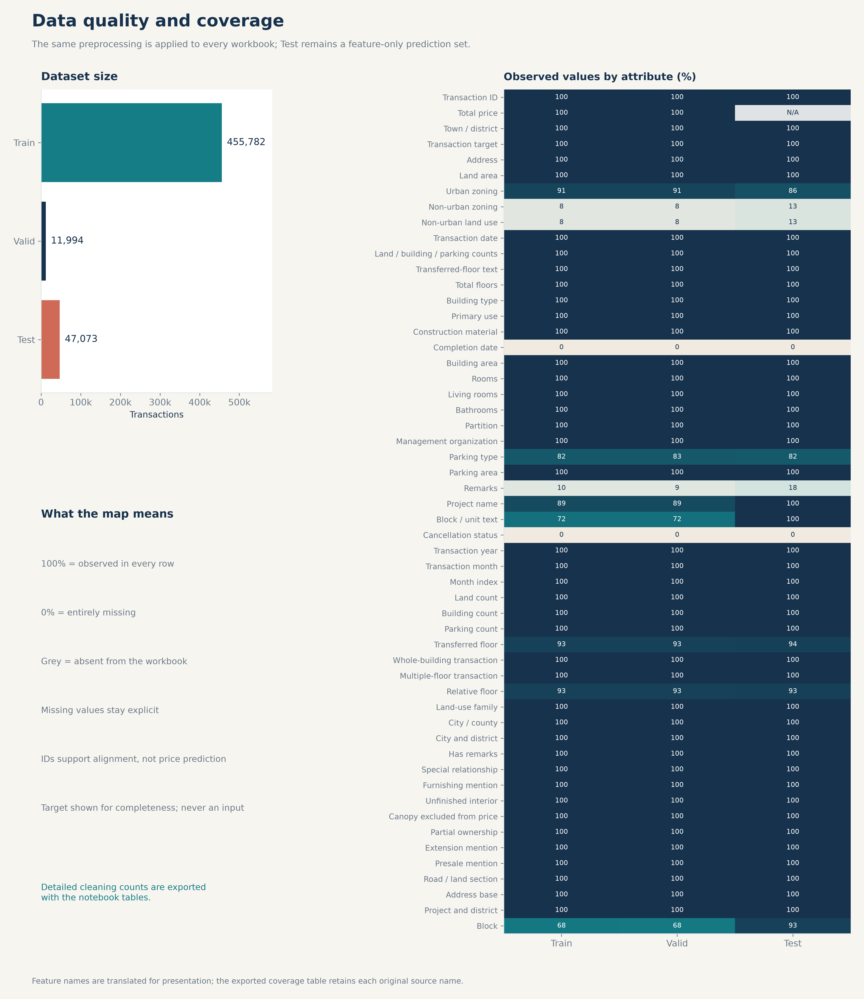

Loaded completed core artifacts; new fits: 0; new predictions: 0.


In [14]:
if REVIEW_ONLY:
    saved_review.show(19)
else:
    core_resume.enter(18)
    if core_resume.reuse:
        core_resume.view(18)
    else:
        attribute_summary, attribute_details = charts.attribute_audit(prepared["train"], features=prepared["train"].columns)
        roles = prepared["coverage"]
        schema = pd.DataFrame({"No": np.arange(1, len(prepared["train"].columns) + 1),
            "Feature": prepared["train"].columns,
            "Train_Dtype": [str(t) for t in prepared["train"].dtypes],
            "In_Valid": [c in prepared["valid"] for c in prepared["train"]],
            "In_Test": [c in prepared["test"] for c in prepared["train"]]})
        schema = schema.merge(roles, on="Feature", how="left")
        schema.to_csv(PROJECT_ROOT / "data/processed/schema.csv", index=False)
        attribute_summary.to_csv(TABLES_DIR / "attribute_summary.csv", index=False)
        attribute_details.to_csv(TABLES_DIR / "attribute_distribution_bins.csv", index=False)
        display(schema)
        charts.display_chart(charts.chart_quality_overview({k.title(): prepared[k] for k in ["train", "valid", "test"]},
            features=prepared["train"].columns, cleaning_summary=cleaning_summary, out_dir=FIGURES_DIR))


### Area, Price, and Transaction Time

我把面積、價格與交易時間放在同一張圖檢查，先辨識偏態、量級差異與不同月份的成交組成。高價或大面積交易即使筆數少，也可能對總價 MAE 造成明顯影響，因此不能只看一般住宅附近的分布。

圖形使用的分位數範圍是顯示設定，沒有據此刪除模型訓練列。月份中位價同時受到產品與地區組成影響，我把它當描述性線索，後續再以固定時間切分檢查模型，而不將這條曲線直接視為純房價指數。

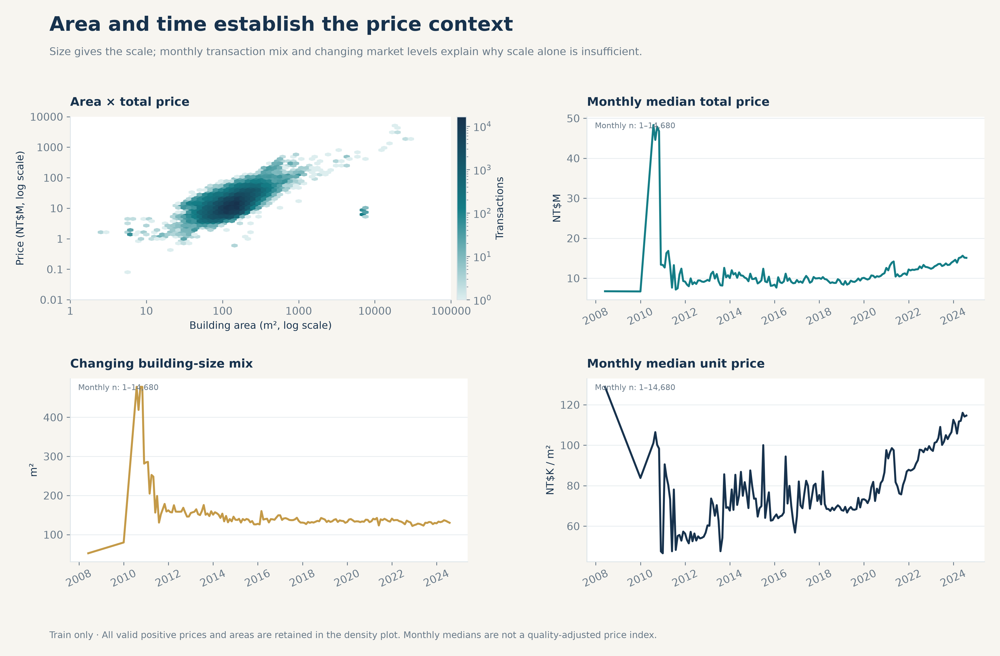

Loaded completed core artifacts; new fits: 0; new predictions: 0.


In [15]:
if REVIEW_ONLY:
    saved_review.show(21)
else:
    core_resume.enter(20)
    if core_resume.reuse:
        core_resume.view(20)
    else:
        charts.display_chart(charts.chart_area_time_context(prepared["train"], out_dir=FIGURES_DIR))


### Price Structure Across Feature Interactions

單欄位關係無法完整回答估價問題。相同面積的店面與住宅，可能對應不同單價；同一行政區內的透天與大樓，也可能具有不同土地持分與交易範圍。我因此先檢查「面積 × 型態」及「地點 × 型態」的組合，再決定後續版本要明確加入哪些交互表徵。

圖中同時呈現群組中位數與支持筆數，樣本不足的格子不給出強解讀。它提供研究假設，並不單獨證明某個屬性造成價格增加。交互特徵是否有用，仍要回到後續固定評估母體的結果。

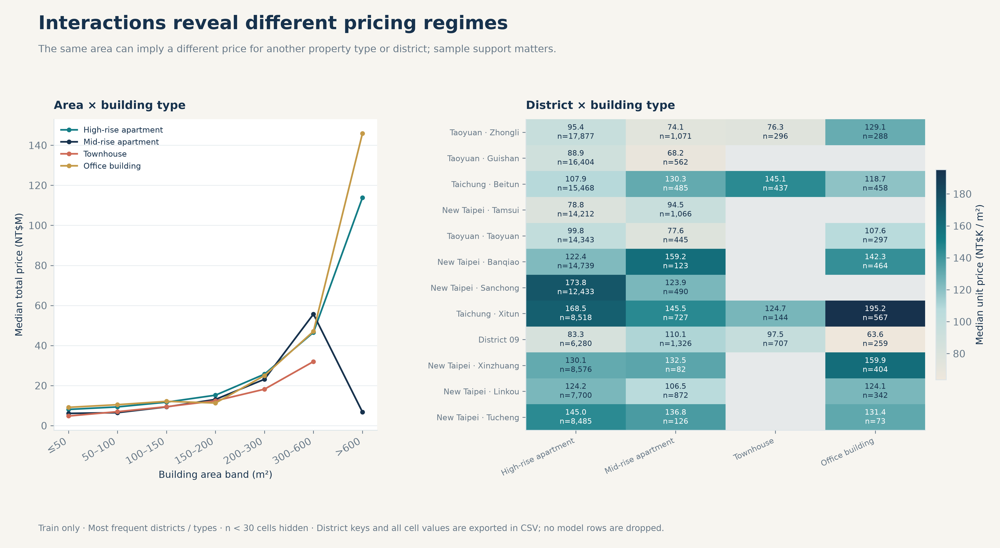

Loaded completed core artifacts; new fits: 0; new predictions: 0.


In [16]:
if REVIEW_ONLY:
    saved_review.show(23)
else:
    core_resume.enter(22)
    if core_resume.reuse:
        core_resume.view(22)
    else:
        charts.display_chart(charts.chart_interaction_atlas(prepared["train"], min_rows=30, out_dir=FIGURES_DIR))


## 05 · Chronological Evaluation Protocol

我採用時間向前的評估，因為模型在未知交易上的表現，比隨機切分後能否記住同案成交更接近研究問題。V1–V8 的核心比較使用相同評估列，避免某個版本缺參考時縮小母體而得到較好的分數。

| Cohort | Time range | Saved eligible rows | Purpose |
|---|---|---:|---|
| Fit | 至 2024-03 | 397,544 | V1–V6 訓練 |
| Dev | 2024-04 至 2024-06 | 43,016 | 模型開發比較 |
| Check | 2024-07 至 2024-08 | 15,204 | 較晚時間的回顧性檢查 |

有效月份缺失 8 列，評估中有 10 列全域重複編號被一致排除。這些時間窗在先前研究中已被檢閱，因此我將結果稱為回顧性評估，不宣稱全新盲測。

$$
\mathrm{MAE} = \frac{1}{n}\sum_{i=1}^{n}|y_i-\widehat{y}_i|,
\qquad
r_i = y_i-\widehat{y}_i.
$$

殘差為正代表低估。我同時比較 All、Ordinary、Seen／Unseen 及 Large Area。`Originally_Accurate` 是用已知標籤作事後診斷的群組，不能在 Test 推論時用真實誤差選擇誰接受修正。

V7 另外以較早訓練截止日建立校準樣本，校正僅使用 2023-09 至 2024-03 標籤；V10–V11 則另以六月選擇修正策略。各節明列其時間設定，不將不同時間窗的 MAE 混為一條排名。

In [17]:
if REVIEW_ONLY:
    saved_review.show(25)
else:
    core_resume.enter(24)
    if core_resume.reuse:
        core_resume.view(24)
    else:
        config = study.StudyConfig(cache_dir=PROJECT_ROOT / "outputs", threads=THREADS,
            fit_end_month=194, dev_end_month=197, check_end_month=199, iterations=2400,
            seed=42, permutation_rows=PERMUTATION_ROWS, permutation_repeats=PERMUTATION_REPEATS)
        split = study.split_study(prepared["train"], config)
        split["counts"].to_csv(TABLES_DIR / "fixed_split_counts.csv", index=False)
        split["excluded_evaluation_ids"].to_csv(TABLES_DIR / "excluded_evaluation_ids.csv", index=False)
        display(split["counts"])
        project.write_json(PROJECT_ROOT / "configs/evaluation_protocol.json", {
            "fit_end": "2024-03", "dev": ["2024-04", "2024-06"], "check": ["2024-07", "2024-08"],
            "evaluation": "Previously reviewed retrospective temporal split", "metric": "MAE in TWD",
            "test_labels_used": False, "provided_valid_used_for_selection": False,
            "duplicate_evaluation_id_policy": "Exclude globally ambiguous IDs consistently"})


,Set,Rows
0,Fit,397544
1,Dev,43016
2,Check,15204
3,Missing month excluded,8
4,Duplicate evaluation ID rows excluded,10
5,Missing evaluation ID rows excluded,0
6,Fit ID overlap excluded,0


Loaded completed core artifacts; new fits: 0; new predictions: 0.


## 06 · Individual Feature Predictive Information

在建立複雜模型前，我先讓每個屬性單獨預測總價，和 Train 總價中位數基準比較。數值欄位使用 Train 建立的 20 個分位數區間；類別使用類別中位數，最低支持筆數為 10，收縮強度為 50。未見類別回退全域中位數，評估列不因此消失。

這張圖回答的是「只知道這個欄位，能比全域中位數少多少 MAE」。Dev 與 Check 分開呈現，負改善照實保留；排除欄位不估計。它不是線性迴歸係數，也不是因果影響。各欄位共享資訊，改善不能相加；單獨表現弱的屬性，也可能透過與地點或用途的交互作用提供價值。

,Feature,Set,Role,Group,Rows,Baseline_MAE,Univariate_MAE,Improvement_Pct,Unseen_Pct,Train_Distinct,Status,Representation,MAE_Saved
0,編號,Dev,Excluded identifier,Outcome/Excluded,43016,"8,190,304.877",NaN,NaN,NaN,NaN,Excluded,Row alignment only,NaN
2,總價元,Dev,Outcome,Outcome/Excluded,43016,"8,190,304.877",NaN,NaN,NaN,NaN,Excluded,Training/evaluation target only,NaN
4,鄉鎮市區,Dev,Model predictor,Location,43016,"8,190,304.877","6,936,225.818",15.312,0.005,259.000,Evaluated,Supported categorical median,"1,254,079.060"
6,交易標的,Dev,Model predictor,Property,43016,"8,190,304.877","8,048,285.385",1.734,0.007,3.000,Evaluated,Supported categorical median,"142,019.493"
8,土地位置建物門牌,Dev,Derived/coarse representation,Location,43016,"8,190,304.877","6,373,844.873",22.178,20.125,"6,516.000",Evaluated,Coarse location from address,"1,816,460.005"
10,土地移轉總面積平方公尺,Dev,Model predictor,Area,43016,"8,190,304.877","8,204,704.347",-0.176,0.000,21.000,Evaluated,Numeric quantile bins,"-14,399.470"
12,都市土地使用分區,Dev,Model predictor,Property,43016,"8,190,304.877","8,039,252.956",1.844,0.000,6.000,Evaluated,Supported categorical median,"151,051.922"
14,非都市土地使用分區,Dev,Model predictor,Property,43016,"8,190,304.877","8,043,876.695",1.788,0.000,8.000,Evaluated,Supported categorical median,"146,428.182"
16,非都市土地使用編定,Dev,Model predictor,Property,43016,"8,190,304.877","8,049,097.518",1.724,0.033,8.000,Evaluated,Supported categorical median,"141,207.360"
18,交易年月日,Dev,Derived/coarse representation,Time,43016,"8,190,304.877","7,498,196.182",8.450,0.000,20.000,Evaluated,Parsed date ordinal,"692,108.695"


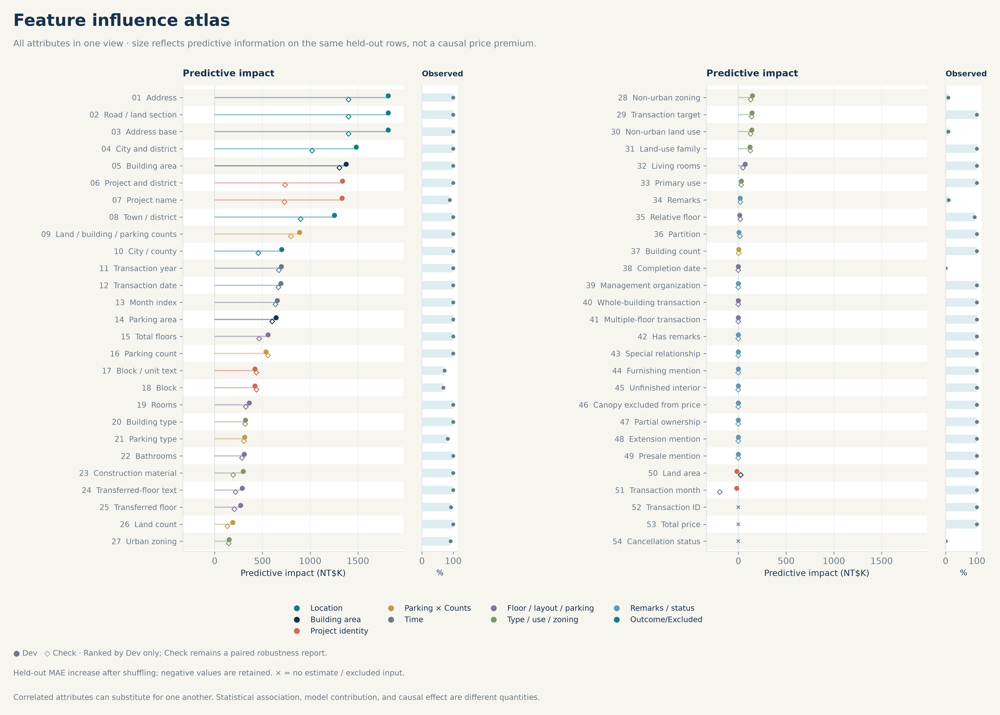

Loaded completed core artifacts; new fits: 0; new predictions: 0.


In [18]:
if REVIEW_ONLY:
    saved_review.show(27)
else:
    core_resume.enter(26)
    if core_resume.reuse:
        core_resume.view(26)
    else:
        univariate = study.univariate_attribute_scores(split["fit"], split["dev"], split["check"],
            bins=20, minimum_rows=10, smoothing=50)
        univariate["MAE_Saved"] = univariate.Baseline_MAE - univariate.Univariate_MAE
        univariate.to_csv(TABLES_DIR / "all_attribute_univariate_scores.csv", index=False)
        influence = univariate.pivot(index="Feature", columns="Set", values="MAE_Saved").rename(
            columns={"Dev": "Predictive_Gain_Dev", "Check": "Predictive_Gain_Check"}).reset_index()
        influence = influence.merge(roles[["Feature", "Group"]], on="Feature", how="left")
        display(univariate.loc[univariate.Set.eq("Dev"), ["Feature", "Role", "Group", "Univariate_MAE",
            "Improvement_Pct", "Unseen_Pct", "Status"]].sort_values("Improvement_Pct", ascending=False, na_position="last"))
        charts.display_chart(charts.chart_feature_influence_atlas(influence, coverage=attribute_summary,
            features=prepared["train"].columns, out_dir=FIGURES_DIR))


## 07 · Progressive Feature Experiments

我固定 CatBoost 的訓練規格，再逐組增加資訊，讓 V1–V6 的比較以特徵範圍為主。設定為 MAE 損失、2,400 棵樹、深度 8、學習率 0.04、L2 為 8、種子 42。總價除以一百萬只改變數值尺度，評估與輸出會轉回元，並未改成對數價格損失。

| Version | Added information | Features | Research purpose |
|---|---|---:|---|
| V1 | 面積與交易時間 | 8 | 建立規模與時間基準 |
| V2 | 地理位置 | 13 | 檢查同面積的市場差異 |
| V3 | 型態、用途、分區與建材 | 25 | 區分產品與定價機制 |
| V4 | 樓層、格局、車位與交易結構 | 49 | 補足實體配置及移轉範圍 |
| V5 | 建案與棟別 | 54 | 檢查同區位內產品定位 |
| V6 | 備註語意、管理及缺失狀態 | 74 | 檢查交易條件的額外資訊 |

每版會重新學習整組特徵及其交互作用，差異不能歸因到某一欄的固定加價。我保留失敗的版本，讓後續選擇能從數據追溯，而不預設資訊越多一定越好。

In [19]:
if REVIEW_ONLY:
    saved_review.show(29)
else:
    core_resume.enter(28)
    if core_resume.reuse:
        core_resume.view(28)
    else:
        session = StudySession(PROJECT_ROOT, raw, prepared, split, config, full_ablations=RUN_FULL_ABLATIONS)
        version_plan = pd.DataFrame([{"Version": f"submission_v{v}", "Added_Information": item["added"],
            "Reason_To_Test": item["reason"], "Feature_Count": len(study.feature_frame(split["fit"].head(2), v).columns) if v <= 6 else np.nan}
            for v, item in REGISTRY.items()])
        version_plan.to_csv(TABLES_DIR / "version_plan.csv", index=False)
        display(version_plan)


,Version,Added_Information,Reason_To_Test,Feature_Count
0,submission_v1,Area and transaction time,Establish a reproducible size-and-time baseline,8.000
1,submission_v2,"City, district, road and parcel section",The same area can have different prices in dif...,13.000
2,submission_v3,"Type, use, zoning, material and location inter...",Residential and industrial prices follow diffe...,25.000
3,submission_v4,"Floors, layout, parking, counts and explicit a...",Separate physical scale from transaction compo...,49.000
4,submission_v5,"Project, block and project-location/type inter...",Project identity can explain variation within ...,54.000
5,submission_v6,"Remarks, management, date detail and missingness",Account for transaction semantics and informat...,74.000
6,submission_v7,Fixed reference and comparison ensemble,Reproduce the complete evaluated system rather...,NaN
7,submission_v8,Published Airport resettlement unit schedule,Use an explicit public-price rule only when un...,NaN


Loaded completed core artifacts; new fits: 0; new predictions: 0.


### V1 · Area and Time Baseline

**Design rationale.** 面積與時間是最基本的交易尺度。我先只加入土地、建物與車位面積、交易年、月與時間序號，並以 sin／cos 表示月份的循環性，作為所有後續比較的共同起點。

| Saved metric | MAE (TWD) |
|---|---:|
| Dev | 4,495,688.233 |
| Check | 4,646,840.845 |

**Observation and next decision.** 這個基準仍有明顯誤差，說明只知道交易規模不足以區分不同市場。下一版加入地點，檢查價格差異是否主要來自空間位置。

In [20]:
if REVIEW_ONLY:
    saved_review.show(31)
else:
    core_resume.enter(30)
    if core_resume.reuse:
        core_resume.view(30)
    else:
        scores_v1 = session.run_stage(1)
        display(scores_v1.round(3))


,Version,Set,Segment,Rows,MAE,Median_Residual,Underprediction_Pct,Median_Baseline_MAE
0,submission_v1,Dev,All,43016,"4,495,688.233","485,659.499",56.800,"8,190,304.877"
1,submission_v1,Dev,Ordinary,42555,"4,208,295.462","479,726.850",56.759,"7,505,748.435"
2,submission_v1,Dev,Seen_Ordinary,25651,"3,731,422.867","358,675.291",55.670,"7,078,665.556"
3,submission_v1,Dev,Unseen_Ordinary,16904,"4,931,926.492","701,059.304",58.412,"8,153,825.985"
4,submission_v1,Dev,Large_Area,427,"33,389,107.973","3,761,626.034",62.998,"76,329,601.803"
5,submission_v1,Check,All,15204,"4,646,840.845","806,314.191",60.339,"7,893,586.529"
6,submission_v1,Check,Ordinary,14991,"4,291,751.395","810,980.663",60.496,"7,106,905.449"
7,submission_v1,Check,Seen_Ordinary,5855,"3,976,134.990","559,099.011",58.309,"7,121,604.456"
8,submission_v1,Check,Unseen_Ordinary,9136,"4,494,020.885","990,859.954",61.898,"7,097,485.278"
9,submission_v1,Check,Large_Area,204,"30,867,572.088","1,095,793.050",51.471,"65,628,872.549"


Loaded completed core artifacts; new fits: 0; new predictions: 0.


### V2 · Location Information

**Design rationale.** 我加入縣市、行政區、道路及較粗地段，檢驗相同規模的交易能否依市場位置區分。這不是假設某行政區固定最貴，而是讓模型學習位置與面積、時間的共同關係。

| Saved metric | MAE (TWD) |
|---|---:|
| Dev | 2,002,402.193 |
| Check | 2,456,683.887 |

**Observation and next decision.** Check 較 V1 減少 2,190,156.958 元，為前六版中最大的相鄰改善。地點具有明確預測價值，但尚不能解釋同區位不同產品，因此下一步加入型態與用途。

In [21]:
if REVIEW_ONLY:
    saved_review.show(33)
else:
    core_resume.enter(32)
    if core_resume.reuse:
        core_resume.view(32)
    else:
        scores_v2 = session.run_stage(2)
        display(scores_v2.round(3))


,Version,Set,Segment,Rows,MAE,Median_Residual,Underprediction_Pct,Median_Baseline_MAE
0,submission_v2,Dev,All,43016,"2,002,402.193","601,182.176",66.552,"8,190,304.877"
1,submission_v2,Dev,Ordinary,42555,"1,794,529.637","597,098.604",66.634,"7,505,748.435"
2,submission_v2,Dev,Seen_Ordinary,25651,"1,422,767.962","404,108.129",64.360,"7,078,665.556"
3,submission_v2,Dev,Unseen_Ordinary,16904,"2,358,659.944","1,173,644.357",70.084,"8,153,825.985"
4,submission_v2,Dev,Large_Area,427,"22,749,288.570","2,808,896.423",62.295,"76,329,601.803"
5,submission_v2,Check,All,15204,"2,456,683.887","1,096,388.765",76.164,"7,893,586.529"
6,submission_v2,Check,Ordinary,14991,"2,062,229.403","1,093,551.846",76.352,"7,106,905.449"
7,submission_v2,Check,Seen_Ordinary,5855,"1,669,493.893","804,756.304",72.536,"7,121,604.456"
8,submission_v2,Check,Unseen_Ordinary,9136,"2,313,922.312","1,315,752.040",78.798,"7,097,485.278"
9,submission_v2,Check,Large_Area,204,"31,524,645.401","2,269,438.960",63.725,"65,628,872.549"


Loaded completed core artifacts; new fits: 0; new predictions: 0.


### V3 · Property Type and Use

**Design rationale.** 我加入建物型態、主要用途、交易標的、分區與建材，並建立行政區×型態、行政區×用途及道路×型態。目的是避免把住宅、店面與工業交易當成相同定價機制。

| Saved metric | MAE (TWD) |
|---|---:|
| Dev | 1,919,365.492 |
| Check | 2,260,039.187 |

**Observation and next decision.** Check 較 V2 減少 196,644.700 元。不過 Dev 的 Unseen Ordinary 從 2,358,659.944 微增至 2,364,224.877 元，顯示整體改善不等於每個群組皆受益。下一版繼續檢查實體配置。

In [22]:
if REVIEW_ONLY:
    saved_review.show(35)
else:
    core_resume.enter(34)
    if core_resume.reuse:
        core_resume.view(34)
    else:
        scores_v3 = session.run_stage(3)
        display(scores_v3.round(3))


,Version,Set,Segment,Rows,MAE,Median_Residual,Underprediction_Pct,Median_Baseline_MAE
0,submission_v3,Dev,All,43016,"1,919,365.492","548,403.976",65.466,"8,190,304.877"
1,submission_v3,Dev,Ordinary,42555,"1,748,041.819","549,303.076",65.635,"7,505,748.435"
2,submission_v3,Dev,Seen_Ordinary,25651,"1,341,977.400","374,453.228",63.331,"7,078,665.556"
3,submission_v3,Dev,Unseen_Ordinary,16904,"2,364,224.877","1,074,974.704",69.132,"8,153,825.985"
4,submission_v3,Dev,Large_Area,427,"18,992,800.327","533,578.091",52.225,"76,329,601.803"
5,submission_v3,Check,All,15204,"2,260,039.187","1,089,086.346",75.178,"7,893,586.529"
6,submission_v3,Check,Ordinary,14991,"1,997,950.037","1,094,057.755",75.592,"7,106,905.449"
7,submission_v3,Check,Seen_Ordinary,5855,"1,576,125.188","784,047.566",72.331,"7,121,604.456"
8,submission_v3,Check,Unseen_Ordinary,9136,"2,268,285.468","1,345,652.713",77.682,"7,097,485.278"
9,submission_v3,Check,Large_Area,204,"21,589,863.473","-193,288.755",47.059,"65,628,872.549"


Loaded completed core artifacts; new fits: 0; new predictions: 0.


### V4 · Physical and Transaction Structure

**Design rationale.** 我加入樓層、格局、車位、筆棟數、屋齡及面積比，區分建物本身與交易範圍。例如土地／建物比使用明確欄位計算，避免將土地尺度和建物尺度混淆。

| Saved metric | MAE (TWD) |
|---|---:|
| Dev | 1,728,877.197 |
| Check | 2,139,550.725 |

**Observation and next decision.** Check 較 V3 減少 120,488.462 元，兩個時間窗的整體 MAE 都下降。這支持實體與交易結構具有額外資訊，之後再檢查建案是否能解釋同區位、同型態內的產品差異。

In [23]:
if REVIEW_ONLY:
    saved_review.show(37)
else:
    core_resume.enter(36)
    if core_resume.reuse:
        core_resume.view(36)
    else:
        scores_v4 = session.run_stage(4)
        display(scores_v4.round(3))


,Version,Set,Segment,Rows,MAE,Median_Residual,Underprediction_Pct,Median_Baseline_MAE
0,submission_v4,Dev,All,43016,"1,728,877.197","482,007.722",65.673,"8,190,304.877"
1,submission_v4,Dev,Ordinary,42555,"1,577,757.625","483,825.740",65.858,"7,505,748.435"
2,submission_v4,Dev,Seen_Ordinary,25651,"1,217,106.349","365,204.194",65.218,"7,078,665.556"
3,submission_v4,Dev,Unseen_Ordinary,16904,"2,125,028.442","858,797.166",66.830,"8,153,825.985"
4,submission_v4,Dev,Large_Area,427,"16,797,272.987","125,156.475",51.054,"76,329,601.803"
5,submission_v4,Check,All,15204,"2,139,550.725","1,030,005.532",75.395,"7,893,586.529"
6,submission_v4,Check,Ordinary,14991,"1,893,732.637","1,038,662.223",75.946,"7,106,905.449"
7,submission_v4,Check,Seen_Ordinary,5855,"1,472,256.563","764,543.846",73.595,"7,121,604.456"
8,submission_v4,Check,Unseen_Ordinary,9136,"2,163,844.547","1,261,281.789",77.452,"7,097,485.278"
9,submission_v4,Check,Large_Area,204,"20,244,087.440","-1,648,374.119",37.745,"65,628,872.549"


Loaded completed core artifacts; new fits: 0; new predictions: 0.


### V5 · Project and Block Context

**Design rationale.** 我加入建案、建案行政區、棟別，以及建案×型態與建案×棟別。名稱可能攜帶產品定位，但名稱前綴不必然等於真實建商，因此沒有把國泰、遠雄等文字直接視為已確認品牌身分。

| Saved metric | MAE (TWD) |
|---|---:|
| Dev | 1,699,743.365 |
| Check | 2,139,171.758 |

**Observation and next decision.** Dev 較 V4 改善 29,133.832 元，Check 卻僅改善約 379 元，幾乎持平；Check 的 Large Area 誤差反而增加。因此我不能將建案資訊描述成跨時間穩定的大幅進步。

In [24]:
if REVIEW_ONLY:
    saved_review.show(39)
else:
    core_resume.enter(38)
    if core_resume.reuse:
        core_resume.view(38)
    else:
        scores_v5 = session.run_stage(5)
        display(scores_v5.round(3))


,Version,Set,Segment,Rows,MAE,Median_Residual,Underprediction_Pct,Median_Baseline_MAE
0,submission_v5,Dev,All,43016,"1,699,743.365","435,335.105",64.534,"8,190,304.877"
1,submission_v5,Dev,Ordinary,42555,"1,547,163.258","436,124.361",64.679,"7,505,748.435"
2,submission_v5,Dev,Seen_Ordinary,25651,"1,200,203.285","359,218.422",65.803,"7,078,665.556"
3,submission_v5,Dev,Unseen_Ordinary,16904,"2,073,658.188","703,831.374",62.973,"8,153,825.985"
4,submission_v5,Dev,Large_Area,427,"16,935,626.196","413,784.729",52.927,"76,329,601.803"
5,submission_v5,Check,All,15204,"2,139,171.758","843,874.688",70.777,"7,893,586.529"
6,submission_v5,Check,Ordinary,14991,"1,848,457.842","854,532.952",71.296,"7,106,905.449"
7,submission_v5,Check,Seen_Ordinary,5855,"1,456,158.067","762,024.396",74.500,"7,121,604.456"
8,submission_v5,Check,Unseen_Ordinary,9136,"2,099,871.500","971,715.979",69.243,"7,097,485.278"
9,submission_v5,Check,Large_Area,204,"23,546,889.785","-2,611,875.711",33.333,"65,628,872.549"


Loaded completed core artifacts; new fits: 0; new predictions: 0.


### V6 · Transaction Semantics and Missingness

**Design rationale.** 我加入管理、隔間、特殊關係、裝潢、毛胚、持分、增建、地上權與共同買受等語意，以及日期細節與缺失狀態。這些條件可能改變交易內容，但我沒有對「持分」等字樣手動給定折扣。

| Saved metric | MAE (TWD) |
|---|---:|
| Dev | 1,705,786.071 |
| Check | 2,190,854.759 |

**Observation and next decision.** V6 較 V5 的 Dev 增加 6,042.706 元、Check 增加 51,683.001 元。資訊增加沒有轉化為整體改善；V6 仍保留作為完整特徵解釋模型，後續不把它寫成前六版最佳模型。

In [25]:
if REVIEW_ONLY:
    saved_review.show(41)
else:
    core_resume.enter(40)
    if core_resume.reuse:
        core_resume.view(40)
    else:
        scores_v6 = session.run_stage(6)
        display(scores_v6.round(3))


,Version,Set,Segment,Rows,MAE,Median_Residual,Underprediction_Pct,Median_Baseline_MAE
0,submission_v6,Dev,All,43016,"1,705,786.071","435,080.119",64.436,"8,190,304.877"
1,submission_v6,Dev,Ordinary,42555,"1,540,566.503","436,403.069",64.599,"7,505,748.435"
2,submission_v6,Dev,Seen_Ordinary,25651,"1,198,937.245","364,932.579",65.498,"7,078,665.556"
3,submission_v6,Dev,Unseen_Ordinary,16904,"2,058,972.330","676,082.854",63.234,"8,153,825.985"
4,submission_v6,Dev,Large_Area,427,"18,174,200.305","208,387.851",51.522,"76,329,601.803"
5,submission_v6,Check,All,15204,"2,190,854.759","871,888.494",70.679,"7,893,586.529"
6,submission_v6,Check,Ordinary,14991,"1,866,895.790","888,241.315",71.209,"7,106,905.449"
7,submission_v6,Check,Seen_Ordinary,5855,"1,443,996.977","726,337.841",73.920,"7,121,604.456"
8,submission_v6,Check,Unseen_Ordinary,9136,"2,137,919.492","1,013,392.909",69.472,"7,097,485.278"
9,submission_v6,Check,Large_Area,204,"26,068,213.155","-3,241,734.004",33.333,"65,628,872.549"


Loaded completed core artifacts; new fits: 0; new predictions: 0.


## 08 · Model Reliance and Local Contributions

單欄位分析之後，我改問：在模型已經知道其他資訊時，它還依賴哪些來源？來源區塊共同置換後，程式會重新產生確定性的交互特徵，避免只改行政區、卻保留原行政區×型態這類矛盾輸入。

本實驗固定抽樣 5,000 筆、重複三次，並保存來源區塊置換與模型原生重要度。這是有限樣本的模型依賴估計，稀有巨額交易可能沒有充分代表。SHAP 圖則解釋 V6 的局部預測貢獻，單位為新臺幣百萬元；類別採中性色，避免任意編碼被誤讀為大小。

我不把 SHAP 的局部貢獻當成因果效果，也不將 V6 的解釋直接移植到含校正、門檻及多元件的 V7。模型越複雜，越需要明確說明解釋所對應的對象。

,Feature,Group,Scope,Status,Rows,Repeats,Source_Columns,Baseline_MAE,MAE_Increase,MAE_Increase_Pct,Std,Sampling
0,Area,Area,Group,Evaluated,5000,3.000,土地移轉總面積平方公尺 | 建物移轉總面積平方公尺 | 車位移轉總面積平方公尺,"2,090,725.930","5,151,348.172",246.390,"75,016.014",Uniform fixed holdout sample; no rare-event gu...
1,Time,Time,Group,Evaluated,5000,3.000,交易年月日 | 交易年 | 交易月 | 交易時間序號,"2,090,725.930","5,671.702",0.271,"1,426.212",Uniform fixed holdout sample; no rare-event gu...
2,Location,Location,Group,Evaluated,5000,3.000,土地位置建物門牌 | 縣市 | 鄉鎮市區 | 行政區 | 道路地段 | 地址基地,"2,090,725.930","5,180,961.285",247.807,"102,963.915",Uniform fixed holdout sample; no rare-event gu...
3,Property,Property,Group,Evaluated,5000,3.000,交易標的 | 建物型態 | 主要用途 | 都市土地使用分區 | 非都市土地使用分區 | 非都...,"2,090,725.930","354,429.375",16.952,"4,563.804",Uniform fixed holdout sample; no rare-event gu...
4,Structure,Structure,Group,Evaluated,5000,3.000,移轉層次 | 總樓層數 | 移轉樓層 | 整棟交易 | 多樓層交易 | 相對樓層 | 建物現...,"2,090,725.930","695,177.177",33.251,"39,091.276",Uniform fixed holdout sample; no rare-event gu...
5,Parking_Counts,Parking_Counts,Group,Evaluated,5000,3.000,交易筆棟數 | 交易土地筆數 | 交易建物筆數 | 交易車位筆數 | 車位類別,"2,090,725.930","226,433.717",10.830,"31,851.289",Uniform fixed holdout sample; no rare-event gu...
6,Project,Project,Group,Evaluated,5000,3.000,建案名稱 | 建案行政區 | 棟及號 | 棟別,"2,090,725.930","463,434.002",22.166,"7,762.516",Uniform fixed holdout sample; no rare-event gu...
7,Remarks,Remarks,Group,Evaluated,5000,3.000,備註 | 建物現況格局-隔間 | 有無管理組織 | 有備註 | 特殊關係交易 | 含裝潢家具...,"2,090,725.930","22,326.245",1.068,"2,110.817",Uniform fixed holdout sample; no rare-event gu...
8,編號,Outcome/Excluded,Column,Excluded,5000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,鄉鎮市區,Location,Column,Evaluated,5000,3.000,鄉鎮市區,"2,090,725.930","1,804,089.623",86.290,"37,453.511",Uniform fixed holdout sample; no rare-event gu...


,Feature,Importance,Method
0,Building_Count,11.480,"PredictionValuesChange; predictive, not causal"
1,District,7.962,"PredictionValuesChange; predictive, not causal"
2,Parking_Count,6.778,"PredictionValuesChange; predictive, not causal"
3,Building_Area,6.058,"PredictionValuesChange; predictive, not causal"
4,Relative_Floor,5.819,"PredictionValuesChange; predictive, not causal"
5,Building_Per_Count,4.550,"PredictionValuesChange; predictive, not causal"
6,City,4.293,"PredictionValuesChange; predictive, not causal"
7,Month_Index,3.986,"PredictionValuesChange; predictive, not causal"
8,Total_Floors,3.595,"PredictionValuesChange; predictive, not causal"
9,Building_Net_Parking,3.409,"PredictionValuesChange; predictive, not causal"


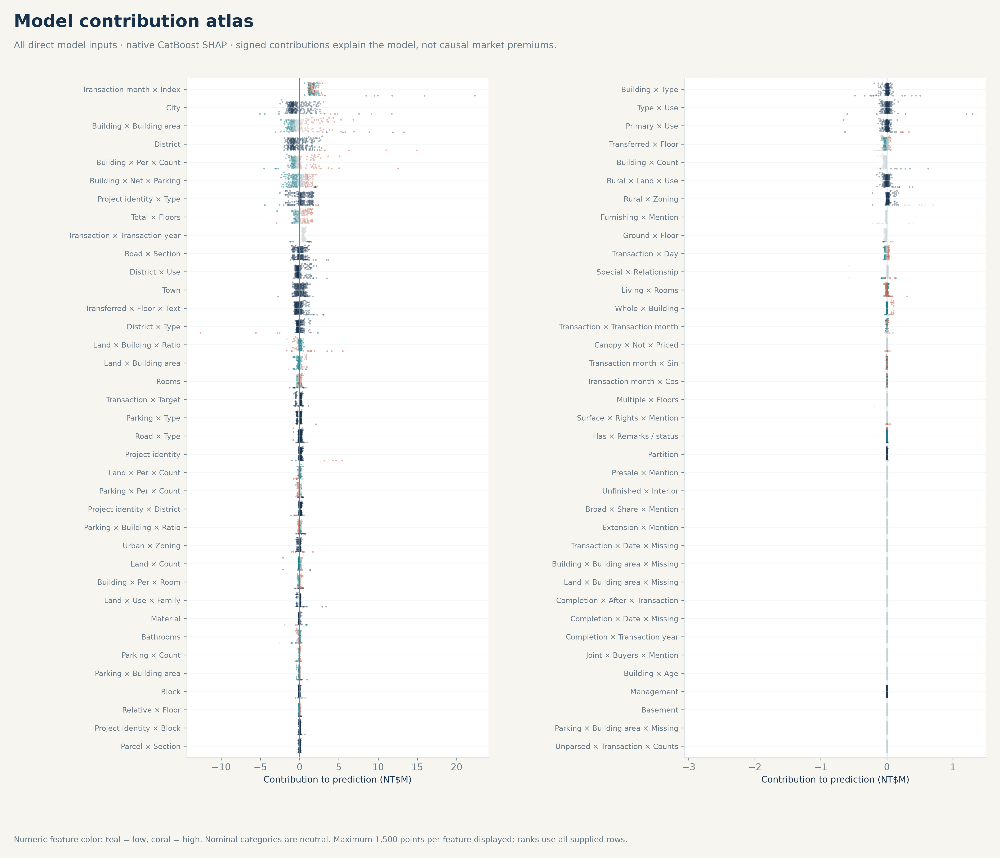

Loaded completed core artifacts; new fits: 0; new predictions: 0.


In [26]:
if REVIEW_ONLY:
    saved_review.show(43)
else:
    core_resume.enter(42)
    if core_resume.reuse:
        core_resume.view(42)
    else:
        v6_bundle = session.load_stage_bundle(6)
        permutation = study.grouped_source_permutation(v6_bundle, split["dev"], version=6,
            repeats=PERMUTATION_REPEATS, max_rows=PERMUTATION_ROWS, seed=42)
        permutation.to_csv(TABLES_DIR / "v6_source_permutation.csv", index=False)
        native_importance = study.prediction_values_change(v6_bundle)
        native_importance.to_csv(TABLES_DIR / "v6_native_importance.csv", index=False)
        display(permutation.loc[permutation.Scope.eq("Group"), ["Feature", "Rows", "Repeats", "MAE_Increase", "MAE_Increase_Pct", "Std"]]
            .sort_values("MAE_Increase", ascending=False))
        if RUN_SHAP:
            shap_table, shap_ids = study.shap_values(v6_bundle, split["dev"], max_rows=SHAP_ROWS, seed=42)
            shap_sample = split["dev"].sample(n=min(SHAP_ROWS, len(split["dev"])), random_state=42)
            shap_features = study.feature_frame(shap_sample.drop(columns=[study.TARGET]), 6)
            shap_table.to_csv(TABLES_DIR / "v6_shap_values.csv", index=False)
            shap_ids.to_csv(TABLES_DIR / "v6_shap_sample_ids.csv", index=False)
            charts.display_chart(charts.chart_shap_summary(shap_table[v6_bundle["columns"]].to_numpy(),
                shap_features, scale=1.0, out_dir=FIGURES_DIR))
            del shap_table, shap_sample, shap_features
        else:
            print("Optional SHAP chart skipped by configuration.")
        # The saved native V6 model remains available for later interpretation.
        session.stages[6]["bundle"] = None
        del v6_bundle
        gc.collect()


## 09 · V7 · Ensemble Architecture and Weight Design

前六版顯示，位置、產品與交易結構具有互補資訊，但加入所有資訊的單一總價模型沒有穩定勝出。我因此研究不同估價途徑的組合：參考分支包含結構、歷史錨點、近期總價、單價、可比交易、名稱前綴與細地點七個元件；比較分支則包含 History、Unit、Matched 的 CatBoost 與一個 LightGBM。

### Training Sample Weights

單價模型以總價除以建物面積作目標。如果每筆單價誤差同權，大交易在總價上的錯誤容易被低估。我使用面積權重，使單價的絕對損失與總價 MAE 只差固定倍率：

\[
u_i=\frac{y_i}{A_i},\qquad w_i=\frac{A_i}{\overline A},\qquad
w_i|u_i-\widehat u_i|=\frac{|y_i-A_i\widehat u_i|}{\overline A}.
\]

這個推導要求面積為有效正數。參考分支的 `anchored_total` 另採時間權重 `max(0.25, 2^(-gap/36))`，再正規化為平均 1：近期交易較重要，同時保留舊樣本的最低影響。並非所有元件都使用此時間權重。

### Prediction Mixture Weights

| Mechanism | Locked rule | Design reason |
|---|---|---|
| Reference / comparison branches | 原則上各 0.5 | 保留兩種估價途徑，分散單一路徑的偏差 |
| Missing-reference fallback | 一般交易的建案、道路、行政區參考皆缺時，用 100% reference | 避免不具支持的比較估價主導結果 |
| Large-area unit mixture | `clip(log(A/300)/log(2), 0, 1)` | 300 m² 以下為 0、600 m² 起為 1，邊界之間連續過渡 |
| Matched model | 適用一般且具名未見建案交易，權重 0.1 | 小幅引入相似案例資訊 |
| LightGBM | `0.5 × 2^(-max(h-1, 0)/6)` | 最多 0.5，隨預測間隔增加而降低影響 |

七元件分支內還有結構／錨點、近期校正的分階段混合，及適用條件下 0.25 的局部替換。這些是已鎖定規格，不能只用一個「50/50」概括全部路徑，也沒有在本次檢閱重新搜尋每個常數。

### Observed Trade-off

V7 的 Dev MAE 為 **1,827,921.078**，Check 為 **1,999,545.981**。相較 V6，Dev 惡化約 122,135 元，Check 改善約 191,309 元。這個結果支持組合在較晚時間窗可能有幫助，但不能宣稱全面勝出。V7 同時改變訓練組成、參考資訊與校正，屬於整體系統比較。

原比較分支曾在部分衍生公式對調土地與建物的區域變數；原始欄位本身未交換。本次保存已評估計算以檢查重現性，V1–V6 使用明確的正確欄位公式。這項相容性限制保留在研究紀錄，不能在更動公式後仍宣稱重現原分數。

In [27]:
if REVIEW_ONLY:
    saved_review.show(45)
else:
    core_resume.enter(44)
    if core_resume.reuse:
        core_resume.view(44)
    else:
        from legacy_pipeline import DEFAULT_RECIPE
        from try_pipeline import LOCKED_RECIPE
        component_plan = pd.DataFrame([{"Branch": "Reference", "Component": name, "Trees": spec["trees"],
            "Training_States": 2} for name, spec in DEFAULT_RECIPE["components"].items()])
        display(component_plan)
        print("Comparison branch fixed recipe:")
        display(pd.DataFrame([{"Setting": key, "Value": str(value)} for key, value in LOCKED_RECIPE.items()]))
        scores_v7 = session.run_best()
        display(scores_v7.round(3))
        print("Saved:", session.submissions[7])


,Version,Set,Segment,Rows,MAE,Median_Residual,Underprediction_Pct,Median_Baseline_MAE
0,submission_v7,Dev,All,43016,"1,827,921.078","565,731.720",65.018,"8,190,304.877"
1,submission_v7,Dev,Ordinary,42555,"1,725,062.140","571,637.712",65.259,"7,505,748.435"
2,submission_v7,Dev,Seen_Ordinary,25651,"1,537,261.794","457,679.955",63.756,"7,078,665.556"
3,submission_v7,Dev,Unseen_Ordinary,16904,"2,010,040.055","796,650.381",67.540,"8,153,825.985"
4,submission_v7,Dev,Large_Area,427,"12,125,839.589","-701,847.078",44.731,"76,329,601.803"
5,submission_v7,Check,All,15204,"1,999,545.981","857,868.466",71.817,"7,893,586.529"
6,submission_v7,Check,Ordinary,14991,"1,873,907.987","870,174.360",72.323,"7,106,905.449"
7,submission_v7,Check,Seen_Ordinary,5855,"1,586,578.594","614,496.293",68.147,"7,121,604.456"
8,submission_v7,Check,Unseen_Ordinary,9136,"2,058,049.143","1,020,283.070",75.000,"7,097,485.278"
9,submission_v7,Check,Large_Area,204,"11,285,539.086","-2,141,462.242",36.275,"65,628,872.549"


Loaded completed core artifacts; new fits: 0; new predictions: 0.


## 10 · V8 · Public Unit Pricing and Applicability

航空城安置住宅有可追溯的公開戶別定價。我將這類確定性資訊作為獨立規則，而不是要求樹模型從一般市場自行估計。但公開表必須在交易當時已可取得，且建案、戶別、樓層、扣除車位後面積、交易筆棟數及安置備註都通過檢查，才有適用依據。

面積容許差為 0.02 m²。房地價格依可解析的差額減收調整；一個車位採已鎖定區間 85–125 萬元的中點 105 萬元，這是車位估計。無法確認的列維持 V7，不以猜測戶別套用公開價格。

此版沒有新增模型訓練。保存的歷史 Dev／Check MAE 與 V7 相同，因此這個時間窗沒有證明規則改善；逐筆數值一致檢查回答的是「能否重現凍結提交檔」，也不等於新的泛化證據。公開參考檔的回報 MAE 為約 **1,918,506**，只對應該確切提交檔。

In [28]:
if REVIEW_ONLY:
    saved_review.show(47)
else:
    core_resume.enter(46)
    if core_resume.reuse:
        core_resume.view(46)
    else:
        scores_v8 = session.run_public_rule()
        display(scores_v8.round(3))
        public_audit = session.public_audit
        if len(public_audit):
            display(public_audit.groupby(["Active", "Reason"], dropna=False).size().rename("Rows").reset_index())
        display(session.parity)
        print("Saved:", session.submissions[8])
        print("Kaggle upload has not been performed.")


,Version,Set,Segment,Rows,MAE,Median_Residual,Underprediction_Pct,Median_Baseline_MAE
0,submission_v8,Dev,All,43016,"1,827,921.078","565,731.720",65.018,"8,190,304.877"
1,submission_v8,Dev,Ordinary,42555,"1,725,062.140","571,637.712",65.259,"7,505,748.435"
2,submission_v8,Dev,Seen_Ordinary,25651,"1,537,261.794","457,679.955",63.756,"7,078,665.556"
3,submission_v8,Dev,Unseen_Ordinary,16904,"2,010,040.055","796,650.381",67.540,"8,153,825.985"
4,submission_v8,Dev,Large_Area,427,"12,125,839.589","-701,847.078",44.731,"76,329,601.803"
5,submission_v8,Check,All,15204,"1,999,545.981","857,868.466",71.817,"7,893,586.529"
6,submission_v8,Check,Ordinary,14991,"1,873,907.987","870,174.360",72.323,"7,106,905.449"
7,submission_v8,Check,Seen_Ordinary,5855,"1,586,578.594","614,496.293",68.147,"7,121,604.456"
8,submission_v8,Check,Unseen_Ordinary,9136,"2,058,049.143","1,020,283.070",75.000,"7,097,485.278"
9,submission_v8,Check,Large_Area,204,"11,285,539.086","-2,141,462.242",36.275,"65,628,872.549"


,Frozen_Kaggle_MAE,Frozen_SHA256,Prediction_Parity_Passed,Maximum_Absolute_Difference,Mean_Absolute_Difference,Rows,New_Kaggle_MAE,Training_Used_Reference_Predictions,Interpretation
0,1918506,0fe22eafd43db8f78a8f8ec54696afe53d7fe7aadebb41...,True,0.000,0.000,47073,None,False,Numerically equivalent replay


Loaded completed core artifacts; new fits: 0; new predictions: 0.


## 11 · Large Commercial Transactions and Extrapolation

我特別保留大型商業交易的診斷，因為少量巨額錯誤足以影響整體 MAE。相同建案可能同時包含住宅、辦公及商場；同案成交很多，仍不代表有同用途、同規模的價格支持。

例如竹北商場的建物面積、車位數及移轉樓層範圍遠超一般住宅。建物登記一筆不代表單一住宅，多樓層商場也不等於整棟高樓。這個階段使用 Train 價格與 Test 的非價格欄位檢查外推範圍，沒有因此更動凍結預測。

我把「可以解析交易」與「有足夠資料可靠估價」分開判斷。缺少相近用途和尺度時，任意套住宅均價可能帶來更大的錯誤，後續局部修正因此需要另外的支持與誤差保護條件。

,ID,Project,Area,Parking_Count,Same_Project_Train_Rows,Same_Project_Max_Area,Same_Product_Train_Rows,Same_Product_Max_Area,Current_Model_Prediction
0,29496,台灣智匯總部,"3,675.100",31.000,70,"1,000.690",297,"4,413.070","609,433,505.585"
1,30528,豐采520,"94,344.740",830.000,426,731.340,3,90.810,"11,857,988,910.431"
2,46409,台元科技園區第十期,"27,245.780",300.000,15,"25,030.660",616,"29,759.500","2,210,769,424.368"


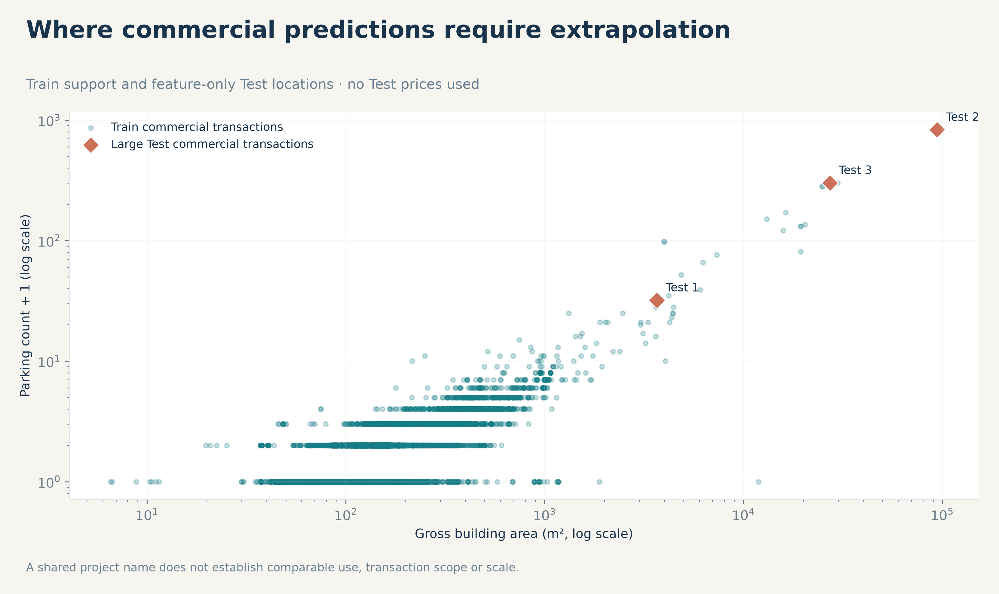

Loaded completed core artifacts; new fits: 0; new predictions: 0.


In [29]:
if REVIEW_ONLY:
    saved_review.show(49)
else:
    core_resume.enter(48)
    if core_resume.reuse:
        core_resume.view(48)
    else:
        import matplotlib.pyplot as plt
    
        commercial_pattern = r"商業|工業|廠|店|辦公"
        def commercial_mask(frame):
            use = frame["主要用途"].astype("string").fillna("")
            kind = frame["建物型態"].astype("string").fillna("")
            return (use.str.contains(commercial_pattern, regex=True) | kind.str.contains(commercial_pattern, regex=True)).to_numpy(bool)
    
        train_context = prepared["train"]
        test_context = prepared["test"]
        train_commercial = commercial_mask(train_context)
        test_commercial = commercial_mask(test_context)
        train_area = study.num(train_context[study.BUILDING])
        test_area = study.num(test_context[study.BUILDING])
        train_parking = study.num(train_context["交易車位筆數"])
        test_parking = study.num(test_context["交易車位筆數"])
        large_positions = np.flatnonzero(test_commercial & (test_area >= 3000))
        records = []
        for position in large_positions:
            row = test_context.iloc[position]
            same_project = train_context["建案行政區"].eq(row["建案行政區"]).to_numpy(bool)
            same_product = train_context["建物型態"].eq(row["建物型態"]).to_numpy(bool) & train_context["主要用途"].eq(row["主要用途"]).to_numpy(bool)
            records.append({"ID": row[study.ID], "Project": row["建案名稱"], "Area": test_area[position],
                "Parking_Count": test_parking[position], "Same_Project_Train_Rows": int(same_project.sum()),
                "Same_Project_Max_Area": float(np.nanmax(train_area[same_project])) if same_project.any() else np.nan,
                "Same_Product_Train_Rows": int(same_product.sum()),
                "Same_Product_Max_Area": float(np.nanmax(train_area[same_product])) if same_product.any() else np.nan,
                "Current_Model_Prediction": session.test_v8[position]})
        extrapolation = pd.DataFrame(records)
        extrapolation.to_csv(TABLES_DIR / "large_commercial_extrapolation.csv", index=False)
        display(extrapolation)
        charts.apply_theme()
        fig, ax = plt.subplots(figsize=(12, 6.4))
        fig.subplots_adjust(top=.82, bottom=.15, left=.1, right=.94)
        valid = train_commercial & np.isfinite(train_area) & (train_area > 0) & np.isfinite(train_parking) & (train_parking >= 0)
        ax.scatter(train_area[valid], train_parking[valid] + 1, s=13, alpha=.25, color="#147D85", label="Train commercial transactions")
        if len(large_positions):
            ax.scatter(test_area[large_positions], test_parking[large_positions] + 1, marker="D", s=90, facecolor="#CD7059",
                edgecolor="white", linewidth=.8, label="Large Test commercial transactions")
            for number, position in enumerate(large_positions, 1):
                ax.annotate(f"Test {number}", (test_area[position], test_parking[position] + 1),
                    xytext=(7, 7), textcoords="offset points", fontsize=9)
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_xlabel("Gross building area (m², log scale)")
        ax.set_ylabel("Parking count + 1 (log scale)")
        ax.grid(alpha=.2); ax.legend(loc="upper left", fontsize=9)
        fig.suptitle("Where commercial predictions require extrapolation", x=.06, ha="left", fontsize=19, fontweight="bold", color="#17344C")
        fig.text(.06, .86, "Train support and feature-only Test locations · no Test prices used", color="#6C8191", fontsize=11)
        fig.text(.06, .025, "A shared project name does not establish comparable use, transaction scope or scale.", fontsize=9, color="#6C8191")
        charts.display_chart(charts.save_chart(fig, FIGURES_DIR, "08_large_commercial_extrapolation"))
        del train_context, test_context, train_area, test_area, train_parking, test_parking, train_commercial, test_commercial
        plt.close("all")
        gc.collect()


## 12 · Feature Evidence and Version Comparison

前六版的結果並非單調改善。地點帶來最大降幅；交易結構持續提供資訊；建案在 Check 的改善很小；備註等完整資訊則使 V6 退步。我據此將特徵發展與組合模型分開解讀，而不是因為版本號較大就直接採用。

| Version | Dev MAE | Check MAE | Interpretation |
|---|---:|---:|---|
| V1 | 4,495,688.233 | 4,646,840.845 | 面積與時間基準 |
| V2 | 2,002,402.193 | 2,456,683.887 | 地點改善明顯 |
| V3 | 1,919,365.492 | 2,260,039.187 | 型態與用途增加辨識能力 |
| V4 | 1,728,877.197 | 2,139,550.725 | 實體與交易結構改善 |
| V5 | 1,699,743.365 | 2,139,171.758 | Dev 改善、Check 幾乎持平 |
| V6 | 1,705,786.071 | 2,190,854.759 | 完整資訊不一定更好 |
| V7 | 1,827,921.078 | 1,999,545.981 | 系統改變，兩時間窗結果不同 |
| V8 | 1,827,921.078 | 1,999,545.981 | 規則在本歷史窗未造成指標變動 |

附帶 Valid 的表另列，因其時間與建案重疊組成不同，不能與上表或 Kaggle public 直接當成同一評估集比較。

,Version,Set,Segment,Rows,MAE,Median_Residual,Underprediction_Pct,Median_Baseline_MAE
0,submission_v1,Dev,All,43016,"4,495,688.233","485,659.499",56.800,"8,190,304.877"
1,submission_v1,Dev,Ordinary,42555,"4,208,295.462","479,726.850",56.759,"7,505,748.435"
2,submission_v1,Dev,Seen_Ordinary,25651,"3,731,422.867","358,675.291",55.670,"7,078,665.556"
3,submission_v1,Dev,Unseen_Ordinary,16904,"4,931,926.492","701,059.304",58.412,"8,153,825.985"
4,submission_v1,Dev,Large_Area,427,"33,389,107.973","3,761,626.034",62.998,"76,329,601.803"
5,submission_v1,Check,All,15204,"4,646,840.845","806,314.191",60.339,"7,893,586.529"
6,submission_v1,Check,Ordinary,14991,"4,291,751.395","810,980.663",60.496,"7,106,905.449"
7,submission_v1,Check,Seen_Ordinary,5855,"3,976,134.990","559,099.011",58.309,"7,121,604.456"
8,submission_v1,Check,Unseen_Ordinary,9136,"4,494,020.885","990,859.954",61.898,"7,097,485.278"
9,submission_v1,Check,Large_Area,204,"30,867,572.088","1,095,793.050",51.471,"65,628,872.549"


,Version,Set,Segment,Rows,MAE,Median_Residual,Underprediction_Pct,Median_Baseline_MAE
0,submission_v1,Provided_Valid,All,11994,"3,218,417.368","-6,414.075",49.683,"6,315,062.807"
1,submission_v1,Provided_Valid,Ordinary,11826,"2,987,828.819","-4,522.745",49.763,"5,745,277.550"
2,submission_v1,Provided_Valid,Seen_Ordinary,10492,"3,066,842.703","4,612.991",50.114,"5,828,793.283"
3,submission_v1,Provided_Valid,Unseen_Ordinary,23,"2,487,138.165","-885,306.806",30.435,"5,759,565.217"
4,submission_v1,Provided_Valid,Large_Area,155,"21,014,868.677","-1,820,598.191",43.871,"49,462,909.677"
5,submission_v2,Provided_Valid,All,11994,"1,082,781.574","18,782.155",51.434,"6,315,062.807"
6,submission_v2,Provided_Valid,Ordinary,11826,"953,388.206","19,566.441",51.488,"5,745,277.550"
7,submission_v2,Provided_Valid,Seen_Ordinary,10492,"969,351.965","26,755.363",51.582,"5,828,793.283"
8,submission_v2,Provided_Valid,Unseen_Ordinary,23,"1,499,871.660","-19,262.761",47.826,"5,759,565.217"
9,submission_v2,Provided_Valid,Large_Area,155,"10,949,660.276","-268,169.607",47.742,"49,462,909.677"


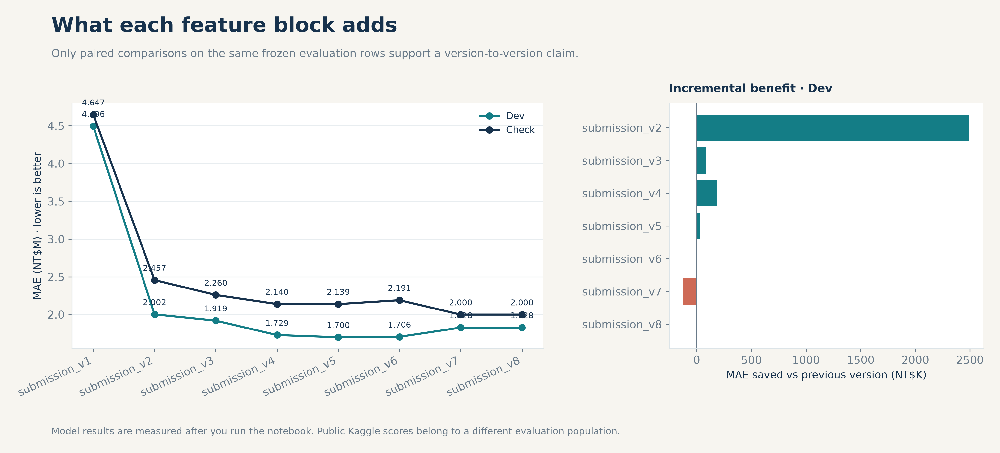

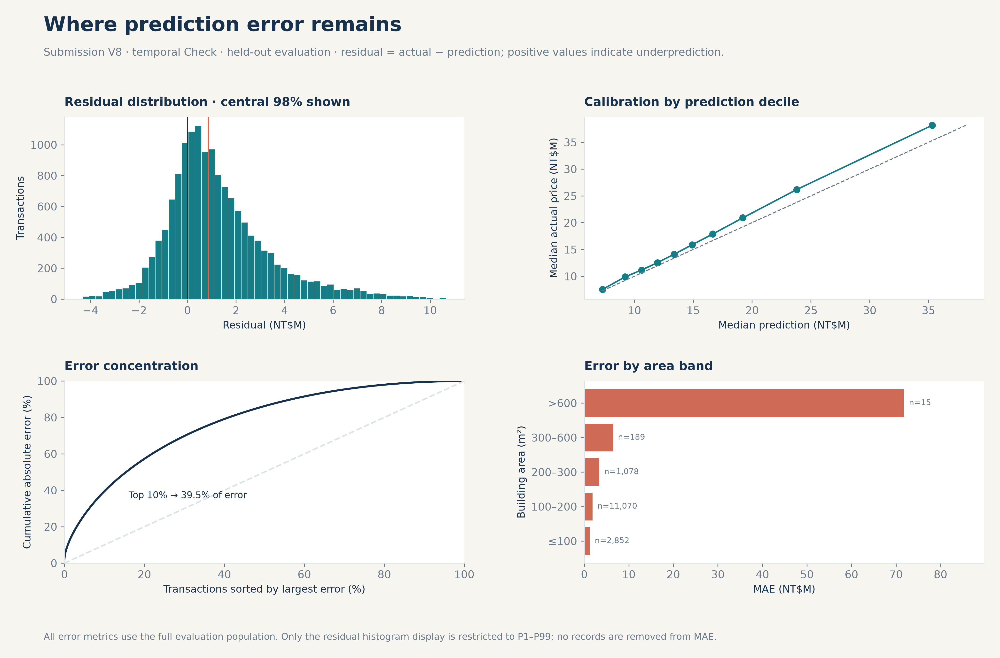

Loaded completed core artifacts; new fits: 0; new predictions: 0.


In [30]:
if REVIEW_ONLY:
    saved_review.show(51)
else:
    core_resume.enter(50)
    if core_resume.reuse:
        core_resume.view(50)
    else:
        all_scores = session.scores
        comparison = all_scores.loc[all_scores.Segment.eq("All")].pivot(index="Version", columns="Set", values="MAE")
        display(comparison)
        charts.display_chart(charts.chart_version_progress(all_scores, out_dir=FIGURES_DIR))
        check_frame = split["check"]
        charts.display_chart(charts.chart_residual_diagnostics(study.num(check_frame[study.TARGET]),
            session.predictions[(8, "Check")], meta=check_frame, out_dir=FIGURES_DIR, name="Submission V8 · temporal Check"))
        provided_valid = pd.concat(session.valid_parts, ignore_index=True)
        display(provided_valid.loc[provided_valid.Segment.eq("All"), ["Version", "Set", "Rows", "MAE"]])


### Evidence for Advancing or Rejecting a Version

我的版本決策同時考慮改善幅度、時間一致性及受影響群組。相鄰版本省下的 MAE 是同一評估列上的實測差異；若模型、訓練窗與特徵一併改動，就只能作系統比較，不能宣稱某單一屬性的效果。

V5 到 V6 的退步，促使後續改研究估價途徑互補；V7 的跨時間差異，促使後續檢查預測間隔與殘差；大型商業支持不足則限制了局部修正。保留這些未成功的假設，才能讓實驗過程與最後採用的版本連在一起。

In [31]:
if REVIEW_ONLY:
    saved_review.show(53)
else:
    core_resume.enter(52)
    if core_resume.reuse:
        core_resume.view(52)
    else:
        evidence, submission_index, review_bundle = session.finish()
        display(evidence)
        display(submission_index[["Version", "Submission", "New_Kaggle_MAE"]])
        print("Review bundle:", review_bundle)
        display(FileLink(str(review_bundle)))
        print("All configured versions completed. Aggregate figures, tables and recipes are ready.")
    core_resume.seal()


,Version,Added_Information,Comparison_Scope,Dev_MAE,Dev_MAE_Reduction,Check_MAE,Check_MAE_Reduction,Dev_Supports_Addition,Interpretation_Status
0,submission_v1,Area and transaction time,Fixed model; feature-block change,"4,495,688.233",NaN,"4,646,840.845",NaN,NaN,Pending written interpretation after execution
1,submission_v2,"City, district, road and parcel section",Fixed model; feature-block change,"2,002,402.193","2,493,286.040","2,456,683.887","2,190,156.957",True,Pending written interpretation after execution
2,submission_v3,"Type, use, zoning, material and location inter...",Fixed model; feature-block change,"1,919,365.492","83,036.701","2,260,039.187","196,644.700",True,Pending written interpretation after execution
3,submission_v4,"Floors, layout, parking, counts and explicit a...",Fixed model; feature-block change,"1,728,877.197","190,488.295","2,139,550.725","120,488.462",True,Pending written interpretation after execution
4,submission_v5,"Project, block and project-location/type inter...",Fixed model; feature-block change,"1,699,743.365","29,133.832","2,139,171.758",378.968,True,Pending written interpretation after execution
5,submission_v6,"Remarks, management, date detail and missingness",Fixed model; feature-block change,"1,705,786.071","-6,042.706","2,190,854.759","-51,683.002",False,Pending written interpretation after execution
6,submission_v7,Fixed reference and comparison ensemble,Ensemble and calibration change,"1,827,921.078","-122,135.006","1,999,545.981","191,308.778",False,Pending written interpretation after execution
7,submission_v8,Published Airport resettlement unit schedule,Published allocation rule,"1,827,921.078",0.000,"1,999,545.981",0.000,False,Pending written interpretation after execution


,Version,Submission,SHA256,New_Kaggle_MAE,Status
0,submission_v1,/home/hcl_dgx_1/Desktop/ML_HW1/ML_HW1_Price_St...,b5a641f39d5aa37860d90ae21921a68c8e0dcd295a5801...,NaN,NaN
1,submission_v2,/home/hcl_dgx_1/Desktop/ML_HW1/ML_HW1_Price_St...,3e39833a7c5c22d580ccb3a4a0161e439493901eea29ba...,NaN,NaN
2,submission_v3,/home/hcl_dgx_1/Desktop/ML_HW1/ML_HW1_Price_St...,b8f2b9c0156a6030dc9bb5ee81f18c63d40eee7b345a2d...,NaN,NaN
3,submission_v4,/home/hcl_dgx_1/Desktop/ML_HW1/ML_HW1_Price_St...,195871babb57986b3b1993af507ff8d14a25def4406a05...,NaN,NaN
4,submission_v5,/home/hcl_dgx_1/Desktop/ML_HW1/ML_HW1_Price_St...,c1565e4b4f55814ccd3fe82688c529ec223be9275e29fb...,NaN,NaN
5,submission_v6,/home/hcl_dgx_1/Desktop/ML_HW1/ML_HW1_Price_St...,a7879c595cad3419305bcb60a5a9c0154d6b6ef831eca9...,NaN,NaN
6,submission_v7,/home/hcl_dgx_1/Desktop/ML_HW1/ML_HW1_Price_St...,c22fa228675112a5ad2132fafcc13623b59313d47647de...,NaN,NaN
7,submission_v8,/home/hcl_dgx_1/Desktop/ML_HW1/ML_HW1_Price_St...,a54a3591ea6bae70ce0136ced17c1bf28a41d9908f911c...,NaN,NaN
8,submission_v9,NaN,NaN,NaN,Rejected
9,submission_v10,/home/hcl_dgx_1/Desktop/ML_HW1/ML_HW1_Price_St...,0ba83cf9d9811164032d25f5141259da3a11690438d027...,"1,901,809.000",Saved reports; model readiness audited separately


Loaded completed core artifacts; new fits: 0; new predictions: 0.


## 13 · Reproducibility and Result Preservation

本研究保留來源程式、特徵與參數指紋、必要的原生權重、精簡評估表、提交檔及整合圖。已訓練模型留在原版本路徑，避免搬動後失去恢復依據；大型中間矩陣不重複保存。Notebook 內嵌程式並不代表也內嵌已訓練權重。

圖形同時保存 PNG 與 SVG，畫面輸出留在 notebook。`presentation/study_review.zip` 是圖表、摘要與設定的檢閱包，不包含原始資料或完整模型。報表可閱讀、原生模型可載入、整套流程可重現，是三種不同程度的完成狀態，本文不混為一談。

預設只讀檢閱不會以缺失快取為理由重新訓練。重新開發或重現需要明確切換模式；這次文件整理不更新模型、特徵、樣本權重或提交價格。

In [32]:
if REVIEW_ONLY:
    saved_review.show(55)
else:
    readme = "\n".join([
        "# Taiwan Property Price Regression", "",
        "Author: Tzu-Wei Lo | Student ID: 315112015", "",
        "Main notebook: ML#1_regression_315112015.ipynb", "",
        "The notebook records feature experiments, ensemble weights and controlled corrections.",
        "REVIEW_ONLY=True reads completed reports without fitting, inference or Excel parsing.",
        "Missing core artifacts stop review instead of starting training.",
        "Research computation requires REVIEW_ONLY=False and the original data/configuration.",
        "Optional recovery experiments remain disabled by default.",
        "V1-V14 model evidence and V15 external Test-aligned outcomes have different information scopes.",
        "V15 is archived and excluded from independent prediction comparisons.",
        "AI assistance contributed to implementation drafting and editorial work.",
        "Native models remain in their original paths; code embedding does not include trained weights.",
        "Figures and tables retain their original measured values.",
    ])
    (PROJECT_ROOT / "README.md").write_text(readme, encoding="utf-8")
    print("Research documentation saved. No model fitted or prediction changed.")


Presentation-ready study completed. Save this executed notebook to preserve its visible charts.


## 14 · Continuation Protocol and Version Status

後續實驗從已保存的 V8／V11 證據延伸，不依序重跑所有舊模型。預設 `EXTENSION_MODE="review"`，僅讀取報表；`replay` 才載入權重重新推論，且仍不允許訓練。缺失的原生權重另由恢復實驗處理，不讓報表檢閱意外啟動恢復。

| Version | Saved status | Model fitting in default review |
|---|---|---:|
| V9 | 未通過採用條件，無提交檔 | 0 |
| V10 | 已保存量化殘差修正結果 | 0 |
| V11 | 沿用 V10 模型的邊界策略 | 0 |
| V12 | 恢復功能，本次執行未啟用 | 0 |
| V13 | 候選結果較 V11 差，未採用 | 0 |
| V14 | 指定範圍 947 列，改動 0 列 | 0 |
| V15 | 使用 Test 對應成交價格的歷史紀錄 | 0 |

版本輸出使用 `outputs/submission_vN/`。沒有提交檔不等於缺交一個版本，例如 V9 的拒絕本身就是實驗結果。

In [33]:
if REVIEW_ONLY:
    saved_review.show(57)
else:
    from pathlib import Path
    import gc
    import os
    import sys
    
    EXTENSION_MODE = "review"  # review | replay; recovery is in Section 20
    THREADS = int(globals().get("THREADS", 8))
    if REVIEW_ONLY and EXTENSION_MODE != "review":
        raise RuntimeError("Review-only mode prohibits model replay.")
    if EXTENSION_MODE not in {"review", "replay"}:
        raise ValueError("Choose review or replay; use Section 20 for one-model recovery")
    
    if "PROJECT_ROOT" not in globals():
        root_candidates = [
            Path.cwd(), Path.cwd() / "ML_HW1_Price_Study",
            Path.home() / "Desktop/ML_HW1/ML_HW1_Price_Study",
            Path.home() / "Desktop/ML_HW1_Price_Study",
        ]
        found_roots = [p for p in root_candidates if (p / "outputs/submission_v8").is_dir()]
        if not found_roots:
            raise FileNotFoundError("Set PROJECT_ROOT to the completed ML_HW1_Price_Study folder")
        PROJECT_ROOT = found_roots[0]
    PROJECT_ROOT = Path(PROJECT_ROOT).expanduser().resolve()
    EXTENSION_SRC_DIR = PROJECT_ROOT / "src"
    if not EXTENSION_SRC_DIR.is_dir():
        raise FileNotFoundError(f"Completed project source directory required: {EXTENSION_SRC_DIR}")
    for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
        os.environ[variable] = str(THREADS)
    if str(EXTENSION_SRC_DIR) not in sys.path:
        sys.path.insert(0, str(EXTENSION_SRC_DIR))
    extension_results = {}
    print({"Project_Root": str(PROJECT_ROOT), "Extension_Mode": EXTENSION_MODE,
           "Training_Allowed": False,
           "Test_Answers_Read": False})


{'Project_Root': '/home/hcl_dgx_1/Desktop/ML_HW1/ML_HW1_Price_Study', 'Extension_Mode': 'review', 'Training_Allowed': False, 'Test_Answers_Read': False}


### Frozen Implementations and Cache Identity

下方程式保留 V9–V11 的來源及推論公式，供方法追溯。來源程式與舊模型識別綁定，改寫變數名稱或公式也可能使原快取不再相容，因此這次編輯以說明、呈現及只讀入口為主，不改動已評估模型的內部實作。

只讀模式整理報表及正式版本路徑，不表示缺失權重已恢復。後續的恢復狀態與版本採用狀態各自記錄，避免把「表格存在」誤寫成「模型已重新驗證」。

In [34]:
if REVIEW_ONLY:
    saved_review.show(59)
else:
    """Notebook appendix orchestration; default review never fits or infers."""
    from contextlib import nullcontext
    from pathlib import Path
    import hashlib
    import importlib
    import json
    import shutil
    import warnings
    
    import numpy as np
    import pandas as pd
    from IPython.display import Image, display
    
    
    EXTENSION_RUNS = {
        9: {"cache": "outputs/v9_candidate/8035a1534b15c232", "submission": None,
            "sha256": None, "kaggle_mae": None},
        10: {"cache": "outputs/submission_v10_onefit/3f7648cfe909a7a1",
             "submission": "submission_v10_candidate.csv",
             "sha256": "0ba83cf9d9811164032d25f5141259da3a11690438d0276854bf789290685226",
             "kaggle_mae": 1_901_809},
        11: {"cache": "outputs/submission_v10_onefit/3f7648cfe909a7a1/adaptive_export/358c6911de6f",
             "submission": "submission_v10_adaptive.csv",
             "sha256": "2d47eae33420160cc333039be437115ce79c20ec584f4f951849aca701b517be",
             "kaggle_mae": 1_901_325},
    }
    
    
    def extension_hash(path):
        with Path(path).open("rb") as stream:
            return hashlib.file_digest(stream, "sha256").hexdigest()
    
    
    def extension_json(path, value):
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        temporary = path.with_name(path.name + ".tmp")
        temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
        temporary.replace(path)
    
    
    def extension_write_module(name, text, source_directory):
        """Keep the exact fitted-source bytes; refuse a conflicting local edit."""
        path = Path(source_directory) / name
        code = text.encode("utf-8")
        compile(text, str(path), "exec")
        if path.exists() and path.read_bytes() != code:
            raise RuntimeError(f"Different existing source preserved: {path}. Resolve its cache provenance before replacing it.")
        if not path.exists():
            path.write_bytes(code)
        print(f"Embedded module ready: {path.name}")
    
    
    def extension_update_index(root, record):
        path = Path(root) / "presentation/tables/submission_index.csv"
        columns = ["Version", "Submission", "SHA256", "New_Kaggle_MAE", "Status"]
        table = pd.read_csv(path, dtype={"Version": "string", "SHA256": "string"}) if path.is_file() else pd.DataFrame(columns=columns)
        previous = table.loc[table.Version.eq(record["Version"])]
        if len(previous) > 1:
            raise ValueError("Duplicate version in the existing submission index")
        if len(previous) and record.get("SHA256") and pd.notna(previous.iloc[0].get("SHA256")):
            if str(previous.iloc[0]["SHA256"]) != record["SHA256"]:
                raise ValueError("Different submission already occupies this version; index was preserved")
        fields = list(dict.fromkeys(list(table.columns) + list(record)))
        records = table.loc[~table.Version.eq(record["Version"])].to_dict("records")
        table = pd.DataFrame.from_records(records + [record], columns=fields)
        order = table.Version.str.extract(r"v(\d+)$", expand=False).astype(int)
        table = table.iloc[np.argsort(order.to_numpy())].reset_index(drop=True)
        path.parent.mkdir(parents=True, exist_ok=True)
        temporary = path.with_suffix(".tmp.csv")
        table.to_csv(temporary, index=False)
        temporary.replace(path)
        return table
    
    
    def extension_collect(root, version, source_directory=None):
        """Publish copies of completed outputs; never construct new predictions."""
        root = Path(root).expanduser().resolve()
        spec = EXTENSION_RUNS[version]
        source = Path(source_directory) if source_directory is not None else root / spec["cache"]
        destination = root / "outputs" / f"submission_v{version}"
        canonical = destination / "tables"
        source_record = canonical / "publication.json"
        # Canonical reports may survive even when the native cache is absent.
        if source_directory is None and (canonical / "decision.json").is_file():
            decision = json.loads((canonical / "decision.json").read_text(encoding="utf-8"))
            export_file = canonical / "export.json"
            exported = json.loads(export_file.read_text(encoding="utf-8")) if export_file.is_file() else {}
            prediction = destination / f"submission_v{version}.csv"
            available_csv = prediction.is_file()
            digest_value = extension_hash(prediction) if available_csv else None
            if available_csv and exported.get("SHA256") and digest_value != exported["SHA256"]:
                raise ValueError("Canonical submission differs from the completed export")
            if exported.get("Exported") and not available_csv:
                raise FileNotFoundError(f"Published submission is missing: {prediction}")
            record = {"Version": f"submission_v{version}", "Submission": str(prediction) if available_csv else "",
                "SHA256": digest_value, "New_Kaggle_MAE": spec["kaggle_mae"] if digest_value and digest_value == spec["sha256"] else None,
                "Status": "Saved reports; model readiness audited separately" if available_csv else "Rejected"}
            extension_update_index(root, record)
            return {"version": version, "available": True, "directory": destination,
                    "decision": decision, "export": exported, "record": record}
        if not source.is_dir() and source_record.is_file():
            source = Path(json.loads(source_record.read_text(encoding="utf-8"))["Original_Run_Folder"])
        if not source.is_dir() or not (source / "decision.json").is_file():
            print(f"V{version}: completed outputs not found. Review mode did not train or infer.")
            return {"version": version, "available": False, "directory": destination}
    
        decision_path = source / "decision.json"
        decision = json.loads(decision_path.read_text(encoding="utf-8")) if decision_path.is_file() else {}
        export_path = source / "export.json"
        exported = json.loads(export_path.read_text(encoding="utf-8")) if export_path.is_file() else {}
        copies, prediction, digest = [], None, None
        if exported.get("Exported"):
            if version == 9:
                prediction = Path(exported["Submission"])
            else:
                prediction = source / spec["submission"]
            if not prediction.is_file():
                raise FileNotFoundError(f"Export record exists but the submission is missing: {prediction}")
            digest = extension_hash(prediction)
            if exported.get("SHA256") and digest != exported["SHA256"]:
                raise ValueError("CSV hash differs from the original export record")
            table = pd.read_csv(prediction, dtype={"編號": "string"})
            if list(table) != ["編號", "總價元"] or len(table) != 47073:
                raise ValueError("Unexpected submission schema or row count")
            values = pd.to_numeric(table["總價元"], errors="raise").to_numpy(float)
            if table["編號"].isna().any() or not table["編號"].is_unique or not np.isfinite(values).all() or (values < 0).any():
                raise ValueError("Invalid saved submission")
            copies.append((prediction, destination / f"submission_v{version}.csv"))
        for item in sorted(source.iterdir()):
            if not item.is_file() or item.name.startswith("submission_"):
                continue
            if item.suffix in {".json", ".csv"} and item.name != "fit_budget.json":
                copies.append((item, canonical / item.name))
            elif item.suffix in {".png", ".svg"}:
                copies.append((item, destination / "figures" / item.name))
        archive_name = {9: "v9_review.zip", 10: "v10_review.zip", 11: "adaptive_review.zip"}[version]
        if (source / archive_name).is_file():
            copies.append((source / archive_name, destination / f"review_v{version}.zip"))
        # Check collisions before writing a new output. Native model caches never move.
        for old, new in copies:
            if new.exists() and extension_hash(old) != extension_hash(new):
                raise FileExistsError(f"Different existing output preserved: {new}")
        for part in ("models", "predictions", "tables", "figures"):
            (destination / part).mkdir(parents=True, exist_ok=True)
        for old, new in copies:
            if not new.exists():
                temporary = new.with_name(new.name + ".tmp")
                shutil.copyfile(old, temporary)
                if extension_hash(temporary) != extension_hash(old):
                    temporary.unlink(missing_ok=True)
                    raise IOError("Copy verification failed")
                temporary.replace(new)
        native_cache = source if version != 11 else source.parent.parent
        extension_json(destination / "models/cache_location.json", {
            "Original_Model_Cache": str(native_cache), "Cache_Moved": False,
            "Model_Source_Bytes_Changed": False})
        public_score = spec["kaggle_mae"] if digest and digest == spec["sha256"] else None
        status = "Exported" if prediction else ("Rejected" if decision.get("Accepted") is False else "No submission")
        record = {"Version": f"submission_v{version}",
            "Submission": str(destination / f"submission_v{version}.csv") if prediction else "",
            "SHA256": digest, "New_Kaggle_MAE": public_score, "Status": status}
        extension_update_index(root, record)
        extension_json(canonical / "publication.json", {**record, "Original_Run_Folder": str(source),
            "Score_Source": "User-reported public leaderboard, linked by exact CSV hash",
            "Copy_Only": True, "New_Training": 0, "New_Inference": 0})
        return {"version": version, "available": True, "directory": destination,
                "decision": decision, "export": exported, "record": record}
    
    
    def extension_display(result):
        if not result["available"]:
            return
        version, folder = result["version"], result["directory"]
        names = {9: ("dev_weight_selection.csv", "paired_scores.csv"),
                 10: ("june_selection.csv", "historical_scores.csv", "quantile_diagnostics.csv"),
                 11: ("june_selection.csv", "validation.csv", "test_changes.csv")}[version]
        for name in names:
            path = folder / "tables" / name
            if path.is_file() and path.stat().st_size > 1:
                print(f"V{version} | {name}")
                try:
                    display(pd.read_csv(path).round(3))
                except pd.errors.EmptyDataError:
                    print("No rows were exported for this report.")
        print(json.dumps(result["decision"], ensure_ascii=False, indent=2, default=str))
        for name in ("validation_overview.png",):
            image = folder / "figures" / name
            if image.is_file():
                display(Image(filename=str(image)))
        if result["record"]["Submission"]:
            print("Submission:", result["record"]["Submission"])
        else:
            print(f"V{version}: no submission. The rejection remains part of the evidence.")
    
    
    def extension_guard(mode):
        if mode == "reproduce":
            raise RuntimeError("Use the explicit one-model recovery in Section 20")
        from v10_base import forbid_ml_fit
        return forbid_ml_fit()
    
    
    def extension_run_v9(root, threads, mode):
        if mode == "review":
            return extension_collect(root, 9)
        from v9_candidate import V9Config, V9Experiment
        experiment_v9 = V9Experiment(root, V9Config(threads=threads))
        with extension_guard(mode):
            experiment_v9.prepare()
            result = experiment_v9.run_validation()
            figure = experiment_v9.plot_validation()
            import matplotlib.pyplot as plt
            plt.close(figure)
            exported = experiment_v9.export_if_accepted()
            experiment_v9.export_review()
        return extension_collect(root, 9, experiment_v9.folder)
    
    
    def extension_run_v10(root, threads, mode):
        if mode == "review":
            return extension_collect(root, 10)
        from v10_candidate import V10Config, V10Experiment
        experiment_v10 = V10Experiment(root, V10Config(threads=threads))
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="DataFrame is highly fragmented.*", category=pd.errors.PerformanceWarning)
            with extension_guard(mode):
                experiment_v10.prepare()
                experiment_v10.train_once()
                experiment_v10.validate()
                figure = experiment_v10.plot()
                import matplotlib.pyplot as plt
                plt.close(figure)
                experiment_v10.export()
                experiment_v10.review()
        return extension_collect(root, 10, experiment_v10.folder)
    
    
    def extension_run_v11(root, threads, mode):
        if mode == "review":
            return extension_collect(root, 11)
        # This helper contains its own hard fit guard, including reproduce mode.
        from v11_export import run_adaptive_export
        exported = run_adaptive_export(root, threads)
        if not exported.get("Exported"):
            print("No changed V11 submission was exported.")
            return {"version": 11, "available": False, "directory": Path(root) / "outputs/submission_v11"}
        return extension_collect(root, 11, Path(exported["Submission"]).parent)
    
    
    def extension_progress_chart(public_scores, validation):
        """One presentation figure; public and retrospective metrics stay separate."""
        import matplotlib.pyplot as plt
        from matplotlib.ticker import FuncFormatter
        with plt.rc_context({"font.family": "DejaVu Sans", "axes.spines.top": False,
                             "axes.spines.right": False, "font.size": 10}):
            fig, axes = plt.subplots(1, 3, figsize=(16.5, 6.0), facecolor="#f4f7fa")
            fig.subplots_adjust(left=.065, right=.98, top=.76, bottom=.20, wspace=.35)
            fig.text(.055, .925, "AFTER V8 | What the completed runs actually changed", fontsize=21,
                     fontweight="bold", color="#16344c")
            fig.text(.055, .86, "Public leaderboard results and retrospective checks are different evidence.",
                     fontsize=12, color="#617787")
            palette = {"V10": "#147d85", "V11": "#c87156"}
            for ax in axes:
                ax.set_facecolor("white")
                ax.tick_params(colors="#42576a")
            if len(public_scores):
                valid = public_scores.loc[public_scores.New_Kaggle_MAE.notna()].copy()
                order = valid.Version.str.extract(r"v(\d+)$", expand=False).astype(int)
                valid = valid.iloc[np.argsort(order)].copy()
                labels = valid.Version.str.replace("submission_", "", regex=False).str.upper()
                axes[0].plot(range(len(valid)), valid.New_Kaggle_MAE / 1e6, "o-", color="#147d85", lw=2.5, ms=8)
                axes[0].set_xticks(range(len(valid)), labels)
                for i, value in enumerate(valid.New_Kaggle_MAE):
                    axes[0].annotate(f"{value:,.0f}", (i, value / 1e6), xytext=(0, 14), textcoords="offset points", ha="center", fontsize=10)
                axes[0].margins(x=.16, y=.40)
                axes[0].yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:.3f}"))
            axes[0].set(title="A  |  Public MAE", ylabel="Million TWD · lower is better")
            axes[0].grid(axis="y", alpha=.15)
            if validation is not None and len(validation):
                definitions = [("Current_V10", "V10"), ("Adaptive_Candidate", "V11")]
                periods = ["June", "July_August"]
                for j, (segment, label) in enumerate(definitions):
                    group = validation.loc[validation.Segment.eq(segment)].set_index("Set").reindex(periods)
                    offset = (j - .5) * .30
                    y = np.arange(2) + offset
                    values = group.Candidate_MAE.to_numpy(float) / 1e6
                    axes[1].barh(y, values, .27, color=palette[label], label=label)
                    for yi, value in zip(y, values):
                        axes[1].text(value + .025, yi, f"{value:.3f}", va="center", fontsize=10)
                    axes[2].bar(np.arange(2) + offset, group.Accurate_Increase_Pct.to_numpy(float),
                                .27, color=palette[label], label=label)
                axes[1].set_yticks(np.arange(2), ["June selection", "July–August check"])
                axes[1].set_xlim(0, max(validation.Candidate_MAE) / 1e6 * 1.20)
                axes[1].invert_yaxis()
                axes[2].set_xticks(np.arange(2), ["June", "July–August"])
                axes[2].axhline(0, color="#687b8c", lw=.9)
                handles, labels = axes[1].get_legend_handles_labels()
                fig.legend(handles, labels, frameon=False, ncol=2, loc="upper right", bbox_to_anchor=(.985, .865))
                axes[2].grid(axis="y", alpha=.15)
            else:
                for ax in axes[1:]:
                    ax.text(.5, .5, "Saved V11 validation not available", ha="center", va="center", transform=ax.transAxes)
            axes[1].set(title="B  |  Same historical transactions", xlabel="MAE / million TWD")
            axes[2].set(title="C  |  Previously accurate transactions", ylabel="MAE change vs V8 (%) · lower is better")
            fig.text(.055, .075, "V9 was rejected and has no submitted score. Recorded public scores come from the user, linked to exact submission hashes.",
                     color="#617787", fontsize=10)
            fig.text(.055, .035, "Historical improvements do not establish an equal leaderboard gain. No Test answers are required by this figure.",
                     color="#617787", fontsize=10)
            return fig
    
    
    def extension_finish(root, show_chart=True):
        root = Path(root)
        path = root / "presentation/tables/submission_index.csv"
        if not path.is_file():
            print("No saved submission index is available yet.")
            return None
        index = pd.read_csv(path)
        mask = index.Version.eq("submission_v8") & index.SHA256.eq(
            "0fe22eafd43db8f78a8f8ec54696afe53d7fe7aadebb41a4f67d24f626a5cebb")
        index.loc[mask, "New_Kaggle_MAE"] = 1_918_506.4193
        index.to_csv(path, index=False)
        display(index)
        validation_path = root / "outputs/submission_v11/tables/validation.csv"
        validation = pd.read_csv(validation_path) if validation_path.is_file() else None
        if show_chart:
            public = index.loc[index.Version.isin(["submission_v8", "submission_v10", "submission_v11"])].copy()
            figure = extension_progress_chart(public, validation)
            directory = root / "presentation/figures"
            directory.mkdir(parents=True, exist_ok=True)
            for suffix in ("png", "svg"):
                figure.savefig(directory / f"12_submission_extensions.{suffix}", dpi=300, bbox_inches="tight")
            display(figure)
            import matplotlib.pyplot as plt
            plt.close(figure)
        return index


In [35]:
if REVIEW_ONLY:
    saved_review.show(60)
else:
    # Materialize v9_reference.py
    extension_module_source = r'''"""Strictly earlier-month, dictionary-serializable references for V9.

This module performs reference aggregation only.  It contains no ML models,
file reads, Test labels, or correction fitting.  Monthly medians are averaged
with the number of eligible original rows in each month as weights; this is
not the pooled transaction median.
"""
from __future__ import annotations

import json
from collections.abc import Mapping

import numpy as np
import pandas as pd


MONTH = "交易時間序號"
TARGET = "總價元"


def _numbers(values, length=None):
    if np.isscalar(values) or values is None:
        if length is None:
            raise ValueError("A length is required for scalar values")
        return np.full(length, np.nan if values is None else float(values), dtype=float)
    result = pd.to_numeric(pd.Series(list(values)), errors="coerce").to_numpy(
        dtype=float, na_value=np.nan, copy=True)
    if length is not None and len(result) != length:
        raise ValueError("Reference input lengths differ")
    return result


def _months(values, length=None):
    result = _numbers(values, length)
    finite = np.isfinite(result)
    if np.any(result[finite] != np.floor(result[finite])):
        raise ValueError("Month indices must be integer-valued")
    return result


def _key(value):
    if isinstance(value, (tuple, list)):
        parts = [_key(part) for part in value]
        return None if any(part is None for part in parts) else "tuple:" + json.dumps(parts, ensure_ascii=False)
    if value is None or bool(pd.isna(value)):
        return None
    result = str(value)
    return result if result else None


def _keys(values, length=None):
    result = [_key(value) for value in values]
    if length is not None and len(result) != length:
        raise ValueError("Reference key lengths differ")
    return result


def _empty(length):
    return {"value": np.full(length, np.nan), "count": np.zeros(length, dtype=np.int64),
            "age": np.full(length, np.nan), "last_month": np.full(length, np.nan)}


def _effective_cutoff(query_month, max_fit_month, delay=None, cutoff=None):
    month = _months(query_month)
    lag = _numbers(1.0 if delay is None else delay, len(month))
    if np.any(np.isfinite(lag) & ((lag < 1) | (lag != np.floor(lag)))):
        raise ValueError("Forecast delays must be integer months >= 1")
    result = month - lag
    if cutoff is not None:
        result = np.minimum(result, _months(cutoff, len(month)))
    if max_fit_month is None or not np.isfinite(max_fit_month):
        result[:] = np.nan
    else:
        result = np.minimum(result, float(max_fit_month))
    return month, result


class TemporalHistory:
    """Monthly median references with O(log months) interval queries per key.

    ``fit(frame, values, levels)`` accepts an insertion-ordered mapping of
    level names to positional key sequences. ``query`` accepts the same level
    names with new positional keys, cutoff months, a trailing window length,
    and optionally the actual query months used to calculate reference age.
    Only source months <= cutoff and >= cutoff-window+1 are used.
    """

    def __init__(self, month_column=MONTH):
        self.month_column = month_column
        self.max_fit_month = None
        self.level_names = []
        self.levels = {}

    @staticmethod
    def _group(months, medians, counts):
        months = np.asarray(months, dtype=np.int64)
        medians = np.asarray(medians, dtype=float)
        counts = np.asarray(counts, dtype=np.int64)
        if (len(months) != len(medians) or len(months) != len(counts)
                or np.any(np.diff(months) <= 0) or np.any(counts <= 0)
                or not np.isfinite(medians).all()):
            raise ValueError("Invalid serialized monthly reference group")
        return {"months": months, "medians": medians, "counts": counts,
                "sum_value": np.r_[0.0, np.cumsum(medians * counts, dtype=float)],
                "sum_count": np.r_[np.int64(0), np.cumsum(counts, dtype=np.int64)]}

    def fit(self, frame, values, levels):
        if not isinstance(levels, Mapping) or not levels:
            raise ValueError("An ordered nonempty level-to-keys mapping is required")
        n = len(frame)
        months = _months(frame[self.month_column], n)
        numeric = _numbers(values, n)
        finite_month = np.isfinite(months)
        self.max_fit_month = float(months[finite_month].max()) if finite_month.any() else None
        self.level_names = list(levels)
        self.levels = {}
        valid_value = finite_month & np.isfinite(numeric)
        for name, values_for_keys in levels.items():
            keys = _keys(values_for_keys, n)
            eligible = valid_value & np.fromiter((key is not None for key in keys), bool, count=n)
            data = pd.DataFrame({"key": pd.Series(keys, dtype=object),
                                 "month": months, "value": numeric}).loc[eligible]
            monthly = data.groupby(["key", "month"], sort=True, observed=True)["value"].agg(["median", "size"]).reset_index()
            groups = {}
            for key, group in monthly.groupby("key", sort=False, observed=True):
                groups[key] = self._group(group["month"], group["median"], group["size"])
            self.levels[name] = groups
        return self

    def query_level(self, level, keys, datecutoff, window, query_month=None, min_rows=5):
        if level not in self.levels:
            raise ValueError(f"Unknown reference level: {level}")
        if int(window) != window or window < 1 or int(min_rows) != min_rows or min_rows < 1:
            raise ValueError("Window and min_rows must be positive integers")
        keys = _keys(keys)
        n = len(keys)
        cutoff = _months(datecutoff, n)
        month = cutoff + 1 if query_month is None else _months(query_month, n)
        finite = np.isfinite(cutoff) & np.isfinite(month)
        if np.any(finite & (cutoff >= month)):
            raise ValueError("Own-month/future labels are prohibited: cutoff must precede query month")
        out = _empty(n)
        positions = {}
        for i, key in enumerate(keys):
            if finite[i] and key is not None:
                positions.setdefault(key, []).append(i)
        for key, indices in positions.items():
            group = self.levels[level].get(key)
            if group is None:
                continue
            indices = np.asarray(indices, dtype=np.int64)
            hi = np.searchsorted(group["months"], cutoff[indices], side="right")
            lo = np.searchsorted(group["months"], cutoff[indices] - int(window) + 1, side="left")
            count = group["sum_count"][hi] - group["sum_count"][lo]
            out["count"][indices] = count
            present = count > 0
            if present.any():
                last = group["months"][hi[present] - 1]
                out["last_month"][indices[present]] = last
                out["age"][indices[present]] = month[indices[present]] - last
            supported = count >= int(min_rows)
            if supported.any():
                numerator = group["sum_value"][hi[supported]] - group["sum_value"][lo[supported]]
                out["value"][indices[supported]] = numerator / count[supported]
        return out

    def query(self, keys, datecutoff, window, query_month=None, min_rows=5):
        if not isinstance(keys, Mapping):
            raise ValueError("Query keys must map level names to key sequences")
        return {name: self.query_level(name, values, datecutoff, window, query_month, min_rows)
                for name, values in keys.items()}

    def to_state(self):
        return {"schema": "TemporalHistory.v1", "month_column": self.month_column,
                "max_fit_month": self.max_fit_month, "level_names": self.level_names.copy(),
                "levels": {level: {key: {"months": value["months"].tolist(),
                    "medians": value["medians"].tolist(), "counts": value["counts"].tolist()}
                    for key, value in groups.items()} for level, groups in self.levels.items()}}

    @classmethod
    def from_state(cls, state):
        if state.get("schema") != "TemporalHistory.v1":
            raise ValueError("Unknown temporal reference schema")
        result = cls(state["month_column"])
        result.max_fit_month = state["max_fit_month"]
        result.level_names = list(state["level_names"])
        if set(result.level_names) != set(state["levels"]):
            raise ValueError("Serialized reference levels disagree")
        result.levels = {level: {key: cls._group(value["months"], value["medians"], value["counts"])
            for key, value in state["levels"][level].items()} for level in result.level_names}
        return result


class PriceReferenceHierarchy:
    """Project/road/district references; choose the first supported 12M level.

    The caller supplies keys, including property type/use/area bands where
    needed. Missing project identities should be passed as None, not pooled
    into one synthetic project. Selected 3M/6M references retain the SAME level
    chosen at 12M, so price changes do not switch geographic populations.
    """

    def __init__(self, min_rows=5, windows=(3, 6, 12), month_column=MONTH):
        self.min_rows = int(min_rows)
        self.windows = tuple(int(window) for window in windows)
        if self.min_rows < 1 or 12 not in self.windows or any(window < 1 for window in self.windows):
            raise ValueError("A positive min_rows and a 12M selection window are required")
        self.history = TemporalHistory(month_column)

    def fit(self, frame, values, keys):
        numeric = _numbers(values, len(frame))
        self.history.fit(frame, np.where(numeric > 0, numeric, np.nan), keys)
        return self

    def query(self, keys, query_month, delay=None, cutoff=None):
        month, effective = _effective_cutoff(query_month, self.history.max_fit_month, delay, cutoff)
        n = len(month)
        if list(keys) != self.history.level_names:
            raise ValueError("Query hierarchy levels/order differ from fitting")
        by_window = {window: self.history.query(keys, effective, window, month, self.min_rows)
                     for window in self.windows}
        result = {"Reference_Value": np.full(n, np.nan), "Reference_Count": np.zeros(n, dtype=np.int64),
                  "Reference_Age": np.full(n, np.nan), "Reference_Source": np.full(n, "Missing", dtype=object),
                  "Effective_Cutoff": effective, "Forecast_Gap": month - effective}
        for window in self.windows:
            result[f"Reference_{window}M"] = np.full(n, np.nan)
            result[f"Reference_{window}M_Count"] = np.zeros(n, dtype=np.int64)
            result[f"Reference_{window}M_Age"] = np.full(n, np.nan)
        for level in self.history.level_names:
            selected = (result["Reference_Source"] == "Missing") & np.isfinite(by_window[12][level]["value"])
            for window in self.windows:
                block = by_window[window][level]
                for field, suffix in [("value", "Value"), ("count", "Count"), ("age", "Age")]:
                    result[f"{level}_{window}M_{suffix}"] = block[field].copy()
                result[f"Reference_{window}M"][selected] = block["value"][selected]
                result[f"Reference_{window}M_Count"][selected] = block["count"][selected]
                result[f"Reference_{window}M_Age"][selected] = block["age"][selected]
            result["Reference_Value"][selected] = by_window[12][level]["value"][selected]
            result["Reference_Count"][selected] = by_window[12][level]["count"][selected]
            result["Reference_Age"][selected] = by_window[12][level]["age"][selected]
            result["Reference_Source"][selected] = level
        return result

    def to_state(self):
        return {"schema": "PriceReferenceHierarchy.v1", "min_rows": self.min_rows,
                "windows": list(self.windows), "history": self.history.to_state()}

    @classmethod
    def from_state(cls, state):
        if state.get("schema") != "PriceReferenceHierarchy.v1":
            raise ValueError("Unknown price hierarchy schema")
        result = cls(state["min_rows"], state["windows"], state["history"]["month_column"])
        result.history = TemporalHistory.from_state(state["history"])
        return result


def _parking_count(frame):
    if "交易車位筆數" in frame:
        return _numbers(frame["交易車位筆數"], len(frame))
    if "交易筆棟數" not in frame:
        raise ValueError("Parking counts or the original transaction-count string are required")
    parsed = frame["交易筆棟數"].astype("string").str.extract(r"^土地\d+建物\d+車位(\d+)$", expand=False)
    return _numbers(parsed, len(frame))


def _parking_keys(frame):
    n = len(frame)
    if "縣市" in frame:
        city = frame["縣市"].astype("string")
    elif "土地位置建物門牌" in frame:
        city = frame["土地位置建物門牌"].astype("string").str.extract(r"^(.{2,3}[縣市])", expand=False)
    else:
        city = pd.Series([None] * n, dtype="string")
    city = city.str.replace("台", "臺", regex=False)
    if "行政區" in frame:
        district = frame["行政區"].astype("string")
    elif "鄉鎮市區" in frame:
        district = city + "_" + frame["鄉鎮市區"].astype("string")
    else:
        district = pd.Series([None] * n, dtype="string")
    def clean(values):
        return [None if pd.isna(value) or str(value) in {"", "缺失", "Unknown", "nan", "<NA>"}
                or "缺失" in str(value) else str(value) for value in values]
    return {"District": clean(district), "City": clean(city), "Global": ["Global"] * n}


class ParkingHelper:
    """Per-bay prices from earlier pure-parking sales, district/city/global.

    Missing or invalid counts remain unavailable. Count==0 needs no estimate:
    total price and per-bay reference are zero and Parking_Available is True.
    Positive counts require a supported earlier reference; no silent zero fill.
    """

    def __init__(self, window=24, min_rows=5, month_column=MONTH):
        self.window, self.min_rows = int(window), int(min_rows)
        if self.window < 1 or self.min_rows < 1:
            raise ValueError("Parking window and min_rows must be positive")
        self.history = TemporalHistory(month_column)

    def fit(self, frame, target=None):
        counts = _parking_count(frame)
        total = _numbers(frame[TARGET] if target is None else target, len(frame))
        pure = frame["交易標的"].astype("string").str.strip().eq("車位").fillna(False).to_numpy(bool)
        eligible = pure & np.isfinite(counts) & (counts > 0) & (counts == np.floor(counts)) & np.isfinite(total) & (total > 0)
        values = np.full(len(frame), np.nan)
        values[eligible] = total[eligible] / counts[eligible]
        self.history.fit(frame, values, _parking_keys(frame))
        return self

    def query(self, frame, delay=None, cutoff=None):
        counts = _parking_count(frame)
        month, effective = _effective_cutoff(frame[self.history.month_column], self.history.max_fit_month, delay, cutoff)
        n = len(frame)
        blocks = self.history.query(_parking_keys(frame), effective, self.window, month, self.min_rows)
        count_valid = np.isfinite(counts) & (counts >= 0) & (counts == np.floor(counts))
        no_parking = count_valid & (counts == 0)
        required = count_valid & (counts > 0)
        per_bay = np.full(n, np.nan)
        support = np.zeros(n, dtype=np.int64)
        age = np.full(n, np.nan)
        source = np.full(n, "Missing", dtype=object)
        per_bay[no_parking], source[no_parking] = 0.0, "Not_Required"
        for level in self.history.level_names:
            block = blocks[level]
            choose = required & ~np.isfinite(per_bay) & np.isfinite(block["value"]) & (block["value"] > 0)
            per_bay[choose] = block["value"][choose]
            support[choose], age[choose], source[choose] = block["count"][choose], block["age"][choose], level
        available = no_parking | (required & np.isfinite(per_bay))
        total = np.full(n, np.nan)
        total[no_parking] = 0.0
        total[required & available] = counts[required & available] * per_bay[required & available]
        return {"Parking_Count": counts, "Parking_Count_Valid": count_valid,
                "Parking_Price_Per_Bay": per_bay, "Parking_Price": total,
                "Parking_Required": required, "Parking_Available": available,
                "Parking_Estimated": required & available, "Parking_Reference_Count": support,
                "Parking_Reference_Age": age, "Parking_Reference_Source": source,
                "Parking_Effective_Cutoff": effective}

    transform = query

    def to_state(self):
        return {"schema": "ParkingHelper.v1", "window": self.window, "min_rows": self.min_rows,
                "history": self.history.to_state()}

    @classmethod
    def from_state(cls, state):
        if state.get("schema") != "ParkingHelper.v1":
            raise ValueError("Unknown parking helper schema")
        result = cls(state["window"], state["min_rows"], state["history"]["month_column"])
        result.history = TemporalHistory.from_state(state["history"])
        return result


def synthetic_self_test():
    """Synthetic aggregation/leakage/serialization tests; no real model fit."""
    frame = pd.DataFrame({MONTH: [1, 1, 1, 2, 3, 4]})
    keys = {"Project": ["P"] * len(frame), "Road": ["R"] * len(frame), "District": ["D"] * len(frame)}
    values = np.array([1., 1., 1000., 30., 999., 777.])
    history = TemporalHistory().fit(frame, values, keys)
    query_keys = {name: [key[0]] for name, key in keys.items()}
    block = history.query(query_keys, [2], window=2, query_month=[3], min_rows=1)["Project"]
    np.testing.assert_allclose(block["value"], [8.25])
    np.testing.assert_array_equal(block["count"], [4])
    np.testing.assert_allclose(block["age"], [1])
    other = TemporalHistory().fit(frame, np.array([1., 1., 1000., 30., -999999., 999999.]), keys)
    np.testing.assert_array_equal(other.query(query_keys, [2], 2, [3], 1)["Project"]["value"], block["value"])
    restored = TemporalHistory.from_state(json.loads(json.dumps(history.to_state())))
    np.testing.assert_array_equal(restored.query(query_keys, [2], 2, [3], 1)["Project"]["value"], block["value"])
    hierarchy = PriceReferenceHierarchy(min_rows=3).fit(frame, values, keys)
    out = hierarchy.query(query_keys, [3], delay=[2])
    np.testing.assert_allclose(out["Reference_Value"], [1.])
    np.testing.assert_allclose(out["Effective_Cutoff"], [1.])
    assert out["Reference_Source"].tolist() == ["Project"]
    parking_frame = pd.DataFrame({MONTH: [1, 1, 2, 3], "交易標的": ["車位"] * 4,
        "交易車位筆數": [1, 2, 1, 1], TARGET: [100., 220., 120., 999999.],
        "行政區": ["臺北市_中山區"] * 4, "縣市": ["臺北市"] * 4})
    parking = ParkingHelper(window=12, min_rows=2).fit(parking_frame)
    query = parking_frame.iloc[[2, 2, 0]].drop(columns=[TARGET]).reset_index(drop=True)
    query[MONTH], query["交易車位筆數"] = [3, 3, 1], [1, 0, 1]
    out = parking.query(query)
    np.testing.assert_allclose(out["Parking_Price"][:2], [110., 0.])
    np.testing.assert_array_equal(out["Parking_Available"], [True, True, False])
    assert np.isnan(out["Parking_Price"][2])
    restored = ParkingHelper.from_state(json.loads(json.dumps(parking.to_state())))
    np.testing.assert_allclose(restored.query(query)["Parking_Price"], out["Parking_Price"], equal_nan=True)
    try:
        history.query(query_keys, [3], 12, [3], 1)
    except ValueError:
        pass
    else:
        raise AssertionError("Own-month cutoff was not rejected")
    return {"monthly_median_row_weighting": True, "future_label_invariance": True,
            "deterministic_delay": True, "zero_parking_eligible": True,
            "unsupported_parking_not_zero_filled": True, "json_state_roundtrip": True,
            "own_month_labels_rejected": True}


if __name__ == "__main__":
    print(json.dumps(synthetic_self_test(), indent=2))
'''
    extension_write_module('v9_reference.py', extension_module_source, EXTENSION_SRC_DIR)


Embedded module ready: v9_reference.py


In [36]:
if REVIEW_ONLY:
    saved_review.show(61)
else:
    # Materialize v9_candidate.py
    extension_module_source = r'''"""V9: two disjoint Train-only candidates, fixed historical gates, optional export.

Importing this module never fits a model or reads a dataset. Real fits occur only
in the notebook's explicit run_validation/export_if_accepted calls. Test labels
are never accepted. Reviewed Dev/Check windows are retrospective, not blind.
"""
from __future__ import annotations

from dataclasses import dataclass, asdict
from pathlib import Path
import gc
import hashlib
import importlib.metadata
import itertools
import json
import re
import zipfile

import numpy as np
import pandas as pd

import study_pipeline as study
from try_pipeline import single_floor
from v9_reference import PriceReferenceHierarchy, ParkingHelper

ID, TARGET, MONTH = study.ID, study.TARGET, "交易時間序號"
BUILDING, PARKING = study.BUILDING, study.PARKING
IMPLEMENTATION = "v9_prior_anchor_parking_decomposition_1"
SCALE = 1_000_000.0


@dataclass(frozen=True)
class V9Config:
    threads: int = 8
    min_overall_gain: float = 100_000.0
    max_accurate_increase_pct: float = 2.0
    max_new_damaged: int = 0
    weights: tuple = (0.0, 0.25, 0.5, 1.0)
    ordinary_cap: float = 500_000.0
    commercial_relative_cap: float = 0.25
    max_extrapolation_ratio: float = 1.5
    iterations: int = 2400
    seed: int = 42
    minimum_fit_rows: int = 100
    ordinary_reference_rows: int = 20
    parking_reference_rows: int = 5
    stress_projects: int = 5
    minimum_stress_rows: int = 5
    maximum_forecast_months: int = 8
    fit_end_month: int = 194
    dev_end_month: int = 197
    check_end_month: int = 199

    def __post_init__(self):
        if self.threads < 1 or self.iterations < 1 or self.minimum_fit_rows < 2:
            raise ValueError("Positive thread/tree counts and at least two fit rows required")
        if not self.weights or 0.0 not in self.weights or any(w < 0 or w > 1 for w in self.weights):
            raise ValueError("Fixed weights must include zero and lie in [0,1]")
        if self.ordinary_cap <= 0 or not 0 < self.commercial_relative_cap <= 1:
            raise ValueError("Invalid correction caps")
        if self.max_extrapolation_ratio < 1 or self.maximum_forecast_months < 1:
            raise ValueError("Invalid support bounds")


def _json(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    tmp.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    tmp.replace(path)


def _hash(path):
    return study.hash_file(path)


def _digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, default=str).encode()).hexdigest()


def _num(frame, column):
    return study.num(frame[column])


def _unlabelled(frame):
    forbidden = {TARGET, "總價", "actual", "target", "label", "y_true", "answer",
        "ground_truth", "matched_price", "true_price", "test_price"}
    bad = [str(c) for c in frame if str(c).strip().casefold() in forbidden
           or re.search(r"答案|真值|實際總價|匹配總價|補價", str(c))]
    if bad:
        raise ValueError("Test answer columns prohibited: " + ", ".join(bad))


def _text(frame, column):
    return frame[column].astype("string").fillna("Missing").astype(str)


def _clean(value):
    value = str(value)
    return value not in {"", "Missing", "缺失", "nan", "<NA>", "Unknown"} and "缺失" not in value


def deterministic_delay(ids, config):
    """Stable by original ID and fixed seed, independent of row ordering."""
    return np.array([1 + int.from_bytes(hashlib.blake2b(
        (str(config.seed) + "|" + str(i)).encode(), digest_size=8).digest(), "big")
        % config.maximum_forecast_months for i in ids], dtype=int)


def populations(frame):
    kind, use = _text(frame, "建物型態"), _text(frame, "主要用途")
    housing_target = _text(frame, "交易標的").str.contains("建物", regex=False).to_numpy(bool)
    residential = kind.str.contains("住宅|華廈|公寓|透天|套房", regex=True).to_numpy(bool)
    industrial = (kind.str.contains("工廠|廠辦|工業", regex=True)
                  | use.str.contains("工業|工廠|廠房", regex=True)).to_numpy(bool)
    office = (kind.str.contains("辦公|商業|店面|商辦", regex=True)
              | use.str.contains("商業|辦公|商辦|店舖|店鋪", regex=True)).to_numpy(bool)
    family = np.where(industrial, "Industrial", np.where(office, "Office_Retail", "Other"))
    gross = _num(frame, BUILDING)
    ordinary = housing_target & residential & ~industrial & ~office & (gross > 0) & (gross <= 300)
    commercial = housing_target & np.isin(family, ["Industrial", "Office_Retail"]) & (gross > 0)
    return ordinary, commercial, family


def commercial_strata(frame):
    _, _, family = populations(frame)
    return np.array([json.dumps([str(f), str(k), str(u)], ensure_ascii=False)
        for f, k, u in zip(family, _text(frame, "建物型態"), _text(frame, "主要用途"))], object)


def price_keys(frame):
    _, _, family = populations(frame)
    # Explicit residential use is retained; raw project names never pool missing projects.
    uses = _text(frame, "主要用途").tolist()
    kinds = _text(frame, "建物型態").tolist()
    area = _num(frame, BUILDING)
    bands = np.select([area <= 75, area <= 150, area <= 225, area <= 300],
                      ["0_75", "75_150", "150_225", "225_300"], default="Other")
    district, road, project = (_text(frame, c).tolist() for c in ["行政區", "道路地段", "建案行政區"])
    keys = {"Project": [], "Road": [], "District": []}
    for d, r, p, k, u, b in zip(district, road, project, kinds, uses, bands):
        tail = (k, u, str(b))
        keys["Project"].append((p,) + tail if _clean(p) else None)
        keys["Road"].append((d, r) + tail if _clean(d) and _clean(r) else None)
        keys["District"].append((d,) + tail if _clean(d) else None)
    return keys


def _floor_values(value):
    value = str(value).replace("～", "~").replace("至", "~").replace("到", "~")
    pieces = re.split(r"~|、|，|,|;", value)
    result = []
    for piece in pieces:
        try:
            number = float(single_floor(piece.strip()))
        except (TypeError, ValueError):
            continue
        if np.isfinite(number) and number != 0:
            result.append(number)
    if not result:
        return (np.nan,) * 4
    low, high = min(result), max(result)
    if "~" in value:
        count = high - low + 1 - int(low < 0 < high)
    else:
        count = len(set(result))
    return low, high, count, float(low < 0)


def physical_features(frame):
    x = study.feature_frame(frame, 6)
    _, _, family = populations(frame)
    x["Use_Family_V9"] = family
    floor = np.array([_floor_values(v) for v in frame["移轉層次"]], float).reshape(-1, 4)
    for i, name in enumerate(["Floor_Range_Min", "Floor_Range_Max", "Transferred_Floor_Count", "Range_Has_Basement"]):
        x[name] = floor[:, i]
    gross, park = _num(frame, BUILDING), _num(frame, PARKING)
    x["Net_Area_V9"] = np.where((park >= 0) & (gross > park), gross - park, np.nan)
    x["Log_Gross_Area_V9"] = np.log1p(np.maximum(gross, 0))
    x["Log_Net_Area_V9"] = np.log1p(x["Net_Area_V9"])
    return x


def ordinary_block(frame, helper, config, delay=None, cutoff=None):
    refs = helper.query(price_keys(frame), _num(frame, MONTH), delay=delay, cutoff=cutoff)
    x = physical_features(frame)
    for key, values in refs.items():
        if key == "Reference_Source":
            x["Prior_" + key] = values
        elif key.startswith("Reference_") or key in {"Forecast_Gap"}:
            x["Prior_" + key] = np.asarray(values, float)
    base = refs["Reference_Value"]
    for window in (3, 6):
        value = refs[f"Reference_{window}M"]
        x[f"Prior_Trend_{window}_12"] = np.divide(value, base,
            out=np.full(len(frame), np.nan), where=np.isfinite(base) & (base > 0)) - 1
    ordinary, _, _ = populations(frame)
    mask = (ordinary & np.isfinite(base) & (base > 0)
        & (refs["Reference_Count"] >= config.ordinary_reference_rows)
        & (refs["Reference_Age"] <= 24) & (refs["Forecast_Gap"] >= 1)
        & (refs["Forecast_Gap"] <= config.maximum_forecast_months))
    return x, mask, refs


def commercial_block(frame, helper, config, delay=None, cutoff=None):
    park = helper.query(frame, delay=delay, cutoff=cutoff)
    x = physical_features(frame)
    for name, values in park.items():
        if name != "Parking_Effective_Cutoff":
            x["Prior_" + name] = values
    gross, area, count = _num(frame, BUILDING), _num(frame, PARKING), park["Parking_Count"]
    net = gross - area
    _, commercial, _ = populations(frame)
    zero = (count == 0) & (area == 0)
    positive = (count > 0) & (area > 0) & park["Parking_Available"]
    # Unknown/contradictory parking area/count remains unsupported.
    gap = _num(frame, MONTH) - park["Parking_Effective_Cutoff"]
    x["Forecast_Gap_V9"] = gap
    mask = commercial & (net > 0) & np.isfinite(net) & (zero | positive) & np.isfinite(park["Parking_Price"])
    mask &= (gap >= 1) & (gap <= config.maximum_forecast_months)
    return x, mask, net, park


def _normalise_x(x):
    x = x.copy()
    cats = []
    for col in x:
        if pd.api.types.is_numeric_dtype(x[col]):
            values = pd.to_numeric(x[col], errors="coerce").to_numpy(float, na_value=np.nan, copy=True)
            values[~np.isfinite(values)] = np.nan
            x[col] = values
        else:
            x[col] = x[col].astype("string").fillna("Missing").astype(str)
            cats.append(col)
    if {ID, TARGET, "Actual", "Prediction"}.intersection(x):
        raise ValueError("Identifier/outcome detected in the model schema")
    return x, cats


def _package_versions():
    out = {}
    for name in ("catboost", "pandas", "numpy"):
        try:
            out[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            out[name] = "Not_Installed"
    return out


def fit_cached(x, y, weight, name, root, config, provenance):
    """The only production ML fit primitive; native cache, exact schema and hashes."""
    from catboost import CatBoostRegressor
    x, cats = _normalise_x(x)
    y, weight = np.asarray(y, float), np.asarray(weight, float)
    if len(x) < config.minimum_fit_rows or not np.isfinite(y).all() or not np.isfinite(weight).all() or (weight <= 0).any():
        raise ValueError("Invalid or insufficient branch fitting population")
    parameters = dict(loss_function="MAE", iterations=config.iterations, depth=8,
        learning_rate=0.04, l2_leaf_reg=8, grow_policy="Depthwise", min_data_in_leaf=64,
        random_seed=config.seed, thread_count=config.threads, allow_writing_files=False, verbose=300)
    signature = _digest({"implementation": IMPLEMENTATION, "provenance": provenance,
        "x": study.frame_hash(x), "y": hashlib.sha256(y.tobytes()).hexdigest(),
        "weight": hashlib.sha256(weight.tobytes()).hexdigest(), "parameters": parameters,
        "versions": _package_versions()})
    folder = Path(root) / "models" / name / signature[:16]; folder.mkdir(parents=True, exist_ok=True)
    model_path, metadata_path = folder / "model.cbm", folder / "metadata.json"
    if model_path.exists() != metadata_path.exists():
        raise RuntimeError(f"Incomplete model cache: {folder}; remove only this incomplete directory and retry")
    model = CatBoostRegressor(**parameters)
    if metadata_path.exists():
        saved = json.loads(metadata_path.read_text())
        if saved["signature"] != signature or saved["sha256"] != _hash(model_path):
            raise ValueError("Model cache provenance/hash mismatch")
        model.load_model(str(model_path))
        print(f"Loaded: {name} | Rows: {len(x)} | Trees: {model.tree_count_}", flush=True)
    else:
        print(f"Training: {name} | Rows: {len(x)} | Features: {x.shape[1]}", flush=True)
        model.fit(x, y, sample_weight=weight, cat_features=cats)
        tmp = folder / "model.tmp.cbm"; model.save_model(str(tmp)); tmp.replace(model_path)
        _json(metadata_path, {"signature": signature, "sha256": _hash(model_path),
            "columns": list(x), "categorical": cats, "parameters": parameters,
            "rows": len(x), "provenance": provenance})
    if list(model.feature_names_) != list(x) or int(model.tree_count_) != config.iterations:
        raise ValueError("Exact native-model schema/tree-count check failed")
    if list(model.get_cat_feature_indices()) != [list(x).index(c) for c in cats]:
        raise ValueError("Exact native categorical-feature positions differ")
    return {"model": model, "columns": list(x), "cats": cats, "folder": folder, "signature": signature}


def predict_cached(bundle, x):
    if list(x) != bundle["columns"]:
        raise ValueError("Prediction feature names/order differ from fitted schema")
    x, cats = _normalise_x(x)
    if cats != bundle["cats"]:
        raise ValueError("Prediction categorical schema differs")
    prediction = np.asarray(bundle["model"].predict(x), float)
    if not np.isfinite(prediction).all():
        raise ValueError("Non-finite branch prediction")
    return prediction


def measure(actual, baseline, candidate, mask, config):
    mask = np.asarray(mask, bool)
    old, new = np.abs(actual - baseline), np.abs(actual - candidate)
    accurate = mask & (old <= 500_000)
    changed = np.abs(candidate - baseline) > 1e-6
    changed_accurate = accurate & changed
    result = {"Rows": int(mask.sum()), "Changed_Rows": int((mask & changed).sum()),
        "Current_MAE": float(old[mask].mean()) if mask.any() else np.nan,
        "Candidate_MAE": float(new[mask].mean()) if mask.any() else np.nan,
        "MAE_Reduction": float((old[mask] - new[mask]).mean()) if mask.any() else np.nan,
        "Median_Residual": float(np.median((actual - candidate)[mask])) if mask.any() else np.nan,
        "Mean_Abs_Change": float(np.abs(candidate - baseline)[mask].mean()) if mask.any() else 0,
        "New_Damaged": int((accurate & (new > 1_000_000 + 1e-6)).sum())}
    for prefix, subset in [("Accurate", accurate), ("Changed_Accurate", changed_accurate)]:
        before = float(old[subset].mean()) if subset.any() else np.nan
        after = float(new[subset].mean()) if subset.any() else np.nan
        increase = 100 * (after - before) / before if before > 0 else (0.0 if not subset.any() or after == 0 else np.inf)
        result.update({prefix + "_Rows": int(subset.sum()), prefix + "_Before": before,
                       prefix + "_After": after, prefix + "_Increase_Pct": increase})
    return result


def protection_passes(metric, config):
    return (metric["New_Damaged"] <= config.max_new_damaged
        and metric["Accurate_Increase_Pct"] <= config.max_accurate_increase_pct + 1e-9
        and metric["Changed_Accurate_Increase_Pct"] <= config.max_accurate_increase_pct + 1e-9)


class V9Experiment:
    def __init__(self, project_root, config=None):
        self.root, self.config = Path(project_root), config or V9Config()
        self.folder = self.root / "outputs" / "v9_candidate"
        self.ready = self.validated = False
        self.result = None

    def _sources(self):
        return {name: _hash(self.root / "src" / name) for name in
            ["study_pipeline.py", "try_pipeline.py", "airport_policy.py", "v9_reference.py", "v9_candidate.py"]}

    def _load_baseline(self, label, start, end):
        path = self.root / "outputs" / "submission_v8" / "predictions" / (label.lower() + ".csv")
        table = pd.read_csv(path, dtype={ID: "string"})
        if not {ID, "Actual", "Prediction"}.issubset(table) or table[ID].isna().any() or not table[ID].is_unique:
            raise ValueError("V8 historical baseline needs unique ID, Actual and Prediction: " + str(path))
        ids = self.train[ID].astype("string")
        if not set(table[ID]).issubset(set(ids)):
            raise ValueError("V8 historical IDs missing from original processed Train")
        query = self.train.set_index(ID, drop=False).loc[table[ID]].reset_index(drop=True).copy()
        month = _num(query, MONTH)
        if not np.all((month >= start) & (month <= end)):
            raise ValueError("Historical baseline includes rows outside the fixed period")
        # Require the full, predeclared unique-ID evaluation window, not a cherry-picked subset.
        expected = self.train.loc[(_num(self.train, MONTH) >= start) & (_num(self.train, MONTH) <= end), ID].astype(str)
        if set(table[ID].astype(str)) != set(expected):
            raise ValueError("V8 evaluation population differs from the fixed unique-ID window")
        np.testing.assert_allclose(_num(query, TARGET), _num(table, "Actual"), rtol=0, atol=.01)
        baseline = _num(table, "Prediction")
        if not np.isfinite(baseline).all() or (baseline < 0).any():
            raise ValueError("Invalid V8 historical predictions")
        raw = self.raw_train.set_index(ID, drop=False).loc[table[ID]].reset_index(drop=True).drop(columns=[TARGET])
        from airport_policy import apply_airport_allocation
        replay, audit = apply_airport_allocation(raw, baseline)
        np.testing.assert_allclose(replay, baseline, rtol=0, atol=.02)
        locked = np.zeros(len(query), bool)
        if len(audit) and "Active" in audit:
            locked[audit.loc[audit.Active, "Position"].astype(int).to_numpy()] = True
        return {"frame": query, "raw": raw, "baseline": baseline, "locked": locked,
                "actual": _num(query, TARGET), "path": path, "hash": _hash(path)}

    def prepare(self):
        if self.ready:
            return self.preflight.copy()
        required = [self.root / "configs" / "input_manifest.json"] + [
            self.root / "outputs" / "submission_v8" / "predictions" / f"{label}.csv"
            for label in ("dev", "check")]
        missing = [str(path) for path in required if not path.is_file()]
        if missing:
            raise FileNotFoundError("Complete the main notebook through V8, or correct PROJECT_ROOT. Missing: " + "; ".join(missing))
        self.folder.mkdir(parents=True, exist_ok=True)
        path = self.root / "configs" / "input_manifest.json"
        manifest = json.loads(path.read_text(encoding="utf-8"))
        train_info = manifest["Train"]
        source = Path(train_info["file"]).expanduser()
        if not source.is_file() or _hash(source) != train_info["sha256"]:
            raise ValueError("Original Train source is missing or differs from the V8 input manifest")
        raw = pd.read_excel(source, dtype={ID: "string"})
        if TARGET not in raw or raw[ID].isna().all():
            raise ValueError("Original labelled Train required")
        self.preprocessor = study.TryPreprocessor(raw)
        # Determine ambiguity after the exact V8 target eligibility rules. A raw
        # invalid-target duplicate must not remove a uniquely valid V8 eval row.
        raw["_V9_Source_Position"] = np.arange(len(raw))
        processed = self.preprocessor.transform(raw, training=True).reset_index(drop=True)
        ids = processed[ID].astype("string")
        safe = ids.notna() & ids.str.strip().ne("").fillna(False) & ~ids.duplicated(keep=False)
        positions = pd.to_numeric(processed.loc[safe, "_V9_Source_Position"], errors="raise").to_numpy(int)
        self.raw_train = raw.iloc[positions].drop(columns=["_V9_Source_Position"]).reset_index(drop=True).copy()
        self.train = processed.loc[safe].drop(columns=["_V9_Source_Position"]).reset_index(drop=True).copy()
        if not self.train[ID].is_unique:
            raise ValueError("Global duplicate purge failed")
        self.manifest = manifest
        c = self.config
        self.sets = {"Dev": self._load_baseline("Dev", c.fit_end_month + 1, c.dev_end_month),
                     "Check": self._load_baseline("Check", c.dev_end_month + 1, c.check_end_month)}
        self.fit = self.train.loc[_num(self.train, MONTH) <= c.fit_end_month].reset_index(drop=True).copy()
        if not len(self.fit):
            raise ValueError("Historical Train is empty")
        for item in self.sets.values():
            if not set(self.fit[ID]).isdisjoint(item["frame"][ID]):
                raise ValueError("Historical fit/evaluation IDs overlap")
        sources = self._sources()
        self.provenance = {"implementation": IMPLEMENTATION, "sources": sources,
            "train_sha256": train_info["sha256"], "config": asdict(c),
            "baseline_hashes": {k: v["hash"] for k, v in self.sets.items()}}
        self.run_id = _digest(self.provenance)[:16]
        self.folder = self.folder / self.run_id; self.folder.mkdir(parents=True, exist_ok=True)
        self.a_helper, self.b_helper = self._helpers(self.fit)
        self.blocks = {}
        rows = [{"Set": "Historical_Fit", "Rows": len(self.fit), "Ordinary_Eligible": None,
                 "Commercial_Eligible": None, "Parking_Sales": int(_text(self.fit, "交易標的").eq("車位").sum()),
                 "Optimistic_Maximum_MAE_Reduction": None}]
        self.feasible = True
        for label, item in self.sets.items():
            frame = item["frame"]
            a = ordinary_block(frame, self.a_helper, c, cutoff=c.fit_end_month)
            b = commercial_block(frame, self.b_helper, c, cutoff=c.fit_end_month)
            a_mask = a[1] & ~item["locked"]
            b_mask = b[1] & (_num(frame, BUILDING) > 600) & ~item["locked"]
            if np.any(a_mask & b_mask):
                raise ValueError("V9 branches must be disjoint")
            self.blocks[label] = {"a_mask": a_mask, "b_mask": b_mask}
            cap = np.where(a_mask, c.ordinary_cap, 0) + np.where(b_mask, c.commercial_relative_cap * item["baseline"], 0)
            upper = float(np.minimum(np.abs(item["actual"] - item["baseline"]), cap).mean())
            self.feasible &= upper + 1e-6 >= c.min_overall_gain
            rows.append({"Set": label, "Rows": len(frame), "Ordinary_Eligible": int(a_mask.sum()),
                "Commercial_Eligible": int(b_mask.sum()), "Parking_Sales": None,
                "Optimistic_Maximum_MAE_Reduction": upper})
        self.preflight = pd.DataFrame(rows)
        del self.raw_train
        gc.collect()
        self.preflight.to_csv(self.folder / "preflight.csv", index=False)
        _json(self.folder / "protocol.json", {**self.provenance,
            "historical_fit_cutoff": "2024-03", "Dev": "2024-04 to 2024-06", "Check": "2024-07 to 2024-08",
            "evaluation_status": "Previously reviewed retrospective windows; not independent confirmation",
            "test_answers_used": False, "maximum_new_model_states": 5,
            "full_train_preprocessing_vocabulary": "Target-free compatibility vocabulary, as in V8",
            "forecast_simulation": "One stable ID-hash delay from 1 to 8 per training row",
            "optimistic_bound": "Sum(min(baseline absolute error, maximum allowed delta)) / all rows; not an attainable score estimate"})
        self.ready = True
        print({"Train_Only_Preflight": True, "Excluded_Ambiguous_ID_Rows": int((~safe).sum()),
            "Historical_Fit_Rows": len(self.fit), "Optimistic_Gain_Bound_Passed": bool(self.feasible),
            "Test_Valid_Read": False, "New_Models_Fitted": 0}, flush=True)
        return self.preflight.copy()

    def _helpers(self, fit):
        ordinary, _, _ = populations(fit)
        unit = np.divide(_num(fit, TARGET), _num(fit, BUILDING), out=np.full(len(fit), np.nan), where=ordinary)
        a = PriceReferenceHierarchy(min_rows=self.config.ordinary_reference_rows).fit(fit, unit, price_keys(fit))
        b = ParkingHelper(min_rows=self.config.parking_reference_rows).fit(fit)
        return a, b

    def _fit_branch(self, name, fit, helper, branch, context):
        if len(fit) < self.config.minimum_fit_rows:
            print(f"Skipped unsupported branch: {name} | Available_Rows: {len(fit)}", flush=True)
            return None
        delay = deterministic_delay(fit[ID], self.config)
        if branch == "a":
            x, mask, refs = ordinary_block(fit, helper, self.config, delay=delay)
            area = _num(fit, BUILDING)
            unit = np.divide(_num(fit, TARGET), area, out=np.full(len(fit), np.nan), where=area > 0)
            target = (unit - refs["Reference_Value"]) / SCALE
        else:
            x, mask, area, park = commercial_block(fit, helper, self.config, delay=delay)
            target = np.divide(_num(fit, TARGET) - park["Parking_Price"], area,
                out=np.full(len(fit), np.nan), where=area > 0) / SCALE
        mask &= np.isfinite(target) & np.isfinite(area) & (area > 0)
        if mask.sum() < self.config.minimum_fit_rows:
            print(f"Skipped unsupported branch: {name} | Fit_Rows: {mask.sum()}", flush=True)
            return None
        mean_area = float(area[mask].mean())
        weight = area[mask] / mean_area
        # For arbitrary predictions, weighted unit AE differs from total AE by one constant.
        probe = target[mask] + np.linspace(-.02, .02, int(mask.sum()))
        left = np.average(np.abs(probe - target[mask]), weights=weight)
        right = np.abs((probe - target[mask]) * area[mask] * SCALE).mean() / (mean_area * SCALE)
        np.testing.assert_allclose(left, right, rtol=1e-12, atol=1e-12)
        bundle = fit_cached(x.loc[mask].reset_index(drop=True), target[mask], weight,
            name, self.folder, self.config, {**self.provenance, "context": context,
                "fit_ids": _digest(fit[ID].astype(str).tolist()), "branch": branch})
        _json(bundle["folder"] / "reference_state.json", helper.to_state())
        bundle.update(helper=helper, mean_area=mean_area)
        if branch == "b":
            strata = commercial_strata(fit)
            bundle["support"] = {str(k): {"rows": int((mask & (strata == k)).sum()),
                "maximum_gross_area": float(_num(fit, BUILDING)[mask & (strata == k)].max()),
                "maximum_net_area": float(area[mask & (strata == k)].max()),
                "median_net_unit": float(np.median(target[mask & (strata == k)]))}
                for k in sorted(set(strata[mask]))}
            _json(bundle["folder"] / "support.json", bundle["support"])
        del x; gc.collect()
        return bundle

    def _b_supported(self, frame, mask, bundle, allowed=None):
        strata, area = commercial_strata(frame), _num(frame, BUILDING)
        net = area - _num(frame, PARKING)
        ratio = np.full(len(frame), np.inf)
        for key, support in bundle["support"].items():
            matched = strata == key
            if support["rows"] >= 20:
                ratio[matched] = np.maximum(area[matched] / support["maximum_gross_area"],
                    net[matched] / support["maximum_net_area"])
        supported = mask & (ratio <= self.config.max_extrapolation_ratio)
        if allowed is not None:
            supported &= np.isin(strata, list(allowed))
        return supported, ratio

    def _stress(self):
        """Train-only project exclusion; no held-out price used to choose projects."""
        fit, c = self.fit, self.config
        _, commercial, _ = populations(fit)
        named = _text(fit, "建案行政區").map(_clean).to_numpy(bool)
        large = commercial & (_num(fit, BUILDING) > 600) & named
        groups = fit.loc[large, ["建案行政區", BUILDING]].copy()
        if not len(groups):
            return set(), pd.DataFrame()
        maximum = groups.groupby("建案行政區", sort=True)[BUILDING].max().sort_values(ascending=False, kind="stable")
        held = set(maximum.head(c.stress_projects).index.astype(str))
        heldmask = _text(fit, "建案行政區").isin(held).to_numpy(bool)
        remain, query = fit.loc[~heldmask].reset_index(drop=True), fit.loc[heldmask & commercial].reset_index(drop=True)
        if not len(remain) or not len(query):
            return set(), pd.DataFrame()
        helper = ParkingHelper(min_rows=c.parking_reference_rows).fit(remain)
        bundle = self._fit_branch("commercial_stress", remain, helper, "b", "Train_Project_Stress")
        if bundle is None:
            return set(), pd.DataFrame()
        x, valid, net, park = commercial_block(query, helper, c)
        valid &= _num(query, BUILDING) > 600
        supported, ratio = self._b_supported(query, valid, bundle)
        raw = net * SCALE * predict_cached(bundle, x) + park["Parking_Price"]
        strata = commercial_strata(query)
        rows, allowed = [], set()
        for key in sorted(set(strata[valid])):
            mask = valid & (strata == key) & supported
            fallback_unit = bundle["support"].get(str(key), {}).get("median_net_unit", np.nan)
            reference = np.maximum(net * SCALE * fallback_unit + park["Parking_Price"], 0)
            candidate = reference + np.clip(np.maximum(raw, 0) - reference,
                -c.commercial_relative_cap * reference, c.commercial_relative_cap * reference)
            actual = _num(query, TARGET)
            baseline_mae = float(np.abs(actual[mask] - reference[mask]).mean()) if mask.any() else np.nan
            candidate_mae = float(np.abs(actual[mask] - candidate[mask]).mean()) if mask.any() else np.nan
            improvement = np.abs(actual[mask] - reference[mask]) - np.abs(actual[mask] - candidate[mask])
            concentration = (float(np.max(np.abs(improvement)) / np.sum(np.abs(improvement)))
                if len(improvement) and np.sum(np.abs(improvement)) > 0 else 0)
            largest_positive = np.sort(np.maximum(improvement, 0))[::-1]
            net_after_top_two = float(improvement.sum() - largest_positive[:2].sum())
            passed = bool(mask.sum() >= c.minimum_stress_rows and candidate_mae <= baseline_mae
                and concentration <= .5)
            if passed:
                allowed.add(str(key))
            rows.append({"Stratum": key, "Held_Out_Rows": int((valid & (strata == key)).sum()),
                "Supported_Rows": int(mask.sum()), "Reference_MAE": baseline_mae,
                "Candidate_MAE": candidate_mae, "Largest_Error_Change_Share": concentration,
                "Net_Error_Saved_Excluding_Top_Two_Gains": net_after_top_two,
                "Maximum_Area_Ratio": float(ratio[mask].max()) if mask.any() else np.nan,
                "Passed": passed})
        report = pd.DataFrame(rows)
        report.to_csv(self.folder / "commercial_project_stress.csv", index=False)
        _json(self.folder / "stress_protocol.json", {"excluded_projects": sorted(held),
            "selection": "Top project maximum building area in historical Train, never price/residual",
            "reference": "Remaining-Train stratum median net unit price + same strictly-past parking estimate",
            "timing": "Same-period internal project exclusion, not out-of-time confirmation; remaining Train can include later dates",
            "not_claimed": "An independent comparison against V8",
            "allowed_strata": sorted(allowed)})
        return allowed, report

    def _predict_branches(self, frame, a, b, cutoff, allowed, locked):
        c = self.config
        a_values, b_values = np.full(len(frame), np.nan), np.full(len(frame), np.nan)
        a_mask, b_mask = np.zeros(len(frame), bool), np.zeros(len(frame), bool)
        ratio = np.full(len(frame), np.inf)
        if a is not None:
            x, a_mask, refs = ordinary_block(frame, a["helper"], c, cutoff=cutoff)
            a_values = np.maximum(_num(frame, BUILDING) * (refs["Reference_Value"] + SCALE * predict_cached(a, x)), 0)
            a_mask &= np.isfinite(a_values) & ~locked
        if b is not None:
            x, b_mask, net, park = commercial_block(frame, b["helper"], c, cutoff=cutoff)
            b_mask &= _num(frame, BUILDING) > 600
            b_mask, ratio = self._b_supported(frame, b_mask, b, allowed)
            b_values = np.maximum(net * SCALE * predict_cached(b, x) + park["Parking_Price"], 0)
            b_mask &= np.isfinite(b_values) & ~locked
        if np.any(a_mask & b_mask):
            raise ValueError("Candidate branch overlap")
        return {"a": a_values, "b": b_values, "a_mask": a_mask, "b_mask": b_mask, "area_ratio": ratio}

    def _mix(self, item, pred, wa, wb):
        baseline, c = item["baseline"], self.config
        candidate = baseline.copy()
        for key, weight in [("a", wa), ("b", wb)]:
            mask = pred[key + "_mask"]
            cap = c.ordinary_cap if key == "a" else c.commercial_relative_cap * baseline[mask]
            candidate[mask] += weight * np.clip(pred[key][mask] - baseline[mask], -cap, cap)
        from airport_policy import apply_airport_allocation
        candidate, _ = apply_airport_allocation(item["raw"], np.maximum(candidate, 0))
        np.testing.assert_allclose(candidate[item["locked"]], baseline[item["locked"]], rtol=0, atol=.02)
        candidate[item["locked"]] = baseline[item["locked"]]
        return candidate

    def _metrics(self, item, pred, candidate):
        masks = {"All": np.ones(len(candidate), bool), "Ordinary_Branch": pred["a_mask"],
                 "Commercial_Branch": pred["b_mask"], "Unchanged": ~(pred["a_mask"] | pred["b_mask"])}
        return {name: measure(item["actual"], item["baseline"], candidate, mask, self.config)
                for name, mask in masks.items()}

    def _pass(self, metrics, wa, wb):
        checks = [protection_passes(metrics["All"], self.config)]
        for name, weight in [("Ordinary_Branch", wa), ("Commercial_Branch", wb)]:
            if weight > 0:
                m = metrics[name]
                checks.append(m["Rows"] > 0 and m["MAE_Reduction"] >= -1e-6 and protection_passes(m, self.config))
        return bool(all(checks))

    def run_validation(self):
        if self.validated:
            return self.result
        self.prepare()
        if not self.feasible:
            self.result = {"selection": pd.DataFrame(), "scores": pd.DataFrame(), "decision": {
                "Accepted": False, "Reason": "Fixed eligibility/caps cannot achieve the requested 100000 overall historical gain even with oracle corrections",
                "Test_Valid_Read": False, "Models_Fitted": 0}}
            return self._finish_validation()
        c = self.config
        eligible_b = any(self.blocks[k]["b_mask"].any() for k in self.sets)
        self.allowed, self.stress_scores = self._stress() if eligible_b else (set(), pd.DataFrame())
        a = self._fit_branch("ordinary_historical", self.fit, self.a_helper, "a", "Historical_Through_2024_03")
        b = (self._fit_branch("commercial_historical", self.fit, self.b_helper, "b", "Historical_Through_2024_03")
             if self.allowed else None)
        self.historical_models = {"a": a, "b": b}
        self.branch_predictions = {label: self._predict_branches(item["frame"], a, b, c.fit_end_month,
            self.allowed, item["locked"]) for label, item in self.sets.items()}
        rows, choices = [], []
        item, pred = self.sets["Dev"], self.branch_predictions["Dev"]
        a_weights, b_weights = c.weights if a else (0.0,), c.weights if b else (0.0,)
        for wa, wb in itertools.product(a_weights, b_weights):
            candidate = self._mix(item, pred, wa, wb)
            metrics = self._metrics(item, pred, candidate)
            passed = self._pass(metrics, wa, wb)
            rows.append({"Ordinary_Weight": wa, "Commercial_Weight": wb,
                "Dev_MAE": metrics["All"]["Candidate_MAE"], "MAE_Reduction": metrics["All"]["MAE_Reduction"],
                "Protection_Passed": passed, "New_Damaged": metrics["All"]["New_Damaged"],
                "Changed_Accurate_Increase_Pct": metrics["All"]["Changed_Accurate_Increase_Pct"]})
            if passed:
                choices.append((metrics["All"]["Candidate_MAE"], wa + wb, wa, wb))
        if not choices:
            raise RuntimeError("Even the zero-change control failed; inspect baseline replay")
        _, _, wa, wb = min(choices)
        self.weights = (float(wa), float(wb))
        scores, period_passes = [], {}
        self.candidates = {}
        for label, item in self.sets.items():
            pred = self.branch_predictions[label]
            candidate = self._mix(item, pred, wa, wb)
            self.candidates[label] = candidate
            metrics = self._metrics(item, pred, candidate)
            period_passes[label] = (self._pass(metrics, wa, wb)
                and metrics["All"]["MAE_Reduction"] >= c.min_overall_gain)
            scores.extend({"Set": label, "Segment": name, **metric} for name, metric in metrics.items())
            # Compact evidence: largest changes only, never full duplicate matrices.
            top = np.argsort(np.abs(candidate - item["baseline"]))[-200:][::-1]
            detail = item["frame"].iloc[top][[ID, "行政區", "建案名稱", "建物型態", BUILDING]].reset_index(drop=True)
            detail["Actual"], detail["Baseline"], detail["Candidate"] = item["actual"][top], item["baseline"][top], candidate[top]
            detail.to_csv(self.folder / f"largest_changes_{label.lower()}.csv", index=False)
        self.result = {"selection": pd.DataFrame(rows).sort_values("Dev_MAE", kind="stable"),
            "scores": pd.DataFrame(scores), "decision": {"Accepted": bool(all(period_passes.values())),
                "Selected_Ordinary_Weight": wa, "Selected_Commercial_Weight": wb,
                "Weight_Selection": "Dev only; Check is accept/reject without fallback retuning",
                "Period_Passed": period_passes, "Minimum_Overall_MAE_Reduction": c.min_overall_gain,
                "Commercial_Allowed_Strata": sorted(self.allowed),
                "Evaluation_Status": "Previously reviewed retrospective windows; no blind confirmation claimed",
                "Test_Valid_Read": False, "Reason": "All declared gates passed" if all(period_passes.values())
                    else "Required overall gain or accuracy protection failed; preserve V8"}}
        return self._finish_validation()

    def _finish_validation(self):
        self.result["selection"].to_csv(self.folder / "dev_weight_selection.csv", index=False)
        self.result["scores"].to_csv(self.folder / "paired_scores.csv", index=False)
        _json(self.folder / "decision.json", self.result["decision"])
        self.validation_lock = _digest({"decision": self.result["decision"],
            "weights": getattr(self, "weights", None), "allowed": sorted(getattr(self, "allowed", set())),
            "config": asdict(self.config), "provenance": self.provenance})
        _json(self.folder / "validation_lock.json", {"digest": self.validation_lock})
        self.validated = True
        print({"Validation_Completed": True, "Accepted": self.result["decision"]["Accepted"],
               "Test_Valid_Read": False, "Submission_Exported": False}, flush=True)
        return self.result

    def plot_validation(self):
        if not self.validated:
            raise RuntimeError("Run validation first")
        import matplotlib.pyplot as plt
        from matplotlib.ticker import FuncFormatter
        scores = self.result["scores"]
        plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False,
            "axes.spines.right": False, "axes.titleweight": "bold", "font.size": 10})
        fig = plt.figure(figsize=(16, 9), facecolor="#f6f8fb")
        grid = fig.add_gridspec(2, 2, left=.17, right=.96, top=.82, bottom=.11, hspace=.48, wspace=.34)
        fig.text(.17, .94, "V9 | Evidence before deployment", fontsize=23, weight="bold", color="#122b42")
        fig.text(.17, .895, "Train-only candidates  /  fixed Dev selection  /  Check accept-or-reject", color="#506477", fontsize=12)
        if scores.empty:
            ax = fig.add_subplot(grid[:, :]); ax.axis("off")
            ax.text(.05, .65, "Preflight stopped: requested gain is infeasible under fixed caps", size=17, weight="bold", wrap=True)
            ax.text(.05, .42, "No models fitted. Existing V8 preserved.\nSee preflight.csv and decision.json.", size=14)
        else:
            all_rows = scores.loc[scores.Segment.eq("All")].set_index("Set").loc[["Dev", "Check"]]
            ax = fig.add_subplot(grid[0, 0]); positions = np.arange(2)
            ax.barh(positions + .17, all_rows.Current_MAE, .32, color="#b5c2d2", label="V8")
            ax.barh(positions - .17, all_rows.Candidate_MAE, .32, color="#1b8e9b", label="V9 candidate")
            ax.set_yticks(positions, ["Dev", "Check"]); ax.invert_yaxis(); ax.set_title("Overall MAE"); ax.legend(frameon=False, fontsize=9)
            ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1e6:.1f}M")); ax.set_xlabel("TWD; lower is better")
            ax = fig.add_subplot(grid[0, 1]); gains = all_rows.MAE_Reduction.to_numpy()
            bars = ax.bar(["Dev", "Check"], gains / 1000, color=["#1b8e9b" if g >= self.config.min_overall_gain else "#d89042" for g in gains])
            ax.axhline(self.config.min_overall_gain / 1000, color="#b44545", linestyle="--", label="Required: 100k")
            ax.bar_label(bars, fmt="%.1f", padding=4); ax.set_title("Overall error reduction"); ax.set_ylabel("Thousand TWD"); ax.legend(frameon=False)
            ax = fig.add_subplot(grid[1, 0]); branch = scores.loc[scores.Segment.isin(["Ordinary_Branch", "Commercial_Branch"])].copy()
            labels = [r.Set + " / " + ("Residential" if r.Segment == "Ordinary_Branch" else "Commercial") for r in branch.itertuples()]
            values = branch.Changed_Accurate_Increase_Pct.fillna(0).to_numpy()
            ax.barh(labels, values, color="#677bb1"); ax.axvline(self.config.max_accurate_increase_pct, linestyle="--", color="#b44545")
            ax.set_title("Changed accurate cohort: MAE increase"); ax.set_xlabel("Percent; required <= 2%")
            ax = fig.add_subplot(grid[1, 1]); ax.axis("off")
            accepted = self.result["decision"]["Accepted"]
            ax.text(0, .90, "ACCEPTED" if accepted else "V8 PRESERVED", fontsize=23, weight="bold", color="#157b79" if accepted else "#a76824")
            wa, wb = self.weights
            ax.text(0, .64, f"Locked weights: residential {wa:g} / commercial {wb:g}\nNew damaged: Dev {int(all_rows.loc['Dev','New_Damaged'])}, Check {int(all_rows.loc['Check','New_Damaged'])}", fontsize=12, linespacing=1.7)
            ax.text(0, .24, "Retrospective windows; Kaggle gain is not guaranteed.\nUnsupported products retain V8. Airport rows stay locked.", fontsize=10, color="#506477", linespacing=1.8)
        fig.text(.17, .035, "No Test answers or Valid labels used for fitting, weight selection, or acceptance.", color="#506477", fontsize=10)
        fig.savefig(self.folder / "validation_overview.png", dpi=300, facecolor=fig.get_facecolor())
        fig.savefig(self.folder / "validation_overview.svg", facecolor=fig.get_facecolor())
        return fig

    def export_if_accepted(self):
        if not self.validated:
            raise RuntimeError("Run validation first")
        if not self.result["decision"]["Accepted"]:
            return {"Exported": False, "Reason": self.result["decision"]["Reason"],
                    "Test_Read": False, "Production_Models_Fitted": 0, "Existing_V8_Preserved": True}
        locked = _digest({"decision": self.result["decision"], "weights": self.weights,
            "allowed": sorted(self.allowed), "config": asdict(self.config), "provenance": self.provenance})
        saved_decision = json.loads((self.folder / "decision.json").read_text())
        saved_lock = json.loads((self.folder / "validation_lock.json").read_text())["digest"]
        if locked != self.validation_lock or locked != saved_lock or saved_decision != self.result["decision"]:
            raise ValueError("Validation decision, weights, support strata or config changed; rerun validation")
        # Guard the in-memory decision against edits, source drift and baseline replacements.
        if self._sources() != self.provenance["sources"]:
            raise ValueError("Source implementation changed after validation; rerun validation")
        if _hash(Path(self.manifest["Train"]["file"])) != self.provenance["train_sha256"]:
            raise ValueError("Train changed after validation")
        for item in self.sets.values():
            if _hash(item["path"]) != item["hash"]:
                raise ValueError("Historical baseline changed after validation")
        wa, wb = self.weights
        source = Path(self.manifest["Test"]["file"])
        if _hash(source) != self.manifest["Test"]["sha256"]:
            raise ValueError("Original unlabelled Test differs from the V8 manifest")
        # Header check rejects answer columns before any Test price can be read.
        _unlabelled(pd.read_excel(source, nrows=0))
        raw = pd.read_excel(source, dtype={ID: "string"}); _unlabelled(raw)
        if raw[ID].isna().any() or not raw[ID].is_unique:
            raise ValueError("Unlabelled Test IDs must be unique/nonmissing")
        baseline_path = self.root / "outputs" / "submission_v8" / "submission_v8.csv"
        index_path = self.root / "presentation" / "tables" / "submission_index.csv"
        if index_path.is_file():
            index = pd.read_csv(index_path)
            expected = index.loc[index.Version.eq("submission_v8"), "SHA256"]
            if len(expected) != 1 or expected.iloc[0] != _hash(baseline_path):
                raise ValueError("V8 production submission differs from the saved submission index")
        saved = pd.read_csv(baseline_path, dtype={ID: "string"})
        if len(saved) != len(raw) or not saved[ID].is_unique or set(saved[ID]) != set(raw[ID]):
            raise ValueError("V8 submission/Test IDs differ")
        baseline = pd.to_numeric(saved.set_index(ID).loc[raw[ID], TARGET], errors="raise").to_numpy(float, copy=True)
        from airport_policy import apply_airport_allocation
        replay, audit = apply_airport_allocation(raw, baseline)
        np.testing.assert_allclose(replay, baseline, rtol=0, atol=.02)
        locked = np.zeros(len(raw), bool)
        if len(audit) and "Active" in audit:
            locked[audit.loc[audit.Active, "Position"].astype(int).to_numpy()] = True
        frame = self.preprocessor.transform(raw, training=False).reset_index(drop=True)
        np.testing.assert_array_equal(frame[ID].astype(str), raw[ID].astype(str))
        a_helper, b_helper = self._helpers(self.train)
        a = self._fit_branch("ordinary_full_train", self.train, a_helper, "a", "Full_Train") if wa > 0 else None
        b = self._fit_branch("commercial_full_train", self.train, b_helper, "b", "Full_Train") if wb > 0 else None
        if (wa > 0 and a is None) or (wb > 0 and b is None):
            raise ValueError("Accepted branch unavailable in full Train; no submission exported")
        pred = self._predict_branches(frame, a, b, float(np.nanmax(_num(self.train, MONTH))), self.allowed, locked)
        if (wa > 0 and not pred["a_mask"].any()) or (wb > 0 and not pred["b_mask"].any()):
            raise ValueError("An accepted branch has no production support; no unchanged V8 copy will be exported as V9")
        item = {"baseline": baseline, "raw": raw, "locked": locked}
        candidate = self._mix(item, pred, wa, wb)
        np.testing.assert_array_equal(candidate[locked], baseline[locked])
        from project import write_submission
        destination = self.root / "outputs" / "submission_v9" / self.run_id
        submission = write_submission(destination / "submission_v9.csv", raw, candidate)
        # Save only top changes and abstention counts, not a second full Test matrix.
        top = np.argsort(np.abs(candidate - baseline))[-100:][::-1]
        detail = frame.iloc[top][[ID, "建案名稱", "行政區", "建物型態", BUILDING]].reset_index(drop=True)
        detail["Baseline"], detail["Candidate"] = baseline[top], candidate[top]
        detail["Difference"] = candidate[top] - baseline[top]
        detail.to_csv(destination / "largest_test_changes.csv", index=False)
        _, commercial, _ = populations(frame)
        self._commercial_audit(frame, baseline, pred, b).to_csv(
            destination / "commercial_support_audit.csv", index=False)
        summary = {"Exported": True, "Submission": str(submission), "sha256": _hash(submission),
            "Existing_V8_SHA256": _hash(baseline_path), "Existing_V8_Preserved": True,
            "Ordinary_Active_Rows": int(pred["a_mask"].sum()), "Commercial_Active_Rows": int(pred["b_mask"].sum()),
            "Large_Commercial_Abstained": int((commercial & (_num(frame, BUILDING) > 600) & ~pred["b_mask"]).sum()),
            "Airport_Locked_Rows": int(locked.sum()), "Test_Answers_Used": False,
            "Kaggle_Uploaded": False, "Weights": self.weights}
        _json(destination / "recipe.json", {**self.provenance, **summary, "historical_decision": self.result["decision"]})
        _json(self.folder / "export.json", summary)
        return summary

    def _commercial_audit(self, frame, baseline, pred, bundle):
        _, commercial, family = populations(frame)
        gross, net = _num(frame, BUILDING), _num(frame, BUILDING) - _num(frame, PARKING)
        strata = commercial_strata(frame)
        positions = np.flatnonzero(commercial & (gross > 600))
        rows = []
        for i in positions:
            support = bundle["support"].get(str(strata[i]), {}) if bundle else {}
            gross_ratio = gross[i] / support.get("maximum_gross_area", np.nan)
            net_ratio = net[i] / support.get("maximum_net_area", np.nan)
            if pred["b_mask"][i]:
                reason = "Eligible"
            elif bundle is None:
                reason = "Commercial_Branch_Not_Selected"
            elif support.get("rows", 0) < 20:
                reason = "Insufficient_Same_Type_Use_Training_Rows"
            elif max(gross_ratio, net_ratio) > self.config.max_extrapolation_ratio:
                reason = "Gross_Or_Net_Area_Outside_Training_Support"
            elif str(strata[i]) not in self.allowed:
                reason = "Stratum_Not_Approved_By_Train_Project_Stress"
            else:
                reason = "Parking_Or_Forecast_Eligibility_Failed_Or_Airport_Locked"
            rows.append({ID: frame.iloc[i][ID], "Project": frame.iloc[i]["建案名稱"],
                "Use_Family": family[i], "Stratum": strata[i], "Gross_Area": gross[i],
                "Net_Area": net[i], "Training_Rows": support.get("rows", 0),
                "Gross_Area_Ratio": gross_ratio, "Net_Area_Ratio": net_ratio,
                "Baseline": baseline[i], "Raw_Commercial_Candidate": pred["b"][i],
                "Applied": bool(pred["b_mask"][i]), "Reason": reason})
        return pd.DataFrame(rows).sort_values("Gross_Area", ascending=False) if rows else pd.DataFrame()

    def export_review(self):
        if not self.validated:
            raise RuntimeError("Run validation first")
        destination = self.folder / "v9_review.zip"
        with zipfile.ZipFile(destination, "w", zipfile.ZIP_DEFLATED) as archive:
            for path in sorted(self.folder.iterdir()):
                if path.is_file() and path.suffix.lower() in {".csv", ".json", ".png", ".svg"}:
                    archive.write(path, path.name)
        return destination
'''
    extension_write_module('v9_candidate.py', extension_module_source, EXTENSION_SRC_DIR)


Embedded module ready: v9_candidate.py


In [37]:
if REVIEW_ONLY:
    saved_review.show(62)
else:
    # Materialize v10_base.py
    extension_module_source = r'''"""Load-only replay of the frozen V7 component models for one-fit residual work.

No ML fitting is permitted here.  The old TrySystem.fit API is used only to
reconstruct deterministic Train reference aggregates and verify/load its exact
native caches.  Both backend fit methods are replaced by raising guards for
that entire call.  Legacy global, regional and age calibrators are deliberately
not applied: Raw_Base uses unit-scale component assembly in both contexts,
before all label-fitted calibration corrections.

Call setup/prediction serially, never while another thread is fitting models.
"""
from __future__ import annotations

from contextlib import contextmanager
from pathlib import Path
import gc
import hashlib
import importlib
import json
import sys

import numpy as np
import pandas as pd

ID, TARGET, MONTH = "編號", "總價元", "交易時間序號"
IMPLEMENTATION = "frozen_base_load_only_v2_unit_scale"


def file_hash(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def _digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False,
                                    default=str).encode()).hexdigest()


def _frame_hash(frame):
    h = hashlib.sha256()
    h.update(json.dumps([(str(c), str(t)) for c, t in frame.dtypes.items()],
                        ensure_ascii=False).encode())
    h.update(pd.util.hash_pandas_object(frame, index=False).to_numpy().tobytes())
    return h.hexdigest()


def _write_json(path, payload):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(payload, ensure_ascii=False, indent=2,
                                    default=str), encoding="utf-8")
    temporary.replace(path)


@contextmanager
def forbid_ml_fit():
    """Hard guard: a missing old cache must raise rather than start any ML fit."""
    import catboost
    import lightgbm

    def forbidden(*args, **kwargs):
        raise RuntimeError("Frozen old-model cache is missing or incompatible. "
                           "Old ML fitting is forbidden; complete V8 first in "
                           "the original environment and retain its caches.")

    originals = [(catboost.CatBoostRegressor, "fit", catboost.CatBoostRegressor.fit),
                 (lightgbm.LGBMRegressor, "fit", lightgbm.LGBMRegressor.fit)]
    try:
        for cls, name, _ in originals:
            setattr(cls, name, forbidden)
        yield
    finally:
        for cls, name, method in originals:
            setattr(cls, name, method)


class FrozenBase:
    """Exact old component caches; no global/regional/age calibration labels.

    Parameters
    ----------
    root : Path
        The completed ML_HW1_Price_Study folder containing src and outputs.
    raw_train : DataFrame
        Original labelled Train read by pd.read_excel with the same default
        dtypes as the completed main notebook. Do not pre-clean or cast it.
    threads : int
        Prediction thread budget. Old training cache identities retain 8.

    Public API
    ----------
    prepare_historical(), prepare_production(): setup/load old caches only.
    transform(raw): target-free, exact compatibility Try preprocessing.
    predict(raw, context): dict(frame=processed, detail=component DataFrame).
    provenance: original cache hashes and fixed raw-baseline definition.
    """

    def __init__(self, root, raw_train, threads=8):
        self.root = Path(root).expanduser().resolve()
        self.threads = int(threads)
        if self.threads < 1:
            raise ValueError("Positive prediction thread count required")
        if TARGET not in raw_train or ID not in raw_train:
            raise ValueError("Original labelled Train is required")
        source_dir = self.root / "src"
        if not source_dir.is_dir():
            raise FileNotFoundError("Missing completed project src folder: " + str(source_dir))
        sys.path.insert(0, str(source_dir)) if str(source_dir) not in sys.path else None
        self.legacy = importlib.import_module("legacy_pipeline")
        self.trypipe = importlib.import_module("try_pipeline")
        for module in (self.legacy, self.trypipe):
            if Path(module.__file__).resolve().parent != source_dir:
                raise RuntimeError("A different project module is already imported: " + module.__name__
                                   + ". Restart this notebook kernel, then run from the top.")
        self.reference_dir = self.root / "outputs/submission_v7/models/reference_ensemble"
        manifest_path = self.reference_dir / "system_manifest.json"
        recipe_path = self.root / "outputs/submission_v7/recipe.json"
        if not manifest_path.is_file() or not recipe_path.is_file():
            raise FileNotFoundError("Complete V7/V8 and retain system_manifest.json and recipe.json")
        self.system_manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
        self.v7_recipe = json.loads(recipe_path.read_text(encoding="utf-8"))
        self.recipe = self.system_manifest["recipe"]
        if self.recipe != self.legacy.DEFAULT_RECIPE:
            raise ValueError("Saved old recipe differs from the frozen V8 source recipe")
        if self.system_manifest.get("code_signature") != self.legacy.legacy_implementation_signature():
            raise ValueError("Legacy predictive source differs from the frozen V8 model source")
        self.processor = self.trypipe.TryPreprocessor(raw_train)
        self.processed_train = self.processor.transform(raw_train, training=True)
        self.legacy_processor = self.legacy.DatasetPreprocessor().fit(raw_train)
        legacy_train = self.legacy_processor.transform(raw_train, training=True)
        if self.legacy.frame_digest(raw_train) != self.system_manifest["raw_train_signature"]:
            raise ValueError("Original Train values/dtypes differ from the completed V8 input. "
                             "Read the untouched workbook with pd.read_excel default dtypes.")
        if self.legacy.frame_digest(legacy_train) != self.system_manifest["processed_train_signature"]:
            raise ValueError("Legacy processed Train digest differs from the saved V8 model population")
        np.testing.assert_array_equal(legacy_train[ID].astype(str), self.processed_train[ID].astype(str))
        self._legacy_training = legacy_train[["建案名稱", "建案行政區"]].drop_duplicates().reset_index(drop=True)
        self._historical_legacy_training, _ = self.legacy.historical_split(
            legacy_train, cutoff=self.recipe["historical_cutoff"],
            horizon=self.recipe["historical_horizon"])
        self._historical_legacy_training = self._historical_legacy_training[
            ["建案名稱", "建案行政區"]].drop_duplicates().reset_index(drop=True)
        self._try = {}
        self._legacy_manifests = {}
        self.provenance = {
            "implementation": IMPLEMENTATION,
            "loader_source_sha256": file_hash(Path(__file__)),
            "ml_fits_permitted": 0,
            "calibrators_applied": False,
            "global_scale_applied": False,
            "legacy_assembly_scale": 1.0,
            "raw_base_definition": "50% unit-scale uncalibrated legacy assembly + 50% Try_V02; "
                "ordinary all-reference-missing fallback to uncalibrated legacy assembly",
            "raw_train_signature": self.system_manifest["raw_train_signature"],
            "processed_train_signature": self.system_manifest["processed_train_signature"],
            "legacy_system_manifest_sha256": file_hash(manifest_path),
            "v7_recipe_sha256": file_hash(recipe_path),
            "source_sha256": {name: file_hash(source_dir / name)
                for name in ("legacy_pipeline.py", "try_pipeline.py")},
            "contexts": {},
        }
        del legacy_train
        gc.collect()

    @staticmethod
    def _features(raw):
        features = raw.drop(columns=[TARGET], errors="ignore").copy()
        bad = [str(c) for c in features if str(c).strip().casefold() in
               {"actual", "target", "label", "answer", "y_true", "ground_truth",
                "matched_price", "true_price", "test_price", "總價"}
               or any(s in str(c) for s in ("答案", "真值", "補價", "實際總價", "匹配總價"))]
        if bad:
            raise ValueError("Answer-like query columns prohibited: " + ", ".join(bad))
        if ID not in features or features[ID].isna().any():
            raise ValueError("Query transaction IDs are required")
        return features

    def transform(self, raw):
        features = self._features(raw)
        frame = self.processor.transform(features, training=False)
        if len(frame) != len(raw):
            raise ValueError("Query preprocessing changed the row population")
        np.testing.assert_array_equal(frame[ID].astype(str), raw[ID].astype(str))
        if TARGET in frame:
            raise AssertionError("Target reached the query feature frame")
        return frame

    def _manifests(self, context):
        key = "historical_models" if context == "historical" else "final_models"
        saved = self.system_manifest[key]
        result, hashes = {}, {}
        for name in self.recipe["components"]:
            folder = self.reference_dir / "models" / context / name
            path = folder / "manifest.json"
            if not path.is_file():
                raise FileNotFoundError("Missing frozen legacy component: " + str(path))
            item = json.loads(path.read_text(encoding="utf-8"))
            for k in ("signature", "model_sha256", "bundle_sha256"):
                if item[k] != saved[name][k]:
                    raise ValueError("Frozen legacy manifest mismatch: " + name + "/" + k)
            model, bundle = folder / "model.cbm", folder / "features.pkl"
            for p, expected in ((model, item["model_sha256"]), (bundle, item["bundle_sha256"])):
                if not p.is_file() or file_hash(p) != expected:
                    raise ValueError("Frozen legacy cache checksum failed: " + str(p))
            item["model_path"], item["bundle_path"] = str(model), str(bundle)
            result[name] = item
            hashes[name] = {"manifest_sha256": file_hash(path),
                            "model_sha256": item["model_sha256"],
                            "features_sha256": item["bundle_sha256"]}
        return result, hashes

    def _prepare(self, context):
        if context not in {"historical", "production"}:
            raise ValueError("Context must be historical or production")
        if context in self._try:
            return self
        manifests, hashes = self._manifests(context)
        if context == "historical":
            population, _ = self.legacy.historical_split(self.processed_train, cutoff=187, horizon=12)
            schema = self.processed_train.loc[
                self.processed_train[MONTH].le(194)].reset_index(drop=True)
            directory = self.root / "outputs/submission_v7/models/comparison_ensemble/validation"
        else:
            population = self.processed_train
            schema = self.trypipe.original_schema_fit(population)
            directory = self.root / "outputs/submission_v7/models/comparison_ensemble/full"
        if not directory.is_dir():
            raise FileNotFoundError("Missing frozen Try cache folder: " + str(directory))
        before = {}
        for stem, extension in (("history", ".cbm"), ("unit", ".cbm"),
                                ("matched", ".cbm"), ("lgbm", ".txt")):
            matches = list(directory.glob(stem + "_*" + extension))
            if not matches:
                raise FileNotFoundError("Missing frozen Try model: " + stem + " in " + str(directory))
            for model_path in matches:
                metadata_path = model_path.with_suffix(".json")
                if not metadata_path.is_file():
                    raise FileNotFoundError("Missing frozen Try metadata: " + str(metadata_path))
                before[model_path.name] = file_hash(model_path)
                before[metadata_path.name] = file_hash(metadata_path)
        # The called method computes exact matrix/target/weight identity before
        # each load. A missing matching cache reaches the raising backend guard.
        # HistoricalComparables.fit is a deterministic aggregation, not an ML fit.
        with forbid_ml_fit():
            system = self.trypipe.TrySystem(8).fit(population, directory, schema_fit=schema)
        expected_columns = self.v7_recipe["original_schema_columns"]
        if list(system.base_columns) != list(expected_columns):
            raise ValueError("Frozen Try base feature schema differs from V7 recipe")
        for name, expected in before.items():
            if file_hash(directory / name) != expected:
                raise ValueError("A frozen Try cache was modified during load-only setup")
        self._try[context], self._legacy_manifests[context] = system, manifests
        self.provenance["contexts"][context] = {
            "fit_rows": len(population), "cutoff": float(system.cutoff),
            "legacy_components": hashes, "try_cache_files": before,
            "exact_try_cache_identity_checked": True,
            "old_model_fits": 0,
        }
        print("Loaded frozen context:", context, "| Old ML fits: 0", flush=True)
        return self

    def prepare_historical(self):
        return self._prepare("historical")

    def prepare_production(self):
        return self._prepare("production")

    def _predict_uncached(self, raw, context):
        self._prepare(context)
        features = self._features(raw)
        frame = self.transform(features)
        old_frame = self.legacy_processor.transform(features, training=False)
        np.testing.assert_array_equal(frame[ID].astype(str), old_frame[ID].astype(str))
        config = self.legacy.LegacyConfig(threads=self.threads, batch_size=20000)
        components = self.legacy.predict_suite(old_frame, self._legacy_manifests[context],
                                               self.recipe, config)
        membership = self._historical_legacy_training if context == "historical" else self._legacy_training
        # Frozen historical_scale/production_scale were calibrated with labels.
        # Training a new residual model on earlier months must not reuse either.
        # The same unit-scale assembly is used during historical and Test replay.
        audit = self.legacy.assemble_predictions(old_frame, components, membership, 1.0, self.recipe)
        if "Actual" in audit or "Residual" in audit:
            raise AssertionError("Query target reached frozen legacy prediction")
        system = self._try[context]
        try_result = system.predict(frame)
        fused = self.trypipe.combine_legacy(audit["Baseline"].to_numpy(float), try_result)
        detail = pd.DataFrame({ID: frame[ID].to_numpy(copy=True),
            "Raw_Base": fused["Try_V04"].to_numpy(float),
            "Legacy_Raw": audit["Baseline"].to_numpy(float),
            "Try_History": try_result["History"].to_numpy(float),
            "Try_History_Unit": try_result["History_Unit"].to_numpy(float),
            "Try_Matched": try_result["Matched_Raw"].to_numpy(float),
            "Try_LGBM": try_result["LightGBM_Raw"].to_numpy(float),
            "Try_Final": try_result["Try_V02"].to_numpy(float),
            "Forecast_Gap": try_result["Horizon"].to_numpy(float),
            "Project_Seen": frame["建案行政區"].isin(system.known_projects).to_numpy(bool),
            "Matched_Active": try_result["Matched_Active"].to_numpy(bool),
            "Unit_Weight": try_result["Unit_Weight"].to_numpy(float),
            "LGBM_Weight": try_result["LightGBM_Weight"].to_numpy(float),
            "Legacy_Fallback": fused["Legacy_Fallback"].to_numpy(bool),
            "Area": try_result["Area"].to_numpy(float)})
        for name in self.recipe["components"]:
            detail["Legacy_" + name] = components[name].to_numpy(float)
        matrix = system.feature_frame(frame)
        area, eligible = self.trypipe.unit_area_mask(frame)
        unit_total = np.full(len(frame), np.nan)
        if eligible.any():
            unit_total[eligible] = np.maximum(np.asarray(system.models["unit"].predict(
                matrix.loc[eligible], thread_count=self.threads), float), 0) * area[eligible]
        detail["Try_Unit_Total"] = unit_total
        for level in ("Project", "Road", "District"):
            for suffix in ("Unit", "Price", "Rows", "Age", "Missing"):
                name = level + "_Reference_" + suffix
                detail[name] = pd.to_numeric(matrix[name], errors="coerce").to_numpy(
                    float, na_value=np.nan, copy=True)
        # These names identify raw reference-branch quantities, not its final
        # label-fitted regional/age calibration. Preserve that distinction.
        detail["Legacy_Project_Reference"] = audit["Project_Reference"].to_numpy(float)
        detail["Legacy_District_Reference"] = audit["District_Reference"].to_numpy(float)
        if not np.isfinite(detail[["Raw_Base", "Legacy_Raw", "Try_Final"]]).all().all():
            raise ValueError("Frozen raw baseline contains non-finite predictions")
        detail = detail.reset_index(drop=True)
        del matrix, old_frame, components, audit, try_result, fused
        gc.collect()
        return {"frame": frame.reset_index(drop=True), "detail": detail}

    def predict(self, raw_query, context="historical", cache=True):
        """Return target-free processed rows and compact frozen component table.

        Target columns are dropped BEFORE hashing, preprocessing, references or
        models. Historical mode permits only future months188..199. Production
        mode accepts unlabelled raw features; callers must reject labelled Test
        files before reading their values. Identical feature queries reuse a
        compact prediction cache, never a saved design matrix.
        """
        self._prepare(context)
        features = self._features(raw_query)
        frame = self.transform(features)
        months = pd.to_numeric(frame[MONTH], errors="coerce").to_numpy(float, na_value=np.nan)
        if context == "historical" and not np.all(np.isfinite(months) & (months >= 188) & (months <= 199)):
            raise ValueError("Historical raw replay is restricted to months188..199")
        identity = {"implementation": IMPLEMENTATION, "context": context,
                    "query_features": _frame_hash(features),
                    "frozen_provenance": self.provenance}
        signature = _digest(identity)
        folder = self.root / "outputs/v10_base_cache" / context / signature[:16]
        data_path, metadata_path = folder / "components.pkl", folder / "metadata.json"
        if cache and data_path.is_file() and metadata_path.is_file():
            metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
            if metadata["identity"] != identity or file_hash(data_path) != metadata["sha256"]:
                raise ValueError("Frozen component prediction cache checksum/identity failed")
            detail = pd.read_pickle(data_path)
            np.testing.assert_array_equal(detail[ID].astype(str), frame[ID].astype(str))
            print("Loaded frozen component predictions:", context, "| Rows:", len(detail), flush=True)
            return {"frame": frame, "detail": detail}
        result = self._predict_uncached(features, context)
        if cache:
            folder.mkdir(parents=True, exist_ok=True)
            temporary = data_path.with_name("components.pending.pkl")
            result["detail"].to_pickle(temporary)
            temporary.replace(data_path)
            _write_json(metadata_path, {"identity": identity, "sha256": file_hash(data_path),
                                        "rows": len(frame), "ml_fits": 0})
        return result

    def replay_try_validation(self, result, label):
        """Exact Try replay against V7 csv, independent of Legacy calibration.

        Saved Try_V03 = .5*saved calibrated Legacy + .5*Try_Final. This is an
        audit only and its Actual column never becomes an input feature.
        """
        label = str(label).lower()
        if label not in {"dev", "check"}:
            raise ValueError("Replay label must be Dev or Check")
        path = self.root / "outputs/submission_v7/predictions" / (label + ".csv")
        saved = pd.read_csv(path, dtype={ID: "string"})
        detail = result["detail"]
        ids = detail[ID].astype(str)
        if not ids.is_unique or not saved[ID].is_unique or set(ids) != set(saved[ID].astype(str)):
            raise ValueError("Try replay requires the complete unique saved evaluation cohort")
        aligned = saved.assign(**{ID: saved[ID].astype(str)}).set_index(ID).loc[ids]
        expected = 2 * aligned["Try_V03"].to_numpy(float) - aligned["Legacy"].to_numpy(float)
        np.testing.assert_allclose(detail["Try_Final"], expected, rtol=1e-12, atol=.02)
        np.testing.assert_array_equal(detail["Legacy_Fallback"].to_numpy(bool),
                                      aligned["Legacy_Fallback"].to_numpy(bool))
        return {"Set": label.title(), "Rows": len(ids), "Try_Replay_Passed": True,
                "Maximum_Absolute_Difference": float(np.max(abs(detail["Try_Final"].to_numpy(float) - expected))),
                "Legacy_Raw_Is_Intentionally_Uncalibrated": True,
                "Old_ML_Fits": 0}
'''
    extension_write_module('v10_base.py', extension_module_source, EXTENSION_SRC_DIR)


Embedded module ready: v10_base.py


In [38]:
if REVIEW_ONLY:
    saved_review.show(63)
else:
    # Materialize v10_candidate.py
    extension_module_source = r'''"""One new joint-quantile calibrator of a load-only, uncalibrated V8 ensemble.

Historical base models end in Aug 2023. Their later regional/age calibrators
are deliberately absent from training inputs. Importing this file never fits.
"""
from __future__ import annotations

from dataclasses import dataclass, asdict
from pathlib import Path
import gc
import copy
import hashlib
import importlib.metadata
import json
import zipfile

import numpy as np
import pandas as pd

import study_pipeline as study
from v10_base import FrozenBase

ID, TARGET, MONTH = study.ID, study.TARGET, "交易時間序號"
AREA, UNIT_SCALE = study.BUILDING, 1000.0
IMPLEMENTATION = "raw_ensemble_joint_quantile_calibration_v10_1"


def save_json(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, sort_keys=True,
                                    default=str), encoding="utf-8")
    temporary.replace(path)


def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, default=str).encode()).hexdigest()


def numbers(frame, column):
    return pd.to_numeric(frame[column], errors="coerce").to_numpy(float, na_value=np.nan, copy=True)


def check_unlabelled(frame):
    study.assert_unlabelled(frame)
    extra = [str(c) for c in frame if any(s in str(c).casefold() for s in
             ("answer", "actual", "ground_truth", "true_price", "補價", "答案", "實際總價"))]
    if extra:
        raise ValueError("Original unlabelled Test only: " + ", ".join(extra))


def unique_ids(frame):
    ids = frame[ID].astype("string")
    return (ids.notna() & ids.str.strip().ne("").fillna(False) &
            ~ids.duplicated(keep=False)).to_numpy(bool, copy=True)


def housing_mask(frame):
    area = numbers(frame, AREA)
    kind = frame["建物型態"].astype("string").fillna("")
    use = frame["主要用途"].astype("string").fillna("")
    target = frame["交易標的"].astype("string").fillna("")
    return (np.isfinite(area) & (area >= 10) & (area <= 300)
        & kind.str.contains("住宅|華廈|公寓|透天|套房", regex=True).to_numpy(bool)
        & ~use.str.contains("工業|工廠|商業|辦公|店舖|店鋪", regex=True).to_numpy(bool)
        & target.str.contains("房地|建物", regex=True).to_numpy(bool)
        & ~(numbers(frame, "交易建物筆數") > 1))


@dataclass(frozen=True)
class V10Config:
    threads: int = 8
    iterations: int = 2200
    depth: int = 6
    learning_rate: float = .035
    l2_leaf_reg: float = 25.0
    minimum_leaf_rows: int = 100
    seed: int = 42
    old_cutoff: int = 187
    train_end: int = 196
    tune_month: int = 197
    check_end: int = 199
    weights: tuple = (0.0, .25, .5, .75, 1.0)
    maximum_change_twd: float = 3_000_000.0
    maximum_relative_change: float = .20
    minimum_stratum_rows: int = 40
    tune_accurate_increase_pct: float = 10.0
    check_accurate_increase_pct: float = 15.0
    maximum_damaged_fraction: float = .01
    minimum_tune_gain: float = 10_000.0
    minimum_check_gain: float = 25_000.0
    early_stopping_rounds: int = 200

    def __post_init__(self):
        if self.threads < 1 or self.iterations < 1:
            raise ValueError("Positive thread and tree counts required")
        if not (self.old_cutoff < self.train_end < self.tune_month < self.check_end):
            raise ValueError("Invalid fixed chronology")
        if not self.weights or 0 not in self.weights or any(not 0 <= x <= 1 for x in self.weights):
            raise ValueError("Weights must include zero and lie in [0,1]")
        if self.maximum_change_twd <= 0 or not 0 < self.maximum_relative_change <= 1:
            raise ValueError("Invalid prospective caps")


def market_table(train, cutoff):
    """Simple historical aggregations, not an additional predictive model."""
    mask = housing_mask(train) & (numbers(train, MONTH) <= cutoff)
    data = train.loc[mask, ["行政區", "縣市", "建物型態", "主要用途", MONTH, AREA, TARGET]].copy()
    data["Unit"] = numbers(data, TARGET) / numbers(data, AREA)
    result = {}
    for name, columns in (("District_Type", ["行政區", "建物型態"]),
                          ("City_Type", ["縣市", "建物型態"])):
        group = data.assign(Key=data[columns].astype(str).agg("|".join, axis=1))
        tables = []
        for window in (6, 12, 24):
            recent = group.loc[numbers(group, MONTH) > cutoff-window]
            summary = recent.groupby("Key", sort=True).agg(
                Unit=("Unit", "median"), Rows=("Unit", "size"), Months=(MONTH, "nunique"))
            summary.columns = [f"{name}_{window}M_{c}" for c in summary]
            tables.append(summary)
        result[name] = pd.concat(tables, axis=1)
    return result


def model_features(frame, detail, tables):
    """Every input is available without the query's price or error status."""
    source = frame.drop(columns=[TARGET], errors="ignore").reset_index(drop=True)
    x = study.feature_frame(source, 6)
    # Avoid memorising one project's residual after a different base origin.
    excluded = [c for c in x if c.startswith("Project") or c in
                {"Block", "Transaction_Year", "Month_Index", "Transaction_Month", "Completion_Year"}]
    x = x.drop(columns=excluded)
    area = numbers(source, AREA)
    detail = detail.drop(columns=[ID, TARGET, "Actual", "Prediction", "Residual", "AE"], errors="ignore").reset_index(drop=True)
    if "Raw_Base" not in detail or len(detail) != len(source):
        raise ValueError("Raw component predictions are unavailable or misaligned")
    raw_base = numbers(detail, "Raw_Base")
    for col in detail:
        if pd.api.types.is_numeric_dtype(detail[col]):
            values = numbers(detail, col)
            x["Base_" + col] = values
            is_total_price = (col in {"Raw_Base", "Legacy_Raw", "Try_History", "Try_History_Unit",
                "Try_Matched", "Try_LGBM", "Try_Final", "Try_Unit_Total",
                "Legacy_Project_Reference", "Legacy_District_Reference"}
                or col.endswith("_total") or "_Reference_Price" in col)
            if is_total_price:
                x["Per_Area_" + col] = study.ratio(values, area)
                x["Relative_To_Base_" + col] = study.ratio(values, np.maximum(raw_base, 1)) - 1
        else:
            x["Base_" + col] = detail[col].astype("string").fillna("Missing").astype(str)
    for name, columns in (("District_Type", ["行政區", "建物型態"]),
                          ("City_Type", ["縣市", "建物型態"])):
        key = source[columns].astype(str).agg("|".join, axis=1)
        table = tables[name]
        for col in table:
            x[col] = key.map(table[col]).to_numpy(float, na_value=np.nan, copy=True)
        six, twelve = x[f"{name}_6M_Unit"].to_numpy(float), x[f"{name}_12M_Unit"].to_numpy(float)
        count = x[f"{name}_6M_Rows"].fillna(0).to_numpy(float)
        trend = np.clip(study.ratio(six, twelve)-1, -.25, .25) * count/(count+100)
        x[name + "_Shrunk_Trend"] = trend
        x[name + "_Trend_Horizon"] = trend * numbers(detail, "Forecast_Gap")
        x[name + "_Reference_vs_Base"] = study.ratio(six * area, np.maximum(raw_base, 1))-1
    price_cols = [col for col in detail if col in {"Legacy_Raw", "Try_History", "Try_LGBM", "Try_Final"}]
    if price_cols:
        values = detail[price_cols].apply(pd.to_numeric, errors="coerce").to_numpy(float)
        x["Component_Spread_Relative"] = study.ratio(np.nanmax(values, axis=1)-np.nanmin(values, axis=1), np.maximum(raw_base, 1))
    for col in x:
        if pd.api.types.is_numeric_dtype(x[col]):
            v = numbers(x, col).astype("float32"); v[~np.isfinite(v)] = np.nan; x[col] = v
        else:
            x[col] = x[col].astype("string").fillna("Missing").astype(str)
    if not x.columns.is_unique or {ID, TARGET, "Actual", "Residual", "Prediction"}.intersection(x):
        raise ValueError("Forbidden input column or duplicate feature")
    return x


def quantile_prices(raw_base, area, predicted):
    predicted = np.asarray(predicted, float)
    if predicted.shape != (len(raw_base), 3) or not np.isfinite(predicted).all():
        raise ValueError("Expected three finite joint-quantile outputs per transaction")
    crossed = predicted[:, 0] > predicted[:, 1]
    crossed |= predicted[:, 1] > predicted[:, 2]
    # Preserve the model's central q50. Expand crossed bounds deterministically.
    ordered = np.column_stack([np.min(predicted, axis=1), predicted[:, 1], np.max(predicted, axis=1)])
    prices = np.maximum(np.asarray(raw_base)[:, None] + np.asarray(area)[:, None]*UNIT_SCALE*ordered, 0)
    return prices, crossed


def correction(baseline, prices, eligible, weight, config):
    baseline = np.array(baseline, dtype=float, copy=True)
    eligible = np.asarray(eligible, bool)
    outside = (baseline < prices[:, 0]) | (baseline > prices[:, 2])
    active = eligible & outside & np.isfinite(prices).all(axis=1)
    maximum = np.minimum(config.maximum_change_twd, config.maximum_relative_change * baseline)
    delta = np.clip(prices[:, 1]-baseline, -maximum, maximum)
    result = baseline.copy()
    result[active] += float(weight)*delta[active]
    result = np.maximum(result, 0)
    np.testing.assert_array_equal(result[~active], baseline[~active])
    return result, active & (result != baseline)


def score(actual, baseline, candidate, mask, label, segment):
    mask = np.asarray(mask, bool)
    changed = mask & (np.abs(candidate-baseline) > 1e-6)
    old, new = np.abs(actual-baseline), np.abs(actual-candidate)
    accurate = mask & (old <= 500_000)
    changed_accurate = accurate & changed
    def mean(a, m):
        return float(np.mean(a[m])) if m.any() else np.nan
    before, after = mean(old, mask), mean(new, mask)
    ab, aa = mean(old, accurate), mean(new, accurate)
    cb, ca = mean(old, changed_accurate), mean(new, changed_accurate)
    return {"Set": label, "Segment": segment, "Rows": int(mask.sum()), "Changed_Rows": int(changed.sum()),
        "V8_MAE": before, "Candidate_MAE": after, "MAE_Reduction": before-after,
        "Improvement_Pct": 100*(1-after/before) if before > 0 else 0,
        "Median_Residual": float(np.median((actual-candidate)[mask])) if mask.any() else np.nan,
        "Accurate_Rows": int(accurate.sum()), "Accurate_Before": ab, "Accurate_After": aa,
        "Accurate_Increase_Pct": 100*(aa/ab-1) if ab > 0 else 0,
        "Changed_Accurate_Rows": int(changed_accurate.sum()),
        "Changed_Accurate_Increase_Pct": 100*(ca/cb-1) if cb > 0 else 0,
        "New_Damaged": int((accurate & (new > 1_000_000)).sum()),
        "Mean_Abs_Change": mean(np.abs(candidate-baseline), mask)}


class V10Experiment:
    def __init__(self, root, config=None):
        self.root, self.config = Path(root).expanduser().resolve(), config or V10Config()
        self.ready = self.trained = self.validated = False
        self.folder = None

    def prepare(self):
        if self.ready:
            return self.preflight.copy()
        c = self.config
        self.manifest = json.loads((self.root / "configs/input_manifest.json").read_text())
        source = Path(self.manifest["Train"]["file"])
        if study.hash_file(source) != self.manifest["Train"]["sha256"]:
            raise ValueError("Train does not match the completed V8 run")
        # Original dtypes are essential to the native cached-model signatures.
        raw = pd.read_excel(source)
        self.base = FrozenBase(self.root, raw, c.threads)
        tagged = raw.assign(_V10_Source_Position=np.arange(len(raw)))
        processed = self.base.processor.transform(tagged, training=True)
        safe = unique_ids(processed)
        positions = numbers(processed.loc[safe], "_V10_Source_Position").astype(int)
        self.train = processed.loc[safe].drop(columns=["_V10_Source_Position"]).reset_index(drop=True)
        self.raw_train = raw.iloc[positions].reset_index(drop=True).copy()
        self.train[ID] = self.train[ID].astype(str)
        self.raw_train[ID] = self.raw_train[ID].astype(str)
        np.testing.assert_array_equal(self.train[ID], self.raw_train[ID])
        self.provenance = {"implementation": IMPLEMENTATION, "train_sha256": self.manifest["Train"]["sha256"],
            "configuration": asdict(c), "sources": {p.name: study.hash_file(p) for p in
                [Path(__file__), Path(__file__).with_name("v10_base.py"), Path(study.__file__)]},
            "environment": {k: importlib.metadata.version(k) for k in ("numpy", "pandas", "catboost", "lightgbm")}}
        self.run_id = digest(self.provenance)[:16]
        self.folder = self.root / "outputs/submission_v10_onefit" / self.run_id
        self.folder.mkdir(parents=True, exist_ok=True)
        month = numbers(self.train, MONTH)
        history_mask = (month > c.old_cutoff) & (month <= c.check_end)
        self.query = self.train.loc[history_mask].reset_index(drop=True)
        self.raw_query = self.raw_train.loc[history_mask].drop(columns=[TARGET]).reset_index(drop=True)
        self.base.prepare_historical()
        # Fail before using the single fit budget if either old context is absent.
        self.base.prepare_production()
        result = self.base.predict(self.raw_query, "historical")
        self.detail = result["detail"].reset_index(drop=True)
        np.testing.assert_array_equal(self.detail[ID].astype(str), self.query[ID].astype(str))
        # Validate exact Try replay before the only authorised training call.
        self.baseline = np.full(len(self.query), np.nan)
        query_month = numbers(self.query, MONTH)
        for label, low, high in (("dev", 195, 197), ("check", 198, 199)):
            path = self.root / f"outputs/submission_v8/predictions/{label}.csv"
            saved = pd.read_csv(path, dtype={ID: "string"})
            saved[ID] = saved[ID].astype(str)
            mask = (query_month >= low) & (query_month <= high)
            self._verify_saved(saved, self.query.loc[mask])
            aligned = saved.set_index(ID).loc[self.query.loc[mask, ID]]
            self.baseline[mask] = numbers(aligned, "Prediction")
            if not np.isfinite(self.baseline[mask]).all() or (self.baseline[mask] < 0).any():
                raise ValueError("V8 historical predictions must be finite and nonnegative")
            v7 = pd.read_csv(self.root / f"outputs/submission_v7/predictions/{label}.csv", dtype={ID: "string"})
            v7[ID] = v7[ID].astype(str); v7 = v7.set_index(ID).loc[self.query.loc[mask, ID]]
            legacy, fallback = numbers(v7, "Legacy"), v7["Legacy_Fallback"].astype(bool).to_numpy()
            expected_try = 2*numbers(v7, "Try_V03")-legacy
            actual_try = numbers(self.detail.loc[mask], "Try_Final")
            np.testing.assert_allclose(actual_try, expected_try, rtol=1e-10, atol=.05)
            np.testing.assert_array_equal(fallback, self.detail.loc[mask, "Legacy_Fallback"].to_numpy(bool))
        self.locked = self._airport_locked(self.raw_query)
        base_fit = self.train.loc[numbers(self.train, MONTH) <= c.old_cutoff]
        self.market = market_table(base_fit, c.old_cutoff)
        self.x = model_features(self.query, self.detail, self.market)
        self.actual, self.area = numbers(self.query, TARGET), numbers(self.query, AREA)
        self.eligible = housing_mask(self.query) & ~self.locked
        self.fit_mask = self.eligible & (query_month <= c.train_end)
        self.tune_mask = self.eligible & (query_month == c.tune_month)
        self.check_mask = query_month > c.tune_month
        if self.fit_mask.sum() < 1000 or self.tune_mask.sum() < 100:
            raise ValueError("Insufficient fixed training/June rows; no new model fitted")
        self.stratum_columns = ["縣市", "建物型態", "主要用途"]
        key = self.query[self.stratum_columns].astype(str).agg("|".join, axis=1)
        fit_keys = key[self.fit_mask]
        counts = fit_keys.value_counts()
        self.support = {str(k): int(v) for k, v in counts.items()}
        self.support_mask = key.map(counts).fillna(0).to_numpy(float) >= c.minimum_stratum_rows
        # The outcome is never concatenated into x. Only this vector uses y.
        self.target = np.divide(self.actual-numbers(self.detail, "Raw_Base"), self.area*UNIT_SCALE,
            out=np.full(len(self.area), np.nan), where=np.isfinite(self.area) & (self.area > 0))
        if not np.isfinite(self.target[self.fit_mask | self.tune_mask]).all():
            raise ValueError("Invalid signed residual training target")
        if set(self.query.loc[self.fit_mask, ID]) & set(self.query.loc[~(query_month <= c.train_end), ID]):
            raise ValueError("Temporal ID leakage")
        self.provenance["old_model_provenance"] = copy.deepcopy(self.base.provenance)
        save_json(self.folder / "protocol.json", {**self.provenance,
            "maximum_new_model_fits": 1, "new_model": "Joint MultiQuantile residual of uncalibrated ensemble",
            "training": "2023-09 to 2024-05", "tuning": "2024-06", "check": "2024-07 to 2024-08",
            "check_is_blind": False, "test_answers_used": False, "production_refit": False,
            "scope": "Housing, single building or unspecified count, 10 to 300 sqm; known support; future months only",
            "confidence_note": "Conditional quantiles are an abstention heuristic; not a calibrated coverage guarantee"})
        self.preflight = pd.DataFrame([
            {"Set": "Residual_Train_2023_09_2024_05", "Rows": int((query_month <= c.train_end).sum()), "Eligible_Rows": int(self.fit_mask.sum())},
            {"Set": "Tune_2024_06", "Rows": int((query_month == c.tune_month).sum()), "Eligible_Rows": int(self.tune_mask.sum())},
            {"Set": "Check_2024_07_08", "Rows": int(self.check_mask.sum()), "Eligible_Rows": int((self.check_mask & self.eligible).sum())}])
        self.preflight.to_csv(self.folder / "preflight.csv", index=False)
        self.ready = True
        print({"Maximum_New_Models": 1, "Old_Models_Load_Only": True, "Features": self.x.shape[1],
               "Test_Valid_Read": False, "Production_Refit": False}, flush=True)
        return self.preflight.copy()

    @staticmethod
    def _verify_saved(saved, frame):
        if not saved[ID].is_unique or set(saved[ID].astype(str)) != set(frame[ID].astype(str)):
            raise ValueError("Saved V8 evaluation population changed")
        aligned = saved.set_index(ID).loc[frame[ID].astype(str)]
        np.testing.assert_allclose(numbers(aligned, "Actual"), numbers(frame, TARGET), rtol=0, atol=.01)

    @staticmethod
    def _airport_locked(raw):
        from airport_policy import apply_airport_allocation
        _, audit = apply_airport_allocation(raw.drop(columns=[TARGET], errors="ignore"), np.ones(len(raw)))
        locked = np.zeros(len(raw), bool)
        if len(audit) and "Active" in audit:
            locked[audit.loc[audit.Active, "Position"].astype(int).to_numpy()] = True
        return locked

    def train_once(self):
        self.prepare()
        if self.trained:
            return self.training_summary
        from catboost import CatBoostRegressor, Pool
        c = self.config
        columns = list(self.x.columns)
        categorical = self.x.select_dtypes(include=["object", "string", "category"]).columns.tolist()
        params = dict(loss_function="MultiQuantile:alpha=0.2,0.5,0.8", iterations=c.iterations,
            learning_rate=c.learning_rate, depth=c.depth, l2_leaf_reg=c.l2_leaf_reg,
            grow_policy="Depthwise", min_data_in_leaf=c.minimum_leaf_rows, random_seed=c.seed,
            thread_count=c.threads, task_type="CPU", verbose=200,
            allow_writing_files=True, train_dir=str(self.folder / "training_log"))
        key = digest({"provenance": self.provenance, "x": study.frame_hash(self.x.loc[self.fit_mask]),
            "y": self.target[self.fit_mask].tolist(), "params": params, "columns": columns})
        path, metadata_path = self.folder / "model.cbm", self.folder / "model.json"
        self.model = CatBoostRegressor(**params)
        if path.is_file() and metadata_path.is_file():
            meta = json.loads(metadata_path.read_text())
            if meta["signature"] != key or study.hash_file(path) != meta["sha256"]:
                raise ValueError("Saved one-fit model changed; automatic refitting is prohibited")
            self.model.load_model(str(path)); fits = 0
            print("Loaded completed V10 model. Additional training calls: 0", flush=True)
        else:
            if path.exists() or metadata_path.exists():
                raise ValueError("Incomplete final model files; keep the snapshot and inspect before retrying")
            ledger_path = self.root / "outputs/submission_v10_onefit/fit_budget.json"
            if ledger_path.is_file():
                ledger = json.loads(ledger_path.read_text())
                if ledger["signature"] != key:
                    raise RuntimeError("The one-model training budget is already assigned to another configuration; no second model will be fitted")
                if ledger.get("state") == "Completed":
                    raise RuntimeError("The one authorised fit was already completed, but its model cache is missing. Restore that cache; automatic retraining is prohibited")
            save_json(ledger_path, {"signature": key, "run_id": self.run_id, "maximum_distinct_models": 1,
                                   "state": "Started", "folder": str(self.folder)})
            average_area = float(self.area[self.fit_mask].mean())
            fit_pool = Pool(self.x.loc[self.fit_mask], self.target[self.fit_mask],
                cat_features=categorical, weight=self.area[self.fit_mask]/average_area)
            tune_pool = Pool(self.x.loc[self.tune_mask], self.target[self.tune_mask],
                cat_features=categorical, weight=self.area[self.tune_mask]/average_area)
            print({"Training": "ONE joint-quantile residual model", "Rows": int(self.fit_mask.sum()),
                "June_Eval_Rows": int(self.tune_mask.sum()), "Maximum_Trees": c.iterations,
                "Snapshot_Interval_Seconds": 60, "Production_Refit": False}, flush=True)
            # The only authorised new predictive-model fit in this module.
            self.model.fit(fit_pool, eval_set=tune_pool, use_best_model=True,
                early_stopping_rounds=c.early_stopping_rounds, save_snapshot=True,
                snapshot_file=str(self.folder / "training.snapshot"), snapshot_interval=60)
            temporary = path.with_name("model.pending.cbm")
            self.model.save_model(str(temporary)); temporary.replace(path)
            meta = {"signature": key, "sha256": study.hash_file(path), "columns": columns,
                    "categorical": categorical, "trees": int(self.model.tree_count_), "params": params}
            save_json(metadata_path, meta)
            save_json(ledger_path, {"signature": key, "run_id": self.run_id, "maximum_distinct_models": 1,
                "state": "Completed", "folder": str(self.folder), "model_sha256": meta["sha256"]})
            del fit_pool, tune_pool; gc.collect(); fits = 1
        if list(self.model.feature_names_) != columns:
            raise ValueError("Named feature schema changed")
        expected_categorical = [columns.index(col) for col in categorical]
        if list(self.model.get_cat_feature_indices()) != expected_categorical:
            raise ValueError("Categorical schema changed")
        self.training_summary = {"New_Model_Fits_This_Run": fits, "Trees": int(self.model.tree_count_),
            "Features": len(columns), "Model_Path": str(path), "Production_Refit": False}
        self.trained = True
        return self.training_summary

    def _historical_prediction(self, weight):
        raw = numbers(self.detail, "Raw_Base")
        prices, crossed = quantile_prices(raw, self.area, self.model.predict(self.x, thread_count=self.config.threads))
        eligible = self.eligible & self.support_mask & (numbers(self.detail, "Forecast_Gap") > 0)
        values, active = correction(self.baseline, prices, eligible, weight, self.config)
        return values, active, prices, crossed

    def validate(self):
        if self.validated:
            return self.result
        self.train_once()
        c = self.config
        month = numbers(self.query, MONTH)
        tune = month == c.tune_month
        rows, choices = [], []
        # This finite selection reads June only; Check cannot change the choice.
        for w in c.weights:
            pred, active, prices, crossed = self._historical_prediction(w)
            metric = score(self.actual, self.baseline, pred, tune, "Tune_2024_06", "All")
            changed = score(self.actual, self.baseline, pred, tune & active, "Tune_2024_06", "Changed")
            allowed = (metric["Accurate_Increase_Pct"] <= c.tune_accurate_increase_pct and
                changed["Accurate_Increase_Pct"] <= c.tune_accurate_increase_pct and
                metric["New_Damaged"] <= max(1, c.maximum_damaged_fraction * metric["Accurate_Rows"]))
            rows.append({"Weight": w, **metric, "Protection_Passed": bool(allowed)})
            if allowed and (w == 0 or metric["MAE_Reduction"] >= c.minimum_tune_gain):
                choices.append((metric["Candidate_MAE"], w))
        self.weight = float(min(choices)[1])
        self.selection = pd.DataFrame(rows)
        save_json(self.folder / "locked_selection.json", {"weight": self.weight, "selection_month": c.tune_month,
            "check_used_for_selection": False, "config": asdict(c),
            "model_sha256": study.hash_file(self.folder / "model.cbm")})
        self.selection.to_csv(self.folder / "june_selection.csv", index=False)
        prediction, active, prices, crossed = self._historical_prediction(self.weight)
        self.historical_prediction, self.historical_active = prediction, active
        uncertainty = []
        for label, mask in (("Tune_2024_06", tune), ("Check_2024_07_08", month > c.tune_month)):
            m = mask & self.eligible & self.support_mask
            uncertainty.append({"Set": label, "Eligible_Rows": int(m.sum()),
                "Empirical_Central_Interval_Coverage_Pct": float(100*np.mean(
                    (self.actual[m] >= prices[m,0]) & (self.actual[m] <= prices[m,2]))) if m.any() else np.nan,
                "Median_Interval_Width": float(np.median(prices[m,2]-prices[m,0])) if m.any() else np.nan,
                "Quantile_Crossing_Rows": int((crossed & m).sum()),
                "Changed_Rows": int((active & mask).sum())})
        self.uncertainty = pd.DataFrame(uncertainty)
        self.uncertainty.to_csv(self.folder / "quantile_diagnostics.csv", index=False)
        scores = []
        for label, mask in (("Tune_2024_06", tune), ("Check_2024_07_08", month > c.tune_month)):
            for segment, sub in (("All", np.ones(len(month), bool)), ("Eligible_Housing", self.eligible),
                ("Changed", active), ("Unchanged", ~active), ("Originally_Accurate", np.abs(self.actual-self.baseline) <= 500_000)):
                scores.append(score(self.actual, self.baseline, prediction, mask & sub, label, segment))
        self.scores = pd.DataFrame(scores)
        check = self.scores.loc[(self.scores.Set == "Check_2024_07_08") & (self.scores.Segment == "All")].iloc[0]
        changed_check = self.scores.loc[(self.scores.Set == "Check_2024_07_08") & (self.scores.Segment == "Changed")].iloc[0]
        protection = (check.Accurate_Increase_Pct <= c.check_accurate_increase_pct and
            changed_check.Accurate_Increase_Pct <= c.check_accurate_increase_pct and
            check.New_Damaged <= max(1, c.maximum_damaged_fraction * check.Accurate_Rows))
        self.decision = {"Selected_Weight": self.weight, "New_Predictive_Models": 1,
            "Production_Refit": False, "June_Selection_Only": True,
            "Recommended": bool(self.weight > 0 and check.MAE_Reduction >= c.minimum_check_gain and protection),
            "Check_MAE_Reduction": float(check.MAE_Reduction), "Check_Protection_Passed": bool(protection),
            "Quantile_Crossing_Rows": int(crossed.sum()),
            "Check_Is_Retrospective": True, "Test_Valid_Answers_Read": False,
            "Kaggle_Target": "1.5M to 1.7M is a goal, not a score prediction or guarantee",
            "Export_Policy": "Export the June-locked nonzero candidate; report Check recommendation separately without retuning"}
        self.scores.to_csv(self.folder / "historical_scores.csv", index=False)
        save_json(self.folder / "decision.json", self.decision)
        save_json(self.folder / "support.json", self.support)
        self.result = {"selection": self.selection, "scores": self.scores,
                       "decision": self.decision, "uncertainty": self.uncertainty}
        self.validation_lock = digest({"decision": self.decision, "weight": self.weight,
            "model_sha256": study.hash_file(self.folder / "model.cbm"), "provenance": self.provenance})
        self.validated = True
        return self.result

    def plot(self):
        self.validate()
        import matplotlib.pyplot as plt
        from matplotlib.ticker import FuncFormatter
        plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})
        fig, axes = plt.subplots(2, 2, figsize=(15, 9), facecolor="#f6f8fb", layout="constrained")
        fig.suptitle("V10 | One new model, evidence before submission", fontsize=20, fontweight="bold")
        all_scores = self.scores.loc[self.scores.Segment.eq("All")]
        labels = ["June selection", "July-August check"]
        positions = np.arange(2)
        axes[0,0].barh(positions+.16, all_scores.V8_MAE/1e6, .3, color="#aab9c9", label="V8")
        axes[0,0].barh(positions-.16, all_scores.Candidate_MAE/1e6, .3, color="#128b8c", label="V10 candidate")
        axes[0,0].set_yticks(positions, labels); axes[0,0].set_xlabel("MAE / million TWD"); axes[0,0].legend(frameon=False)
        axes[0,0].set_title("Overall error; lower is better")
        axes[0,1].plot(self.selection.Weight, self.selection.Candidate_MAE/1e6, "o-", color="#128b8c")
        axes[0,1].axvline(self.weight, color="#bd6a40", linestyle="--", label="June-locked weight")
        axes[0,1].set(xlabel="Correction weight", ylabel="June MAE / million TWD", title="Finite selection on June only")
        axes[0,1].legend(frameon=False)
        original = self.scores.loc[self.scores.Segment.eq("Originally_Accurate")]
        axes[1,0].bar(labels, original.Accurate_Increase_Pct, color="#697fb3")
        axes[1,0].axhline(0, color="#7c8795", linewidth=.8)
        axes[1,0].set(ylabel="MAE change (%)", title="Originally accurate transactions")
        month = numbers(self.query, MONTH)
        rows = []
        for value in (197, 198, 199):
            m = month == value
            row = score(self.actual, self.baseline, self.historical_prediction, m, str(value), "All")
            rows.append(row)
        axes[1,1].plot(["Jun", "Jul", "Aug"], [r["MAE_Reduction"]/1000 for r in rows], "o-", color="#128b8c")
        axes[1,1].axhline(0, color="#7c8795", linewidth=.8)
        axes[1,1].set(ylabel="MAE reduction / thousand TWD", title="June tuning; July-August retrospective check")
        for ax in axes.flat:
            ax.set_facecolor("#ffffff"); ax.grid(axis="y", alpha=.15)
        fig.savefig(self.folder / "validation_overview.png", dpi=300, bbox_inches="tight")
        fig.savefig(self.folder / "validation_overview.svg", bbox_inches="tight")
        return fig

    def export(self):
        self.validate()
        if self.weight == 0:
            return {"Exported": False, "Reason": "June selected no correction; preserve V8", "Production_Refit": False}
        lock = digest({"decision": self.decision, "weight": self.weight,
            "model_sha256": study.hash_file(self.folder / "model.cbm"), "provenance": self.provenance})
        if lock != self.validation_lock:
            raise ValueError("The frozen June/Check decision changed")
        for name, expected in self.provenance["sources"].items():
            if study.hash_file(Path(__file__).with_name(name)) != expected:
                raise ValueError("V10 source changed after fitting")
        info = self.manifest["Test"]
        path = Path(info["file"])
        if study.hash_file(path) != info["sha256"]:
            raise ValueError("Test workbook differs from the original V8 input")
        check_unlabelled(pd.read_excel(path, nrows=0))
        raw = pd.read_excel(path); check_unlabelled(raw)
        if not unique_ids(raw).all():
            raise ValueError("Unlabelled Test IDs must be unique")
        baseline_path = self.root / "outputs/submission_v8/submission_v8.csv"
        frozen = pd.read_csv(baseline_path, dtype={ID: "string"})
        frozen[ID] = frozen[ID].astype(str)
        if set(frozen[ID]) != set(raw[ID].astype(str)) or not frozen[ID].is_unique:
            raise ValueError("V8/Test row alignment changed")
        baseline = numbers(frozen.set_index(ID).loc[raw[ID].astype(str)], TARGET)
        index = pd.read_csv(self.root / "presentation/tables/submission_index.csv")
        expected = index.loc[index.Version.eq("submission_v8"), "SHA256"]
        if len(expected) != 1 or expected.iloc[0] != study.hash_file(baseline_path):
            raise ValueError("The frozen V8 submission changed")
        self.base.prepare_production()
        result = self.base.predict(raw, "production")
        frame, detail = result["frame"], result["detail"]
        latest = int(np.nanmax(numbers(self.train, MONTH)))
        market = market_table(self.train, latest)
        x = model_features(frame, detail, market)
        if list(x.columns) != list(self.model.feature_names_):
            raise ValueError("Production feature schema differs")
        area = numbers(frame, AREA)
        prices, crossed = quantile_prices(numbers(detail, "Raw_Base"), area,
            self.model.predict(x, thread_count=self.config.threads))
        key = frame[self.stratum_columns].astype(str).agg("|".join, axis=1)
        supported = key.map(self.support).fillna(0).to_numpy(float) >= self.config.minimum_stratum_rows
        locked = self._airport_locked(raw)
        gap = numbers(detail, "Forecast_Gap")
        eligible = housing_mask(frame) & supported & ~locked & (gap >= 1) & (gap <= 9)
        prediction, active = correction(baseline, prices, eligible, self.weight, self.config)
        np.testing.assert_array_equal(prediction[locked | ~eligible], baseline[locked | ~eligible])
        from project import write_submission
        submission = write_submission(self.folder / "submission_v10_candidate.csv", raw, prediction)
        audit = pd.DataFrame({ID: raw[ID], "Year": frame["交易年"], "Forecast_Gap": gap,
            "Eligible": eligible, "Changed": active, "V8": baseline, "Candidate": prediction,
            "Difference": prediction-baseline, "Interval_Lower": prices[:,0], "Interval_Upper": prices[:,2]})
        summary = audit.groupby("Year", dropna=False).agg(Rows=(ID,"size"),
            Active_Pct=("Changed",lambda v: 100*v.mean()), Mean_Abs_Change=("Difference",lambda v:v.abs().mean()),
            Median_Change=("Difference","median"))
        summary.to_csv(self.folder / "test_change_summary.csv")
        top = np.argsort(np.abs(prediction-baseline))[-100:][::-1]
        audit.iloc[top].to_csv(self.folder / "largest_test_changes.csv", index=False)
        exported = {"Exported": True, "Recommended": self.decision["Recommended"], "Submission": str(submission),
            "SHA256": study.hash_file(submission), "Selected_Weight": self.weight,
            "New_Production_Models": 0, "Old_V8_Preserved": True, "Airport_Locked_Rows": int(locked.sum()),
            "Within_Training_Period_Unchanged": int((gap <= 0).sum()), "Changed_Rows": int(active.sum()),
            "Quantile_Crossing_Rows": int(crossed.sum()), "Test_Answers_Read": False,
            "Kaggle_Uploaded": False, "Score_Guarantee": None}
        save_json(self.folder / "export.json", exported)
        self.exported = exported
        return exported

    def review(self):
        self.validate()
        destination = self.folder / "v10_review.zip"
        extensions = {".csv", ".json", ".svg", ".png"}
        with zipfile.ZipFile(destination, "w", zipfile.ZIP_DEFLATED) as archive:
            for p in sorted(self.folder.iterdir()):
                if p.is_file() and p.suffix in extensions and not p.name.startswith("submission_"):
                    archive.write(p, p.name)
        return destination
'''
    extension_write_module('v10_candidate.py', extension_module_source, EXTENSION_SRC_DIR)


Embedded module ready: v10_candidate.py


In [39]:
if REVIEW_ONLY:
    saved_review.show(64)
else:
    # Materialize v11_export.py
    extension_module_source = r'''"""Inference-only adaptive correction. Never fit a predictive model."""
from pathlib import Path
import hashlib
import json
import warnings
import zipfile
import numpy as np
import pandas as pd

POLICIES = ("Current", "Boundary50", "Boundary75", "Boundary100",
            "Confidence50", "Confidence75", "Confidence100")
IMPLEMENTATION = "v10_adaptive_no_fit_1"


def review_zip(directory):
    path=directory/"adaptive_review.zip"
    with zipfile.ZipFile(path,"w",zipfile.ZIP_DEFLATED) as archive:
        for file in sorted(directory.iterdir()):
            if file.suffix in {".json",".csv"} and not file.name.startswith("submission_"):
                archive.write(file,file.name)
    return str(path)


def adaptive_prediction(baseline, prices, eligible, policy, config, current_weight=.25):
    baseline = np.array(baseline, dtype=float, copy=True)
    lower, median, upper = np.asarray(prices, float).T
    finite = np.isfinite(prices).all(axis=1) & np.isfinite(baseline)
    below, above = baseline < lower, baseline > upper
    active = np.asarray(eligible, bool) & finite & (below | above)
    boundary = np.where(below, lower, np.where(above, upper, baseline))
    median_delta, boundary_delta = median-baseline, boundary-baseline
    maximum = np.minimum(config.maximum_change_twd, config.maximum_relative_change*baseline)
    strength = np.divide(np.abs(boundary_delta), np.abs(median_delta),
        out=np.zeros(len(baseline)), where=np.isfinite(median_delta) & (np.abs(median_delta) > 1e-8))
    strength = np.clip(strength, 0, 1)
    if policy == "Current":
        delta = current_weight*np.clip(median_delta, -maximum, maximum)
    elif policy.startswith("Boundary"):
        weight = float(policy.removeprefix("Boundary"))/100
        delta = weight*np.clip(boundary_delta, -maximum, maximum)
    elif policy.startswith("Confidence"):
        peak = float(policy.removeprefix("Confidence"))/100
        weight = current_weight + (peak-current_weight)*strength
        delta = weight*np.clip(median_delta, -maximum, maximum)
    else:
        raise ValueError("Unknown fixed policy: " + str(policy))
    result = baseline.copy()
    result[active] += delta[active]
    result = np.maximum(result, 0)
    np.testing.assert_array_equal(result[~active], baseline[~active])
    return result, active & (np.abs(result-baseline) > 1e-6)


def protected(metric, changed, config, maximum_increase):
    return bool(metric["Accurate_Increase_Pct"] <= maximum_increase and
        changed["Accurate_Increase_Pct"] <= maximum_increase and
        metric["New_Damaged"] <= max(1, config.maximum_damaged_fraction*metric["Accurate_Rows"]))


def select_june(e, prices, eligible, current_weight, module):
    month = module.numbers(e.query, module.MONTH)
    tune = month == e.config.tune_month
    rows, choices = [], []
    for policy in POLICIES:
        candidate, changed = adaptive_prediction(e.baseline, prices, eligible, policy, e.config, current_weight)
        metric = module.score(e.actual, e.baseline, candidate, tune, "June", "All")
        subset = module.score(e.actual, e.baseline, candidate, tune & changed, "June", "Changed")
        passed = protected(metric, subset, e.config, e.config.tune_accurate_increase_pct)
        rows.append({"Policy": policy, "Protection_Passed": passed, **metric})
        if passed:
            choices.append((metric["Candidate_MAE"], POLICIES.index(policy), policy))
    if not choices:
        return "Current", pd.DataFrame(rows)
    return min(choices)[2], pd.DataFrame(rows)


def run_adaptive_export(project_root, threads=8):
    import v10_candidate as module
    from v10_base import forbid_ml_fit
    from IPython.display import display
    # Any missing/incompatible cache is fatal: this guard also covers the
    # original method that is capable of fitting when run without the guard.
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="DataFrame is highly fragmented.*", category=pd.errors.PerformanceWarning)
        with forbid_ml_fit():
            e = module.V10Experiment(project_root, module.V10Config(threads=threads))
            display(e.prepare())
            if not (e.folder/"model.cbm").is_file() or not (e.folder/"model.json").is_file():
                raise FileNotFoundError("Completed V10 model required. No new training is permitted.")
            result = e.train_once()
            if result["New_Model_Fits_This_Run"] != 0:
                raise AssertionError("Inference-only export unexpectedly fitted a model")
            return _run_loaded(e, module)


def _run_loaded(e, module):
    from IPython.display import display
    c = e.config
    selection_path = e.folder/"locked_selection.json"
    if not selection_path.is_file():
        raise FileNotFoundError("Complete the original V10 validation before running this export")
    old = json.loads(selection_path.read_text())
    model_hash = module.study.hash_file(e.folder/"model.cbm")
    if old["model_sha256"] != model_hash:
        raise ValueError("V10 model differs from the previous locked selection")
    current_weight = float(old["weight"])
    prices, _ = module.quantile_prices(module.numbers(e.detail,"Raw_Base"), e.area,
        e.model.predict(e.x, thread_count=c.threads))
    eligible = e.eligible & e.support_mask & (module.numbers(e.detail,"Forecast_Gap") > 0)
    policy, selection = select_june(e, prices, eligible, current_weight, module)
    identity = {"implementation": IMPLEMENTATION, "policy": policy, "policy_grid": POLICIES,
        "current_weight": current_weight, "model_sha256": model_hash, "configuration": module.asdict(c)}
    directory = e.folder/"adaptive_export"/module.digest(identity)[:12]
    directory.mkdir(parents=True, exist_ok=True)
    selection.to_csv(directory/"june_selection.csv",index=False)
    # Freeze before evaluating Check. Check cannot select another policy.
    module.save_json(directory/"locked_policy.json",identity)
    print("June-only policy selection")
    display(selection[["Policy","Candidate_MAE","MAE_Reduction","Accurate_Increase_Pct",
        "Changed_Accurate_Increase_Pct","New_Damaged","Protection_Passed"]].round(3))
    current, _ = adaptive_prediction(e.baseline,prices,eligible,"Current",c,current_weight)
    candidate, active = adaptive_prediction(e.baseline,prices,eligible,policy,c,current_weight)
    month = module.numbers(e.query,module.MONTH)
    rows=[]
    for label,mask in (("June",month==c.tune_month),("July_August",month>c.tune_month)):
        for name, values in (("Current_V10",current),("Adaptive_Candidate",candidate)):
            item=module.score(e.actual,e.baseline,values,mask,label,name)
            item["Gain_vs_Current_V10"] = float(np.mean(np.abs(e.actual[mask]-current[mask]))-item["Candidate_MAE"])
            rows.append(item)
    report=pd.DataFrame(rows)
    report.to_csv(directory/"validation.csv",index=False)
    print("Frozen policy; retrospective comparison")
    display(report[["Set","Segment","Candidate_MAE","Gain_vs_Current_V10","Accurate_Increase_Pct","New_Damaged"]].round(3))
    june = report.loc[(report.Set=="June") & (report.Segment=="Adaptive_Candidate")].iloc[0]
    check = report.loc[(report.Set=="July_August") & (report.Segment=="Adaptive_Candidate")].iloc[0]
    changed_check=module.score(e.actual,e.baseline,candidate,(month>c.tune_month)&active,"Check","Changed")
    protection=protected(check,changed_check,c,c.check_accurate_increase_pct)
    recommended=bool(policy!="Current" and june.Gain_vs_Current_V10>=10_000 and
                     check.Gain_vs_Current_V10>=10_000 and protection)
    decision={**identity,"New_Model_Fits":0,"Recommended":recommended,
        "June_Gain_vs_Current_V10":float(june.Gain_vs_Current_V10),
        "Check_Gain_vs_Current_V10":float(check.Gain_vs_Current_V10),
        "Check_Protection_Passed":protection,"Retrospective_Check":True,
        "Test_Answers_Read":False,"Kaggle_Uploaded":False}
    module.save_json(directory/"decision.json",decision)
    if not recommended:
        result={"Exported":False,**decision,
            "Reason":"No June-selected adaptive policy passed the additional retrospective improvement/protection checks; preserve current V10"}
        module.save_json(directory/"export.json",result)
        result["Review_Package"]=review_zip(directory)
        print(json.dumps(result,ensure_ascii=False,indent=2,default=str))
        return result
    # Only inference below. No Test labels are read and no parameter changes.
    info=e.manifest["Test"];path=Path(info["file"])
    if module.study.hash_file(path)!=info["sha256"]:
        raise ValueError("Original unlabelled Test changed")
    module.check_unlabelled(pd.read_excel(path,nrows=0))
    raw=pd.read_excel(path);module.check_unlabelled(raw)
    if not module.unique_ids(raw).all():raise ValueError("Test IDs must be unique")
    original_path=e.root/"outputs/submission_v8/submission_v8.csv"
    original_hash=module.study.hash_file(original_path)
    v8=pd.read_csv(original_path,dtype={module.ID:"string"})
    v8[module.ID]=v8[module.ID].astype(str)
    if not v8[module.ID].is_unique or set(v8[module.ID])!=set(raw[module.ID].astype(str)):
        raise ValueError("V8/Test IDs differ")
    baseline=module.numbers(v8.set_index(module.ID).loc[raw[module.ID].astype(str)],module.TARGET)
    predicted=e.base.predict(raw,"production")
    frame,detail=predicted["frame"],predicted["detail"]
    market=module.market_table(e.train,int(np.nanmax(module.numbers(e.train,module.MONTH))))
    x=module.model_features(frame,detail,market)
    if list(x)!=list(e.model.feature_names_):raise ValueError("Production schema mismatch")
    qp,_=module.quantile_prices(module.numbers(detail,"Raw_Base"),module.numbers(frame,module.AREA),
        e.model.predict(x,thread_count=c.threads))
    key=frame[e.stratum_columns].astype(str).agg("|".join,axis=1)
    support=key.map(e.support).fillna(0).to_numpy(float)>=c.minimum_stratum_rows
    gap=module.numbers(detail,"Forecast_Gap");locked=e._airport_locked(raw)
    usable=module.housing_mask(frame)&support&~locked&(gap>=1)&(gap<=9)
    replay,_=adaptive_prediction(baseline,qp,usable,"Current",c,current_weight)
    previous_path=e.folder/"submission_v10_candidate.csv"
    previous=pd.read_csv(previous_path,dtype={module.ID:"string"})
    previous[module.ID]=previous[module.ID].astype(str)
    if not previous[module.ID].is_unique or set(previous[module.ID])!=set(raw[module.ID].astype(str)):
        raise ValueError("Previous V10/Test IDs differ")
    saved=module.numbers(previous.set_index(module.ID).loc[raw[module.ID].astype(str)],module.TARGET)
    np.testing.assert_allclose(replay,saved,rtol=1e-11,atol=.02)
    final,active=adaptive_prediction(baseline,qp,usable,policy,c,current_weight)
    np.testing.assert_array_equal(final[~usable|locked],baseline[~usable|locked])
    if not np.any(np.abs(final-saved)>.01):raise ValueError("No changed predictions; duplicate submission suppressed")
    from project import write_submission
    submission=write_submission(directory/"submission_v10_adaptive.csv",raw,final)
    if module.study.hash_file(original_path)!=original_hash:
        raise AssertionError("V8 was modified")
    decision.update(Exported=True,Submission=str(submission),Changed_From_Current=int((abs(final-saved)>.01).sum()),
        SHA256=module.study.hash_file(submission),Airport_Locked_Rows=int(locked.sum()))
    module.save_json(directory/"export.json",decision)
    summary=pd.DataFrame({"Year":frame["交易年"],"Changed":abs(final-saved)>.01,"Delta":final-saved}).groupby("Year").agg(
        Rows=("Changed","size"),Changed_Pct=("Changed",lambda s:100*s.mean()),
        Mean_Abs_Change=("Delta",lambda s:s.abs().mean()))
    summary.to_csv(directory/"test_changes.csv")
    decision["Review_Package"]=review_zip(directory)
    display(summary.round(3));print(json.dumps(decision,ensure_ascii=False,indent=2,default=str))
    return decision'''
    extension_write_module('v11_export.py', extension_module_source, EXTENSION_SRC_DIR)


Embedded module ready: v11_export.py


In [40]:
if REVIEW_ONLY:
    saved_review.show(65)
else:
    import importlib
    
    importlib.invalidate_caches()
    for module_name in ("v9_reference", "v9_candidate", "v10_base", "v10_candidate", "v11_export"):
        sys.modules.pop(module_name, None)
    del extension_module_source
    print("All continuation implementations are embedded. No model was trained or inferred.")


All continuation implementations are embedded. No model was trained or inferred.


## 15 · V9 · Reference Residuals and Rejection Criteria

V9 的問題是：更細的單價參考、車位拆分與商業支持，能否改善大誤差，同時保留原本準確的交易？住宅支線以嚴格過去的建案／道路／行政區參考建立殘差；商業支線另外處理非車位面積、車位金額及用途。

我只用 Dev 選擇權重，Check 作接受或拒絕，不因 Check 失敗再換一組權重。原規格要求整體 MAE 至少減少 100,000 元，並限制原本準確群的損傷。

| Evidence | Saved result |
|---|---:|
| Ordinary weight selected on Dev | 0.5 |
| Commercial weight selected on Dev | 0.0 |
| Dev MAE reduction | 77,909.312 元 |
| Check MAE reduction | 59,550.242 元 |
| Check changed-accurate MAE increase | 7.935% |

改善未達 100,000 元，Check 受修改準確群的誤差增幅也超過 2% 保護條件，因此 V9 被拒絕，沒有輸出提交檔。這個失敗促使下一版改學既有組合模型的有號殘差，並用預測區間控制修正範圍。V9 與 V10 的時間設定不同，後續不直接以絕對 MAE 宣稱單一方法的純效果。

V9 | dev_weight_selection.csv


,Ordinary_Weight,Commercial_Weight,Dev_MAE,MAE_Reduction,Protection_Passed,New_Damaged,Changed_Accurate_Increase_Pct
0,1.000,0.000,"1,691,867.218","136,053.860",False,0,33.989
1,1.000,0.250,"1,691,867.218","136,053.860",False,0,33.989
2,1.000,0.500,"1,691,867.218","136,053.860",False,0,33.989
3,1.000,1.000,"1,691,867.218","136,053.860",False,0,33.989
4,0.500,0.000,"1,750,011.766","77,909.312",True,0,-1.178
5,0.500,0.250,"1,750,011.766","77,909.312",False,0,-1.178
6,0.500,0.500,"1,750,011.766","77,909.312",False,0,-1.178
7,0.500,1.000,"1,750,011.766","77,909.312",False,0,-1.178
8,0.250,0.000,"1,786,773.315","41,147.763",True,0,-4.622
9,0.250,0.250,"1,786,773.315","41,147.763",False,0,-4.622


V9 | paired_scores.csv


,Set,Segment,Rows,Changed_Rows,Current_MAE,Candidate_MAE,MAE_Reduction,Median_Residual,...,Accurate_Rows,Accurate_Before,Accurate_After,Accurate_Increase_Pct,Changed_Accurate_Rows,Changed_Accurate_Before,Changed_Accurate_After,Changed_Accurate_Increase_Pct
0,Dev,All,43016,37236,"1,827,921.078","1,750,011.766","77,909.312","501,301.828",...,10963,"244,126.430","241,612.657",-1.030,9574,"244,330.778","241,452.306",-1.178
1,Dev,Ordinary_Branch,37236,37236,"1,691,463.281","1,601,460.409","90,002.873","514,822.951",...,9574,"244,330.778","241,452.306",-1.178,9574,"244,330.778","241,452.306",-1.178
2,Dev,Commercial_Branch,0,0,NaN,NaN,NaN,NaN,...,0,NaN,NaN,0.000,0,NaN,NaN,0.000
3,Dev,Unchanged,5780,0,"2,707,011.478","2,707,011.478",0.000,"400,833.869",...,1389,"242,717.909","242,717.909",0.000,0,NaN,NaN,0.000
4,Check,All,15204,12868,"1,999,545.981","1,939,995.739","59,550.242","787,339.983",...,3695,"245,751.880","262,561.035",6.840,3185,"245,754.880","265,255.610",7.935
5,Check,Ordinary_Branch,12868,12868,"1,794,746.827","1,724,386.096","70,360.731","798,621.075",...,3185,"245,754.880","265,255.610",7.935,3185,"245,754.880","265,255.610",7.935
6,Check,Commercial_Branch,0,0,NaN,NaN,NaN,NaN,...,0,NaN,NaN,0.000,0,NaN,NaN,0.000
7,Check,Unchanged,2336,0,"3,127,694.749","3,127,694.749",0.000,"667,453.168",...,510,"245,733.148","245,733.148",0.000,0,NaN,NaN,0.000


{
  "Accepted": false,
  "Selected_Ordinary_Weight": 0.5,
  "Selected_Commercial_Weight": 0.0,
  "Weight_Selection": "Dev only; Check is accept/reject without fallback retuning",
  "Period_Passed": {
    "Dev": false,
    "Check": false
  },
  "Minimum_Overall_MAE_Reduction": 100000,
  "Commercial_Allowed_Strata": [
    "[\"Office_Retail\", \"辦公商業大樓\", \"見其他登記事項\"]"
  ],
  "Evaluation_Status": "Previously reviewed retrospective windows; no blind confirmation claimed",
  "Test_Valid_Read": false,
  "Reason": "Required overall gain or accuracy protection failed; preserve V8"
}


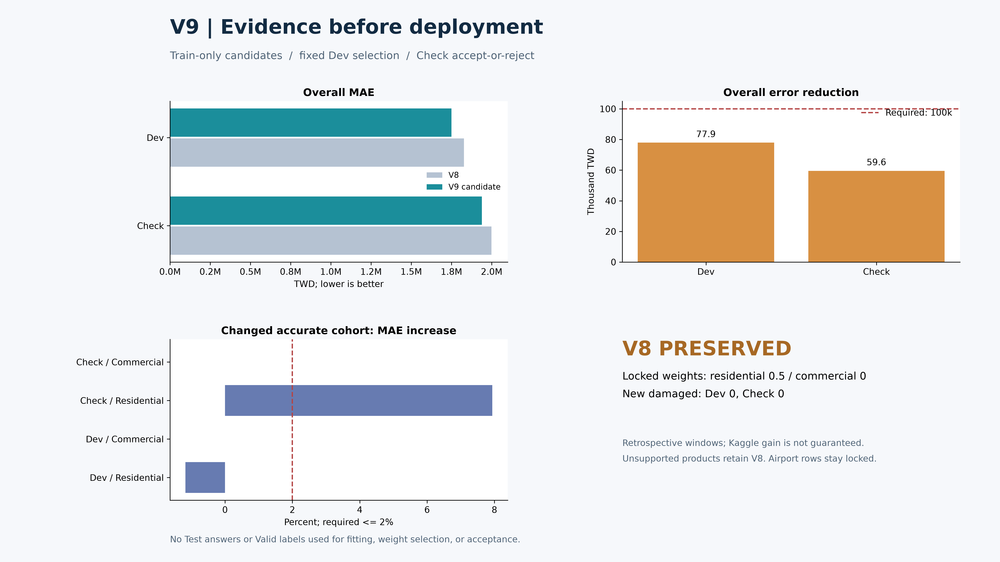

V9: no submission. The rejection remains part of the evidence.


898

In [41]:
if REVIEW_ONLY:
    saved_review.show(67)
else:
    result_v9 = extension_run_v9(PROJECT_ROOT, THREADS, EXTENSION_MODE)
    extension_results[9] = result_v9
    extension_display(result_v9)
    gc.collect()


## 16 · V10 · Quantile Residuals and Correction Strength

V10 改問：既有模型的偏差能否由一個殘差模型辨識，而且只在估價明顯偏離模型區間時修正？舊基礎模型截止於 2023-08，先移除吸收後續標籤的整體、區域及參考年齡校正，避免把已見自身結果的預測當殘差輸入。

| Stage | Time range | Function |
|---|---|---|
| Residual fitting | 2023-09 至 2024-05 | 學習單位面積有號殘差 |
| Selection | 2024-06 | 早停與有限修正權重選擇 |
| Retrospective check | 2024-07 至 2024-08 | 鎖定後評估，不重新挑權重 |

單一 CatBoost `MultiQuantile` 同時估計 0.2／0.5／0.8 分位數。實作目標為 `(actual_total - uncalibrated_base_total) / (building_area × 1000)`。常數 1000 用於數值縮放，推論時乘回 `building_area × 1000` 才得到總價修正；面積樣本權重使分位數損失與總價尺度保持固定比例。這是一次新模型擬合，沒有再用完整 Train 擬合第二個修正模型。

### Why the Selected Weight Is 0.25

符合支持條件且基準預測在估計區間外的交易，才使用以下修正；區間內及不適用交易維持原價：

\[
p'=p+w\,\operatorname{clip}(q_{50}-p,-C,C),\qquad
C=\min(3{,}000{,}000,0.2p).
\]

| Weight | June overall MAE | Accurate-group MAE change | Protection |
|---:|---:|---:|---|
| 0.00 | 1,949,155.422 | 0.000% | Pass |
| 0.25 | 1,757,176.015 | −0.960% | Pass |
| 0.50 | 1,587,157.673 | +22.405% | Fail |
| 0.75 | 1,454,919.244 | +55.997% | Fail |
| 1.00 | 1,382,342.097 | +94.214% | Fail |

較大的權重雖能降低六月整體 MAE，卻明顯增加原本準確群的誤差。採用 0.25 的理由因此是整體改善與保護條件之間的取捨，而不是聲稱 0.25 讓所有資料最準。

鎖定後，7–8 月 MAE 由 V8 的 **1,999,545.981** 降為 **1,844,556.249**，新增損傷 5 筆；原本準確群 MAE 增加 **2.345%**。Kaggle public 回報為 **1,901,809**。估計區間實際覆蓋率在六月為 45.494%、Check 為 39.214%，所以它是修正啟發式，不能稱為已校準的信賴區間。

V10 | june_selection.csv


,Weight,Set,Segment,Rows,Changed_Rows,V8_MAE,Candidate_MAE,MAE_Reduction,...,Accurate_Before,Accurate_After,Accurate_Increase_Pct,Changed_Accurate_Rows,Changed_Accurate_Increase_Pct,New_Damaged,Mean_Abs_Change,Protection_Passed
0,0.000,Tune_2024_06,All,14675,0,"1,949,155.422","1,949,155.422",0.000,...,"241,353.157","241,353.157",0.000,0,0.000,0,0.000,True
1,0.250,Tune_2024_06,All,14675,9471,"1,949,155.422","1,757,176.015","191,979.407",...,"241,353.157","239,035.444",-0.960,1560,-2.089,3,"243,328.644",True
2,0.500,Tune_2024_06,All,14675,9471,"1,949,155.422","1,587,157.673","361,997.749",...,"241,353.157","295,428.310",22.405,1560,48.739,97,"486,657.287",False
3,0.750,Tune_2024_06,All,14675,9471,"1,949,155.422","1,454,919.244","494,236.178",...,"241,353.157","376,503.373",55.997,1560,121.814,243,"729,985.931",False
4,1.000,Tune_2024_06,All,14675,9471,"1,949,155.422","1,382,342.097","566,813.325",...,"241,353.157","468,741.882",94.214,1560,204.950,426,"973,314.574",False


V10 | historical_scores.csv


,Set,Segment,Rows,Changed_Rows,V8_MAE,Candidate_MAE,MAE_Reduction,Improvement_Pct,...,Accurate_Rows,Accurate_Before,Accurate_After,Accurate_Increase_Pct,Changed_Accurate_Rows,Changed_Accurate_Increase_Pct,New_Damaged,Mean_Abs_Change
0,Tune_2024_06,All,14675,9471,"1,949,155.422","1,757,176.015","191,979.407",9.849,...,3497,"241,353.157","239,035.444",-0.960,1560,-2.089,3,"243,328.644"
1,Tune_2024_06,Eligible_Housing,14025,9471,"1,821,714.758","1,620,837.910","200,876.848",11.027,...,3382,"241,479.841","239,083.318",-0.992,1560,-2.089,3,"254,605.907"
2,Tune_2024_06,Changed,9471,9471,"2,093,758.211","1,796,292.495","297,465.716",14.207,...,1560,"248,709.199","243,513.660",-2.089,1560,-2.089,3,"377,029.653"
3,Tune_2024_06,Unchanged,5204,0,"1,685,986.127","1,685,986.127",0.000,0.000,...,1937,"235,428.828","235,428.828",0.000,0,0.000,0,0.000
4,Tune_2024_06,Originally_Accurate,3497,1560,"241,353.157","239,035.444","2,317.712",0.960,...,3497,"241,353.157","239,035.444",-0.960,1560,-2.089,3,"98,736.088"
5,Check_2024_07_08,All,15204,8438,"1,999,545.981","1,844,556.249","154,989.732",7.751,...,3695,"245,751.880","251,515.733",2.345,1480,5.738,5,"198,844.410"
6,Check_2024_07_08,Eligible_Housing,14568,8438,"1,852,511.466","1,690,755.296","161,756.170",8.732,...,3609,"245,197.184","251,098.385",2.407,1480,5.738,5,"207,525.427"
7,Check_2024_07_08,Changed,8438,8438,"2,206,202.711","1,926,934.651","279,268.060",12.658,...,1480,"250,806.633","265,196.791",5.738,1480,5.738,5,"358,287.558"
8,Check_2024_07_08,Unchanged,6766,0,"1,741,820.665","1,741,820.665",0.000,0.000,...,2215,"242,374.438","242,374.438",0.000,0,0.000,0,0.000
9,Check_2024_07_08,Originally_Accurate,3695,1480,"245,751.880","251,515.733","-5,763.853",-2.345,...,3695,"245,751.880","251,515.733",2.345,1480,5.738,5,"84,031.898"


V10 | quantile_diagnostics.csv


,Set,Eligible_Rows,Empirical_Central_Interval_Coverage_Pct,Median_Interval_Width,Quantile_Crossing_Rows,Changed_Rows
0,Tune_2024_06,13947,45.494,"1,123,452.205",8,9471
1,Check_2024_07_08,14505,39.214,"1,196,364.287",12,8438


{
  "Check_Is_Retrospective": true,
  "Check_MAE_Reduction": 154989.73233063985,
  "Check_Protection_Passed": true,
  "Export_Policy": "Export the June-locked nonzero candidate; report Check recommendation separately without retuning",
  "June_Selection_Only": true,
  "Kaggle_Target": "1.5M to 1.7M is a goal, not a score prediction or guarantee",
  "New_Predictive_Models": 1,
  "Production_Refit": false,
  "Quantile_Crossing_Rows": 155,
  "Recommended": true,
  "Selected_Weight": 0.25,
  "Test_Valid_Answers_Read": false
}


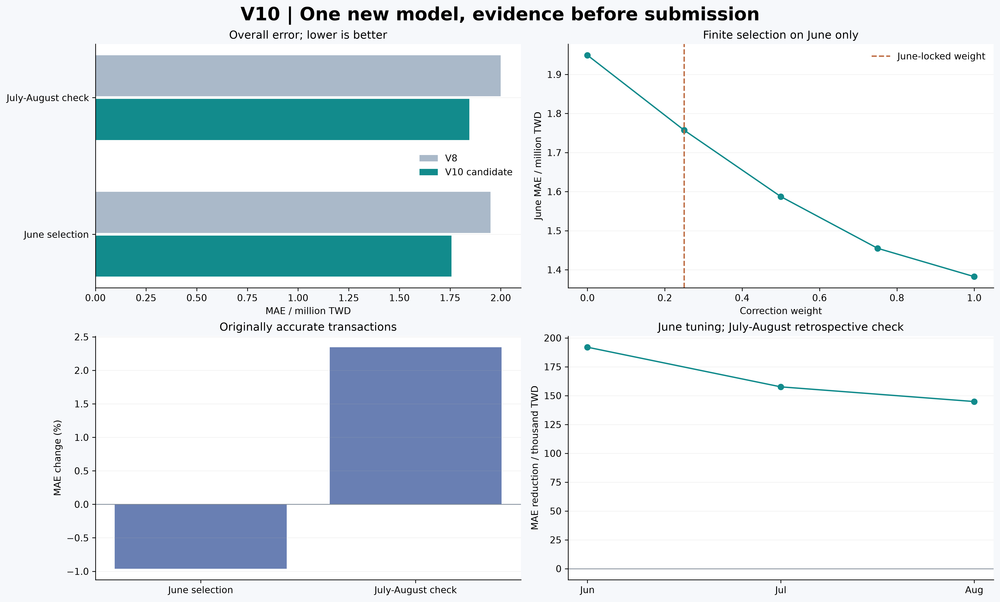

Submission: /home/hcl_dgx_1/Desktop/ML_HW1/ML_HW1_Price_Study/outputs/submission_v10/submission_v10.csv


31

In [42]:
if REVIEW_ONLY:
    saved_review.show(69)
else:
    result_v10 = extension_run_v10(PROJECT_ROOT, THREADS, EXTENSION_MODE)
    extension_results[10] = result_v10
    extension_display(result_v10)
    gc.collect()


## 17 · V11 · Nearest-Boundary Correction

V10 的結果顯示修正幅度存在明顯代價。我在 V11 保留同一個已訓練模型，研究「朝最近區間邊界移動」能否比「朝中央預測移動」更穩定，因此沒有新增模型或特徵。

六月比較預先列出的 Current、Boundary50／75／100 與 Confidence50／75／100。實際採用 `Boundary50`，其中 0.5 控制的是到最近邊界的修正幅度，與 V10 的 0.25 中央修正不是同一種權重：

\[
p'=p+0.5\,\operatorname{clip}(b-p,-C,C),\qquad
C=\min(3{,}000{,}000,0.2p).
\]

`b` 是基準預測超出區間時最近的 q20 或 q80 邊界；區間內的估價不動。

| Same-cohort result | V10 | V11 |
|---|---:|---:|
| June MAE | 1,757,176.015 | 1,683,085.924 |
| July–August MAE | 1,844,556.249 | 1,804,549.185 |
| July–August accurate-group MAE increase vs V8 | 2.345% | 4.304% |
| July–August newly damaged rows | 5 | 12 |
| Reported public MAE | 1,901,809 | 1,901,325 |

V11 在相同 Check 交易省下約 40,007 元，但 public 只改善 484 元，準確群的代價也增加。這說明歷史改善不必然等比例轉移到競賽分數。V11 保留為後續凍結基準，同時保留此代價紀錄。

In [43]:
if REVIEW_ONLY:
    saved_review.show(71)
else:
    result_v11 = extension_run_v11(PROJECT_ROOT, THREADS, EXTENSION_MODE)
    extension_results[11] = result_v11
    extension_display(result_v11)
    gc.collect()


V11 | june_selection.csv


,Policy,Protection_Passed,Set,Segment,Rows,Changed_Rows,V8_MAE,Candidate_MAE,...,Accurate_Rows,Accurate_Before,Accurate_After,Accurate_Increase_Pct,Changed_Accurate_Rows,Changed_Accurate_Increase_Pct,New_Damaged,Mean_Abs_Change
0,Current,True,June,All,14675,9471,"1,949,155.422","1,757,176.015",...,3497,"241,353.157","239,035.444",-0.960,1560,-2.089,3,"243,328.644"
1,Boundary50,True,June,All,14675,9471,"1,949,155.422","1,683,085.924",...,3497,"241,353.157","248,890.263",3.123,1560,6.793,31,"320,334.681"
2,Boundary75,False,June,All,14675,9471,"1,949,155.422","1,567,394.602",...,3497,"241,353.157","275,914.927",14.320,1560,31.151,76,"480,502.021"
3,Boundary100,False,June,All,14675,9471,"1,949,155.422","1,473,609.564",...,3497,"241,353.157","309,389.787",28.190,1560,61.323,135,"640,669.361"
4,Confidence50,False,June,All,14675,9471,"1,949,155.422","1,639,872.848",...,3497,"241,353.157","264,819.894",9.723,1560,21.151,48,"393,471.328"
5,Confidence75,False,June,All,14675,9471,"1,949,155.422","1,536,478.916",...,3497,"241,353.157","298,282.048",23.587,1560,51.311,113,"543,614.012"
6,Confidence100,False,June,All,14675,9471,"1,949,155.422","1,455,568.551",...,3497,"241,353.157","335,562.614",39.034,1560,84.913,178,"693,756.696"


V11 | validation.csv


,Set,Segment,Rows,Changed_Rows,V8_MAE,Candidate_MAE,MAE_Reduction,Improvement_Pct,...,Accurate_Before,Accurate_After,Accurate_Increase_Pct,Changed_Accurate_Rows,Changed_Accurate_Increase_Pct,New_Damaged,Mean_Abs_Change,Gain_vs_Current_V10
0,June,Current_V10,14675,9471,"1,949,155.422","1,757,176.015","191,979.407",9.849,...,"241,353.157","239,035.444",-0.960,1560,-2.089,3,"243,328.644",0.000
1,June,Adaptive_Candidate,14675,9471,"1,949,155.422","1,683,085.924","266,069.498",13.651,...,"241,353.157","248,890.263",3.123,1560,6.793,31,"320,334.681","74,090.091"
2,July_August,Current_V10,15204,8438,"1,999,545.981","1,844,556.249","154,989.732",7.751,...,"245,751.880","251,515.733",2.345,1480,5.738,5,"198,844.410",0.000
3,July_August,Adaptive_Candidate,15204,8438,"1,999,545.981","1,804,549.185","194,996.796",9.752,...,"245,751.880","256,328.263",4.304,1480,10.528,12,"235,632.323","40,007.064"


V11 | test_changes.csv


,Year,Rows,Changed_Pct,Mean_Abs_Change
0,2024,29694,20.442,"28,195.973"
1,2025,17379,30.813,"44,488.379"


{
  "Check_Gain_vs_Current_V10": 40007.06391012226,
  "Check_Protection_Passed": true,
  "June_Gain_vs_Current_V10": 74090.09114959021,
  "Kaggle_Uploaded": false,
  "New_Model_Fits": 0,
  "Recommended": true,
  "Retrospective_Check": true,
  "Test_Answers_Read": false,
  "configuration": {
    "check_accurate_increase_pct": 15.0,
    "check_end": 199,
    "depth": 6,
    "early_stopping_rounds": 200,
    "iterations": 2200,
    "l2_leaf_reg": 25.0,
    "learning_rate": 0.035,
    "maximum_change_twd": 3000000.0,
    "maximum_damaged_fraction": 0.01,
    "maximum_relative_change": 0.2,
    "minimum_check_gain": 25000.0,
    "minimum_leaf_rows": 100,
    "minimum_stratum_rows": 40,
    "minimum_tune_gain": 10000.0,
    "old_cutoff": 187,
    "seed": 42,
    "threads": 8,
    "train_end": 196,
    "tune_accurate_increase_pct": 10.0,
    "tune_month": 197,
    "weights": [
      0.0,
      0.25,
      0.5,
      0.75,
      1.0
    ]
  },
  "current_weight": 0.25,
  "implementation": "v10

31

## 18 · Evidence Summary and Submission Identity

結果以三種口徑分開整理：相同歷史母體上的 MAE、已回報的 Kaggle public 分數，以及原本準確群的代價。每份提交檔附 SHA256，使分數可對應到確切檔案；檔名改變不會產生新實驗證據。

| Version | Public MAE reported | Decision |
|---|---:|---|
| V8 frozen reference | 約 1,918,506 | 公開規則與凍結預測的參考 |
| V10 | 1,901,809 | 保守量化殘差修正 |
| V11 | 1,901,325 | 本檔後續比較的凍結基準 |
| V13 | 1,968,723 | 較 V11 差，未採用 |
| V14 | 與 V11 相同檔案 | 沒有產生新價格，不重複解讀為改善 |

Public 分數是先前提交的回報，不是本次 Run All 重新取得的分數。V15 使用不同資訊條件，不列入這張模型成效表。

,Version,Submission,SHA256,New_Kaggle_MAE,Status
0,submission_v1,/home/hcl_dgx_1/Desktop/ML_HW1/ML_HW1_Price_St...,b5a641f39d5aa37860d90ae21921a68c8e0dcd295a5801...,NaN,NaN
1,submission_v2,/home/hcl_dgx_1/Desktop/ML_HW1/ML_HW1_Price_St...,3e39833a7c5c22d580ccb3a4a0161e439493901eea29ba...,NaN,NaN
2,submission_v3,/home/hcl_dgx_1/Desktop/ML_HW1/ML_HW1_Price_St...,b8f2b9c0156a6030dc9bb5ee81f18c63d40eee7b345a2d...,NaN,NaN
3,submission_v4,/home/hcl_dgx_1/Desktop/ML_HW1/ML_HW1_Price_St...,195871babb57986b3b1993af507ff8d14a25def4406a05...,NaN,NaN
4,submission_v5,/home/hcl_dgx_1/Desktop/ML_HW1/ML_HW1_Price_St...,c1565e4b4f55814ccd3fe82688c529ec223be9275e29fb...,NaN,NaN
5,submission_v6,/home/hcl_dgx_1/Desktop/ML_HW1/ML_HW1_Price_St...,a7879c595cad3419305bcb60a5a9c0154d6b6ef831eca9...,NaN,NaN
6,submission_v7,/home/hcl_dgx_1/Desktop/ML_HW1/ML_HW1_Price_St...,c22fa228675112a5ad2132fafcc13623b59313d47647de...,NaN,NaN
7,submission_v8,/home/hcl_dgx_1/Desktop/ML_HW1/ML_HW1_Price_St...,a54a3591ea6bae70ce0136ced17c1bf28a41d9908f911c...,NaN,NaN
8,submission_v9,NaN,NaN,NaN,Rejected
9,submission_v10,/home/hcl_dgx_1/Desktop/ML_HW1/ML_HW1_Price_St...,0ba83cf9d9811164032d25f5141259da3a11690438d027...,"1,901,809.000",Saved reports; model readiness audited separately


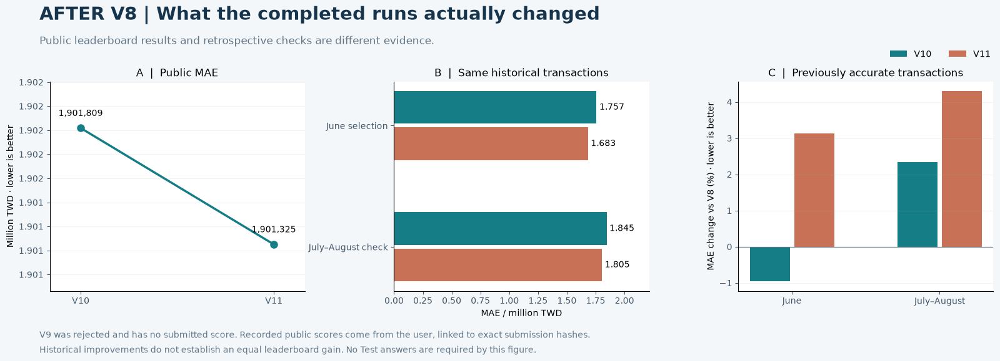

One notebook contains all integrated versions. No Kaggle upload was performed.


1843

In [44]:
if REVIEW_ONLY:
    saved_review.show(73)
else:
    submission_index = extension_finish(PROJECT_ROOT, show_chart=False)
    saved_overview = PROJECT_ROOT / "presentation/figures/12_submission_extensions.png"
    if saved_overview.is_file():
        display(Image(filename=str(saved_overview)))
    else:
        print("Saved continuation figure unavailable; plot regeneration skipped.")
    gc.collect()
    print("Saved version evidence reviewed. No fitting, inference or Kaggle upload.")


## 19 · Model Availability and Recovery Audit

研究過程中，V10 的部分原生權重及衍生預測快取未能保留。因此我另外盤點「報表存在」與「可重新推論」的差異。保存結果仍可供閱讀，但缺少必要權重時，不能宣稱該模型已在新環境完成推論重現。

恢復流程先核對 V7 元件、特徵參考及既有預測的一致性，缺必要條件即停止。這次只讀模式不啟動恢復，也不因整理文件重新訓練整個 V7；V12 是可選的研究功能，不是本次已完成實驗。

In [45]:
if REVIEW_ONLY:
    saved_review.show(75)
else:
    # Embedded recovery definitions; optional V12 route.
    _recovery_source = r'''"""Notebook-embedded recovery. No original predictive source is rewritten.

Native V7 models are load-only. One explicitly enabled residual-model job may
be recovered in V12; completed artifacts and old scored submissions are kept.
"""
from pathlib import Path
from contextlib import contextmanager
import gc
import hashlib
import importlib
import importlib.metadata
import json
import sys
import warnings

import numpy as np
import pandas as pd
from IPython.display import display

IMPLEMENTATION = "v12_durable_recovery_20261018_1"
ID, TARGET, MONTH = "編號", "總價元", "交易時間序號"
V8_SHA = "0fe22eafd43db8f78a8f8ec54696afe53d7fe7aadebb41a4f67d24f626a5cebb"
V11_SHA = "2d47eae33420160cc333039be437115ce79c20ec584f4f951849aca701b517be"
WEIGHTS = (.25, .50, .75, 1.)


def file_hash(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".pending")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    temporary.replace(path)


def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False, default=str).encode()).hexdigest()


@contextmanager
def forbid_old_training():
    """A missing old cache must never trigger any backend fitting."""
    import catboost
    import lightgbm
    old_cat, old_lgb = catboost.CatBoostRegressor.fit, lightgbm.LGBMRegressor.fit

    def forbidden(*args, **kwargs):
        raise RuntimeError("Old-model training is prohibited. Restore the listed V7 cache; no old model was fitted.")

    catboost.CatBoostRegressor.fit = lightgbm.LGBMRegressor.fit = forbidden
    try:
        yield
    finally:
        catboost.CatBoostRegressor.fit, lightgbm.LGBMRegressor.fit = old_cat, old_lgb


def correct(baseline, prices, eligible, weight, absolute_cap, relative_cap):
    baseline, prices = np.asarray(baseline, float), np.asarray(prices, float)
    mask = np.array(eligible, bool, copy=True) & np.isfinite(prices).all(axis=1)
    result = baseline.copy()
    cap = np.minimum(float(absolute_cap), float(relative_cap) * baseline)
    delta = prices[:, 1] - baseline
    result[mask] += float(weight) * np.clip(delta[mask], -cap[mask], cap[mask])
    if not np.isfinite(result).all() or (result < 0).any():
        raise ValueError("Invalid candidate predictions")
    np.testing.assert_array_equal(result[~mask], baseline[~mask])
    return result


def score(actual, baseline, candidate, mask, label):
    mask = np.asarray(mask, bool)
    old, new = abs(actual - baseline), abs(actual - candidate)
    accurate = mask & (old <= 500_000)
    before = float(old[accurate].mean()) if accurate.any() else np.nan
    after = float(new[accurate].mean()) if accurate.any() else np.nan
    return {"Period": label, "Rows": int(mask.sum()), "V8_MAE": float(old[mask].mean()),
            "Candidate_MAE": float(new[mask].mean()), "V8_Accurate_Rows": int(accurate.sum()),
            "V8_Accurate_MAE_Before": before, "V8_Accurate_MAE_After": after,
            "V8_Accurate_Increase_Pct": 100 * (after / before - 1) if before > 0 else np.nan,
            "New_Damaged_Vs_V8": int((accurate & (new > 1_000_000)).sum()),
            "Median_Residual": float(np.median((actual - candidate)[mask])),
            "Mean_Abs_Change_From_V8": float(abs(candidate[mask] - baseline[mask]).mean())}


class RecoveryRun:
    """One project, explicit preflight, zero old fits, at most one residual job."""

    @staticmethod
    def find_root(explicit=None):
        if explicit is not None:
            root = Path(explicit).expanduser().resolve()
            if not (root / "configs/input_manifest.json").is_file():
                raise FileNotFoundError(f"Completed project not found: {root}")
            return root
        options = [Path.cwd(), Path.cwd() / "ML_HW1_Price_Study",
                   Path.home() / "Desktop/ML_HW1/ML_HW1_Price_Study"]
        found = list(dict.fromkeys(p.resolve() for p in options if (p / "configs/input_manifest.json").is_file()))
        if len(found) != 1:
            raise ValueError("Set RECOVERY_ROOT to the completed ML_HW1_Price_Study folder")
        return found[0]

    def __init__(self, root, threads=8):
        self.root, self.threads = self.find_root(root), int(threads)
        self.output = self.root / "outputs/submission_v12"
        self.folder = self.output / "models/recovery"
        self.fits_this_run = 0
        self.base = None
        self.model = None
        self._input_paths = {}
        self.quantile_meta = {}
        self.manifest = read_json(self.root / "configs/input_manifest.json")
        if self.manifest.get("Test", {}).get("target_available") is True:
            raise ValueError("Use the original unlabelled Test workbook")
        tables = self.root / "outputs/submission_v10/tables"
        # Reports and native weights are deliberately resolved independently.
        candidates = [tables] + sorted((self.root / "outputs/submission_v10_onefit").glob("*"))
        candidates = [p for p in candidates if all((p / n).is_file() for n in ("protocol.json", "model.json", "support.json"))]
        if not candidates:
            raise FileNotFoundError("V10 protocol/model metadata/support reports are missing; no training was started")
        self.reports = candidates[0]
        self.protocol = read_json(self.reports / "protocol.json")
        self.old_meta = read_json(self.reports / "model.json")
        self.support = read_json(self.reports / "support.json")
        self.config = self.protocol["configuration"]
        if self.protocol["train_sha256"] != self.manifest["Train"]["sha256"]:
            raise ValueError("Original V10 reports refer to another Train workbook")
        self._verify_sources()
        self.identity = {"implementation": IMPLEMENTATION, "protocol": digest(self.protocol),
                         "original_model_sha256": self.old_meta["sha256"], "V8": V8_SHA, "V11": V11_SHA,
                         "Train": self.manifest["Train"]["sha256"], "Test": self.manifest["Test"]["sha256"],
                         "weights": list(WEIGHTS)}
        self.original_model = self._locate_original_model()
        self._reconcile_checkpoint()

    def _verify_sources(self):
        sources = {**self.protocol["sources"], **self.protocol["old_model_provenance"]["source_sha256"]}
        for name, sha in sources.items():
            path = self.root / "src" / name
            if not path.is_file() or file_hash(path) != sha:
                raise ValueError(f"Frozen source differs: {name}. Existing model files were not changed.")

    def _modules(self):
        source = self.root / "src"
        if str(source) not in sys.path:
            sys.path.insert(0, str(source))
        self.module = importlib.import_module("v10_candidate")
        self.base_module = importlib.import_module("v10_base")
        self.try_module = importlib.import_module("try_pipeline")
        self.project = importlib.import_module("project")
        for module in (self.module, self.base_module, self.try_module, self.project):
            if Path(module.__file__).resolve().parent != source:
                raise RuntimeError("Another project is loaded. Start a fresh kernel and execute Section 19 only.")

    def _locate_original_model(self):
        options = [self.reports / "model.cbm", self.root / "outputs/submission_v10/models/model.cbm"]
        pointer = self.root / "outputs/submission_v10/models/cache_location.json"
        if pointer.is_file():
            saved = read_json(pointer)
            for key in ("Original_Model_Cache", "Original_Run_Folder"):
                if saved.get(key):
                    options.append(Path(saved[key]).expanduser() / "model.cbm")
        options += sorted((self.root / "outputs").glob("**/model.cbm"))
        for path in dict.fromkeys(options):
            if path.is_file() and file_hash(path) == self.old_meta["sha256"]:
                return path.resolve()
        return None

    def _input(self, label, verify=False):
        info = self.manifest[label]
        if label in self._input_paths:
            return self._input_paths[label]
        options = [Path(info["file"]).expanduser(), self.root.parent / Path(info["file"]).name,
                   self.root / "data/raw" / Path(info["file"]).name]
        for path in dict.fromkeys(options):
            if path.is_file() and (not verify or file_hash(path) == info["sha256"]):
                if verify:
                    self._input_paths[label] = path.resolve()
                return path.resolve()
        raise FileNotFoundError(f"Original {label} workbook with the saved fingerprint was not found")

    def _scored_path(self, version):
        expected = V8_SHA if version == 8 else V11_SHA
        candidates = [self.root / f"outputs/submission_v{version}/submission_v{version}.csv"]
        if version == 8:
            candidates.insert(0, self.root / "references/current_best_predictions.csv")
        for path in candidates:
            if path.is_file() and file_hash(path) == expected:
                return path
        raise FileNotFoundError(f"Verified V{version} predictions missing; checked: " + ", ".join(map(str, candidates)))

    def _component_candidates(self, context):
        result = []
        for path in sorted((self.root / "outputs/v10_base_cache" / context).glob("*/metadata.json")):
            meta = read_json(path)
            if (meta.get("identity", {}).get("frozen_provenance") == self.protocol["old_model_provenance"]
                    and path.with_name("components.pkl").is_file()
                    and file_hash(path.with_name("components.pkl")) == meta.get("sha256")):
                result.append((path, meta))
        return result

    def _native_inventory(self, context):
        old = self.protocol["old_model_provenance"]
        records = []
        reference = self.root / "outputs/submission_v7/models/reference_ensemble"
        for name in ("system_manifest.json",):
            p = reference / name
            expected = old["legacy_system_manifest_sha256"]
            records.append({"Context": context, "File": str(p.relative_to(self.root)),
                            "Ready": p.is_file() and file_hash(p) == expected})
        p = self.root / "outputs/submission_v7/recipe.json"
        records.append({"Context": context, "File": str(p.relative_to(self.root)),
                        "Ready": p.is_file() and file_hash(p) == old["v7_recipe_sha256"]})
        data = old["contexts"][context]
        for name, meta in data["legacy_components"].items():
            folder = reference / "models" / context / name
            for filename, key in (("manifest.json", "manifest_sha256"), ("model.cbm", "model_sha256"),
                                  ("features.pkl", "features_sha256")):
                p = folder / filename
                records.append({"Context": context, "File": str(p.relative_to(self.root)),
                                "Ready": p.is_file() and file_hash(p) == meta[key]})
        folder = self.root / "outputs/submission_v7/models/comparison_ensemble" / ("validation" if context == "historical" else "full")
        for filename, sha in data["try_cache_files"].items():
            p = folder / filename
            records.append({"Context": context, "File": str(p.relative_to(self.root)),
                            "Ready": p.is_file() and file_hash(p) == sha})
        return records

    def _checkpoint_identity(self):
        return {**self.identity, "backend_versions": {name: importlib.metadata.version(name)
                for name in ("catboost", "pandas", "numpy")}}

    def _reconcile_checkpoint(self):
        pending = self.folder / "model.pending.json"
        if not pending.is_file():
            return
        meta = read_json(pending)
        if meta.get("identity") != self._checkpoint_identity():
            raise ValueError("An interrupted V12 checkpoint belongs to another environment or experiment")
        final, temporary = self.folder / "model.cbm", self.folder / "model.pending.cbm"
        candidate = final if final.is_file() and file_hash(final) == meta["sha256"] else temporary
        if not candidate.is_file() or file_hash(candidate) != meta["sha256"]:
            raise ValueError("Incomplete V12 final model checksum; checkpoint preserved")
        if candidate != final:
            candidate.replace(final)
        pending.replace(self.folder / "model.json")
        self._mark_completed(meta)

    def _mark_completed(self, meta):
        ledger_path = self.folder / "fit_budget.json"
        ledger = read_json(ledger_path) if ledger_path.is_file() else {}
        ledger.update({"identity": meta["identity"], "state": "Completed", "model_sha256": meta["sha256"],
                       "maximum_distinct_new_models": 1})
        write_json(ledger_path, ledger)

    def _own_model_ready(self):
        path, meta_path = self.folder / "model.cbm", self.folder / "model.json"
        if not path.is_file() or not meta_path.is_file():
            return False
        meta = read_json(meta_path)
        if meta.get("identity") != self._checkpoint_identity() or file_hash(path) != meta["sha256"]:
            raise ValueError("Existing V12 model identity/checksum differs; automatic refitting is prohibited")
        return True

    def _quantile_path(self, context):
        return self.output / "predictions" / (context + "_quantiles.csv.gz")

    def _load_quantiles(self, context):
        path = self._quantile_path(context)
        meta_path = path.with_name(context + "_quantiles.json")
        if not path.is_file() or not meta_path.is_file():
            return None
        meta = read_json(meta_path)
        if meta.get("identity") != self.identity or file_hash(path) != meta["sha256"]:
            raise ValueError("Saved quantile checkpoint changed; no automatic overwrite")
        result = pd.read_csv(path, dtype={ID: "string"})
        if context == "production":
            forbidden = {TARGET, "Actual", "Residual", "Error"}.intersection(result)
            if forbidden:
                raise ValueError("Production checkpoint must contain no Test answers")
        if not result[ID].is_unique or len(result) != meta["rows"]:
            raise ValueError("Quantile checkpoint IDs/rows changed")
        result["Eligible"] = result["Eligible"].astype("string").str.lower().map({"true": True, "false": False})
        if result["Eligible"].isna().any():
            raise ValueError("Invalid eligibility in quantile checkpoint")
        result["Eligible"] = result["Eligible"].astype(bool)
        self.quantile_meta[context] = meta
        return result

    def _save_quantiles(self, context, frame, model_sha):
        path = self._quantile_path(context)
        path.parent.mkdir(parents=True, exist_ok=True)
        temporary = path.with_name(path.name + ".pending")
        frame.to_csv(temporary, index=False, compression="gzip")
        temporary.replace(path)
        meta = {"identity": self.identity, "sha256": file_hash(path), "rows": len(frame),
                "model_sha256": model_sha, "test_answers_read": False}
        write_json(path.with_name(context + "_quantiles.json"), meta)
        self.quantile_meta[context] = meta

    def audit(self):
        rows, self.native_files = [], []
        quantiles = {name: self._load_quantiles(name) for name in ("historical", "production")}
        if all(value is not None for value in quantiles.values()):
            if self.quantile_meta["historical"]["model_sha256"] != self.quantile_meta["production"]["model_sha256"]:
                raise ValueError("Historical and Test quantile checkpoints came from different models")
        model_ready = self.original_model is not None or self._own_model_ready()
        rows.append({"Artifact": "Residual model", "Ready": model_ready,
                     "Action": "Load saved model" if model_ready else "At most ONE explicitly enabled recovery fit"})
        partial_q = any(value is not None for value in quantiles.values()) and not all(value is not None for value in quantiles.values())
        if partial_q:
            needed_sha = next(self.quantile_meta[name]["model_sha256"] for name, value in quantiles.items() if value is not None)
            available = [p for p in (self.original_model, self.folder / "model.cbm") if p is not None and p.is_file()]
            partial_ready = any(file_hash(p) == needed_sha for p in available)
            rows.append({"Artifact": "Partial quantile/model compatibility", "Ready": partial_ready,
                         "Action": "Use the same saved weights" if partial_ready else "Restore weights matching the partial quantile checkpoint; no replacement fit"})
        contexts_ready = []
        for context in ("historical", "production"):
            q_ready = quantiles[context] is not None
            components = bool(self._component_candidates(context))
            records = self._native_inventory(context) if not q_ready and not components else []
            native = bool(records) and all(r["Ready"] for r in records)
            self.native_files.extend(records)
            ready = q_ready or components or native
            contexts_ready.append(ready)
            rows.append({"Artifact": f"{context} prediction inputs", "Ready": ready,
                         "Action": "Reuse quantiles" if q_ready else "Reuse component table" if components
                                   else "Rebuild predictions from saved V7 models; ZERO old fits" if native
                                   else "Restore listed V7 files; old training remains blocked"})
        for label in ("Train", "Test"):
            try:
                self._input(label)
                ready = True
            except FileNotFoundError:
                ready = False
            rows.append({"Artifact": f"Original {label} workbook", "Ready": ready, "Action": "Fingerprint checked before use"})
        for version, sha in ((8, V8_SHA), (11, V11_SHA)):
            try:
                path = self._scored_path(version)
                ready, action = True, f"Preserve verified predictions: {path.relative_to(self.root)}"
            except FileNotFoundError:
                ready, action = False, "Restore the original scored prediction file; no model training started"
            rows.append({"Artifact": f"Scored V{version} CSV", "Ready": ready, "Action": action})
        for relative, columns in (("outputs/submission_v8/predictions/dev.csv", {ID, "Actual", "Prediction"}),
                                  ("outputs/submission_v8/predictions/check.csv", {ID, "Actual", "Prediction"}),
                                  ("outputs/submission_v11/tables/validation.csv", {"Set", "Segment", "Rows", "V8_MAE", "Candidate_MAE"})):
            p = self.root / relative
            ready = p.is_file() and columns.issubset(pd.read_csv(p, nrows=0).columns)
            rows.append({"Artifact": relative, "Ready": ready, "Action": "Verify cohort before the one permitted fit"})
        self.audit_table = pd.DataFrame(rows)
        # The V10 model may be absent; that is precisely the one permitted job.
        self.inputs_ready = all(contexts_ready) and all(r["Ready"] for r in rows if r["Artifact"] != "Residual model")
        self.needs_fit = not model_ready and not (quantiles["historical"] is not None and quantiles["production"] is not None)
        display(self.audit_table)
        missing = pd.DataFrame([r for r in self.native_files if not r["Ready"]])
        if len(missing):
            display(missing)
        (self.output / "tables").mkdir(parents=True, exist_ok=True)
        self.audit_table.to_csv(self.output / "tables/cache_audit.csv", index=False)
        if self.native_files:
            pd.DataFrame(self.native_files).to_csv(self.output / "tables/native_dependencies.csv", index=False)
        if len(missing):
            missing.to_csv(self.output / "tables/missing_native_files.csv", index=False)
        print({"Old_Model_Fits_Allowed": 0, "Maximum_New_Residual_Models": int(self.needs_fit),
               "Dependencies_Ready": self.inputs_ready, "Original_Model_Found": self.original_model is not None,
               "Notebook_Contains_Weights": False})
        return self.audit_table

    def _prepare_train(self, namespace):
        self._modules()
        raw_frames = namespace.get("raw", {})
        raw_frames = raw_frames if isinstance(raw_frames, dict) else {}
        path = self._input("Train", verify=True)
        raw = raw_frames.get("Train")
        legacy = importlib.import_module("legacy_pipeline")
        expected = self.protocol["old_model_provenance"]["raw_train_signature"]
        if raw is None or legacy.frame_digest(raw) != expected:
            raw = pd.read_excel(path)
        if legacy.frame_digest(raw) != expected:
            raise ValueError("Original Train values or dtypes differ from the fitted provenance")
        self.processor = self.try_module.TryPreprocessor(raw)
        prepared = self.processor.transform(raw.assign(_Recovery_Position=np.arange(len(raw))), training=True)
        safe = self.module.unique_ids(prepared)
        positions = self.module.numbers(prepared.loc[safe], "_Recovery_Position").astype(int)
        self.train = prepared.loc[safe].drop(columns="_Recovery_Position").reset_index(drop=True)
        self.raw_safe = raw.iloc[positions].reset_index(drop=True).copy()
        self.train[ID], self.raw_safe[ID] = self.train[ID].astype(str), self.raw_safe[ID].astype(str)
        np.testing.assert_array_equal(self.train[ID], self.raw_safe[ID])
        self.raw_train = raw
        self.train_month = self.module.numbers(self.train, MONTH)

    def _components(self, raw, context):
        features = raw.drop(columns=[TARGET], errors="ignore").copy()
        self.module.check_unlabelled(features)
        expected = self.base_module._frame_hash(features)
        candidates = [(path, meta) for path, meta in self._component_candidates(context)
                      if meta["identity"].get("query_features") == expected]
        if candidates:
            if len({meta["sha256"] for _, meta in candidates}) != 1:
                raise ValueError("Conflicting matching component caches")
            path, meta = candidates[0]
            result = pd.read_pickle(path.with_name("components.pkl")).reset_index(drop=True)
            self.module.check_unlabelled(result)
            np.testing.assert_array_equal(result[ID].astype(str), features[ID].astype(str))
            print(f"Loaded component table: {context} | Rows: {len(result):,}", flush=True)
            return result
        if self.base is None:
            # The guard covers setup and inference, even if an old loader calls fit().
            with forbid_old_training():
                self.base = self.base_module.FrozenBase(self.root, self.raw_train, self.threads)
                self.base.prepare_historical()
                self.base.prepare_production()
            if self.base.provenance != self.protocol["old_model_provenance"]:
                raise ValueError("Reconstructed frozen context provenance differs from original V10")
        with forbid_old_training():
            # Do not create another large global prediction cache. The durable
            # V12 checkpoints below retain only the small quantile tables.
            return self.base.predict(features, context, cache=False)["detail"].reset_index(drop=True)

    def _load_or_train(self, features, query, detail, eligible, allow_fit):
        from catboost import CatBoostRegressor, Pool
        if list(features) != self.old_meta["columns"]:
            raise ValueError("Rebuilt residual features differ from the original ordered schema")
        if self.original_model is not None:
            path, meta = self.original_model, self.old_meta
            model = CatBoostRegressor()
            model.load_model(str(path))
            write_json(self.output / "models/original_model_reference.json",
                       {"Path": str(path.relative_to(self.root)) if path.is_relative_to(self.root) else str(path),
                        "SHA256": self.old_meta["sha256"], "Copied": False, "Keep_Original_Cache": True})
        elif self._own_model_ready():
            path, meta = self.folder / "model.cbm", read_json(self.folder / "model.json")
            model = CatBoostRegressor()
            model.load_model(str(path))
        else:
            if not allow_fit:
                raise RuntimeError("One residual recovery fit is required. Set ALLOW_ONE_RECOVERY_FIT=True in the explicit execution cell.")
            month, area = self.module.numbers(query, MONTH), self.module.numbers(query, self.module.AREA)
            fit = eligible & (month <= self.config["train_end"])
            tune = eligible & (month == self.config["tune_month"])
            actual, raw_base = self.module.numbers(query, TARGET), self.module.numbers(detail, "Raw_Base")
            target = np.divide(actual - raw_base, area * self.module.UNIT_SCALE,
                               out=np.full(len(area), np.nan), where=np.isfinite(area) & (area > 0))
            if fit.sum() < 1000 or tune.sum() < 100 or not np.isfinite(target[fit | tune]).all():
                raise ValueError("Insufficient or invalid fixed Train/June fitting population")
            categorical = features.select_dtypes(include=["object", "string", "category"]).columns.tolist()
            if categorical != self.old_meta["categorical"]:
                raise ValueError("Residual categorical schema differs")
            parameters = dict(self.old_meta["params"])
            parameters["train_dir"] = str(self.folder / "training_log")
            if parameters.get("iterations") != self.config["iterations"] or parameters.get("task_type") != "CPU":
                raise ValueError("Original fixed residual training recipe differs")
            signature = digest({"identity": self._checkpoint_identity(), "matrix": self.module.study.frame_hash(features.loc[fit]),
                                "target": target[fit].tolist(), "columns": list(features),
                                "parameters": {k: v for k, v in parameters.items() if k != "train_dir"}})
            ledger_path = self.folder / "fit_budget.json"
            ledger = read_json(ledger_path) if ledger_path.is_file() else {}
            if ledger and ledger.get("signature") != signature:
                raise RuntimeError("The one-model budget already belongs to another experiment")
            if ledger.get("state") == "Completed":
                raise RuntimeError("Completed V12 weights are missing. Restore them or reuse the quantile checkpoints; automatic refitting stopped.")
            self.folder.mkdir(parents=True, exist_ok=True)
            ledger.update({"identity": self._checkpoint_identity(), "signature": signature,
                           "state": "Started", "maximum_distinct_new_models": 1,
                           "backend_fit_attempts": int(ledger.get("backend_fit_attempts", 0)) + 1})
            write_json(ledger_path, ledger)
            mean_area = float(area[fit].mean())
            fit_pool = Pool(features.loc[fit], target[fit], cat_features=categorical, weight=area[fit] / mean_area)
            tune_pool = Pool(features.loc[tune], target[tune], cat_features=categorical, weight=area[tune] / mean_area)
            model = CatBoostRegressor(**parameters)
            print({"New_Residual_Models": 1, "Old_Model_Fits": 0, "Fit_Rows": int(fit.sum()),
                   "June_Rows": int(tune.sum()), "Features": features.shape[1], "Maximum_Trees": parameters["iterations"],
                   "Snapshot_Seconds": 60, "Fit_Attempt": ledger["backend_fit_attempts"]}, flush=True)
            # The ONLY permitted new predictive-model fit in this recovery implementation.
            model.fit(fit_pool, eval_set=tune_pool, use_best_model=True,
                      early_stopping_rounds=self.config["early_stopping_rounds"], save_snapshot=True,
                      snapshot_file=str(self.folder / "training.snapshot"), snapshot_interval=60)
            self.fits_this_run += 1
            pending = self.folder / "model.pending.cbm"
            model.save_model(str(pending))
            meta = {"identity": self._checkpoint_identity(), "sha256": file_hash(pending),
                    "columns": list(features), "categorical": categorical, "trees": int(model.tree_count_),
                    "params": parameters, "signature": signature, "training_source": "Original Train only",
                    "weight_selection_source": "June Train validation only", "test_valid_labels_used": False}
            write_json(self.folder / "model.pending.json", meta)
            pending.replace(self.folder / "model.cbm")
            (self.folder / "model.pending.json").replace(self.folder / "model.json")
            self._mark_completed(meta)
            path = self.folder / "model.cbm"
            del fit_pool, tune_pool
            gc.collect()
        if list(model.feature_names_) != list(features):
            raise ValueError("Loaded residual model feature schema differs")
        self.model, self.model_sha = model, file_hash(path)
        return model

    def _historical_quantiles(self, namespace, allow_fit):
        cached = self._load_quantiles("historical")
        if cached is not None:
            return cached
        self._prepare_train(namespace)
        c = self.config
        mask = (self.train_month > c["old_cutoff"]) & (self.train_month <= c["check_end"])
        query = self.train.loc[mask].reset_index(drop=True)
        raw = self.raw_safe.loc[mask].drop(columns=TARGET).reset_index(drop=True)
        detail = self._components(raw, "historical")
        keys = query[["縣市", "建物型態", "主要用途"]].astype(str).agg("|".join, axis=1)
        locked = self.module.V10Experiment._airport_locked(raw)
        housing = self.module.housing_mask(query) & ~locked
        fit_keys = keys[housing & (self.module.numbers(query, MONTH) <= c["train_end"])]
        rebuilt_support = {str(k): int(v) for k, v in fit_keys.value_counts().items()}
        if rebuilt_support != self.support:
            raise ValueError("Rebuilt residual training population differs from the saved support table")
        supported = keys.map(self.support).fillna(0).to_numpy(float) >= c["minimum_stratum_rows"]
        eligible = housing & supported & (self.module.numbers(detail, "Forecast_Gap") > 0)
        features = self.module.model_features(query, detail,
                    self.module.market_table(self.train.loc[self.train_month <= c["old_cutoff"]], c["old_cutoff"]))
        evaluation = self.module.numbers(query, MONTH) >= c["tune_month"]
        q = query.loc[evaluation].reset_index(drop=True)
        saved = pd.concat([pd.read_csv(self.root / f"outputs/submission_v8/predictions/{name}.csv", dtype={ID: "string"})
                           for name in ("dev", "check")], ignore_index=True)
        if not saved[ID].is_unique:
            raise ValueError("Saved V8 historical IDs are ambiguous")
        saved = saved.set_index(ID).loc[q[ID].astype(str)]
        np.testing.assert_allclose(self.module.numbers(saved, "Actual"), self.module.numbers(q, TARGET), rtol=0, atol=.01)
        self._archived_v11(pd.DataFrame({MONTH: self.module.numbers(q, MONTH), "Actual": self.module.numbers(q, TARGET),
                                        "V8": self.module.numbers(saved, "Prediction")}))
        # The original fit/tune population does not exclude low-support strata.
        model = self._load_or_train(features, query, detail, housing, allow_fit)
        prices, _ = self.module.quantile_prices(self.module.numbers(detail.loc[evaluation], "Raw_Base"),
                    self.module.numbers(q, self.module.AREA), model.predict(features.loc[evaluation], thread_count=self.threads))
        result = pd.DataFrame({ID: q[ID], MONTH: self.module.numbers(q, MONTH), "Actual": self.module.numbers(q, TARGET),
                               "V8": self.module.numbers(saved, "Prediction"), "Eligible": eligible[evaluation],
                               "Q20": prices[:, 0], "Q50": prices[:, 1], "Q80": prices[:, 2]})
        self._save_quantiles("historical", result, self.model_sha)
        del features, detail
        gc.collect()
        return result

    def _archived_v11(self, frame):
        path = self.root / "outputs/submission_v11/tables/validation.csv"
        report = pd.read_csv(path)
        expected = {}
        for label, mask in (("June", frame[MONTH].eq(self.config["tune_month"])),
                            ("July-August", frame[MONTH].gt(self.config["tune_month"]))):
            rows = report.loc[report["Segment"].eq("Adaptive_Candidate") & report["Set"].eq(label.replace("-", "_"))]
            if len(rows) != 1 or int(rows.iloc[0]["Rows"]) != int(mask.sum()):
                raise ValueError("Archived V11 evaluation population/period differs")
            old_v8 = float(rows.iloc[0]["V8_MAE"])
            actual_v8 = float(abs(frame.loc[mask, "Actual"] - frame.loc[mask, "V8"]).mean())
            if abs(old_v8 - actual_v8) > .1:
                raise ValueError("Historical V8 cohort does not reproduce the archived V11 reference")
            expected[label] = float(rows.iloc[0]["Candidate_MAE"])
        return expected

    def _selection(self, frame):
        actual, baseline = frame["Actual"].to_numpy(float), frame["V8"].to_numpy(float)
        prices = frame[["Q20", "Q50", "Q80"]].to_numpy(float)
        eligible = frame["Eligible"].to_numpy(bool, copy=True)
        june = frame[MONTH].eq(self.config["tune_month"]).to_numpy(bool)
        archived = self._archived_v11(frame)
        rows = [{"Policy": "Keep_V11", "Weight": None, "June_MAE": archived["June"],
                 "Evidence": "Archived V11 overall metric; original rowwise V11 predictions unavailable"}]
        for weight in (0.,) + WEIGHTS:
            candidate = correct(baseline, prices, eligible, weight,
                                self.config["maximum_change_twd"], self.config["maximum_relative_change"])
            rows.append({"Policy": "V8" if weight == 0 else f"Median_{weight:.2f}", "Weight": weight,
                         "June_MAE": float(abs(actual[june] - candidate[june]).mean()),
                         "Evidence": "Exact paired June Train validation"})
        selection = pd.DataFrame(rows)
        # Stable ties prefer retaining the already scored V11.
        chosen = selection.sort_values("June_MAE", kind="stable").iloc[0]
        lock = {"identity": self.identity, "policy": chosen["Policy"],
                "weight": None if pd.isna(chosen["Weight"]) else float(chosen["Weight"]),
                "selection": "June MAE only; no Check/Test/Valid selection", "archived_v11_mae": archived,
                "accuracy_protection": "Bounded corrections; former hard accurate-group gate relaxed; damage vs V8 reported"}
        write_json(self.output / "tables/locked_recipe.json", lock)
        selection.to_csv(self.output / "tables/june_selection.csv", index=False)
        display(selection.round(3))
        if lock["policy"] == "Keep_V11":
            return lock, None, False
        candidate = correct(baseline, prices, eligible, lock["weight"],
                            self.config["maximum_change_twd"], self.config["maximum_relative_change"])
        rows = []
        for label, mask in (("June", june), ("July-August", ~june)):
            row = score(actual, baseline, candidate, mask, label)
            row.update({"Archived_V11_MAE": archived[label], "Reduction_Vs_Archived_V11": archived[label] - row["Candidate_MAE"],
                        "V11_Comparison": "Same-cohort aggregate reference; rowwise damage is measured against V8"})
            rows.append(row)
        scores = pd.DataFrame(rows)
        scores.to_csv(self.output / "tables/historical_scores.csv", index=False)
        display(scores.round(3))
        gain = float(scores.loc[scores.Period.eq("July-August"), "Reduction_Vs_Archived_V11"].iloc[0])
        return lock, scores, gain > 0

    def _production_quantiles(self, namespace):
        cached = self._load_quantiles("production")
        if cached is not None:
            if self.quantile_meta["production"]["model_sha256"] != self.quantile_meta["historical"]["model_sha256"]:
                raise ValueError("Historical and Test quantile checkpoints came from different models")
            return cached
        if not hasattr(self, "train"):
            self._prepare_train(namespace)
        path = self._input("Test", verify=True)
        self.module.check_unlabelled(pd.read_excel(path, nrows=0))
        # Always read the verified original Test: an in-memory copy may have been edited.
        raw = pd.read_excel(path)
        self.module.check_unlabelled(raw)
        if not self.module.unique_ids(raw).all():
            raise ValueError("Test IDs must be unique")
        # Reuse only an unchanged original in-memory workbook.
        if len(raw) != int(self.manifest["Test"].get("rows", len(raw))):
            raise ValueError("Test row count differs")
        detail = self._components(raw, "production")
        frame = self.processor.transform(raw, training=False).reset_index(drop=True)
        np.testing.assert_array_equal(frame[ID].astype(str), raw[ID].astype(str))
        features = self.module.model_features(frame, detail,
                   self.module.market_table(self.train, int(np.nanmax(self.train_month))))
        if self.model is None:
            from catboost import CatBoostRegressor
            expected_sha = self.quantile_meta["historical"]["model_sha256"]
            options = [p for p in (self.original_model, self.folder / "model.cbm")
                       if p is not None and p.is_file() and file_hash(p) == expected_sha]
            if not options:
                raise FileNotFoundError("Production quantiles require the saved residual model; historical quantiles remain preserved")
            model_path = options[0]
            self.model = CatBoostRegressor()
            self.model.load_model(str(model_path))
            self.model_sha = file_hash(model_path)
        if self.model_sha != self.quantile_meta["historical"]["model_sha256"]:
            raise ValueError("Production model differs from the June-selected historical checkpoint")
        if list(features) != list(self.model.feature_names_):
            raise ValueError("Production residual feature schema differs")
        prices, _ = self.module.quantile_prices(self.module.numbers(detail, "Raw_Base"),
                    self.module.numbers(frame, self.module.AREA), self.model.predict(features, thread_count=self.threads))
        keys = frame[["縣市", "建物型態", "主要用途"]].astype(str).agg("|".join, axis=1)
        gap = self.module.numbers(detail, "Forecast_Gap")
        eligible = (self.module.housing_mask(frame) & ~self.module.V10Experiment._airport_locked(raw)
                    & (keys.map(self.support).fillna(0).to_numpy(float) >= self.config["minimum_stratum_rows"])
                    & (gap >= 1) & (gap <= 9))
        baseline = self._submission(8, raw[ID])
        current = self._submission(11, raw[ID])
        result = pd.DataFrame({ID: raw[ID].astype(str), "Year": self.module.numbers(frame, "交易年"),
                               "V8": baseline, "V11": current, "Eligible": eligible,
                               "Q20": prices[:, 0], "Q50": prices[:, 1], "Q80": prices[:, 2]})
        self._save_quantiles("production", result, self.model_sha)
        del features, detail
        gc.collect()
        return result

    def _submission(self, version, ids):
        path = self._scored_path(version)
        table = pd.read_csv(path, dtype={ID: "string"})
        ids = pd.Series(ids, dtype="string")
        if list(table) != [ID, TARGET] or not table[ID].is_unique or set(ids) != set(table[ID]):
            raise ValueError("Scored submission ID/schema mismatch")
        return pd.to_numeric(table.set_index(ID).loc[ids, TARGET], errors="raise").to_numpy(float, copy=True)

    def _publish(self, frame, lock, scores):
        baseline, current = frame["V8"].to_numpy(float), frame["V11"].to_numpy(float)
        np.testing.assert_allclose(current, self._submission(11, frame[ID]), rtol=0, atol=.01)
        eligible = frame["Eligible"].to_numpy(bool, copy=True)
        final = correct(baseline, frame[["Q20", "Q50", "Q80"]].to_numpy(float), eligible, lock["weight"],
                        self.config["maximum_change_twd"], self.config["maximum_relative_change"])
        # Unsupported, public-allocation and large transactions keep scored V11 exactly.
        final[~eligible] = current[~eligible]
        np.testing.assert_array_equal(final[~eligible], current[~eligible])
        if not np.isfinite(final).all() or (final < 0).any():
            raise ValueError("Invalid final submission")
        target = self.output / "submission_v12.csv"
        if target.exists():
            saved = pd.read_csv(target, dtype={ID: "string"})
            if list(saved) != [ID, TARGET] or not saved[ID].is_unique:
                raise FileExistsError("A different existing V12 file was preserved")
            np.testing.assert_array_equal(saved[ID], frame[ID].astype("string"))
            np.testing.assert_allclose(saved[TARGET], final, rtol=1e-12, atol=1e-6)
        else:
            self._modules()
            self.project.write_submission(target, frame[[ID]], final)
        result = {"identity": self.identity, "Exported": True, "Submission": str(target), "SHA256": file_hash(target),
                  "New_Backend_Fits_This_Run": self.fits_this_run, "Old_Model_Fits": 0, "Maximum_Distinct_New_Models": 1,
                  "Selected_Weight": lock["weight"], "Test_Answers_Read": False, "Kaggle_Uploaded": False,
                  "Historical_Check_Reduction_Vs_Archived_V11": float(scores.iloc[-1]["Reduction_Vs_Archived_V11"]),
                  "Changed_Test_Rows": int((abs(final - current) > .01).sum()), "Frozen_V11_Preserved": True,
                  "Score_Guarantee": None, "Evidence": "Previously reviewed retrospective periods; no blind confirmation claimed"}
        delta = final - current
        changes = pd.DataFrame({"Year": frame["Year"], "Changed": abs(delta) > .01, "Delta": delta}).groupby("Year").agg(
            Rows=("Changed", "size"), Changed_Pct=("Changed", lambda x: 100 * x.mean()),
            Mean_Abs_Change=("Delta", lambda x: x.abs().mean()))
        changes.to_csv(self.output / "tables/test_changes.csv")
        display(changes.round(3))
        if file_hash(self.root / "outputs/submission_v11/submission_v11.csv") != V11_SHA:
            raise AssertionError("Original V11 changed")
        write_json(self.output / "tables/export.json", result)
        try:
            self._plot(scores, delta)
        except Exception as error:
            warnings.warn(f"Submission saved and verified; optional chart failed: {error}", RuntimeWarning)
        index_path = self.root / "presentation/tables/submission_index.csv"
        if index_path.is_file():
            index = pd.read_csv(index_path)
            index = index.loc[~index.Version.eq("submission_v12")]
            row = {"Version": "submission_v12", "Submission": str(target), "SHA256": result["SHA256"],
                   "New_Kaggle_MAE": np.nan, "Status": "Exploratory; not uploaded"}
            pd.DataFrame(index.to_dict("records") + [row]).to_csv(index_path, index=False)
        return result

    def _plot(self, scores, delta):
        import matplotlib.pyplot as plt
        with plt.rc_context({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False}):
            fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), facecolor="#f4f7fa")
            fig.subplots_adjust(left=.06, right=.97, top=.76, bottom=.22, wspace=.36)
            fig.text(.06, .91, "V12 | Broader median correction", fontsize=20, fontweight="bold", color="#16344c")
            fig.text(.06, .84, "June selects; July-August checks. Archived V11 is an aggregate reference; no Test answers.", fontsize=10.5, color="#617787")
            x = np.arange(len(scores))
            axes[0].bar(x-.16, scores.Archived_V11_MAE/1e6, .3, color="#a9b8c8", label="Archived V11")
            axes[0].bar(x+.16, scores.Candidate_MAE/1e6, .3, color="#147d85", label="V12")
            axes[0].set_xticks(x, scores.Period)
            axes[0].set(title="Same-cohort historical MAE", ylabel="Million TWD")
            axes[0].set_ylim(0, max(scores.Archived_V11_MAE.max(), scores.Candidate_MAE.max()) / 1e6 * 1.25)
            axes[0].legend(frameon=False)
            axes[1].bar(x, scores.V8_Accurate_Increase_Pct, color="#c87156")
            axes[1].axhline(0, color="#617787", lw=.8)
            axes[1].set_xticks(x, scores.Period)
            axes[1].set(title="Previously accurate V8 rows", ylabel="MAE change vs V8 (%)")
            axes[2].bar(["P50", "P90", "P99"], np.quantile(abs(delta), [.5, .9, .99])/1000, color="#697fb3")
            axes[2].set(title="Test changes vs scored V11", ylabel="Absolute change / thousand TWD")
            for ax in axes:
                ax.set_facecolor("white")
            fig.text(.06, .07, "Scores use Train historical windows. Test changes describe predictions, not realized error; leaderboard gains are not guaranteed.", fontsize=9.5, color="#617787")
            (self.output / "figures").mkdir(parents=True, exist_ok=True)
            for suffix in ("png", "svg"):
                fig.savefig(self.output / f"figures/validation_overview.{suffix}", dpi=300, bbox_inches="tight")
            display(fig)
            plt.close(fig)

    def storage_manifest(self):
        records = []
        paths = list((self.output / "models").glob("**/*")) + list((self.output / "predictions").glob("*"))
        paths += [self.root / "src" / n for n in {**self.protocol["sources"], **self.protocol["old_model_provenance"]["source_sha256"]}]
        for path in dict.fromkeys(paths):
            if path.is_file() and path.suffix not in {".snapshot"} and "training_log" not in path.parts:
                records.append({"Path": str(path.relative_to(self.root)), "Bytes": path.stat().st_size, "SHA256": file_hash(path)})
        write_json(self.output / "tables/recovery_manifest.json", {"identity": self.identity, "files": records,
                   "backup_unit": "The project folder, not the ipynb alone", "raw_workbooks_copied": False,
                   "large_design_matrices_saved": False, "old_model_fit_budget": 0, "new_model_fit_budget": 1})

    def run(self, namespace=None, allow_one_fit=False):
        import fcntl
        lock_path = self.output / "tables/run.lock"
        lock_path.parent.mkdir(parents=True, exist_ok=True)
        with lock_path.open("a+") as lock:
            try:
                fcntl.flock(lock, fcntl.LOCK_EX | fcntl.LOCK_NB)
            except BlockingIOError:
                raise RuntimeError("Another V12 job is running; a second fit was not started") from None
            try:
                return self._run(namespace, allow_one_fit)
            finally:
                self.base, self.model = None, None
                for name in ("raw_train", "raw_safe", "train", "processor", "train_month"):
                    if hasattr(self, name):
                        delattr(self, name)
                gc.collect()
                fcntl.flock(lock, fcntl.LOCK_UN)

    def _run(self, namespace=None, allow_one_fit=False):
        namespace = namespace or {}
        self._verify_sources()
        # Input hashes are always checked, including a restart that needs no models.
        self._input("Train", verify=True)
        self._input("Test", verify=True)
        exported_path = self.output / "tables/export.json"
        if exported_path.is_file():
            result = read_json(exported_path)
            if result.get("identity") != self.identity:
                raise ValueError("Existing V12 belongs to another experiment")
            if result.get("Exported") and file_hash(self.output / "submission_v12.csv") != result["SHA256"]:
                raise ValueError("Existing V12 CSV changed")
            if result.get("Exported"):
                result["Submission"] = str(self.output / "submission_v12.csv")
            print(json.dumps(result, ensure_ascii=False, indent=2))
            print("Reused completed V12. Additional fits: 0. Additional predictions: 0.")
            return result
        self.audit()
        if not self.inputs_ready:
            print("Stopped before training. Restore files listed in missing_native_files.csv; V7/V8 will not be retrained automatically.")
            return {"Exported": False, "Blocked": True, "New_Model_Fits": 0}
        if self.needs_fit and not allow_one_fit:
            print("Ready for exactly one residual recovery job. Set ALLOW_ONE_RECOVERY_FIT=True in the explicit run cell.")
            return {"Exported": False, "Needs_One_Residual_Fit": True, "New_Model_Fits": 0}
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="DataFrame is highly fragmented.*", category=pd.errors.PerformanceWarning)
            historical = self._historical_quantiles(namespace, bool(allow_one_fit))
            lock, scores, passed = self._selection(historical)
            if not passed:
                result = {"identity": self.identity, "Exported": False, "Reason": "June retained V11 or the selected recipe did not improve the retrospective Check",
                          "New_Model_Fits_This_Run": self.fits_this_run, "Old_Model_Fits": 0}
                write_json(exported_path, result)
                self.storage_manifest()
                print(json.dumps(result, ensure_ascii=False, indent=2))
                return result
            production = self._production_quantiles(namespace)
            result = self._publish(production, lock, scores)
            self.storage_manifest()
            self.base, self.model = None, None
            gc.collect()
            print(json.dumps(result, ensure_ascii=False, indent=2))
            return result
'''
    _recovery_namespace = {'__name__': 'property_price_recovery'}
    exec(compile(_recovery_source, '<Durable Recovery>', 'exec'), _recovery_namespace)
    RecoveryRun = _recovery_namespace['RecoveryRun']
    del _recovery_source


In [46]:
if REVIEW_ONLY:
    saved_review.show(76)
else:
    RUN_V12_RECOVERY = False
    if REVIEW_ONLY and RUN_V12_RECOVERY:
        raise RuntimeError("Review-only mode prohibits model recovery.")
    if RUN_V12_RECOVERY:
        RECOVERY_ROOT = RecoveryRun.find_root(globals().get("PROJECT_ROOT"))
        recovery = RecoveryRun(RECOVERY_ROOT, threads=int(globals().get("THREADS", 8)))
        cache_audit = recovery.audit()
    else:
        print("V12 recovery disabled. No new experiment is reported.")


V12 recovery skipped. Continue to Section 23: V14.


## 20 · V12 · Optional Recovery Experiment

V12 用於在原規格下恢復一個殘差修正模型，並檢查其中位數修正。其最大預算為一個模型、2,200 棵樹，不作第二次完整 Train 重訓；舊 V10／V11 提交檔也不因恢復而被覆寫。

**保存的執行狀態是 `RUN_V12_RECOVERY=False`。** 本節沒有可報告的新訓練結果。只讀模式即使缺檔也不會轉入恢復；研究重現與結果檢閱使用不同開關，避免將恢復成本誤當一般 Run All 的工作量。

In [47]:
if REVIEW_ONLY:
    saved_review.show(78)
else:
    if REVIEW_ONLY and RUN_V12_RECOVERY:
        raise RuntimeError("Review-only mode prohibits recovery fitting.")
    if RUN_V12_RECOVERY:
        ALLOW_ONE_RECOVERY_FIT = True
        v12_result = recovery.run(namespace=globals(), allow_one_fit=ALLOW_ONE_RECOVERY_FIT)
    else:
        print("No V12 fitting started. V13 does not require V12 output.")


No V12 fitting started. V13 does not require V12 output.


## 21 · Artifact Layout and Execution Contract

主要 notebook、來源、設定與版本輸出共同構成研究專案。Notebook 本身保存說明與畫面輸出，原生權重仍在專案目錄內。完整重現需要原始資料及必要權重；只讀檢閱只使用完成的結果，不會代替缺失模型訓練。

| Relative path | Research artifact |
|---|---|
| `src/` | 原有資料與模型計算 |
| `configs/` | 環境、參數、輸入與完成紀錄 |
| `outputs/submission_vN/tables/` | 該版驗證、選擇與診斷 |
| `outputs/submission_vN/models/` | 原生權重及必要參考物件 |
| `outputs/submission_vN/submission_vN.csv` | 實際產生的提交檔 |
| `presentation/figures/` | 核心整合圖 |
| `presentation/tables/` | 版本彙整與轉換證據 |

預設檢閱直接從本檔載入已保存的 cell 輸出，所以只有這一份 notebook 也能閱讀與重顯研究結果。檢閱不建立上述資料夾，也不更新提交檔。研究模式才使用原始資料、專案路徑與快取；訓練程式仍完整內嵌，外部 `.py` 由本檔產生，無須另外下載程式檔。原始資料和已訓練權重並沒有被塞進 notebook。

## 22 · V13 · Recent Comparables and Residual Regression

V11 雖改善 public 分數，仍存在一般住宅與未見建案的偏差。我在 V13 檢查近期可比成交是否能提供局部參考，再以殘差模型判斷修正方向。特徵包含可比價與基準估價的差異、地點、型態、面積、車位及支持程度，而不是替指定編號手填固定價格。

程式規格為一個 CatBoost 殘差模型：1,200 棵樹、深度 6、L2 為 35、最小葉節點樣本 100。使用四、五月擬合、六月選擇策略，七、八月作回顧性檢查。候選修正權重為 0.25／0.5／0.75／1，並比較中位數及依區間寬度收縮的方式。

單筆修正先限制在 `min(5,000,000, 0.25 × baseline)` 內，再乘修正權重與收縮強度。這些是可追溯的限制，不是已證明最佳的常數。保存的本格輸出沒有列出最終策略與權重，因此本文不補寫不存在的選擇紀錄。

In [48]:
if REVIEW_ONLY:
    saved_review.show(81)
else:
    # Embedded V13 implementation. Expanding this cell shows all code.
    _v13_source = r'''"""V13: one residual fit using recent, strictly past comparable transactions.

No V7 native model, V10 cache, Valid label or Test label is needed. Saved V8
out-of-time predictions are the fitting baseline; the scored CSV is restored
from its separately verified prediction reference, never from answers.
"""
from pathlib import Path
from contextlib import contextmanager
import gc
import hashlib
import importlib
import json
import sys

import numpy as np
import pandas as pd
from IPython.display import display, Image

ID, TARGET, MONTH = "編號", "總價元", "交易時間序號"
AREA = "建物移轉總面積平方公尺"
V8_SHA = "0fe22eafd43db8f78a8f8ec54696afe53d7fe7aadebb41a4f67d24f626a5cebb"
V11_SHA = "2d47eae33420160cc333039be437115ce79c20ec584f4f951849aca701b517be"
VERSION = "v13_recent_comparable_residual_1"
WEIGHTS = (.25, .5, .75, 1.)
POLICIES = ("Median", "Uncertainty_Shrink")


def sha(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()


def load_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def save_json(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".pending")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    temporary.replace(path)


def signature(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False, default=str).encode()).hexdigest()


def num(frame, column):
    return pd.to_numeric(frame[column], errors="coerce").to_numpy(float, na_value=np.nan, copy=True)


def ids(frame):
    result = frame[ID].astype("string")
    if result.isna().any() or not result.is_unique:
        raise ValueError("Missing or ambiguous transaction IDs")
    return result.astype(str)


def align(query, saved, column):
    query_ids, saved_ids = ids(query), ids(saved)
    if not set(query_ids).issubset(saved_ids):
        raise ValueError("Prediction IDs do not cover the requested cohort")
    source = saved.assign(**{ID: saved_ids}).set_index(ID).loc[query_ids]
    if TARGET in query and "Actual" in source:
        np.testing.assert_allclose(num(query, TARGET), num(source, "Actual"), rtol=0, atol=.01)
    result = num(source, column)
    if not np.isfinite(result).all():
        raise ValueError("Non-finite aligned predictions")
    return result


def frame_hash(frame):
    h = hashlib.sha256("|".join(frame.columns).encode())
    h.update(pd.util.hash_pandas_object(frame, index=False).to_numpy().tobytes())
    return h.hexdigest()


def housing(frame):
    area = num(frame, AREA)
    text = lambda c: frame[c].astype("string").fillna("")
    return (np.isfinite(area) & (area >= 10) & (area <= 300)
        & text("建物型態").str.contains("住宅|華廈|公寓|透天|套房").to_numpy(bool)
        & ~text("主要用途").str.contains("工業|工廠|商業|辦公|店舖|店鋪").to_numpy(bool)
        & text("交易標的").str.contains("房地|建物").to_numpy(bool)
        & ~(num(frame, "交易建物筆數") > 1))


def reference_frame(frame, labelled=False):
    """A target-free key table unless explicitly building Train references."""
    x = pd.DataFrame(index=np.arange(len(frame)))
    for name, column in {"City": "縣市", "District": "行政區", "Road": "道路地段",
                         "Project": "建案行政區", "Kind": "建物型態", "Use": "主要用途"}.items():
        x[name] = frame[column].astype("string").fillna("Missing").astype(str).to_numpy()
    x["Named"] = ~frame["建案名稱"].astype("string").fillna("缺失").isin(["缺失", "Missing", "nan", ""]).to_numpy(bool)
    x["Month"], x["Area"] = num(frame, MONTH), num(frame, AREA)
    x["Area_Band"] = np.floor(np.clip(x.Area.fillna(0), 0, 1000) / 50).astype(int).astype(str)
    parking = num(frame, "交易車位筆數")
    x["Parking_Band"] = np.where(np.isfinite(parking), np.clip(np.nan_to_num(parking), 0, 3), -1).astype(int).astype(str)
    floor = num(frame, "移轉樓層")
    x["Floor_Band"] = np.select([~np.isfinite(floor), floor < 1, floor == 1, floor <= 5, floor <= 12],
                                 ["Missing", "Basement", "Ground", "Low", "Middle"], default="High")
    x["Floor"] = floor
    if labelled:
        x["Unit"] = num(frame, TARGET) / x.Area.to_numpy(float)
        x["Special"] = np.nan_to_num(num(frame, "特殊關係交易")) != 0
        remarks = frame["備註"].astype("string").fillna("")
        x["Restricted"] = remarks.str.contains("地上權|部分移轉|部分權利|持分.*交易").to_numpy(bool)
        x["Housing"] = housing(frame)
    return x


LEVELS = {
    "Matched": (["Project", "Kind", "Use", "Area_Band", "Parking_Band", "Floor_Band"], 5, 1),
    "Project": (["Project", "Kind", "Use", "Area_Band", "Parking_Band"], 5, 1),
    "Road": (["District", "Road", "Kind", "Use", "Area_Band", "Parking_Band"], 8, 2),
    "District": (["District", "Kind", "Use", "Area_Band", "Parking_Band"], 15, 3),
    "City": (["City", "Kind", "Use", "Area_Band", "Parking_Band"], 30, 5),
}


class ComparableIndex:
    def __init__(self, train, cutoff):
        self.cutoff = int(cutoff)
        source = reference_frame(train, labelled=True)
        mask = (source.Housing & ~source.Special & ~source.Restricted & source.Named
                & source.Month.between(cutoff - 23, cutoff) & np.isfinite(source.Unit) & (source.Unit > 0))
        self.source = source.loc[mask].copy()
        self.tables, self.trends = {}, {}
        self._build_trends()
        for name, (keys, minimum, projects) in LEVELS.items():
            group = self.source.groupby(keys, observed=True, sort=False)
            table = group.agg(Rows=("Unit", "size"), Projects=("Project", "nunique"),
                Median=("Unit", "median"), Median_Month=("Month", "median"), Last_Month=("Month", "max"),
                Median_Floor=("Floor", "median"))
            quantiles = group.Unit.quantile([.15, .85]).unstack(-1).rename(columns={.15: "Lower", .85: "Upper"}).reindex(columns=["Lower", "Upper"])
            table = table.join(quantiles)
            recent = self.source.loc[self.source.Month > cutoff - 6].groupby(keys, observed=True).Unit.agg(["median", "size"])
            table = table.join(recent.rename(columns={"median": "Recent_Median", "size": "Recent_Rows"}))
            table = table.loc[(table.Rows >= minimum) & (table.Projects >= projects)].copy()
            recent_ok = table.Recent_Rows.fillna(0) >= minimum
            table["Selected_Unit"] = table.Median.where(~recent_ok, table.Recent_Median)
            # Date of the actual recent reference, not a count-weighted future date.
            recent_month = self.source.loc[self.source.Month > cutoff - 6].groupby(keys, observed=True).Month.median()
            table["Selected_Month"] = table.Median_Month.where(~recent_ok, recent_month.reindex(table.index))
            self.tables[name] = table
        del self.source

    def _build_trends(self):
        # Same project/type/size/parking cells reduce composition changes.
        cell = ["City", "District", "Project", "Kind", "Use", "Area_Band", "Parking_Band"]
        monthly = self.source.groupby(cell + ["Month"], observed=True).Unit.agg(["median", "size"]).reset_index()
        monthly = monthly.loc[monthly["size"] >= 3].sort_values(cell + ["Month"])
        group = monthly.groupby(cell, observed=True)
        lag_unit, lag_month = group["median"].shift(1), group.Month.shift(1)
        difference = monthly.Month - lag_month
        monthly["Slope"] = np.clip(np.log(monthly["median"] / lag_unit) / difference, -.015, .015)
        monthly = monthly.loc[difference.between(1, 12) & np.isfinite(monthly.Slope)]
        for name, keys, minimum_projects, shrink in [
            ("City", ["City", "Kind", "Use"], 8, 80),
            ("District", ["District", "Kind", "Use"], 4, 40)]:
            table = monthly.groupby(keys, observed=True).agg(Slope=("Slope", "median"),
                Pairs=("Slope", "size"), Projects=("Project", "nunique"))
            table = table.loc[table.Projects >= minimum_projects].copy()
            table["Slope"] *= table.Pairs / (table.Pairs + shrink)
            self.trends[name] = table

    @staticmethod
    def _lookup(table, query, keys):
        index = pd.MultiIndex.from_frame(query[keys])
        return table.reindex(index).reset_index(drop=True)

    def transform(self, frame, baseline):
        query = reference_frame(frame)
        if not (query.Month > self.cutoff).all():
            raise ValueError("Reference labels must precede every query transaction month")
        city = self._lookup(self.trends["City"], query, ["City", "Kind", "Use"])
        district = self._lookup(self.trends["District"], query, ["District", "Kind", "Use"])
        trend = district.Slope.fillna(city.Slope).fillna(0).to_numpy(float)
        values = {"Reference_Forecast_Gap": query.Month.to_numpy(float) - self.cutoff,
                  "Local_Monthly_Log_Trend": trend}
        selected = np.full(len(query), np.nan)
        selected_source = np.full(len(query), "Missing", dtype=object)
        selected_spread = selected.copy()
        for name, (keys, _, _) in LEVELS.items():
            table = self._lookup(self.tables[name], query, keys)
            if name in {"Matched", "Project"}:
                table.loc[~query.Named.to_numpy(bool), :] = np.nan
            if name == "Road":
                table.loc[query.Road.isin(["Missing", "缺失", ""]).to_numpy(bool), :] = np.nan
            age = query.Month.to_numpy(float) - table.Selected_Month.to_numpy(float)
            growth = np.exp(trend * np.clip(age, 0, 6))
            unit = table.Selected_Unit.to_numpy(float) * growth
            predicted_price = unit * query.Area.to_numpy(float)
            spread = (table.Upper.to_numpy(float) - table.Lower.to_numpy(float)) / table.Median.to_numpy(float)
            values.update({f"{name}_Price_Difference_Million": (predicted_price - baseline) / 1e6,
                f"{name}_Unit_Ratio": predicted_price / np.maximum(baseline, 1),
                f"{name}_Log_Rows": np.log1p(table.Rows.fillna(0).to_numpy(float)),
                f"{name}_Log_Projects": np.log1p(table.Projects.fillna(0).to_numpy(float)),
                f"{name}_Age": age, f"{name}_Relative_Spread": spread,
                f"{name}_Floor_Difference": query.Floor.to_numpy(float) - table.Median_Floor.to_numpy(float)})
            take = ~np.isfinite(selected) & np.isfinite(predicted_price) & (spread <= .6)
            selected[take], selected_spread[take], selected_source[take] = predicted_price[take], spread[take], name
        values.update(Comparable_Difference_Million=(selected - baseline) / 1e6,
                      Comparable_Relative_Spread=selected_spread, Comparable_Source=selected_source,
                      Baseline_Million=np.asarray(baseline) / 1e6,
                      Baseline_Unit=np.asarray(baseline) / query.Area.to_numpy(float))
        return pd.DataFrame(values)


def correction(baseline, quantiles, eligible, policy, weight):
    baseline = np.asarray(baseline, float)
    q = np.sort(np.asarray(quantiles, float), axis=1)
    if q.shape != (len(baseline), 3) or not np.isfinite(q).all():
        raise ValueError("Invalid residual quantiles")
    strength = np.ones(len(baseline))
    if policy == "Uncertainty_Shrink":
        strength = np.clip(np.abs(q[:, 1]) / np.maximum(q[:, 2] - q[:, 0], 100_000), .15, 1.)
    elif policy != "Median":
        raise ValueError("Unknown policy")
    cap = np.minimum(5e6, .25 * baseline)
    delta = float(weight) * strength * np.clip(q[:, 1], -cap, cap)
    delta[~np.asarray(eligible, bool)] = 0
    result = baseline + delta
    if not np.isfinite(result).all() or (result < 0).any():
        raise ValueError("Invalid prices")
    np.testing.assert_array_equal(result[~np.asarray(eligible, bool)], baseline[~np.asarray(eligible, bool)])
    return result


def metric(frame, candidate, mask, period, segment="All"):
    mask = np.asarray(mask, bool)
    y, b = num(frame, "Actual"), num(frame, "V8")
    old, new = np.abs(y - b), np.abs(y - candidate)
    accurate = mask & (old <= 500_000)
    if not mask.any():
        return None
    return {"Period": period, "Segment": segment, "Rows": int(mask.sum()),
        "V8_MAE": float(old[mask].mean()), "Candidate_MAE": float(new[mask].mean()),
        "Gain_Vs_V8": float((old[mask] - new[mask]).mean()),
        "Median_Residual": float(np.median((y - candidate)[mask])),
        "Accurate_Rows": int(accurate.sum()),
        "Accurate_MAE_Before": float(old[accurate].mean()) if accurate.any() else None,
        "Accurate_MAE_After": float(new[accurate].mean()) if accurate.any() else None,
        "New_Damaged_Vs_V8": int((accurate & (new > 1_000_000)).sum()),
        "Mean_Abs_Change": float(np.abs(candidate[mask] - b[mask]).mean())}


class V13Run:
    @staticmethod
    def find_root(explicit=None):
        candidates = ([Path(explicit).expanduser()] if explicit is not None else
            [Path.cwd(), Path.cwd() / "ML_HW1_Price_Study", Path.home() / "Desktop/ML_HW1/ML_HW1_Price_Study"])
        found = list(dict.fromkeys(p.resolve() for p in candidates if (p / "configs/input_manifest.json").is_file()))
        if len(found) != 1:
            raise FileNotFoundError("Set V13_ROOT to the completed ML_HW1_Price_Study folder")
        return found[0]

    def __init__(self, root, implementation_sha, threads=8):
        self.root = Path(root).expanduser().resolve()
        self.output = self.root / "outputs/submission_v13"
        self.threads, self.fits = int(threads), 0
        self.manifest = load_json(self.root / "configs/input_manifest.json")
        if self.manifest["Test"].get("target_available"):
            raise ValueError("Use the original unlabelled Test workbook")
        self.config = {"reference_cutoff": 194, "fit_months": [195, 196], "selection_month": 197,
            "review_months": [198, 199], "iterations": 1200, "depth": 6, "learning_rate": .04,
            "l2_leaf_reg": 35, "min_data_in_leaf": 100, "weights": list(WEIGHTS),
            "policies": list(POLICIES), "maximum_change": 5e6, "relative_change": .25,
            "future_trend_cap_months": 6, "target": "(Actual - V8) / (building area * 1000)"}
        self.paths = {name: self._input(name) for name in ("Train", "Test")}
        sources = self.root / "src"
        self.identity = {"implementation": implementation_sha, "version": VERSION, "config": self.config,
            "inputs": {name: self.manifest[name]["sha256"] for name in ("Train", "Test")},
            "sources": {name: sha(sources / name) for name in ["try_pipeline.py", "study_pipeline.py", "airport_policy.py"]},
            "V8_Historical": {name: sha(self.root / f"outputs/submission_v8/predictions/{name}.csv") for name in ("dev", "check")},
            "V11_Report": sha(self.root / "outputs/submission_v11/tables/validation.csv"),
            "scored_V8": V8_SHA, "scored_V11": V11_SHA}
        self.key = signature(self.identity)

    def _input(self, name):
        item = self.manifest[name]
        candidates = [Path(item["file"]).expanduser(), self.root.parent / Path(item["file"]).name,
                      self.root / "data/raw" / Path(item["file"]).name]
        for path in dict.fromkeys(candidates):
            if path.is_file() and sha(path) == item["sha256"]:
                return path.resolve()
        raise FileNotFoundError(f"Original {name} workbook missing or changed")

    def _baseline(self, version):
        candidates = [self.root / f"outputs/submission_v{version}/submission_v{version}.csv"]
        if version == 8:
            # Reproduced V8 and scored V8 can have identical prices but different
            # serialization. Use the original separately hashed prediction file.
            candidates.insert(0, self.root / "references/current_best_predictions.csv")
        expected = V8_SHA if version == 8 else V11_SHA
        for path in candidates:
            if path.is_file() and sha(path) == expected:
                frame = pd.read_csv(path, dtype={ID: "string"})
                ids(frame)
                return frame, path
        raise FileNotFoundError(f"Verified scored V{version} CSV missing; checked: " + ", ".join(map(str, candidates)))

    def _modules(self):
        folder = self.root / "src"
        if str(folder) not in sys.path:
            sys.path.insert(0, str(folder))
        self.study, self.preprocess, self.airport = [importlib.import_module(name)
            for name in ("study_pipeline", "try_pipeline", "airport_policy")]
        for module in (self.study, self.preprocess, self.airport):
            if Path(module.__file__).resolve().parent != folder:
                raise RuntimeError("Another project is loaded; restart the kernel and run Section 22 only")

    def _prepare(self, namespace):
        self._modules()
        # Read the fingerprinted original once; mutable notebook globals are
        # not trusted as fitting inputs. Completed Run All never reaches here.
        print("Reading original Train workbook...", flush=True)
        raw = pd.read_excel(self.paths["Train"])
        self.processor = self.preprocess.TryPreprocessor(raw)
        train = self.processor.transform(raw, training=True).reset_index(drop=True)
        safe = train[ID].notna() & ~train[ID].astype("string").duplicated(keep=False)
        self.train = train.loc[safe].reset_index(drop=True)
        self.train[ID] = ids(self.train)
        self.train_month = num(self.train, MONTH)
        del raw, train
        gc.collect()

    def _features(self, query, baseline, cutoff):
        self.study.assert_unlabelled(query)
        x = self.study.feature_frame(query, 6)
        # Absolute calendar year is outside the residual model's two-month fit
        # support; forecasting uses causal comparable ages and explicit trends.
        x = x.drop(columns=["Transaction_Year", "Month_Index", "Completion_Year"], errors="ignore")
        extras = pd.DataFrame(index=np.arange(len(query)))
        cutoffs = np.broadcast_to(np.asarray(cutoff, int), (len(query),))
        for value in sorted(set(cutoffs)):
            positions = np.flatnonzero(cutoffs == value)
            index = ComparableIndex(self.train, int(value))
            block = index.transform(query.iloc[positions].reset_index(drop=True), np.asarray(baseline)[positions])
            if not len(extras.columns):
                extras = pd.DataFrame(index=np.arange(len(query)), columns=block.columns)
            for column in block:
                extras.loc[positions, column] = block[column].to_numpy()
            print(f"Comparable references prepared | cutoff={value} | query rows={len(positions):,}", flush=True)
            del index
        for column in extras:
            if column != "Comparable_Source":
                extras[column] = pd.to_numeric(extras[column], errors="coerce").astype("float32")
        x = pd.concat([x, extras], axis=1)
        for column in x:
            if pd.api.types.is_numeric_dtype(x[column]):
                values = num(x, column); values[~np.isfinite(values)] = np.nan
                x[column] = values.astype("float32")
            else:
                x[column] = x[column].astype("string").fillna("Missing").astype(str)
        return x

    def _eligible(self, query):
        _, audit = self.airport.apply_airport_allocation(query, np.ones(len(query)))
        locked = np.zeros(len(query), dtype=bool)
        if len(audit):
            positions = pd.to_numeric(audit.loc[audit.Active.astype(bool), "Position"], errors="raise").to_numpy(int, copy=True)
            locked[positions] = True
        return housing(query) & ~locked

    def _model(self, x, y, weights, allow_fit):
        from catboost import CatBoostRegressor, Pool
        folder = self.output / "models"; folder.mkdir(parents=True, exist_ok=True)
        model_path, meta_path = folder / "model.cbm", folder / "model.json"
        categorical = [column for column in x if not pd.api.types.is_numeric_dtype(x[column])]
        fit_key = signature({"identity": self.key, "X": frame_hash(x),
            "y": hashlib.sha256(np.asarray(y, float).tobytes()).hexdigest(),
            "weights": hashlib.sha256(np.asarray(weights, float).tobytes()).hexdigest()})
        budget_path = folder / "fit_budget.json"
        params = {"iterations": 1200, "depth": 6, "learning_rate": .04, "l2_leaf_reg": 35,
            "grow_policy": "Depthwise", "min_data_in_leaf": 100, "random_seed": 42,
            "loss_function": "MultiQuantile:alpha=0.2,0.5,0.8", "thread_count": self.threads,
            "verbose": 200, "allow_writing_files": True, "train_dir": str(folder / "training_log")}
        budget = load_json(budget_path) if budget_path.is_file() else {}
        if budget and budget.get("fit_key") != fit_key:
            raise ValueError("V13 training identity changed; existing model is preserved, not silently refitted")
        model = CatBoostRegressor(**params)
        if model_path.is_file():
            model.load_model(str(model_path))
            if list(model.feature_names_) != list(x) or model.tree_count_ != 1200:
                raise ValueError("Saved V13 native schema or tree budget differs")
            if not budget:
                raise ValueError("Model provenance is missing; no replacement training was started")
            if meta_path.is_file() and (load_json(meta_path).get("fit_key") != fit_key
                    or load_json(meta_path).get("sha256") != sha(model_path)):
                raise ValueError("V13 model provenance/checksum changed")
            print("Loaded completed V13 model. New fits: 0", flush=True)
        else:
            if budget.get("complete"):
                raise FileNotFoundError("Completed V13 weights are missing; automatic repeat training blocked")
            if not allow_fit:
                raise RuntimeError("Set V13_ALLOW_ONE_FIT=True to execute the single new model on your machine")
            save_json(budget_path, {"fit_key": fit_key, "maximum_models": 1, "complete": False})
            print({"Fit_Rows": len(x), "Features": x.shape[1], "New_Models": 1, "Fixed_Trees": 1200,
                   "Test_Valid_Labels_Used": False, "Old_Model_Fits": 0}, flush=True)
            self.fits += 1
            model.fit(Pool(x, y, cat_features=categorical, weight=weights),
                save_snapshot=True, snapshot_file=str((folder / "training.snapshot").resolve()), snapshot_interval=60)
            temporary = folder / "model.pending.cbm"
            model.save_model(str(temporary)); temporary.replace(model_path)
        save_json(meta_path, {"fit_key": fit_key, "sha256": sha(model_path), "columns": list(x),
            "categorical": categorical, "parameters": params, "fit_rows": len(x), "Train_Only": True})
        save_json(budget_path, {"fit_key": fit_key, "maximum_models": 1, "complete": True})
        (folder / "training.snapshot").unlink(missing_ok=True)
        self.model_sha = sha(model_path)
        return model

    def _history(self, allow_fit):
        path = self.output / "predictions/historical.csv.gz"
        receipt = path.with_name("historical.json")
        if path.is_file() and receipt.is_file():
            meta = load_json(receipt)
            if meta.get("identity") != self.key or meta.get("sha256") != sha(path):
                raise ValueError("Historical checkpoint differs from V13")
            model_path = self.output / "models/model.cbm"
            if not model_path.is_file() or sha(model_path) != meta["model_sha256"]:
                raise ValueError("Historical checkpoint and native model do not match")
            self.model_sha = meta["model_sha256"]
            return pd.read_csv(path, dtype={ID: "string"})
        saved = pd.concat([pd.read_csv(self.root / f"outputs/submission_v8/predictions/{name}.csv",
            dtype={ID: "string"}) for name in ("dev", "check")], ignore_index=True)
        mask = (self.train_month >= 195) & (self.train_month <= 199)
        query = self.train.loc[mask].reset_index(drop=True)
        baseline = align(query, saved, "Prediction")
        actual = num(query, TARGET)
        self._archived_controls(pd.DataFrame({MONTH: num(query, MONTH), "Actual": actual, "V8": baseline}))
        query = query.drop(columns=TARGET)
        eligible = self._eligible(query)
        x = self._features(query, baseline, 194)
        fit = np.isin(num(query, MONTH), [195, 196]) & eligible
        if fit.sum() < 1000:
            raise ValueError("Unexpectedly small residual fitting cohort")
        area = num(query, AREA)
        target = (actual[fit] - baseline[fit]) / (area[fit] * 1000.)
        weights = area[fit] / area[fit].mean()
        np.testing.assert_allclose(np.abs(target) * weights * 1000 * area[fit].mean(),
                                   np.abs(actual[fit] - baseline[fit]), rtol=1e-12, atol=1e-6)
        model = self._model(x.loc[fit].reset_index(drop=True), target, weights, allow_fit)
        evaluate = num(query, MONTH) >= 197
        q = np.asarray(model.predict(x.loc[evaluate], thread_count=self.threads), float)
        q *= np.where(np.isfinite(area[evaluate]), area[evaluate], 1.)[:, None] * 1000.
        q[~eligible[evaluate]] = 0
        result = pd.DataFrame({ID: query.loc[evaluate, ID].to_numpy(), MONTH: num(query, MONTH)[evaluate],
            "Actual": actual[evaluate], "V8": baseline[evaluate], "Eligible": eligible[evaluate],
            "Q20": q[:, 0], "Q50": q[:, 1], "Q80": q[:, 2],
            "Reference_Source": x.loc[evaluate, "Comparable_Source"].to_numpy()})
        temporary = path.with_name("historical.pending.csv.gz")
        result.to_csv(temporary, index=False); temporary.replace(path)
        save_json(receipt, {"identity": self.key, "sha256": sha(path), "model_sha256": self.model_sha})
        importance = pd.DataFrame({"Feature": list(x), "Importance": model.feature_importances_}).sort_values("Importance", ascending=False)
        importance.to_csv(self.output / "tables/feature_importance.csv", index=False)
        del model, x
        gc.collect()
        return result

    def _archived_controls(self, frame):
        archive = pd.read_csv(self.root / "outputs/submission_v11/tables/validation.csv")
        controls = {}
        for label, mask, stored_label in [("June", frame[MONTH].eq(197), "June"),
                ("July-August", frame[MONTH].between(198, 199), "July_August")]:
            previous = archive.loc[archive.Set.eq(stored_label) & archive.Segment.eq("Adaptive_Candidate")]
            if len(previous) != 1 or int(previous.iloc[0].Rows) != int(mask.sum()):
                raise ValueError("Archived V11 cohort differs; stopped before any incompatible model fit")
            baseline_mae = np.abs(num(frame, "Actual") - num(frame, "V8"))[mask.to_numpy()].mean()
            np.testing.assert_allclose(float(previous.iloc[0].V8_MAE), baseline_mae, rtol=0, atol=.05)
            controls[label] = float(previous.iloc[0].Candidate_MAE)
        return controls

    def _select(self, frame):
        lock_path = self.output / "tables/locked_policy.json"
        if lock_path.is_file():
            lock = load_json(lock_path)
            if lock.get("identity") != self.key or lock.get("model_sha256") != self.model_sha:
                raise ValueError("June policy lock refers to another model")
            return lock
        rows = []
        for policy in POLICIES:
            for weight in WEIGHTS:
                candidate = correction(num(frame, "V8"), frame[["Q20", "Q50", "Q80"]].to_numpy(float),
                    frame.Eligible.to_numpy(bool), policy, weight)
                row = metric(frame, candidate, frame[MONTH].eq(197), "June")
                rows.append({"Policy": policy, "Weight": weight, **row})
        selection = pd.DataFrame(rows).sort_values(["Candidate_MAE", "Weight", "Policy"])
        selection.to_csv(self.output / "tables/june_selection.csv", index=False)
        chosen = selection.iloc[0]
        lock = {"identity": self.key, "model_sha256": self.model_sha, "policy": chosen.Policy,
            "weight": float(chosen.Weight), "selection": "June Train labels only, best nonzero exploratory candidate",
            "Historical_Windows_Previously_Reviewed": True, "Test_Valid_Labels_Used": False}
        save_json(lock_path, lock)
        return lock

    def _scores(self, frame, lock):
        candidate = correction(num(frame, "V8"), frame[["Q20", "Q50", "Q80"]].to_numpy(float),
            frame.Eligible.to_numpy(bool), lock["policy"], lock["weight"])
        controls = self._archived_controls(frame)
        records = []
        for label, mask, archived_label in [("June", frame[MONTH].eq(197).to_numpy(), "June"),
                ("July-August", frame[MONTH].gt(197).to_numpy(), "July_August")]:
            all_metric = metric(frame, candidate, mask, label)
            all_metric.update(Archived_V11_MAE=controls[label],
                Gain_Vs_Archived_V11=controls[label] - all_metric["Candidate_MAE"])
            records.append(all_metric)
            for segment, extra in {"Eligible": frame.Eligible.to_numpy(bool),
                    "No_Project_Reference": frame.Eligible.to_numpy(bool) & ~frame.Reference_Source.isin(["Matched", "Project"]).to_numpy(),
                    "Originally_Accurate_V8": np.abs(num(frame, "Actual") - num(frame, "V8")) <= 500_000}.items():
                row = metric(frame, candidate, mask & extra, label, segment)
                if row:
                    records.append(row)
        scores = pd.DataFrame(records)
        scores.to_csv(self.output / "tables/validation.csv", index=False)
        frame = frame.copy(); frame["Candidate"] = candidate
        frame.to_csv(self.output / "predictions/validation.csv.gz", index=False)
        return scores

    def _export(self, lock, v8, v11):
        from catboost import CatBoostRegressor
        self.study.assert_unlabelled(pd.read_excel(self.paths["Test"], nrows=0))
        raw = pd.read_excel(self.paths["Test"])
        self.study.assert_unlabelled(raw)
        query = self.processor.transform(raw, training=False).reset_index(drop=True)
        np.testing.assert_array_equal(ids(query), ids(raw))
        baseline, previous = align(query, v8, TARGET), align(query, v11, TARGET)
        month = num(query, MONTH)
        latest_train = int(np.nanmax(self.train_month))
        cutoff = np.minimum(latest_train, month - 1)
        # Historical-like references always stop before the query. In-period
        # Test transactions cannot see later Train prices through the index.
        usable = np.isfinite(month) & (month - cutoff >= 1) & (month - cutoff <= 9)
        positions = np.flatnonzero(usable)
        x = self._features(query.iloc[positions].reset_index(drop=True), baseline[positions], cutoff[positions].astype(int))
        model = CatBoostRegressor(); model.load_model(str(self.output / "models/model.cbm"))
        if list(model.feature_names_) != list(x):
            raise ValueError("Prospective feature order differs from the fitted V13 schema")
        q = np.zeros((len(query), 3))
        eligible = self._eligible(query) & usable
        area = num(query, AREA)
        q[positions] = np.asarray(model.predict(x, thread_count=self.threads), float) * np.where(np.isfinite(area[positions]), area[positions], 1.)[:, None] * 1000.
        q[~eligible] = 0
        candidate = correction(baseline, q, eligible, lock["policy"], lock["weight"])
        if np.allclose(candidate, previous, rtol=0, atol=.01):
            raise ValueError("Candidate duplicates V11; no new improvement is claimed")
        submission = self.output / "submission_v13.csv"
        temporary = submission.with_suffix(".pending.csv")
        pd.DataFrame({ID: raw[ID].to_numpy(), TARGET: candidate}).to_csv(temporary, index=False, float_format="%.10f")
        temporary.replace(submission)
        detail = pd.DataFrame({ID: ids(query), "Year": num(query, "交易年"), "Eligible": eligible,
            "V8": baseline, "V11": previous, "V13": candidate, "Change_From_V11": candidate - previous})
        detail.to_csv(self.output / "predictions/test.csv.gz", index=False)
        change = detail.groupby("Year").agg(Rows=(ID, "size"), Active_Pct=("Eligible", lambda s: 100 * s.mean()),
            Median_Change=("Change_From_V11", "median"), Mean_Abs_Change=("Change_From_V11", lambda s: s.abs().mean()),
            P99_Abs_Change=("Change_From_V11", lambda s: s.abs().quantile(.99)))
        change.to_csv(self.output / "tables/test_changes.csv")
        return submission

    def _plot(self, scores):
        import matplotlib.pyplot as plt
        from matplotlib.ticker import FuncFormatter
        all_scores = scores.loc[scores.Segment.eq("All")].copy()
        importance = pd.read_csv(self.output / "tables/feature_importance.csv").head(12).iloc[::-1]
        with plt.rc_context({"font.family": "DejaVu Sans", "axes.spines.top": False,
                "axes.spines.right": False, "axes.labelcolor": "#294258", "text.color": "#18354c",
                "figure.facecolor": "#f7f5ef", "axes.facecolor": "white", "font.size": 11}):
            fig, axes = plt.subplots(1, 3, figsize=(19, 6.5), gridspec_kw={"width_ratios": [1.1, 1, 1.4]})
            fig.suptitle("V13 | Recent comparable evidence and residual correction", x=.045, ha="left", fontsize=21, weight="bold")
            y = np.arange(len(all_scores)); height = .22
            for offset, column, label, color in [(-height, "V8_MAE", "V8 paired baseline", "#acbac4"),
                    (0, "Archived_V11_MAE", "V11 archived control", "#cb7557"),
                    (height, "Candidate_MAE", "V13 candidate", "#137f86")]:
                axes[0].barh(y + offset, all_scores[column] / 1e6, height, label=label, color=color)
            axes[0].set(yticks=y, yticklabels=all_scores.Period, xlabel="MAE / million TWD", title="A  |  Same historical transactions")
            axes[0].legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(0, -.15))
            accurate = scores.loc[scores.Segment.eq("Originally_Accurate_V8")]
            before, after = accurate.Accurate_MAE_Before.to_numpy(), accurate.Accurate_MAE_After.to_numpy()
            axes[1].bar(np.arange(len(accurate)) - .17, before / 1e3, .34, color="#acbac4", label="Before")
            axes[1].bar(np.arange(len(accurate)) + .17, after / 1e3, .34, color="#137f86", label="After")
            axes[1].set(xticks=np.arange(len(accurate)), xticklabels=accurate.Period, ylabel="MAE / thousand TWD", title="B  |  Accuracy cost versus V8")
            axes[1].legend(frameon=False)
            axes[2].barh(importance.Feature.str.replace("_", " ", regex=False), importance.Importance, color="#137f86")
            axes[2].set(xlabel="Native model importance; not causal", title="C  |  Most used predictors")
            for axis in axes:
                axis.grid(axis="x", alpha=.13); axis.set_axisbelow(True)
            fig.text(.045, .035, "June selects the policy; July–August is a previously reviewed check. Public Kaggle MAE remains unknown.", fontsize=10, color="#61788b")
            fig.tight_layout(rect=[.02, .10, .99, .91], w_pad=3)
            for extension in ("png", "svg"):
                fig.savefig(self.output / f"figures/v13_evidence.{extension}", dpi=170, bbox_inches="tight")
            plt.show(); plt.close(fig)

    def _fast(self):
        path = self.output / "tables/export.json"
        if not path.is_file():
            return None
        result = load_json(path)
        if result.get("identity") != self.key:
            raise ValueError("V13 inputs/code/settings changed; prior results were preserved")
        for relative, expected in result["artifacts"].items():
            file = self.output / relative
            if not file.is_file() or sha(file) != expected:
                raise ValueError(f"Completed V13 artifact missing/changed: {relative}; no automatic refit")
        display(pd.read_csv(self.output / "tables/validation.csv").round(3))
        display(Image(filename=str(self.output / "figures/v13_evidence.png")))
        print("V13 FAST RESUME | new fits=0 | feature preparation=0 | inference=0")
        print("Saved:", self.output / "submission_v13.csv")
        return {**result, "New_Models_This_Run": 0, "Fast_Resume": True}

    def run(self, namespace=None, allow_one_fit=True):
        import fcntl
        self.output.mkdir(parents=True, exist_ok=True)
        with (self.output / ".run.lock").open("a") as handle:
            try:
                fcntl.flock(handle, fcntl.LOCK_EX | fcntl.LOCK_NB)
            except BlockingIOError:
                raise RuntimeError("Another V13 run is active; no duplicate training was started")
            for name in ("models", "predictions", "tables", "figures"):
                (self.output / name).mkdir(exist_ok=True)
            result = self._fast()
            if result is not None:
                return result
            # All publication dependencies checked before the only fitting job.
            v8, v8_path = self._baseline(8)
            v11, v11_path = self._baseline(11)
            if len(v8) != int(self.manifest["Test"]["rows"]) or set(ids(v8)) != set(ids(v11)):
                raise ValueError("Scored prediction files refer to different Test populations; no fitting started")
            save_json(self.output / "tables/protocol.json", {**self.identity, "V8_Source": str(v8_path),
                "V11_Source": str(v11_path), "Old_Native_Models_Required": 0,
                "Maximum_New_Models": 1, "Test_Valid_Labels_Read": False})
            try:
                self._prepare(namespace or {})
                history = self._history(allow_one_fit)
                lock = self._select(history)  # Saved before any Check evaluation or Test prediction.
                scores = self._scores(history, lock)
                display(scores.round(3))
                submission = self._export(lock, v8, v11)
                self._plot(scores)
                all_scores = scores.loc[scores.Segment.eq("All")]
                recommended = bool((all_scores.Gain_Vs_Archived_V11 > 0).all())
                result = {"identity": self.key, "Exported": True, "Submission": str(submission),
                    "SHA256": sha(submission), "Policy": lock["policy"], "Weight": lock["weight"],
                    "New_Models_This_Run": self.fits, "Historical_Improvement_Vs_V11": recommended,
                    "New_Kaggle_MAE": None, "Target_Kaggle_MAE": 1_700_000,
                    "Score_Guaranteed": False, "Test_Valid_Labels_Read": False, "Uploaded": False,
                    "Status": "Experimental candidate; keep V11 unless the submitted score improves"}
                artifacts = [p for p in self.output.rglob("*") if p.is_file() and p.name != "export.json"
                    and not p.name.startswith(".") and "training_log" not in p.parts and not p.name.endswith(".pending")]
                result["artifacts"] = {str(p.relative_to(self.output)): sha(p) for p in artifacts}
                save_json(self.output / "tables/export.json", result)
                index_path = self.root / "presentation/tables/submission_index.csv"
                if index_path.is_file():
                    index = pd.read_csv(index_path)
                    index = index.loc[~index.Version.eq("submission_v13")]
                    row = {"Version": "submission_v13", "Submission": str(submission), "SHA256": sha(submission),
                           "New_Kaggle_MAE": np.nan, "Status": result["Status"]}
                    pd.DataFrame(index.to_dict("records") + [row]).to_csv(index_path, index=False)
                print(json.dumps({k: v for k, v in result.items() if k != "artifacts"}, ensure_ascii=False, indent=2))
                if not recommended:
                    print("已匯出實驗候選；回溯結果尚未同時優於 V11，匯出不代表改善。保留 V11。")
                print("Saved:", submission)
                return result
            finally:
                if hasattr(self, "train"):
                    del self.train
                gc.collect()
'''
    _v13_namespace = {'__name__': 'property_price_v13'}
    exec(compile(_v13_source, '<V13 Recent Comparables>', 'exec'), _v13_namespace)
    V13Run = _v13_namespace['V13Run']
    _v13_implementation_sha = _v13_namespace['hashlib'].sha256(_v13_source.encode()).hexdigest()
    del _v13_source


In [49]:
if REVIEW_ONLY:
    saved_review.show(82)
else:
    RUN_V13_EXPERIMENT = False  # Report only. V13 did not beat the scored V11 baseline.
    if REVIEW_ONLY and RUN_V13_EXPERIMENT:
        raise RuntimeError("Review-only mode prohibits V13 computation.")
    V13_ROOT = V13Run.find_root(globals().get("PROJECT_ROOT"))
    if RUN_V13_EXPERIMENT:
        v13_run = V13Run(V13_ROOT, _v13_implementation_sha, threads=int(globals().get("THREADS", 8)))
        v13_result = v13_run.run(namespace=globals(), allow_one_fit=True)
    else:
        _v13_summary = V13_ROOT / "outputs/submission_v13/tables/export.json"
        if _v13_summary.is_file():
            _saved_v13 = json.loads(_v13_summary.read_text(encoding="utf-8"))
            print("Saved V13:", _saved_v13.get("Submission", V13_ROOT / "outputs/submission_v13/submission_v13.csv"))
        print("V13 reported MAE: 1,968,723. Best V11: 1,901,325. V13 fitting/inference skipped.")


Saved V13: /home/hcl_dgx_1/Desktop/ML_HW1/ML_HW1_Price_Study/outputs/submission_v13/submission_v13.csv
V13 reported MAE: 1,968,723. Best V11: 1,901,325. V13 fitting/inference skipped.


### V13 Result and Rejection

V13 的 public 回報為 **1,968,723**，相較 V11 的 **1,901,325** 增加 **67,398**。我沒有因為使用了更近期或更細的資訊就採用它；後續基準維持 V11。

這個結果提醒我，可比成交仍可能混入產品與成交組成差異。局部參考更精細，不代表估價一定更接近真值。預設執行只呈現既有摘要，`RUN_V13_EXPERIMENT=False`，不重新擬合或推論。

## 23 · V14 · Scoped Comparable Corrections

V13 未改善後，我把問題縮小到既定建案，檢查是否能只處理局部偏差。範圍是元利四季莊園、嘉義都更好，以及豐采520的大型商業標的。地區參考只由原始 Train 較早成交推算，且需要地區回顧性檢查支持，才允許修改。

適用列採用有界修正：

$$
p' = p + 0.5\,\operatorname{clip}(p_{\mathrm{comp}}-p,-C,C),
\qquad
C = \min(2{,}000{,}000,\;0.1p).
$$

因為截斷後還會乘 0.5，實際單筆改動上限為 **1,000,000 元**。落在可比區間內或支持不足的列維持基準，範圍外逐列保留原始 CSV 位元組。

元利相似案不等於同一建案；嘉義同系列名稱不能直接移用其他城市價格；商場不能沿用同案小型住宅的單價。這些檢查限制了改價範圍，也使「未修改」成為可能且需要記錄的實驗結果。

In [50]:
if REVIEW_ONLY:
    saved_review.show(85)
else:
    # Embedded V14 implementation. No additional source download is required.
    _v14_source = r'''"""Scoped comparable-price export from frozen V11. No backend model fitting.

Only strictly earlier Train comparable transactions supply new prices. Target
membership uses district/project/use, never IDs or observed Test errors.
"""
from pathlib import Path
import csv
import gc
import hashlib
import importlib
import io
import json
import re
import sys

import numpy as np
import pandas as pd
from IPython.display import display, Image

ID, TARGET, MONTH = "編號", "總價元", "交易時間序號"
AREA, PARK = "建物移轉總面積平方公尺", "車位移轉總面積平方公尺"
V11_SHA = "2d47eae33420160cc333039be437115ce79c20ec584f4f951849aca701b517be"
CASES = {
    "Yuanli": {"project": "元利四季莊園", "district": "臺北市_文山區", "family": "Residential"},
    "Chiayi": {"project": "嘉義都更好", "district": "嘉義市_嘉義市", "family": "Residential"},
    "Fengcai": {"project": "豐采520", "district": "新竹縣_竹北市", "family": "Commercial"},
}
WEIGHT, ABS_CAP, REL_CAP = .5, 2_000_000., .10


def sha(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()


def load_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def save_json(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".pending")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    temporary.replace(path)


def num(frame, column):
    return pd.to_numeric(frame[column], errors="coerce").to_numpy(float, na_value=np.nan, copy=True)


def number(value):
    try:
        return float(value)
    except (TypeError, ValueError):
        return np.nan


def txt(frame, column):
    return frame[column].astype("string").fillna("").str.normalize("NFKC").str.strip().astype(str)


def identifiers(frame):
    values = frame[ID].astype("string")
    if values.isna().any() or not values.is_unique:
        raise ValueError("Missing or ambiguous row identifiers")
    return values.astype(str)


def align(frame, table, column):
    ids, saved_ids = identifiers(frame), identifiers(table)
    if not set(ids).issubset(saved_ids):
        raise ValueError("Cached prediction IDs do not cover this cohort")
    rows = table.assign(**{ID: saved_ids}).set_index(ID).loc[ids]
    if TARGET in frame and "Actual" in rows:
        np.testing.assert_allclose(num(frame, TARGET), num(rows, "Actual"), rtol=0, atol=.01)
    result = num(rows, column)
    if not np.isfinite(result).all():
        raise ValueError("Non-finite cached predictions")
    return result


def membership(frame, case):
    return ((txt(frame, "建案名稱") == case["project"])
        & (txt(frame, "行政區") == case["district"])).to_numpy(bool, copy=True)


def housing(frame):
    return (np.isfinite(num(frame, AREA)) & (num(frame, AREA) >= 10) & (num(frame, AREA) <= 300)
        & txt(frame, "建物型態").str.contains("住宅|華廈|公寓|透天|套房").to_numpy(bool)
        & txt(frame, "主要用途").eq("住家用").to_numpy(bool)
        & ~(num(frame, "交易建物筆數") > 1))


def ordinary(frame):
    valid = housing(frame) & (np.nan_to_num(num(frame, "特殊關係交易")) == 0)
    if "持分交易" in frame:
        valid &= np.nan_to_num(num(frame, "持分交易")) == 0
    valid &= ~txt(frame, "備註").str.contains("地上權|部分移轉|部分權利|親友|員工").to_numpy(bool)
    return valid


def building_age(frame):
    if "建築完成年月" not in frame:
        return np.full(len(frame), np.nan)
    dates = txt(frame, "建築完成年月").str.replace(r"\.0$", "", regex=True)
    year = pd.to_numeric(dates.str[:-4], errors="coerce")
    year = year.where(year >= 1900, year + 1911)
    month = pd.to_numeric(dates.str[-4:-2], errors="coerce")
    valid = dates.str.fullmatch(r"\d{6,8}") & year.between(1900, 2030) & month.between(1, 12)
    completed = (year - 2008) * 12 + month - 1
    age = (num(frame, MONTH) - completed) / 12
    return age.clip(lower=0).where(valid & age.between(-3, 120)).to_numpy(float, na_value=np.nan)


def blend(baseline, proposal, active):
    baseline, proposal = np.asarray(baseline, float), np.asarray(proposal, float)
    active = np.asarray(active, bool)
    result = baseline.copy()
    if not np.isfinite(baseline).all() or (baseline < 0).any() or not np.isfinite(proposal[active]).all():
        raise ValueError("Invalid prediction source")
    cap = np.minimum(ABS_CAP, REL_CAP * baseline)
    result[active] += WEIGHT * np.clip(proposal[active] - baseline[active], -cap[active], cap[active])
    np.testing.assert_array_equal(result[~active], baseline[~active])
    return result


def road_names(frame):
    output = []
    for road, district in zip(txt(frame, "道路地段"), txt(frame, "行政區")):
        value = re.sub(r"\s+", "", str(road)).replace("台", "臺")
        value = value.split("_")[-1]
        for prefix in str(district).split("_"):
            if prefix and value.startswith(prefix):
                value = value[len(prefix):]
        # A leaked parcel-count prefix is not part of a road name. Do not
        # silently equate different Chinese road names using fuzzy matches.
        value = re.sub(r"^\d*筆", "", value)
        output.append(value if value not in {"", "缺失", "Missing", "nan", "<NA>"} else "")
    return np.asarray(output, object)


class LocalComparables:
    """Small regional indexes; no fitting/inference of any ML backend."""
    def __init__(self, train):
        d = pd.DataFrame({"Month": num(train, MONTH), "Area": num(train, AREA),
            "Parking": num(train, "交易車位筆數"), "Floor": num(train, "移轉樓層"),
            "Floors": num(train, "總樓層數"), "Price": num(train, TARGET),
            "District": txt(train, "行政區"), "Project": txt(train, "建案行政區"),
            "Kind": txt(train, "建物型態"), "Use": txt(train, "主要用途"),
            "Material": txt(train, "主要建材"), "Road": road_names(train)})
        d["Building_Age"] = building_age(train)
        d["Unit"] = d.Price / d.Area
        d["Floor_Band"] = np.select([d.Floor < 1, d.Floor == 1, d.Floor <= 5, d.Floor <= 12],
                                      ["Basement", "Ground", "Low", "Middle"], default="High")
        valid = ordinary(train)
        valid &= np.isfinite(d.Unit) & (d.Unit > 0) & np.isfinite(d.Parking) & (d.Parking >= 0)
        valid &= d.District.isin([case["district"] for case in CASES.values() if case["family"] == "Residential"])
        d = d.loc[valid].copy()
        self.groups = {str(k): g.reset_index(drop=True) for k, g in d.groupby("District", sort=False)}
        self.maximum_month = float(np.nanmax(num(train, MONTH)))
        self.trend_cache = {}

    @staticmethod
    def _trend(source):
        if source.empty:
            return 0.
        s = source.copy()
        s["Size_Band"] = np.floor(s.Area / 20).astype(int)
        keys = ["Project", "Kind", "Use", "Size_Band", "Parking", "Floor_Band"]
        m = s.groupby(keys + ["Month"], observed=True).Unit.agg(["median", "size"]).reset_index()
        m = m.loc[m["size"] >= 2].sort_values(keys + ["Month"])
        grouped = m.groupby(keys, observed=True)
        elapsed = m.Month - grouped.Month.shift()
        m["Growth"] = np.clip(np.log(m["median"] / grouped["median"].shift()) / elapsed, -.01, .01)
        m = m.loc[elapsed.between(1, 6) & np.isfinite(m.Growth)]
        if len(m) < 10 or m.Project.nunique() < 3:
            return 0.
        return float(m.Growth.median() * len(m) / (len(m) + 40))

    def quote(self, query, cutoff=None):
        roads = road_names(query)
        ages = building_age(query)
        records = []
        for position, (_, row) in enumerate(query.iterrows()):
            base = {"Reference_Price": np.nan, "Reference_Lower": np.nan, "Reference_Upper": np.nan,
                "Reference_Rows": 0, "Reference_Projects": 0, "Supported": False,
                "Reference_Source": "Missing", "Monthly_Trend": 0., "Median_Reference_Age": np.nan,
                "Reference_Road": roads[position], "Query_Building_Age": ages[position]}
            district = str(row["行政區"])
            source = self.groups.get(district)
            area, month, parking = number(row[AREA]), number(row[MONTH]), number(row["交易車位筆數"])
            if source is None or not np.isfinite([area, month, parking]).all() or area <= 0:
                records.append(base); continue
            end = min(self.maximum_month, month - 1, float(cutoff) if cutoff is not None else np.inf)
            pool = source.loc[source.Month.between(end - 23, end)
                & source.Kind.eq(str(row["建物型態"])) & source.Use.eq(str(row["主要用途"]))
                & source.Project.ne(str(row["建案行政區"]))].copy()
            if len(pool) < 12:
                records.append(base); continue
            cache_key = (district, str(row["建物型態"]), str(row["主要用途"]), end, str(row["建案行政區"]))
            if cache_key not in self.trend_cache:
                # Trends are computed without the query project's transactions.
                self.trend_cache[cache_key] = self._trend(pool)
            trend = self.trend_cache[cache_key]
            pool = pool.loc[pool.Area.between(.7 * area, 1.4 * area) & pool.Parking.eq(parking)].copy()
            if np.isfinite(ages[position]):
                pool = pool.loc[pool.Building_Age.between(max(0, ages[position] - 5), ages[position] + 5)].copy()
            floor, floors = number(row["移轉樓層"]), number(row["總樓層數"])
            if np.isfinite(floor):
                pool = pool.loc[((pool.Floor <= 1) == (floor <= 1)) & np.isfinite(pool.Floor)].copy()
                if floor <= 1:
                    pool = pool.loc[pool.Floor.eq(floor)]
            if len(pool) < 12:
                records.append(base); continue
            same_road = pool.loc[pool.Road.eq(roads[position])] if roads[position] else pool.iloc[:0]
            source_name = "Same_Road" if len(same_road) >= 12 and same_road.Project.nunique() >= 2 else "District_Physical_Match"
            if source_name == "Same_Road":
                pool = same_road.copy()
            relative = floor / floors if np.isfinite([floor, floors]).all() and floors > 0 else np.nan
            source_relative = pool.Floor / pool.Floors
            distance = 3 * np.abs(np.log(pool.Area / area)) + .035 * (end - pool.Month)
            if np.isfinite(relative):
                distance += np.abs(source_relative.fillna(relative) - relative)
            known_material = str(row["主要建材"]) not in {"見其他登記事項", "其他", "缺失", "Missing", ""}
            if known_material:
                distance += .25 * ~pool.Material.eq(str(row["主要建材"]))
            distance -= .20 * pool.Road.eq(roads[position]) if roads[position] else 0
            pool = pool.assign(Distance=distance).sort_values("Distance")
            pool = pool.groupby("Project", sort=False, group_keys=False).head(10).head(60)
            n, project_n = len(pool), int(pool.Project.nunique())
            if n < 12 or project_n < 2:
                records.append(base); continue
            age = month - pool.Month.to_numpy(float)
            adjusted = pool.Unit.to_numpy(float) * np.exp(trend * np.clip(age, 0, 12))
            lower, median, upper = np.quantile(adjusted, [.15, .5, .85])
            spread = (upper - lower) / median if median > 0 else np.inf
            supported = bool(spread <= .45 and np.median(age) <= 24)
            base.update(Reference_Price=float(median * area), Reference_Lower=float(lower * area),
                Reference_Upper=float(upper * area), Reference_Rows=n, Reference_Projects=project_n,
                Supported=supported, Reference_Source=source_name, Monthly_Trend=trend,
                Median_Reference_Age=float(np.median(age)))
            records.append(base)
        return pd.DataFrame(records, index=query.index)


def use_comparables(baseline, quote, eligible):
    baseline = np.asarray(baseline, float)
    active = np.asarray(eligible, bool) & quote.Supported.to_numpy(bool)
    active &= ((baseline < num(quote, "Reference_Lower")) | (baseline > num(quote, "Reference_Upper")))
    candidate = blend(baseline, num(quote, "Reference_Price"), active)
    return candidate, active


def copy_csv_rows(source, destination, changes):
    """Preserve original byte strings for every unmodified data row."""
    source, destination = Path(source), Path(destination)
    original = source.read_bytes().splitlines(keepends=True)
    header = next(csv.reader([original[0].decode("utf-8-sig").rstrip("\r\n")]))
    if header != [ID, TARGET]:
        raise ValueError("Scored baseline must have exactly ID and total-price columns")
    seen, output, unchanged = set(), [original[0]], 0
    for line in original[1:]:
        row = next(csv.reader([line.decode("utf-8").rstrip("\r\n")]))
        if len(row) != 2 or row[0] in seen:
            raise ValueError("Ambiguous or malformed baseline CSV row")
        seen.add(row[0])
        if row[0] in changes:
            price = float(changes[row[0]])
            if not np.isfinite(price) or price < 0:
                raise ValueError("Invalid replacement price")
            buffer = io.StringIO(newline="")
            ending = "\r\n" if line.endswith(b"\r\n") else "\n"
            csv.writer(buffer, lineterminator=ending).writerow([row[0], f"{price:.10f}"])
            output.append(buffer.getvalue().encode())
        else:
            output.append(line); unchanged += 1
    if not set(changes).issubset(seen):
        raise ValueError("Replacement IDs are not in the original submission")
    assert all(a == b for a, b in zip(original[1:], output[1:])
               if next(csv.reader([a.decode().rstrip("\r\n")]))[0] not in changes)
    temporary = destination.with_name(destination.name + ".pending")
    temporary.write_bytes(b"".join(output)); temporary.replace(destination)
    return {"Unchanged_Row_Bytes_Verified": unchanged, "Changed_Rows": len(changes)}


def proxy_score(actual, baseline, candidate, mask):
    mask = np.asarray(mask, bool)
    old, new = np.abs(actual - baseline), np.abs(actual - candidate)
    accurate = mask & (old <= 500_000)
    return {"Rows": int(mask.sum()), "V8_Proxy_MAE": float(old[mask].mean()) if mask.any() else None,
        "Candidate_Proxy_MAE": float(new[mask].mean()) if mask.any() else None,
        "Proxy_Gain": float((old[mask] - new[mask]).mean()) if mask.any() else None,
        "New_Damaged_Vs_V8": int((accurate & (new > 1_000_000)).sum()),
        "Originally_Accurate_Rows": int(accurate.sum()),
        "Accurate_MAE_Before": float(old[accurate].mean()) if accurate.any() else None,
        "Accurate_MAE_After": float(new[accurate].mean()) if accurate.any() else None}


class V14Run:
    @staticmethod
    def find_root(explicit=None):
        options = ([Path(explicit).expanduser()] if explicit is not None else
            [Path.cwd(), Path.cwd() / "ML_HW1_Price_Study", Path.home() / "Desktop/ML_HW1/ML_HW1_Price_Study"])
        found = list(dict.fromkeys(p.resolve() for p in options if (p / "configs/input_manifest.json").is_file()))
        if len(found) != 1:
            raise FileNotFoundError("Set V14_ROOT to the completed ML_HW1_Price_Study folder")
        return found[0]

    def __init__(self, root, implementation):
        self.root, self.implementation = self.find_root(root), implementation
        self.folder = self.root / "outputs/submission_v14"
        self.manifest = load_json(self.root / "configs/input_manifest.json")
        if self.manifest["Test"].get("target_available"):
            raise ValueError("Test labels are prohibited")
        self.baseline = self.root / "outputs/submission_v11/submission_v11.csv"
        if not self.baseline.is_file() or sha(self.baseline) != V11_SHA:
            raise ValueError("Restore the scored V11 baseline; no automatic model retraining")
        self.inputs = {name: self._input(name) for name in ("Train", "Test")}
        self.identity = {"implementation": implementation, "cases": CASES, "weight": WEIGHT,
            "absolute_cap": ABS_CAP, "relative_cap": REL_CAP, "V11": sha(self.baseline),
            "V8_History": {name: sha(self.root / f"outputs/submission_v8/predictions/{name}.csv") for name in ("dev", "check")},
            "workbooks": {n: self.manifest[n]["sha256"] for n in ("Train", "Test")},
            "sources": {n: sha(self.root / "src" / n) for n in ["try_pipeline.py", "study_pipeline.py", "v9_reference.py"]}}

    def _input(self, name):
        item = self.manifest[name]
        for p in dict.fromkeys([Path(item["file"]).expanduser(), self.root.parent / Path(item["file"]).name,
                               self.root / "data/raw" / Path(item["file"]).name]):
            if p.is_file() and sha(p) == item["sha256"]:
                return p
        raise FileNotFoundError(f"Original {name} workbook missing or changed")

    def _modules(self):
        src = self.root / "src"
        if str(src) not in sys.path:
            sys.path.insert(0, str(src))
        self.study, self.preprocessing, self.references = [importlib.import_module(n)
            for n in ("study_pipeline", "try_pipeline", "v9_reference")]
        for module in (self.study, self.preprocessing, self.references):
            if Path(module.__file__).resolve().parent != src:
                raise ValueError("Another project's modules are loaded; restart and execute Section 23 only")

    def _proxy_validation(self, train):
        history = pd.concat([pd.read_csv(self.root / f"outputs/submission_v8/predictions/{name}.csv", dtype={ID: "string"})
            for name in ("dev", "check")], ignore_index=True)
        query = train.set_index(ID, drop=False).loc[identifiers(history)].reset_index(drop=True)
        actual = num(query, TARGET)
        np.testing.assert_allclose(actual, num(history, "Actual"), rtol=0, atol=.01)
        baseline = num(history, "Prediction")
        early_projects = set(txt(train.loc[num(train, MONTH) <= 194], "建案行政區"))
        unseen = ~txt(query, "建案行政區").isin(early_projects).to_numpy(bool)
        records, statuses = [], {}
        for key, case in CASES.items():
            if case["family"] != "Residential":
                continue
            region = txt(query, "行政區").eq(case["district"]).to_numpy(bool) & ordinary(query)
            candidate = baseline.copy()
            positions = np.flatnonzero(region)
            if len(positions):
                q = query.iloc[positions].drop(columns=TARGET)
                quotes = self.comparables.quote(q, cutoff=194)
                candidate[positions], _ = use_comparables(baseline[positions], quotes, np.ones(len(q), bool))
            period_rows = []
            for period, period_mask in [("Development_April_June", np.isin(num(query, MONTH), [195, 196, 197])),
                    ("July-August", np.isin(num(query, MONTH), [198, 199]))]:
                for cohort, cohort_mask in [("Regional_Proxy", region), ("Unseen_Regional_Proxy", region & unseen)]:
                    row = {"Case": key, "Period": period, "Cohort": cohort,
                        **proxy_score(actual, baseline, candidate, period_mask & cohort_mask)}
                    records.append(row)
                    if cohort == "Regional_Proxy":
                        period_rows.append(row)
            enough = all(row["Rows"] >= 20 for row in period_rows)
            improves = enough and all(row["Proxy_Gain"] >= 0 for row in period_rows)
            protected = enough and all(row["New_Damaged_Vs_V8"] == 0
                and (row["Accurate_MAE_Before"] is None or row["Accurate_MAE_After"] <= 1.05 * row["Accurate_MAE_Before"])
                for row in period_rows)
            # This is a diagnostic against V8, not an exact paired V11 gate.
            statuses[key] = {"Proxy_Available": enough, "Proxy_Improves_Both_Windows": improves,
                "Proxy_Protection_Passed": protected,
                "Exact_Target_Project_Train_Rows": int(membership(train, case).sum()),
                "Interpretation": "Regional proxy only; not target-project or V11 paired evidence"}
        report = pd.DataFrame(records)
        report.to_csv(self.folder / "tables/regional_proxy_validation.csv", index=False)
        return report, statuses

    def _commercial_audit(self, train, query, baseline):
        helper = self.references.ParkingHelper(window=36, min_rows=5).fit(train)
        selected = membership(query, CASES["Fengcai"])
        selected &= (num(query, AREA) >= 10_000) & txt(query, "主要用途").eq("商業用").to_numpy(bool)
        rows = []
        for i in np.flatnonzero(selected):
            row = query.iloc[[i]].reset_index(drop=True)
            cutoff = min(float(num(train, MONTH).max()), float(num(row, MONTH)[0]) - 1)
            parking = helper.query(row, cutoff=cutoff)
            gross, park = num(row, AREA)[0], num(row, PARK)[0]
            same_project = membership(train, CASES["Fengcai"])
            source = ((num(train, MONTH) <= cutoff) & (txt(train, "主要用途") == str(row.iloc[0]["主要用途"])).to_numpy(bool)
                & (txt(train, "建物型態") == str(row.iloc[0]["建物型態"])).to_numpy(bool)
                & (txt(train, "縣市") == str(row.iloc[0]["縣市"])).to_numpy(bool))
            net = num(train, AREA) - num(train, PARK)
            comparable = source & np.isfinite(net) & (net > 0)
            maximum = float(net[comparable].max()) if comparable.any() else None
            ratio = (gross - park) / maximum if maximum and maximum > 0 else None
            parking_total = float(parking["Parking_Price"][0]) if parking["Parking_Available"][0] else None
            rows.append({ID: row.iloc[0][ID], "Case": "Fengcai", "Gross_Area": gross,
                "Parking_Area": park, "Nonparking_Area": gross - park,
                "Parking_Count": float(parking["Parking_Count"][0]),
                "Train_Parking_Component": parking_total,
                "Parking_Reference_Source": parking["Parking_Reference_Source"][0],
                "Parking_Reference_Rows": int(parking["Parking_Reference_Count"][0]),
                "Same_Project_Train_Rows": int(same_project.sum()),
                "Same_Project_Max_Gross_Area": float(num(train.loc[same_project], AREA).max()) if same_project.any() else None,
                "Same_Type_Use_City_Reference_Rows": int(comparable.sum()),
                "Maximum_Supported_Nonparking_Area": maximum, "Extrapolation_Ratio": ratio,
                "V11": float(baseline[i]), "Changed": False,
                "Status": "Preserved: a parking component alone does not identify the mall building price"})
        report = pd.DataFrame(rows)
        report.to_csv(self.folder / "tables/commercial_decomposition.csv", index=False)
        return report

    def _plot(self, details):
        import matplotlib.pyplot as plt
        summary = details.groupby("Case", sort=False).agg(Rows=(ID, "size"), Changed=("Changed", "sum"),
            Mean_Abs_Change=("Difference", lambda s: s.abs().mean()))
        with plt.rc_context({"figure.facecolor": "#f7f5ef", "axes.facecolor": "white", "font.family": "DejaVu Sans",
                "text.color": "#18354c", "axes.labelcolor": "#294258", "axes.spines.top": False, "axes.spines.right": False}):
            fig, axes = plt.subplots(1, 2, figsize=(14, 5.8))
            fig.suptitle("V14 | Isolated changes from the frozen V11 submission", x=.05, ha="left", fontsize=19, weight="bold")
            x = np.arange(len(summary))
            axes[0].bar(x, summary.Rows, color="#b4c1ca", label="Scoped rows")
            axes[0].bar(x, summary.Changed, color="#137f86", label="Changed rows")
            axes[0].set(xticks=x, xticklabels=summary.index, ylabel="Transactions", title="A  |  The scope boundary")
            for i, row in enumerate(summary.itertuples()):
                axes[0].text(i, row.Rows + max(summary.Rows.max(), 1) * .025,
                    f"{int(row.Changed)} / {int(row.Rows)}", ha="center", fontsize=10)
            axes[0].set_ylim(0, max(summary.Rows.max(), 1) * 1.15)
            axes[0].legend(frameon=False)
            axes[1].barh(summary.index, summary.Mean_Abs_Change / 1000, color="#cb7557")
            axes[1].set(xlabel="Mean absolute prediction change / thousand TWD", title="B  |  Prediction movement, not error reduction")
            for axis in axes:
                axis.grid(axis="y", alpha=.15); axis.set_axisbelow(True)
            fig.text(.05, .04, "No Test answers. All rows outside the allowed scopes preserve the original CSV bytes.", fontsize=10, color="#61788b")
            fig.tight_layout(rect=[.02, .09, .99, .88], w_pad=3)
            for suffix in ("png", "svg"):
                fig.savefig(self.folder / f"figures/v14_scope.{suffix}", dpi=300, bbox_inches="tight")
            plt.show(); plt.close(fig)

    def _fast(self):
        path = self.folder / "tables/export.json"
        if not path.is_file():
            return None
        saved = load_json(path)
        if saved["identity"] != self.identity:
            raise ValueError("V14 inputs/code/settings differ; completed output was not overwritten")
        for relative, expected in saved["artifacts"].items():
            p = self.folder / relative
            if not p.is_file() or sha(p) != expected:
                raise ValueError(f"Completed scoped output changed: {relative}")
        display(pd.read_csv(self.folder / "tables/case_summary.csv"))
        display(Image(filename=str(self.folder / "figures/v14_scope.png")))
        print("V14 FAST RESUME | fitting=0 | Excel reads=0 | model inference=0")
        if saved["Duplicate_Of_V11"]:
            print("輸出與 V11 相同，不必重複上傳。")
        print("Saved:", self.folder / "submission_v14.csv")
        return {**saved, "Fast_Resume": True}

    def run(self):
        import fcntl
        self.folder.mkdir(parents=True, exist_ok=True)
        with (self.folder / ".run.lock").open("a") as lock:
            try:
                fcntl.flock(lock, fcntl.LOCK_EX | fcntl.LOCK_NB)
            except BlockingIOError:
                raise RuntimeError("Another V14 export is active")
            cached = self._fast()
            if cached is not None:
                return cached
            for name in ("models", "predictions", "tables", "figures"):
                (self.folder / name).mkdir(exist_ok=True)
            self._modules()
            self.study.assert_unlabelled(pd.read_excel(self.inputs["Test"], nrows=0))
            print("Reading original Train for support audit. No new CatBoost/LightGBM fitting.", flush=True)
            raw = pd.read_excel(self.inputs["Train"])
            processor = self.preprocessing.TryPreprocessor(raw)
            train = processor.transform(raw, training=True)
            keep = train[ID].notna() & ~train[ID].astype("string").duplicated(keep=False)
            train = train.loc[keep].reset_index(drop=True); train[ID] = identifiers(train)
            del raw
            self.comparables = LocalComparables(train)
            proxy, proxy_status = self._proxy_validation(train)
            raw_test = pd.read_excel(self.inputs["Test"]); self.study.assert_unlabelled(raw_test)
            query = processor.transform(raw_test, training=False).reset_index(drop=True)
            np.testing.assert_array_equal(identifiers(raw_test), identifiers(query))
            base_table = pd.read_csv(self.baseline, dtype={ID: "string"}, float_precision="round_trip")
            baseline = align(query, base_table, TARGET)
            candidate = baseline.copy(); allowed = np.zeros(len(query), bool)
            details, summaries = [], []
            for key, case in CASES.items():
                scope = membership(query, case)
                if case["family"] == "Commercial":
                    scope &= (num(query, AREA) >= 10_000) & txt(query, "主要用途").eq("商業用").to_numpy(bool)
                allowed |= scope
                positions = np.flatnonzero(scope)
                active = np.zeros(len(query), bool)
                support = pd.DataFrame(index=positions)
                if case["family"] == "Residential" and len(positions):
                    support = self.comparables.quote(query.iloc[positions])
                    permitted = ordinary(query.iloc[positions])
                    # A clearly adverse regional proxy is not propagated.
                    status = proxy_status[key]
                    if not (status["Proxy_Available"] and status["Proxy_Improves_Both_Windows"]
                            and status["Proxy_Protection_Passed"]):
                        permitted[:] = False
                    updated, selected = use_comparables(baseline[positions], support, permitted)
                    updated[np.abs(updated - baseline[positions]) <= .01] = baseline[positions][np.abs(updated - baseline[positions]) <= .01]
                    active[positions] = selected
                    candidate[positions] = updated
                changed = scope & (np.abs(candidate - baseline) > .01)
                for j in positions:
                    details.append({ID: str(query.iloc[j][ID]), "Case": key, "Project": case["project"],
                        "V11": baseline[j], "V14": candidate[j],
                        "Comparable_Price": float(support.loc[j, "Reference_Price"]) if j in support.index and "Reference_Price" in support else None,
                        "Comparable_Lower": float(support.loc[j, "Reference_Lower"]) if j in support.index and "Reference_Lower" in support else None,
                        "Comparable_Upper": float(support.loc[j, "Reference_Upper"]) if j in support.index and "Reference_Upper" in support else None,
                        "Comparable_Source": str(support.loc[j, "Reference_Source"]) if j in support.index and "Reference_Source" in support else "Commercial audit only",
                        "Normalized_Road": str(support.loc[j, "Reference_Road"]) if j in support.index and "Reference_Road" in support else None,
                        "Difference": candidate[j] - baseline[j], "Changed": bool(changed[j]),
                        "Train_Reference_Rows": int(support.loc[j, "Reference_Rows"]) if j in support.index and "Reference_Rows" in support else 0,
                        "Train_Reference_Projects": int(support.loc[j, "Reference_Projects"]) if j in support.index and "Reference_Projects" in support else 0})
                summaries.append({"Case": key, "Project": case["project"], "Scoped_Rows": len(positions),
                    "Changed_Rows": int(changed.sum()), "Same_Project_Train_Rows": int(membership(train, case).sum()),
                    "Proxy_Status": proxy_status.get(key, {"Status": "Commercial decomposition; preserve unsupported total"}),
                    "Mean_Abs_Change": float(np.abs(candidate[scope] - baseline[scope]).mean()) if scope.any() else 0.})
            commercial = self._commercial_audit(train, query, baseline)
            np.testing.assert_array_equal(candidate[~allowed], baseline[~allowed])
            changed = np.abs(candidate - baseline) > .01
            # Differences below one cent are also preserved as original bytes.
            candidate[~changed] = baseline[~changed]
            mapping = {str(query.iloc[i][ID]): float(candidate[i]) for i in np.flatnonzero(changed)}
            destination = self.folder / "submission_v14.csv"
            verified = copy_csv_rows(self.baseline, destination, mapping)
            exported = pd.read_csv(destination, dtype={ID: "string"}, float_precision="round_trip")
            after = align(query, exported, TARGET)
            np.testing.assert_array_equal(after[~allowed], baseline[~allowed])
            if (changed & ~allowed).any():
                raise AssertionError("A transaction outside the allowed scopes was changed")
            detail = pd.DataFrame(details)
            detail.to_csv(self.folder / "predictions/local_changes.csv", index=False)
            summary = pd.DataFrame(summaries)
            summary.to_csv(self.folder / "tables/case_summary.csv", index=False)
            display(summary); display(proxy.round(3)); display(commercial)
            if len(detail):
                self._plot(detail)
            else:
                raise ValueError("No specified projects found; no fitted models or scores were changed")
            result = {"identity": self.identity, "Submission": str(destination), "SHA256": sha(destination),
                "Baseline_User_Reported_Kaggle_MAE": 1_901_325, "V13_User_Reported_Kaggle_MAE": 1_968_723,
                "New_Backend_Model_Fits": 0, "Test_Valid_Answers_Read": False,
                "Allowed_Rows": int(allowed.sum()), "Changed_Rows": int(changed.sum()),
                "Outside_Scope_Rows": int((~allowed).sum()), "Outside_Scope_Exact_Parity": True,
                **verified, "Duplicate_Of_V11": not bool(changed.any()), "New_Kaggle_MAE": None,
                "Full_Test_Maximum_Possible_MAE_Change": float(np.abs(candidate - baseline).sum() / len(query)),
                "Full_Test_Bound_Is_Not_A_Public_Subset_Guarantee": True,
                "Mall_Total_Changed": False, "Uploaded": False,
                "Interpretation": "A scoped experiment, not a claim of improved Test accuracy"}
            artifacts = [p for p in self.folder.rglob("*") if p.is_file() and not p.name.startswith(".") and p.name != "export.json"]
            result["artifacts"] = {str(p.relative_to(self.folder)): sha(p) for p in artifacts}
            save_json(self.folder / "tables/export.json", result)
            index_path = self.root / "presentation/tables/submission_index.csv"
            if index_path.is_file():
                index = pd.read_csv(index_path)
                index.loc[index.Version.eq("submission_v13"), "New_Kaggle_MAE"] = 1_968_723
                index = index.loc[~index.Version.eq("submission_v14")]
                row = {"Version": "submission_v14", "Submission": str(destination), "SHA256": result["SHA256"],
                    "New_Kaggle_MAE": np.nan, "Status": "Scoped experiment; V11 retained"}
                pd.DataFrame(index.to_dict("records") + [row]).to_csv(index_path, index=False)
            print(json.dumps({k: val for k, val in result.items() if k not in {"identity", "artifacts"}}, ensure_ascii=False, indent=2))
            if result["Duplicate_Of_V11"]:
                print("沒有通過支持／代理檢查的變更；輸出與 V11 相同，不必重複上傳。")
            print("Saved:", destination)
            print("豐采520保留原總價；車位拆分與規模支持列於 commercial_decomposition.csv。")
            del train, raw_test, query, self.comparables
            gc.collect()
            return result
'''
    _v14_namespace = {'__name__': 'property_price_v14'}
    exec(compile(_v14_source, '<V14 Scoped Comparables>', 'exec'), _v14_namespace)
    V14Run = _v14_namespace['V14Run']
    _v14_implementation_sha = _v14_namespace['hashlib'].sha256(_v14_source.encode()).hexdigest()
    del _v14_source


,Case,Project,Scoped_Rows,Changed_Rows,Same_Project_Train_Rows,Proxy_Status,Mean_Abs_Change
0,Yuanli,元利四季莊園,715,0,0,"{'Proxy_Available': False, 'Proxy_Improves_Bot...",0.000
1,Chiayi,嘉義都更好,231,0,0,"{'Proxy_Available': True, 'Proxy_Improves_Both...",0.000
2,Fengcai,豐采520,1,0,426,{'Status': 'Commercial decomposition; preserve...,0.000


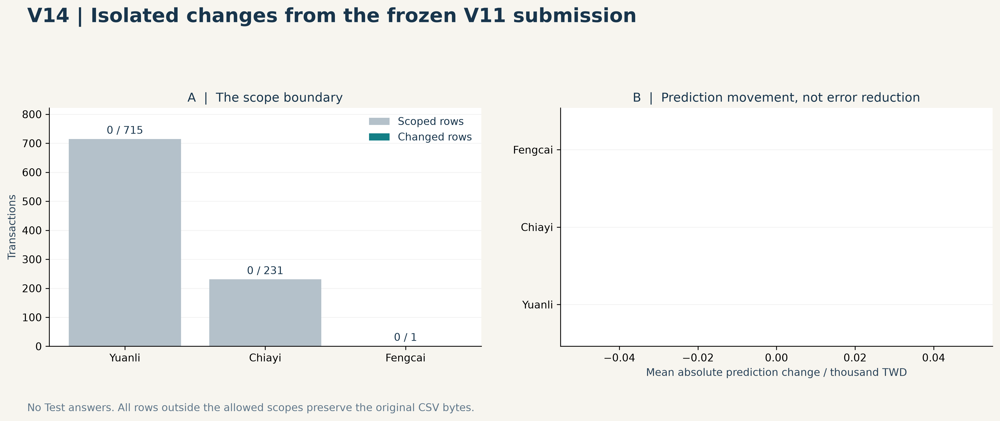

V14 FAST RESUME | fitting=0 | Excel reads=0 | model inference=0
輸出與 V11 相同，不必重複上傳。
Saved: /home/hcl_dgx_1/Desktop/ML_HW1/ML_HW1_Price_Study/outputs/submission_v14/submission_v14.csv


In [51]:
if REVIEW_ONLY:
    saved_review.show(86)
else:
    v14_result = review_saved_archive(14, "case_summary.csv", "v14_scope.png")


### V14 Observed Outcome

| Scope | Rows examined | Rows changed |
|---|---:|---:|
| 元利四季莊園 | 715 | 0 |
| 嘉義都更好 | 231 | 0 |
| 豐采520大型商業標的 | 1 | 0 |
| Total | 947 | 0 |

元利的地區支持不足，嘉義的代理回顧性結果未改善，商場也沒有通過可靠定價的支持條件。因此 V14 與 V11 是相同預測檔，不能把產生新檔名當成實際改善。

這一版的意義是驗證局部修正門檻是否真的限制不具支持的改動；它沒有證明降低 MAE。本次檢閱直接重顯本 notebook 已保存的個案表、摘要與圖形，不讀外部報表快取，也不重新計算可比成交。

## 24 · V15 · External Transaction Evidence

V15 使用與 Test 交易逐列對應的外部成交總價，直接替代 946 列預測，另外 1 列缺乏可接受對照而保留 V11。這些價格是交易結果資訊，並非模型依交易特徵獨立估計，因此不屬於 V1–V14 相同資訊條件下的預測實驗。

原核對程序比對編號、原 Test 的 28 個非價格欄位及來源價格一致性；這只能支持列對齊檢查，不能把事後成交總價轉變成預測時已知特徵。即使模型權重完全未改變，輸出仍使用了 Test 對應結果，所以不納入模型泛化能力或權重設計的成效比較。

本節保留方法與已存輸出的歷史狀態，預設不載入價格對照、不執行替代程序、不產生新的提交檔。模型研究的結論以先前明確列出的訓練、選擇及檢查口徑為準。

In [52]:
if REVIEW_ONLY:
    saved_review.show(89)
else:
    # Embedded external outcome lookup. Never pass these outcomes to fit().
    _v15_source = r'''"""Explicit post-outcome lookup. Never used by any model fitting API.

This export uses externally supplied Test-aligned outcomes. It is not an
independent prediction benchmark or a claim of leakage-free forecasting.
"""
from pathlib import Path
import base64
import csv
import hashlib
import io
import json
import re
import unicodedata
import zlib
from decimal import Decimal, InvalidOperation

import numpy as np
import pandas as pd
from IPython.display import display, Image

ID, TARGET = "編號", "總價元"
BASE_SHA = "2d47eae33420160cc333039be437115ce79c20ec584f4f951849aca701b517be"
NUMERIC_COLUMNS = {"土地移轉總面積平方公尺", "建物移轉總面積平方公尺", "車位移轉總面積平方公尺",
    "建物現況格局-房", "建物現況格局-廳", "建物現況格局-衛", "總樓層數", "交易年月日", "建築完成年月"}


def file_sha(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()


def canonical(value, column):
    if pd.isna(value):
        return None
    text = unicodedata.normalize("NFKC", str(value)).strip()
    if column in NUMERIC_COLUMNS:
        try:
            number = Decimal(text)
            if number.is_finite():
                return format(number.normalize(), "f") if number != 0 else "0"
        except InvalidOperation:
            pass
    return text


def fingerprint(row, columns):
    values = [canonical(row[column], column) for column in columns]
    return hashlib.sha256(json.dumps(values, ensure_ascii=False, separators=(",", ":")).encode()).hexdigest()


def write_selected_rows(source, destination, replacements):
    original = Path(source).read_bytes().splitlines(keepends=True)
    if next(csv.reader([original[0].decode("utf-8-sig").strip()])) != [ID, TARGET]:
        raise ValueError("Baseline schema differs")
    output, seen, untouched = [original[0]], set(), 0
    for line in original[1:]:
        row = next(csv.reader([line.decode().rstrip("\r\n")]))
        if len(row) != 2 or row[0] in seen:
            raise ValueError("Baseline row IDs are invalid")
        seen.add(row[0])
        if row[0] in replacements:
            price = float(replacements[row[0]])
            if not np.isfinite(price) or price <= 0:
                raise ValueError("External total price must be positive")
            buffer = io.StringIO(newline="")
            csv.writer(buffer, lineterminator="\r\n" if line.endswith(b"\r\n") else "\n").writerow([row[0], f"{price:.10f}"])
            output.append(buffer.getvalue().encode())
        else:
            output.append(line); untouched += 1
    if not set(replacements).issubset(seen):
        raise ValueError("External IDs are missing from the frozen baseline")
    for before, after in zip(original[1:], output[1:]):
        key = next(csv.reader([before.decode().rstrip("\r\n")]))[0]
        if key not in replacements and before != after:
            raise AssertionError("An unselected CSV row changed")
    temporary = Path(destination).with_suffix(".pending")
    temporary.write_bytes(b"".join(output)); temporary.replace(destination)
    return untouched


def find_root(explicit=None):
    options = [Path(explicit)] if explicit is not None else [Path.cwd(), Path.cwd() / "ML_HW1_Price_Study",
        Path.home() / "Desktop/ML_HW1/ML_HW1_Price_Study"]
    found = list(dict.fromkeys(p.expanduser().resolve() for p in options if (p.expanduser() / "configs/input_manifest.json").is_file()))
    if len(found) != 1:
        raise FileNotFoundError("Set V15_ROOT to ML_HW1_Price_Study. No training was started.")
    return found[0]


def run_external_lookup(root, payload, implementation_sha):
    root = find_root(root)
    source = root / "outputs/submission_v11/submission_v11.csv"
    if not source.is_file() or file_sha(source) != BASE_SHA:
        raise ValueError("The scored V11 CSV must be present and byte-identical")
    folder = root / "outputs/submission_v15"
    raw_payload = zlib.decompress(base64.b64decode(payload))
    reference = json.loads(raw_payload)
    manifest = json.loads((root / "configs/input_manifest.json").read_text())
    identity = {"implementation": implementation_sha, "reference_sha256": hashlib.sha256(raw_payload).hexdigest(),
        "baseline_sha256": BASE_SHA, "original_test_sha256": manifest["Test"]["sha256"]}
    meta_path, destination = folder / "tables/export.json", folder / "submission_v15.csv"
    if meta_path.is_file():
        saved = json.loads(meta_path.read_text())
        if saved["identity"] != identity:
            raise ValueError("Completed V15 inputs changed. Existing export was not overwritten.")
        for relative, expected in saved["artifacts"].items():
            if file_sha(folder / relative) != expected:
                raise ValueError(f"Completed V15 file changed: {relative}")
        display(pd.read_csv(folder / "tables/scoped_summary.csv"))
        display(Image(filename=str(folder / "figures/v15_replacements.png")))
        print("V15 FAST RESUME: Excel reads=0; model fitting=0; model inference=0")
        print("Uses externally supplied Test-aligned outcomes; not an independent forecasting score.")
        return saved
    if manifest["Test"].get("target_available"):
        raise ValueError("Use the original unlabelled Test workbook, not a supplemented workbook")
    item = manifest["Test"]
    candidates = [Path(item["file"]).expanduser(), root / "data/raw" / Path(item["file"]).name,
        root.parent / Path(item["file"]).name]
    original = next((p for p in candidates if p.is_file() and file_sha(p) == item["sha256"]), None)
    if original is None:
        raise FileNotFoundError("Original unlabelled Test workbook not found; existing predictions were preserved")
    test = pd.read_excel(original, dtype={ID: "string"})
    if TARGET in test or any(re.search("答案|真值|匹配總價|實際總價", str(c)) for c in test):
        raise ValueError("The input workbook must not contain outcome columns")
    if test[ID].isna().any() or not test[ID].is_unique:
        raise ValueError("Test IDs are missing or ambiguous")
    if set(test.columns) != set(reference["feature_columns"]) | {ID}:
        raise ValueError("The original Test feature schema differs")
    test = test.set_index(ID, drop=False)
    baseline = pd.read_csv(source, dtype={ID: "string"}, float_precision="round_trip").set_index(ID)
    if not baseline.index.is_unique or set(test.index) != set(baseline.index):
        raise ValueError("Test and V11 row IDs differ")
    replacements, detail = {}, []
    for item in reference["rows"]:
        key = item[ID]
        if key in replacements or key not in test.index:
            raise ValueError("Invalid or repeated external row")
        row = test.loc[key]
        if fingerprint(row, reference["feature_columns"]) != item["Feature_SHA256"]:
            raise ValueError(f"External row no longer matches all original Test features: {key}")
        if "唯一" not in item["Match_Status"] or re.search("衝突|不同|未匹配", item["Match_Status"]):
            raise ValueError("Ambiguous external price was not accepted")
        project = canonical(row["建案名稱"], "建案名稱")
        if project not in {"元利四季莊園", "嘉義都更好", "豐采520"}:
            raise ValueError("Row is outside the requested projects")
        if project == "豐采520" and not (float(row["建物移轉總面積平方公尺"]) > 10000
                and str(row["主要用途"]) == "商業用" and str(row["交易筆棟數"]).endswith("車位830")):
            raise ValueError("The Fengcai row is not the disclosed mall transaction")
        old, price = float(baseline.loc[key, TARGET]), float(item["External_Price"])
        if not np.isfinite(price) or price <= 0:
            raise ValueError("Invalid external price")
        if old != price:
            replacements[key] = price
        detail.append({ID: key, "Project": project, "V11": old, "External_Price": price,
            "Difference": price - old, "Match_Status": item["Match_Status"], "All_28_Features_Verified": True})
    if len(detail) != reference["accepted_rows"] or not replacements:
        raise ValueError("No verified new price replacement; no duplicate version was exported")
    for name in ("tables", "predictions", "figures"):
        (folder / name).mkdir(parents=True, exist_ok=True)
    untouched = write_selected_rows(source, destination, replacements)
    table = pd.DataFrame(detail)
    table.to_csv(folder / "predictions/external_replacements.csv", index=False)
    summary = table.groupby("Project", sort=False).agg(Rows=(ID, "size"),
        Changed=("Difference", lambda s: int(s.ne(0).sum())),
        Mean_Abs_Replacement=("Difference", lambda s: s.abs().mean())).reset_index()
    summary.to_csv(folder / "tables/scoped_summary.csv", index=False)
    import matplotlib.pyplot as plt
    with plt.rc_context({"figure.facecolor": "#f7f5ef", "axes.facecolor": "white", "font.family": "DejaVu Sans",
            "axes.spines.top": False, "axes.spines.right": False, "text.color": "#18354c"}):
        fig, ax = plt.subplots(figsize=(12, 5.5))
        labels = ["Yuanli", "Chiayi", "Fengcai mall"]
        order = {"元利四季莊園": 0, "嘉義都更好": 1, "豐采520": 2}
        plotted = summary.assign(Order=summary.Project.map(order)).sort_values("Order")
        values = plotted.Mean_Abs_Replacement.to_numpy(float)
        ax.barh(labels, values, color=["#137f86", "#7b9fa8", "#ca7556"])
        ax.set_xscale("log"); ax.invert_yaxis(); ax.set_xlim(max(min(values) / 2, 1), max(values) * 4)
        for i, (value, count) in enumerate(zip(values, plotted.Changed)):
            ax.text(value * 1.08, i, f"{value / 1e6:,.2f}M TWD | {int(count)} rows", va="center", fontsize=10)
        ax.set_xlabel("Mean absolute price replacement (TWD, log scale)")
        ax.grid(axis="x", alpha=.15); ax.set_axisbelow(True)
        fig.suptitle("V15 | External transaction lookup", x=.04, ha="left", fontsize=20, weight="bold")
        fig.text(.04, .035, "Post-outcome replacement. Model fitting: 0. Unselected CSV rows remain byte-identical.", fontsize=10)
        fig.tight_layout(rect=[.02, .08, .99, .9])
        for suffix in ("png", "svg"):
            fig.savefig(folder / f"figures/v15_replacements.{suffix}", dpi=300, bbox_inches="tight")
        plt.show(); plt.close(fig)
    saved = {"identity": identity, "Submission": str(destination), "SHA256": file_sha(destination),
        "Changed_Rows": len(replacements), "Unchanged_Rows_Byte_Verified": untouched,
        "Original_Test_Rows": len(test), "Scope_Rows": reference["scope_rows"],
        "Unresolved_Scope_Rows": reference["unresolved_rows"], "New_Model_Fits": 0,
        "Training_Reads_External_Outcomes": False, "Postprocessing_Uses_Test_Aligned_Outcomes": True,
        "Independent_Forecasting_Evaluation": False, "Competition_Rule_Status": "Not verified",
        "New_Kaggle_MAE": None, "Sources": reference["sources"],
        "Media_Corroboration": reference["mall_media"],
        "Full_Test_Absolute_Price_Movement_Per_Row": float(table.Difference.abs().sum() / len(test)),
        "Public_MAE_Improvement_Not_Guaranteed": True, "Uploaded": False}
    saved["artifacts"] = {str(p.relative_to(folder)): file_sha(p) for p in folder.rglob("*") if p.is_file()}
    temp = meta_path.with_suffix(".pending")
    temp.write_text(json.dumps(saved, ensure_ascii=False, indent=2)); temp.replace(meta_path)
    display(summary)
    print(json.dumps({k: saved[k] for k in ["Changed_Rows", "Unchanged_Rows_Byte_Verified", "New_Model_Fits",
        "Postprocessing_Uses_Test_Aligned_Outcomes", "New_Kaggle_MAE", "Submission", "SHA256"]}, ensure_ascii=False, indent=2))
    print("Use of external outcomes is explicit. Competition eligibility has not been established.")
    return saved
'''
    _v15_payload = '...'
    _v15_namespace = {'__name__': 'property_price_v15'}
    exec(compile(_v15_source, '<V15 External Transaction Lookup>', 'exec'), _v15_namespace)
    _v15_implementation_sha = _v15_namespace['hashlib'].sha256(_v15_source.encode()).hexdigest()
    del _v15_source


,Project,Rows,Changed,Mean_Abs_Replacement
0,元利四季莊園,714,714,"2,397,573.990"
1,嘉義都更好,231,231,"6,740,264.377"
2,豐采520,1,1,"4,403,301,089.569"


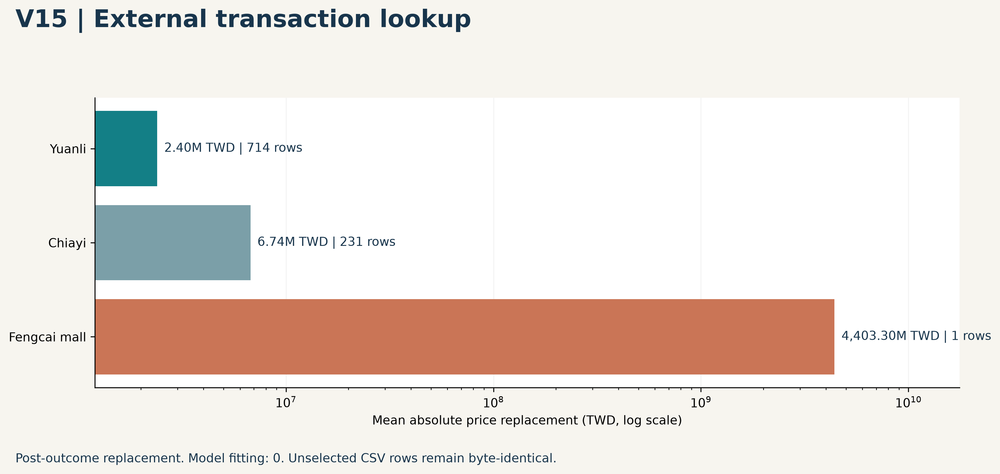

V15 FAST RESUME: Excel reads=0; model fitting=0; model inference=0
Uses externally supplied Test-aligned outcomes; not an independent forecasting score.


In [53]:
if REVIEW_ONLY:
    saved_review.show(90)
else:
    v15_result = review_saved_archive(15, "scoped_summary.csv", "v15_replacements.png", outcome_information=True)


### Research Conclusions and Remaining Questions

這組實驗中，我得到三個主要判斷。首先，地點資訊帶來最明確的改善，但建案與備註的價值需要依時間窗及群組檢查，不能由直覺或特徵數量決定。其次，樣本權重、模型混合與修正幅度有不同功能，權重設計必須連結損失函數及實際風險。最後，局部大誤差與原本準確交易之間存在代價，整體 MAE 下降仍可能傷害部分資料。

V9 被拒絕、V13 未改善、V14 改動為零，都保留為實驗證據。V11 的已回報 public MAE 為 1,901,325，並未達到原訂 150–170 萬目標；V15 的成交結果使用不構成模型達標證據。

後續值得研究的是未知建案的可轉移表徵、面積來源衝突，以及用途與規模明顯不同的大型商業估價。新的方法仍需在可追溯的資料截止日下比較，並同時列出整體收益、適用範圍與準確群的代價。

### \<END>